# Чекпойнт №2. Разведочный анализ данных

Цель - извлечение информации и краткое содержание. Изучить качество и простые характеристики текстов на примере задачи «вопрос - ответ».
Исследуется реальная случайная выборка SberQuAD

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import (
    LinearRegression, Ridge, RidgeCV, LassoCV, ElasticNetCV
)
from sklearn.model_selection import (
    train_test_split, KFold, cross_val_score, GridSearchCV
)
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,
    mean_absolute_percentage_error, r2_score
)
import joblib

RANDOM_STATE = 42
pd.set_option('display.max_colwidth', 75)
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 25)
sns.set_theme(style='whitegrid', palette='deep', font='DejaVu Sans')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

In [22]:
# Реальная выборка SberQuAD. Ячейка свёрнута только из-за объёма данных.
raw_rows = [
[6495, 'SberChallenge', 'Славянское влияние в раннесредневековой Дакии было настолько сильным, что славянская утвердительная частица да перешла в этом же значении в проторумынский и вызвала смещение исконных лексических единиц. Латинская частица sic — так , так же, как и на западе, развила в балканской латыни значение да в форме și /ши/. Однако после заимствования собственно славянского корня и под влиянием синонимичного славянского значения частицы да , употребляемой в значении и , слово și приняло на себя значение и . Чтобы избежать омонимии с si (как в испанском, французском и итальянском языках) латинское si — если превратилось в Дакии в să /сэ/ — чтобы и стало неотъемлемой частью структуры формирования конъюктива.', 'Какая Славянска частица перешла перешла в проторумынский язык?', 'частица да ', 100, 1],
[7509, 'SberChallenge', 'По договору между Францией и Испанией (1801) сын Фердинанда, Людовик, был сделан королём Этрурии, с обязательством уступить Франции Парму, Пьяченцу и Гвасталлу. В 1806 году Наполеон отдал Гвасталлу своей сестре Паулине Боргезе. По парижскому миру 1814 года и венскому договору 1815 года, Парма, Пиаченца и Гвасталла отданы Марии-Луизе, жене Наполеона, но, ввиду протестов Испании, в 1817 году особым договором, заключенным в Париже, было постановлено, что после смерти Марии-Луизы герцогства переходят к наследникам Людовика, бывшего короля Этрурии, за исключением территории по левому берегу По, остававшейся за Австрией.', 'К кому должны были перейти герцогства после смерти Марии-Луизы, согласно договора от 1817 года?', 'к наследникам Людовика', 502, 1],
[33905, 'SberChallenge', 'У взрослых овец имеются 32 зуба (зубная формула I:0/3 C:0/1 P:3/3 M:3/3): 6 парных коренных (сверху и снизу), 6 парных премоляров (также сверху и снизу), 2 клыка (снизу), и 8 резцов (также только снизу).[9] В промежутке между клыками и премолярями имеется большой зазор. Резцы расположены под тупым углом к челюсти — такое строение позволяет животным более эффективно скусывать траву по сравнению с другими травоядными животными.[2] Коренные и премоляры вместе образуют широкую поверхность в задней части пасти — этими зубами животные пережёвывают траву. Развитие зубов происходит постепенно: первоначальные молочные через год — полтора начинают заменяться на постоянные, а весь процесс смены заканчивается только на четвёртом году жизни.', 'Сколько по времени длится процесс смены молочных зубов на постоянные у овцы?', 'процесс смены заканчивается только на четвёртом году жизни', 679, 1],
[30868, 'SberChallenge', 'Концепция прогресса подвергается критике уже в XIX веке. От идеи прогресса отказались представители историзма Леопольд фон Ранке и Фридрих Мейнеке. В начале XX века Эрнст Трёльч писал, что прогресс — это секуляризованная христианская эсхатология, идея универсальной, достигаемой всем человечеством конечной цели, которая перемещена из сферы чудес и трансцендентности в сферу естественного объяснения и имманентности [5]. После Второй мировой войны, некоторые влиятельные мыслители, например, Теодор Адорно, выражают сомнения в реальности социального прогресса. И. Р. Шафаревич критикует понятие прогресса как термина, присущего исключительно западной цивилизации.', 'Кто критиковал понятие прогресса как термина, присущего исключительно западной цивилизации?', 'И. Р. Шафаревич', 561, 1],
[45693, 'SberChallenge', 'Коллектив, создавший UNIX, развил концепцию унификации объектов операционной системы, включив в исходную концепцию UNIX устройство — это тоже файл также и процессы, и любые другие системные, сетевые и прикладные сервисы, создав новую концепцию: что угодно — это файл . Эта концепция стала одним из основных принципов системы Plan 9 (название было позаимствовано из фантастического триллера План 9 из открытого космоса Эдварда Вуда-младшего), призванной преодолеть принципиальные недостатки дизайна UNIX и сменившей рабочую лошадку UNIX System V на компьютерах сети Bell Labs в 1992 году.', ' рабочую лошадку UNIX System V на компьютерах какой сети в 1992 году сменила система Plan 9?', 'Bell Labs', 565, 1],
[43687, 'SberChallenge', 'Нация может быть двух видов: полиэтничной (многонациональной) или моноэтничной[7]. Этнически однородные нации крайне редки и встречаются в основном в отдалённых углах мира (например Исландии). Обычно нация строится на базе большого количества этносов, которых свела вместе историческая судьба. Полиэтничны, например, швейцарская, французская, великобританская, российская[8], вьетнамская нации, а американцы вообще не имеют никакого ярко выраженного этнического лица. Латиноамериканские нации расово неоднородны — созданы из белых, африканцев, креолов и индейцев-америндов.', 'Какие нации расово неоднородны, и созданы из белых, африканцев, креолов и индейцев-америндов?', 'Латиноамериканские', 468, 1],
[51553, 'SberChallenge', 'По убеждению богословов, в том числе доктора исторических наук, кандидата богословия, доктора церковной истории священника Георгия Ореханова, решение Синода относительно Толстого — это не проклятие писателя, а констатация того факта, что он по собственному желанию больше не является членом Церкви. Кроме того, в синодальном акте 20—22 февраля говорилось, что Толстой может вернуться в Церковь, если он принесёт покаяние. Митрополит Антоний (Вадковский), который был в то время первенствующим членом Святейшего Синода, писал Софье Андреевне Толстой: Вся Россия скорбит о Вашем муже, мы о нём скорбим. Не верьте тем, кто говорит, что мы добиваемся его покаяния с политическими целями . Тем не менее, писатель, его окружение и русская общественность посчитали, что это определение — неоправданно жестокий акт. Например, когда Толстой приехал в Оптину пустынь, на вопрос о том, почему он не пошел к старцам, он ответил, что не мог пойти, так как отлучён.', 'В каком акте говорилось, что Толстой может вернуться в Церковь, если он принесёт покаяние?', 'В синодальном акте 20—22 февраля.', 297, 1],
[11683, 'SberChallenge', 'Альтернативная история давно вышла за пределы литературы. В кинематографе и на телевидении известны, например, художественные фильмы Красный рассвет , Филадельфийский эксперимент II , Родина ( Фатерлянд ), телесериал Скользящие , постановочно-документальный сериал Альтернативная история (с эпизодами России/СССР разных эпох), псевдо-документальные фильмы Первые на Луне и Аполлон 18 (оба — криптоистория о полёте советских космонавтов на Луну), КША: Конфедеративные Штаты Америки , мультсериал Zipang и другие фильмы и телесериалы о альтернативной истории. Компьютерные игры Red Alert (войны с нацизмом не было, и холодная война переросла в горячую), TimeShift, Resistance: Fall of Man (войны с нацизмом не было и на землю напали инопланетяне), World in Conflict (из-за мирового кризиса СССР пришлось напасть на США), Fallout (мир где Китай стал сверхдержавой и начал войну за ресурсы с США, впоследствии война закончилась взаимным обменом ядерными ударами) и другие основаны на альтернативной истории Холодной войны, по сюжету переросшей в настоящую войну между Россией и США.', 'Какие художественные фильмы рассказывают об альтернативной истории?', 'Художественные фильмы Красный рассвет , Филадельфийский эксперимент II , Родина ( Фатерлянд ), телесериал Скользящие .', 56, 1],
[8914, 'SberChallenge', 'В целом отчет отражает текущее состояние сферы промышленного производства, рынка труда, недвижимости, финансовой отрасли, банковского сектора, сельского хозяйства и сферы услуг в регионах США. Отчёт составляется на основе неофициальных комментариев, собранных каждым из федеральных резервных банков в своём округе. Слушаются доклады директоров банков и их отделений, в том числе, доклады главных экономистов, экспертов рынка, предпринимателей. Бежевую книгу считают важным инструментом для проверки общей стабильности экономики.', 'Какова основа отчета различных сфер в регионах США?', 'на основе неофициальных комментариев', 212, 1],
[81665, 'SberChallenge', 'Французский химик и микробиолог Луи Пастер обнаружил, что дрожжи, вызывающие брожение пива, представляют собой живые организмы. Это открытие позволило с большей точностью осуществлять контроль над превращением сахара в спирт. Датский ботаник Эмиль Христиан Хансен внёс очень важный вклад в развитие пивоварения. Всю свою жизнь он исследовал и классифицировал виды дрожжей. Помимо прочего, он работал над выведением чистого штамма дрожжей для пивоварения. Его разработки буквально произвели революцию в пивоваренной промышленности.', 'Кто внёс очень важный вклад в развитие пивоварения?', 'Датский ботаник Эмиль Христиан Хансен', 226, 1],
[46636, 'SberChallenge', 'В соответствии со стратегией социально-экономического развития Дальнего Востока и Байкальского региона на период до 2025 года, утверждённой Правительством РФ, предусматривается строительство автомобильного моста через Амур в районе Благовещенска[21]. Проект строительства моста был впервые предложен в 1995 году. Долгое время проект не реализовывали. В частности, министр экономического развития и торговли Герман Греф в 2005 году: Я еще не понимаю, в чём вся прелесть или преимущество этого проекта [22]. Однако, 24 декабря 2016 года на российской стороне дан старт строительству моста через Амур в Хэйхэ[23].', 'В каком году был предложен проект?', 'в 1995 году', 300, 1],
[37707, 'SberChallenge', 'Согласно конституции Боснии и Герцеговины 1995 года государство состоит из двух образований (энтитетов): Федерации Боснии и Герцеговины и Республики Сербской. К ведению Боснии и Герцеговины относится внешняя, внешнеторговая, таможенная и монетарная политика; финансовое обеспечение центральных органов власти и международных обязательств государства; политика, связанная с иммиграцией, беженцами и предоставлением убежища; исполнение положений уголовного права между образованиями и международных положений уголовного права, включая отношения с Интерполом; установление и функционирование муниципальных и международных средств связи; регулирование транспорта между образованиями; управление воздушным движением. В 1999 году арбитражной комиссией по Посавинскому коридору, в нарушение Дейтонских соглашений, была провозглашена самостоятельность округа Брчко, находящегося под международным надзором.', 'Из скольких образований состоит государство Босния и Герцеговина?', 'из двух', 72, 1],
[28018, 'SberChallenge', 'Водород — самый распространённый элемент во Вселенной. На его долю приходится около 88,6 % всех атомов (около 11,3 % составляют атомы гелия, доля всех остальных вместе взятых элементов — порядка 0,1 %). Таким образом, водород — основная составная часть звёзд и межзвёздного газа. В условиях звёздных температур (например, температура поверхности Солнца ~ 6000 °C) водород существует в виде плазмы, в межзвёздном пространстве этот элемент существует в виде отдельных молекул, атомов и ионов и может образовывать молекулярные облака, значительно различающиеся по размерам, плотности и температуре.', 'В виде чего существует водород в условиях звёздных температур?', 'В виде плазмы', 280, 1],
[63472, 'SberChallenge', 'Письменная история Шотландии начинается с римского завоевания Британии, когда были завоеваны, получили статус римских провинций и стали именоваться Британией территории современной Англии и Уэльса. Часть южной Шотландии была на недолгое время взята под непрямой контроль Рима. К северу лежали земли, свободные от римского завоевания, — Каледония, населённая пиктскими и гэльскими племенами. Согласно римскому историку Тациту, каледонцы начали полномасштабное вооружённое сопротивление , нападая на римские легионы. Во время одного из ночных рейдов был разгромлен IX Испанский легион, спасённый от полного уничтожения кавалерийской атакой Гнея Юлия Агриколы.', 'Какими племенами была населена Каледония, свободная от римского завоевания?', 'Пиктскими и гэльскими племенами.', 274, 1],
[70643, 'SberChallenge', 'Федеральный парламент — двухпалатный. Нижняя палата парламента — палата представителей (нидерл. Kamer van volksvertegenwoordigers, фр. Chambre des Représentants), верхняя палата — сенат (нидерл. Senaat, фр. Sénat). Обе палаты избираются прямым голосованием раз в четыре года. Право голоса имеют все граждане государства, достигшие 18-летнего возраста. В сенате заседают 71 депутат (из которых 40 избираются прямым всеобщим голосованием, а 31 — региональными парламентами). В палате представителей — 150 депутатов, избираемых прямым голосованием.', 'Каким голосованием избирается парламент Бельгии?', 'Обе палаты избираются прямым голосованием раз в четыре года.', 215, 1],
[23992, 'SberChallenge', 'Если управляющий Федеральной резервной системой США стал специалистом по кризисам и мягкой посадке, то в отношении его канадского коллеги довольно часто начиная с конца 1990-х и начала 2000-х высказывались упрёки в том, что он малочувствителен к реальному развитию экономики и запутался в расчётных моделях. Критики утверждают, что экономическая политика Банка Канады неудовлетворительна, и отмечают, что будущими управляющими являются высшие руководители Банка Канады, если вообще не сам первый заместитель управляющего. К тому же, он не имеет децентрализованной структуры, способной выяснить возможности экономики регионов. Его денежно-кредитная политика проистекает из точки зрения лишь одного человека, назначаемого каждые семь лет и непрерывно сохраняющего место из срока в срок, так как смена в этом ограниченном мире ему обеспечена, и это препятствует любым переменам в экономической политике банка.', 'Как часто назначается управляющий Банка Канады?', 'каждые семь лет', 720, 1],
[38224, 'SberChallenge', 'Часто обозначение территории добавляется к основному пэрскому титулу, особенно в случае баронов и виконтов: например, баронесса Тэтчер, of Kesteven, графства Линкольн или виконт Монтгомери of Аламейн, of Hindhead, графства Сюррей. В таких случаях обозначение после первой запятой не является частью основного титула и часто опускается, и остаётся, в приведённых случаях, баронесса Тэтчер и виконт Montgomery of Alamein. Территориальные обозначения в титулах не обновляются при реформах местного правительства, но новосоздаваемые принимают их во внимание. Поэтому есть баронесса Airey, of Abingdon в County of Oxford, и барон Johnston of Rockport, of Caversham в Royal County of Berkshire.', 'Что происходит с территориальными обозначениями после реформ?', 'не обновляются', 458, 1],
[29397, 'SberChallenge', 'Примерно в этот период появился термин хеви-метал , которым поначалу обозначали просто самые громкие хард-рок-группы. До появления новой волны британского метала эти термины использовались критиками как взаимозаменяемые. Многие группы, относимые в то время к хеви-металу, например, Led Zeppelin, позднее стали считаться преимущественно хард-рок-группами. Иногда сами музыканты некоторых хард-рок-групп, например, участники Deep Purple и AC/DC, не любят, когда их называют металлистами или хеви-металом . Критики пользуются термином хард-н-хеви (хард-рок энд хеви-метал) для обозначения таких пограничных групп.', 'До появления чего эти термины использовались критиками как взаимозаменяемые по отношению к британскому металу?', 'новой волны', 131, 1],
[28242, 'SberChallenge', 'Перепад высоты гор существенно влияет на движение ветра. Так, если в горном хребте, который преодолевает ветер, есть перевал, ветер проходит его с увеличением скорости в результате эффекта Бернулли. Даже небольшие перепады высоты вызывают колебания в скорости ветра. В результате значительного градиента скорости движения воздух становится турбулентным и остается таковым на определенном расстоянии даже на равнине за горой. Подобные эффекты важны, например, для самолётов, взлетающих или садящихся на горных аэродромах[28]. Быстрые холодные ветры, дующие сквозь горные проходы, получили разнообразные местные названия. В Центральной Америке это папагайо вблизи озера Никарагуа, панамский ветер на Панамском перешейке и теуано на перешейке Теуантепек. Подобные ветры в Европе известны как бора, трамонтана и мистраль.', 'Для чего важен эффект турбулентности?', 'для самолётов, взлетающих или садящихся на горных аэродромах', 459, 1],
[60319, 'SberChallenge', 'Арабский историк Абу Аль Фарадж отзывается об армянских поселенцах X века в Сивасе следующим образом: Сивас, в Каппадокии, доминировал армянами, чьё число увеличилось настолько, что они стали жизненно важными членами имперской армии. Армяне использовались в сильно укреплённых крепостях, отвоёванных у арабов в качестве часовых. Они отличались как опытные солдаты пехоты в имперской армии и постоянно боролись с выдающейся храбростью и успехом у Римлян, другими словами Византийцев . В результате дальнейших военных кампаний Византии, расселение армян продолжилось как в Каппадокии, так и в восточном направлении — в Киликию и в гористые области северной Сирии и Месопотамии — вплоть до эпохи образования государств крестоносцев.', 'О ком отзывался Абу Аль Фарадж следующим образом: Сивас, в Каппадокии, доминировал армянами, чьё число увеличилось настолько, что они стали жизненно важными членами имперской армии. Армяне использовались в сильно укреплённых крепостях, отвоёванных у арабов в качестве часовых. Они отличались как опытные солдаты пехоты в имперской армии и постоянно боролись с выдающейся храбростью и успехом у Римлян, другими словами Византийцев ?', 'об армянских поселенцах X века в Сивасе', 43, 1],
[65826, 'SberChallenge', 'Млекопитающие демонстрируют удивительное разнообразие приспособлений к обитанию в различных жизненных средах и к различным формам поведения. Ни один класс позвоночных не дал в процессе своей эволюции такого разнообразия форм, как млекопитающие, причём нередко виды, входящие в один и тот же отряд, относятся к различным адаптивным типам — основным экологическим группам; с другой стороны, представители разных отрядов, живущие в сходных условиях и близкие по своему образу жизни, могут иметь весьма сходный внешний вид (конвергентное сходство).', 'Кто демонстрируют млекопитающие?', 'Разнообразие приспособлений к обитанию в различных жизненных средах', -1, 1],
[71921, 'SberChallenge', 'Матричная (информационная) РНК — РНК, которая служит посредником при передаче информации, закодированной в ДНК к рибосомам, молекулярным машинам, синтезирующим белки живого организма. Кодирующая последовательность мРНК определяет последовательность аминокислот полипептидной цепи белка[29]. Однако подавляющее большинство РНК не кодируют белок. Эти некодирующие РНК могут транскрибироваться с отдельных генов (например, рибосомальные РНК) или быть производными интронов[30]. Классические, хорошо изученные типы некодирующих РНК — это транспортные РНК (тРНК) и рРНК, которые участвуют в процессе трансляции[31]. Существуют также классы РНК, ответственные за регуляцию генов, процессинг мРНК и другие роли. Кроме того, есть и молекулы некодирующих РНК, способные катализировать химические реакции, такие, как разрезание и лигирование молекул РНК[32]. По аналогии с белками, способными катализировать химические реакции — энзимами (ферментами), каталитические молекулы РНК называются рибозимами.', 'Как называется РНК, служащая посредником при передаче информации, закодированной в ДНК к рибосомам?', 'Матричная (информационная) РНК', 0, 1],
[71147, 'SberChallenge', 'Богатейший этнографический материал собрал римский историк Корнелий Тацит. Уже в своих ранних работах историк пытается систематизировать увиденное — откуда, например, произошли народы Британии, чем объясняется их историко-этнографическое многообразие. Но, особенно важен труд О происхождении германцев и местонахождение Германии , который С. А. Токарев называет: Это буквально этнографическая монография, притом, видимо, самая ранняя в мировой литературе . Также следует отметить труды А. Марцеллина.', 'В каких своих работах Корнелий Тацит пытается систематизировать происхождение народов Британии и их историко-этнографическое многообразие?', 'в своих ранних работах', 79, 1],
[65659, 'SberChallenge', 'Второй альбом Like a Virgin выходит в 1984 году. Критика принимает диск прохладно: Терпимо, не более того (журнал People). Лейбл по-прежнему не разрешает Мадонне продюсировать свой альбом, но ей дают много денег на востребованного в то время аранжировщика Найла Роджерса (до этого он продюсировал Дэвида Боуи). Мадонна не до конца уверена в необходимом коммерческом потенциале уже написанных ею песен, поэтому просит продюсера дать ей послушать чужой материал для вдохновения. В итоге, из сторонних более попсовых песен на альбоме оказываются 3 трека, которые она не смогла выбросить из головы (все они выходят синглами), а также одна кавер-версия. Альбом впервые в карьере певицы возглавляет альбомный чарт США[103]. Сингл Like a Virgin (авторства Тома Келли и Билли Стейнберга) 6 недель остаётся на первом месте хит-парада Billboard Hot 100[104][105].', 'Сколько недель синг Мадонны Like a Virgin , оставался на первом месте хит-парада Billboard Hot ?', '6 недель', 780, 1],
[39659, 'SberChallenge', 'В 1972 году участники Движения американских индейцев (ДАИ) и другие группы борцов за права индейцев устроили марш протеста на Вашингтон, который получил название Тропа нарушенных договоров . В 1973 году активисты ДАИ на 71 день захватили Вундед Ни, требуя возвращения земель, отобранных у индейцев в нарушение договоров с ними. В 1976 г. активист ДАИ Леонард Пелтиер был приговорен к двум пожизненным срокам заключения по обвинению в соучастии в убийстве двух сотрудников ФБР, хотя многие считают его невиновным.', 'В каком году участники Движения американских индейцев и другие группы борцов за права индейцев устроили марш протеста на Вашингтон?', 'В 1972 году', 0, 1],
[2218, 'SberChallenge', 'Исторически и экономически с Уралом тесно связаны Предуралье и Зауралье — территории, прилегающие к нему с запада и востока. Совокупность западных территорий также могут называть Приуральем (протяжённый Приуральский район относится к ЯНАО). На Урале, а также в Предуралье и Зауралье расположены Республика Башкортостан, Свердловская, Челябинская, Курганская, Оренбургская области, Удмуртия и Пермский край, составляющие Уральский экономический район, восточные части Республики Коми и Архангельской области (Ненецкий автономный округ), входящие в Северный экономический район, и западная часть Тюменской области, входящей в Западно-Сибирский экономический район. В Казахстане географически к Уралу можно отнести Актюбинскую и Костанайскую области. Иногда для обозначения административно-территориальных единиц Российской Федерации, так или иначе относящихся к Уралу, также применяется понятие Большой Урал. В административный Уральский федеральный округ РФ (УрФО) входят Курганская, Свердловская, Тюменская и Челябинская области, ХМАО и ЯНАО. Административный центр УрФО и Свердловской области город Екатеринбург принято называть столицей Урала и столицей Среднего Урала .', 'Какое понятие применяется для обозначения административно-территориальных единиц Российской Федерации, так или иначе относящихся к Уралу?', 'Большой Урал', 893, 1],
[4723, 'SberChallenge', 'Для топливных целей в настоящий момент используются в промышленных объёмах три спирта: метанол, этанол и бутанол-1, что связано, прежде всего, с их коммерческой доступностью и возможностью массового производства из растительного сырья (кроме метанола). При этом возможно использование спиртов в виде горючего в чистом виде, в виде различных смесей с бензином или дизельным топливом, а также в качестве оксигенирующих добавок (до 10 %) с целью повышения октанового числа и снижения токсичности отработанных газов. Отдельным направлением является использование метанола для переэтерификации жиров в производстве биодизеля.', 'В производстве чего используется метанол для переэтерификации жиров?', 'В производстве биодизеля', 510, 1],
[40662, 'SberChallenge', 'На основании постановления Правительства РФ № 781 от 21 декабря 2005 года в Дубне была создана особая экономическая зона технико-внедренческого типа. К развиваемым направлениям деятельности в ОЭЗ Дубна относятся ядерно-физические и нанотехнологии, информационные и медицинские технологии, а также некоторые другие. Для привлечения компаний в ОЭЗ предусмотрены такие меры, как упрощённый порядок приобретения земельных участков, налоговые льготы, предоставление квартир ведущим специалистам и проч. Планируется, что в особой экономической зоне будет функционировать порядка 350 компаний-резидентов, что обеспечит около 10 000 новых рабочих мест[19].', 'Какие направления деятельности в ОЭЗ Дубна относятся к развиваемым?', 'ядерно-физические и нанотехнологии, информационные и медицинские технологии', 212, 1],
[21999, 'SberChallenge', 'Постепенный рост общения между людьми, особенно там, где этому благоприятствовали природные условия — например, удобства естественных путей сообщения (реки, моря), — содействуя сближению между людьми, уничтожали постепенно коренную причину, тормозившую сознание единства человечества, причину, заключавшуюся в простом незнакомстве с психикой людей другого физического облика, другой культуры, других верований. Еще более крупную роль играло образование огромных империй, объединивших общей властью одного центра, одних законов, силой господствующей культуры и языка конгломераты прежде разрозненных народов. Так, Римская империя стала общим отечеством, una cunctarum gentium in toto orbe patria (единое всех народов на всем земном шаре отечество) — идея совершенно новая для древнего мира и в высшей степени чреватая последствиями, но вместе с тем сложившаяся чисто эмпирически, благодаря уничтожению политической самостоятельности прежних изолированных государственных единиц и тесному свободному общению (торговому и интеллектуальному) отдельных частей империи между собой. Только на этой почве и могли зародиться и так ярко выразиться идеи космополитизма, ведущие свое начало от циников и стоиков.', 'Что способствовало росту общения между людьми?', 'удобства естественных путей сообщения', 112, 1],
[4002, 'SberChallenge', 'Среди европейских видов, примером полиморфизма служит большая лесная перламутровка (Argynnis paphia), у которой самцы одинаковый окраски, но самки бывают двух форм. Наряду с обычными рыжими самками, встречается тёмная форма valesina, у которой общий фон крыльев является зеленовато-серым. Если отличия между различными формами самцов или самок ограничиваются цветом окраски, не задевая других признаков, то такие частные случаи полиморфизма сводятся к дихроизму (двухцветности) или полихроизму (многоцветности) особей каждого пола; так, например, у упомянутой выше большой лесной перламутровки имеет место дихроизм самок.', 'Какие встречаются самки наряду с обычными рыжими ?', 'встречается тёмная форма valesina', 199, 1],
[8390, 'SberChallenge', 'После включения в состав Австрийской империи и последовавших сразу после этого репрессий против протестантов венгерский язык испытывает сильное немецкое влияние, но постепенно восстанавливает господствующие позиции в качестве единственного официального языка Транслейтании (венгерской части Австро-Венгрии). Период между 1867 и 1918 годами по праву можно считать золотым веком венгерского языка, когда он исполняет функцию лингва франка на обширных пространствах Центральной Европы от Карпат до Адриатического моря. Заметно увеличивается доля владеющих венгерским как в качестве первого, так и второго языка (среди невенгерских народов показатель владения им вырос с 5,6 % в 1880 г. до 15,3 % в 1915). Многие города Трансильвании стали практически полностью венгроязычными (например, Клуж-Напока или, по-венгерски, Коложвар). На венгерский язык перешли многие румыны и даже немцы в Венгрии, в том числе трансильванские саксы, а также евреи и даже цыгане.', 'Какие города Трансильвании стали практически полностью венгроязычными?', 'Например, Клуж-Напока или, по-венгерски, Коложвар.', 698, 1],
[73039, 'SberChallenge', 'Иркутский академический драматический театр имени Н. П. Охлопкова. Первая труппа в Иркутске появилась в 1851 году, нынешнее здание театра построено в 1897 году по проекту петербургского архитектора В. Шрётера. Первой постановкой в новом здании стал спектакль Ревизор . При театре создан музей. В 1921 году на главной площади прошла постановка Борьба труда и капитала под руководством Н. Охлопкова, в честь которого позднее был назван театр. В иркутском театре работали кинорежиссёр Л. Гайдай, актёры Л. Броневой, М. Светин, Г. Стриженов.', 'По проекту какого петербургского архитектора построен Иркутский академический драматический театр имени Н. П. Охлопкова?', 'В. Шрётер.', -1, 1],
[38444, 'SberChallenge', 'Первым профессиональным дирижёром (не являвшимся композитором) можно считать Николая Рубинштейна, который с начала 60-х годов XIX века был постоянным дирижёром симфонических концертов в Москве, гастролировал в качестве дирижёра в Петербурге и других городах, был первым в России исполнителем многих сочинений как русских (прежде всего П. И. Чайковского), так и зарубежных композиторов. Но если Рубинштейн за рубежом был известен в первую очередь как выдающийся пианист, то Василий Сафонов стал первым русским музыкантом, получившим международное признание, уже в начале XX века, именно в качестве дирижёра.', 'Где гастролировал в качестве дирижёра Николай Рубинштейн?', 'в Петербурге', 228, 1],
[60713, 'SberChallenge', 'Все британские почести, включая пэрское достоинство, происходят от суверена, которого называют источник чести. Сам суверен не может принадлежать к Пэрству — источник достоинства не может получить достоинство от себя (мнение палаты лордов в Buckhurst Peerage Case). В соответствии с английской негласной традицией лицо, которое не является пэром и не является сувереном, формально считается простолюдином (но не в Шотландии, где дворянская правовая система кардинально отлична от английской и максимально близка к континентальной). В Англии члены семьи пэров также формально могут считаться простолюдинами, хотя с точки зрения закона они в действительности относятся к классу джентри (младшего дворянства, как и баронеты, рыцари, эсквайры и джентльмены); этим английская система существенно отличается от континентальной (и шотландской), где вся семья, а не индивидуумы сопричисляются к дворянству. Даже члены королевской семьи, не имеющие пэрского достоинства, не обладают особым правовым статусом, отличным от прочих членов общества.', 'К какому классу относятся члены семьи пэров с точки зрения закона?', 'джентри', 675, 1],
[82860, 'SberChallenge', 'В Формуле-1 огромное внимание уделяется безопасности пилотов. Ни один болид не сможет выйти на старт гонки, если он не пройдёт всех необходимых проверок, в частности краш-тестов. Особенно остро вопрос безопасности встал после трагической гибели в один и тот же уикенд 1994 года на трассе в Имоле Айртона Сенны и Роланда Ратценбергера, а также получившего тяжёлую травму рёбер на пятничной тренировке Рубенса Баррикелло. Внесённые в конструкцию болидов изменения привели к значительному увеличению безопасности гонщиков, особенно при лобовых и боковых столкновениях.', 'После какого события встал вопрос о безопасности болидов?', 'Трагической гибели', -1, 1],
[14851, 'SberChallenge', 'Работе железных дорог, возникающим при этом социальным и человеческим конфликтам посвящены фильмы Опять надо жить (1999, режиссёр Василий Панин), Остановился поезд (1982, режиссёр Вадим Абдрашитов), Магистраль (1983, режиссёр Виктор Трегубович), 34-й скорый (1981, режиссёр Андрей Малюков). В жанре фильма-катастрофы снят фильм Поезд вне расписания (1985, режиссёр Александр Гришин), Неуправляемый (2010). Местом действия служит железная дорога в фильмах Убийство в Восточном экспрессе , Золотой поезд , Мы, нижеподписавшиеся , Спортлото-82 , Транссибирский экспресс , Поезд идёт на восток , Вокзал для двоих , Ночной поезд (2009). Романтике железных дорог, героизму и отваге работников дороги посвящены фильмы Большие перегоны (1970), Русский паровоз (1988), Водил поезда машинист (1961). Истории железных дорог посвящаются документальные фильмы: История российских железных дорог (1993), Я люблю поезда . В 2007 году режиссёр Алексей Федорченко снял фильм Железная дорога .', 'Какие документальные фильмы посвящены истории железных дорог?', ' История российских железных дорог (1993), Я люблю поезда ', 847, 1],
[15705, 'SberChallenge', 'Ценова́я дискримина́ция (англ. Price Discrimination )— это ситуация на рынке, когда один и тот же товар или услуга продается различным покупателям по различным ценам. Проведение ценовой дискриминации возможно только на рынке несовершенной конкуренции в силу наличия у монополиста власти над ценой. Впервые понятие появилось в XIX веке благодаря Ж.Дюпюи и Д. Ларднеру, а наибольший вклад в развитие ценовой дискриминации внесли А. Пигу ( Экономическая теория благосостояния ) и Дж. Робинсон ( Экономическая теория несовершенной конкуренции ).', 'В силу чего на рынке несовершенной конкуренции возможно проведение ценовой дискриминации?', 'в силу наличия у монополиста власти над ценой', 251, 1],
[71196, 'SberChallenge', 'Цена кредита — денежное выражение оплаты предоставленного кредита. Зависит от уровня процентной ставки, установленной кредитором за его пользование. Цена кредита связана с принципом платности или возмездности кредитных отношений. Выделяют банковские кредиты с рыночной процентной ставкой, повышенной ставкой, льготной ставкой. Рыночная цена кредита складывается на рынке на данный момент исходя из спроса и предложения по различным видам кредита. В периоды инфляции она весьма подвижна и имеет тенденцию к повышению. Цена кредита повышенная, как правило, возникает в условиях значительных рисков кредитования заемщиков (нарушение условий кредитования, предусмотренных в договоре, ожидание повышения стоимости кредитных ресурсов и др.). Льготная цена кредита используется при дифференцированном подходе к заемщикам.', 'Что такое цена кредита?', 'денежное выражение оплаты предоставленного кредита', 344, 1],
[57176, 'SberChallenge', 'Риск и угроза. В сценарном анализе риск отличают от угрозы . Угроза — это неисследованное негативное событие, которое некоторые аналитики могут быть неспособными оценить при оценке риска, потому что это событие никогда не происходило, и для которого не доступна никакая информация о эффективных профилактических мерах (шаги, предпринимаемые, чтобы уменьшить вероятность или воздействие возможного будущего события). Это различие наиболее ясно иллюстрируется предупредительным принципом, который стремится уменьшить угрозу, требуя от неё быть сведённой к набору хорошо-определённых рисков, чтобы только затем перейти к действиям, проектам, новшествам или экспериментам. Примеры угрозы: природные катастрофы: землетрясение, наводнение, цунами, извержение вулкана, лесные пожары; антропогенные катастрофы: ядерная угроза, экологическая угроза. Пример риска природные катастрофы — цунами, по результатам анализа возможно произойдет с вероятностью не более 1 раз в 100 лет. Высота волны в зоне воздействия будет не более 10 баллов по шкале Рихтера, что приведет к разрушению забора предприятия по периметру на расстоянии 15 м и края левого крыла склада хранения стройматериалов. Общий ущерб, с учетом возможного загрязнения окружающей среды, составит не более 173 тыс. рублей. Потери среди персонала возможны, только при грубом нарушении правил действия в условиях чрезвычайной ситуации. Идентификация чрезвычайной ситуации произойдет минимум за 15 минут, а оповещение персонала за 12 мин. 30 сек. Вероятность потерь личного состава на одного сотрудника Н = 10-12.', 'Что такое негативное событие, которое специалисты неспособны оценить при оценке риска, потому что это событие никогда не происходило, и для которого не доступна никакая информация о эффективных профилактических мерах?', 'Угроза', 61, 1],
[26302, 'SberChallenge', 'В некоторых контекстах, таких как идентификация точки в полярных координатах или описание ориентации объекта в двух измерениях относительно его базовой ориентации, углы, отличающиеся на целое число полных оборотов, фактически являются эквивалентными. Например, в таких случаях можно считать эквивалентными углы 15° и 360015° (= 15° + 360°×1000). В других контекстах, таких как идентификация точки на спиральной кривой или описание совокупного вращения объекта в двух измерениях относительно его начальной ориентации, углы, отличающиеся на ненулевое целое число полных оборотов, не эквивалентны.', 'В каких ситуациях углы, отличающиеся на ненулевое целое число полных оборотов, не эквивалентны?', 'дентификация точки на спиральной кривой или описание совокупного вращения объекта в двух измерениях относительно его начальной ориентации', 378, 1],
[42643, 'SberChallenge', 'Возникнув в 1870-х гг., этот термин применяется относительно разных течений общественного движения. Так, в начале 1880-х гг., когда шла ожесточённая полемика между либеральной журналистикой и уличным патриотизмом, словом народники иногда обозначались представители грубого шовинизма и разнуздывания инстинктов толпы. Понятие народничество часто употреблялось как синоним демократизма и вообще интереса к простому народу. Так, в обзорах русской литературы обыкновенно выделяли в одну общую группу беллетристов-народников и включали в неё как Г. И. Успенского, так и Н. Н. Златовратского, хотя они — представители весьма различных взглядов на народную жизнь. Наименование народник почти никто из писателей и публицистов за собой не признавал. Один только Каблиц-Юзов назвал свои взгляды основами народничества , чем немало содействовал тому, что многие, по существу своих воззрений весьма близко подходившие к народничеству, протестовали против именования их народниками. В народничестве Юзова было слишком много примирения с явлениями, возмущавшими гражданское чувство, а ещё более отталкивали грубые нападки на интеллигенцию, обзывание таких писателей, как Н. К. Михайловский, А. Н. Пыпин и др., либеральными будочниками и т. д.', 'Какое понятие часто применялось как синоним демократизма?', ' народничество ', 324, 1],
[44280, 'SberChallenge', 'Для грамматического строя германских языков характерна тенденция к аналитизму, реализуемая в отдельных языках с разной степенью полноты (ср. аналитические английский и африкаанс с флективными исландским и фарерским). Наиболее четко она проявляется в именном склонении. Категория падежа в большинстве языков представлена оппозицией общего и родительного (притяжательного) падежей. Падежные отношения при этом выражаются преимущественно порядком слов и предложными конструкциями. Категория числа двучленная (единственное — множественное), но формально выражено только множественное число. Трёхродовая классификация существительных (мужской, женский, средний) сохраняется в 5 из 11 германских языков. В некоторых из них представлены только два рода — общий и средний, в английском и африкаанс категории рода нет. Свойственное германским языкам наличие двух типов склонения прилагательных — сильного и слабого сохранилось в немецком и скандинавском языках, тогда как в нидерландском языке и африкаансе оно представлено в виде двух форм прилагательного.', 'Что характерно для грамматического строя германских языков?', 'Характерна тенденция к аналитизму.', -1, 1],
[61799, 'SberChallenge', 'Для воспроизведения DVD с видео необходим DVD-оптический привод и декодер MPEG-2 (то есть либо бытовой DVD-проигрыватель с аппаратным декодером, либо компьютерный DVD-привод и программный проигрыватель с установленным декодером). Фильмы на DVD сжаты с использованием алгоритма MPEG-2 для видео и различных (часто многоканальных) форматов для звука. Битрейт сжатого видео варьируется от 2000 до 9800 Кбит/с, часто бывает переменным (VBR). Размер видео кадра для стандарта PAL равен 720×576 точек, а для стандарта NTSC — 720×480 точек.', 'Какой битрейд сжатого видео?', 'Варьируется от 2000 до 9800 Кбит/с, часто бывает переменным (VBR).', 346, 1],
[26271, 'SberChallenge', '19 сентября 2006 года Элтон Джон и Берни Топин выпустили очередной совместный диск, который явился как бы логическим продолжением знаменитого альбома Captain Fantastic and the Brown Dirt Cowboy, под названием The Captain & The Kid. Этот альбом включал 10 новых песен. Он также интересен тем, что первый раз за всё время совместной работы на диске были помещены одновременно фотографии Элтона Джона и Берни Топина. Альбом был благосклонно встречен критиками, и его мировые продажи составляют на настоящий момент примерно 3,5 млн копий.', 'Как назывался альбом?', 'The Captain & The Kid', 209, 1],
[18217, 'SberChallenge', 'Особняком стоит уникальный проект Деревянная книга — альбом с обложкой из двух дощечек, заказанный Прокофьевым в 1916 году. С 1916 по 1921 год известные деятели культуры, лучшие представители практически всех направлений в искусстве начала XX века , записывали в альбоме свои ответы на единственный вопрос: Что вы думаете о солнце? . В Деревянной книге из общего числа 48 знаменитостей в частности оставили автографы Бальмонт, Маяковский, Шаляпин, Стравинский, Анна Достоевская, Петров-Водкин, Бурлюк, Ремизов, Пришвин, Алехин, Хосе Рауль Капабланка, Ларионов, Гончарова, Артур Рубинштейн, Рейнгольд Глиэр, Михаил Фокин.', 'Сколько человек оставили свои автографы в Деревянной книге ?', '48 знаменитостей', 369, 1],
[49654, 'SberChallenge', 'Для современного книгопечатания характерна стандартизация: изготавливаемые книги имеют, как правило, определённый размер и формат. В англоговорящих странах, за исключением США, доминируют британские стандарты; собственные нормы и правила действуют в странах Европы. Бумага также изготавливается специально для полиграфических нужд; для облегчения процесса чтения она традиционно делается не чисто белой, а слегка затемнённой, а также имеет определённую плотность, чтобы напечатанный на одной стороне листа текст не просвечивал с другой стороны. В зависимости от конкретного типа книги применяется бумага определённого качества; наиболее распространённой разновидностью является мелованная бумага того или иного сорта.', 'Что, в первую очередь, берется во внимание в печатании книжного издания?', 'размер и формат.', 114, 1],
[66974, 'SberChallenge', 'Отношение к завоевателям было двояким. С одной стороны французы закрыли университет, а также многие монастыри, разрушили в ходе перестройки многие исторические здания и церкви, повывозили в Париж многочисленные культурные ценности. С другой стороны кёльнцам импонировал либерализм Французской Республики, с воодушевлением было воспринято введение гражданского кодекса Наполеона. Последний посетил Кёльн в 1804 г. и был восторженно принят горожанами. Средневековый город получил в ходе перестройки современные бульвары и пассажи.', 'Что получил Кёльн после перестройки Наполеоном?', 'современные бульвары и пассажи', 497, 1],
[60838, 'SberChallenge', 'Яйцекладущие губки выводят зиготы во внешнюю среду, где и происходит их развитие. Для многих губок характерно живорождение, при котором зиготы остаются внутри материнского организма и покидают его уже сформированными личинками. У живородящих губок зародыши развиваются в особых выводковых камерах, сформированных уплощёнными клетками хоаноцитного или амёбоцитного происхождения, а также эндопинакоцитами. По окончании развития стенки выводковой камеры принимают участие в формировании каналов водоносной системы[104]. Зародыши и личинки губок лецитотрофны, то есть питаются желтком[105]. Губки демонстрируют широкое разнообразие вариантов эмбриогенеза и строения личинок, однако их развитие, несмотря на внешние различия, очень схоже на молекулярном уровне (паттерны экспрессии генов, перемещений и гибели клеток и т. п.)[19].', 'У каких губок зародыши развиваются в особых выводковых камерах?', 'У живородящих губок', 228, 1],
[59072, 'SberChallenge', 'Яснополянская школа принадлежала к числу оригинальных педагогических экспериментов: в эпоху преклонения перед немецкой педагогической школой Толстой решительно восстал против всякой регламентации и дисциплины в школе. По его мысли всё в преподавании должно быть индивидуально — и учитель, и ученик, и их взаимные отношения. В Яснополянской школе дети сидели, кто где хотел, кто сколько хотел и кто как хотел. Определённой программы преподавания не было. Единственная задача учителя заключалась в том, чтобы заинтересовать класс. Занятия шли успешно. Их вёл сам Толстой при помощи нескольких постоянных учителей и нескольких случайных, из ближайших знакомых и приезжих.', 'Где сидели дети в Яснополянской школе?', 'кто где хотел', 359, 1],
[41638, 'SberChallenge', 'Первый воздушный бой закончился для Кожедуба неудачей и едва не стал последним — его Ла-5 был повреждён пушечной очередью Мессершмитта-109, бронеспинка спасла его от зажигательного снаряда, а при возвращении самолёт был обстрелян советскими зенитчиками, в него попало 2 зенитных снаряда. Несмотря на то что Кожедубу удалось посадить самолёт, полному восстановлению он не подлежал, и лётчику пришлось летать на остатках — имеющихся в эскадрилье свободных самолётах. Вскоре его хотели забрать на пост оповещения, но командир полка заступился за него. В начале лета 1943 года Кожедубу было присвоено звание младшего лейтенанта, затем он был назначен на должность заместителя командира эскадрильи. Вскоре после этого, 6 июля 1943 года на Курской дуге, во время сорокового боевого вылета, Кожедуб сбил свой первый немецкий самолёт-бомбардировщик Юнкерс Ю-87. Уже на следующий день сбил второй, а 9 июля сбил сразу 2 истребителя Bf-109. Первое звание Героя Советского Союза Кожедубу (уже старшему лейтенанту) было присвоено 4 февраля 1944 года за 146 боевых вылетов и 20 сбитых самолётов противника.', 'Что произошло с ЛА-5?', 'был повреждён пушечной очередью Мессершмитта-109', 90, 1],
[32202, 'SberChallenge', 'Понятие паушальная цена применимо также к сумме подрядного договора и широко применяется в международной практике. Следует отметить, что стороны могут предусмотреть в договоре возможность корректировки цены при определенных обстоятельствах. Зачастую паушальная цена разбивается на суммы, соответствующие стоимости строительно-монтажных работ, материалов, технологического оборудования, прочих видов затрат и услуг, а также за передачу технологии. Такая разбивка может упростить корректировку цены в ходе выполнения контракта.', 'К чему также относится понятие паушальная цена ?', 'к сумме подрядного договора', 40, 1],
[63877, 'SberChallenge', 'В 1982—1984 гг. в СССР проводилась кампания против самодеятельных музыкальных коллективов, которая затронула и официальные ВИА, в том числе Машину времени . В газете Комсомольская правда была опубликована статья Николая Кривомазова Рагу из синей птицы (название отсылает к песне Машины времени Синяя птица ), содержавшая резкую критику группы и её творчества за подписью нескольких советских деятелей искусства. Сам факт публикации данной статьи в центральной газете мог привести к серьёзным последствиям для группы, включая её увольнение из Росконцерта . Однако статья встретила резкое неприятие читателей. Как позже писал А. Макаревич:', 'Что вызвала статья Рагу из синей птицы у читателей?', 'резкое неприятие', 155, 1],
[5629, 'SberChallenge', 'В Федеративной Народной Республике Югославии указы были актами Президиума Народной скупщины. Указами он созывал сессии Народной скупщины, провозглашал законы, даровал помилование, награждал наградами и т. д. После изменения конституции своими указами провозглашал законы, награждал наградами и почётными званиями и т. п. уже председатель Республики Югославии. В Социалистической Федеративной Республике Югославии указы издавал Председатель СФРЮ, посредством них он провозглашал союзные законы, назначал и отзывал послов и посланников, награждал наградами, даровал помилование и т. д. Те же права и обязанности имел позднее и Президиум СФРЮ.', 'Чем созывались сессии Народной скупщины, провозглашались законы, даровались помилование, награждались наградами?', 'Указами', 93, 1],
[79543, 'SberChallenge', 'Учебники допускались только одобренные учёным комитетом. Менять учебники можно было только по истечении двух лет и по заявлении педагогическому совету до наступления летних каникул (1884). Экзамены — устные и письменные. Выдержавшие с успехом экзамены награждались похвальными листами и книгами. Окончившие курс в гимназии получали аттестаты зрелости, открывающие доступ во все высшие учебные заведения и дающие права поступления на государственную службу, предпочтительно перед не закончившими в гимназии, с производством в первый классный чин по выслуге определённых сроков. Лучшие ученики, кроме того, награждаются медалью (золотой или серебряной), и производятся в чин сейчас же по вступлении на службу. Окончившие курс в прогимназии получают свидетельства.', 'Одобренные кем допускались учебники?', 'учёным комитетом', 39, 1],
[57999, 'SberChallenge', 'Технический анализ является популярным инструментом, поэтому заметное количество участников рынка (особенно не владеющих инсайдерской информацией) доверяет его результатам, так или иначе учитывая их в своей деятельности (то же самое случается, например, с астрологическими прогнозами). Поэтому вполне может существовать причинно-следственная связь между текущим поведением графиков и дальнейшими движениями рынка. Возможно также, что крупные игроки, знающие о популярности технического анализа среди других игроков, могут намеренно создавать условия, побуждающие тех вести себя определенным образом.', 'С чем можно сравнить технический анализ?', 'с астрологическими прогнозами', 254, 1],
[14884, 'SberChallenge', 'Получив место секретаря у откупщика Франкёля и его тёщи, Руссо стал домашним человеком в кружке, к которому принадлежали известная мадам д Эпине, её друг Гримм и Дидро. Руссо часто гостил у них, ставил комедии, очаровывал их своими наивными, хотя и разукрашенными фантазией рассказами из своей жизни. Ему прощали его бестактности (он, например, начал с того, что написал тёще Франкёля письмо с объяснением в любви). Летом 1749 г. Руссо шёл навестить Дидро, заключённого в Венсенском замке. По дороге, раскрыв газету, прочёл объявление от дижонской академии о премии на тему Содействовало ли возрождение наук и художеств очищению нравов . Внезапная мысль осенила Руссо; впечатление было так сильно, что, по его описанию, он в каком-то опьянении пролежал полчаса под деревом; когда он пришёл в себя, его жилет был мокр от слёз. Мысль, осенившая Руссо, заключает в себе всю суть его мировоззрения: просвещение вредно и сама культура — ложь и преступление [5].', 'Какое получил Руссо у откупщика Франкёля и его тёщи?', 'место секретаря', 8, 1],
[80393, 'SberChallenge', 'Унита́рное госуда́рство — форма государственного устройства, при котором его составные части являются административно-территориальными единицами и не имеют статуса государственного образования. В отличие от федерации, в унитарном государстве есть единые для всей страны высшие органы государственной власти, единые правовая система и конституция. На сегодняшний день большинство суверенных государств унитарные, прежде всего Великобритания, Франция, Италия, Бельгия, Нидерланды, Люксембург, Дания, Швеция, Норвегия, Финляндия, Исландия и др.', 'В отличие от какой формы государственного устройства в унитарном государстве есть единые для всей страны высшие органы государственной власти, единые правовая система и конституция?', 'В отличие от федерации.', 194, 1],
[40269, 'SberChallenge', 'В 1968 году Рэй Долби вывел на бытовой рынок однополосную компандерную систему шумоподавления Dolby B, работавшую в единственной полосе частот (выше 1 кГц) и снижавшей порог шумов в этой полосе в пределах 10 дБ (максимум на частоте 5 кГц). Интересно, что первым лицензиатом Dolby B была KLH — производитель катушечных магнитофонов[38]. Рэй Долби, полагая, что потенциал компакт-кассеты достаточен для серьёзной записи музыки, сумел продать эту идею, а вместе с ней и лицензию на свой патент, наиболее значимым производителям бытовой электроники, начиная с Nakamichi (1970; в США изделия Nakamichi продавались под местными марками Advent, Harman/Kardon, Fisher)[38]. В 1973 г. Dolby и Signetics упаковали Dolby B в микросхему, и, благодаря грамотной лицензионной политике, к концу 1970-х годов система Dolby B стала общепризнанным решением в стационарных магнитофонах. В первой половине 1980-х годов её место заняла более совершенная система Dolby C, обеспечивавшая до 20 дБ шумоподавления.', 'Назовите производителя катушечных магнитофонов?', 'KLH', 287, 1],
[30931, 'SberChallenge', 'Для грамматического строя германских языков характерна тенденция к аналитизму, реализуемая в отдельных языках с разной степенью полноты (ср. аналитические английский и африкаанс с флективными исландским и фарерским). Наиболее четко она проявляется в именном склонении. Категория падежа в большинстве языков представлена оппозицией общего и родительного (притяжательного) падежей. Падежные отношения при этом выражаются преимущественно порядком слов и предложными конструкциями. Категория числа двучленная (единственное — множественное), но формально выражено только множественное число. Трёхродовая классификация существительных (мужской, женский, средний) сохраняется в 5 из 11 германских языков. В некоторых из них представлены только два рода — общий и средний, в английском и африкаанс категории рода нет. Свойственное германским языкам наличие двух типов склонения прилагательных — сильного и слабого сохранилось в немецком и скандинавском языках, тогда как в нидерландском языке и африкаансе оно представлено в виде двух форм прилагательного.', 'В скольких германских языках сохраняется трёхродовая классификация существительных (мужской, женский, средний)?', 'В 5 из 11 германских языков.', 581, 1],
[59577, 'SberChallenge', 'Способ производства (нем. Produktionsweise) — категория марксистской политэкономии, единство определённой ступени развития производительных сил и обусловленного ею типа производственных отношений. Общественные способы производства с одной стороны (производительные силы) отличаются по соответствующему историческому типу производственной техники, с другой (производственные отношения) — по соответствующему типу экономической реализации господствующих отношений собственности на средства и условия производства в процессе производства и распределения. Господствующий способ производства является основой (базисом) общественно-экономической формации.', 'Какие общественные способы производства отличаются по соответствующему историческому типу производственной техники?', 'производительные силы', 248, 1],
[26935, 'SberChallenge', 'Комплекс различного рода мероприятий, направленных на предупреждение какого-либо явления и/или устранение факторов риска. Профилактические мероприятия — важнейшая составляющая системы здравоохранения, направленная на формирование у населения медико-социальной активности и мотивации на здоровый образ жизни. Выделяют общественную, включающую систему мероприятий по охране здоровья коллективов и индивидуальную профилактику, предусматривающую соблюдение правил личной гигиены в быту и на производстве. Индивидуальная — включает меры по предупреждению болезней, сохранению и укреплению здоровья, которые осуществляет сам человек, и практически сводится к соблюдению норм здорового образа жизни, к личной гигиене, гигиене брачных и семейных отношений гигиене одежды, обуви, рациональному питанию и питьевому режиму, гигиеническому воспитанию подрастающего поколения, рациональному режиму труда и отдыха, активному занятию физической культурой и др. Общественная — включает систему социальных, экономических, законодательных, воспитательных, санитарно-технических, санитарно-гигиенических, противоэпидемических и медицинских мероприятий, планомерно проводимых государственными институтами и общественными организациями с целью обеспечения всестороннего развития физических и духовных сил граждан, устранения факторов, вредно действующих на здоровье населения. Меры общественной профилактики направлены на обеспечение высокого уровня общественного здоровья, искоренение причин порождающих болезни, создание оптимальных условий коллективной жизни, включая условия труда, отдыха, материальное обеспечение, жилищно-бытовые условия, расширение ассортимента продуктов питания и товаров народного потребления, а также развитие здравоохранения, образования и культуры, физической культуры. Эффективность мер общественной профилактики во многом зависит от сознательного отношения граждан к охране своего здоровья и здоровья других, от активного участия населения в осуществлении профилактических мероприятий, от того, насколько полно каждый гражданин использует предоставляемые ему обществом возможности для укрепления и сохранения здоровья. Практическое осуществление общественной профилактики требует законодательных мер, постоянных и значительных материальных затрат, а также совместных действий всех звеньев государственного аппарата, медицинских учреждений, предприятий промышленности, строительства, транспорта, агропромышленного комплекса и т. д.', 'Что предусматривает индивидуальная профилактика?', 'меры по предупреждению болезней', 527, 1],
[39388, 'SberChallenge', 'Валютный совет (англ. Currency board), также валютное управление или валютное правление — режим денежно-кредитной политики, при которой денежные власти принимают на себя обязательство неограниченного обмена национальной валюты на иностранную валюту по фиксированному курсу, которое закрепляется на законодательном уровне. Валютным советом, управлением или правлением называются денежные власти, ответственные за реализацию описанной политики. Иностранная валюта, к которой происходит фиксация курса национальной валюты, носит название якорная валюта .', 'Как иначе называют валютный совет?', 'валютное управление или валютное правление', 45, 1],
[76429, 'SberChallenge', 'В установленный в кредитном договоре день (день уплаты процентов и/или погашения основного долга) работник бухгалтерии, ответственный за ведение счёта заёмщика, на основании соответствующего распоряжения, подписанного уполномоченным должностным лицом банка, либо оформляет бухгалтерскими проводками факт уплаты процентов и/или погашения основного долга, либо (при неисполнении или ненадлежащем исполнении клиентом своих обязательств по договору) переносит возникшую задолженность клиента на счета учёта просроченной задолженности.', 'Чем работник бухгалтерии оформляет факт уплаты процентов и/или погашения основного долга?', 'бухгалтерскими проводками', 273, 1],
[47548, 'SberChallenge', 'Даже в наименее поэтических по замыслу фрагментах слог Леонардо да Винчи отличается яркой образностью; так, его Трактат о живописи оснащен великолепными описаниями (например, знаменитое описание потопа), поражающими мастерством словесной передачи живописных и пластических образов. Наряду с описаниями, в которых чувствуется манера художника-живописца, Леонардо да Винчи даёт в своих рукописях множество образцов повествовательной прозы: басни, фацеции (шутливые рассказы), афоризмы, аллегории, пророчества. В баснях и фацециях Леонардо стоит на уровне прозаиков XIV века с их простодушной практической моралью; а некоторые его фацеции неотличимы от новелл Сакетти.', 'Что Леонардо да Винчи дает в своих рукописях?', 'множество образцов повествовательной прозы', 394, 1],
[50337, 'SberChallenge', 'Но вдруг в чуткую тишину начинает сухо стучать какой-то идиотский молоточек — раз, два, три, десять, двадцать ударов, и вслед за ними, точно кусок грязи в чистейшую, прозрачную воду, падает дикий визг, свист, грохот, вой, рёв, треск; врываются нечеловеческие голоса, напоминая лошадиное ржание, раздаётся хрюканье медной свиньи, вопли ослов, любовное кваканье огромной лягушки; весь этот оскорбительный хаос бешеных звуков подчиняется ритму едва уловимому, и, послушав эти вопли минуту, две, начинаешь невольно воображать, что это играет оркестр безумных, они сошли с ума на сексуальной почве, а дирижирует ими какой-то человек-жеребец, размахивая огромным фаллосом.', 'Что начинаешь представлять, послушав эти звуки?', 'что это играет оркестр безумных', 523, 1],
[70165, 'SberChallenge', 'Адаптивно-ландшафтная система земледелия — представляет собой сложный комплекс экологически безопасных технологий производства растениеводческой продукции и воспроизводства плодородия почвы, обеспечивающих агрономическую и экономическую эффективность использования агроландшафтов конкретного хозяйства на основе агроэкологической группировки земель. Агроландшафт — природно-территориальный комплекс, естественная растительность которого на подавляющей его части заменена агроценозами. Агроэкологическая группировка земель — условное объединение земель в категории, отражающие их свойства и качество с учётом природно-экологических и социально-экономических условий.', 'Что представляет собой сложный комплекс экологически безопасных технологий производства растениеводческой продукции и воспроизводства плодородия почвы, обеспечивающих агрономическую и экономическую эффективность использования агроландшафтов конкретного хозяйства на основе агроэкологической группировки земель?', 'Адаптивно-ландшафтная система земледелия.', -1, 1],
[17138, 'SberChallenge', 'Бунин прилагал определённые усилия к тому, чтобы помочь некоторым русским литераторам перебраться во Францию. В их числе был Александр Куприн — писатель, творческое становление которого происходило в те же годы, что у Ивана Алексеевича. Их отношения отнюдь не были безоблачными — как писала Муромцева, тут понадобился сам Достоевский, чтобы всё понять [281]. В 1920 году, прибыв в Париж, Куприн поселился в том же доме, где жил Бунин, и даже на одном этаже с ним[282]. Возможно, это соседство иногда тяготило Ивана Алексеевича, привыкшего чётко планировать рабочий день и вынужденного наблюдать за постоянными визитами гостей, приходивших к Куприну. Тем не менее, получив Нобелевскую премию, Бунин принёс Александру Ивановичу 5000 франков. По словам дочери Куприна Ксении Александровны, эти деньги очень помогли их семье, финансовое положение которой было сложным[283]. Возвращение Куприна в СССР в 1937 году вызвало большой резонанс в эмигрантской среде — мнения о его поступке разделились. Бунин, в отличие от некоторых коллег, отказался осуждать старого больного человека . В своих мемуарах он рассказывал о Куприне как о художнике, которому была свойственна тёплая доброта ко всему живущему [284].', 'В каком году Куприн вернулся в СССР?', 'в 1937 году', 355, 1],
[63948, 'SberChallenge', 'Когда я подрос, мне начало доставлять чрезвычайное наслаждение чтение всякого рода исторических рассказов. Немецкие книги, которые мне попадались под руку, я не выпускал из рук, пока не прочитывал их до конца. Латинским языком я занимался сначала только в школе и, без сомнения, я продвигался бы с обычной медленностью, если бы не случай, указавший мне совершенно своеобразный путь. В доме, где я жил, я наткнулся на две книги, оставленные одним студентом. Одна из них была сочинением Ливия, другая — хронологическая сокровищница Кальвизия. Как только эти книги попали мне в руки, я проглотил их.', 'Какие которые мне попадались под руку, я не выпускал из рук, пока не прочитывал их до конца?', 'Немецкие книги.', 107, 1],
[18528, 'SberChallenge', 'Шеффилд не имеет такой обширной пригородной и внутригородской железнодорожной сети как другие сопоставимые британские города.[98] Тем не менее существует несколько пригородных железнодорожных маршрутов, проходящих по городским долинам и за пределы города, и соединяющих с его с другими местами Южного Йоркшира, Западного Йоркшира, Ноттингемшира, Линкольншира и Дербишира. Среди этих местных маршрутов: Пенистон-лайн (англ.), Деарн-Вэлли-лайн (англ.), Хоуп-Вэлли-лайн (англ.) и Холлем-лайн (англ.). Помимо основных железнодорожных станций Шеффилд и Мидоухолл, есть 5 пригородных станций в Чеплтауне (англ.), Дарнолле (англ.), Вудхаусе (англ.), Дронфилде (англ.) и Доуре (англ.).[99]', 'С чем соединяют Шеффилд пригородные железнодорожные маршруты?', 'с его с другими местами Южного Йоркшира, Западного Йоркшира, Ноттингемшира, Линкольншира и Дербишира', 270, 1],
[5980, 'SberChallenge', 'Идея общинного социализма, сформулированная Герценом, была развита Н. Г. Чернышевским. Но, в отличие от Герцена, Чернышевский иначе смотрел на общину. Для него община — патриархальный институт русской жизни, которая призвана сначала выполнить роль товарищеской формы производства параллельно с капиталистическим производством. Затем она вытеснит капиталистическое хозяйство и окончательно утвердит коллективное производство и потребление. После этого община исчезнет как форма производственного объединения.', 'Кем была развита идея общинного социализма, сформулированная Герценом?', 'Н. Г. Чернышевским', 67, 1],
[49857, 'SberChallenge', 'Темп роста окуня зависит от экологических условий и может в одном водоёме существенно различаться в разные годы. Например, в дельте Волги наиболее высокие темпы роста окуня наблюдались в 1950-е годы, когда там отмечалось значительное скопление молоди полупроходных рыб. В 1970-е годы после существенного уменьшения количества мальков темпы роста окуня также снизились[151]. В 1980-е годы отмечено резкое увеличение темпов роста окуня в Сямозере после успешной акклиматизации в водоёме корюшки, ставшей основным пищевым объектом окуня[151]. Существует гипотеза, что повышение солёности воды может увеличить темпы роста окуня[137]. Исследования окуня из водоёмов Швеции показали, что у молодых окуней существуют сезонные всплески в темпах роста в апреле и июне[152].', 'В какие годы темпы роста окуня уменьшились?', 'В 1970-е годы', 270, 1],
[65323, 'SberChallenge', 'Получаемая от заёмщика заявка на финансирование проекта оценивается, с тем чтобы убедиться в том, что данный проект является приемлемым в экономическом, финансовом, социальном и экологическом отношениях. На стадии переговоров по кредиту Банк и заёмщик согласовывают задачи развития, решаемые в рамках проекта, компоненты проекта, ожидаемые результаты, контрольные показатели эффективности реализации проекта и план его реализации, а также график выделения средств займа. Во время реализации проекта Банк наблюдает за использованием средств и оценивает результаты реализации проектов. Три четверти средств непогашенных займов управляются директорами по странам, работающими в постоянных представительствах Банка в государствах-членах. Около 30 процентов персонала Банка работают в постоянных представительствах, которых по всему миру насчитывается почти 100.', 'Каковы размеры средств непогашенных займов управляются директорами по странам, работающими в постоянных представительствах Банка в государствах-членах?', 'Три четверти', 584, 1],
[44095, 'SberChallenge', 'Континентальная (материковая) кора имеет трёхслойное строение. Верхний слой представлен прерывистым покровом осадочных пород, который развит широко, но редко имеет большую мощность. Большая часть коры сложена под верхней корой — слоем, состоящим главным образом из гранитов и гнейсов, обладающих низкой плотностью и древней историей. Исследования показывают, что большая часть этих пород образовались очень давно, около 3 миллиардов лет назад. Ниже находится нижняя кора, состоящая из метаморфических пород — гранулитов и им подобных.', 'Из чего состоит нижняя кора?', 'из метаморфических пород', 482, 1],
[64271, 'SberChallenge', 'В 1992 году в Белоруссии был введен в обращение белорусский рубль, в народе называемый тогда зайчиком (изображение зайца имелось на купюре номиналом в 1 рубль). Изначально имели хождение купюры номиналом в 50 копеек, 1, 3, 5, 10, 25, 50 и 100 рублей. В 1992—1994 годах расчётная способность купюр официально была установлена в 10 раз выше номинала, то есть купюра номиналом в 1 рубль принималась банками, торговлей и т. д. как 10 рублей. В качестве платежных средств меньшего номинала выступали советские банкноты достоинством в 1 и 3 рубля, принимаемые по номинальной стоимости.', 'в каком году в Белоруссии был введен в обращение белорусский рубль?', 'В 1992 году', 0, 1],
[16585, 'SberChallenge', 'Хрупкость. В области относительно низких температур (ниже температуры плавления) стекло разрушается от механического воздействия без заметной пластической деформации и, таким образом, относится к идеально хрупким материалам (наряду с алмазом и кварцем). Данное свойство может быть отражено удельной ударной вязкостью. Как и в предыдущих случаях, изменение химического состава позволяет регулировать и это свойство: например, введение брома повышает прочность на удар почти вдвое. Для силикатных стёкол ударная вязкость составляет от 1,5 до 2 кН/м, что в 100 раз уступает железу.', 'Чем может быть отражено данное свойство?', 'удельной ударной вязкостью', 290, 1],
[57348, 'SberChallenge', 'Если говорить в целом, то в религии мусульман благотворительность и щедрость находятся в самом центре системы ценностей. Об этом говорится в Священных писаниях. Мусульмане занимаются благотворительностью регулярно: это и праздники, и простые дни, не важно. Главное, делать добро с искренними намерениями, чистыми помыслами и добрым сердцем. Оказывая помощь другим, мы освобождаемся от грехов, ведь тот, кто игнорирует обычай выплаты, к примеру, закята, нарушает многовековые религиозные традиции и совершает грех.', 'Добро любивые ли мусульмане?', 'Главное, делать добро с искренними намерениями', 257, 1],
[64828, 'SberChallenge', 'Установление степени влажности многих продуктов, материалов и т. п. имеет важное значение. Только при определённой влажности многие тела (зерно, цемент и др.) являются пригодными для той цели, для которой они предназначены. Жизнедеятельность животных и растительных организмов возможна только в определённых диапазонах влажности и относительной влажности воздуха. Влажность может вносить существенную погрешность в массу предмета. Килограмм сахара или зерна с влажностью 5 % и 10 % будет содержать разное количество сухого сахара или зерна.', 'Что может вносить влажность в массу предмета?', 'Существенную погрешность.', 360, 1],
[15454, 'SberChallenge', 'Фацетный витраж — витраж, выполненный из стекол со снятой по периметру стекла фаской (фацетом, фасцетом) или объемных, шлифованных и полированных стекол, имеющих огранку. Чтобы получить широкую фаску (это усиливает эффект от преломлений света) требуется более толстое стекло, что увеличивает вес витража. Поэтому готовые фацетированные детали собирают в более прочную (латунную или медную) оправу. Подобный витраж лучше размещать в межкомнатных дверях, дверцах мебели, так как такая оправа в состоянии выдержать нагрузки открывания/закрывания, а свинец в этом случае провисает. Золотистый оттенок медной или латунной оправы придает вещам драгоценный вид, будучи видимым не только на просвет, но и в отраженном свете, что особенно важно для мебельных витражей.', 'Какой эффект увеличивает широкая фаска у витража?', 'преломлений света', 225, 1],
[22050, 'SberChallenge', 'Смешанные леса образуют зону хвойно-широколиственных лесов — природную зону лесов умеренного пояса. В Евразии смешанные леса распространены в южной части Скандинавии, на территории Восточно-Европейской равнины (Сарматский смешанный лес), Западно-Сибирской равнины, на Дальнем Востоке, в Карпатах, на Кавказе, в умеренном поясе гор Юго-Восточной Азии. В Северной Америке распространены в Аппалачах, Калифорнии, у Великих озёр[1]. В Южной Америке и в Новой Зеландии зона смешанных лесов преобладает среди лесов умеренного пояса.[2]', 'В каких местах Северной Америки распространены смешанные леса ?', 'в Аппалачах, Калифорнии, у Великих озёр', 103, 1],
[25439, 'SberChallenge', 'В 1925 году Курт Штилле (Curt Stille) представил электромагнитное устройство, записывающее речь на магнитную проволоку. Впоследствии аппараты его конструкции, использовавшие тонкую стальную ленту в качестве носителя, производились под маркой Маркони-Штилле , и применялись на Би-би-си с 1935 до 1950 года.[6][7][8][9] В 1925 г. в СССР запатентована гибкая лента из целлулоида, покрытая стальными опилками (например, посредством столярного клея) , однако развития изобретение не получило. В 1927 г. Фриц Пфлеймер (Dr. Fritz Pfleumer) запатентовал магнитную ленту (сначала на бумажной основе, затем — на полимерной). Сам этот принцип начали разрабатывать параллельно со Смитом, в лаборатории BASF.', 'Под какой маркой производились аппараты его конструкции?', 'Под маркой Маркони-Штилле ', 118, 1],
[11259, 'SberChallenge', 'Сущность победы заключается в той цели, которую преследует борец. В зависимости от вида борьбы, это может быть касание противника лопатками ковра, падение противника на спину, касание ковра любой частью тела, сдача соперника и многое другое. В большинстве видов борьбы существует понятие чистой победы , то есть достижения окончательной цели схватки или победы по очкам , то есть проведения оцененных действий в отведённое время. В то же время, есть виды борьбы, в которых победить можно только одержав чистую победу, промежуточных вариантов не существует. В таких видах борьбы время встречи, как правило, не ограничивается.', 'Что, как правило, не ограничено в тех видах борьбы, где возможна только чистая победа, а нет победы по очкам?', 'время встречи', 578, 1],
[46319, 'SberChallenge', 'Проанализировав графики и определив в паре недооцененный и переоцененный актив, одновременно совершается длинная покупка недооцененного актива и короткая продажа переоцененного актива, с расчетом на возврат их соотношения в ближайшем будущем к своему среднему значению. При этом, доля каждого актива в структуре портфеля должна рассчитываться исходя из Беты обоих активов на момент совершения сделки. Кроме того, поскольку значение Беты не постоянно, периодически необходимо корректировать структуру портфеля, для поддержания его в рыночно-нейтральном состоянии. Когда же соотношения стоимости активов достигнет своего среднего значения, совершается обратная сделка с целью фиксации прибыли.', 'Как должны работать активы чтобы их графики можно было анализировать?', 'в паре', 36, 1],
[70795, 'SberChallenge', 'Кровь — жидкая подвижная соединительная ткань внутренней среды организма, которая состоит из жидкой среды — плазмы и взвешенных в ней клеток — форменных элементов: клеток лейкоцитов, постклеточных структур (эритроцитов) и тромбоцитов (кровяные пластинки). Циркулирует по замкнутой системе сосудов под действием силы ритмически сокращающегося сердца и не сообщается непосредственно с другими тканями тела ввиду наличия гистогематических барьеров. В среднем, у мужчин в норме объём крови составляет 5,2 л, у женщин — 3,9 л:93, тогда как у новорожденных её количество составляет 200—350 мл. Массовая доля крови в общей массе тела человека для взрослого человека составляет 6—8%. У позвоночных кровь имеет красный цвет (от бледно- до тёмно-красного). Сами эритроциты жёлто-зелёные и лишь в совокупности образуют красный цвет, в связи с наличием в них гемоглобина. У некоторых моллюсков и членистоногих кровь имеет голубой цвет за счёт наличия гемоцианина. У человека кровь образуется из кроветворных стволовых клеток, количество которых составляет около 30000, в основном в костном мозге, а также в пейеровых бляшках тонкой кишки, тимусе, лимфатических узлах и селезёнке.', 'Какое количество крови у новорожденных?', 'количество составляет 200—350 мл', 554, 1],
[18822, 'SberChallenge', 'Фонема как абстрактная единица языка соответствует звуку речи как конкретной единице, в которой фонема материально реализуется. Строго говоря, звуки речи бесконечно разнообразны; достаточно точный физический анализ может показать, что один человек никогда не произносит одинаково один и тот же звук (например, ударный [а́]). Однако пока все эти варианты произношения позволяют правильно опознавать и различать слова, звук [а́] во всех его вариантах будет являться реализацией одной и той же фонемы <а>.', 'Чем будет являться звук [а́] при разных вариантах его произношения?', 'реализацией одной и той же фонемы <а>', 464, 1],
[8481, 'SberChallenge', 'Производство 1- и 5-копеечных монет в 2000-х годах обходилось дороже их номинальной стоимости, из-за чего представители Банка России предлагали полностью перестать чеканить монеты этого номинала[14][15]. По данным Левада-Центра, 91 % опрошенных высказываются против присутствия в наличном денежном обороте копейки, против пяти копеек — 83 %.[16] В 2012 году выпуск монет номиналом 1 и 5 копеек был прекращён[15], однако в 2014 году выпуск был возобновлён в связи с потребностью в мелких монетах в Крыму, который вошёл в состав России.', 'В каком году выпуск монет номиналом 1 и 5 копеек был прекращён?', '2012', 348, 1],
[72021, 'SberChallenge', 'Ледяная гидросмесь. В конце 1980-х годов лаборатория Аргонн разработала технологию изготовления ледяной гидросмеси (Ice Slurry), способной свободно течь по трубам различного диаметра, не собираясь в ледяные наросты, не слипаясь и не забивая системы охлаждения. Солёная водяная суспензия состояла из множества очень мелких ледяных кристалликов округлой формы. Благодаря этому сохраняется подвижность воды и, одновременно, с точки зрения теплотехники она представляет собой лёд, который в 5—7 раз эффективнее простой холодной воды в системах охлаждения зданий. Кроме того, такие смеси перспективны для медицины. Опыты на животных показали, что микрокристаллы смеси льда прекрасно проходят в довольно мелкие кровеносные сосуды и не повреждают клетки. Ледяная кровь удлиняет время, в течение которого можно спасти пострадавшего. Скажем, при остановке сердца это время удлиняется, по осторожным оценкам, с 10—15 до 30—45 минут.', 'Что показали опыты на животных с микрокристаллами смеси льда?', 'Прекрасно проходят в довольно мелкие кровеносные сосуды', 604, 1],
[49376, 'SberChallenge', 'Слоговое письмо лучше всего подходит для языков с относительно простой структурой слога, таких, как японский. Из других языков, использующих слоговое письмо, можно назвать микенское линейное письмо Б, письмо чероки и ндюка, креольский язык Суринама на основе английского языка, а также язык ваи в Либерии. Большинство логографических систем имеют сильные слоговые компоненты. Эфиопское письмо, хотя оно технически основано на алфавите, имеет слитные согласные и гласные звуки, поэтому это письмо изучается таким образом, будто оно слоговое.', 'На основе какого языка образован креольский язык Суринама?', 'английского', 259, 1],
[12102, 'SberChallenge', 'Другие рок-музыканты также исполняли и записывали рок-песни, включающие расширенные импровизации, длинные, состоящие из нескольких частей композиции. Например, Джими Хендрикс, The Allman Brothers Band в США и King Crimson, Soft Machine, Yes (которые исполнили I See You группы The Byrds в фьюжн-стиле) и Cream в Великобритании. Фрэнк Заппа выпустил свой первый джаз-рок альбом, Hot Rats, в 1969 году. Он продолжал иногда записывать фьюжн-музыку в течение своей карьеры (например, Waka/Jawaka и The Grand Wazoo), став значимым представителем жанра.', 'Какая группа исполнила I See You группы The Byrds в фьюжн-стиле', 'Yes', 237, 1],
[56872, 'SberChallenge', 'В России первый курорт появился в начале XVIII века, когда по указу Петра I был построен курорт Марциальные воды (1719). В те же годы нем. учёным Х. Паульсеном по повелению Петра I были заложены бадерские бани на Липецких солёных водах, которые вскоре приобрели популярность в России и явились базой второго её курорта. Первые официальные сведения о минеральных источниках Кавказа содержатся в отчетах доктора Готлиба Шобера (1717 г.), который был направлен высочайшим Указом Петра I в район Северного Кавказа искать ключевые воды (арабский путешественник Ибн Баттута в сер. XIV века пишет о горячем мин. источнике на Сев. Кавказе – в районе совр. Пятигорска). Спустя почти 100 лет, 24 апреля 1803 года, был опубликован указ императора Александра I О признании Кавказских вод целебной местностью государственного значения . Сегодня курорты Кавказских Минеральных Вод: Железноводск, Ессентуки, Кисловодск и Пятигорск известны далеко за пределами России. Впрочем, как и будущая столица Олимпийских игр 2014, Сочи, о целебной огненной воде Мацесты, источники которой были известны с древнейших времен, писал в 1840 году английский эмиссар Белла.', 'О чем писал доктор Готлиб Шобер в своих отчетах об исследованиях на Северном Кавказе?', 'о минеральных источниках Кавказа', 348, 1],
[53110, 'SberChallenge', 'В настоящее время существует несколько подходов для объяснения природы и механизмов образования мутаций. Общепринятой, в настоящее время, является полимеразная модель мутагенеза. Она основана на идее о том, что единственной причиной образования мутаций являются случайные ошибки ДНК-полимера. В предложенной Уотсоном и Криком таутомерной модели мутагенеза впервые была высказана идея о том, что в основе мутагенеза лежит способность оснований ДНК находиться в различных таутомерных формах. Процесс образования мутаций рассматривается как чисто физико-химическое явление. Полимеразно-таутомерная модель ультрафиолетового мутагенеза опирается на идею о том, что при образовании цис-син циклобутановых пиримидиновых димеров может изменяться таутомерное состояние входящих в них оснований. Изучается склонный к ошибкам и SOS-синтез ДНК, содержащей цис-син циклобутановые пиримидиновые димеры[3]. Существуют и другие модели.', 'Предложением какой модели мутагенеза известны Уотсон и Крик?', 'таутомерной', 326, 1],
[46024, 'SberChallenge', 'По иностранным и российским проектам в Сочи возводятся многочисленные виллы. В частности, одним из старейших примеров является дача В.А. Хлудова — воссозданная в наши дни в городском парке Ривьера , — построенная в 1896 году по проекту московского архитектора Л.Н. Кекушева. В 1902 — 1903 годах, по проекту архитектора Р.И. Будника, была возведена дача А.В. Якобсона — здание фехверковой конструкции, имеющее вид романтического замка. В 1910 году сочинским городским главой Н.А. Костаревым была возведена кирпичная вилла Вера — здание в стиле эклектики, что выделяло его из общего ряда окружающих строений.', 'По проекту кого она построена?', 'По проекту московского архитектора Л.Н. Кекушева', -1, 1],
[71006, 'SberChallenge', 'Волосяной покров отсутствует. У усатых китов на морде растут отдельные щетинковидные волоски, похожие на вибриссы наземных млекопитающих; они служат органом осязания. У зубатых китов вибриссами во взрослом состоянии обладают только гангский дельфин и амазонская иния, живущие в мутной речной воде; у большинства других зубатых китов вибриссы имеют лишь эмбрионы. Окраска китообразных бывает однотонной, противотеневой (тёмной сверху и светлой снизу) или пятнистой. У некоторых видов она подвержена возрастной изменчивости.', 'Какой бывает окраска китообразных?', 'однотонной, противотеневой (тёмной сверху и светлой снизу) или пятнистой', 391, 1],
[17867, 'SberChallenge', 'Зеркальные нейроны — это нейроны в головном мозге, которые реагируют на действия, совершаемые другим человеком на глазах у наблюдателя. Они возбуждаются в голове наблюдателя при имитации действий наблюдаемого человека, заставляя у наблюдателя сокращаться те же мускулы, что и у человека, непосредственно совершающего действие. Исследование зеркальных нейронов после их открытия в 1996 году,[31] показывает, что они могут играть роль не только в понимании, но также и в сопереживании (эмпатия). Когнитивный невролог Жан Десети (Jean Decety) считает, что способность узнавать и опосредованно принимать опыт другого человека была ключевым шагом в эволюции социального поведения, и в конечном итоге, морали.[32] Неспособность чувствовать эмпатию — одна из явных характеристик психопатии, и это также подтверждает мнение Десети.[33][34]', 'Какое название имеют нейроны в головном мозге, которые реагируют на действия, совершаемые другим человеком на глазах у наблюдателя?', 'Зеркальные нейроны', 0, 1],
[34727, 'SberChallenge', 'Выделяют следующие основные типы взаимосвязи между природными ресурсами и вооруженными конфликтами. Во-первых, эффекты проклятия ресурсов подрывают качество государственного управления, повышая тем самым уязвимость государства для конфликтов, вызванных другими факторами. Во-вторых, конфликты могут возникать непосредственно вокруг контроля и использования ресурсов, а также распределения поступлений от их добычи. В-третьих, доступ к доходам от ресурсов одной из участвующих в конфликте сторон способствует продолжению конфликтов.', 'Что растет из-за подрыва качества управления государством?', 'уязвимость государства для конфликтов', 204, 1],
[48509, 'SberChallenge', 'В 1943—1945 годах, во время Второй мировой войны, Триест находился под немецкой оккупацией; здесь действовал концлагерь Рисиера ди Сан Савва. В 1945—1947 годах управлялся англо-американскими военными властями; в 1947—1954 годах Триест с небольшим округом составлял т. н. Свободную территорию Триеста под контролем этих властей. По итало-югославскому договору 1954 года (при участии Великобритании и США) Триест и территории к северу от него перешли к Италии, а территории к югу от Триеста — к Югославии (после её распада — разделена между Словенским Приморьем и хорватской жупанией Истрия).', 'Какому государству были переданы по итало-югославскому договору 1954 года Триест и территории к северу?', 'Италии', 451, 1],
[43816, 'SberChallenge', 'Карл Маркс показал в Капитале (1867 год), что основу прибыли составляет прибавочная стоимость, которую капиталист присваивает в форме результата работы его капитала. При этом не происходит обмана или принуждения. Прибыль образуется из-за того, что специфический товар Рабочая сила способен создавать новую стоимость, размер которой превышает реальный размер стоимости самой рабочей силы. Но прибыль является превращённой формой прибавочной стоимости, а не собственно прибавочной стоимостью, так как часть прибавочной стоимости трансформируется в форму затрат — проценты по кредиту, рента, налоги, надбавки к зарплате.', 'Где Карл Маркс показал, что основу прибыли составляет прибавочная стоимость, которую капиталист присваивает в форме результата работы его капитала?', 'в Капитале ', 19, 1],
[42032, 'SberChallenge', 'Собственно начало профазы на молекулярном уровне знаменуется резкой активацией киназных комплексов M-Cdk1. В основе скачкообразного увеличения активности M-Cdk1 лежат как минимум два взаимосвязанных события. Во-первых, к началу профазы приурочена активация фосфатаз семейства Cdc25, которые освобождают комплекс M-Cdk1 от ингибирующих фосфатных групп. Во-вторых, активированные таким образом киназы M-Cdk1 включаются в цепочку положительной обратной связи: путём фосфорилирования они активируют собственных активаторов семейства Cdc25 и ингибируют собственных ингибиторов семейства Wee1. В итоге, в начале профазы наблюдается взаимосвязанное увеличение активности фосфатаз семейства Cdc25 и циклин-киназ M-Cdk1 на фоне параллельного снижения активности ингибиторов семейства Wee1. Таким образом, в основу активации митоза заложен принцип положительной обратной связи. Но, несмотря на то, что уже известно об инициирующих механизмах митоза, остаётся до сих пор неясно, какой именно стимул изначально активирует Cdc25 или Cdk1, тем самым обеспечивая запуск цепочки положительной обратной связи.[~ 6][77][80]', 'От чего освобождают комплекс M-Cdk1, фосфатази семейства Cdc25?', 'от ингибирующих фосфатных групп', 319, 1],
[70968, 'SberChallenge', 'Содержание законов прогресса понималось по-разному: если Гегель или Огюст Конт рассматривали развитие идей, ведущее к улучшению, то Маркс, напротив, обращал внимание рост материальных средств производства. Кант считал источником изменений природу человека. Зачастую предлагались более сложные каузальные версии, выводы не всегда были формализованы. Различаются и точки зрения на периоды упадка; не утверждая полностью линеарное развитие, некоторые теоретики подчеркивали, что отклонения от основного вектора не отменяют долговременное улучшение. Одни авторы склонялись к детерминизму в объяснении исторических событий, другие отмечали роль случайности, часто связывая политическое вмешательство с возможностью изменять будущее. Мыслители, как правило, использовали один из двух методов: априорное размышление или обобщение эмпирических фактов[1].', 'Какое размышление использовали мыслители как один из методов?', 'априорное', 787, 1],
[12197, 'SberChallenge', 'Старый город начал появляться благодаря ремесленникам и земледельцам, которые стали селиться у подножия цитадели древнего городища Шымкент ещё в XVI веке[63]. Сегодня улицы Старого города повторяют очертания улиц прошлых веков. Но к настоящему времени сохранилось лишь два архитектурных объекта позапрошлого века — мечеть Кошкар Ата и дом уездного начальника. В поздний период Советского союза был создан план для сохранения Старого города как музея под открытым небом со специальными требованиями к вновь возводимым зданиям, чтобы совместить исторический и современный архитектурный стиль. Но план так и не был принят[63].', 'Что делали в СССР для сохранения Шимкента', 'был создан план для сохранения Старого города как музея под открытым небом', 394, 1],
[55365, 'SberChallenge', 'Правительство Республики Казахстан 28 августа 2013 года проголосовало за утверждение генерального плана Шымкента. Согласно утверждённому документу расширение территории Шымкента произойдёт в два этапа: к 2015 году в состав города будут переданы 29 населенных пунктов Сайрамского района с численностью населения 103840 человек, а на втором этапе, расчётный срок которого установлен на 2025 год, в состав Шымкента будут переданы ещё 7 населенных пунктов (2 из состава Ордабасинского и 5 из состава Толебийского района) с численностью населения 13098 человек[26].', 'Когда правительство Республики Казахстан утвердило генеральный плана Шымкента?', '28 августа 2013 года', 35, 1],
[67314, 'SberChallenge', 'Организация здравоохранения в городе началась в 1807 году с записи в городском бюджете: израсходовать 10727 рублей на постройку делового дома для больных, сарая, лекарских покоев с аптекою и на заборы , причем под больными в те годы подразумевались зараженные холерой, тифом, чумой, чьи эпидемии периодически захватывали Царицын. В 1807 году появился первый медицинский работник — выпускница Петербургского повивального института Ульяна Андреева. До 1890-х годов город располагал только земской больницей на 40 коек. К 1913 году Царицын располагал 4 больницами и 4 амбулаториями, 135 тысяч населения обслуживало всего 35 врачей. За советский период волгоградцы всех возрастов были охвачены городским здравоохранением. За постсоветский период стали функционировать: филиал Микрохирургия глаза (1988), Научный Центр РАМН Ортопедии и Ортопедической Косметологии (1992) (ныне — Волгоградский городской центр ортопедии и ортопедической косметологии), перинатальный центр (2010), гемодиализный центр (2015).', 'Кто подразумевался под больными в те годы?', 'зараженные холерой, тифом, чумой', 249, 1],
[36850, 'SberChallenge', 'ОЭСР предложила свои определения конкурентоспособности, которые являются одними из наиболее распространённых. Сама же конкурентоспособность страны складывается как из компаний в стране, способных аккумулировать лучший опыт других компаний (похоже на подход Портера, когда конкурентоспособность страны складывается из конкурентоспособных компаний и отраслей), а конкурентоспособность компаний же исходит не только из внутренней эффективности самой компании, но даже в большей степени из общей среды компании (например, общая инфраструктура, качество продукции, конкуренция и т.п.).', 'Из чего складывается конкурентоспособность страны в подходе Портера?', 'из конкурентоспособных компаний и отраслей)', 314, 1],
[43277, 'SberChallenge', 'У основателя австрийской экономической школы Карла Менгера учению о товаре посвящена 7 глава его Оснований политической экономии . Менгер различает товар и экономическое благо. Определяя товар, как экономическое благо, предназначенное для продажи, и теряющее свойства товара при попадании к конечному потребителю, он впервые разграничивает эти два важные экономические понятия. Также он описывает различия понятия товар в обыденном и научном смысле. В обыденной речи товарами называют предметы, которые производитель или торговец готов обменять, причём это понятие ограничивается только вещами, с исключением из них денег. В научном изложении товаром называют любые блага, предназначенные для обмена, независимо от их материальности, способности к передвижению, их характера как продуктов труда, независимо от лиц, предлагающих их для продажи. Также приводится описание основных свойств товаров, как экономической категории — границы способности товаров к сбыту, степени способности к сбыту и способность товара к обращению. Под границами способности товара к сбыту понимается суммарный потребительский спрос. Так, согласно Менгеру, спрос на сочинение о языке индейцев Латинской Америки тупи не превысит 600 экземпляров при минимальной цене, в то время как граница способности к сбыту произведений Шекспира превышает сотни тысяч. Степень способности товара к сбыту важна для товаров, которые не имеют самостоятельного значения, а нужны лишь как составные части других. Менгер приводит пример пружин для механических часов и манометров. Какова бы ни была их цена, количество продаваемых пружин будет зависеть только от производства часов и манометров. В то же время золото и серебро практически не имеют пределов способности к сбыту.', 'Какая глава Оснований политической экономии посвящена учению о товаре?', '7 глава', 85, 1],
[76521, 'SberChallenge', 'Обучаясь у Гляссера, Шостакович достиг некоторых успехов в фортепианном исполнительстве, однако тот не разделял интерес своего ученика к композиции, и в 1918 году Шостакович покинул его школу. Летом следующего года юного музыканта слушал А. К. Глазунов, который одобрительно отозвался о его композиторском таланте. Осенью 1919 года Шостакович поступил в Петроградскую консерваторию, где изучал гармонию и оркестровку под руководством М. О. Штейнберга, контрапункт и фугу — у Н. А. Соколова, параллельно также занимаясь дирижированием. В конце 1919 года Шостакович написал своё первое крупное оркестровое сочинение — Скерцо fis-moll.', 'В какой сфере Шостакович достиг хороших результатов?', 'в фортепианном исполнительстве', 57, 1],
[43149, 'SberChallenge', 'Во второй половине XX века ряд исследователей предложили считать неандертальцев подвидом Homo sapiens — Homo sapiens neanderthalensis. Основанием для этого послужили исследования физического облика, образа жизни, интеллектуальных способностей и культуры неандертальцев. Кроме того, неандертальцев часто рассматривали как непосредственных предков современного человека. Однако сравнение митохондриальной ДНК людей и неандертальцев позволяет предположить, что расхождение их эволюционных линий произошло около полумиллиона лет назад. Эта датировка несовместима с гипотезой о происхождении современных людей от неандертальцев, поскольку эволюционная линия современных людей обособилась позднее 200 тысяч лет назад. В настоящее время большинство палеантропологов склонны считать неандертальцев отдельным видом в составе рода Homo — Homo neanderthalensis.', 'Кем склонны считать неандертальцев многие палеантропологи?', 'отдельным видом в составе рода Homo', 790, 1],
[74948, 'SberChallenge', 'Чешуекрылые, с чертами начальной дезимагинизации, в меловом периоде образовали ряд форм, у которых процессы дезимагинизации затормозились. У данных чешуекрылых произошло удлинение ротовых органов, с образованием длинного хоботка, способного всасывать жидкую пищу, что позволило активно питаться нектаром. Продолжительность жизни крылатой стадии увеличивалась, происходило усовершенствование крыльев и полёта, увеличение абсолютных размером. Чешуекрылые также приобрели разнообразную яркую окраску тела и, в первую очередь, крыльев, на которых стали возникать сложные рисунки.', 'Что у чешуекрылых способен делать длинный хоботок?', 'Всасывать жидкую пищу', -1, 1],
[2887, 'SberChallenge', 'В Швеции Карла Линнея обычно называют Carl von Linné — по имени, которое он стал носить после того, как его возвели в дворянство; в англоязычной литературе его традиционно именуют Carl Linnaeus, то есть по тому имени, которое ему было дано при рождении. У отца Карла Линнея, Нильса Ингемарссона, как и у большинства представителей низших сословий, изначально не было фамилии: Ингемарссон — это его патроним (отчество), образованный от имени отца в родительном падеже и слова сын . Родился Нильс в деревне Виттарюд лена Крунуберг, расположенной примерно в 40 км к востоку от Стенбрухульта, в семье крестьянина Ингемара Бенгтссона (1633—1693). И отец Нильса, и его мать, Ингрид Ингемарсдоттер (1641—1717), происходили из крестьянских семей, в то же время среди их родственников было немало лиц духовного звания. Нильс, по обычаю того времени, при поступлении в 1699 году в университет сам придумал себе фамилию (латинский псевдоним) — Линней (Linnæus): латинизированное шведское название липы (lind). Выбор этого слова был связан с родовым символом — большой трёхствольной липой, росшей на земле его предков; подобным же образом ранее поступили и его родственники со стороны матери, взяв фамилию Тилиандер — от латинского названия липы, tilia.', 'Как Карла Линнея называют в Швеции?', 'Carl von Linné', 38, 1],
[1551, 'SberChallenge', 'В СССР высококачественная звукозапись на кассетах оставалась малодоступным товаром до 1979 года. Стереофонические кассетные магнитофоны выпускались с 1972 года[24], но большинство их относилось к III и II классу, а качество отечественных кассет, как чистых, так и с записью, было невысоким. Импортные же кассеты и магнитофоны можно было купить только в магазинах Внешпосылторга и комиссионных по ценам, недоступным большинству граждан. Во время подготовки к Московской олимпиаде 1980 года правительство впервые организовало массовый завоз в торговлю обычных (Тип I) качественных кассет японского и западногерманского производства. В течение 1980-х кассеты типа C60 и C90 — BASF LH-E I, JVC Dynarec F1, TDK (D, AD), Denon DX1, Sony (CHF, позже EF), Agfa Fe-I, Maxell LN —продавались по госцене 8 руб. за 60-минутную и 9 руб. за 90-минутную (при ценах в США от 2 до 4 долларов в розницу, официальный курс доллара в СССР составлял в то время 60—80 копеек за доллар). До того спекулянты торговали такими кассетами по 20-30 рублей. Для сравнения — 60-минутная кассета советского производства Тип I (МК-60-1, МК-60-2) стоила тогда 4 рубля, а Тип II (МК-60-4) — 6 рублей.', 'За сколько спекулянты торговали кассетами типа C60 и C90 — BASF LH-E I?', 'по 20-30 рублей.', 1010, 1],
[40351, 'SberChallenge', 'Распространённым заблуждением относительно эволюции является утверждение о том, что у неё есть некая цель или долгосрочный план. В действительности у эволюции нет ни целей, ни планов, а также в ходе эволюции не обязательно происходит возрастание сложности организмов. Хотя в ходе эволюции и возникают сложно организованные организмы, они являются побочным продуктом эволюции, а наиболее распространёнными в биосфере являются более простые организмы. Так, микроскопические прокариоты представлены огромным числом видов и составляют более половины всей биомассы и значительную часть биоразнообразия.', 'Происходит ли возрастание сложности организмов в процессе эволюции?', 'Не обязательно.', 127, 1],
[71125, 'SberChallenge', 'Вице-президент корпорации Sony Норио Ога, музыкант, в свою очередь полагал, что диск должен быть в состоянии вместить Симфонию № 9 Бетховена. В этом случае, по его мнению, на дисках можно будет распространять до 95 % классических произведений. Дальнейшие исследования показали, что, например, девятая симфония в исполнении берлинского филармонического оркестра под руководством Герберта фон Караяна имела продолжительность 66 минут. Наиболее продолжительным исполнением стала симфония под руководством Вильгельма Фуртвенглера, исполненная на байрейтском фестивале — 74 минуты. Это и послужило решающим аргументом при принятии решения о ёмкости диска.', 'Что должен был вместить диск, по мнению вице-президента корпорации Sony?', 'Симфонию № 9 Бетховена', 118, 1],
[56318, 'SberChallenge', 'В 1991 году он объявил о переходе к гражданскому правлению и к многопартийной системе, 12 июля была принята новая конституция страны. Первые многопартийные президентские выборы в Мавритании прошли в январе 1992, ульд Тайя как кандидат от сформированной им Демократической и социал-республиканской партии, одержал победу с 62,7 % голосов и был провозглашён президентом (оппозиция объявила итог этих выборов мошенничеством). На следующих президентских выборах в декабре 1997, бойкотировавшихся оппозицией, ульд Тайя провозгласил себя победителем с 90,9 % голосов.', 'С какой долей голосов ульд Тайя провозгласил себя победителем на президентских выборах в декабре 1997?', '90,9 %', 546, 1],
[36553, 'SberChallenge', 'Исторически Тебриз был крупным торговым центром, о чём свидетельствует старинный Тебризский базар — памятник Всемирного наследия ЮНЕСКО. Ныне город является вторым по значению промышленно-индустриальным центром Ирана. В городе расположена сеть профильных заводов и фабрик Иранской тракторостроительной компании Тебриз Мохсен , составляющей ядро машиностроительной индустрии Ирана, филиалы которой действуют во многих городах страны и за рубежом. В городе расположены также нефтеперерабатывающий, химический и цементный заводы. Развита легкая и текстильная промышленность, функционирует ковроткаческая прядильная фабрика.', 'Чем исторически был Тебриз?', 'крупным торговым центром', 23, 1],
[36657, 'SberChallenge', 'Нижележащие элементы 4-й группы (Ge, Sn, Pb) неограниченно растворимы в кремнии, как и большинство других металлов. При нагревании кремния с металлами могут образовываться их соединения — силициды. Силициды можно подразделить на две группы: ионно-ковалентные (силициды щелочных, щелочноземельных металлов и магния типа Ca2Si, Mg2Si и др.) и металлоподобные (силициды переходных металлов). Силициды активных металлов разлагаются под действием кислот, силициды переходных металлов химически стойки и под действием кислот не разлагаются. Металлоподобные силициды имеют высокие температуры плавления (до 2000 °C). Наиболее часто образуются металлоподобные силициды составов MeSi, Me3Si2, Me2Si3, Me5Si3 и MeSi2. Металлоподобные силициды химически инертны, устойчивы к действию кислорода даже при высоких температурах.', 'Какие Нижележащие элементы 4-й группы неограниченно растворимы в кремнии?', 'Ge, Sn, Pb', 33, 1],
[1919, 'SberChallenge', 'Палеоли́т (греч. παλαιός — древний + греч. λίθος — камень; = древнекаменный <век>) — первый исторический период каменного века с начала использования каменных орудий гоминидами (род homo) (около 2,5 млн лет назад) до появления у человека земледелия приблизительно в 10 тысячелетии до н. э.. Выделен в 1865 г. Джоном Лаббоком. Палеолит — эра существования ископаемого человека, а также ископаемых, ныне вымерших видов животных. Он занимает большую часть (около 99 %) времени существования человечества и совпадает с двумя большими геологическими эпохами кайнозойской эры — плиоценом и плейстоценом.', 'Когда выделен период палеолит?', 'Выделен в 1865 г.', 291, 1],
[75466, 'SberChallenge', 'Энергетическая система (энергосистема) — в общем смысле совокупность энергетических ресурсов всех видов, а также методов и средств для их получения, преобразования, распределения и использования, которые обеспечивают снабжение потребителей всеми видами энергии. В энергосистему входят системы электроэнергетическая, нефте- и газоснабжения, угольной промышленности, ядерной энергетики и другие. Обычно все эти системы объединяются в масштабах страны в единую энергетическую систему, в масштабах нескольких районов — в объединённые энергосистемы. Объединение отдельных энергоснабжающих систем в единую систему также называют межотраслевым топливно-энергетическим комплексом, оно обусловлено прежде всего взаимозаменяемостью различных видов энергии и энергоресурсов[22].', 'Чем обусловлено объединение отдельных энергоснабжающих систем в единую систему?', 'взаимозаменяемостью различных видов энергии и энергоресурсов', 702, 1],
[46870, 'SberChallenge', 'Г. Фреге в своей статье О смысле и значении (1892) противопоставил смысл (нем. Sinn) и значение (нем. Bedeutung, денотат), хотя в немецком языке эти слова иногда использовались как синонимы[2]. Если значение (денотат) — это сам обозначаемый предмет, то смысл — это информация о предмете (сигнификат или десигнат). Например, выражения Вечерняя звезда и Утренняя звезда имеют одно и то же значение, но отнюдь не одинаковый смысл. Вместе с тем, смысл не есть представление, поскольку несет в себе не просто субъективный образ предмета, но некоторую общезначимую информацию[3]. Фреге придерживался точки зрения математико-логического платонизма: считал, что смысл не принадлежит ни внутреннему миру человеческих представлений, ни внешнему миру предметов. Как объективную сущность (на манер эйдоса) он образует третий мир (нем. Drittes Reich — третье царство). При этом имеющие смысл выражения могут не иметь значения[4]. Данное различение смысла (понятия), значения (предмета) и имени (слова) схематически выражается в виде треугольника Фреге[5] или семантического треугольника[6].', 'Какой немецкий ученый противопоставлял смысл и значение?', 'Г. Фреге', 309, 1],
[52435, 'SberChallenge', 'По информации Первого канала, в конце Великой Отечественной войны американскими лётчиками в зоне действий советской авиации были сбиты советские истребители. И. Н. Кожедуб вылетел и лично подбил два американских истребителя, виновных в этом акте агрессии.[3] В книге Николая Бодрихина Советские асы [9] приведены несколько иные обстоятельства этого эпизода: Кожедуб отогнал от американского бомбардировщика атаковавшие его немецкие самолёты, после чего был сам атакован американским истребителем с очень большой дистанции. Кожедуб сбил два американских самолёта; судя по словам выжившего американского лётчика, американцы приняли самолёт Кожедуба за немецкий Фокке-Вульф с красным носом.', 'Известный советский летчик из книги Советские асы?', 'Кожедуб', 164, 1],
[52350, 'SberChallenge', 'В ноябре 1966 года журнал Business Week впервые обратился к теме индустрии программного обеспечения. Статья называлась Software Gap — A Growing Crisis for Computers и рассказывала как о перспективности этого бизнеса, так и о кризисе, связанном с нехваткой программистов. Типичные программные продукты того времени служили для автоматизации общих для бизнеса задач, таких, как начисление заработной платы или автоматизации бизнес-процессов таких предприятий среднего бизнеса, как производственное предприятие или коммерческий банк. Стоимость такого ПО, как правило, была между пятью и ста тысячами долларов.', 'С чем еще связывалась в статье тема кризиса в бизнесе?', 'С нехваткой программистов.', -1, 1],
[733, 'SberChallenge', 'Собственность есть практически идеальное вещное право, в нем в полной мере воплощается природа вещных прав. Вещные права, как явствует из их наименования, есть права, связанные с вещью, опосредующие определенное отношение лица к вещи. Помимо вещного права также присутствует и доля неимущественного права (интеллектуальная собственность) Легально собственность определяется весьма лапидарно лишь через традиционную совокупность составляющих её правомочий. Собственнику, как указано в п. 1 ст. 209 ГК РФ, принадлежат права владения, пользования и распоряжения своим имуществом.', 'Как можно легально определить собственность?', 'Через традиционную совокупность составляющих её правомочий', -1, 1],
[67209, 'SberChallenge', 'Одним из наиболее важных для связей с общественностью является проект Наследие „Хаббла“ [en] (англ. The Hubble Heritage)[111]. Его задачей является публикация наиболее визуально и эстетически эффектных изображений, полученных телескопом. Галереи проекта содержат не только оригинальные снимки, но и созданные на их основе коллажи и рисунки. Проекту выделено небольшое количество времени наблюдений для получения полноценных цветных изображений объектов, фотографирование которых в видимой части спектра не было необходимым для исследований.', 'Какой проект является наиболле важным?', 'проект Наследие „Хаббла“ ', 63, 1],
[15248, 'SberChallenge', 'Теоретическую группу Урановый проект нацистской Германии, работающую в Обществе кайзера Вильгельма, возглавлял Вайцзеккер, но лишь формально. Фактическим лидером стал Гейзенберг, разрабатывающий теоретические основы цепной реакции, Вайцзеккер же с группой участников сосредоточился на создании урановой машины — первого реактора. Поздней весной 1940 года один из учёных группы — Хартек — провёл первый опыт с попыткой создания цепной реакции, используя оксид урана и твёрдый графитовый замедлитель. Однако имеющегося в наличии делящегося материала не хватило для достижения этой цели. В 1941 году в Лейпцигском университете участником группы Гейзенберга Дёпелем был построен стенд с тяжеловодным замедлителем, в экспериментах на котором к маю 1942 года удалось достичь производства нейтронов в количестве, превышающем их поглощение. Полноценной цепной реакции немецким учёным удалось достичь в феврале 1945 года в эксперименте, проводимом в горной выработке близ Хайгерлоха. Однако спустя несколько недель ядерная программа Германии прекратила существование[3][4].', 'На чем сфокусировал свою деятельность Вайцзеккер в группе Урановый проект ?', 'на создании урановой машины ', 282, 1],
[58440, 'SberChallenge', 'В своих Заметках о личности Белинского Гончаров с симпатией и благодарностью рассказал о своих встречах с критиком и о его роли как публициста, эстетического критика и трибуна, провозвестника новых грядущих начал общественной жизни . Весной 1847 года на страницах Современника публикуется Обыкновенная история . В романе конфликт между реализмом и романтизмом предстаёт как существенная коллизия русской жизни. Гончаров назвал свой роман Обыкновенная история , тем самым он подчеркнул типичность процессов, которые отразились в этом произведении.', 'Что отразил Гончаров названием романа?', 'типичность процессов', 485, 1],
[76781, 'SberChallenge', 'В Средневековье трубачи были обязательными членами войска, только они могли с помощью сигнала быстро передать приказ командующего другим частям армии, находившимся на расстоянии. Искусство игры на трубе считалось элитным , ему обучали только особо отобранных людей. В мирное время трубы звучали на праздничных шествиях, рыцарских турнирах, в крупных городах существовала должность башенных трубачей, которые извещали о прибытии высокопоставленной персоны, смене времени суток (таким образом, выполняя роль своеобразных часов), приближении к городу вражеского войска и других событиях.', 'Кто извещал о прибытии высокопоставленной персоны или приближении к городу вражеского войска?', ' башенных трубачей', 380, 1],
[81035, 'SberChallenge', 'В сентябре 1784 года коллекция на английском бриге покинула Стокгольм и вскоре была благополучно доставлена в Англию. Легенда, согласно которой шведы посылали свой военный корабль на перехват английского брига, вывозившего коллекцию Линнея, не имеет научных оснований, хотя и запечатлена на гравюре из книги Роберта Торнтона Новая иллюстрация системы Линнея . В составе коллекции, полученной Смитом, было 19 тысяч гербарных листов, более трёх тысяч экземпляров насекомых, более полутора тысяч раковин, свыше семисот образцов кораллов, две с половиной тысячи образцов минералов; библиотека насчитывала две с половиной тысячи книг, свыше трёх тысяч писем, а также рукописи Карла Линнея, его сына и других учёных.', 'Сколько образцов кораллов насчитывает коллекция Линнея?', 'свыше семисот', 502, 1],
[35804, 'SberChallenge', 'Белое вещество спинного мозга образует проводящие пути, которые тянутся вдоль спинного мозга, соединяя как отдельные его сегменты друг с другом, так и спинной мозг с головным. Одни проводящие пути называются восходящими или чувствительными, передающими возбуждение в головной мозг, другие — нисходящими или двигательными, которые проводят импульсы от головного мозга к определённым сегментам спинного мозга. Они выполняют две функции — рефлекторную и проводниковую. Деятельность спинного мозга находится под контролем головного мозга, который регулирует спинномозговые рефлексы.', 'Что регулирует головной мозг?', 'спинномозговые рефлексы', 174, 1],
[39169, 'SberChallenge', 'Слоговое письмо лучше всего подходит для языков с относительно простой структурой слога, таких, как японский. Из других языков, использующих слоговое письмо, можно назвать микенское линейное письмо Б, письмо чероки и ндюка, креольский язык Суринама на основе английского языка, а также язык ваи в Либерии. Большинство логографических систем имеют сильные слоговые компоненты. Эфиопское письмо, хотя оно технически основано на алфавите, имеет слитные согласные и гласные звуки, поэтому это письмо изучается таким образом, будто оно слоговое.', 'Какое письмо использует язык ваи?', 'слоговое', 141, 1],
[72190, 'SberChallenge', 'Поздним летом 507 года[33] состоялось решительное сражение между франками и вестготами на равнине Вуйе, приблизительно в 15 км северо-западнее Пуатье.[16] После ожесточённой битвы франки победили, причём сам Хлодвиг сразил в единоборстве Алариха II. Множество овернцев и знатнейших сенаторов, пришедших с Аполлинарием, погибло в этом сражении.[16] Это поражение полностью деморализовало вестготов. Сарагосская хроника совершенно верно передаёт последствия битвы, когда говорит, что Тулузское королевство было разрушено франками .[34] В том, что одно военное поражение привело к развалу вестготского государства, не последнюю роль сыграла смерть Алариха и отсутствие объявленного взрослого наследника; в первые недели после поражения, по всей видимости, не оказалось никого, кто смог бы объединить силы вестготов. К тому же сказалось военное превосходство франков. Видимо, ориентированные на ближний бой франки могли быть чрезвычайно опасны для привычных лишь к конному бою на расстоянии вестготов. Как бы там ни было, но дальнейшее завоевание франками владений вестготов в Аквитании проходило без особых осложнений.', 'К чему привело военное поражение вестготов на равнине Вуйе 507 года?', 'к развалу вестготского государства', 576, 1],
[51801, 'SberChallenge', 'DRAM хранит бит данных в виде заряда конденсатора. Однобитовая ячейка памяти содержит конденсатор и транзистор. Конденсатор заряжается до более высокого или низкого напряжения (логические 1 или 0). Транзистор выполняет функцию ключа, подключающего конденсатор к схеме управления, расположенного на том же чипе. Схема управления позволяет считывать состояние заряда конденсатора или изменять его. Так как хранение 1 бита информации в этом виде памяти дешевле, чем в SRAM, DRAM сейчас преобладает в компьютерах.', 'До какого уровня заряжается конденсатор в ячейке памяти?', 'До более высокого или низкого напряжения.', -1, 1],
[34874, 'SberChallenge', 'По мнению Германа Аберта, одной из характерных черт личности Моцарта была прирождённая наблюдательность в общении с людьми. Она заключалась в изумительной остроте и точности характеристик людей, с которыми Моцарт знакомился. Однако его суждения были лишены морализирующего пафоса, они содержали лишь радость наблюдения как такового и, прежде всего, стремление выявить в данном человеке существенное. Он не старался извлекать выгоды для себя, не завидовал личному благополучии. Прирождённое чувство собственного достоинства никогда не покидало его и в аристократических домах.', 'По мнению кого в тексте раскрывается личность Моцарта?', 'Германа Аберта', 10, 1],
[83531, 'SberChallenge', 'Названия судный приказ, судная изба, суд встречаются при Иоанне IV, Московский же судный приказ известен в разрядных книгах с 1598 г. В нём сидели боярин, стольник да 1 или 2 дьяка. Ведомству его были подчинены исковые дела жителей Москвы, Московского уезда и, может быть, некоторых других городов, за исключением дел об убийстве, разбое и воровстве с поличным. В 1681 г. он был соединён в один приказ с челобитным, холопьим и владимирским судным, но затем опять стал существовать отдельно, наряду с владимирским судным, а когда последний в 1699 г. был уничтожен, то предметы ведомства его перешли к московскому судному приказу. В 1714 г. приказ этот был переведён из Петербурга в Москву и с тех пор в актах не встречается.', 'С какого года стал известен Московский судный приказ?', 'с 1598 г.', 124, 1],
[67627, 'SberChallenge', 'В ходе битвы Мадара демонстрирует свой риннэган, и создаёт с его помощью над полем битвы гигантский каменный шар. Начинается битва Мадары против Гокагэ. Во время сражения выясняется, что воскрешённый Мадара способен использовать стихию Дерева с помощью внедрённых в его тело клеток Первого Хокагэ. Вскоре Кагэ удаётся запечатать Мадару. Однако становится понятно, что это был всего лишь древесный клон, в то время как сам Мадара укрылся поблизости, а затем пронзил Цунадэ мечом ненависти своего Сусаноо.', 'В связи с чем Мадара мог использовать стихию Дерева?', 'с помощью внедрённых в его тело клеток Первого Хокагэ', 243, 1],
[267, 'SberChallenge', 'Идея этого пункта заключается в следующем. У некоторых стран есть определённые активы. Например, какие-то страны имеют много полезных ископаемых (например, во многих африканских странах), большую территорию (например, Россия) и т.п. Другие страны могут чего-то не иметь. И в данном случае суть заключается в том, что для достижения конкурентоспособности страны одних лишь активов недостаточно. И даже наоборот, нехватка чего-то в стране может стать своеобразным катализатором для инноваций и достижения конкурентоспособности.', 'На что нужно обращать внимание для достижения конкурентоспособности страны?', 'одних лишь активов недостаточно', 361, 1],
[76669, 'SberChallenge', 'Полностью водными зверями, никогда не покидающими водной среды, являются сирены и китообразные. У них полностью отсутствует меховой покров, передние конечности превратились в плавники, а задние утрачены. Основным локомоторным органом служит кожистый хвостовой плавник. Если у утконоса и калана максимальная продолжительность пребывания под водой равна 8—10 мин., у ондатры и выхухоли — 12 мин., бобра — 15 мин., моржа и ламантина — 16 мин., то у дельфинов — 20 мин., кашалота — 75 мин., а у бутылконоса она достигает 2 часов. Засвидетельствованы случаи погружения кашалота на глубину 988 м, а некоторые источники указывают, что он способен погружаться даже на 3 км.', 'Что служит основным локомоторным органом сирен и китообразных?', 'Кожистый хвостовой плавник.', -1, 1],
[30601, 'SberChallenge', 'В ряде случаев, когда один оператор рынка обеспечивает одновременно как покупку, так и продажу, он формирует фиксированный спред, который не меняется при колебании котировки. Чем ликвиднее рынок, тем чаще возникает фиксированный спред. Наиболее часто это наблюдается при торговле валютой (фиксированная разница между ценой покупки и продажи валюты), особенно у посредников на международном валютном рынке. На фондовом рынке фиксированный спред встречается при маржинальной торговле контрактами CFD. Зачастую делается оговорка, что при определённых рыночных ситуациях спред может быть расширен.', 'Чаще или реже возникает фиксированный спред, при повышении ликвидности рынка?', 'чаще', 200, 1],
[60211, 'SberChallenge', 'На севере Германии в конце XVII - первой трети XVIII века опера развивалась двумя параллельными путями. При дворах владетельных князей музыканты преимущественно следовали модным итальянским образцам; здесь, в первую очередь, стоит отметить оперы Агостино Стеффани для Ганновера, в которых венецианская оперная традиция сочеталась с французским балетом и необычным использованием хоров. Наряду с придворными театрами в богатых имперских городах периодически открывались общедоступные театры, самый первый и самый знаменитый из которых - Гамбургская опера на Гусином рынке, существовавшая с перерывами с 1678 по 1750 год. Общедоступный характер театра определил и характер его репертуара: оперы ставились преимущественно на немецком языке, а по жанру тяготели к трагикомическим венецианским образцам. В конце XVII века стараниями ученика Люлли Иоганна Куссера оркестр был переустроен на французский манер, а в спектакли был введен балет. Благодаря творившим в Гамбурге мастерам - в первую очередь Райнхарду Кайзеру, Иоганну Маттезону и Георгу Филиппу Телеманну - опера на Гусином рынке стала своеобразной лабораторией, в которой элементы различных национальных стилей, накладываясь на немецкую традицию, привели к созданию своеобразной школы, оказавшей значительное влияние на молодого Генделя.', 'В какой временной период началось развитие оперы двумя параллельными путями в Германии?', 'В конце XVII - первой трети XVIII века.', -1, 1],
[9735, 'SberChallenge', 'Впервые в России понятие негабаритный груз появилось в начале 70-х годов, когда в СССР началась эпоха великих строек. Это время начала строительства десятков крупнейших объектов промышленно-энергетического комплекса Советского Союза: Атоммаш, Курейская, Саяно-Шушенская, Сахалинская и другие ГЭС, АЭС, нефте - и газопроводы Западной Сибири, первые нефтехимические комбинаты. И каждый из них нуждался в услугах по доставке крупногабаритных тяжеловесных грузов, технологического оборудования большой единичной мощности, которое невозможно было доставлять россыпью или частями, с последующим монтажом на месте.', 'Какой груз невозможно доставить с последующим монтажом на месте?', 'негабаритный груз', 387, 1],
[22169, 'SberChallenge', 'П. К. Услар писал: Лаки, — классические леги, — известны нам под именем казыкумухов или казыкумыков [21]. В энциклопедическом словаре Брокгауза и Ефрона сообщалось, что лаки (лакцы) это классические леги (Λήγες) [33]. Н. С. Трубецкой полагал, что чечены, лаки (кумухи) и уди образуют группу, происходившую от древних legoi (lhgai) [34]. В энциклопедии народов России сообщалось о лакцах: Их самоназ. предположительно связывается с племенем легов, упоминаемых антич. и раннесредневековыми авторами [35].', 'Какой исследователь считает, что чечены, лаки и уди составляют одну группу племен?', 'Н. С. Трубецкой', 218, 1],
[21348, 'SberChallenge', 'Во Франции выражение en province (рус. в провинции) по-прежнему означает за пределами Парижа . Похожие выражения используются в Перу ( en provincias , за пределами Лимы ), Мексике ( la provincia , земли за пределами Мехико ), Румынии ( în provincie , за пределами Бухареста ), Польши ( prowincjonalny , провинциальный ), Болгарии ( в провинцията , в провинциях ; провинциален , провинциальный ) и Филиппинах (taga-probinsiya, из-за пределов Манилы , sa probinsiya, в провинциях ). Также, в Австралии провинциальный относится к частям штата за пределами столицы штата.', 'Как перевести на русский язык en province?', 'рус. в провинции', 34, 1],
[8451, 'SberChallenge', 'Олово было известно человеку уже в IV тысячелетии до н. э. Этот металл был малодоступен и дорог, поэтому изделия из него редко встречаются среди римских и греческих древностей. Об олове есть упоминания в Библии, Четвёртой Книге Моисеевой. Олово является (наряду с медью) одним из компонентов оловяннистой бронзы, изобретённой в конце или середине III тысячелетия до н. э.. Поскольку бронза являлась наиболее прочным из известных в то время металлов и сплавов, олово было стратегическим металлом в течение всего бронзового века , более 2000 лет (очень приблизительно: XXXV—XI века до н. э.).', 'Среди каких древностей редко встречаются изделия из олова?', 'Римских и греческих древностей.', 57, 1],
[82072, 'SberChallenge', 'По мере накопления данных об инфекционных заболеваниях различных организмов стало очевидно, что далеко не все из них вызываются патогенами, известными на тот момент — бактериями, протистами или микроскопическими грибками. В частности, Луи Пастер не смог найти агент, вызывающий бешенство, и предполагал, что этот патоген слишком мал, чтобы увидеть его в микроскоп. В 1884 году французский микробиолог Шарль Шамберлан изобрёл фильтр (сейчас известный как фильтр Шамберлана или фильтр Шамберлана—Пастера), поры которого меньше бактерий. С помощью этого фильтра можно полностью удалить бактерии из раствора. В 1892 году русский биолог Дмитрий Ивановский использовал его для изучения вида, сейчас известного как вирус табачной мозаики. Его эксперименты показали, что экстракт перетёртых листьев заражённых растений табака сохраняет инфекционные свойства и после фильтрации. Ивановский предположил, что инфекция может вызываться токсином, выделяемым бактериями, однако он не развил эту идею. В то время считалось, что любой инфекционный агент можно выделить на фильтре и выращивать в питательной среде — таков один из постулатов микробной теории болезней. Кроме того, Ивановский в оптический микроскоп наблюдал в заражённых клетках растений кристаллоподобные тела, которые в современном понимании являлись скоплениями вирусов, впоследствии они были названы кристаллами Ивановского . В 1898 году голландский микробиолог Мартин Бейеринк повторил эксперименты Ивановского и пришёл к выводу, что прошедший сквозь фильтр инфекционный материал есть не что иное, как новая форма инфекционных агентов. Он подметил, что агент размножался только в делящихся клетках, однако его опыты не выявили того, что он представляет собой частицы. Бейеринк назвал его Contagium vivum fluidum (дословно лат. растворимый живой микроб) и вновь ввёл в употребление слово вирус . Он утверждал, что по своей природе вирус жидкий. Эта теория впоследствии была опровергнута Уэнделлом Стэнли, доказавшим, что вирусы представляют собой частицы. В том же году Фридрих Лёффлер и Пауль Фрош обнаружили первый вирус животных — возбудитель ящура (афтовирус), пропустив его через схожий фильтр.', 'В каком году эксперименты Ивановского были повторены голландским микробиологом Мартином Бейеринком?', 'В 1898 году', 1378, 1],
[73948, 'SberChallenge', 'В 70-80х годах в Москве билеты распространялись в примитивных механических кассах, размещаемых в салоне. Конструкция кассы не предусматривала никакого контроля за получением оплаты — в такой кассе вполне можно было взять билет не опустив денег. Предотвращала безбилетный проезд исключительно социалистическая сознательность пассажира: настоящий советский гражданин не мог позволить другому ехать в троллейбусе бесплатно, и пассажиры скандалами (или, скорее, постоянной угрозой скандала) принуждал друг друга опустить копейки в кассу . Они же без всякого контролёра проверяли проездные (если другой пассажир вдруг не брал одноразового билета). И соответствующее право пассажиров — право требовать у другого пассажира показать билет или проездной — было узаконено в правилах пользования общественным транспортом. Однако такая система существовала не везде. Так, в Минске билеты распространялись исключительно через киоски и кассы магазинов (но никогда — водителем) и компостировались в компостерах, установленных в салонах троллейбусов, автобусов и трамваев. В некоторых южных городах СССР были распространены кондукторы. В обоих случаях механические кассы отсутствовали начисто.', 'Чего не предусматривала конструкция кассы по распространению билетов на троллейбус в Москве в 70-80х годах?', 'контроля за получением оплаты', 151, 1],
[60601, 'SberChallenge', 'Во времена окончания Средневекового периода, хлопок становится известен в северной Европе как предмет импорта, без малейшего представления о том, как он на самом деле производится, было известно только, что он получается из растений. Учитывая его схожесть с шерстью, люди рождали догадки, будто хлопок получается из овец, рождающихся из растений. Джон Мандевиль, в своих записях от 1350 года утверждает как факт, ныне кажущееся нелепым, верование: Там (в Индии) растёт удивительное дерево, из ветвей которого рождаются маленькие овечки. Эти ветви такие гибкие, что они склоняются вниз, давая возможность овечкам питаться, когда они голодны (см. также Баранец). Это верование закрепилось в многих европейских языках в слове, обозначающем хлопок , например, в немецком Baumwolle, которое переводится как древесная шерсть . К концу XVI века хлопок возделывался повсеместно в теплых регионах Азии и Америки.', 'Когда хлопок становится известен в северной Европе как предмет импорта?', 'Во времена окончания Средневекового периода', 0, 1],
[78100, 'SberChallenge', 'Существует такое явление как принудительная благотворительность — ситуация, при которой жертвователя заставляют делать взнос. Принуждение может происходить в форме обязания жертвователя покупать товар (услугу) с надбавкой, перечисляемой на благотворительные нужды. Например, в перестроечном СССР иногда было невозможно приобрести аналогичный товар без благотворительной надбавки . Например, на форзаце выпущенного в 1990 году государственным издательством Педагогика Энциклопедического словаря юного химика содержалась информация:[15]. При этом Педагогика (а равно другие советские издательства) не издала аналогичного словаря, продаваемого без такой надбавки. Поэтому советские люди были вынуждены покупать словарь с надбавкой . Другой формой добровольно-принудительной благотворительности являются поборы с зависимых от получателя лиц под видом пожертвований. Например, во многих российских муниципальных школах в 2017 году родителей заставляли вносить пожертвования на те учебные пособия и услуги, которые школа обязана предоставлять бесплатно[16].', 'вторая форма принудительной благотворительности?', 'поборы с зависимых от получателя лиц', 800, 1],
[7030, 'SberChallenge', 'Системный риск в наибольшей степени связан с риском ликвидности ( системным риском ликвидности ), который может повлечь за собой реализацию кредитного и рыночного риска в финансовом секторе. В таком случае на кредитора последней инстанции ложится главная ответственность за предотвращение ситуации, при которой крупные финансовые институты или финансовые конгломераты не способны своевременно выполнять свои обязательства. Основное внимание уделяется системно значимым финансовым институтам и системно значимым финансовым инструментам.', 'Что не способны крупные финансовые институты или финансовые конгломераты при реализации кредитного и рыночного рисков в финансовом секторе?', 'своевременно выполнять свои обязательства', 380, 1],
[79066, 'SberChallenge', 'Младшие начальники, которых также называют руководителями первого (низового) звена или операционными руководителями — это организационный уровень, находящийся непосредственно над рабочими и другими работниками (не управляющими). Младшие начальники (или супервайзеры) в основном осуществляют контроль за выполнением производственных заданий для непрерывного обеспечения непосредственной информацией о правильности выполнения этих заданий. Руководители этого звена часто отвечают за непосредственное использование выделенных им ресурсов, таких как сырье и оборудование. Типичным названием должности на данном уровне является мастер, мастер смены, сержант, заведующий отделом, старшая медсестра, заведующий кафедрой управления в школе бизнеса. Большая часть руководителей вообще — это руководители низового звена. Большинство людей начинают свою управленческую карьеру в этом качестве.', 'Кем называют младших начальников в пирамиде управления?', 'руководителями первого (низового) звена или операционными руководителями', 43, 1],
[69367, 'SberChallenge', 'Многие называют Формулу-1 королевой автоспорта , вершиной автоспорта , королевской формулой , королевскими автогонками . Формула-1 считается наиболее престижной гоночной серией в мире, и для большинства гонщиков выступление в ней становится целью всей жизни. С одной стороны, такое отношение связано с большой популярностью гоночной серии, а с другой — с высочайшими техническими достижениями Формулы-1 , делающими её болиды самыми быстрыми гоночными машинами в рамках ограничений, устанавливаемых техническим регламентом. Несмотря на то, что из-за серьёзных ограничений регламента, скорости в Формуле-1 не самые высокие в автогонках, и уступают, например, серии Champ Car (так в этой серии рекорд максимальной скорости был поставлен Жилем де Ферраном на квалификации к последней гонке сезона 2000 года Мальборо 500 на треке в Фонтане, когда он прошёл круг со средней скоростью 388 км/ч, а максимальная моментальная скорость, по некоторым сведениям, была достигнута Полом Трейси в 1996 году на треке в Мичигане, когда он разогнался до 415 км/ч во время одной из практик. Эти показатели самые быстрые из когда-либо достигнутых в кольцевых автогонках), конкуренция между командами способствует повышению технического уровня по другим направлениям. Например, всё большему совершенствованию тормозной и аэродинамической систем. Потраченные миллиарды долларов и работа ведущих технических специалистов приводят к созданию узлов машины, наиболее эффективных при действующих ограничениях регламента.', 'Что многие называют королевой автоспорта , вершиной автоспорта , королевской формулой , королевскими автогонками ?', 'Формулу-1', 16, 1],
[7597, 'SberChallenge', 'Поскольку довести до конца различные начинания, предпринятые с целью восстановления нормальной политической жизни, не удалось, в августе 1981 года ВКНС провозгласил создание органов воспитания масс , призванных способствовать вовлечению мавританского народа в национальное строительство и его подготовке к эффективному и ответственному участию в политической жизни страны , а также для борьбы с чуждыми группировками . Молодёжь направлялась на общественно полезные работы . Структуры воспитания масс образовывались ячейками из определенного числа соседних семей и представляли собой зачаток общественной жизни. Эта система, созданная в ноябре 1981 г., была призвана помочь населению страны обрести своё место в государственной, а не в племенной структуре. Устав структур определял, что любая индивидуальная деятельность или деятельность организаций, базирующихся на расовом, племенном или региональном принципах, запрещалась. Равным образом запрещалась пропаганда идеологий отдельных лиц или иностранных государств. Каждому гражданину было вменено в обязанность претворять в жизнь курс, проводимый национальным руководством страны. Опора на массы была необходима режиму для преодоления социально-экономических трудностей, которые продолжали нарастать.', 'Что представляли собой Структуры воспитания масс ', 'зачаток общественной жизни', 583, 1],
[18916, 'SberChallenge', 'С переездом в Петербург начался новый, по собственным словам Сергея Прокофьева, петербургский период жизни. При поступлении в Петербургскую консерваторию представил комиссии две папки своих сочинений, содержавших четыре оперы, две сонаты, симфонию и фортепианные пьесы. Эти произведения не входят в список сочинений композитора по опусам. С 1904 года учился в Петербургской консерватории в классе инструментовки Н. А. Римского-Корсакова, у А. К. Лядова по классу композиции, у Я. Витола — по музыкально-теоретическим дисциплинам, у А. Н. Есиповой — по фортепиано, у Н. Н. Черепнина — по дирижированию. Окончил консерваторию как композитор в 1909 году, как пианист — в 1914 году, когда победил в конкурсе среди пяти лучших учеников выпуска исполнением своего Первого фортепианного концерта, op. 10, был удостоен золотой медали и награждён почётной премией имени А. Г. Рубинштейна — роялем фабрики Шрёдер . В молодом выпускнике Петербургской консерватории с начала 1910-х годов многие видели крупного русского композитора . По 1917 год включительно продолжал занятия в консерватории по классу органа.', 'В связи с чем начался петербургский период С.С. прокофьева?', 'С переездом в Петербург', 0, 1],
[84027, 'SberChallenge', 'Традиционная систематика лишайников оказывается во многом условна и отражает, скорее, особенности их строения и экологии, чем родственные отношения внутри группы, тем более что основывается она только на микобионте, а фотобионт сохраняет свою таксономическую самостоятельность. Классифицируют лишайники по-разному, но в настоящее время рассматривают их как экологическую группу, уже не придавая им статуса таксона, поскольку независимость происхождения разных групп лишайников не вызывает сомнений, а группы, входящие в состав лишайников, помещают туда же, что и родственные микобионту грибы, не образующие лишайников. Для обозначения лишайников используют биноминальную номенклатуру, названия соответствуют названию микобионта.', 'Что отражает традиционная систематика лишайников?', 'особенности их строения и экологии', 86, 1],
[27857, 'SberChallenge', 'Племена индейцев Манитобы (Кри, Оджибве, Дене, Сиу и Ассинибойны) следовали за стадами бизонов и собирались иногда для взаимной торговли в определённых местах. После прибытия первых европейских торговцев в XVII веке экономика сосредоточилась на торговле бобровыми шкурками и другими мехами[60]. Первые поселенцы-земледельцы прибыли в 1811 году[61] под предводительством лорда Селкирка, хотя торговля мехами под руководством Компании Гудзонова залива продолжала оставаться важнейшей частью экономической жизни[60].', 'Когда в Манитобу прибыли первые европейские торговцы?', 'в XVII веке', 204, 1],
[63021, 'SberChallenge', 'У пресмыкающихся впервые появляется полноценная способность кожи противостоять высыханию. Наружный кожный покров пресмыкающихся в результате утолщения и ороговения образует чешуйки или щитки, может быть жёсткой или эластичной. У ящериц роговые чешуйки перекрывают друг друга, напоминая черепицу. У черепах сросшиеся щитки формируют сплошной прочный панцирь. Смена рогового покрова происходит путём полной или частичной линьки, которая у многих видов происходит несколько раз в год. Плотная и сухая кожа содержит мало желез. Пахучие железы часто расположены около клоаки. Слизистые железы отсутствуют.', 'Каким может быть наружный кожный покров пресмыкающихся в результате утолщения и ороговения', 'Жёсткой или эластичной', 88, 1],
[74321, 'SberChallenge', 'Конопляная ткань (посконь, посконина) — ткань из мужских стеблей конопли, дающих более тонкое волокно, чем из женских, идущих на пеньку. Посконь, обычно жесткая и грубая на ощупь, производилась только в крестьянских хозяйствах, став поэтому наряду с другими видами домотканого полотна своеобразным символом крестьянского происхождения, бедности, незавидного положения. Хорошие мастерицы могли делать довольно тонкие ткани, не уступающие льну. Так как такое волокно трудно поддается машинной обработке, то посконь долгое время оставалась крестьянским производством.', 'Какая на ощупь конопляная ткань (посконь)?', 'жесткая и грубая', 153, 1],
[76853, 'SberChallenge', 'Темп роста окуня зависит от экологических условий и может в одном водоёме существенно различаться в разные годы. Например, в дельте Волги наиболее высокие темпы роста окуня наблюдались в 1950-е годы, когда там отмечалось значительное скопление молоди полупроходных рыб. В 1970-е годы после существенного уменьшения количества мальков темпы роста окуня также снизились[151]. В 1980-е годы отмечено резкое увеличение темпов роста окуня в Сямозере после успешной акклиматизации в водоёме корюшки, ставшей основным пищевым объектом окуня[151]. Существует гипотеза, что повышение солёности воды может увеличить темпы роста окуня[137]. Исследования окуня из водоёмов Швеции показали, что у молодых окуней существуют сезонные всплески в темпах роста в апреле и июне[152].', 'Согласно гипотезе, благодаря чему может произойти увеличение темпа роста окуня?', 'повышение солёности воды', 565, 1],
[40759, 'SberChallenge', 'Кредитная политика коммерческого банка — определение приоритетов на кредитном рынке и целей кредитования. Специалист, разрабатывающий кредитную политику, должен видеть различие между политикой и процедурами. Политика устанавливает философские основы кредитной политики, а процедуры отвечают на вопрос Как? . Когда менеджмент банка формулирует основы кредитной политики, он прописывает в документе, каким сферам экономики будет уделяться особое внимание, тип идеального клиента — заёмщика, характер взаимоотношений с ним, способы обеспечения ссуд и т. д.', 'Какой политики придерживается кредитный банк?', 'определение приоритетов на кредитном рынке и целей кредитования', 41, 1],
[78388, 'SberChallenge', 'Душевное настроение Лейбница вполне гармонировало с его философским оптимизмом: он был почти всегда весел и оживлён; обо всех он отзывался хорошо, даже об Исааке Ньютоне до окончательной с ним ссоры. По словам самого Лейбница, у него был недостаток цензорского духа : почти любая книга ему нравилась, он искал и запоминал в ней лишь самое лучшее. Лейбниц обладал очарованием, хорошими манерами, чувством юмора и воображением. Он часто смеялся, даже тогда, когда, по его словам, это был лишь наружный, а не внутренний смех; он был обидчив, но не мстителен, и в нём легко было возбудить чувство сострадания.', 'С чем гармонировало душевное настроение Лейбница?', 'с его философским оптимизмом', 50, 1],
[57104, 'SberChallenge', 'До конца 2013 г. присваивались учёные звания доцента по кафедре и профессора по кафедре (в основном, работникам высших учебных заведений, в том числе совместителям), доцента по специальности и профессора по специальности (в основном, сотрудникам НИИ, задействованным в подготовке кадров). До 2006 г. работникам НИИ могло также присуждаться учёное звание старшего научного сотрудника (снс), требования к соискателям которого не включали наличие педагогического опыта; позднее оно было приравнено к доценту по специальности.', 'Какое ученое звание до 2006 года могли получить работники НИИ', 'Старшего научного сотрудника', -1, 1],
[81547, 'SberChallenge', 'Пройдя по капиллярной системе, от стенок кишечника венозная кровь собирается в непарную подкишечную вену, идущую в виде печёночной вены к печёночному выросту. В нём кровь вновь рассыпается на капилляры — формируется воротная система печени. Капилляры печёночного выроста вновь сливаются в короткую печёночную вену, впадающую в небольшое расширение — венозный синус (ланцетник). Из обоих концов тела кровь собирается в парные передние и задние кардинальные вены. С каждой стороны они сливаются и образуют правый и левый кювьеровы протоки (общие кардинальные вены), впадающие в венозный синус, который является началом брюшной аорты. Из этого следует, что у ланцетников один круг кровообращения. Их кровь бесцветна и не содержит дыхательных пигментов. Насыщенность кислородом крови в артериях и венах сходна — небольшие размеры животных и однослойная кожа позволяют насыщать кровь кислородом не только через жаберные артерии, но и всеми поверхностными сосудами тела.', 'Как иначе называется венозный синус?', 'ланцетник', 366, 1],
[55015, 'SberChallenge', 'Удовлетворять потребности в азоте бактерии могут как за счёт его органических соединений (подобно гетеротрофным эукариотам), так и за счёт молекулярного азота (как и некоторые археи). Большинство бактерий используют для синтеза аминокислот и других азотсодержащих органических веществ неорганические соединения азота: аммиак (поступающий в клетки в виде ионов аммония), нитриты и нитраты (которые предварительно восстанавливаются до ионов аммония). Фосфор они способны усваивать в виде фосфата, серу — в виде сульфата или реже сульфида.', 'Как усваивается фосфор?', 'в виде фосфата', 479, 1],
[67614, 'SberChallenge', 'В 1994 году Элтон Джон совместно с Тимом Райсом принял участие в работе над музыкой к анимационному фильму компании Дисней Король Лев . Фильм стал самым коммерчески успешным рисованным мультфильмом всех времён, и песни, записанные для него, сыграли в этом не последнюю роль. Из пяти песен, номинированных на премию Оскар в номинации Лучшая песня к фильму в 1995 году, три были написаны Элтоном Джоном и Тимом Райсом для Короля Льва . Песня Can You Feel the Love Tonight получила премию Оскар . С этой песней Элтон Джон был удостоен также премии Грэмми в номинации Лучший мужской поп-вокал. Саундтрек к фильму продержался на первом месте в чарте журнала Billboard девять недель. 10 ноября 1999 года RIAA объявила, что продажи альбома The Lion King достигли 15 миллионов, и он таким образом с большим запасом завоевал статус бриллиантового , согласно классификации этой организации.', 'Сколько песен из Короля Льва было номинировано на премию Оскар в номинации Лучшая песня к фильму в 1995 году?', 'три', 368, 1],
[22573, 'SberChallenge', 'Индустриализация (от лат. Industria) — процесс ускоренного социально-экономического перехода от традиционного этапа развития к индустриальному, с преобладанием промышленного производства в экономике. Этот процесс связан с развитием новых технологий, особенно в таких отраслях, как энергетика и металлургия. В ходе индустриализации общество также претерпевает некоторые изменения, меняется его мировосприятие. Позитивное отношение к труду в сочетании со стремлением как можно быстрее использовать новые технологии и научные открытия также дают вклад в ускоренный рост производства и доходов населения. В результате образуется все более широкий, в конечном счете, мировой рынок продукции и услуг всех видов, что в свою очередь стимулирует инвестиции и дальнейший экономический рост.', 'Процесс какого ускоренного перехода от традиционного этапа развития к индустриальному, с преобладанием промышленного производства в экономике называется индустриализацией?', 'социально-экономического перехода', 59, 1],
[7832, 'SberChallenge', 'Классическое определение при рассмотрении сложных проблем наталкивается на трудности непреодолимого характера. В частности, в некоторых случаях выявить равновозможные случаи может быть невозможно. Даже в случае с монеткой, как известно, существует явно не равновероятная возможность выпадения ребра , которую из теоретических соображений оценить невозможно (можно только сказать, что оно маловероятно и то это соображение скорее практическое). Поэтому еще на заре становления теории вероятностей было предложено альтернативное частотное определение вероятности. А именно, формально вероятность можно определить как предел частоты наблюдений события A, предполагая однородность наблюдений (то есть одинаковость всех условий наблюдения) и их независимость друг от друга:', 'Какое определение вероятности было предложено на заре становления теории вероятностей?', ' частотное ', 526, 1],
[33015, 'SberChallenge', 'Платонический диалог, как отдельный жанр, в котором проявились особенности Сократа как говорящего с одним или с несколькими собеседниками и обсуждался некий философский вопрос, возродился в некоторых литературных опытах в XX веке. В частности, среди недавно использовавших его авторов могут быть названы Джорджа Сантаяны, написавший свою выдающеюся работу Диалоги в Лимбо (1926, 2-е изд — 1948 года; эта работа также включает в себя таких исторических персонажей, как Алкивиад, Аристипп, Авиценна, Демокрит, и Дионисий Младший в качестве докладчиков), и Айрис Мёрдок, которая включила не только Сократа и Алкивиада как собеседников в свою работу Акаста: два платонических диалога (Acastos: Two Platonic Dialogues) (1986), но также с особенности самого молодого Платона.', 'Кто, помимо Джорджа Сантаяны, использовал в своем творчестве платонический диалог?', 'Айрис Мёрдок', 554, 1],
[61353, 'SberChallenge', 'Филогенетически чешуекрылые близки к ручейникам (Trichoptera), вместе с которыми они образуют надотряд Amphiesmenoptera. Представители обоих отрядов имеют целый ряд общих признаков: самки, а не самцы являются гетерогаметными, что не характерно для других отрядов насекомых; плотные волоски на крыльях; специфическое жилкование передних крыльев; наличие у личинок желез, вырабатывающих шёлковую нить. Надотряд Amphiesmenoptera, вероятно, начал эволюционировать в юрском периоде и отделился от вымерших Necrotaulidae. Чешуекрылые, в свою очередь, отличаются от ручейников некоторыми особенностями жилкования крыльев; формой волосков, модифицированных в чешуйки.', 'С кем ручейники филогенетически образуют надотряд Amphiesmenoptera?', 'чешуекрылые', 16, 1],
[20932, 'SberChallenge', 'Изменения на хромосомном уровне могут приводить к ещё большим мутациям. Среди хромосомных мутаций выделяют делеции и инверсии крупных участков хромосом, транслокацию участков одной хромосомы на другую. Также возможно слияние хромосом (робертсоновская транслокация). Например, в ходе эволюции рода Homo произошло слияние двух хромосом с образованием второй хромосомы человека. У других обезьян этого слияния не произошло, и хромосомы сохраняются по отдельности. В эволюции хромосомные перестройки играют большую роль. Благодаря им может ускориться расхождение популяций с образованием новых видов, поскольку уменьшается вероятность скрещивания и таким образом увеличиваются генетические различия между популяциями.', 'В каком процессе хромосомные перестройки играют большую роль?', 'В эволюции', 461, 1],
[18485, 'SberChallenge', 'В СССР бытовые магнитофоны стали широко доступными примерно со второй половины 1950-х — начала 1960-х годов. В это время возникло особое социальное явление — магнитофонная культура или магнитиздат . Легкость копирования магнитных записей позволила почти неограниченно распространять произведения, не одобрявшиеся официальной идеологией, но популярные в народе: песни бардов и первых полуподпольных рок-групп, западную популярную музыку, неофициальные выступления писателей-сатириков, лекции по уфологии, передачи вражеских голосов и т. п.[35][36] Магнитофоны быстро вытеснили с рынка кустарную грамзапись — грампластинки, записанные на использованной рентгенопленке ( музыка на ребрах ).', 'Что магнитофоны быстро вытеснили с рынка?', 'кустарную грамзапись', 584, 1],
[66615, 'SberChallenge', 'Для большинства раков характерна забота о потомстве, хотя некоторые из них просто выбрасывают яйца в толщу воды. Часто самки вынашивают яйца приклеенными к половым отверстиям в виде яйцевых мешков (характерны для веслоногих) или длинных нитей. Десятиногие приклеивают яйца к конечностям брюшка. У перакарид, щитней, жаброногов и многих равноногих из карапакса и грудных ножек образуется выводковая сумка (марсупиум). Большая часть тонкопанцирных и крилевых рачков вынашивают яйца между грудными ножками. Самки карпоедов не вынашивают яйца, но откладывают их рядами на камни и другие предметы.', 'Что образуется у перакарид, щитней, жаброногов и многих равноногих из карапакса и грудных ножек?', 'выводковая сумка (марсупиум)', 387, 1],
[46752, 'SberChallenge', 'В годы Первой мировой войны часть Прибалтики оккупировала Германия. Созданное ею после Февральской революции 1917 года марионеточное Балтийское герцогство было почти единственным (если не считать Финляндию) примером реставрации монархического строя на территории бывшей Российской империи. В дальнейшем на неоккупированных территориях Прибалтики стали провозглашаться советские и буржуазные республики. По окончании войны лимитрофы (как стали называть дипломаты государства, образованные на территориях Российской империи) составили своего рода санитарный кордон между Западом и Советской Россией. Хотя в строгом понимании к лимитрофам относилась и Финляндия, на практике же термин претендовал на замену понятия Прибалтика как трёх новых прибалтийских стран. Термин лимитрофы употреблялся и в советской художественной литературе. Однако политическая подоплёка его существования продолжалась недолго, и после принятия прибалтийских республик в состав СССР о слове лимитроф помнили только историки.', 'Кто пользовался термином лимитформы после принятия прибалтийских республик в состав СССР?', 'только историки', 980, 1],
[54000, 'SberChallenge', 'В состав Латинской Америки всегда включаются испаноязычные страны материковой Америки от Мексики на севере до Аргентины на юге, а также испаноязычные страны Карибского бассейна (Куба, Доминиканская Республика, Пуэрто-Рико). Во многих случаях включаются франкоязычные Гаити, Сен-Мартен и Французская Гвиана. Однако, франкоязычный Квебек практически никогда не включается в состав Латинской Америки. Англоязычные страны Америки (Ямайка, Барбадос, Багамы, Белиз, Гайана и проч.) к Латинской Америке не относятся.', 'Какая франкоязычная страна очень редко включается в состав Латинской Америки?', 'Квебек', 329, 1],
[66864, 'SberChallenge', 'Процесс линьки регулируется гормональной системой. Важную роль в ней играют нейросекреторные клетки, связанные с упоминавшейся выше синусовой железой, и небольшой эндокринной головной железой. Её гормоны запускают и ускоряют линьку, а в нейросекреторных клетках глазных стебельков вырабатываются гормоны, подавляющие её деятельность, то есть препятствующие наступлению линьки. Особо велико их содержание в период после линьки и между линьками, потом же деятельность головной железы активизируется и начинается подготовка к новой линьке. Кроме вышеописанных, в регуляции линьки принимают участие и другие гормоны.', 'С какой железой, кроме эндокринной головной, связаны нейросекреторные клетки?', 'синусовой', 132, 1],
[77888, 'SberChallenge', 'Спокойная семейная жизнь тем не менее не избавила Байрона от тоски и тревоги. Он слишком жадно пользовался всеми наслаждениями и полученной славой. Вскоре наступило пресыщение. Байрон предположил, что в Англии его забыли, и в конце 1821 года провёл переговоры с Мэри Шелли о совместном издании английского журнала Либерал . Однако вышло всего три номера. Впрочем, Байрон действительно начал терять былую популярность. Но в это время вспыхнуло греческое восстание. Байрон, после предварительных переговоров с комитетом филэллинов, образованным в Англии для помощи Греции, решился отправиться туда и со страстным нетерпением стал готовиться к отъезду. На собственные средства купил английский бриг, припасы, оружие и снарядил полтысячи солдат, с которыми 14 июля 1823 года отплыл в Грецию. Там ничего не было готово, ещё и предводители движения сильно не ладили друг с другом. Между тем издержки росли, и Байрон распорядился о продаже всего своего имущества в Англии, а деньги отдал на правое дело повстанческого движения. Большое значение в борьбе за свободу Греции имел талант Байрона в объединении несогласованных группировок греческих повстанцев.', 'Когда Байрон отплыл в Грецию?', '14 июля 1823 года.', 641, 1],
[39172, 'SberChallenge', 'Сборная Италии также была постоянным участником начавшегося в 1927 году регионального футбольного турнира, известного как Кубок Центральной Европы по футболу, участие в котором, помимо итальянцев, приняли участие сборные команды Австрии, Венгрии, Чехословакии и Швейцарии. В довоенный период состоялись три розыгрыша этого соревнования, каждый из которых длился несколько лет, а основная борьба в них шла между командами Италии и Австрии. В двух случаях (1927—1930 и 1933—1935) обладателями трофея стали итальянцы, а в розыгрыше 1931—1932 годов они пропустили австрийцев вперёд и заняли второе место.', 'Каков был результат команды Италии в розыгрыше Кубка Центральной Европы по футболу 1931—1932 годов?', 'второе место', 587, 1],
[58437, 'SberChallenge', 'Спирали галактик могут несильно отличаться по количеству звёзд от окружающего их диска, но могут быть существенно ярче. Газовые облака, пересекая спираль, испытывают сжатие или расширение, порождающие ударные волны в газе. Всё это приводит к нарушению равновесия в облаках и интенсивному звёздообразованию в области спирали. А если учесть, что время жизни ярчайших гигантов и сверхгигантов в тысячи раз меньше, чем возраст Солнца, то получается что большинство ярких голубых звёзд собрано в небольшом объёме спирального рукава: сверхгиганты не успевают покинуть спираль за те несколько миллионов лет, которые существуют до взрыва сверхновой. Как следствие, большое количество голубых сверхгигантов придаёт спиралям галактик яркий голубоватый оттенок.', 'Где собрано большинство ярких голубых звёзд', 'в небольшом объёме спирального рукава', 489, 1],
[64797, 'SberChallenge', 'Падение выпуска продукции негативно отражается на чистом богатстве, что еще больше осложняет доступ заемщика к внешнему финансированию. В этом проявляется действие финансового акселератора: возникает обратная связь между доступностью внешнего финансирования и выпуском продукции. Первичный шок, приведший к снижению чистого богатства заемщика, многократно усиливается, оказывая воздействие на производство и потребление (инвестиции). Таким образом, финансовый акселератор описывает, как финансовые факторы усиливают колебания делового цикла.', 'В чем выражается действие финансового акселератора?', 'возникает обратная связь между доступностью внешнего финансирования и выпуском продукции', 190, 1],
[72101, 'SberChallenge', 'Все виды, способные к парению, также используют и планирование, к которому часто прибегают нимфалиды, парусники, данаиды и другие чешуекрылые. Характерным признаком приспособления к последнему служит вытянутость вершин передних крыльев. Планирующий полет характерен также для чешуекрылых с большой площадью крыльев. Разогнавшись, они прекращают движения крыльями, и некоторое время планируют благодаря инерции. Пикирование как разновидность пассивного полёта отмечается у обитающих в траве медведиц Callimorpha и совок из группы Leucanilis. Крылья бабочки при таком пикировании немного отведены назад, что помогает достичь высокой скорости.', 'Что увеличивает скорость полета при пикировании ?', 'Крылья бабочки при таком пикировании немного отведены назад,', 541, 1],
[57529, 'SberChallenge', 'Вдова одного из самых крупных карикатуристов новой волны Виталия Пескова вспоминала в мемуарной книге-альбоме ( Виталию от Ирины. Памяти художника Виталия Пескова , Mir Collection NY, 2007, ISBN 1-893552-50-0; сокращённый вариант книги и ещё рисунки см.здесь), написанной в форме письма умершему мужу: Когда в „Литературной газете“ появилась твоя картинка с изображением стаи птиц, летящей в клетках (моя любимая картинка, ты повторил этот рисунок для меня. Нарисовал на тёмной бумаге — другой не было. Вернее, немножко было — её тебе для работы доставал в специальном магазине старейший карикатурист Борис Ефимов — но не тратить же её на нас!), совсем высокое начальство позвонило меньшему и по телефону изрекло: баланс надо соблюдать! Если публикуете такое, то рядом должно быть и другое, балансирующее… [17]', 'Где были записаны воспоминания вдовы?', 'в мемуарной книге-альбоме', 84, 1],
[55483, 'SberChallenge', 'Союзные поставки очень неравномерно распределялись по годам войны. После нападения Японии на США 7 декабря 1941 поставки по ленд-лизу были приостановлены, и продолжены 28 декабря 1941 с намерением нагнать отставание к 1 апреля 1942 года.[18]. Однако положение нормализовалось начиная лишь со второй половины 1943 года. Из обещанных Англией 800 самолётов и 1000 танков, которые СССР должен был получить в октябре-декабре 1941 г., поступило 669 самолётов (для сравнения — на 1 октября 1941 года в составе 3 фронтов, защищавших Москву, было 568 самолетов и из них 389 исправных[19]) и 487 танков. США с октября 1941 г. по 30 июня 1942 г. направили в СССР 545 самолётов, 783 танка, в 3 с лишним раза меньше обещанных, а также 16502 грузовые автомашины, то есть в 5 с лишним раз меньше, чем было запланировано.[20]', 'Когда Япония напала на США?', '7 декабря 1941', 97, 1],
[30100, 'SberChallenge', 'Блок управления представляет собой систему управления, принимающую электрические сигналы позиционирования головок и вырабатывающую управляющие воздействия приводом типа звуковая катушка , коммутации информационных потоков с различных головок, управления работой всех остальных узлов (к примеру, управление скоростью вращения шпинделя), приёма и обработки сигналов с датчиков устройства (система датчиков может включать в себя одноосный акселерометр, используемый в качестве датчика удара, трёхосный акселерометр, используемый в качестве датчика свободного падения, датчик давления, датчик угловых ускорений, датчик температуры).', 'Приводом какого типа вырабатываются управляющие воздействия?', ' звуковая катушка ', 168, 1],
[49093, 'SberChallenge', 'В условиях демонетизации золота — отказа государств от поддержания официальной цены золота, имевшего место в 1971—1973 годах и повлёкшего за собой в 1976 году распад исторически последней валютной системы, основанной на золоте, Бреттон-Вудской — межстрановые сопоставления масштабов цен лишились золотой основы , всеобщего эквивалента . В новых условиях для этого используется приблизительный показатель паритета покупательной способности (англ. purchasing power parity); сокращённо англ. PPP, рус. ППС. Это — агрегатный показатель, в основу которого кладутся соотношения товарных корзин (сумм цен произвольного набора товаров, каждый из которых взятых в заданном количестве), состав которых каждый аналитик формирует самостоятельно; общего стандарта здесь нет.', 'Когда произошел распад исторически последней валютной системы, основанной на золоте?', 'в 1976 году', 147, 1],
[60595, 'SberChallenge', 'Прославившись на Западе как мастер композиции и развития сюжета, Куросава тем не менее не был столь же высоко почитаем в своей родной стране. Самое тяжёлое время наступило для него в начале 1970-х годов, когда после трудностей с финансированием его проектов и провала фильма Под стук трамвайных колёс (яп. どですかでん До-дэсу-ка-дэн, 1970) он попытался покончить с собой. Несмотря на то, что Под стук трамвайных колес был первым цветным фильмом Куросавы, в советский прокат он был выпущен черно-белым и сокращен на 40 минут.[источник не указан 2786 дней]', 'Какая кинолента Куросавы была первой из цветных?', ' Под стук трамвайных колес ', 386, 1],
[79786, 'SberChallenge', 'При нагревании кусочки янтаря становятся очень пластичными. Это свойство используют при горячем прессовании, когда измельченный в порошок натуральный янтарь рассыпают в пресс-формы. Под воздействием температуры и давления порошок превращается в вязкую массу. После охлаждения и затвердевания в фигурных формах получаются изделия из прессованного камня. Камень, полученный таким способом, получил название амброид (от англ. amber — янтарь). Янтарный порошок может быть смешан с различными красителями, что даёт возможность получать яркие контрастные цвета (белый, чёрный, красный) и оттенки близкие к натуральным (полупрозрачный зеленоватый, вишневый). При прессовании вместе с янтарным порошком могут использоваться отшлифованные кусочки янтаря различных фракций для придания эффекта мозаичности. Изделия из прессованного янтаря не уступают по красоте изделиям из монолитных камней, однако будут стоить в разы дешевле.', 'Когда кусочки янтаря становятся очень пластичными?', 'При нагревании', 0, 1],
[21510, 'SberChallenge', 'За своё творчество Кинг получил Премию Брэма Стокера, Всемирную премию фэнтези, награду Британского общества фэнтези. Его повесть Промежуточная станция была кандидатом на премию Небьюла [84], а его рассказ Человек в чёрном костюме получил премию О. Генри. В 2003 году Национальный фонд книг наградил его медалью за выдающийся вклад в американскую литературу[85]. Он также получал награды за вклад в литературу на протяжении всей карьеры, такие премии как За вклад в мировое Фэнтези (2004), был награждён Канадской ассоциацией книготорговцев (2007) и званием Великого Магистра от Американских писателей мистиков (2007)[86]. В 2014 году награждён Национальной медалью США в области искусств с формулировкой за сочетание захватывающих историй с анализом человеческой натуры .', 'Какой рассказ Стивена Кинга получил премию О. Генри?', ' Человек в чёрном костюме ', 205, 1],
[20501, 'SberChallenge', 'В 1565 Монтень женился, получив солидное приданое. После смерти отца в 1568 году он унаследовал родовое имение Монтень, где и поселился в 1571 году, продав свою судейскую должность и выйдя в отставку. В 1572 году, в возрасте 38 лет Монтень начинает писать свои Опыты (первые две книги опубликованы в 1580 г.). Его близким другом был философ Этьен де ла Боэси, автор Рассуждений о добровольном рабстве , некоторые части из которых Монтень включил в свои Опыты . В 1580—1581 г. писатель путешествовал по Швейцарии, Германии, Австрии и Италии. Впечатления от этого путешествия отражены в дневнике, опубликованном только в 1774 г. В Опытах (Книга третья, Глава X — О том, что нужно владеть своей волей ) Монтень сообщает о себе, что дважды был мэром Бордо. По-видимому, это было после путешествия 1580—1581 г. ( Горожане Бордо избрали меня мэром их города, когда я был далеко от Франции и ещё дальше от мысли об этом ).', 'В каком году Монтень поселился в родовом имении?', 'В 1571 году', 49, 1],
[77361, 'SberChallenge', 'Ракообразные, как и другие членистоногие, имеют хитиновый экзоскелет. Так как он ограничивает рост животного, экзоскелет периодически сбрасывается в ходе линьки до тех пор, пока ракообразное не достигнет нужного размера. От других членистоногих (хелицеровых, насекомых, многоножек) ракообразные отличаются наличием двуветвистых конечностей и особой формы личинки — науплиуса. Кроме того, у ракообразных одновременно присутствуют 2 пары усиков: антеннулы и антенны. Дыхание у большинства представителей осуществляется при помощи жабр, представляющих собой выросты ножек — эпиподиты.', 'Что ограничивает рост ракообразного и сбрасывается пока животное не достигнет нужного размера?', 'Хитиновый экзоскелет.', 68, 1],
[4378, 'SberChallenge', 'Классическим примером международного синдиката XX века была группа компаний Де Бирс , которая в 1980-е годы контролировала до 90 % мировой торговли алмазами. Независимые от Де Бирс алмазодобывающие предприятия были вынуждены сотрудничать с этим синдикатом в части реализации своей продукции на мировых рынках. Пользуясь своим близким к монополистическому положением, Де Бирс обладала рычагами давления на предприятия, пытающиеся вести торговлю алмазами самостоятельно, вплоть до их полного вытеснения с рынка. К 2012 году доля Де Бирс на мировом рынке алмазов снизилась до 40 %.', 'Какую часть мировой торговли алмазами в 1980-е годы контролировала группа компаний Де Бирс ?', 'до 90 %', 123, 1],
[30527, 'SberChallenge', 'Цыганская джазовая гитара — акустическая гитара разработанная гитарным мастером Марио Маккаферри в 30-х годах ХХ века. Отличительными особенностями являются выпуклые деки, расположение пружин в корпусе, характерное для мандолины. Есть два типа этой гитары различающиеся формой розетки: большая D-образная и малая о-образная, которые во Франции называются соответственно grand bouchet и petit bouchet. Эта гитара рассчитана на использование металлических струн и имеет характерное громкое звучание с преобладанием обертонов средних частот. Довольно популярно и другое название этих гитар от названия фирмы, впервые пустившей эти инструменты в продажу, — Selmer.', 'Какие отличительные особенности цыганской джазовой гитары?', 'выпуклые деки, расположение пружин в корпусе', 157, 1],
[75373, 'SberChallenge', 'В результате этих реакций образуются клинкерные материалы. После выхода из вращающейся печи клинкер попадает в охладитель, где происходит его резкое охлаждение от 1300 до 130 °C. После охлаждения клинкер измельчается с небольшой добавкой гипса (максимум 6 %). Размер зерен цемента лежит в пределах от 1 до 100 мкм. Его лучше иллюстрировать понятием удельная поверхность . Если просуммировать площадь поверхности зёрен в одном грамме цемента, то в зависимости от толщины помола цемента получатся значения от 2000 до 5000 см² (0,2—0,5 м²). Преобладающая часть цемента в специальных ёмкостях перевозится автомобильным или железнодорожным транспортом. Все перегрузки производятся пневматическим способом. Меньшая часть цементной продукции доставляется во влаго- и разрывостойких бумажных мешках. Хранится цемент на стройках преимущественно в силосах.', 'Какой размер зерен цемента?', 'от 1 до 100 мкм', 298, 1],
[22984, 'SberChallenge', 'Главным направлением развития материализма в XIX веке явилось обогащение его диалектикой. Диалектика наивысшего развития достигла на почве идеализма в философии Гегеля. По мере развития материализма объективно возникла задача слияния диалектики с материализмом. Этот процесс был начат в XIX веке, но не доведён до конца представителями русского материализма: А. И. Герценом, В. Г. Белинским, Н. А. Добролюбовым, Н. Г. Чернышевским, которые, продолжая материалистические идеи М. В. Ломоносова и А. Н. Радищева, сделали попытку соединить материализм с диалектикой Гегеля. Крупный шаг вперёд на этом пути сделал немецкий философ Людвиг Фейербах, когда отбросил абсолютную идею Гегеля, игравшую в гегелевской системе роль творца всего сущего . Однако вместе с абсолютным идеализмом он отбросил и диалектику.', 'В каком веке развивался материализм?', 'в XIX', 285, 1],
[16016, 'SberChallenge', 'В философии постмодернизма отмечается сближение её не с наукой, а с искусством. Таким образом, философская мысль оказывается не только в зоне маргинальности по отношению к классической науке, но и в состоянии индивидуалистического хаоса концепций, подходов, типов рефлексии, какое наблюдается и в художественной культуре конца ХХ века. В философии, так же как и в культуре в целом, действуют механизмы деконструкции, ведущие к распаду философской системности, философские концепции сближаются с литературными дискуссиями и лингвистическими играми , преобладает нестрогое мышление .', 'С чем сближается философия постмодернизма?', 'с искусством', 66, 1],
[67634, 'SberChallenge', 'Штаб-квартира Европейского центрального банка (ЕЦБ), построенная в стиле деконструктивизма, расположена по адресу: Соннеманнштрассе 20, Остенд, Франкфурт-на-Майне. Комплекс представляет собой два здания, высотой примерно 184 и 165 метров (без шпилей и антенн), соединённых четырьмя атриумами на 3-м, 15-м, 27-м и 38-м этажах. Штаб-квартира была построена в непосредственной близи от универсального рынка Грошмарктхалле, функционировавшего с 1928 по 2004 год, часть рынка при этом пришлось разрушить. Прежняя штаб-квартира ЕЦБ располагалась в Евробашне , также во Франкфурте-на-Майне.', 'Что означает аббревиатура штаб-квартира ЕЦБ?', 'Штаб-квартира Европейского центрального банка', 0, 1],
[36524, 'SberChallenge', 'Транспортные (тРНК) — малые, состоящие из приблизительно 80 нуклеотидов, молекулы с консервативной третичной структурой. Они переносят специфические аминокислоты в место синтеза пептидной связи в рибосоме. Каждая тРНК содержит участок для присоединения аминокислоты и антикодон для узнавания и присоединения к кодонам мРНК. Антикодон образует водородные связи с кодоном, что помещает тРНК в положение, способствующее образованию пептидной связи между последней аминокислотой образованного пептида и аминокислотой, присоединённой к тРНК[30].', 'Какие связи образует антикодон с кодоном ?', 'водородные связи', 343, 1],
[26228, 'SberChallenge', 'Риск ликвидности — риск возникновения убытков вследствие неспособности кредитной организации обеспечить исполнение своих обязательств в полном объеме. Риск ликвидности возникает в результате несбалансированности финансовых активов и финансовых обязательств кредитной организации (в том числе вследствие несвоевременного исполнения финансовых обязательств одним или несколькими контрагентами кредитной организации) и (или) возникновения непредвиденной необходимости немедленного и единовременного исполнения кредитной организацией своих финансовых обязательств.', 'В результате чего возникает риск ликвидности?', 'несбалансированности финансовых активов и финансовых обязательств кредитной организации', 191, 1],
[61944, 'SberChallenge', 'На дне океанов расположены многочисленные вулканические острова. Некоторые из них расположены в цепочках с последовательно изменяющимся возрастом. Классическим примером такой подводной гряды стал Гавайский подводный хребет. Он поднимается над поверхностью океана в виде Гавайских островов, от которых на северо-запад идёт цепочка подводных гор с непрерывно увеличивающимся возрастом, некоторые из которых, например, атолл Мидуэй, выходят на поверхность. На расстоянии порядка 3000 км от Гавайев цепь немного поворачивает на север и называется уже Императорским хребтом. Он прерывается в глубоководном жёлобе перед Алеутской островной дугой.', 'Где прерывается Императорский хребет?', 'в глубоководном жёлобе перед Алеутской островной дугой', 585, 1],
[73920, 'SberChallenge', 'В Италии стремления пластики вообще не подвергались значительному уклонению от идеалов Кановы. Следовавшие за ним даровитые художники П. Тенерани (надгробные памятники герцога и герцогини Торлониа в С.-Джованни-ин-Латерано, Пия VIII в Петровском соборе в Риме, Психея и Лежащая Венера с Амуром в Императорск. Эрмитаже) и Л. Бартолини (статуя Наполеона I, в Бастии на Корсике, и Макиавелли в музее Уффици во Флоренции), трудились в благородно-классическом духе этого мастера. Ученик Бартолини, Дж. Дюпре, сделал некоторый поворот в сторону натурализма ( Богоматерь, оплакивающая усопшего Спасителя на кладбище в Сиене, памятник Кавуру в Турине, Каин и Авель в Имп. Эрмитаже). Дж. Бастиани пытался возродить стиль итальянской пластики XV века ( Группа вакханок , Четыре времени года , прекрасные портретные бюсты). Затем многочисленные ваятели Италии обратили своё внимание, главным образом, на техническую обработку мрамора, в которой и достигли высокого совершенства, производя с особой любовью сюжеты, заимствованные из современной действительности. Самым значительным из художников этого направления был В. Вела (группа Франция и Италия и Умирающий Наполеон в Версальском музее в Париже, статуи Виктора-Эммануила в Туринской ратуше, Корреджио в его родном городе, философа Росмани и Весна ). Кроме туземных художников, в число представителей итальянского ваяния надо включить многих иностранцев, подобно вышеупомянутому англичанину Гибсону, живших и работавших в Риме; таковы, между прочим, голландец М. Кессель ( Св. Севастан , Парис , Дискобол , сцены из Страшного суда), баварец М. Вагнер (фриз в Валгалле близ Регенсбурга; Минерва , покровительница художественной деятельности на фронтоне Мюнхенской глиптотеки), бременец К. Штейнгейзер ( Геро и Леандр , Гете с Психеей в Веймарском музее, Скрипач и прочие) и пруссак Э. Вольф ( Нереида и Амазонка в Императорском Эрмитаже, Венера , Юдифь и прочие).', 'Скульптор создавший группу Франция и Италия и Умирающий Наполеон в Версальском музее в Париже, статуи Виктора-Эммануила в Туринской ратуше, Корреджио в его родном городе, философа Росмани и Весна ?', 'В. Вела', 1097, 1],
[76311, 'SberChallenge', 'Стоимость проекта — в течение каждого месяца задержки проектная группа продолжает увеличивать стоимость и расходы. Если большая часть разработки выполнялась по контракту, стоимость быстро начнёт возрастать, если контракт основывается на повременной оплате. Контракты с фиксированной ценой ограничивают этот риск. Для внутренних ресурсов стоимость задержек не столь очевидна, если не отслеживается время, затраченное ресурсами на проект, поскольку стоимость рабочей силы по существу является фиксированной.', 'Какой по существу является стоимость рабочей силы?', 'фиксированной', 491, 1],
[11824, 'SberChallenge', 'Виктор Гращенков пишет, что для понимания портрета следует учитывать тот идеал, который лежал в основе художественных устремлений эпохи, когда картина была создана. Этот идеал, который находил своё преломление в изображении конкретной личности, формировался из сплава социальных, религиозных, этических и эстетических воззрений и был достаточно чётким нормативом, который определял характер личности, изображённой на портрете, и диктовал художнику манеру изображения модели. Но этот идеал, само собой разумеется, никогда не может стопроцентно совпадать с действительностью, а подчас может с ней даже расходиться, и это противоречие диктуемого эпохой идеала и сути изображённого человека неизбежно отразится в портрете. В своём произведении, сознательно или бессознательно, художник должен слить воедино то единственное и неповторимое, что присуще облику индивидуальной модели, с тем умозрительным идеалом личности, который порождён его воображением .', 'Кто написал, что для понимания портрета следует учитывать тот идеал, который лежал в основе художественных устремлений эпохи, когда картина была создана?', 'Виктор Гращенков', 0, 1],
[63970, 'SberChallenge', 'При этом общество с ограниченной ответственностью характеризуется тем, что текущее (оперативное) управление в обществе (в отличие от товариществ) передается исполнительному органу, который назначается учредителями либо из своего числа, либо из числа иных лиц. За участниками общества сохраняются права по стратегическому управлению обществом, которые осуществляются ими путём проведения периодических общих собраний участников. В отличие от акционерных обществ компетенция общего собрания участников общества с ограниченной ответственностью может быть расширена по усмотрению самих участников; также отдельным участникам могут быть предоставлены дополнительные права.', 'Какое отличие общества с ограниченной ответственностью от акционерного общества по отношению к компетенции общего собрания участников?', 'может быть расширена по усмотрению самих участников', 541, 1],
[40105, 'SberChallenge', 'У других бактерий кроме размножения наблюдается половой процесс, но в самой примитивной форме. Половой процесс бактерий отличается от полового процесса эукариот тем, что у бактерий не образуются гаметы и не происходит слияния клеток. Однако главнейшее событие полового процесса, а именно обмен генетическим материалом, происходит и в этом случае. Это называется генетической рекомбинацией. Часть ДНК (очень редко вся ДНК) клетки-донора переносится в клетку-реципиент, ДНК которой генетически отличается от ДНК донора. При этом перенесённая ДНК замещает часть ДНК реципиента. В процессе замещения ДНК участвуют ферменты, расщепляющие и вновь соединяющие цепи ДНК. При этом образуется ДНК, которая содержит гены обеих родительских клеток. Такую ДНК называют рекомбинантной. У потомства, или рекомбинантов, наблюдается заметное разнообразие признаков, вызванное смещением генов. Такое разнообразие признаков очень важно для эволюции и является главным преимуществом полового процесса.', 'В какую клетку из клетки - донора происходитт перенос части днк во время полового процесса бактерий?', 'в клетку-реципиент', 448, 1],
[35256, 'SberChallenge', 'Android Pay использует возможности биометрических систем аутентификации, таких как сканер отпечатка пальца и сканер радужки глаза, в случаях, когда это возможно. На устройствах без биометрических сканеров система активируется вводом пароля. Когда пользователь совершает оплату, Android Pay отправляет сгенерированный номер виртуального счета, который предоставляет базовую информацию о счете пользователя, вместо того, чтобы отправлять исходные данные дебетовой или кредитной карты пользователя вместе с платежом. Такой подход позволяет сохранять информацию о платежных данных клиента в безопасности. Также, сервис имеет функцию умной аутентификации — система определяет, является ли устройство в безопасном состоянии (к примеру, если оно было разблокировано в ближайшие 5 минут) и решает, нужно ли запросить у пользователя данные для разблокирования экрана.', 'Что позволяют сделать биометрические системы аутентификации?', 'сохранять информацию о платежных данных клиента в безопасности', 537, 1],
[80328, 'SberChallenge', 'В 1990 году стало очевидным, что требуется менее ограничивающая лицензия, которая могла бы использоваться для некоторых библиотек ПО; когда версия 2 GPL была выпущена в июне 1991 года, вместе с ней была введена в обращение GNU Library General Public License (GNU LGPL, LGPL), также получившая номер 2, для обозначения того, что эти две лицензии являются взаимодополняющими. Номера версий разошлись в 1999 году, когда была выпущена LGPL версии 2.1, которая была переименована в Lesser General Public License для уточнения её местоположения в философии GNU.', 'Когда была выпущена LGPL версии 2.1?', 'В 1999 году.', -1, 1],
[2482, 'SberChallenge', 'Развитие парового двигателя во время индустриальной революции в Великобритании подстегнуло идеи мобильного паровоза, который мог бы буксировать поезда по рельсам. Паровые машины Джеймса Уатта, запатентованные в 1769 году (и затем изменённые в 1782 году), были тяжёлыми двигателями с низким давлением, что делало их непригодными для использования в локомотиве. Тем не менее, в 1804 году, применяя пар под высоким давлением, Ричард Тревитик показал в Мертир-Тидвил, Великобритания, первый поезд на паровой тяге. Показательный заезд имел противоречивый успех, сломав часть хрупких чугунных рельс. Два года спустя первая пассажирская железная дорога на гужевой тяге была открыта между Суонси и Мамблз.', 'В какой стране происходило развитие парового двигателя?', 'в Великобритании', 62, 1],
[42911, 'SberChallenge', 'Ещё одной проблемой для перевода является проблема логической связности текста. Приведём следующий пример: оригинал рассказа написан на английском языке, и действие происходит в англоязычной стране. При переводе на другой язык некоторые высказывания, вроде вопроса Do you speak English?, могут терять логику. Как перевести этот вопрос: Вы говорите по-английски? или Вы говорите по-русски? . В обоих вариантах ответ будет противоречив: если он будет утвердительным, то первый вариант перевода будет подразумевать: Да, я говорю на этом языке, но мы говорим сейчас с вами на другом языке, и ваш вопрос не несёт никакой смысловой нагрузки . Во втором варианте будет воспринято примерно следующее: Да, мы с вами в англоязычной стране, но все, включая меня, говорят по-русски .', 'Каким будет вариант в обоих вариантах?', 'противоречив', 421, 1],
[76111, 'SberChallenge', 'Даймё, лидер Страны Ветра, когда-то давно взял курс на уменьшение боевой мощи своего селения синоби, всё больше полагаясь на ниндзя других скрытых деревень. В свою очередь лидер Селения Песка, Четвёртый Кадзэкагэ, понимая, что так дело не должно продолжаться, решил сделать своего сына, Гаару, секретным оружием. По его же приказу, в мальчика опытным ниндзя-медиком Тиё был заточён Однохвостый Демон. Потому как для совершения ритуала требовалось жертвоприношение, выбор пал на мать Гаары, Каруру. Перед смертью женщина прокляла селение и сына, однако надеялась, что однажды он отомстит за неё.', 'Кого принесли в жертву для совершения ритуала над Гаару?', 'Каруру', 490, 1],
[79764, 'SberChallenge', 'В спускаемом аппарате находятся места для космонавтов, системы жизнеобеспечения, управления, парашютная система. Длина отсека 2,24 м, диаметр 2,2 м, жилой объём 3,5 м³. Под теплозащитным экраном расположены двигатели мягкой посадки, на внешней поверхности — перекисные двигатели управления спуском, управляющие ориентацией СА во время полёта в атмосфере. Это позволяет использовать аэродинамическое качество СА и снизить перегрузки. В СА помимо космонавтов можно вернуть на землю 100 кг груза ( Союз-ТМА ). СА покрыт теплозащитой на основе абляционных материалов.', 'Что позволяет сделать правильное расположение двигателей?', 'снизить перегрузки', 413, 1],
[6705, 'SberChallenge', 'Вазари писал, что Рафаэль умер после времяпрепровождения ещё более распутного, чем обычно , но современные исследователи полагают, что причиной смерти была римская лихорадка, которой заразился живописец во время посещения раскопок. Рафаэль умер в Риме, 6 апреля 1520 г. в возрасте 37 лет. Похоронен в Пантеоне. На его гробнице имеется эпитафия: Здесь покоится великий Рафаэль, при жизни которого природа боялась быть побеждённой, а после его смерти она боялась умереть (лат. Ille hic est Raffael, timuit quo sospite vinci, rerum magna parens et moriente mori).', 'Где умер Рафаэль Санти?', 'в Риме', 245, 1],
[16523, 'SberChallenge', 'Ядовитые и несъедобные виды часто обладают предостерегающей яркой окраской. Бабочки, лишённые таких средств защиты, часто мимикрируют под несъедобные виды, подражая не только окраске, но и форме крыльев. Данный вид мимикрии наиболее развит именно у чешуекрылых и называется бейтсовской . Так, южноамериканские парусники Papilio bachus, Papilio zagreus, белянка Dismorphia astynome окраской и формой крыльев подражают несъедобным видам геликонид. Парусник Papilio agestor подражает несъедобной данаиде сита (Paratica sita).', 'Что делают бабочки лешенных таких средств защиты ?', 'мимикрируют под несъедобные виды', 122, 1],
[30038, 'SberChallenge', 'Кровь относится к быстро обновляющимся тканям. Физиологическая регенерация форменных элементов крови осуществляется за счёт разрушения старых клеток и образования новых органами кроветворения. Главным из них у человека и других млекопитающих является костный мозг. У человека красный, или кроветворный, костный мозг расположен в основном в тазовых костях и в длинных трубчатых костях. Основным фильтром крови является селезёнка (красная пульпа), осуществляющая в том числе и иммунологический её контроль (белая пульпа).', 'За счет чего осуществляется физиологическая регенерация форменных элементов крови?', 'За счёт разрушения старых клеток и образования новых органами кроветворения', 45, 1],
[5816, 'SberChallenge', 'В протерозойских отложениях органические остатки встречаются намного чаще, чем в архейских. Они представлены известковыми выделениями сине-зелёных водорослей, ходами червей, остатками кишечнополостных. Кроме известковых водорослей, к числу древнейших растительных остатков относятся скопления графито-углистого вещества, образовавшегося в результате разложения Corycium enigmaticum. В кремнистых сланцах железорудной формации Канады найдены нитевидные водоросли, грибные нити и формы, близкие современным кокколитофоридам. В железистых кварцитах Северной Америки и Сибири обнаружены железистые продукты жизнедеятельности бактерий.', 'как образовалось графито-углистое вещество?', 'в результате разложения Corycium enigmaticum', 337, 1],
[32989, 'SberChallenge', 'Таким образом, в рамках данной концепции, финансы представляют собой систему денежных отношений, имеющих императивную форму [74]. Поскольку жесткой императивной регламентации в СССР подвергалась не только сфера распределения общественных благ, как это было в капиталистических странах, но и сфера производства вместе с непроизводственной, то, по версии Э. А. Вознесенского, система социалистических финансов охватывала почти всю предметную область. Исключение составляла только часть денежных отношений, относимых западной научной школой к понятию личные финансы , поскольку последние не носят императивной формы, за исключением уплаты налогов, страховых платежей, возврата ссуд и др. [75] При этом закупки промтоваров и продовольствия (по сути — товарно-денежные отношения), проводимые бюджетными организациями, Э. А. Вознесенский причислял к финансам социалистического государства на том основании, что госзакупки также подвергались жёсткой регламентации.', 'Что охватывала система социалистических финансов?', 'почти всю предметную область', 419, 1],
[39548, 'SberChallenge', 'Согласно этой гипотезе, вирусы когда-то были мелкими клетками, паразитирующими в более крупных клетках. С течением времени эти клетки предположительно утратили гены, которые были лишними при паразитическом образе жизни. Эта гипотеза основывается на наблюдении, что некоторые бактерии, а именно риккетсии и хламидии, представляют собой клеточные организмы, которые, тем не менее, подобно вирусам могут размножаться только внутри другой клетки. Эту гипотезу также называют гипотезой дегенерации или гипотезой редукции.', 'Какие бактерии представляют собой клеточные организмы, которые, тем не менее, подобно вирусам могут размножаться только внутри другой клетки?', 'Риккетсии и хламидии.', 217, 1],
[58985, 'SberChallenge', 'Это был первый подобный случай вмешательства Генеральной прокуратуры в деятельность Банка России за последние годы. Официально о приостановке выплат страхового возмещения объявлено не было. Коммерсант опубликовал сообщение о том, что вечером 19 июля 2017 года Агентство по страхованию вкладов разослало по банкам-агентам распоряжение о приостановлении выплат. Глава банка-агента ВТБ-24 Михаил Задорнов заявил, что действительно после поступления прокурорского протеста Генеральной прокуратуры Банк России и Агентство по страхованию вкладов поначалу приняли решение приостановить выплаты страхового возмещения, но после прошедших в ночь с 19 на 20 июля 2017 года консультаций все же решили не приостанавливать выплаты. Несмотря на прокурорский протест, 20 июля 2017 года начались выплаты страхового возмещения вкладчикам банка Югра . К концу июля было выплачено 100 из 169 млрд руб, за 260 тыс. вкладчиков Югры началась борьба между крупнейшими российскими банками, предлагавшими новым клиентам специальные предложения по банковским вкладам.', 'После чего было принято решение о приостановлении выплаты страхового возмещения вкладчикам банка Югра ?', 'после поступления прокурорского протеста Генеральной прокуратуры', 730, 1],
[49581, 'SberChallenge', 'Именно из-за того, что заряд конденсатора динамически уменьшается во времени, память на конденсаторах получила своё название DRAM — динамическая память. Поэтому, дабы не потерять содержимое памяти, заряд конденсаторов периодически восстанавливается ( регенерируется ) через определённое время, называемое циклом регенерации (обычно 2 мс). Для регенерации в современных микросхемах достаточно выполнить циклограмму чтения по всем строкам запоминающей матрицы. Процедуру регенерации выполняет процессор или контроллер памяти. Так как для регенерации памяти периодически приостанавливается обращение к памяти, это снижает среднюю скорость обмена с этим видом ОЗУ.', 'Зачем заряд конденсаторов периодически восстанавливается', 'дабы не потерять содержимое памяти', 162, 1],
[13772, 'SberChallenge', 'В оптическом микроскопе увеличение объекта достигается благодаря серии линз, через которые проходит свет. Максимальное увеличение составляет более 1000 раз. Также важной характеристикой является разрешение — расстояние между двумя точками, которые ещё распознаются отдельно. Разрешение характеризует чёткость изображения. Эта величина ограничивается длиной световой волны, и даже при использовании самого коротковолнового света — ультрафиолетового — можно достичь разрешения только около 200 нм; такое разрешение было получено ещё в конце XIX века. Малейшие структуры, которые можно наблюдать под оптическим микроскопом, это митохондрии и бактерии. Их линейный размер составляет примерно 500 нм. Однако объекты размером меньше 200 нм видны в световом микроскопе, если они сами излучают свет. Эта особенность используется в флуоресцентной микроскопии, когда клеточные структуры или отдельные белки связываются со специальными флуоресцентными белками или антителами с флуоресцентными метками. На качество изображения, полученного с помощью оптического микроскопа, влияет также контрастность — её можно увеличить, используя различные методы окраски клеток. Для изучения живых клеток используют фазово-контрастную, дифференциальную интерференционно-контрастную и темнопольную микроскопию. Конфокальные микроскопы позволяют улучшить качество флуоресцентных изображений.', 'Благодаря чему достигается увеличение объекта в оптическом микроскопе?', 'Благодаря серии линз, через которые проходит свет.', -1, 1],
[48704, 'SberChallenge', 'В СССР под нацией чаще понимался любой этнос в составе государства, а для полиэтнической общности использовался термин многонациональный народ , к каковым относились, например, советский, индийский, американский, югославский и другие. В англоязычной терминологии (и в большей части нынешней русской терминологии) нация связывается с государством, например, про индийцев пишут полиэтническая нация . Некоторые исследователи полагают, что определение этносов как наций в СССР было связано с политтехнологической необходимостью использовать право наций на самоопределение для борьбы с полиэтническими странами капиталистического мира[9].', 'Какой термин в СССР использовался для полиэтнической общности?', ' многонациональный народ ', 118, 1],
[83079, 'SberChallenge', 'Гидрология исследует круговорот воды в природе, влияние на него деятельности человека и управление режимом водных объектов и водным режимом отдельных территорий; проводит анализ гидрологических элементов для отдельных территорий и Земли в целом; даёт оценку и прогноз состояния и рационального использования водных ресурсов; пользуется методами, применяемыми в географии, физике и других науках. Данные гидрологии моря используются при плавании и ведении боевых действий надводными кораблями и подводными лодками.', 'Что изучает гидрология?', 'круговорот воды в природе, влияние на него деятельности человека', 21, 1],
[22537, 'SberChallenge', 'Генеральный директор (англ. Director-general или General director, нем. Generaldirektor) — директор, высшая административная должность, широко используемая во многих странах мира, но, иногда, в различных значениях. Согласно определениям российских терминологических словарей (напр. Словаря современных экономических терминов 2008 года[1]), это руководитель крупной многопрофильной государственной, коммерческой либо некоммерческой организации, заместители которого, возглавляющие отдельные подразделения или направления деятельности организации, выступают в роли директоров. Однако, на практике термин Генеральный директор часто используется в агентствах, предприятиях, фирмах и пр. независимо от их размера и наименования должностей заместителей руководителя.', 'Как называют руководителя крупной многопрофильной государственной, коммерческой либо некоммерческой организации?', 'Генеральный директор', 278, 1],
[56576, 'SberChallenge', 'В 2011—2012 годах в России состоялся ряд громких судебных процессов, связанных с корпоративным коллекторством. Первые процессы прошли для коллекторов неудачно. Первоначально Центр развития коллекторства безуспешно оспаривал штраф, наложенный на него Федеральной антимонопольной службой за нарушение, выразившееся в распространении недостоверной контекстной рекламы относительно задолженности Ренова-СтройГруп . Затем коллекторов постигла неудача с иском к Роспотребнадзору о защите деловой репутации; поводом для иска стала оценка применяемых коллекторами приёмов как незаконных, прозвучавшая со стороны главного государственного санитарного врача РФ Геннадия Онищенко. Вместе с тем в 2012 году судебная практика развернулась в пользу коллекторов: в удовлетворении исков Дон-строя и СУ-155 о защите деловой репутации было отказано.', 'Как для коллекторов прошли первые процессы?', 'неудачно', 150, 1],
[28456, 'SberChallenge', 'Брюшко чешуекрылых обычно состоит из 9—10 сегментов, I из которых частично редуцирован, его стернум слит со стернумом II сегмента. Остальные сегменты отличаются простотой и постоянством строения, образуя склеротизованные кольца, по бокам прерванные мембранозными участками — плейритами и снабжённые дыхальцами вплоть до VII сегмента включительно. Брюшко удлинённое, цилиндрической формы, у самцов тоньше и иногда несколько уплощённое с боков. Тергиты и стерниты примерно одинаковы по величине, дыхальца расположены на мембранозных плеврах. В состав брюшка, как и у остальных насекомых, входит десять сегментов, причём I и II сегменты обычно более или менее редуцированы, а X сегмент нередко бесследно сливается с IX. VIII сегмент у самок бывает удлинён, образуя часть яйцеклада, а у самцов видоизменён в связи с функционированием копулятивного аппарата. Обычно IX—X сегменты самцов несут копулятивные придатки, а VIII—X сегменты самок преобразованы в той или иной степени развитый телескопический яйцеклад. Гениталии самца в спокойном состоянии втянуты внутрь VIII сегмента брюшка (исключение: Micropterigidae), и выдвигаются наружу только перед копуляцией. Их скелетной основой является IX сегмент, являющийся у архаичных форм цельным склеротизованным кольцом — аннулус (annulus). В более развитых таксонах IX сегмент обычно разделен на дорсальную часть — тегумен (tegumen) и вентральную — винкулум (vinculum). Особенности их строения иногда используется для диагностики семейств, подсемейств и триб.', 'Из сколько состоит сегментов брюшко чешуекрылых?', 'из 9—10 сегментов', 34, 1],
[2111, 'SberChallenge', 'Отметим, что должности и обязанности президента и ректора (канцлера) университета — зачастую существенно различны. Президент ВУЗа имеет и осуществляет обычно преимущественно представительские роли, занимается на самом высоком уровне привлечением финансов и т. п., а ректор (канцлер) — сосредотачивается на науке и учёбе. Обычно университет состоит из нескольких факультетов или департаментов. Система государственных университетов обычно управляется министерством высшего образования, которое решает финансовые вопросы, утверждает изменения в программах обучения и намечает дальнейшее развитие национальной системы высшего образования. Тем не менее, многие государственные университеты мира имеют значительную самостоятельность в области финансов, в научных исследованиях и в педагогических вопросах. Частные университеты обеспечиваются частными лицами и, в основном, независимы от государства.', 'Кем обеспечиваются частные университеты?', 'частными лицами', 631, 1],
[69083, 'SberChallenge', 'Кольцо́ (также ассоциативное кольцо) в общей алгебре — алгебраическая структура, в которой определены операция обратимого сложения и операция умножения, по свойствам похожие на соответствующие операции над числами. Простейшими примерами колец являются числа (целые, вещественные, комплексные), функции, определенные на заданном множестве. Во всех случаях имеется множество, похожее на множество чисел в том смысле, что его элементы можно складывать и умножать, причём эти операции ведут себя естественным образом[1].', 'Можно ли считать числа кольцами с точки зрения математической теории?', 'Простейшими примерами колец являются числа', 215, 1],
[69214, 'SberChallenge', 'Занявшие в конце III тыс. до н. э. территорию Двуречья племена амореев в течение XX в. до н. э. стали образовывать независимые царства. В 1895 г. до н. э. аморейским вождём Суму-абумом было создано одно из таких царств с центром в Вавилоне. В ходе активных войн между государствами Месопотамии к 1800 г. до н. э. Вавилон стал центром юга страны, подконтрольного царству Ларса. Смерть царя Шамши-Адада I-го, правившего огромной державой, включавшей в себя Верхнюю Месопотамию, позволила вавилонскому царю Хаммурапи начать присоединение разрозненных царств. За 1764—1756 гг. до н. э. были завоёваны Элам, Мари, Ашшур, Эшнунна, Сузиана — образовалась единая общемесопотамская держава, самым знаменитым памятником которой стали Законы Хаммурапи.', 'какое государство было образовано за 1764—1756 гг. до н. э.', 'общемесопотамская держава', 147, 1],
[14941, 'SberChallenge', 'Языковой вопрос в Манитобе показал глубокие расхождения в культурных ценностях на территории провинции. Франко-католические манитобцы были обеспечены государственной поддержкой отдельных школ в первоначальном тексте конституции Манитобы, но политическое движение английских протестантов с 1888 года по 1890 год потребовало прекратить финансирование французских школ. В 1890 году законодательное собрание Манитобы приняло закон, лишивший финансирования французские католические школы[45]. Французское католическое меньшинство попросило помощи у федерального правительства, однако Орден оранжистов и другие анти-католические силы мобилизовали общенациональную кампанию против них[46]. Консерваторы на федеральном уровне предложили пересмотреть законодательство, чтобы переопределить Манитобу, но они были заблокированы либералами во главе с Уилфридом Лорье, который выступил против пересмотра законодательства из-за своей веры в права провинций[45]. После своего избрания премьер-министром в 1896 году, Лорье реализовал компромисс, по которому католики в Манитобе могли иметь своё собственное религиозное обучение в течение 30 минут в конце дня, если было достаточно учеников, чтобы оправдать его, обучение осуществлялось на основе школы[45].', 'У кого Французское католическое меньшинство попросило помощи в результате закрытия финансирования французских школ?', 'у федерального правительства', 542, 1],
[13477, 'SberChallenge', 'В VII—VI веке до н. э. римская армия, предположительно, представляла собой типичную этрусскую армию (так как римляне находились под властью этрусков и армия включала в себя представителей римлян, этрусков (формировавших фалангу) и латинян (сражавшихся, по привычке, в свободном строю). Этрусско-римская армия состояла из 40 центурий гоплитов (I разряд), которые были вооружены по греческому образцу, 10 центурий копейщиков со средним вооружением (II разряд), вооруженных по италийскому образцу копьем и мечом, а также имеющих шлем, поножи и италийский щит (скутум): 10 центурий легковооруженных копейщиков (III разряд), у которых были копьё, меч, шлем и скутум; 10 центурий застрельщиков (IV разряд), владевших копьем, дротиком и скутумом, и, наконец, 15 центурий пращников (V разряд). Размер центурий зависел от того, какого размера армия требовалась. По такой же схеме строилась армия из ветеранов, которые составляли внутренний гарнизон.', 'Каким оружием владели 10 центурий застрельщиков этрусско-римской армии?', 'копьем, дротиком и скутумом', 711, 1],
[40058, 'SberChallenge', 'Популярность ню-метала начинает расти, когда альбом Life Is Peachy (1996) группы Korn достигает 3 строчки чарта Billboard 200[118][130] и расходится тиражом 106,000 копий за первую неделю продаж.[131] Life is Peachy (1996), как и Korn (1994), были сертифицированы организацией RIAA как 2x платиновые в ноябре 1999 года.[132][133] Альбом Around the Fur (1997) группы Deftones попадает на 29 строчку Billboard 200 и остаётся в этом чарте ещё 17 недель, продажи за первую неделю составили 43,000 экземпляров.[134][135] Around the Fur (1997), как и дебютный Adrenaline (1995), были сертифицированы как золотые альбомы в 1999 году.[136][137] Альбом Floored (1997) группы Sugar Ray помог им пробиться в мейнстрим, он получил статус дважды платинового альбома менее чем за один год.[138][139] Одноимённый дебютный альбом Coal Chamber (1997) группы Coal Chamber попал на 10 строчку чарта Top Heatseekers в 1998 году[140] и получил золото от RIAA в декабре 1999 года.[141]', 'Сколько копий альбома Life Is Peachy было продано за первую неделю?', '106,000 копий', 157, 1],
[80825, 'SberChallenge', 'В настоящее время большинство российских и иностранных поставщиков, в первую очередь авиаперевозчиков, гостиничных операторов и систем бронирования, предлагают пользователям мобильные решения. Технологические компании, занимающиеся разработкой инструментов по управлению деловыми поездками (Concur, KDS, Sabre, STARLINER и др.), также предлагают клиентам специальные мобильные версии. Однако многие международные решения не локализованы для российского рынка и русскоязычной целевой аудитории. По данным опроса АБТ-ACTE Russia, в 84,2 % компаний в России приложения для мобильных устройств официально не используют ни тревел-менеджеры, ни сами бизнес-путешественники.', 'Для чего не локализованы международные решения?', 'Для российского рынка и русскоязычной целевой аудитории', 382, 1],
[15146, 'SberChallenge', 'Победа волновой теории пошатнулась в конце XIX века, когда опыты Майкельсона-Морли не обнаружили эфира. Волны нуждаются в существовании среды, в которой они могли бы распространяться, однако тщательно спланированные эксперименты не подтвердили существование этой среды. Это привело к созданию Альбертом Эйнштейном специальной теории относительности. Природа электромагнитных волн оказалась сложнее, чем просто распространение возмущений в веществе. Рассмотрение задачи о тепловом равновесии абсолютно чёрного тела со своим излучением Максом Планком привело к появлению идеи об излучении света порциями — световыми квантами, которые получили название фотонов. Анализ явления фотоэффекта Эйнштейном показал, что поглощение световой энергии тоже происходит квантами.', 'Какое название получили световые кванты?', 'фотонов', 650, 1],
[16454, 'SberChallenge', 'При этом в состав Гатчинского района входило 16 волостей (до 18 января 1994 года они назывались сельсоветами): Антелевская (центр деревня Пудомяги), Большеколпанская (деревня Большие Колпаны), Веревская (деревня Малое Верево), Войсковицкая (посёлок Войсковицы), Воскресенская (посёлок Высокоключевой), Елизаветинская (посёлок Елизаветино), Минская (деревня Мины), Новинская (посёлок Новинка), Орлинская (деревня Лампово), Пригородная (посёлок Новый Свет), Пудостьская (посёлок Пудость), Рождественская (село Рождествено), Сиверская (деревня Старосиверская), Сусанинская (посёлок Сусанино), Сяськелевская (деревня Сяськелево), Чащинская (посёлок Чаща), 5 посёлков городского типа — Вырица, Дружная Горка, Кобринское, Сиверский, Тайцы и 235 населённых пунктов — сёл, посёлков, деревень, посёлков при станциях, хуторов. У района не было административного центра, центральные органы власти располагались в Гатчине.', 'где располагались центральные органы', 'Гатчине', 902, 1],
[6253, 'SberChallenge', 'Из гражданской архитектуры Бристоля большая часть погибла во время немецких авианалётов: в одну только ночь на 2 ноября 1940 года на город было сброшено 15 000 бомб. Древняя церковь тамплиеров была оставлена в руинах как напоминание о тех разрушениях. Из сохранившихся зданий примечательны королевский театр (1766) и башня Кабота, построенная в 1897 году в ознаменование четырёхсотлетия американской экспедиции знаменитого моряка. Бристольский университет был учреждён в 1909 году на базе университетского колледжа (1876). Школа Кольстона действует с 1708 года, а Бристольская начальная школа, соборная школа и школа при госпитале королевы Елизаветы ведут отсчёт своей истории с эпохи Тюдоров.', 'В ходе каких событий была потеряна большая часть гражданской архитектуры Бристоля?', 'во время немецких авианалётов', 58, 1],
[1816, 'SberChallenge', 'Компании TMB принадлежит также сеть городских автобусов и туристических автобусов (для обзорных экскурсий). Также имеются линии скоростного низкопольного трамвая — Trambaix (Т1, Т2, Т3) и Trambesòs (Т4, Т5, Т6), для которого организованы специальные остановки с платформами на уровне вагона и электронными терминалами продажи билетов. Специальная трамвайная линия — Голубой трамвай — ведёт на гору Тибидабо. На горы Монжуик и Тибидабо поднимаются фуникулёры (см. фуникулёр Тибидабо). На вершину Монжуик также можно подняться на канатной дороге (телеферик).', 'Какие линии скоростного низкопольного трамвая есть в городе?', 'Trambaix (Т1, Т2, Т3) и Trambesòs (Т4, Т5, Т6)', 164, 1],
[74727, 'SberChallenge', 'Первым орудием для очистки хлопка от семян в Индии была так называемая чурка , состоявшая из двух валиков, причём верхний — неподвижный, а нижний — вращаемый с помощью рукоятки. Хлопок с семенами подавался между валиками, валик захватывал волокно и протаскивал его на другую сторону, а семена, которые не могли пройти между валиками, отрывались и падали впереди. При этой операции два-три сменных рабочих могли очистить в день не более 6—8 кг чистого хлопка. Поэтому о крупном и дешёвом производстве хлопка не могло быть и речи.', 'Как валик индийской чурки не подвижен для очистки хлопка ?', 'верхний', 114, 1],
[64497, 'SberChallenge', 'Все следовавшие за ним савойские графы в борьбе между гвельфами и гибеллинами были постоянными союзниками императоров; им удалось расширить несколько свои наследственные владения как в Италии, так и в Альпийской области (ныне Швейцарии); так, например, граф Пьер II (умер в 1268) присоединил к Савойе кантон Во. При его племянниках, Томасе III и Амадее V, Пьемонт и Савойя разделились. Амадей V, граф Савойский, был возведён в звание имперского князя. Амадей VII (1383—1391) присоединил в 1388 г. к Савойе графство Ницца.', 'Кто из племянников графа Пьера II был возведён в звание имперского князя?', 'Амадей V', 386, 1],
[37007, 'SberChallenge', 'В 1932 году Кеезом исследовал характер изменения теплоёмкости жидкого гелия с температурой. Он обнаружил, что около 2,19 K медленный и плавный подъём теплоёмкости сменяется резким падением, и кривая теплоёмкости приобретает форму греческой буквы λ (лямбда). Отсюда температуре, при которой происходит скачок теплоёмкости, присвоено условное название λ-точка . Более точное значение температуры в этой точке, установленное позднее, — 2,172 K. В λ-точке происходят глубокие и скачкообразные изменения фундаментальных свойств жидкого гелия — одна фаза жидкого гелия сменяется в этой точке на другую, причем без выделения скрытой теплоты; имеет место фазовый переход II рода. Выше температуры λ-точки существует так называемый гелий-I, а ниже её — гелий-II.', 'Что существует выше температуры λ-точки?', 'гелий-I', 723, 1],
[16037, 'SberChallenge', 'Наименьшей критической массой обладают реакторы, в которых топливом служат водные растворы солей чистых делящихся изотопов с водяным отражателем нейтронов. Для 235U эта масса равна 0,8 кг, для 239Pu — 0,5 кг[источник не указан 2512 дней]. Широко известно, однако, что критическая масса для реактора LOPO (первый в мире реактор на обогащённом уране), имевшего отражатель из окиси бериллия, составляла 0,565 кг[источник не указан 2512 дней], несмотря на то, что степень обогащения по изотопу 235 была лишь немногим более 14 %. Теоретически, наименьшей критической массой обладает 251Cf, для которого эта величина составляет всего 10 г.', 'Чему равна критическая масса реактора LOPO?', '0,565 кг', 400, 1],
[66165, 'SberChallenge', 'Пахотные угодья в 2014 году занимали 1,011 млн гектар, из которых 501 тысяча га приходилось на посевные площади (в том числе 300 тысяч га площадей Республики Сербской, 185 тысяч га Федерации БиГ и 13 тысяч га округа Брчко). Основные сельскохозяйственные культуры: фрукты (яблоки, сливы, груши, черешня, персики и другие), зерновые, технические культуры (рапс, соя, табак), овощи (капуста, томаты, лук, красный перец, морковь, огурцы и другие), картофель. 62 % собранных зерновых приходилось на кукурузу и 22 % на пшеницу. 71 % собранных зерновых пришлось на Республику Сербскую и 25 % на Федерацию БиГ. Основу животноводства составляет птицеводство и разведение овец, свиней и коров. Разведением домашней птицы и крупного рогатого скота занимаются в основном в речных долинах, в немусульманских районах разводят также свиней. Овцеводство распространено в центральных районах страны.', 'Сколько угодий приходилось на долю посевной площади?', '501 тысяча га приходилось на посевные площади', 66, 1],
[31742, 'SberChallenge', 'При полной обособленности женщины, раздвоение в семье было естественным явлением, а в обществе царила грубость нравов: любимыми удовольствиями мужчин были медвежьи травли, кулачные бои и потехи шутов. Браки заключались, как говорит одна песня, по божьему повеленью, по царскому уложенью, по господскому приказанью, по мирскому приговору . Жених и невеста не могли видеть друг друга до самого брачного обряда, а потому должны были сноситься через свах. При этом нередки были обманы ( нигде нет такого обманства на девки, как в Московском государстве , — сравнивая с нравами тогдашней Западной Европы, замечает Котошихин); вместо одной дочери показывали другую или служанку, малых ростом ставили на подставки и т. п. Понятно, чем оканчивались подобные браки: монастырь был для них ещё лучшим исходом.', 'Могли ли видеть друг друга жених и невеста до брачного обряда?', 'Не могли', 336, 1],
[59116, 'SberChallenge', 'Понятие железная дорога (устар. чугунка) обозначает оборудованную рельсами полосу земли либо поверхности искусственного сооружения (тоннель, мост, эстакада), которая используется для движения рельсовых транспортных средств. Железная дорога может состоять из одного пути или нескольких. Железные дороги бывают с электрической, дизельной, турбинной, паровой или комбинированной тягой. Особый вид железных дорог — зубчатые. Обычно железные дороги оборудуются системой сигнализации, а железные дороги на электрической тяге — также контактной сетью. Различают железные дороги общего пользования, промышленные железные дороги (подъездные пути предприятий и организаций) и городские железные дороги — метрополитен и трамвай.', 'Из скольки путей может состоять железная дорога?', 'из одного пути или нескольких', 255, 1],
[28861, 'SberChallenge', 'Льву Николаевичу хотелось блистать в обществе, но ему мешали природная застенчивость и отсутствие внешней привлекательности. Разнообразнейшие, как их определяет сам Толстой, умствования о главнейших вопросах нашего бытия — счастье, смерти, Боге, любви, вечности — откладывали отпечаток на его характере в ту эпоху жизни. Рассказанное им в Отрочестве и Юности , в романе Воскресение о стремлениях Иртеньева и Нехлюдова к самоусовершенствованию взято Толстым из истории собственных его аскетических попыток этого времени. Всё это, писал критик С. А. Венгеров, привело к тому, что у Толстого создалась, по выражению из его повести Отрочество , привычка к постоянному моральному анализу, уничтожившая свежесть чувства и ясность рассудка . Приводя примеры самоанализа этого периода, он иронически отзывается о преувеличенности своего отроческого философского самолюбия и величия, и в то же время отмечает непреодолимую неспособность привыкнуть не стыдиться за каждое своё самое простое слово и движение при столкновении с реальными людьми, благодетелем которых он себе тогда казался.', 'При столкновении с кем Толстой отмечает непреодолимую неспособность привыкнуть не стыдиться за каждое своё самое простое слово и движение ?', 'с реальными людьми', 1015, 1],
[63456, 'SberChallenge', 'Многие из ветров, связанные с переносом пыли из пустынь, имеют местные названия. Так, калима являются северо-восточными ветрами, что несут пыль на Канарские острова[73]. Харматан переносит пыль в зимний период до Гвинейского залива[74]. Сирокко несёт пыль из Северной Африки в Южную Европу в результате движения внетропических циклонов через Средиземное море[75]. Весенние штормы, что несут пыль через Египетский и Аравийский полуостров, известны как хамсин[76]. Шамаль, вызванный прохождением холодных фронтов, дует вблизи Персидского залива[77].', 'Где дует Шамаль, вызванный прохождением холодных фронтов?', 'вблизи Персидского залива', 517, 1],
[66151, 'SberChallenge', 'Бо́льшая часть металлов присутствует в природе в виде руд и соединений. Они образуют оксиды, сульфиды, карбонаты и другие химические соединения. Для получения чистых металлов и дальнейшего их применения необходимо выделить их из руд и провести очистку. При необходимости проводят легирование и другую обработку металлов. Изучением этого занимается наука металлургия. Металлургия различает руды чёрных металлов (на основе железа) и цветных (в их состав не входит железо, всего около 70 элементов). Золото, серебро и платина относятся также к драгоценным (благородным) металлам. Кроме того, в малых количествах они присутствуют в морской воде и в живых организмах (играя при этом важную роль).', 'Что относится к драгоценным (благородным) металлам?', 'Золото, серебро и платина.', 497, 1],
[17592, 'SberChallenge', 'Однако римские папы неоднократно грозили строгими карами лицам, дающим ссуды под проценты, и освобождали должников от их обязательств перед кредиторами. В 1179 году на Третьем Латеранском соборе папа Александр III объявил, что виновные во взимании процентов должны быть лишены причастия и христианского погребения. Короли, побуждаемые страхом папских угроз и стремясь присвоить себе богатства банкиров, изгоняли их из пределов своих владений. Так, из Франции итальянские банкиры были изгнаны Людовиком Святым и Филиппом Красивым (1291 год), а из Англии итальянцы-банкиры были изгнаны Генрихом III (1240 год), но затем были вновь допущены в страну в 1250 году по настоянию папы, нуждавшегося в деньгах и желавшего расположить к себе банкиров. Иногда изгнанные банкиры покупали себе право вернуться, и их преследование стало для правителей выгодным источником дохода.', 'С какой страны итальянцы-банкиры были изгнаны Генрихом III в 1240 год?', 'из Англии', 543, 1],
[16400, 'SberChallenge', 'Вода при нормальных условиях находится в жидком состоянии, тогда как аналогичные водородные соединения других элементов являются газами (H2S, CH4, HF). Атомы водорода присоединены к атому кислорода, образуя угол 104,45° (104°27′). Из-за большой разности электроотрицательностей атомов водорода и кислорода электронные облака сильно смещены в сторону кислорода. По этой причине молекула воды обладает большим дипольным моментом (p = 1,84 Д, уступает только синильной кислоте). Каждая молекула воды образует до четырёх водородных связей — две из них образует атом кислорода и две — атомы водорода. Количество водородных связей и их разветвлённая структура определяют высокую температуру кипения воды и её удельную теплоту парообразования. Если бы не было водородных связей, вода, на основании места кислорода в таблице Менделеева и температур кипения гидридов аналогичных кислороду элементов (серы, селена, теллура), кипела бы при −80 °С, а замерзала при −100 °С.', 'Что определяет высокую температуру кипения воды и её удельную теплоту парообразования?', 'Количество водородных связей и их разветвлённая структура', 596, 1],
[66348, 'SberChallenge', 'Поскольку принцип Питера относится ко всем работникам и системам, то его последовательное применение позволяет сделать вывод, что за достаточно большое время в любой иерархической системе все должности будут заняты некомпетентными сотрудниками, после чего система естественным образом прекратит своё существование, так как в ней никто не будет работать. На практике такого обычно не происходит. В системе постоянно пребывает достаточно сотрудников, которые ещё не достигли своего уровня некомпетентности; они-то и выполняют всю реальную работу. Кроме того, если система невелика, в ней может просто не оказаться достаточного количества должностей, чтобы все компетентные работники могли быть повышены до своего уровня некомпетентности.', 'К чему относится принцип Питера?', 'ко всем работникам и системам', 35, 1],
[29014, 'SberChallenge', 'К моменту проведения первого чемпионата Всеанглийского клуба его организаторы внесли принципиальные изменения в первоначальные правила лаун-тенниса, предложенные майором Уингфилдом. Форма корта, сужавшаяся к сетке, стала прямоугольной; высота сетки начала уменьшаться (дальнейшее её снижение произойдёт в 1878, 1880 и 1882 годах); система зачёта очков, позаимствованная у игры рэкетс (с сетами, продолжающимися до 15 очков и предусматривающими переход подачи только после проигрыша очка подающим), изменена на привычную систему классического тенниса в залах с короткими сетами, в которых имела значение каждая подача [6]. Кроме того, было введено право на вторую подачу, если первая попадала в сетку или за пределы отведенной для неё зоны. Таким образом, уже в первый год своего проведения турнир, в будущем ставший известным как Уимблдонский, проходил по правилам, достаточно близким к современным[7].', 'Что имело значение в новой системе зачёта очков?', 'каждая подача', 603, 1],
[48017, 'SberChallenge', 'Клубы, которые выходят в более высокий дивизион или выбывают в более низкий, определяются по их позициям в итоговой турнирной таблице, однако, для поддержания большего интереса к турниру, одна путёвка в вышестоящий дивизион разыгрывается в ходе плей-офф по окончании сезона. В плей-офф принимают участие четыре команды, занявшие лучшие места по итогам сезона, но не получившие право выйти в высший дивизион напрямую. Таким образом, возможна ситуация, когда команда, занявшая шестое место по итогам сезона в чемпионате Футбольной лиги либо Первой Лиге, либо седьмая команда во Второй Лиге, может выйти в высший дивизион, обыграв в плей-офф команды, которые финишировали на более высоких позициях в турнирной таблице.', 'для поддержания большего интереса к турниру, путёвка в вышестоящий дивизион где разыгрывается', 'ходе плей-офф по окончании сезона', 240, 1],
[30118, 'SberChallenge', 'Во время византийского владычества Александрия всё ещё продолжала быть первым торговым городом империи, но 14-месячная осада и, наконец, взятие её арабами под предводительством Амра ибн аль-Аса в 641 году нанесли решительный удар её торговле. Только торговля с Индией, поскольку она шла по старому пути через Красное море, оставалась ещё за Александрией и была исключительно в руках венецианцев, приобретших в XIV веке монополию торговли индийскими товарами, но с открытием морского пути вокруг мыса Доброй Надежды и началом португальского могущества в Ост-Индии эта ветвь торговли отошла от Александрии. Покорение Египта турками в 1517 году не изменило положения вещей: Александрия всё больше испытывала упадок. В 1777 году она имела не более 6000 жителей. Даже вывозная торговля направилась на Розетту и Дамиетту, так как вследствие обмеления канала и озера Мареотиса Александрия уже не была достаточно прочно соединена с внутренними регионами страны. Французское завоевание Александрии в 1798 году вновь привлекло внимание Европы к этому городу.', 'Каким народом в 1517 году был покорен Египет?', 'турками', 622, 1],
[59447, 'SberChallenge', 'Однако, помимо музыкально-поэтических (в широком смысле) принципов воплощения символистских образов, меняется и сама направленность искусства, его цели. Художник, играющий символами, несущими в себе некие тайны и поэтическую многозначность, своим талантом обнажает в этих образах некие вечные соответствия и взаимосвязи мира, отражающегося в нашем сознании, и этим проливает свет на те самые тайны и идеи , которые, в конечном счёте, и ведут нас к Истине, к постижению Красоты. Строка Бальмонта мгновенье красоты бездонно по значенью замечательным образом обобщает как взгляд символистов на искусство, так и их художественные методы: символы призваны своими смыслами выразить некую трансцендентную красоту мироздания, они же заключают её и в форме своего воплощения.', 'Что скрывается за символическими образами?', 'вечные соответствия и взаимосвязи мира', 286, 1],
[74495, 'SberChallenge', 'Лучшим асом в истории авиации — 352 победы — считается ас (эксперт) люфтваффе Эрих Хартманн. 104 лётчика нацистской Германии сбили по 100 и более самолётов, а 34 немецких аса имели на личном боевом счету по 150 и более побед (общее число сбитых ими машин — 6582). Среди асов других стран лидерство принадлежит финну Эйно Илмари Юутилайнену, на счету которого 94 самолёта противника. Лучшим асом СССР и союзников является Иван Кожедуб, сбивший 64 (не считая американские) самолёта. Первым асом Второй мировой войны стал гауптман Йоханес Гентцен, сбивший к 14 сентября семь польских самолётов.', 'Кто является лучшим асом СССР?', 'Иван Кожедуб', 421, 1],
[78941, 'SberChallenge', 'Образование первичного звена ( центра ) кристаллизации в расплаве приводит к появлению поверхности раздела кристаллической и жидкой фаз, что влечёт рост свободной энергии системы, которая при температурах ниже температуры ликвидуса, то есть отвечающих жидкому состоянию, термодинамически менее устойчивому, чем кристаллическое, иначе — метастабильному, — энергии, меньшей, чем свободная энергия жидкости той же массы. При уменьшении размеров тела отношение его поверхности к объёму увеличивается — меньший радиус центра кристаллизации отвечает росту свободной энергии, связанной с появлением раздела фаз. Для любой жидкости в метастабильном состоянии при каждой заданной температуре характерен критический радиус центра кристаллизации, менее которого свободная энергия некоторого объёма вещества, включающего этот центр, выше свободной энергии объёма вещества той же массы, но без центра. При радиусе, равном критическому, эти энергии равны, а при радиусе, превышающем критический, дальнейший рост термодинамически закономерен. Противоречия термодинамике, справедливой для макрообъектов, снимает наличие следующего явления: постоянные флуктуации энергии в микрообъектах (относительно небольших по числу атомов), сказываются их внутренними энергетическими колебаниями некоторой средней величины. При снижении температуры число докритических центров увеличивается, что сопровождается ростом их среднего радиуса. Помимо термодинамического — на скорость образования центров влияет кинетический фактор: свобода перемещения частиц относительно друг друга обуславливает скорость образования и рост кристаллов.', 'К чему приводит образование первичного звена кристализации в расплаве?', 'к появлению поверхности раздела кристаллической и жидкой фаз,', 75, 1],
[36583, 'SberChallenge', 'В конце первого десятилетия XXI века с развитием интернет-технологий, помимо традиционных лейблов, которые издают музыку на традиционных носителях, появился новый тип лейблов, так называемых нет-лейблов (англ. net label), которые распространяют музыку в цифровых звуковых форматах (главным образом MP3), предоставляя доступ к прямому скачиванию этих файлов. При этом нет-лейблы параллельно нет -релизам нередко выпускают ограниченные тиражи компакт-дисков и других популярных носителей информации, распространяя их в основном по обычной почте.', 'Когда появился новый тип лейблов, так называемых нет-лейблов (англ. net label), которые распространяют музыку в цифровых звуковых форматах (главным образом MP3)?', 'В конце первого десятилетия XXI века', 0, 1],
[5467, 'SberChallenge', 'Во второй половине XVIII века система Линнея стала во всём мире почти общепризнанной. Использование системы продолжалось и в первой половине XIX века, а в учебной и научно-популярной литературе — до конца XIX века. Русский ботаник Иван Мартынов в своём сочинении Три ботаника , вышедшем в 1821 году, писал, что в растительном царстве сияют, как три великие светила , Турнефор, Линней и Жюссьё, — и без понимания о системе каждого из них невозможно увидеть зачатия методического познания сего царства . Непосредственно о Системе Линнея Мартынов писал: одарённый от природы всеми талантами, потребными для произведения переворота в Ботанике; одушевляемый деятельным умом, не позволяющим себе никакого покоя, … Линней, дознав из многих опытов, что тычинки и пестики были истинными, едиными половыми органами растений , воспользовался их признаками для создания остроумной Системы , в которой все растения сами ставятся на приличное им место .', 'Что является половыми органами растений?', 'Тычинки и пестики', 703, 1],
[58121, 'SberChallenge', 'В сборнике статей Прокофьевские чтения (2016) относительно Прокофьева и других отечественных композиторов сочетания русский композитор и русские композиторы использованы 10 раз, а российские композиторы — только 1 раз. В последние годы устойчивое сочетание русский композитор по отношению к С. С. Прокофьеву приведено в статье О. Л. Девятовой Сергей Прокофьев в Советской России: конформист или свободный художник? (2013), в Литературной газете (2016) и в Положении об Открытом конкурсе композиторов Время Прокофьевых (2017). О. Л. Девятова цитировала слова С. М. Слонимского о продолжении С. С. Прокофьевым творческой линии русских классиков ХIХ века и писала, что композитор ощущал себя истинно русским человеком и музыкантом, воспитанным русской культурой, её национальными традициями . Таким образом, Прокофьев выступает как носитель и новатор русской национальной традиции в мировой классической музыке.', 'Сколько раз в сборнике статей Прокофьевские чтения (2016) относительно Прокофьева и других отечественных композиторов использовано сочетание российские композиторы ?', '1 раз', 212, 1],
[61550, 'SberChallenge', 'В соответствии с законом Казахстана Об административно-территориальном устройстве Республики Казахстан в Сайрамском, Толебийском и Ордабасинском районах были проведены конференции, разъяснительная работа среди населения. В период с декабря 2012 по январь 2013 года были приняты решения маслихатов этих районов и постановления районных акиматов, которые одобряли передачу земель городу Шымкенту. 19 февраля 2013 года была проведена внеочередная 17-я сессия шымкентского городского маслихата, на котором был рассмотрен проект и было принято постановление О внесении предложения об изменении границ города Шымкента .', 'Как назывался проект по изменению территорий Шымкента?', ' О внесении предложения об изменении границ города Шымкента ', 552, 1],
[31880, 'SberChallenge', 'Централизованный тревел-аккаунт. Предполагает наличие единого корпоративного счета — lodge-карты, lodge-аккаунта, — который позволяет компании получать максимально детализированные данные по каждой транзакции, эффективно управлять расходами, консолидировать инвойсы и отчетность. Это платежное решение получило большее распространение в США и Европе, где появилось около 30 лет назад; его предлагают Citi (продукт CTA — Central Travel Account), MasterCard (Central Travel Solution), AmEx (BTA — Business Travel Account), Bank of America Merrill Lynch, JPMorgan Chase (в сотрудничестве с AirPlus) и др. На российском рынке с 2009 года представлен рублевый продукт BTA от АmEx.', 'Когда в США и Европе появился централизованный тревел-аккаунт?', 'около 30 лет назад', 365, 1],
[46446, 'SberChallenge', 'Гезелль считал, что свободные деньги (Freigeld) воплощают идею о хороших ( правильных ) деньгах, которые должны быть инструментом обмена и больше ничем . По мнению Гезелля, традиционные формы денег неэффективны, так как исчезают из обращения всякий раз, как возникает повышенная в них потребность, и затапливают рынок в моменты, когда их количество и без того избыточно . Гезелль считал, что подобные формы денег могут служить лишь инструментом мошенничества и ростовщичества и не должны признаваться годными к употреблению, сколь бы привлекательными ни казались их физические качества .', 'Что Гезелль считал о деньгах?', ' Свободные деньги (Freigeld) воплощают идею о хороших ', -1, 1],
[70089, 'SberChallenge', 'Печь-жаровня у народов Азии, которая имеет яйцеобразую форму, повторяющую форму традиционного кувшина с круглым отверстием сверху. Тандыр в своей верхней части — купольная конструкция, причем купол с внутренней стороны имеет важное назначение: это поверхность, на которую естественным образом налипает сырое тесто, раскатанное в широкий нетолстый блин; после запекания в горячем воздухе печи готовое изделие легко снимается с внутренней поверхности. Существуют тандыры весьма больших размеров; иногда они использовались также как емкости для хранения зерна и прочего и, даже, — убежища для женщин и детей во время военных действий. Тандыр, вероятно, навел древних архитекторов на мысль создания свода в виде купола в уже крупных постройках, соизмеримых с человеческим телом.', 'какой предмет навёл древних архитекторов на мысль создания свода в виде купола', 'Тандыр', 632, 1],
[84088, 'SberChallenge', 'Метод оценки снизу вверх нужен для выработки согласованной базовой цены проекта или окончательной стоимостной оценки проекта. Название метода отражает способ расчета стоимостной оценки — метод предусматривает оценку затрат на детальных уровнях проекта, а затем суммирование затрат на более высоких уровнях обобщения для получения оценки стоимости (сметы) всего проекта. Для осуществления такой свертки затрат можно использовать структуру декомпозиции работ (СДР или WBS) проекта. Преимущество этого метода состоит в точности получаемых результатов, которая в свою очередь зависит от уровня детализации при оценке затрат на нижних уровнях рассмотрения. Из математической статистики известно, что чем больше деталей добавляется в рассмотрение, тем выше точность оценки.', 'Откуда нам известно, что чем больше деталей добавляется в рассмотрение, тем выше точность оценки?', 'Из математической статистики', 652, 1],
[64307, 'SberChallenge', 'У чешуекрылых основой для появления гинандроморфа обычно является образование двуядерных ооцитов, у которых одно из ядер образуется, например, из ядра полярного тельца. Если одно из этих ядер содержит Z-хромосому, а другое — W-хромосому, то при оплодотворении двумя спермиями при делении этих ядер могут возникнуть клетки-потомки мужской и женской половин тела. Второй возможной причиной является утрата ядром зародыша одной из Z-хромосом на первых стадиях дробления (обычно при первом делении зиготы). При развитии зародыша из потомков данного ядра произойдёт развитие клеток женской половины тела, этот вариант описан у пядениц рода Abraxas.', 'Из чего образуется одно из ядер?', 'Из ядра полярного тельца', -1, 1],
[727, 'SberChallenge', 'Большинство микрофонов подключается к звуковому оборудованию посредством кабеля. Кабели могут быть либо неразъёмными, либо разъёмными. Последние применяются чаще всего. Долгие годы во время выступления на сцене, конференциях и тому подобном применялись именно проводные микрофоны, так как они неприхотливы и просты в эксплуатации. Профессиональные микрофоны имеют трёхпроводное балансное подключение (разъёмы XLR) для снижения наводок и помех. Для работы конденсаторных микрофонов звуковое оборудование должно иметь режим фантомного питания.', 'В чем преимущество проводных микрофонов?', 'они неприхотливы и просты в эксплуатации', 289, 1],
[81596, 'SberChallenge', 'Аравийский полуостров расположен на северо-восточной части древней Африкано-Аравийской платформы. На западе и в центре полуострова на поверхность выходят метаморфические и кристаллические породы протерозоя Нубийско-Аравийского щита, на юго-западе — породы Аравийско-Аденско-Сомалийского щита. Осевые части щитов рассекаются молодыми грабенами Аденского залива и Красного моря. Южная и западная части полуострова неоднократно подвергались активизации начиная с конца мелового периода. Вдоль сбросовых уступов к Красному морю возникли вулканические конусы, а по линиям молодых разломов произошли излияния базальтов. Сложенные кристаллическими и метаморфическими породами щиты подверглись длительной денудации, в результате чего образовался рельеф поднятых до 1800—2300 м цокольных плоскогорий и плато. Восточная часть полуострова является плитой платформы, в которой породы фундамента погружаются под осадочный чехол главным образом меловых, юрских и кайнозойских песчаников и известняков. В восточной части Аравийского полуострова расположена историческая область Эль-Хаса с отметками высот менее 200 метров.', 'В какой части Аравийского полуострова на поверхность выходят породы Аравийско-Аденско-Сомалийского щита?', 'На юго-западе.', 98, 1],
[74586, 'SberChallenge', 'Позже особую важность имеют источники описывающие Крестовые походы, а также средневековые западноевропейские хроники, например, Титмара, Адама Бременского и Гельмольда. По странам Востока можно выделить труды таких исследователей и путешественников как Юлиана — целью которого было узнать о судьбе венгров после нашествия монголов; Плано Карпини, написавшего известную Историю монгалов (Libbelus historicus); Рубрука ( Путешествие в восточные страны ). Ценнейшую информацию оставил венецианец Марко Поло, 25 лет проживавшего в Китае и произведение которого Книга Марко Поло становится очень популярным в Европе.', 'Что написал средневековый автор, известный как Рубрук?', ' Путешествие в восточные страны ', 418, 1],
[67718, 'SberChallenge', 'Примерно в 300 году до н. э. Евклидом был написан труд Оптика , дошедший до наших дней, в котором он исследовал свойства света. Евклид утверждал, что свет распространяется по прямой линии, он изучал законы отражения света и описал их математически. Он выразил сомнение в том, что зрение является следствием исхождения луча из глаза, задаваясь вопросом: как человек, открыв в ночное время глаза, устремлённые в небо, может моментально увидеть звёзды. Проблема решалась только, если скорость луча света, исходящего из человеческого глаза, была бесконечно большой.', 'Что решалось только, если скорость луча света, исходящего из человеческого глаза, была бесконечно большой?', 'Проблема', 450, 1],
[9228, 'SberChallenge', 'Дрейф генов — изменение частоты аллелей генов от поколения к поколению, обусловленное случайными процессами при выживании и размножении организмов. В математических терминах аллели подвергаются ошибке выборки. Если действие отбора относительно слабое или отсутствует, то частота аллелей имеет тенденцию случайно дрейфовать вверх или вниз (случайное блуждание). Дрейф останавливается, когда аллель фиксируется в популяции — исчезая или полностью заменяя другие аллели этого гена в популяции. Таким образом, за счёт только случайных процессов из популяции могут быть элиминированы некоторые аллели.', 'Что такое изменение частоты аллелей генов от поколения к поколению, обусловленное случайными процессами при выживании и размножении организмов?', 'Дрейф генов', 0, 1],
[75628, 'SberChallenge', 'Парк явился реализацией плана по перестройке городской усадьбы Эусеби Гуэля. Предполагалось построить посёлок-сад, подобно английским паркам (отсюда и название). Реализация проекта не была успешной: под застройку были проданы всего 62 участка. Однако, это не остановило архитектора. Были построены подъездные пути, центральная эспланада и нижний колонный зал, предназначенные для развлечения и торговли. Затем были возведены стена и два входных павильона, а также образец дома для индивидуальной застройки. На третьем этапе была сооружена огромная витая скамья. В парке были построены два жилых дома (не по проекту Гауди), более не нашлось желающих поселиться в этом отдалённом в то время месте. В одном из этих домов поселился сам архитектор. Сейчас в этом здании находится дом-музей Гауди.', 'сколько участков было продано под застройку', 'всего 62 участка', 226, 1],
[66599, 'SberChallenge', 'Агглютинативное склонение имён на современном этапе, только при формах множественного числа. Систему склонения имен существительных множественного числа в армянском языке (как и в осетинском и тохарском) нельзя считать продолжением или развитием древнего индоевропейского склонения. В то время как падежи единственного числа продолжают индоевропейские флексии, на склонение в формах множественного числа могли повлиять и субстратные, и адстратные, и суперстратные слои. Хотя, быть может, это явление ближе всё же к групповой флексии в тохарском, где наблюдаются типологически сходные структуры при склонении имён во множественном числе.', 'Что продолжают падежи единственного числа в армянском языке?', 'индоевропейские флексии', 94, 1],
[69238, 'SberChallenge', 'На Парнасе изображён Аполлон с девятью музами в окружении восемнадцати знаменитых древнегреческих, древнеримских и итальянских поэтов. Так, на стене, обращённой к Бельведеру, там, где Парнас и родник Геликона, он написал на вершине и склонах горы тенистую рощу лавровых деревьев, в зелени которых как бы чувствуется трепетание листьев, колеблемых под нежнейшим дуновением ветерков, в воздухе же — бесконечное множество обнажённых амуров, с прелестнейшим выражением на лицах, срывают лавровые ветви, заплетая их в венки, разбрасываемые ими по всему холму, где все овеяно поистине божественным дыханием — и красота фигур, и благородство самой живописи, глядя на которую всякий, кто внимательнейшим образом её рассматривает, диву даётся, как мог человеческий гений, при всем несовершенстве простой краски, добиться того, чтобы благодаря совершенству рисунка живописное изображение казалось живым. [5]', 'Кто изображен на Парнасе ?', 'Аполлон', 21, 1],
[6423, 'SberChallenge', 'Изначально балетные термины были заимствованы из Италии, но уже в XVIII веке балетная лексика и названия танцевальных движений (различных pas, temps, sissonne, entrechat и т. д.) основывались на грамматике французского языка. Большинство терминов прямо обозначает конкретное действие, производимое при выполнении движения (вытягивать, сгибать, открывать, закрывать, скользить и т. п.), некоторые указывают на характер выполняемого движения (fondu — тающий, gargouillade — журчащий, gala — торжественный), другие — на танец, благодаря которому они возникли (pas бурре, pas вальса, pas польки). Существуют также термины, в название которых заложен некий визуальный образ (например, кошки — pas de chat, рыбки — pas de poisson, ножниц — pas de ciseaux). Особняком стоят такие термины, как entrechat royale (по легенде, авторство этого прыжка принадлежало Людовику XIV, в честь которого он и был назван королевским ) и sissonne, изобретение которого приписывается Франсуа де Руасси, графу Сиссонскому, жившему в XVII веке.', 'В каком веке балетная лексика и названия танцевальных движений основывались на грамматике французского языка?', 'В XVIII', -1, 1],
[49950, 'SberChallenge', 'Самые ранние опыляемые растения опылялись другими насекомыми, например жуками (магнолия), так что к моменту появления пчёл явление цветочного опыления уже существовало в природе. Новым стало то, что пчёлы полностью специализировались на опылении и стали гораздо более эффективными опылителями, чем жуки, мухи, бабочки и другие насекомые. Полагают, что появление таких цветочных специалистов привело к адаптивной радиации (адаптации к систематическим нерезким однонаправленным изменениям условий окружающей среды) как цветковых растений, так и самих пчёл.', 'К чему привело появление таких цветочных специалистов?', 'к адаптивной радиации', 399, 1],
[16195, 'SberChallenge', 'Братья Дохерти, уроженцы Уимблдона и воспитанники Кембриджа, впервые серьёзно заявили о себе на чемпионате 1896 года. Старший из них, Реджинальд, дошёл до раунда вызова в парном разряде; младший, Лоуренс, выбыл из борьбы в одиночном разряде достаточно рано, чтобы принять участие в первом в истории Уимблдона утешительном турнире — All-England Plate, где дошёл до финала, проиграв там другому будущему герою Уимблдонского турнира Артуру Гору. Уже со следующего года начался длинный период практически безраздельного господства Дохерти в британском лаун-теннисе. С 1897 по 1900 год Реджинальд становился чемпионом Уимблдонского турнира четыре раза подряд, в том числе один раз обыграв в раунде вызова собственного брата. В 1901 году он уступил чемпионский титул Гору, после этого сосредоточившись из-за ухудшающегося здоровья только на игре в парах, но уже со следующего года на Уимблдоне доминировал Лоуренс, ставший чемпионом пять раз подряд и ушедший непобеждённым. За это же десятилетие, с 1897 по 1906 год, Реджинальд и Лоуренс вместе семь раз выиграли чемпионат мужских пар[16].', 'Сколько раз Реджинальд Дохерти стал чемпионом с 1897 по 1900 год?', 'четыре раза подряд', 635, 1],
[11367, 'SberChallenge', 'Первая паровая машина построена в XVII в. Папеном и представляла цилиндр с поршнем, который поднимался действием пара, а опускался давлением атмосферы после сгущения отработавшего пара. На этом же принципе были построены в 1705 году вакуумные паровые машины Севери и Ньюкомена для выкачивания воды из копей. Значительные усовершенствования в вакуумной паровой машине были сделаны Джеймсом Уаттом в 1769 году. Дальнейшее значительное усовершенствование парового двигателя (применение на рабочем ходу пара высокого давления вместо вакуума) было сделано американцем Оливером Эвансом в 1786 году и англичанином Ричардом Тревитиком в 1800 году.', 'В каком году свои изменения в паровом двигателе внес Ричард Тревитик?', 'в 1800 году', 627, 1],
[47168, 'SberChallenge', 'Гипотеза мира РНК и компьютерный анализ последовательностей вирусной ДНК и ДНК хозяина дают лучшее понимание эволюционных взаимоотношений между различными группами вирусов и могут помочь определить предков современных вирусов. До настоящего времени такие исследования пока не прояснили, какая из трёх основных гипотез верна. Однако представляется маловероятным, чтобы все современные вирусы имели общего предка, и, возможно, в прошлом вирусы независимо возникали несколько раз по одному или нескольким механизмам, так как между различными группами вирусов имеются значительные различия в организации генетического материала.', 'Как в прошлом возникали вирусы?', 'независимо возникали несколько раз по одному или нескольким механизмам', 442, 1],
[10081, 'SberChallenge', 'Один из сотрудников Тьюринга, Джон Мочли, став позднее (вместе с Джоном Преспером Экертом) руководителем и основателем компании Eckert–Mauchly Computer Corporation, разработавшей такие ЭВМ, как BINAC и UNIVAC, поручил своим сотрудникам создать транслятор алгебраических формул. Хотя эта амбициозная цель в 1940-х годах и не была достигнута, под руководством Мочли был разработан так называемый Краткий код , в котором операции и переменные кодировались двухсимвольными сочетаниями. Краткий код был реализован с помощью интерпретатора. Грейс Хоппер, работая с начала 1950-х годов над набором математических подпрограмм для UNIVAC I, изобрела программу-компоновщик A-0 , которая по заданному идентификатору осуществляла выборку нужной подпрограммы из библиотеки, хранящейся на магнитной ленте, и записывала её в отведённое место оперативной памяти.', 'какой компанией Джон Мочли стал руководить?', 'Eckert–Mauchly Computer Corporation,', 128, 1],
[28308, 'SberChallenge', 'Некоторые вирусы могли появиться из фрагментов ДНК или РНК, которые высвободились из генома более крупного организма. Такие фрагменты могут происходить от плазмид (молекул ДНК, способных передаваться от клетки к клетке) или от транспозонов (молекул ДНК, реплицирующихся и перемещающихся с места на место внутри генома). Транспозоны, которые раньше называли прыгающими генами , являются примерами мобильных генетических элементов, возможно, от них могли произойти некоторые вирусы. Транспозоны были открыты Барбарой Мак-Клинток в 1950 году в кукурузе. Эту гипотезу также называют гипотезой кочевания или гипотезой побега.', 'Когда были открыты траспозоны?', 'В 1950 году', 477, 1],
[35490, 'SberChallenge', 'Авизо отсылается от одного контрагента к другому. Банки уведомляют с помощью авизо своих клиентов о дебетовых и кредитовых записях по счетам, об остатке средств на счёте, о выплате переводов, выставлении чека, открытии аккредитива и прочего. В деловой практике с помощью извещений-авизо контрагенты дополнительно ставят другую сторону в известность о произведённых действиях с товарами или другими ценностями. Часто на прямое авизо требуется оформление обратного авизо, подтверждающего завершение деловой операции. Пример такого извещения (авизо) — форма 15-МЗ о передаче трансфузионных средств (утверждена Приказом Минздрава СССР от 15 сентября 1987 года № 1035). Общероссийским классификатором управленческой документации ОК 011-93 предусмотрен целый ряд авизо и производных (обычно сводных) документов.', 'Каким документом предусмотрен целый ряд авизо и производных (обычно сводных) документов?', 'Общероссийским классификатором управленческой документации', 665, 1],
[2244, 'SberChallenge', 'Чаще всего термин догоняющая модернизация употребляется в отношении бывших колоний и полуколоний после получения ими политической независимости. Традиционно предполагалось, что развитые промышленные страны уже апробировали определенную модель перехода от традиционного к современному обществу. Это, в свою очередь, превращало модернизацию в разновидность глобализации — то есть взаимодействия цивилизаций, по которой можно выделить передовые или прогрессивные общества, и те, кто им подражает. В новейших концепциях мера такого наследования уже не рассматривается как полное копирование опыта Запада, но определяется осуществлением ряда обязательных мероприятий при сохранении весомой национальной специфики.', 'Как называется модернизация в бывших колониях и полуколониях после получения ими политической независимости?', 'догоняющая', 18, 1],
[47073, 'SberChallenge', 'В первой четверти XIX века датская национальная партия стремилась к более тесному сближению Шлезвига с Данией, а немецкая поставила себе задачей включение Шлезвига в состав Германского союза. В 1842 году шлезвиг-гольштейнские войска были расформированы и преобразованы в общедатские с датскими знаменами. Для окончательного установления нераздельности Шлезвиг-Гольштейна с Данией оставалось лишь признать для всех частей датской монархии одинаковый порядок престолонаследия. В Дании, по закону 1665 года, престол, в случае отсутствия мужского потомства, переходит к женской линии, а в Гольштейне мужскому потомству отдавалось преимущество во всех боковых линиях. Так как у датского короля Христиана VIII был лишь один сын Фридрих, то в случае если этот сын умер бы без мужского потомства, Шлезвиг-Гольштейн должен был бы отойти к представителям Августенбургской линии и, следовательно, вновь наступило бы отделение герцогств от Дании.', 'А к чему стремилась немецкая национальная партия?', 'Немецкая поставила себе задачей включение Шлезвига в состав Германского союза', -1, 1],
[24844, 'SberChallenge', 'У пресмыкающихся впервые появляется полноценная способность кожи противостоять высыханию. Наружный кожный покров пресмыкающихся в результате утолщения и ороговения образует чешуйки или щитки, может быть жёсткой или эластичной. У ящериц роговые чешуйки перекрывают друг друга, напоминая черепицу. У черепах сросшиеся щитки формируют сплошной прочный панцирь. Смена рогового покрова происходит путём полной или частичной линьки, которая у многих видов происходит несколько раз в год. Плотная и сухая кожа содержит мало желез. Пахучие железы часто расположены около клоаки. Слизистые железы отсутствуют.', 'что образует наружный покров пресмыкающихся в результате утолщения и ороговения ?', 'чешуйки или щитки', 173, 1],
[3720, 'SberChallenge', 'У высших рыб четыре камеры расположены не в виде прямолинейного ряда, а образуют S-образное образование с последними двумя камерами, лежащими выше первых двух. Эта относительно простая картина наблюдается у хрящевых рыб и у кистепёрых рыб. У костистых рыб артериальный конус очень мал и может быть более точно определён как часть аорты, а не сердца. Артериальный конус встречается не у всех амниот — предположительно поглощается желудочком сердца в процессе эволюции, в то время как венозный синус присутствует в виде рудиментарной структуры у некоторых рептилий и птиц, в последующем у других видов он сливается с правым предсердием и становится более не различимым.', 'Велик ли артериальный конус у костистых рыб?', 'Очень мал.', 237, 1],
[30858, 'SberChallenge', 'В астрономии угол прямого восхождения и часовой угол в экваториальной системе координат измеряются в часах, минутах и секундах (составляющих соответственно 1⁄24, 1⁄1440 и 1⁄86 400 полной окружности); это связано с угловой скоростью осевого вращения Земли, составляющей приблизительно 1 оборот за 24 часа[2]. Таким образом, за один час (минуту, секунду) времени небесная сфера поворачивается примерно на 1 час (минуту, секунду) в угловой мере. Остальные угловые величины в астрономии выражаются обычно в градусах, минутах и секундах дуги. Следует отметить во избежание путаницы, что одна секунда (минута) прямого восхождения равна 15 секундам (минутам) дуги.', 'Сколько составляeт одна секунда (минута) прямого восхождения？', '15 секундам (минутам) дуги', 630, 1],
[16895, 'SberChallenge', 'Стивенсон родился 13 ноября 1850 года в Эдинбурге, в семье потомственного инженера, специалиста по маякам. Среднее образование получил в Эдинбургской академии, высшее — в Эдинбургском университете, где сначала учился на инженера, получил в 1871 году за работу Новый вид проблескового огня для маяков серебряную медаль на конкурсе Шотландской академии, но потом перешёл на юридический факультет, который окончил в 1875 году. Получив при крещении имя Роберт Льюис Бэлфур, 18-летним отказался от Бэлфур (девичьей фамилии матери) в своём имени, а также изменил способ написания с Lewis на Louis. Утверждают, что консерватор Томас Стивенсон не любил либерала по имени Льюис и решил писать имя своего сына (которого в семье почти никогда не называли Робертом) по-французски, но произносить по-английски[1].', 'Когда Стивенсон окончил юридический факультет?', 'в 1875 году', 411, 1],
[64869, 'SberChallenge', 'К 1930-м годам тейлоризм вообще устарел как отдельная теория или школа мысли. Но большинство тем тейлоризма по-прежнему считаются важной частью промышленной инженерии и менеджмента. 1. Создание научного фундамента для замены старых принципов работы. 2. Отбор работников должен проводиться на научной основе, и в дальнейшем должно реализовываться их профессиональное обучение. 3. Организация стимулирования труда на основе полученного конечного продукта. 4. Сотрудничество работников с администрацией. 5. Справедливое распределение обязанностей между работниками.', 'Что подразумевает тейлоризм?', 'Справедливое распределение обязанностей между работниками', 504, 1],
[59911, 'SberChallenge', 'Одним из последних художественных произведений, написанных Буниным в предреволюционную пору, стал рассказ Лёгкое дыхание ( Русское слово , 1916, № 83). История про гимназистку Олю Мещерскую, застреленную на вокзале казачьим офицером, была придумана писателем во время прогулок по кладбищу острова Капри, когда на одном из надгробий он увидел портрет жизнерадостной девушки[186]. Юная героиня рассказа представляет собой тот особый женский тип, который всегда был интересен Ивану Алексеевичу, — в ней есть загадочность, подчиняющая мужчин и заставляющая их совершать безрассудные поступки. В ту же галерею роковых женских образов, обладающих природным даром очаровывать, входят персонажи бунинских рассказов Клаша и Аглая , а также созданной уже в эмиграции повести Митина любовь [187].', 'Когда Бунин придумал свой рассказ Лёгкое дыхание', 'во время прогулок по кладбищу острова Капри', 259, 1],
[45041, 'SberChallenge', 'Встреча с Гуэлем явилась решающей в биографии Гауди. Гуэль стал близким другом и покровителем Гауди, финансировал большинство фантастических проектов архитектора, дал ему возможность самовыражения. Одной из первых серьёзных работ по заказу Гуэля, помимо павильонов, стала постройка дворца вблизи бульвара Рамблас. Строительство дворца принесло известность архитектору. С 1984 года дворец Гуэля является мировым наследием ЮНЕСКО. В том же году к мировому наследию ЮНЕСКО были отнесены следующие творения Гауди: храм Святого Семейства (фасад Рождества и крипта), дом Висенс, парк Гуэля, Дом Бальо ( Дом костей ) и дом Мила ( Каменоломня ).', 'Какие творения Гауди также были отнесены к мировому наследию ЮНЕСКО?', 'Храм Святого Семейства (фасад Рождества и крипта), дом Висенс, парк Гуэля, Дом Бальо ( Дом костей ) и дом Мила ( Каменоломня )', 423, 1],
[27758, 'SberChallenge', 'Потому-то личность и поведение Руссо так полны противоречий: лучшая характеристика его, сделанная Шюке, состоит из одних антитез. Робкий и наглый, несмелый и циничный, нелёгкий на подъём и трудно сдерживаемый, способный к порывам и быстро впадающий в апатию, вызывающий на борьбу свой век и льстящий ему, проклинающий свою литературную славу и вместе с тем только и думающий о том, чтобы её отстоять и увеличить, ищущий уединения и жаждущий всемирной известности, бегущий от оказываемого ему внимания и досадующий на его отсутствие, позорящий знатных и живущий в их обществе, прославляющий прелесть независимого существования и не перестающий пользоваться гостеприимством, за которое приходится платить остроумной беседой, мечтающий только о хижинах и обитающий в замках, связавшийся со служанкой и влюбляющийся только в великосветских дам, проповедующий радости семейной жизни и отрекающийся от исполнения отцовского долга, ласкающий чужих детей и отправляющий своих в воспитательный дом, горячо восхваляющий небесное чувство дружбы и ни к кому его не испытывающий, легко себя отдающий и тотчас отступающий, сначала экспансивный и сердечный, потом подозрительный и сердитый — таков Руссо. [5].', 'Каков был Руссо, по мнению Шюке, по отношению к своей славе?', 'Проклинающий свою литературную славу', -1, 1],
[76200, 'SberChallenge', 'Три года после возвращения на родину Линней жил в Стокгольме и занимался большей частью врачебной практикой. Его материальное положение вначале было весьма плачевным, а практика весьма скудна. Как писал об этом периоде жизни Линнея русский ботаник Иван Мартынов, имя его, сделавшееся уже знаменитым, возбуждало ропот и происки между людьми посредственных достоинств . Однако довольно быстро Линнею удалось добиться известности. Вылечив несколько фрейлин от кашля с помощью отвара из свежих листьев тысячелистника, он вскоре стал придворным лекарем и одним из самых модных врачей столицы. Известно, что в своей врачебной деятельности Линней активно использовал ягоды земляники, — и для лечения подагры, и для очищения крови, улучшения цвета лица, уменьшения веса. Помимо врачебной деятельности, Линней также преподавал в Стокгольме в горном училище.', 'Для чего использовал Линней ягоды земляники?', 'для лечения подагры, и для очищения крови', 681, 1],
[53692, 'SberChallenge', 'В молодости стал известен как спортсмен-лыжник и конькобежец. В 27-летнем возрасте впервые в истории пересёк на лыжах ледниковый покров острова Гренландия, что было воспринято широкой публикой как грандиозное спортивное достижение. В ходе попытки достижения Северного полюса — экспедиции на корабле Фрам — достиг 8 апреля 1895 года 86° 13′ 36 с. ш. Хотя после этого Нансен не участвовал в первопроходческих предприятиях, методы передвижения и выживания во льдах и используемое им оборудование стали примером для подражания для многих полярников мирового класса; Нансен регулярно консультировал полярных исследователей из разных стран.', 'В каком качестве Нансен обрел известность в молодости?', 'спортсмен-лыжник и конькобежец', 30, 1],
[50915, 'SberChallenge', 'Сейчас в Северной Африке находится 8 стран: Египет, Судан, Ливия, Тунис, Алжир, Марокко, Мавритания и Западная Сахара. Марокко является королевством. И ещё очень сложное положение сложилось в Западной Сахаре. Эта страна до 1976 года управлялась Испанией, но после ухода испанцев территория Западной Сахары была захвачена Марокко. Но население Западной Сахары требовало независимости. Начались боевые действия, настоящая партизанская война против марокканцев. В 1991 году было принято соглашение о прекращении огня. Однако страна до сих пор не получила независимости и война в любой момент может вспыхнуть вновь.', 'Кем после ухода испанцев была захвачена территория Западной Сахары?', 'Марокко.', 321, 1],
[42804, 'SberChallenge', 'В Миссолонги Байрон заболел лихорадкой, продолжая отдавать все свои силы на борьбу за свободу страны. 19 января 1824 года он писал Хэнкопу: Мы готовимся к экспедиции , а 22 января, в день своего рождения, он вошёл в комнату полковника Стенхопа, где было несколько человек гостей, и весело сказал: Вы упрекаете меня, что я не пишу стихов, а вот я только что написал стихотворение . И Байрон прочёл: Сегодня мне исполнилось 36 лет . Постоянно хворавшего Байрона очень тревожила болезнь его дочери Ады. Получив письмо с хорошей вестью о её выздоровлении, он захотел выехать прогуляться с графом Гамба. Во время прогулки пошёл страшный дождь, и Байрон окончательно захворал. Последними словами поэта были отрывочные фразы: Сестра моя! дитя моё!.. бедная Греция!.. я отдал ей время, состояние, здоровье!.. теперь отдаю ей и жизнь! .', 'Кто в Миссолонги заболел лихорадкой, продолжая отдавать все свои силы на борьбу за свободу страны?', 'Байрон.', -1, 1],
[1901, 'SberChallenge', 'Хатха-йога значительно отличается от раджа-йоги Патанджали: она сосредоточена на шаткарме, очищении тела, приводящего к очищению ума (ха), и праны, или жизненной энергии (тха)[40][неавторитетный источник?][41][неавторитетный источник?]. Хатха-йога даёт дальнейшее развитие сидящим йогическим позам (асанам) раджа-йоги Патанджали[42][неавторитетный источник?], добавляя к ним гимнастические йогические элементы[43]. В настоящее время хатха-йога в её многочисленных вариациях представляет собой стиль йоги, наиболее часто ассоциируемый с понятием йога [44].', 'какое развитие Хатха-йога дает раджа-йоге Патанджали?', 'развитие сидящим йогическим позам (асанам)', 264, 1],
[12368, 'SberChallenge', 'Безопасность Одним из основных направлений исследований в области обеспечения безопасности пользовательских интерфейсов, и, в частности, визуальных интерфейсов пользователя, является разработка моделей информационной безопасности при условии комплексного учета информационных, функциональных, психофизиологических и экологических аспектов безопасности. Это связано, прежде всего, с включением информационного фактора в состав факторов среды систем человек-компьютер и информационным характером почти всех происходящих в области распространения ИП процессов. Наименее разработанным областям проблематики защиты информации в системе человек-компьютер (СЧК) соответствуют такие угрозы, как:', 'Какое направление в области обеспечения безопасности пользовательских интерфейсов является одним из основных?', 'разработка моделей информационной безопасности', 183, 1],
[82281, 'SberChallenge', 'Три открытия подряд бросили вызов этой основе магнетизма . Во-первых, в 1819 году Ханс Кристиан Эрстед обнаружил, что электрический ток создает магнитное поле вокруг себя. Затем, в 1820 году, Андре-Мари Ампер показал, что параллельные провода, по которым идёт ток в одном и том же направлении, притягиваются друг к другу. Наконец, Жан-Батист Био и Феликс Савар в 1820 году открыли закон, названный законом Био-Савара-Лапласа, который правильно предсказывал магнитное поле вокруг любого провода, находящегося под напряжением.', 'Что описывает закон, названный законом Био-Савара-Лапласа?', 'магнитное поле вокруг любого провода, находящегося под напряжением.', 457, 1],
[82359, 'SberChallenge', 'Космизм, возникший в конце XIX — начале XX вв., обсуждает дальнейшее развитие человечества в контексте освобождения разума от биологических ограничений (то есть обретения бессмертия) и в контексте освобождения человека от вынужденного присутствия на Земле — расселения в космосе. С философской точки зрения, оба контекста увязываются с обобщением теории эволюции: в первом случае человек метаэволюционирует — самостоятельно модифицирует себя, превращая в более совершенный биологический или биотехногенный вид, а во втором случае зона действия эволюции дополняется новым, ещё не связанным с земной эволюцией пространством — космосом. В обоих случаях подразумевается переход эволюции в новую, управляемую человеком фазу. Первым сформулировал принципы космизма американский философ Джон Фиск, однако наибольшее развитие космизм сперва получил в России. Космизм в России в первую очередь связан с именами В. И. Вернадского, К. Э. Циолковского, Н. Ф. Фёдорова, А. Л. Чижевского и др.', 'где космизм наиболее сильно развился?', 'в России', 841, 1],
[79278, 'SberChallenge', 'О Шопене глубоко скорбел весь музыкальный мир. На его похороны собрались тысячи поклонников его творчества. Согласно желанию покойного, на его похоронах известнейшими артистами того времени был исполнен Реквием Моцарта — композитора, которого Шопен ставил выше всех других (а его Реквием и симфонию Юпитер называл своими любимыми произведениями), а также была исполнена его собственная прелюдия № 4 (ми-минор). На кладбище Пер-Лашез прах Шопена покоится между могилами Луиджи Керубини и Беллини. Композитор завещал, чтобы его сердце после смерти перевезли в Польшу. Сердце Шопена было, согласно его воле, отправлено в Варшаву, где оно замуровано в колонну церкви Святого Креста.', 'Какие музыкальные произведения Фредерик Шопен называл своими любимыми?', ' Реквием и симфонию Юпитер ', 279, 1],
[5732, 'SberChallenge', 'I период — древний период (9-7 тыс.лет до н. э. до 18 в н. э.). Прежде чем выделиться в самостоятельную область знаний, человечество тысячелетиями по крупицам накапливало опыт управления. Самые простые, зачаточные формы упорядочения и организации совместного труда существовали на стадии первобытнообщинного строя. Старейшины, вожди родов и племён олицетворяли собой руководящее начало всех видов деятельности. Примерно в 9-7 тысячелетии произошёл переход от присваивающего хозяйства к производящему, что стало точкой отсчёта в зарождении менеджмента. В Др. Египте был накоплен богатый опыт управления государственным хозяйством. В 3000-2800 гг. до н. э. сформировался достаточно развитый для того времени государственный управленческий аппарат и его обслуживающая прослойка (писцы, чиновники и др.). Одним из первых, кто дал характеристику управлению, был Сократ (470—399 гг. до н. э.). Он проанализировал различные формы управления, на основе чего провозгласил принцип универсальности управления. Платон (428—348 гг. до н. э.) дал классификацию форм государственного управления, сделал попытки разграничить функции органов управления. Александр Македонский (356—323 гг. до н. э.) развил теорию и практику управления войсками (определил понятие стратегии и тактики). Естественно, что приведённые примеры не охватывают все события, а лишь обращают внимание на основные вопросы, интересовавшие общество на ранних стадиях развития менеджмента.', 'Где был накоплен богатый опыт управления государственным хозяйством?', 'В Др. Египте', 552, 1],
[16733, 'SberChallenge', 'Ко времени Ивана III Неволин относит появление приказов разрядного, холопьего, житного, Большого двора, казённого, постельного, конюшенного, а также приказов для управления отдельных княжеств и земель, объединённых Иваном III, и, наконец, приказов, которые позже носили название четвертей. Причём, наименование Большой приказ возможно, принадлежало приказам, заведовавшим делами собственно Московского Великого княжества, то есть земель, наследованных Иваном III от своего отца, в противоположность приказам, которые, заведуя делами только отдельных княжеств, носили название от этих княжеств.', 'Жизнью каких территорий управляли первые приказы?', 'земель, объединённых Иваном III', 194, 1],
[36627, 'SberChallenge', 'Ко́жа (лат. cutis) — наружный покров тела животного — орган. В биологии — наружный покров позвоночных животных. Кожа защищает тело от широкого спектра внешних воздействий, участвует в дыхании, терморегуляции, обменных и многих других процессах. Кроме того, кожа представляет массивное рецептивное поле различных видов поверхностной чувствительности (боли, давления, температуры и т. д.). Кожа является самым большим по площади органом. Площадь кожи у взрослого человека достигает 1,5—2,3 м², масса 4-6 %, а вместе с гиподермой 16-17 % от общей массы тела.', 'В каких процессах участвует кожа?', 'В дыхании, терморегуляции, обменных и многих других процессах.', 109, 1],
[16530, 'SberChallenge', 'Для использования на АЭС требуется обогащение урана, поэтому его после добычи отправляют на обогатительный завод, после переработки на котором 90 % побочного обеднённого урана направляется на хранение, а 10 % обогащается до нескольких процентов (3—5 % для энергетических реакторов). Обогащённый диоксид урана направляется на специальный завод, где из него изготавливают цилиндрические таблетки[20], которые помещают в герметичные циркониевые трубки длиной почти 4 м, ТВЭЛы (тепловыделяющие элементы). По нескольку сотен ТВЭЛов для удобства использования объединяют в ТВС, тепловыделяющие сборки[2][21].', 'Куда помещают цилиндрические таблетки?', 'в герметичные циркониевые трубки', 416, 1],
[82631, 'SberChallenge', 'Шотла́ндия (англ. и скотс Scotland, гэльск. Alba) — королевство (государство) в составе Соединённого Королевства Великобритании и Северной Ирландии (Великобритании). Занимает северную часть острова Великобритания и граничит по суше с Англией. С других сторон окружена морями Атлантического океана: Северным морем на востоке, Северным проливом и Ирландским морем на западе и юго-западе. Помимо территории на основном британском острове Шотландии также принадлежат около 790 малых островов, большинство которых необитаемы.', 'Сколько островов принадлежит Шотландии?', '790', 465, 1],
[39992, 'SberChallenge', 'Linux (/ˈlɪnəks/ [ˈlɪnəks] или [ˈlɪnʊks]), Ли́нукс) — семейство Unix-подобных операционных систем на базе ядра Linux, включающих тот или иной набор утилит и программ проекта GNU, и, возможно, другие компоненты. Как и ядро Linux, системы на его основе как правило создаются и распространяются в соответствии с моделью разработки свободного и открытого программного обеспечения. Linux-системы распространяются в основном бесплатно в виде различных дистрибутивов — в форме, готовой для установки и удобной для сопровождения и обновлений, — и имеющих свой набор системных и прикладных компонентов, как свободных, так возможно и собственнических.', 'Бесплатно или на коммерческой основе распространяются Linux-системы?', 'в основном бесплатно', 209, 1],
[1859, 'SberChallenge', 'Развитие парового двигателя во время индустриальной революции в Великобритании подстегнуло идеи мобильного паровоза, который мог бы буксировать поезда по рельсам. Паровые машины Джеймса Уатта, запатентованные в 1769 году (и затем изменённые в 1782 году), были тяжёлыми двигателями с низким давлением, что делало их непригодными для использования в локомотиве. Тем не менее, в 1804 году, применяя пар под высоким давлением, Ричард Тревитик показал в Мертир-Тидвил, Великобритания, первый поезд на паровой тяге. Показательный заезд имел противоречивый успех, сломав часть хрупких чугунных рельс. Два года спустя первая пассажирская железная дорога на гужевой тяге была открыта между Суонси и Мамблз.', 'В каком году запатентовали паровые машины Джеймса Уатта?', 'в 1769 году', 209, 1],
[53623, 'SberChallenge', 'Ранее большая часть силового электрооборудования троллейбуса располагалась под полом. На крышу обычно был вынесен лишь радиореактор. Это позволяло упростить задачу отопления салона за счёт тепла, выделяемого пускотормозными реостатами. Однако такая схема имеет много недостатков, связанных прежде всего с электробезопасностью пассажиров. Троллейбус в этом случае не может ехать по луже, глубиной более 10 см, а грязь и противогололёдные реагенты, попадая под днище, не только приводят к утечке тока на корпус, но и способствуют ускоренному износу изолирующих и токоведущих частей. Поэтому в последнее время электрооборудование троллейбуса выносят на крышу в специальные ящики. Кроме всего прочего, такая компоновка электрооборудования позволяет понизить уровень пола в троллейбусе, а также способствует лучшему его охлаждению и понижению шума. Однако в этом случае требуется отдельная система отопления салона, что повышает расход электроэнергии зимой.', 'Какая запчасть троллейбуса раннее выносилась на крышу?', 'радиореактор', 575, 1],
[44357, 'SberChallenge', 'Балтийские языки были включены в орбиту индоевропеистики начиная с исследований Расмуса Раска (1814—1818), который подчеркнул их особую роль для исследований в этой области. Затем литовским занимались Франц Бопп и Август Шлейхер (автор грамматики литовского языка). В 1837 году лингвист Цойс предложил для латышского, литовского и прусского название эстийские (айстийские) языки (aistisch) в честь упоминаюшихся у античных географов эстиев (айстиев) (по распространённой гипотезе, балтов), и этот термин получил некоторое распространение, в том числе и в Литве. Однако уже в 1845 году Нессельман предложил термин балтийские языки (baltische Sprachen), и хотя во второй половине XIX в. ещё был налицо терминологический разнобой ( литовско-славянские языки , латышско-славянские языки , латышские языки ), к началу XX в. термин балтийские языки победил как наиболее нейтральный.', 'В какой период языки Балтики начали рассматриваться как часть индоевропеистики?', '1814—1818', 95, 1],
[76872, 'SberChallenge', 'Лишайников с гетеромерным талломом большинство. В гетеромерном талломе верхний слой — корковый, сложенный гифами гриба. Он защищает таллом от высыхания и механических воздействий. Следующий от поверхности слой — гонидиальный, или альгальный, в нём располагается фотобионт. В центре располагается сердцевина, состоящая из беспорядочно переплетённых гиф гриба. В сердцевине в основном запасается влага, она также играет роль скелета. У нижней поверхности таллома часто находится нижняя кора, с помощью выростов которой (ризин) лишайник прикрепляется к субстрату. Полный набор слоёв встречается не у всех лишайников.', 'Что расположено в центре таллома?', 'Сердцевина', -1, 1],
[79463, 'SberChallenge', 'Коллектив, создавший UNIX, развил концепцию унификации объектов операционной системы, включив в исходную концепцию UNIX устройство — это тоже файл также и процессы, и любые другие системные, сетевые и прикладные сервисы, создав новую концепцию: что угодно — это файл . Эта концепция стала одним из основных принципов системы Plan 9 (название было позаимствовано из фантастического триллера План 9 из открытого космоса Эдварда Вуда-младшего), призванной преодолеть принципиальные недостатки дизайна UNIX и сменившей рабочую лошадку UNIX System V на компьютерах сети Bell Labs в 1992 году.', 'Откуда было заимствовано название системы Plan 9?', 'из фантастического триллера План 9 из открытого космоса Эдварда Вуда-младшего', 362, 1],
[25059, 'SberChallenge', 'Отделка шёлковых тканей для придания им полезных свойств состоит из этапов отваривания (в мыльном растворе при температуре около 95 градусов на протяжении 1,5-3 часов для окончательного удаления серицина, красящих и жировых веществ); крашения; оживления (обработка раствором уксусной кислоты в течение 15-30 мин при температуре 30 °C для придания блеска и сочности окраски (для окрашенных тканей)). Опционально: для получения белого шёлка сырьё подвергают белению щелочным раствором перекиси водорода при температуре 70 °C на протяжении 8-12 часов; для получения шёлка с рисунком используют аэрографный метод нанесения при помощи трафаретов (для единичных экземпляров) или аппаратное нанесение рисунка при помощи сетчатых шаблонов. Заключительная отделка для всех видов сырья — декатировка — обработка горячим паром под давлением в течение нескольких минут для снятия внутримолекулярных напряжений в структуре волокон.', 'Из каких этапов, помимо отваривания, состоит отделка шелковых тканей?', 'крашения; оживления', 234, 1],
[52607, 'SberChallenge', 'В идеале морфологические, молекулярно-биологические и другие (поведенческие, экологические, палеонтологические, и т. д.) филогенетические данные должны обобщаться при разработке итогового заключения, при этом никакой из методов не является более доказательным, чем другие, но все они имеют разные внутренние источники ошибок. Например, конвергенция развития признаков (гомоплазия) гораздо чаще появляется при анализе морфологических данных, чем в данных, полученных при молекулярном секвенировании, но реверсии признаков у них обоих встречаются с примерно одинаковой частотой; обычно, морфологические гомоплазии могут быть вскрыты при достаточно внимательном и детальном анализе характерных признаков.', 'Для разработки чего обобщаются морфологические, молекулярно-биологические и другие филогенетические данные?', 'итогового заключения', 178, 1],
[56831, 'SberChallenge', 'Допускается принятие в православие через миропомазание (а не через крещение) лиц из христианских конфессий, в которых сохраняется правильная форма крещения, например над католиками, старообрядцами. Над лютеранами и кальвинистами таинство миропомазания совершается обязательно, эти деноминации принимаются и через крещение в православие. Над представителями Древних восточных церквей согласно 95 правилу Трулльского собора миропомазание не совершается (люди, приходящие в православие, должны приниматься через письменное отречение от своих ересей)[7]. В древности через миропомазание в Православную церковь, согласно 7 правилу 2 Вселенского собора, принимались ариане, македониане, савватиане, новациане, четыренадесятники, аполинириане[8]. Принимались в православие через миропомазание и представители монофизитства, в греческих древних евхологиях и в славянских кормчих сохранился чин принятия армян и яковитов (у русских называвшийся чин принятия хвалисин)[9].', 'Согласно какому правилу в православную церковь принимались ариане, македониане, савватиане?', 'согласно 7 правилу 2 Вселенского собора', 607, 1],
[52164, 'SberChallenge', 'XRP — это родная валюта сети Ripple, которая существует только в системе Ripple. В настоящее время 1 XRP подразделяется на миллион единиц именуемых капли (drop). Было 100 миллиардов XRP, созданных в начале Ripple, и в соответствии с правилами протокола, больше создать нельзя. Таким образом, система была разработана таким образом, что XRP является дефицитным активом с уменьшением доступного предложения. XRP не зависит от какой-либо третьей стороны для выкупа, это единственная валюта в сети Ripple, которая не влечет за собой риск контрагента, и является единственным родным цифровым активом. Другие валюты в сети Ripple являются долговыми инструментами (то есть обязательствами) и существуют в форме остатков. Пользователям сети Ripple не требуется использовать XRP в качестве хранилища ценностей или среды обмена. Однако для каждой учетной записи Ripple требуется небольшой запас в 20 XRP. (US$0.16 по состоянию на October 3, 2016). такое требование введено в связи с защитой от спама.', 'На что делится 1 XRP?', 'на миллион единиц именуемых капли (drop)', 120, 1],
[29819, 'SberChallenge', 'Хотя концентрации этих минералов в породах очень низки, однако распространены они в широком круге генетических образований. Среди самородных форм вместе с Sn выявлены Fe, Al, Cu, Ti, Cd и т. д., не считая уже известные самородные платиноиды, золото и серебро. Эти же элементы образуют между собой и различные сплавы: (Cu + Sn + Sb), (Pb + Sn + Sb) и др., а также твёрдые растворы. Среди интерметаллических соединений установлены стистаит SnSb, атакит (Pd,Pt)3Sn, штумырлит Pt(Sn,Bi), звягинцевит (Pd,Pt)3(Pb,Sn), таймырит (Pd,Cu,Pt)3Sn и другие.', 'Каким обозначением называется интерметаллическое соединение штумырлит?', 'Pt(Sn,Bi)', 473, 1],
[62595, 'SberChallenge', 'На протяжении большей части мелового периода Австралия и Новая Зеландия были соединены с Антарктидой, образуя полярный континент. Хотя климат в те времена был гораздо теплее, чем сегодня, обитавшие здесь динозавры были вынуждены приспосабливаться к суровым погодным условиям. Летом данную область круглые сутки освещало солнце, а на протяжении пяти месяцев в году царила полярная ночь. Большинство находок подобных динозавров было сделано на побережье штата Виктория (Южная Австралия) в так называемой Бухте динозавров. Все динозавры, найденные тут, жили в ранний меловой период. Большинство находок принадлежали небольшим травоядным орнитоподам — леэллинозаврам (Leaellynasaurus), квантасзаврам (Qantassaurus), а также к гадрозаврам. В данной области также были найдены останки хищников — вида, принадлежащего к орнитомимозаврам, и вида из группы аллозавров. Возможно, что хищники и травоядные динозавры находились в данных областях летом, а зимой перекочёвывали в более тёплые края на север[72].', 'На побережье какого штата в Австралии было сделано большинство находок динозавров?', 'на побережье штата Виктория', 436, 1],
[28031, 'SberChallenge', 'Лейбниц считается одним из самых всеобъемлющих гениев за всю историю человечества. Его мысль внесла новое во многие существовавшие при нём отрасли знания. Считается, что список существенных достижений Лейбница почти так же велик, как список его видов деятельности. Однако в многосторонности Лейбница заключался источник и недостатков его деятельности: она была до некоторой степени отрывочна; он гораздо чаще открывал новые пути, чем проходил их до конца; смелости и богатству его планов не всегда отвечало их выполнение в подробностях. Современников Лейбница поражали его фантастическая эрудиция, почти сверхъестественная память и удивительная работоспособность. Он с необычайной лёгкостью усваивал иностранные языки. Достаточно глубоко прослеживается влияние наследственности на умственные способности Лейбница: с обеих сторон — и с отцовской, и с материнской — у него были предки, более или менее выдающиеся по своему умственному развитию.', 'Что больше всего поражало современников Лейбница?', 'фантастическая эрудиция, почти сверхъестественная память', 573, 1],
[42433, 'SberChallenge', 'Кроме того, резко изменилась эстетика, сформировав ту, что сейчас привычна для хеви-метала. Группы НВБХМ пели о войне, Апокалипсисе, смерти и ужастиках , устраивали на концертах хоррор-шоу (эталоном стал Эдди, зомби-талисман Iron Maiden), рисовали вызывающие обложки альбомов с черепами и дьяволами. Музыканты появлялись на сцене в новом имидже. Вместо джинсов и широких рубашек эпохи хиппи, характерных для хард-рок-групп 70-х, они одевались в обтягивающие трико и отращивали длинные волосы. Многие также начали использовать в своём имидже кожаные куртки косухи, цепи, и стали выезжать на сцену на мотоциклах. Первопроходцем в этом отношении стал Роб Хэлфорд, вокалист Judas Priest.', 'Кто был эталоном хоррор-шоу?', 'Эдди, зомби-талисман Iron Maiden', 204, 1],
[33426, 'SberChallenge', 'Применяется следующий принцип ( первый закон Паркинсона в управлении проектами ): всякая задача занимает всё отведённое ей время, предлагается считать, что задачи имеют внутри себя буферы подстраховки на 50 % их длительности, что соответственно примерно 50 % вероятности завершения задачи в срок если из неё изъять резерв . Голдратт предложил изъять резервы из задач и организовать их следующим образом: резервы задач на критической цепи собрать в буфер проекта (к этому же буферу добавляется время до крайнего срока завершения проекта), а буферы задач не на критической цепи собрать около неё (во многих реализациях метода буфер даже визуализируется как ещё одна задача). Таким образом, основная цель метода — защита сроков выполнения задач на критической цепи и крайнего срока завершения проекта. Срабатывание рисков визуализируется диаграммой трендов проникновения в буферы , что позволяет менеджеру проекта понять, где именно срабатывают риски и оперативно реагировать на истощение буферов. Таким образом, метод также предлагает технику управления рисками в проекте.', 'Что предложил Голдратт?', 'изъять резервы из задач', 343, 1],
[66920, 'SberChallenge', 'Собственно философская деятельность начинается в России с середины XVIII века. До реформ Петра I Российское государство было отделено как от наследия античной философии, так и от наследия западной философии. Весь период русской истории до середины XVIII века иногда называют прологом к русской философии . В XVIII веке, начиная с Киево-могилянской академии, в Россию проникает наследие мировой философии, и среди выпускников академии — первые российские философы: Феофан Прокопович и Григорий Сковорода. Быстро развиваясь, к XIX веку философия в России расцветает и формирует самостоятельные философские течения. Середина ХIX века считается золотым веком русской философии , а конец ХIX — начало XX века — серебряным веком русской философии .', 'К какому веку философия в России расцветает и формирует самостоятельные философские течения?', 'к XIX веку.', 499, 1],
[44255, 'SberChallenge', 'Компании TMB принадлежит также сеть городских автобусов и туристических автобусов (для обзорных экскурсий). Также имеются линии скоростного низкопольного трамвая — Trambaix (Т1, Т2, Т3) и Trambesòs (Т4, Т5, Т6), для которого организованы специальные остановки с платформами на уровне вагона и электронными терминалами продажи билетов. Специальная трамвайная линия — Голубой трамвай — ведёт на гору Тибидабо. На горы Монжуик и Тибидабо поднимаются фуникулёры (см. фуникулёр Тибидабо). На вершину Монжуик также можно подняться на канатной дороге (телеферик).', 'Что поможет подняться на горы Монжуик и Тибидабо?', 'фуникулёры', 447, 1],
[12942, 'SberChallenge', 'Первые советские серебряные монеты с гербом РСФСР достоинством в 10, 15, 20 и 50 копеек датированы 1921 годом. Первая советская копейка вышла в обращение в 1924 году. Эти монеты чеканились на заготовках того же размера, что и регулярные медные монеты царского периода 1867—1917 годов. Кроме того в 1924 году были выпущены в обращение медные монеты достоинством в 2, 3 и 5 копеек (также известны медные монеты номиналом 1 и 2 копейки, датированные 1925 годом, являющиеся нумизматической редкостью), а также серебряные монеты достоинством в 10, 15, 20 и 50 копеек (полтинник). В последующие годы (1925—1928) чеканились медные монеты номиналом в полкопейки. В связи с тем, что монетное производство поглощало много меди, необходимой для промышленности, было принято решение о прекращении выпуска медной копейки. С 1926 года страна перешла на чеканку монет из сплава золотистой бронзы (медь с добавлением алюминия в лигатуру сплава для улучшения ковкости материала), однако попадаются 2, 3 копейки 1961—1991 годов из медно-никелевого сплава (перепутки)[9].', 'В каких годах чеканились медные монеты номиналом в полкопейки?', '1925—1928', 281, 1],
[34967, 'SberChallenge', 'В теории познания и психологии рационалист Лейбниц подверг критике учение представителя эмпиризма Джона Локка о душе как чистой доске (лат. tabula rasa), на которую лишь опыт наносит свои письмена. Лейбниц пытался найти компромиссную позицию между декартовским рационализмом и локковским эмпиризмом и сенсуализмом. В соответствии с представлениями Лейбница, душа ещё до всякого реального опыта имеет свои индивидуальные особенности, предрасположения, от которых зависит приём внешних впечатлений. Тезису эмпиризма, согласно которому нет ничего в разуме, чего до этого не было бы в чувствах ( nihil est in intellectu, quod non fuerit in sensu ), он противопоставил утверждение: в разуме нет ничего, чего раньше не было бы в чувствах, кроме самого разума. Лейбниц полагал, что ум обладает прирождённой способностью к познанию некоторых фундаментальных принципов, однако, в отличие от врождённых идей Декарта, эта способность не дана в готовом виде, но есть лишь задаток, предрасположенность . Предметом подобного познания в области идей являются высшие бытийные категории, такие, как Я , тождество , бытие , восприятие , в сфере истин — всеобщие и необходимые логические и математические истины.', 'От чего, по мнению Лейбница, зависит приём внешних впечатлений?', 'индивидуальные особенности, предрасположения', 403, 1],
[79068, 'SberChallenge', 'Судьи, дьяки и подьячие собирались в приказы ежедневно, кроме воскресных и праздничных дней, и должны были заниматься определённое число часов. В случаях, не терпящих отлагательства, они должны были собираться и по воскресеньям. Профессор В. И. Сергеевич полагал, что дела в приказах решались, по всей вероятности, единогласно; Неволин и профессор М. Ф. Владимирский-Буданов считали иначе. Хотя по закону, — говорит первый, — в тех приказах, где было несколько судей, дела надлежало решать всем судьям вместе, но на самом деле первенствующий судья имел такую силу, что он делал что хотел ( Соч. , VI, 141). Даже в случае множественности членов, — замечал Владимирский-Буданов, — присутствие не составляло коллегии и дела решались не по большинству голосов . Это мнение опирается на указ Петра I от 22 декабря 1718 года (Полн. Собр. Зак., 3261), который по поводу учреждения коллегий говорит, что в них дела не будут решаться так, как в старых приказах, где что боярин приказывал, то товарищи его исполняли. В руках подьячих, по словам Владимирского-Буданова, находилось фактически все управление государством; они крайне злоупотребляли своим положением по причине отсутствия высшего и среднего образования и недостаточности определения в законе условий государственной службы .', 'Как решал дела первенства Юлий судья', 'он делал что хотел ', 569, 1],
[63160, 'SberChallenge', 'Итогом второй попытки, которая также была совершена в конце XVIII века, стала так называемая клапанная труба. Хотя этот вид инструмента получил определённое распространение в военных ансамблях, в симфонической музыке указанная труба практически никогда не использовалась (исключением явилась лишь опера Роберт-Дьявол Дж. Мейербера). Как следует из её наименования, эта труба имела четыре или пять клапанов, и во время игры требовала применения обеих рук; нововведённое устройство, с одной стороны, ликвидировало свойственные натуральной трубе особенности звучания, а с другой — стало причиной нестройности при извлечении звуков (что, собственно, и обусловило её непопулярность).', 'Где использовалась клапанная труба ?', 'В военных ансамблях.', -1, 1],
[33632, 'SberChallenge', 'Традиционная одежда саамов приспособлена в первую очередь для длительного пребывания на открытом воздухе, что связано с традиционным полукочевым образом жизни. Наиболее известные виды традиционной одежды: гакти — традиционная верхняя наплечная одежда у саамов, живущих в Норвегии и Финляндии; юпа — традиционная верхняя суконная одежда у саамов, живущих на Кольском полуострове; печок — верхняя зимняя глухая одежда со стоячим воротником, сшитая из двух оленьих шкур мехом наружу; торк — зимняя одежда, сшитая мехом внутрь[25].', 'Какой еще существует вид одежды саамов?', 'юпа', 293, 1],
[42630, 'SberChallenge', 'В данном регионе выделяются четыре климатических пояса, вытянутые вдоль параллелей. Под влиянием Азиатского континента в северной части Индийского океана устанавливается муссонный климат с частыми циклонами, перемещающимися в направлении побережий. Высокое атмосферное давление над Азией зимой вызывает образование северо-восточного муссона. Летом он сменяется влажным юго-западным муссоном, несущим воздух из южных районов океана. Во время летнего муссона часто бывает ветер силой более 7 баллов (с повторяемостью 40 %). Летом температура над океаном составляет 28—32 °C, зимой понижается до 18—22 °C.', 'Какое климатическое явление вызывает в Индийском океане высокое атмосферное давление над Азией зимой?', 'Вызывает образование северо-восточного муссона', 249, 1],
[73415, 'SberChallenge', 'Заметное, хотя и менее значительное влияние на воззрения Локка оказала психология Гоббса, у которого заимствован, например, порядок изложения Опыта . Описывая процессы сравнения, Локк следует за Гоббсом; вместе с ним он утверждает, что отношения не принадлежат вещам, а составляют результат сравнения, что отношений бесчисленное множество, что более важные отношения суть тождество и различие, равенство и неравенство, сходство и несходство, смежность по пространству и времени, причина и действие. В трактате о языке, то есть в третьей книге Опыта , Локк развивает мысли Гоббса. В учении о воле Локк находится в сильнейшей зависимости от Гоббса; вместе с последним он учит, что стремление к удовольствию есть единственное проходящее через всю нашу психическую жизнь и что понятие о добре и зле у различных людей совершенно различно. В учении о свободе воли Локк вместе с Гоббсом утверждает, что воля склоняется в сторону сильнейшего желания и что свобода есть сила, принадлежащая душе, а не воле[6].', 'за кем следует Локк Описывая процессы сравнения,', 'за Гоббсом', 192, 1],
[50002, 'SberChallenge', 'Характерные свойства металлов можно понять, исходя из их внутреннего строения. Все они имеют слабую связь электронов внешнего энергетического уровня (другими словами, валентных электронов) с ядром. Благодаря этому созданная разность потенциалов в проводнике приводит к лавинообразному движению электронов (называемых электронами проводимости) в кристаллической решётке. Совокупность таких электронов часто называют электронным газом. Вклад в теплопроводность, помимо электронов, дают фононы (колебания решётки). Пластичность обусловлена малым энергетическим барьером для движения дислокаций и сдвига кристаллографических плоскостей. Твёрдость можно объяснить большим числом структурных дефектов (междоузельные атомы, вакансии и др.).', 'Что относится к структурным дефектам?', 'Междоузельные атомы, вакансии и др', -1, 1],
[24307, 'SberChallenge', 'Расположенный на высоте 59 м над уровнем моря, город лежит на берегах реки Адидже в 30 километрах к востоку от озера Гарда. Из-за близости реки город часто страдал от наводнений, вплоть до крупнейшего наводнения в сентябре 1882 г., разрушившего большую часть мостов и плавающих мельниц. Городская администрация приняла меры по расширению русла реки и укреплению берегов, что обезопасило город от наводнений. В дополнение, в 1956 году был построен тоннель Мори-Торболе, в случае возникновения опасности наводнений пропускающий 500 кубометров воды в секунду из реки Адидже в озеро Гарда. Тоннель сократил риск наводнения от одного раза в семьдесят лет до одного раза в два столетия.', 'В каком году был построен тоннель Мори-Торболе?', 'в 1956', 422, 1],
[16509, 'SberChallenge', 'В 1972 и 1973 годах, после четырёх лет участия всех сильнейших игроков-профессионалов, Уимблдон оказался на грани возвращения в тёмные времена расколотых миров , по определению историка тенниса Джона Барретта. В первый год из-за финансового конфликта между ILTF и основанным бизнесменом Ламаром Хантом профессиональным туром World Championship Tennis (WCT) к участию в турнирах Большого шлема не были допущены так называемые профессионалы по контракту , в число которых входили и игроки WCT. В итоге в Уимблдонском турнире 1972 года не участвовали действующий чемпион Ньюкомб и такие звёзды, как Род Лейвер, Кен Розуолл и Артур Эш[51]. В итоге чемпионом стал американский теннисист Стэн Смит, переигравший в финале румына Илие Настасе[52]. При этом, несмотря на отсутствие фаворитов, финальный матч, по словам специалистов, отличался самым высоким классом игры с 1933 года, когда на этом же этапе встретились Джек Кроуфорд и Эллсуорт Вайнз[53].', 'Кто стал чемпионом Уимблдонского турнира 1972 года?', 'Стэн Смит', 682, 1],
[4447, 'SberChallenge', 'В 1735 году в Италии была набрана специальная труппа для императорского двора; возглавил её Франческо Арая, композитор, работавший в исключительно в жанре оперы-сериа и ставший автором первой оперы на русском языке — Цефал и Прокрис на либретто А. П. Сумарокова (1755). Кризис оперы-сериа и успех оперы-буффа заставил Арайю в 1757 году покинуть Россию, его место занял Винченцо Манфредини. В дальнейшем придворную оперу в Петербурге поочерёдно возглавляли выдающиеся композиторы: Бальдассаре Галуппи, Томмазо Траэтта, Джованни Паизиелло, Доменико Чимароза, Висенте Мартин-и-Солер и Джузеппе Сарти, — писавшие для России оперы, преимущественно комические, на итальянском языке. Одновременно Екатерина II отправляла русских композиторов — Максима Березовского, Дмитрия Бортнянского и Евстигнея Фомина — на обучение в Италию; постепенно формировалась и русская вокальная школа.', 'В каком году в Италии была набрана специальная труппа для императорского двора?', 'В 1735 году', 0, 1],
[10652, 'SberChallenge', 'Вирусы имеют различные механизмы, вызывающие болезнь у хозяина, и эти механизмы сильно зависят от вида. Такой механизм на клеточном уровне включает, прежде всего, лизис клеток, приводящий к их смерти. У многоклеточных организмов, при гибели большого числа клеток, начинает страдать организм в целом. Хотя вирусы подрывают нормальный гомеостаз, приводя к заболеванию, они могут существовать внутри организма и относительно безвредно. В качестве примера можно привести способность вируса простого герпеса первого типа пребывать в состоянии покоя внутри тела человека. Такое состояние называется латентностью. Оно характерно для вирусов герпеса, в том числе вируса Эпштейна — Барр, вызывающего инфекционный мононуклеоз, а также вируса, вызывающего ветрянку и опоясывающий лишай. Большинство людей переболели по крайней мере одним из этих типов вируса герпеса. Однако такие латентные вирусы могут и принести пользу, поскольку присутствие этих вирусов может вызвать иммунный ответ против бактериальных патогенов, например, чумной палочки (Yersinia pestis).', 'К чему приводит лизис клеток?', 'к их смерти', 188, 1],
[78143, 'SberChallenge', 'Микроэлементами принято считать минеральные вещества, концентрация которых невелика и измеряется в микрограммах на 1 кг продукта. К ним относятся железо, медь, цинк, марганец, кобальт, йод, молибден, фтор, алюминий, кремний, селен, олово, хром, свинец и др. В молоке они связаны с оболочками жировых шариков (Fe, Cu), казеином и сывороточными белками (I, Se, Zn, Al,), входят в состав ферментов (Fe, Mo, Mn, Zn, Se), витаминов (Co). Их количество в молоке значительно колеблется в зависимости от состава кормов, почвы, воды, состояния здоровья животного, а также условий обработки и хранения молока.', 'В каком продукте микроэлементы входят в состав ферментов, витаминов, связаны с оболочками жировых шариков, казеином и сывороточными белками?', 'В молоке', 258, 1],
[22397, 'SberChallenge', 'Углеметбанк предоставляет полный спектр банковских услуг для корпоративных клиентов и частных лиц. Основной стратегической целью является обеспечение долгосрочного эффективного развития Банка как крупного универсального финансового института, способного в полной мере обеспечить потребности клиентов в денежных ресурсах, расчетно-кассовом обслуживании, в реализации крупных инфраструктурных и промышленных проектов. Высокий уровень обслуживания, наличие квалифицированной команды, передовые технологические решения позволяют Банку реализовывать свою стратегию развития в современных рыночных условиях.', 'Чьи потребности способен в полной мере обеспечить Углеметбанк в денежных ресурсах, расчетно-кассовом обслуживании, в реализации крупных инфраструктурных и промышленных проектов?', 'клиентов', 291, 1],
[68456, 'SberChallenge', 'Т, т (название: тэ) — буква всех славянских кириллических алфавитов (19-я в болгарском, 20-я в русском и белорусском, 22-я в сербском, 23-я в македонском и украинском); используется также в письменностях некоторых неславянских народов. В старо- и церковнославянской азбуках носит название тврьдо (ст.-сл.) или тве́рдо (ц.-сл.), что означает твёрдое, крепкое, неприступное, укреплённое, надёжное, мужественное, непоколебимое, неотступное . В кириллице обычно считается 20-й по порядку и выглядит как ; в глаголице по счёту 21-я, имеет вид . В обеих азбуках числовое значение — 300. Происхождение кириллической буквы — греческая буква тау (Τ, τ), глаголическую возводят либо к курсивной строчной форме буквы тау, либо к семитской букве тав (ת); греческая же тау сама сводится к финикийской форме буквы тав: , так что в конечном итоге все версии ведут к общему корню.', 'Какой по счёту буквой болгарского алфавита является буква Т?', '19-я', 69, 1],
[2295, 'SberChallenge', 'Семейство Windows NT относится к операционным системам с вытесняющей многозадачностью. Разделение процессорного времени между потоками происходит по принципу карусели . Ядро операционной системы выделяет квант времени (в Windows 2000 квант равен примерно 20 мс) каждому из потоков по очереди при условии, что все потоки имеют одинаковый приоритет. Поток может отказаться от выделенного ему кванта времени. В этом случае система перехватывает у него управление (даже если выделенный квант времени не закончен) и передаёт управление другому потоку. При передаче управления другому потоку система сохраняет состояние всех регистров процессора в особой структуре в оперативной памяти. Эта структура называется контекстом потока. Сохранения контекста потока достаточно для последующего возобновления его работы.', 'При каком действии система сохраняет состояние всех регистров процессора в особой структуре в оперативной памяти.', 'При передаче управления другому потоку', 547, 1],
[54493, 'SberChallenge', 'Островные дуги — это цепочки вулканических островов над зоной субдукции, возникающие там, где океаническая плита погружается под другую океаническую плиту. В качестве типичных современных островных дуг можно назвать Алеутские, Курильские, Марианские острова, и многие другие архипелаги. Японские острова также часто называют островной дугой, но их фундамент очень древний и на самом деле они образованы несколькими разновременными комплексами островных дуг, так что Японские острова являются микроконтинентом.', 'Где возникают островные дуги?', 'там, где океаническая плита погружается под другую океаническую плиту', 85, 1],
[29719, 'SberChallenge', 'Важными эффектами образования преобладающих ветров в прибрежных районах является морской и континентальный бриз. Море (или другой большой водоем) нагревается медленнее суши из-за большей эффективной теплоемкости воды[23]. Теплый (и потому — легкий) воздух над сушей поднимается вверх, образуя зону низкого давления. В результате образуется перепад давления между сушей и морем, что обычно составляет около 0,002 атм. В результате этого перепада давления прохладный воздух над морем движется к суше, образуя прохладный морской бриз на побережье. При отсутствии сильных ветров, скорость морского бриза пропорциональна разности температур. При наличии ветра с суши скоростью более 4 м/с, морской бриз обычно не образуется.', 'Из-за чего моря (или другие крупные водоемы) нагревается медленнее суши?', 'из-за большей эффективной теплоемкости воды', 173, 1],
[45502, 'SberChallenge', 'Обычно в технических характеристиках троллейбусов указывается максимальная конструкционная скорость 60-75 км/ч. В новых троллейбусах можно встретить установленные в контроллере ограничения, не позволяющие двигаться с большей скоростью. Теоретически возможно создание троллейбусных линий, работающих на большей установившейся скорости, но основным ограничением является контактная сеть и токосъёмники. Проблема в том, что штанговый токоприёмник очень чувствителен к дефектам контактной сети и дорожного покрытия. Также вероятность схода токоприёмника увеличивается при отклонении троллейбуса от контактной сети, что очень сильно ограничивает манёвренность троллейбуса на большой скорости. Для достижения большей скорости требуется применять более сложную подвеску контактной сети (в частности цепную) и увеличивать прижимную силу токоприёмника (что приводит к ускоренному износу контактных вставок и контактной сети). Поэтому троллейбусы достаточно редко используются на междугородних линиях — они применяются в основном в городах, где разрешено движение с максимальной скоростью 60 км/ч, и где более ценным является их свойство преодолевать крутые подъёмы до 8-12 %.', 'Что в новых моделях троллейбусов не позволяет им двигаться с большой скоростью?', 'установленные в контроллере ограничения', 149, 1],
[74684, 'SberChallenge', 'Для работы пневмооборудования сжатый воздух производится компрессором. В отличие от автобуса, где компрессор приводится в движение непосредственно от двигателя, в троллейбусе компрессор имеет собственный электропривод, который работает в повторно-кратковременном режиме и питается током от контактной сети. Привод компрессора от тягового электродвигателя невозможен, так как при этом после длительной стоянки пришлось бы какое-то время двигаться на пониженном давлении для набора давления в пневмосистеме, что недопустимо. Для хранения сжатого воздуха имеются резервуары. Обязательно наличие регулятора давления, предохранительного клапана и системы очистки воздуха. От сжатого воздуха работают тормоза, иногда усилитель руля, механизмы открытия-закрытия дверей, стеклоочистители (например, на МТБ-82). Также сжатый воздух обеспечивает работу пневмоподвески. Пневмооборудование располагается под кузовом и внутри его.', 'От какого воздуха работают тормоза?', 'От сжатого воздуха', 667, 1],
[71674, 'SberChallenge', 'Под первое определение вопреки традиционному мнению широкой общественности подпадает и троллейбус, так как обладает качествами автомобиля (и автобуса в частности): самоходность и безрельсовость хода и, как следствие, дорожная маневренность (в частности, способность менять ряд движения и объезжать препятствия (правда, у троллейбуса, не оснащённого системой автономного хода и системой автоподъёма-автоопускания токосъёмных штанг, эти качества ограничены длиной токосъемных штанг). То есть троллейбус вполне может считаться особой разновидностью автобуса. Второе определение автобуса как вида транспорта недостаточно точное, так как под него, в частности, благополучно подпадают и трамвай, и скоростное пассажирское судно на 100—150 пассажиров, и даже пассажирские вертолёты.', 'Какой модификацией можно повысить мобильность троллейбусов?', 'системой автоподъёма-автоопускания токосъёмных штанг', 377, 1],
[56651, 'SberChallenge', 'Денежное финансирование означает, что для покрытия бюджетного дефицита правительство получает кредиты центрального банка. Фактически это подразумевает выпуск в обращение (эмиссию) дополнительных денежных средств. Такое финансирование используется лишь в крайних случаях, так как его использование влечет за собой весьма негативные последствия для экономики. В результате реализации такого инструмента денежная масса национальной валюты увеличивается на величину, не обеспеченную товарами и услугами. Как следствие растет инфляция, нарушается нормальный механизм ценообразования, что в итоге влечет за собой падение курса национальной валюты. Помимо этого, отрицательным следствием раскручивания инфляции может стать проявление эффекта Танзи . Суть этого явления заключается в том, что налогоплательщики начинают сознательно оттягивать уплату налогов в государственный бюджет. За время отсрочки деньги частично обесцениваются, фактическая налоговая нагрузка снижается, что в свою очередь опять же уменьшает доходы бюджета и усугубляет бюджетный дефицит. Таким образом, финансовая система страны расшатывается всё больше.', 'Что означает денежное финансирование?', 'правительство получает кредиты центрального банка', 71, 1],
[49900, 'SberChallenge', 'По возвращении на Кавказ Грибоедов, вдохновлённый участием в экспедиции генерала А. А. Вельяминова, написал известное стихотворение Хищники на Чегеме . В январе 1826 года был арестован в крепости Грозная по подозрению в принадлежности к декабристам; Грибоедов был привезён в Петербург, однако следствие не смогло найти доказательств принадлежности Грибоедова к тайному обществу. За исключением А. Ф. Бригена, Е. П. Оболенского, Н. Н. Оржицкого и С. П. Трубецкого, никто из подозреваемых не дал показаний в ущерб Грибоедову. Под следствием он находился до 2 июня 1826 года, но так как доказать его участие в заговоре не удалось, а сам он категорически отрицал свою причастность к заговору, его освободили из-под ареста с очистительным аттестатом . Несмотря на это некоторое время за Грибоедовым был установлен негласный надзор.', 'Какое стихотворение по возвращении на Кавказ, написал Грибоедов?', ' Хищники на Чегеме ', 131, 1],
[55791, 'SberChallenge', 'Одноязычная лингвистика (в более старой терминологии — описательная лингвистика) ограничивается описанием одного языка, но может выделять внутри него разные языковые подсистемы и изучать отношения сходств и различий между ними. Так, диахроническая лингвистика сопоставляет разные временны́е срезы в истории языка, выявляя утери и новации; диалектология сопоставляет его территориальные варианты, выявляя их отличительные черты; стилистика сопоставляет различные функциональные разновидности языка, фиксируя сходства и различия между ними и т. п.', 'Как в старой терминологии называлась одноязычная лингвистика?', 'описательная лингвистика', 55, 1],
[31633, 'SberChallenge', 'Анализ старейших горных пород в глубине Альп, в частности, циркония, показывает, что они начали формироваться в конце протерозойского — начале кембрийского периодов (примерно 540 миллионов лет назад). Также на территории Альп иногда попадаются окаменелости кембрийского периода. В это же время началось сближение материков Гондвана и Лавразия. До пермского периода шло преимущественно формирование состава горных пород, которые сейчас залегают глубоко под Альпами. В этот период начали появляться герцинские складчатости.', 'Сколько миллионов лет назад начали формироваться старейшие породы в глубине Альп?', 'примерно 540 миллионов лет назад', 166, 1],
[49381, 'SberChallenge', 'Не менее многочисленную группу образуют обитатели открытых пространств (лугов, степей, пустынь). Часть из них приспособилась к быстрому бегу на четырёх конечностях. Это — большинство копытных (куланы, зебры, верблюды, жирафы, сайгаки, бизоны), а также некоторые хищные (львы, гепарды, койоты). Другая группа освоила зигзагообразный бег прыжками на длинных задних конечностях ( рикошетирующий бег ): сумчатые тушканчики, многие кенгуру, прыгунчики, мешотчатые прыгуны, долгоноговые, тушканчики, тушканчиковые мыши. Наконец, третью группу образуют мелкие или средней величины звери с короткими ногами и вальковатым телом, которые живут в густой траве, затрудняющей передвижение (сурки, суслики, хомяки, некоторые пищухи). Бегают они медленно, а от опасности прячутся в норах.', 'Где прячутся медленные млекопитающие', 'Прячутся в норах.', -1, 1],
[51210, 'SberChallenge', 'Существенного прогресса в измерениях скорости света удалось достигнуть в результате применения и совершенствования метода вращающегося зеркала, предложенного Франсуа Араго (1838 г.). Развив и осуществив идею Араго, Леон Фуко в 1862 году получил для скорости света значение (298 000 000±500 000) м/с. В 1891 году Саймон Ньюком, повысив точность измерений на порядок, получил величину (299 810 000±50 000) м/с. В итоге многолетних усилий Альберт А. Майкельсон добился ещё более высокой точности: полученное им в 1926 году значение составило (299 796 000±4 000) м/с. В ходе этих измерений А. Майкельсон измерял время, требовавшееся свету, чтобы пройти расстояние между вершинами двух гор, равное 35,4 км (точнее, 35 373,21 м).', 'Какой ученый добился максимальной точности в измерениях скорости света?', 'А. Майкельсон', 444, 1],
[16543, 'SberChallenge', 'В конце 1874 года в Москве была создана группа под названием Всероссийская социально-революционная организация . После арестов и процессов 1875 — начала 1876 она целиком вошла в созданную в 1876 новую, вторую Землю и волю (названную так в память о предшественниках). Работавшие в ней М. А. Натансон и О. А. Шлейснер (муж и жена), Г. В. Плеханов, Л. А. Тихомиров, О. В. Аптекман, А. А. Квятковский, Д. А. Лизогуб, А. Д. Михайлов, позже — С. Л. Перовская, А. И. Желябов, В. И. Фигнер и др. настаивали на соблюдении принципов конспирации, подчинения меньшинства большинству. Эта организация представляла собой иерархически построенный союз, во главе которого стоял руководящий орган ( Администрация ), которому подчинялись группы ( деревенщики , рабочая группа , дезорганизаторы и др.). Филиалы организации имелись в Киеве, Одессе, Харькове и других городах. Предполагалось осуществление крестьянской революции, программа организации предусматривала, что принципы коллективизма и анархизма (бакунизм) будут основами государственного устройства, наряду с обобществлением земли и заменой государства федерацией общин.', 'Чем являлась Земля и воля ?', 'иерархически построенный союз', 607, 1],
[22598, 'SberChallenge', 'Страницы сайтов — это набор текстовых файлов, размеченных на языке HTML. Эти файлы, будучи загруженными посетителем на его компьютер, понимаются и обрабатываются браузером и выводятся на средство отображения пользователя (монитор, экран КПК, принтер или синтезатор речи). Язык HTML позволяет форматировать текст, различать в нём функциональные элементы, создавать гипертекстовые ссылки (гиперссылки) и вставлять в отображаемую страницу изображения, звукозаписи и другие мультимедийные элементы. Отображение страницы можно изменить добавлением стилей на языке CSS, что позволяет централизовать в определённом файле все элементы форматирования (размер и цвет заглавных букв 2-го уровня, размер и вид блока вставки и другое) или сценариев на языке JavaScript, с помощью которого имеется возможность просматривать страницы с событиями или действиями.', 'Что такое страницы сайтов?', 'Набор текстовых файлов', -1, 1],
[27709, 'SberChallenge', 'Мицар был второй среди двойных звёзд, обнаруженных в телескоп итальянским астрономом Джованни Риччоли в 1650 году. Однако, согласно исследованиям чешского астронома Леоша Ондры (Leos Ondra), Мицар, вероятно, наблюдался как двойная ещё в 1617 году Галилеем[1]. В этом году Бенедетто Кастелли в своём письме предложил Галилею, проявлявшему в то время большой интерес к наблюдению звёзд, взглянуть на Мицар; сохранилось недатированное описание Галилея наблюдения им Мицара как двойной звезды[1]. Рядом с Мицаром зоркий глаз видит звезду 4 величины Алькор (80 Большой Медведицы), что по-арабски значит забытая , или незначительная . Считается, что способность различить звезду Алькор с древнейших времён была признанной проверкой зоркости. Пара звёзд Мицар и Алькор часто интерпретируется как астеризм Конь и всадник .', 'кто предложил Галилею, проявлявшему в то время большой интерес к наблюдению звёзд, взглянуть на Мицар', 'Бенедетто Кастелли', 272, 1],
[25291, 'SberChallenge', 'Существовали и другие форматы киноплёнки такой ширины: Biocam , Hughes , Duoscope , Movette и Clou . Однако, наибольшее распространение получила киноплёнка с двухсторонней перфорацией, разработанная в 1926 году компанией Pathé и выпущенная на рынок под названием Пате Рураль (фр. Pathé Rural, Сельский Пате )[92]. Размеры кадра звукового фильма на такой киноплёнке составляли 11,3×8,5 мм при шаге 9,5 мм[78]. Фонограмма заменила один ряд перфорации, как в 16-мм формате. Перед Второй мировой войной киноплёнка Пате получила распространение в британском (под названием Pathéscope ) и особенно во французском кинопрокатах, конкурируя с нормальными 35-мм фильмокопиями. Домашний просмотр был также возможен, благодаря фильмотекам с большим выбором фильмов этого формата[95]. Во время оккупации германские власти запретили во Франции стандарт Пате Рураль , таким образом автоматически исключив из репертуара идеологически вредные картины[87][96].', 'Когда была создана перфоративная кинопленка?', 'в 1926 году', 199, 1],
[19888, 'SberChallenge', 'Ещё с XII века в Труа развивалось текстильное производство. К началу XIX века здесь действовали сотни небольших мануфактур, снабжавших своей продукцией Францию и другие европейские страны. В 1914 году в городе функционировало 58 компаний, специализировавшихся на выпуске чулочно-носочных изделий. Начиная с 1970-х годов эту отрасль охватил кризис, многие фабрики закрылись, а некоторые фабричные здания были отреставрированы как памятники промышленной архитектуры и перепрофилированы в офисные центры или жилые здания с апартаментами-лофтами. Тем не менее, в городе до сих пор работают такие крупные производители текстиля как Lacoste (более 1000 работников), Petit Bateau, DD. На фабриках действуют гигантские магазины-аутлеты, популярные у туристов[1].', 'где еще с XII века получило свое развитие текстильное производство?', 'в Труа', 15, 1],
[27330, 'SberChallenge', 'Однако Аристотель не признавал обоснованным обращение военнопленных в рабство, по его мнению рабами должны быть те, кто обладая физической силой не обладают рассудком — Все те, кто в такой сильной степени отличается от других людей, в какой душа отличается от тела, а человек от животного …, те люди по своей природе — рабы; … раб по природе — тот, кто может принадлежать другому (потому он и принадлежит другому) и кто причастен к рассудку в такой мере, что способен понимать его приказания, но сам рассудком не обладает .', 'К чему причастен раб по мнению Аристотеля', 'Причастен к рассудку', -1, 1],
[38116, 'SberChallenge', 'Около 863 года братья Константин (Кирилл) Философ и Мефодий из Солуни (Салоники) по приказу византийского императора Михаила III упорядочили письменность для старославянского языка и использовали новую азбуку для перевода на славянский язык греческих религиозных текстов:44. Долгое время дискуссионным оставался вопрос, была ли это кириллица (и в таком случае глаголицу считают тайнописью, появившейся после запрещения кириллицы) или глаголица — азбуки, различающиеся почти исключительно начертанием. В настоящее время в науке преобладает точка зрения, согласно которой глаголица первична, а кириллица вторична (в кириллице глаголические буквы заменены на известные греческие). Так, большинство учёных склонны считать, что глаголицу создал Константин (Кирилл) Философ, а кириллицу — его ученик Климент Охридский, последовательно работавший в Плиске и Охриде в Первом Болгарском царстве.. Глаголица длительное время в несколько изменённом виде употреблялась у хорватов (до XVII в).', 'Кто создал кириллицу?', 'кириллицу — его ученик Климент Охридский, последовательно работавший в Плиске и Охриде в Первом Болгарском царстве', 771, 1],
[24126, 'SberChallenge', 'В нашей стране оперативный учёт традиционно применяется в тех сферах деятельности, где, во-первых, существует множество объектов учёта, для которых не является актуальной стоимостная оценка, а во-вторых, где имеется много параметров объектов, не обладающих стоимостной оценкой по причине её невозможности. По мнению российского эксперта в области управления затратами В.Ф. Палия: Оперативный учёт характеризует хозяйственную операцию или совокупность однородных операций… Он фиксирует многочисленные качественные и количественные характеристики операции, несущественные с точки зрения других видов учёта [6].', 'В какой сфере является экспертом В. Ф. Палия?', 'в области управления затратами', 337, 1],
[73605, 'SberChallenge', 'Цемент (лат. caementum — щебень, битый камень ) — искусственное неорганическое гидравлическое вяжущее вещество. Один из основных строительных материалов. При взаимодействии с водой, водными растворами солей и другими жидкостями образует пластичную массу, которая затем затвердевает и превращается в камневидное тело. В основном используется для изготовления бетона и строительных растворов. Цемент является гидравлическим вяжущим и обладает способностью набирать прочность во влажных условиях, чем принципиально отличается от некоторых других минеральных вяжущих — (гипса, воздушной извести), которые твердеют только на воздухе.', 'Для чего используется цемент?', 'для изготовления бетона и строительных растворов', 341, 1],
[8023, 'SberChallenge', 'Любой из этих факторов вызывает состояние болезни, если он неадекватен (то есть чрезвычаен, непривычен) для организма. Неадекватность может быть количественной (количество раздражителя является чрезмерным для организма), качественной (на организм воздействует фактор, по отношению к качеству которого в организме не выработано защитно-приспособительных механизмов), временной (количественно и качественно адекватный раздражитель воздействует длительно или в такие промежутки времени и в таком ритме, которые непривычны для организма) и зависящей от индивидуальных свойств данного организма (то есть определяемой индивидуальной реактивностью данного организма в виде повышенной чувствительности).', 'От чего зависит индивидуальной фактор неадекватности болезни?', 'от индивидуальных свойств данного организма', 546, 1],
[49434, 'SberChallenge', 'В 1925 году компания Warner Brothers, находившаяся в тот момент на грани банкротства, вложилась в рискованный звуковой проект. Уже в 1926 году Warner Brothers выпустила несколько звуковых фильмов, состоящих в основном из музыкальных номеров, но особого успеха у зрителей они не имели. Успех пришёл только с фильмом Певец джаза , в котором кроме музыкальных номеров Эла Джолсона присутствовали и его короткие реплики. 6 октября 1927 года — день премьеры Певца Джаза — принято считать днём рождения звукового кино.', 'В каком году компания Warner Brothers вложилась в рискованный звуковой проект?', 'в 1925', -1, 1],
[65458, 'SberChallenge', 'Принцип, которым должны регулироваться эти отношения, есть принцип справедливости; каждому человеку нужно воздавать по заслугам, ибо так в конечном счёте проявляют справедливость и к самому себе. Справедливость по отношению к жене состоит в том, чтобы относиться к ней если не с любовью, то хотя бы с уважением; к детям — чтобы заботиться об их здоровье и воспитании; к друзьям — чтобы отвечать дружбой на их дружбу. Первый долг человека по отношению к государству — уважение к существующему порядку. Это не подразумевает примирения со всеми его недостатками, но существующее правительство всегда предпочтительней смены власти, ибо нельзя поручиться, что новый режим даст больше счастья или даже не окажется ещё хуже.', 'В чем заключается справедливость к жене?', 'в том, чтобы относиться к ней если не с любовью, то хотя бы с уважением', 239, 1],
[10766, 'SberChallenge', 'Арбитраж букмекерских ставок называют вилкой или букмекерской вилкой, которая достигается, например, ставками на все возможные результаты состязания в разных букмекерских конторах. Как и в случае экономических финансовых инструментов, теоретическая вероятность получения прибыли равна 100 % и не зависит от исхода состязания, но точно так же это связано с проблемой обеспечения одновременности и успешности заключения сделок, а также разницы в правилах в нерегулярных случаях. Прибыль в подобных сделках редко превышает единицы процентов.', 'От чего не зависит вероятность получения прибыли от арбитража букмекерских ставок?', 'от исхода состязания', 304, 1],
[19585, 'SberChallenge', 'Вторжение лангобардов в Италию и завоевание ими бо́льшей части полуострова перечеркнуло усилия императора Юстиниана I по восстановлению Римской империи. Император Юстин II попытался воспользоваться тем обстоятельством, что после убийства Клефа лангобардские герцоги не избрали себе нового короля и перестали, таким образом, представлять собой единую военно-политическую силу. Он направил в Италию войско, но оно всё равно оказалось разбито лангобардами — попытка Империи возвратить потерянные земли провалилась. Смирившись с этим император Тиберий II в 580 году реорганизовал осколки итальянских владений в пять провинций.', 'Какую попытку предприняла империя в Италии?', 'возвратить потерянные земли', 471, 1],
[76779, 'SberChallenge', 'Финики́я (от греч. Φοίνικες, фойникес, буквально страна пурпура ) — древнее государство, находившееся на восточном побережье Средиземного моря с центром в современном Ливане. Крайней северной точкой Финикии было устье реки Оронт, а южной — гора Кармель. На юге Финикия граничила с Израильским царством, а на Востоке и Севере — с Сирией. По Геродоту, Финикия простиралась от Посидия до Израильского царства. При Селевкидах её считали от Орфосии (устье Нар-Берида) до устья Нар-Зерка. Из более поздних географов одни (например, Страбон) считают Финикией весь берег до Пелусия, другие южную границу её помещают у Кесарии и Кармеля. Только римское позднее провинциальное деление распространило имя Финикии на прилегающие к полосе внутренние области до Дамаска, а впоследствии стало различать Финикию Приморскую от Ливанской. При Юстиниане даже Пальмира была включена в состав последней.', 'Где располагалась крайняя южная точка Финикии?', 'гора Кармель', 240, 1],
[29685, 'SberChallenge', 'Ещё более оглушительный успех имел следующий альбом Goodbye Yellow Brick Road (1973, # 1 США — 8 недель, # 1 Великобритания), пластинка необычайно широкого стилистического диапазона, в котором Берни Топин реализовал и некоторые свои литературные амбиции ( The Ballad of Danny Bailey ).[20] В ретроспективе именно этот альбом музыкальная критика считает лучшим в карьере Элтона Джона.[19] Примерно в это время Элтон Джон оказался в центре глэм-рок-движения; наступил момент, когда (по словам рецензента AMG) личность певца …стала обращать на себя больше внимания, чем даже его музыка [21] Из альбома вышло 4 сингла: Saturday Night’s Alright for Fighting (# 7 Великобритания, # 12 США), Goodbye Yellow Brick Road (# 6 Великобритания, # 2 США), Candle in the Wind (# 11, Великобритания), Bennie and the Jets (# 1, США).[6][8][12]', 'Из какого альбома известный сингл Энтона Джона Saturday Night’s Alright for Fighting ?', 'Goodbye Yellow Brick Road', 52, 1],
[76296, 'SberChallenge', 'Щипок медиатором также является весьма распространённым способом звукоизвлечения, наиболее применим при исполнении рок-музыки и её производных. Считается более простым в освоении, особенно для гитаристов. По сравнению с щипком пальцами, звук при извлечении медиатором получается с более резкой атакой, в тембральной окраске более ярко выражены средние и высокие частоты. Также звукоизвлечение медиатором позволяет легче добиться равномерной громкости звука, снижая необходимость в коррекции динамического диапазона бас-гитары.', 'Какое звукоизвлечение позволяет легче добиться равномерной громкости звука', 'Звукоизвлечение медиатором', 367, 1],
[49468, 'SberChallenge', 'Новая организационно-правовая форма денежной эмиссии носила смешанный характер. Официальным эмитентом выступало колониальное правительство Индии в лице Департамента эмиссии бумажных денег министерства финансов. Технически за выпуск банкнот отвечал Банк Англии. Организацией денежного обращения занимались уполномоченные банки в роли агентов колониального правительства. Назывались они банки президентств (presidency banks, то есть провинциальные банки, по одному в каждой провинции), к ним относились Банк Бенгалии, Банк Бомбея и Банк Мадраса.', 'Какие банки относились к банкам президентств ?', 'Банк Бенгалии, Банк Бомбея и Банк Мадраса.', 501, 1],
[67525, 'SberChallenge', 'Описанный эффект паровой подушки усиливается также тем, что впуск свежего пара в цилиндр начинается несколько раньше, чем поршень достигнет крайнего положения, то есть присутствует некоторое опережение впуска. Это опережение необходимо для того, чтобы перед тем, как поршень начнёт свой рабочий ход под действием свежего пара, пар успел бы заполнить то мёртвое пространство, которое возникло в результате предыдущей фазы, то есть каналы впуска-выпуска и неиспользуемый для движения поршня объём цилиндра.[8]', 'Под действием чего джвижется поршень?', 'под действием свежего пара', 299, 1],
[73323, 'SberChallenge', 'В аксиоматике Н. И. Белоконя. исходное определение температуры вытекает из постулата Белоконя, носящего название — постулат второго начала термостатики. Температура есть единственная функция состояния тел, определяющая направление самопроизвольного теплообмена между этими телами, т.е. тела, находящиеся в тепловом равновесии, имеют одинаковую температуру в любой температурной шкале. Отсюда следует, что два тела, не имеющие теплового контакта между собой, но каждое из которых находится в тепловом равновесии с третьим (измерительный прибор), имеют одинаковую температуру.', 'Что есть единственная функция состояния тел, определяющая направление самопроизвольного теплообмена между этими телами?', 'Температура.', 153, 1],
[72375, 'SberChallenge', 'История Рязанского княжества при преемниках Олега Ивановича представляет собой постепенный переход от самостоятельности к окончательному захвату Москвой. Уже сын Олега, Фёдор († 1427), был вполне подчинён московскому князю. За ним следовал его сын Иван, впервые упоминаемый в летописи 1430 года, когда он, пытаясь избавиться от власти Орды вступил в союз с Витовтом, обязавшись ему служить верно , без воли его никому не пособлять, ни с кем не доканчивать . Вскоре этот союз он заменил союзом с московским князем, которому помогал в борьбе его с Юрием Дмитриевичем. После поражения Василия соединился с Юрием, но через семь лет снова был в союзе с московским князем, хотя не прерывал сношений и с литовским. При нём татары несколько раз опустошали Рязанское княжество. Перед смертью (1456) Иван Фёдорович поручил своё княжение и сына московскому князю, который после восьмилетнего управления Рязанью через своих наместников возвратил её Василию Ивановичу, княжившему до 1483 года в полном согласии с соседями и с Москвой, чему очень много способствовала мать его, княгиня Анна Васильевна, любимая сестра Ивана III.', 'Как правил сын Олега?', 'Фёдор († 1427), был вполне подчинён московскому князю', 169, 1],
[26077, 'SberChallenge', 'Ещё раз к аллюзиям Эдгара По у Грина Аркадий Горнфельд вернулся в 1917 году в рецензии на рассказ Искатель приключений . По первому впечатлению рассказ г. Александра Грина легко принять за рассказ Эдгара По… Не трудно раскрыть и показать всё, что есть внешнего, условного, механического в этом подражании… русское подражание бесконечно слабее английского подлинника. Оно в самом деле слабее… Об этом… не стоило бы говорить, если бы Грин был бессильный подражатель, если бы он писал только никчёмные пародии на Эдгара По, если бы только ненужной обидой было бы сопоставление его произведений с творчеством его замечательного прообраза… Грин — незаурядная фигура в нашей беллетристике, то, что он мало оценён, коренится в известной степени в его недостатках, но гораздо более значительную роль играют его достоинства… Грин всё-таки не подражатель Эдгара По, не усвоитель трафарета, даже не стилизатор; он самостоятелен более, чем многие пишущие заурядные рассказы… У Грина же в основе нет шаблона;… Грин был бы Грином, если бы не было Эдгара По [109].', 'В каком из своих литературоведческих трудов Аркадий Горнфельд написал: Грин был бы Грином, если бы не было Эдгара По ?', 'в рецензии на рассказ Искатель приключений ', 416, 1],
[21607, 'SberChallenge', 'Почва — верхний слой земной коры, обладающий плодородием. Дословная расшифровка слова ( плодородие — родить плоды), под плодами в производстве растениеводческой продукции (продукты для питания человека или корма для животных) понимается урожай растений. Плодородие почвы является основным показателем, характеризующим качество почвы. Это способность почвы служить культурным растениям средой обитания, источником и посредником в обеспечении земными факторами жизни (вода, питательные элементы, почвенный воздух) и выполнять экологическую функцию.', 'Что такое верхний слой земной коры, обладающий плодородием?', 'Почва', 0, 1],
[42079, 'SberChallenge', 'Альфред Нобель родился в Стокгольме 21 октября 1833 года в семье Эммануэля Нобеля-младшего (1801—1872), изобретателя и инженера, и Андриетты Нобель (1805—1889). Он был третьим сыном, всего в семье было восемь детей. Семья была обедневшей, и выжили, помимо Альфреда, лишь Роберт, Людвиг и Эмиль[8][9]. Через своего отца Альфред Нобель был потомком шведского учёного Улофа Рудбека (1630—1702)[10], и, в свою очередь, мальчик интересовался техникой, в частности взрывчаткой, изучая основные её принципы от своего отца в раннем возрасте. Интерес Альфреда Нобеля к технологиям был унаследован от его отца, выпускника Королевского технологического института в Стокгольме[11].', 'Когда день рождения Нобеля?', '21 октября 1833 года', 36, 1],
[10514, 'SberChallenge', 'Как считается, половина (18) пьес Шекспира была опубликована тем или иным образом при жизни драматурга. Главнейшей публикацией шекспировского наследия по праву считается фолио 1623 года (так называемое Первое фолио ), изданное Эдуардом Блаунтом и Уильямом Джаггардом в составе так называемого Честеровского сборника ; печатники Уоррал и Кол. В это издание вошли 36 пьес Шекспира — все, кроме Перикла и Двух знатных родичей . Именно это издание лежит в основе всех исследований в области шекспироведения.', 'Кем было издано фолио 1623 года?', 'Эдуардом Блаунтом и Уильямом Джаггардом', 227, 1],
[11336, 'SberChallenge', 'У высших ракообразных за стадией метанауплиуса следует особая личиночная стадия — зоеа (такое название личинка получила, когда учёные считали её отдельным видом). У этой личинки развиты головные и переднегрудные конечности, имеются зачатки остальных грудных ног, сформированное брюшко с последней парой ног. Кроме того, у зоеа имеются фасеточные глаза. Далее зоеа развивается в мизидную личинку с сформированными грудными ножками и зачатками всех брюшных конечностей. После этого мизидная личинка линяет и преобразуется во взрослое животное.', 'Какие глаза имеются у зоеа?', 'Фасеточные.', 305, 1],
[43990, 'SberChallenge', 'Из этого следует, что Д. И. Менделеев не отрицал огульно саму теорию, а в большей степени указывал на потребность её развития и понимания с учётом последовательно разработанной теории взаимодействия растворителя и растворённого вещества. В примечаниях раздела Основ химии , посвящённого теме, он пишет: …для лиц, желающих изучить химию подробнее, весьма поучительно вникнуть в совокупность сведений сюда относящихся, которые можно найти в „Zeitschrift für physikalische Chemie“ за годы начиная с 1888 .', 'Начиная с какого года в издании „Zeitschrift für physikalische Chemie“ можно найти всю информацию по совету Менделеева?', '1888', 496, 1],
[53925, 'SberChallenge', 'В настоящее время проект является пилотным — по данным на май 2015 года в нём участвует 2500 учащихся и 60 преподавателей. Электронный учебник как часть Электронной Образовательной Среды — это конструктор, используя который учитель собирает в единое целое текст учебника, интерактивное содержание и дополнительные материалы. Как и бумажный, он является индивидуальным инструментом каждого ученика. Посредством интернета, электронный учебник автоматически обновляется, а на сервер могут отправляться результаты тестов и контрольных работ.', 'Сколько преподавателей участвует в пилотном проекте?', '60 преподавателей', 104, 1],
[37184, 'SberChallenge', 'В подводном судостроении одной из наиболее важных проблем было увеличение времени нахождения под водой и увеличение скорости подводного хода, как наиболее важных характеристик. Прогрессу в этой области мешало несовершенство энергетических установок, а в частности — их малая мощность и зависимость времени нахождения под водой от содержания кислорода в воздухе внутри лодки. Эти проблемы были решены в результате появления атомных подводных лодок. Первая АПЛ USS Nautilus была построена в США в 1954 году. В СССР первой АПЛ стала К-3, принятая на вооружение в 1958 году.', 'Как называлась первая АПЛ в СССР?', 'К-3', 530, 1],
[77670, 'SberChallenge', 'Также широко применяется устаревающее понятие экспозиционная доза излучения — величина, показывающая, какой заряд создаёт фотонное (гамма- или рентгеновское) излучение в единице объёма воздуха. Для этого обычно используют внесистемную единицу экспозиционной дозы рентген (русское обозначение: Р; международное: R): доза фотонного излучения, образующего ионы с зарядом в 1 ед. заряда СГСЭ ((1/3)·10−9 кулон) в 1 см³ воздуха. В системе СИ используется единица кулон на килограмм (русское обозначение: Кл/кг; международное: C/kg): 1 Кл/кг = 3876 Р; 1 Р = 2,57976·10−4 Кл/кг[11].', 'Как называется величина, отображающая заряд, создающий фотонное (гамма- или рентгеновское) излучение в единице объёма воздуха', 'экспозиционная доза излучения', 46, 1],
[41908, 'SberChallenge', 'Для топливных целей в настоящий момент используются в промышленных объёмах три спирта: метанол, этанол и бутанол-1, что связано, прежде всего, с их коммерческой доступностью и возможностью массового производства из растительного сырья (кроме метанола). При этом возможно использование спиртов в виде горючего в чистом виде, в виде различных смесей с бензином или дизельным топливом, а также в качестве оксигенирующих добавок (до 10 %) с целью повышения октанового числа и снижения токсичности отработанных газов. Отдельным направлением является использование метанола для переэтерификации жиров в производстве биодизеля.', 'С чем связано использования в промышленных объёмах метанола, этанола и бутанола-1?', 'С их коммерческой доступностью', -1, 1],
[4193, 'SberChallenge', 'Отдельным частям головы даны соответствующие названия. Между глазами расположен лоб (frons), который переходит кверху в темя (vertex). Нижняя граница лба определяется положением усиков (antennae). У подотрядов короткоусые и длинноусые лоб представляет собой более или менее равномерно склеритизированную пластинку. Иногда (слепни — Tabanidae, лжектыри — Therevidae) на лбу выделяются отдельные сильнее склеритизированные блестящие участки, которые называются мозолями. У Cyclorrhapha—Schizophora (кроме некоторых тенниц — Sciomyzidae) над основание усиков проходит дуговидный шов, который несёт название шов птилинума (ptilinal fissure), опускающийся вниз на лицо[7].', 'Какие виды двукрылых обладают мозолями на лбу?', 'слепни — Tabanidae, лжектыри — Therevidae', 323, 1],
[62075, 'SberChallenge', 'Филогенетическая классификация отчасти повторяет фенотипическую, так, группа Gracilicutes присутствует и в той и в другой. В то же время систематика грамотрицательных бактерий была полностью пересмотрена, архебактерии и вовсе выделены в самостоятельный таксон высшего ранга, часть таксономических групп разбита на части и перегруппирована, в одни группы объединены организмы с совершенно разными экологическими функциями, что вызывает ряд неудобств и недовольство части научного сообщества. Объектом нареканий становится и то, что проводится фактически классификация молекул, а не организмов.', 'Что вызывает ряд неудобств и недовольство части научного сообщества?', 'В одни группы объединены организмы с совершенно разными экологическими функциями.', 123, 1],
[36448, 'SberChallenge', 'Первый же матч стал провалом — сборная Нидерландов буквально уничтожила итальянцев со счётом 3:0. Во втором матче только старания Джанлуиджи Буффона спасли итальянцев от поражения — ничья 1:1 и незабитый румыном Адрианом Муту пенальти. В третьем матче сборная Италии сумела взять верх над Францией со счётом 2:0 и выйти в плей-офф, где в четвертьфинале проиграла Испании по пенальти со счётом 2:4, причём в основное время у итальянцев было больше шансов открыть счёт, хотя команды играли от обороны. По решению руководства федерации Донадони был уволен — хотя с ним велись переговоры о продолжении работы до 2010 года, чем были недовольны болельщики.', 'Кому сборная Италии в четвертьфинале проиграла по пенальти?', 'Проиграла Испании', 233, 1],
[57174, 'SberChallenge', 'Территория Квебека необычайно богата природными ресурсами с её хвойными и лиственными лесами и многочисленными озёрами и реками. Деревообрабатывающая, бумажная промышленность и гидроэнергетика являются самыми важными отраслями в провинции. Самым густонаселённым регионом является юг долины реки Святого Лаврентия, где расположены столица Квебек и самый большой город Монреаль. На север от Монреаля находятся Лаврентиды, самая старая горная цепь в мире, а на восток Аппалачи, которые тянутся до восточных кантонов Квебека. Полуостров Гаспе выходит в залив Святого Лаврентия.', 'Куда выходит полуостров Гаспе?', 'В залив Святого Лаврентия.', 517, 1],
[53357, 'SberChallenge', 'Значительнейшие спектакли Художественного театра, такие, как Царь Федор Иоаннович А. К. Толстого, Чайка , Дядя Ваня , Три сестры , Вишнёвый сад А. П. Чехова ставились Станиславским и Немировичем-Данченко совместно. В следующих постановках Чехова открытия Чайки были продолжены и приведены к гармонии. Принцип непрерывного развития объединял на сцене рассыпавшуюся, разрозненную жизнь. Был развит особый принцип сценического общения ( объект вне партнера ), неполного, полузамкнутого. Зрителя на чеховских спектаклях МХТ радовало и томило узнавание жизни, в её немыслимой прежде подробности.', 'Кем ставились значительнейшие спектакли по произведениям А. К. Толстого и А. П. Чехова в Художественном театре?', 'Станиславским и Немировичем-Данченко', 167, 1],
[19120, 'SberChallenge', 'Собственный капитал банка за год вырос с 17,4 млрд руб. до 24,8 млрд руб. (по данным на 1 января 2015 года), рост составил 7,4 млрд руб. (+42,4 %). В настоящее время УБРиР входит в число пятидесяти крупнейших российских банков по показателю собственного капитала. Активы УБРиР за 2014 год увеличились на 17,5 % — до 236,7 млрд руб. Значение норматива Н1.0, который является одним из основных показателей устойчивости и надежности кредитно-финансового учреждения, на 1.01.2015 г. составило 13,31 (при минимальном значении 10). База пассивов, по данным на 1.01.2015, составляет почти 224 млрд руб., что на 46 млрд руб. больше по сравнению с началом прошлого года (+17,8 %). Балансовая прибыль УБРиР по результатам 2014 года составила более 2 млрд руб. Чистый операционный доход увеличился на 44,7 %, достигнув 23,712 млрд руб. (в 2013 году — 16,377 млрд руб.) На 01.02.2017 капитал банка составляет 24,7 млрд рублей, активы 462,2 млрд рублей.', 'По какому показателю УБРиР входит в число пятидесяти крупнейших российских банков?', 'по показателю собственного капитала', 227, 1],
[5490, 'SberChallenge', 'Следует различать золотовалютные резервы (международные валютные резервы) и золотой запас (золотые резервы) страны. Золотые резервы (золотой запас) — это лишь часть официальных золотовалютных резервов государства, представленная в виде монетарного золота. Золотовалютные резервы Национального банка Украины на 1 января 2014 года составляли 20,416 млрд долларов США, в том числе резервы в иностранной валюте — 18,76 млрд долларов, резервная позиция в МВФ — 0,03 млн долларов, специальные права заимствования — 16 млн долларов, монетарное золото — 1,64 млрд долларов. Львиную же долю международных резервов Украины составляют активы в конвертируемых валютах (ценные бумаги, депозиты и, отчасти, валюта).', 'Какую долю международных резервов Украины составляют активы в конвертируемых валютах?', 'Львиную', 566, 1],
[16367, 'SberChallenge', 'Д. И. Менделеева избрали своим почётным членом Русское физико-химическое (1880), Русское техническое (1881), Русское астрономическое (1900), Санкт-Петербургское минералогическое (1890) общества, и ещё около 30 сельскохозяйственных, медицинских, фармацевтических и другие российских обществ — самостоятельных и университетских: Общество биологической химии (Международное объединение для содействия исследованиям, 1899), Общество естествоиспытателей в Брауншвейге (1888), Английское (1883), Американское (1889), Немецкое (1894) химические общества, Физическое общество во Франкфурте-на-Майне (1875) и Общество физических наук в Бухаресте (1899), Фармацевтическое общество Великобритании (1888), Филадельфийский фармацевтический колледж (1893), Королевское общество наук и литературы в Гётеборге (1886), Манчестерское литературно-философское (1889) и Кембриджское философское (1897) общества, Королевское философское общество в Глазго (1904), Научное общество Антонио Альцате (Мехико, 1904), Международный комитет мер и весов (1901) и многие другие отечественные и зарубежные научные учреждения.', 'В каком году Д.И.Менделеев был избран почетным членом Королевского общества наук и литературы в Гётеборге?', '1886', 795, 1],
[27110, 'SberChallenge', 'Одним из сложных моментов в работе верстальщика является обеспечение совместимости со множеством браузеров — программами для просмотра веб-страниц (так называемая кроссбраузерность). Браузеры могут одни и те же элементы разметки или правила CSS интерпретировать по-своему, в результате чего некоторые пользователи могут увидеть содержимое не так, как задумывал дизайнер и ожидает увидеть заказчик. Когда верстальщик убедится, что большинство браузеров одинаково отображают готовые шаблоны, наступает следующая фаза разработки — веб-программирование.', 'Что могут браузеры интерпритировать по-своему?', 'элементы разметки или правила CSS', 211, 1],
[74856, 'SberChallenge', 'В VII—VI веке до н. э. римская армия, предположительно, представляла собой типичную этрусскую армию (так как римляне находились под властью этрусков и армия включала в себя представителей римлян, этрусков (формировавших фалангу) и латинян (сражавшихся, по привычке, в свободном строю). Этрусско-римская армия состояла из 40 центурий гоплитов (I разряд), которые были вооружены по греческому образцу, 10 центурий копейщиков со средним вооружением (II разряд), вооруженных по италийскому образцу копьем и мечом, а также имеющих шлем, поножи и италийский щит (скутум): 10 центурий легковооруженных копейщиков (III разряд), у которых были копьё, меч, шлем и скутум; 10 центурий застрельщиков (IV разряд), владевших копьем, дротиком и скутумом, и, наконец, 15 центурий пращников (V разряд). Размер центурий зависел от того, какого размера армия требовалась. По такой же схеме строилась армия из ветеранов, которые составляли внутренний гарнизон.', 'Что из вооружения было у копейщиков этрусско-римской армии?', 'копьё, меч, шлем и скутум', 635, 1],
[22049, 'SberChallenge', 'Млекопитающие демонстрируют удивительное разнообразие приспособлений к обитанию в различных жизненных средах и к различным формам поведения. Ни один класс позвоночных не дал в процессе своей эволюции такого разнообразия форм, как млекопитающие, причём нередко виды, входящие в один и тот же отряд, относятся к различным адаптивным типам — основным экологическим группам; с другой стороны, представители разных отрядов, живущие в сходных условиях и близкие по своему образу жизни, могут иметь весьма сходный внешний вид (конвергентное сходство).', 'К чему млекопитающие демонстрируют удивительное разнообразие приспособлений?', 'К обитанию в различных жизненных средах и к различным формам поведения', -1, 1],
[6403, 'SberChallenge', 'В программу зимних Олимпийских игр скоростной бег на коньках у мужчин входил с самого начала, с 1924 года, начиная с 1960 года проводятся и соревнования среди женщин. Первенство разыгрывалось на четырёх дистанциях — 500, 1500, 5000, 10000 м и в многоборье. В 1928 году соревнования на дистанции 10 000 м не проводились, зачета в сумме многоборья не было. Современная программа зимних Олимпийских игр включает прохождение коротких — 500, 1000 (у мужчин с 1976 года), и 1500 м, и длинных — 3000, 5000 (у женщин с 1988 года), и 10000 м дистанций. Участники соревнований бегут парами — один по внешней, другой — по внутренней дорожкам. На каждой дистанции от национальной команды могут выступать 3 спортсмена. До 1972 года на дистанциях 500 и 1500 м у мужчин могли выступать 4 спортсмена. Абсолютное первенство в многоборье не разыгрывается. Только в 1924 году олимпийский чемпион определялся по сумме мест, занятых на четырёх дистанциях.', 'В каком году олимпийский чемпион определялся по сумме мест, занятых на четырёх дистанциях?', 'в 1924 году', 845, 1],
[31720, 'SberChallenge', 'Токсическое воздействие на окуня оказывает целый ряд веществ. Под воздействием раствора меди концентрацией 8—16 мг/л окунь погибает в течение 13 часов[7]. Взрослый окунь относится к высокоустойчивым к аммиаку рыбам[230], максимально допустимая концентрация аммиака для окуня — 3 мг/л, однако аммиак очень сильно воздействует на личинок окуня, несколько слабее — на икру[7]. Повышенная концентрация ртути приводит к замедлению развития репродуктивных органов у самок окуня и их дегенерации у части популяции[231]. Малотоксичен (при небольшой концентрации) для окуня хром[232].', 'Какова максимально допустимая концентрация аммиака для окуня?', '3 мг/л', 277, 1],
[45838, 'SberChallenge', 'Писательница Нина Берберова в книге Курсив мой (1972) вспоминала о Бунине как о человеке крайне честолюбивом, своенравном, капризном[295]. Их общение началось в 1927 году, когда Ходасевич и его жена Берберова прибыли на виллу Бельведер в Грасе. Судя по дневникам Муромцевой, Нина Николаевна произвела на хозяев виллы приятное впечатление: Проста, мила, воспитана [296]. В годы войны Берберова вместе с Борисом Зайцевым участвовала в спасении бунинского архива, хранившегося в Тургеневской библиотеке[297]. В послевоенную пору Бунин и Берберова, как отмечал литературовед Максим Шраер, оказались во враждебных друг другу лагерях русской эмиграции [298]. В своих воспоминаниях Берберова писала: Я стараюсь избегать распада, а он для Бунина начался в тот день… когда С. К. Маковский заехал за ним, чтобы везти его к советскому послу Богомолову пить за здоровье Сталина [299].', 'От куда исходит информация, что Нина Николаевна произвела на хозяев виллы приятное впечатление?', 'дневникам Муромцевой', 253, 1],
[51063, 'SberChallenge', 'Важнейшее значение в теории вероятностей и в её приложениях имеет группа теорем, объединяемых обычно под названием закон больших чисел или предельных теорем. Не прибегая к строгим формулировкам, можно сказать, например, что при некоторых слабых условиях среднее значение независимых одинаково распределенных случайных величин стремится к их математическому ожиданию при достаточно большом количестве этих случайных величин. Если в качестве совокупности случайных величин рассматривать независимые наблюдения одной и той же случайной величины, то это означает, что среднее по выборочным наблюдениям должно стремиться к истинному (неизвестному) математическому ожиданию этой случайной величины. Это закон больших чисел в форме Чебышёва. Это даёт основу для получения соответствующих оценок.', 'К чему должно стремиться среднее по выборочным наблюдениям, если в качестве совокупности случайных величин рассматривать независимые наблюдения одной и той же случайной величины?', 'к истинному (неизвестному) математическому ожиданию', 616, 1],
[18397, 'SberChallenge', 'Движение протеста в 1970-е годы и падение диктатуры превратили Барселону в крупный культурный центр, предопределив будущее преуспевание города. Хотя он всё ещё является лишь вторым городом Иберийского полуострова, неповторимая атмосфера делает его уникальным и привлекательным для многих. Власти города активно способствуют возрождению каталанского языка. Несмотря на массовую иммиграцию кастильцев во второй половине XX века, отмечены существенные успехи в использовании каталанского языка в повседневной жизни.', 'Движение протеста в 1970-е годы и падение диктатуры превратили Барселону в...? Продолжите.', 'Крупный культурный центр', -1, 1],
[46131, 'SberChallenge', 'Второй альбом Like a Virgin выходит в 1984 году. Критика принимает диск прохладно: Терпимо, не более того (журнал People). Лейбл по-прежнему не разрешает Мадонне продюсировать свой альбом, но ей дают много денег на востребованного в то время аранжировщика Найла Роджерса (до этого он продюсировал Дэвида Боуи). Мадонна не до конца уверена в необходимом коммерческом потенциале уже написанных ею песен, поэтому просит продюсера дать ей послушать чужой материал для вдохновения. В итоге, из сторонних более попсовых песен на альбоме оказываются 3 трека, которые она не смогла выбросить из головы (все они выходят синглами), а также одна кавер-версия. Альбом впервые в карьере певицы возглавляет альбомный чарт США[103]. Сингл Like a Virgin (авторства Тома Келли и Билли Стейнберга) 6 недель остаётся на первом месте хит-парада Billboard Hot 100[104][105].', 'Как приняла диск Мадонны 1984 года, критика?', ' Терпимо, не более того ', 82, 1],
[681, 'SberChallenge', 'Гордон — второе личное имя Байрона, данное ему при крещении и совпадающее с девичьей фамилией матери. Отец Байрона, претендуя на шотландские владения своего тестя, использовал Гордон как вторую часть фамилии (Байрон-Гордон), а сам Джордж был записан в школу под такой же двойной фамилией. В 10-летнем возрасте после смерти двоюродного деда Джордж стал пэром Англии и получил титул барон Байрон , после чего, как это принято у пэров данного ранга, его обычным обиходным именем стало лорд Байрон или просто Байрон . Впоследствии тёща Байрона завещала поэту имущество с условием носить её фамилию — Ноэл (Noel), и королевским патентом лорду Байрону было разрешено в порядке исключения носить фамилию Ноэл перед титулом, что он и делал, подписываясь иногда Ноэл-Байрон . Поэтому в некоторых источниках его полное имя может выглядеть как Джордж Гордон Ноэл Байрон, хотя одновременно всеми этими именами и фамилиями он никогда не подписывался.', 'В какой момент Байрон получил свое второе имя- Гордон', 'При крещении.', -1, 1],
[15121, 'SberChallenge', 'Тело нервной клетки состоит из протоплазмы (цитоплазмы и ядра), ограниченной снаружи мембраной из липидного бислоя. Липиды состоят из гидрофильных головок и гидрофобных хвостов. Липиды располагаются гидрофобными хвостами друг к другу, образуя гидрофобный слой. Этот слой пропускает только жирорастворимые вещества (напр. кислород и углекислый газ). На мембране находятся белки: в форме глобул на поверхности, на которых можно наблюдать наросты полисахаридов (гликокаликс), благодаря которым клетка воспринимает внешнее раздражение, и интегральные белки, пронизывающие мембрану насквозь, в которых находятся ионные каналы.', 'Что только пропускает гидрофобный слой?', 'жирорастворимые вещества', 289, 1],
[67150, 'SberChallenge', 'По магнитным свойствам твёрдые тела делятся на диамагнетики, парамагнетики и тела с упорядоченной магнитной структурой[1]. Диамагнетические свойства, которые слабо зависят от агрегатного состояния или температуры, обычно перекрываются парамагнитными, которые являются следствием ориентации магнитных моментов атомов и электронов проводимости. По закону Кюри парамагнитная восприимчивость убывает обратно пропорционально температуре и при температуре 300 К обычно составляет 10−5. Парамагнетики переходят в ферромагнетики, антиферромагнетики или ферримагнетики при понижении температуры[2].', 'Какие тела по магнитным свойствам делятся на диамагнетики, парамагнетики и тела с упорядоченной магнитной структурой?', 'твёрдые', 23, 1],
[41961, 'SberChallenge', 'В 1861—1864 наиболее влиятельным тайным обществом Петербурга была первая Земля и воля . Его члены (А. А. Слепцов, Н. А. Серно-Соловьевич, А. А. Серно-Соловьевич, Н. Н. Обручев, В. С. Курочкин, Н. И. Утин, С. С. Рымаренко), вдохновленные идеями А. И. Герцена и Н. Г. Чернышевского, мечтали о создании условий для революции . Они ждали её к 1863 — после завершения подписания уставных грамот крестьянам на землю. Общество, располагавшее местом распространения печатной продукции (книжным магазином А. А. Серно-Соловьевича и Шахматным клубом) выработало свою программу — передача земли крестьянам за выкуп, замена правительственных чиновников выборными лицами, сокращение расходов на войско и царский двор. Однако эти программные положения не получили широкой поддержки в народе, и организация самораспустилась, оставшись даже не раскрытой царскими охранительными органами.', 'Чьи идеи вдохновили членов Земли и воли на возможность революции?', 'А. И. Герцена и Н. Г. Чернышевского', 244, 1],
[53596, 'SberChallenge', 'Везувий находится в пределах Средиземноморского подвижного пояса, простирающегося на 15 тыс. км от Западной Европы до Индонезии. Вулканический комплекс Сомма-Везувий находится в 15 км к юго-востоку от Неаполя. Он является одним из самых крупных вулканов Романской щелочной провинции. Современными геофизическими исследованиями под Везувием установлено несколько магматических камер. Одна из них приповерхностная, расположена на глубине около 3 км, вторая, более глубинная, — на глубине порядка 10—15 км. Континентальная кора под вулканом Везувий, по данным геофизических исследований и бурения, сложена толщей триасовых доломитов, мощностью до 7 км и подстилающими её породами ранних этапов развития Средиземноморского пояса, метаморфизованными в условиях фации слюдяных сланцев.', 'Как глубоко находится нижняя камера наблюдения за Везувием?', 'на глубине порядка 10—15 км', 475, 1],
[14400, 'SberChallenge', 'В соответствии с Решением О выполнении функций регулирования и надзора Комиссией по регулированию банковской деятельности Китая вместо Народного банка Китая , принятым Постоянной комиссией Национального народного конгресса в апреле 2003 г., была создана Комиссия по регулированию банковской деятельности Китая (КРБД). В соответствии с Законом Китайской Народной Республики (КНР) О банковском регулировании и надзоре , принятом в декабре 2003 г., КРБД ответственна за регулирование и надзор финансовых институтов, принимающих вклады, выдающих кредиты, проводящих расчеты по счетам и осуществляющих другую деятельность в соответствии с Законом КНР О коммерческой банковской деятельности и Законом КНР О Компании .', 'В каком году был принят закон Китайской Народной Республики (КНР) О банковском регулировании и надзоре ?', 'в декабре 2003 г.', 427, 1],
[15739, 'SberChallenge', 'Говоря о геометрических преобразованиях , обычно имеют в виду некоторые конкретные типы преобразований, играющие фундаментальную роль в геометрии — движения, преобразования подобия, аффинные, проективные, круговые преобразования (в последних двух случаях плоскость или пространство дополняют бесконечно удаленными точками). Эту фундаментальную роль выявил немецкий математик Феликс Клейн в своей лекции в университете г. Эрланген в 1872 г., известной как Эрлангенская программа. Согласно концепции Клейна, геометрия изучает свойства фигур, сохраняющиеся при всех преобразованиях некоторой группы преобразований. Рассматривая группы преобразований указанных выше видов, получают разные геометрии — евклидову (для преобразований подобия), аффинную и т. д.', 'Для чего используют евклидову геометрию?', 'для преобразований подобия', 708, 1],
[63920, 'SberChallenge', 'Как стало известно газете Ведомости , оздоровление Связь-банка обошлось государству в 142 млрд руб. Это в 1,8 раза больше, чем было объявлено. При этом, по сведениям газеты, огромная дыра в балансе банка образовалась из-за рискованной игры на рынке ценных бумаг, а также из-за массовой раздачи необеспеченных залогом кредитов (всего на сумму 55 млрд руб.), в том числе сомнительным компаниям. Также дальнейшее расследование Ведомостей показало, что банк, пытаясь скрыть превышение ряда нормативов банковской деятельности (наблюдение за ними осуществляет ЦБ РФ), фактически осуществлял фальсификацию своей отчётности, в том числе и по МСФО (при этом она подтверждалась аудитором Deloitte Touche Tohmatsu).', 'Каким аудитором подтверждалась фальсификация отчётности по МСФО?', 'Deloitte Touche Tohmatsu', 678, 1],
[20559, 'SberChallenge', 'Развитие офшорного программирования обусловлено несколькими причинами. В России кадровая структура ИТ-отрасли отличается от структур большинства стран-конкурентов. Основная масса разработчиков — это выпускники ВУЗов, кроме того следует отметить традиционно сильную математическую школу и научное наследие СССР; благодаря этому российские специалисты особенно сильны в реализации сложных высокотехнологических проектов. Другая группа факторов — это географическая близость к Европе, культурная близость с Западом.', 'Что даёт географическая близость России к Европе в сфере высокотехнологических проектов?', 'Развитие офшорного программирования', 0, 1],
[43342, 'SberChallenge', 'На декабрь 2016 года известно 118 химических элементов (с порядковыми номерами с 1 по 118), из них 94 обнаружены в природе (некоторые — лишь в следовых количествах), остальные 24 получены искусственно в результате ядерных реакций. Предпринимаются попытки синтеза следующих сверхтяжёлых трансурановых элементов, в том числе были заявления о синтезе элемента унбиквадий (124) и косвенные свидетельства об элементах унбинилий (120) и унбигексий (126), которые пока не подтверждены. Также было объявлено об обнаружении элемента экатория-унбибия (122) в образцах природного тория, однако это заявление впоследствии не подтверждено на основании последующих попыток воспроизведения данных с использованием более точных методов. Кроме того, есть сообщения об открытии в метеоритном веществе следов столкновений с частицами с атомными числами от 105 до 130, что может являться косвенным доказательством существования стабильных сверхтяжёлых ядер. Поиски сверхтяжёлых трансурановых элементов в природе, возможных согласно теории острова стабильности, пока не увенчались достоверным успехом, а синтезирование новых трансурановых элементов продолжается в российском, американских, немецком и японском центрах ядерных исследований силами международных коллективов учёных. Информация об ещё не открытых химических элементах доступна в статье Расширенная периодическая таблица элементов.', 'Сколько химических элементов известно на декабрь 2016 года?', '118 химических элементов.', -1, 1],
[49822, 'SberChallenge', 'Поскольку величина постоянных издержек обязательно перестаёт зависеть от объёмов выпуска, часто определение искажают, говоря о постоянных издержках как о независящих от объёма выпуска, а то и просто указывая некий перечень статей калькуляции себестоимости, который якобы при любых обстоятельствах описывает постоянные издержки. Например, жалование конторских работников, амортизация, реклама и т. п. Соответственно переменными начинают считать издержки, величина которых непосредственно зависит от изменения объема выпуска (сырьё, материалы, заработная плата непосредственно производственных рабочих и т. п.). Такое внедрение положений о бухгалтерском учёте в экономику как науку не просто неправомерно, но прямо вредоносно.', 'Какие издержки неправомерно начинают считать переменными?', 'величина которых непосредственно зависит от изменения объема выпуска', 454, 1],
[40674, 'SberChallenge', 'У пресмыкающихся впервые появляется полноценная способность кожи противостоять высыханию. Наружный кожный покров пресмыкающихся в результате утолщения и ороговения образует чешуйки или щитки, может быть жёсткой или эластичной. У ящериц роговые чешуйки перекрывают друг друга, напоминая черепицу. У черепах сросшиеся щитки формируют сплошной прочный панцирь. Смена рогового покрова происходит путём полной или частичной линьки, которая у многих видов происходит несколько раз в год. Плотная и сухая кожа содержит мало желез. Пахучие железы часто расположены около клоаки. Слизистые железы отсутствуют.', 'где чаще расположены пахучие железы у пресмыкающихся?', 'около клоаки', 557, 1],
[12307, 'SberChallenge', 'В следующие десятилетия ломбардские города быстро развились и разбогатели, чему содействовали крестовые походы; своею роскошью они поражали иностранцев. Ломбардский союз распался; его место заняли конфедерации, политическими центрами которых были в Ломбардии Милан и Павия, а вне её, на севере Италии, Флоренция, Болонья, Пиза, Генуя, Венеция. Конфедерации эти и отдельные города враждовали между собою; союзы заключались, видоизменялись и распадались; постоянно возникали новые группировки городов, но против притязаний императорской власти в первое время они все были единодушны.', 'Что делали конфедерации и отдельные города между собою?', 'Враждовали', 341, 1],
[43547, 'SberChallenge', 'Транспортные переходы через Ангару проходят по плотине ГЭС и трём мостам — Глазковскому в центре, построенному по проекту московского архитектора И. Француза, а также Иннокентьевскому и Академическому. Железнодорожный мост проходит через реку Иркут. Действует несколько подземных пешеходных переходов и два надземных. В 2008 году на долю иномарок приходилось 66 % парка всех легковых автомобилей. На 2012 год в городе зарегистрировано 208 тысяч автомобилей. В 2011 году на дорогах города погибло 78 человек.', 'Где проходят транспортные переходы через Ангару?', 'По плотине ГЭС и трём мостам — Глазковскому в центре, построенному по проекту московского архитектора И. Француза, а также Иннокентьевскому и Академическому.', -1, 1],
[72411, 'SberChallenge', 'Эксимерные лазеры — разновидность газовых лазеров, работающих на энергетических переходах эксимерных молекул (димерах благородных газов, а также их моногалогенидов), способных существовать лишь некоторое время в возбуждённом состоянии. Накачка осуществляется пропусканием через газовую смесь пучка электронов, под действием которых атомы переходят в возбуждённое состояние с образованием эксимеров, фактически представляющих собой среду с инверсией населённостей. Эксимерные лазеры отличаются высокими энергетическими характеристикам, малым разбросом длины волны генерации и возможности её плавной перестройки в широком диапазоне.', 'Что представляют собой атомы, перешедшие в возбуждённое состояние с образованием эксимеров', 'среду с инверсией населённостей', 431, 1],
[15228, 'SberChallenge', 'После того, как соглашение было достигнуто, канадское правительство выслало войска, чтобы утвердить федеральную власть. Войска состояли из канадской милиции (ополчения) и регулярных частей британской армии, возглавлял войска полковник Гарнет Вулзли. Федеральные власти были недовольны казнью Томаса Скотта и приказали арестовать лидера восстания. Луи Риель бежал до того, как войска достигли Форта Гарри в Манитобе. Прибытие федеральных войск обозначило конец восстания[40]. Луи Риель преследовался Гарнетом Вулзли и бежал в изгнание[41].', 'Захват какой крепости послужил причиной бегства Луи Риеля и ознаменовал конец восстания?', 'Форта Гарри', 392, 1],
[3814, 'SberChallenge', 'Коллектив, создавший UNIX, развил концепцию унификации объектов операционной системы, включив в исходную концепцию UNIX устройство — это тоже файл также и процессы, и любые другие системные, сетевые и прикладные сервисы, создав новую концепцию: что угодно — это файл . Эта концепция стала одним из основных принципов системы Plan 9 (название было позаимствовано из фантастического триллера План 9 из открытого космоса Эдварда Вуда-младшего), призванной преодолеть принципиальные недостатки дизайна UNIX и сменившей рабочую лошадку UNIX System V на компьютерах сети Bell Labs в 1992 году.', 'У какой системы концепция что угодно — это файл стала одним из основных принципов?', 'Plan 9', 325, 1],
[66848, 'SberChallenge', 'Такое понимание частной собственности и употребление собственных терминов, определяющих каким-либо образом частную собственность, характерно для левого крыла анархизма: социальный анархизм, анархо-максимализм, анархо-коммунизм, анархо-коллективизм, а также для партий и движений коммунистов левых коммунистов, ортодоксальных коммунистов, значительной части социал-демократов, некоторых социалистов. В правом крыле анархизма таких течений как анархо-индивидуализм, анархо-капитализм, либертарианство, национал-анархизм и др. понятие частной собственности обычно вообще не используется в теории.', 'для кого характерно такое понимание частной собственности?', 'Характерно для левого крыла анархизма.', -1, 1],
[35791, 'SberChallenge', 'Обыкновенные акции дают право на участие в управлении обществом (1 акция соответствует одному голосу на собрании акционеров, за исключением проведения кумулятивного голосования) и участвуют в распределении прибыли акционерного общества. Источником выплаты дивидендов по обыкновенным акциям является чистая прибыль общества. Размер дивидендов определяется советом директоров предприятия и рекомендуется общему собранию акционеров, которое может только уменьшить размер дивидендов относительно рекомендованного советом директоров. Распределение дивидендов между владельцами обыкновенных акций осуществляется пропорционально вложенным средствам (в зависимости от количества купленных акций).', 'Что соответствует одному голосу на собрании акционеров.', '1 акция.', -1, 1],
[27221, 'SberChallenge', 'С 23 ноября 2015 года компания начала распространять беспроводной картридер, впервые представленный в июне на WWDC 2015 и поддерживающий чипированные (EMV) и бесконтактные (NFC) карты. В комплекте к новому ридеру идёт дополнительный, поддерживающий магнитные карты. Компания сообщила, что бесплатно раздаст 250 тысяч устройств. В отчётности за первый квартал 2016 Square указала, что получила полмиллиона заказов на свой кардридер стоимостью $49 — это четверть от общего числа клиентов компании. С 31 мая 2016 устройство доступно в лизинг за доллар в неделю.', 'С какого года устройство доступно в лизинг за доллар в неделю?', 'С 31 мая 2016', 496, 1],
[65973, 'SberChallenge', 'Эфес продолжал процветать, но после поднятия налогов Камбисом II и Дарием I жители города приняли участие в Ионийском восстании против персидского владычества. В 498 году до н. э. состоялась битва при Эфесе, в которой греки потерпели поражение. В 479 году до н. э. ионийцы при поддержке Афин смогли вытеснить персов с берегов Малой Азии. В 478 году до н. э. ионийские города создали вместе с Афинами Первый афинский морской союз против персов. Эфес не предоставлял союзу корабли, но оказывал финансовую поддержку. Во время заключительного этапа Пелопонесской войны Эфес вышел из союза и воевал против Афин на стороне Спарты. После Коринфской войны, когда спартанские войска покинули Малую Азию, Эфес перешёл под контроль Персии. В 334 году до н. э. после битвы при Гранике город был освобождён от персов Александром Македонским. Позже в 283 году до н. э. Эфес захватил один из преемников Александра Лисимах[8].', 'В каком году город был освобождён от персов Александром Македонским?', '. В 334 году до н. э', 727, 1],
[40807, 'SberChallenge', 'Азот в свободном состоянии существует в форме двухатомных молекул N2, электронная конфигурация которых описывается формулой σs²σs*2πx, y4σz², что соответствует тройной связи между атомами азота N≡N (длина связи dN≡N = 0,1095 нм). Вследствие этого молекула азота крайне прочна, для реакции диссоциации N2 ↔ 2N изменение энтальпии в реакции ΔH°298=945 кДж/моль, константа скорости реакции К298=10−120, то есть диссоциация молекул азота при нормальных условиях практически не происходит (равновесие практически полностью сдвинуто влево). Молекула азота неполярна и слабо поляризуется, силы взаимодействия между молекулами очень слабые, поэтому в обычных условиях азот газообразен.', 'Как поляризуется молекула азота?', 'Слабо', 228, 1],
[41555, 'SberChallenge', 'Позднее в оазис продолжали прибывать арабы, часть из них ассимилировалась в среде иудеев и перенимала навыки и ремесла, в том числе письменность. К 6 веку между арабами и евреями усиливалось противостояние, которое по легенде началось с восстания арабского клана Хазраджа возмущенного требованием еврейского царя Файтуна осуществить право первой ночи. Постепенно господствующее положение перешло к арабам. Однако большинством населения к прибытию Мухаммада в 622 году оставались евреи. Большинство арабов оазиса приняло религию Мухаммада ислам, тогда как только немногие евреи приняли притязания пророка на роль религиозного лидера. В 624 и 625 году из города были последовательно изгнаны кланы Кайнука и Надир. В 627 г. все мужчины клана Курайза были убиты, а женщины и дети проданы в рабство.[5]', 'Согласно легенде, с какого события началось противостояния арабов и евреев?', 'с восстания арабского клана', 235, 1],
[16475, 'SberChallenge', 'В течение столетия, последовавшего за смертью Оригена, многие ведущие богословы, избегая упоминания имени Оригена, перефразировали его мысли в своих собственных сочинениях. В IV веке его взгляды излагал Эвагрий Понтийский, а от него они перекочевали в сочинения святого Иоанна Кассиана. Епифаний Кипрский, убежденный противником Иоанна Златоуста епископом Александрийским Феофилом[17], напротив, видел в Оригене источник всевозможных ересей и ок. 375 г подверг его вольнодумство систематической критике. Выполненный в конце IV века Руфином перевод на латынь оригеновского трактата О началах вызвал ожесточённый спор с блаженным Иеронимом (который поначалу называл Оригена величайшим богословом со времён апостолов).', 'Где ведущие богословы перефразировали мысли Оригена, избегая упоминания его имени?', 'в своих собственных сочинениях', 141, 1],
[48927, 'SberChallenge', 'В конце следующего сезона Торонто Аренас вышел из НХЛ в связи с финансовыми трудностями, но клуб в Торонто вновь появился в сезоне 1919/20, на этот раз с новыми владельцами и новым названием — Торонто Сент-Патрикс . Название было выбрано в расчете на привлечение на домашние матчи большого числа болельщиков-ирландцев, проживавших в городе. Два года спустя Сент-Патрикс под управлением менеджера Чарли Керри и тренера Джорджа О’Донохью неожиданно для всех обыграли в финале НХЛ Оттаву с разницей шайб 5-4 за два матча. В играх за Кубок Стэнли Торонто вновь боролся с чемпионом запада Ванкувер Миллионерс и победил в пяти матчах. Бэйб Ди в финале забил девять голов в пяти играх, что является рекордом и сегодня.', 'В каком сезоне клуб Торонто Аренас вновь появился в Торонто?', 'в сезоне 1919/20', 122, 1],
[19228, 'SberChallenge', 'Видным деятелем в области научной организации труда и производства, выдающимся исследователем и организатором науки, автором свыше 200 научных работ был Алексей Капитонович Гастев (1882—1939). Основные его научные труды: Как надо работать (1921), Трудовые установки (1924). Нормирование и организация труда (1929), Научная организация труда (1935). А. К. Гастев был самобытным ученым и писателем. Но главным его произведением стал созданный им в 1920 г. Институт труда при ВЦСПС, преобразованный в 1921 г. в Центральный институт труда (ЦИТ), бессменным руководителем которого он был вплоть до ареста и трагической кончины.', 'Кем был А. К. Гастев?', 'самобытным ученым и писателем', 366, 1],
[73062, 'SberChallenge', 'Когда кислород соединяется с горючим телом, то тепло, скрытое в газообразном кислороде, освобождается и выделяется в виде жара и огня. Лавуазье первый придал важное значение количественной стороне химических превращений веществ и сделал весы необходимой принадлежностью химической лаборатории. Он сам во всех своих исследованиях руководился тем принципом, что при различных химических превращениях вещество не пропадает, не творится вновь и что поэтому веса тел, участвующих в химическом превращении, до превращения и после него, остаются неизмененными. Это положение высказывалось Лавуазье неоднократно, напр. в Traité (I, chap. 13). Со времени с Лавуазье указанная истина легла в основание научной химической системы ( закон вечности вещества ) и вместе с другой истиной, добытой в нашем веке физикой, именно — законом сохранения энергии, составляет основу современной философии природы… Руководясь принципом, указанным Лавуазье, исследователи быстро пришли к выводам необычайной важности, к установлению законов, управляющих весовыми отношениями соединяющихся между собою веществ; а эти законы, в связи с законами объёмных отношений для газов, привели затем к установке понятий об атоме и частице, придающих необыкновенную простоту и ясность современной химической системе.', 'Кто сделал весы необходимой принадлежностью химической лаборатории?', 'Лавуазье', 135, 1],
[19738, 'SberChallenge', 'Выделение этики как особого аспекта философии связано со сделанным софистами (V в. до н. э.) открытием, что установления культуры существенно отличаются от законов природы. В отличие от природной необходимости, которая всюду одна и та же, законы, обычаи, нравы людей разнообразны и изменчивы. Появилась проблема сопоставления различных законов и нравов с целью выяснить, какие из них лучше. Выбор между установлениями культуры, различающимися у разных народов, а также меняющимися от поколения к поколению, оказался зависимым от их обоснования. Источником их оправдания оказывался разум.', 'Чем отличаются законы, обычаи, нравы людей от природной необходимости', 'Законы, обычаи, нравы людей разнообразны и изменчивы', 171, 1],
[56062, 'SberChallenge', 'Сельскохозяйственные земли занимают более двух миллионов гектар (свыше 40 % площади страны), большая часть которых занята пашнями и огородами, в меньшей мере садами и виноградниками, а также лугами и пастбищами. Овощи и картофель выращиваются по всей стране. Пахотные угодья расположены в основном в речных долинах, прежде всего на севере страны, в долине реки Савы. Фруктовые сады в большом количестве располагаются на холмах к югу от Савы. В юго-западной части Герцеговины выращивают виноград и табак, а также бахчевые культуры, персики, абрикосы, оливы, мандарины, черешню, инжир. Центром виноделия является район Мостара.', 'Что является центром виноделия?', 'Район Мостара.', 578, 1],
[60385, 'SberChallenge', 'Короткометражное кино (короткий метр) отличается от полнометражного только небольшой продолжительностью фильма (в основном продолжительность такого кино составляет 20 - 40 минут без учета титров). Но так кажется только на первый взгляд, ведь в узкие временные рамки короткометражного фильма нужно вместить весь спектр зрительских переживаний, который существует в кино полнометражном. Поэтому короткометражное кино является, с художественной точки зрения, совершенно отдельным направлением киноискусства и кинематографического творчества. Его ещё называют киноминиатюрой . В сегодняшней современности уже начинают выделять категорию среднеметражного кино.', 'Как еще принято называть короткометражное кино?', 'Короткий метр.', -1, 1],
[51588, 'SberChallenge', 'В Одессе Бунин прожил почти полтора года — писал статьи для местных изданий, возглавлял литературный отдел газеты Южное слово , участвовал в деятельности основанного генералом Антоном Деникиным агентства ОСВАГ[91]. В частных разговорах он периодически упоминал о желании вступить в Добровольческую армию[92]. В интервью, данном газете Одесский листок (1918, № 120), писатель весьма резко отзывался о страшных контрастах эпохи — совпадении столетнего юбилея Тургенева с годовщиной революции[93][94]. Прозаик Иван Соколов-Микитов, общавшийся с Буниным в ту пору, рассказывал, что в Одессе Иван Алексеевич находился в крайне угнетённом состоянии[95].', 'О каком желании иногда говорил Бунин?', 'вступить в Добровольческую армию', 271, 1],
[70847, 'SberChallenge', 'Однако технология производства компьютеров развивалась не менее активно, чем программное обеспечение для них. В 1970-е годы существовало огромное разнообразие различных архитектур вычислительных машин, различавшихся также производительностью и ценой. Естественно, для каждой архитектуры приходилось разрабатывать отдельный набор программного обеспечения. С середины 1970-х в большинстве американских университетов для академических разработок использовались компьютеры архитектуры PDP-10, что позволяло сотрудникам разных университетов использовать разработки друг друга на своих машинах. Сотрудники лаборатории искусственного интеллекта Массачусетского технологического института (MIT) в конце 1970-х разработали для PDP-10 собственную операционную систему ITS (Incompatible Timesharing System — несовместимая система с разделением времени) и очень большой набор программ для неё. Исходные тексты написанных в MIT программ были общедоступны, сотрудники других университетов пользовались их исходными текстами и присылали им исправления, всё программное обеспечение в этих лабораториях было полностью академическим.', 'Компьютеры какой архитектуры использовались с середины 1970-х в большинстве американских университетов для академических разработок?', 'архитектуры PDP-10', 469, 1],
[56705, 'SberChallenge', 'Специфический иммунный ответ направлен на защиту от конкретного антигена. Он включает в себя клеточные и гуморальные механизмы. Системный специфический иммунный ответ активируется миграцией антигенпрезентирующих клеток в лимфоидные органы, которые запускают размножение специфических групп защитных клеток. Среди них выделяют T- и B-лимфоциты. Эти клеточные системы обеспечивают крайне специфичные реакции на конкретный антиген и, как упоминалось выше, подвергаются клональной экспансии. Кроме того, специфические иммунные механизмы включают также механизмы иммунологической памяти, в которых запечатлевается информация о данном антигене, и при новом столкновении с этим антигеном она обеспечивает более быстрый и эффективный иммунный ответ.', 'На что направлен специфический иммунный ответ?', 'На защиту от конкретного антигена.', -1, 1],
[46810, 'SberChallenge', 'Углерод является основой всех органических веществ. Любой живой организм состоит в значительной степени из углерода. Углерод — основа жизни. Источником углерода для живых организмов обычно является СО2 из атмосферы или воды. В результате фотосинтеза он попадает в биологические пищевые цепи, в которых живые существа поедают друг друга или останки друг друга и тем самым добывают углерод для строительства собственного тела. Биологический цикл углерода заканчивается либо окислением и возвращением в атмосферу, либо захоронением в виде угля или нефти.', 'В значительной степени из чего состоит любой живой организм?', 'Из углерода', 50, 1],
[76435, 'SberChallenge', 'После женитьбы царевича Алексея на Брауншвейг-Люнебургской принцессе немецкий историк И. Г. Экхарт начал возводить родословные к византийскому императору Константину Багрянородному. Экхарт был сотрудником и помощником Лейбница. В целом идеи об устойчивой дружбе между Российской и Германской империями позже были развиты в работе С. Трейера. В 1734 году его публикация была переиздана в Петербургской Академии наук. Вслед за Лейбницем он предполагал, что Рюрик вёл своё происхождение из гольштинской Вагрии.', 'Кто вёл своё происхождение из гольштинской Вагрии?', 'Рюрик', 455, 1],
[39462, 'SberChallenge', 'Есть магматические комплексы, текстурные признаки которых напоминают текстурные особенности осадочных пород. Это расслоённые основные интрузии. В некоторых из них наблюдаются типичные для осадочных горных пород градационная расслоенность, косая слоистость, ритмичное строение толщи, наличие скоплений тяжёлых минералов. Однако, вместо осадочных алевролитов, песчаников и гравелитов, такие комплексы сложены обычными магматическими породами. Неоднократно образование таких объектов объяснялось метаморфизмом осадочных пород, но такая интерпретация не могла объяснить наличие резких контактов между комплексом и вмещающими породами. На сегодня общепризнанно, что такие объекты формируются в результате гравитационного осаждения минералов из конвектирующего расплава. То есть процесс имеет много общего с осадконакоплением, но среда, переносящая вещество, в данном случае не вода, а магма.', 'Какие кмагматические комплексы напонимают текстурные особенности горных осадочных пород?', 'Это расслоённые основные интрузии', 109, 1],
[70269, 'SberChallenge', 'В эпоху поздней Республики и Империи легионы стали играть серьёзную политическую роль. Не случайно Август после тяжелейшего поражения римлян в Тевтобургском Лесу (9 г. н. э.) воскликнул, схватившись за голову, — Квинтилий Вар, верни мне мои легионы . Они могли обеспечить будущему императору захват и удержание власти в Риме — или, наоборот, лишить его всяких надежд. Пытаясь ослабить возможную угрозу использования военной мощи легионов претендентами на власть в Риме, наместникам провинций было запрещено покидать свою провинцию вместе с подчинёнными им войсками. Когда Юлий Цезарь пересёк Рубикон и привёл в Италию свои войска, это вызвало кризис в Риме.', 'Кому было запрещено оставлять свою провинцию вместе с подчинёнными им войсками?', 'наместникам провинций', 470, 1],
[70271, 'SberChallenge', 'Германия, исключённая из ФИФА в 1942 году, уже после завершения войны попыталась восстановить своё членство в 1948 году. Однако немцам было отказано в этом: не помогла даже поддержка со стороны Швейцарии. Швейцарцы организовали три матча между клубами Швейцарии и Германии в рамках восстановления немецкого футбола, которые были раскритикованы в зарубежной прессе. В январе 1950 года началось повторное рассмотрение вопроса о восстановлении членства Германии в ФИФА, но только в сентябре Германия снова стала полноправным членом ассоциации.', 'Когда началось повторное рассмотрение вопроса о восстановлении членства Германии в ФИФА?', 'в январе 1950 года', 369, 1],
[61945, 'SberChallenge', 'Словесные науки стали именоваться филологическими в России только в середине XIX века. Сначала был назван историко-филологическим факультет СПбГУ (до 1850 г. факультет исторических и словесных наук), потом К. П. Зеленецкий написал Введение в общую филологию в 1853 г. Но все эти события касались только малой части исследователей, а вот популяризация филологии и внедрение научных достижений в широкие массы связаны с изданием журнала Филологические записки под редакцией А. А. Хованского, долгое время остававшимся единственным специализированным изданием, пока в 1879 году в Варшаве не открылся Русский филологический вестник .', 'Где в 1879 году открылся Русский филологический вестник ?', 'в Варшаве', 575, 1],
[12815, 'SberChallenge', 'У копытных стадный образ жизни облегчает поиск пищи, миграции и оборону от хищников. Известны случаи, когда антилопы канны в сомкнутом строю прогоняли гепардов. Стадо овцебыков не убегает от хищников (волков или медведей), а образует замкнутый круг с телятами внутри и взрослыми животными снаружи; последние успешно обороняются от хищников рогами и копытами. Стадо индийских буйволов, почуяв след тигра, приходит в неистовство и в сомкнутом строю преследует врага, пока не настигнет хищника или же не потеряет его след. Африканские буйволы, действуя дружным стадом, способны обратить в бегство даже прайд львов.', 'Кто не убегает от хищников, а образует замкнутый круг с телятами внутри и взрослыми животными снаружи?', 'Стадо овцебыков', 161, 1],
[72302, 'SberChallenge', 'На современном этапе развития большое значение для изготовления скульптур приобрел искусственный камень или декоративный бетон. Множество скульптур советской эпохи выполнены из него. Наиболее грандиозным произведением из бетона является Родина-мать на Мамаевом Кургане. Одной из особенностей произведений из искусственного камня является их долговечность (при отсутствии актов вандализма и правильном содержании), кроме того мастер имеет возможность имитировать дорогие природные материалы (гранит, мрамор, известняк и т. д.).', 'Какой главной особенностью является выполнения произведений из искусственного камня?', 'долговечность', 341, 1],
[84428, 'SberChallenge', 'В 1499 году Жуан Фернандиш Лаврадор (англ.)русск., получивший патент короля Португалии, вместе с Перу ди Барселушем впервые обнаружил полуостров Лабрадор, который был назван его именем. После возвращения он, возможно, заходил в Бристоль, чтобы получить патентную грамоту и в дальнейшем заниматься исследованиями для англичан.[54] Примерно в то же самое время, в 1499—1502 годы, братья Гашпар и Мигель Кортириалы исследовали побережье Гренландии и Ньюфаундленда в поисках Северо-Западного прохода в Азию.[55] Эти открытия были отражены на Планисфере Кантино в 1502 году.', 'Какой остров обнаружил Жуан Фернандиш?', 'Лабрадор', 145, 1],
[8143, 'SberChallenge', 'В России до революции 1917 г. понятие кафедры связывалось не столько с административным подразделением, сколько с должностью профессора[3]. В соответствии с практикой европейских университетов в университетах под кафедрой понималось штатное место для профессора, который должен был читать лекционные курсы в рамках научной отрасли, обозначенной в названии кафедры. В соответствии с этим каждой кафедре соответствовал один ординарный профессор, хотя учёный, имевший малый стаж преподавания и недавно защитивший докторскую диссертацию, получал кафедру, как правило, в звании экстраординарного профессора. В качестве помощников профессоров по кафедре в штатной структуре университета были предусмотрены адъюнкты (1804—1863) или доценты (1863—1884). Во второй половине XIX века также сложилась практика оставления при кафедре способных молодых учёных для приготовления к профессорскому званию. С конца XIX века при многих кафедрах открылись научно-исследовательские лаборатории и кабинеты[4].', 'Каковы были задачи профессора, состоящего при кафедре?', 'читать лекционные курсы в рамках научной отрасли', 282, 1],
[47316, 'SberChallenge', '1908 год был важным для формирования Пруста как писателя. В первой половине года он опубликовал в различных журналах пародии на других писателей. Эти упражнения в подражании позволили Прусту отточить свой собственный стиль. Также весной и летом этого года Пруст работает над несколькими отрывками, которые он позже объединил в сборник Против Сент-Бёва . Пруст описал свою работу в письме к другу: У меня в работе: исследование о дворянстве, Парижском романе, эссе о Сент-Бёве и Флобере, эссе о женщинах, эссе о гомосексуальности (которое будет непросто опубликовать), исследование о витражах, о надгробиях, исследование о романе [9].', 'Какой год был самым важным для формирования Пруста как писателя7', '1908 год', 0, 1],
[65089, 'SberChallenge', 'Слава Линнея как учёного, а также как замечательного лектора, умеющего пробуждать в слушателях интерес к познанию природы, особенно растений, привлекали в Уппсалу большое число молодых натуралистов из Швеции и других стран, число студентов Уппсальского университета увеличилось при Линнее в три раза — с 500 до 1500 человек. Многие из них защищали под руководством Линнея диссертации, темы которых обычно он давал сам (текст этих работ в значительной степени также был написан или надиктован самим Линнеем). С 1749 года собрания этих диссертаций стали издаваться под названием Amoenitates Academicae ( Академические досуги ). Среди учеников Линнея было и несколько россиян, двое из которых, Александр Матвеевич Карамышев и Матвей Иванович Афонин, защитили диссертации — соответственно Necessitas Promovendae Historia Naturalis In Rossia ( О необходимости развития естественной истории в России , 1764) и Usus Historiae Naturalis In Vita Communi ( О пользе естественной истории в домашнем быту , 1766). Карамышев (1744—1791) позже занимался химией и металлургией, занимал важные государственные должности, был избран членом-корреспондентом Петербургской академии наук; Афонин (1739—1810) стал первым русским профессором натуральной истории, в Московском университете он читал курсы естественной истории и земледелия, а также курс Ботаническая терминология по Линнею с гербаризацией в весеннее время .', 'Кого привлекла в Уппсалу слава Линнея как учёного?', 'Большое число молодых натуралистов из Швеции и других стран', -1, 1],
[69837, 'SberChallenge', 'После 2000 года Lloyds начал сокращать своё присутствие вне Великобритании. В октябре 2003 года была продана новозеландская дочерняя компания National Bank of New Zealand. В июле 2004 года были проданы отделения в Аргентине банку Banco Patagonia и Колумбии банку Primer Banco del Istmo. В декабре 2005 года Lloyds TSB продал своё подразделение кредитных карт Goldfish американской компании Morgan Stanley Bank International Limited за £175 млн. В 2007 году Deutsche Bank за £977 млн купил у Lloyds TSB страховое подразделение Abbey Life.', 'Когда Lloyds начал сокращать своё присутствие вне Великобритании', 'После 2000 года', 0, 1],
[20745, 'SberChallenge', 'Тело большинства пчёл покрыто многочисленными электростатическими ветвистыми ворсинками, способствующими прилипанию и переносу пыльцы. Периодически они счищают с себя пыльцу, собирая её щёточками (щетинковидными волосками, у большинства видов расположенными на лапках, а у некоторых на брюшке) и затем переносят её в специальную корзиночку для пыльцы (corbicula), расположенную между задних лапок. Многие виды пчёл склонны собирать пыльцу только с определённых видов растений, другие в этом вопросе не так категоричны и пользуются большим разнообразием цветущих растений. Небольшое количество растений вместо пыльцы вырабатывает питательное цветочное масло, на сборе которого специализируются только определённые виды пчёл. Небольшая подгруппа не жалящих пчёл (Meliponini) приспособилась к поеданию падали — это единственные пчёлы, не питающиеся продуктами растений. Пыльца и нектар смешиваются вместе, образуя вязкую питательную массу, которая складывается в небольшие ячейки (соты). Поверх массы откладываются яйца будущих пчёл, после чего ячейка герметически закрывается так, что впоследствии взрослые пчёлы и их личинки не контактируют.', 'Чему содействуют ворсинки на теле пчел?', 'прилипанию и переносу пыльцы', 105, 1],
[66065, 'SberChallenge', 'Распространённым заблуждением относительно эволюции является утверждение о том, что у неё есть некая цель или долгосрочный план. В действительности у эволюции нет ни целей, ни планов, а также в ходе эволюции не обязательно происходит возрастание сложности организмов. Хотя в ходе эволюции и возникают сложно организованные организмы, они являются побочным продуктом эволюции, а наиболее распространёнными в биосфере являются более простые организмы. Так, микроскопические прокариоты представлены огромным числом видов и составляют более половины всей биомассы и значительную часть биоразнообразия.', 'Какие организмы наиболее распространенны в биосфере?', 'Более простые .', 265, 1],
[43500, 'SberChallenge', 'В 1831 году Майкл Фарадей открыл принцип работы электромагнитных генераторов. Принцип, позднее названный законом Фарадея, заключался в том, что разница потенциалов образовывалась между концами проводника, который двигался перпендикулярно магнитному полю. Он также построил первый электромагнитный генератор, названный диском Фарадея , который являлся униполярным генератором, использовавшим медный диск, вращающийся между полюсами подковообразного магнита. Он вырабатывал небольшое постоянное напряжение и сильный ток.', 'Когда Майкл Фарадей открыл принцип работы электромагнитных генераторов?', 'В 1831 году', 0, 1],
[67077, 'SberChallenge', 'Жиры́, или с химической точки зрения триглицери́ды — природные органические соединения, полные сложные эфиры глицерина и одноосновных жирных кислот (входят в класс липидов). Наряду с углеводами и белками, жиры являются одним из основных источников энергии для млекопитающих, одним из главных компонентов питания. Эмульгирование жиров в кишечнике (необходимое условие их всасывания) осуществляется при участии солей жёлчных кислот. Энергетическая ценность жиров примерно в 2 раза выше, чем углеводов, при условии их биологической доступности и здорового усвоения организмом. В живых организмах жиры (липиды) выполняют важные структурные, энергетические и другие жизненноважные функции в составе мембранных образований клетки и в субклеточных органеллах. Жидкие жиры растительного происхождения обычно называют маслами. Кроме того, в кулинарии жир животного происхождения (полученный из молока животных) так же называют сливочное масло. Также в пищевой промышленности твёрдые жиры, полученные в результате трансформации (гидрирования или гидрогенизации) растительных масел называют саломасом, маргарином, комбинированным жиром или спредом.', 'Чем являются являются жиры вместе с углеводами и белками?', 'Являются одним из основных источников энергии', 172, 1],
[10478, 'SberChallenge', 'По случаю 10-й годовщины Дня музыкального магазина, 22 апреля 2017 года будут выпущены две редкие пластинки музыканта, с неиздававшимися ранее песнями. Первым альбомом станет Cracked Actor — трёхдисковая запись турне Боуи 1974 года. Он отличается от официального концертного сборника того же года David Live, другим составом музыкантов. Вторым запланирован Bowpromo — переизданием промоальбома 1971 года, который состоял из семи песен Боуи и пяти композиций певицы Даны Гиллеспи (англ.)русск.. В новой версии останутся только треки Боуи[161].', 'Под каким названием выпущен официальный концертный сборник певца?', 'David Live', 297, 1],
[38796, 'SberChallenge', 'Космические аппараты четвёртого поколения (серия М-71 — Марс-2 , Марс-3 , запущены в 1971 году) состояли из орбитальной станции — искусственного спутника Марса — и спускаемого аппарата с автоматической марсианской станцией, комплектовавшейся марсоходом ПрОП-М . Космические аппараты серии М-73С Марс-4 и Марс-5 должны были выйти на орбиту вокруг Марса и обеспечивать связь с автоматическими марсианскими станциями, которые несли АМС серии М-73П Марс-6 и Марс-7 ; эти четыре АМС были запущены в 1973 году.', 'какие аппараты несли автоматические марсианские станции?', ' Марс-6 и Марс-7 ', 444, 1],
[60884, 'SberChallenge', 'Одно из наиболее важных достоинств евро — снижение рисков, связанных с курсами обмена валют, что позволяет облегчить инвестирование между странами. Риск изменения курса валют по отношению друг к другу всегда делал инвестиции за пределами своей валютной зоны, и даже импорт/экспорт, весьма рискованными как для компаний, так и для частных лиц. Возможная прибыль может быть одномоментно сведена к нулю колебаниями валютного курса. В результате многие инвесторы и импортеры/экспортёры должны были либо смириться с этим риском, либо использовать хеджирование своих инвестиций, что приводит к дальнейшему росту цен на финансовых рынках. Инвестиции за пределами национальной валютной зоны становятся поэтому менее привлекательными. Создание еврозоны намного увеличивает поле для инвестиций, свободное от рисков, связанных с обменным курсом. Поскольку европейская экономика сильно зависит от внутриевропейских экспортных операций, достоинства этого эффекта трудно переоценить. В частности, он очень важен для стран, национальные валюты которых традиционно были подвержены сильным колебаниям курса (например, средиземноморских государств).', 'Наиболее важное достоинство евро?', 'снижение рисков, связанных с курсами обмена валют', 42, 1],
[34428, 'SberChallenge', 'Из-за высокого содержания взвесей вода Альпийского Рейна имеет светлый оттенок; осаждаясь в Боденском озере, эти взвеси уже довольно сильно отодвинули воды озера, первоначально далеко вдававшиеся в Альпы. Регулирование русла Альпийского Рейна, предпринятое в начале XX века, включало в себя строительство каналов, спрямляющих его русло у Дипольдзау и Фуссаха. Это регулирование было направлено на предотвращение затоплений и сильной седиментации в западной части дельты при впадении Рейна в Боденское озеро. При этом пришлось пустить Дорнбирнер Ах в параллельный канал по направлению к озеру. Отсечённое при регулировании старое русло Рейна ( Старый Рейн ) протекало первоначально в заболоченной местности, однако позднее было убрано в канал ниже Райнека и открыто для судоходства.', 'Где первоначально протекало старое русло Рейна ( Старый Рейн )?', 'В заболоченной местности.', 588, 1],
[30232, 'SberChallenge', 'Глаза змей защищены сросшимися прозрачными веками. Их зрение варьирует в широких пределах — от способности только отличить свет от тьмы до довольно острого. Вообще говоря, оно направлено не столько на получение резкого изображения, сколько на отслеживание движения. Как правило, зрение хорошо развито у древесных змей и слабо — у роющих (ведущих в основном подземный образ жизни). Некоторые змеи (например, Ahaetulla) обладают бинокулярным зрением — способны наводить оба глаза на одну точку. Фокусировка глаза у большинства змей осуществляется путём движения хрусталика относительно сетчатки, в то время как у большинства остальных амниот — путём изменения его кривизны.', 'У каких змей зрение развито слабо?', 'у роющих (ведущих в основном подземный образ жизни)', 328, 1],
[28276, 'SberChallenge', 'Стандартно включает в себя овальную 200-метровую дорожку, состоящую из четырёх-шести отдельных дорожек, дорожку для бега на 60 метров и секторов для прыжковых видов. Единственный вид для метаний, входящий в программу зимнего сезона в закрытых помещений — это толкание ядра и, как правило, он не имеет специального сектора и организуется отдельно на месте других секторов. Официальные соревнования IAAF проводятся только на 200-метровой дорожке, однако существуют стадионы с нестандартной дорожкой (140 метров, 300 метров и другие).', 'Какой длины дорожка для бега на короткие дистанции?', '60 метров', 124, 1],
[71489, 'SberChallenge', 'Страницы сайтов — это набор текстовых файлов, размеченных на языке HTML. Эти файлы, будучи загруженными посетителем на его компьютер, понимаются и обрабатываются браузером и выводятся на средство отображения пользователя (монитор, экран КПК, принтер или синтезатор речи). Язык HTML позволяет форматировать текст, различать в нём функциональные элементы, создавать гипертекстовые ссылки (гиперссылки) и вставлять в отображаемую страницу изображения, звукозаписи и другие мультимедийные элементы. Отображение страницы можно изменить добавлением стилей на языке CSS, что позволяет централизовать в определённом файле все элементы форматирования (размер и цвет заглавных букв 2-го уровня, размер и вид блока вставки и другое) или сценариев на языке JavaScript, с помощью которого имеется возможность просматривать страницы с событиями или действиями.', 'С помощью какого языка можно просматривать страницы с событиями и действиями?', 'JavaScript', 745, 1],
[61123, 'SberChallenge', 'Важной областью, в которой нередко происходит конфликт интересов, является проведение IPO, во время которого андеррайтеры довольно часто не предоставляют доступа к информации о компании, находящейся на пороге официального листинга, для экспертов, исследователей и аналитиков со стороны. В прошлом имели место случаи, когда аналитики инвестиционных банков обвинялись в необоснованно или излишне оптимистичных прогнозах, после чего регуляторы приняли меры для предотвращения подобных эксцессов. Однако сами по себе эти меры не являются заменой объективного беспристрастного исследования.', 'Заменой чего не являются меры?', 'Объективного беспристрастного исследования', 493, 1],
[29706, 'SberChallenge', '27 июня Викинг оказался затёрт сплошными ледовыми полями, начался незапланированный дрейф. Шхуну сносило к северо-западу, иногда она оказывалась на расстоянии в 12—13 миль от гренландского побережья. Исследуя айсберги в начале июля, Нансен обнаружил, что они могут переносить значительные количества минерального материала, дающего представление о геологическом строении неисследованных областей Гренландии[33]. Нансен хотел высадиться на побережье, но капитан Крефтинг категорически запретил ему это[33].', 'Когда Викинг Нансена оказался затёрт сплошными ледовыми полями и начался незапланированный дрейф?', '27 июня', 0, 1],
[27588, 'SberChallenge', 'Развитие современной торговли в городе приходится на 2005—2010 годы. В это время были открыты наиболее крупные супермаркеты и магазины Тамбова как местного, так и федерального уровней. На данный момент в городе работают основные федеральные сети электроники, такие как Техносила , М.видео , Эльдорадо , DNS , РЕТ , Евросеть , Связной и др. В сфере продуктов питания на благо горожан работают крупные продуктовые гипермаркеты и супермаркеты Линия , Ашан , Карусель , Магнит , Улей , Огонёк , Пятёрочка , Европа , и другие.', 'К федеральным сетям какой продукции относятся Техносила , М.видео , Эльдорадо , DNS , РЕТ , Евросеть , Связной ?', 'электроники', 246, 1],
[81846, 'SberChallenge', 'Платежная система Лидер входит в пятерку крупнейших игроков рынка денежных переводов России и стран СНГ. Организатором Системы Лидер является небанковская кредитная организация закрытое акционерное общество Лидер (НКО ЗАО Лидер ; Москва, Россия, лицензия Центрального банка России № 3304-К). Оборот системы Лидер в 2011 году составил 2,3 млрд долларов США. С Лидером работают более 500 деловых партнеров в различных государствах (банки, финансовые компании, операторы мобильной связи, страховые и туристические компании, бюджетные организации). Система участвует в работе Ассоциации российских банков (АРБ).', 'Какая платежная система входит в пятерку крупнейших игроков рынка денежных переводов России и стран СНГ?', 'Лидер', 18, 1],
[73890, 'SberChallenge', 'По данным на 1 января 2017 года наличное население города составило 976 525 человек наличного населения, в границах горсовета — включая пгт Авиаторское — 978 943 человек, на 1 января 2016 года — в городе — 983 836 человек, в горсовете — 986 258 человек. На 1 ноября 2015 года численность населения города составляла 974 341 постоянный житель и 984 466 человек наличного населения, в границах горсовета — включая пгт Авиаторское — 976 755 постоянных жителей и 986 887 человек наличного населения соответственно.', 'Какое по данным на 1 января 2016 года наличное население города Днепр?', '983 836 человек', 206, 1],
[77972, 'SberChallenge', 'Лорды духовные (англ. Lords Spiritual) представлены духовенством англиканской церкви. В настоящее время палата насчитывает 26 духовных лордов. Среди них — 5 важнейших прелатов церкви: Архиепископ Кентерберийский, Архиепископ Йоркский, Епископ Лондона, Епископ Дарема и Епископ Винчестерский, а также 19 диоцезианских епископов. Церковь Шотландии не представлена духовными лордами; будучи пресвитерианской, она не предполагает архиепископов и епископов. Церковь Ирландии была представлена в палате лордов с 1801 года, после того, как Ирландия вошла в состав Соединённого королевства. Из иерархов Ирландской церкви могли заседать четверо (один архиепископ и три епископа), ротируя своих представителей в конце каждой парламентской сессии (длящейся обычно один год). Церковь Ирландии, однако, потеряла статус государственной в 1871 году. Аналогичная ситуация сложилась в отношении церкви Уэльса, переставшей существовать в 1920 году. Таким образом, в настоящее время духовные лорды представляют только англиканскую церковь.', 'Сколько человек представляло церковь Ирландии в палате лордов?', 'один архиепископ и три епископа', 449, 1],
[20188, 'SberChallenge', 'Хит-парад или чарт — опубликованный список наиболее популярных в определённый период медиапродуктов (музыка, книги, кино, игры). Как правило, списки хит-парадов состоят не более, чем из 10-20 пунктов, располагающихся по мере убывания показателей. Параметры хит-парада определяются информацией о продажах; также существуют критерии проигрыша музыкальных композиций на радио (в музыкальных хит-парадах), данных по видео- и кинопрокату (в киноиндустрии). Временной период обычно неделя, реже месяц. Буквально хит-парад означает список хитов — то есть наиболее популярных медиапродуктов.', 'За какой период учитываются результаты в Хит-параде?', 'Временной период обычно неделя, реже месяц.', 452, 1],
[13414, 'SberChallenge', 'Во время Второй мировой войны республика сохраняла нейтралитет, несмотря на тесное сотрудничество с итальянскими фашистами. 26 июня 1944 британская авиация нанесла бомбовые удары по территории карликового государства, основываясь на ошибочных данных разведки, что Сан-Марино взят немецкими войсками и используется ими в качестве базы снабжения. При этом Великобритания официально войну республике не объявляла.[5] Однако в сентябре того же года Сан-Марино и в самом деле был ненадолго оккупирован немцами, и в том же месяце британским войскам пришлось освободить карликовое государство в ходе Битвы при Монте-Пулито.', 'Что обьединяло Сан - Марино и итальянских фашистов?', 'тесное сотрудничество', 76, 1],
[69667, 'SberChallenge', 'Ко времени Ивана III Неволин относит появление приказов разрядного, холопьего, житного, Большого двора, казённого, постельного, конюшенного, а также приказов для управления отдельных княжеств и земель, объединённых Иваном III, и, наконец, приказов, которые позже носили название четвертей. Причём, наименование Большой приказ возможно, принадлежало приказам, заведовавшим делами собственно Московского Великого княжества, то есть земель, наследованных Иваном III от своего отца, в противоположность приказам, которые, заведуя делами только отдельных княжеств, носили название от этих княжеств.', 'Как именовались особые приказы, ведающие делами отдельных княжеств?', 'носили название от этих княжеств', 560, 1],
[5055, 'SberChallenge', 'В июне 1945 Кёльн входит в британскую оккупационную зону. Через 4 года на первых послевоенных выборах бывший бургомистр Кёльна Конрад Аденауэр становится первым канцлером Германии и остаётся на этом посту 14 лет. Первые послевоенные годы полным ходом идёт восстановление города, которому суждено закончиться полностью только в середине 80-х. Немецкое экономическое чудо не обходит стороной и Кёльн — тут в ударных темпах возводятся фабрики и заводы, здания фирм, банков, учреждений, объекты культуры; создаётся современная инфраструктура. В 1980 г. Кёльн посещает папа римский, а в 1999-м тут проходит саммит большой восьмёрки, на котором были достигнуты соглашения по войне в Югославии. Строительная деятельность кипит в Кёльне до сих пор. Лишь недавно были закончены такие проекты как Ланксесс-Арена — самый большой хоккейный стадион в Европе и самый большой концертный зал Германии и Медиа-Парк — красивый современный квартал, в котором сконцентрированы офисы СМИ, кинотеатры, студии телеканалов и прочее. Город с достоинством хранит свою двухтысячелетнюю культуру и традиции и вместе с тем продолжает своё многовековое развитие, с оптимизмом смотря в будущее.', 'Когда закончилось восстановление Кельна после Второй мировой войны', 'в середине 80-х', 325, 1],
[15888, 'SberChallenge', 'В 1924 году в регламенте турнира появилось ещё одно важное новшество — посев участников при жеребьёвке. За два года до этого на чемпионате США был введён посев фаворитов по классу игры (англ. merit seeding) с тем, чтобы ведущие игроки не выводили друг друга из борьбы задолго до финальной стадии турнира. На Уимблдоне вместо этого был введён посев по национальному признаку, призванный предотвратить встречи между ведущими игроками одной страны на ранних этапах. Национальные ассоциации представляли в организационный комитет списки, в которые входило до четырёх игроков в одиночном разряде и две пары, и при жеребьёвке эти участники разводились по разным половинам или четвертям турнирной сетки. Посев абсолютных фаворитов был добавлен к национальному в 1927 году. У мужчин первая попытка оказалась относительно неудачной — посеянный под первым номером Рене Лакост проиграл в полуфинале, а победитель Анри Коше был посеян лишь четвёртым; у женщин, напротив, посеянная первой Хелен Уиллз стала чемпионкой, одержав первую из семи своих побед на Уимблдонском турнире[28]. В 1925 году были впервые проведены квалификационные турниры, в которых определялись по 8 участников основной сетки в одиночных разрядах и по четыре пары[29].', 'В каком году на Уимблдонском турнире были впервые проведены квалификационные турниры?', 'В 1925', 1064, 1],
[41029, 'SberChallenge', 'С появлением звука в кино в конце 1920-х появилась возможность создавать принципиально новые стили и использовать вербальный юмор. В 1930-х некоторые студии ещё пытались создавать немое кино, но вскоре во всех фильмах стал присутствовать звук. Чарли Чаплин продержался дольше всех. В 1930-х годах в его фильмах не было диалогов, но были звуковые эффекты. С появлением звука происходило слияние различных киностудий из-за того, что необходимое оборудование было слишком дорогим и мелкие фирмы не могли его себе позволить. Компания Metro-Goldwyn-Mayer особенно преуспела в это время во многом благодаря комедиям. Фильмы в то время ещё содержали в себе элементы физической комедии, но они часто сочетались с диалогами. Еще одна черта 1930-х — это комедийные сериалы.', 'Кто дольше всех продержался в немом кино?', 'Чарли Чаплин.', 244, 1],
[50970, 'SberChallenge', 'Федеральная антимонопольная служба (ФАС России) — федеральный орган исполнительной власти, осуществляющий функции по принятию нормативных правовых актов и контролю за соблюдением антимонопольного законодательства, законодательства в сфере деятельности субъектов естественных монополий (в части установленных законодательством полномочий антимонопольного органа), рекламы, контролю за осуществлением иностранных инвестиций в хозяйственные общества, имеющие стратегическое значение для обеспечения обороны страны и безопасности государства, контролю (надзору) в сфере государственного оборонного заказа и в сфере закупок товаров, работ, услуг для обеспечения государственных и муниципальных нужд, а также согласованию применения закрытых способов определения поставщиков (подрядчиков, исполнителей).', 'Какая служба отвечает за контроль антимонопольного законодательства?', 'Федеральная антимонопольная служба (ФАС России)', 0, 1],
[25160, 'SberChallenge', 'Особая разновидность автобуса — троллейбус. Троллейбусы, оснащённые новейшими системами автономного хода, сохраняя достоинства троллейбуса, уже практически ни в чём не уступают обычному автобусу. Наиболее перспективны троллейбусные системы автономного хода строятся на базе суперконденсаторов и быстрозаряжаемых аккумуляторов, позволяющие проехать троллейбусу в режиме автономного хода до 3 км, и на базе топливных элементов, позволяющих троллейбусу ехать как используя для питания контактную сеть (подобно традиционному троллейбуса), так и подобно обычному автобусу в режиме автономного хода.', 'на чем базируется автономность троллейбусов?', 'на базе суперконденсаторов и быстрозаряжаемых аккумуляторов', 266, 1],
[61249, 'SberChallenge', 'Девять регионов Англии занимают в общей сложности площадь 130 425 км², полностью покрывают территорию Англии и имеют размеры от полутора (Большой Лондон) до двадцати трёх (Юго-Западная Англия) тысяч км². Семь из девяти регионов омываются водами Атлантического океана (Северным и Ирландским морями, Бристольским заливом, проливами Ла-Манш и Па-де-Кале, эстуариями рек Темза и Хамбер); регионы Западный Мидленд и Большой Лондон имеют только сухопутные границы. Три из девяти регионов Англии граничат с Уэльсом, два региона — с Шотландией, при этом регион Северо-Западная Англия граничит с обеими этими историческими провинциями.', 'Какое количество омывается водами Атлантического океана?', 'Семь из девяти', 204, 1],
[20346, 'SberChallenge', 'Вопреки распространённому заблуждению, появление на рынке широкой киноплёнки первоначально связано не с попытками повышения разрешающей способности, а главным образом, как способ размещения оптической фонограммы на одном носителе с изображением. Широкоформатные киносистемы начали развиваться с появлением звукового кинематографа. Качество звука тогда зависело от ширины дорожки, и на стандартной 35-мм киноплёнке кадр, если ширина фонограммы была слишком велика, становился квадратным. Проблему решала широкая плёнка, на которой можно было печатать фонограммы любой ширины, а также широкоэкранное изображение большой площади. Попытки создания широкоформатного кинематографа предпринимались с первых дней существования кино, однако практическое применение широкоформатное кино получило только с середины 50-х годов ХХ века, после того как опыт съёмки и демонстрирования 35-мм широкоэкранных фильмов с использованием анаморфотной оптики показал, что выигрыш в размерах изображения достигается ценой некоторого ухудшения его качества. Создание широкоформатного кино ознаменовало новый этап в развитии кинематографа, характеризующийся существенным увеличением размеров экранного изображения без ухудшения его качества, достигнутым благодаря использованию киноплёнки удвоенной (по сравнению с обычной) ширины и системы 6-канальной стереофонической записи и воспроизведения звука. В некоторых системах широкоформатного кино наряду с широкой киноплёнкой одновременно применяют и анаморфирование изображения.', 'Когда начали развиваться широкоформатные киносистемы?', 'с появлением звукового кинематографа', 293, 1],
[78038, 'SberChallenge', 'Капсула — имеющаяся у некоторых бактерий слизистая оболочка, расположенная снаружи от клеточной стенки. Состоит в основном из разнообразных белков, углеводов и уроновых кислот. Капсулы защищают клетки от высыхания, могут помогать бактериям в колониях удерживаться вместе, а индивидуальным бактериям — прикрепляться к различным субстратам. Кроме этого, капсулы предоставляют клетке дополнительную защиту: например, капсулированные штаммы пневмококков свободно размножаются в организме и вызывают воспаление лёгких, тогда как некапсулированные быстро уничтожаются иммунной системой и являются абсолютно безвредными.', 'Что капсулы предоставляют клетке?', 'дополнительную защиту', 381, 1],
[13189, 'SberChallenge', 'По уровню пола троллейбусы бывают высокопольными, полунизкопольными и низкопольными. Основное преимущество низкопольных троллейбусов в удобстве и скорости посадки и высадки пассажиров (включая погрузку и выгрузку багажа). В низкопольный троллейбус гораздо удобнее внести крупногабаритный багаж, а также детские коляски, велосипеды, проще посадка для пожилых людей. Часто низкопольные троллейбусы оборудуют выдвижным пандусом для инвалидов в колясках. Основной недостаток низкопольного кузова — в некотором уменьшении вместимости, так как колёсные арки занимают больше места в салоне и разместить на них сидения гораздо сложнее. Кроме того, полунизкопольные троллейбусы имеют либо ступеньку в салоне, либо наклонный пол, неудобный для стоящих пассажиров. В целом, однако, низкопольный троллейбус получается более вместительным, чем низкопольный автобус, потому что значительную часть электрооборудования троллейбуса можно разместить на крыше (что позволяет также снизить уровень шума в салоне от системы управления), а тяговый электродвигатель занимает совсем немного места, по сравнению с двигателем автобуса.', 'В чём заключается основной недостаток низкопольных троллейбусов?', 'в некотором уменьшении вместимости', 494, 1],
[27519, 'SberChallenge', 'Представительным органом власти Гомеля является Гомельский городской Совет депутатов. Он состоит из 40 человек и избирается жителями города по одномандатным округам. Срок полномочий 4 года, полномочия горсовета сохраняются до открытия первого заседания городского Совета нового созыва. Из своего состава горсовет избирает председателя, его заместителей, председателей постоянных комиссий, которые составляют Президиум Гомельского городского Совета депутатов. Председателем Гомельского горсовета является И. А. Бородинчик (с мая 2010 года).', 'С какаго времени И. А. Бородинчик председатель горсовета?', 'С мая 2010 года.', -1, 1],
[10380, 'SberChallenge', 'Русский языковед-славист XIX века И. И. Срезневский считал, что слово воро́неж произошло от слова во́рон , имени птицы. Немецкий языковед М. Фасмер, автор четырёхтомного этимологического словаря русского языка, сделал предположение, что название Воро́неж имеет связь с прилагательным вороно́й (чёрный). Мнения И. И. Срезневского и М. Фасмера объединил Н. П. Милонов в своей статье в топонимических словарях М. Н. Мельхеева и В. А. Никонова. Он предположил, что названия рек Воро́неж и Воро́на связаны с цветом воды в них. Н. П. Милонов также обратил внимание на часть слова еж или неж , которая часто встречается в других древних названиях. По версии воронежского краеведа В. П. Загоровского, название Воро́неж могло произойти от притяжательного прилагательного вороне́ж возможно существовавшего древнеславянского имени Вороне́г, причём ойконим Воронеж в Подонье был перенесён из Черниговского княжества, где он возник в IX веке как притяжательное прилагательное от личного имени Воронег (из Воро/но/нег) — город Воронега . По его мнению, название Вороне́ж в дальнейшем перестало быть связанным с именем, а ударение переместилось на второй слог. Воро́нежем стали называть место, а затем реку. Построенный на ней город получил имя Воронеж.', 'От какого слова, по мнению И. И. Срезневского, произошло слово воро́неж ?', ' Во́рон .', -1, 1],
[80305, 'SberChallenge', 'По уровню пола троллейбусы бывают высокопольными, полунизкопольными и низкопольными. Основное преимущество низкопольных троллейбусов в удобстве и скорости посадки и высадки пассажиров (включая погрузку и выгрузку багажа). В низкопольный троллейбус гораздо удобнее внести крупногабаритный багаж, а также детские коляски, велосипеды, проще посадка для пожилых людей. Часто низкопольные троллейбусы оборудуют выдвижным пандусом для инвалидов в колясках. Основной недостаток низкопольного кузова — в некотором уменьшении вместимости, так как колёсные арки занимают больше места в салоне и разместить на них сидения гораздо сложнее. Кроме того, полунизкопольные троллейбусы имеют либо ступеньку в салоне, либо наклонный пол, неудобный для стоящих пассажиров. В целом, однако, низкопольный троллейбус получается более вместительным, чем низкопольный автобус, потому что значительную часть электрооборудования троллейбуса можно разместить на крыше (что позволяет также снизить уровень шума в салоне от системы управления), а тяговый электродвигатель занимает совсем немного места, по сравнению с двигателем автобуса.', 'Какими бывают троллейбусы по уровню пола?', 'высокопольными, полунизкопольными и низкопольными', 34, 1],
[35940, 'SberChallenge', 'В последнюю пору самостоятельного существования греческого народа, с эпохи Александра Великого и до покорения Греции римлянами, наметился упадок творчества скульпторов. Они не утрачивают ни познаний, ни технического мастерства, унаследованных от прежних ваятелей, даже доводят это мастерство до большей тонкости, но вносят в искусство существенно новых элементов, не открывают для него новых направлений, а только повторяют, комбинируют и видоизменяют старое, заботясь только о воспроизведении впечатления на зрителя колоссальностью размера своих произведений и живописностью сложной группировки фигур, причём произведениям часто свойственны преувеличенный пафос и театральность.', 'Что свойственное произведениям греческих скульпторов в последнюю пору самостоятельного существования греческого народа?', 'преувеличенный пафос и театральность', 642, 1],
[27383, 'SberChallenge', 'Немаловажную роль сыграло возникшее в 1848 г. Братство прерафаэлитов , объединённое вокруг яркого художника и поэта Данте Габриэля Россетти. Прерафаэлиты выступили с проповедью искренности в искусстве, требуя близости к природе, непосредственности в выражении чувств. В поэзии своим основоположником они считали английского поэта-романтика с трагической судьбой — Джона Китса. Они целиком приняли эстетическую формулу Китса о том, что красота есть единственная истина. Они ставили себе целью поднять уровень английской эстетической культуры, их творчеству были свойственны утончённый аристократизм, ретроспектизм и созерцательство. В защиту Братства выступал сам Джон Рёскин.', 'В каком году образовано Братство прерафаэлитов ?', 'в 1848 г.', 36, 1],
[22090, 'SberChallenge', 'Исследователи усматривают непосредственную взаимосвязь между понятиями слога с одной стороны и групп гласных, произносимых как один слог — с другой стороны. Подобный группы обобщенно именуются полифтонгами; наиболее распространенными их вариантами являются группы из двух и трех гласных звуков (дифтонги и трифтонги соответственно). В случае полифтонгизации один из гласных, входящих в их состав, рассматривается как вершина слога, а прочие — как периферия; соответственно, принято выделять полифтонги восходящие, нисходящие и комбинированные. В некоторых языках, впрочем, встречаются специфические дифтонги, в которых оба звука составляют ядро; такие группы звуков принято называть равновесными. Фонологически полифтонги могут трактоваться либо как отдельные особые фонемы, либо как сочетания фонем; эти две точки зрения известны как монофонематическая и полифонематическая. Предпочтение какой-либо из них зависит от специфики конкретного языка, с которым имеет дело исследователь[2].', 'Какие разновидности полифтонгов принято выделять?', 'восходящие, нисходящие и комбинированные', 502, 1],
[60286, 'SberChallenge', 'В Благовещенске действует около 50 городских, пригородных (межмуниципальных) и таксомоторных маршрутов общественного транспорта. Основной перевозчик — МП Автоколонна № 1275 , осуществляющее перевозки преимущественно с использованием автобусов Daewoo BS106 . Основной транспорт, используемый частными предпринимателями — BAW 2245 Street и Isuzu Богдан А092. Также используют автобусы Zhong Tong и ПАЗ . До 1997 года на маршрутах в основном работали автобусы ЛиАЗ-677, Ikarus-280 жёлтого и белого цветов, а также несколько Ikarus-260. В 1994—1997 гг. на городских маршрутах также работали три автобуса Альтерна-4216, произведённых в г. Амурске (Хабаровский край).', 'Как называется основной перевозчик общественного транспорта в Благовещенске?', 'МП Автоколонна № 1275 ', 151, 1],
[64483, 'SberChallenge', 'Представляя верхние звенья пищевых цепей, млекопитающие оказывают влияние на эволюцию растений. У одних растений вырастают колючки, а в листьях и плодах образуются ядовитые алкалоиды, что препятствует поеданию. Другие виды растений приспособились к распространению семян и плодов при посредстве млекопитающих: речь идёт или о появлении у семян и плодов цепких шипиков и крючков (репейник, череда) для прикрепления к шерсти животных, или о привлечении внимания последних цветом, ароматом и вкусом плодов. Многие семена не теряют при прохождении через пищеварительный тракт животного своей всхожести, а у семян калины и рябины последняя даже повышается: пищеварительный сок разрыхляет деревянистую оболочку семени.', 'Что многие семена не теряют при прохождении через пищеварительный тракт животного?', 'Своей всхожести.', 500, 1],
[709, 'SberChallenge', 'Банковская система Мальты относится к достаточно развитым, ежегодный доход от предоставления банковских (совместно со страховыми и риэлтерскими) услуг на Мальте составляет в среднем 10% ВВП. Банковское регулирование и надзор осуществляется Центральным банком Мальты (ЦБ) и Мальтийским управлением финансовых услуг (Malta Financial Service Authority – MFSA). Центральный банк Мальты кредитует коммерческие банки и принимает от них средства. Коммерческие банки имеют два вида счетов в Центральном банке: корреспондентские счета, открываемые в основном для проведения межбанковских расчетов, и коммерческие счета, на которые ЦБ выплачивает коммерческим банкам проценты по депозитам. MFSA в соответствии с Законом о статусе этого учреждения с 1 октября 2002 года исполняет регулирующую и контрольную функции в отношении коммерческих банков, осуществляющих банковскую деятельность на территории Мальты, а также в отношении инвестиционных и страховых организаций. Кроме того, MFSA является держателем Мальтийского регистра компаний (Malta’s Registry of Companies), т. е. осуществляет регистрационный учет коммерческих компаний и лицензирование кредитно-финансовых институтов Мальты.', 'Кто регулирует и контролирует коммерческие банки?', 'Malta Financial Service Authority – MFSA', 355, 1],
[35668, 'SberChallenge', 'Магнитогидродинамический генератор напрямую вырабатывает электроэнергию из энергии движущейся через магнитное поле плазмы или другой подобной проводящей среды (например, жидкого электролита) без использования вращающихся частей. Разработка генераторов этого типа началась потому, что на его выходе получаются высокотемпературные продукты сгорания, которые можно использовать для нагрева пара в парогазовых электростанциях и таким образом повысить общий КПД. МГД генератор является обратимым устройством, то есть может быть использован и как двигатель.', 'Как расшифровывается аббревиатура генератора МГД?', 'магнитогидродинамический', -1, 1],
[51917, 'SberChallenge', 'Запреты на вторичную занятость фактически перестали действовать в конце 1980-х годов, когда кризис советского планового хозяйства ударил по доходам большинства граждан СССР. Для многих выходом стал поиск дополнительных мест работы. Как свидетельствуют исследования российского рынка труда и занятости, если на рубеже 1980-х — 1990-х годов среди российского населения различными видами приработков занималось около 16 % россиян, то в середине 1990-х годов эта доля составляла уже 22 %. Поэтому вполне оправданно рассматривать дополнительную занятость как составляющую более широкого процесса адаптации населения к новым экономическим условиям.', 'По чьим доходам ударил кризис советского планового хозяйства?', 'большинства граждан СССР', 148, 1],
[75639, 'SberChallenge', 'Сельский банк — это неофициальная группа самопомощи из 20-30 участников, в основном женщин-домохозяек. При реализации программы в соответствии с миссией в обычном сельском банке около 50 % новых участников программы относятся к наибеднейшим слоям с семейными расходами на душу населения менее US$1; остальные умеренно бедны ($1-2/день) или не бедны (>$2). Эти женщины встречаются раз в неделю дома у кого-то из участниц, чтобы занять оборотные средства, надежно вложить деньги, чему-то научиться, научить, поддержать. Займы начинаются всего с $50-$100 и связаны со сбережениями, поэтому чем больше клиентка накопит, тем больше она сможет занять. Обычный срок займа составляет четыре месяца и выплачивается 16 недельными платежами.[1] На конец 2006 г. женщины составляли 95 % клиентов контрольной выборки из 71 неправительственных организаций и учреждений, предоставляющих кредиты в сельской местности. Чтобы избавиться от необходимости обеспечения (препятствие для получения бедняками займов в коммерческих банках), сельские банки используют одну из методик солидарного заимствования. Она основывается на системе перекрестных гарантий, когда каждый участник сельского банка гарантирует займы всех других участников. Эта система создает атмосферу социального давления в сельском банке, при которой боязнь общественного осуждения заставляет участников банка полностью выплачивать свои займы. Сочетание перекрестных гарантий и социального давления позволяет получать займы даже самым бедным. Этот метод доказал свою эффективность в FINCA, обеспечивая коэффициент возврата более 97 % в её мировой сети. Сельские банки — очень демократичные, самоуправляемые и народные организации. Они сами избирают своих руководителей, определяют участников, разрабатывают собственные правила, ведут учёт, управляют всеми фондами, распределяют и хранят все средства, решают проблемы невыплаты займов и налагают собственные штрафы на участников, которые опаздывают, пропускают собрания или задерживают платежи. В первые годы развития сельских банков была надежда, что эти небольшие сельские организации могут стать независимыми и самофинансирующимися, но позднее от этого отказались. Большинство работающих сегодня сельских банков прямо контролирует персонал местной неправительственной организации или учреждения микрофинансирования, от которого они получают основную часть средств для финансирования их займов.', 'Сколько в Сельском банке участников программы относятся к наибеднейшим слоям с семейными расходами на душу населения менее US$1', 'около 50 % н', 178, 1],
[37481, 'SberChallenge', 'В 1498 году португальская экспедиция под руководством Васко да Гамы смогла достигнуть Индии, обогнув Африку и открыв прямой торговый путь в Азию. Вскоре португальцы ушли ещё дальше на восток, достигнув Островов пряностей в 1512 году и высадившись в Китае годом позже. В 1522 году экспедиция Фернана Магеллана, португальца, состоявшего на испанской службе, отправилась на запад, совершив первое в мире кругосветное путешествие. Тем временем испанские конкистадоры исследовали американский континент, а позже некоторые из островов юга Тихого океана.', 'В каком году португальцы достигли Остров пряностей ?', 'в 1512 году', 221, 1],
[36885, 'SberChallenge', 'Компании TMB принадлежит также сеть городских автобусов и туристических автобусов (для обзорных экскурсий). Также имеются линии скоростного низкопольного трамвая — Trambaix (Т1, Т2, Т3) и Trambesòs (Т4, Т5, Т6), для которого организованы специальные остановки с платформами на уровне вагона и электронными терминалами продажи билетов. Специальная трамвайная линия — Голубой трамвай — ведёт на гору Тибидабо. На горы Монжуик и Тибидабо поднимаются фуникулёры (см. фуникулёр Тибидабо). На вершину Монжуик также можно подняться на канатной дороге (телеферик).', 'Какая компания владеет сетью городских и туристических автобусов?', 'TMB', 9, 1],
[71869, 'SberChallenge', 'Относительно прошедшего и последующих периодов развитие философии в мире в IV—XVI вв. происходило медленно. В Европе и на Ближнем Востоке это было отчасти связано с канонизацией текстов Аристотеля и Платона, а отчасти с доминированием в этих регионах монотеистических религий. Формула католического монаха XI века Петра Дамиани Философия есть служанка теологии стала крылатой среди современных характеристик развития философии этого периода, подчёркивая очень узкие рамки возможного философского новаторства. В Индии развитие философской мысли никогда не происходило высокими темпами, а широкое распространение буддизма к концу III в. н. э. негативно повлияло на разнообразие философских концепций. Наконец, в Китае развитию философии мешали гонения на философов, распространение буддизма и канонизация текстов Конфуция. По большому счёту, на срок, превышающий целое тысячелетие, философия огромного пространства цивилизованного мира оказалась под практически полным влиянием мировоззрений всего шести персоналий: Платона, Аристотеля, Конфуция, Будды, Мухаммеда и Христа.', 'В каком веке жил Петр Дамиани?', 'XI', 306, 1],
[75791, 'SberChallenge', 'В 1358 году сторонниками дофина Карла здесь был убит парижский прево Этьен Марсель. Спустя некоторое время, уже при Карле V, Бастилия начинает достраиваться, расширяться и принимает наконец в 1382 году вид, мало разнящийся от вида на момент захвата в 1789 году. С этих же пор Бастилия получает характер укреплённого замка, где во время народных возмущений или междоусобиц спасаются короли и другие лица. Это территория богатого монастыря; летописцы того времени называют Бастилию благочестивым Святым Антонием, королевским замком (chaste Saint-Antoine, château royal) и причисляют её к лучшим парижским зданиям.', 'Где был убит Этьен Марсель?', 'Бастилия', 125, 1],
[68617, 'SberChallenge', 'Абсолютное большинство губок — это сидячие прикреплённые организмы, однако некоторые виды способны к ограниченной локомоции. Например, пресноводная губка Ephydatia, а также некоторые морские виды могут перемещаться по субстрату со скоростью от 1 до 4 мм в день. Такое перемещение достигается в результате амёбоидного движения пинакоцитов и клеток других типов, которое происходит в той или иной степени согласованно. Некоторые виды, например, Clathrina coriceae, могут сокращаться и изменять диаметр оскулюмов при помощи миоцитов. Благодаря этим механизмам губки могут временно приостанавливать ток воды через свою водоносную систему, например, при увеличении количества взвеси в воде[71]. Взрослые губки всех четырёх классов могут изгонять из себя частички субстрата путём сокращения[72].', 'К чему способны некоторые виды губок?', 'к ограниченной локомоции', 99, 1],
[29224, 'SberChallenge', 'Островные дуги — это цепочки вулканических островов над зоной субдукции, возникающие там, где океаническая плита погружается под другую океаническую плиту. В качестве типичных современных островных дуг можно назвать Алеутские, Курильские, Марианские острова, и многие другие архипелаги. Японские острова также часто называют островной дугой, но их фундамент очень древний и на самом деле они образованы несколькими разновременными комплексами островных дуг, так что Японские острова являются микроконтинентом.', 'Какие типичные современные островные дуги можно назвать?', 'Алеутские, Курильские, Марианские острова', 216, 1],
[11835, 'SberChallenge', 'Крупные изменения произошли и в общественных науках. В работах Жана Бодена и Никколо Макиавелли исторические и политические процессы впервые стали рассматриваться как результат взаимодействия различных групп людей и их интересов. Тогда же были предприняты попытки разработки идеального общественного устройства: Утопия Томаса Мора, Город Солнца Томмазо Кампанеллы. Благодаря интересу к античности были восстановлены, выверены и напечатаны многие античные тексты. Почти все гуманисты так или иначе занимались изучением классической латыни и древнегреческого языка.', 'В чьих работах рассматривались исторические и политические процессы?', 'Жана Бодена и Никколо Макиавелли', 63, 1],
[42184, 'SberChallenge', 'Однако Аристотель не признавал обоснованным обращение военнопленных в рабство, по его мнению рабами должны быть те, кто обладая физической силой не обладают рассудком — Все те, кто в такой сильной степени отличается от других людей, в какой душа отличается от тела, а человек от животного …, те люди по своей природе — рабы; … раб по природе — тот, кто может принадлежать другому (потому он и принадлежит другому) и кто причастен к рассудку в такой мере, что способен понимать его приказания, но сам рассудком не обладает .', 'Кто по мнению Аристотеля должны были быть рабами', 'Те, кто обладая физической силой не обладают рассудком', -1, 1],
[14579, 'SberChallenge', 'Манитоба имеет стабильную экономику, основанную главным образом на природных ресурсах. Её валовой региональный продукт составил 50 834 млн канадских долларов в 2008 году[68]. ВРП провинции вырос на 2,4 % в 2008 году[69]. Средний доход физических лиц в провинции Манитоба в 2006 году составил 25 100 канадских долларов (по сравнению со средним по стране С $ 26 500), заняв пятое место среди провинций[70]. По состоянию на октябрь 2009 года уровень безработицы в провинции Манитоба составлял 5,8 % [71].', 'На чем главным образом основана экономика Манитобы?', 'на природных ресурсах', 64, 1],
[53752, 'SberChallenge', 'Более фантастический характер имеют аллегории и пророчества: в первых Леонардо да Винчи использует приемы средневековых энциклопедий и бестиариев; вторые носят характер шутливых загадок, отличающихся яркостью и меткостью фразеологии и проникнутых язвительной, почти вольтеровской иронией, направленной по адресу знаменитого проповедника Джироламо Савонаролы. Наконец, в афоризмах Леонардо да Винчи выражена в эпиграмматической форме его философия природы, его мысли о внутренней сущности вещей. Художественная литература имела для него чисто утилитарное, подсобное значение.', 'Какие приемы использует Леонардо да Винчи в своих аллегориях?', 'средневековых энциклопедий и бестиариев', 106, 1],
[70620, 'SberChallenge', 'Тебри́з произношение (инф.) (Табри́з, Таври́з, перс. تبریز\u200e, произн. [tæbˈriːz] Tabriz, азерб. Təbriz) — город с населением 1,4 миллиона человек у озера Урмия в Иране, административный центр иранской провинции Восточный Азербайджан. Расположен между вулканическими массивами Сефенд и горой Эйнали. В городе основной состав населения составляют азербайджанцы, после них следуют персы, курды и другие национальности. Население говорит как на азербайджанском, так и на персидском языках. Четвёртый по величине город Ирана.', 'какой основной состав населения?', 'азербайджанцы', 344, 1],
[64525, 'SberChallenge', 'При нагревании кусочки янтаря становятся очень пластичными. Это свойство используют при горячем прессовании, когда измельченный в порошок натуральный янтарь рассыпают в пресс-формы. Под воздействием температуры и давления порошок превращается в вязкую массу. После охлаждения и затвердевания в фигурных формах получаются изделия из прессованного камня. Камень, полученный таким способом, получил название амброид (от англ. amber — янтарь). Янтарный порошок может быть смешан с различными красителями, что даёт возможность получать яркие контрастные цвета (белый, чёрный, красный) и оттенки близкие к натуральным (полупрозрачный зеленоватый, вишневый). При прессовании вместе с янтарным порошком могут использоваться отшлифованные кусочки янтаря различных фракций для придания эффекта мозаичности. Изделия из прессованного янтаря не уступают по красоте изделиям из монолитных камней, однако будут стоить в разы дешевле.', 'Как называется прессованный камень, полученный после охлаждения и затвердевания в фигурных формах?', ' амброид ', 258, 1],
[48352, 'SberChallenge', 'Климат умеренный океанический. Благодаря тёплому атлантическому течению Гольфстрим температуры в Шотландии выше, чем в странах, пролегающих на той же параллели (чем, например, в Норвегии), но ниже, чем в других регионах Великобритании. Из-за неравномерного рельефа поверхности погода отличается крайней неустойчивостью. В самые холодные месяцы года — январь и февраль — средний температурный максимум составляет 5—7 °C. В самые тёплые месяцы — июль и август — 19 °C. Среднегодовое количество осадков колеблется от 3 000 мм на севере до 800 мм на юге. Для региона характерен юго-западный ветер, частые штормы на побережье и островах.', 'Какой средний температурный максимум в январе и феврале?', 'Средний температурный максимум составляет 5—7 °C', 316, 1],
[18902, 'SberChallenge', 'Идея о том, что человечество развивается по пути всё большего политического и социального прогресса, появляется в Эпоху Просвещения (правда, у Вольтера и Монтескьё она еще отсутствует, а популярна стала у поздних просветителей). Первым, кто изложил последовательную теорию прогресса, был аббат Сен-Пьер в своей книге Замечания о непрерывном прогрессе всеобщего разума (1737). Великая французская философия истории второй половины XVIII века, начавшаяся с Рассуждений о последовательном прогрессе человеческого разума Тюрго (1750) и увенчавшаяся Очерками исторической картины прогресса человеческого разума Кондорсе (1794), вписывается в идейную предысторию позитивизма. При этом сторонник просвещенного деспотизма Тюрго сохранят веру в провидение Божье как источник общего хода истории, тогда как в трудах его антиклерикально настроенного ученика Кондорсе вступил в силу чистый естественный закон прогресса, который, как с определенной осторожностью заметил автор, почти так же надежен, как и закон природы .', 'Кто написал книгу Рассуждения о последовательном прогрессе человеческого разума ?', 'Тюрго', 517, 1],
[55155, 'SberChallenge', 'Важной областью, в которой нередко происходит конфликт интересов, является проведение IPO, во время которого андеррайтеры довольно часто не предоставляют доступа к информации о компании, находящейся на пороге официального листинга, для экспертов, исследователей и аналитиков со стороны. В прошлом имели место случаи, когда аналитики инвестиционных банков обвинялись в необоснованно или излишне оптимистичных прогнозах, после чего регуляторы приняли меры для предотвращения подобных эксцессов. Однако сами по себе эти меры не являются заменой объективного беспристрастного исследования.', 'Важной областью чего являтся конфликт интересов?', 'Проведение IPO', -1, 1],
[69909, 'SberChallenge', 'Место рождения Гомера неизвестно. За право называться его родиной в античной традиции спорили семь городов: Смирна, Хиос, Колофон, Саламин, Родос, Аргос, Афины. Как сообщают Геродот и Павсаний, умер Гомер на острове Иос архипелага Киклады. Вероятно, Илиада и Одиссея были сложены на малоазийском побережье Греции, заселённом ионийскими племенами, или на одном из прилегающих островов. Впрочем, гомеровский диалект не дает точных сведений о племенной принадлежности Гомера, так как представляет собой сочетание ионийского и эолийского диалектов древнегреческого языка. Существует предположение, что его диалект представляет собой одну из форм поэтического койнэ, сформировавшегося задолго до предполагаемого времени жизни Гомера.', 'Сколько городов спорили за право называться родиной Гомера?', 'Семь городов.', 32, 1],
[6827, 'SberChallenge', 'Сроки наступления половозрелости у млекопитающих очень сильно варьируют. Приведём сроки полового созревания для некоторых видов (в скобках дана примерная продолжительность жизни в природе, лет): рыжая полёвка — 1 мес. (1—1,5), степная пеструшка — 1,5 мес. (1—1,5), домовая мышь — 2—3 мес. (около года), горностай — 3 мес. (4—7), заяц — 1 год (7—9), лисица — 1—2 года (10—12), волк и лось — 2—3 года (15—20), бурый медведь — 3—4 года (30—50), коала — 4 года (12—13), синий кит — 4—5 лет (до 20 лет), индийский слон — 10—15 лет (70—80).', 'Какой срок полового созревания бурого медведя?', '3—4 года', 424, 1],
[43176, 'SberChallenge', 'Руководители высшего звена отвечают за принятие стратегически важнейших решений для организации в целом или для основной части организации. Если высшее руководство фирмы решает перевести корпорацию на выпуск продукции, которая не в состоянии бороться с конкуренцией, то руководители среднего и низового звеньев мало что могут сделать, чтобы препятствовать крупному провалу. Сильные руководители высшего звена накладывают отпечаток своей личности на весь облик компании. Поэтому успешно действующие руководители высшего звена в больших организациях ценятся очень высоко, и их труд оплачивается очень хорошо.', 'Как оплачивается труд руководители высшего звена?', 'очень хорошо', 371, 1],
[38690, 'SberChallenge', 'Многие виды и целые систематические группы членистоногих и даже позвоночных приспособились к жизни в муравейниках или рядом с муравьями (мирмекофилия). Другим примером симбионтных отношений с растениями служит мирмекохория. В мире известно более 3 тыс. видов растений, чьи семена распространяют муравьи (около 1 % флоры). Мирмекохория свойственна фиалке (Viola), раффлезии (Rafflesia) и многим другим. Из лесных растений средней полосы России к мирмекохорным относятся ожика волосистая, копытень европейский, виды родов марьянник, хохлатка, чистотел, грушанка и многие другие. Примерно 10 % видов акаций Центральной Америки охраняются древесными муравьями рода Pseudomyrmex, получающими от растения готовый дом и корм (нектар и белковые тельца Бельта) и дающими им защиту от животных-фитофагов.', 'Какие виды приспособились к жизни в муравейниках или рядом с муравьями (мирмекофилия)?', 'Многие виды и целые систематические группы членистоногих и даже позвоночных', 0, 1],
[81951, 'SberChallenge', 'На первых альбомах автор/певица раскрылась не полностью, но они определили несколько ключевых моментов, которые прослеживаются на продолжении всей её карьеры. Это сильная танцевальная направленность, свингующие ритмы и красивые мелодии синглов, отшлифованность аранжировки и вокала[328]. Тогда же певица начала превращать свою биографию в дискографию [329]. Электронно-танцевальный стиль песен Lucky Star и Borderline также прослеживается в её последующих работах. Трендами второго альбома стали отсылки к классической музыке (пиццикато на синтезаторе в Angel ); реакция от социальных групп из-за двойственности текста ( Dress You Up попала в чёрный список родительского центра музыкального контроля (англ. Parents Music Resource Center); ретро-композиции ( Shoo-Bee-Doo является данью уважения Motown). С альбомом Like A Prayer (1989) Мадонна вступила в новую музыкальную фазу, сведя воедино танцевальную музыку, R&B и госпел. Певица продолжила писать баллады и быстрые треки для Erotica (1992) и Bedtime Stories (1994). Тогда она начала включать семплы и элементы хип-хопа для актуального звучания.', 'Кто такая Мадонна?', 'Певица', 928, 1],
[50693, 'SberChallenge', 'Процесс дыхания китообразных можно подразделить на выдох после длительного погружения, промежуточные акты дыхания и глубокий вдох перед следующим погружением. Когда кит всплывает на поверхность, выдыхаемый им с силой воздух, соприкасаясь с более холодным наружным, формирует столб конденсированного пара (фонтан). У разных видов китообразных фонтан различается по форме и высоте. У крупных китов выдыхаемый воздух выталкивается через дыхало с такой силой, что производит громкий трубный звук, в спокойную погоду слышимый с большого расстояния. Во время промежуточных вдохов и выдохов кит ныряет неглубоко, плывёт почти по прямой линии, дыша через правильные промежутки времени. Число промежуточных актов дыхания тем больше, чем дольше кит остаётся под водой во время основного погружения.', 'Как называется процесс дыхания китообразных после длительного погружения?', 'выдох', 51, 1],
[76580, 'SberChallenge', 'Делегирование полномочий — это процесс передачи части функций руководителя другим управляющим или сотрудникам для достижения конкретных целей организации. Используется для улучшения и оптимизации рабочей силы руководителя. Суть этого понятия заключается в том, что работающие над конкретной проблемой лица как исполнители готовы предоставить консолидированную информацию непосредственному руководителю. Существуют две противоположные концепции процесса, посредством которого передаются полномочия: классическая концепция и концепция принятия полномочий. Согласно классической концепции, полномочия передаются от высших к низшим уровням организации. Однако, как заметил представитель административной школы управления Честер Барнард, подчинённый имеет право отклонить требования начальника. На основе этого Барнард сформулировал концепцию принятия полномочий. Он определил полномочия как информацию (приказание), на основе которой участник организации направляет свои действия и определяет, что он обязан или не должен делать в рамках задач организации . Таким образом, по мнению Барнарда, если подчинённый не принимает полномочий от руководителя, то передачи полномочий не происходит. Концепция принятия полномочий признаёт существование такой власти, которая часто уменьшает возможности руководителей применять свои полномочия. В любом случае, какая бы из этих концепций не была справедливой, ясно, что полномочия всегда ограничены.', 'для чего используется делегирование полномочий ?', 'для улучшения и оптимизации рабочей силы руководителя', 168, 1],
[45988, 'SberChallenge', 'Хотя в предыдущей истории человечества также строились многоэтажные (в том числе узкие) здания и даже целые города из них (например, Шибам в Йемене, Сан-Джиминьяно в Италии), первым небоскрёбом принято считать построенное в 1885 году в Чикаго здание Страховой компании (Home Insurance Building), просуществовавшее до 1931 года. Первоначально оно имело всего 10 этажей и высоту 42 м; позднее, в 1891 году, были надстроены ещё два этажа, а высота здания выросла до 54,9 м. Автор проекта — американский архитектор Уильям Ле Барон Дженни — предложил новаторскую технологию строительства, при которой впервые был использован несущий каркас. Традиционно роль несущей конструкции выполняли внешние стены. Исходя из того, что удельная прочность стали примерно в 50 раз выше, чем у самого качественного бетона и каменной или кирпичной кладки, здания стали опираться на металлический каркас, поддерживающий как внешние, так и внутренние стены. Благодаря несущему каркасу общую массу сооружений удалось уменьшить почти на треть. Архитектор не решился полностью отказаться от других несущих конструкций, поэтому здание имело также несущую заднюю стену и гранитные колонны.', 'Какова высота первого небоскрёба?', '54,9 м', 463, 1],
[16406, 'SberChallenge', 'Согласно этой гипотезе, вирусы когда-то были мелкими клетками, паразитирующими в более крупных клетках. С течением времени эти клетки предположительно утратили гены, которые были лишними при паразитическом образе жизни. Эта гипотеза основывается на наблюдении, что некоторые бактерии, а именно риккетсии и хламидии, представляют собой клеточные организмы, которые, тем не менее, подобно вирусам могут размножаться только внутри другой клетки. Эту гипотезу также называют гипотезой дегенерации или гипотезой редукции.', 'Как еще называют гипотезу дегенерации?', 'Гипотезой редукции.', 439, 1],
[22844, 'SberChallenge', '18 февраля 1895 года Куинсберри пишет в клубе Элбемарл записку Уайльду, члену клуба, с обращением: Оскару Уайльду, строящему из себя (англ. — pose) сомдомита — маркиз, специально или нет, но написал оскорбление с ошибкой. Кроме того, используя слово pose , лорд Куинсберри формально обезопасился тем, что не обвинял напрямую. 28 февраля Уайльд получает эту записку, друзья указывают ему на уловку, советуют пренебречь оскорблением и снова на время уехать из страны. Но Альфред Дуглас, ненавидящий отца и искавший повод ограничить его в распоряжении деньгами семьи, настаивает на том, чтобы Уайльд подал в суд на Куинсберри за клевету. На следующий день, 1 марта, Уайльд обвиняет маркиза в клевете и того арестовывают. В ответ Куинсберри через адвокатов предъявляет свидетелей непристойных отношений Уайльда и подборку цитат из произведений и переписки истца. На это Уайльд, уверенный в силе своего красноречия, решает сам защищать своё искусство и выступать в суде. 3 апреля началось слушание дела. В зале суда не было свободных мест, но по причине безнравственности рассматриваемых доказательств присутствовали только мужчины. Уайльд настойчиво отрицал сексуальный характер своих отношений с Дугласом и в своих показаниях последовательно разделял жизнь и литературу.', 'По какой причине в зале суда присутствовали только мужчины', 'безнравственности рассматриваемых доказательств', 1049, 1],
[16874, 'SberChallenge', 'Принцип работы жёстких дисков похож на работу магнитофонов. Рабочая поверхность диска движется относительно считывающей головки (например, в виде катушки индуктивности с зазором в магнитопроводе). При подаче переменного электрического тока (при записи) на катушку головки возникающее переменное магнитное поле из зазора головки воздействует на ферромагнетик поверхности диска и изменяет направление вектора намагниченности доменов в зависимости от величины сигнала. При считывании перемещение доменов у зазора головки приводит к изменению магнитного потока в магнитопроводе головки, что приводит к возникновению переменного электрического сигнала в катушке за счёт электромагнитной индукции.', 'За счет какого явления возникает переменный электрический сигнал в катушке, при изменении магнитного потока в магнитопроводе головки?', 'Электромагнитной индукции', -1, 1],
[54024, 'SberChallenge', 'Постоянный нейтралитет Швейцарии возник в результате подписания четырёх международно-правовых актов: Акта Венского Конгресса от 8 (20) марта 1815 года, Приложения к Акту Венского Конгресса № 90 от 8 (20) марта 1815 года, Декларации держав о делах Гельветического Союза и Акта относительно признания и гарантии постоянного нейтралитета Швейцарии и неприкосновенности её территории. В отличие от других стран, избравших подобный путь исключительно под воздействием внешних факторов (например, как результат поражения в войне), нейтралитет Швейцарии сформировался и по внутриполитическим причинам: нейтралитет, став объединяющей нацию идеей, способствовал эволюции её государственности от аморфной конфедерации к централизованному федеративному устройству.', 'По каким причинам сформировался нейтралитет Швейцарии?', 'по внутриполитическим причинам', 563, 1],
[45427, 'SberChallenge', 'Компания осуществляет сбалансированную вертикальную интеграцию, если она стремится получить контроль над всеми компаниями, которые обеспечивают всю производственную цепочку от добычи и/или производства сырья до точки непосредственной реализации потребителю. На развитых рынках существуют эффективные рыночные механизмы, которые делают такой тип вертикальной интеграции избыточным: существуют рыночные механизмы контроля над смежниками. Однако на монополистических или олигополистических рынках компании часто стремятся выстроить полный вертикально-интегрированный холдинг.', 'Что делает избыточным вертикальную интеграцию в развитых рынках?', 'механизмы контроля над смежниками', 401, 1],
[40502, 'SberChallenge', 'В настоящее время термин общественная ценность используется не только в государственном секторе экономики, но и также находит применение для всех видов организаций, включая общественные и коммерческие. Так Тимо Мейнхардт (Timo Meynhardt), немецкий ученый, исследующий концепт общественной ценности и занятый в университете Санкт-Галлена и Лейпцигской школе менеджмента (HHL Leipzig Graduate School of Management), использует этот термин, чтобы в целом поднять вопрос о вкладе организаций в общественное благосостояние. Он считает, что текущие концепты, такие как акционерная ценность, ценность заинтересованных сторон (от англ. Stakeholder value), потребительская ценность (от англ. Customer value), устойчивость окружающей среды (от англ. Sustainability), корпоративная социальная ответственность (от англ. Corporate social responsibility) должны легитимизировать себя с точки зрения воздействия на общественное благосостояние. В его (социально-)психологически обоснованной концепции общественная ценность возникает для человека из опыта, полученного в социальных структурах и взаимоотношениях, и является предпосылкой и ресурсом для успешной жизни.', 'Откуда возникает общественная ценность для человека?', 'из опыта, полученного в социальных структурах и взаимоотношениях', 1030, 1],
[42826, 'SberChallenge', 'С этого времени, город начал стремительно развиваться. В 69 году в ходе смуты градоначальник Колонии Агриппины Вителлий провозглашает себя императором, но оказывается побеждён Веспасианом. И уже в 85 году город объявляется столицей провинции Нижняя Германия (Germania Inferior) — событие, предопределившее историческую судьбу Кёльна. В Колонии Агриппины появляются административные здания (преториум — дворец наместника), храмы (например, храм Юпитера), театр; из Рима переселяется управленческий аппарат, торговцы, жрецы, просто крестьяне, надеющиеся на благодатные почвы и менее высокие налоги. Через 100 лет город уже насчитывает 15 000 человек населения — и это в дикой Германии, при том, что на другом берегу Рейна уже начинались владения свободных германских племён. Позднее Кёльн становится центром стекольной промышленности, появляется монетный двор, за городскими стенами, которым будет суждено простоять ещё сотни лет, строятся шикарные виллы римской знати, удалившейся на покой в провинцию. В 310 году по указу императора Константина строится первый (и вплоть до XIX века единственный) мост через Рейн. К этому времени в Кёльне уже функционируют общины христиан и иудеев, после миланского эдикта епископ кёльнский Матерний принимает участие в Первом Вселенском Соборе.', 'В каком году построили мост через Рейн?', 'В 310 году', 1002, 1],
[18369, 'SberChallenge', 'Соединения кальция находятся практически во всех животных и растительных тканях (см. ниже). Значительное количество кальция входит в состав живых организмов. Так, гидроксиапатит Ca5(PO4)3OH, или, в другой записи, 3Ca3(PO4)2·Са(OH)2 — основа костной ткани позвоночных, в том числе и человека; из карбоната кальция CaCO3 состоят раковины и панцири многих беспозвоночных, яичная скорлупа и др. В живых тканях человека и животных 1,4—2 % Са (по массовой доле); в теле человека массой 70 кг содержание кальция — около 1,7 кг (в основном в составе межклеточного вещества костной ткани).', 'Что является основой костной ткани позвоночных, в том числе и человека?', 'Гидроксиапатит', 155, 1],
[43139, 'SberChallenge', 'В 1990-е годы в Перу наблюдалась сильное обесценение национальной валюты инти (введённой в 1985 г.) Перу прошла через наиболее тяжелый период гиперинфляции с 1988 по 1990 год. В 1985 году была проведена денежная реформа и 1 Инти обменивался на 1000 солей. В 1986 году банкнотой наиболее высокого номинала была 1000 инти. Но в сентябре 1988 года, ежемесячные темпы инфляции дошли до 132 %. В августе 1990 года, ежемесячные темпы инфляции были уже 397 %. Самый высокий номинал инти: 10 000 000 был введен в оборот в 1991 году. В 1991 году была проведена денежная реформа, и 1 Новый соль обменивался на 1 000 000 инти. Последствия гиперинфляции: 1 Nuevo Sol = 1 000 000 000 (старых) солей. Инфляция замедлилась в 1991, но прекратить её удалось только с введением новой денежной единицы перуанский соль — в 2001 году.', 'Когда в Перу наблюдалась сильное обесценение национальной валюты инти', 'В 1990-е годы', 0, 1],
[13380, 'SberChallenge', 'С санкции папы во Франкском государстве была свергнута династия ленивых королей Меровингов, и фактический правитель, майордом Пипин Короткий, был в ноябре 751 года провозглашён королём. Сакральная легитимация власти Пипина давала папам право рассчитывать на его признательность в форме военной помощи против лангобардов. Однако прошло несколько лет, прежде чем франкский король сделал свой выбор в пользу Рима. Папе Стефану II(III) пришлось в 754 году самому отправиться во Франкское государство и во второй раз — теперь лично — освятить власть Пипина и признать её наследственной. После этого Пипин уже не мог игнорировать обращения Церкви.', 'В каком году папа Стефан II(III) посетил Франкское государство для освещения власти Пипина?', 'в 754 году', 441, 1],
[60001, 'SberChallenge', 'Следует отметить, что в русской генеалогии прямым считается родство исключительно по мужской линии: от отца к сыну нисходящее ; эта норма хорошо иллюстрируется неактуальным с некоторых пор статусом принадлежности к дворянскому сословию, которое, как известно, не наследовалось по линии матери, то есть предки и потомки по материнской линии не пребывают в прямом родстве (она является единственным и последним по своей линии прямым потомком). Неслучайно существует выражение: род пресёкся , что подразумевает, прежде всего, отсутствие сыновей. Другим примером строгости в понимании прямого родства являются нормы престолонаследования.', 'по какой линии предки и потомки не пребывают в прямом родстве ?', 'по материнской линии', 319, 1],
[33435, 'SberChallenge', 'Эта гипотеза предполагает, что вирусы возникли из сложных комплексов белков и нуклеиновых кислот в то же время, что и первые на Земле живые клетки, и зависят от клеточной жизни вот уже миллиарды лет. Помимо вирусов, существуют и другие неклеточные формы жизни. Например, вироиды — это молекулы РНК, которые не рассматриваются как вирусы, потому что у них нет белковой оболочки. Тем не менее, ряд характеристик сближает их с некоторыми вирусами, а потому их относят к субвирусным частицам. Вироиды являются важными патогенами растений. Они не кодируют собственные белки, однако взаимодействуют с клеткой-хозяином и используют её для осуществления репликации своей РНК. Вирус гепатита D имеет РНК-геном, схожий с геномом вироидов, однако сам не способен синтезировать белок оболочки. Для формирования вирусных частиц он использует белок капсида вируса гепатита B и может размножаться только в клетках, заражённых этим вирусом. Таким образом, вирус гепатита D является дефектным вирусом. Вирофаг Спутник схожим образом зависит от мимивируса, поражающего простейшее Acanthamoeba castellanii. Эти вирусы зависят от присутствия в клетке-хозяине другого вируса и называются вирусами-сателлитами. Подобные вирусы демонстрируют, как может выглядеть промежуточное звено между вирусами и вироидами.', 'Какие внеклеточные формы жизни существуют, кроме вирусов?', 'Вироиды', 198, 1],
[54565, 'SberChallenge', 'Бихевиоралистская — пришла на смену институциональной. Особое развитие получила в США в последней трети XIX в. Претендует на максимальную научность в политологии, широко использует методы естественных наук, конкретной социологии. Суть бихевиоралистской методологии заключается в изучении политики посредством конкретного исследования многообразного поведения отдельных личностей и групп (но не институтов). Конституирующие начала данного подхода: 1) политика имеет личностное измерение, групповые действия людей так или иначе восходят к поведению отдельных личностей, которые и являются объектом исследования; 2) доминирующие мотивы поведения людей — психологические, они могут иметь и индивидуальную природу; 3) политические явления измеряются количественно; это открывает перед политологами возможность использования математики.', 'Какая методология пришла на смену институциональной?', 'Бихевиоралистская', 0, 1],
[25385, 'SberChallenge', 'Город был заложен на берегу Эгейского моря как портовый и быстро развивался за счёт торговли. В 500-х годах нашей эры город перенесён на холм Айясолук вблизи нынешнего города Сельчук, поскольку бухта заилилась и полностью обмелела. Впоследствии море продолжило отступать от города, что и стало причиной его упадка. Землетрясения и оползни окончательно похоронили руины под землёй, тем самым сохранив их для археологов. Сегодня развалины Эфеса, большей частью реконструированные, находятся на расстоянии около 6 километров от берега моря на седловине между двух холмов.', 'Благодаря чему быстро развивался город ?', 'счёт торговли', 79, 1],
[43377, 'SberChallenge', 'Определение этничности строится также на основе культурной самоидентификации этнической общности по отношению к другим общностям (этническим, общественным, политическим), с которыми она находится в фундаментальных связях. Как правило, присутствует значительная разница между внутригрупповым и внешним представлением об этничности: для определения этнической общности присутствуют как объективные, так и субъективные критерии. В качестве таких критериев используются различия в антропологическом типе, географическом происхождении, хозяйственной специализации, религии, языке, и даже чертах материальной культуры (пище, одежде и т. п.)..', 'Какие есть различия в чертах материальной культуры?', 'Пище, одежде и т. п.', 423, 1],
[55363, 'SberChallenge', 'Другой, более точный способ измерения скорости света выполнил в Европе Ипполит Физо в 1849 году. Физо направил луч света в зеркало на расстоянии нескольких километров. Вращающееся зубчатое колесо было помещено на пути светового луча, который путешествовал от источника к зеркалу и затем возвращался к своему источнику. Физо обнаружил, что при определенной скорости вращения луч будет проходить через один пробел в колесе на пути и следующий разрыв на обратном пути. Зная расстояние до зеркала, число зубьев на колесе, и скорость вращения, Физо удалось вычислить скорость света 313 000 000 м/с.', 'В каком году Ипполит Физо выполнил более точный способ измерения скорости света?', 'В 1849 году.', -1, 1],
[25095, 'SberChallenge', 'Первый воздушный бой закончился для Кожедуба неудачей и едва не стал последним — его Ла-5 был повреждён пушечной очередью Мессершмитта-109, бронеспинка спасла его от зажигательного снаряда, а при возвращении самолёт был обстрелян советскими зенитчиками, в него попало 2 зенитных снаряда. Несмотря на то что Кожедубу удалось посадить самолёт, полному восстановлению он не подлежал, и лётчику пришлось летать на остатках — имеющихся в эскадрилье свободных самолётах. Вскоре его хотели забрать на пост оповещения, но командир полка заступился за него. В начале лета 1943 года Кожедубу было присвоено звание младшего лейтенанта, затем он был назначен на должность заместителя командира эскадрильи. Вскоре после этого, 6 июля 1943 года на Курской дуге, во время сорокового боевого вылета, Кожедуб сбил свой первый немецкий самолёт-бомбардировщик Юнкерс Ю-87. Уже на следующий день сбил второй, а 9 июля сбил сразу 2 истребителя Bf-109. Первое звание Героя Советского Союза Кожедубу (уже старшему лейтенанту) было присвоено 4 февраля 1944 года за 146 боевых вылетов и 20 сбитых самолётов противника.', 'Когда Кожедубу было присвоено звание младшего лейтенанта?', 'В начале лета 1943 года', 549, 1],
[19482, 'SberChallenge', 'Амстердам расположен на северо-западе Нидерландов в провинции Северная Голландия в устье реки Амстел на берегу залива Эйсселмер. Река Амстел, протекая через центр города, образует сеть каналов и проток; кроме того, Нордзе-каналом город соединён с Северным морем, а каналом Амстердам-Рейн — с рекой Рейн, находясь при этом на высоте 2 м ниже уровня моря. Амстердам находится близко к провинциям Утрехт и Флеволанд. Амстердам — высоко урбанизированный город: его общая площадь составляет 219,4 квадратных километра, а плотность населения 4457 человека на квадратный километр. Парки и природные заповедники составляют 12 % территории. Сильная урбанизация Амстердама практически уничтожила естественный ландшафт города и формы рельефа.', 'Где расположен Амстердам?', 'Амстердам расположен на северо-западе Нидерландов в провинции Северная Голландия в устье реки Амстел на берегу залива Эйсселмер.', 0, 1],
[10369, 'SberChallenge', 'Хромосомные перестройки (хромосомные аберрации) — это мутации, нарушающие структуру хромосом. Они могут возникнуть в соматических и зародышевых клетках спонтанно или в результате внешних воздействий (ионизирующее излучение, химические мутагены, вирусная инфекция и др.). В результате хромосомной перестройки может быть утрачен или, наоборот, удвоен фрагмент хромосомы (делеция и дупликация, соответственно); участок хромосомы может быть перенесён на другую хромосому (транслокация) или он может изменить свою ориентацию в составе хромосомы на 180° (инверсия). Существуют и другие хромосомные перестройки.', 'Как иначе назвать хромосомные перестройки?', 'Хромосомные аберрации', -1, 1],
[26912, 'SberChallenge', 'В конце 1880-х годов между сторонниками и противниками теории электролитической диссоциации развернулись интенсивные дискуссии. Наибольшую остроту приобрела полемика в Англии, причём связана она была именно с работами Д. И. Менделеева. Данные по разбавленным растворам явились основой доводов сторонников теории, а противники обращались к результатам исследований растворов в широких областях концентраций. Наибольшее внимание отводилось растворам серной кислоты, хорошо исследованным Д. И. Менделеевым. Многие английские химики последовательно развивали точку зрения Д. И. Менделеева на присутствие в диаграммах состав — свойство важных точек. Сведения эти использовали в критике теории электролитической диссоциации Х. Кромптон, Э. Пикеринг, Г. Е. Армстронг и другие учёные. Их указание на точку зрения Д. И. Менделеева и данные о растворах серной кислоты в виде основных аргументов своей правоты расценивалось многими учёными, в том числе и немецкими, как противопоставление гидратной теории Менделеева теории электролитической диссоциации. Это привело к предвзятому и остро критическому восприятию позиций Д. И. Менделеева, например, тем же В. Нернстом.', 'К чему обращались противники теории электролитической диссоциации?', 'К результатам исследований растворов в широких областях концентраций', -1, 1],
[53423, 'SberChallenge', 'Тем временем другой румский правитель, Малик-шах, захватил Конью. В 1116 году сын Кылыч-Арслана — Масуд I — взял город с помощью Данишмендидов. Ко времени смерти Масуда в 1156 году султанат управлял почти всей центральной Анатолией. Сын Масуда, Кылыч-Арслан II, захватил остающиеся территории вокруг Сиваса и Малатьи у последнего из Данишмендидов (1174). В битве при Мириокефале в 1176 году Кылыч-Арслан II также победил византийскую армию во главе с Мануилом I Комнином, нанеся главный удар по византийской власти в регионе. Несмотря на временную оккупацию Коньи в 1190 году участниками Третьего Крестового похода, султанат быстро возвратил и консолидировал свою власть.', 'В каком году Масуд I захватил город Конья?', 'В 1116 году', 66, 1],
[66260, 'SberChallenge', 'В субботу 30 марта 2013 года греческие СМИ опубликовали текст указа Центрального банка Кипра о реорганизации банковских счетов двух крупнейших банков страны с двумя разными формулами реструктуризации их счетов. Согласно ему, Банк Кипра планирует выпустить акции, на которые будут обменяны 37,5 % суммы счетов, превышающих 100 тысяч евро. Еще на 22,5 % суммы счетов, превышающих 100 тысяч евро, не будут начисляться проценты. Предполагается, однако, что эти средства банк также сможет в будущем обменять на акции. На оставшиеся 40 % по вкладам свыше 100 тысяч евро будут начисляться проценты, но эти средства также нельзя будет снять со счёта до нормализации финансово-экономической ситуации в стране. По данным СМИ, ЦБ Кипра также подготовил указ о реорганизации и Кипрского народного банка. Министр финансов Михалис Саррис заявил, что крупным вкладчикам банка, возможно, придётся смириться с потерей 80 % средств, находящихся на счетах, имеющих свыше 100 000 евро. Оставшиеся 20 %, по словам министра, можно будет получить в течение последующих нескольких лет.', 'Какой банк согласно указу Центрального банка Кипра планирует выпустить акции, на которые будут обменяны 37,5 % суммы счетов, превышающих 100 тысяч евро?', 'Банк Кипра', 225, 1],
[7393, 'SberChallenge', 'В Боготе и её пригородах проживает 7 млн человек, что составляет шестую часть от всего населения Колумбии. Город космополитичен. Кроме колумбийцев, в столице проживает большое число иностранных граждан и людей, принявших колумбийское гражданство. В составе населения колумбийской столицы преобладают метисы, то есть потомки от смешанных браков между белыми и индейцами. Незначительную часть от общего числа жителей составляют потомки европейцев, чистокровные индейцы, негры, мулаты и самбо — потомки от смешанных браков между неграми и индейцами. Таким образом, примерно три четверти населения столицы имеют смешанную кровь .', 'Как именуются потомки от смешанных браков между белыми и индейцами?', 'метисы', 300, 1],
[68824, 'SberChallenge', 'Подобным же было и употребление прилагательных. В частности, при переводе на славянский язык с греческого Библии и богослужебных книг греческие обороты, где прилагательное употребляются с членом (то есть артиклем) передавались обычно местоименными прилагательными. Впрочем, уже в церковнославянском это соотношение выдерживается не всегда. В современном же русском языке данные формы хотя и сохранились (краткие и полные прилагательные), однако в значительной мере утратили значение определённости-неопределённости и различаются больше с точки зрения стилистики.', 'Как передавались греческие обороты при переводе на славянский язык с греческого Библии и богослужебных книг?', 'местоименными прилагательными', 234, 1],
[22091, 'SberChallenge', 'Централизованный тревел-аккаунт. Предполагает наличие единого корпоративного счета — lodge-карты, lodge-аккаунта, — который позволяет компании получать максимально детализированные данные по каждой транзакции, эффективно управлять расходами, консолидировать инвойсы и отчетность. Это платежное решение получило большее распространение в США и Европе, где появилось около 30 лет назад; его предлагают Citi (продукт CTA — Central Travel Account), MasterCard (Central Travel Solution), AmEx (BTA — Business Travel Account), Bank of America Merrill Lynch, JPMorgan Chase (в сотрудничестве с AirPlus) и др. На российском рынке с 2009 года представлен рублевый продукт BTA от АmEx.', 'Что предполагают lodge-карты?', 'наличие единого корпоративного счета', 46, 1],
[14310, 'SberChallenge', 'Эволюция продолжилась на альбоме Ray Of Light, где Frozen продолжила аллюзии на классику. На альбоме Music совсем другой материал — преимущественно простые меланхоличные песни о любви[330]. Согласно журналу Q следующий альбом American Life характеризовался жёстким техно-ритмом, прозрачными клавишными, акустическими припевами и спорным рэпом Мадонны . Стандартные рок-песни альбома снабжены драматичной лирикой, а композиционные украшения ограничиваются церковным хором на Nothing Fails [331]. Всё изменилось на альбоме Confessions on a Dance Floor (2005), обратившемуся к ретро 70-х годов и клубным ритмам, однако лирика продолжала стиль парадоксальных метафор и содержала самоцитаты ранних работ певицы[332]. На следующем Hard Candy (2008) она смешала R&B и хип-хоп с танцевальными мелодиями, оставив автобиографичные тексты[333]. На альбоме MDNA (2012) певица обратилась к жанру электропоп, с которым до этого заигрывала на Like a Prayer и Music. По сравнению с предыдущими опытами результат получился скромным[334][335][335][336]. Альбом Rebel Heart (2015) был расценен многими критиками как долгожданное возвращение к стилистике, предшествующей Music[337][338].', 'Согласно какому журналу альбом American Life характеризовался жёстким техно-ритмом, прозрачными клавишными, акустическими припевами и спорным рэпом Мадонны ?', 'Q', 205, 1],
[39928, 'SberChallenge', 'Арбитраж букмекерских ставок называют вилкой или букмекерской вилкой, которая достигается, например, ставками на все возможные результаты состязания в разных букмекерских конторах. Как и в случае экономических финансовых инструментов, теоретическая вероятность получения прибыли равна 100 % и не зависит от исхода состязания, но точно так же это связано с проблемой обеспечения одновременности и успешности заключения сделок, а также разницы в правилах в нерегулярных случаях. Прибыль в подобных сделках редко превышает единицы процентов.', 'Какие трудности появляются при применении арбитража букмекерских ставок?', 'обеспечения одновременности и успешности заключения сделок', 366, 1],
[53691, 'SberChallenge', 'К 1851 году на территории Соединённых Штатов Америки существовало около 50 независимых телеграфных компаний. Такое изобилие компаний на телеграфном рынке было обусловлено тщетными попытками владельцев патентов на телеграфную связь убедить правительство США и правительства других стран в потенциальной перспективности изобретения. В частном секторе у владельцев патентов возникли затруднения в убеждении капиталистов в большой коммерческой ценности изобретения. Поэтому это привело к тому, что лицензии на телеграфную связь продавались всем желающим предпринимателям, которые создавали отдельные компании и потом строили независимые телеграфные линии в разных частях Соединённых Штатов.', 'Где предприниматели строили независимые телеграфные линии?', 'в разных частях Соединённых Штатов', 651, 1],
[29068, 'SberChallenge', 'Термин используется по отношению не ко всем рабочим, получающим зарплату, а только к „белым воротничкам“ в бюрократическом аппарате деловых компаний или органов правительственной власти . Работники мидзу-сёбай (индустрии ночных развлечений) и индустрии развлечений (в том числе актеры и певцы) не входят в число сарариманов, хотя их основной доход может идти от зарплаты. Кроме того, исключаются врачи, инженеры, юристы, бухгалтеры, музыканты, художники, политики, руководители корпораций и самозанятые.', 'Входят ли работники мидзу-сёбай (индустрии ночных развлечений) и индустрии развлечений (в том числе актеры и певцы) в число сарариманов?', 'не входят', 294, 1],
[65889, 'SberChallenge', 'Когда металлическое содержание монеты не пересматривалось, объём чеканки был невелик, и сеньораж составлял 0,1—0,5 % доходов суверена. Суверен мог извлекать из этой регалии значительно больший доход путём одновременного пересмотра веса монет и взвинчивания сеньоража. В периоды снижения металлического содержания монеты во Франции между 1354 и 1490 годами сеньораж достигал в среднем 21,7 % для серебряной монеты и 4,3 % для золотой, а в 1419—1422 годах ставка для серебра колебалась между 40 и 60 процентами. Изменение веса монет вело к росту объёма перечеканки, и доходы многократно росли. Например, в 1299 году доходы от сеньоража составляли половину всех доходов короля Франции, почти в 2000 раз превысив доход от чеканки в 1322 году. В 1418 году доходы от сеньоража составляли 76 % всех доходов, в 1419—1420 годах — 91 %. В Англии в 1544—1551 годах сумма сеньоража составила 1,2 млн фунтов, в то время как за 1540—1547 год налоги достигли только 0,92 млн фунтов.', 'Когда во Франции снизилось металлическое содержание монеты?', 'между 1354 и 1490 годами', 331, 1],
[2439, 'SberChallenge', 'В результате сотрудничества компаний Nikon и Kodak в августе 1994 года была создана гибридная цифровая камера Kodak DCS 410 на основе фотоаппарата Nikon F90, съёмная задняя крышка которого заменялась цифровой приставкой с ПЗС-матрицей разрешением 1,5 мегапикселя. Данные записывались на карту PCMCIA, встроенную в задник. В марте 1998 года на рынке появился первый цифровой зеркальный фотоаппарат Canon EOS D2000 неразъёмной конструкции. Все эти образцы предназначались для фотослужб новостных информационных агентств и стоили от 15 до 30 тысяч долларов. Цена самых дешёвых камер, таких как Canon EOS D30, выпущенного в 2000 году, превышала 2500 долларов, оставаясь неприемлемой для большинства фотографов.', 'когда была создана гибридная цифровая камера Kodak DCS 410 ?', 'в августе 1994 года', 51, 1],
[11982, 'SberChallenge', 'Карбонат кальция является распространенным минералом. В природе встречаются три полиморфные модификации (минералы с одинаковым химическим составом, но с различной кристаллической структурой): кальцит, арагонит и фатерит (ватерит). Некоторые горные породы (известняк, мел, мрамор, травертин и другие известковые туфы) практически полностью состоят из карбоната кальция с некоторыми примесями. Кальцит является стабильным полиморфом карбоната кальция и встречается в самом разнообразном геологическом окружении: в осадочных, метаморфических и магматических горных породах. Около 10 % всех осадочных пород составляют известняки, сложенные преимущественно кальцитовыми остатками раковин морских организмов. Арагонит является вторым по устойчивости полиморфом CaCO3 и в основном образуется в раковинах моллюсков и скелетах некоторых других организмов. Также арагонит может образовываться и в неорганических процессах, например в карстовых пещерах или гидротермальных источниках. Фатерит является наименее стабильной разновидностью этого карбоната, и очень быстро превращается в воде либо в кальцит либо в арагонит. В природе встречается относительно редко, когда его кристаллическая структура стабилизирована теми или иными примесями.', 'Как называются модификации карбонат кальция?', 'кальцит, арагонит и фатерит (ватерит)', 192, 1],
[3377, 'SberChallenge', 'При описании расселения народов киммерийцы обозначены как древнее название утигуров[9], а затем как древнее название всех гуннов[10], которые позже разделились и стали называться утигурами и кутригурами по именам двух братьев-правителей. В третий раз киммерийцы встречаются в тексте легенды[11] и последний раз при цитировании рассказа Геродота о разделении мира на три части[12] для обозначения границы между Европой и Азией. Одни исследователи считают это влиянием Геродота, а другие видят в подходе Прокопия более масштабное осмысление всех великих переселений с земель Киммерии, затем Скифии.', 'Как стали называться гунны, которые рзделились позже', 'утигурами и кутригурами', 179, 1],
[54405, 'SberChallenge', 'Конкла́в (лат. conclave — запертая комната[1][2], от лат. cum clave — с ключом, под ключом[3]) — собрание кардиналов, созываемое после смерти или ухода в отставку папы римского для избрания нового папы, а также само это помещение. Проходит в изолированном от внешнего мира помещении. Выборы производятся закрытым голосованием дважды в день, для избрания необходимо собрать не менее ⅔ голосов плюс один. Помещение открывают лишь после избрания папы. Об избрании нового понтифика оповещают белым дымом из печной трубы над Сикстинской капеллой (иначе дым чёрный). Дым образуется от сжигания дров с добавлением специального красящего вещества, придающего оттенок дыму. Этот порядок был утвержден на Втором Лионском соборе (1274).', 'Какой принцип применяется при выборе папы?', 'Закрытым голосованием дважды в день.', -1, 1],
[18326, 'SberChallenge', 'В условиях демонетизации золота — отказа государств от поддержания официальной цены золота, имевшего место в 1971—1973 годах и повлёкшего за собой в 1976 году распад исторически последней валютной системы, основанной на золоте, Бреттон-Вудской — межстрановые сопоставления масштабов цен лишились золотой основы , всеобщего эквивалента . В новых условиях для этого используется приблизительный показатель паритета покупательной способности (англ. purchasing power parity); сокращённо англ. PPP, рус. ППС. Это — агрегатный показатель, в основу которого кладутся соотношения товарных корзин (сумм цен произвольного набора товаров, каждый из которых взятых в заданном количестве), состав которых каждый аналитик формирует самостоятельно; общего стандарта здесь нет.', 'Когда проводился отказ государств от поддержания официальной цены золота?', 'в 1971—1973 годах', 107, 1],
[22133, 'SberChallenge', 'Разработан метод синтеза искусственного кварца гидротермальным способом. Преимуществом синтетического кварца для промышленности является однородность распределения примесей, более высокая химическая чистота. Большое значение имеет то, что результатом выращивания являются монокристаллы, которые по своим свойствам более пригодны для использования в качестве пьезооптического кварца, чем широко распространённые в природе сдвойникованные кристаллы. Для ювелирной промышленности метод синтеза также является немаловажным, так как позволяет получать кварц любых цветов и нужной насыщенности, при необходимости даже с переходами одной окраски в другую. Искусственным кристаллам придают зелёную (очень редка в природе) и голубую (природных аналогов нет) окраски, выращивают даже не существующий в природе синий кварц. Производство синтетических кристаллов кварца развивается в Гусь-Хрустальном, Шилово и Южноуральске.', 'Для какой промышленности искусственный кварц хорош возможностью получения кристаллов любых цветов и насыщенности?', 'Для ювелирной', 448, 1],
[30057, 'SberChallenge', 'Примерно в этот период появился термин хеви-метал , которым поначалу обозначали просто самые громкие хард-рок-группы. До появления новой волны британского метала эти термины использовались критиками как взаимозаменяемые. Многие группы, относимые в то время к хеви-металу, например, Led Zeppelin, позднее стали считаться преимущественно хард-рок-группами. Иногда сами музыканты некоторых хард-рок-групп, например, участники Deep Purple и AC/DC, не любят, когда их называют металлистами или хеви-металом . Критики пользуются термином хард-н-хеви (хард-рок энд хеви-метал) для обозначения таких пограничных групп.', 'какой термин критики пользуются для обозначения таких пограничных групп?', ' хард-н-хеви ', 531, 1],
[74236, 'SberChallenge', 'Так как фонема, в сущности, является абстрактным и идеализированным языковым представлением, то в потоке речи она не всегда реализуется одним и тем же звучанием; напротив, существует ряд различных её реализаций . Говоря проще, в рамках одной фонемы объединяется несколько физически разных звуков (причем этот процесс не определяется одной лишь их акустической или артикуляционной близостью). Каждую из отдельных реализаций фонемы называют её вариантами, оттенками, или же аллофонемами (аллофонами). В связи с этим принято различать фонематическую и аллофонемную транскрипцию: в первой каждая фонема записывается одним и тем же знаком, какой бы ни была её конкретная звуковая реализация, в то время как вторая передает разницу в звучании путём применения различных знаков. С точки зрения дистинктивной функции фонем звуковые различия обладают неодинаковой ценностью; некоторые из них определяются как фонологически существенные, или релевантные, иные — как фонологически несущественные, или иррелевантные.', 'Что объединяется в рамках одной фонемы?', 'несколько физически разных звуков', 262, 1],
[71515, 'SberChallenge', 'Астроном Дэвид Несворны из Юго-Западного исследовательского института в Боулдере (Колорадо, США) опубликовал в журнале The Astronomical Journal статью о том, что 4 млрд лет назад пятая планета-гигант силой своей гравитации вытолкнула Нептун c занимаемой им тогда орбиты рядом с Юпитером и Сатурном, на новое место на самой периферии Солнечной системы, за Ураном. Во время этой одиссеи Нептуна гравитационными силами были выброшены со своих орбит и малые планеты, сформировавшие затем сердцевину нынешнего пояса Койпера. Сама пятая планета-гигант по модели Несворны была выброшена из Солнечной системы навсегда[104].', 'В каком журнале Астроном Дэвид Несворны из Юго-Западного исследовательского института в Боулдере (Колорадо, США) опубликовал статью?', ' The Astronomical Journal ', 118, 1],
[78126, 'SberChallenge', 'До второй половины 1960-х годов для циклически развивающейся экономики характерным являлось то, что спад производства и депрессия вызывали, как правило, понижение цен (дефляцию) или, по крайней мере, тормозили их повышение. Явление стагфляции впервые достаточно чётко обозначилось в конце 1960-х годов. Так, в 1970 году безработица и инфляция в США достигли рекордного за послевоенный период уровня 6 % и 5,5 % (до середины 1960-х годов инфляция не превышала 1-1,5 %, а безработица — 2-2,5 %). Второй всплеск стагфляции проявился в 1974—1976 годах, когда темп роста цен в США составил более 10 %, а безработица достигла 7,6 %. Аналогичная ситуация наблюдалась во время экономического спада 1981—1982 годов. В целом за 16 лет с 1949 по 1965 год розничные цены в США выросли на 29 %, а за последующие 17 лет с 1965 по 1982 годы — на 100 %, то есть средний уровень инфляции в указанный период вырос в 3—4 раза, а уровень безработицы вырос как минимум в 2—3 раза. Аналогичные тенденции в этот период происходили во всех других развитых странах Запада — в ФРГ, Франции, Великобритании, Италии, Нидерландах, Канаде и т. д.', 'Что вызывал спад и депрессию?', 'понижение цен', 153, 1],
[75879, 'SberChallenge', 'В метафизике направление это охватывает весьма разнообразные точки зрения, то переходя в догматические системы известного типа, то превращаясь в скептицизм. Это объясняется различием толкований, какие нередко тот же мыслитель может придавать понятию опыт . Как теоретическое направление, рассматривающее процессы мышления и познания, в противовес рационализму считает единственным источником и критерием познания естественный опыт (профессиональное чутьё, наитие), а в формах мышления видит сугубо субъективный способ систематизации представлений, в целом недооценивая теоретическую роль в процессе познания. Сторонники идеалистического течения рассматривали эмпиризм как внутреннее переживание субъекта, одну из форм чувственного восприятия, интуитивного созерцания поставленной цели (проблемы). Выйти за грань эмпиричного, значит выйти за рамки накопленного опыта, устоявшихся, общепринятых теорий, или же за рамки материального восприятия реальности.', 'Что считается единственным источником и критерием познания?', 'естественный опыт', 413, 1],
[31733, 'SberChallenge', 'Палеонтологические находки позволяют сказать, что примитивные хордовые уже имеют некое подобие сердца. Сердце всех хордовых обязательно окружено сердечной сумкой (перикардом) и обладает клапанным аппаратом. Сердца моллюсков также могут иметь клапаны и перикард, который у брюхоногих обхватывает заднюю кишку. У насекомых и других членистоногих сердцами могут называть органы кровеносной системы в виде перистальтирующих расширений магистральных сосудов. У хордовых сердце — непарный орган. У моллюсков и членистоногих количество сердец может меняться в зависимости от вида. Например, миксины, в отличие от других хордовых, обладают вторым сердцем (сердцеподобной структурой, расположенной в хвосте). Понятие сердце не применимо к червям и подобным живым организмам. Однако полноценный орган отмечают у рыб. Далее, как и для всех гомологичных (сходных) органов, происходит уменьшение множества отсеков до двух (у человека, например, по два на каждый круг кровообращения).', 'Чем обязательно окружено сердце всех хордовых?', 'Сердечной сумкой (перикардом).', 103, 1],
[31740, 'SberChallenge', 'Совершенная конкуренция — состояние рынка, при котором имеется большое число покупателей и продавцов, которые являются производителями, каждый из которых занимает относительно малую долю на рынке и не может диктовать условия продажи и покупки товаров. Предполагается наличие необходимой и доступной информации о ценах, их динамике, продавцах и покупателях не только в данном месте, но и в других регионах и городах. Рынок совершенной конкуренции предполагает отсутствие власти производителя над рынком и установление цены не производителем, а через функцию спроса и предложения.', 'Чего не могут делать покупатели и продавцы в условиях совершенной конкуренции?', 'диктовать условия продажи и покупки товаров', 207, 1],
[73810, 'SberChallenge', 'Каждый регион и каждое языковое сообщество имеет свой парламент и своё правительство, однако по обоюдному согласию парламент и правительство Фламандского региона и Нидерландскоязычного сообщества были объединены. Таким образом, в Бельгии имеется шесть правительств и шесть парламентов. Федеральное правительство отвечает за координацию действий остальных пяти правительств, а также за вопросы общегосударственной важности, как-то: оборона, иностранные дела, общегосударственная экономическая и монетарная политика, пенсии, здравоохранение.', 'Что каждый регион и каждое языковое сообщество имеет?', 'Свой парламент и своё правительство', -1, 1],
[78627, 'SberChallenge', 'В Средние века основным центром развития гитары была Испания, генезис которой обычно связывают с арабским влиянием (мавританская гитара). В XV веке получает распространение изобретённая в Испании гитара с 5 сдвоенными струнами (первая струна могла быть и одиночной). Такие гитары получают название испанских. К концу XVIII века испанская гитара в процессе эволюции приобретает 6 одиночных струн и немалый репертуар произведений, на формирование которого оказал значительное влияние живший в конце XVIII — начале XIX века итальянский композитор и гитарист-виртуоз Мауро Джулиани. В Англии классическим произведением для обучения игре на гитаре в конце XVII века стала работа Тhe False Consonances of Music ( False consonance della musica per toccar la chitarra sopra all partie in breve…. или Неправильные гармонии в му\xadзыке ) (автор — итальянский скрипач и гитарист Маттейс Никола, большую часть жизни проживший на Британских островах).', 'В каком веке получает распространение изобретённая в Испании гитара с 5 сдвоенными струнами?', 'В XV веке', 138, 1],
[41537, 'SberChallenge', 'Первым проявлением реакции был регламент 1781 года, допускавший производство в офицеры только дворян, доказавших древность своего рода (4 поколения), исключение было только для артиллеристов и инженеров. Доступ к высшим судебным должностям был закрыт для лиц третьего сословия. Дворянство употребляло все усилия, чтобы освободиться от уплаты не только налогов, созданных Тюрго, но и тех, которые были установлены в 1772 году. Оно одержало верх в споре с земледельцами по поводу dîmes insolites — распространения церковной десятины на картофель, сеяную траву и т. п. Священникам запрещено было собираться без разрешения их начальства, то есть тех, против кого они искали защиты у государства. Такая же реакция замечалась и в феодальных отношениях: сеньоры восстанавливали свои феодальные права, предъявляли новые документы, которые принимались в расчет. Оживление феодализма проявлялось даже в королевских доменах. Доверие к королевской власти ослабело. Между тем, участие Франции в североамериканской войне усилило стремление к политической свободе.', 'Кого производили в офицеры по регламенту 1781 года?', 'дворян, доказавших древность своего рода (4 поколения)', 94, 1],
[52681, 'SberChallenge', 'Для изучения строения земной коры применяются косвенные геохимические и геофизические методы, но непосредственные данные можно получить в результате глубинного бурения. При проведении научного глубинного бурения часто ставится вопрос о природе границы между верхней (гранитной) и нижней (базальтовой) континентальной корой. Для изучения этого вопроса в СССР была пробурена Саатлинская скважина. В районе бурения наблюдалась гравитационная аномалия, которую связывали с выступом фундамента. Но бурение показало, что под скважиной находится интрузивный массив. При бурении Кольской сверхглубокой скважины граница Конрада также не была достигнута. В 2005 году в печати обсуждалась возможность проникновения к границе Мохоровичича и в верхнюю мантию с помощью самопогружающихся вольфрамовых капсул, обогреваемых теплом распадающихся радионуклидов.', 'Как можно получить непосредственные данные?', 'В результате глубинного бурения', -1, 1],
[68101, 'SberChallenge', 'Важнейшими полезными ископаемыми Индийского океана являются нефть и природный газ. Их месторождения имеются на шельфах Персидского и Суэцкого заливов, в проливе Басса, на шельфе полуострова Индостан. На побережьях Индии, Мозамбика, Танзании, ЮАР, островов Мадагаскар и Шри-Ланка эксплуатируются ильменит, монацит, рутил, титанит и цирконий. У берегов Индии и Австралии имеются залежи барита и фосфорита, а в шельфовых зонах Индонезии, Таиланда и Малайзии в промышленных масштабах эксплуатируются месторождения касситерита и ильменита.', 'Что является важнейшими полезными ископаемыми Индийского океана?', 'Нефть и природный газ.', -1, 1],
[5358, 'SberChallenge', 'В начале 1920-х годов большинство чиновников Федеральной резервной системы проводили на открытом рынке операции с ценными бумагами, в первую очередь, как источник дохода, а не в качестве инструмента для управления деньгами и кредитами. Каждый региональный банк делал свои покупки казначейских ценных бумаг и банковских акцептов. 1923 — Федеральный резервный банк Бостона открывает офис в Гаване, столице Кубы, в котором закладываются сетевые услуги для перечисления денежных средств, но в 1927 году они его закрывают.', 'В каких целях, кроме дохода, можна использовать ценные бумаги?', 'в качестве инструмента для управления деньгами и кредитами', 176, 1],
[1450, 'SberChallenge', 'Строение ног большинства бабочек типично для насекомых, они ходильные или бегательные. Тазики крупные, соединение их с грудью малоподвижное, свободная часть ноги включает вертлуг, бедро, голень и лапку (у большинства видов все лапки пятичлениковые с парой коготков на конце). К специфическим особенностям отряда следует отнести характерную формулу шпор (1—2—4) — подвижно сочленённых с голенями шипов. Посередине передних голеней как правило, располагается одна шпора — т. н. эпифиз, используемый для чистки усиков. Средние голени несут на своей вершине одну пару шпор, а задние — две пары, которые располагаются посередине и на вершине голени. У некоторых групп бабочек часть шпор редуцирована. У представителей немногих групп ноги подвергаются более или менее значительной редукции: у самцов тонкопряда Hepiolopsis hecta задние лапки редуцированы, а задние голени лопатообразно расширены и несут пахучие чешуйки. Почти полностью редуцированы ноги самок некоторых мешочниц (Psychidae). У некоторых дневных бабочек в той или иной степени редуцированы передние ноги, у голубянок — менее значительно, у нимфалид — до полной утраты способности к хождению, в результате чего эти бабочки передвигаются на четырёх ногах (средних и задних). У большинства видов на лапках располагаются вкусовые рецепторы — видоизменённые сенсиллы.', 'Где у большинства видов располагаются вкусовые рецепторы?', 'на лапках', 85, 1],
[16547, 'SberChallenge', 'Однако простая и логичная схема: континенты в приполярных областях — оледенение, континенты в экваториальных областях — повышение температуры, оказывается неверной при сопоставлении с геологическими данными о прошлом Земли. Четвертичное оледенение действительно произошло, когда в районе Южного полюса оказалась Антарктида, и в северном полушарии Евразия и Северная Америка приблизились к Северному полюсу. С другой стороны, сильнейшее протерозойское оледенение, во время которого Земля оказалась почти полностью покрыта льдом, произошло тогда, когда большая часть континентальных массивов находилась в экваториальной области.', 'Когда произошло сильнейшее протерозойское оледенение?', 'когда большая часть континентальных массивов находилась в экваториальной области', 545, 1],
[48571, 'SberChallenge', 'В Великом Княжестве Московском существовала собственность великого князя, собственность удельных князей и собственность бояр — вотчины. Помещики не являлись собственниками своих поместий, поместья принадлежали великому князю, а помещики являлись её держателями. Указ о единонаследии, изданный в 1714 году, приравнивая поместья к вотчине, фактически тем самым объявлял поместья частной собственностью помещиков. Позже в течение XVIII века было разрешено владеть землей на правах частной собственности представителям других сословий — купечества и государственного крестьянства.', 'В каком году был подписан Указ о единонаследии?', 'в 1714 году', 293, 1],
[59973, 'SberChallenge', 'Несколько десятков лет Швейцарская Конфедерация входила в список офшорных зон. В стране функционирует около 4 тыс. финансовых институтов, в том числе множество филиалов иностранных банков. На швейцарские банки приходится 35-40 % мирового управления собственностью и имуществом частных и юридических лиц. Они пользуются хорошей репутацией у клиентов благодаря стабильной внутриполитической обстановке, твёрдой швейцарской валюте, соблюдению принципа банковской тайны . Швейцария, являясь крупным экспортёром капитала, занимает четвёртое место в мире после США, Японии, ФРГ. Прямые инвестиции за границей составляют 29 % швейцарского ВВП (средний показатель в мире — ок. 8 %). 75 % всех швейцарских инвестиций направляется на развитые промышленности, среди развивающихся стран наиболее привлекают швейцарские капиталы Латинская Америка и Юго-Восточная Азия. Доля Восточной Европы в общем объёме инвестиций незначительна.', 'Какая доля мирового управления собственностью и имуществом частных и юридических лиц приходится на швейцарские банки?', '35-40 %.', 186, 1],
[43625, 'SberChallenge', 'Работая с трубачом Диззи Гиллеспи в оркестре Келлоуэя с конца 1930-х, Бауса ввёл направление, от которого уже прослеживалась прямая связь с биг-бендами Гиллеспи середины 1940-х. Эта любовная интрига Гиллеспи с латинскими музыкальными формами продолжалась до конца его продолжительной карьеры. В 1940-е Бауса продолжил карьеру, став музыкальным руководителем Афро-кубинского оркестра Мачито, фронтменом которого был его шурин, перкуссионист Франк Грильо по прозвищу Мачито. 1950—1960-е годы прошли под знаком продолжительного флирта джаза с латинскими ритмами, преимущественно в направление боссановы, обогатив этот синтез бразильские элементами самбы. Соединив стиль кул-джаза, развитый музыкантами Западного побережья, европейскую классическую соразмерность и соблазнительные бразильские ритмы, босса-нова или как более правильно бразильский джаз , получила широкую известность в США приблизительно в 1962 году.', 'Кем стал Бауса в 1940-е?', 'музыкальным руководителем Афро-кубинского оркестра Мачито', 332, 1],
[33203, 'SberChallenge', 'Город Кёльн разделён на 9 городских округов (нем. Stadtbezirke) — Средний Город (Центр), Роденкирхен, Линденталь, Эренфельд, Ниппес, Хорвайлер, Порц, Кальк, Мюльхайм. Последние четыре являются округами с повышенной плотностью проживания иностранцев и переселенцев. Мюльхайм, Кальк, Порц и район Дойтц Среднего Города расположены на восточном берегу Рейна, остальные на западном. Каждый округ разделён на несколько (от 5 до 14) районов (нем. Stadtteile), которые в свою очередь неофициально подразделяются на ряд кварталов (нем. Stadtviertel). Округа были присоединены к Центру в ходе трёх территориально-административных реформ, в конце XIX века, 1922 г. и 1977 г. (Порц).', 'Когда произошли реформы, присоединившие округа к Кёльну?', 'в конце XIX века, 1922 г. и 1977 г.', 629, 1],
[22536, 'SberChallenge', 'Торговля парами по отклонениям наиболее эффективна на краткосрочных временных интервалах (в пределах нескольких дней), на более же длинных периодах целесообразно торговать парами на границах исторического канала соотношения, образованных историческим минимумом и максимумом. Границы канала выступают мощными уровнями поддержки и сопротивления, при этом, чем уже у пары ширина канала и чем большее количество экстремумов тестировавших на прочность эти границы, тем более привлекательна данная пара для торговли. В качестве критерия, при сравнении ширины исторического канала у различных пар, используется процентное отношение исторического максимума к историческому минимуму.', 'Что выступает мощными уровнями поддержки и сопротивления?', 'Границы канала', 275, 1],
[29763, 'SberChallenge', 'Строительство военных линий стало опорной базой в освоении казахских земель. Линия состояла из трех частей: с юго-западной стороны от редута Сибирского до Омской крепости, протяженностью 553 версты (Горькая линия), от крепости Омской по правому берегу Иртыша до редута Малонарымска общей протяженностью 1684 версты (Иртышская линия); от крепости Усть-Каменогорской по западному скату Алтайских гор между колыванскими горными заводами по направлению к крепости Кузнецкой (Колыванская линия) протяженностью 723 версты (источник: Центральный государственный военно-исторический архив РФ, ф. 414, д. 419, л. 3-3 об.).', 'Из скольких частей состояла линия?', 'из трех', 92, 1],
[54695, 'SberChallenge', 'Национальный банк Украины был создан на основе Украинского республиканского банка Государственного банка СССР вместе с принятием 20 марта 1991 года Верховной Радой Закона Украины О банках и банковской деятельности . В начале 90-х годов Украина столкнулась с высокой инфляцией (10200 % в год) и неприспособленностью денежной системы к рыночным условиям, и на протяжении 1994—1996 г.г. была проведена масштабная денежная реформа, которая изменила в лучшую сторону всю систему денежного обращения Украины. Была восстановлена историческая денежная единица — украинская гривна, а гиперинфляция и спад в производстве были преодолены.', 'Что изменила денежная реформа 1994—1996 г.г. на Украине?', 'всю систему денежного обращения Украины', 462, 1],
[74351, 'SberChallenge', 'По мере того, как музыкантами осознавалась принципиальная ограниченность натуральной трубы, предпринимались разнообразные попытки по её совершенствованию и применению новых конструктивных решений. Полученные в результате этих поисков разновидности труб имели сугубо временное значение в истории оркестрового исполнительства, однако сыграли свою роль в процессе развития инструмента и обретения им своего нынешнего облика. Обобщение и систематизация спектра предлагавшихся вариантов позволяют говорить о том, что в общей сложности было сделано три попытки разной степени успешности.', 'Какие действия происходили?', 'предпринимались разнообразные попытки по её совершенствованию', 92, 1],
[31, 'SberChallenge', 'Для воспроизведения DVD с видео необходим DVD-оптический привод и декодер MPEG-2 (то есть либо бытовой DVD-проигрыватель с аппаратным декодером, либо компьютерный DVD-привод и программный проигрыватель с установленным декодером). Фильмы на DVD сжаты с использованием алгоритма MPEG-2 для видео и различных (часто многоканальных) форматов для звука. Битрейт сжатого видео варьируется от 2000 до 9800 Кбит/с, часто бывает переменным (VBR). Размер видео кадра для стандарта PAL равен 720×576 точек, а для стандарта NTSC — 720×480 точек.', 'Какой размер видео кадра для стандарта NTSC?', '720×480 точек.', 519, 1],
[19619, 'SberChallenge', 'Существует более жёсткий подход к определению химического взрыва как исключительно детонационному. Из этого условия с необходимостью следует, что при химическом взрыве, сопровождаемом окислительно-восстановительной реакцией (сгоранием), сгорающее вещество и окислитель должны быть перемешаны, иначе скорость реакции будет ограничена скоростью процесса доставки окислителя, а этот процесс, как правило, имеет диффузионный характер. Например, природный газ медленно горит в горелках домашних кухонных плит, поскольку кислород медленно попадает в область горения путём диффузии. Однако, если перемешать газ с воздухом, он взорвётся от небольшой искры — объёмный взрыв. Существуют очень немногие примеры химических взрывов, не имеющих своей причиной окисление/восстановление, например реакция мелкодисперсного оксида фосфора(V) с водой, но её можно рассматривать и как паровой взрыв.', 'Как еще можно рассматривать реакцию мелкодисперсного оксида фосфора(V)?', 'как паровой взрыв', 861, 1],
[77069, 'SberChallenge', 'В спускаемом аппарате находятся места для космонавтов, системы жизнеобеспечения, управления, парашютная система. Длина отсека 2,24 м, диаметр 2,2 м, жилой объём 3,5 м³. Под теплозащитным экраном расположены двигатели мягкой посадки, на внешней поверхности — перекисные двигатели управления спуском, управляющие ориентацией СА во время полёта в атмосфере. Это позволяет использовать аэродинамическое качество СА и снизить перегрузки. В СА помимо космонавтов можно вернуть на землю 100 кг груза ( Союз-ТМА ). СА покрыт теплозащитой на основе абляционных материалов.', 'Чем покрыт СА?', 'теплозащитой на основе абляционных материалов', 515, 1],
[65877, 'SberChallenge', 'Большинство языковых законов, действовавших в этот период, привели к заметному фонетическому сдвигу в народно-латинском языке Дакии и образованию так называемой балканской латыни. Однако они практически не отразились на внутреннем строе латинской речи Дакии, продолжавшей сохранять типично романские черты и, вероятно, по-прежнему понятной жителям других римских провинций. Также, как свидетельствуют данные раскопок, местные носители сохраняли некоторые торговые контакты с Италией и Иллирией, как минимум, до начала V века н. э., а потому, видимо, им удавалось поддерживать общее языковое пространство на протяжении, как минимум, 200 лет после ухода римской армии, тем более что никакого нового государства на землях к северу от Дуная после ухода римлян так и не возникло вплоть до образования Болгарского царства.', 'До какого века местные носители сохраняли торговые контакты?', 'до начала V века н. э.', 508, 1],
[32410, 'SberChallenge', 'У большинства низших двукрылых лоб, это склеритизированная пластинка. У представителей Schizophora центральная часть лба обычно более менее мембранозная и образует лобную пластинку (frontal vitta, interfrins, seu mesofrons). С боков есть более склеритизированные парафронтальные (фронтоорбитальные) пластинки (orbitis, seu parafrontalia). Или же они идут вдоль края глаза по всему лбу, либо более укороченные и делятся на верхние орбитальные пластинки, которые иногда могут называться теменными пластинками, они расположены по сторонам от глазкового треугольника и нижние фронтальные пластинки, несущие название скуловые пластинки. У пестрокрылок (Tephritidae) фронтальные пластинки иногда сильно увеличены, у Calytratae всегда слиты с орбитальными. У некоторых представителей злаковых мух (Chloropidae) и милихиид (Milichiidae) центральная часть лба занята большим глазковым, также называют теменным, треугольником[7].', 'Какие особенности имеют фронтальные пластинки у Calytratae?', 'всегда слиты с орбитальными', 721, 1],
[36766, 'SberChallenge', 'Ю. Н. Полковников на начало 1960-х был корреспондентом журнала Сельская молодёжь , после встречи в одной из командировок с А. Н. Зубковым воодушевился йогой и уговорил свою редакцию напечатать цикл статей А. Н. Зубкова по этому направлению. Из намеченных 6 статей на закате хрущёвской оттепели успели обнародовать только 4, но и это было событием в советское время. Позже Ю. Н. Полковников издал и собственные работы по популяризации йоги, в частности, в 1995 г. книгу Как продлить годы жизни: целительная йога [49].', 'После встречи с кем Полковников воодушевился йогой', 'с А. Н. Зубковым', 121, 1],
[8020, 'SberChallenge', 'Эритроциты (красные кровяные тельца) — самые многочисленные из форменных элементов. Зрелые эритроциты не содержат ядра и имеют форму двояковогнутых дисков. Циркулируют 120 дней и разрушаются в печени и селезёнке. В эритроцитах содержится железосодержащий белок — гемоглобин. Он обеспечивает главную функцию эритроцитов — транспорт газов, в первую очередь — кислорода. Именно гемоглобин придаёт крови красную окраску. В лёгких гемоглобин связывает кислород, превращаясь в оксигемоглобин, который имеет светло-красный цвет. В тканях оксигемоглобин высвобождает кислород, снова образуя гемоглобин, и кровь темнеет. Кроме кислорода, гемоглобин в форме карбогемоглобина переносит из тканей в лёгкие углекислый газ.', 'Что придаёт крови красную окраску?', 'гемоглобин', 375, 1],
[70222, 'SberChallenge', 'Для некоторых видов наземных зверей (обыкновенная бурозубка, волк, рыжая лисица, барсук) характерен широкий ареал, охватывающий самые разнообразные ландшафты (виды-убиквисты). В этом случае явно выраженные приспособления к жизни в какой-либо определённой среде отсутствуют, и данные виды демонстрируют значительную экологическую гибкость. Так, барсук, ареал которого протянулся от северной тайги до пустынь и субтропиков, на севере ареала с октября по май погружается в спячку, а на юге в спячку не ложится.', 'Что отсутствует в какой-либо определённой среде ?', 'Выраженные приспособления к жизни', 176, 1],
[84284, 'SberChallenge', 'Исследование Ниты Рудры из Питсбургского университета (США, штат Пенсильвания) показало, что в развивающихся странах, таких как Индия, Бразилия и Южная Корея, гонка на дно протекает иначе, чем в развитых странах. В развивающихся странах от снятия ограничений страдает прежде всего средний класс (вследствие потери своих преимуществ), а не беднейшие слои населения. Более того, существующие в этих странах системы социального обеспечения чрезвычайно разнообразны, что определяет необходимость их типологизации. Поэтому на основе исследований гонки на дно , проведенных в странах ОЭСР, нельзя делать выводы о данном процессе в развивающихся странах.', 'Какие страны в исследовании Ниты Рудры относятся к развивающимся?', 'Индия, Бразилия и Южная Корея', 128, 1],
[20123, 'SberChallenge', 'Городом управляет администрация, разделенная на 14 секретариатов. Она также включает в себя несколько специальных служб и институтов. Администрацию возглавляет мэр, избираемый на четыре года. На такой же срок избираются депутаты городской Скупщины (парламента), насчитывающей 110 депутатов. Заседания Скупщины проходят по мере необходимости, но не реже одного раза в три месяца. В осуществлении своих функцию градоначальнику помогает Городское вече. Оно состоит из самого мэра, его заместителя и ещё девяти человек. Они выбираются Скупщиной на четыре года по предложению мэра. Городское вече также осуществляет контроль за деятельностью аппарата администрации Белграда.', 'Какая организация устанавливает контроль за работой администрации Белграда?', 'Городское вече', 577, 1],
[3057, 'SberChallenge', 'Некоторое проприетарное ПО как требует огромных финансовых затрат на создание и поддержание в нужном качестве, так и либо чрезвычайно сложно, либо содержит большое количество различных патентов из других источников, к примеру драйверы видеоускорителей. В свою очередь, из-за стартовой, малой процентной распространенности открытого решения, компания-производитель не способна существенно повысить финансирование, а значит, предоставить качественную поддержку этой области. Как результат, количество ПО, использующего и требующего качественных драйверов, невелико — что, соответственно, сдерживает распространенность открытых решений. В связи с тем, драйвера для видеоускорителей под Linux, хоть и предоставляются всеми крупными компаниями, но являются или полностью закрытыми и менее эффективными, чем их варианты под Windows, или открытыми, но сознательно создаваемыми менее производительными и функциональными.', 'Из-за чего компания-производитель не способна существенно повысить финансирование?', 'Стартовой, малой процентной распространенности открытого решения', 251, 1],
[46428, 'SberChallenge', 'Изначально теория дрейфа материков было принята научным сообществом благосклонно, но в 1922 году она подверглась жёсткой критике со стороны сразу нескольких известных специалистов. Главным аргументом против теории стал вопрос о силе, которая двигает плиты. Вегенер полагал, что континенты двигаются по базальтам океанического дна, но для этого требовалось огромное усилие, и источника этой силы никто назвать не мог. В качестве источника движения плит предлагались сила Кориолиса, приливные явления и некоторые другие, однако простейшие расчёты показывали, что всех их абсолютно недостаточно для перемещения огромных континентальных блоков.', 'В каком году теория дрейфа материков подвергалась жёсткой критике?', 'в 1922 году', 85, 1],
[84261, 'SberChallenge', 'В раннее Средневековье тоннели строились редко и, в основном, в военных целях. В позднее Средневековье началось активное строительство судоходных тоннелей, соединяющих водные пути сообщения.[3] В 1826—1830 в Великобритании на участке Ливерпуль — Манчестер был построен первый в мире железнодорожный тоннель. Изобретение пироксилина и динамита, а также успешное применение в горном деле бурильных машин обеспечили возможность сооружения больших альпийских тоннелей между Францией, Италией и Швейцарией, в том числе и знаменитого Симплонского тоннеля длиной около 20 км. Среди сооружённых в 1920-х — начале 1930-х гг. выделяются Большой Апеннинский двухпутный железнодорожный тоннель на линии Флоренция—Болонья (Италия) длина 18,5 км, а также Ровский судоходный тоннель на водной магистрали Марсель—Рона (Франция) длиной свыше 7 км.', 'Как часто строились тоннели в раннем Средневековье?', 'редко', 41, 1],
[836, 'SberChallenge', 'В отличие от Homo erectus и современного человека неандертальцы не смогли или не успели распространиться во всём Старом Свете. Некоторое время они были если не единственным, то преобладающим видом гоминид только в Европе, Средней Азии, на Ближнем Востоке и в Северной Африке. Неандертальцы создали новую материальную культуру, которая по месту первых находок носит название мустье. Улучшение техники обработки камня произошло, прежде всего, благодаря предварительной заготовке особой формы нуклеусов из кремня, от которых отжимали и скалывали тонкие и острые отщепы. Такие орудия труда были меньше ашёльских и более разнообразными по внешнему виду.', 'Какое название носит созданная неандертальцами материальная культура?', 'мустье', 374, 1],
[18862, 'SberChallenge', 'Важнейшим фактором, предопределяющим распространение бабочек, являются их пищевые связи. У монофагов и узких олигофагов их ареалы часто сопряжены с распространением кормовых растений гусениц. Некоторые виды бабочек являются широко распространёнными. Например, репейница обитает в тропических и умеренных областях всех континентов за исключением Южной Америки. Некоторые роды также обладают обширным ареалами — иногда почти всесветными. Наряду с этим многие таксоны обладают весьма узкими ареалами либо являются эндемиками, к числу которых относятся многочисленные горные и островные виды.', 'Какой важнейший фактор предопределяет распространение бабочек?', 'пищевые связи', 74, 1],
[72571, 'SberChallenge', 'Голландская Ост-Индская компания явилась по сути первой акционерной фирмой в мире, так как впервые предложила своим учредителям нести долевую ответственность (и соответственно принимать долевое участие в распределении прибыли) за судьбу парусников, отправляющихся на поиски новых земель, сокровищ и пряностей, ценившихся тогда в Европе на вес золота. Это было связано с тем, что по статистике домой возвращалось только одно судно из трёх, в то время как остальные становились жертвами форс-мажорных обстоятельств (пираты, бури и т. д.). При этом удачный рейс приносил огромную прибыль. Таким образом, процент возможной прибыли пайщика напрямую зависел только от суммы его вклада, мерой которого и становились первые в мире акции. Каждая акция вначале стоила 3 гульдена, за которые в то время можно было купить три воза пшеницы. Всего было выпущено и продано 2153 акции, на общую сумму 6,5 миллионов гульденов. Уже в 1604 году акции стоили 110 % первоначальной цены. В 1610 году они стоили 130 % первоначальной цены, когда в Европу впервые был привезён китайский чай, закупленный у китайцев в порту Батавия (остров Ява). В дальнейшем стоимость акций росла на 10 % в год. За первые 120 лет истории компании курс её акций вырос до 1260 %, но в дальнейшем произошёл спад.', 'Много ли кораблей - исследователей новых земель - возвращалось в порт во времена Ост-Индийской компании?', 'только одно судно из трёх', 412, 1],
[36291, 'SberChallenge', 'Полузакрытые системы карт с хранимой стоимостью похожи на одноэмитентные системы, с возможностью принятия таких карт к оплате только на определённой территории или чётко ограниченным кругом юридических лиц (например, членов локальной платёжной системы). Как правило, в таком случае эмиссия карт и обращение денег в такой системе требует наличия в схеме провайдера платёжных сервисов или платёжной системы; как правило государственные регуляторы устанавливают различные требования к таким системам. Иногда требуют наличия лицензии на перевод денег, банковской лицензии, регистрации платёжной системы, утверждения правил и сертификации такой системы и т. д. Как правило, такие системы используются на территории спортивного клуба или стадиона, студенческого городка, большого торгового центра. Принимаются к оплате такие карты несколькими юридическими лицами, однако их перечень строго ограничен. Требования регуляторов к таким системам в разных странах сильно отличаются. Примером подобной системы является гонконгская система Октопус-карта.', 'На какой територии могут использоватся полузакрытые системы карт с хранимой стоимостью?', 'на определённой территории', 133, 1],
[53415, 'SberChallenge', 'В 792 году сын Карла от его первой жены Химильтруды Пипин, прозванный Горбатым, узнав, что он отстранён от наследования, поднял восстание. Он сумел увлечь за собой несколько графств, но потерпел поражение. Весь год Карл провёл в Регенсбурге, но от нового похода против авар его отвлекло восстание саксов. Размах его превзошёл даже события 785 года. К саксам присоединились фризы и славяне. Повсюду были разрушены храмы и перебиты франкские гарнизоны. Летом 794 года Карл и его сын Карл Юный во главе двух армий вторглись в Саксонию. Видя себя окруженными, саксы массами бросились к Эресбургу, принесли клятвы верности, дали заложников и вернулись к христианству. Осенью 795 года король с сильной армией вновь опустошил Саксонию и дошёл до нижней Эльбы. Узнав, что саксы убили его союзника, князя ободритов, он подверг страну вторичному опустошению, взял до 7000 заложников и возвратился во Франкское государство. Едва он ушёл, восстали саксы в Нордальбингии. Карл должен был обратиться против них.', 'Кто присоединился к саксам?', 'Фризы и славяне', -1, 1],
[45710, 'SberChallenge', 'Последователем Бурасса в качестве защитников прав франко-канадцев стал историк и каноник Лионель Гру, которого многие считают духовным отцом квебекского сепаратизма. Он, однако, никоим образом не является отцом этого движения, которое восходит к Патриотам (Декларация независимости 1838) и было взято на вооружение национальной партией Оноре Мерсье при власти в 1886—1893 годах. Политические взгляды Гру были близки политической деятельности Лафонтена и ультрамонтанству Тардивеля, чей роман За Родину (1895) предсказывал независимость Квебека в 1950 году.', 'Чьей деятельности были близки политические взгляды Лионеля Гру?', 'политической деятельности Лафонтена и ультрамонтанству Тардивеля', 416, 1],
[49776, 'SberChallenge', 'В Германии, после Торвальдсена, в числе скульпторов, державшихся его идеалистического направления, особенно достоин внимание Л. Шванталер, для деятельности которого при баварском короле Людвиге I было открыто широкое поле деятельности по украшению Мюнхена (колоссальная статуи Баварии, скульптурные фризы во дворцах короля и герцога Максимилиана, рельефы и статуи, украшающие глиптотеку, и прочее). Этому художнику обязаны своим образованием многие ученики, между прочим, М. Видиман (монумент Шиллеру в Мюнхене и другие), Л. Шаллер (монумент Гердеру в Веймаре, рельефы в Мюнхенской пинакотеке на сюжеты из жизни Я. ван Эйка, А. Дюрера и Гольбейна, аллегорические статуи четырёх звезд и т. д.), Ф. Бругген (статуи Глюка, курфюрста Максимилиана Эммануила и Гертнера в Мюнхене, группы: Хирон учит Ахилла , Меркурий и Калипсо и пр.), К. Цумбуш (монум. Максимилиану II в Мюнхене, лучший из всех украшающих этот город; монумент Марии-Терезии в Вене и прочие) и М. Вагмюллер ( Девушка с бабочкой , Девушка с ящерицей , превосходные портретные бюсты). Влияние Шванталера, занесенное в Вену Гассером и Фернкорном (конные статуи эрцгерцога Карла и принца Евгения), до сей поры отражается в произведениях местных скульпторов, из которых заслужпивают быть упомянутыми К. Кундеман, автор памятника Фр. Шуберту, и В. Тильгнер, составивший себе лестную репутацию портретными статуями и бюстами. Иного рода движение приняло ваяние в Берлине, где в началие XIX столетия И. К. Шадов, не пренебрегая антиками, поставил себе главною задачей воспроизведение современности и реального мира (колесница и метопы на Бранденбургских воротах, памятники Цитену и принцу Леопольду Дессаускому в Берлине, Блюхеру в Ростоке, Лютеру в Виттенберге и прочие). Его стремления получили полное развитие в продолжительной и влиятельной деятельности X. Рауха (монументы Фридриху Великому в Берлине, А. Дюреру в Нюрнберге, Канту в Кенигсберге, известные фигуры Викторий , надгробные памятники королеве Луизе и Фридриху-Вильгельму III в Шарлоттенбургском мавзолее). Основанная этим художником берлинская школа произвела многих более или менее искусных мастеров, каковы: Φ. Драке (барельефы на памятнике Фридриху-Вильгельму III в берлинском Зоологическом саду, конная статуя императора Вильгельма на железнодорожной станции в Кельне и прочие), Шифельбейн ( Разрушение Помпеи , большой фриз в новом Берлинском музее, барельефы на мосту в Диршау), Блезер (конная статуя Вильгельма IV на Рейнском мосту в Кельне), А. Кис, превосходно воспроизводивший животных и с успехом трудившийся также по части исторической скульптуры (статуи архангела Михаила и Святого Георгия, поражающего дракона; конные статуи Фридриха-Вильгельма III в Кенигсберге и Бреслау), Т. Калиде, А. Вольф и другие. Из среды берлинских скульпторов Нового времени особенно выдаются сильный и пылкий Р. Бегас (берлинский монумент Шиллеру, бюст Менделя в Национальной галерее; Пан утешает Психею , Семейство Фавна , Венера и Амур и другие группы, полные жизни и движения) и Р. Зимеринг (мраморная статуя короля Вильгельма в Берлинской бирже; группы Нимфа учит юного Бахуса пляске и Фавн дает пить мальчику Бахусу ; Победный памятник в Лейпциге). В Дрездене одновременно трудились два первоклассных ваятеля: Э. Ритшель, ученик Рауха, следовавший по его реалистическому направлению (главные работы: величественный памятник Лютеру в Вормсе, монумент Шиллеру и Гете в Веймаре, статуя Лессинга в Брауншвейге) и Э. Гэнель, последователь идеалистической школы (лучшие произведения — декоративные статуи фасада Дрезденской картинной галереи, памятник князю Шварценбергу в Вене, статуя Бетховена в Бонне). Между прочими дрезденскими скульпторами более других достойны внимания: И. Шиллинг, ученик и последователь Гэнеля (группы Ночь и День на Брюлевской террасе, памятники Ритшелю в Дрездене и Шиллеру в Вене) и А. Донндорф, наследник живой и благородной манеры Ритшеля, его сотрудник по вормскому памятнику Лютера, автор конной статуи Карла Августа в Веймаре и монументов: Шуману в Бонне и Корнелиусу в Дюссельдорфе.', 'У какой стране жил скульптор Торвальдсен?', 'В Германии', 0, 1],
[13302, 'SberChallenge', 'Порча монеты, а впоследствии и введение в обращение заведомо неполноценных медных монет с принудительным курсом издавна использовались князьями, королями и другими суверенными эмитентами с целью покрытия дефицита бюджета , нехватки средств в казне. Этому предшествовал важный сдвиг в психологии масс: денежные названия весовых частей металла отделились в бытовом восприятии от аналогичных наименований мер веса(ср. с.110). Слова фунт , песо (вес) начинают по-разному восприниматься в отношении денежных металлов и в отношении других товаров. При металлическом обращении готовые названия весового масштаба всегда образуют и первоначальные названия денежного масштаба, или масштаба цен .', 'Какой способ изначально использовали суверенные эмитенты с целью покрытия дефицита бюджета ?', 'Порча монеты', 0, 1],
[17101, 'SberChallenge', 'Вэнс Паккард разделил запланированное устаревание на две дополнительных категории: желательное устаревание и функциональное устаревание. Желательное устаревание , также названное психологическое устаревание , ссылалось на попытки торговцев как бы стереть продукт в уме владельца. Дизайнер Джордж Нельсон писал: Проект… — попытка делать взнос через изменение. Когда никакой взнос не сделан или он может делаться в единственном процессе, доступном для того, чтобы дать иллюзию изменения (изменение стиля) .', 'Кто разбил спланированное устаревание на группы?', 'Вэнс Паккард', 0, 1],
[67420, 'SberChallenge', 'Для средневекового хозяйственного режима традиционно соединение крестьянских домашних промыслов с патриархальным (натуральным) земледелием, являющееся составной частью докапиталистического способа производства, в том числе и феодального. При этом изделия покидали пределы крестьянского хозяйства только в виде натурального оброка землевладельцу, а домашняя промышленность постепенно заменялась мелким ручным производством промышленных изделий, однако полностью не вытесняясь последним. Таким образом, ремесло играло важную экономическую роль в государствах эпохи феодализма.', 'Какую роль играло ремесло в государствах эпохи феодализма ?', 'играло важную экономическую роль', 509, 1],
[69514, 'SberChallenge', 'По сделке, завершённой 1 июля 2008 года, компания Discover Financial Services выкупила Diners Club International у Ситибанка за 165 млн долларов. О предстоящей продаже объявили в апреле 2008 и она была одобрена правительством США в мае того же года. Путём слияния сетей North American Discover и International Diners Club, Discover создала глобальную платёжную систему. Банк Discover не планировал сам эмитировать карты под брендом Diners Club, которые по-прежнему выпускались лицензиатами Diners Club International.', 'Кем выпускались карты под брендом Diners Club?', 'лицензиатами Diners Club International.', 477, 1],
[4091, 'SberChallenge', 'Различные физики пытались измерить скорость света на протяжении всей истории. Галилей пытался измерить скорость света в семнадцатом веке. Ранний эксперимент по измерению скорости света был проведен Оле Рёмером, датским физиком, в 1676 году. С помощью телескопа Рёмер наблюдал движение Юпитера и одной из его лун Ио,фиксируя при этом моменты затмений Ио. Рёмер обнаружил, что эти моменты зависят от положения Земли на её орбите. Предположив, что такая зависимость обусловлена конечностью скорости света, он вычислил, что свету требуется около 22 минут, чтобы пройти расстояние, равное диаметру орбиты Земли. Тем не менее, его размер не был известен в то время. Если бы Рёмер знал диаметр орбиты Земли, он бы получил значение скорости, равное 227 000 000 м/с.', 'Кем был проведен ранний эксперимент по измерению скорости света?', 'Оле Рёмером', 198, 1],
[46222, 'SberChallenge', 'Веб-сайт, как система электронных документов (файлов данных и кода) может принадлежать частному лицу или организации и быть доступным в компьютерной сети под общим доменным именем и IP-адресом или локально на одном компьютере. В статье журнала Хозяйство и право также было высказано мнение, что каждый сайт имеет своё название, которое при этом не следует путать с доменным именем. С точки зрения авторского права сайт является составным произведением, соответственно название сайта подлежит охране наряду с названиями всех прочих произведений.', 'Кому может принадлежат веб-сайт, как система электронных документов (файлов данных и кода)?', 'Частному лицу или организации', -1, 1],
[38100, 'SberChallenge', 'Современный период развития криптографии (с конца 1970-х годов по настоящее время) отличается зарождением и развитием нового направления — криптография с открытым ключом. Её появление знаменуется не только новыми техническими возможностями, но и сравнительно широким распространением криптографии для использования частными лицами (в предыдущие эпохи использование криптографии было исключительной прерогативой государства). Правовое регулирование использования криптографии частными лицами в разных странах сильно различается — от разрешения до полного запрета.', 'Какое направление получила криптография с конца 1970-х годов по настоящее время?', 'криптография с открытым ключом', 139, 1],
[10592, 'SberChallenge', 'Новым наставником сборной был назначен её бывший вратарь и капитан, чемпион мира 1982 года Дино Дзофф. Под его руководством итальянцы легко вышли в финальную часть чемпионата Европы 2000, где не остановились — в групповом этапе они выиграли все три встречи, в четвертьфинале прошли Румынию, а в полуфинале не оставили шансов Нидерландам — в полуфинале голландцы несколько раз пробивали пенальти как в основное время, так и в серии послематчевых пенальти, но только один раз они смогли огорчить вратаря итальянцев Франческо Тольдо, который взял все остальные удары.', 'Сколько раз сборная голландцы смогли огорчить сборную Италии по футболу?', 'Один раз', -1, 1],
[5347, 'SberChallenge', 'Для передачи на письме окончания женского рода используется ﺓ [та̄’ марбӯт̣а], буква, которой нет в алфавите. Она является графическим вариантом обычного ت [т], которое носит название [та̄’], или растянутое т . Соединяя друг с другом концы растянутого т , мы получаем ﺓ [та̄’ марбӯт̣а]. В семитских языках [т] является одним из основных показателей рода. При согласовании с именами, в глаголах используется ت, а в именах ﺓ. [та̄’ марбӯт̣а] пишется только лишь в конце слова и может иметь два начертания: без соединения — ﺓ\u200e и при соединении справа — ﺔ\u200e.', 'Какая буква используется для передачи на письме окончания женского рода?', 'ﺓ [та̄’ марбӯт̣а]', 60, 1],
[33097, 'SberChallenge', 'В 1960 году на экраны выходит один из самых социально острых фильмов Куросавы — Плохие спят спокойно [7]. Главную роль молодого юноши, мстящего за смерть своего отца, исполняет Тосиро Мифунэ. Молодой человек Коити Ниси жаждет отомстить за смерть отца, которого принудил к самоубийству вице-президент крупной земельной компании. Ради того, чтобы посадить в тюрьму соучастников преступления, Ниси использует чужие документы (Ниси — его ненастоящее имя), нанимается секретарём в ту самую компанию, входит в доверие к вице-президенту Ивабути и сыну Ивабути, даже женится на его дочери Ёсико. Сюжет фильма отдаленно напоминает Гамлета Шекспира[8]. Однако Виктор Распопин пишет, что, если фильм и относится к Гамлету , то скорее уж выворачивая шекспирову проблематику наизнанку, ибо сила Гамлета — в его слабости, а сила Ниси — в злости, пока она у него не иссякла [9].', 'Как зовут главного героя фильма Плохие спят спокойно ?', 'Коити Ниси', 208, 1],
[50785, 'SberChallenge', 'Отличая интеллектуальную любовь от страстной, он видит первую в добровольном духовном единении существа с предметом, как частью одного с ним целого . Такая любовь находится в антагонизме со страстью и желанием. Высшая форма такой любви — любовь к Богу как бесконечно великому целому, ничтожную часть которого мы составляем. Отсюда вытекает, что как чистая мысль наша душа может любить Бога по свойствам собственной природы своей: это даёт ей высшие радости и уничтожает в ней всякие желания. Любовь, как бы беспорядочна она ни была, всё же лучше ненависти, которая делает даже хороших людей дурными. Ненависть — признак слабости и трусости. Смысл морали заключается в том, чтобы учить любить то, что достойно любви. Это даёт нам истинную радость и счастье, которое сводится к внутреннему свидетельству какого-либо достигнутого совершенства, при этом Декарт нападает на тех, кто заглушает свою совесть посредством вина и табака. Фуллье справедливо говорит, что в этих идеях Декарта содержатся уже все главнейшие положения этики Спинозы и, в частности, его учения об интеллектуальной любви к Богу.', 'Что дает нашей душе любовь к Богу?', 'Высшие радости и уничтожает в ней всякие желания.', 211, 1],
[81373, 'SberChallenge', 'Теоретики государственного права давно носились с представлением о естественном состоянии, чтобы с его помощью объяснить происхождение государства; Руссо сделал это представление общедоступным и популярным. Англичане давно интересовались дикарями: Даниэль Дефо, в своём Робинзоне , создал вечно юный, обаятельный образ культурного человека, поставленного лицом к лицу с девственной природой, а миссис Бен в своём романе Уруноко выставила дикарей Южной Америки лучшими из людей. Уже в 1721 г. Делиль вывел в комедии дикаря Арлекина, прибывшего откуда-то во Францию и в своей наивности зло глумящегося над её цивилизацией.', 'Кто в своём Робинзоне , создал вечно юный, обаятельный образ культурного человека, поставленного лицом к лицу с девственной природой?', 'Даниэль Дефо', 248, 1],
[24945, 'SberChallenge', 'Центральный банк Республики Косово (алб. Banka Qëndrore e Republikës së Kosovës) был основан в июне 2008 года, в год когда Косово провозгласило свою независимость от Сербии, согласно закону о центральном банке № 03 / L-074. До этого на территории Косово действовало Центральное банковское управление Косово (алб. Autoriteti Qendror Bankar i Kosovës). Официальной валютой в банка является евро — это решение было принято в 2002 году в одностороннем порядке, поскольку Косово официально не является членом Еврозоны. Штаб-квартира центрального банка расположена в столице Косово, Приштине.', 'В каком году было решено признать евро официальной валютой Центрального банка Республики Косово?', 'в 2002 году', 420, 1],
[9851, 'SberChallenge', 'Главным направлением развития материализма в XIX веке явилось обогащение его диалектикой. Диалектика наивысшего развития достигла на почве идеализма в философии Гегеля. По мере развития материализма объективно возникла задача слияния диалектики с материализмом. Этот процесс был начат в XIX веке, но не доведён до конца представителями русского материализма: А. И. Герценом, В. Г. Белинским, Н. А. Добролюбовым, Н. Г. Чернышевским, которые, продолжая материалистические идеи М. В. Ломоносова и А. Н. Радищева, сделали попытку соединить материализм с диалектикой Гегеля. Крупный шаг вперёд на этом пути сделал немецкий философ Людвиг Фейербах, когда отбросил абсолютную идею Гегеля, игравшую в гегелевской системе роль творца всего сущего . Однако вместе с абсолютным идеализмом он отбросил и диалектику.', 'В каком веке возник процес слияния диалектики с материализмом?', 'начат в XIX', 166, 1],
[41000, 'SberChallenge', 'Сущность политики раскрывается через её цель, которая, по мнению Аристотеля, заключается в том, чтобы придать гражданам высокие нравственные качества, сделать их людьми, поступающими справедливо. То есть цель политики — справедливое (общее) благо. Достичь этой цели нелегко. Политик должен учитывать, что люди обладают не только добродетелями, но и пороками. Поэтому задачей политики является не воспитание нравственно совершенных людей, а воспитание добродетелей в гражданах. Добродетель гражданина состоит в умении исполнять свой гражданский долг и в способности повиноваться властям и законам. Поэтому политик должен искать наилучшего, то есть наиболее отвечающего указанной цели государственного устройства.', 'В чем состоит добродетель гражданина?', 'В умении исполнять свой гражданский долг и в способности повиноваться властям и законам', 471, 1],
[63404, 'SberChallenge', 'В феврале 1909 года великий князь Константин Константинович, ставший новым рецензентом произведений Бунина, подготовил отзыв о его сочинениях. В отчёте отмечалось, что кандидат на премию — не начинающий автор, а стихотворец, победивший чёрный труд изложения поэтической мысли столь же поэтической речью . В то же время, по замечанию рецензента, реалистическое описание внутренних переживаний его лирического героя порой граничит едва ли не с цинизмом — речь, в частности, шла о стихотворении Одиночество [76]. Обстоятельный анализ, в котором перечислялись и другие шероховатости (туманность мысли, неудачные сравнения, неточности, обнаруженные при сопоставлении переведённого Каина с подлинником), завершался вердиктом: произведения Бунина, представленные в комиссию, не заслуживают премии, однако вполне достойны почётного отзыва [77].', 'Когда великий князь Константин Константинович, ставший новым рецензентом произведений Бунина, подготовил отзыв о его сочинениях?', 'В феврале 1909 года', 0, 1],
[16193, 'SberChallenge', 'В процессе подачи напряжения плюсом на p-полупроводник и минусом на n-полупроводник внешнее электрическое поле будет направлено против внутреннего электрического поля p-n перехода и при достаточном напряжении электроны преодолеют p-n переход, и в цепи диода появится электрический ток (прямая проводимость, диод пропускает максимальный электрический ток).При подаче напряжения минусом на область с полупроводником p-типа и плюсом на область с полупроводником n-типа между двумя областями возникает область, которая не имеет свободных носителей электрического тока (обратная проводимость, диод сопротивляется пропусканию электрического тока). Обратный ток полупроводникового диода близок к нулю, но не равен нулю, так как в обоих областях всегда есть неосновные носители заряда. Для этих носителей p-n переход будет открыт.', 'Что появится в цепи, если в процессе подачи напряжения плюсом на p-полупроводник и минусом на n-полупроводник внешнее электрическое поле будет направлено против внутреннего электрического поля p-n перехода и при достаточном напряжении электроны преодолеют p-n переход?', 'электрический ток', 267, 1],
[48846, 'SberChallenge', 'В Японии, камикадзе — божественный ветер — считался подарком богов. Именно так были названы два тайфуна, что уберегли Японию от монгольского нашествия 1274 и 1281 гг[128]. Два других известных шторма носят общее название Протестантский ветер . Один из них задержал и значительно повредил корабли испанской Непобедимой армады во время нападения на Англию в 1588 году, что привело к поражению армады и установление английского господства на море[129]. Другой не дал английским кораблям возможности выйти из гаваней в 1688 году, чем помог Вильгельму Оранскому высадиться в Англии и завоевать её[130]. Во время Египетской кампании Наполеона, французские солдаты значительно пострадали от пылевых бурь, которые приносил пустынный ветер хамсин: если местные жители успевали спрятаться, непривычные к этим ветрам французы задыхались в пыли[131]. Хамсин несколько раз останавливал битвы и в течение Второй мировой войны, когда видимость снижалась практически до нуля, а электрические разряды делали непригодными к использованию компасы[132].', 'Что такое хамсин?', 'пустынный ветер', 715, 1],
[31606, 'SberChallenge', 'Английский аптекарь и хирург Дженнер решил проверить эту примету своими наблюдениями, и она подтвердилась. Установив это, 14 мая 1796 года Дженнер привил коровью оспу 8-летнему Джеймсу Фипсу, а через полтора месяца — человеческую оспу — и мальчик не заболел (то есть сделал мальчику инокуляцию, сам Дженнер перенёс ту же процедуру в 8-летнем возрасте и, обладая иммунитетом от оспы, на себе проверить не мог). Так была экспериментально доказана возможность относительно безопасных профилактических прививок.', 'Что сделал Дженнер мальчику?', 'инокуляцию', 283, 1],
[31333, 'SberChallenge', 'В 1995 году МНБ создал в Москве дочерний банк КБ Моснарбанк ЗАО, впоследствии объединившийся с ОАО АКБ Еврофинанс в Еврофинанс Моснарбанк. В 1999 году открыто новое представительство в Пекине. В декабре 2005 года ВТБ выкупает у Банка России Moscow Narodny Bank Limited и на его базе создаётся площадка для развития инвестиционного бизнеса группы ВТБ. В 2006 году Moscow Narodny Bank Limited был переименован в VTB Bank Europe Plc, позднее в VTB Capital Plc, войдя в инвестиционный бизнес группы ВТБ. Здание в центре Лондона, в котором с 1924 года находился являвшийся основным в группе советских загранбанков Moscow Narodny Bank, в 2010 году было продано китайскому банку ICBC.', 'Когда было открыто представительство банка в Пекине?', 'В 1999 году', 139, 1],
[8476, 'SberChallenge', 'В 1924 году в регламенте турнира появилось ещё одно важное новшество — посев участников при жеребьёвке. За два года до этого на чемпионате США был введён посев фаворитов по классу игры (англ. merit seeding) с тем, чтобы ведущие игроки не выводили друг друга из борьбы задолго до финальной стадии турнира. На Уимблдоне вместо этого был введён посев по национальному признаку, призванный предотвратить встречи между ведущими игроками одной страны на ранних этапах. Национальные ассоциации представляли в организационный комитет списки, в которые входило до четырёх игроков в одиночном разряде и две пары, и при жеребьёвке эти участники разводились по разным половинам или четвертям турнирной сетки. Посев абсолютных фаворитов был добавлен к национальному в 1927 году. У мужчин первая попытка оказалась относительно неудачной — посеянный под первым номером Рене Лакост проиграл в полуфинале, а победитель Анри Коше был посеян лишь четвёртым; у женщин, напротив, посеянная первой Хелен Уиллз стала чемпионкой, одержав первую из семи своих побед на Уимблдонском турнире[28]. В 1925 году были впервые проведены квалификационные турниры, в которых определялись по 8 участников основной сетки в одиночных разрядах и по четыре пары[29].', 'Где был введён посев фаворитов по классу игры?', 'На чемпионате США', 102, 1],
[12035, 'SberChallenge', 'Минералы используются в пищу, как источник сырья, в качестве валюты, как предметы искусства и роскоши и как компоненты высоких технологий. Одним из видов шарлатанства является литотерапия — лечение минералами путём их ношения, прикладывания, вступления в астральные контакты с якобы заключёнными в камнях и кристаллах сверхъестественными энергиями и магическими силами. Приверженцы литотерапии утверждают, что каждый кристаллический объект обладает свойствами излучения и поглощения неведомых энергий и полей, которые при правильном приложении к биологическому телу способны восстанавливать нарушенный энергетический баланс организма. Литотерапия не имеет под собой клинически доказанных обоснований и научной базы.', 'Что применяют люди как элементы высоких технологий?', 'Минералы', 0, 1],
[6673, 'SberChallenge', 'Метромост — мост, по которому проходит линия метрополитена. Этот мост отличается от обычного повышенной прочностью, так как поезда метро создают очень сильную вибрацию. В некоторых случаях применяют совмещённый метромост. Часто такой мост двухъярусный, — на верхнем ярусе располагается автомобильная или железная дорога, а на нижнем — линия метро (яркий пример — Нижегородский метромост). Но встречаются и одноярусные совмещённые метромосты, на которых пути лини метро проложены или вдоль краёв проезжей части автодороги или, наоборот, в середине моста, а проезжие части автодороги, соответственно, слева и справа от линии метро (например, Нагатинский метромост). Также есть станции метрополитена, расположенные на метромостах, например, Воробьёвы горы в Москве или Аметьево в Казани. На сентябрь 2013 года самый длинный метромост в мире эксплуатируется в городе Новосибирске между станциями Речной вокзал и Студенческая .', 'Почему метро мост делают крепче чем обычные мосты?', 'так как поезда метро создают очень сильную вибрацию', 116, 1],
[27083, 'SberChallenge', 'Несмотря на различия, все эти материалы содержат в своем составе оксиды: диоксид кремния SiO2 (кварц или кремнекислота), оксид алюминия Al2O3 (глинозём), оксид железа Fe2O3 — и вызывают взаимодействие с ними извести; при этом происходит присоединение воды (гидратация) с образованием в первую очередь соединений с кремнезёмом. В результате кристаллизуются нерастворимые гидросиликаты кальция. В средние века было случайно обнаружено, что продукты обжига загрязнённых глиной известняков по водостойкости не уступают римским пуццолановым смесям и даже превосходят их.', 'Какая химическая формула кварцах или кремнекислоты?', 'диоксид кремния SiO2', 73, 1],
[12506, 'SberChallenge', 'Гиппарх развил учение о широте и долготе и разработал первые картографические проекции. На основании сведений и методики Гиппарха, Клавдий Птолемей составил обширный справочник по координатам различных точек и учебник по составлению карт. Карты Птолемея до нас не дошли, однако их можно восстановить по данным его справочника и методикам. Среди историков картографии существует также точка зрения, согласно которой сам Птолемей не составлял карт, а это сделали по его материалам только византийцы в XIII—XIV веках (данный картографический материал через век был усвоен и развит западноевропейским Возрождением).', 'На основании чьих сведений и методики Клавдий Птолемей составил учебник по составлению карт?', 'Гиппарха', 121, 1],
[14906, 'SberChallenge', 'Это привело к концепции новой системы, разработанной Джедом Маккалебом из eDonkey network, которая была спроектирована и построена Артуром Бритто и Дэвидом Шварцем. В мае 2011 года они приступили к разработке цифровой валютной системы, в которой транзакции были подтверждены консенсусом участников сети, а не майнингом как в сети Бткойн , основывающейся на реестре блокчейнов. Эта новая версия системы Ripple была поэтому предназначена для устранения имеющегося в биткойне зависимости от централизованных обменов. Кроме того Ripple использует меньше электроэнергии, чем биткойн, а сделки совершаются гораздо быстрее. Крис Ларсен, который ранее основал компании по кредитованию E-Loan и Prosper, присоединился к команде в августе 2012 года и вместе Маккалебом и Ларсеном обратился к Райану Фуггеру с идеей цифровой валюты. После обсуждения с наиболее давними участниками сообщества Ripple, Фуггер передал бразды правления. В сентябре 2012 года команда основала корпорацию OpenCoin, или OpenCoin Inc.', 'В какое время они начали разработку?', 'В мае 2011 года', 165, 1],
[39024, 'SberChallenge', 'Существует также большое число организмов, развивающихся за счёт чешуекрылых, но не являющихся истинными паразитами, так как в результате их жизнедеятельности организм-хозяин в любом случае либо гибнет, либо теряет способность к продолжению рода. Принятое в науке название представителей группы, обладающей описанной формой биологических взаимоотношений, — паразитоиды. На различных стадиях жизненного цикла бабочки подвержены нападению определённых типов паразитоидов: яйцевых, яйцеличиночных, личиночных, личиночно-куколочных и куколочных.', 'Когда бабочки становятся жертвами паразитоидов?', 'На различных стадиях жизненного цикла', 370, 1],
[32330, 'SberChallenge', 'Расширение территории Шымкента было предусмотрено в генеральном плане города, который был утверждён постановлением правительства Республики Казахстан № 1134 от 03.09.2012 года. Предыдущее расширение территории города производилось на основании прежнего генерального плана от 2004 года, при этом процесс фактической передачи земель затянулся на 3 года и был завершён лишь в 2007 году, при этом имели место многочисленные нарушения земельного законодательства Казахстана в отношении передаваемых Шымкенту земельных участков.', 'На какой срок затянулся процесс фактической передачи земель?', 'на 3 года', 341, 1],
[21497, 'SberChallenge', 'Марафон является единственной дисциплиной шоссейного бега, входящей в олимпийскую программу лёгкой атлетики. В отличие от всех остальных видов нередко случается, что ведущие атлеты-марафонцы не принимают участие в Олимпийских играх и в крупнейших некоммерческих стартах. Это вызвано рядом причин. Марафонцы мирового уровня не стартуют в марафонах чаще двух-трёх раз в год.[17] Соответственно, они выбирают только определённые соревнования, и некоммерческие соревнования часто не вписываются в их график. Так, например, летние Олимпийские игры и чемпионаты мира, как правило, проводятся в августе, поэтому спортсменам приходится менять тренировочный график и всю модель подготовки. Другая проблема — это высокая температура летом, которая не позволяет показывать марафонцам наилучшие результаты.[25]', 'Какие соревнования зачастую не вписываются в график марафонцев?', 'некоммерческие', 442, 1],
[2028, 'SberChallenge', 'Концепция наследственности часто выражалась и выражается до сих пор через теорию крови , если вообще можно применять термин теория к этой форме вненаучных поверий. Она проявляется в таких устойчивых словосочетаниях, как чистота крови , полукровка или голубая кровь . Эта концепция, разумеется, не связывает наследственные факторы с красной жидкостью, текущей по кровеносным сосудам, она скорее выражает убеждение, что родители передают ребёнку все свои характеристики, а ребёнок представляет собой сплав характеристик родителей, дедушек и бабушек, а также более отдалённых родственников[3].', 'Кто согласно теории крови передает ребенку все свои характеристики?', 'родители', 418, 1],
[35099, 'SberChallenge', 'Количество клеток прокариот оценивается в (4—6)·1030, их суммарная биомасса составляет 350—550 млрд т, в ней запасено 60—100 % от углерода всех растений, а запас азота и фосфора в виду их большего относительного содержания в бактериях существенно превосходит запас этих элементов в фитомассе Земли. В то же время бактерии характеризуются коротким жизненным циклом и высокой скоростью обновления биомассы. Уже на основании этого можно оценить их вклад в функционирование основных биогеохимических циклов.', 'Каким жизненным циклом и скоростью обновления биомассы характеризуются бактерии?', 'коротким жизненным циклом и высокой скоростью обновления биомассы', 338, 1],
[5825, 'SberChallenge', 'Эндокардит (новолат. endocarditis; от др.-греч. ἔνδον — внутри, καρδία — сердце, + itis) — воспаление внутренней оболочки сердца — эндокарда. Самостоятельное значение имеет подострый бактериальный эндокардит, вызываемый чаще стрептококком. В большинстве случаев эндокардит не является самостоятельным заболеванием, а представляет собой частное проявление других заболеваний. Начало заболевания может быть как отчётливым, так и относительно постепенным. Проявления болезни складываются из симптомов инфекционного процесса, иммунных нарушений и признаков поражения клапанов сердца.', 'Как называется воспаление внутренней оболочки сердца?', 'Эндокардит', 19, 1],
[13188, 'SberChallenge', 'Главным критерием социально-экономической эффективности является степень удовлетворения конечных потребностей общества, и прежде всего потребностей, связанных с развитием человеческой личности. Социально-экономической эффективностью обладает та экономическая система, которая в наибольшей степени обеспечивает удовлетворение многообразных потребностей людей: материальных, социальных, духовных, гарантирует высокий уровень и качество жизни. Основой такой эффективности служит оптимальное распределение имеющихся у общества ресурсов между отраслями, секторами и сферами национальной экономики.', 'Удовлетворение каких потребностей лучше всего показывает социально-экономическую эффективность системы?', 'потребностей, связанных с развитием человеческой личности', 135, 1],
[431, 'SberChallenge', 'Кинокомпания Парамаунт (англ. Paramount Pictures ) первой разработала широкоэкранную киносистему с кашетированным кадром, отличающуюся от классического уменьшенной высотой кадра, рассчитанного на проекцию короткофокусным объективом на большой экран[14][15]. Первый фильм Шейн , снятый по такой технологии и вышедший на экраны в марте 1953 года, обладал соотношением сторон 1,66:1. В мае того же года кинокомпания Юнивёрсал Пикчерз (англ. Universal) выпустила первый кашетированный фильм с соотношением сторон 1,85:1. Технология быстро стала популярной и получила статус международного стандарта[16]. В Европе наибольшее распространение получил формат 1,66:1, а в США и Северной Америке — 1,85:1. В современном цифровом кинематографе последний стандарт стал одним из двух основных — Flat. Соотношение сторон 1,66:1 имеет кадр негатива производственного формата Супер-16 [17].', 'Какая кинокомпания первой разработала широкоэкранную киносистему с кашетированным кадром?', ' Парамаунт (англ. Paramount Pictures )', 12, 1],
[11642, 'SberChallenge', 'Начиная с 1940-х годов этот период в истории команды принято называть эрой Ла Макины . В 1941 и 1942 годах (ни одной победы над Ураканом за 2 года) — взошла звезда Анхеля Амадео Лабруны. Следующие годы — жёсткое противостояние с Бокой Хуниорс , чемпионства 1945 и 1947 годов с Альфредо Ди Стефано в составе. В 1950-е годы игра Ривера стала настоящим эталоном — половину чемпионатов того десятилетия выиграла эта команда. Игрок Ривера Омар Сивори стал 3-кратным чемпионом Аргентины в то десятилетие, а затем уехал играть в Ювентус .', 'Как принято называть период в истории команды, начиная с 1940-х годов?', 'эрой Ла Макины ', 70, 1],
[38035, 'SberChallenge', 'Роберт Говард впервые представил Неименуемые культы в своём рассказе Дети ночи (1931). В следующем году Лавкрафт придумал немецкое название для этих трудов, так как фон Юнтц писал оригинал на немецком. Это название, Ungenennte Heidenthume , не удовлетворило некоторых из корреспондентов Лавкрафта. Август Дерлет изменил его на Unaussprechlichen Kulten , которое и утвердилось (хотя в переводе это означало — Непроизносимые культы , то есть культы, название которых невозможно произнести. Die Unaussprechlichen Kulten или Unaussprechliche Kulten было бы правильнее).', 'В каком году вышел рассказ Роберта Говарда Неименуемые культы ?', '1931', 80, 1],
[2398, 'SberChallenge', 'В середине октября 1848 года Толстой уехал в Москву, поселившись там, где проживали многие его родственники и знакомые, — в районе Арбата. Он снял для проживания дом Ивановой на Сивцевом Вражке. В Москве он собирался начать подготовку к сдаче кандидатских экзаменов, однако занятия так и не были начаты. Вместо этого его привлекла совсем другая сторона жизни — светская жизнь. Кроме увлечения светской жизнью, в Москве у Льва Николаевича в зиму 1848—1849 годов впервые появилось увлечение карточной игрой. Но так как он играл весьма азартно и не всегда обдумывая свои ходы — часто проигрывал.', 'В каком году у Льва Николаевича впервые появилось увлечение карточной игрой?', 'в зиму 1848—1849 годов', 438, 1],
[27446, 'SberChallenge', 'Животная природа губок впервые была обоснована Джоном Эллисом, который описал их способность создавать ток воды и изменять диаметр оскулюмов[en] и изложил свои наблюдения в 1765 году в письме к Даниэлю Соландеру (в 1766 году письмо было опубликовано в Философских трудах Королевского общества)[5][6]. В 1752 году, до открытия Эллиса, французский естествоиспытатель Жан-Андре Пейсоннель[fr] высказывал гипотезу, согласно которой губки являются не живыми организмами, а конструкциями, возводимыми стрекающими или морскими червями[5].', 'Когда Жан-Андре Пейсоннель высказывал гипотезу, согласно которой губки являются не живыми организмами?', 'В 1752 году', 301, 1],
[47322, 'SberChallenge', 'Вирусы демонстрируют огромное разнообразие форм и размеров. Как правило, вирусы значительно мельче бактерий. Большинство изученных вирусов имеют диаметр в пределах от 20 до 300 нм. Некоторые филовирусы имеют длину до 1400 нм, но их диаметр составляет лишь 80 нм. В 2013 году самым крупным из известных вирусов считался Pandoravirus размерами 1 × 0,5 мкм, однако в 2014 году из многолетней мерзлоты из Сибири был описан Pithovirus, достигающий 1,5 мкм в длину и 0,5 мкм в диаметре. В настоящий момент он считается крупнейшим из известных вирусов. Большинство вирионов невозможно увидеть в световой микроскоп, поэтому используют электронные — как сканирующие, так и просвечивающие. Чтобы вирусы резко выделялись на окружающем фоне, применяют электронноплотные красители . Они представляют собой растворы солей тяжёлых металлов, таких как вольфрам, которые рассеивают электроны на покрытой ими поверхности. Однако обработка такими веществами ухудшает видимость мелких деталей. В случае негативного контрастирования окрашивается только фон.', 'Какой самый крупный вирус был открыт в 2014 году?', 'Pithovirus', 419, 1],
[18100, 'SberChallenge', 'Исключительная твёрдость алмаза находит своё применение в промышленности: его используют для изготовления ножей, свёрл, резцов и тому подобных изделий. Потребность в алмазе для промышленного применения вынуждает расширять производство искусственных алмазов. В последнее время проблема решается за счёт кластерного и ионно-плазменного напыления алмазных плёнок на режущие поверхности. Алмазный порошок (как отход при обработке природного алмаза, так и полученный искусственно) используется как абразив для изготовления режущих и точильных дисков, кругов и т. д.', 'За счёт чего решается проблема производства искусственных алмазов?', 'Решается за счёт кластерного и ионно-плазменного напыления алмазных плёнок.', -1, 1],
[57691, 'SberChallenge', 'Попав в Формулу-1, пилоты уже зачастую не могут участвовать в других гоночных сериях из-за ограничений, накладываемых на них подписанным контрактом. Здесь играют свою роль и требования спонсоров команды, которых не устраивает выступление их гонщика за другие команды (с возможно другими спонсорами), и риск гонщика получить травму при участии в других гонках (и соответственно невозможность выступления за основную команду), и попросту нехватка времени. Гонщик также должен выделять время на общефизическую подготовку, знакомство с трассами и даже регулярно появляться на различных мероприятиях для прессы и спонсоров, организуемых командой.', 'Из-за чего попав в Формулу-1, пилоты уже зачастую не могут участвовать в других гоночных сериях?', 'из-за ограничений, накладываемых на них подписанным контрактом', 85, 1],
[65777, 'SberChallenge', 'В России на 1 января 2015 года насчитывалось 1209 посёлков городского типа (в 1987 году в РСФСР их было 2178). На 1 июля 2015 года самый крупный посёлок городского типа — Сунжа (до 2015 года — станица) в Ингушетии (65 006). Ранее крупнейшими по численности населения были Нахабино Московской области (40 849), Горячеводский (36 732) Ставропольского края и Пашковский (43 тыс. чел. в 2004 году), вошедший в состав города Краснодара. В 75 самых маленьких по численности населения посёлках городского типа проживает менее тысячи жителей, а в 17 из них — менее ста человек.', 'Ранее какими крупнейшими по численности населения были?', 'Нахабино Московской области', 272, 1],
[49261, 'SberChallenge', 'Доктринальная разработка мусульманского права, затрудняя его систематизацию, вместе с тем придавала ему известную гибкость и возможность развиваться. Современную мусульманско-правовую доктрину как источник права следует рассматривать в нескольких аспектах. В ряде стран (Саудовская Аравия, Оман, некоторые княжества Персидского залива) она продолжает играть роль формального источника права, в других (Египет, Турция, Марокко) — допускается субсидиарное использование мусульманского права при наличии пробелов в государственных нормативных правовых актах.', 'Какой тип разборки применим к мусульманскому праву?', 'Доктринальная', 0, 1],
[38157, 'SberChallenge', 'Паровозы — это локомотивы, использующие паровой двигатель. В его топке сжигается уголь, нефть или древесина, для кипячения воды в котле, что создаёт пар под давлением. Пар проходит через дымовую коробку, перед тем как выйти через трубу. При этом он передаёт энергию в поршень, который передаёт её через шатун на движущие колёсные пары или на коленчатый вал на движущей оси. Паровозы были выведены из эксплуатации почти во всём мире по соображениям экономичности и безопасности, хотя многие сохранены в рабочем состоянии на исторических железных дорогах.', 'Куда передает энергию пар?', 'в поршень', 266, 1],
[520, 'SberChallenge', 'В среднем за год в Луцке выпадает 560 мм атмосферных осадков, наименьше — в марте, наибольше — в июле. Минимальное годовое количество осадков (310 мм) наблюдалось в 1961 г., максимальное (822 мм) — в 1931 г. Максимальное суточное количество осадков (114 мм) зафиксировано 4 августа 1959 р. В среднем за год в городе наблюдается 148 дней с осадками; менее всего их (10) в августе, больше всего (16) — в декабре. Ежегодно в Луцке образуется снежный покров, однако его высота незначительна. Относительная влажность воздуха в среднем за год составляет 78 %, наименьшая она в мае (64 %), наибольшая — в декабре (89 %). Наименьшая облачность наблюдается в августе, наибольшая — в декабре.', 'Когда в Луцке было наименьше годовое количество осадков (310 мм)?', 'в 1961 г.', 163, 1],
[70918, 'SberChallenge', 'При этом, технически подлодки этого периода оставались в своём большинстве весьма несовершенными и были по сути ныряющими — могли погружаться на глубину до 100—150 метров, и находиться под водой сравнительно небольшое время, измеряемое в часах и зависящее от заряда батарей и запаса кислорода. Основное же время подлодка проводила в надводном положении, часто и атаки производились из надводного положения, особенно это было характерно для немецких подводников до 1941 года при атаках против конвоев в ночное время.', 'Какими технически оставались подлодки этого периода?', 'весьма несовершенными и были по сути ныряющими ', 75, 1],
[56354, 'SberChallenge', 'Финикийцы издавна славились как искусные ремесленники далеко за пределами своих мест расселения. Так, царь Соломон, задумав строительство дворца и храма в Иерусалиме, просил правителя Тира Хирама направить к нему специалистов-финикийцев. Они переняли искусство производства стекла у египтян и усовершенствовали его технологию, придавая стеклянной массе различные цвета при сохранении прозрачности, делали также и непрозрачное стекло. В I же веке н. э. финикийцы стали изготовлять выдувное стекло[3]. Основав большое количество колоний по всему Средиземноморью, финикийцы внесли большой вклад в создание конструкций кораблей. По Геродоту именно они придумали триеры (в 7 в. до н. э.). А затем, вероятно, квинтеры и крупные торговые суда.', 'Когда финикийцы начали производить выдувное стекло?', 'В I же веке н. э.', 434, 1],
[7472, 'SberChallenge', 'Тем временем Карл с сыновьями, Карлом Юным и Людовиком, воевал в Саксонии. Армия прочесала всю страну вплоть до Нордальбингии, а затем возвратилась в Ахен с заложниками и большой добычей. В конце лета — начале осени Карл организовал грандиозную экспедицию в Саксонию по суше и по воде; опустошая всё на своем пути, он подошёл к Нордальбингии. Со всех сторон страны к нему сбежались саксы и фризы, дав большое число заложников. В ходе экспедиции Карл расселил в Саксонии франков, а многих саксов увёл с собой в Галлию. Всю зиму он провёл здесь, занимаясь саксонскими делами. Весной 798 г. он подверг полному опустошению земли между Везером и Эльбой. Одновременно ободриты разбили нордальбингов у Свентаны, перебив до 4000 человек. После этого Карл смог вернуться домой, ведя за собой до полутора тысяч пленных. Летом 799 г. король вместе с сыновьями отправился в последний поход против саксов. Сам он оставался в Падерборне. Тем временем Карл Юный завершил усмирение Нордальбингии. Как обычно, Карл вернулся во Францию, ведя с собой множество саксов с жёнами и детьми для расселения их во внутренних областях государства. Но Карл Великий сумел начать подготовку будущего, издав в 797 г. новый Саксонский капитулярий (Capitulare Saxonicum), которым отменялся режим террора, установленный капитулярием 785 года, и вводилось прогрессивное равенство саксов и франков перед законом. В Миндене, Оснабрюке, Фердене, Бремене, Падерборне, Мюнстере и Хильдесхайме были учреждены саксонские епископские кафедры, принадлежащие отчасти к кёльнскому, отчасти к майнцскому диоцезам.', 'В чем была суть вводимого Карлом Саксонского капитулярия ?', 'вводилось прогрессивное равенство саксов и франков перед законом', 1311, 1],
[6740, 'SberChallenge', 'Общественный городской транспорт Белграда включает 125 автобусных, 10 трамвайных и 7 троллейбусных маршрутов. В 2014 году общая протяженность трамвайных путей составила 114,2 км, троллейбусных — 55,8 км, а автобусных —1797,6 км. Почти весь общественный городской транспорт принадлежит Городской транспортной компании Белград (серб. Градско саобраћајно предузеће Београд , ГСП Београд ). На единичных линиях имеются частные перевозчики. Связь с пригородными населёнными пунктами, а также частично междугородние перевозки осуществляет автокомпания Ласта . В 2009 году Сербия заключила контракт с фирмой CAF на покупку 30 трамваев для Белграда. Параметры трамвая: длина — 33 м, ширина — 2,3 м, вместимость — 243 пассажира. Сумма контракта составила 70 млн. €.', 'Сколько трамваев купил Белград в 2009 году?', '30', 616, 1],
[12310, 'SberChallenge', 'В 1957 году ирландский художник Фрэнсис Бэкон (1909—1992) на основе репродукции картины Ван Гога Художник на пути в Тараскон , оригинал которой был уничтожен во время Второй мировой войны, написал серию своих произведений. Бэкон был вдохновлён не только самим изображением, которое он описал как навязчивое , но и самим Ван Гогом, которого Бэкон расценивал как отчуждённого лишнего человека — положение, резонировавшее с настроением Бэкона. В дальнейшем ирландский художник отождествил себя с теориями Ван Гога в искусстве и процитировал строки из письма ван Гога к брату Тео: настоящие художники не рисуют вещи такими, как они есть… Они рисуют их, поскольку сами чувствуют себя ими [21].', 'Когда был уничтожен оригинал картины Ван Гога Художник на пути в Тараскон ', 'во время Второй мировой войны', 158, 1],
[24330, 'SberChallenge', 'В прошлом[когда?] поток тепла из недр планеты был больше[источник не указан 1829 дней], поэтому кора была тоньше[источник не указан 1829 дней], давление под намного более тонкой корой было тоже намного ниже. А при существенно более низком давлении и чуть большей температуре вязкость мантийных конвекционных потоков непосредственно под корой была намного ниже нынешней. Поэтому в коре, плывущей на поверхности мантийного потока, менее вязкого, чем сегодня, возникали лишь сравнительно небольшие упругие деформации. И механические напряжения, порождаемые в коре менее вязкими, чем сегодня, конвекционными потоками, были недостаточны для превышения предела прочности пород коры. Поэтому, возможно, и не было такой тектонической активности, как в более позднее время[источник не указан 1829 дней].', 'Как характеризуется тектоническая активность земной поверхности в прошлом, по отношению к настоящему?', 'не было такой тектонической активности', 698, 1],
[82515, 'SberChallenge', 'Кровообраще́ние — циркуляция крови по организму. У примитивных живых организмов, например кольчатых червей, система кровообращения замкнутая и представлена только кровеносными сосудами, а роль насоса (сердца) выполняют специализированные сосуды, обладающие способностью к ритмичным сокращениям. Система кровообращения имеется и у членистоногих, однако она не замкнута в единый контур. У примитивных хордовых, например ланцетников, кровообращение осуществляется по замкнутому контуру, сердце отсутствует. Начиная с представителей класса рыб, кровь приводится в движение сокращениями сердца и циркулирует по сосудам. Кровь снабжает ткани организма кислородом, питательными веществами, гормонами и доставляет продукты обмена веществ к органам их выделения. Обогащение крови кислородом происходит в лёгких, а насыщение питательными веществами — в органах пищеварения. В печени и почках происходит нейтрализация и вывод продуктов метаболизма. Кровообращение регулируется гормонами и вегетативной нервной системой. Различают малый (через лёгкие) и большой (через органы и ткани) круги кровообращения.', 'Чем создается движение крови, начиная с представителей класса рыб?', 'сокращениями сердца', 569, 1],
[60832, 'SberChallenge', 'Во время венецианского правления корфиоты полюбили итальянскую оперу. Оперным театром Корфу в XVIII—XIX в. в. был Нобиле Театро ди Сан Жакомо, названный в честь соседнего кафедрального собора, однако позднее здание было превращено в мэрию.[40] Это был первый театр и первая опера в современной Греции. Длинная череда местных композиторов, таких как Николас Манцарос, Спиридон Ксиндас, Антонио Либерали, Доменико Падовани, закинфский Павлос Каррер, семья Ламбелет, Спирос Самарас и другие развивались вместе с театром.[40] Место Сан Жакомо занял Муниципальный театр в 1902, которой сохранил оперные традиции вплоть до уничтожения в ходе Второй мировой в 1943 во время авианалетов немцев.[40]', 'В чью честь был назван Театро ди Сан Жакомо?', 'соседнего кафедрального собора', 161, 1],
[6251, 'SberChallenge', 'Первые опыты русских композиторов, преимущественно в жанре комической оперы, не были удачными; во многих случаях история сохранила имена авторов либретто, но не музыки. Екатерина II, сама писавшая оперные либретто, поощряла пасторали, давно отжившие свой век в Европе, — наиболее значительные сочинения конца XVIII века рождались вопреки этой тенденции: оперы Василия Пашкевича ( Несчастье от кареты ) и Евстигнеия Фомина ( Ямщики на подставе , Американцы на текст И. А. Крылова, Орфей ). Фактически же русская опера родилась в XIX веке, уже в эпоху романтизма. Сочинения ранних французских романтиков (главным образом Ф.-А. Буальдьё и Ф. Галеви) и особенно популярный в 20—30-е годы Вольный стрелок К. М. Вебера нашли в России подготовленную почву — пробудившийся ещё в конце XVIII века романтический интерес к отечественной истории и к фольклору. Написанная в 1835 году Аскольдова могила Алексея Верстовского, с её развёрнутыми ариями, многочисленными хорами, мелодиями, завоевавшими исключительную популярность, по праву считается наиболее зрелой русской оперой доглинкинского периода.', 'В каком году написана Аскольдова могила Алексея Верстовского?', 'в 1835 году', 860, 1],
[84117, 'SberChallenge', 'После Бодуэна VII (1109—1119 годы) графом Фландрским стал датский принц Карл Добрый (1119—1127 годы). Он победил других претендентов и установил полное спокойствие в стране. При нем Фландрия сделала огромный шаг вперёд в области культурного развития. Репутация Карла была такова, что ему предлагали короны Иерусалимского королевства и Священной Римской империи. Он удачно справлялся с внешними врагами, но его положение внутри графства было непрочно. Он правил строго, не был расположен отказываться от своих прерогатив; к городам, которые в то время уже успели накопить значительные богатства и стремились к свободе, он относился недоверчиво и поэтому стал очень непопулярен. Заговор горожан в Брюгге, к которому примкнули и некоторые бароны, положил конец его правлению.', 'После кого графом Фландрским стал датский принц Карл Добрый?', 'После Бодуэна VII', 0, 1],
[25267, 'SberChallenge', 'В Российской Федерации процедура выдачи лицензии на экспорт шифровальных средств регламентирована Положением о порядке лицензирования экспорта и импорта товаров (работ, услуг) в Российской Федерации , утверждённым Постановлением Правительства РФ от 31 октября 1996 г. N 1299, а также рядом других подзаконных актов МВЭС и упраздненного Министерства торговли. Лицензия является официальным документом, разрешающим осуществление экспортных или импортных операций в течение установленного срока. Следует подчеркнуть, что лицензии оформляются на каждый вид товара в соответствии с товарной номенклатурой внешнеэкономической деятельности независимо от количества наименований товаров, включенных в контракт (договор). Лицензии могут быть разовыми или генеральными. Разовая лицензия выдается для осуществления экспортной или импортной операции по одному контракту (договору) сроком до 12 текущих месяцев, начиная с даты выдачи лицензии.', 'В соответствии с чем оформляются лицензии на каждый вид товара?', 'в соответствии с товарной номенклатурой', 560, 1],
[60213, 'SberChallenge', 'Б, б (название: бэ) — вторая буква всех славянских и большинства прочих кириллических алфавитов, третья — в греческом варианте арнаутского диалекта албанского языка (Б b). В старо- и церковнославянской азбуке носит название букы (ст.-сл.) или буки (ц.-сл.), то есть по-нынешнему просто буква . В кириллице выглядит как и числового значения не имеет, в глаголице — как и имеет числовое значение 2. Кириллическая форма происходит от одного из начертаний греческой беты (β), происхождение же глаголической окончательно не выяснено (наиболее популярные гипотезы связывают её либо с той же греческой бетой, либо же с одной из букв семитских письменностей).', 'Б, б (название: бэ) — какая буква в греческом варианте арнаутского диалекта албанского языка (Б b)?', 'третья', 97, 1],
[46017, 'SberChallenge', 'В Америке компания представлена в 13 городах, из них 6 в США, региональный центр находится в Нью-Йорке. В США присутствует с 1902 года. Здесь свои услуги предоставляет только подразделение корпоративного и институционального банкинга. Оборот от деятельности группы в США в 2016 году составил $661 млн, активы — $47,6 млрд. В Буэнос-Айресе (Аргентина) работает с 1996 года. Представительство в Бразилии было открыто в 1973 году, в 2009 году оно получило лицензию на ведение банковской деятельности. В Сантьяго (Чили) работает с 2008 года, представительство в Боготе (Колумбия) было открыто в 1995 году, в Мехико (Мексика) — в 1968 году, в Лиме (Перу) — в 1975 году. Standard Chartered Bank, Falkland Islands, дочерняя компания на Фолклендских островах, была основана в 1983 году (на следующий год после британо-аргентинского конфликта), является единственным банком на этой территории, предоставляет полный спектр банковских услуг.', 'Количество городов Америки где представлена компания?', 'В 13 городах.', -1, 1],
[48640, 'SberChallenge', 'Впадина реки Конго имеет плоское, заболоченное днище на высоте 300—500 м. Наиболее высокие горы — плоскогорье Адамауа в Камеруне (до 3008 м) и вулканический массив Камерун (до 4040 м). Однако в основном для Центральной Африки характерен спокойный рельеф, без особых колебаний. Приэкваториальная Африка, особенно впадина Конго, отличается самой густой сетью полноводных рек в Африке, крупнейшая из них — река Конго (Заир). В Гвинейский залив также впадают реки Огове, Кванза и другие. Огромные пространства заняты болотами. В поясе экваториального климата произрастают густые многоярусные влажные тропические леса. В субэкваториальном поясе — галерейные леса, на водораздельных пространствах распространены саванны разных типов. В устьях рек, впадающих в Гвинейский залив, распространены мангровые заросли.', 'Какой высоты достигает вулканический массив Камерун в метрах?', '4040', 176, 1],
[56435, 'SberChallenge', 'Обособление теории групп началось с работы Камиля Жордана Трактат о заменах и алгебраических уравнениях (1870)[29]. В 20 веке теория групп начала активно развиваться. Появились на свет пионерская работа Фробениуса и Бёрнсайда о представлении конечных групп, модульная теория представлений Ричарда Браура и записи Шура. Значительных успехов в изучении теории групп Ли и локально компактных групп достигли Вейль и Картан. Алгебраическим дополнением этих теорий стала теория алгебраических групп, впервые сформулированная Клодом Шевалле, позднее упоминаемая в работах Бореля и Титса[3].', 'С чьих работ началось обособление теории групп?', 'Камиля Жордана', 43, 1],
[516, 'SberChallenge', 'Вопреки расхожему мнению, в подавляющем большинстве устройств внутри гермозоны нет вакуума. Одни производители делают её герметичной (отсюда и название) и заполняют очищенным и осушенным воздухом или нейтральными газами, в частности, азотом, а для выравнивания давления устанавливают тонкую металлическую или пластиковую мембрану (в таком случае внутри корпуса жёсткого диска предусматривается маленький карман для пакетика силикагеля, который абсорбирует водяные пары, оставшиеся внутри корпуса после его герметизации). Другие производители выравнивают давление через небольшое отверстие с фильтром, способным задерживать очень мелкие (несколько микрометров) частицы. Однако в этом случае выравнивается и влажность, а также могут проникнуть вредные газы. Выравнивание давления необходимо, чтобы предотвратить деформацию корпуса гермозоны при перепадах атмосферного давления (например, в самолёте) и температуры, а также при прогреве устройства во время работы.', 'Чего нет внутри гермозоны?', 'вакуума', 83, 1],
[39064, 'SberChallenge', 'В ноябре 1887 года Нансен решился поехать в Стокгольм, чтобы ознакомить со своим планом Норденшельда. При встрече присутствовал профессор стокгольмской Высшей школы Брёггер (позднее написавший биографию Нансена), на которого крайне негативное впечатление произвело то, что Нансен явился без пальто, в вязаной лыжной куртке он походил на акробата[53]. Норденшельд планов Нансена не одобрил, но счёл их вполне выполнимыми и даже был готов поделиться собственным опытом[54]. Примечательно, что в Стокгольме Нансен познакомился с Софьей Ковалевской, они произвели друг на друга сильное впечатление и некоторое время переписывались. О характере их отношений до сих пор ведутся споры[55].', 'Для чего Нансен поехал в Стокгольм?', 'чтобы ознакомить со своим планом Норденшельда', 55, 1],
[23643, 'SberChallenge', 'В 1930 году в Воронеже были размещены большой военный аэродром А и малый аэродром, запасные площадки, полигон для бомбометания и стрельб 11-й бригады тяжёлых бомбардировщиков ТБ-1 дальней авиации Московского военного округа ВВС РККА, которой командовал Александр Маркович Осадчий. 3 июля 1930 года главный комиссар военно-воздушных сил РККА Пётр Ионович Баранов издал приказ № 0476, согласно которому Леониду Григорьевичу Минову было необходимо провести в Воронеже первый учебно-тренировочный сбор по прыжкам с парашютом на базе 53-й эскадрильи. Поставленная задача была выполнена 26 июля 1930 года. Этот день считается днём рождения советского парашютного спорта. Первый учебно-тренировочный прыжок в истории СССР осуществил Л. Г. Минов с самолёта ФГ-62. Вторым прыгнул Я. Д. Мошковский, впоследствии первый в СССР начальник парашютной школы ОСОАВИАХИМа. После него прыгнули и другие. По заданию К. Е. Ворошилова учебно-тренировочные прыжки с парашютом повторили 29 июля. 31 июля подготовка к десантной операции была закончена. 2 августа 1930 года в двух километрах от Воронежа был сброшен первый советский военно-воздушный десант, состоявший из двенадцати человек. С тех пор 2 августа празднуется как день рождения воздушно-десантных войск России.', 'Что отмечают 2 августа в России?', 'день рождения воздушно-десантных войск', 1203, 1],
[43011, 'SberChallenge', 'Ню-метал сильно синкопирован и базируется на гитарных риффах.[2] Переходы в середине песен и общее отсутствие гитарных соло контрастируют с другими жанрами хэви-метала.[2][17] Кори Гроу из журнала Revolver писал: в его усилиях звучать ниже и упростить риффы, ню-метал вбивает кол в сердце гитарного соло .[18] Другое отличие от поджанров метала заключается в акценте на ритм, а не на сложность или настроение; ритм ню-метала часто схож с ритмом грув-метала.[5] Иногда применяется педаль wah-wah.[18] Гитарные риффы ню-метала порой похожи на риффы дэт-метала.[14] Басисты и барабанщики часто находятся под влиянием фанка и хип-хопа.[19][20] Бласт-биты, которые, как правило, присутствуют в блэк-метале и дэт-метале, для ню-метала не характерны.[21] К общим чертам ню-метала со многими поджанрами метала относятся применение тактового размера, дисторшна, пауэр-аккордов и ладовых систем, как, например, дорийского, эолийского и фригийского.[2]', 'Присутствуют ли в ню-метале бласт-биты?', 'не характерны', 729, 1],
[353, 'SberChallenge', 'Одна из гипотез Д. И. Менделеева сводилась к тому, что специфическим состоянием газов воздуха при большом разрежении и мог оказаться эфир или некий-то газ с очень малым весом. Д. И. Менделеевым написано на оттиске из Основ химии , на периодической системе 1871 года: Легче всех эфир, в миллионы раз ; а в рабочей тетради 1874 года учёный выражает ещё более ясно ход мысли: При нулевом давлении у воздуха есть некоторая плотность, это и есть эфир! . Тем не менее, среди его публикаций этого времени таких определённых соображений не высказано (Д. И. Менделеев. Попытка химического понимания мирового эфира. 1902).', 'Кто в рабочей тетради 1874 года выражает ещё более ясно ход мысли: При нулевом давлении у воздуха есть некоторая плотность, это и есть эфир! ?', 'Менделеев', 182, 1],
[50291, 'SberChallenge', 'В большинстве районов Земли преобладают ветры, дующие в определенном направлении. Возле полюсов обычно доминируют восточные ветры, в умеренных широтах — западные, тогда как в тропиках снова доминируют восточные ветры. На границах между этими поясами — полярном фронте и субтропическом хребте — находятся зоны затишья, где преобладающие ветры практически отсутствуют. В этих зонах движение воздуха преимущественно вертикальное, из-за чего возникают зоны высокой влажности (вблизи полярного фронта) или пустынь (вблизи субтропического хребта)[6].', 'Где располагаются зоны высокой влажности?', 'вблизи полярного фронта', 472, 1],
[49079, 'SberChallenge', 'Изменение рабочих тактов обеспечивается специальным газораспределительным механизмом, чаще всего он представлен одним или двумя распределительными валами, системой толкателей и клапанами, непосредственно обеспечивающими смену фазы. Некоторые двигатели внутреннего сгорания использовали для этой цели золотниковые гильзы (Рикардо), имеющие впускные и/или выхлопные окна. Сообщение полости цилиндра с коллекторами в этом случае обеспечивалось радиальным и вращательным движениями золотниковой гильзы, окнами открывающей нужный канал. Ввиду особенностей газодинамики — инерционности газов, времени возникновения газового ветра такты впуска, рабочего хода и выпуска в реальном четырёхтактном цикле перекрываются, это называется перекрытием фаз газораспределения. Чем выше рабочие обороты двигателя, тем больше перекрытие фаз и чем оно больше, тем меньше крутящий момент двигателя внутреннего сгорания на низких оборотах. Поэтому в современных двигателях внутреннего сгорания всё шире используются устройства, позволяющие изменять фазы газораспределения в процессе работы. Особенно пригодны для этой цели двигатели с электромагнитным управлением клапанами (BMW, Mazda). Имеются также двигатели с переменной степенью сжатия (SAAB AB), обладающие большей гибкостью характеристики.', 'Что включали в себя золотниковые гильзы Рикардо?', 'впускные и/или выхлопные окна', 339, 1],
[13911, 'SberChallenge', 'Паде́ж в языках флективного (синтетического) или агглютинативного строя — словоизменительная грамматическая категория именных и местоимённых частей речи (существительных, прилагательных, числительных) и близких к ним гибридных частей речи (причастий, герундиев, инфинитивов и проч.), выражающая их синтаксическую и/или семантическую роль в предложении. Падеж является одним из средств выражения синтаксической зависимости имени, выражаемым при подчиненном имени (ср. с маркерами изафета — показателями наличия зависимого синтаксического элемента, присоединяемыми к синтаксическим вершинам). Другими средствами выражения синтаксической зависимости и семантической роли являются предлоги и послелоги, порядок слов, контактное расположение синтаксических групп. В конкретных языках мира обычно наблюдается своя сбалансированная конфигурация средств выражения синтаксических зависимостей.', 'В каких языках мира обычно наблюдается своя сбалансированная конфигурация средств выражения синтаксических зависимостей?', 'В конкретных', 759, 1],
[50111, 'SberChallenge', 'Как считают современные исследователи, более точно установить причины смерти композитора уже невозможно. У. Стаффорд сравнивает историю болезни Моцарта с перевёрнутой пирамидой: на очень небольшом количестве документальных свидетельств громоздятся тонны вторичной литературы. При этом объём достоверных сведений за последние сто лет не увеличился, а сократился: учёные с годами всё более критически относились к свидетельствам Констанции, Софи и других очевидцев, обнаруживая в их показаниях немало противоречий.', 'Кто исследовал биографию Моцарта', 'учёные', 362, 1],
[6421, 'SberChallenge', 'был самым страшным оружием легионера, универсальным по назначению: им можно было колоть, рубить, резать и даже метать в случае необходимости. Данный меч имел короткое обоюдоострое лезвие длиною около 0,5 м и шириною 4—7 см, оканчивавшееся крестообразной рукояткой. Носился он на правом, а не на левом, боку. Небольшие размеры делали его очень удобным для применения в тесном строю и в рукопашном бою при близком контакте с противником. Колющие раны от гладиуса всегда были смертельными. Именно гладиус превращал римский легион в ближнем бою в дьявольскую мясорубку, беспощадно перемалывавшую любого врага.', 'Какой длины был гладиус?', 'около 0,5 м', 194, 1],
[83103, 'SberChallenge', 'Биографы Тургенева отмечали неповторимые особенности его писательского быта. С молодости он сочетал в себе ум, образованность, художественное дарование с пассивностью, склонностью к самоанализу, нерешительностью. Всё вместе причудливым образом сочеталось с привычками барчонка, бывшего долгое время в зависимости от властной, деспотичной матери. Тургенев вспоминал, что в берлинском университете во время изучения Гегеля он мог бросить учёбу, когда нужно было дрессировать свою собаку или натравливать её на крыс. Т. Н. Грановский, зашедший к нему на квартиру, застал студента-философа за игрой с крепостным слугой (Порфирий Кудряшов) в карточные солдатики. Ребячливость с годами сгладилась, но внутренняя раздвоенность и незрелость взглядов ещё долгое время давали о себе знать: по словам А. Я. Панаевой, юный Иван хотел быть принятым и в литературном обществе, и в светских гостиных, при этом в светском обществе Тургенев стыдился признаться о своих литературных заработках, что говорило о его ложном и легкомысленном отношении к литературе и к званию писателя в то время.', 'С какой привычкой сочетались все эти черты?', 'С привычками барчонка', -1, 1],
[81037, 'SberChallenge', 'Также известна третья форма, имеющая промежуточную по темноте окраску между меланистической и светлой формами берёзовой пяденицы — morpha insularia. Данный тип окраски, как и меланистическая, доминирует над светлой, однако, видимо, детерминируется не одним, а несколькими локусами. На основании лабораторных опытов предполагалось, что аллели, контролирующие меланистическую окраску, обладают плейотропным действием, определяя не только окраску бабочки, но и её поведение (выбор фона). Однако это не было подтверждено наблюдениями в природе.', 'Что они определяют этим действием?', 'окраску бабочки, но и её поведение', 436, 1],
[69445, 'SberChallenge', 'Вернувшись в Эдинбург, Стивенсон выпустил книгу очерков Путешествие внутрь страны (1878). За год до этого он опубликовал в журнале Темпл Бар своё первое художественное произведение — рассказ Ночлег Франсуа Вийона . В 1878 году, снова находясь во Франции, Стивенсон пишет объединённые одним героем циклы рассказов Клуб самоубийц и Алмаз раджи , которые с июня по октябрь под названием Современные тысяча и одна ночь печатает в журнале Лондон . Через четыре года серию рассказов (под названием Новые тысяча и одна ночь ) удаётся издать отдельной книгой[1].', 'Куда вернулся Роберт Льюис?', 'В Эдинбург.', -1, 1],
[15253, 'SberChallenge', 'Альбер Камю родился 7 ноября 1913 года во франкоалжирской семье в Алжире, на ферме Сан-Поль у местечка Мондови. Его отец, Люсьен Камю, эльзасец по происхождению, был смотрителем винного подвала в винодельческой фирме, во время Первой мировой войны служил в лёгкой пехоте, в 1914 году получил смертельное ранение в битве на Марне и умер в лазарете. Мать Кутрин Сантэ, испанка по национальности, полуглухая и неграмотная, переехала с Альбером и его старшим братом Люсьеном в район Белькур (фр.)русск. города Алжир, жили в бедности под началом своевольной бабушки. Кутрин, чтобы содержать семью, работала сперва рабочей на фабрике, затем уборщицей.', 'Как звали отца Альбера Камю?', 'Люсьен Камю', 122, 1],
[45400, 'SberChallenge', 'Философ Дэвид Новиц считал, что разногласия по поводу определения искусства, как правило, не являются значимыми. Скорее пристрастные мнения и интересы людей в их общественной жизни составляют значительную часть всех дискуссий о классификации искусства (Novitz, 1996). По Новицу, они обычно являются дискуссиями о наших ценностях и путях развития общества, а не о теориях. Например, когда газета Дейли мэйл критикует работу Херста и Эмин: Тысячу лет искусство было одной из движущих сил цивилизации. Сегодня маринованные овцы и соленая постель могут сделать всех нас варварами , — здесь не дается определение или теория искусства, а всего лишь ставится под сомнение художественная ценность конкретной работы. В 1998 г. Артур Данто предложил мысленный эксперимент, показывающий, что статус артефакта как произведения искусства зависит скорее от взглядов общества на искусство, чем от его собственных физических или чувственных особенностей. Интерпретация в рамках данной культуры (в некотором роде, теория искусства), следовательно, и определяет принадлежность объекта к искусству .', 'Какие явления составляют значительную часть всех дискуссий?', 'пристрастные мнения и интересы людей', 120, 1],
[16711, 'SberChallenge', 'Водород — самый лёгкий газ, он легче воздуха в 14,5 раз. Поэтому, например, мыльные пузыри, наполненные водородом, на воздухе стремятся вверх. Чем меньше масса молекул, тем выше их скорость при одной и той же температуре. Как самые лёгкие, молекулы водорода движутся быстрее молекул любого другого газа и тем самым быстрее могут передавать теплоту от одного тела к другому. Отсюда следует, что водород обладает самой высокой теплопроводностью среди газообразных веществ. Его теплопроводность примерно в семь раз выше теплопроводности воздуха.', 'Во сколько раз теплопроводность водорода выше теплопроводности воздуха?', 'Примерно в семь раз', 465, 1],
[21375, 'SberChallenge', 'Музыкальные способности обоих детей проявились в очень раннем возрасте. В семь лет Наннерль стала получать от отца уроки игры на клавесине. Эти уроки оказали огромное воздействие на маленького Вольфганга, которому было около трёх лет: он садился за инструмент и мог подолгу развлекаться подбором созвучий. Кроме того, он запоминал отдельные места музыкальных пьес, которые слышал, и мог проиграть их на клавесине. Это произвело большое впечатление на отца, Леопольда. В 4 года отец начал разучивать с ним на клавесине небольшие пьесы и менуэты. Почти сразу же Вольфганг хорошо научился играть их. Вскоре у него возникло стремление к самостоятельному творчеству: уже в пять лет он сочинял маленькие пьесы, которые отец записывал на бумаге. Самыми первыми сочинениями Вольфганга стали Анданте До мажор (K.1a) и Аллегро До мажор (K.1b) для клавира, которые были сочинены между концом января и апрелем 1761 года.', 'Когда Наннерль стала получать от отца уроки игры на клавесине?', 'В семь лет', 72, 1],
[22363, 'SberChallenge', 'Генеральный директор (англ. Director-general или General director, нем. Generaldirektor) — директор, высшая административная должность, широко используемая во многих странах мира, но, иногда, в различных значениях. Согласно определениям российских терминологических словарей (напр. Словаря современных экономических терминов 2008 года[1]), это руководитель крупной многопрофильной государственной, коммерческой либо некоммерческой организации, заместители которого, возглавляющие отдельные подразделения или направления деятельности организации, выступают в роли директоров. Однако, на практике термин Генеральный директор часто используется в агентствах, предприятиях, фирмах и пр. независимо от их размера и наименования должностей заместителей руководителя.', 'Как переводится с немецкого Generaldirektor?', 'Генеральный директор', 0, 1],
[51754, 'SberChallenge', 'Иностранные учёные выдвигали Дмитрия Ивановича Менделеева на Нобелевскую премию в 1905, 1906 и 1907 годах (соотечественники — никогда). Статус премии подразумевал ценз: давность открытия — не более 30 лет. Но фундаментальное значение периодического закона получило подтверждение именно в начале XX века, с открытием инертных газов. В 1905 году кандидатура Д. И. Менделеева оказалась в малом списке — с немецким химиком-органиком Адольфом Байером, который и стал лауреатом. В 1906 году его выдвинуло ещё большее число иностранных учёных. Нобелевский комитет присудил Д. И. Менделееву премию, но Шведская королевская академия наук отказалась утвердить это решение, в чём сыграло решающую роль влияние С. Аррениуса, лауреата 1903 года за теорию электролитической диссоциации — как указано выше, существовало заблуждение о неприятии этой теории Д. И. Менделеевым; лауреатом стал французский учёный А. Муассан — за открытие фтора. В 1907 году было предложено поделить премию между итальянцем С. Канниццаро и Д. И. Менделеевым (русские учёные опять в его выдвижении не участвовали). Однако 2 февраля учёный ушёл из жизни.', 'Кто стал луреатом Нобелевской премии в 1906 году вместо Менделеева?', 'Французский учёный А. Муассан — за открытие фтора.', 328, 1],
[61920, 'SberChallenge', 'Аэропорт Байкал — международный аэропорт города Улан-Удэ. Расположен в пределах городского округа Улан-Удэ, в 15 км западнее от центра города, и в 75 км к юго-востоку от озера Байкал. Народным Хуралом Республики Бурятия в 2008 году аэропорту было присвоено название Байкал . Выполняет функции аэропорта федерального значения, является базовым для воздушного сообщения с труднодоступными и отдалёнными районами республики. В аэропорту Байкал базируются две авиакомпании — ПАНХ и Бурятские авиалинии.', 'Как называется международный аэропорт Улан-Удэ?', 'Байкал', 9, 1],
[31535, 'SberChallenge', 'В 1830—1837 гг. наблюдатели Луны и планет Вильгельм Бер и Иоганн Медлер опубликовали большую (диаметром около метра) карту Луны, на которой было отмечено уже 7735 деталей. Эта карта составила веху в истории селенографии, однако уже в 1878 г. немецкий астроном Юлиус Шмидт выпустил карту, содержащую 32 856 деталей. В 1895 британский астроном Томас Элджер издал подробную карту Луны с топографическим описанием деталей её поверхности. В 1897 г. Парижская обсерватория впервые издала большой фотоатлас Луны, а в 1904 г. аналогичный атлас опубликовал известный американский астроном Уильям Пикеринг.', 'В каком году наблюдатели Луны и планет Вильгельм Бер и Иоганн Медлер опубликовали большую карту Луны?', '1830—1837', 2, 1],
[35427, 'SberChallenge', 'По информации Министерства окружающей среды Литвы, в 2012 году только 80 % жителей столицы подключено к централизованной системе канализации и водопровода; имеющих доступ к централизованной системе слива воды ещё меньше — 78 % (согласно требованиям ЕС, все самоуправления Литвы должны до конца 2014 года обеспечить доступ к воде и к системе канализационных сливов не менее 95 % жителей, однако имеются вполне обоснованные сомнения в воплощении этих планов в жизнь). По данным предприятия Вильняус ванденис , на сегодняшний день в городе имеется 550 колонок с водой (большинство — в Науйининкай, Ново-Вильне, Шнипишкес).', 'Сколько жителей имеют доступ к централизованной системе слива воды ?', '78 %', 222, 1],
[3733, 'SberChallenge', 'В настоящий момент российским законодательством не предусмотрено какой-либо унифицированной формы (типового) устава. Однако в скором времени типовая форма устава появится. Так, согласно Распоряжению Правительства РФ № 317-р от 07.03.2013 на Минэкономразвития России, Минфин России и ФНС России с участием Высшего Арбитражного Суда РФ (ныне Верховного Суда РФ) была возложена обязанность разработать и утвердить типовую форму устава в срок до 01.12.2013. Типовая форма устава должна будет сократить количество документов, представляемых для государственной регистрации и снизить риски отказа в государственной регистрации из-за технических ошибок.', 'Существует ли в РФ по закону типовой устав?', 'Не предусмотрено какой-либо унифицированной формы.', -1, 1],
[9160, 'SberChallenge', 'До сих пор не установлено происхождение названия стиля. Существует версия, что выбор слова хаус (англ. дом ) объясняется тем, что ранние произведения в этом стиле создавались и проигрывались диск-джокеями в основном в собственных домах и квартирах. По более распространённой версии, своё название хаус получил от чикагского клуба Warehouse (англ. склад ). В этом клубе диджей Фрэнки Наклз смешивал классическое диско с европейским синти-попом, добавляя к этому свои собственные ритмы при помощи драм-машины Roland 909. Эта музыка была создана для танцев, в ней использовались новые электронно-музыкальные инструменты. Первоначально стиль считался андерграундным.', 'Как назывался клуб, по распространенной версии, от которого получил свое название хаус?', 'Warehouse', 330, 1],
[19374, 'SberChallenge', 'В случае, если маршрут автопоезда включает погранпереход через границу Российской Федерации и следует в другое государство - требуется оформить международное спецразрешение. Без него автопоезд не будет пропущен пограничниками. Отличительная особенность международного спецразрешения в том, что оно - разовое, может быть оформлено только на один рейс. Еще одна важная особенность такого разрешения - на автопоезда, следующие с таким разрешением не действуют весенние ограничения, устанавливаемые Росавтодором для просушки дорог после зимнего периода.', 'Когда требуется оформить международное спецразрешение?', 'если маршрут автопоезда включает погранпереход через границу Российской Федерации', 10, 1],
[80515, 'SberChallenge', 'Кроме того, важным аспектом функционального изучения фонемы является дистрибуция. Под данным понятием подразумевается совокупность всех тех позиций и окружений, в которых этот элемент встречается в данном языке — в противоположность всем тем позициям и окружениям, в которых он встретиться не может (по определению Ю. С. Маслова). В частности, обязательные варианты фонем в соответствии с их дефиницией характеризуются отношениями непересекающейся, или, как её еще называют, дополнительной дистрибуции. В свою очередь, для факультативных вариантов фонемы характерен тип дистрибуции, именуемый свободным варьированием.', 'Чем можно охарактеризовать обязательные варианты фонем', 'отношениями непересекающейся', 419, 1],
[55947, 'SberChallenge', 'К самым древним дорогам Рима относятся Аппиева дорога (312—244 годы до н. э.) и Фламиниева дорога (220 год до н. э.). Римские дороги строились с целью увеличения скорости передвижения войск и торговых караванов. Дорожная сеть в Риме разрасталась вместе с ростом самой империи: после завоевания новых территорий к Риму начиналось строительство легионерами магистральной дороги, связывавшей новую провинцию со столицей империи. Строительство таких дорог осуществлялось на государственные деньги, а также на деньги жителей городов и собственником земель, по которым проходила дорога. Каждая магистральная дорога получала имя либо в честь цензора, которым была построена или отремонтирована, либо по области назначения. В дальнейшем дорожная сеть в данной провинции развивалась усилиями римских граждан, которые получали наделы и в процессе колонизации создавали местные дороги, примыкавшие к магистральной.', 'В честь кого получала свое название магистральная дорога?', 'либо в честь цензора, которым была построена или отремонтирована, либо по области назначения', 622, 1],
[72269, 'SberChallenge', 'Первый практически пригодный двухтактный газовый ДВС был сконструирован французским механиком Этьеном Ленуаром в 1860 году. Мощность составляла 8,8 кВт (11,97 л. с.). Двигатель представлял собой одноцилиндровую горизонтальную машину двойного действия, работавшую на смеси воздуха и светильного газа с электрическим искровым зажиганием от постороннего источника. В конструкции двигателя появился кривошипно-шатунный механизм. КПД двигателя не превышал 4,65 %. Несмотря на недостатки, двигатель Ленуара получил некоторое распространение. Использовался как лодочный двигатель.', 'Кем был изобретен первый почти пригодный двухкатный газовый ДВС?', 'французским механиком Этьеном Ленуаром', 72, 1],
[71202, 'SberChallenge', 'В 1848 появилась первая газета на литовском языке Lietuvininkų prietelis как приложение к немецкому еженедельнику Memeler Wochenblatt (издаваемый с 1817). В конце XIX века в городе издавались газеты на литовском говоре Малой Литвы: Lietuwißka Ceitunga , издаваемая с 1877—1940 с многочисленными более специализированными приложениями разного толка как Beilage zu der Lietuviszka ceitunga , Kalėdų pridėtka , Laukininkų prietelis (1896—1900), Laukininkas (1929—1939), Lietuvos ūkininkas (1900), Naujausi vaizdai iš viso svieto , Priedas Lietuviškos ceitungos , Pridėjimas prie Lietuviškas ceitungas , Pridėtka prie Lietuviškos ceitungos , Šventai dienai (1932–1939 m.). С 1881—1939 года выходила двуязычная газета лютеран края Pakajaus Paſlas и др. издания. Главной немецкой газетой города являлась Memeler Dampfboot (1849—1945).', 'Какая газета была первенствующей в Германии?', ' Memeler Dampfboot ', 797, 1],
[44274, 'SberChallenge', 'Классификационный подход, который сейчас известен как кладистика, был заложен работами Вилли Хеннига. Но его главная книга Grundzüge einer Theorie der Phylogenetischen Systematik не содержит (даже в редакции 1979 года) термина кладистика , и автор книги ссылается на свой собственный подход как на филогенетическую систематику . К. Дюпюи в своей обзорной статье утверждает, что термин клада был предложен в 1958 году Джулианом Хаксли, кладистика — А. Кейном[en] и Дж. Харрисоном в 1960 году, а кладист (для обозначения последователя школы Хеннига) — Э. Майром в 1965 году[3].', 'Какова наиболее известная книга Вилли Хеннига?', ' Grundzüge einer Theorie der Phylogenetischen Systematik ', 122, 1],
[54835, 'SberChallenge', 'В 202 до н. э. Лю Бан, основавший империю Хань, заложил город Чанъань как новую столицу. Его первый Дворец Вечного Счастья (长乐宫/長樂宮) был построен за рекой из руин циньской столицы. Через два года он построил Дворец Вэйян (未央宫) к северу от современного города. Городская стена начала строиться в 194 до н. э., строительство завершилось через 4 года, длина стены составляла 25,7 км в длину и 12-16 м в толщину у основания.[примечание 1] Стена огораживала территорию 36 км² (в полтора раза больше имперского Рима). Во времена диктатуры Ван Мана написание Чанъань было изменено на 常安, но после основания династии Восточная Хань городу было возвращено прежнее название.', 'Какую империю основал Лю бан?', 'Хань', 42, 1],
[30627, 'SberChallenge', 'Закрывающая технология — инновационная категория, которая в результате своего появления сокращает потребность в ресурсах, включая человеческие ресурсы. При этом закрывающая технология приводит к сворачиванию отдельных специальностей или отраслей промышленности без появления сравнимых по потребностям в ресурсах направлений. Если же просто имеет место замещение новыми технологиями (отраслями, рыночными нишами) ставших ненужными в силу утраты актуальности старых, то речь идет о подрывных инновациях.', 'О чем идет речь,если просто имеет место замещение новыми технологиями (отраслями, рыночными нишами) ставших ненужными в силу утраты актуальности старых?', 'о подрывных инновациях', 478, 1],
[56608, 'SberChallenge', 'В 2006 году банк сконцентрировался на совершенствовании системы андеррайтинга и противодействия мошенничеству, а также запустил программу ипотечного кредитования. В 2007 году банк вышел в лидеры на рынке кредитных карт, один из первых на рынке провёл акцию 0-0-24. Хоум Кредит начал переходить от модели банка-монолайнера к универсальному розничному банку. Запущена программа автокредитования, началось привлечение вкладов физических лиц и выпуск дебетовых карт.', 'Когда банк вышел в лидеры на рынке кредитных карт?', 'В 2007 году', 163, 1],
[34142, 'SberChallenge', 'Микробиология пищи предполагает подверженность хранящихся продуктов питания естественному влиянию грибов и бактерий. При этом отличительной особенностью популяции оказывается переносимость особей к действию микроорганизмов. Для множества северных народов характерно особенное пищеварение — такое, которое протекает нормально лишь в случае подверженности мясных продуктов действию определённых микроорганизмов: это могут быть бактерии в мясе животных, грибы в молочных продуктах для позднего периода. Бактерии кишечника гоминид определяют способность эффективно перерабатывать растительную пищу; однако, заселение кишечника детёнышей гоминид этими бактериями происходит лишь при специальных обстоятельствах.', 'Сто свойственно для большинства северных народов?', 'особенное пищеварение', 264, 1],
[19058, 'SberChallenge', 'Законы, созданные коварством, превратили случайное насилие в неприкосновенное право, стали оковами для бедных, средством нового обогащения для богатых и, в интересах нескольких эгоистов, обрекли род человеческий на вечный труд, холопство и бедствия. Так как нужно было кому-нибудь наблюдать за исполнением законов, то люди поставили над собой правительство; появилось новое неравенство — сильных и слабых. Правительство было предназначено к тому, чтобы служить обеспечением свободы; но на самом деле правители стали руководиться произволом и присвоили себе наследственную власть. Тогда появилась последняя степень неравенства — различие между господами и рабами. Открыв и проследив забытые дороги, приведшие человека из естественного состояния к общественному , Руссо, по его мнению, показал, каким образом среди всякого рода философии, гуманности, вежливости и возвышенности правил у нас есть только обманчивая и суетная внешность, честь без добродетели, разум без мудрости и удовольствия без счастья . Таково риторическое allegro второго Рассуждения ; andante на этот раз последовало не непосредственно за ним, а в статье о Политической экономии и других сочинениях.', 'Кто в своих работах показал, каким образом среди всякого рода философии, гуманности, вежливости и возвышенности правил у нас есть только обманчивая и суетная внешность, честь без добродетели, разум без мудрости и удовольствия без счастья ?', 'Руссо', 762, 1],
[43237, 'SberChallenge', '9 (21) мая владыка Иннокентий заложил в Усть-Зейской станице храм в честь Благовещения Пресвятой Богородицы (по имени этого храма был впоследствии назван город). 12 (24) мая начались переговоры между представителями Цинской империи и чиновниками российского внешнеполитического ведомства во главе с Н. Н. Муравьёвым. Переговоры велись 5 дней, сопровождаясь многочисленными церемониями по китайским и русским обычаям. 16 (28) мая 1858 года был подписан Айгунский договор, по условиям которого весь левый берег Амура признавался российским.', 'В чью честь был заложен храм владыкой Иннокентием в Усть-Зейской станице?', 'в честь Благовещения Пресвятой Богородицы', 66, 1],
[1984, 'SberChallenge', 'Корпорация успешно завершила крупный проект по разработке национальной платёжной карточной системы, названной RuPay. Она символизирует прежде всего возможность банковского сектора построить свою карточную схему, таким образом сводя к минимуму зависимость от международных платёжных систем. Карты RuPay в настоящее время принимаются во всех банкоматах, POS-терминалах и торговых точках электронной коммерции государства. Разновидность этих карт под названием Kisan Card также выдаются всеми банками государственного сектора в дополнение к основным дебетовым картам, которые эмитируются 43 банками. Более 200 Кооперативных банков и региональных сельскохозяйственных банков также эмитируют банкоматные карты RuPay. Различными банками выпущено уже свыше 75 миллионов карт этой платёжной системы и прирост эмиссии составляет около 3 миллионов штук в месяц.', 'Сколько карт RuPay уже выпущено?', 'свыше 75 миллионов', 744, 1],
[61059, 'SberChallenge', 'После выхода из ущелья, Иордан впадает в Тивериадское озеро (ивритское название — озеро Кинерет) — самое большое естественное водохранилище Израиля. Площадь озера — 167 км², объём — около 4 млрд м³. Вода Кинерета солоновата из-за большого количества минеральных источников по его берегам, тем не менее, она пригодна для питья. На севере в Кинерет погружена труба всеизраильского водопровода — по нему вода из озера поступает в густонаселённую центральную и безводную южную части страны. Кинерет является наиболее низко расположенным пресным озером в мире (213 м ниже уровня моря).', 'Ивритское название Тивериадского озера?', 'Кинерет', 88, 1],
[6448, 'SberChallenge', 'Повышение содержания в молоке хлоридов, вышеперечисленных и некоторых других летучих веществ приводит, как правило, к изменению нормального вкуса и запаха молока и возникновению пороков. Причины и сроки их возникновения разнообразны. Так, ряд пороков вкуса и запаха может появиться в молоке перед доением. К ним относятся пороки, вызванные изменением химического состава молока при нарушении физиологических процессов в организме животного и поступлением в молочную железу с кровью веществ корма, обладающих специфическим вкусом и запахом. Например, ярко выраженные привкусы (горький, солёный) имеют молозиво, стародойное молоко и молоко, полученное от животных, больных маститом, кетозом и другими заболеваниями.', 'Какие ярко выраженные привкусы имеет молозиво?', 'горький, солёный', 576, 1],
[30113, 'SberChallenge', 'В соответствии с классификацией Международной авиационной федерации выделяется семнадцать типов воздушных судов и иных летательных аппаратов[3]. Можно выделить восемь наиболее общих видов воздушных судов[6]: автожир, аэростат, вертолёт, винтокрыл, дирижабль, махолёт, планёр и самолёт. Основные различия между ними заключаются в удельном весе аппаратов, наличии и типе силовой установки и способе получения подъёмной силы. Также существуют и другие, гибридные летательные аппараты, объединяющие в себе свойства нескольких из указанных выше видов воздушных судов. К воздушным судам не относятся космические корабли, ракеты, экранопланы (но не экранолёты) и суда на воздушной подушке[источник не указан 686 дней].', 'какие это типы', 'автожир, аэростат, вертолёт, винтокрыл, дирижабль, махолёт, планёр и самолёт', 208, 1],
[27739, 'SberChallenge', 'В с. Весёлые Боковеньки (Зелёный Гай) на Кировоградщине [у р. Боковенька, приток Ингульца, бассейн Днепра; в районе (Буго-Днепровского) водораздела и у р. Березовка, приток Ингула] — уникальный в своём роде дендрологический парк с игривым названием Весёлые Боковеньки [uk] был заложен в 1893 Николаем Давыдовым (ныне 109 га; ранее, в СССР, пл. заповедника и базы для научно-исследовательской работы 543 га, в позднесоветское время — научно-экспериментальная база УкрНИИ лесного хоз-ва и агролесомелиорации УАСХН).', 'Что находится в с. Весёлые Боковеньки (Зелёный Гай) на Кировоградщине?', 'уникальный в своём роде дендрологический парк', 3, 1],
[24338, 'SberChallenge', 'Идея стратегии заключается в повышении объема продаж из-за уменьшения времени между покупками (из-за коротких циклов замены). Фирмы, придерживающиеся этой стратегии, верят, что добавленные продажи дадут им больше, чем потери от добавочных вложений на исследования и перестройку производственных линий. Это не бесспорное преимущество: в конкурентоспособной индустрии это вообще может быть рискованной стратегией, потому что пользователь может решить покупать у конкурента. Поэтому при этой стратегии производитель должен одурачивать покупателей на мгновенной стоимости использования по сравнению с конкурентом.', 'Какие мысли возникают у потребителя при использовании стратегии планируемого устаревания?', 'может решить покупать у конкурента', 436, 1],
[18410, 'SberChallenge', 'Новаторство Прокофьева не всегда находило понимание у публики. С самого начала музыкальной карьеры и на всём её протяжении Прокофьева критики не скупились на негативные отзывы. В первые десятилетия XX века в этом преуспел Л. Л. Сабанеев. Во время премьеры Скифской сюиты (Петербург, 1916) оше\xadлом\xadляю\xadщая сти\xadхий\xadная си\xadла му\xadзы\xadки по\xadверг\xadла слу\xadша\xadте\xadля в жуть и тре\xadпет (В. Г. Ка\xadра\xadты\xadгин), часть слушателей покинула зал, в том числе и тогдашний директор консерватории, композитор А. К. Глазунов.', 'Что не всегда находило понимание у публики Прокофьева?', 'Новаторство.', -1, 1],
[16902, 'SberChallenge', 'Женева исторически считалась протестантским городом и была известна как Протестантский Рим , из-за того, что являлась резиденций Жана Кальвина, Гийома Фареля и других реформаторов. Однако, большая волна иммиграции из Франции и других преимущественно римско-католических стран за последний век значительно изменила религиозную картину Женевы. В 2000 году в Женеве проживало с большой долей как протестантов, так и католиков. По данным переписи 2000 года 66 491 житель Женевы (37,4 %) принадлежал к римско-католической церкви, в то время как 24 105 человек (13,5 %) принадлежали Швейцарской реформированной церкви, а 8 698 (около 4,89 %) были мусульманами, 3 959 (2,22 %) были последователями Православной церкви, 220 (около 0,12 %) относились к Христианско-католической церкви Швейцарии, 2 442 (около 1,36 %) принадлежали другим христианским церквям. Также, по данным переписи в городе проживало 2 601 человек (около 1,46 %), исповедующие иудаизм, 707 были буддистами, 474 — индусы, 424 — представители других верований. 41 289 человек (около 23,2 %) не принадлежали ни к одной церкви, являлись либо атеистами, либо агностиками, 26 575 человек (около 14,93 %) не ответили на вопрос о своём вероисповедании. В городе также находится штаб-квартира раэлитов.', 'Чья штаб-квартира находится в Женеве?', 'раэлитов', 1245, 1],
[12636, 'SberChallenge', 'Характерной чертой графика выступлений немецкой сборной в годы существования Третьего рейха являлось проведение сразу двух матчей в некоторые дни: 15 сентября 1935 года команда играла одновременно в Бреслау и Штеттине, 27 сентября 1936 года — в Праге и Крефельде, 21 марта 1937 года — в Штутгарте и Люксембурге, 20 марта 1938 года — в Нюрнберге и Вуппертале, 26 марта 1939 года во Флоренции и Люксембурге, 5 октября 1941 года — в Стокгольме и Хельсинки. Во всех случаях выступал именно основной состав сборной, а не две сборные (первая и вторая). Дважды в 1923 и 1933 годах немцы играли два матча против Италии в Милане и Болонье.', 'Какой именно состав выступал во всех случаях?', 'основной состав сборной', 486, 1],
[31205, 'SberChallenge', 'Спустя некоторое время выяснилось, что речь идет уже примерно о 76 миллиардах рублей неучтенных обязательств перед гражданами. Они не отражались на балансе банка благодаря специальной компьютерной программе, которая вечером дня, когда средства гражданина размещались во вклад, автоматически расторгал якобы по желанию вкладчика договор и заключал другой — например, на покупку ценных бумаг неких компаний, связанных через разной длины цепочки со структурами владельцев банка. Это позволяло банку, несмотря на ограничение Центробанком объема привлеченных от граждан средств, финансировать бизнес за счет денег населения.', 'Каким образом банк проводил махинации с вкладами населения?', 'расторгал якобы по желанию вкладчика договор и заключал другой', 291, 1],
[80338, 'SberChallenge', 'Исключительная твёрдость алмаза находит своё применение в промышленности: его используют для изготовления ножей, свёрл, резцов и тому подобных изделий. Потребность в алмазе для промышленного применения вынуждает расширять производство искусственных алмазов. В последнее время проблема решается за счёт кластерного и ионно-плазменного напыления алмазных плёнок на режущие поверхности. Алмазный порошок (как отход при обработке природного алмаза, так и полученный искусственно) используется как абразив для изготовления режущих и точильных дисков, кругов и т. д.', 'Где твёрдость алмаза нашла своё применение?', 'В промышленности.', -1, 1],
[51189, 'SberChallenge', 'Летом 2013 года итальянская сборная приняла участие в Кубке конфедераций как вторая команда из зоны УЕФА, поскольку сборная Испании сохранила за собой титул чемпиона Европы. Итальянская сборная квалифицировались в полуфинал из группы А со второго места, проиграв сборной Бразилии (2:4) в заключительном туре. В полуфинале Италия проиграла сборной Испании в серии послематчевых пенальти. Матч за третье место так же закончился серией пенальти, однако на этот раз итальянцы смогли одолеть своего соперника — сборную Уругвая. Андреа Пирло был включён в символическую сборную турнира.', 'Когда итальянская сборная приняла участие в Кубке конфедераций как вторая команда из зоны УЕФА', 'Летом 2013 года', 0, 1],
[28198, 'SberChallenge', ' Рабочая форма одноцепочечной молекулы РНК, как и у белков, часто обладает третичной структурой. Третичная структура образуется на основе элементов вторичной структуры, образуемой с помощью водородных связей внутри одной молекулы. Различают несколько типов элементов вторичной структуры — стебель-петли, петли и псевдоузлы[20]. В силу большого числа возможных вариантов спаривания оснований предсказание вторичной структуры РНК — гораздо более сложная задача, чем предсказание вторичной структуры белков, но в настоящее время есть эффективные программы, например, mfold[21].', 'Какой структурой обладает Рабочая форма одноцепочечной молекулы РНК?', 'третичной', 75, 1],
[74560, 'SberChallenge', 'В ряде случаев исследователям удалось наблюдать возникновение у млекопитающих новых форм поведения и распространение такого поведения среди популяции. Так, при наблюдениях за обитающими на острове Косима японскими макаками выяснилось, что самка по кличке Имо последовательно открыла способы отмывания от песка в воде ручья батата и зёрен злаков, после чего новую технологию постепенно переняли и другие макаки, жившие на острове. У человекообразных обезьян наличие развитых средств коммуникации привело к появлению общественного обучения: исследователи наблюдали, как зрелые шимпанзе обучали молодых ловить термитов с помощью просовываемой в ходы термитника соломинки. Интересно, что находившиеся рядом павианы, которые также любят лакомиться термитами, внимательно наблюдали за действиями шимпанзе, но освоить данный приём были не в состоянии.', 'Кому в ряде случаев удалось наблюдать возникновение у млекопитающих новых форм поведения и распространение такого поведения среди популяции?', 'исследователям', 15, 1],
[69524, 'SberChallenge', 'Главный богословский принцип несторианства состоит в том, что оно признает полную симметрию богочеловечества Христа: в едином богочеловеческом лице Христа с момента зачатия неслитно соединены две кномы (реализации природ, ипостаси — неверный перевод[4]) и две природы — Бога и человека. Воля в несторианстве, в отличие от халкидонского Православия и Католицизма, считается свойством лица, а не природы, и не свойством ипостаси, как в учении других древневосточных церквей. Поэтому в несторианстве признаётся одна богочеловеческая воля Христа, сложная, состоящая из двух согласных между собой воль Божественной и человеческой. В то же время, как и в халкидонских церквах, различаются действия во Христе — одни действия Христа (рождение от Марии, страдания, смерть на кресте) несторианство относит к его человечеству, другие (творение чудес) — к Божеству.', 'Где различаются действия во Христе?', 'в халкидонских церквах', 647, 1],
[10425, 'SberChallenge', 'Согласно другому определению: каньон — это разновидность ущелья, верхние кромки бортов (стен) которого более четко ограничены, что характерно для равнинных районов (участков), сложенных осадочными породами, где эрозионная сила прорезающей каньон реки очень высока. Для каньонов характерны отвесные борта, иногда до отрицательных углов наклона. Ущелья, которые не относятся к типу каньонов, чаще всего пролегают в горных районах и их верхние пределы (кромки) не имеют четких очертаний и часто ограничиваются горными вершинами.', 'Чем чаще всего ограничиваются ущелья, не являющиеся канонами и расположенные в горных районах?', 'горными вершинами', 507, 1],
[39903, 'SberChallenge', 'При линейном увеличении радиуса клетки её поверхность возрастает пропорционально квадрату радиуса, а объём — пропорционально кубу, поэтому у мелких организмов отношение поверхности к объёму выше, чем у более крупных, что означает для первых более активный обмен веществ с окружающей средой. Метаболическая активность, измеренная по разным показателям, на единицу биомассы у мелких форм выше, чем у крупных. Поэтому небольшие даже для микроорганизмов размеры дают бактериям и археям преимущества в скорости роста и размножения по сравнению с более сложноорганизованными эукариотами и определяют их важную экологическую роль.', 'Как изменяется объем клетки при линейном увеличении ее радиуса?', 'пропорционально кубу', 109, 1],
[54485, 'SberChallenge', 'Ключевыми законодательными актами, которыми в своей работе руководствуется ФАС России, являются Федеральные законы О защите конкуренции , О контрактной системе в сфере закупок товаров, работ, услуг для обеспечения государственных и муниципальных нужд , О государственном оборонном заказе , О порядке осуществления иностранных инвестиций в хозяйственные общества, имеющие стратегическое значение для обеспечения обороны страны и безопасности государства , О рекламе . С 1 февраля 2010 года ФАС России осуществляет контроль за соблюдением антимонопольных требований, установленных Федеральным законом Об основах государственного регулирования торговой деятельности в Российской Федерации . ФАС России подведомственна Правительству Российской Федерации (подчиняется непосредственно Председателю Правительства Российской Федерации). Служба представляет в Правительство Российской Федерации ежегодный доклад о результатах своей деятельности.', 'Что является ключевыми законодательными актами?', 'Федеральные законы О защите конкуренции ', 96, 1],
[1124, 'SberChallenge', 'Как и во всякой другой сфере интеллектуальной и практической деятельности людей (военное дело, медицина и т. п.), научность управления и искусство управления дополняют друг друга. Эффективность системы управления обеспечивается умением руководителей овладевать искусством творческого применения научных принципов управления в конкретных ситуациях. Управление, то есть действия, обеспечивающие достижение поставленных целей, следует отличать от так называемого камлания и воздействия (камлание — ритуальные действия шаманов по вызову дождя, изгнанию духов и т. д.). Под камланием понимается руководящая деятельность, не приводящая к каким либо результатам. Такая деятельность может быть безопасной только в условиях устойчивой экономики. Под воздействием понимается руководящая деятельность, приводящая к изменению организационных структур, условий внешней и внутренней среды организаций, но не обеспечивающая достижение поставленных целей. В большинстве случаев такая деятельность создаёт опасность для жизнедеятельности организации. Таким образом, руководящие действия, не обеспечивающие достижения поставленной цели, не являются управлением.', 'Могут ли являться руководящие действия не приводящие к результату управлением?', 'руководящие действия, не обеспечивающие достижения поставленной цели, не являются управлением.', 1049, 1],
[15446, 'SberChallenge', 'Во время осмотра товара потенциальные покупатели имеют возможность ознакомиться с выставленными для продажи лотами и стрингами. На аукционах пищевкусовых товаров для покупателей устраиваются дегустации. Осмотр является важным этапом проведения аукционных торгов, так как в случае приобретения товара претензии к его качеству (за исключением скрытых дефектов, которые невозможно обнаружить при осмотре товара) впоследствии не принимаются. Иногда покупатели во время осмотра могут приобрести образцы товара для дополнительной проверки их качества.', 'Какую возможность имеют покупатели на аукционе?', 'приобрести образцы товара для дополнительной проверки их качества', 479, 1],
[17310, 'SberChallenge', 'В 496, на 15-м году правления Хлодвига разразилась война между франками и алеманнами.[15] Вероятно, после вторжения алеманнов в область средне-рейнских (рипуарских) франков между королём последних Сигибертом и Хлодвигом был заключён союз. В битве при Тольбиаке (совр. Цюльпих) франки победили. Король алеманнов пал в сражении, и Хлодвиг захватил большую часть земель алеманнов, а именно территорию по левому берегу Рейна, область реки Неккара (правый приток Рейна) и земли до низовья Майна. Сигиберт в этом сражении был ранен в колено и в дальнейшем получил прозвище Хромого.[16]', 'Кто победил в битве при Тольбиаке (совр. Цюльпих)?', 'франки', 237, 1],
[4901, 'SberChallenge', 'Полиме́ры (от греч. πολύ — много и μέρος — часть) — неорганические и органические, аморфные и кристаллические вещества, состоящие из мономерных звеньев , соединённых в длинные макромолекулы химическими или координационными связями. Полимер — это высокомолекулярное соединение: количество мономерных звеньев в полимере (степень полимеризации) должно быть достаточно велико (в ином случае соединение будет называться олигомером). Во многих случаях количество звеньев может считаться достаточным, чтобы отнести молекулу к полимерам, если при добавлении очередного мономерного звена молекулярные свойства не изменяются. Как правило, полимеры — вещества с молекулярной массой от нескольких тысяч до нескольких миллионов.', 'Что такое полимеры?', 'Неорганические и органические, аморфные и кристаллические вещества.', -1, 1],
[65262, 'SberChallenge', 'В большинстве стран мира участники финансового рынка предоставляют своим клиентам финансовую аналитику бесплатно, включая расходы на неё, как правило, в комиссионное вознаграждение. Создаётся ситуация, при которой производителем финансовой аналитики выступает сторона, заинтересованная в той или иной оценке (ценных бумаг), отражаемой в подготовленном аналитическом материале. Считается, что в любом банке или брокерской компании между аналитическим отделом и продающим подразделением проходит чёткий водораздел, позволяющий первому действовать полностью самостоятельно и независимо. На практике зачастую складывается обратная ситуация.', 'Куда включаются расходы на финансовую аналитику?', 'в комиссионное вознаграждение', 151, 1],
[10080, 'SberChallenge', 'После этого Хендрикс играл с несколькими местными сиэтлскими группами. Первой его группой была The Velvetones. Вскоре он был приговорён к 2 годам заключения за угон машины. Но его адвокат смог изменить приговор на 2 года службы в армии, в 101-й воздушно-десантной дивизии. Меньше чем через год Хендрикс был демобилизован из-за травмы, полученной при прыжке с парашютом. В армии Хендрикса характеризовали как очень плохого солдата: он постоянно спал на посту, ему нельзя было поручить ни одного дела. По словам одного из офицеров, у него не было ни одного положительного качества .', 'Как называлась первая группа Хендрикса?', 'The Velvetones', 95, 1],
[59747, 'SberChallenge', 'Эритроциты (красные кровяные тельца) — самые многочисленные из форменных элементов. Зрелые эритроциты не содержат ядра и имеют форму двояковогнутых дисков. Циркулируют 120 дней и разрушаются в печени и селезёнке. В эритроцитах содержится железосодержащий белок — гемоглобин. Он обеспечивает главную функцию эритроцитов — транспорт газов, в первую очередь — кислорода. Именно гемоглобин придаёт крови красную окраску. В лёгких гемоглобин связывает кислород, превращаясь в оксигемоглобин, который имеет светло-красный цвет. В тканях оксигемоглобин высвобождает кислород, снова образуя гемоглобин, и кровь темнеет. Кроме кислорода, гемоглобин в форме карбогемоглобина переносит из тканей в лёгкие углекислый газ.', 'Какие форменные элементы являются наиболее многочисленными?', 'Эритроциты', 0, 1],
[33085, 'SberChallenge', 'Темами исследований в информатике являются вопросы: что можно, а что нельзя реализовать в программах и базах данных (теория вычислимости и искусственный интеллект), каким образом можно решать специфические вычислительные и информационные задачи с максимальной эффективностью (теория сложности вычислений), в каком виде следует хранить и восстанавливать информацию специфического вида (структуры и базы данных), как программы и люди должны взаимодействовать друг с другом (пользовательский интерфейс и языки программирования и представление знаний) и т. п.', 'Чем в информатике являются вопросы: что можно, а что нельзя реализовать в программах и базах данных (теория вычислимости и искусственный интеллект), каким образом можно решать специфические вычислительные и информационные задачи с максимальной эффективностью (теория сложности вычислений)?', 'темами исследований', -1, 1],
[50787, 'SberChallenge', 'Различают природные и антропогенные источники поступления в атмосферу Земли. В естественных условиях, на поверхности Земли, CO образуется при неполном анаэробном разложении органических соединений и при сгорании биомассы, в основном в ходе лесных и степных пожаров. Оксид углерода(II) образуется в почве как биологическим путём (выделение живыми организмами), так и небиологическим. Экспериментально доказано выделение оксида углерода(II) за счёт обычных в почвах фенольных соединений, содержащих группы OCH3 или OH в орто- или пара-положениях по отношению к первой гидроксильной группе.', 'За счет чего экспериментально доказано выделение оксида углерода(II)?', 'обычных в почвах фенольных соединений', 447, 1],
[48619, 'SberChallenge', 'Для обозначения огромного многообразия типов и форматов киноплёнки разные производители используют собственную маркировку. У Kodak и Fujifilm каждая цифра четырёхзначного индекса содержит часть информации о свойствах конкретного фотоматериала. В системе нумерации Kodak первая цифра обозначает тип и ширину подложки, а вторая — тип фотоэмульсии. Третья и четвёртая цифры отражают номер разработки. Кодировка Fujifilm также использует две первых цифры для обозначения материала и формата основы, а также типа эмульсии, но не совпадает с американской системой. Во всех случаях для негативных плёнок в названии указывается значение светочувствительности и цветовой баланс[27]. Например, название Kodak Vision3 50D Color Negative Film 7203 обозначает негативную киноплёнку Kodak семейства Vision3 со светочувствительностью 50 ISO для дневного света (5600K) на триацетатной подложке шириной 8 или 16-мм, разработка номер 03.', 'Что обозначает первая цифра в системе нумерации Kodak?', 'тип и ширину подложки', 292, 1],
[56816, 'SberChallenge', 'Эта часть научного творчества Д. И. Менделеева в наибольшей степени определяется его сотрудничеством с адмиралом С. О. Макаровым — рассмотрением научных сведений, полученных последним в океанологических экспедициях, их совместными трудами, связанными с созданием опытового бассейна, идея которого принадлежит Дмитрию Ивановичу, принимавшему активнейшее участие в этом деле на всех этапах его реализации — от решения проектных, технических и организационных мероприятий — до строительных, и связанных непосредственно с испытаниями моделей судов, после того как в 1894 году бассейн, наконец, был построен. Д. И. Менделеев с энтузиазмом поддерживал усилия С. О. Макарова, направленные на создание большого арктического ледокола.', 'Чьи усилия поддерживал Д. И. Менделеев с энтузиазмом', 'С. О. Макарова', 653, 1],
[10387, 'SberChallenge', 'Дополнительными отличиями гражданско-правовых договоров от трудового договора являются: равенство сторон гражданско-правовых договоров; наличие овеществлённого результата работ по ним либо конкретный итог предоставления услуг и передача его контрагенту по акту приёма-передачи; осуществление по гражданско-правовым договорам единовременной оплаты либо по частям, которые зависят от готовности результата работ либо от частичного оказания услуг, с составлением актов приёма- передачи (этапов) выполнения работ (оказания услуг).', 'От чего зависит оплата проделанной работы?', 'от готовности результата работ либо от частичного оказания услуг', 379, 1],
[38466, 'SberChallenge', 'После депортации из Японии Фишер жил в Исландии, в Рейкьявике. В ноябре 2007 года он был госпитализирован с диагнозом опухоль предстательной железы. Фишеру предлагали операцию, но он отказался. Этот недуг, видимо, и послужил причиной его смерти, последовавшей 17 января 2008 года. Похоронен в Исландии, на кладбище католического прихода городка Сельфосс, в 50 км от Рейкьявика. Похороны, по желанию самого Фишера, были скромными, на них присутствовало только несколько его исландских друзей и Миёко Ватаи. На могиле установлено скромное надгробие, на котором выгравировано лишь имя Роберт Джеймс Фишер и даты жизни.', 'Что было выгравировано на надгробии Фишера?', 'имя Роберт Джеймс Фишер и даты жизни', 578, 1],
[76529, 'SberChallenge', 'В 1950-х годах французский врач и путешественник Ален Бомбар экспериментально доказал, что морскую воду можно без вреда для здоровья пить в небольших (порядка 700 мл/сутки) количествах в течение 5—7 дней[13]. См.также Физиологическая адаптация. Распреснённая морская вода соленостью в 3-4 раза ниже океанической (не более 8—11 промилле) в некоторых заливах, лагунах, эстуариях, куда впадают крупные реки, таких морях, как Азовское, Балтийское, Каспийское, намного менее вредна, чем океаническая, и может понемногу применяться для питья и выживания в чрезвычайных ситуациях. Аналогичное достигается, если разбавить океанскую воду пресной как минимум в соотношении 2:3.', 'На сколько распреснённая морская вода соленостью ниже океанической?', 'в 3-4 раза ниже океанической', 283, 1],
[62851, 'SberChallenge', 'Индийским кастам буквально нет числа. Поскольку каждая имеющая наименование каста делится на множество подкаст, невозможно даже приблизительно подсчитать число социальных единиц, обладающих минимально необходимыми признаками джати. Официальная тенденция преуменьшать значение кастовой системы привела к тому, что в проводимых раз в десятилетие переписях населения исчезла соответствующая графа. В последний раз сведения о числе каст были опубликованы в 1931 (3000 каст). Но эта цифра не обязательно включает все местные подкасты, которые функционируют как самостоятельные социальные группы.', 'Сколько каст официально насчитывалось в 1931 году?', '3000 каст', 459, 1],
[55300, 'SberChallenge', 'Абсолютное большинство губок — это сидячие прикреплённые организмы, однако некоторые виды способны к ограниченной локомоции. Например, пресноводная губка Ephydatia, а также некоторые морские виды могут перемещаться по субстрату со скоростью от 1 до 4 мм в день. Такое перемещение достигается в результате амёбоидного движения пинакоцитов и клеток других типов, которое происходит в той или иной степени согласованно. Некоторые виды, например, Clathrina coriceae, могут сокращаться и изменять диаметр оскулюмов при помощи миоцитов. Благодаря этим механизмам губки могут временно приостанавливать ток воды через свою водоносную систему, например, при увеличении количества взвеси в воде[71]. Взрослые губки всех четырёх классов могут изгонять из себя частички субстрата путём сокращения[72].', 'В результате какого типа движения пинакоцитов и клеток других типов губки Ephydatia могут перемещаться по субстрату?', 'амёбоидного', 305, 1],
[67371, 'SberChallenge', 'Годы НЭПа вывели много разных юмористических журналов, но их жизнь оказалась недолгой. В 1922 году начинают издаваться сразу несколько сатирических юмористических журналов: Крокодил , Смехач , Заноза , чуть позже, в 1923 году — Прожектор (при газете Правда ) и ещё несколько. Там публикуется в основном литература для непритязательного чтения, далёкая от политики, не конфликтная, хотя и с осторожным приятием новой советской действительности: юморески, весёлые неприхотливые историйки, пародийные стихи и, конечно, карикатуры. Среди прочих карикатур в этих журналах публиковались и рисунки знаменитого театрального режиссёра, создателя Мастфора Николая Фореггера, который был ещё и художником. Но все эти издания стали исключением в советской периодике и очень скоро по решению властей были закрыты, с 1930 года Крокодил остался единственным общесоюзным сатирическим журналом[11]. Советская карикатура очень быстро вернулась к политическо-плакатной форме.', 'Когда начали выпускать журнал Прожектор (при газете Правда )？', 'В 1923 году', 87, 1],
[51312, 'SberChallenge', 'В большинстве стран, в отличие от стран СНГ, нет специализированных производителей троллейбусов, что связано с небольшим количеством троллейбусных хозяйств (по сравнению с Россией и постсоветским пространством), хотя в прошлом из-за большого заказа СССР чешская фирма Шкода имела подразделение, занимавшееся сугубо троллейбусным производством. Очень часто зарубежные троллейбусы представляют собой слегка модифицированный кузов автобуса, приспособленный для установки соответствующего электрооборудования. Само электрооборудование поставляется сторонним по отношению к производителю кузовов поставщиком. Исключение составляют только крупные концерны, агрегирующие внутри себя сразу несколько отраслей машиностроения, например итальянский FIAT или немецкий MAN SE. Оба этих концерна в прошлом самостоятельно выпускали троллейбусы, некоторые из этих машин до сих пор работают на линиях, например троллейбусы FIAT 60-х гг. выпуска в Неаполе. В настоящее время потенциальный заказчик имеет возможность выбора и сочетания кузовов с электрооборудованием различных фирм. Кузова для троллейбусов могут выпускаться практически любым производителем автобусов, например Daimler AG (под торговой маркой Mercedes-Benz), Neoman и др. Электрооборудование для троллейбусов поставляется целым рядом известных мировых компаний — Siemens AG, Bombardier, Van Hool, Kiepe и др.', 'Кем поставляется электрооборудование для троллейбусов?', 'сторонним по отношению к производителю кузовов поставщиком', 1253, 1],
[76344, 'SberChallenge', 'Другие аналитики предполагают, что оппортунизм проистекает из восприятия относительных величин риска, связанных с альтернативными вариантами политики. Они утверждают, что чем больше растёт политическая организация и чем больше она имеет влияния, тем менее вероятно, что она будет проводить политику, которая могла бы потенциально привести к потере достигнутого положения. С большей вероятностью такая организация до некоторой степени поставит под угрозу свои принципы, чтобы поддержать своё положение, чем продолжит придерживаться принципов вне зависимости от последствий. Или, по крайней мере, чем больше полученное политическое влияние, тем в большей мере оказывается давление на политические принципы.', 'До какого уровня политическая партия может поставить под удар свои принципы?', 'до некоторой степени', 413, 1],
[18751, 'SberChallenge', 'Антилопы импалы, узконосые обезьяны гелады и некоторые другие виды обладают сходной социальной организацией, образуя стада холостяков из одиноких разновозрастных самцов и гаремные стада из самок под контролем одного самца. Относительно крупными стадами (иногда до 100 и более особей) с чётко выраженной иерархией живут другие узконосые обезьяны — павианы (гамадрилы, бабуины, анубисы). Здесь доминантные самцы обладают преимущественным правом доступа к самкам и пище; при этом у гамадрилов стадо, как правило, возглавляет один самец-вожак, для бабуинов типично наличие группы объединившихся доминантных самцов, а анубисы занимают промежуточное положение.', 'Каким правом доминантные самцы обладают ?', 'Доминантные самцы обладают преимущественным правом доступа к самкам и пище.', 383, 1],
[64284, 'SberChallenge', 'Принадлежность групп к прогрессивному року, как и само понятие прогрессивный рок, трудно чётко и ясно определить. Больше всего повлиявшие на стиль в 1970-х годах исполнители (Camel; Caravan; Emerson, Lake & Palmer; Genesis; Gentle Giant; Jethro Tull; King Crimson; Pink Floyd; Supertramp; Van der Graaf Generator; Yes) звучали не особенно похоже — хотя многие (включая и некоторых членов этих коллективов) считают, что они играли прогрессивный рок. Принадлежность иных групп и музыкантов (таких как Queen; Deep Purple; Radiohead; Tool; Uriah Heep; Фрэнк Заппа) к этому стилю менее очевидна. Следует отметить, что сам термин прогрессивный в начале 1970-х использовался, чтобы подчеркнуть новизну групп, и только потом[когда?] он стал (с общего согласия критиков и поклонников) названием специфического музыкального стиля. Изначальный смысл слова прогрессивный при этом потерялся. Это привело к следующим сложностям в определении прогрессивности группы:', 'Насколько ясна принадлежность таких групп, как Queen; Deep Purple; Radiohead; Tool; Uriah Heep; Фрэнк Заппа к стилю прогрессивного рока', 'менее очевидна', 575, 1],
[13426, 'SberChallenge', 'Такого рода дотирование официально обосновывается необходимостью поддерживать заведомо убыточную систему „четырёхъязычного“ национального телевещания , особенно с учетом того, что на территории Швейцарии свободно принимаются телеканалы соседних с ней стран, прежде всего Германии, а также Франции и Италии. Если в 2000 году SRG SSR своими силами заработало прибыль в 24,5 млн шв. франков, то уже в 2002 году его убытки составили 4,4 млн шв. франков. К такому результату привели как неблагоприятная экономическая ситуация в стране и отсутствие рекламы, так и рост количества освобожденных от абонементной платы категорий потребителей телесигнала. В связи с этим в 2004 году государство вынуждено было выделить на поддержку SRG SSR более 30 млн шв. франков.', 'В каком году государство вынуждено было выделить на поддержку SRG SSR более 30 млн шв. франков?', 'в 2004', 661, 1],
[68208, 'SberChallenge', 'На севере и в центре страны присутствуют только временные водостоки, называемые вади, кори, магджиями и гульби. В июле-августе, в сезон дождей, за несколько часов они наполняются водой, иногда вызывая половодья и вынуждая местных жителей селиться на возвышенностях. После дождей вода задерживается в них некоторое время, придавая руслам важное значение для земледелия и скотоводства. Например, гульби Нмаради имеет протяжённость на территории Нигера 150 километров, что делает его крупнейшим временным водотоком в стране. Подземные воды в районах плато Аир, Джадо и Кавар подходят очень близко к поверхности, порождая оазисы. В других местах они расположены на глубине до 650 метров. Из-за засушливости страны разведка и использование подземных вод являются очень важной задачей.[16]', 'Чем наполняются водостоки в июле-августе?', 'водой', 179, 1],
[50352, 'SberChallenge', 'Температура не может быть измерена непосредственно. Об изменении температуры судят по изменению других физических свойств тел (объёма, давления, электрического сопротивления, ЭДС, интенсивности излучения и др.), однозначно с ней связанных (так называемых термометрических свойств). Количественно же температура определяется указанием способа её измерения с помощью того или иного термометра. Такое определение ещё не фиксирует ни начало отсчета, ни единицу измерения температуры, поэтому любой метод измерения температуры связан с выбором температурной шкалы. Эмпирическая температура — это температура, измеренная в выбранной температурной шкале.', 'Какая температура измеряется в выбранной температурной шкале?', 'Эмпирическая', 560, 1],
[12232, 'SberChallenge', 'Если фидуциарные деньги выпускаются в обращение через покупку ценных бумаг (как, например, в США или Канаде), то сеньораж разделяется. Для эмиссионного центра сеньоражем считается процентный доход с этих бумаг за вычетом себестоимости изготовления денег. Например, если себестоимость изготовления стодолларовой банкноты составляет 10 центов, срок жизни банкноты 5 лет, центробанк выпускает её в обращение, покупая облигацию стоимостью 100 долларов с ежегодным доходом 1 %, то сеньораж центробанка составит 98 центов в год. Вторая часть сеньоража достаётся эмитенту купленных банком ценных бумаг (обычно эмитентом является государство в лице правительства).', 'Где фидуциарные деньги выпускаются в обращение через покупку ценных бумаг?', 'в США или Канаде', 91, 1],
[15584, 'SberChallenge', 'В праве большинства государств отсутствует указание на категории лиц или преступления, по которым применение амнистии не допускается (хотя, как правило, амнистии касаются лишь неопасных преступников и преступлений небольшой тяжести). Согласно Конституции Бразилии, амнистия не применяется к лицам, применявшим пытки, занимавшимся незаконной перевозкой наркотиков и соответствующих лекарств, а также к террористам. По Конституции Эфиопии, запрещено применение амнистии (в том числе в форме смягчения наказания) к лицам, совершившим преступления против человечества. Конституция Эквадора запрещает применение амнистии к лицам, совершившим такие деяния, как геноцид, пытки, насильственное исчезновение, похищение человека, убийство по политическим или идейным мотивам[3].', 'По законодательству какого государства амнистия запрещена преступникам, угрожавшим человечеству?', 'Эфиопии', 429, 1],
[65502, 'SberChallenge', 'Создавая свою гелиоцентрическую систему, Коперник опирался на математический и кинематический аппарат теории Птолемея, на полученные последним конкретные геометрические и числовые закономерности. Так, в модели Птолемея все планеты подчинялись общему (хотя и непонятному в рамках геоцентризма) закону: радиус-вектор любой планеты в эпицикле всегда совпадал с радиус-вектором Земля — Солнце, а движение по эпициклу для верхних планет (Марс, Юпитер, Сатурн) и по деференту для нижних (Меркурий, Венера) происходило с единым для всех планет годичным периодом. В модели Коперника данный закон получил простое и логичное объяснение[22].', 'В чьей модели все планеты подчинялись общему закону?', 'Птолемея', 210, 1],
[41804, 'SberChallenge', 'В информатике (конкретнее, в теории передачи данных) под централизацией могут понимать выделение сервера в сети, а под децентрализацией — создание таких условий, чтобы надобность в сервере отпала, и участники сети обладали одним рангом. В качестве примера можно рассмотреть популярные интернет-чаты, некоторые из которых следуют централизации (требуют выделения отдельного сервера, на котором хранится информация о текущих процессах в чате и который организует обмен данными с клиентами), а некоторые — децентрализации (сервера нет, информация о текущих процессах в чате хранится распределённо на машинах клиентов и передаётся, как правило, широковещательными сообщениями).', 'Как на примере интернет чатов применяется централизация?', 'выделения отдельного сервера', 352, 1],
[16550, 'SberChallenge', 'В 306 году в Риме случилось восстание, в ходе которого Максенций, сын отрёкшегося Максимиана, пришёл к власти. Константин охотно пошёл на соглашение с ним, пытаясь использовать его для уничтожения Флавия Севера. Пытаясь подавить восстание, Север осадил Рим, но взять его не смог и отступил в хорошо укреплённую Равенну. Максимиан, вернувшийся к власти после провозглашения сына цезарем, пошёл на хитрость. Он убедил Севера, что среди его приближённых против него составлен заговор, и если он сдастся на милость Максимиану, ему сохранят жизнь. Когда Север сдался, его привезли в Рим и заставили покончить с собой. После его гибели сам император Галерий пытался подавить восстание. Он вторгся в Италию, однако ничего не смог сделать с неприступными твердынями Рима и Равенны. В 308 году взамен Севера он объявил августом Запада Лициния, который реально контролировал лишь балканские провинции. В этом же году цезарь Максимин Даза объявил себя августом, и Галерию пришлось присвоить Константину такой же титул (так как до этого они оба были цезарями). Таким образом в 308 году империя оказалась под властью сразу 5 полноправных правителей, каждый из которых не подчинялся другому.', 'В каком году цезарь Максимин Даза объявил себя августом?', 'В 308 году', 882, 1],
[28578, 'SberChallenge', 'Аристотель считал главным параметром для любого момента движения расстояние до конечной точки, а не расстояние от начальной точки движения. Благодаря теории импетуса внимание исследовательской мысли постепенно переносилось на расстояние движущегося тела от начала движения: тело, падающее под действием импетуса, накапливает его всё больше и больше по мере того, как оно отдаляется от исходного пункта. На этом пути складывались предпосылки для перехода от понятия импетуса к понятию инерции. Всё это постепенно готовило возникновение динамики Галилея.', 'К возникновению какой динамики готовил предпосылки переход от понятия импетуса к понятию инерции?', 'динамики Галилея', 400, 1],
[38729, 'SberChallenge', 'По совокупным оборотам по сделкам с ценными бумагами, числу клиентов, размеру региональной сети, собственных средств и остальным показателям холдинг вошёл в пятёрку крупнейших инвестиционных компаний России. Его основатель и глава Виктор Ремша был включен в топ-30 списка Лица русского Интернета журнала Forbes, а в 2012 году оказался в десятке российских интернет-миллионеров в статусе инвестор по версии журнала Секрет фирмы . В 2014 году рейтинговое агентство Эксперт РА присвоило компании рейтинг высшего уровня надёжности — А++. В том же году ФИНАМ учредил ориентированный на зарубежные технологические проекты финансового сектора венчурный фонд FinSight Ventures с целевым объёмом до $50–100 млн.', 'В каком году компания получила высший уровень надежности?', 'В 2014', 429, 1],
[12944, 'SberChallenge', 'Органы обоняния у млекопитающих развиты сильнее, чем у других наземных позвоночных. Способность к различению запахов млекопитающие используют для ориентирования в пространстве, при поисках пищи, в рамках межвидовых и внутривидовых контактов. По степени развития обонятельной функции млекопитающих подразделяют на две группы: макросматов с исключительно острым обонянием (большинство млекопитающих) и микросматов с умеренно развитым обонянием (приматы, китообразные, ластоногие). Ко второй группе относится человек, в носу которого имеется около 5 млн обонятельных клеток, к первой— собака, у которой их примерно в 50 раз больше. В целом степень развитости обоняния коррелирует с числом генов, кодирующих различные типы обонятельных белков-рецепторов: у макросматов их обычно более 1000, у многих приматов — около 500, у человека — всего 387, у утконоса — 262. По-видимому, хуже всего развито обоняние у китообразных, имеющих наиболее высокий процент псевдогенов обонятельных рецепторов. Основу функционирования обонятельной системы составляют обонятельные клетки — биполярные нейроны, генерирующие потенциал действия в ответ на связывание с особыми рецепторами на мембране молекул пахучего вещества.', 'Какое число генов, которые кодируют типы обонятельных белков-рецепторов у человека?', '387', 833, 1],
[44175, 'SberChallenge', 'Цветки чрезвычайно мелки, чаще жёлтые, иногда красноватые, собраны в мелкие соцветия — головки — яйцевидные, чашевидные или почти шаровидные корзинки 1—10 мм диаметром с черепитчатыми листочками обёртки. Соцветия состоят из тончайших трубчатых обоеполых цветов, причем краевые нитевидны и однополые пестичные; все соцветие окружено черепитчатой поволокой. Головочки цветов собраны в длинные кисти, колосья или метелки. У одних видов в корзинках 1 ряд пестичных трубчатых краевых цветков и более многочисленные обоеполые цветки диска (подрод Artemisia); у других цветки диска тычиночные (подрод Draclinculus) или все цветки в корзинках — обоеполые, трубчатые (подрод Seriphidium).', 'Что находится вокруг соцветия?', 'все соцветие окружено черепитчатой поволокой', 310, 1],
[39188, 'SberChallenge', 'Сэр Карл Поппер — австрийский и британский философ и социолог в своей работе Открытое общество и его враги вышедшей в 1945 году критиковал платонизм, марксизм, тоталитаризм ( закрытое общество ), историцизм и выступал в защиту демократии. В этом труде Поппер также выдвинул идею открытого общества — общества, основанного на демократии и критическом мышлении индивидов. В таком обществе индивиды свободны от различных табу и принимают решения исходя из достигнутого, в результате договоренности, консенсуса. Политическая элита в таком обществе не имеет неограниченной власти и может быть отстранена без кровопролития. Поппер утверждал, что поскольку процесс накопления человеческого знания непредсказуем, то теории идеального государственного управления принципиально не существует, следовательно, политическая система должна быть достаточно гибкой, чтобы правительство могло плавно менять свою политику. В силу этого общество должно быть открыто для множества точек зрения и культур, то есть обладать признаками плюрализма и мультикультурализма.', 'Кто такой Сэр Карл Поппер', 'австрийский и британский философ и социолог', 18, 1],
[71569, 'SberChallenge', 'Уральские языки на протяжении своей истории подвергались влиянию языков других народов, которые оставили заметные следы в их лексике, а отчасти и в их грамматическом строе. Прекрасно иллюстрирует такое влияние венгерский язык, где примерно 20% словаря составляют славянские заимствования (например, kulcs ключ , tolmács переводчик , szilva слива ), 9% -- тюркские (gyümölcs фрукт ). Хотя стоит признать, что больша́я часть интернациональной лексики не заимствуется, а вместо этого создаются собственные слова: számítógép компьютер (букв., вычислительный аппарат ), labdarúgás футбол (но: futballozni играть в футбол ), jégkorong хоккей . Примечательно также, что финский язык сохранил исконные названия месяцев (например, tammikuu январь , helmikuu февраль ), а в венгерском и эстонском они латинского происхождения (január, jaanuar январь , február, veebruar февраль ).', 'Что исконное сохранил в себе финский язык?', 'названия месяцев', 694, 1],
[23021, 'SberChallenge', 'По мнению академической Истории русской литературы , Тургенев стал первым в русской литературе, кому удалось в своём произведении через картины повседневного деревенского быта и различные образы простых крестьян выразить мысль о том, что закрепощённый народ составляет корень, живую душу нации. А литературовед профессор В. М. Маркович говорил, что Тургенев одним из первых попытался изобразить противоречивость народного характера без прикрас, и он же впервые показал тот же народ достойным восхищения, преклонения и любви.', 'По чьему мнению Тургенев стал первым в русской литературе, кому удалось в своём произведении через картины повседневного деревенского быта и различные образы простых крестьян выразить мысль о том, что закрепощённый народ составляет корень, живую душу нации?', 'По мнению академической Истории русской литературы ', 0, 1],
[14654, 'SberChallenge', 'Едва ли возможно поэтому говорить об истории реализма: она совпадает с историей искусства. Можно лишь характеризовать отдельные моменты исторической жизни искусства, когда особенно настаивали на правдивом изображении жизни, видя его по преимуществу в эмансипации от школьной условности, в умении осознать и смелости изобразить подробности, которые оставались незамеченными художниками прежних дней или пугали их несоответствием с догматами. Таков был романтизм, такова конечная форма реализма — натурализм.', 'С чем можно сравнить историю реализма?', 'с историей искусства', 69, 1],
[70481, 'SberChallenge', 'При оптической окраске в чешуйках крыльев возникает тонкослойная интерференция. Пигмент в нижней части этих чешуек не пропускает свет и придаёт бо́льшую яркость интерференционной окраске. Лучи света, проходя через чешуйки, отражаются как от их внешних, так и от внутренних поверхностей, и в результате два отражения накладываются и усиливают друг друга. Среди обладающих металлической окраской чешуек бабочек можно различить два типа: с морщинистыми пластинками чешуек и косыми параллельными бороздками (морфиды); и с гораздо более толстой верхней пластинкой, которая является относительно ровной (урании).', 'Что не пропускает свет и придаёт бо́льшую яркость ?', 'Пигмент в нижней части', 80, 1],
[7183, 'SberChallenge', 'Вирусы имеют генетические связи с представителями флоры и фауны Земли. Согласно последним исследованиям, геном человека более чем на 32 % состоит из вирусоподобных элементов, транспозонов и их остатков. С помощью вирусов может происходить так называемый горизонтальный перенос генов (ксенология), то есть передача генетической информации не от непосредственных родителей к своему потомству, а между двумя неродственными (или даже относящимися к разным видам) особями. Так, в геноме высших приматов существует ген, кодирующий белок синцитин, который, как считается, был привнесён ретровирусом.', 'Как называется передача генетической информации не от непосредственных родителей к своему потомству, а между двумя неродственными (или даже относящимися к разным видам) особями?', 'ксенология', 284, 1],
[8009, 'SberChallenge', 'Даже если убыточность не превышает 100 %, это может означать, что страховая компания работает с убытком, поскольку при расчете убыточности не учитываются расходы на ведение дела, которые составляют значительную часть премии. С другой стороны, наличие убыточности у страховой компании совсем не обязательно означает то, что она получает убытки. Другие экономические показатели страховых операций — loss ratio и combined ratio, а также коэффициент выплат или уровень выплат (процентное отношение всех выплаченных возмещений ко всем подписанным страховым премиям в определенном интервале времени).', 'Наличие чего у страховой компании не обязательно свидетельствует о том, что она получает убытки?', 'Наличие убыточности', 223, 1],
[54, 'SberChallenge', 'Единого мнения о том, какие именно химические процессы следует считать взрывом, не существует. Это связано с тем, что высокоскоростные процессы могут протекать в виде детонации или дефлаграции (медленного горения). Детонация отличается от горения тем, что химические реакции и процесс выделения энергии идут с образованием ударной волны в реагирующем веществе, и вовлечение новых порций взрывчатого вещества в химическую реакцию происходит на фронте ударной волны, а не путём теплопроводности и диффузии, как при медленном горении. Различие механизмов передачи энергии и вещества влияют на скорость протекания процессов и на результаты их действия на окружающую среду, однако на практике наблюдаются самые различные сочетания этих процессов и переходы горения в детонацию и обратно. В связи с этим обычно к химическим взрывам относят различные быстропротекающие процессы без уточнения их характера.', 'Что отличает взрыв от горения?', 'Различие механизмов передачи энергии', 532, 1],
[9665, 'SberChallenge', 'Флора Исландии включает в себя свыше 500 видов высших (сосудистых) растений (из них 53 вида — травы), около 600 видов мхов, 755 видов лишайников, более 2100 видов грибов и почти 1600 видов водорослей. Обычные растения: армерия, карликовая ива, камнеломка, колосняк, полевица, вереск, водяника. Исландия расположена в северной части Атлантического океана и обитающие на нём сосудистые растения типичны для северной Европы. В IX веке, до заселения человеком, Исландия была покрыта в основном берёзовыми лесами. Упоминания о лесном богатстве острова сохранились в византийских хрониках. Однако постепенно почти все леса были вырублены, что привело к сильнейшей эрозии, и в настоящее время наиболее распространён похожий на тундру или вообще лишённый растений ландшафт. Опустыниванию также способствовало начавшееся вскоре после заселения похолодание и овцеводство. Существуют программы по восстановлению лесов, их продвижение сильно зависит от финансирования. Поставлена цель — покрыть лесом пять процентов пустынных площадей к 2040 году. Большую проблему представляет овцеводство и сейчас — традиционно свободно пасущиеся овцы поедают почти все саженцы. Поэтому новые леса вынуждены огораживать.', 'В каких хрониках сохранились упоминания о лесном богатстве острова?', 'в византийских', 559, 1],
[14154, 'SberChallenge', 'Томми и Таппенс Бересфорды (англ. Tommy and Tuppence Beresford), полные имена Томас Бересфорд и Пруденс Каули — молодая семейная пара детективов-любителей, впервые появляющаяся в романе Таинственный противник 1922 года, ещё не женатыми. Они начинают свою жизнь с шантажа (ради денег и из интереса), но вскоре обнаруживают, что частный сыск приносит больше денег и удовольствий. В 1929 году Таппенс и Томи появляются в сборнике рассказов Партнёры по преступлению , в 1941 году в Н или М? , в 1968 году в Щёлкни пальцем только раз , и в последний раз в романе Врата судьбы 1973 года, который стал последним написанным романом Агаты Кристи, хотя и не последним опубликованным. В отличие от остальных сыщиков Агаты Кристи, Томми и Таппенс стареют вместе с реальным миром и с каждым последующим романом. Так, к последнему роману, где они появляются, им под семьдесят.', 'В каком году Таппенс и Томи появляются в сборнике рассказов Партнёры по преступлению ?', 'В 1929 году', 378, 1],
[24464, 'SberChallenge', 'Последние два фактора могут считаться главными рычагами совершающегося действия; в них те причины, которые дают зрителю возможность строить предположения об ожидающейся развязке, поддерживают драматический интерес в нём; они же, заставляя действующее лицо поступать и говорить так, а не иначе, составляют драматическую судьбу героя . Если уничтожить причинную связь в отдельных моментах действия, интерес заменится простым любопытством, а место судьбы займет прихоть и произвол. И то, и другое одинаково недраматично, хотя ещё может быть допущено в комедии, содержание которой, по Аристотелю, должно представлять безобидную несообразность . Трагедия, в которой уничтожена причинная связь между поступком и судьбою, скорее возмущает, чем трогает зрителя, как изображение беспричинной и бессмысленной жестокости; таковы, напр., в немецкой драматической литературе так наз. трагедии рока (Schicksalstragödien Мюлльнера, Вернера и др.). Так как действие идет от причин к последствиям (прогрессивно), то в начале Д. излагаются первые, поскольку они даны в характерах действующих лиц и в положении их (изложение, expositio); окончательные последствия (развязка) сосредоточены в конце Д. (катастрофа). Средний момент, когда происходит перемена к лучшему или худшему, называется перипетией. Эти три части, необходимые в каждой Д., могут быть обозначены в виде особых отделов (акты или действия) или стоят рядом, нераздельно (одноактные Д.). Между ними при расширении действия вводятся ещё дальнейшие акты (обыкновенно нечетное число, чаще всего 5; в индийских Д. больше, в китайских до 21). Действие осложняется элементами замедляющими и ускоряющими его. Для получения полной иллюзии действие должно быть воспроизведено конкретно (в театральном представлении), причём от автора зависит, подчиниться тем или другим требованиям современного ему театрального дела или нет. Когда в Д. изображаются особые культурные условия — как, напр., в Д. исторической — необходимо возможно точное воспроизведение обстановки, одежды и т. п.', 'Что делает со зрителем трагедия, в которой уничтожена причинная связь между поступком и судьбою?', 'Трагедия, в которой уничтожена причинная связь между поступком и судьбою, скорее возмущает, чем трогает зрителя, как изображение беспричинной и бессмысленной жестокости.', 641, 1],
[30646, 'SberChallenge', 'Флаг Боснии и Герцеговины 1998 годы представляет собой синее полотнище с жёлтым треугольником посредине, вдоль которого на синем фоне расположен ряд белых пятиконечной звёзд. Флаг Социалистической республики Боснии и Герцеговины представлял собой полотнище красного цвета с флагом Югославии в левом верхнем углу. Флаг Республики Босния и Герцеговина представлял собой белое полотнище с помещённым в центр гербом этой республики. Гимн Боснии и Герцеговины, написанный композитором из Баня-Луки Душаном Шестичем, был принят в 1999 году.', 'В каком году был принят гимн, написанный Душаном Шестичем?', 'В 1999 году', 425, 1],
[55943, 'SberChallenge', 'В 1702 году из Воронежа к устью реки Воронеж ушли 15 боевых кораблей, из них только три — Разжённое железо , Святая Наталья и Святой Георгий были полностью укомплектованы офицерами и матросами. 2 мая 1702 года Апраксин в своём письме в Москву писал, что офицеры на воронежской верфи очень нужны. В 1703 году в Воронеже открывается первая городская адмиралтейская школа для подготовки младших офицеров, которая стала первой в России школой такого профиля. Не проявивших больших способностей к учёбе отправляли в мастеровые. В 1714 году появилось первое городское учебное заведение для детей от 10 до 15 лет. В 1786 году в городе создано народное училище, которое в 1809 году преобразовано в губернскую гимназию. Первое высшее учебное заведение в городе — сельскохозяйственный институт им. Петра Великого (ныне Воронежский государственный аграрный университет имени Императора Петра) — был создан в 1913.', 'Дети каких возрастов обучались в первом воронежском городском учебном заведении для детей?', 'От 10 до 15 лет.', -1, 1],
[78910, 'SberChallenge', 'В рамках первоначальной концептуализации аналитической философии многие философы в первой половине ХХ века уделили большое внимание философии языка. И Фреге, и Рассела в процессе разработки математической логики занимали вопросы взаимосвязи между смыслом и языковым выражением. Были предприняты попытки редуцировать язык к наипростейшим частицам смысла и привязать их к разработанному логическому аппарату. Большой вклад в развитие философии языка внесли Джон Сёрль, Альфред Тарский и Дональд Дэвидсон, однако превратить лингвистику в точную науку не удалось. Вместо этого были обнаружены основания для скептицизма по поводу осмысленности применения редукции к языкам вообще.', 'В каком веке философы уделили огромное внимание философии языка?', 'В первой половине ХХ века.', -1, 1],
[76369, 'SberChallenge', 'Уже первая опера Клаудио Монтеверди, сочинённая в 1607 году — под влиянием флоренийцев, но и в порядке конкуренции между вотчинами Медичи и Гонзага, — оказалась музыкальной драмой в гораздо большей степени, чем все опыты Камераты. Если Ринуччини был поэтом, то Алессандро Стриджо, либреттист Монтеверди, — драматургом; их Орфей — образ, навеянный скорее драматическим театром начала XVII века, чем античным мифом; он был современным человеком, чувствовал и страдал, как первые слушатели оперы. Открытием Монтеверди стала новая, отличная от флорентийской форма арии (ария-сцена), ему не мешала и проклятая Камератой полифония — в его операх, и в Орфее , и в написанной 35 годами позже Коронации Поппеи (которую музыковеды называют шекспировским произведением), музыка не усиливает воздействие слова, а организует движение драмы. В Коронации Поппеи и контрастная обрисовка характеров, и психологическая трактовка образов, ещё долго остававшаяся непревзойдённой, достигались исключительно музыкальными средствами. Ещё одно открытие Монтеверди — использование тремоло как носителя взволнованного стиля — сохранялось в той же семантике и экспрессии не только в опере, но и в симфонической музыке вплоть до зрелого романтизма.', 'Под чьим влиянием была сочинена первая опера Клаудио Монтеверди?', 'Под влиянием флоренийцев.', -1, 1],
[8955, 'SberChallenge', 'В небольших компаниях развилась совершенно другая корпоративная культура. Похоже на систему Meister в Германии, новые рекруты отдаются в обучение старшему опытному специалисту в своей области и проводят годы изучая каждую технику, которую они используют. Они тренируются развивать глубокое понимание специфической области вместо более широкого и менее глубокого тренинга, которого бы они получили в больших корпорациях. Они также учатся высококачественно выполнять свою работу, используя несколько простых инструментов, не сильно опираясь на высокотехнологичные решения.', 'С какой европейской системой можно сравнить корпоративную культуру в небольших японских компаниях?', 'Meister', 92, 1],
[1684, 'SberChallenge', 'Способность вирусов вызывать опустошительные эпидемии среди людей порождает беспокойство, что вирусы могут использоваться как биологическое оружие. Дополнительные опасения вызвало успешное воссоздание вредоносного вируса испанского гриппа в лаборатории. Другим примером может служить вирус оспы. Он на всём протяжении истории опустошал множество стран вплоть до его окончательного искоренения. Официально образцы вируса оспы хранятся лишь в двух местах в мире — в двух лабораториях в России и США. Опасения, что он может быть использован как оружие, не совсем беспочвенны; вакцина против оспы иногда имеет тяжёлые побочные эффекты — в последние годы до официально объявленного искоренения вируса больше людей серьёзно заболели из-за вакцины, чем от вируса, поэтому вакцинация против оспы больше не практикуется повсеместно. По этой причине большая часть современного населения Земли практически не имеет устойчивости к оспе.', 'Способность вирусов?', 'Способность вирусов вызывать опустошительные эпидемии', 0, 1],
[35156, 'SberChallenge', 'Банк с 2013 года разрабатывает специализированные приложения, которые решают узкий круг задач и которыми могут пользоваться не только клиенты банка. Первым приложением в линейке стал мобильный кошелёк для смартфонов Тинькофф Мобильный Кошелек (Tinkoff Wallet), совмещённый с виртуальной предоплаченной картой банка. Пользователю доступны подключение собственных банковских карт и заказ карт Тинькофф Банка , оплата услуг по существующим шаблонам и формирование собственных платежей. В 2014 году Тинькофф Мобильный Кошелек получил премию в области инноваций и достижений финансовой отрасли Банковская сфера в номинации Небанк года .', 'С чем совмещен Тинькофф Мобильный Кошелек (Tinkoff Wallet)?', 'С виртуальной предоплаченной картой банка', 147, 1],
[42668, 'SberChallenge', 'Весной 1981 года Мадонна Чикконе знакомится с владелицей студии звукозаписи Готэм[A 12] Камиллой Барбон. Вскоре Барбон предлагает стать личным менеджером певицы при условии, что та уйдёт из группы. Чикконе сразу соглашается. Барбон решает, что у неё Мадонна будет выступать без гитары, чтобы дать свободно танцевать на сцене[71]. Камилла с гордостью вспоминает, что разглядела потенциальную звезду, причём делает акцент на том, она была одной из немногих менеджеров-женщин в мужском царстве шоу-бизнеса [74]. До знакомства с менеджером Чикконе находится в отчаянном положении — выступая на сцене в мужской пижаме, просит еду у встречных парней, ездит только на велосипеде и нелегально проживает в дешёвой студии[75].', 'В каком случае Барбон смогла бы стать личным менеджером Мадонны?', 'уйдёт из группы', 181, 1],
[66747, 'SberChallenge', 'Руководители среднего звена как социальная группа испытывали особенное сильное влияние различных изменений экономического и технологического характера на производстве в течение 80-х годов. Персональные компьютеры ликвидировали некоторые их функции и изменили другие, дав возможность руководителям высшего звена получать информацию непосредственно за своим рабочим столом прямо из первоисточника, вместо того, чтобы подвергать её фильтрации на уровне руководителей среднего звена. Волна корпоративных слияний и общее давление с целью повышения эффективности в работе также вызвало радикальные сокращения числа руководителей среднего звена во многих организациях.', 'Изменения какого характера испытывало руководство', 'Экономического и технологического характера', -1, 1],
[62582, 'SberChallenge', 'Первый патент на беспроводную связь получил в 1872 г. Малон Лумис, заявивший в 1866 г. о том, что он открыл способ беспроволочной связи; в США изобретателем радио считают Дэвида Хьюза (1878), а также Томаса Эдисона (1875; патент 1885); в Германии — Генриха Герца (1888); во Франции — Эдуарда Бранли (1890); в Беларуси — Якова Наркевича-Иодку (1890); в США и ряде балканских стран — Николу Тесла (1891); в Бразилии — Ланделя де Муру (1893—1894); в Англии — Оливера Джозефа Лоджа (1894); в Индии — Джагадиша Чандра Боше (1894 или 1895); в СССР — А. С. Попова (1895).', 'Изобретателем радио считают в Германии ?', 'Генриха Герца (1888)', 249, 1],
[57044, 'SberChallenge', 'Кинг общался с создателями телевизионного сериала Lost : их разговор можно прочитать на страницах газеты Entertainment Weekly [55]. Слухи о том, что Кинг написал связанную с сериалом книгу Зловещий близнец под псевдонимом Гари Трауп, не подтвердились. Автор очень любит пёсика Снупи, упоминает о нём едва ли не в каждом романе [56]. Кинг — поклонник панк-группы Ramones . Рефрен из их культовой песни Blitzkrieg Bop , Hey-ho, let’s go! стал эпиграфом ко второй части романа Кладбище домашних животных . В знак признательности Ramones написали песню Pet Sematary (искаж. англ. Кладбище домашних животных ), которая звучит в одноимённом фильме. Ему нравится роман Джоан Роулинг Гарри Поттер . Однажды он ответил на вопрос Будут ли дети и взрослые в восторге от Гарри через 100 лет или 200? так:', 'Какую панк-группу любит Стивен Кинг?', ' Ramones ', 361, 1],
[56773, 'SberChallenge', 'Объём отгруженных товаров за 2016 год по средним и крупным промышленным предприятиям города составил 19 млрд 421 млн рублей. На распределение энергии, газа и воды пришлось 11 млрд 975 млн рублей. Крупнейшими предприятиями отрасли выступают: Адлерская ТЭС и Сочинская ТЭС. На обрабатывающие производства пришлось 3 млрд 370 млн рублей. Крупнейшие предприятия: Лазаревская судостроительная верфь и Ремонтно-механический завод. Объем отгрузки полезных ископаемых составил 76 млн рублей. Крупнейшее предприятие: Сочинеруд .', 'Какая сумма пришлась на распределение энергии, газа и воды?', '11 млрд 975 млн рублей', 172, 1],
[21979, 'SberChallenge', 'Как показало исследование РАН, более 90% тех, чья бедность длится более трёх лет, не только являются представителями хронической бедности, но и одновременно относятся к двум концепциям бедности: депривационной и абсолютной. При этом 40% всех бедных составляют хронические бедные. Таким образом, можно сделать вывод, что хроническая бедность – ядро бедности в современно России. Именно хронические бедные имеют самый низкий доход, являются носителями, сформировавшегося под давлением нищеты, мировоззрения.', 'Сколько лет жизни в бедности можно расценивать как хроническую бедность?', 'Более трёх лет.', -1, 1],
[72965, 'SberChallenge', 'К комбинированному подвижному составу электрического транспорта относятся троллейбусы, дополнительно оснащённые системами автономного хода на аккумуляторах (контактные электробусы), суперконденсаторах, двигателях внутреннего сгорания или топливных элементах. Троллейбус, имеющий на борту два тяговых двигателя — электрический и внутреннего сгорания — получающие питание раздельно, и имеющие независимый привод на ведущие колеса, называется дуобусом. Если же тяговым является только электродвигатель, а тепловой двигатель (внутреннего или внешнего сгорания) питает его через тяговый электрогенератор и не имеет прямого привода на ведущие колеса, то такой вид называется теплоэлектробусом.', 'Какова особенность теплового двигателя теплоэлектробуса?', 'Не имеет прямого привода на ведущие колеса.', -1, 1],
[56168, 'SberChallenge', 'Есть магматические комплексы, текстурные признаки которых напоминают текстурные особенности осадочных пород. Это расслоённые основные интрузии. В некоторых из них наблюдаются типичные для осадочных горных пород градационная расслоенность, косая слоистость, ритмичное строение толщи, наличие скоплений тяжёлых минералов. Однако, вместо осадочных алевролитов, песчаников и гравелитов, такие комплексы сложены обычными магматическими породами. Неоднократно образование таких объектов объяснялось метаморфизмом осадочных пород, но такая интерпретация не могла объяснить наличие резких контактов между комплексом и вмещающими породами. На сегодня общепризнанно, что такие объекты формируются в результате гравитационного осаждения минералов из конвектирующего расплава. То есть процесс имеет много общего с осадконакоплением, но среда, переносящая вещество, в данном случае не вода, а магма.', 'Из чего офрмируются магматические комплексы горных пород ?', 'в результате гравитационного осаждения минералов из конвектирующего расплава', 687, 1],
[17858, 'SberChallenge', 'Во время Гражданской войны в США экспорт хлопка из страны почти прекратился из-за блокады союзниками портов южан, а также в силу того, что конфедераты приняли решение прекратить экспорт, надеясь, что это вынудит Великобританию признать Конфедерацию или принять участие в войне. Но англичане и французы вместо этого стали закупать египетский хлопок. Были сделаны значительные инвестиции в развитие хлопковых плантаций, правительство Исмаил-паши получало солидные займы от европейских банкиров и фондовых бирж. Также в это время вновь возросло выращивание хлопка в Индии.', 'Какое правительство получало солидные займы от европейских банкиров и фондовых бирж?', 'Правительство Исмаил-паши.', 346, 1],
[76651, 'SberChallenge', 'Идея о том, что человечество развивается по пути всё большего политического и социального прогресса, появляется в Эпоху Просвещения (правда, у Вольтера и Монтескьё она еще отсутствует, а популярна стала у поздних просветителей). Первым, кто изложил последовательную теорию прогресса, был аббат Сен-Пьер в своей книге Замечания о непрерывном прогрессе всеобщего разума (1737). Великая французская философия истории второй половины XVIII века, начавшаяся с Рассуждений о последовательном прогрессе человеческого разума Тюрго (1750) и увенчавшаяся Очерками исторической картины прогресса человеческого разума Кондорсе (1794), вписывается в идейную предысторию позитивизма. При этом сторонник просвещенного деспотизма Тюрго сохранят веру в провидение Божье как источник общего хода истории, тогда как в трудах его антиклерикально настроенного ученика Кондорсе вступил в силу чистый естественный закон прогресса, который, как с определенной осторожностью заметил автор, почти так же надежен, как и закон природы .', 'Кто написал книгу Очерки исторической картины прогресса человеческого разума ', 'Кондорсе', 606, 1],
[28027, 'SberChallenge', 'Ныне в США насчитываются 565 индейских племен, официально признанных федеральными властями. Для их обозначения в официальной переписке используется термин суверенный народ такого-то племени (sovereign nation). Они имеют право на формирование своего правительства, на принятие законов (законы штатов в них не действуют), на установление налогов, на присвоение статуса соплеменника, на лицензирование и регулирование практически всех видов деятельности на своей территории. В большинстве резерваций активно действуют племенные суды и правоохранительные органы. Юридически индейские резервации имеют почти те же права, что и штаты США. Кроме того, племена, доказавшие что собственность их предков реквизировали агенты властей США, получают федеральные дотации и гранты.', 'Какова главная особенность правового регулирования в резервациях на территории США?', 'законы штатов в них не действуют', 285, 1],
[83308, 'SberChallenge', 'В финале противником итальянцев стали французы, действующие чемпионы мира. Марко Дельвеккио открыл счёт в начале второго тайма, однако итальянцы не удержали его — на четвёртой компенсированной минуте Сильвен Вильтор сравнял счёт, а в дополнительное время Давид Трезеге забил победный золотой гол и принёс Франции второе чемпионство Европы. Взять реванш за неудачу на чемпионате мира итальянцам не удалось, и более того, множество футбольных функционеров и экспертов раскритиковали сборную, а премьер-министр Сильвио Берлускони, владелец футбольного клуба Милан и вовсе обвинил главного тренера сборной в поражении в финале. Дзофф в ответ на такое заявление объявил о своей отставке.', 'Кто открыл счет в начале второго тайма?', 'Марко Дельвеккио', 75, 1],
[20218, 'SberChallenge', 'Марки номиналом в 10—20 пфеннигов уже не годились для оплаты почтовых сборов (на конверт обычного письма потребовалось бы наклеивать сотни таких марок), поэтому вначале правительство сделало на имеющихся марках надпечатки с номиналами до 10 немецких марок, пока не будут выпущены новые марки, но к 1923 году бесполезными стали даже вновь отпечатанные марки номиналом до 75 тысяч немецких марок, и на них пришлось сделать надпечатки более высоких номиналов — до 2 миллионов немецких марок, а затем, в следующем раунде, — с номиналами до 50 миллиардов, прежде чем произошла реформа финансовой системы.', 'Марки с какими номиналоми выпустили перед реформой финансовой системы?', 'до 50 миллиардов', 533, 1],
[75268, 'SberChallenge', 'В средневековых почерках строчная буква к часто изображалась неотличимо от пары сс (что, вероятно, для избежания путаницы привело к соблюдавшемуся до 1917—1918 гг. орфографическому правилу не заменять перед с приставки из-, воз-, раз- на ис-, вос-, рас-, вопреки произношению и древнейшему написанию). СС-образное начертание буквы к встречается и в печатных книгах — ярким примером является шрифт, которым в 1588 году был набран Литовский статут (см. [1] — этот шрифт использован в нижней части страницы). Сочетание ск выглядело, таким образом, как тройное ссс, а для кс применялась буква кси (Ѯ).', 'На что было похоже сочетание ск ?', 'как тройное ссс', 545, 1],
[80284, 'SberChallenge', ' В этой области много многолюдных поселков. Из всех земель Колхиды это самая лучшая. Тут выделывается вино и растет много хороших плодов, чего нет нигде в остальной Лазике. По этой стране протекает река по имени Рион; в древности колхи построили здесь укрепление, большую часть которого впоследствии они сами разрушили до основания, так как оно было расположено на равнине и, по их мнению, давало легкий доступ и возможность его завоевать. На греческом языке в то время это укрепление называлось Котиаион, теперь же лазы называют его Кутаисом, изменяя произношение букв в этом имени вследствие незнания греческого языка. Так передал это Аргиан в своей истории. Отсюда происходил и двинулся походом Ээт, и вследствие этого поэты называют его самого Койтайеем, а колхидскую землю Койтаидой. … Очень близко от Кутаиса находится весьма сильное укрепление, называвшееся Уфимерей; его охраняли своим гарнизоном лазы со всей тщательностью. В этой охране вместе с ними принимали участие и римские воины, правда очень немногочисленные ', 'Что в древности построили колхи в Кутаиси?', 'укрепление', 252, 1],
[33585, 'SberChallenge', 'В современных тактических схемах используются от одного до трёх нападающих. Обычно на поле играют двое нападающих, причём чаще всего один располагается как можно ближе к воротам, а второй находится как бы за ним и поддерживает его из глубины поля. В задачи первого входит принять мяч, оттянуть на себя нескольких защитников и отдать голевой пас, либо продавить оборону и забить самому. Задача второго — отдавать пас из глубины к воротам, перемещаться в штрафной, отвлекая внимание обороняющихся, искать свободные зоны и принимать мяч там.', 'Что входит в задачи нападающего, располагающегося ближе всего к воротам, по отношению к защитникам команды соперника, когда продвижение к воротам очень затруднено?', 'отдать голевой пас', 326, 1],
[66266, 'SberChallenge', 'Триумф национальной команды на континентальном первенстве дал повод итальянским футбольным болельщикам с оптимизмом ожидать следующее мировое первенство, которое состоялось в 1970 году в Мексике. И команда Валькареджи не разочаровала своих поклонников. Итальянцы довольно легко получили путёвку в финальную часть соревнования, победив соперников по квалификационной группе из ГДР и Уэльса. Однако на футбольных полях Мексики старт итальянцев оказался неуверенным — первые два матча в группе 2 сборная Италии завершила со счётом 0:0 каждый и вышла в следующий этап с первого места только благодаря минимальной победе над сборной Швеции со счётом 1:0. Но уже начиная со стадии четвертьфиналов итальянцы стали демонстрировать гораздо более эффективный атакующий футбол. Сначала в четвертьфинале со счётом 4:1 были обыграны хозяева турнира. Затем состоялся полуфинальный матч против сборной ФРГ, который благодаря своему драматизму был назван матчем столетия (итал. Partita del Secolo; нем. Jahrhundertspiel). После быстрого гола в начале встречи итальянцы вели в счёте, однако уже в добавленное арбитром время во втором тайме немцам удалось сравнять счёт и перевести игру в дополнительное время. В эти дополнительные минуты команды успели ещё пять раз отметиться голами — на дубль Герда Мюллера итальянцы ответили тремя голами, последний из которых стал победным, а его автором был Джанни Ривера. Впервые за 32 года сборная Италии вышла в финал чемпионата мира. Однако в финале уставшие физически и эмоционально итальянцы были бессильны против сборной Бразилии во главе с Пеле. Бразильцы, не потерпевшие ни одного поражения на турнире, взяли верх со счётом 4:1 и стали трёхкратными чемпионами мира.', 'Кто был тренером сборной Италии по футболу в 1970 году?', 'Валькареджи', 206, 1],
[53167, 'SberChallenge', 'В узбекском кириллическом алфавите, использовавшемся в 1940—1993 годах, так же как и в киргизской кириллице, из-за того что звук [ʒ] встречается лишь в редких иноязычных заимствованиях, буква Ж обозначает аффрикату [ʤ]. В современной узбекской латинице Ж заменили на букву J. В монгольском языке буквой Ж обозначают глухую аффрикату [ʧ], а буквой Ч — глухую придыхательную аффрикату [ʧʰ]. В дунганской кириллице Ж используется для ретрофлексной [ʐ], схожая конвенция применяется в транскрипции китайского языка на русский язык (в пиньине они обе соответствуют букве r).', 'В каком кириллическом алфавите, использовавшемся в 1940—1993 годах, буква Ж обозначает аффрикату [ʤ]?', 'В узбекском', 0, 1],
[46495, 'SberChallenge', 'Поскольку довести до конца различные начинания, предпринятые с целью восстановления нормальной политической жизни, не удалось, в августе 1981 года ВКНС провозгласил создание органов воспитания масс , призванных способствовать вовлечению мавританского народа в национальное строительство и его подготовке к эффективному и ответственному участию в политической жизни страны , а также для борьбы с чуждыми группировками . Молодёжь направлялась на общественно полезные работы . Структуры воспитания масс образовывались ячейками из определенного числа соседних семей и представляли собой зачаток общественной жизни. Эта система, созданная в ноябре 1981 г., была призвана помочь населению страны обрести своё место в государственной, а не в племенной структуре. Устав структур определял, что любая индивидуальная деятельность или деятельность организаций, базирующихся на расовом, племенном или региональном принципах, запрещалась. Равным образом запрещалась пропаганда идеологий отдельных лиц или иностранных государств. Каждому гражданину было вменено в обязанность претворять в жизнь курс, проводимый национальным руководством страны. Опора на массы была необходима режиму для преодоления социально-экономических трудностей, которые продолжали нарастать.', 'Для борьбы с какими группировками были созданы органы воспитания масс ?', 'чуждыми', 395, 1],
[26464, 'SberChallenge', 'Поддержание правильной пространственной структуры белков принципиально для их нормального функционирования. Неправильное сворачивание белков, приводящее к их агрегации, может быть вызвано мутациями, окислением, стрессовыми условиями или глобальными изменениями в физиологии клетки. Агрегация белков является характерным признаком старения организма. Считается, что неправильный фолдинг белков является причиной или усугубляет такие заболевания, как муковисцидоз, лизосомная болезнь накопления, а также нейродегенеративные расстройства (болезни Альцгеймера, Хантингтона и Паркинсона).', 'Что относится к нейродегенеративным расстройствам?', 'болезни Альцгеймера, Хантингтона и Паркинсона', 536, 1],
[37471, 'SberChallenge', 'Изучением растений в их взаимоотношении со средой обитания занимается ряд отраслей ботаники, иногда объединяемых под общим названием экология растений. В более узком смысле экология изучает влияние на растение среды обитания, а также разнообразные приспособления растений к особенностям этой среды. На земной поверхности растения образуют определенные сообщества, или фитоценозы, повторяющиеся на более или менее значительных территориях (леса, степи, луга, саванны и т. д.). Исследованием этих сообществ занимается отрасль ботаники, называемая в России геоботаникой, или фитоценологией (за рубежом её часто называют фитосоциологией). В зависимости от объекта исследования в геоботанике выделяют лесоведение, луговедение, тундроведение, болотоведение и т. д. В более широком смысле геоботаника смыкается с учением об экосистемах, или с биогеоценологией, изучающей взаимоотношения между растительным покровом, животным миром, почвой и подстилающими почву горными породами. Этот комплекс называется биогеоценозом.', 'Что изучает биогеоценология?', 'Взаимоотношения между растительным покровом, животным миром.', -1, 1],
[40143, 'SberChallenge', 'На 2011 год в Иркутске насчитывалось 60 учреждений здравоохранения, в том числе 30 — муниципальных. Количество коек в больницах составило 11,6 тысяч. Действовало 8 больнично-поликлинических комплексов, 13 самостоятельных поликлиник, 4 самостоятельных стационара, городской перинатальный центр. Областная клиническая больница состоит из 13 хирургических и 8 терапевтических отделений, насчитывает свыше 500 врачей. В состав учреждения входят областной гематологический и перинатальный центры. Среди специализированных учреждений областного уровня: клинический консультативно-диагностический центр, центр медицины катастроф, межобластной ожоговый центр, гериатрический центр, три психиатрических стационара, онкологический диспансер и другие.', 'Сколько действовало городских перинатальных центров?', '1', 5, 1],
[65219, 'SberChallenge', 'Такое понимание частной собственности и употребление собственных терминов, определяющих каким-либо образом частную собственность, характерно для левого крыла анархизма: социальный анархизм, анархо-максимализм, анархо-коммунизм, анархо-коллективизм, а также для партий и движений коммунистов левых коммунистов, ортодоксальных коммунистов, значительной части социал-демократов, некоторых социалистов. В правом крыле анархизма таких течений как анархо-индивидуализм, анархо-капитализм, либертарианство, национал-анархизм и др. понятие частной собственности обычно вообще не используется в теории.', 'Для каких движений характерно значений частной собственности?', 'Для партий и движений коммунистов левых коммунистов.', -1, 1],
[84336, 'SberChallenge', 'Телезрители вместе с народными советами традиционной медицины получают информацию, содержащую оккультное мракобесие , считает митрополит Уфимский Никон. Согласно декларации принципов телевещания, одной из его функций является просветительская . Специалисты РПЦ считают, этот пункт нарушается обскурантистами, лоббирующими оккультное просвещение . Здоровье населения и статус медицины, согласно им, терпят урон от просветительской функции СМИ. Последствия такого просвещения лечат настоящие врачи.', 'Что терпит урон от просветительской функции СМИ?', 'Здоровье населения и статус медицины', 347, 1],
[57908, 'SberChallenge', 'Вторая половина 2000-х годов ознаменована началом финансового кризиса во всем мире, который заставил многих экономистов серьёзно задуматься о его причинах. Вскоре стало известно, что так называемый экономический пузырь стал основной причиной данного спада. Под пузырём обычно понимается вздутие рынка большим количеством ценных бумаг, в том числе производных, продаваемых по цене, значительно превышающей их реальную стоимость. При этом, ни одна экономическая школа не выдвигала ни гипотез, ни предположений о свойствах, проблемах экономических пузырей и способах борьбы с ними[33].', 'Какое время ознаменовано началом финансового кризиса во всем мире?', 'Вторая половина 2000-х годов', 0, 1],
[21819, 'SberChallenge', 'Свежевыдоенное молоко имеет температуру тела животного — около 37 °C, которая затем снижается до температуры помещения, то есть около 20—25 °C. Этот диапазон температур оптимален для развития микроорганизмов, находящихся в сыром молоке. Для сохранения качества молока необходимо предотвратить размножение микроорганизмов. Этого можно достичь тепловой обработкой молока, при которой в условиях повышенной температуры уменьшается количество микроорганизмов или происходит их полное уничтожение (термизация, пастеризация, стерилизация), либо снижением температуры (охлаждение и замораживание).', 'Что нужно предпринять для того, чтобы сохранить качество свежевыдоенного молока?', 'предотвратить размножение микроорганизмов', 279, 1],
[22613, 'SberChallenge', 'Суть: клуб выдает своим членам кредитные карты для расчета в ресторанах, которые заключили с ним договор; выступает поручителем по обязательствам своих членов перед торговыми партнёрами и оплачивает выставленные счета; члены клуба раз в месяц получают выписку по совершенным транзакциям и в течение двух недель выплачивают клубу всю сумму. При этом часть операционных расходов должен нести партнёр клуба (карта увеличивает его выручку при отсутствии риска), для чего была введена комиссия (5-7 % от суммы покупки), которую выплачивал продавец, принимающий карту, её эмитенту, и ежегодный сбор за выпуск и обслуживание карты ($5). Компания Diners Club начала свою деятельность 28 января 1950 года с начальным капиталом в $75 тыс..', 'Кем выступает клуб перед торговыми партнёрами?', 'поручителем', 116, 1],
[63552, 'SberChallenge', 'Конкурентная разведка в её сегодняшнем виде получила сильный импульс развития в середине 1980-х годов. Родоначальником конкурентной разведки современного периода считается компания Ксерокс (Xerox), столкнувшаяся с конкуренцией со стороны японских производителей. Это была война насмерть, поскольку японцы вышли на американский рынок с розничными ценами ниже себестоимости Ксерокса. Но Ксерокс, благодаря своему японскому филиалу, создал систему работы, которую сегодня называют бенчмаркингом, а затем адаптировал и применил к миру бизнеса разведывательные технологии в максимально возможном объёме. Его примеру последовали другие крупные американские компании. Через несколько лет конкурентная разведка стала применяться в Европе, а затем и во всем мире. Этот период можно считать окончательным выделением конкурентной разведки в отдельное направление деятельности.', 'Кто стал последователем компании Ксерокс (Xerox)?', 'другие крупные американские компании', 623, 1],
[59700, 'SberChallenge', 'Система высшего образования в разных странах базируется на одно-, двух-, трёх- и четырёхуровневой структуре. При четырёх уровнях выпускники с высшим образованием делятся на бакалавров, специалистов, магистров и докторов философии. При трёхуровневой системе образования, принятой, в частности, в России, деление происходит на бакалавров (первый уровень), магистров и специалистов (второй уровень) (при этом поступавшие в вузы до 2011 года и ранее дипломированные специалисты, в отличие от последующих, относятся к первому уровню и имеют право на бесплатное обучение второго уровня образования) и лиц с учёной степенью.', 'При скольких уровнях системы высшего образования выпускники с высшим образованием делятся на бакалавров, специалистов, магистров и докторов философии?', 'четырёх уровнях', 113, 1],
[52231, 'SberChallenge', 'В августе появилась информация о возможном объединении банка Русский Стандарт и Межкомбанка , в связи с переходом в первый нескольких ключевых сотрудников последнего, в том числе президента Александра Григорьева и директора департамента операций на рынках капиталов Дмитрия Левина. Александр Григорьев с 12 ноября стал первым заместителем председателя правления банка Русский Стандарт , Дмитрий Левин с 7 сентября занял должность руководителя департамента межбанковских операций и финансового рынка. Надо заметить, что к октябрю в банке работало, по словам Андрея Козлова, около 170 человек, большинство из которых были выходцами из банка МЕНАТЕП и Межкомбанка .', 'Какую должность занял Дмитрий Левин с 7 сентября?', 'руководителя департамента межбанковских операций и финансового рынка', 430, 1],
[848, 'SberChallenge', 'Долгосрочные кредиты МАР являются беспроцентными, однако по ним взимается небольшой комиссионный сбор в размере 0,75 процента предоставленных средств. Взимаемый МАР сбор за резервирование средств составляет от нуля до 0,5 процента неиспользованной суммы кредита; в 2006 финансовом году ставка этого сбора была установлена на уровне 0,33 процента. Полную информацию о финансовых продуктах, услугах, процентных ставках и сборах МБРР можно получить на странице Казначейского департамента Всемирного банка. Казначейство руководит всеми осуществляемыми МБРР операциями заимствования и кредитования, а также выполняет функции казначея, обслуживая другие учреждения в составе Группы Всемирного банка.', 'Кто руководит всеми осуществляемыми МБРР операциями заимствования и кредитования?', 'Казначейство', 503, 1],
[13767, 'SberChallenge', 'В рамках общенациональных референдумов, прошедших в 2005 году, народом Швейцарии положительно решён вопрос о присоединении Швейцарии к Шенгенскому и Дублинскому договорам (соглашение об этом с ЕС входит во второй пакет ), а также о распространении положений Договора о свободе перемещений между Швейцарией и ЕС (входит в первый пакет секторальных договоров) на новых членов ЕС, вступивших в Союз в 2004 году. Вместе с тем, принято решение считать вопрос о вступлении Швейцарии в Евросоюз не стратегической целью , как раньше, а только политической опцией , то есть возможностью.', 'Когда прошли общенациональные референдумы?', 'В 2005 году.', -1, 1],
[9074, 'SberChallenge', '1980-е годы для Спилберга были своего рода площадкой для новых экспериментов и создания картин совсем другого плана. Он также много продюсирует, являясь владельцем созданной им в 1984 году кинокомпании Amblin Entertainment , которая в свою очередь помогла выйти к широкому зрителю таким ныне известным режиссёрам, как Джо Данте, Джон Лэндис, Тоуб Хупер, Роберт Земекис, Дж. Миллер. При участии Спилберга было выпущено более ста фильмов — Назад в будущее и Кто подставил кролика Роджера , снятые Робертом Земекисом, а также Гремлины , Смерч , Люди в чёрном , Столкновение с бездной , Маска Зорро и другие.', 'Чем являлись 1980-е годы для Спилберга?', 'площадкой для новых экспериментов и создания картин', 43, 1],
[73246, 'SberChallenge', 'Митохондрии, реже хондриосомы, представляют собой так называемые энергетические станции клетки , функция которых заключается в окислении органических соединений и последующем синтезе АТФ с использованием энергии окисленных соединений (см. клеточное дыхание)[22]. Несмотря на большое разнообразие возможных размеров и форм, митохондрии имеют постоянную сложную двумембранную структуру. От цитоплазмы они отделены наружной мембраной, а внутренняя, имеющая многочисленные складки — кристы, содержит матрикс с митохондриальной ДНК, РНК, митохондриальными рибосомами и различными включениями[23].', 'С использованием чего происходит синтез АТФ?', 'с использованием энергии окисленных соединений', 187, 1],
[39252, 'SberChallenge', 'Площадка для кёрлинга представляет собой прямоугольное поле. Его длина может варьироваться от 146 до 150 футов (44,5 м—45,72 м), а ширина от 14 футов 6 дюймов до 16 футов 5 дюймов (4,42 м—5 м). Мишень, называемая домом , имеет диаметр 12 футов (3,66 м). Расстояние между центрами двух мишеней нанесенных на игровую поверхность 114 футов (34,75 м)[3]. Камень весом 44 фунта (19,96 кг) изготавливается из определенного вида гранита, добываемого на острове Эйлса-Крейг в Шотландии. Он имеет цилиндрическую форму (с некоторым переходом в тор) и кольцеобразную скользящую поверхность. Сверху у камня имеется ручка. Температура льда — около 23 °F (−5 °C)[4].', 'Сколько весит камень для кёрлинга?', '44 фунта', 364, 1],
[41075, 'SberChallenge', 'Жизнь современного человека связана с широким использованием не только электрической, но и тепловой энергии. Для того, чтобы человек чувствовал себя комфортно дома, на работе, в любом общественном месте, все помещения должны отапливаться и снабжаться горячей водой для бытовых целей. Так как это напрямую связано со здоровьем человека, в развитых государствах пригодные температурные условия в различного рода помещениях регламентируются санитарными правилами и стандартами[16]. Такие условия могут быть реализованы в большинстве стран мира[17] только при постоянном подводе к объекту отопления (теплоприёмнику) определённого количества тепла, которое зависит от температуры наружного воздуха, для чего чаще всего используется горячая вода с конечной температурой у потребителей около 80—90 °C. Также для различных технологических процессов промышленных предприятий может требоваться так называемый производственный пар с давлением 1—3 МПа. В общем случае снабжение любого объекта теплом обеспечивается системой, состоящей из:', 'Что нужно для комфорта человека?', 'помещения должны отапливаться и снабжаться горячей водой', 208, 1],
[51796, 'SberChallenge', 'Пещеры в привходовой части, при подходящих морфологии (горизонтальный просторный вход) и расположении (близко к воде) использовались древними людьми в качестве удобных жилищ. Пещерные жилища (пещеры) с комбинациями признаков (англ. cave dwellings and combinations of features), которые определяют их выдающуюся универсальную ценность, согласно Конвенции об охране Всемирного культурного и природного наследия должны быть включены в Список Всемирного наследия ЮНЕСКО — своеобразный фонд выдающихся памятников культуры и природы, основной целью которого является привлечение сил мирового сообщества для сохранения этих уникальных объектов[3].', 'Что такое список Всемирного наследия ЮНЕСКО?', 'фонд выдающихся памятников культуры и природы', 481, 1],
[31087, 'SberChallenge', 'Послевоенные 1950—1980-е годы отмечены бурным ростом экономики города. Строительство новых промышленных предприятий, вызвавшее бурный приток населения, обусловило развитие инфраструктуры и социальной сферы. Вместе с тем близость границы с маоистским Китаем, отношения с которым с начала 1960-х годов стали напряженными, Чуйской долины, традиционного центра выращивания анаши, а также наличие определенных противоречий в многонациональном населении быстро растущего промышленного центра, способствовали постепенному росту негативных явлений.', 'В каких годах стали напряженными отношения с маоистским Китаем?', 'с начала 1960-х годов', 278, 1],
[52441, 'SberChallenge', 'Табита Кинг опубликовала девять собственных романов. Оба сына писателя публикующиеся авторы: Оуэн издал свой первый сборник рассказов, Мы все вместе: повести и рассказы , в 2005 году. Джозеф Хиллстром Кинг, который пишет под профессиональным псевдонимом Джо Хилл, опубликовал сборник рассказов, Призраки 20-го века , в 2005 году. Его дебютный роман, Коробка в форме сердца , был опубликован в 2007 году и будет адаптирован для художественного фильма режиссёра Нила Джордана[80]. Дочь Кинга Наоми по-прежнему состоит в отношениях с женщиной по имени Тандека, работающей школьной учительницей теологии[81].', 'Как называется дебютный роман Джо Хилла, опубликованный в 2007 году?', ' Коробка в форме сердца ', 349, 1],
[66498, 'SberChallenge', 'Австралия, Австрия, Аргентина, Бельгия, Болгария, Бразилия, Великобритания, Венгрия, Венесуэла, Германия, Греция, Дания, Доминиканская республика, Египет, Израиль, Индия, Индонезия, Ирландия, Исламская республика Иран, Испания, Италия, Казахстан, Камерун, Канада, Кения, Китай, КНДР, Малайзия, Мексика, Нидерланды, Новая Зеландия, Норвегия, Пакистан, Польша, Португалия, Республика Корея, Российская Федерация, Румыния, Сербия и Черногория, Саудовская Аравия, Сингапур, Словакия, США, Таиланд, Тунис, Турция, Уругвай, Финляндия, Франция, Хорватия, Чешская республика, Чили, Швейцария, Швеция, Южно-Африканская Республика, Япония.', 'К кухне какой страны относится паэлья', 'Испания', 219, 1],
[21064, 'SberChallenge', 'Трихимелла характерна для многих стеклянных губок[113]. Принципиальные отличия трихимеллы от паренхимулы заключаются в наличии у трихимеллы в средней части пояса клеток, несущих до 50 ресничек. Вся личинка, в том числе и ресничные клетки, покрыта синцитиальным слоем пинакодермы, причём реснички выходят наружу через отверстия в синцитии. Внутри трихимеллы находятся жгутиковые камеры, образованные безъядерными воротничковыми телами, которые отличаются от таковых у взрослой губки, поскольку не связаны общей цитоплазмой. У трихимелл имеются спикулы стауроактины, отсутствующие у взрослых губок[117].', 'Какие органы имеются у трихимелл, но отсутствуют у взрослых губок?', 'спикулы стауроактины', 540, 1],
[65891, 'SberChallenge', '28 августа 2001 года общее собрание участников ООО УБРиР приняло решение о преобразовании банка в открытое акционерное общество (ОАО). 20 февраля 2002 года Центральный банк Российской Федерации зарегистрировал Открытое акционерное общество Уральский банк реконструкции и развития . В 2003 году банк открыл первый в Екатеринбурге инвестиционный зал — специальный офис для работы частных и корпоративных клиентов на фондовом рынке. Первым среди банков России в 2004 году начал внедрять программный комплекс SAP for Banking , ведущего в России и мире поставщика систем для управления бизнесом. Первым среди банков России в 2004 году УБРиР начал внедрять программный комплекс SAP for Banking, ведущего в России и мире поставщика систем для управления бизнесом. ', 'Когда было зарегистрировано ОАО Уральский банк реконструкции и развития ?', '20 февраля 2002 года', 135, 1],
[30192, 'SberChallenge', 'Антисмысловые РНК широко распространены у бактерий, многие из них подавляют выражение генов, но некоторые активируют экспрессию[42]. Действуют антисмысловые РНК, присоединяясь к мРНК, что приводит к образованию двуцепочечных молекул РНК, которые деградируются ферментами[43]. У эукариот обнаружены высокомолекулярные, мРНК-подобные молекулы РНК. Эти молекулы также регулируют выражение генов[44]. В качестве примера можно привести Xist, присоединяющуюся и инактивирующую одну из двух X-хромосом у самок млекопитающих[45].', 'Что обнаружено у эукариот', 'Высокомолекулярные, мРНК-подобные молекулы РНК', -1, 1],
[18964, 'SberChallenge', 'В 2001 году выходит роман Ловец снов . В 2004 году выходит последняя часть эпопеи Тёмная Башня , которая, по обещаниям писателя, должна стать его последней работой. Но Кинг не сдерживает обещание и продолжает публиковать книги. В 2006 году выходит роман История Лизи . В 2008 году выходят сборник рассказов После заката и роман Дьюма-Ки . В 2009 году Стивен Кинг наконец опубликовал роман Под куполом , который он два раза безуспешно пытался написать в 1970-х и 1980-х годах[44][45], и сборник пяти экранизированных рассказов автора Стивен Кинг идет в кино . В 2010 году выходит сборник повестей Тьма, — и больше ничего . В 2011 году вышел роман 11/22/63 . В 2012-м вышел восьмой том цикла о Тёмной Башне, Ветер сквозь замочную скважину [46]. Также, Кинг написал два романа: Доктор Сон , продолжение романа Сияние , и Страна радости , написанный в жанре детектива. Оба романа были выпущены в 2013 году. Кроме того, в 2010 году Кинг снялся в 3 эпизоде 3 сезона сериала Сыны анархии в роли чистильщика по фамилии Бахман[47]. В 2011 году стал героем комиксов, написанных Майклом Лентом и Брайаном МакКарти, в основу которых легла его биография[48].', 'В каком сериале 3 эпизода 3 сезона снялся Кинг в 2010 году?', ' Сыны анархии ', 959, 1],
[52297, 'SberChallenge', 'Для простых субстанций, имеющих только восприятие и стремление, достаточно общего имени монады или энтелехии. Монады, имеющие более отчётливые восприятия, сопровождающиеся памятью, Лейбниц называет душами. При этом, согласно Лейбницу, не существует совершенно неодушевлённой природы. Поскольку никакая субстанция не может погибнуть, то она не может окончательно лишиться какой-либо внутренней жизни. Лейбниц говорит о том, что монады, которые основывают явления неодушевлённой природы, на самом деле находятся в состоянии глубокого сна. Минералы и растения — это как бы спящие монады с бессознательными представлениями.', 'Почему по Лейбницу никакая субстанция не может окончательно лишиться какой-либо внутренней жизни?', 'Поскольку никакая субстанция не может погибнуть', 284, 1],
[57868, 'SberChallenge', 'Проведя несколько товарищеских матчей, команда, под руководством Пранделли, начала борьбу за выход в финальную часть Чемпионата Европы 2012. И уже в первом матче одержала волевую победу над Испанией со счётом 2:1. Этот результат положил начало серии побед сборной Италии над противниками по отборочной группе — остальные встречи были выиграны и, лишь дважды сыграв вничью (с Сев. Ирландией и Сербией) и набрав 26 очков, 6 сентября 2011 она обеспечила себе выход в финальную часть. Важно отметить, что сборная Италии получила техническую победу над сборной Сербии 12 октября 2010 — встреча в Генуе была остановлена и прекращена из-за массовых беспорядков на трибунах, устроенных сербскими болельщиками.', 'Вкаком матче команда одержала победу?', 'в первом', 147, 1],
[74326, 'SberChallenge', '26 января 2011 года было объявлено о том, что в Армении в городе Гюмри будет открыт дом-музей, посвящённый норвежскому гуманисту, а также были отпечатаны памятные медали и монеты[339]. В ноябре 2011 года в Армении широко праздновалось 150-летие Нансена. В рамках мероприятия в Ереване, в присутствии высокопоставленных лиц армянского и норвежского государств, был открыт памятник Фритьофу Нансену. После этого президент Армении вручил его внучке Марит Грев паспорт статуса специального проживания в Республике Армения. Выразив благодарность, он отметил, что подобным паспортом Фритьоф Нансен дал тысячам армян возможность найти своё место в мире[285] В этот же день министрами иностранных дел Армении и Норвегии была погашена почтовая марка[340]. В связи с юбилеем норвежца президент Армении Серж Саргсян выпустил специальное послание, в котором отмечал, что для армянского народа имя Фритьофа Нансена останется символом сконцентрированного воплощения совести и доброты мира [341]. На 2011 год в Армении имя Нансена носит детский дом в Гюмри, школы в Армавире, Ереване, Спитаке, Степанаване и специальная школа-интернат в Дилижане. В Спитаке при содействии Норвежского Красного Креста открыта больница имени Нансена[285].', 'Какой памятник был открыт в рамках мероприятия в Ереване?', 'памятник Фритьофу Нансену', 371, 1],
[68411, 'SberChallenge', 'Гидрография сегодняшней дельты определяется тремя главными и несколькими вспомогательными рукавами (среди которых Голландский Эйссел, Линге, Утрехтская Фехте и другие), а также небольшими речками и ручьями. Многие протоки к настоящему времени перекрыты дамбами и служат в качестве водоотводных каналов для осушения польдеров. Мощные гидротехнические сооружения, построенные во второй половине XX века, коренным образом изменили облик дельты. В наши дни рейнская вода впадает в море в пяти местах: основная масса воды — у Харингвлита и у Роттердама (в районе Хук-ван-Холланд), меньшее её количество — по Эйсселу и его притокам через шлюзы в Амстердаме и Афслёйтдейке.', 'Какими основными рукавами определяется дельта Рейна?', 'Голландский Эйссел, Линге, Утрехтская Фехте', 114, 1],
[53034, 'SberChallenge', 'S-Bahn (от Stadtbahn — городская железная дорога. В Берлине первоначально называлась SS-Bahn от Schnellstadtbahn — скоростная городская железная дорога). S-Bahn ближе к пригородным железнодорожным поездам. В городах S-Bahn иногда имеет подземные участки (U-Bahn). В настоящее время термин S-Bahn обычно не расшифровывается как сокращение и означает городские (пригородно-городские) поезда, а термин Stadtbahn принял другое значение — городская железная дорога как легкорельсового транспорта. Также имеется термин Hochbahn, означающий трассы метро, проложенные на эстакадах — надземки .', 'Что означает термин Hochbahn?', 'Трассы метро, проложенные на эстакадах — надземки ', 259, 1],
[57508, 'SberChallenge', 'Через два столетия король франков Карл Великий объединил под своей властью, кроме прочих владений, часть земель исчезнувшего государства (Галлию, Северную Италию, альпийские области и Северо-Восточную Испанию) и в 800 был коронован как император римлян , а в 812 данный титул за ним признал правитель Византии Михаил I. Эта империя просуществовала (с перерывами) до 887. В дальнейшем на роль наследников Западной Римской империи претендовали императоры основанной в 962 Священной Римской империи, начиная с Оттона I.', 'Кто признал титул император римлян за Карлом Великим в 812 году?', 'правитель Византии Михаил I', 291, 1],
[34713, 'SberChallenge', 'Подвижной состав железнодорожного транспорта обычно имеет меньшее сопротивление трению по сравнению с автомобилями, а пассажирские и грузовые вагоны могут быть сцеплены в более длинные поезда. Движущей силой в поездах являются локомотивы, использующие электричество или производящие собственную мощность, обычно дизельными двигателями. Железнодорожный транспорт является безопасным видом транспорта по сравнению с другими его видами. Железнодорожный транспорт способен справляться с большими объёмами пассажиро- и грузопотоков и является энергоэффективным, однако обычно менее гибкий и более капиталоёмкий, чем автомобильный транспорт при меньшей загрузке транспортной сети.', 'Движущей силой в поездах являются?', 'локомотивы', 227, 1],
[72795, 'SberChallenge', 'В повседневной практике температуру обычно измеряют с помощью специальных приборов — контактных термометров. При этом термометр приводят в тепловой контакт с исследуемым телом, и, после установления термодинамического равновесия тела и термометра, — выравнивания их температур, по изменениям некоторого измеримого физического параметра термометра судят о температуре тела. Тепловой контакт между термометром и телом должен быть достаточным, чтобы выравнивание температур происходило быстрее, также, ускорение выравнивания температур достигается снижением теплоёмкости термометра по сравнению с исследуемым телом, обычно, уменьшением размеров термометра. Снижение теплоёмкости термометра также меньше искажает результаты измерения, так как меньшая часть теплоты исследуемого тела отбирается или передаётся термометру. Идеальный термометр имеет нулевую теплоёмкость.', 'Какую теплоёмкость имеет идеальный термометр?', 'нулевую теплоёмкость.', 843, 1],
[18146, 'SberChallenge', 'Не подлежит сомнению тот факт, что в кечуа доиспанского периода был корень qillqa со значением письмо, письменность , однако вопрос о существовании письменности в Тауантинсуйу (и, тем более, в предшествовавших кечуаязычных культурах) до сих пор не разрешен окончательно. Долгое время считалось, что инки не обладали полноценной письменностью. Испанским колонизаторам была выгодна такая точка зрения, поскольку давала им моральное право навязывать народам Анд свою культуру и свои представления о духовности. Однако есть данные, указывающие на то, что письменностью могли быть как узоры токапу (кечуа tukapu) на тканях инков и на их керамике, так и некоторые разновидности кипу; а также упоминания о ведении инками своей летописи на золотых табличках.', 'Кому испанские колонизаторы навязывали свою культуру и свои представления о духовности?', 'народам Анд', 447, 1],
[26676, 'SberChallenge', 'С целью увеличения объёмов производства в какой либо артели, её могли экономически поставить под контроль или приобрести в собственность один или несколько хозяев и тогда артель перерастала в фабрику или в завод. С появлением в каком-либо ремесле всё большего количества сложных и энергоёмких машин и механизмов, и, особенно, с привлечением достижений науки, промысел перерастал в промышленность. Наличие сложных и многочисленных машин и механизмов и наукоёмких процессов — именно та грань, за которой кончается промысел и начинается промышленность. Примером здесь может служить превращение в XIX веке в России Ива́нова, ранее типичной слободы, состоящей, в основном из ткацких артелей, в город с большим количеством ткацких фабрик. Далее, с большим применением современных, научно обоснованных процессов, Иваново стал центром текстильной промышленности в России. Вот некоторые другие примеры эволюции промыслов в промышленность с возрастанием объёмов производства, усложнением и увеличением количества используемого оборудования и с привлечением науки:', 'Что менялось с покупкой артели хозяевами?', 'артель перерастала в фабрику или в завод', 171, 1],
[17510, 'SberChallenge', 'В типологическом отношении уральские языки неоднородны. Возможно, уральский праязык был в этом отношении более однороден. Большое типологическое разнообразие, проявляющееся на разных уровнях, объясняется рассеянностью уральских языков на большой территории, их длительной изоляцией и отчасти влиянием языков других народов. Пермские, обско-угорские, и языки поволжской группы являются агглютинативными языками, в прибалтийско-финских, самодийских и особенно в саамских имеются заметные элементы флексии.', 'Какое разнообразие, проявляющееся на разных уровнях, объясняется рассеянностью уральских языков на большой территории?', 'типологическое', 130, 1],
[41336, 'SberChallenge', 'Во многих кинофильмах рамки с энтомологическими коллекциями бабочек часто украшают стены в домах персонажей. Таким образом подчёркиваются положительные стороны героя, его стремление к прекрасному, либо злодейство — убийство беззащитных насекомых. Например, кинофильм Коллекционер (англ. The Collector) 1965 года, режиссёра Уильяма Уайлера, снятый по одноимённому роману Джона Фаулза, в котором банковский клерк коллекционирует бабочек и знает про них всё, но у него не получается строить отношения с девушками, и однажды он похищает одну из них. А также фильм Ангелы и насекомые (Angels and Insects) 1995 года, режиссёра Филипа Хааса, повествующий об энтомологе, узнающем, что его жена состоит в кровосмесительной связи с двоюродным братом.', 'Какого года фильм Ангелы и насекомые (Angels and Insects) режиссёра Филипа Хааса?', '1995 года', 600, 1],
[47476, 'SberChallenge', 'В течение 1890-х многие крупные города, такие как Лондон, Париж и Нью-Йорк использовали новую технологию для построения метрополитена для перемещений по городу. Трамваи появились во многих городах поменьше, и часто являлись единственным видом общественного транспорта до появления автобусов в 1920-х. Междугородный и пригородный трамвай стал стандартным видом транспорта вокруг крупных городов в Северной Америке. Изначально все электрифицированные железные дороги использовали постоянный ток, однако в 1904 году Железная дорога долины Стубай начала использовать переменный ток.', 'Какой ток начала использовать Железная дорога долины Стубай в 1904 году?', 'Переменный ток', 410, 1],
[34568, 'SberChallenge', '8 августа 2007 года, после выпадения более чем 3 дюймов (76 мм) осадков в результате ливня, шедшего в течение часа, метро подверглось сильному затоплению, в результате чего работа каждой линии или была остановлена, или серьезно нарушена, что способствовало ухудшению ситуации в утренний час пик. Это был третий инцидент в 2007 году, в котором по вине дождя была нарушена работа метрополитена. Основная причина кроется в том, что насосы и дренажные системы могут обрабатывать осадки со скоростью не более 1,75 дюйма (44 мм) в час. Серьёзность инцидента усугублялась скудными данными о силе бури. В конце августа 2007 года инженер Фил Коллин объявил о новых планах по реконструкции дренажной системы, которая будет откачивать воду от третьего рельса.[21]', 'Кто объявил в конце августа 2007 года о новых планах по реконструкции дренажной системы, которая будет откачивать воду от третьего рельса?', 'инженер Фил Коллин', 621, 1],
[37253, 'SberChallenge', 'Горизонтальный перенос генов представляет собой передачу генетического материала от одного организма другому организму, который не является его потомком. Наиболее распространён горизонтальный перенос генов у бактерий. В частности, это способствует распространению устойчивости к антибиотикам, посредством того, что после возникновения у одной бактерии генов устойчивости они могут быстро передаться другим видам. Известна также возможность горизонтального переноса генов от бактерий к эукариотам, таким как дрожжи Saccharomyces cerevisiae и обитающий на адзуки жук Callosobruchus chinensis. Примером крупномасштабного переноса генов среди эукариот могут служить бделлоидные коловратки, которые получили ряд генов от бактерий, грибов и растений. Переносчиками ДНК между представителями отдельных доменов могут быть вирусы .', 'Какие еще могут быть возможности горизонтального переноса генов ?', 'от бактерий к эукариотам', 471, 1],
[62565, 'SberChallenge', 'Рыбы (лат. Pisces) — парафилетическая группа (по современной кладистической классификации) водных позвоночных животных. Обширная группа челюстноротых, для которых характерно жаберное дыхание на всех этапах постэмбрионального развития организма. Рыбы обитают как в солёных, так и в пресных водоёмах, от глубоких океанических впадин до горных ручьёв. Рыбы играют важную роль в большинстве водных экосистем как составляющая пищевых цепей. Они имеют большое экономическое значение для человека из-за употребления их в пищу.', 'Как звучит слово Рыбы на латыни?', 'Pisces', 11, 1],
[54742, 'SberChallenge', 'Древний Вавилон возник на месте более древнего шумерского города Кадингир на пересечении нескольких важнейших торговых путей. Кадингир на шумерском значит Врата Бога . Название было просто дословно переведено с шумерского, и на аккадском с тем же значением звучало как Вавилон . Наиболее ранние археологические находки в Вавилоне датируются временем около 2400 года до н. э. Первое письменное упоминание о Вавилоне содержится в надписи аккадского царя Шаркалишарри (правил в 2200—2176 годах до н. э.), в надписи говорится о строительстве по приказу царя в Вавилоне двух храмов, посвящённых аккадским божествам Аннунит и (Иль-)Аба. В XXII веке до н. э. Вавилон был завоёван и разграблен Шульги, царём шумерского государства Ура, подчинившего себе всю Месопотамию.', 'Какое значение названия Кадингир?', 'на шумерском значит Врата Бога ', 135, 1],
[22182, 'SberChallenge', 'Метод оценки снизу вверх нужен для выработки согласованной базовой цены проекта или окончательной стоимостной оценки проекта. Название метода отражает способ расчета стоимостной оценки — метод предусматривает оценку затрат на детальных уровнях проекта, а затем суммирование затрат на более высоких уровнях обобщения для получения оценки стоимости (сметы) всего проекта. Для осуществления такой свертки затрат можно использовать структуру декомпозиции работ (СДР или WBS) проекта. Преимущество этого метода состоит в точности получаемых результатов, которая в свою очередь зависит от уровня детализации при оценке затрат на нижних уровнях рассмотрения. Из математической статистики известно, что чем больше деталей добавляется в рассмотрение, тем выше точность оценки.', 'Как называются оценки стоимости всего проекта?', 'сметы', 348, 1],
[46505, 'SberChallenge', 'До 1840-х годов русская стекольная промышленность не могла предложить ничего, кроме этих малохудожественных имитаций окон средневековых храмов. В тот момент, когда было решено установить в алтаре Исаакиевского собора витраж с изображением Воскресшего Спасителя, в России не нашлось завода, способного выполнить такое задание. Поэтому алтарный образ был заказан за границей — в Мюнхене, на знаменитом в XIX столетии предприятии — Заведении живописи на стекле при Королевской фарфоровой мануфактуре (нем. Königlich Bayrische Hofglasmalerei) по эскизу Г. М. фон Хесса М. Э. Айнмиллером.[3]. В 1847 году стеклянный запрестольный образ уже находился в алтарном окне собора, и с тех пор его не покидал. Это расписное окно является самым ранним из сохранившихся в Петербурге витражей XIX столетия. Значение его для всей истории русского витражного искусства очень велико. Это — первый фигуративный витраж в русском православном храме. До его установки стеклянных икон не было ни в древнерусских культовых постройках, ни в храмах XVIII века. Появление в Исаакиевском соборе заалтарной стеклянной картины с изображением Иисуса Христа стало результатом взаимодействия западной и восточной христианской традиций, своеобразного синтеза фигуративного католического витража и запрестольной православной иконы.', 'На каком предприятие был выполнен витраж с изображением Воскресшего Спасителя', 'на знаменитом в XIX столетии предприятии — Заведении живописи на стекле ', 154, 1],
[45788, 'SberChallenge', 'В 2006 году Amazon.com запустил Amazon Web Services, предоставив компаниям облачную инфраструктуру хранения (Amazon Simple Storage Service) и обработки данных (Amazon Elastic Compute Cloud). Доступ к облачным вычислениям как услуге сделал возможным создание стартапов без вложений как в программное, так и в аппаратное обеспечение. Это дало толчок к появлению фондов посевных инвестиций, вкладывающих меньшие суммы в большее число компаний. А на фоне конкуренции между фондами, ангелами, инкубаторами и акселераторами сформировались лучшие практики стартап-индустрии — бережливое итеративное развитие компаний, экономное расходование ограниченных ресурсов.', 'Какие практики сформировались на фоне конкуренции между фондами, ангелами, инкубаторами и акселераторами ?', 'лучшие практики стартап-индустрии', 533, 1],
[77323, 'SberChallenge', 'Одно из вымерших семейств змей — Madtsoiidae. К нему относится, в частности, найденный в 1987 году и описанный в 2010 году Sanajeh indicus. Он жил около 67 миллионов лет назад (в маастрихтском веке мелового периода) и имел длину 3,5 метра. Вместе с его костями были обнаружены окаменелые останки скорлупы. Это первое свидетельство того, что змеи поедали яйца и детёнышей динозавров. К этому же семейству отнесён Najash rionegrina, живший на территории Аргентины в меловом периоде, около 95 миллионов лет назад (сеноман). Его останки были найдены в 2006 году.', 'Как называется одно из вымерших семейств змей?', 'Madtsoiidae', 33, 1],
[26335, 'SberChallenge', 'Тамбовское наместничество было существенно больше современной Тамбовской области: так, туда входили часть современной Мордовии, Липецкой, Воронежской, Пензенской и Рязанской областей. Внешне Тамбов напоминал тогда большое село: те же деревянные дома, соломенные в большинстве крыши, улицы без мостовых, огороды. И только крепость говорила, что это город. Таким он был до конца последней четверти XVIII века. После того, как город получил статус административного центра губернии, он стал перестраиваться. Столичные архитекторы составили план застройки Тамбова. По этому плану развернулось строительство ряда крупных зданий, в их числе был построен гостиный двор (ныне здание универмага). В это же время принимались и другие меры, подсказанные новым значением города и духом времени.', 'Что раньше напоминало внешне Тамбов?', 'большое село', 214, 1],
[15072, 'SberChallenge', 'Как и бесплатное (freeware) и бесплатно распространяемое программное обеспечение, СПО можно использовать и обычно получить бесплатно (но конкретный распространитель может взимать плату за получение у него копий, за каналы доставки, носители — компакт-диски или дополнительные сервисные услуги). Однако freeware обычно распространяется в исполнимом виде без исходных кодов и является проприетарным ПО, а чтобы ПО было свободным (free software), получателям должны быть доступны его исходные коды, из которых можно создавать исполнимые файлы, вместе с соответствующими лицензиями. Из-за того, что словом продажа называют и продажу оригинала, и распространение копий за деньги, и платное лицензирование (обычно на несвободных условиях), некоторые всё же считают свободное ПО подмножеством бесплатного.', 'Как можно использовать свободное программное обеспечение?', 'бесплатно', 6, 1],
[2524, 'SberChallenge', 'Покинув Зальцбург после разрыва с архиепископом, Моцарт вначале поселился в Вене в доме фрау Вебер, матери своей первой возлюбленной Алоизии. Здесь начался его роман с Констанцией, впоследствии ставшей женой композитора. Однако ещё до свадьбы, чтобы пресечь нежелательные слухи о его связи с Констанцией, он переехал на новое место. Через четыре месяца после свадьбы, зимой 1782 года, супруги перебрались в дом Герберштейна-младшего на Хохе Брюке. В сентябре 1784 года, когда Моцарт находился в зените своей славы, его семья поселилась на Гроссе Шулерштрассе 5, в называемом теперь доме Фигаро . В 1788 году Моцарт поселился в венском пригороде Альзергрунд на Варингерштрассе 135, в доме У трёх звёзд . Примечательно, что в письме Пухбергу Моцарт хвалит своё новое жилище за то, что у дома есть свой сад. Именно в этой квартире Моцарт начинает сочинять оперу Так поступают все и три последние симфонии.', 'Где начался его роман с Констанцией, впоследствии ставшей женой композитора?', 'в Вене в доме фрау Вебер', 140, 1],
[60025, 'SberChallenge', 'Доктринальная разработка мусульманского права, затрудняя его систематизацию, вместе с тем придавала ему известную гибкость и возможность развиваться. Современную мусульманско-правовую доктрину как источник права следует рассматривать в нескольких аспектах. В ряде стран (Саудовская Аравия, Оман, некоторые княжества Персидского залива) она продолжает играть роль формального источника права, в других (Египет, Турция, Марокко) — допускается субсидиарное использование мусульманского права при наличии пробелов в государственных нормативных правовых актах.', 'Роль какого источника права мусульманско-правовая доктрина играет в саудовской Аравии?', 'формального', 363, 1],
[7594, 'SberChallenge', 'Несмотря на коронацию, права Иоанна на престол отказалась признать часть шотландских баронов во главе с Робертом Брюсом, лордом Аннандейла. А Эдуард I начал обращаться с Шотландией как с вассальной территорией, вынуждая Иоанна выступать в английских судах в качестве ответчика по шотландским искам и размещая английские гарнизоны в шотландских крепостях. В целях ослабления зависимости от Англии Иоанн Баллиол в 1295 году возобновил союз с Францией и Норвегией, известный как Старый союз, и открыто выступил против Эдуарда I.', 'Как Эдуард I начал обращаться с Шотландией?', 'Эдуард I начал обращаться с Шотландией как с вассальной территорией.', 142, 1],
[71741, 'SberChallenge', 'Микроэкономическим объяснением демонетизации является гипотеза ограничений ликвидности . У предпринимателя просто напросто не хватает денежных средств для проведения необходимых торговых операций. В результате форма обмена приобретает характер товар—товар . Отмечено, что демонетизация экономики в условиях финансовых кризисов связана с жёсткой монетарной политикой государства. Ужесточение финансовой политики (повышение налогов, снижение государственных расходов, снижение денежной массы для предотвращения инфляции и др.) приводит к относительной стабилизации финансового сектора, что вследствие снижения ликвидности приводит к демонетизации экономики и обостряет производственный кризис. Смягчение финансовой политики в свою очередь усиливает финансовый кризис.', 'С чем связана демонетизация экономики?', 'с жёсткой монетарной политикой государства', 335, 1],
[38829, 'SberChallenge', 'Старейшие железные дороги, где человек сам тянул груз, относятся к VI веку до н. э, а Периандр, один из семи мудрецов, считается её изобретателем. Железные дороги расцвели после изобретения в Великобритании паровой машины, ставшей важным источником энергии в XVIII и XIX веках. Паровые двигатели позволили строить железные дороги на большие расстояния, что, в свою очередь, стало одним из важнейших компонентов индустриальной революции. Железные дороги снизили стоимость доставки, а также потери товаров по сравнению с водным транспортом, где корабли часто тонули. Перемещение грузов с каналов, которые использовались в Европе до появления железных дорог, создало общегосударственный рынок , где цены на товары почти не отличались в разных городах.', 'К какому веку относятся старейшие железные дороги?', 'К VI веку до н. э', -1, 1],
[76636, 'SberChallenge', 'В ряде случаев исследователям удалось наблюдать возникновение у млекопитающих новых форм поведения и распространение такого поведения среди популяции. Так, при наблюдениях за обитающими на острове Косима японскими макаками выяснилось, что самка по кличке Имо последовательно открыла способы отмывания от песка в воде ручья батата и зёрен злаков, после чего новую технологию постепенно переняли и другие макаки, жившие на острове. У человекообразных обезьян наличие развитых средств коммуникации привело к появлению общественного обучения: исследователи наблюдали, как зрелые шимпанзе обучали молодых ловить термитов с помощью просовываемой в ходы термитника соломинки. Интересно, что находившиеся рядом павианы, которые также любят лакомиться термитами, внимательно наблюдали за действиями шимпанзе, но освоить данный приём были не в состоянии.', 'Что удалось наблюдать исследователям?', 'возникновение у млекопитающих новых форм поведения', 48, 1],
[68353, 'SberChallenge', 'У личинки обыкновенной губки Amphimedon queenslandica[en] известно 3 типа клеток, которые могут выполнять сенсорную функцию. На заднем конце личинки имеются специализированные фоторецепторные клетки, образующие кольцо пигментированных клеток с фотосенсорными мембранами и длинными ресничками; они регулируют фототаксис. Второй тип сенсорных клеток — глобулярные клетки, заполненные везикулами; они экспрессируют ряд постсинаптических генов. Наконец, на переднем конце личинки располагается группа клеток, снабжённых одной ресничкой. Они соединены с другими клетками специальными контактами, но химических синапсов обнаружено не было[72].', 'Чем заполнены глобулярные клетки губки?', 'везикулами', 382, 1],
[29050, 'SberChallenge', 'Фотография — технология создания неподвижных изображений путём регистрации оптических излучений в фотоаппарате с помощью фотоматериала или светочувствительной матрицы. Слово фотография в русском языке используется также в качестве названия конечного изображения, отпечатанного на фотобумаге химическим способом или на обычной бумаге цифровым принтером. На технологиях фотографии основано фотоискусство, которое считается одним из изобразительных искусств, и занимает одно из ключевых мест в современной массовой культуре. Первое устойчивое фотографическое изображение было создано в 1822 году французом Жозефом Нисефором Ньепсом (фр. Nicéphore Niepce), но оно не сохранилось до наших дней.', 'Кем создано первое устойчивое фотографическое изображение?', 'Жозефом Нисефором Ньепсом.', 518, 1],
[3770, 'SberChallenge', 'Ширина римских дорог составляла обычно около 3,5 м, дороги также имели пятислойные дорожные одежды толщиной до 1 м. Иногда дороги оборудовались колеёй для повозок. Рядом с мощёной частью дороги располагались грунтовые тропы, предназначенные для вьючного и верхового транспорта. Дороги прокладывались длинными прямыми участками, римляне старались не строить объездных дорог, поэтому получались достаточно крутые подъёмы. На повороте дорогу расширяли в два раза, поскольку римские двухосные повозки не имели поворачивающейся передней оси. При прохождении дороги через водное препятствие оборудовались каменные броды, через глубокие реки строились арочные мосты или оборудовались паромные переправы, в горах сооружались тоннели.', 'Сколько метров составляла толщина пятислойной дорожной одежды', 'До 1 м', -1, 1],
[30394, 'SberChallenge', 'Смерть некоторых клеток необходима во время эмбрионального развития, клетки продолжают умирать и у взрослых организмов, например, в костном мозге и кишечнике человека ежечасно гибнут миллиарды клеток. Из-за физиологических условий происходит запрограммированная клеточная смерть , другими словами клетки совершают суицид . Наиболее распространённым, однако не единственным, путём клеточного самоуничтожения является апоптоз. Основными признаками апоптоза является фрагментация ДНК, распад клетки на апоптические тельца — везикулы, окружённые мембранами. На их поверхности расположены особые молекулы, которые побуждают соседние клетки и макрофаги фагоцитовать их таким образом, что процесс не сопровождается воспалением. Апоптоз является энергозависимым процессом и требует использования АТФ. Этот путь клеточной смерти важен не только для развития организма, нормального функционирования иммунной системы, но также и для защиты особи от повреждённых клеток, которые могут стать на путь злокачественной трансформации, и от вирусных инфекций.', 'От чего еще защищает клеточный апоптоз?', 'от вирусных инфекций', 1020, 1],
[59418, 'SberChallenge', 'Город в XIX веке являлся важным политическим центром Европы. В 1861 году Турин стал первой столицей объединенной Италии и наряду с этим являлся столицей для Савойского дома, правящей династии Королевства Италии. Несмотря на то, что большая часть политической значимости Турина была растеряна после отмены монархии в Италии, город остается важным промышленным, экономическим и торговым центром Европы и Италии. Турин является третьим по экономическим показателям городом страны, после Милана и Рима. Также Турин является своего рода столицей автомобилестроения Италии. В городе располагаются штаб-квартиры компаний FIAT, Lancia, Iveco.', 'Какой город являлся столицей для Савойского дома, правящей династии Королевства Италии?', 'Турин.', 59, 1],
[79902, 'SberChallenge', 'С лингвистической точки зрения языки банту, хотя и распространены на огромных пространствах Африки, сравнительно близки друг к другу. Это связано с тем, что расселение бантуязычных народов относится к сравнительно недавнему прошлому (разделение на северо-западную и центральную группы датируется примерно II тысячелетием до н. э, а распад центральной группы — концом I тысячелетия до н. э. (это ненамного древнее распада германских языков). Кроме того, существенную роль в бантуском ареале играли, по-видимому, конвергентные процессы и ареальные факторы, что также обусловливает близость языков друг к другу.', 'Каким периодом датируется разделение бантуязычных народов?', 'примерно II тысячелетием до н. э', 296, 1],
[23790, 'SberChallenge', 'Одновременно с понятием посёлок городского типа в России употребляются термины рабочий посёлок , курортный посёлок и дачный посёлок . Посёлок городского типа — обобщающий термин, обозначающий специфическую категорию населённого пункта, а рабочий посёлок (р. п.), курортный посёлок (к. п.) и дачный посёлок (д. п.) — более детальные понятия административно-территориального устройства России. При этом в РСФСР, в целях статистической сопоставимости с административно-территориальным устройством иных республик СССР, в которых существовали исключительно посёлки городского типа, рабочие и курортные посёлки статистически учитывались как посёлки городского типа, при этом до 1983 года дачные посёлки статистически квалифицировались как сельские населённые пункты, а дачные поселковые советы как сельские советы. Начиная с 1983 года населённые пункты РСФСР, имеющие категорию дачные посёлки , начали статистически учитывать в качестве посёлков городского типа, их население в качестве городского населения, а дачные поселковые советы были исключены из перечня сельских советов.', 'С какого года в РСФСР учитывали дачные посёлки в качестве посёлков городского типа?', 'Начиная с 1983 года', 389, 1],
[69097, 'SberChallenge', 'Использование союзниками радиолокации для поиска подводных лодок резко увеличило потери немецкого подводного флота. Возникла необходимость обеспечить действие лодок как в походе, так и на боевом курсе в подводном положении. Однако длительность хода на электромоторе ограничивалась необходимостью частого всплытия для подзаряда аккумуляторных батарей. А дизель не мог работать в подводном положении из-за ограниченного объёма воздуха в корпусе лодки, необходимого, в первую очередь, для продувки балластных цистерн и обеспечения жизнедеятельности экипажа. Кроме того в подводном положении скорость хода 5-6 узлов могла выдерживаться не более 45 минут. При скорости конвоев, которая могла достичь в обозримое время 10 узлов, это крайне ограничивало возможность манёвра лодки для успешной подводной атаки.', 'Чем ограничивалось время хода подводных лодок на электромоторе?', 'необходимостью частого всплытия для подзаряда аккумуляторных батарей', 281, 1],
[39583, 'SberChallenge', 'Трёхчастная ария da capo, в которой третья часть дословно повторяла первую, но после конфликтной второй части воспринималась как разрешение драматической ситуации, сложилась ещё в венецианской опере. Но уже у Скарлатти характер её изменился: ария da capo превратилась в замкнутую форму со свободной репризой, предоставлявшей певцам широкие возможности для импровизации и, соответственно, для демонстрации вокального мастерства. Индивидуализации образа опера-сериа не предполагала, для музыки этой эпохи важнее была индивидуализация жанра, и тексты арий, у лучших поэтов, как Метастазио, изысканные, не отличались разнообразием; но итальянские композиторы в первой половине XVIII уже достигли таких высот в передаче эмоциональных состояний с помощью музыки, что слышать текст было не обязательно: голос и инструментальное сопровождение говорили слушателям больше, чем стандартный набор слов.', 'Какой поэт был лучшим автором текстов арий оперы-сериа?', 'Тексты арий, у лучших поэтов, как Метастазио', -1, 1],
[24366, 'SberChallenge', 'Нередко философская система строится вокруг определённого догмата, который она пытается рационализировать. Например, в рамках христианской философии, исламской философии предпринимались попытки доказать существование Бога. Раздел онтологии, который стремится таким образом рационализировать религию называется рациональной или естественной теологией. Аналогично, рациональной психологией называется часть онтологии, которая выстраивается вокруг убеждения в существовании души отдельно от материального мира. В более общем случае, рационализация любой космологии, называется рациональной космологией .', 'Рациональной психологией называется что?', 'часть онтологии', 399, 1],
[36340, 'SberChallenge', 'В 508 году к Хлодвигу в Туре прибыло византийское посольство, сообщившее ему, что император Анастасий I возвёл его в достоинство почётного консула. Анастасий прислал ему также, в знак формального признания, королевские инсигнии — хламиду, пурпурную тунику и диадему.[37] Этим актом Византия выразила своё одобрение антиготской политике Хлодвига и его переходу в христианство ортодоксально-никейского толка. Для христианского населения Галлии это означало дополнительное подтверждение легитимности франкской власти. Однако нужно отметить, что Хлодвигу вовсе не был присвоен титул консула, на него только надели консульские знаки отличия, часто раздаваемые императорским двором при Византии. Настоящее консульство всегда вписывалось в так называемые Консульские Фасты и служило обозначением года. Имя Хлодвига в Фастах не упоминается.', 'Одобрение чему выразила Византия тем, что возвела Хлодвига в достоинство почётного консула?', 'антиготской политике', 315, 1],
[73858, 'SberChallenge', 'У некоторых видов самки одной группы являются между собой сёстрами. Если у группы пчёл есть определённое разделение труда, то такая группа называется полуобщественной. Если, вдобавок к разделению труда, группа состоит из матери и её потомства-самок (дочерей), то такая группа называется общественной. В такой структуре пчелу-мать называют маткой (либо царицей), а её дочерей — рабочими пчёлами. Если такое разделение ограничивается лишь поведением пчёл, то такое образование называется примитивно-общественной группой (как у подсемейства полистов, Polistinae); если между кастами существует морфологическое различие (различное строение), то такое образование называется высоко-общественной группой.', 'Как называется группа пчел, у которых есть разделение труда?', 'полуобщественной', 150, 1],
[24881, 'SberChallenge', 'Алмаз благодаря исключительной твердости — незаменимый абразивный материал. Алмазным напылением обладают шлифовальные насадки бормашин. Кроме этого, ограненные алмазы — бриллианты — используются в качестве драгоценных камней в ювелирных украшениях. Благодаря редкости, высоким декоративным качествам и стечению исторических обстоятельств бриллиант неизменно является самым дорогим драгоценным камнем. Исключительно высокая теплопроводность алмаза (до 2000 Вт/м·К) делает его перспективным материалом для полупроводниковой техники в качестве подложек для процессоров. Но относительно высокая себестоимость добычи алмазов ($97,47 за один карат) и сложность обработки алмаза ограничивают его применение в этой области.', 'Что является самым дорогим драгоценным камнем?', 'Бриллиант', 249, 1],
[26644, 'SberChallenge', 'Кризис 1930-х годов серьёзно затронул банковскую систему, что вынудило государство произвести национализацию значительной части банков и сформировать в качестве высших органов кредитной системы два института — Межминистерский комитет по кредитам и сбережениям и центральный эмиссионный банк — Банк Италии. С начала 1980-х годов начинается постепенная приватизация коммерческих банков, в результате чего доля государства в таких банках снизилась до 51 % в ходе эмиссии ценных бумаг и реализации их на бирже.', 'Что серьёзно затронул кризис 1930-х годов?', 'банковскую систему', 38, 1],
[38921, 'SberChallenge', 'Крылья, как правило, полностью покрыты чешуйками, которые представляют собой видоизменённые щетинки. Чешуйки имеют разнообразную форму, но чаще всего бывают плоскими. В их основании находится короткий стебелёк, которым чешуйка прикрепляется в углублении крыла, называемом мешочком чешуйки. На конце стебелька имеется расширение, входящее во внутреннюю часть мешочка. Часто в стебельковой части чешуйки находятся выемки (синусы), имеющиеся исключительно у булавоусых бабочек, в то время как разноусых чешуйки цельнокраевыми. Однако чешуйки на нижней стороне крыльев булавоусых бабочек также являются цельнокраевыми.', 'Что представляют собой чешуйки,которыми полностью покрыты крылья?', 'видоизменённые щетинки', 77, 1],
[79633, 'SberChallenge', 'Подарочные карты пришли на смену подарочным сертификатам магазинов — бумажным купонам, на которых проставлена сумма, на которую можно приобрести товары в магазине, выдавшем сертификат. В банке подарочную карту можно купить на любую сумму (хотя верхний порог всегда ограничен), чаще всего на ней даже отсутствуют фамилия и имя держателя, так что её можно подарить любому человеку. Получив такой подарок, человек сам решит, что для него важно и полезно, и купит это там и тогда, где и когда ему будет удобно. Банковские Gift-карты принято разделять на два вида — перезагружаемые и неперезагружаемые. По неперезагружаемым возможно только первоначальное пополнение, а иногда номинал карты указывается прямо на карте и далее карта используется, пока не будет израсходована внесенная сумма. Перезагружаемые позволяют проводить по ним пополнения и использовать как обычную банковскую карту.', 'где подарочную карту можно купить?', 'В банке', 185, 1],
[40666, 'SberChallenge', 'Алекса́ндр Дюма́, отец (фр. Alexandre Dumas, père; 24 июля 1802, Вилле-Котре — 5 декабря 1870, Пюи) — выдающийся французский писатель, драматург и журналист. Один из самых читаемых французских авторов. Его книги переведены более чем на 100 языков. Работал во многих жанрах: пьесы, романы, статьи и книги о путешествиях. Его работы насчитывают 100 000 страниц[6]. В 1847 году Дюма основал в Париже Исторический Театр. Дюма — автор двух самых известных романов французской литературы Граф Монте-Кристо и Три мушкетёра (оба написаны в 1844-1845).', 'Когда были написаны Граф Монте-Кристо и Три мушкетёра ?', 'в 1844-1845', 530, 1],
[21313, 'SberChallenge', 'Наиболее богаты аскорбиновой кислотой плоды барбадосской вишни (1000-3300 мг/100 г), свежего шиповника (650 мг/100 г), болгарского красного перца (250 мг/100 г), чёрной смородины и облепихи (200 мг/100 г), перец зелёный сладкий и петрушка (150 мг/100 г), брюссельская капуста (120 мг/100 г), укроп и черемша (калба) (100 мг/100 г), киви (90 мг/100 г), земляника садовая (60 мг/100 г), цитрусовые (38-60 мг/100 г)[20], яблоки (содержат 4,6 мг/100 г), недозрелые плоды грецкого ореха, хвоя сосны и пихты[21].', 'Сколько аскорбиновой кислоты содержится в 100 г болгарского красного перца?', '250 мг', 147, 1],
[35840, 'SberChallenge', 'В 1816 шотландец Роберт Стирлинг предложил двигатель внешнего сгорания, называемый сейчас его именем Двигатель Стирлинга. В этом двигателе рабочее тело (воздух или иной газ) заключен в герметичный объём. Здесь осуществлен цикл по типу цикла Севери ( до-Уаттовского ), но нагрев рабочего тела и его охлаждение производятся в различных объёмах машины и сквозь стенки рабочих камер. Природа нагревателя и охладителя для цикла не имеют значения, а потому он может работать даже в космосе и от любого источника тепла. КПД созданных сейчас стирлингов невелик. Теоретически он должен раза в 2 превышать КПД для ДВС, а практически - это примерно одинаковые величины. Но у стирлингов есть ряд других преимуществ, которые способствовали развитию исследований в этом направлении.', 'Чему способствовал ряд преимуществ стирлингов?', 'Развитию исследований', 652, 1],
[19665, 'SberChallenge', 'Хранение, ремонт и техническое обслуживание подвижного состава производится в троллейбусных депо (парках). В Российской Федерации традиционно название троллейбусный парк применяется в Москве и Санкт-Петербурге, столицах автономных республик (кроме Йошкар-Олы, Казани и Уфы), в городах Абакане, Архангельске, Благовещенске, Видном, Воронеже, Рубцовске, Твери, Тюмени, Химках. Предприятия 76 остальных троллейбусных городов именуются депо . В Белоруссии, напротив, существовавшее повсеместно название депо в 2007 году было заменено на парк . В депо могут быть как открытые стоянки с разветвлённой контактной сетью, так и закрытые боксы. На территории троллейбусных депо размещаются также цеха по обслуживанию и ремонту троллейбусов, гаражи для специальной техники, склады для хранения расходных материалов (шин, контактных вставок, смазочных материалов и т. д.) и инструментария, помещения для окраски, сушки, медпункт, диспетчерский пункт, комнаты отдыха и т. д. Существуют совмещённые трамвайно-троллейбусные или автобусно-троллейбусные депо.', 'Где производится хранение, ремонт и техническое обслуживание подвижного состава?', 'в троллейбусных депо', 76, 1],
[14959, 'SberChallenge', 'В доме отделение для женщин помещалось сзади, и ключи от него находились у хозяина. Обычай ни под каким условием не допускал, чтобы мужчины проникали в женское отделение дома. По правилам русского Домостроя , жена не могла ни выйти к гостям, ни принять гостей без согласия мужа. Жена, по Домострою , не имеет другого значения, кроме распорядительницы в хозяйстве и занятиях прислуги; она во всем должна давать ответ мужу, который, увидя у жены что не в порядке, должен уметь её наказать с рассуждением . О необходимости мягких отношений к жене в нашем Домострое вовсе не говорится; в нём, напротив, муж постоянно является грозой. Во время сговора, отец, ударив слегка дочь новой плетью, передавал последнюю жениху, заявляя этим, что он передаёт ему свою власть. Высшие добродетели жены, по Домострою , — молчание и смирение. Жена должна заботиться о спасении души и стараться угодить Богу и мужу; его воля для неё закон.', 'Чего не допускал обычай?', 'Чтобы мужчины проникали в женское отделение дома.', 82, 1],
[43829, 'SberChallenge', 'Циклы Жюгляра — среднесрочные экономические циклы с характерным периодом в 7—11 лет. Названы по имени французского экономиста Клемана Жюгляра, одним из первых описавшего эти циклы. В отличие от циклов Китчина в рамках циклов Жюгляра мы наблюдаем колебания не просто в уровне загрузки существующих производственных мощностей (и, соответственно, в объёме товарных запасов), но и колебания в объёмах инвестиций в основной капитал. В результате, к временным запаздываниям, характерным для циклов Китчина, здесь добавляются ещё и временные задержки между принятием инвестиционных решений и возведением соответствующих производственных мощностей (а также между возведением и актуальным запуском соответствующих мощностей). Дополнительная задержка формируется и между спадом спроса и ликвидацией соответствующих производственных мощностей. Данные обстоятельства и обуславливают то, что характерный период циклов Жюгляра оказывается заметно более продолжительным, чем характерный период циклов Китчина. Циклические экономические кризисы/рецессии могут рассматриваться в качестве одной из фаз цикла Жюгляра (наряду с фазами оживления, подъёма и депрессии). Вместе с тем от фазы кондратьевской волны зависит глубина этих кризисов.', 'между чем и ликвидацией соответствующих производственных мощностей формируется дополнительная задержка в циклах Жюгляра?', 'спадом спроса', 761, 1],
[19906, 'SberChallenge', 'Помимо префиксов и постфиксов, встречаются и аффиксы иных типов. Интерфиксы — служебные морфемы, не имеющие собственного значения, но служащие для связи корней в сложных словах (например, лоб-о-тряс). Конфиксы — комбинации префикса с постфиксом, которые всегда действуют совместно, окружая корень (как, например, в немецком слове ge-lob-t — хваленый ). Инфиксы — аффиксы, вставляемые в середину корня (встречаются в индонезийских языках). Трансфиксы — аффиксы, которые, разрывая корень, состоящий из одних согласных, сами разрываются и служат прослойкой гласных среди согласных, определяя грамматическое значение слова (встречаются в семитских языках, в частности, в арабском).', 'что встречается помимо префиксов и постфиксов?встречаются и аффиксы иных типов', 'аффиксы', 45, 1],
[58772, 'SberChallenge', 'Четвёртый альбом Issues (1999) группы Korn также попал на вершину Billboard 200.[118][153] За один месяц он стал трижды платиновым.[154] За первую неделю он разошёлся тиражом 573,000 копий,[153] а первый сингл Falling Away from Me достиг 99 позиции в Billboard Hot 100.[155] Немногим раньше, до выхода альбома, Korn появляются в эпизоде Отличная загадка группы Korn о пиратском призраке мультсериала Южный парк, в котором состоялась премьера сингла Falling Away from Me .[156][157] В конце 1990-х и начале 2000-х различные ню-метал-группы, как, например, Korn,[158][159] Limp Bizkit[160][161] и P.O.D.,[162][163] стабильно участвуют в телепередаче Total Request Live на MTV.', 'В каком году вышел в свет четвертый альбом Issues группы Korn?', '1999', 25, 1],
[40479, 'SberChallenge', 'Преследуемый подозрениями жирондистов и ненавистью якобинцев, он вернулся в армию; предложение о предании его суду не прошло. После низвержения короля Лафайет не только отказался принять комиссаров Законодательного собрания, явившихся для приведения солдат к присяге на верность только что провозглашенной республике, но арестовал их; тогда собрание объявило его изменником и потребовало к ответу. Лафайет бежал к австрийцам, но был обвинён французскими роялистами в двуличности и заключен в Ольмюцскую крепость, где провёл 5 лет.', 'Куда был помещён Лафайет для отбывания наказания после обвинения французскими роялистами в двуличности?', 'в Ольмюцскую крепость', 490, 1],
[25789, 'SberChallenge', 'Первый электромагнитный телеграф создал российский учёный Павел Львович Шиллинг в 1832 году. Публичная демонстрация работы аппарата состоялась в квартире Шиллинга 21 октября 1832 года. Павел Шиллинг также разработал оригинальный код, в котором каждой букве алфавита соответствовала определённая комбинация символов, которая могла проявляться чёрными и белыми кружками на телеграфном аппарате. Впоследствии электромагнитный телеграф был построен в Германии — Карлом Гауссом и Вильгельмом Вебером (1833), в Великобритании — Куком и Уитстоном (1837), а в США электромагнитный телеграф запатентовал Сэмюэл Морзе в 1840 году[2]. Телеграфные аппараты Шиллинга, Гаусса-Вебера, Кука-Уитстона относятся к электромагнитным аппаратам стрелочного типа, в то время как аппарат Морзе являлся электромеханическим. Большой заслугой Морзе является изобретение телеграфного кода, где буквы алфавита были представлены комбинацией коротких и длинных сигналов — точек и тире (код Морзе). Коммерческая эксплуатация электрического телеграфа впервые была начата в Лондоне в 1837 году. В России работы П. Л. Шиллинга продолжил Б. С. Якоби, построивший в 1839 году пишущий телеграфный аппарат, а позднее, в 1850 году, — буквопечатающий телеграфный аппарат.', 'В каком году появился первый электромагнитный телеграф?', '1832', 82, 1],
[35958, 'SberChallenge', 'Чешуекрылые являются весьма разнообразными, а большинство их видов плохо изученными. Некоторые из описанных видов известны по находкам из одной-единственной местности либо даже по единственному экземпляру. Истинная оценка общего количества существующих видов никогда не будет известна, потому что многие виды вымерли ещё до их обнаружения. Систематика бабочек, представленная в различных работах, отражает различные взгляды их авторов и является, вне всякого сомнения, дискуссионной. Имеются споры, посвященные систематическому положению или необходимости сохранения статуса некоторых подвидов или видов. Исследования ДНК свидетельствуют, что некоторые из известных в настоящее время видов должны быть разделены. Хорошо известным примером является случай, когда на первый взгляд идентичные Colias alfacariensis и Colias hyale, ранее считавшиеся одним видом, были разделены на два, после того как были обнаружены существенные различия в строении их гусениц и куколок.', 'Что отражает систематика бабочек, представленная в различных работах?', 'различные взгляды их авторов', 406, 1],
[28423, 'SberChallenge', 'В октябре 2010 года парламент объявил, что Шеффилд будет включён в предлагаемый маршрут 2-й высокоскоростной железной дороги (англ.), соединяющей север Англии с Лондоном.[88] Согласно плану через Шеффилд и Лидс будет проходить одна линия, которая будет соединяться с линией до Манчестера около Бирмингема. Конечной станцией предполагается Юстонский вокзал (англ.) в Лондоне.[89] Сооружение высокоскоростной линии до Шеффилда и Лидса, вероятно, начнётся в 2025 году и линия начнёт работу в 2032-м.[88]', 'Какие города соединит маршрут 2-й высокоскоростной железной дороги , соединяющей север Англии с Лондоном?', 'Шеффилд и Лидс .', -1, 1],
[68938, 'SberChallenge', 'В России исполнительницу часто упоминают по второму имени и фамилии — Луиза Чикконе, так как имя Мадонна , хотя и стало очень популярным среди католиков США после 1917 года, не принято в русскоговорящих странах как имя собственное[437][438]. Она вызывала общественную реакцию каждым своим концертом: в 2006, 2009 и 2012 годах[439][440][441][442][443]. Точка зрения композитора Давида Тухманова ( Мадонна очень талантлива. И композиции, которые она поет, хороши ) сильно уступило по популярности мнениям её главных последовательных критиков — Андрею Кураеву и Виталию Милонову[444][445][446][447][448][449][450][451][452][453][454]. В Санкт-Петербурге певица стала объектом судебного разбирательства, названного делом Мадонны [455][456].Народный артист России Николай Цискаридзе, с уважением относящийся к её творчеству, обозначил основную, по его мнению, проблему Мадонны:', 'Каким критикам уступило в популярности мнение Давида Тухманова?', 'Андрею Кураеву и Виталию Милонову', 542, 1],
[82115, 'SberChallenge', 'По-видимому, сельдь проводит часть жизни на больших глубинах. Океанический лов её в Европе начинается ежегодно около Шетландских островов, где начинается область относительного мелководья, и постепенно переходит далее и далее на юг. Икрометание продолжается весь год и происходит в разных местах в разное время. Нередко можно установить два отдельных главных периода для одного места; так, в Балтийском море икрометание происходит перед летом и после лета, в океане — перед началом зимы и в конце зимы. Икрометание крупной сельди происходит на большей глубине (до 128—213 метров), мелкая мечет икру ближе к берегу, иногда на 2 метрах глубины и часто в менее солёных частях моря. Для нереста сельдь собираются колоссальными стаями, иногда настолько густыми, что давление со стороны нижних рыб выпирает верхних из воды. Вода становится мутной, и резкий запах разносится на значительное расстояние. Массы оплодотворённой икры падают на дно и прилипают к подводным предметам или слипаются в комья. Число икринок приблизительно 20 000-40 000. Диаметр их у балтийской сельди обыкновенно от 0,92 до 1 мм, у океанической от 1 до 1,3 мм. До выхода из икры проходит обыкновенно около 2 недель, но при высокой температуре развитие сокращается до нескольких дней.', 'Где проводит часть жизни сельдь?', 'на больших глубинах', 41, 1],
[22528, 'SberChallenge', 'Плацента формирует гематоплацентарный барьер, который морфологически представлен слоем клеток эндотелия сосудов плода, их базальной мембраной, слоем рыхлой перикапиллярной соединительной ткани, базальной мембраной трофобласта, слоями цитотрофобласта и синцитиотрофобласта. Сосуды плода, разветвляясь в плаценте до мельчайших капилляров, образуют (вместе с поддерживающими тканями) ворсины хориона, которые погружены в лакуны, наполненные материнской кровью. Он обуславливает следующие функции плаценты.', 'Что формируется плацентой?', 'гематоплацентарный барьер', 19, 1],
[61480, 'SberChallenge', 'Электрические токи, которые генерируются при сокращении мышц, используются слонорылом как коммуникационный сигнал; у электрических скатов электрические импульсы, генерированные видоизменёнными мышцами, используются для поражения других животных. Модификация мышечных клеток для выполнения функции электрической батареи эволюционно происходила независимо и неоднократно в разных таксонах: глазных мышц у рыб-звездочётов (Uranoscopidae), жевательной мускулатуры (электрические скаты) или осевой мускулатуры (электрические угри).', 'Как происходила модификация мышечных клеток?', 'Происходила независимо и неоднократно.', 244, 1],
[2325, 'SberChallenge', 'Стартапы, относящиеся к области чистых технологий (то есть переработки отходов, использования возобновляемых источников энергии, разработки устойчивого транспорта, производства электрических двигателей, развития зеленой химии, очистки сточных вод и других связанных с экологией, энергетикой и эффективным расходованием ресурсов отраслей), были в фокусе американских венчурных капиталистов в 2006-2008 годах после выхода на IPO нескольких компаний из области солнечной энергетики. После пика популярности интерес инвесторов к чистым технологиям снизился до предшествовавшего золотой лихорадке уровня, а средний размер посевного раунда сократился до 7 миллионов долларов.', 'Когда венчурные капиталисты интересовались стартапами чистых техологий?', 'в 2006-2008 годах', 389, 1],
[67815, 'SberChallenge', 'Мария Дмитриевна, мать Дмитрия Ивановича Менделеева. Эта умная и энергичная женщина сыграла особую роль в жизни семьи. Не имея никакого образования, она прошла самостоятельно курс гимназии со своими братьями. Вследствие сложившегося из-за болезни Ивана Павловича стеснённого материального положения Менделеевы переехали в село Аремзянское, где находилась небольшая стекольная фабрика брата Марии Дмитриевны Василия Дмитриевича Корнильева, жившего в Москве. Мать Дмитрия Менделеева получила право на управление фабрикой и после кончины И. П. Менделеева в 1847 году большая семья жила на средства, получаемые от неё. Дмитрий Иванович вспоминал: Там, на стекольном заводе, управляемом моей матушкой, получились первые мои впечатления от природы, от людей, от промышленных дел . 27 июня 1848 года фабрика сгорела. Заметив особые способности младшего сына, она сумела найти в себе силы навсегда покинуть родную Сибирь, выехав из Тобольска, чтобы дать Дмитрию возможность получить высшее образование. В год окончания сыном гимназии Мария Дмитриевна ликвидировала все дела в Сибири и с Дмитрием и младшей дочерью Елизаветой выехала в Москву, чтобы определить юношу в университет. Спустя два года, через несколько недель после зачисления сына студентом Главного педагогического института в Петербурге, Мария Дмитриевна скончалась.', 'В каком году скончался отец Дмитрия Ивановича Менделеева?', 'В 1847 году', -1, 1],
[45251, 'SberChallenge', 'После заключения японо-американского мирного договора 1854 г. Япония пересмотрела свою прежнюю политику самоизоляции от внешнего мира и открыла некоторые порты для товарообмена с западными странами. Японское правительство поняло необходимость ускоренного экономического развития, необходимого для преодоления отсталости своей страны для противостояния с Западом. В стране начались политические реформы, которые привели к ликвидации феодальной системы и восстановлению власти императорской династии. В 1870-х годах началась военная реформа и ускоренная индустриализация Японии, превратившая её в региональную державу.', 'Что открыла Япония когда пересмотрела свою прежнюю политику самоизоляции от внешнего мира ?', 'Некоторые порты для товарообмена с западными странами.', -1, 1],
[27715, 'SberChallenge', 'Первый патент на беспроводную связь получил в 1872 г. Малон Лумис, заявивший в 1866 г. о том, что он открыл способ беспроволочной связи; в США изобретателем радио считают Дэвида Хьюза (1878), а также Томаса Эдисона (1875; патент 1885); в Германии — Генриха Герца (1888); во Франции — Эдуарда Бранли (1890); в Беларуси — Якова Наркевича-Иодку (1890); в США и ряде балканских стран — Николу Тесла (1891); в Бразилии — Ланделя де Муру (1893—1894); в Англии — Оливера Джозефа Лоджа (1894); в Индии — Джагадиша Чандра Боше (1894 или 1895); в СССР — А. С. Попова (1895).', 'В США изобретателем радио считают ?', 'Дэвида Хьюза (1878), а также Томаса Эдисона (1875; патент 1885)', 171, 1],
[13156, 'SberChallenge', 'Горизонтальная ось соответствует относительной доле рынка, координатное пространство от 0 до 1 в середине с шагом 0,1 и далее от 1 до 10 с шагом 1. Оценка доли на рынке является результатом анализа продаж всех участников отрасли. Относительная доля рынка рассчитывается как отношение собственных продаж к продажам сильнейшего конкурента или трёх сильнейших конкурентов, в зависимости от степени концентрации на конкретном рынке: 1 означает, что собственные продажи равны продажам сильнейшего конкурента.', 'Чему соответствует горизонтальная ось?', 'относительной доле рынка', 33, 1],
[77310, 'SberChallenge', 'Тень Луны на земной поверхности не превышает в диаметре 270 км, поэтому солнечное затмение наблюдается только в узкой полосе на пути тени. Поскольку Луна обращается по эллиптической орбите, расстояние между Землёй и Луной в момент затмения может быть различным, соответственно, диаметр пятна лунной тени на поверхности Земли может варьироваться в широких пределах от максимального до нуля (когда вершина конуса лунной тени не достигает поверхности Земли). Если наблюдатель находится в полосе тени, он видит полное солнечное затмение, при котором Луна полностью скрывает Солнце, небо темнеет, и на нём могут появиться планеты и яркие звёзды. Вокруг скрытого Луной солнечного диска можно наблюдать солнечную корону, которая при обычном ярком свете Солнца не видна. При наблюдении затмения неподвижным наземным наблюдателем полная фаза длится не более нескольких минут. Минимальная скорость движения лунной тени по земной поверхности составляет чуть более 1 км/с. Во время полного солнечного затмения космонавты, находящиеся на орбите, могут наблюдать на поверхности Земли бегущую тень от Луны.', 'Что можно наблюдать вокруг скрытого Луной солнечного диска?', 'солнечную корону', 696, 1],
[15911, 'SberChallenge', 'Однако в трудах Менделеева отыскать обоснование этого выбора не удаётся. Диссертация Менделеева, посвящённая свойствам смесей спирта и воды, никак не выделяет 40° или 38°. Более того, диссертация Менделеева была посвящена области высоких концентраций спирта — от 70°. Царская правительственная комиссия никак не могла установить данный стандарт водки уже хотя бы потому, что эта организация — Комиссия для изыскания способов к упорядочению производства и торгового обращения напитков, содержащих в себе алкоголь, — была образована по предложению С. Ю. Витте только в 1895 году. Причём Менделеев выступал на её заседаниях в самом конце года и только по вопросу об акцизах.', 'Чему посвящена диссертация Менделеева?', 'Свойствам смесей спирта и воды', 169, 1],
[47860, 'SberChallenge', 'В 1990-е годы на посту главного тренера сборной Англии сменилось четыре специалиста. Грэм Тейлор стал преемником Бобби Робсона, но ушёл в отставку после того, как не смог вывести сборную Англии на чемпионат мира 1994 года. На Евро-96 Англия под руководством Терри Венейблса достигла полуфинала. Венейблса сменил Гленн Ходдл, под руководством которого Англия сыграла лишь на одном международном турнире — чемпионате мира 1998 года — из которого англичане выбыли после второго раунда. После отставки Ходдла сборную возглавил Кевин Киган, который вывел сборную на Евро-2000, на котором англичане выступили неудачно. Вскоре Киган ушёл в отставку.', 'Кто сменил Венейблса?', 'Гленн Ходдл', 312, 1],
[73066, 'SberChallenge', 'Последний брюшной сегмент несёт различные выросты, в том числе вёслообразные плавательные лопасти у большей части подвижных куколок некоторых водных форм. У некоторых куколок, например из семейства цилиндротомид (Cylindrotomidae), на конце тела остаётся шкурка личинки последнего возраста. Некоторые личинки галлиц (Cecidomyiidae) окукливаются внутри видоизменённой личиночной шкурки, образуя коричневый пупарий. Внутри личиночной шкурки последнего возраста окукливаются также личинки семейства Stratomyiidae, при этом их личиночная шкурка, импрегнированная кальцием, почти не имеет своей формы, только на переднегруди видны дыхательные органы. Куколки другого типа — pupae exaratae характерны для высших двукрылых Cyclorrhapha. Они имеют свободные придатки и всегда находятся внутри пупария — видоизменённой шкурки личинки третьего возраста[7].', 'Как называется видоизменённая шкурка личинки третьего возраста?', 'пупария', 153, 1],
[16883, 'SberChallenge', 'ДНК-содержащие вирусы. Репликация генома у большинства ДНК-содержащих вирусов происходит в клеточном ядре. Если клетка имеет соответствующий рецептор на своей поверхности, эти вирусы проникают в клетку либо путём непосредственного слияния с клеточной мембраной (напр. герпесвирусы), либо — что бывает чаще — путём рецептор-зависимого эндоцитоза. Большинство ДНК-содержащих вирусов полностью полагаются на синтетический аппарат клетки-хозяина для производства их ДНК и РНК, а также последующего процессинга РНК. Однако вирусы с крупными геномами (например, поксвирусы) могут сами кодировать большую часть необходимых для этого белков. Геному вируса эукариот необходимо преодолеть ядерную мембрану для того, чтобы получить доступ к ферментам, синтезирующим ДНК и РНК, в случае же бактерифагов ему достаточно просто проникнуть в клетку.', 'На какой аппарат клетки-хозяина полностью полагаются большинство ДНК-содержащих вирусов?', 'синтетический', 405, 1],
[27991, 'SberChallenge', 'Используется как мясное и рабочее животное. В первую очередь волы используются и использовались как тягловые животные при распашке земли. Преимущества использования вола над быком в сельском хозяйстве и транспорте заключаются в том, что благодаря отсутствию половых желёз и низкому содержанию половых гормонов волы не испытывают влечения к самкам, ведут себя намного спокойнее и их поведение более контролируемо. Для волов, относительно лошадей, меньше затраты на упряжь (из-за мощных шейных мышц, позволяющих серьёзно упростить систему), ковку, уход. Однако скорость воловьих упряжек по сколько-нибудь хорошей дороге заметно меньше конных — идущий шагом человек спокойно обгоняет упряжку (2—3 километра в час).', 'Какое животное используется как мясное и рабочее?', 'Вол', -1, 1],
[27469, 'SberChallenge', 'Уже в те годы, будучи самым титулованным клубом Аргентины, Ривер Плейт до 1986 года ни разу не был обладателем самого главного клубного турнира Южной Америки — Кубка Либертадорес. В том розыгрыше команде не везло с жеребьёвками — попадались самые сильные соперники: ( Пеньяроль , Бока Хуниорс , Архентинос Хуниорс (действующий чемпион), Барселона (Гуаякиль), Америка Кали ), тем ценнее была победа, тем более что одержана она была очень убедительно. В конце года был завоёван и Межконтинентальный Кубок.', 'Какой кубок был завоеван Ривер Плейом в1986 году', 'Межконтинентальный Кубок', 478, 1],
[67349, 'SberChallenge', 'В государственных центральных банках 100% капитала принадлежит правительству, что отражено в национальном законодательстве. В большинстве стран центральные банки изначально создавались как государственные. К их числу относятся, например, немецкий Бундесбанк или Банк России. В акционерных центральных банках капитал сформирован взносами учредителей. Например, акционерным центральным банком является Федеральная резервная система США: капитал федеральных резервных банков образован за счёт взносов коммерческих банков, вступающих в члены ФРС США. Юридически ФРС США не является государственным учреждением, однако ее руководство (председатель и вице-председатель совета управляющих) назначается на четыре года президентом США и утверждается Сенатом США. Президент при назначении председателя имеет ограниченную свободу выбора — только из числа членов совета управляющих ФРС США. Члены совета управляющих ФРС США не становятся государственными служащими, однако размер их вознаграждения устанавливается Конгрессом США и открыто публикуется. Нераспределённая прибыль ФРС США направляется в пользу Казначейства США и зачисляется в доходную часть госбюджета. В центральных банках со смешанным капиталом собственные средства сформированы частным сектором совместно с государством. Ярким представителем этой группы центральных банков является Банк Японии. По Закону 1942 года 55% уставного капитала Банка Японии принадлежит государству. Руководство Банка Японии назначается правительством и утверждается парламентом страны.', 'Кем назначается и утверждается руководство Банка Японии?', 'Правительством и утверждается парламентом страны', 541, 1],
[73935, 'SberChallenge', 'В течение XX века во многих западных странах, особенно в Италии и Англии, пропагандировался лозунг Маркони — отец радио , а о Попове и его изобретениях сознательно умалчивалось, тогда как в СССР и социалистических странах всё было с точностью до наоборот. Например, в советском Энциклопедическом словаре 1955 года статья о Маркони отсутствует, а о Попове говорится: Радио изобретено русским учёным А. С. Поповым в 1895 [24]. В советской литературе Попову приписывают также изобретение антенны,[25] хотя сам Попов писал, что употребление мачты на станции отправления и на станции приёма для передачи сигналов с помощью электрических колебаний — заслуга Николы Теслы.[13] Приписывалось Попову и создание когерера.[26] При этом не только опыты Оливера Лоджа, но и само его существование замалчивалось, как и замалчивались и ранние опыты Теслы. Так, в 3 издании БСЭ работы Теслы в области радио датированы эпохой после Попова: Работы Т. по беспроволочной передаче сигналов в период 1896—1904 (…) оказали существенное влияние на развитие радиотехники. [27]', 'В каких государствах недооценивался вклад Маркони в разработку радио?', 'в СССР и социалистических странах', 188, 1],
[53589, 'SberChallenge', 'В 1990-е годы многие православные церкви были возвращены епархии. Была продолжена (а в некоторых случаях начата) их реставрация. 11 июня 1989 года в Воронеже было основано колокололитейное предприятие Вера . В 2009 году взамен утраченного был построен новый Благовещенский кафедральный собор, рядом с которым установлен памятник святителю Митрофану; строятся другие православные церкви. В Воронеже также действуют два старообрядческих храма, две церкви Евангельских христиан-баптистов, иудейская ортодоксальная община при Воронежской синагоге, церковь евангелическо-лютеранского прихода святой Марии Магдалины и Римско-католический приход Пресвятой Девы Марии Заступницы.', 'Памятник кому был установлен рядом с Благовещенский кафедральный собор?', 'памятник святителю Митрофану', 320, 1],
[52111, 'SberChallenge', 'Энергия, которая требуется, чтобы разделить полностью ядро на отдельные нуклоны, называется энергией связи Eс ядра. Удельная энергия связи (то есть энергия связи, приходящаяся на один нуклон, ε = Eс/A, где A — число нуклонов в ядре, или массовое число), неодинакова для разных химических элементов и даже для изотопов одного и того же химического элемента. Удельная энергия связи нуклона в ядре меняется в среднем в пределах от 1 МэВ у лёгких ядер (дейтерий) до 8,6 МэВ у ядер средней массы (с массовым числом А ≈ 100). У тяжёлых ядер (А ≈ 200) удельная энергия связи нуклона меньше, чем у ядер средней массы, приблизительно на 1 МэВ, так что их превращение в ядра среднего веса (деление на 2 части) сопровождается выделением энергии в количестве около 1 МэВ на нуклон, или около 200 МэВ на ядро. Превращение лёгких ядер в более тяжёлые ядра даёт ещё больший энергетический выигрыш в расчёте на нуклон. Так, например, реакция соединения ядер дейтерия и трития', 'Чему равно число нуклонов в тяжёлых ядрах?', '200', 114, 1],
[692, 'SberChallenge', '1908 год был важным для формирования Пруста как писателя. В первой половине года он опубликовал в различных журналах пародии на других писателей. Эти упражнения в подражании позволили Прусту отточить свой собственный стиль. Также весной и летом этого года Пруст работает над несколькими отрывками, которые он позже объединил в сборник Против Сент-Бёва . Пруст описал свою работу в письме к другу: У меня в работе: исследование о дворянстве, Парижском романе, эссе о Сент-Бёве и Флобере, эссе о женщинах, эссе о гомосексуальности (которое будет непросто опубликовать), исследование о витражах, о надгробиях, исследование о романе [9].', 'Чего хотел Пруст, публикуя в различных журналах пародии на других писателей. ?', 'отточить свой собственный стиль', 64, 1],
[65116, 'SberChallenge', 'Франция добивается гегемонии в христианском мире. Наилучшим средством для достижения этой цели является покорение Египта. Нет экспедиции более лёгкой, безопасной, своевременной и способной поднять выше морское и торговое могущество Франции. Французскому королю следует взять пример с походов Александра Македонского. С незапамятных времён Египет, древняя страна, полная чудес и мудрости, имела высокое мировое значение. Это значение обнаруживалось много раз в эпоху персидских, греческих, римских и арабских мировых войн. С именем Египта соединены имена величайших завоевателей: Камбиз, Александр, Помпей, Цезарь, Антоний, Август, Омар — все добивались обладания Нилом.', 'На чьи завоевательные походы следует равняться королю Франции?', 'Александра Македонского', 292, 1],
[4756, 'SberChallenge', 'Прогресс сенсибилизации фотоматериалов шёл поэтапно, начавшись с получения ортохроматических эмульсий Иосифом Эдером с помощью эритрозина. Полностью весь видимый спектр стал доступен для регистрации только после открытия Бенно Гомолкой сенсибилизатора пинацианола в 1906 году. Лишь после этого трехцветная фотография смогла полноценно отображать натуральные цвета объектов съёмки. Появились многочисленные конструкции цветных фотоаппаратов, осуществлявших цветоделение последовательной или одновременной съёмкой за разными светофильтрами. Наиболее популярный тип фотоаппаратов для последовательной съёмки на удлинённую панхроматическую фотопластинку сконструировал немецкий учёный Адольф Мите, а массовый выпуск наладил Вильгельм Бермполь. Камерой Бермполя-Мите русский фотограф Сергей Прокудин-Горский создал одну из наиболее масштабных во всём мире коллекций цветных фотографий.', 'Кто создал одну из наиболее масштабных во всём мире коллекций цветных фотографий, используя камеру Бермполя-Мите?', 'Сергей Прокудин-Горский', 779, 1],
[36129, 'SberChallenge', 'Когда в 1918 году Бунин и Муромцева вместе с другими беженцами добрались до Одессы, встречи стали практически ежедневными: Катаев приносил писателю новые стихи, и тот много работал над его рукописями, делал пометки, вносил правки, давал советы, в том числе по дополнительному чтению. Посвящение в ученики , по словам Валентина Петровича, произошло лишь после того, как он услышал от Бунина первую похвалу[273]. Катаев стал участником одесского литературного кружка Среда , на заседаниях которого неизменно присутствовал Иван Алексеевич. Разговоры там велись весьма вольные, и Бунин фиксировал их в дневнике. По мнению писателя Сергея Шаргунова, сравнивавшего бунинские ежедневные записи с тем вариантом, что был подготовлен для книги Окаянные дни , Иван Алексеевич сознательно изъял из окончательной редакции некоторые весьма острые катаевские реплики — писатель не хотел подставлять „литературного крестника“, оставшегося в советской России [274]. Находясь во Франции, Муромцева разбирала вывезенные архивы и среди многочисленных конвертов обнаружила письмо от Катаева с белого фронта , датированное октябрём 1919 года. Оно начиналось словами: Дорогой учитель Иван Алексеевич [275].', 'Когда встречи Бунина и Муромцевой стали практически ежедневными?', 'в 1918 году', 6, 1],
[37724, 'SberChallenge', 'Изменения на хромосомном уровне могут приводить к ещё большим мутациям. Среди хромосомных мутаций выделяют делеции и инверсии крупных участков хромосом, транслокацию участков одной хромосомы на другую. Также возможно слияние хромосом (робертсоновская транслокация). Например, в ходе эволюции рода Homo произошло слияние двух хромосом с образованием второй хромосомы человека. У других обезьян этого слияния не произошло, и хромосомы сохраняются по отдельности. В эволюции хромосомные перестройки играют большую роль. Благодаря им может ускориться расхождение популяций с образованием новых видов, поскольку уменьшается вероятность скрещивания и таким образом увеличиваются генетические различия между популяциями.', 'Что произошло в ходе эволюции рода Homo?', 'слияние двух хромосом с образованием второй хромосомы человека', 312, 1],
[33386, 'SberChallenge', 'Великая депрессия особенно тяжело ударила по Западной Канаде, в том числе по провинции Манитоба. Крах мирового рынка в сочетании с резким падением сельскохозяйственного производства вследствие засухи привели к диверсификации экономики, переходу от опоры на производство пшеницы к добыче полезных ископаемых и развитию промышленности[54]. Кооперативное Содружество Федерации Манитобы, предшественник Новой демократической партии Манитобы, было основано в 1932 году[55]. Канада вступила во Вторую мировую войну в 1939 году. Виннипег был одним из основных центров по подготовке лётчиков-истребителей для всего Содружества, по всей провинции появились учебные заведения для лётчиков. Некоторые полки, набранные в основном из манитобцев, были развёрнуты за рубежом. В рамках кампании по сбору средств на нужды войны в 1942 году было проведено мероприятие Победный кредит . Участники презентации смоделировали нацистское вторжение и оккупацию Манитобы, и в конце концов было собрано более 65 миллионов канадских долларов[56].', 'Какая страна получила особенно тяжёлый удар при великой депрессии?', 'Западной Канаде', 45, 1],
[81514, 'SberChallenge', 'Этот новый латинский джазовый Ренессанс подпитывался постоянным притоком иностранных исполнителей из числа кубинских невозвращенцев, таких как трубач Артуро Сандоваль, саксофонист и кларнетист Пакито Д’Ривера и др., бежавших от режима Фиделя Кастро в поисках более широких возможностей, которые они рассчитывали обрести в Нью-Йорке и Флориде. Существует также мнение, что более интенсивные, более приемлемые для танца качества полиритмичной музыки латинского джаза значительно расширили джазовую аудиторию. Правда сохранив при этом только минимум интуитивности, для интеллектуального восприятия.', 'Чем подпитывался новый латинский джазовый Ренессанс?', 'постоянным притоком иностранных исполнителей', 53, 1],
[11308, 'SberChallenge', 'При монохромном окрашивании хромосом (ацето-кармином, ацето-орсеином, окрашиванием по Фёльгену или Романовскому-Гимзе) можно идентифицировать число и размеры хромосом; их форму, определяемую прежде всего положением центромер, наличием вторичных перетяжек, спутников. В подавляющем числе случаев для идентификации индивидуальных хромосом в хромосомном наборе этих признаков недостаточно. Кроме того, монохромно окрашенные хромосомы часто очень похожи у представителей разных видов. Дифференциальное окрашивание хромосом, различные методики которого были разработаны в начале 70-х годов XX века, снабдило цитогенетиков мощнейшим инструментом для идентификации как индивидуальных хромосом в целом, так и их частей, облегчив тем самым процедуру анализа генома.', 'Как иначе называется монохромное окрашивание хромосом?', 'По Фёльгену или Романовскому-Гимзе', -1, 1],
[44851, 'SberChallenge', 'Наиболее распространенные среди публикуемых цен — прейскурантные. Фирмы выпускают под своим товарным знаком прейскурант на стандартную продукцию потребительского товара массового спроса. Компании, направленные на сбыт продукции производят продажу по установленным ценам или ценам экспорта (импорта), а получение прибыли достигается за счет скидок с цен, установленного прейскурантом, или за счет разницы цен между прейскурантными и экспортными (импортными) ценами. Свои прейскуранты могут создавать и выпускать еще и лицензиаты, которые продают товары под своим товарным знаком или же под знаком фирмы, у которой была приобретена лицензия. Расчетные цены относительно стабильны. Их отличие — единый уровень на одинаковую продукцию. Существуют разные методы для установления цены и определения структуры цены. Наиболее известный способ установления цены - целевой метод ценообразования по принципу полезных издержек , суть его в том, что цену получаем при сложении целевой нормы прибыли и издержек производства.', 'Какой наиболее известный способ установления цены?', ' целевой метод ценообразования по принципу полезных издержек ', 847, 1],
[79357, 'SberChallenge', 'Физические аспекты работы мозга, ума и нервной системы в целом лежат в области неврологии, поведенческие — в области психологии, и иногда в не до конца определённой области где-то между этими дисциплинами — в психиатрии, которая изучает психические заболевания и расстройства поведения. Психология не обязательно относится к работе мозга или нервной системы, и может быть сформулирована в терминах феноменологических или информационных теорий разума. Тем не менее, понимание функций мозга всё чаще требуется в психологической теории и практике, особенно в области искусственного интеллекта, нейропсихологии, и когнитивной нейробиологии.', 'Какие аспекты работы мозга в целом лежат в области неврологии?', 'Физические аспекты', 0, 1],
[35753, 'SberChallenge', 'Престиж профессии дирижёра особенно вырос в начале XX века; широко распространившееся преклонение перед человеком, стоящим за пультом, дало повод Теодору Адорно написать: …общественный авторитет дирижёров в большинстве случаев намного превышает реальный вклад большинства из них в исполнение музыки . Те же соображения в 20-х годах вызвали к жизни попытки создать оркестры без дирижёра, и первый такой оркестр, Персимфанс, был создан в Москве в 1922 году. Однако идея себя не оправдала: как сам Персимфанс, так и другие оркестры, созданные по его образцу, оказались недолговечными.', 'Что было создано в Москве в 1922 году?', 'Персимфанс.', 299, 1],
[3087, 'SberChallenge', 'В Формуле-1 огромное внимание уделяется безопасности пилотов. Ни один болид не сможет выйти на старт гонки, если он не пройдёт всех необходимых проверок, в частности краш-тестов. Особенно остро вопрос безопасности встал после трагической гибели в один и тот же уикенд 1994 года на трассе в Имоле Айртона Сенны и Роланда Ратценбергера, а также получившего тяжёлую травму рёбер на пятничной тренировке Рубенса Баррикелло. Внесённые в конструкцию болидов изменения привели к значительному увеличению безопасности гонщиков, особенно при лобовых и боковых столкновениях.', 'После какого года остро встал вопрос о безопасности болидов?', '1994', 268, 1],
[13833, 'SberChallenge', 'В России исполнительницу часто упоминают по второму имени и фамилии — Луиза Чикконе, так как имя Мадонна , хотя и стало очень популярным среди католиков США после 1917 года, не принято в русскоговорящих странах как имя собственное[437][438]. Она вызывала общественную реакцию каждым своим концертом: в 2006, 2009 и 2012 годах[439][440][441][442][443]. Точка зрения композитора Давида Тухманова ( Мадонна очень талантлива. И композиции, которые она поет, хороши ) сильно уступило по популярности мнениям её главных последовательных критиков — Андрею Кураеву и Виталию Милонову[444][445][446][447][448][449][450][451][452][453][454]. В Санкт-Петербурге певица стала объектом судебного разбирательства, названного делом Мадонны [455][456].Народный артист России Николай Цискаридзе, с уважением относящийся к её творчеству, обозначил основную, по его мнению, проблему Мадонны:', 'Какое второе имя Мадонны?', 'Луиза Чикконе', 70, 1],
[39988, 'SberChallenge', 'Для образования тропического циклона необходим участок очень теплой водной поверхности, нагрев воздуха над которой приводит к снижению атмосферного давления минимум на 2,5 мм рт. ст. Влажный теплый воздух поднимается вверх, но из-за его адиабатического охлаждения значительное количество удерживаемой влаги конденсируется на больших высотах и выпадает в виде дождя. Более сухой и таким образом более плотный воздух, что только что освободился от влаги, опускается вниз, формируя зоны высшего давления вокруг ядра циклона. Этот процесс имеет положительную обратную связь, вследствие чего, пока циклон находится над довольно теплой водной поверхностью, что поддерживает конвекцию, он продолжает усиливаться. Хотя чаще всего тропические циклоны образуются в тропиках, иногда признаки тропического циклона приобретают циклоны другого типа на поздних этапах существования, как это случается с субтропическими циклонами.', 'Вокруг чего формируются зоны высшего давления?', 'вокруг ядра циклона', 501, 1],
[23730, 'SberChallenge', 'В начале космической эры спутники запускались только посредством ракет-носителей, а к концу XX века широкое распространение получил также запуск спутников с борта других спутников — орбитальных станций и космических кораблей (в первую очередь, с МТКК-космоплана Спейс Шаттл). Как средства выведения спутников теоретически возможны, но пока не реализованы также МТКК-космолёты, космические пушки, космические лифты. Уже через небольшое время после начала космической эры стало обычным выведение более одного спутника на одной ракете-носителе, а к концу 2013 года число выводимых одновременно спутников в некоторых запусках ракет-носителей превысило три десятка. В ходе некоторых запусков последние ступени ракет-носителей также выходят на орбиту и на какое-то время фактически становятся спутниками.', 'Какое количество выводимых одновременно спутников в некоторых запусках ракет-носителей стало возможно к концу 2013 года?', 'Три десятка.', 412, 1],
[39854, 'SberChallenge', 'Современное распространение речного окуня (по данным на 2008 год) охватывает штаты Западная Австралия, Южная Австралия, Новый Южный Уэльс, Виктория и Тасмания, а также Австралийскую столичную территорию[77]. В Западной Австралии область распространения охватывает все крупные речные бассейны от бассейна реки Суон на севере до реки Уоррен (англ.) на востоке, включая реки Харви (англ.), Муррей, Колли (англ.), Кейпел (англ.), Кэрбенап (англ.), Маргарет (англ.), Блэквуд (англ.) и Доннелли (англ.)[78]. Наиболее многочисленные популяции окуня обитают в реках Муррей и Колли[63]. Продвижение окуня на север к экватору сдерживается слишком высокой для него температурой воды[79]. В некоторых водоёмах юго-восточной части Австралии (например, в озере Берли-Гриффин) в последние годы наблюдается резкое снижение численности окуня из-за распространения вируса EHNV[79].', 'В какой части австралийского материка окунь обитает во всех крупных речных бассейнах?', 'В Западной', 208, 1],
[36079, 'SberChallenge', 'Максимальный лимит предоплаченной карты в соответствии с российским законодательством составляет 600 тысяч рублей. Предоплаченная карта с лимитом до 15 тысяч рублей не требует идентификации клиента, и соответственно, при её оформлении не требуется предъявлять какие-либо документы, удостоверяющие личность. Однако, виды разрешённых транзакций по неперсонифицированным предоплаченным картам, ограничиваются покупками товаров и услуг в обычных и онлайн магазинах на территории Российской Федерации. По предоплаченной карте с лимитом от 15 000 рублей до 600 000 рублей можно совершать любые транзакции, как по обычной банковской карте.', 'По каким картам виды разрешённых транзакций ограничиваются покупками товаров и услуг в обычных и онлайн магазинах на территории Российской Федерации?', 'по неперсонифицированным предоплаченным картам', 343, 1],
[78550, 'SberChallenge', 'В Японии, камикадзе — божественный ветер — считался подарком богов. Именно так были названы два тайфуна, что уберегли Японию от монгольского нашествия 1274 и 1281 гг[128]. Два других известных шторма носят общее название Протестантский ветер . Один из них задержал и значительно повредил корабли испанской Непобедимой армады во время нападения на Англию в 1588 году, что привело к поражению армады и установление английского господства на море[129]. Другой не дал английским кораблям возможности выйти из гаваней в 1688 году, чем помог Вильгельму Оранскому высадиться в Англии и завоевать её[130]. Во время Египетской кампании Наполеона, французские солдаты значительно пострадали от пылевых бурь, которые приносил пустынный ветер хамсин: если местные жители успевали спрятаться, непривычные к этим ветрам французы задыхались в пыли[131]. Хамсин несколько раз останавливал битвы и в течение Второй мировой войны, когда видимость снижалась практически до нуля, а электрические разряды делали непригодными к использованию компасы[132].', 'В каком году шторм Протестанский ветер повредил корабли испанской Непобедимой армады ?', 'в 1588 году', 354, 1],
[16470, 'SberChallenge', 'Во время работы в Национальной физической лаборатории Алан Тьюринг активно занимался бегом и выступал на соревнованиях за Легкоатлетический клуб Волтона. Тьюринг вступил в него в конце 1945 года и показывал результаты мирового уровня. Его лучшее время марафона составило 2 часа 46 минут и 3 секунды, что всего на 11 минут больше, чем у победителя олимпийских игр 1948 года, ранее в этом же году в забеге на пересечённой местности Алан финишировал раньше Тома Ричардса — серебряного призёра олимпиады[56].', 'За какой клуб Алан Тьюринг бегал на соревнованиях?', 'за Легкоатлетический клуб Волтона', 119, 1],
[40690, 'SberChallenge', 'Институциональной основой, система которой создаёт предпосылки возникновения категории уполномоченного банка, является двухуровневая банковская система. Её верхний уровень представлен центральным (эмиссионным) банком, который от имени государства выполняет функции законодателя и регулятора, в том числе — путём выдачи коммерческим и иным банкам и финансовым организациям, действующим на втором, нижнем уровне, лицензии на выполнение операций, которые по закону отнесены к банковским (и соответственно прерогатива лицензирования которых принадлежит только банку верхнего уровня).', 'Чем представлен верхний уровень двухуровневой банковской системы?', 'центральным (эмиссионным) банком', 184, 1],
[80512, 'SberChallenge', 'Основным источником информации о стохастических эффектах воздействия ионизирующего излучения являются данные наблюдений за здоровьем людей, переживших атомные бомбардировки или радиационные аварии. Специалисты наблюдали 87 500 человек, переживших атомные бомбардировки. Средняя доза их облучения составила 240 миллизиверт. При этом прирост онкологических заболеваний за последующие годы составил 9 %. При дозах менее 100 миллизиверт отличий между ожидаемой и наблюдаемой в реальности заболеваемостью никто в мире не установил.[20]', 'При каких дозах отличий между ожидаемой и наблюдаемой в реальности заболеваемостью никто в мире не установил?', 'менее 100 миллизиверт', 411, 1],
[23009, 'SberChallenge', 'На вопрос, что называть растением, нет однозначного ответа. Первым на этот вопрос попытался ответить древнегреческий философ и учёный Аристотель, поместив растения в промежуточное состояние между неодушевлёнными предметами и животными. Он определил растения как живые организмы, которые не способны самостоятельно передвигаться (в противоположность животным). Позднее были открыты бактерии и археи, которые никак не подпадали под общепринятое понятие растений. Уже во второй половине XX века грибы и некоторые типы водорослей были выделены в отдельные категории, поскольку не имеют сосудистой и корневой системы, которая присутствует у других растений.', 'Кто первым попытался ответить на вопрос, что называть растением?', 'древнегреческий философ и учёный Аристотель', 101, 1],
[2944, 'SberChallenge', 'В 2000-х, снижение продаж музыки на физических носителях и увеличение роли Интернета в продвижении музыки привело к тому, что целая волна новых инди-исполнителей добилась успеха.[33] Теперь в мейнстрим входили музыкально и эмоционально более сложные группы,[34] как, например, Modest Mouse (чей альбом Good News for People Who Love Bad News 2004 года достиг вершины в US top 40 и был номинирован на премию Грэмми), Bright Eyes (у которых два сингла возглавляли Billboard Hot 100 в 2004 году)[35] и Death Cab for Cutie (чей альбом Plans 2005 года дебютировал под номером 4 в США и оставался в чартах Billboard около года, достигнув платинового статуса и номинации на Грэмми).[36] Данное коммерческое достижение и широкое использование термина инди в других формах популярной культуры, привело к тому, что инди-рок потерял своё прежнее значение.[37][38]', 'Какая группа выпустила альбом Good News for People Who Love Bad News?', 'Modest Mouse', 277, 1],
[9028, 'SberChallenge', 'В соответствии со стратегией социально-экономического развития Дальнего Востока и Байкальского региона на период до 2025 года, утверждённой Правительством РФ, предусматривается строительство автомобильного моста через Амур в районе Благовещенска[21]. Проект строительства моста был впервые предложен в 1995 году. Долгое время проект не реализовывали. В частности, министр экономического развития и торговли Герман Греф в 2005 году: Я еще не понимаю, в чём вся прелесть или преимущество этого проекта [22]. Однако, 24 декабря 2016 года на российской стороне дан старт строительству моста через Амур в Хэйхэ[23].', 'Через какие города пролегает мост ?', 'через Амур в Хэйхэ', 587, 1],
[7367, 'SberChallenge', 'Так как теория множеств фактически используется как основание и язык всех современных математических теорий в 1908 году теория множеств была аксиоматизирована независимо Бертраном Расселом и Эрнстом Цермело. В дальнейшем многие исследователи пересматривали и изменяли обе системы, в основном сохранив их характер. До сих пор они всё ещё известны как теория типов Рассела и теория множеств Цермело. Впоследствии теорию множеств Кантора стало принято называть наивной теорией множеств, а вновь построенную — аксиоматической теорией множеств.', 'Как принято называть вновь построенную теорию множеств?', 'Аксиоматической теорией множеств.', 394, 1],
[1400, 'SberChallenge', 'Короткие белки могут быть синтезированы химическим путём с использованием методов органического синтеза, например, химического лигирования. Чаще всего химический синтез пептида происходит в направлении от C-конца к N-концу, в противоположность биосинтезу на рибосомах. Методом химического синтеза получают короткие иммунногенные пептиды (эпитопы), которые затем инъецируют животным с целью получения специфичных антител или гибридо́м. Кроме того, этот способ также используется для получения ингибиторов некоторых ферментов. Химический синтез позволяет вводить в состав белков аминокислотные остатки, не встречающиеся в обычных белках, например, такие, к боковым цепям которых присоединены флюоресцентные метки. Химические методы синтеза белков имеют ряд ограничений: они неэффективны при длине белка более 300 аминокислотных остатков, искусственно синтезированные белки могут иметь неправильную третичную структуру и у них отсутствую характерные посттрансляционные модификации (см. ниже).', 'Как получают короткие иммунногенные пептиды (эпитопы)?', 'Методом химического синтеза.', 269, 1],
[77635, 'SberChallenge', 'Забота о подрастающем потомстве млекопитающих в основном лежит на самках, движимых материнским инстинктом, хотя у ряда видов, особенно моногамных, подключаются и самцы. Самки вскармливают своих детёнышей молоком, согревают теплом своего тела, благоустраивают гнёзда и норы, переносят на новое место в случае необходимости, защищают от врагов, наказывают за непослушание. Особенно характерно для млекопитающих систематическое обучение молодняка с передачей потомству накопленного родителями индивидуального опыта.', 'На ком в основном лежит забота о подрастающем потомстве млекопитающих?', 'на самках', 63, 1],
[620, 'SberChallenge', 'Для работы пневмооборудования сжатый воздух производится компрессором. В отличие от автобуса, где компрессор приводится в движение непосредственно от двигателя, в троллейбусе компрессор имеет собственный электропривод, который работает в повторно-кратковременном режиме и питается током от контактной сети. Привод компрессора от тягового электродвигателя невозможен, так как при этом после длительной стоянки пришлось бы какое-то время двигаться на пониженном давлении для набора давления в пневмосистеме, что недопустимо. Для хранения сжатого воздуха имеются резервуары. Обязательно наличие регулятора давления, предохранительного клапана и системы очистки воздуха. От сжатого воздуха работают тормоза, иногда усилитель руля, механизмы открытия-закрытия дверей, стеклоочистители (например, на МТБ-82). Также сжатый воздух обеспечивает работу пневмоподвески. Пневмооборудование располагается под кузовом и внутри его.', 'Нужен ли регулятор давления?', 'Обязательно.', -1, 1],
[41727, 'SberChallenge', 'Банк с 2013 года разрабатывает специализированные приложения, которые решают узкий круг задач и которыми могут пользоваться не только клиенты банка. Первым приложением в линейке стал мобильный кошелёк для смартфонов Тинькофф Мобильный Кошелек (Tinkoff Wallet), совмещённый с виртуальной предоплаченной картой банка. Пользователю доступны подключение собственных банковских карт и заказ карт Тинькофф Банка , оплата услуг по существующим шаблонам и формирование собственных платежей. В 2014 году Тинькофф Мобильный Кошелек получил премию в области инноваций и достижений финансовой отрасли Банковская сфера в номинации Небанк года .', 'Какое первое приложение в линейке?', 'Мобильный кошелёк для смартфонов', -1, 1],
[49859, 'SberChallenge', 'Типологическая особенность языков банту — система согласовательных именных классов с префиксальными показателями. Количество именных классов варьируется от 10 на западе до 20 на востоке и юге. Морфологическая структура глагола состоит из цепочки аффиксов, выражающих различные категориальные значения. Категория актантных отношений представлена системой субъектно-объектных местоименно-глагольных согласовательных форм и деривативными формами (суффиксами) пассива, каузатива, аппликатива, нейтро-пассива, реципрока, реверсива. Аспектно-темпорально-таксисные формы полисемантичны, отсюда невозможность их однозначного описания. Для категории времени в ряде языков банту характерно наличие категории временной дистанции. Порядок слов в большинстве языков — субъект + предикат + объект или предикат + объект . Вершинное имя определяет согласование членов атрибутивной синтагмы, находящихся в постпозиции.', 'Что такое типологическая особенность языков банту?', 'система согласовательных именных классов с префиксальными показателями', 42, 1],
[75421, 'SberChallenge', 'В соответствии с международным законодательством, для монопольного использования некоторой инновации можно использовать один из двух методов защиты — патент или коммерческую тайну. Цель у патента и коммерческой тайны одинаковая — не допустить использования инновации конкурентами и получить выгоду от монопольного использования. Но методы защиты принципиально отличаются: патентование подразумевает раскрытие сведений и дальнейшую (предоплаченную авторами) защиту со стороны закона, в том числе право запрещать иным лицам использовать такое же решение без согласия держателя патента под угрозой судебного преследования. А коммерческая тайна подразумевает защиту при помощи тайны. Сведения никому не раскрываются, но в случае разглашения или независимого открытия иным лицом запретить использование такого способа (технического решения) уже невозможно. Права на ноу-хау действуют до тех пор, пока сохраняется конфиденциальность. Иногда для защиты монопольных прав на технологию используются оба метода: патентом защищают самые общие технологические параметры (так называемый зонтичный патент ), а остальные тонкости производства хранят в режиме коммерческой тайны.', 'Какова одна из общих целей и патента, и коммерческой тайны?', 'не допустить использования инновации конкурентами', 230, 1],
[78345, 'SberChallenge', 'Троллейбусы используются преимущественно в городах, но также существуют междугородные и пригородные троллейбусы. Изначально троллейбусы рассматривались в СССР как пригородный транспорт, но позднее ими стали заменять трамваи на участках, где использование последних затруднено — например, в исторических центрах городов с узкими улицами. В СССР троллейбусами ежегодно перевозилось более 10 млрд пассажиров в 178 городах, в 122 из которых во внутригородских перевозках грузов использовались грузовые троллейбусы.', 'Сколько человек ежегодно перевозилось троллейбусами в СССР?', 'более 10 млрд пассажиров', 380, 1],
[49889, 'SberChallenge', 'Несмотря на неосуществление нескольких других бывших и существующих проектов пассажирских сверхзвуковых и околозвуковых самолётов (Boeing 2707, Boeing Sonic Cruiser, Douglas 2229, Lockheed L-2000, Ту-244, Ту-344, Ту-444, SSBJ и др.) и снятие с эксплуатации самолётов двух реализованных проектов, разрабатывались ранее и существуют современные проекты гиперзвуковых (в том числе суборбитальных) пассажирских авиалайнеров (напр., ZEHST, SpaceLiner) и военно-транспортных (десантных) самолётов быстрого реагирования.', 'Несмотря на что существуют современные проекты?', 'неосуществление нескольких других бывших и существующих проектов', 12, 1],
[33283, 'SberChallenge', 'Изменение глубины производится с помощью горизонтальных рулей (гидропланов). Отдельно выделяют класс батипланов — подводных аппаратов, погружающихся только за счёт действия гидродинамических сил. Для движения подводных лодок в надводном положении применяются атомные или дизельные энергетические установки; в подводном положении — атомные установки, электрические аккумуляторы, на малых глубинах — дизельные установки, имеющие соответствующие выдвижные воздухозаборные устройства (шноркель или РДП). Для подзарядки аккумуляторов дизель-электрические подводные лодки используют дизельные двигатели как дизель-генераторы, а некоторые современные лодки — ещё и электрохимические генераторы. Атомные подводные лодки заряжают аккумуляторы от турбогенераторов либо от дизель-генераторов. В эпоху, предшествующую открытиям в области атомных реакторов, для подводных лодок было разработано несколько проектов альтернативных подводных двигателей (например, газотурбинный двигатель Вальтера, который обеспечивал как надводный, так и подводный ход подводной лодки). В настоящее время интерес к воздухонезависимым энергоустановкам для неатомных подводных лодок снова возрос, перспективным считается использование двигателей Стирлинга. Обычным движителем являются гребные винты, но на некоторых подводных лодках устанавливают водомётные движители, которые двигают судно по принципу реактивной струи.', 'С помощью чего измеряется глубина погружения подводной лодки?', 'Горизонтальных рулей', -1, 1],
[79429, 'SberChallenge', 'В другой распространённой, но неверной модели возникновение подъёмной силы объясняется разностью давлений на верхней и нижней сторонах профиля, возникающей согласно закону Бернулли[1]: на нижней поверхности крыла скорость протекания воздуха оказывается ниже, чем на верхней, поэтому подъёмная сила крыла направлена снизу вверх. Обычно рассматривается крыло с плоско-выпуклым профилем: нижняя поверхность плоская, верхняя — выпуклая. Набегающий поток разделяется крылом на две части — верхнюю и нижнюю, — при этом, вследствие выпуклости крыла, верхняя часть потока должна пройти больший путь, нежели нижняя. Для обеспечения неразрывности потока скорость воздуха над крылом должна быть больше, чем под ним, из чего следует, что давление на верхней стороне профиля крыла ниже, чем на нижней; этой разностью давлений обуславливается подъёмная сила. Однако данная модель не объясняет возникновение подъёмной силы на двояковыпуклых симметричных или на вогнуто-выпуклых профилях, когда потоки сверху и снизу проходят одинаковое расстояние.', 'Как называется крыло у которого нижняя поверхность плоская, верхняя — выпуклая?', 'крыло с плоско-выпуклым профилем', 351, 1],
[80787, 'SberChallenge', 'Гений Микеланджело наложил отпечаток не только на искусство Возрождения, но и на всю дальнейшую мировую культуру. Деятельность его связана в основном с двумя итальянскими городами — Флоренцией и Римом. По характеру своего дарования он был прежде всего скульптор. Это ощущается и в живописных работах мастера, необычайно богатых пластичностью движений, сложных поз, отчётливой и мощной лепкой объёмов. Во Флоренции Микеланджело создал бессмертный образец Высокого Возрождения — статую Давид (1501—1504), ставшую на многие века эталоном изображения человеческого тела, в Риме — скульптурную композицию Пьета́ (1498—1499), одно из первых воплощений фигуры мёртвого человека в пластике. Однако наиболее грандиозные свои замыслы художник смог реализовать именно в живописи, где он выступил подлинным новатором цвета и формы.', 'В какой сфере Микеланджело реализовал наиболее грандиозные свои замыслы?', 'в живописи', 757, 1],
[51871, 'SberChallenge', 'Постэмбриональное развитие большинства ракообразных происходит с метаморфозом. Как правило, из яйца выходит планктонная личинка — науплиус, эта личинка наиболее характерна для ракообразных. Строение науплиуса характеризуется следующими особенностями. Тело состоит из акрона, двух сегментов тела и анальной лопасти, имеются одноветвистые антеннулы и 2 пары двуветвистых плавательных ног, которые голомологичны антеннам и мандибулам взрослых раков. Науплиус имеет кишечник, почки (чаще антеннальные), головные ганглии и уже упоминавшийся непарный науплиальный глаз на головной лопастью. Перед анальной лопастью находится зона роста, где закладываются новые сегменты. За стадией науплиуса следует стадия метанауплиуса, имеющего все головные сегменты с конечностями и передние грудные сегменты с ногочелюстями. Личинки претерпевают несколько линек, в ходе которых их внешнее и внутреннее строение достигают уровня развития, характерного для взрослых особей.', 'Сколько линек претерпевают личинки ракообразных?', 'несколько', 828, 1],
[1696, 'SberChallenge', 'Первая книга, очерк Пентландское восстание. Страница истории, 1666 год , брошюра, изданная тиражом в сто экземпляров на деньги отца, вышла в 1866 году (уже тогда проявился большой интерес Стивенсона к истории родной Шотландии). В 1873 году вышел очерк Дорога , носивший просто символическое название (несмотря на болезнь, Стивенсон много путешествовал). Через три года вместе с другом Уильямом Симпсоном он на байдарках совершил путешествие по рекам и каналам Бельгии и Франции. Во французской деревне Барбизон, которая стала центром Барбизонской художественной школы, основанной уже покойным Теодором Руссо, куда благодаря железнодорожному пути из Парижа в городскую общину приезжали молодые английские и американские художники, Стивенсон познакомился с Фрэнсис (Фанни) Матильдой Осборн. Эта замужняя женщина, бывшая старше Стивенсона на десять лет, увлекалась живописью и поэтому находилась среди художников. Вместе с ней в Барбизон приехали шестнадцатилетняя дочь (будущая падчерица Айсабэл Осборн, впоследствии писавшая произведения Стивенсона под диктовку) и девятилетний сын (будущий пасынок и соавтор писателя Ллойд Осборн)[1].', 'Чем увлекалась Фрэнсис (Фанни) Матильда Осборн?', 'живописью', 474, 1],
[29714, 'SberChallenge', 'В начале сентября 2012 года ВТБ организовал поездку для миноритарных акционеров, журналистов и блогеров на буровые установки ВТБ-Лизинга в Оренбургской области и Ямало-Ненецком автономном округе. В неё был приглашён также и главный критик сделки Алексей Навальный, находившийся в это время под подпиской о невыезде, но следствие отказало ему в ходатайстве об участии в поездке. После поездки 26 сентября прошло заседание консультативного совета акционеров банка ВТБ, на котором Алексей Навальный присутствовал. После этого банк сообщил, что у членов консультативного совета не осталось вопросов по обсуждаемой проблеме . В то же время Навальный заявил, что каждый остался при своем : по его мнению, банк напирает на то, что буровые работают. При этом миноритарный акционер Владимир Синяков, присутствовавший на встрече, указал на то, что Есть две стороны: есть эффективность, а есть воровство, и факт воровства не доказан , как и связь „ВТБ-Лизинга“ с кипрским оффшором .', 'куда ВТБ организовал поездку для миноритарных акционеров?', 'в Оренбургской области и Ямало-Ненецком автономном округе', 137, 1],
[53466, 'SberChallenge', 'Только через 27 лет после своего первоначального открытия гелий был обнаружен на Земле — в 1895 году шотландский химик Уильям Рамзай, исследуя образец газа, полученного при разложении минерала клевеита, обнаружил в его спектре ту же ярко-жёлтую линию, найденную ранее в солнечном спектре. Образец был направлен для дополнительного исследования известному английскому учёному-спектроскописту Уильяму Круксу, который подтвердил, что наблюдаемая в спектре образца жёлтая линия совпадает с линией D3 гелия. 23 марта 1895 года Рамзай отправил сообщение об открытии им гелия на Земле в Лондонское королевское общество, а также во Французскую академию через известного химика Марселена Бертло.', 'Когда шотландский химик Уильям Рамзай, исследуя образец газа, полученного при разложении минерала клевеита, обнаружил в его спектре ту же ярко-жёлтую линию, найденную ранее в солнечном спектре?', 'в 1895 году', 89, 1],
[8061, 'SberChallenge', 'Юрисдикция палаты лордов включает, в гражданских и уголовных делах, апелляцию судов Англии, Уэльса и Северной Ирландии. Для Шотландии апелляции возможны только в гражданских делах; шотландский Высший уголовный суд является верховным судом по уголовным делам. Палата лордов не является единственной последней инстанцией Великобритании; в некоторых случаях, эти функции выполняет Судебный комитет Тайного совета. Однако юрисдикция Тайного совета в Великобритании уже, чем у палаты лордов; он рассматривает апелляции церковных и морских судов, разделение полномочий (соответствие законов, принимаемых местными парламентами Шотландии, Уэльса и Северной Ирландии, конституции Соединённого королевства), импичмент согласно House of Commons Disqualification Act 1975, и некоторые меньшие дела.', 'Для кого апелляции возможны только в гражданских делах?', 'Для Шотландии', 120, 1],
[17490, 'SberChallenge', 'Существуют различные методологии для внедрения управления эффективностью деятельности. Их применение дает компаниям структуру (декомпозиции сверху вниз), с помощью которой увязываются планирование и выполнение, стратегия и тактика, цели предприятия и его структурных единиц. Применяемые методологии могут включать стратегию шести сигм , Сбалансированную систему показателей (balanced scorecard), расчет себестоимости на основе операций (activity-based costing, ABC), Всеобщее управление качеством (Total Quality Management), экономическую добавленную стоимость (Economic value added), систему интегрированной стратегической оценки (integrated strategic measurement) и теорию ограничений (Theory of Constraints, TOC).', 'Для чего существуют различные методологии?', 'для внедрения управления эффективностью деятельности', 33, 1],
[17, 'SberChallenge', 'Углы также можно вычислить (рассчитать) с помощью различных измерительных приборов и приспособлений — посредством тригонометрии на счётной линейке, инженерном калькуляторе (в том числе калькулятор (Windows)), с помощью функций таблицы MS Office Excel: (1) cos, (2) затем arccos, и (3) перевести, также функциями, значение радианов в градусы (°) (при наличии ПК; существуют и on-line-вычисление углов треугольника по заданным сторонам); Существуют также специальные тригонометрические таблицы: sin, cos, а также arccos, arcsin, последние, кстати, могут быть (в том числе и чаще всего) с перерасчётом в градусы.', 'Какие существуют специальные тригонометрические таблицы?', 'sin, cos, а также arccos, arcsin', 493, 1],
[23175, 'SberChallenge', 'Существует предание о поэтическом поединке Гомера с Гесиодом, описанное в сочинении Состязание Гомера и Гесиода , созданном не позднее III в. до н. э., а по мнению многих исследователей, и значительно раньше. Поэты якобы встретились на острове Эвбее на играх в честь погибшего Амфидема и читали каждый свои лучшие стихи. Царь Панед, выступивший судьёй на состязании, присудил победу Гесиоду, так как тот призывает к земледелию и миру, а не к войне и побоищам. При этом симпатии аудитории были на стороне Гомера.', 'Кому досталась победа на поэтическом состязании между Гомером с Гесиодом?', 'Гесиоду', 383, 1],
[69731, 'SberChallenge', 'Около 71 % поверхности Земли покрыто водой (океаны, моря, озёра, реки, льды) — 361,13 млн км2. На Земле примерно 96,5 % воды приходится на океаны, 1,7 % мировых запасов составляют грунтовые воды, ещё 1,7 % — ледники и ледяные шапки Антарктиды и Гренландии, небольшая часть находится в реках, озёрах и болотах, и 0,001 % в облаках (образуются из взвешенных в воздухе частиц льда и жидкой воды). Бо́льшая часть земной воды — солёная, непригодная для сельского хозяйства и питья. Доля пресной составляет около 2,5 %, причём 98,8 % этой воды находится в ледниках и грунтовых водах. Менее 0,3 % всей пресной воды содержится в реках, озёрах и атмосфере, и ещё меньшее количество (0,003 %) находится в живых организмах.', 'Доля какой воды составляет около 2,5 %?', 'Пресной', 473, 1],
[47610, 'SberChallenge', 'Фалес был первым из философов, который использовал редукционизм — попытался выделить внутри сложного окружающего мира какие-либо простые законы или составляющие. Этот метод был в течение следующих 200 лет повторён многими из досократиков, в частности Демокритом и Левкиппом — авторами концепции атомизма, которая оказалось очень ценной философской, а впоследствии и научной концепцией, применяемой и по сей день. Заслуга досократиков также заключается в совершествовании логики, которая ими отрабатывалась не только на философском, но и на математическом материале. Неслучайно, многие достижения элементарной математики и геометрии тоже связаны с именами досократиков. Досократики заложили основу классической античной философии. Пифагор был первым, кто начал использовать слово философия , хотя ещё в более общем смысле, а не в качестве термина.', 'Кто был первым из философов, который использовал редукционизм?', 'Фалес', 0, 1],
[30836, 'SberChallenge', '5) Хромосомные и хроматидные мосты являются следствием фрагментации хромосом. При воссоединении фрагментов содержащих центромер образуется дицентрическая хромосома, которая в ходе анафазы растягивается между противоположными полюсами деления, образуя мост. Хромосомный (обычно двойной) мост возникает в результате воссоединения фрагментов хромосом, каждый из которых образован двумя хроматидами с центромерой. Хроматидный (обычно одиночный) мост возникает в результате воссоединения двух фрагментов отдельных хроматид с центромерой[97].', 'Что образуется, когда воссоединяются фрагменты, содержащие центромеры?', 'дицентрическая хромосома', 139, 1],
[61849, 'SberChallenge', 'Эта критика особенно усилилась после крупных неудач политики неолиберализма в Латинской Америке (в частности, в Аргентине[7]), Восточной Европе, Юго-Восточной Азии и в Северной Африке; а также во время начавшегося 2008 году глобального кризиса, который считают следствием внедрения политики неолиберализма. Политическим ответом на неолиберализм в XXI веке были альтерглобализм и движения против политики жёсткой экономии в условиях текущего кризиса (вроде Occupy Wall Street). Силы, выступающие против неолиберализма, приходили к власти в большинстве стран Латинской Америки ( левый поворот и социализм XXI века после трёх десятилетий неолиберальных экспериментов) и в Греции (СИРИЗА).', 'Какая идея звучала в выступлениях новых властей?', 'против неолиберализма', 495, 1],
[28866, 'SberChallenge', 'После поражения Германии (11 ноября 1918 года) немецкие оккупационные войска по указанию Антанты были оставлены в Прибалтике с возложением на них поддержания порядка. В этих условиях через несколько дней, 18 ноября было сформировано правительство и провозглашена независимость Латвии. Выборов и референдумов при этом не производилось. 7 декабря К. Ульманис подписал договор с представителем Германии о сформировании совместного Прибалтийского ландесвера, в состав которого вошли как немецкие, так и бывшие русские офицеры, в основном латышского происхождения.', 'Когда было сформировано правительство и провозглашена независимость Латвии?', '18 ноября.', 165, 1],
[33817, 'SberChallenge', 'Заметим, что обычной мотивировкой введения матриц и определения операции матричного умножения (см.тж.в статье об умножении матриц) является именно введение их, начиная с умножения вектора на матрицу (которое вводится исходя из преобразований базиса или вообще линейных операций над векторами), а уже затем композиции преобразований сопоставляется произведение матриц. Действительно, если новый вектор Av, полученный из исходного вектора v преобразованием, представимым умножением на матрицу A, преобразовать теперь ещё раз, преобразованием, представимым умножением на матрицу B, получив B(Av), то, исходя из правила умножения вектора на матрицу, приведенного в начале этого параграфа (используя ассоциативность умножения чисел и меняя порядок суммирования), нетрудно увидеть в результате формулу, дающую элементы матрицы (BA), представляющую композицию первого и второго преобразований, и совпадающую с обычным определением матричного умножения.', 'Что используют при умножении вектора на матрицу?', 'ассоциативность умножения чисел', 695, 1],
[70133, 'SberChallenge', 'Флора Исландии включает в себя свыше 500 видов высших (сосудистых) растений (из них 53 вида — травы), около 600 видов мхов, 755 видов лишайников, более 2100 видов грибов и почти 1600 видов водорослей. Обычные растения: армерия, карликовая ива, камнеломка, колосняк, полевица, вереск, водяника. Исландия расположена в северной части Атлантического океана и обитающие на нём сосудистые растения типичны для северной Европы. В IX веке, до заселения человеком, Исландия была покрыта в основном берёзовыми лесами. Упоминания о лесном богатстве острова сохранились в византийских хрониках. Однако постепенно почти все леса были вырублены, что привело к сильнейшей эрозии, и в настоящее время наиболее распространён похожий на тундру или вообще лишённый растений ландшафт. Опустыниванию также способствовало начавшееся вскоре после заселения похолодание и овцеводство. Существуют программы по восстановлению лесов, их продвижение сильно зависит от финансирования. Поставлена цель — покрыть лесом пять процентов пустынных площадей к 2040 году. Большую проблему представляет овцеводство и сейчас — традиционно свободно пасущиеся овцы поедают почти все саженцы. Поэтому новые леса вынуждены огораживать.', 'В какой части Атлантического океана расположена Исландия?', 'в северной', 315, 1],
[68050, 'SberChallenge', 'Одним из первых в СССР научную фантастику начал писать Алексей Николаевич Толстой ( Гиперболоид инженера Гарина , Аэлита ). Экранизация романа Толстого Аэлита была первым советским фантастическим фильмом. В 1920—1930-е годы были опубликованы десятки книг Александра Беляева ( Борьба в эфире , Ариэль , Человек-амфибия , Голова профессора Доуэля и др.), альтернативно-географические романы В. А. Обручева ( Плутония и Земля Санникова ), сатирико-фантастические повести М. А. Булгакова ( Собачье сердце , Роковые яйца ). Их отличала техническая достоверность и интерес к науке и технике. Образцом для подражания ранних советских фантастов был Герберт Уэллс, который сам был социалистом и несколько раз посещал СССР.', 'Как назывался первый советский фантастический фильм?', ' Аэлита .', -1, 1],
[40208, 'SberChallenge', 'О Прокофьеве как о русском композиторе отзывались современники, что следует из записи в Дневнике отзыва Стравинского, высказанного в Италии в 1915 году: Услышав мой 2-й Концерт, „Токкату“ и 2-ю Сонату, Стравинский стал чрезвычайно восхищаться, заявляя, что я настоящий русский композитор и что кроме меня русских композиторов в России нет . Сам Прокофьев называл себя русским композитором , что подтверждается его самоидентификацией в дневниковой записи 1915 года о создании балета Шут : Национальный оттенок довольно ярко сказывался в них. Я всегда теперь думал, когда сочинял, что я русский композитор и шуты мои русские, и это мне открывало совсем новую, непочатую область для сочинения .', 'Где написан Дневник ?', 'в Италии', 131, 1],
[80947, 'SberChallenge', 'Бизнес-ангелы инвестируют в компании напрямую и оперируют собственным капиталом. Ангел может инвестировать не только в готовый проект, но и в идею, что невозможно для институционального инвестора. В портфеле бизнес-ангела небольшие инвестиции превалируют по числу и суммарному объёму. Исключение из этого правила — суперангелы , оперирующие капиталом соизмеримым с ресурсами венчурных фондов. Зачастую ангелы инвестируют совместно, объединяя ресурсы и сокращая индивидуальные риски. По данным проведённого в 2009 году исследования рынка ангельских инвестиций Великобритании, такие сделки составили более 80 % от учтённого за год числа.', 'Куда может инвестировать ангел, что невозможно для институционального инвестора?', 'в идею', 140, 1],
[32253, 'SberChallenge', 'Шотландия сыграла важную роль в Первой мировой войне, поставляя корабли, оборудование и рыбу. Около полумиллиона шотландцев отправились на войну, приблизительно четверть из них погибла, а 150 тысяч были серьёзно ранены. Дуглас Хейг, шотландец по происхождению, был главнокомандующим Британскими экспедиционными силами во Франции. Во время Второй мировой войны, северные бухты в Шотландии являлись одной из баз Великобритании, откуда в Мурманск уходили арктические конвои с военными материалами для СССР.', 'Что поставляла своим союзникам Шотландия вПервую мировую войну?', 'корабли, оборудование и рыбу', 64, 1],
[80478, 'SberChallenge', 'Репликация вирусов подразумевает, прежде всего, репликацию генома. Репликация вируса включает синтез мРНК ранних генов вируса (с исключениями для вирусов, содержащих положительную РНК), синтез вирусных белков, возможно, сборку сложных белков и репликацию вирусного генома, которая запускается после активации ранних или регуляторных генов. Вслед за этим может последовать (у комплексных вирусов с крупными геномами) ещё один или несколько кругов дополнительного синтеза мРНК: поздняя экспрессия генов приводит к синтезу структурных или вирионных белков.', 'Репликация вируса включает синтез мРНК ранних генов вируса, синтез вирусных белков, возможно, сборку сложных белков и репликацию вирусного генома, которая запускается после активации каких генов?', 'активации ранних или регуляторных генов', 299, 1],
[46890, 'SberChallenge', 'Каждый счёт продавца был привязан к федеральному телефонному номеру в коде 8-800. Каждый счёт был привязан к веб-сайту, созданному для него. Они также имели физические адреса у компаний, сдающих в аренду виртуальный офис, по каждому из счетов продавца. Предоставляющие такие услуги компании не знали и не участвовали в аферах с обманом и перенаправляли любые обращения, поступившие в такой офис, в службы автоматической обработки почты, которые сканируют пришедшие с физических почтовых адресов письма и направляют их в документе PDF на электронную почту, созданную мошенниками. Также мошенники на предмет их онлайн-проверки использовали IP-адреса в соседних с диапазонами от реального продавца, чтобы не вызывать лишних подозрений в случае больших расхождений.', 'В чем не участвовали компании, сдающие в аренду виртуальный офис продавцу?', 'в аферах с обманом', 317, 1],
[24362, 'SberChallenge', 'После окончания университета Камю некоторое время возглавлял Алжирский дом культуры, в 1938 году был редактором журнала Побережье , затем леворадикальных оппозиционных газет Альже репюбликен и Суар репюбликен . На страницах этих изданий Камю в то время выступал за проведение социально-ориентированной политики и улучшение положения арабского населения Алжира. Обе газеты были закрыты военной цензурой после начала Второй мировой войны. В эти годы Камю пишет в основном эссе и публицистические материалы. В 1938 году издана книга Бракосочетание . В январе 1939 года написан первый вариант пьесы Калигула .', 'Какой дом культуры возглавлял Камю после окончания университета?', 'Алжирский дом культуры', 61, 1],
[82884, 'SberChallenge', 'Ультракоро́ткие во́лны (УКВ) в современной практике — это радиоволны из диапазонов метровых (МВ), дециметровых (ДМВ) и частично сантиметровых (СМВ) волн. Однако согласно советскому ГОСТ 24375-80 Радиосвязь. Термины и определения этот термин также распространяется на все высокочастотные волны вплоть до децимиллиметровых (совр. терагерцовый диапазон).[1] Таким образом в науке и электронной технике диапазон частот УКВ находится в пределах от 30 МГц (длина волны 10 м) до 300 МГц (длина волны 1 м). Термин УКВ рекомендуется применять для случаев, когда границы используемого диапазона не совпадают с границами стандартных диапазонов.[1]', 'В какой технике диапазон частот УКВ находится в пределах от 30 МГц (длина волны 10 м) до 300 МГц (длина волны 1 м)?', 'электронной', 379, 1],
[29350, 'SberChallenge', 'Существует два варианта самоназвания чешского языка. Один из них — český jazyk — является официальным названием языка чехов, другой — čeština — представляет собой широко распространённое разговорное название. Лингвоним чешский язык является производным от самоназвания чешского народа Češi чехи (Čech чех , Češka чешка ). Слово чех образовано при помощи уменьшительного форманта *-xъ от праслав. *čel-, отражённого в словах *čelověkъ и *čelędь, то есть внутренняя форма данного слова — член рода .', 'Какова внутренняя форма слова чех ?', ' член рода ', 483, 1],
[24562, 'SberChallenge', 'Промежуточное положение между одиночным и стадным образом жизни занимает образ жизни млекопитающих, образующих колонии: даманы, рукокрылые, некоторые грызунообразные (кролики, пищухи, суслики, сурки, шиншиллы и др.); среди хищных колониями живут сурикаты. Здесь животные, находясь в тесном сожительстве и постоянном общении, имеют свои индивидуальные и семейные участки, но при этом разделённая на отдельные группировки популяция не теряет своей целостности. Колонии могут включать несколько десятков или сотен животных; особенно крупные колонии, насчитывающие многие тысячи особей, характерны для рукокрылых. Рекордсменом в этом отношении является бразильский складчатогуб: в некоторых пещерах на юге США он образует колонии численностью до 20 млн особей — самые крупные на Земле скопления млекопитающих.', 'Какие млекопитающие среди хищных живут колониями?', 'сурикаты', 246, 1],
[40677, 'SberChallenge', 'Бизнес или неправительственные организации могут иметь разную мотивацию, чтобы предлагать продукты или услуги на основе принципа скользящей шкалы. Например, благотворительность с пользу тех, кто имеет меньше возможностей позволить себе данный продукт или услугу, потенциальная возможность для налоговых вычетов при предложении услуг, таких как благотворительность, возможность даже частичные доходы, чтобы внести свой вклад в положительный финансовый баланс, желание сохранить давних клиентов или привлечь дополнительных клиентов, которые могут прийти, благодаря рекомендациям от давних клиентов.', 'Каким образом организации могут привлечь дополнительных клиентов?', 'рекомендациям от давних клиентов', 563, 1],
[73482, 'SberChallenge', 'Многие культуристы во время, а также после завершения карьеры начинают заниматься различными видами деятельности. Среди наиболее популярных у культуристов профессий можно выделить актёров, моделей, тренеров, стриптизёров. Часто выбор происходит в пользу профессий, для которых необходимо иметь красивые внешние данные или существенную физическую подготовку. На сегодняшний день многие культуристы добились успеха вне соревновательного подиума. В последние годы, в связи распространением идей здорового образа жизни, популярна любительская разновидность культуризма — фитнес. Культуризм популярен не только среди молодёжи; на сегодняшний день в разных странах проводятся соревнования среди различных возрастных категорий, вплоть до 80 лет. Один из самых известных культуристов-пенсионеров — японец Цутому Тосака.', 'Как называется любительская разновидность культуризма?', 'фитнес', 567, 1],
[78549, 'SberChallenge', 'Осенью 1790 года Констанция в очередной раз проходила лечение в Бадене. В свете этого, материальное положение Моцарта оказалось настолько безвыходным, что он должен был уехать из Вены от преследований кредиторов, чтобы артистическим путешествием хоть немного поправить свои дела: 9 октября 1790 года во Франкфурте-на-Майне должна была состояться коронация Леопольда II, но Моцарта опять не пригласили, и он решил ехать за собственный счёт. Он выехал из Вены 23 сентября, а уже 28 сентября прибыл во Франкфурт. Несмотря на то, что Моцарта там, по его собственному выражению, хотели заполучить всюду , он был разочарован — сборы с концертов были ничтожно малы. В отсутствии Моцарта Констанция переехала в дом на Рауэнштайнгассе 970. Этот дом стал последним жилищем Моцарта. Возвращаясь в Вену, Моцарт заехал в Майнц, Мангейм и Мюнхен. Вскоре после его возвращения, Вену посетил приехавший из Лондона немецкий скрипач и импресарио Иоганн Саломон. Он привлёк Гайдна к написанию концертов для себя и сделал ему предложение поехать в Лондон. С Моцартом было обговорено, что после возвращения Гайдна, он тоже должен будет поехать в Англию на похожих условиях, однако, из-за смерти Моцарта этого так и не произошло. Друзья Моцарт и Гайдн в последний раз в жизни виделись в день отъезда Гайдна, 15 декабря 1790 года. Смерть Моцарта годом позже глубоко поразила Гайдна, и он долго не мог освободиться от вызванного ею потрясения.', 'Когда Моцарт и Гайдн в последний раз в жизни виделись?', 'В день отъезда Гайдна', 1197, 1],
[62320, 'SberChallenge', 'Человек обладает крайне развитым мозгом. Отношение массы мозга к массе тела больше, чем у многих других животных (за исключением, например, мелких птиц, коатов или паукообразных обезьян), а абсолютная масса мозга больше лишь у слонов и китообразных. Степень развития мозга может быть оценена, в частности, по соотношению массы спинного мозга к головному. Так, у кошек оно — 1:1, у собак — 1:3, у низших обезьян — 1:16, у человека — 1:50. У людей верхнего палеолита мозг был заметно (на 10—12 %) крупнее мозга современного человека.', 'Чем обладает человек?', 'крайне развитым мозгом', 17, 1],
[3641, 'SberChallenge', 'Подвижной состав двух дивизионов совместим между собой с точки зрения ширины колеи (что позволяет перемещать вагоны обоих типов по территории депо), но несовместим там, где на пути следования имеются платформы, тоннели или кривые малого радиуса. Внутри дивизиона B выделяется так называемый восточный дивизион (маршруты J, L, M и Z), поезда которого составляются только из 8 вагонов более короткого типа (последняя строка таблицы), поскольку на этих маршрутах короче платформы и меньше радиус кривых.', 'Какие маршруты относятся к восточному дивизиону ?', 'маршруты J, L, M и Z', 311, 1],
[38596, 'SberChallenge', 'В умеренных водах губки более многочисленны, но менее разнообразны, чем в тропиках[26]. Вероятно, это связано с тем, что в тропиках встречается немало организмов, питающихся губками[141]. Стеклянные губки наиболее многочисленны в полярных водах, а также на больших глубинах умеренных и тропических морей, поскольку их пористое строение тела позволяет им с минимальными затратами извлекать пищевые частицы из этих бедных пищей вод. Обыкновенные губки и известковые губки многочисленны и разнообразны в более спокойных неполярных водах[27].', 'Какие губки наиболее многочисленны и разнообразны в спокойных водах?', 'Обыкновенные губки и известковые губки', 431, 1],
[57436, 'SberChallenge', 'Вирусы имеют различные механизмы, вызывающие болезнь у хозяина, и эти механизмы сильно зависят от вида. Такой механизм на клеточном уровне включает, прежде всего, лизис клеток, приводящий к их смерти. У многоклеточных организмов, при гибели большого числа клеток, начинает страдать организм в целом. Хотя вирусы подрывают нормальный гомеостаз, приводя к заболеванию, они могут существовать внутри организма и относительно безвредно. В качестве примера можно привести способность вируса простого герпеса первого типа пребывать в состоянии покоя внутри тела человека. Такое состояние называется латентностью. Оно характерно для вирусов герпеса, в том числе вируса Эпштейна — Барр, вызывающего инфекционный мононуклеоз, а также вируса, вызывающего ветрянку и опоясывающий лишай. Большинство людей переболели по крайней мере одним из этих типов вируса герпеса. Однако такие латентные вирусы могут и принести пользу, поскольку присутствие этих вирусов может вызвать иммунный ответ против бактериальных патогенов, например, чумной палочки (Yersinia pestis).', 'От чего зависят эти механизмы?', 'От вида', -1, 1],
[58528, 'SberChallenge', 'Эти и другие остроумные ответы были, однако, контрпродуктивными в юридическом смысле. После того, как суд включил в дело часть свидетельств против Уайльда, он отозвал свой иск, и 5 апреля дело о клевете было прекращено. Это обстоятельство дало основание в обвинении Уайльда для восстановления репутации маркиза. Куинсберри пишет Уайльду записку, где советует бежать из Англии. 6 апреля выдан ордер на арест Уайльда и его помещают в тюрьму. 7 апреля суд предъявляет Уайльду обвинение в содомии как нарушении норм общественной морали. 26-29 апреля состоялся первый процесс по делу Уайльда, который вновь начинался с объяснений Уайльда по очередной подборке цитат из его и Дугласа произведений. Так, обвинитель попросил разъяснить, что означает фраза любовь, что таит своё имя , высказанная Дугласом в его сонете, на что Уайльд сказал следующее:', 'Какое обвинение суд предъявляет Уайльду?', 'Обвинение в содомии', 434, 1],
[14108, 'SberChallenge', 'Подобно всем катализаторам, ферменты ускоряют как прямую, так и обратную реакцию, понижая энергию активации процесса. Химическое равновесие при этом не смещается ни в прямую, ни в обратную сторону. Отличительной особенностью ферментов по сравнению с небелковыми катализаторами является их высокая специфичность — константа связывания некоторых субстратов с белком может достигать 10−10 моль/л и менее. Каждая молекула фермента способна выполнять от нескольких тысяч до нескольких миллионов операций в секунду.', 'Отличие ферментов от небелковых катализаторов', 'Высокая специфичность', -1, 1],
[7592, 'SberChallenge', 'Скульптура Египта, во все продолжение его исторической жизни, оставалась неразлучной спутницей архитектуры, подчиняясь её принципам и служа к украшению её сооружений изваяниями богов, царей, фантастических существ и пластическими картинами, соответствующими назначению здания. В начале (в мемфисском периоде), под влиянием народного представления о загробной жизни, она выказывала решительную наклонность к реализму (портретные статуи в мастаба и погребальных гротах, статуя фараона Хафра и Шейх эль Беледа Каирского египетского музея, Скриб Лувра и пр.), но потом застыла в условных, однажды установившихся формах, почти не подвергавшихся изменению до самого падения египетского царства. Удивительное терпение и ловкость в преодолении технических трудностей при обработке таких твердых материалов, как диорит, базальт и гранит, характерное воспроизведение племенного типа, величественность, достигаемая посредством колоссальности и придания строго пропорциональным фигурам симметричности форм и торжественного спокойствия — таковы отличительные качества египетских статуй фивского и саисского периодов, страдающих, однако, отсутствием выражения индивидуального характера и настоящей жизни (громадные фигуры Рамсеса II в Абу-Симбеле, статуи Мемнона и др.). Весьма искусно умели египетские ваятели, при изображении богов, соединять человеческие формы с формами животного мира, но ещё искуснее воспроизводили они фигуры животных (пара львов на лестнице Капитолия в Риме). Рельефы, расцвеченные разными красками, в обилии покрывали, наподобие ковров, стены египетских зданий, изображая подвиги фараонов и достопамятные события отечественной истории — в храмах и дворцах, эпизоды из обыденной жизни и чествование богов — в погребальных сооружениях. Способ исполнения этих рельефов был особенный: фигуры в них либо незначительно выступали на углубленном фоне (плоско-выпуклые рельефы, койланаглифы), либо, наоборот, уходили немного вглубь фона (плоско-впалые рельефы). Отсутствие перспективы, условность композиции и рисунка и другие недостатки не мешают этим изображениям быть до мелочей обстоятельным повествованием о быте, верованиях и истории народа.', 'Какая древнеегипетская статуя относится к периоду склонения к реализму?', 'статуя фараона Хафра и Шейх эль Беледа ', 468, 1],
[59769, 'SberChallenge', 'Разрабатывая теорию музыки, учёные-пифагорейцы стремились выразить через игру на лире гармонию сфер (музыку сфер) — музыкальное звучание планет, солнца, луны и их сфер, составляющее музыкально-математическую архитектонику космоса, врачующее душу и порождающее состояние катарсиса. Через музыку пифагорейцы стремились постичь соразмерность гармонии души и космоса. Образ гармонии сфер оказал влияние на творчество неопифагорейцев и неоплатоников и доминировал в течение длительного времени не только в астрономии (Кеплер), но так же в эстетике и искусстве Европы средневековья и Нового времени (Гёте, немецкие романтики, Шекспир и др.).[28]', 'Что подразумевалось под гармонией сфер?', 'музыкальное звучание планет, солнца, луны и их сфер', 116, 1],
[39509, 'SberChallenge', 'Наличие репродуктивных барьеров между двумя дивергирующими популяциями необходимо для образования новых видов. Поток генов может замедлить процесс образования этого барьера, распространяя новые генетические черты между обеими дивергирующими популяциями. В зависимости от того, как далеко от общего предка дивергировали два новых вида, у них может сохраниться способность скрещиваться и давать потомство. Например, как в случае лошадей и ослов, которые могут скрещиваться и давать потомство — мулов. Однако обычно такое потомство бесплодно. В этом случае два близких вида могут регулярно скрещиваться, но отбор действует против гибридов. Однако в некоторых случаях гибриды могут быть плодовитыми, и эти новые виды могут иметь либо промежуточные черты между двумя родительскими видами, а могут обладать и совсем новым фенотипом. Полностью значение гибридизации для видообразования неясно, однако примеры есть во многих типах животных. Наиболее изученным является случай Серой квакши (Hyla chrysoscelis).', 'В зависимости от чего у дивергирующих популяций может сохраниться способность скрещиваться и давать потомство?', 'Как далеко от общего предка дивергировали два новых вида.', 251, 1],
[17934, 'SberChallenge', 'В 1859 и 1869 годах издавалось Начальное руководство к изучению арабского, персидского и татарского языков с наречиями бухарцев, башкир, киргизов. М. М. Бекчурина. В руководстве были даны основные правила для чтения текстов на арабском, персидском и татарском языках. К татарскому (то есть к тюркскому[46]) языку Мирсалих Бекчурин, как М. Иванов и С. Кукляшев, относил оренбургские татарское, башкирское и казахское наречия и привел на них тексты для чтения. В качестве башкирского образца был приведен рассказ Батыр бадшаның хикәйәте , который впервые был опубликован на арабской графике в хрестоматии М. И. Иванова.', 'Какие наречия относят Иванов и Кукляшев к татарскому языку?', 'оренбургские татарское, башкирское и казахское', 369, 1],
[23535, 'SberChallenge', 'Моторвагонный подвижной состав движется за счёт подачи мощности на колёса всего поезда. Такие системы обычно используются в метрополитене и трамваях, а также на многих коротких и длинных пассажирских маршрутах. Автомотриса является одним отдельным самодвижущимся вагоном, работающим от дизельного двигателя. Моторвагонные поезда имеют кабину кабину машиниста в каждом из концов состава и появились в связи с появлением электрического мотора и достаточно маленького двигателя для установки под вагоном. Грузовых моторвагонных составов очень мало и это в основном высокоскоростные почтовые поезда.', 'Какие составы имеют кабину машиниста в каждом из концов?', 'Моторвагонные поезда', 308, 1],
[19597, 'SberChallenge', 'Торий постоянно присутствует в тканях растений и животных. Коэффициент накопления тория (то есть отношение его концентрации в организме к концентрации в окружающей среде) в морском планктоне — 1250, в донных водорослях — 10, в мягких тканях беспозвоночных — 50—300, рыб — 100. В пресноводных моллюсках его концентрация колеблется от 3·10−7 до 1·10−5 %, в морских животных от 3·10−7 до 3·10−6 %. Торий поглощается главным образом печенью и селезёнкой, а также костным мозгом, лимфатическими узлами и надпочечниками; плохо всасывается из желудочно-кишечного тракта. У человека среднесуточное поступление тория с продуктами питания и водой составляет 3 мкг; выводится из организма с мочой и калом (0,1 и 2,9 мкг соответственно). Торий малотоксичен, однако как природный радиоактивный элемент вносит свой вклад в естественный фон облучения организмов.', 'Чему способствует торий как природный радиоактивный элемент?', 'естественный фон облучения организмов.', 809, 1],
[43019, 'SberChallenge', 'На декабрь 2016 года известно 118 химических элементов (с порядковыми номерами с 1 по 118), из них 94 обнаружены в природе (некоторые — лишь в следовых количествах), остальные 24 получены искусственно в результате ядерных реакций. Предпринимаются попытки синтеза следующих сверхтяжёлых трансурановых элементов, в том числе были заявления о синтезе элемента унбиквадий (124) и косвенные свидетельства об элементах унбинилий (120) и унбигексий (126), которые пока не подтверждены. Также было объявлено об обнаружении элемента экатория-унбибия (122) в образцах природного тория, однако это заявление впоследствии не подтверждено на основании последующих попыток воспроизведения данных с использованием более точных методов. Кроме того, есть сообщения об открытии в метеоритном веществе следов столкновений с частицами с атомными числами от 105 до 130, что может являться косвенным доказательством существования стабильных сверхтяжёлых ядер. Поиски сверхтяжёлых трансурановых элементов в природе, возможных согласно теории острова стабильности, пока не увенчались достоверным успехом, а синтезирование новых трансурановых элементов продолжается в российском, американских, немецком и японском центрах ядерных исследований силами международных коллективов учёных. Информация об ещё не открытых химических элементах доступна в статье Расширенная периодическая таблица элементов.', 'В каком веществе были открыты следы столкновений с частицами с атомными числами от 105 до 130?', 'В метеоритном веществе.', 717, 1],
[31704, 'SberChallenge', 'После смерти сына Осмунда в 1913 году Нансен принял предложение американского бизнесмена норвежского происхождения Юнаса Крейна отправиться в путешествие на пароходе Коррект по трассе Северного морского пути, в основном с целью исследования возможностей его использования для торговли между Азиатской Россией и Европой. Это не была научная экспедиция, Нансен был лишь пассажиром. Пересев в устье Енисея (в Дудинке) с Корректа на Омуль С. Востротина, полярник поднялся по Енисею с остановками до Красноярска, где провёл 4 дня в различных встречах, и далее через Китай по Китайско-Восточной железной дороге доехал до Владивостока, откуда вернулся автомобилями, лошадьми и на тот момент недостроенным северным путём Транссибирской магистрали в Норвегию через Екатеринбург, где участвовал в заседании Русского Географического общества, доложив о плавании по Енисею[259]. По результатам поездки по Сибири Нансен написал книгу В страну будущего [260] В этом путешествии Нансен близко познакомился с российским укладом жизни и многими активными чиновниками, что помогло ему в дальнейших миссиях в России в 1920-е годы. С этой поры он неизменно интересуется проблемами России[261].', 'По какой реке поднимался пароход Омуль до Красноярска?', 'по Енисею', 468, 1],
[16331, 'SberChallenge', 'Меры безопасности Samsung Pay основаны на использовании токена вместо чувствительной информаци платежной карты, а также технологий Samsung Knox (поиск уязвимостей) и ARM TrustZone (защищенное хранилище для токенов и ключей). При привязке карты к телефону сервер Samsung Pay генерирует для привязываемой карты токен (token PAN или digitized PAN (DPAN)) — случайное число, аналог номера карты; связка токен (DPAN) — зашифрованный номер карты (PAN) хранится на серверах Samsung (Token Vault). На мобильном устройстве хранится только номер токена.', 'Что генерирует для карты сервер Samsung Pay при ее привязке к телефону?', 'токен', 309, 1],
[16818, 'SberChallenge', 'Развязав себе руки в Саксонии и Италии, Карл обратился против баварского герцога Тассилона III, старого союзника лангобардов. В 787 г. Карл окружил Баварию с трёх сторон войсками и потребовал от Тассилона возобновить вассальные обязательства, данные им когда-то Пипину. Тассилон вынужден был явиться к франкскому королю, дать ему повторную клятву верности и выдать заложников (в том числе, своего старшего сына и соправителя Теодона III). Герцогство было торжественно передано Карлу, который уступил его в качестве бенефиция Тассилону, но вся баварская аристократия дала клятву верности королю. Но Тассилон, которого его жена Лиутберга, дочь Дезидерия, постоянно подбивала к измене, вступил в союз с аварами Паннонии, что грозило нарушить складывающееся на западе равновесие.', 'В каком году Карл окружил Баварию?', 'В 787 г.', 126, 1],
[47841, 'SberChallenge', 'Развитие карикатуры тесно связано с литературной публицистикой. Поначалу в газетах появлялись статьи с сатирическими рисунками на те или иные события с пояснительным текстом. Постепенно, с течением времени, стали публиковаться рисунки и без сопроводительного и объясняющего текста, сюжет рисунка был понятен и без слов. Но царская цензурная охранительная система внимательно следила за политическим аспектом их и не допускала никакой свободы в оскорблении властьимущих. Однако развитие жанра уже невозможно было остановить. Безымянные карикатуры передавались друг другу, а иногда особо едкие и перерисовывались.', 'Кто контролировал тематику карикатур?', 'царская цензурная охранительная система', 323, 1],
[44522, 'SberChallenge', 'Борк приводит, со слов Юма, следующее интересное признание Руссо: чтобы поразить и заинтересовать публику, необходим элемент чудесного; но мифология давно утратила свою эффектность; великаны, маги, феи и герои романов, появившиеся вслед за языческими богами, также не находят более веры; при таких обстоятельствах современному писателю, чтобы достигнуть впечатления, остаётся только прибегнуть к парадоксу. По словам одного из критиков Руссо, он начинал с парадокса, чтобы привлечь толпу, пользовался им как сигналом, чтобы возвестить истину. Расчёт Руссо не был ошибочен.', 'С чьих слов приводит Борк признания Руссо?', 'со слов Юма', 15, 1],
[40833, 'SberChallenge', 'После принятия христианства князь Борис (ум. 889) заложил в Плиске монастырь, в котором была построена Большая базилика (из камня и кирпича), от которой сохранилось лишь основание. В Преславе и Западной Македонии крупные храмы продолжали возводиться в виде базилик. До наших дней дошли остатки трёх таких базилик в районе Преслава. Собор Софии в Охриде сохранился в перестроенном виде без первоначального купола [24]. Болгарские храмы IX—X веков в первоначальном виде не сохранились: одни из них были разрушены, другие перестроены. По этой причине их архитектурный вид не совсем ясен. Монастыри эпохи Первого (как и Второго) Болгарского царства как целостные архитектурные комплексы не сохранились[25].', 'Сохранились ли Болгарские храмы IX—X веков в первоначальном виде?', 'не сохранились', 468, 1],
[4499, 'SberChallenge', 'Душевное настроение Лейбница вполне гармонировало с его философским оптимизмом: он был почти всегда весел и оживлён; обо всех он отзывался хорошо, даже об Исааке Ньютоне до окончательной с ним ссоры. По словам самого Лейбница, у него был недостаток цензорского духа : почти любая книга ему нравилась, он искал и запоминал в ней лишь самое лучшее. Лейбниц обладал очарованием, хорошими манерами, чувством юмора и воображением. Он часто смеялся, даже тогда, когда, по его словам, это был лишь наружный, а не внутренний смех; он был обидчив, но не мстителен, и в нём легко было возбудить чувство сострадания.', 'Был ли он обидчив?', 'Да', 422, 1],
[6758, 'SberChallenge', 'Из статьи Гайсина О. Д.: Важнейшей вехой в истории будущего города Березники стало возникновение в августе 1883 года в Пермской губернии на левом берегу Камы, напротив Усолья, первого в России содового завода пермского купца И. И. Любимова. Березниковский содовый завод положил начало современным Березникам. Меняется облик местности, на левом берегу Камы, напротив Усолья, по заказу И. И. Любимова, архитектурно-техническое бюро А. Б. Турчевича проектирует заводской посёлок с жилыми домами, училищем, гостиницей и театром. В непродолжительное время к началу XX века жилой посёлок содового завода был построен. Борис Пастернак, приезжавший по служебным делам в Березники, в письме к С. П. Боброву от 24 июня 1916 года называет завод „Любимов, Сольвэ и К“ и посёлок при нём „маленькой промышленной Бельгией“. Березниковский содовый завод АО „Любимов, Сольвэ и К.“ после национализации его декретом ВСНХ от 28.09.1918 г. был преобразован в 1923 году в Березниковский образцовый содовый завод (комбинат) им В. И. Ленина .', 'Какой писатель приезжал по служебным делам в Березники?', 'Борис Пастернак', 612, 1],
[6591, 'SberChallenge', 'С 60-х годов XX века с появлением рок-музыки, бас-гитара становится все более распространённым инструментом. Возникают новые разновидности — появляются электроакустическая бас-гитара и безладовая, увеличивается число струн, появляются гитары со встроенной активной электроникой, сдвоенными и строенными струнами и без головки грифа. Развивается также и техника игры на бас-гитаре — от гитары заимствуется тэппинг, бенд, появляются также специфические басовые техники, такие как слэп и игра флажолетами.', 'Когда бас-гитара становится все более распространённым инструментом?', 'С 60-х годов XX века с появлением рок-музыки', 0, 1],
[6592, 'SberChallenge', 'На рыбоводных заводах разводят рачков в качестве корма для рыб. Кроме того, мелкие рачки являются одним из основных видов пищи многих промысловых рыб. Важна роль ракообразных в биологической очистке вод, они представляют одну из самых многочисленных групп биофильтраторов и детритофагов. С другой стороны, некоторые ракообразные могут быть переносчиками разных инфекций. Сидячие формы ракообразных прикрепляются к основанию судов и замедляют их скорость. Некоторые ракообразные ведут паразитический образ жизни (карповая вошь).', 'Какова роль ракообразных в биологической очистке воды?', 'они представляют одну из самых многочисленных групп биофильтраторов и детритофагов', 204, 1],
[34911, 'SberChallenge', 'Важными элементами гастрономического наследия Труа и всего департамента Об являются шампанские вина, а также сидр, производимый в природном районе От (фр. Pays d Othe). Игристое шампанское производится в трёх районах, находящихся возле Кот де Бар, и возле деревень Монгё и Вильнокс-ля-Гранд. В целом Обские виноградники занимают площадь 7132 га, что составляет 22 % от всех земель, где разрешено производить шампанское. Поэтому Труа и его департамент являются вторым по объёму производителем шампанских вин[12]. Что касается сидра Pays d’Othe, его производят в регионе начиная с XVI века благодаря 50000 яблоням, урожай которых позволяет каждый год производить примерно 100 тысяч бутылок сидра[13]. Также в регионе производятся розовое вино Rosé des Riceys (Розе де Рисе), которое входит в список лучших вин Франции[14], низкоалкогольный Cacibel, приготовляемый на основе сидра, чёрной смородины и мёда, а также ликёр prunelle de Troyes крепостью 40 °C, настаиваемый на косточках терновых ягод.', 'Сколько процентов занимают Обские виноградники от всех земель, где разрешено производить шампанское?', '22 % от всех земель', 361, 1],
[60518, 'SberChallenge', 'Вирусы, несомненно, являются самыми многочисленными биологическими объектами на Земле, и по этому показателю они превосходят все организмы, вместе взятые. Они поражают все формы клеточных организмов, включая животных, растения, бактерии и грибы. Тем не менее различные типы вирусов могут поражать только ограниченный круг хозяев, многие вирусы видоспецифичны. Некоторые, как, например, вирус оспы, могут поражать только один вид — людей, в подобных случаях говорят, что вирус имеет узкий диапазон хозяев. Напротив, вирус бешенства может поражать различные виды млекопитающих, то есть он имеет широкий диапазон хозяев. Вирусы растений безвредны для животных, а большинство вирусов животных безопасны для человека. Диапазон хозяев некоторых бактериофагов ограничивается одним штаммом бактерий, и они могут использоваться для определения штаммов, вызывающих вспышки инфекционных заболеваний методом фагового типирования.', 'Сколько видов может поражать вирус оспы?', 'один', 418, 1],
[34549, 'SberChallenge', 'Омывается Чёрным, Мраморным, Эгейским и Средиземным морями и проливами Босфор и Дарданеллы, отделяющими Азию от Европы. Полуостров далеко по сравнению со всеми остальными частями Азии выдвинут на запад. Восточной границей Малой Азии как физико-географической зоны обычно считают линию от побережья Средиземного моря южнее залива Искендерун, далее между 40-м меридианом и озером Ван, а на севере граница примерно совпадает с нижним течением реки Чороха. У берегов Малой Азии расположены острова (Кипр, Родос и др.).', 'Какие проливы отделяют Азию от Европы?', 'Босфор и Дарданеллы', 71, 1],
[59712, 'SberChallenge', 'В августе 1986 года, после погашения выпущенных до 1917 года царских облигаций, МНБ сыграл ведущую роль в обеспечении Советскому Союзу возможности снова получать прямые международные займы. В 1991 году Центральный банк России стал владельцем контрольного пакета акций МНБ. Поддержка со стороны МНБ позволила в мае 1991 года Хелен Шарман стать первым британским космонавтом. В 1995 году МНБ открывает представительство в Канаде. ', 'Поддержка со стороны какого банка позволила в мае 1991 года Хелен Шарман стать первым британским космонавтом?', 'МНБ', 294, 1],
[82455, 'SberChallenge', 'В XVIII—XIX вв. Шотландия была регионом массовой эмиграции, поэтому в настоящее время значительное число потомков шотландцев живёт за рубежом. В США, согласно переписи 2006 г., проживает 9,2 млн американцев шотландского и шотландско-ирландского (то есть шотландцы из Ольстера) происхождения. Однако, по разным оценкам, реальная численность потомков шотландцев в США достигает 25-30 млн чел., то есть, 8-9 % всего населения. Перепись населения Канады в 2006 г. показала наличие 4,7 млн канадцев шотландского происхождения (15 % населения). Кроме того, шотландцы живут в Австралии (до 2 млн чел. или 10 %), Новой Зеландии (0,8 млн чел. или 20 %), ЮАР, Аргентине, Чили.', 'Где в настоящее время живет значительное число потомков шотландцев?', 'за рубежом', 131, 1],
[62256, 'SberChallenge', 'Современный период развития криптографии (с конца 1970-х годов по настоящее время) отличается зарождением и развитием нового направления — криптография с открытым ключом. Её появление знаменуется не только новыми техническими возможностями, но и сравнительно широким распространением криптографии для использования частными лицами (в предыдущие эпохи использование криптографии было исключительной прерогативой государства). Правовое регулирование использования криптографии частными лицами в разных странах сильно различается — от разрешения до полного запрета.', 'На сколько различается правовое регулирование использования криптографии частными лицами в разных странах?', 'от разрешения до полного запрета', 175, 1],
[33484, 'SberChallenge', 'К основным функциям кинетохора относят: закрепление микротрубочек веретена деления, обеспечение движения хромосом во время митоза при участии микротрубочек, связывание между собой сестринских хроматид и регуляцию их последующего разделения в анафазе митоза[27]. Минимально достаточно одной микротрубочки (например, для дрожжей) ассоциированной с кинетохором, чтобы обеспечить движение хромосомы. Однако с одним кинетохором могут быть связаны целые пучки, состоящие из 20—40 микротрубочек (например, у высших растений или человека), чтобы обеспечить расхождение хромосом к полюсам клетки[26][27].', 'У каких организмов с одним кинетохором могут быть связаны целые пучки, состоящие из 20—40 микротрубочек?', 'у высших растений или человека', 499, 1],
[71311, 'SberChallenge', 'Циклонами и антициклонами называют области низкого или, соответственно, высокого атмосферного давления, обычно такие, которые возникают на пространстве размером свыше нескольких километров. На Земле они образуются над большей частью поверхности и характеризуются типичной для них циркуляционной структурой. Из-за влияния силы Кориолиса, в Северном полушарии движение воздуха вокруг циклона вращается против часовой стрелки, а вокруг антициклона — по часовой стрелке. В Южном полушарии направление движения обратное. При наличии трения о поверхность, появляется компонента движения к центру или от центра, в результате воздух движется по спирали к области низкого или от области высокого давления.', 'Как называют области высокого или низкого давления?', 'Циклонами и антициклонами', 0, 1],
[6559, 'SberChallenge', 'Последняя партия матча со Спасским стала последней официальной партией, сыгранной Фишером. Хотя перед матчем он и говорил журналистам, что после завоевания шахматной короны он будет ездить по миру и играть за очень большие гонорары, в результате добьётся того, что шахматы станут самой дорогой игрой, однако за последовавшие за чемпионатом три года он не принял участия ни в одном состязании. После завоевания титула новый чемпион играл редко, исключительно неофициальные партии, и ни разу не выступал в серьёзных турнирах. По свидетельствам знавших его людей, получение титула лишь обострило самолюбие нового чемпиона, и даже мысли о возможности поражения были для него крайне болезненны.', 'Какие вызовы принимал Фишер после завоевания шахматной короны?', 'исключительно неофициальные', 112, 1],
[37996, 'SberChallenge', 'Половой диморфизм — различия во внешнем виде, окраске и/или форме тела самца и самки — широко распространён и порой резко выражен среди различных чешуекрылых. Кроме отличий в строении усиков, самки многих чешуекрылых, как правило, крупнее самцов, с крупным брюшком; обладают менее яркой окраской, иногда полностью отличающейся от таковой у самцов. В большинстве случаев, такие отличия вызваны репродуктивной яйцекладущей функцией и меньшей подвижностью самок. Наиболее сильное проявление полового диморфизма — частичная или полная утрата крыльев самками (мешочницы, некоторые пяденицы и волнянки), а также ног и усиков. Такая бескрылость самок связана с климатическими условиями и типична для высокогорных и арктических видов, а также летающих ранней весной или поздней осенью. Например, самка волнянки Lachana selenophora из Памира и Тянь-Шаня с полностью редуцированными крыльями почти лишена ног и обладает большим бочковидным брюшком для продукции яиц.', 'Какой наиболее сильное проявление полового диморфизма у чешуекрылых?', 'частичная или полная утрата крыльев самками', 510, 1],
[35475, 'SberChallenge', 'Моторвагонный подвижной состав движется за счёт подачи мощности на колёса всего поезда. Такие системы обычно используются в метрополитене и трамваях, а также на многих коротких и длинных пассажирских маршрутах. Автомотриса является одним отдельным самодвижущимся вагоном, работающим от дизельного двигателя. Моторвагонные поезда имеют кабину кабину машиниста в каждом из концов состава и появились в связи с появлением электрического мотора и достаточно маленького двигателя для установки под вагоном. Грузовых моторвагонных составов очень мало и это в основном высокоскоростные почтовые поезда.', 'Что появилось в связи с появлением электрического мотора и достаточно маленького двигателя для установки под вагоном?', 'Моторвагонные поезда.', 308, 1],
[60203, 'SberChallenge', 'Между 1861 и 1865 годами Джеймс Клерк Максвелл разработал и опубликовал уравнения Максвелла, которые объяснили и объединили электричество и магнетизм в классической физике. Первая подборка этих уравнений была опубликована в статье в 1861 году, озаглавленной On Physical Lines of Force . Эти уравнения были признаны действительными, хотя и неполными. Максвелл завершил свои уравнения в своей более поздней работе 1865 года Динамическая теория электромагнитного поля и определил, что свет представляет собой электромагнитные волны. Генрих Герц экспериментально подтвердил этот факт в 1887 году.', 'Как называлась статья, где была опубликована первая подборка этих уравнений?', ' On Physical Lines of Force ', 257, 1],
[36188, 'SberChallenge', 'После окончания войны мать с детьми переехала в Бруклин. Когда Роберту было шесть лет, сестра Джоан научила его играть в шахматы. В нём сразу проявился природный дар к шахматам, который мальчик активно развивал. Увлечение шахматами полностью отвратило Роберта от общения со сверстниками (он воспринимал только тех, кто мог играть с ним в шахматы, а среди сверстников таких не было), обеспокоенная мать сначала обращалась к врачам, затем дала в местной газете объявление с просьбой откликнуться детей, увлекающихся шахматами, чтобы они могли составить Роберту компанию, но никого не нашла. Роберт вступил в местный шахматный клуб, в 10 лет он участвовал в своём первом шахматном турнире и выиграл его. Великолепная память позволила ему изучить немецкий, русский, испанский и сербскохорватский языки, иностранную шахматную литературу он читал в оригинале. Уже в 1957 году, в возрасте 13 лет, Роберт Фишер завоевал титул чемпиона США среди юниоров, а в 14 лет стал чемпионом США — самым молодым за всю историю.', 'Куда переехали мать с детьми после окончания войны?', 'в Бруклин', 46, 1],
[15255, 'SberChallenge', 'Предположение о том, что живые организмы могут изменяться, впервые встречается у греческих философов-досократиков. Представитель милетской школы Анаксимандр считал, что все животные произошли из воды, после чего вышли на сушу. Человек, по его представлениям, зародился в теле рыбы. У Эмпедокла можно найти идеи гомологии и выживания наиболее приспособленных. Демокрит считал, что наземные животные произошли от земноводных, а те в свою очередь самозародились в илу. В отличие от этих материалистических взглядов, Аристотель считал все природные вещи несовершенными проявлениями различных постоянных естественных возможностей, известных как формы , идеи или (в латинской транскрипции) виды (лат. species). Это было частью его телеологического понимания природы, в рамках которого у каждой вещи есть своё предназначение в божественном космическом порядке. Вариации этой идеи стали основой средневекового миропонимания и были объединены с христианским учением. Однако Аристотель не постулировал того, что реальные типы животных являются точными копиями метафизических форм, и приводил примеры, как могут образовываться новые формы живых существ.', 'Кто считал, что все животные произошли из воды, после чего вышли на сушу?', 'Анаксимандр', 145, 1],
[83020, 'SberChallenge', 'После окончания квалификации болиды первой десятки отправляются в закрытый парк, то есть до начала гонки нельзя делать какие-либо изменения, то есть: менять состав резины, вносить коррективы в настройки шасси, менять настройки двигателя и т. п. Разрешаются лишь незначительные изменения настроек, и под чутким наблюдением инспекторов FIA. Первая десятка должна стартовать на тех же шинах, которые были установлены на болиде в тот момент второй сессии (Q2), когда было показано лучшее время. В исключительном случае комплект шин может быть заменён на аналогичный по износу, если шины были повреждены, по согласованию с техническим делегатом ФИА. Остальные пилоты, занимающие места на стартовой решётке с 11-го и ниже, имеют право выбрать тот тип резины, который захотят. Если квалификация прошла на сухой трассе, а перед началом гонки она объявлена дождевой, то на всех машинах должны быть установлены дождевые шины и наоборот.', 'С кем согласуется замена шин?', 'с техническим делегатом ФИА', 616, 1],
[47537, 'SberChallenge', 'Находясь в центре страны, Анкара связана прямым железнодорожным сообщением с важнейшими турецкими городами — Стамбулом, Измиром, Балыкесиром (на западе), Испартой и Бурдуром (на юго-западе), Зонгулдаком (на севере), Аданой (на юге), Диярбакыром (на востоке). Она находится на пересечении важных шоссе. Междугородние автобусы ходят в различные районы Турции, а через них — и за границу. Международное автотранспортное сообщение через Анкару осуществляется 3,3 тыс. автосредствами св. 100 компаний и 161 автобусом 110 фирм. Главный автовокзал, принимающий около 100 автобусов в сутки, расположен в Кызылае к западу от Анкары и связан автобусным сообщением с центром города. В 30 км к северу от столицы — международный аэропорт Эсенбога, обслуживающий также рейсы внутри Турции.', 'Какой международный аэропорт обслуживающий также рейсы внутри Турции расположен в 30 км к северу от столицы?', 'Эсенбога', 725, 1],
[51927, 'SberChallenge', 'Существуют также маршрутные такси, которые осуществляют перевозки по определённым линиям — маршрутам. От автобуса маршрутные такси отличаются прежде всего тем, что осуществляют остановку и высадку пассажиров только по требованию, причём не только на остановках общественного транспорта, но и во всех местах по пути следования, где правилами разрешена остановка (посадку пассажиров маршрутные такси обычно осуществляют только на остановочных пунктах). Ещё одно отличие от автобусов: небольшое количество пассажиров.', 'Где осуществляют остановку и высадку пассажиров маршрутные такси?', 'где правилами разрешена остановка', 327, 1],
[52612, 'SberChallenge', 'При движении зонного нагревателя вдоль контейнера сверху вниз в контейнере формируется твёрдый конденсат с неравномерным распределением примесей, и наиболее чистая часть конденсата может быть выделена в качестве продукта. Процесс может быть повторён многократно, для чего конденсат, полученный в предыдущем процессе, должен быть перемещён (без переворота) в нижнюю часть контейнера на место рафинируемого вещества. Неравномерность распределения примесей в конденсате (то есть эффективность очистки) растёт с увеличением числа повторений процесса.', 'Неравномерность распределения чего в конденсате растёт с увеличением числа повторений процесса?', 'примесей', 445, 1],
[15213, 'SberChallenge', 'В некоторые жаркие и засушливые годы обнаруживается связь между погодными условиями и изменениями внешнего вида бабочек: появление бабочек с признаками южных климатических форм. Смена времён года вызывает у многих видов явления сезонного диморфизма и триморфизма. Среди дневных бабочек можно также найти также несколько примеров полиморфизма — одновременного и совместного существования различно окрашенных форм в одном виде, свободно скрещивающихся между собою и передающих свои признаки потомству (например, желтушки, большая перламутровка и другие).', 'Что происходит при изменении внешнего вида бабочек в некоторые жаркие и засушливые годы', 'Появление бабочек с признаками южных климатических форм', -1, 1],
[25502, 'SberChallenge', 'В XI веке до н. э. территория будущего города была захвачена ионийцами. По преданию, сын Кодра, Андрокл, который возглавлял ионийских переселенцев, основал город на расстоянии 1,5 км от храма на берегу моря, данное прибрежное поселение было классическим ионийским городом. В городе были построены храмы Афины и Аполлона. От акрополя (в наши дни на том месте, где расположен акрополь, находится византийский источник) практически ничего не осталось. Местонахождение акрополя — небольшой холм округлой формы перед стадионом. Сын афинского правителя Кодра, Андрокл, правил государством вплоть до VI века до н. э., его устройство рассматривалось как полуаристократическое. До середины нового столетия государственное правление приобрело черты диктатуры[8].', 'Когда территория будущего города Эфеса была захвачена ионийцами?', 'В XI веке до н. э.', 0, 1],
[14351, 'SberChallenge', 'Линней — самый известный шведский учёный-естествоиспытатель. В Швеции его ценят также как путешественника, который открыл для шведов их собственную страну, изучил своеобразие шведских провинций и увидел, как одна провинция может помочь другой . Шведы ценят даже не столько работы Линнея по флоре и фауне Швеции, сколько его описания своих путешествий; эти дневниковые записи, наполненные конкретикой, богатые противопоставлениями, изложенные ясным языком, до сих пор переиздаются и читаются. Линней — один из тех деятелей науки и культуры, с которыми связано окончательное становление литературного шведского языка в его современном виде.', 'Где ценят как путешественника', 'В Швеции', 61, 1],
[25984, 'SberChallenge', 'Иногда располагается открыто на растении, но чаще находится внутри оплетённых свёрнутых и склеенных листьев, либо в поверхностном слое почвы, на стеблях и стволах растений. Куколка чаще прикреплена к субстрату (различают висячих куколок и подпоясанных), реже лежит свободно на подстилке или земле среди растительных остатков в редкой паутине. Висячая куколка прикрепляется головным концом вниз при помощи кремастера, подпоясанная — головой вверх, кроме кремастера её поддерживает в таком положении специальный паутинистый поясок.', 'Как прикрепляется висячая куколка?', 'Головным концом вниз', 340, 1],
[14328, 'SberChallenge', 'Концепция стоимостного инвестирования была впервые предложена в конце 1920-х годов Бенджамином Грэмом и Дэвидом Доддом — преподавателями бизнес-школы Колумбийского университета. В 1934 году соавторы изложили основные положения новой концепции в фундаментальном труде Анализ ценных бумаг . В книге также вводится понятие маржи безопасности — так Бен Грэм называл разницу между рыночной ценой и внутренней стоимостью актива. Грэм рекомендовал выделять компании, акции которых котируются ниже их внутренней стоимости: торгуемые ниже балансовой стоимости, имеют высокую дивидендную доходность, низкий показатель цена/прибыль (P/E ratio) или коэффициент P/B и которые имеют относительно низкий уровень долга. Акции таких компаний Грэм считал недооценёнными.', 'Когда Б. Грэм и Д. Додд предложили концепцию стоимостного инвестирования?', 'в конце 1920-х годов', 62, 1],
[11160, 'SberChallenge', 'Важным инструментом сохранения редких видов животных и растений в Европе является Бернская конвенция об охране дикой фауны и флоры и природных сред обитания , принятая в 1979 году. В Приложение II Бернской конвенции занесён 41 вид бабочек. Первая Красная книга России, вышедшая в 1984 году, включала 12 видов бабочек. Через два года вышла Красная книга СССР со списком из 105 видов чешуекрылых. В 2001 году в составе Красной книги России был опубликован новый перечень находящихся под угрозой исчезновения животных России, куда попали 33 вида чешуекрылых.', 'Бернская конвенция об охране дикой фауны и флоры и природных сред обитания в каком году была принята?', 'в 1979 году', 168, 1],
[47421, 'SberChallenge', 'Ди является одним из наиболее распространенных духовых инструментов на территории Китая. Предполагается, что данная разновидность флейты проникла в страну из Средней Азии во II—I веках до н. э. Отверстие для вдувания воздуха у неё располагается вблизи закрытого конца ствола; в непосредственной близости от последнего имеется еще одно отверстие, которое прикрывается тонкой пленкой из камыша или тростника (есть, впрочем, вариант без пленки, который именуется мэньди ). Для подстройки используются остальные четыре отверстия, которые находятся у открытого конца ствола. Игра на данном инструменте выполняется так же, как на поперечной флейте. В зависимости от его применения в произведениях определенных жанров различают два типа ди: цюйди и байди[4].', 'Разновидностью какого инструмента является ди?', 'флейты', 130, 1],
[55370, 'SberChallenge', 'Содержание фосфора колеблется от 74 до 130 мг%. Оно мало меняется в течение года, лишь незначительно снижается весной, а больше зависит от рационов кормления, породы животного и стадии лактации. Р содержится в молоке в минеральной и органической формах. Неорганические соединения представлены фосфатами кальция и других металлов, их содержание составляет около 45—100 мг%. Органические соединения — это фосфор в составе казеина, фосфолипидов, фосфорных эфиров углеводов, ряда ферментов, нуклеиновых кислот.', 'Какое содержание составляют неорганические соединения в молоке животного?', 'около 45—100 мг%', 355, 1],
[71454, 'SberChallenge', 'О́птика (от др.-греч. ὀπτική — оптика, наука о зрительных восприятиях) — раздел физики, рассматривающий явления, связанные с распространением электромагнитных волн видимого, инфракрасного и ультрафиолетового диапазонов спектра. Оптика описывает свойства света и объясняет связанные с ним явления. Методы оптики используются во многих прикладных дисциплинах, включая электротехнику, физику, медицину (в частности, офтальмологию и рентгенологию). В этих, а также в междисциплинарных сферах широко применяются достижения прикладной оптики[1].', 'Что в переводе с древнегреческого означает оптика?', 'наука о зрительных восприятиях', 39, 1],
[106, 'SberChallenge', 'Артерии, которые почти не содержат гладких мышц, но имеют мощную эластическую оболочку, выполняют главным образом буферную роль, сглаживая перепады давлений между систолой и диастолой. Стенки артерий упруго растяжимы, что позволяет им принять дополнительный объём крови, вбрасываемый сердцем во время систолы, и лишь умеренно, на 50—60 мм рт.ст. поднять давление. Во время диастолы, когда сердце ничего не перекачивает, именно упругое растяжение артериальных стенок поддерживает давление, не давая ему упасть до нуля, и тем самым обеспечивает непрерывность кровотока. Именно растяжение стенки сосуда воспринимается как удар пульса. Артериолы обладают развитой гладкой мускулатурой, благодаря которой способны активно менять свой просвет и, таким образом, регулировать сопротивление кровотоку. Именно на артериолы приходится наибольшее падение давления, и именно они определяют соотношение объёма кровотока и артериального давления. Соответственно, артериолы именуют резистивные сосуды', 'Что позволяет артериям принять дополнительный объём ?', 'Стенки артерий упруго растяжимы', 185, 1],
[38710, 'SberChallenge', 'Принято считать, что испанскую гитару первым перевел в электричество Джим Бойд, младший брат Билла — того самого, что возглавил в 1932 году коллектив под названием Bill Boyd’s Cowboy Ramblers. Записанная последним 27 января 1935 года версия популярного марша Under Double Eagle стала бестселлером, а заодно и своего рода учебным этюдом для начинающих. В 1937 году Зик Кэмпбелл в составе The Light Crust Doughboys перешёл в электричество не один, а на пару со стил-гитаристом. Впоследствии и Боб Уиллс стал устраивать аналогичные состязания с Шэмблином и Маколиффом.', 'Когда была записана версия марша Under Double Eagle , ставшая бестселлером?', '27 января 1935 года', 214, 1],
[46933, 'SberChallenge', 'Вслед за Японией, начавшей индустриализацию первой среди азиатских стран, этот процесс пережил ряд других стран, прежде всего Восточной Азии. Самые высокие темпы индустриализации в конце ХХ в. наблюдались в четырех странах, известных как Четыре азиатских тигра. Благодаря наличию стабильных правительств, политики снижения таможенных тарифов, структурированного социума, низкой стоимости трудовых ресурсов, а также выгодному географическому положению и иностранным инвестициям индустриализация успешно состоялась в Южной Корее, Сингапуре, Гонконге и на Тайване.', 'Где прежде всего этот процесс пережил ряд других стран , вслед за Японией, начавшей индустриализацию первой среди азиатских стран?', 'Восточной Азии', 126, 1],
[56885, 'SberChallenge', 'Метод Голдратта несмотря на свои преимущества имеет и существенные ограничения. Так, например, сомнительным считается использование вероятности завершения задач в 50 % при сокращении их срока в 2 раза. Несмотря на простоту, для многих менеджеров кажется неочевидным смысл задач-буферов на критической цепи, так как отсутствует прямой аналог в PERT. Метод Монте-Карло по расчёту рисков дает более точные результаты и не требует введения буферов в обязательном порядке, но как метод, требующий полный перебор вариантов, существенно уступает по скорости расчёта модели критической цепи.', 'Чего не хватает методу Монте-Карло?', 'скорости расчёта', 542, 1],
[47588, 'SberChallenge', 'По сути передача ряда функций в общий центр обслуживания схожа с аутсорсингом, когда определённые функции организации передаются сторонним подрядчикам, но в данном случае подрядчик входит в состав организации и целиком подчиняется её руководству. Чаще всего по такой схеме создаются централизованные подразделения ведения бухгалтерского и налогового учёта, формируются единые структуры управления денежными средствами, закупками, информационными технологиями, маркетингом и рекламой, группируются функции найма персонала, кадрового учёта, расчёта заработной платы.', 'Кому передаются определенные функции?', 'Сторонним подрядчикам.', -1, 1],
[28941, 'SberChallenge', 'Псевдоним Ричард Бахман был разоблачен продавцом книжного магазина из Вашингтона, Стивом Брауном, который заметил сходство между старыми работами Кинга и новыми работами Бахмана, он обнаружил фамилию Кинга на одном из романов Бахмана в Библиотеке Конгресса[35]. Это привело к пресс-релизу, предвещающему скорую смерть Бахмана, якобы от рака . У этого псевдонима есть вымышленная биография. Книги Бахмана, якобы покойного (скончавшегося от рака псевдонима [36]), были изданы его также вымышленной вдовой, Клаудией Иннес Бахман. Интересно, что Клаудия упоминается в цикле Тёмная Башня как автор книги Чарли Чу-Чу в ключевом мире (в других мирах автор — вымышленная Берил Эванз). В книге её имя пишется иначе (Клаудия-и-Иннес Бахман — 19 букв). Можно сказать, что и Клаудия Бахман — также псевдоним Кинга. Кинг использовал и другие псевдонимы, такие как Джон Свитен для романа Пятая четверть . Кинг посвятил этой истории свою книгу 1989 года Тёмная половина о том, как псевдоним обрел плоть и занял место писателя, посвящается покойному Ричарду Бахману , и в 1996 году, когда был издан роман Стивена Кинга Безнадёга , а вместе с ним и роман Регуляторы , где в качестве автора была указана фамилия Бахман.', 'У какого писателя был псевдоним Ричард Бахман?', 'Кинга', 146, 1],
[72116, 'SberChallenge', 'В 1661 году, в возрасте четырнадцати лет (по другим данным — в возрасте 15 лет), Готфрид сам поступил в тот же Лейпцигский университет, где когда-то работал его отец. По уровню подготовки Лейбниц значительно превосходил многих студентов старшего возраста. В свою бытность студентом Готфрид Вильгельм познакомился с работами Кеплера, Галилея и других учёных. Среди профессоров философии в Лейпциге был и Якоб Томазий, считавшийся человеком начитанным и имеющим выдающийся преподавательский талант. Сам Лейбниц признавал, что Томазий в существенной мере способствовал систематизации его разнородных, но разрозненных знаний; Томазий читал лекции по истории философии в то время, как другие читали только лекции по истории философов, и в лекциях Томазия Лейбниц обнаружил не только новые сведения, но и новые обобщения и новые мысли; эти лекции в значительной степени содействовали быстрому ознакомлению Готфрида с великими идеями конца XVI и начала XVII веков.', 'Какой родственник Готфрида работал в Лейпцигском университете?', 'отец', 161, 1],
[62635, 'SberChallenge', 'На протяжении всей своей жизни Д. И. Менделеева не ослабевал его интерес к растворной тематике. Наиболее значительные его исследования в этой области относятся к середине 1860-х, а важнейшие — к 1880-м годам. Тем не менее, публикации учёного показывают, что и в другие периоды своего научного творчества он не прерывал изысканий, способствовавших созданию основы его учения о растворах. Концепция Д. И. Менделеева эволюционировала от весьма противоречивых и несовершенных первоначальных представлений о природе этого явления в неразрывной связи с развитием его идей в других направлениях, в первую очередь — с учением о химических соединениях.', 'Концепция кого эволюционировала от весьма противоречивых и несовершенных первоначальных представлений о природе этого явления в неразрывной связи с развитием его идей в других направлениях, в первую очередь — с учением о химических соединениях?', 'Концепция Д. И. Менделеева', 387, 1],
[56430, 'SberChallenge', 'Сам же Карл, придавая немалое значение своему новому титулу, потребовал после коронования новой присяги (802) и подчеркивал своё положение Богом поставленного попечителя о благе народа и церкви. Полный титул Карла был: Karolus serenissimus augustus a Deo coronatus magnus pacificus imperator Romanum imperium gubernans qui et per misericordiam dei rex Francorum atque Langobardorum (примерно: Карл милостивейший августейший, коронованный Богом, великий властитель-миротворец, правитель Римской империи, милостью Божьей король франков и лангобардов ).', 'Какие народы упомниались в тиутел Карла Великого ?', 'король франков и лангобардов', 519, 1],
[21020, 'SberChallenge', 'В эпоху правления Августа, в результате постепенной разновременной застройки, Форум достиг таких огромных размеров, что превратился в центр деловой, религиозной и общественной жизни города. При Августе было возведено множество монументов в честь победы над Антонием и Помпеем (арка Августа, Columna Rostrata), а также в честь обожествлённого приёмного отца Августа — Юлия Цезаря (храм Цезаря, ростра обожествлённого Юлия). Золотой мильный камень и пуп города стали указывать на центр города и римского мира.', 'Во время чьей эпохи правления Форум достиг величайших размеров?', 'В эпоху правления Августа', 0, 1],
[78596, 'SberChallenge', 'И всё же ассимиляция данных народов была затруднена сильным отличием венгерского языка от языков соседних народов, его тенденцией создавать собственную лексику вместо инкорпорации заимствованных слов. К концу XIX века усиливаются ассимиляционное давление и гонения на местные национальные языки меньшинств королевства со стороны венгерской верхушки. Трианонский договор привёл к значительному сокращению собственно венгерской территории. После 1918 г. в целом наблюдается значительное сокращение использования венгерского языка за пределами Венгрии.', 'Когда наблюдается значительное сокращение использования венгерского языка ?', 'После 1918 г', 438, 1],
[66175, 'SberChallenge', 'Ню-метал-группа Orgy становится популярной в конце 1990-х, с выходом альбома Candyass (1998), который получает платиновый статус от RIAA.[173] Их кавер на песню Blue Monday группы New Order достигает 56 строчки в Billboard Hot 100.[174] Одноимённый дебютный альбом Godsmack (1998) группы Godsmack становится четырежды платиновым.[175] Альбом Devil Without a Cause (1998) музыканта Kid Rock получает золото.[176] В следующем месяце Devil Without a Cause, как и предсказывал Kid Rock, получает платину.[176] Альбом был распродан тиражом 9,300,000 копий в Соединенных Штатах[177] и получил 11х платиновый статус.[176] В 1999 году появились Slipknot со своим экстремальным ню-метал-звучанием, их одноимённый дебютный альбом Slipknot (1999) становится 2x платиновым.[178] В обзоре этого альбома Рик Андерсон из AllMusic писал: Вы думали, что Limp Bizkit тяжёлая группа? Они — The Osmonds. Эти парни что-то совсем другое. [179] Второй альбом Significant Other (1999) группы Limp Bizkit достиг вершины Billboard 200, распроданный тиражом 643,874 копий за первую неделю.[180] За вторую неделю было продано 335,000 копий.[180] В общем он разошёлся тиражом 7,237,123 копий в Соединенных Штатах[181] и получил 7x платиновый статус.[182]', 'Что получил альбом Candyass (1998) от RIAA?', 'платиновый статус', 111, 1],
[25579, 'SberChallenge', 'Почва — верхний слой земной коры, обладающий плодородием. Дословная расшифровка слова ( плодородие — родить плоды), под плодами в производстве растениеводческой продукции (продукты для питания человека или корма для животных) понимается урожай растений. Плодородие почвы является основным показателем, характеризующим качество почвы. Это способность почвы служить культурным растениям средой обитания, источником и посредником в обеспечении земными факторами жизни (вода, питательные элементы, почвенный воздух) и выполнять экологическую функцию.', 'Как дословно расшифровывается слово плодородие?', 'родить плоды', 101, 1],
[67019, 'SberChallenge', 'Перейдя от пластмассового саксофона к реальным инструментам в 1962 году, Боуи в возрасте 15 лет организовал свою первую группу The Kon-rads, игравшую рок-н-ролл с гитарной основой на местных вечеринках и свадьбах. В состав входило от четырёх до восьми участников, и Андервуд был среди них[36]. Год спустя он ушёл из Bromley Technical High School и сообщил родителям о своём намерении стать поп-звездой. Мать быстро нашла сыну работу в качестве помощника электрика. Разочарованный ограниченными амбициями своих товарищей по группе, Дэвид оставил The Kon-rads и перешёл в другую команду — The King Bees, после чего написал письмо новоиспечённому миллионеру Джону Блуму (англ.)русск., сделавшему состояние на продаже стиральных машин, предлагая ему сделать для нас то, что Брайан Эпстайн сделал для Битлз, и… заработать ещё один миллион . Блум не ответил на предложение, но передал его Лесли Конну (англ. Leslie Conn), партнёру Дика Джеймса (англ.)русск. (который издавал песни Битлз вместе с Эпстайном), что привело к заключению первого контракта Дэвида Боуи с менеджером[37].', 'Как называлась первая группа Дэвида Боуи?', 'The Kon-rads', 127, 1],
[10310, 'SberChallenge', 'В 1384 году Тевтонский орден аннексировал Мемель. Город был опорным пунктом в военных действиях немецких рыцарей против литовских племён и неоднократно разрушался (1323, 1379 и др.). В результате Мельнского мира 1422 года Мемель остался за крестоносцами[5]. С 1525 г. до 1618 г. Мемель принадлежал Прусскому герцогству, с 1618 — Бранденбург-Пруссии, в 1629—35 — Швеции, с 1701 года — Прусскому королевству. Во время Семилетней войны город был оккупирован Российской империей (1757—62). В 1762—1871 гг. город вновь отошёл к Пруссии. В 1807 году во время наполеоновской оккупации Пруссии Мемель непродолжительное время был столицей королевства.', 'Во время каких исторических событий город Мемель (Клайпеда) был столицей Пруссии?', 'во время наполеоновской оккупации', 544, 1],
[27135, 'SberChallenge', 'Таким образом, из общего объёма американских поставок по ленд-лизу в 10,8 млрд $ за уцелевшую технику, по мнению США, необходимо было выплатить 1,3 млрд долларов, или около 12 %. В итоге СССР, а затем РФ, из суммы 1,3 млрд долларов было признано, а затем частично оплачено 722 млн долларов, или около 55 %.[40][41], то есть 6,5 % от общей стоимости полученных СССР поставок. Также надо учитывать, что сумма задолженности не индексировалась с учетом инфляции, а в ценах на 2015 год стоимость поставок по ленд-лизу составляла 160 млрд долларов и, таким образом, реальная оплата составила 0,4 % от всей помощи.[52]', 'Какую сумму за уцелевшую технику США предполагали получить изначально?', '1,3 млрд долларов', 144, 1],
[81941, 'SberChallenge', 'Авторские права на перевод возникают по общим правилам возникновения авторских прав: с момента создания произведения (то есть с момента придания произведению объективной формы). При отсутствии согласия на использование путём перевода оригинального произведения, авторские права на перевод, всё равно, возникают и существуют, но становятся парализованными . Таким образом, авторские права переводчика охраняются как права на самостоятельные объекты авторских прав независимо от охраны прав авторов произведений, на которых основано производное произведение.', 'Независимо от чего охраняются авторские права переводчика?', 'от охраны прав авторов произведений', 472, 1],
[37467, 'SberChallenge', 'В ПАО находится комбинированная двигательная установка, топливо для неё, служебные системы. Длина отсека 2,26 м, основной диаметр 2,15 м, максимальный диаметр 2,72 м. Двигательная установка состоит из 24 ДПО (двигатели причаливания и ориентации) по 12 на каждом коллекторе, из которых часть имеет тягу 13,3 кгс, часть (12 штук) — 2,7 кгс, а также сближающе-корректирующего двигателя (СКД) тягой 300 кгс. СКД предназначен для орбитального маневрирования и схода с орбиты. Работает на тетраоксиде диазота и несимметричном диметилгидразине. Корабли 7К-ОК и 7К-Т были оборудованы КТДУ-35 (корректирующе-тормозная двигательная установка) тягой 4 кН и удельным импульсом (УИ) 282 с. Фактически стояли 2 независимые КТДУ — основная и резервная.', 'Где находится комбинированная двигательная установка, топливо для неё, служебные системы?', 'В ПАО', 0, 1],
[6432, 'SberChallenge', 'Авизо отсылается от одного контрагента к другому. Банки уведомляют с помощью авизо своих клиентов о дебетовых и кредитовых записях по счетам, об остатке средств на счёте, о выплате переводов, выставлении чека, открытии аккредитива и прочего. В деловой практике с помощью извещений-авизо контрагенты дополнительно ставят другую сторону в известность о произведённых действиях с товарами или другими ценностями. Часто на прямое авизо требуется оформление обратного авизо, подтверждающего завершение деловой операции. Пример такого извещения (авизо) — форма 15-МЗ о передаче трансфузионных средств (утверждена Приказом Минздрава СССР от 15 сентября 1987 года № 1035). Общероссийским классификатором управленческой документации ОК 011-93 предусмотрен целый ряд авизо и производных (обычно сводных) документов.', 'О чем ставят в известность контрагенты другую сторону с помощью извещений-авизо?', 'о произведённых действиях с товарами', 349, 1],
[77262, 'SberChallenge', 'В 1970—1980-х годах в СССР проводились исследования сохранности молока при низких температурах. Экспериментаторы убедились, что при температуре −15…−18 °C молоко сохраняет свои бактерицидные свойства до 500 дней (свойства парного молока). Хранить замороженное молоко, как и любые продукты следует в полной темноте или в светозащитной упаковке. Но при длительном хранении быстро замороженного молока происходит перекристализация, что впрочем не отражается на его питательных свойствах. При размораживании молока следует восстанавливать его однородность интенсивным перемешиванием.', 'Что происходит при длительном хранении быстро замороженного молока?', 'Перекристализация.', 340, 1],
[6052, 'SberChallenge', 'Роскосмос в 2012 году на содержание инфраструктуры и реконструкцию объектов Байконура направил более 1 миллиарда рублей (33,3 миллиона долларов); кроме того, около 2,5 миллиарда рублей (83,2 миллиона долларов) в объекты космодрома было вложено из средств ФГУП Центр эксплуатации объектов наземной космической инфраструктуры (ЦЭНКИ). В 2012 году продолжена реконструкция аэропорта Крайний , введена в эксплуатацию заправочно-нейтрализационная станция на площадке 91 космодрома. В бюджет города Байконура филиал ФГУП ЦЭНКИ — Космический центр „Южный“ в 2012 году перечислил более миллиарда рублей в виде различных налогов.', 'в каком году были перечислены деньги в бюджет города?', 'в 2012', 549, 1],
[53387, 'SberChallenge', 'Нансен интересовался политикой с раннего возраста — ещё 17-ти лет побывал с отцом и старшими братьями на собрании в Кристиании 13 марта 1879 года, посвящённом норвежскому флагу. Отец и все родственники Нансена были унионистами, причём Бальдур Нансен даже вступил по этому поводу в полемику с Бьёрнсоном. Младший брат Фритьофа Александр в университете возглавлял прошведское движение студентов[215]. Шведско-норвежские противоречия обострились в самом начале 1890-х годов, причём формальным поводом для них послужил вопрос о собственной консульской службе Норвегии[216]. Нансен внимательно следил за ходом политической борьбы и, став символом национального возрождения Норвегии, включился в борьбу за расширение прав родной страны. Ещё в период подготовки плавания на Фраме Нансен опубликовал в лондонской Таймс несколько статей, в которых разъяснял европейской публике истинный статус Норвегии в унии (до того Норвегия изображалась мятежной страной, наподобие Ирландии)[217]. Он вернулся к этому вопросу в 1898 году, опубликовав в Таймс обстоятельный разбор конституционной борьбы Норвегии против Швеции[218].', 'В каком году Нансен опубликовал в Таймс обстоятельный разбор конституционной борьбы Норвегии против Швеции?', 'в 1898 году', 1004, 1],
[37880, 'SberChallenge', 'Крупными вехами в области систематики млекопитающих стали появления системы Симпсона (1945), построенной на принципах эволюционной таксономии, и системы Маккенны (1975; позже неоднократно перерабатывалась) — первой макросистемы данного класса кладистического толка. С 1960-х гг. в теоретический арсенал систематики млекопитающих входят методы молекулярной филогенетики. Сначала филогенетические деревья строились на основе анализа свойств белков, а после появления в 1977 году эффективных методов секвенирования ДНК — в основном по анализу нуклеотидных последовательностей. В результате на рубеже XX—XXI веков представления о родственных связях отрядов млекопитающих претерпевают существенные изменения.', 'Какие системы стали первой макросистемой кладистического толка?', 'системы Маккенны', 145, 1],
[58048, 'SberChallenge', 'Эти условия были закреплены в подписанной 8 января 1924 года Конвенции между Литвой и союзными державами (Англией, Францией, Италией и Японией), к которой прилагался Мемельский статут , являвшийся её неотъемлемой частью. Тогда же, в 1924 году, состоялась и фактическая передача Мемеля под суверенитет Литвы (до этого он управлялся назначенной Советом послов Директорией). Согласно международному договору от 28 января 1928 года о госграницах, Германия ещё раз признала Клайпедский край частью Литвы[12].', 'Что прилагалось к Конвенции?', ' Мемельский статут , являвшийся её неотъемлемой частью', 165, 1],
[38923, 'SberChallenge', 'В. В. Лобода в своём словаре пишет, что река была известна у древних греков под названиями Гипанис, Ипанис, в летописях — Богъ, Бъоугъ; Точное значение неизвестно. Польский языковед Тадеуш Лер-Сплавинский название выводит из балто-славянского Bog ( течение ) или bougb ( отклоняюсь, изгибаюсь ). Французский гидрограф Элизе Реклю связывает его со словом Бог. Ян Розвадовский и Макс Фасмер (Этимологический словарь) выводят гидроним от др.-в.-нем. Bach, bah ( ручей ). Ещё одна версия, имеющая право на существование, связана с именем вождя антов — Бож (Боз, Бус) (IV век; упоминается в Слове о полку Игореве ).', 'Из какого балто-славянского слова польский языковед Тадеуш Лер-Сплавинский выводит название реки?', 'Bog', 243, 1],
[2529, 'SberChallenge', 'Аскорби́новая кислота́ (от др.-греч. ἀ — не- + лат. scorbutus — цинга) — органическое соединение с формулой C6H8O6, является одним из основных веществ в человеческом рационе, которое необходимо для нормального функционирования соединительной и костной ткани. Выполняет биологические функции восстановителя и кофермента некоторых метаболических процессов, является антиоксидантом. Биологически активен только один из изомеров — L-аскорбиновая кислота, который называют витамином C. В природе аскорбиновая кислота содержится во многих фруктах и овощах[3].', 'Какой из изомеров аскорбиновой кислоты является биологически активным?', 'L-аскорбиновая кислота', 427, 1],
[76680, 'SberChallenge', 'Выездной комплект формы менялся несколько раз. Зелёная футболка с белыми шортами наиболее часто используются как гостевые. Эти цвета взяты с герба немецкого футбольного союза. На чемпионате мира 2002, а также первенстве Европы 2004 использовались варианты формы с серыми или чёрными футболками и белыми шортами. Переход от чёрного к красному произошёл в 2005 году по заказу Юргена Клинсмана, но на домашнем первенстве планеты сборная выступала исключительно в белой форме. В дальнейшем команда снова вернулась к использованию зелёного комплекта формы. На последнем чемпионате мира в качестве выездного комплекта использовались красно-чёрные футболки с белыми полосами и чёрные шорты.', 'Какой комплект формы наиболее часто используется как гостевой?', 'Зелёная футболка с белыми шортами', 47, 1],
[48904, 'SberChallenge', 'Размеры и форма тела ракообразных широко варьируют. Самые мелкие ракообразные являются паразитами и относятся к группе тантулокарид; их длина тела составляет 0,15—0,3 мм. К этой же группе относится самое мелкое членистоногое — паразитический рачок Stygotantulus stocki, длина тела которого меньше 0,1 мм. Камчатский краб (Paralithodes camtschatica) достигает веса 10 кг, гигантский тасманийский краб (Pseudocarcinus gigas) — до 14 кг, а японский краб-паук (Macrocheira kaempferi) — до 20 кг и 3,8 м в размахе ног. Сильно видоизменённый внешний вид имеют сидячие формы с известковым панцирем, а также раки-паразиты.', 'К какой группе относятся самые мелкие ракообразные?', 'Самые мелкие ракообразные являются паразитами и относятся к группе тантулокарид.', 52, 1],
[6648, 'SberChallenge', 'Одну группу составляют виды, совершающие перелёты нерегулярно, а в зависимости от условий. Это траурница, адмирал, крапивница, капустница, махаон. Все данные виды обитают и размножаются в Средней и Северной Европе, но в данные регионы летом регулярно мигрируют особи из южных районов. Другую группу составляют виды (например, мёртвая голова (Acherontia atropos), олеандровый бражник), совершающие ежегодные миграции из южный регионов — Турция, Северная Африка — в Центральную и Восточную Европу, где они оставляют потомство, в большинстве случаев погибающее зимой. А весной в эти регионы снова мигрирует новое поколение с юга. Передвижения данных видов в умеренные широты скорее можно считать рассеивающим, чем миграционным.', 'из каких регионов совершаются миграции?', 'Турция, Северная Африка', 436, 1],
[78499, 'SberChallenge', 'Отсутствие магнитосферы и крайне разрежённая атмосфера Марса также являются проблемой для поддержания жизни. На поверхности планеты идёт очень слабое перемещение тепловых потоков, она плохо изолирована от бомбардировки частицами солнечного ветра; помимо этого, при нагревании вода мгновенно испаряется, минуя жидкое состояние из-за низкого давления. Кроме того, Марс также находится на пороге т. н. геологической смерти . Окончание вулканической активности, по всей видимости, остановило круговорот минералов и химических элементов между поверхностью и внутренней частью планеты.', 'Из-за чего вода при нагревании на Марсе минует жидкое состояние?', 'из-за низкого давления', 326, 1],
[74189, 'SberChallenge', 'Многие виды имеют покровительственную окраску, маскируются под сухие листья, веточки, кусочки коры. Бабочки из рода Kallima из Юго-Восточной Азии, имеющие ярко окрашенную верхнюю сторону крыльев, садясь на ветку и складывая крылья, принимают вид сухого листа: короткими выростами задних крыльев бабочка упирается в ветку, и они представляют сходство с черешком; рисунок же и цвет нижней стороны сложенных крыльев в такой степени напоминают цвет и жилкование засохшего листа, что даже на близком расстоянии бабочку чрезвычайно трудно отличить от листьев. Другие виды, например, лунка серебристая (Phalera bucephala) напоминает отломанный сучок, коконопряд дуболистный (Gastropacha quercifolia) походит на сухой берёзовый лист.', 'Как маскируются в природе бабочки из рода Kallima?', 'Принимают вид сухого листа', 98, 1],
[60049, 'SberChallenge', 'Целью СРП по проекту Сахалин-2 является определение условий разведки, разработки, добычи, переработки и транспортировки углеводородов — при замене существующих налоговых и лицензионных режимов организацией на контрактной основе, действующей в течение всего срока проекта. В соответствии с условиями СРП, Российская Федерация оставляет за собой право собственности на нефтяные и газовые месторождения, а компания Сахалин Энерджи вкладывает необходимые средства в разведку и разработку этих месторождений.', 'Название компании, вкладывающей средства в разведку и разработку нефтяных и газовых месторождений на Сахалине?', 'Сахалин Энерджи', 412, 1],
[65610, 'SberChallenge', 'Д. И. Менделеев — доктор Туринской Академии наук (1893) и Кембриджского университета (1894), доктор химии Санкт-Петербургского университета (1865), доктор права Эдинбургского (1884) и Принстонского (1896) университетов, университета Глазго (1904), доктор гражданского права Оксфордского университета (1894), доктор философии и магистр свободных искусств Гёттингенского университета (1887); член Королевских обществ (Royal Society): Лондонского (королевского общества содействия естественным наукам, 1892), Эдинбургского (1888), Дублинского (1886); член Академий наук: Римской (Accademia dei Lincei, 1893), Королевской академии наук Швеции (1905), Американской академии искусств и наук (1889), Национальной академии наук Соединённых Штатов Америки (Бостон, 1903), Датской королевской Академии наук (Копенгаген, 1889), Ирландской королевской академии (1889), Юго-Славянской (Загреб), Чешской академии наук, литературы и искусства (1891), Краковской (1891), Бельгийской академии наук, литературы и изящных искусств (accocié, 1896), Академии художеств (Санкт-Петербург, 1893); почётный член Королевского института Великобритании (1891); член-корреспондент Санкт-Петербургской (1876), Парижской (1899), Прусской (1900), Венгерской (1900), Болонской (1901), Сербской (1904) академий наук; почётный член Московского (1880), Киевского (1880), Казанского (1880), Харьковского (1880), Новороссийского (1880), Юрьевского (1902), Санкт-Петербургского (1903), Томского (1904) университетов, а также — Института сельского хозяйства и лесоводства в Новой Александрии (1895), Санкт-Петербургского технологического (1904) и Санкт-Петербургского политехнического институтов, Санкт-Петербургской медико-хирургической (1869) и Петровской земледельческой и лесной академии (1881), Московского технического училища (1880).', 'Кто получил звание доктор гражданского права Оксфордского университета в 1894 году?', 'Д. И. Менделеев', 0, 1],
[47451, 'SberChallenge', 'По утверждению директора Института социологии РАН академика Михаила Горшкова (2013), каждый пятый россиянин обладает всеми признаками человека за гранью бедности. На 2013 год по статистике в России официально считались бедными (то есть имеют доход ниже установленного прожиточного минимума) 8,8 % населения, или 12,5 млн человек. В начале 2014 года это число увеличилось до 19,8 млн (13,8 %), в I квартале 2015 года достигло 22,9 млн (15,9 %). В исследовании Института социологии РАН (2013) бедных условно разделили на 2 группы: по доходу — уже приведенных учитываемых статистикой, и по лишениям — испытывающих лишения даже при относительно неплохих доходах (болезнь, иждивенцы и др.), к последней категории в 2003 г. относились 39 % россиян, в 2008 г. треть населения, в 2013 году — четверть. Четверть бедных по доходам и 17 % по лишениям находятся в этом состоянии из-за безработицы. При этом руководитель исследования, д-р социол. наук проф. Наталья Тихонова, отмечает, что в России как никогда велика бедность работающих граждан .', 'Кто из руководителей исследования отметил, что в России как никогда велика бедность работающих граждан', 'Наталья Тихонова', 945, 1],
[67205, 'SberChallenge', 'Особенное значение придавалось запискам, воспоминаниям, дневникам, автобиографиям и т. п., причём М. И. Семевский не стеснялся близостью к нам времени, изображаемого в записках. Он находил, что чем ранее появится о ком-нибудь в печати отзыв, который может показаться оскорбительным его близким, тем более представляется удобств для защиты действительно оскорбленного, а вместе с тем — и для восстановления правды путём печати. События, ближайшие к нам, уроки и ошибки недавнего прошлого Семевский считал притом особенно назидательными для будущего. Ему удалось собрать от частных лиц материалы весьма интересные; многие записки составлены исключительно по его настоянию (например, записки Т. П. Пассек, Н. В. Берга, П. А. Каратыгина, Н. Н. Мурзакевича); некоторые рассказы записывались или стенографировались редакцией и затем, с согласия сообщивших сведения, помещались на страницах журнала. Иногда такие записки составлялись в самой редакции по различным материалам и запискам и посылались на просмотр лиц, от имени которых они должны были исходить; так возникли воспоминания И. К. Айвазовского, А. Г. Рубинштейна, Ф. Г. Солнцева, А. П. Чеботарёва и др. В этом отношении М. И. Семевский был типичным редактором-собирателем, тщательно и умело отыскивавшим всюду интересные материалы.', 'Кем был Семевский?', 'типичным редактором-собирателем', 1193, 1],
[79169, 'SberChallenge', 'Важным фактом в истории Дербента, входившего, согласно ряду авторов, в состав Кавказской Албании под названием Диауна[25], было принятие христианства. Город служил северным форпостом Албании[26]. Во второй половине V века албанский царь Ваче II сделал город Дербент на некоторое время главным христианским оплотом Албании в борьбе с зороастризмом[27]. С V века началось активное развитие города, а также большое фортификационное строительство, призванное защитить Переднюю Азию от новой волны кочевников — тюркских племён гуннов и хазар. При этом, помимо укрепления города, не прекращались попытки обуздать кочевников мирным путём. Историк Егише Вардапет (V век.), описавший антииранское народное восстание в Армении 449—451 гг., указывал, что после взятия Дербента, находившегося под контролем Персии, армянским войском под командованием Вардана Мамиконяна, коменданту ворот князю Ваану …поручено было идти в страну гуннов и другие земли варварские, помогающие гуннам, чтобы заключить с ними мирный договор и стать заодно против неприятеля[28].', 'Под контролем какой страны, до антииранского народного восстания в Армении 449—451 гг находился Дербент', 'Персии', 795, 1],
[10343, 'SberChallenge', 'Сцены борьбы в графике, живописи и скульптуре известны с древних времён. Особое распространение изображения борцов и сцен борьбы получили в античности в Древней Греции. В дальнейшем к искусству борьбы обращались известные художники эпохи Возрождения, импрессионисты, футуристы и представители иных стилей изобразительного искусства. Можно отметить работы таких мастеров, как Гвидо Рени ( Геркулес борется с Ахиллом , 1620), Михаэль Свертс ( Встреча борцов , 1650), Гюстав Курбе ( Борцы , 1853), Леон Бонна ( Иаков и ангел , 1876), Поль Гоген ( Бретонские мальчики , 1888), Наталья Гончарова ( Борцы , 1910), Туллио Крали ( Борцы , 1927), Пикассо (рисунок, 1921).', 'Назовите произведение Гвидо Рени 1620 года, где описано искусство борьбы?', ' Геркулес борется с Ахиллом ', 387, 1],
[60089, 'SberChallenge', 'Этот новый латинский джазовый Ренессанс подпитывался постоянным притоком иностранных исполнителей из числа кубинских невозвращенцев, таких как трубач Артуро Сандоваль, саксофонист и кларнетист Пакито Д’Ривера и др., бежавших от режима Фиделя Кастро в поисках более широких возможностей, которые они рассчитывали обрести в Нью-Йорке и Флориде. Существует также мнение, что более интенсивные, более приемлемые для танца качества полиритмичной музыки латинского джаза значительно расширили джазовую аудиторию. Правда сохранив при этом только минимум интуитивности, для интеллектуального восприятия.', 'Какой саксофонист и кларнетист бежал от режима Фиделя Кастро?', 'Пакито Д’Ривера', 193, 1],
[8945, 'SberChallenge', 'Не удивительно, что слово ворота входило в название города на языках многих народов. Греческие историки называли его Албанскими или Каспийскими Воротами, арабские авторы — Главными Воротами (Баб-ал-Абваб), турки — Железными (Темир Капысы), грузины — Морскими (Дзгвис-Кари). Современное название города Дербент (Дарбанд) появляется в письменных источниках начиная с VII века, и означает в переводе с персидского Запертые ворота (дословно Узел ворот — дар — ворота, банд — связь, узел, запор).', 'Как греческие историки называли Дербент?', 'Албанскими или Каспийскими Воротами', 117, 1],
[66412, 'SberChallenge', 'В таксонах, где половая принадлежность обусловлена социальной структурой, процесс изменения пола широко варьирует, и одна и та же особь может изменять пол несколько раз на протяжении жизни. С другой стороны, существуют таксоны (например, полосатые окуни, жёлтый окунь, большинство груперов), где половая принадлежность особей чередуется, но не испытывает влияние социальной структуры. Случайные гермафродиты могут продуцировать как яйцеклетки, так и сперматозоиды — они потенциально имеют возможность самооплодотворения. Известные лишь три вида из отряда Cyprinodontiformes, которые функционируют как самооплодотворяющие гермафродиты: два вида рода Cynolebias и вид Rivulus marmoratus. При этом самооплодотворение у Rivulus marmoratus является внутренним и в результате приводит к появлению гомозиготных, генетически идентичных потомков. Более обычная форма случайного гермафродитизма наблюдается в родах Hypoplectrus и Serranus семейства окунёвых (Percidae). Хотя эти рыбы способны продуцировать сперматозоиды и яйцеклетки одновременно, на протяжении одного нереста они функционируют как представители только одного пола. Учитывая то, что один акт нереста может длиться несколько часов, рыбы одной пары могут обмениваться половыми ролями и продуцировать поочередно яйцеклетки (икру) или сперматозоиды (молоки).', 'Сколько видов из отряда Cyprinodontiformes функционируют как самооплодотворяющие гермафродиты?', 'три', 533, 1],
[13413, 'SberChallenge', 'Наряду с такими понятиями, как гудвил, можно выделить влияние качества корпоративного управления на стоимость организации, которое можно учитывать в виде премии владельцам акций, используемой при вычислении ставки дисконтирования по сравнению с другими инструментами, например облигациями. Значение этой премии обычно колеблется от 0 % до 30 %. Эта премия отражает риски владельца акций, связанные, прежде всего, с риском вывода чистой прибыли и активов из компании. Чем выше данная премия, тем, при прочих равных условиях, хуже качество корпоративного управления, которое данной премией компенсируется.', 'Что отражает премия владельцам акций?', 'риски', 365, 1],
[3252, 'SberChallenge', 'Министерство охраны окружающей среды Манитобы отвечает за экологическое состояние провинции. В Манитобе существует сеть провинциальных охраняемых природных парков, кроме того существует ряд правительственных программ, призванных защитить окружающую среду от загрязнения. Имеется также провинциальная программа высаживания 5 000 000 деревьев за 5 лет[28]. В Манитобе относительно благополучная экологическая ситуация, так как в провинции нет тяжёлой промышленности, основными загрязнителями окружающей среды являются животноводческие комплексы[28].', 'Что является основными загрязнителями окружающей среды?', 'животноводческие комплексы', 516, 1],
[10368, 'SberChallenge', 'В 1970-х—1980-х годах значительных успехов добилась и школа фигурного катания ГДР, которая также большое внимание уделяла технически сложным элементам. Призёрами становились восточно-германские пары Хайдемари Штайнер — Хайнц-Ульрих Вальтер (Heidemarie Steiner — Heinz-Ulrich Walther), Мануэла Грос — Уве Кагельман (Manuela Gross — Uwe Kagelmann) (впервые исполнили выброс двойной аксель и тройную подкрутку, за что на Олимпиаде 1972 получили оценки 5,9 за технику), Роми Кермер — Рольф Эстеррайх (Romy Kermer — Rolf Osterreich) впервые в 1975 году исполнили тройной выброс (риттбергер), Мануэла Магер — Уве Беверсдорф, наконец пара Сабине Бэсс — Тассило Тирбах (Sabine Baess — Tassilo Thierbach), ученики тренера Ирене Зальцманн, выиграли чемпионат мира 1982, исполняя до 4-х сложнейших выбросов (в том числе тройной риттбергер и тройной тулуп). Продолжила традиции школы ГДР тренер Моника Шайбе — её ученики Манди Вётцель и Инго Штойер (Mandy Woetzel — Ingo Steuer) выиграли чемпионат мира в 1997 году, наконец сам И. Штойер вывел в лидеры пару Алена Савченко и Робин Шелковы (Aliona Savchenko — Robin Szolkowy).', 'Каким элементам уделяла большое внимание школа фигурного катания ГДР?', 'Технически сложным элементам.', -1, 1],
[27738, 'SberChallenge', 'В 2011 году студент юридического факультета Венского университета Макс Шремс (Max Schrems) добился от компании Facebook предоставления его конфиденциальных данных на оптическом носителе, в числе которых были его личные фотографии, переписка, удалённые сообщения, имена бывших друзей. Присланный файл в формате PDF содержал сведения о студенте на 1200 страницах за срок более чем три года его общения на сайте. Шремс инициировал коллективный иск против Facebook в Венский областной суд. В иске затрагиваются аспекты сотрудничества компании Facebook с АНБ по программе PRISM. Иск поддержали более 60 000 человек из 100 стран мира. В случае удовлетворения иска каждый из поддержавших эту акцию протеста может получить компенсацию ущерба в размере 500 евро.', 'Чем прославился В 2011 году Макс Шремс?', 'Шремс инициировал коллективный иск против Facebook', 410, 1],
[12407, 'SberChallenge', 'Внутренние болезни (терапия) — область медицины, занимающаяся проблемами этиологии, патогенеза и клинических проявлений заболеваний внутренних органов, их диагностики, нехирургического лечения, профилактики и реабилитации. К сфере терапии относятся заболевания дыхательной системы (пульмонология), сердечно-сосудистой системы (кардиология), желудочно-кишечного тракта (гастроэнтерология), мочевыделительной системы (нефрология), соединительной ткани (ревматология) и др. Врачи, занимающиеся нехирургическим лечением внутренних болезней, называются терапевтами (интернистами).', 'К какой сфере терапии относятся заболевания желудочно-кишечного тракта?', 'гастроэнтерология', 369, 1],
[32298, 'SberChallenge', 'В России много внимания уделяется изучению и памяти творчества Тургенева и в XXI веке. Каждые пять лет Гослитмузей И. С. Тургенева в г. Орле совместно с Орловским государственным университетом и Институтом русской литературы (Пушкинский Дом) РАН проводят крупные научные конференции, которые имеют статус международных. В рамках проекта Тургеневская осень в музее ежегодно проходят тургеневские чтения, в которых принимают участие исследователи творчества писателя из России и из-за рубежа. Отмечаются тургеневские юбилеи и в других городах России. Кроме этого, чествуют его память и за рубежом. Так, в музее Ивана Тургенева в Буживале, который открылся в день 100-летия со дня смерти писателя 3 сентября 1983 года, ежегодно проходят так называемые музыкальные салоны, на которых звучит музыка композиторов времён Ивана Тургенева и Полины Виардо.', 'Когда открылся музей Ивана Тургенева в Буживале?', 'в день 100-летия со дня смерти писателя 3 сентября 1983 года', 654, 1],
[69517, 'SberChallenge', 'Как политический писатель, Локк является основателем школы, стремящейся построить государство на начале личной свободы. Роберт Фильмер в своем Патриархе проповедовал неограниченность королевской власти, выводя её из патриархального начала; Локк восстает против этого взгляда и основывает происхождение государства на предположении обоюдного договора, заключённого с согласия всех граждан, причём они, отказываясь от права лично защищать своё достояние и наказывать нарушителей закона, предоставляют это государству. Правительство состоит из людей, избранных с общего согласия для наблюдения за точным соблюдением законов, установленных для сохранения общей свободы и благосостояния. При своем вступлении в государство человек подчиняется только этим законам, а не произволу и капризу неограниченной власти. Состояние деспотизма хуже, чем естественное состояние, потому что в последнем каждый может защищать своё право, а перед деспотом он не имеет этой свободы. Нарушение договора уполномочивает народ требовать обратно своё верховное право. Из этих основных положений последовательно выводится внутренняя форма государственного устройства. Государство получает власть:', 'Для чего были установлены законы?', 'для сохранения общей свободы и благосостояния.', 636, 1],
[62492, 'SberChallenge', 'Философия Декарта была дуалистической: дуализм души и тела, — то есть двойственность идеального и материального, признающего и то, и другое независимыми самостоятельными началами, о чём впоследствии писал и Иммануил Кант. Декарт признавал наличие в мире двух родов сущностей: протяжённой (res extensa) и мыслящей (res cogitans), при этом проблема их взаимодействия разрешалась введением общего источника (Бога), который, выступая создателем, формирует обе субстанции по одним и тем же законам. Бог, сотворивший материю вместе с движением и покоем и сохраняющий их.', 'Кто после Декарта писал о дуализме души и тела?', 'Иммануил Кант.', 207, 1],
[43033, 'SberChallenge', 'Также ввиду нахождения в оккупационной или прифронтовой зонах главных промышленных центров страны и того, что главные материальные и людские ресурсы были сосредоточены на производстве основных видов вооружений и боеприпасов, по ленд-лизу были получены высокие доли продукции машиностроения и приборостроения (как приборов и оборудования для военной техники и наземного обеспечения, так и средств и оборудования производственного назначения типа станков или народно-хозяйственного назначения типа тракторов), а также химической промышленности.', 'Развитие коснулось только военного производства?', 'Так и средств и оборудования производственного назначения.', -1, 1],
[39575, 'SberChallenge', 'Скапус чаще короткий, иногда редуцирован и плохо виден. Педицель бывает увеличен и удлинён и в его строение входит Джонстонов сенсорный орган, который воспринимает движение жгутика усиков. У некоторых Muscomorpha сверху педицель имеет шов. Жгутик Nematocera исходно состоит из четырнадцати сегментов, у примитивных короткоусых (Brachycera) из восьми, у Asilomorpha из трёх и у Cyclorrhapha из четырёх. У длинноусых (Nematocera) сегменты жгутика могут быть тонкими цилиндрическими или более короткими массивными, или гребнеобразными с одним или несколькими выростами, (некоторые представители комаров-долгоножек Tipulidae, брахицерид Brachiceridae), или чётковидными с одним или двумя округлыми расширениями. Иногда, у Thaumaleidae, сегменты на вершине боле узкие, чем в основной части жгутика. У самцов комаров (Culicidae) и комаров-звонцов (Chironomidae) сегменты жгутика часто покрыты короткими или же очень длинными волосками и называются перистыми, на жгутик галлиц (Cecidomyiidae) есть петлевидные сенсорные нити[7].', 'Какой длинны скапус?', 'чаще короткий, иногда редуцирован и плохо виден', 7, 1],
[8535, 'SberChallenge', 'На периферии периартериальных зон развиваются лимфатические узелки. Окраска этих образований на гистологических препаратах неоднородна. Центральная часть узелка выглядит более светлой. В этой зоне происходит антигенозависимая пролиферация и дифференцировка B-лимфоцитов (B-зависимая зона). Данная часть узелка рассматривается как бурсазависимая зона и называется герминативным (зародышевым) центром узелка. Специфическими элементами микроокружения этой зоны являются дендритные клетки. Периферическая зона узелка (мантийная зона) содержит мелкие лимфоциты, зажатые между циркулярными ретикулярными волокнами. Мантийная зона на препаратах интенсивно окрашена, выглядит более темной по сравнению с герминативным центром.', 'Какие лимфоузлы находятся в окружении микроскопических долек?', 'дендритные клетки', 467, 1],
[13107, 'SberChallenge', 'Ниже по течению Сде-Нехемии Иордан разделяется на два канала, которые через несколько километров снова соединяются. Каналы были прорыты между 1950 и 1958 годами в рамках проекта по осушению долины озера Ху́ла. От места их соединения идёт канал до Моста дочерей Иакова (ивр. \u200fגשר בנות יעקוב\u200f\u200e — ге́шер Бнот-Яако́в). Отсюда Иордан течёт в своём естественном русле, проходящем по дну базальтового ущелья, до впадения в Тивериадское озеро (озеро Кине́рет). На иврите этот участок реки называется Ярде́н а-Харари́ (дословно — Горный Иордан ). Здесь река имеет наибольший уклон — 17,6 м/км. По ходу ущелья есть несколько порогов, что привлекает туристов-водников.', 'Между какими годами были прорыты каналы ?', '1950 и 1958 годами', 142, 1],
[14927, 'SberChallenge', 'Норы бобров, ондатр, выхухолей — это переплетающиеся системы галерей с подводным расположением входов, причём нижние камеры заполнены водой; имеются гнездовые камеры и вентиляционные отнорки. При этом бобры и ондатры роют норы при наличии у водоёмов крутых берегов, а на низких топких берегах они строят для жилья наземные хатки — куполообразные сооружения из сучьев или стеблей растений. Если уровень воды в водоёме непостоянен, бобры регулируют уровень воды, возводя из срезанных стволов деревьев, веток и хвороста плотины — хорошо известный пример сложной строительной деятельности млекопитающих (длина такой плотины обычно составляет 20—30 м, достигая в исключительных случаях 600 м). Иногда бобры прорывают каналы, по которым сплавляют заготовленную древесину.', 'Сколько метров обычно составляет длина плотины, которую строят бобры?', '20—30 м', 638, 1],
[35477, 'SberChallenge', 'Первый театр в Рязани был построен в 1787 году при содействии Гавриила Державина и первоначально назывался Оперным домом . Театральная жизнь города протекала на передовой культурной жизни всей страны — премьеры в рязанских театрах ещё до революции проходили в одно время со столичными. Сегодня старейший театр города именуется Рязанским государственным театром драмы и располагается на одноимённой площади. Помимо него, в городе находятся Театр на Соборной, государственный кукольный театр, концертный зал им. С. Есенина, музыкальный театр и цирк.', 'В одно время с какими театрами проходили премьеры рязанских театрах?', 'со столичными', 271, 1],
[45602, 'SberChallenge', 'Ограниченность сферы применения понятия о материальной точке видна из такого примера: в разреженном газе при высокой температуре размер каждой молекулы очень мал по сравнению с типичным расстоянием между молекулами. Казалось бы, им можно пренебречь и считать молекулу материальной точкой. Однако это не всегда так: колебания и вращения молекулы — важный резервуар внутренней энергии молекулы, ёмкость которого определяется размерами молекулы, её структурой и химическими свойствами. В хорошем приближении как материальную точку можно иногда рассматривать одноатомную молекулу (инертные газы, пары металлов и др.), но даже у таких молекул при достаточно высокой температуре наблюдается возбуждение электронных оболочек за счёт соударений молекул, с последующим высвечиванием.', 'Чем можно считать молекулу?', 'материальной точкой', 268, 1],
[26867, 'SberChallenge', 'Морфологические различия в строении окуней из различных водоёмов вызваны, прежде всего, различными темпами роста. Например, медленнорастущие окуни из озёр Карелии имеют более короткий хвостовой плавник, меньший размер головы и более высокое тело. Быстрорастущие южные популяции (например, окуни из дельты Волги) имеют наиболее длинный хвостовой плавник, наибольший размер головы и наименьшую величину глаза[20]. В изолированных популяциях, продолжительное время обитающих в солоноватых водоёмах, могут наблюдаться значительные феногенетические отклонения[21].', 'Как можно характеризовать хвостовой плавник быстрорастущих южных популяций окуней?', 'наиболее длинный хвостовой плавник', 318, 1],
[7533, 'SberChallenge', 'В XVI веке Тренто стал местом проведения знаменитого Тридентского собора (1545—1563), открывшего период Контрреформации в Европе и утвердившего ряд важнейших католических догматов. Значительную роль в работе собора играл князь-епископ Трента Кристофоро Мадруццо (1539—1567). К этому времени само епископство попало под протекторат австрийских Габсбургов, которые фактически подчинили себе административный аппарат епископства. Тем не менее Тренто сохраняло формальную независимость до Наполеоновских войн. В состав княжества входили достаточно обширные территории в Южном Тироле, по обеим берегам реки Адидже.', 'К кому епископство попало под протекторат ?', 'Австрийских Габсбургов.', 272, 1],
[80828, 'SberChallenge', 'Леонардо, по всей видимости, не оставил ни одного автопортрета, который бы мог ему быть однозначно приписан. Учёные усомнились в том, что знаменитый автопортрет сангиной Леонардо (традиционно датируется 1512—1515 годами), изображающий его в старости, является таковым. Считают, что, возможно, это всего лишь этюд головы апостола для Тайной вечери . Сомнения в том, что это автопортрет художника, высказывались с XIX века, последним их высказал недавно один из крупнейших специалистов по Леонардо, профессор Пьетро Марани.', 'С какого века высказывались сомнения, что автопортрет сангиной Леонардо не является таковым?', 'с XIX века', 107, 1],
[65694, 'SberChallenge', 'Начиная с 2013 года, протокол был принят всё более возраставшим числом финансовых учреждений чтобы [предложить] альтернативный вариант денежного перевода для потребителей. Ripple позволяет осуществлять трансграничные платежи для частных клиентов, корпораций, и других банков, и Ларсен был процитирован, заявив, что Ripple упрощает [обменный] процесс путём создания point-to-point и прозрачных переводов, в которых банки не должны платить соответствующие банковские пошлины . Первым банком, использовавшим Ripple, стал Fidor Bank в Мюнхене, которые объявил о партнёрстве в начале 2014 года. Fidor — это исключительно интернет-банк, базирующийся в Германии. В сентябре того же года Cross River Bank, расположенный в Нью-Джерси и CBW Bank, расположенный в Канзасе, объявили, что они будут использовать протокол Ripple. В декабре Ripple Labs начал работать с глобальной службой платежей Earthport, сочетая программного обеспечения Ripple с системой оплаты услуг Earthport. Клиентами Earthport являются в том числе банки, такие как Bank of America и банк HSBC, и она работает в 65 странах. Партнерство стало первым сетевым использованием протокола Ripple. В декабре 2014 года в одиночку, цены XRP выросла на 200 %, помогая Ripple превзойти лайткоин и стать второй по величине криптовалютой, делая Ripple по рыночной капитализации почти на полмиллиарда.', 'Когда был принят протокол?', 'Начиная с 2013 года', 0, 1],
[50508, 'SberChallenge', 'До начала 1990-х годов Иркутск оставался одним из крупнейших индустриальных центров РСФСР с высокотехнологичным машиностроением, ориентированным на союзный рынок: развивалось авиастроение, приборостроение, радиоэлектроника; а также производство металлургического и горного оборудования, автомобильных деталей и станков. Металлообрабатывающее производство было представлено заводами по ремонту подвижного состава железной дороги, речных судов, самолётов. Другими крупными отраслями были производство строительных материалов, мебельная, полиграфическая, лёгкая и пищевая промышленность. На пяти крупнейших заводах было занято свыше 40 тысяч человек. В постперестроечные годы не смогли вписаться в рыночные условия многие предприятия машиностроения и лёгкой промышленности, прекратили существование заводы Радиан , станкостроительный, карданных валов, радиозавод, чаеразвесочная и макаронная фабрики, домостроительный комбинат, завод железобетонных изделий и другие.', 'Как в постперестроечные годы в Иркутске работали заводы Радиан , станкостроительный, карданных валов, радиозавод, чаеразвесочная и макаронная фабрики, домостроительный комбинат?', 'прекратили существование', 771, 1],
[4063, 'SberChallenge', 'Часть территории клуба к северу от Центрального корта носит название Аоранги-парк, что связано с тем, что большую её часть арендует Новозеландский спортивный и общественный клуб. Маорийским словом Aorangi или Aoraki ( Облако в небе ) коренное население Новой Зеландии называет гору Кука — высочайшую вершину этой страны[79]. В отличие от других турниров Большого шлема, организаторы Уимблдонского турнира не присваивают главным кортам комплекса имён знаменитых теннисистов. Это обстоятельство было неформальным образом скомпенсировано публикой, дававшей временные имена возвышению на территории Аоранги-парка рядом с новым кортом № 1, с которого можно наблюдать за трансляцией с кортов, выводимой на большой демонстрационный экран. Этот холм с 1990-х годов неофициально носил имена нескольких ведущих британских теннисистов: Руседски-Ридж (в честь Грега Руседски), Хенмен-Хилл (в честь Тима Хенмена), а позднее Маррей-Маунд (в честь Энди Маррея), Робсон-Грин (в честь Лоры Робсон) и Хезер-Хилл (в честь Хезер Уотсон)[83].', 'За чем можно наблюдать с нового корта № 1?', 'за трансляцией', 662, 1],
[45036, 'SberChallenge', 'Будучи удалёнными на расстояние, превышающее радиус конфайнмента, адроны всё же могут взаимодействовать, однако уже не за счёт обмена глюонами, а за счёт обмена другими адронами. В частности, при низких энергиях наиболее сильным оказывается взаимодействие через обмен пи-мезонами (см. выше). Такое взаимодействие (которое, кстати, и удерживает нуклоны в ядрах), тоже по традиции называется сильным. Однако надо понимать, что это остаточное сильное взаимодействие, аналогичное ван-дер-ваальсовому взаимодействию нейтральных атомов.', 'Чему аналогично остаточное сильное взаимодействие?', 'ван-дер-ваальсовому взаимодействию нейтральных атомов', 476, 1],
[56076, 'SberChallenge', 'Кроме того, Положение о единицах величин, допускаемых к применению в Российской Федерации, разрешает применение следующих внесистемных единиц: карат, град (гон), световой год, парсек, фут, дюйм, килограмм-сила на квадратный сантиметр, миллиметр водяного столба, метр водяного столба, техническая атмосфера, миллиметр ртутного столба, диоптрия, текс, гал, оборот в секунду, оборот в минуту, киловатт-час, вольт-ампер, вар, ампер-час, бит, байт, бит в секунду, байт в секунду, рентген, бэр, рад, рентген в секунду, кюри, стокс, калория (международная), калория термохимическая, калория 15-градусная, калория в секунду, килокалория в час и гигакалория в час.', 'Что разрешает к применению внесистемной единицы карат в Российской Федерации?', 'Положение о единицах величин', 12, 1],
[63276, 'SberChallenge', 'На чертежах углы отмечаются небольшими одинарными, двойными или тройными дужками, проходящими по внутренней области угла с центрами в вершине угла. Равенство углов может отмечаться одинаковой кратностью дужек или одинаковым количеством поперечных штрихов на дужке. Если необходимо указать направление отсчёта угла, оно отмечается стрелкой на дужке. Прямые углы отмечаются не дужками, а двумя соединёнными равными отрезками, расположенными таким образом, что вместе со сторонами они образуют небольшой квадрат, одна из вершин которого совпадает с вершиной угла.', 'Как отмечается направление отсчета угла?', 'стрелкой на дужке', 330, 1],
[11478, 'SberChallenge', 'Большое количество единиц горной техники на производстве требуют постоянного контроля и автоматизированного управления. Для выполнения этой задачи применяются автоматизированные системы управления (АСУ ГТК)[2], которые состоят из мобильных компьютеров, установленных на горной технике, и центрального пульта диспетчера. Палитра систем управления начинается от простых систем отслеживания мест движения техники, до более сложных, позволяющих оптимизировать транспортные потоки, отслеживать техническое состояние техники и управлять качеством добываемого сырья в режиме реального времени.', 'От каких систем начинается палитра систем управления горной техникой?', 'от простых систем отслеживания мест движения техники', 357, 1],
[27292, 'SberChallenge', 'Незадолго до начала Первой мировой войны (август 1914 года) Парижский университет и Пастеровский институт учредили Радиевый институт для исследований радиоактивности. Кюри была назначена директором отделения фундаментальных исследований и медицинского применения радиоактивности. Во время войны она обучала военных медиков применению радиологии, в частности, обнаружению с помощью рентгеновских лучей шрапнели в теле раненого. В прифронтовой зоне Кюри помогала создавать радиологические установки, снабжать пункты первой помощи переносными рентгеновскими аппаратами. Накопленный опыт она обобщила в монографии Радиология и война в 1920 г.', 'Директором какого отделения была назначена Складовская-Кюри?', 'фундаментальных исследований и медицинского применения радиоактивности', 208, 1],
[30344, 'SberChallenge', 'Существует гипотеза, что первым экзонимом саамов было слово finn[источник не указан 877 дней] — именно так назывался народ, близкий, по мнению некоторых учёных, к саамам,[источник не указан 877 дней] описание которого было дано в некоторых хрониках раннего Средневековья. Кроме того, в современных Швеции и Норвегии прозвища саамов lapp и finn остались тождественны, причем lapp носит более пренебрежительный оттенок. При этом жители Северной Норвегии собственно финнов называют квены (kvæn, kven)[17].', 'Как назывался народ, близкий к саамам?', 'finn', 60, 1],
[7555, 'SberChallenge', 'До 1954 года Монгобанк оставался акционерным монголо-советским банком. В 1954 году, учитывая укрепление финансово-кредитной системы Монголии и в целях содействия дальнейшему развитию её народного хозяйства, правительство СССР безвозмездно передало ей в собственность свою долю участия. В связи с этим было принято решение о реорганизации акционерного Монголбанка в Государственный банк Монгольской Народной Республики. В соответствии с уставом (утвержден в апреле 1954 года) он стал единым эмиссионным, расчётным и кассовым центром страны, банком краткосрочного и долгосрочного кредитования.', 'Что правительство СССР в 1954 году произвел в отношении к Монголии?', 'безвозмездно передало ей в собственность свою долю участия', 226, 1],
[66648, 'SberChallenge', 'Александр Гриневский родился 11(23) августа 1880 года в городе Слободской Вятской губернии. Отец — Стефан Гриневский (польск. Stefan Hryniewski,1843—1914), польский шляхтич из Дисненского уезда Виленской губернии Российской империи. За участие в Январском восстании 1863 года был в 20-летнем возрасте бессрочно сослан в Колывань Томской губернии. Позже ему было разрешено переехать в Вятскую губернию, куда он и прибыл в 1868 году[8]. В России его называли Степан Евсеевич . В 1873 году женился на 16-летней русской медсестре Анне Степановне Лепковой (1857—1895)[9]. Первые 7 лет детей у них не было, Александр стал первенцем, позднее у него появились брат Борис и две сестры, Антонина и Екатерина[10].', 'Кто был отцом Александра Гриневского?', 'польский шляхтич', 156, 1],
[37816, 'SberChallenge', 'В России национальные стандарты имеют добровольное применение:Ст. 4. за исключением применения стандартов для оборонной продукции и для защиты сведений, составляющих государственную тайну или иную информацию ограниченного доступа:Ст. 6. Также обязательны для применения документы по стандартизации, включённые в определённый Правительством Российской Федерации перечень документов по стандартизации, обязательное применение которых обеспечивает безопасность дорожного движения при его организации на территории Российской Федерации. Обязательность применения документов по стандартизации устанавливается только законом О стандартизации в Российской Федерации :Ст. 2, при этом применение документов по стандартизации для целей технического регулирования устанавливается в соответствии с законом О техническом регулировании :Ст. 5.', 'Каким законом устанавливается обязательность применения документов по стандартизации?', 'Законом О стандартизации в Российской Федерации ', 234, 1],
[23600, 'SberChallenge', 'Также существуют более сложные устройства — радиомикрофоны (беспроводные микрофоны, радиосистемы), — которые составляют конкуренцию проводным микрофонам, хотя и не вытесняют их совсем (они также применяются для выступления на сцене, на конференциях…). Внутри такого микрофона находится радиопередатчик, передающий по радио звуки на расположенный поблизости радиоприёмник (ресивер) через внутреннюю антенну (у некоторых беспроводных микрофонов также встречается внешняя антенна; у ресивера обязательно имеется внешняя антенна). Рабочая частота ресивера строго соответствует рабочей частоте передатчика микрофона (рабочая частота измеряется в мегагерцах (МГц, MHz) и может достигать нескольких сотен единиц — это УКВ-радиосвязь (или FM; иногда в техническом описании указано FM wireless microphone )). Приёмник подключается к звуковому оборудованию посредством кабеля, сам же питается от электросети.', 'Какая антена обязательно имеется в конструкции ресмвера?', 'внешняя антенна', 461, 1],
[74231, 'SberChallenge', 'Торвальдс начал разработку ядра Linux на MINIX, и перенёс на него ряд приложений. Позже, когда Linux достиг определённой зрелости, появилась возможность продолжать разработку уже на базе самого Linux. Приложения GNU вскоре заменили приложения MINIX, так как код GNU, находящийся в свободном доступе, был более удобен для применения в молодой операционной системе (исходный код под лицензией GNU GPL может быть использован в других проектах, если они также выпускаются под той же или совместимой лицензией, для того чтобы сделать Linux доступным для коммерческого использования, Торвальдс начал переходить от своей первоначальной лицензии на GNU GPL). Разработчики работали над полной интеграцией компонентов GNU с Linux с целью создания полнофункциональной и свободной операционной системы (Linux).', 'С какой целью работали разработчики GNU с Linux?', 'с целью создания полнофункциональной и свободной операционной системы (Linux).', 720, 1],
[27282, 'SberChallenge', 'В 1972—1973 гг. была создана первая квантово-механическая модель ферментативного катализа (авторы М. В. Волькенштейн, Р. Р. Догонадзе, З. Д. Урушадзе и др.). Предположим, концентрация фермента постоянна и необходимо измерить влияние изменения концентрации субстрата на начальную скорость ферментативной реакции. При очень низких концентрациях субстрата скорость реакции очень мала, но стабильно возрастает по мере постепенного повышения концентрации субстрата. Однако приращения скорости каталитической реакции становятся с каждым возрастанием концентрации субстрата всё меньше и меньше. Наконец, наступает момент, когда любое увеличение концентрации субстрата вызывает лишь бесконечно малое ускорение реакции: как бы ни увеличивалась концентрация субстрата, скорость реакции может лишь приближаться к плато, но никогда его не достигнет. На этом плато, называемом максимальной скоростью реакции (Vmax) фермент насыщен субстратом и не может функционировать быстрее. Данный эффект насыщения свойственен почти всем ферментам.', 'Авторы создана первой квантово-механической модели ферментативного катализа?', 'М. В. Волькенштейн, Р. Р. Догонадзе, З. Д. Урушадзе', 98, 1],
[25250, 'SberChallenge', 'В то же время, в качестве состязания борьба сохранялась как национальный вид спорта — разный у разных народов, — и состязания по борьбе проводились во время праздников, как религиозных (в Европе несмотря на запреты церкви), так и общинных. Необходимо отметить, что в основном прикладная борьба отличалась от народных состязаний: если первый вид был направлен на фактическое поражение противника (смерть, телесные повреждения или взятие в плен), то второй вид не всегда, но как основное правило имел лишь символический, спортивный результат (касание земли какой-либо частью тела, сдачу)[18]', 'В какое время проводились состязания по борьбе у древних народов?', 'во время праздников', 148, 1],
[37928, 'SberChallenge', 'Адельхиз, сын Дезидерия, после смерти своих сторонников пытался продолжить начатые против Карла действия, вступив в контакт с Атабергой, вдовой Арехиса, и начав наступление на папские владения. В ответ Карл, несмотря на призывы папы о помощи, а именно, идти обратно в Италию и продолжать удерживать Гримоальда заложником, поступил противоположным образом. Он не пошёл в Италию и отпустил Гримоальда. Впоследствии это действие помогло Карлу, так как когда началась война с Византией, Гримоальд поддержал франкскую армию, что привело Карла к победе, в результате которой он завладел Истрией.', 'Какую армию поддержал Гримоальд, когда началась война с Византией?', 'Франкскую армию', 396, 1],
[68059, 'SberChallenge', 'Герцогство занимало область между реками Лех и Энс, горами Фихтель и Тридентскими Альпами. Первым герцогом, имя которого упоминается в истории, был Гарибальд I (ум. в 590 г.), имевший свою резиденцию в Регенсбурге. Соединившись с лангобардами против владычества франков, он был разбит последними и принужден просить мира. Ему наследовал его родственник, Тассилон I (ум. в 612 г.), ознаменовавший себя тем, что он впервые открыл враждебные действия против славян и их союзников, аваров. При сыне его, Гарибальде II (ум. около 630 г.), баварцы получили от франкского короля Дагоберта I первые писанные законы (Lex Baiuvariorum, между 628—638 г.). По его же приглашению в Баварию прибыли св. Евстахий и Агил и проповедовали там христианство. Окончательно же христианство было введено при Теодоне II (ум. в 716/718 г.) франкскими миссионерами Рупертом, Эммерамом и Корбинианом.', 'Как звали первого герцога Баварии?', 'Гарибальд I', 148, 1],
[8805, 'SberChallenge', 'Головоно́гие (цефалопо́ды) (лат. Cephalopoda, от др.-греч. ϰεφαλή — голова и πούς — нога) — класс моллюсков, характеризующийся двусторонней симметрией и 8, 10 или большим количеством щупалец вокруг головы, развившихся из ноги моллюсков. Головоногие стали доминирующей группой моллюсков во время ордовикского периода и были представлены примитивными наутилоидами. Известно 2 современных подкласса: двужаберные (Coleoidea), который включает в себя осьминогов, кальмаров, каракатиц, и наутилоидеи (Nautiloidea), представленные наутилусами (Nautilus) и Allonautilus. У представителей подкласса двужаберных раковина редуцирована, либо полностью отсутствует, тогда как у представителей наутилоидей внешняя раковина остается. Головоногие имеют наиболее совершенную из беспозвоночных кровеносную систему и наиболее развитую нервную систему. Описано приблизительно 800 современных видов (ископаемых видов насчитывают около 10 тыс.), в России — 70 видов[1]. Самые известные из вымерших групп: Ammonoidea (аммониты) и Belemnitida (белемниты), а из современных: кальмары, каракатицы и осьминоги.', 'Когда головоногие стали доминирующей группой?', 'во время ордовикского периода', 284, 1],
[15892, 'SberChallenge', 'Стоявшие во главе города подеста с конца XII века часто тиранически управляли городом (особенно известен Эццелино III да Романо, 1237—1256). В 1256 году Падуя завоевана гвельфами. В течение XIV века, исключая короткий промежуток 1329—1337 гг., когда город был подчинён роду Скала, во главе его стоял дом Каррара (Carraresi), отстаивавший Падую от Генриха VII. Но могущество Каррара было сломлено Венецией. Франческо I Каррара, первоначально вступивший в союз со Сфорца против Венеции, впоследствии был схвачен миланцами, перешедшими на сторону Венеции, и умер в заточении. Его сына Франческо II и внуков венецианцы лишили владений в 1405 и казнили в 1406 году.', 'Кем был захвачен Франческо I Каррара?', 'миланцами', 510, 1],
[61367, 'SberChallenge', 'Одновременно в ряде западных стран послевузовское образование в той же мере, что и в Российской Федерации, характеризуется двумя ступенями, требующими каждая защиты отдельной диссертации. Например, в Бразилии, Канаде первая послевузовская ступень — это титул мастера (магистра) наук (Master of Science, M.Sc.), тогда как вторая ступень — это звание доктора философии (Ph.D.). В этом случае, докторская степень, которая получается со статусом доктора философии, не аналогична степени доктора наук в Российской Федерации, хотя и является второй степенью послевузовского образования. Учёная степень доктора наук в Российской Федерации предполагает решение крупной научной проблемы или приоритетные исследования в новом научном направлении и соблюдения установленных в Российской Федерации требований.', 'Какое решение нужно предложить, чтобы была присвоена учёная степень доктора наук в Российской Федерации?', 'крупной научной проблемы', 393, 1],
[30342, 'SberChallenge', 'Большая часть ракообразных дышит кожными жабрами, представляющими собой перистые или пластинчатые выросты — эпиподиты, отходящие от протоподитов ног. Как правило, они располагаются на грудных конечностях, лишь у ротоногих и равноногих брюшные ножки полностью превращены в жабры. У десятиногих ракообразных жабры также формируются на стенке тела в жаберных полостях под карапаксом, постепенно переходя с протоподитов на стенку тела. При этом жабры у десятиногих располагаются тремя продольными рядами: в первом ряду жабры сохраняют первичное расположение на протоподитах тела, во втором они сидят на местах соединения протоподитов с телом, в третьем — уже полностью перешли на боковую стенку тела. В жабрах продолжается полость тела, в которую попадает гемолимфа. Газообмен происходит через очень нежную кутикулу жабр.', 'У каких ракообразных жабры формируются на стенке тела в жаберных полостях под карапаксом, постепенно переходя с протоподитов на стенку тела.', 'У десятиногих ракообразных.', 279, 1],
[79759, 'SberChallenge', 'В 1996 году, наряду со многими другими группами, Машина участвовала в кампании Голосуй, или проиграешь! в поддержку кандидатуры Бориса Ельцина на очередных выборах президента России[25]. В этом же году на компакт-дисках Sintez Records переиздаёт альбомы В добрый час , Реки и мосты и В круге света . В апреле выходит номерной альбом Картонные крылья любви , записанный на студии концертного зала Олимпийской деревни . 18-19 апреля 1996 года в БКЗ Олимпийской деревни проходит презентация альбома. После этого выступления машинисты отправились обкатывать новую программу на гастролях. В начале сентября 1996 года группа приглашает в качестве директора Владимира Сапунова, известного своими деловыми качествами и порядочностью. Параллельно Сапунов продолжает работать также директором группы Воскресенье .', 'Кого в начале сентября 1996 года приглашают в качестве директора группы Машина времени ?', 'Владимира Сапунова', 651, 1],
[42855, 'SberChallenge', 'Генетические идеи проникли в систематику, палеонтологию, эмбриологию, биогеографию. Из названия книги Джулиана Хаксли Evolution: The Modern synthesis [7] в научную литературу проник термин современный синтез , обозначивший новый подход к эволюционным процессам. Выражение синтетическая теория эволюции в точном приложении к данной теории впервые было использовано Джорджем Симпсоном в 1949 году. Эта теория стала основой для развития эволюционной биологии во второй половине XX века. Подавляющее число новых идей в этой области рождалось из дискуссий вокруг синтетической теории, причём как из её защиты, так и из критики.', 'В каком году впервые было использовано выражение синтетическая теория эволюции ?', 'В 1949 году', 262, 1],
[16049, 'SberChallenge', 'Для альпийского пояса характерно значительное распространение горно-ледниковых форм рельефа. В горах, на высоте более 3000 метров над уровнем моря, зимой выпадает больше снега, чем может растаять. В тех местах, где снег лежит круглый год, из-за давления снега, таяния и замерзания его верхнего слоя образуется основа ледника. Постепенно, по мере стекания воды по поверхности ледника, ледовые участки продвигаются в глубь долины. Лёд сползает, по дороге разрушает верхний слой почвы, отрывает и уносит с собой часть камней, песка или грунта. Поверхность ледника покрыта трещинами различной величины.', 'Чем покрыта поверхность ледника?', 'трещинами различной величины', 566, 1],
[63107, 'SberChallenge', 'УВТ-обработка молока обеспечивает уничтожение в нём бактерий и их спор, инактивацию ферментов при минимальном изменении вкуса, цвета и пищевой консистенции. Требуемые для этого температура и продолжительность нагревания находятся в зависимости от количества и вида спорообразующей микрофлоры в исходном сырье. Обычно присутствие большого числа спорообразующей микрофлоры связано с повышенным общим бактериальным обсеменением молока. При отборе молока для УВТ-обработки этот факт принимается во внимание и используется сырье с общим количеством не более 3·105 КОЕ/см³.', 'От чего зависит температура и продолжительность нагревания УФТ-обработки?', 'от количества и вида спорообразующей микрофлоры', 244, 1],
[48707, 'SberChallenge', 'Аэропорт Байкал — международный аэропорт города Улан-Удэ. Расположен в пределах городского округа Улан-Удэ, в 15 км западнее от центра города, и в 75 км к юго-востоку от озера Байкал. Народным Хуралом Республики Бурятия в 2008 году аэропорту было присвоено название Байкал . Выполняет функции аэропорта федерального значения, является базовым для воздушного сообщения с труднодоступными и отдалёнными районами республики. В аэропорту Байкал базируются две авиакомпании — ПАНХ и Бурятские авиалинии.', 'Кем было присвоено аэропорту название Байкал ? ', 'Народным Хуралом Республики Бурятия', 184, 1],
[539, 'SberChallenge', 'Многие представители браконид (Braconidae), одного из семейств наездников, паразитируют на гусеницах. Как и большинство других наездников, бракониды в основном откладывают яйца в свободно передвигающихся гусениц, некоторые — предварительно парализуют жертву, частично либо полностью. Последнее характерно для видов, специализирующихся на скрытоживущих хозяевах, вынужденных отыскивать и доставать при помощи своего длинного яйцеклада гусениц, например, под корой деревьев. Длительный или необратимый паралич наступает, как правило, от вводимого наездником в тело хозяина избыточного количества токсина.', 'Что делают бракониды перед откладкой яиц?', 'Парализуют жертву', -1, 1],
[41298, 'SberChallenge', 'Предшественниками газет традиционно считаются новостные сообщения, распространявшиеся в Древнем Риме о событиях, произошедших в городе. Переписывавшиеся от руки свитки под названием Acta diurna populi romani ( Ежедневные дела римского народа ) вывешивались на площадях и доставлялись политикам или просто знатным горожанам. Римские газеты представляли собой деревянные дощечки, на которых записывали хронику событий. Новостные сводки, как правило, имели неофициальный характер, пока Юлий Цезарь не распорядился в обязательном порядке распространять отчёты о заседаниях сената, донесения полководцев и послания правителей соседних государств.', 'Где распространялись новостные сообщения?', 'В Древнем Риме', -1, 1],
[29510, 'SberChallenge', 'Апоморфный признак (или апоморфия) — это характеристический признак, выделяющий группу видов среди множества других и унаследованный членами группы от их общего предка. Плезиоморфный признак (или плезиоморфия) — это характеристический признак, унаследованный видами группы видов от их общего предка и характеризующий бо́льшую по объёму группу, содержащую первую в качестве своей подгруппы[4]. Прилагательные плезиоморфный и апоморфный используются вместо примитивный и продвинутый для предотвращения оценочного суждения об эволюционных формах, поскольку оба они могут обозначать структуры, крайне полезные при некоторых обстоятельствах и вредные — при других. Нередко набор плезиоморфных форм неформально называется базисом для клады или клад, которым этот набор присущ.', 'Как ещё называют апоморфный признак?', 'апоморфия', 24, 1],
[38325, 'SberChallenge', 'а) сельсоветы: Брюховский, Заболотский, Марковский и Пухтинский полностью, а также части территории Беловского, Гаврильцевского и Лихтожского сельсоветов, с границей на этом участке по реке Лихтожской, отнести к Грязовецкому району, Гончаровский сельсовет полностью — к Кубино-озерскому району, а сельсоветы: Потобовский, Пуденгский, Хреновский и Янгосорский полностью и части территории Емского, Погореловского и Тошнинского сельсоветов, с установлением границы по реке Ема, отнести к Чебсарскому району;', 'Какие сельсоветы целиком отнесут к Грязовецкому району?', 'Брюховский, Заболотский, Марковский и Пухтинский', 15, 1],
[71396, 'SberChallenge', 'Видным деятелем в области научной организации труда и производства, выдающимся исследователем и организатором науки, автором свыше 200 научных работ был Алексей Капитонович Гастев (1882—1939). Основные его научные труды: Как надо работать (1921), Трудовые установки (1924). Нормирование и организация труда (1929), Научная организация труда (1935). А. К. Гастев был самобытным ученым и писателем. Но главным его произведением стал созданный им в 1920 г. Институт труда при ВЦСПС, преобразованный в 1921 г. в Центральный институт труда (ЦИТ), бессменным руководителем которого он был вплоть до ареста и трагической кончины.', 'Что сало главным произведением Гастаева в 1920 г.?', 'Институт труда при ВЦСПС', 454, 1],
[69451, 'SberChallenge', 'Франция, завоевав в 1830 году Алжир, а затем Марокко и Тунис, предоставила берберам возможность обучаться на своем языке, в отношении них применялись иные правовые процедуры, чем к арабам, применялись различные меры чтобы евро-берберская идентичность сыграла свою роль на случай арабских восстаний в колонии. Франция в 1881 году устанавливает колониальное управление в Алжире, а в 1883 году оформляет протекторат над Тунисом. Французы не раз пытались использовать этно-культурные различия населения разжигая рознь между ними. Подобное дробление единой марокканской общности, полагали идеологи французской колониальной администрации, сведет к минимуму возможность создания единого антифранцузского протестного фронта.', 'Какие различия населения Франция пыталась использовать для разжигания розни между ними?', 'этно-культурные', 464, 1],
[57891, 'SberChallenge', 'Железнодорожная сигнализация — это система управления железнодорожным движением в целях избежания столкновений. Из-за использования рельс, которые имеют малое сцепление, железнодорожные поезда чрезвычайно подвержены опасности столкновений, поскольку обычно следует со скоростью, не дающей возможности остановиться достаточно быстро или тормозной путь длиннее видимой для машиниста дистанции. Большинство форм контроля движения поездов состоит из инструкций движения, передаваемых от ответственных за участок железнодорожной сети к бригаде поезда. Не все методы управления используют сигналы, а некоторые системы относятся только к однопутным веткам.', 'От кого передаются инструкции движения машинисту поезда?', 'от ответственных за участок железнодорожной сети', 480, 1],
[43498, 'SberChallenge', 'Челюсти в классах костных и хрящевых рыб эволюционно образовались из третьей пары жаберных дуг (о чём свидетельствуют рудименты первых двух пар дуг у акул — так называемые губные хрящи). У костистых рыб челюсти несут основные группы зубов на переднечелюстной (premaxilla) и верхнечелюстной костях (maxilla) (верхняя челюсть), на dentale и articulare (нижняя челюсть). Несколько специализированных групп костей формируют дно ротовой полости и соединяют челюсти с другими элементами черепа. Наиболее рострально (впереди) расположена гиоидная дуга, которая играет важную роль при изменении объёма ротовой полости. За ней идут жаберные дуги, которые несут жаберные дыхательные структуры, и наиболее каудально расположены так называемые глоточные челюсти, которые также могут нести зубы.', 'Из чего эволюционно сформировались челюсти в классах костных и хрящевых рыб?', 'Из третьей пары жаберных дуг', -1, 1],
[7483, 'SberChallenge', 'Среди показателей, на основании величины которых выводился средний балл, оборотные активы, капитал и резервы, краткосрочные обязательства, баланс предприятия, уставный капитал, кредитная задолженность, выручка, чистая прибыль. Первые места рейтинга по Российской Федерации получили более 2800 компаний. Это лидеры экономики, предприятия, которые по вышеперечисленным критериям набрали наибольшее количество баллов. Руководители таких компаний не только успешно ведут свой бизнес, но и привносят в общее развитие экономики неоценимый вклад. К примеру, только по сельскохозяйственному сектору первые места получили около 70-и компаний Российской Федерации.', 'Сколько компаний получили первые места рейтинга по Российской Федерации?', '2800 компаний', 288, 1],
[53336, 'SberChallenge', 'Природный висмут состоит из одного изотопа 209Bi, который ранее считался самым тяжёлым из существующих в природе стабильных изотопов. Однако в 2003 году было экспериментально подтверждено[20] теоретическое предположение, высказанное тремя десятилетиями ранее[21], что он является альфа-радиоактивным. Измеренный период полураспада 209Bi составляет 1,9±0,2·1019 лет, что на много порядков больше, чем возраст Вселенной. Таким образом, все известные изотопы висмута радиоактивны. Природный висмут, состоящий из одного изотопа 209Bi, является практически радиоактивно безвредным для человека, так как за год в одном грамме природного висмута в среднем лишь около 100 ядер испытывают альфа-распад, превращаясь в стабильный таллий-205.', 'Когда было экспериментально подтверждено предположение, что висмут является альфа-радиоактивным?', 'в 2003 году', 141, 1],
[31975, 'SberChallenge', 'Народничество — идеология, появившаяся в Российской империи в 1860—1910-х годах, позиционирующая себя на сближении интеллигенции с народом в поисках своих корней, своего места в мире. Движение народничества было связано с ощущением интеллигенцией потери своей связи с народной мудростью , народной правдой . В советской историографии народничество представляло второй ( разночинский )[1] этап революционного движения в России, пришедшим на смену дворянскому (декабристам) и предшествовавшим пролетарскому (марксистскому) этапу. Господствовавшее в 1860—1880 годах в России течение социально-политической мысли[2]. Выделяют следующие направления народничества: революционное, либеральное, анархистское.', 'В какой историографии народничество представляло второй этап революционного движения в России?', 'В советской', 308, 1],
[64715, 'SberChallenge', 'В городе работает 219 предприятий розничной торговли (в том числе 164 магазина с площадью торговых помещений 30 120 м² и 55 палаток, 211 предприятий общественного питания (18 тыс. посадочных мест, из них 281 место — в пригородной зоне). В Березниках действуют 22 предприятия связи (1992) и АТС общей мощностью 9,1 тыс. номеров. По уровню телефонизации (33,5 аппаратов на 100 семей) город значительно опережает среднеобластной показатель (29,1). В городе находится 2-я областная больница. Коечный фонд больничных учреждений — около 3040 ед., врачей — 832, медсестёр — 2160. Имеется театр драмы, драматический театр Бенефис . Число мест в клубных учреждениях 4,2 тыс. ед., книжный фонд библиотек — 1,0 млн томов (1992)', 'сколько предприятий розничной торговли работает в городе Березники', '219', 18, 1],
[25696, 'SberChallenge', 'Упаковка ДНК в хроматин обеспечивает многократное сокращение линейных размеров ДНК, необходимое для размещения её в ядре. Она происходит в несколько этапов. Наиболее изученными являются три первых уровня упаковки: (1) накручивание ДНК на нуклеосомы с образованием нуклеосомной нити диаметром 10 нм, (2) компактизация нуклеосомной нити с образованием так называемой 30-нм фибриллы и (3) сворачивание последней в гигантские (50 — 200 тысяч п. н.) петли, закреплённые на белковой скелетной структуре ядра — ядерном матриксе.', 'Какой процесс обеспечивает многократное сокращение линейных размеров ДНК?', 'Упаковка ДНК в хроматин', 0, 1],
[38657, 'SberChallenge', 'В паровых машинах пар поступает из котла в рабочую камеру цилиндра, где расширяется, оказывая давление на поршень и совершая полезную работу. После этого расширенный пар может выпускаться в атмосферу или поступать в конденсатор. Важное отличие машин высокого давления от вакуумных состоит в том, что давление отработанного пара превышает атмосферное или равно ему, то есть вакуум не создаётся. Отработанный пар обычно имел давление выше атмосферного и часто выбрасывался в дымовую трубу, что позволяло увеличить тягу котла.', 'В чем разница между машинами высокого давления и вакуумными ?', 'давление отработанного пара превышает атмосферное или равно ему, то есть вакуум не создаётся', 300, 1],
[69385, 'SberChallenge', 'В городе хорошо развита сфера торговли, по объёму товарооборота Краснодар занимает 1 место в ЮФО. Оборот розничной торговли в 2010 году достиг 290 млрд рублей, что в 1,3 раза превышает уровень 2009 года. В 2010 году введено более 60 новых торговых объектов суммарной площадью свыше 125 тыс. кв.м. Для развития собственной торговли товаропроизводителями в городе созданы и функционируют 4 муниципальных рынка, на которых широко представлена продукция кубанских производителей. Доля торговли в экономике Краснодара составляет 52 %.', 'Каков оборот розничной торговли в Краснодаре в 2010 году?', '290 млрд рублей', 143, 1],
[63250, 'SberChallenge', 'Кормление происходит под водой; молоко потребляется в течение нескольких секунд, но очень часто. Детёныш плотно захватывает сосок, и молоко вбрызгивается в его ротовую полость сокращением особых мышц самки. Китовое молоко очень питательное; оно густое, обычно кремового цвета, жирностью до 54 %. Характерно, что его поверхностное натяжение в 30 раз больше, чем у воды, поэтому струя молока не расплывается в воде. Самки китов продуцируют в сутки от 200—1200 г (дельфины) до 90—150 л (финвал) и 200 л (синий кит) молока. Детёныш во время вскармливания растёт очень быстро, к его концу увеличиваясь на 1/3—1/2 первоначального размера. Вскармливание продолжается от 4 месяцев (мелкие дельфины) до 13 (кашалоты), а в неволе даже до 21—23 месяцев (афалины).', 'Как выглядит молоко кита?', 'густое, обычно кремового цвета', 245, 1],
[42020, 'SberChallenge', 'Корпорация Металлы Восточной Сибири , начинающая разработку Озёрного свинцово-цинкового месторождения в Еравнинском районе, предполагает строительство 165 км железной дороги от станции Могзон на Транссибе до месторождения. По предварительной оценке, строительство обойдется в 5 — 7 млрд руб. Затем есть планы продлить ветку до Нового Уояна на БАМе, чтобы вывозить металлы и руду по двум магистралям. Корпорация намерена инвестировать в строительство железнодорожной инфраструктуры в Республике Бурятия до 25 % необходимых средств. Сейчас корпорация ведёт переговоры с МЭРТ, ОАО РЖД , Росатомом о возможном долевом участии в проекте. Кроме того, технический директор сообщил, что группа рассчитывает привлечь средства из Инвестиционного фонда РФ.', 'Во сколько обойдется строительство по предварительной оценке?', 'в 5 — 7 млрд руб', 274, 1],
[11571, 'SberChallenge', 'Несколько позднее, чем в Великобритании, стала развиваться лёгкая атлетика в США (атлетический клуб в Нью-Йорке организовался в 1868 г., студенческий спортивный союз — в 1875 г.), где быстро достигла широкого распространения в университетах. Это обеспечило в последующие годы (до 1952 г.) ведущее положение американских легкоатлетов в мире. К 1880—1890 г. во многих странах мира были организованы любительские легкоатлетические ассоциации, объединившие отдельные клубы, лиги и получившие права высших органов по лёгкой атлетике.', 'Что объединили любительские легкоатлетические ассоциации?', 'отдельные клубы, лиги', 453, 1],
[40746, 'SberChallenge', 'Карбонат кальция является распространенным минералом. В природе встречаются три полиморфные модификации (минералы с одинаковым химическим составом, но с различной кристаллической структурой): кальцит, арагонит и фатерит (ватерит). Некоторые горные породы (известняк, мел, мрамор, травертин и другие известковые туфы) практически полностью состоят из карбоната кальция с некоторыми примесями. Кальцит является стабильным полиморфом карбоната кальция и встречается в самом разнообразном геологическом окружении: в осадочных, метаморфических и магматических горных породах. Около 10 % всех осадочных пород составляют известняки, сложенные преимущественно кальцитовыми остатками раковин морских организмов. Арагонит является вторым по устойчивости полиморфом CaCO3 и в основном образуется в раковинах моллюсков и скелетах некоторых других организмов. Также арагонит может образовываться и в неорганических процессах, например в карстовых пещерах или гидротермальных источниках. Фатерит является наименее стабильной разновидностью этого карбоната, и очень быстро превращается в воде либо в кальцит либо в арагонит. В природе встречается относительно редко, когда его кристаллическая структура стабилизирована теми или иными примесями.', 'Где может образовываться аргонит?', 'в основном образуется в раковинах моллюсков и скелетах некоторых других организмов', 844, 1],
[55242, 'SberChallenge', 'Наиболее популярной европейской прогрессивной рок-группой является в этот период Porcupine Tree, начавшая с 2000-х годов утяжелять свой пинкфлойдовский звук и использовать элементы метала. Также она вдохновила целый ряд исполнителей, старающихся играть как Porcupine Tree . Наиболее же популярной американской прогрессивной рок-группой является The Mars Volta, включающая в свою музыку элементы джаз-фьюжна, хард-рока, латиноамериканской музыки и ритмическую сложность мат-рока. Яркий представитель итальянского прога- группа Syndone. Эта группа образовалась ещё в конце 80-х годов[36].', 'Какая наиболее популярная американская прогрессивная рок-группа?', 'The Mars Volta', 345, 1],
[58571, 'SberChallenge', 'Продолжительность жизни губок колеблется у разных видов от нескольких недель и месяцев до десятков и сотен лет. В умеренных широтах она составляет от одного года до нескольких лет, причём пресноводные виды губок обычно живут всего несколько месяцев, но в некоторых случаях могут создавать многолетние образования особого рода. Однако морские тропические губки, а также глубоководные виды живут очень долго — до 200 лет и более[26][128]. Долгожителем среди губок, вероятно, является Monorhaphis chuni[sv] — возраст экземпляра, добытого в 1986 году в Восточно-Китайском море на глубине 1110 м, оценивается в 11 (±3) тысяч лет[129].', 'Какая продолжительность жизни губок в умеренных широтах?', 'от одного года до нескольких лет', 147, 1],
[82192, 'SberChallenge', 'Офшорный сектор Мальты официально прекратил своё существование в конце 2004 года. Мальтийские оффшорные банки, наиболее известными из которых являлись Erste Bank (Malta) Ltd, Volksbank (Malta) Ltd, HSBC Overseas Bank (Malta) Ltd, были преобразованы в коммерческие банки или международные банковские институты. Международные банковские институты (International Banking Institutions) являются специфическими коммерческими банками, предоставляющими банковские услуги для нерезидентов, их депозитные и кредитные ставки отличаются от принятых в обычных коммерческих банках Мальты. В 2006 году к таким международным банковским институтам относились 8 мальтийских банков: Erste Bank (Malta) Ltd, Akbank TAS, Disbank Malta Ltd, First International Merchant Bank, Investkredit International Bank, Izola Bank Ltd, Raiffeisen Malta Bank, Sparkasse Bank Malta и Turkie Garanti Bankasi AS.', 'Во что были трансформированы мальтийские оффшорные банки?', 'в коммерческие банки или международные банковские институты', 249, 1],
[17401, 'SberChallenge', 'Банковская группа ЗЕНИТ поддерживает долгосрочные программы в области искусства, спорта и развития подрастающего поколения. На протяжении многих лет является партнером российской благотворительной организации Операция Улыбка , оказывающей бесплатную хирургическую помощь детям с челюстно-лицевыми дефектами в различных регионах страны. С 1997 года ЗЕНИТ реализует благотворительную программу развития детско-юношеского регби, целью которой является популяризация в России этого вида спорта. Банковская Группа оказывает поддержку национальной регбийной сборной команде, Федерации регби России.', 'Какую помощь оказывает благотворительная организация Операция Улыбка детям с челюстно-лицевыми дефектами в различных регионах страны?', 'бесплатную хирургическую', 239, 1],
[69860, 'SberChallenge', 'Ядовитые и несъедобные виды часто обладают предостерегающей яркой окраской. Бабочки, лишённые таких средств защиты, часто мимикрируют под несъедобные виды, подражая не только окраске, но и форме крыльев. Данный вид мимикрии наиболее развит именно у чешуекрылых и называется бейтсовской . Так, южноамериканские парусники Papilio bachus, Papilio zagreus, белянка Dismorphia astynome окраской и формой крыльев подражают несъедобным видам геликонид. Парусник Papilio agestor подражает несъедобной данаиде сита (Paratica sita).', 'Чем обладают ядовитые и несъедобные виды ?', 'предостерегающей яркой окраской', 43, 1],
[79494, 'SberChallenge', 'В царствование Елизаветы род Байронов пресёкся, но фамилия перешла к незаконному сыну одного из них. Впоследствии, во время английской революции, Байроны отличились непоколебимой преданностью дому Стюартов, за что Карл I возвёл представителя этого рода в звание пэра с титулом барона Рочдель. Одним из самых известных представителей этой фамилии был адмирал Джон Байрон, прославившийся своими необыкновенными приключениями и странствованиями по Тихому океану; матросы, любившие его, но считавшие невезучим, прозвали его Джек Дурная Погода (Foulweather Jack).', 'Самых известный представитель фамилии Байрон?', 'Джон Байрон', 358, 1],
[66490, 'SberChallenge', 'Группа из трёх крупных островов Аруба, Кюрасао и Бонайре расположена в южной части архипелага Малых Антильских островов, возле побережья Венесуэлы. Группа из трёх более мелких островов, Синт-Мартен, Синт-Эстатиус и Саба, находится на севере архипелага, примерно в 1000 км от главных островов. Синт-Эстатиус имеет на востоке морские границы с государством Сент-Китс и Невис, Синт-Мартен по суше граничит с заморской общиной Франции — Сен-Мартен на севере, на юго-западе по морю — с заморской британской территорией Ангилья, на юго-востоке по морю — с заморской общиной Франции — Сен-Бартельми.', 'С чем по суше граничит Синт-Мартен?', 'с заморской общиной Франции', 403, 1],
[52053, 'SberChallenge', 'Термин гонка на дно был впервые использован Луисом Брандейсом (en:Louis Brandeis), судьёй Верховного суда США в деле 1933 года, Лиггет и Ко. против Ли (288 U. S. 517, 558—559). В конце XIX века, законодательство об акционерных обществах в Европе быстро либерализировалось. Разные страны принимали всё более либеральные законы, чтобы сохранить конкурентоспособность местных предприятий. Схожие процессы происходили и в США, где отдельные штаты пытались стать более привлекательными для создания корпораций. Этот процесс часто называли гонкой за эффективностью (race to efficiency), а Брандейс предложил термин гонка на дно .', 'В деле какого года был впервые использован термин гонка на дно ?', 'В деле 1933 года', -1, 1],
[38908, 'SberChallenge', 'С 1787 года резко снизилось количество академий Моцарта, а в 1788 году они вовсе прекратились — ему не удавалось собрать достаточное количество подписчиков. Дон Жуан на венской сцене провалился, и почти ничего не принёс. Из-за этого финансовое положение Моцарта резко ухудшилось. Очевидно, уже в это время у него начали накапливаться долги, усугубляемые затратами на лечение болеющей из-за частых родов жены. В июне 1788 года Моцарт поселяется в доме по адресу Варингергассе 135 У трёх звёзд в венском пригороде Альзергрунд. Новый переезд был очередным свидетельством тяжелейших денежных проблем: арендная плата за дом в пригороде была значительно ниже, нежели чем в городе. Вскоре после переезда умирает дочь Моцарта Терезия. С этого времени начинается череда многочисленных душераздирающих писем Моцарта с просьбами о финансовой помощи к своему другу и брату по масонской ложе, богатому венскому коммерсанту Михаэлю Пухбергу.', 'Кому Моцарт писал многочисленных душераздирающих письма с просьбами о финансовой помощи?', 'Богатому венскому коммерсанту Михаэлю Пухбергу.', 719, 1],
[64992, 'SberChallenge', 'Свойства глин: пластичность, огневая и воздушная усадка, огнеупорность, спекаемость, цвет керамического черепка, вязкость, усушка, пористость, набухание, дисперсность. Глина является самым устойчивым гидроизолятором — водонепропускаемость является одним из её качеств. За счёт этого глиняная почва — самый устойчивый тип почвы, развитый на пустырях и пустошах. Развитие какой-либо корневой растительной системы в глиняных залежах невозможно. Водонепропускаемость глины полезна для сохранения качества подземных вод - значительная часть качественных артезианских источников залегает между глинистыми слоями.', 'Какая почва самая устойчивая?', 'Глиняная почва.', -1, 1],
[32221, 'SberChallenge', 'Он поднимался в заоблачные выси и спускался в шахты, посещал сотни заводов и фабрик, университетов, институтов и научных обществ, встречался, полемизировал, сотрудничал и просто беседовал, делился своими мыслями с сотнями учёных, художников, крестьян, предпринимателей, рабочих и мастеров, литераторов, государственных деятелей и политиков. Сделал множество фотографий, приобрёл массу книг и репродукций. Сохранившаяся почти полностью библиотека включает около 20 тысяч изданий, а частично уцелевший огромный архив и коллекция изобразительных и репродукционных материалов содержат массу разнородных полиграфических единиц хранения, дневники, рабочие тетради, записные книжки, рукописи и обширную переписку с русскими и зарубежными учёными, общественными деятелями и прочими корреспондентами.', 'Что содержит массу разнородных полиграфических единиц хранения, дневники, рабочие тетради, записные книжки, рукописи и обширную переписку с русскими и зарубежными учёными, общественными деятелями и прочими корреспондентами?', 'Огромный архив и коллекция изобразительных и репродукционных материалов.', 402, 1],
[42964, 'SberChallenge', 'Овцы также упоминаются во многих поговорках и идиомах. Так, во многих европейских языках идиома чёрная овца является частичным аналогом русских выражений белая ворона и паршивая овца . Знаменитая фраза вернёмся к нашим баранам ( revenons à nos moutons ) призывает вернуться к главной теме разбирательства. А вот знаменитая поговорка уставился, как баран на новые ворота относится вовсе не к животному: ещё в древности ассирийцы, а затем римляне, штурмуя вражеские города и крепости, разбивали створки тяжёлым бревном с металлическим набалдашником в виде бараньей головы. Таким образом, баран, уставившийся на новые ворота, означал, что войска готовы к штурму и цитадель неизбежно падёт[27] Подсчёт овец в народе используется как способ скорее заснуть в силу своей монотонности. Поговоркой Нанялася овца волков пасти — к вечёрке только клок шерсти и остался характеризуют человека, взявшегося за опасное и непосильное для него дело.', 'За что взялся человек, которого характеризует поговорка Нанялася овца волков пасти — к вечёрке только клок шерсти и остался ?', 'за опасное и непосильное для него дело', 892, 1],
[82798, 'SberChallenge', 'В 2006 году в качестве помощи для малого и среднего бизнеса COSO опубликовала доклад Внутренний контроль за подготовкой финансовой отчетности — Руководство для небольших публичных компаний для поддержки небольших организаций в осуществлении надлежащего внутреннего контроля за подготовкой финансовой отчетности (ICoFR). Этот доклад не имеет целью заменить модель, но дает указания о том, как его применять. Они предназначены небольшим компаниям, которые столкнулись с непредвиденными проблемами, связанными с обеспечением соответствия требованиям COSO. Хотя каждый из компонентов системы контроля должен присутствовать и функционировать, это не означает, однако, что каждая компонента должна действовать одинаково, или даже на том же уровне в каждой компании.', 'В каком году был опубликован доклад Внутренний контроль за подготовкой финансовой отчетности-Руководство для небольших публичных компаний ?', 'В 2006 году', 0, 1],
[48244, 'SberChallenge', 'Пневмодвигатели и гидромашины, соответственно, работают от сетей (баллонов) высокого давления воздуха или жидкости преобразуя гидравлическую (пневматическую) энергию насосов. Их широко применяют в качестве исполнительных механизмов в различных устройствах и системах. Так, созданы пневмолокомотивы (особенно пригодны для работ во взрывоопасных условиях, например в шахтах, где тепловые двигатели не применимы из-за температурных условий, а электрические — из-за искр при коммутации), с помощью гидромашин осуществляется привод гусениц в некоторых типах тракторов и танков, перемещение рабочих органов бульдозеров и экскаваторов. Всё разнообразнее конструкции экологически чистых городских автомобилях на пневмоприводах, предлагаемых инженерами разных стран. Вторичные двигатели играют большую роль в технике, однако их мощность относительно невелика. Их также широко применяют и в миниатюрных и сверхминиатюрных устройствах.', 'Почему в шахтах не применяют тепловые двигатели?', 'Из-за температурных условий', 265, 1],
[75889, 'SberChallenge', 'В начале 1842 года он подал в Московский университет просьбу о допуске к экзамену на степень магистра философии, однако в то время штатного профессора философии в университете не было, и его просьбу отклонили. Не устроившись в Москве, Тургенев удовлетворительно выдержал экзамен на степень магистра по греческой и латинской филологии на латинском языке в Петербургском университете и написал диссертацию для словесного факультета. Но к этому времени тяга к научной деятельности остыла, всё более стало привлекать литературное творчество. Отказавшись от защиты диссертации, он прослужил до 1844 года в чине коллежского секретаря в Министерстве внутренних дел.', 'До какого года Тургенев прослужил в чине коллежского секретаря в Министерстве внутренних дел?', 'До 1844 года.', 534, 1],
[66853, 'SberChallenge', 'Изображение Святой Губки нередко появляется в произведениях изобразительного искусства. На фреске Страшный суд работы Микеланджело (1537—1541 гг.), находящейся на алтарной стене Сикстинской капеллы в Ватикане, можно видеть изображение ангела, держащего в руках шест со Святой Губкой на конце[282][283]. Аналогичная фигура ангела со Святой Губкой встречается на фресках работы Франческо Приматиччо (1541—1544 гг.), украшающих своды хоров часовни Святой Марии в Шали (коммуна Фонтэн-Шали[fr] в департаменте Уаза на севере Франции)[284]. Скульптура ангела со Святой Губкой в руках стала наиболее известным произведением итальянского скульптора Антонио Джорджетти[en], ученика Лоренцо Бернини; эта скульптора, изваянная Джорджетти в 1668 или 1669 году по заданию своего учителя, является одной из десяти скульптур ангелов, установленных на мосту Святого Ангела в Риме (выполненная Джорджетти в качестве эскиза терракотовая голова будущей скульптуры хранится в Эрмитаже[285])[286].', 'кто нарисовал фреску Страшный суд ?', 'Микеланджело', 118, 1],
[9540, 'SberChallenge', 'При офлайн-транзакции операция может проводиться без обращения к банку-эквайреру и следуемых за этим проверочных мероприятий. Это действует для карточных счетов, на которых доступный для траты по карте остаток заранее резервируется банком и в памяти POS-терминала остаются данные о сумме оплаты и реквизитах карты. В пределах доступного карте остатка, средства одобряются для списания, но само оно происходит значительно позже после подключения терминала к каналу связи и передачи накопленной информации в обслуживающий банк. В России такой способ оплаты был доступен по картам платёжной системы СБЕРКАРТ.', 'Как в России такой способ оплаты был доступен?', 'Системы СБЕРКАРТ.', 522, 1],
[51386, 'SberChallenge', 'Также известна третья форма, имеющая промежуточную по темноте окраску между меланистической и светлой формами берёзовой пяденицы — morpha insularia. Данный тип окраски, как и меланистическая, доминирует над светлой, однако, видимо, детерминируется не одним, а несколькими локусами. На основании лабораторных опытов предполагалось, что аллели, контролирующие меланистическую окраску, обладают плейотропным действием, определяя не только окраску бабочки, но и её поведение (выбор фона). Однако это не было подтверждено наблюдениями в природе.', 'Что контролирует меланистическую окраску?', 'аллели', 335, 1],
[76953, 'SberChallenge', 'Созданы на основе плетистой розы Rosa multiflora, завезённой в Европу в 1868 году. Хотя несколько плетистых сортов этого класса были созданы в начале 19-го века, самый заметный толчок к развитию этого класса дало введение в программы скрещивания сорта Turner’s Crimson Rambler в 1893 году[3]. Некоторое время Hybrid Multiflora объединяли с Hybrid Wichurana создав класс плетистые розы (Rambler). Объединение было вызвано тем, что новые сорта сложного гибридного происхождения стало невозможно уверенно относить к одному из классов[7]. В настоящее время класса Rambler не существует. Некоторые сорта: Decoration de Geschwindt , Ghislaine de Feligonde , Leopold Ritter .', 'Когда была завезена в Европу роза Rosa multiflora?', 'в 1868 году', 70, 1],
[53709, 'SberChallenge', 'По данным переписи населения 2006 года, самыми крупными этническими группами в Манитобе являются англичане (22,9 %), затем следуют немцы (19,1 %), шотландцы (18,5 %), украинцы (14,7 %), ирландцы (13,4 %), североамериканские индейцы (10,6 %), поляки (7,3 %), метисы (6,4 %), французы (5,6 %), голландцы (4,9 %) и русские (4,0 %). Почти одна пятая респондентов также определили свою этническую принадлежность как канадцы [65]. Существует значительные общины коренных народов: аборигены (в том числе метисы) являются наиболее быстро растущей этнической группой, представляющей 13,6 % населения Манитобы с 2001 года (некоторые резервации отказались пустить переписчиков)[66].', 'Какая этническая группа является наиболее быстро растущей в Манитобе?', 'аборигены', 474, 1],
[45135, 'SberChallenge', 'Хотя в предыдущей истории человечества также строились многоэтажные (в том числе узкие) здания и даже целые города из них (например, Шибам в Йемене, Сан-Джиминьяно в Италии), первым небоскрёбом принято считать построенное в 1885 году в Чикаго здание Страховой компании (Home Insurance Building), просуществовавшее до 1931 года. Первоначально оно имело всего 10 этажей и высоту 42 м; позднее, в 1891 году, были надстроены ещё два этажа, а высота здания выросла до 54,9 м. Автор проекта — американский архитектор Уильям Ле Барон Дженни — предложил новаторскую технологию строительства, при которой впервые был использован несущий каркас. Традиционно роль несущей конструкции выполняли внешние стены. Исходя из того, что удельная прочность стали примерно в 50 раз выше, чем у самого качественного бетона и каменной или кирпичной кладки, здания стали опираться на металлический каркас, поддерживающий как внешние, так и внутренние стены. Благодаря несущему каркасу общую массу сооружений удалось уменьшить почти на треть. Архитектор не решился полностью отказаться от других несущих конструкций, поэтому здание имело также несущую заднюю стену и гранитные колонны.', 'Когда был построен первый небоскрёб?', 'в 1885 году', 222, 1],
[72224, 'SberChallenge', 'Название элемента происходит от лат. calx (в родительном падеже calcis) — известь , мягкий камень . Оно было предложено английским химиком Хэмфри Дэви, в 1808 г. выделившим металлический кальций электролитическим методом. Дэви подверг электролизу смесь влажной гашёной извести с оксидом ртути HgO на платиновой пластине, которая являлась анодом. Катодом служила платиновая проволока, погруженная в жидкую ртуть. В результате электролиза получалась амальгама кальция. Отогнав из неё ртуть Дэви получил металл, названный кальцием.', 'Каким английским химиком было предложено название элемента кальций ?', 'Хэмфри Дэви', 139, 1],
[71457, 'SberChallenge', 'Разработчики скоринговых моделей работают над разными сторонами одного из основных минусов социального скоринга — психологического аспекта . Модель скорингового алгоритма должна постоянно модернизироваться с учетом изменений в обществе, а также особенностей времени и географии. К примеру, приложение учитывает местонахождение пользователя. К примеру, вкусы среднестатистического столичного жителя и жителя Владивостока, как правило, различаются: то, что в Москве может говорить о ненадежности потенциального заёмщика, в другом регионе может быть безобидным фактором .', 'Что влияет на модель скорингового алгоритма?', 'особенностей времени и географии', 245, 1],
[60463, 'SberChallenge', 'Хунну не платили налоги шаньюю до Лаошань-шаньюя. Шаньюй собирал дань с покорённых народов: дунху платили лошадьми и шкурами, оазисы Туркестана — продуктами земледелия, тангуты — железом, мехами платили северные племена. Китайцы иногда присылали ценные подарки — шёлк и предметы роскоши. Доходы от добычи и дань с покоренных народов не целиком попадали в казну шаньюя. Перешедший на сторону Хунну китайский евнух Юе научил приближенных Лаошань-шаньюя завести книги, чтобы по числу обложить податью народ, скот и имущество. Вследствие этого было принятие шаньюем титула Рожденный небом и землею, поставленный солнцем и луною, хуннский Великий шаньюй . Власть шаньюев пользовалась непререкаемым авторитетом, однако недаром хунны уступили свою древнюю свободу. В хуннском обществе наступила эпоха изобилия и роскоши, но вместе с тем и упадка нравов.', 'До прихода кого на престол Хунну не платили налоги?', 'до Лаошань-шаньюя', 31, 1],
[44497, 'SberChallenge', 'Развитие офшорного программирования обусловлено несколькими причинами. В России кадровая структура ИТ-отрасли отличается от структур большинства стран-конкурентов. Основная масса разработчиков — это выпускники ВУЗов, кроме того следует отметить традиционно сильную математическую школу и научное наследие СССР; благодаря этому российские специалисты особенно сильны в реализации сложных высокотехнологических проектов. Другая группа факторов — это географическая близость к Европе, культурная близость с Западом.', 'Чем отличается кадровая структура ИТ-отрасли России от структур других стран?', 'Основная масса разработчиков — это выпускники ВУЗов', 69, 1],
[25920, 'SberChallenge', 'У муравьёв гнездовой паразитизм принимает форму социального паразитизма, при котором паразит полностью или частично (временно, факультативно) существует благодаря другим общественным насекомым. Оплодотворённая самка паразитирующего вида (Lasius umbratus или рыжего лесного муравья) проникает в гнездо вида-хозяина (Lasius niger или бурого лесного муравья соответственно), убивает в нём царицу, занимая её место, и начинает откладывать свои собственные яйца. Вышедшие из них рабочие особи постепенно заселяют муравейник, сменяя его хозяев. Муравьи-амазонки (Polyergus) воруют коконы видов- рабов , чтобы те затем выполняли все работы по гнезду.', 'Как муравьи-амазонки добывают себе рабов ?', 'воруют коконы видов- рабов ', 568, 1],
[15686, 'SberChallenge', 'Каждый кардинал-выборщик может иметь двух или в случае болезни — трех помощников или конклавистов. К конклаву также допускаются секретарь Коллегии кардиналов, папский обер-церемониймейстр, два церемониймейстра, служители Папской ризницы и церковнослужитель, который помогает Декану Коллегии кардиналов. Допускаются священники-исповедники, двое врачей и определённый штат служителей для помощи и ведения хозяйства. Конклависты и другие служители также присягают сохранять тайну папских выборов. Им и кардиналам запрещается любое общение с внешним миром. Нарушение этого правила карается отлучением от церкви по заранее вынесенному решению (latae sententiae). Также запрещается присутствие средств массовой информации и внешних наблюдателей.', 'Чем карается нарушение правил общения конклавистами с внешним миром?', 'отлучением от церкви', 586, 1],
[45449, 'SberChallenge', 'В философии постмодернизма отмечается сближение её не с наукой, а с искусством. Таким образом, философская мысль оказывается не только в зоне маргинальности по отношению к классической науке, но и в состоянии индивидуалистического хаоса концепций, подходов, типов рефлексии, какое наблюдается и в художественной культуре конца ХХ века. В философии, так же как и в культуре в целом, действуют механизмы деконструкции, ведущие к распаду философской системности, философские концепции сближаются с литературными дискуссиями и лингвистическими играми , преобладает нестрогое мышление .', 'Что ведет к распаду философской системности?', 'механизмы деконструкции', 392, 1],
[35188, 'SberChallenge', 'Во время Великой Отечественной войны Мемель (Клайпеда) была превращена немцами в центр мощного оборонительного района, вокруг города построены 4 линии укреплений. В октябре 1944 года, при проведении Мемельской наступательной операции, советские войска блокировали Мемель с суши. В городе около 2-х месяцев держали оборону 3 немецкие дивизии. В ходе штурма Мемеля в январе 1945 года город был 28 января освобождён от немецких оккупантов. Во время блокады и штурма город был сильно разрушен, при эвакуации немецкие войска взорвали промышленные объекты и мосты, пострадало около 60 % зданий, среди которых было немало архитектурных ценностей.', 'Когда советские войска блокировали Мемель с суши?', 'В октябре 1944 года', 163, 1],
[26933, 'SberChallenge', 'Российский MICE-рынок сравнительно молод и активно развивается. Согласно результатам опроса АБТ-ACTE Russia, свыше половины — 56,4 % — компаний в России пользуются услугами специализированного MICE-агентства для организации корпоративных мероприятий, из них 42,3 % достаточно одного агентства, 19,2 % обращаются к двум, а 38,5 % — сразу к трем и более поставщикам. В 2014 году топ-5 регионов для проведения MICE-мероприятий российскими компаниями сложился следующим образом: 1) Россия, 2) Европа, 3) Американский макрорегион, 4) Африка, 5) Азия.', 'Согласно результатам опроса АБТ-ACTE Russia 38,5 % компаний сразу к скольким поставщикам обращается?', 'к трем и более поставщикам', 337, 1],
[81239, 'SberChallenge', 'Хромосомные перестройки (хромосомные аберрации) — это мутации, нарушающие структуру хромосом. Они могут возникнуть в соматических и зародышевых клетках спонтанно или в результате внешних воздействий (ионизирующее излучение, химические мутагены, вирусная инфекция и др.). В результате хромосомной перестройки может быть утрачен или, наоборот, удвоен фрагмент хромосомы (делеция и дупликация, соответственно); участок хромосомы может быть перенесён на другую хромосому (транслокация) или он может изменить свою ориентацию в составе хромосомы на 180° (инверсия). Существуют и другие хромосомные перестройки.', 'В результате каких внешних воздействий могут возникнуть хромосомные аберрации?', 'Ионизирующее излучение, химические мутагены', 92, 1],
[72724, 'SberChallenge', 'Арабский историк Абу Аль Фарадж отзывается об армянских поселенцах X века в Сивасе следующим образом: Сивас, в Каппадокии, доминировал армянами, чьё число увеличилось настолько, что они стали жизненно важными членами имперской армии. Армяне использовались в сильно укреплённых крепостях, отвоёванных у арабов в качестве часовых. Они отличались как опытные солдаты пехоты в имперской армии и постоянно боролись с выдающейся храбростью и успехом у Римлян, другими словами Византийцев . В результате дальнейших военных кампаний Византии, расселение армян продолжилось как в Каппадокии, так и в восточном направлении — в Киликию и в гористые области северной Сирии и Месопотамии — вплоть до эпохи образования государств крестоносцев.', 'Какой историк отзывается об армянских поселенцах X века в Сивасе следующим образом: Сивас, в Каппадокии, доминировал армянами, чьё число увеличилось настолько, что они стали жизненно важными членами имперской армии. Армяне использовались в сильно укреплённых крепостях, отвоёванных у арабов в качестве часовых. Они отличались как опытные солдаты пехоты в имперской армии и постоянно боролись с выдающейся храбростью и успехом у Римлян, другими словами Византийцев ?', 'Абу Аль Фарадж', 17, 1],
[81956, 'SberChallenge', 'Фу́нкция поле́зности — функция, с помощью которой можно представить предпочтения на некотором множестве альтернатив. Функция полезности является очень удобным вспомогательным средством, которое открывает возможность использования теории оптимизации при решении задачи потребителя. Без использования функции полезности решение такой задачи с математической точки зрения может быть затруднительным. С другой стороны, не каждое предпочтение может быть представлено с помощью функции полезности. Тем не менее, несмотря на некоторую ограниченность подхода, функция полезности является неотъемлемой частью большинства современных экономических моделей.', 'Как называется функция, с помощью которой можно представить предпочтения на некотором множестве альтернатив?', 'Фу́нкция поле́зности', 0, 1],
[409, 'SberChallenge', 'В Швеции Карла Линнея обычно называют Carl von Linné — по имени, которое он стал носить после того, как его возвели в дворянство; в англоязычной литературе его традиционно именуют Carl Linnaeus, то есть по тому имени, которое ему было дано при рождении. У отца Карла Линнея, Нильса Ингемарссона, как и у большинства представителей низших сословий, изначально не было фамилии: Ингемарссон — это его патроним (отчество), образованный от имени отца в родительном падеже и слова сын . Родился Нильс в деревне Виттарюд лена Крунуберг, расположенной примерно в 40 км к востоку от Стенбрухульта, в семье крестьянина Ингемара Бенгтссона (1633—1693). И отец Нильса, и его мать, Ингрид Ингемарсдоттер (1641—1717), происходили из крестьянских семей, в то же время среди их родственников было немало лиц духовного звания. Нильс, по обычаю того времени, при поступлении в 1699 году в университет сам придумал себе фамилию (латинский псевдоним) — Линней (Linnæus): латинизированное шведское название липы (lind). Выбор этого слова был связан с родовым символом — большой трёхствольной липой, росшей на земле его предков; подобным же образом ранее поступили и его родственники со стороны матери, взяв фамилию Тилиандер — от латинского названия липы, tilia.', 'Что означает фамилия Линней?', 'Латинизированное шведское название липы.', -1, 1],
[73658, 'SberChallenge', 'В середине XVI века на Руси начали печатать книги, и Иван Фёдоров был первым известным русским печатником. В XVII веке печать получила широкое распространение, и гравюры на дереве стали особенно популярны. Это привело к развитию особой формы народного искусства, известной как лубок, которая сохранялась в России и в XIX веке. Ряд технологий эпохи Возрождения был принят русскими из Европы довольно рано, и, усовершенствованные, впоследствии они стали частью сильной внутренней традиции. В основном это были военные технологии, такие как пушечное литьё, восходящее ещё к XV веку. Царь-пушка, которая является крупнейшей по калибру пушкой в мире, была отлита в 1586 году мастером по имени Андрей Чохов, и отличается также своим богатым убранством. Ещё одна технология, которая, согласно одной из гипотез, первоначально была привезена из Европы итальянцами, привела к созданию водки. Ещё в 1386 году генуэзские послы впервые принесли живую воду в Москву и представили её великому князю Дмитрию Донскому. Генуэзцы, вероятно, получили этот напиток с помощью алхимиков Прованса, которые использовали разработанный арабами перегонный аппарат для преобразования виноградного сусла в спирт. Московский монах Исидор использовал эту технологию для производства первой оригинальной русской водки в 1430 году.', 'Когда печать получила широкое распространение?', 'В XVII веке', 107, 1],
[16664, 'SberChallenge', 'В 1789 г. Антуан Лоран Лавуазье в Элементарном курсе химии , приводит первый в истории новой химии список химических элементов (таблицу простых тел), разделённых на несколько типов. Он впервые отождествляет с химическими элементами ряд простых веществ (в их числе, кислород, азот, водород, сера, фосфор, уголь и все известные к тому времени металлы). В число элементов были включены свет, теплород и солеобразующие землистые вещества (трудноразлагаемые оксиды кальция, магния и др.). Данную концепцию элементов принято называть эмпирико-аналитической, поскольку Лавуазье избрал критерием определения элемента опыт и только опыт, категорически отвергая любые неэмпирические рассуждения об атомах и молекулах, само существование которых невозможно подтвердить экспериментально.', 'Что представляет собой список химических элементов Лавуазье?', 'Таблицу простых тел', -1, 1],
[50319, 'SberChallenge', 'Огромный вклад в упорядочение информации о кинематографе внесла База данных фильмов в Интернете (англ. Internet Movie Database; IMDb) — крупнейшая на планете база данных и веб-сайт о кинематографе. Сейчас это один из редких примеров удачного сотрудничества крупного бизнеса и киноманов-альтруистов. Некоторые разделы базы до сих пор в значительной степени наполняются добровольцами, это схоже с концепцией вики. IMDb выбрана как базовый источник информации для кинематографических ресурсов Википедии.', 'Какая база внесла огромный вклад в упорядочение информации о кинематографе?', 'База данных фильмов в Интернете', 64, 1],
[3739, 'SberChallenge', 'В академической среде также обсуждается такой теоретический режим денежно-кредитной политики как таргетирование номинального ВВП (nominal GDP targeting) или номинального национального дохода (nominal national income targeting). Смысл которого состоит в том, что промежуточной целью денежно-кредитной политики выступает номинальный ВВП или национальный доход. В 1980-х и в начале 1990-х гг. режим рассматривался как альтернатива таргетированию денежного предложения. Его сторонниками были лауреаты нобелевской премии по экономике Джеймс Мид и Джеймс Тобин. В 2010-х гг. интерес к таргетированию номинального ВВП вновь оживился в связи с угрозой дефляции и низкими темпами экономического роста в развитых экономиках. Однако идея не находит серьезной поддержки у центральных банков.', 'Как рассматривался режим в 1980-х и в начале 1990-х гг.?', 'как альтернатива таргетированию денежного предложения', 411, 1],
[55819, 'SberChallenge', 'Окунь — персонаж русских народных сказок, например, в Повести о Ерше Ершовиче окунь является судебным приставом. Окунь довольно часто встречается в произведениях русского писателя Антона Павловича Чехова, например, он фигурирует в рассказах Злой мальчик (1883 год), Рыбье дело (1885 год), Злоумышленник (1885 год), Степь (1888 год), Моя жизнь (1896 год). Окунь упоминается также в сказке братьев Гримм Камбала (1812 год), рассказе Алексея Константиновича Толстого Артемий Семёнович Бервенковский (1845 год), романе Ивана Александровича Гончарова Обыкновенная история (1846 год), рассказах Ивана Сергеевича Тургенева Малиновая вода из цикла Записки охотника (1847 год) и Бригадир (1866 год), романе Льва Николаевича Толстого Анна Каренина (1876 год), рассказе Михаила Евграфовича Салтыкова-Щедрина Премудрый пескарь (1883 год), рассказе Власа Михайловича Дорошевича На том свете (1905 год), рассказе Александра Грина Лебедь (1908 год) и других произведениях. Писатель Алексей Алексеевич Ливеровский назвал окуня рыба-цветок [54].', 'Как именовал окуня Алексей Алексеевич Ливеровский?', ' рыба-цветок ', 1010, 1],
[8485, 'SberChallenge', 'Вторая категория разделов теоретической философии изучает сам процесс познания. Главной областью философии, которая задаётся вопросом Как мы что-либо знаем? и Действительно ли мы это знаем? , является эпистемология (иногда ещё называющаяся гносеологией ). В настоящее время её основным разделом, сосредоточившим основную исследовательскую деятельность, является философия науки, которая анализирует практику научного метода и пытается ответить на вопросы Как именно работает научный метод? , Можно ли формализовать научный метод? , Действительно ли работает научный метод? . Основные положения философии науки в рамках континентальной философии в настоящий момент сильно разнятся с аналогичными положениями в рамках аналитической философии. Философия науки, в свою очередь, разделяется на философию математики, философию физики, философию биологии, философию экономики и пр.', 'Как еще называют эпистемологию?', 'гносеологией', 240, 1],
[48072, 'SberChallenge', 'По расчётам в Шеффилде более двух миллионов деревьев[35], что больше на одного человека, чем в любом другом городе Европы. По заявлению Городского совета, Шеффилд является самым зелёным городом Англии[36], что подтвердилось в 2005 году, когда город победил в конкурсе Entente Florale (англ.). На территории города 170 лесных массивов (общей площадью 28,3 км²), 78 общественных парков (18,3 км²) и 10 городских садов. Вместе с 134,7 км² земель национальных парков и 10,9 км² водоёмов получается, что 61 % городской территории являются зелёной зоной (англ.). Вопреки этому около 64 % шеффилдских домохозяйств расположены на расстоянии более 300 метров от ближайшей к ним зелёной зоны, хотя в многочисленных пригородах дело обстоит лучше.[5][37] С 2012 года идут дебаты между городским советом и жителями о судьбе 36 000 городских деревьев вдоль автомагистралей, 2 000 из которых уже срублены в октябре 2015-го, в рамках реализации программы улучшения дорожной сети Streets Ahead , на которую выделено 2 млрд фунтов.[38]', 'С какого времени идут дебаты между городским советом и жителями Шеффилда о судьбе 36 000 городских деревьев вдоль автомагистралей?', 'С 2012 года', 743, 1],
[21955, 'SberChallenge', 'Главная причина, по которой клиенты кладут в банки свои ценности — это возможность хранить свои сбережения в такой форме, когда в любой момент можно потребовать вернуть свой вклад. Всё же вкладчики могут потребовать полный возврат своих сбережений, хотя большинство их сбережений уже инвестировано банком в приносящие проценты кредиты и ценные бумаги. Владельцы счетов до востребования могут забрать свои вклады в любое время. Если все вкладчики банка сделают это одновременно, тогда банк столкнется с ситуацией бегства вкладчиков, и, скорее всего, банк закроется. Благодаря наличию института центрального банка в настоящее время это случается редко, так как обычно центральные банки выступают гарантами депозитов в коммерческих банках и выступают кредиторами последней инстанции в случае наплыва в банк требований о возвращении вкладов. Несмотря на это, недавно было несколько ситуаций бегства вкладчиков, например кризис банка Northern Rock в 2007 году в Великобритании, коллапс Washington Mutual в сентябре 2008 года. Несмотря на это, в данных случаях банки показали на практике несостоятельность во время наплыва требований. Тем самым эти наплывы требований просто форсировали неминуемый, при любых обстоятельствах, крах.', 'В каком году был кризис в банке Northern Rock?', 'в 2007', 943, 1],
[28236, 'SberChallenge', 'Система наведения LuT была разработана для преодоления ограничений системы FaT и принята на вооружение весной 1944 года. По сравнению с предыдущей системой торпеды были оборудованы вторым гироскопом, в результате чего появилась возможность двукратной установки поворотов до начала движения змейкой . Теоретически это давало возможность командиру подлодки атаковать конвой не с носовых курсовых углов, а с любой позиции — сначала торпеда обгоняла конвой, затем поворачивала на его носовые углы и только после этого начинала движение змейкой поперек курса движения конвоя. Длина участка змейки могла изменяться в любых диапазонах до 1600 м, при этом скорость торпеды была обратно пропорциональна длине участка и составляла для G7a с установкой на начальный 30-узловой режим 10 узлов при длине участка 500 м и 5 узлов при длине участка 1500 м.', 'Что было разработано для преодоления ограничений системы FaT и принято на вооружение весной 1944 года?', 'Система наведения LuT', 0, 1],
[6176, 'SberChallenge', 'Законодательный орган — Ландтаг Баден-Вюртемберга (нем. Landtag von Baden-Württemberg), избираемый населением, исполнительный орган — Земельное Правительство Баден-Вюртемберга (Landesregierung von Baden-Württemberg), состоящее из Премьер-Министра земли Баден-Вюртемберга (Ministerpräsidenten des Landes Baden-Württemberg) и министров земли Баден-Вюртемберг, орган конституционного надзора — Государственный суд правосудия Земли Баден-Вюртемберг (Staatsgerichtshof für das Land Baden-Württemberg), высшие судебные инстанции — Высший земельный суд Карлсруэ (Oberlandesgericht Karlsruhe) и Высший земельный суд Штутгарта (Oberlandesgericht Stuttgart), высшая судебная инстанция административной юстиции — Административный суд правосудия Баден-Вюртемберга (Verwaltungsgerichtshof Baden-Württemberg).', 'Что такое орган конституционного надзора ?', 'Государственный суд правосудия', 391, 1],
[62375, 'SberChallenge', 'До́норство кро́ви (от лат. donare — дарить ) и (или) её компонентов — добровольная сдача крови и (или) её компонентов донорами, а также мероприятия, направленные на организацию и обеспечение безопасности заготовки крови и её компонентов. После регистрации и заполнения небольшой анкеты, донор проходит медицинское обследование: сдаёт анализ крови из пальца и осматривается врачом. Всё это происходит непосредственно на донорском пункте и не занимает много времени. После процедуры сдачи крови рекомендуется воздерживаться от тяжёлых физических и спортивных нагрузок, подъёма тяжестей, в том числе и сумок с покупками, до конца дня, в который была сдана кровь. В течение двух суток после процедуры сдачи крови рекомендуется полноценно и регулярно питаться и выпивать не менее двух литров жидкости в день: соки, воду, некрепкий чай (алкоголь не рекомендуется). В зависимости от перенесённых ранее заболеваний, операций, процедур (в том числе после аборта, в период беременности и лактации), человек может быть не допущен к сдаче крови временно (временное противопоказание) или постоянно (абсолютное противопоказание). Сдача крови приводит к потере жидкости в организме и снижению давления, в связи с чем вводятся ограничения.', 'В течении какого времени после здачи крови рекомендуется полноценно и регулярно питаться и выпивать не менее двух литров жидкости в день?', 'В течение двух суток после процедуры', 660, 1],
[11578, 'SberChallenge', 'Головоногие раздельнополые. Самцы обычно меньше самок, иногда карликовые. Для оплодотворения служит одно из щупалец — гектокотиль. Им самец достаёт из мантийной полости пакеты со спермой — сперматофоры — и переносит в мантийную полость самки. Самка откладывает довольно крупные яйца, часто в специальную постройку из камней и раковин, и усердно охраняет гнездо, чтобы молодь не погибла, после того как выйдет из яиц. А вот самка аргонавта (осьминог) из выделений создаёт тончайшую, как пергамент, раковину, в которой вынашивает потомство. Она полуметровая, а самец крошечный (умещается на ногте большого пальца человека). Его половое щупальце — гектокотиль — при оплодотворении отрывается и через воронку само заползает в полость самки.', 'что откладывает самка?', 'довольно крупные яйца', 261, 1],
[60125, 'SberChallenge', 'Швейцария имеет давние традиции политического и военного нейтралитета, однако принимает деятельное участие в международном сотрудничестве, на её территории располагаются штаб-квартиры многих международных организаций. Существует несколько точек зрения в отношении времени возникновения швейцарского нейтралитета. По мнению некоторых учёных, Швейцария начала придерживаться статуса нейтралитета уже после заключения мирного договора с Францией 29 ноября 1516 года, в котором был провозглашён вечный мир . В дальнейшем швейцарские власти приняли ряд решений, продвинувших страну на пути к определению своего нейтралитета. В 1713 году нейтралитет Швейцарии был признан Францией, Испанией, Нидерландами и Англией, заключившими Утрехтский мир. Однако в 1803 году Швейцария была принуждена заключить с наполеоновской Францией договор о военном союзе, в соответствии с которым страна обязывалась предоставить свою территорию для ведения военных действий, а также выставить военный контингент для французской армии. На Венском конгрессе в 1815 году был закреплён вечный нейтралитет Швейцарии. Окончательно нейтралитет был подтверждён и конкретизирован Гарантийным актом, подписанным в Париже 20 ноября 1815 года Австрией, Великобританией, Португалией, Пруссией, Россией и Францией. 22 января 1506 года была основана Швейцарская гвардия, призванная защищать главу римско-католической церкви и его дворец. Общая численность первого состава швейцарской гвардии составляла 150 человек (в настоящее время 110).', 'Что было закреплено на Венском конгрессе в 1815 году?', 'вечный нейтралитет Швейцарии', 1055, 1],
[70636, 'SberChallenge', 'Вместе с этим расплывчатость определения философии является её характерной особенностью и отделяет философию от наук. Если философам в какой-либо области удаётся совершить прорыв, обнаружив эффективную методологию познания, которая может быть усвоена без привлечения философии, то эта область обычно отделяется от философии в самостоятельную дисциплину. Так, успешное применение научного метода познания к различным классам природных объектов окончательно отделило от философии часть натурфилософии, которая впоследствии распалась на вереницу естественных наук . Например, Исаак Ньютон написал свою фундаментальную работу Математические начала натуральной философии , будучи, по его собственным представлениям, философом, а в настоящее время известен как физик и математик. Вся англоязычная наука до сих пор сохраняет следы своего родства с философией, например, в том, что во всех её дисциплинах высшая учёная степень носит название Доктор философии (англ. Ph.D.) .', 'С чем до сих пор сохраняет следы своего родства вся англоязычная наука?', 'С философией', 769, 1],
[65426, 'SberChallenge', 'Только в 1901 г. в декабре м-це на XI съезде естествоиспытателей и врачей заслуги А. С. Попова были признаны представителями учёных всего мира и даже сам Маркони любезно оставил за ним первенство изобретения. Но эти великодушные признания „европейского изобретателя“ не потушили ни одного из лучей добытой им славы и не прибавили луча к славе русского профессора… Русские люди проглядели, по обыкновению, своего соотечественника, дождались подобного изобретения за границей, и А. С. Попов, вероятно, с горечью в сердце читал, как не только иностранная, но за ней и отечественная печать на все лады восхваляла запоздавшие изобретения иноземца, несмотря на то что в делах одного из русских специальных обществ это изобретение было уже зарегистрировано за русским человеком, за А. С. Поповым. …Он не последовал примеру Яблочкова и не продал своего изобретения за границу, он любил Россию и работал для неё… ', 'Что Маркони оставил за Поповым на съезде в 1901 году?', 'первенство изобретения', 185, 1],
[18338, 'SberChallenge', 'Коллекциони́рование (от лат. collectio — собирание, сбор) — деятельность, в основе которой лежит собирание коллекции, то есть систематизированное собирание и изучение каких-либо объектов (как правило, однородных или объединённых общностью темы). Это могут быть произведения искусства (книги, картины, музыкальные произведения, кинофильмы, видеоигры), историко-культурные и технические ценности и предметы (монеты, значки, почтовые марки[≡], модели[≡], автомобили) или объекты природы (насекомые, минералы, раковины моллюсков[≡], цветы). Коллекционирование предполагает выявление, сбор, изучение, систематизацию материалов, чем оно принципиально отличается от простого собирательства[1].', 'Как называется деятельность, в основе которой лежит собирание коллекции, то есть систематизированное собирание и изучение каких-либо объектов (как правило, однородных или объединённых общностью темы)?', 'Коллекциони́рование', 0, 1],
[62567, 'SberChallenge', 'Для перемещений на межзвёздные и межгалактические расстояния служат звездолёты. Современная технология не позволяет создавать аппараты для межзвёздных перемещений, обладающие приемлемой скоростью. В научной фантастике фигурируют как досветовые (движущиеся на досветовых скоростях), так и сверхсветовые корабли (движущиеся со сверхсветовой скоростью). Досветовые звездолёты могут использовать в качестве маршевых двигателей фотонную установку. В сверхсветовых звездолётах наиболее часто используются гипер- (для перемещения в подпространстве) или варп-двигатели (искривляющие пространство, окружающее корабль). Наиболее яркий пример звездолётов с гипердвигателями — звездолёты в фильме Звёздные врата и сериале Звёздные врата SG-1 (например, земные корабли класа BC-304 Дедал . Пример звездолётов на варп-двигателях — звездолёты в сериалах и фильмах Звездный Путь (например, все Энтерпрайзы и классы кораблей, к которым они принадлежат).', 'В каких звездолетах могут использоваться фотонные установки в качестве маршевых двигателей?', 'Досветовые', 351, 1],
[6612, 'SberChallenge', 'Наиболее ранняя русская монета с арабскими цифрами относится к 1655 году, это ефимок. Основное место распространения ефимков — территория Украины, где население пользовалось европейскими (польскими и др.) монетами, с датировкой от Рождества Христова арабскими цифрами. В Московском Государстве пользовались староболгарской цифирью с летоисчислением от Сотворения Мира (от Адама) по византийской эре. Только с 1700 года, уже Русское Царство, перешло на летоисчисление от Рождества Христова и празднование Нового года 1 января, а не 1 сентября. 7208-й год от Сотворения Мира — это 1700 год нашей эры (7208 — 5508 = 1700). Далее славянская цифирь стала заменяться на арабские цифры. Славянские цифры в последний раз появляются на серебряных монетах чеканки 1722 года[4].', 'Какой цифирью пользовались в Московском Государстве ?', 'староболгарской цифирью', 307, 1],
[82807, 'SberChallenge', 'Новая организационно-правовая форма денежной эмиссии носила смешанный характер. Официальным эмитентом выступало колониальное правительство Индии в лице Департамента эмиссии бумажных денег министерства финансов. Технически за выпуск банкнот отвечал Банк Англии. Организацией денежного обращения занимались уполномоченные банки в роли агентов колониального правительства. Назывались они банки президентств (presidency banks, то есть провинциальные банки, по одному в каждой провинции), к ним относились Банк Бенгалии, Банк Бомбея и Банк Мадраса.', 'Какой характер имела новая организационно-правовая форма денежной эмиссии?', 'смешанный', 60, 1],
[28765, 'SberChallenge', 'Общество обязано ежегодно проводить годовое общее собрание акционеров. Годовое общее собрание акционеров проводится в сроки, устанавливаемые уставом общества, но не ранее чем через два месяца и не позднее чем через шесть месяцев после окончания финансового года. На годовом общем собрании акционеров должны решаться такие вопросы, как избрание совета директоров, утверждение ревизионной комиссии (ревизора) и аудитора, утверждение годовых отчётов, годовой бухгалтерской отчётности, распределение прибыли, вопросы выплаты дивидендов.', 'В какие сроки проводится годовое общее собрание акционеров?', 'В сроки, устанавливаемые уставом общества', -1, 1],
[11255, 'SberChallenge', 'Список этот, к которому можно прибавить ещё приказы сытный, кормовой, хлебный и житный, подчинённые Приказу Большого дворца, приказ денежного двора, состоявший в ведении приказа Большой казны, и недолго существовавший приказ верхней типографии — не может считаться полным списком приказов, когда-либо существовавших в московской Руси. Сюда не входят, например, патриаршие приказы (см. Приказы патриаршие), имевшие, впрочем, особое значение и особый круг ведомства. Соловьёв называет, кроме того, ещё приказ городовой, каменных житниц, купецких дел. Последний был учреждён в конце 1660-х гг. по проекту Ордына-Нащокина для заведования купцами и должен был служить купецким людям во всех порубежных городах от иных государств обороною, и во всех городах от воеводских налог защитою и управою . Приказ этот значится и в списке подьячих по приказам 1675 г., помещённом в приложении к XIII тому Истории России Соловьева. В этом списке встречаются ещё приказы, не показанные в списке Неволина: приказ сбора стрелецкого хлеба, московской большой таможни, померной избы, отдаточный двор; мытная изба. Вообще число когда-либо существовавших в России приказов с точностью не установлено, и круг ведомства отдельных приказов мало известен.', 'Какой историк Среди приказов московской Руси выделял приказ городовой, каменных житниц, купецких дел?', 'Соловьёв', 465, 1],
[70899, 'SberChallenge', 'Для привлечения внимания к необходимости охраны бабочек в Красные книги разных стран заносятся виды, находящиеся под угрозой исчезновения. Красная книга служит научно-директивной основой организации охраны редких и находящихся под угрозой исчезновения видов. В Красный список угрожаемых видов (The IUCN Red List of Threatened Species), публикуемый Международным союзом охраны природы и природных ресурсов (МСОП) внесено 217 редких и исчезающих вида чешуекрылых, из них 27 видов — вымершие, 11 видов — находящиеся на грани исчезновения, 51 видов — вымирающие, 128 видов — уязвимые. Всего на сайте МСОП перечислено 786 видов чешуекрылых с учётом видов, информации о которых недостаточно (Data Deficient, 87 видов), близки к уязвимому положению (Near Threatened, 62 видов) или чьё положение под наименьшей угрозой (Least Concern, 420 видов).', 'Сколько видов чешуекрылых находятся под наименьшей угрозой?', '420', 137, 1],
[75932, 'SberChallenge', 'Взаимосвязи между муравьями и голубянками по своему типу варьируются от факультативных до облигатных, и от мутуализма до паразитизма. Гусеницы и куколки голубянок обладают комплексом эволюционно выработанных химических и акустических сигналов для контролирования поведения муравьёв. Они также выделяют из дорзальной нектароносной железы сладкую жидкость, привлекающую муравьёв. Муравьи, ощупывая усиками этот орган, вызывают рефлекторное выделение гусеницей жидкости, которая, вероятно, содержит феромоны лихневмоны, обусловливающие поведение муравьёв. Некоторые гусеницы голубянок и риодинид обладают также звукоиздающими органами, влияющими на поведение муравьёв — одни виды имеют только шаровую щетинку на теле гусеницы, другие — вместе с звуковой ресничкой, при отсутствии нектароносной железы.', 'Что выделяют куколки и гусеницы из дорзальной нектароносной железы', 'сладкую жидкость', 337, 1],
[13899, 'SberChallenge', 'Другую фонологическую теорию, промежуточную между теориями ЛФШ и МФШ, разработала так называемая Пражская фонологическая школа (ПФШ), возникшая в Праге одновременно с МФШ и ЛФШ трудами российских лингвистов, эмигрировавших от революции. Именно эта школа стала наиболее известна на Западе, и её виднейший представитель Николай Сергеевич Трубецкой считается основателем и классиком мировой фонологии. Аналогично Аванесову Трубецкой различает в составе слова два рода звуковых единиц – фонемы и архифонемы. Архифонемы выступают в тех случаях, когда условия речевой цепи не дают возможности распознать, какая именно фонема речепризводства явилась основанием для появления данного звука. Понятие архифонемы, по существу, совпадает с понятием слабой фонемы Аванесова. Другое истолкование явлению нейтрализации различий фонем в речевой цепи дал московский фонолог Пётр Саввич Кузнецов в концепции гиперфонемы. Гиперфонема представляет собой множество всех фонем, которые могут дать данный звук. Такая единица с точки зрения устройства языкового механизма соответствует выработке системы гипотез относительно сопоставления воспринятой слухом цепочки фонем речевосприятия тому или иному знаку (слову), представленному в памяти цепочкой фонем речепроизводства.', 'Кто дал другое истолкование явлению нейтрализации различий фонем в речевой цепи в концепции гиперфонемы?', 'Московский фонолог Пётр Саввич Кузнецов', 756, 1],
[32765, 'SberChallenge', 'Воспользовавшись переворотом, вандалы напали на Рим и разграбили его в 455 г. (Максим, неспособный организовать сопротивление врагам, был убит римлянами незадолго до указанного события). При поддержке вестготов в Галлии императором в том же году был провозглашён Авит. В 456 г. его сверг с престола комит — свев Рицимер, ставший вскоре магистром армии. Указанный военачальник с этого времени и до самой смерти распоряжался судьбой Западной Римской империи. В его силах было создать собственное государство, провозгласить себя королём и править официально, но Рицимер предпочёл управлять через государей, обладавших номинальной властью (что не всегда удавалось). В течение 456—472 гг., следуя собственным интересам, он свергал и возводил на престол императоров: Авита, Майориана, Либия Севера, Антемия и Олибрия, а также захватил и разграбил Рим. За последние двадцать один год своего существования в Западной Римской империи сменилось девять правителей. Территория государства за это время сократилась до размеров Италии. Слабость представителей верховной власти и утрата большинства провинций сделали падение государства необратимым.', 'Кто был провозглашен императором Рима в Галии после убийства Максима?', 'Авит', 263, 1],
[38342, 'SberChallenge', 'Окраска и внешний вид многих бабочек и их преимагинальных стадий развития тем или иным способом связаны с защитой от врагов. Методы защиты от хищников очень разнообразны. Ряд видов обладают скверным запахом и неприятным вкусом, либо ядовиты, всё это делает их несъедобными. Попробовав такую бабочку один раз, хищники будут избегать подобный вид в дальнейшем. Так, например, геликониды в стадии гусеницы поглощают в составе листьев кормовых растений гликозиды с цианистой группой, из которых, в процессе метаболизма, образуются цианиды, передающиеся и имаго бабочки. Другие виды также несут в себе токсичные соединения: алкалоиды, гликозиды, производные фенолов. А бабочкам рода Ornithoptera, гусеницы которых питаются на лианах рода кирказон, передаются также аристолохиевая кислота.', 'что, в стадии гусеницы, поглощают в составе листьев кормовых растений геликониды?', 'гликозиды с цианистой группой', 449, 1],
[73749, 'SberChallenge', 'Углеводы — весьма обширный класс органических соединений, среди них встречаются вещества с сильно различающимися свойствами. Это позволяет углеводам выполнять разнообразные функции в живых организмах. Соединения этого класса составляют около 80 % сухой массы растений и 2—3 % массы животных. Организмы животных не способны самостоятельно синтезировать углеводы из неорганических веществ. Они получают их из растений с пищей и используют в качестве главного источника энергии, получаемой в процессе окисления. Таким образом, в суточном рационе человека и животных преобладают углеводы. Травоядные получают крахмал, клетчатку, сахарозу. Хищники получают гликоген с мясом. Для человека главными источниками углеводов из пищи являются: хлеб, картофель, макароны, крупы, сладости. Чистым углеводом является сахар. Мёд, в зависимости от своего происхождения, содержит 70—80 % глюкозы и фруктозы.', 'сколько процентов глюкозы и фруктозы имеет мед, в зависимости от своего происхождения?', '70—80 %', 852, 1],
[34924, 'SberChallenge', 'Контактная сеть троллейбуса двухпроводная — в отличие от контактной сети трамвая, где в качестве второго провода используются рельсы, — и как следствие, значительно сложнее и тяжелее. Провода разных полюсов расположены на относительно небольшом расстоянии друг от друга, и поэтому должны быть тщательно защищены от сближения. Помимо этого, они должны быть изолированы в местах пересечений и ветвлений линий контактной сети или пересечений с трамвайной линией, что требует устройства стрелок и специальных пересечений с трамвайной или другой троллейбусной линией, и более тщательной регулировки натяжения во избежание захлёстывания проводов при сильном ветре. В связи с этим также затруднено использование в качестве токоприёмника бугеля или пантографа. Двухпроводные сети, рассчитанные на использование пантографов, существуют, но они применяются в основном для грузового движения. В троллейбусах используется в основном штанговый токоприёмник. Но, в отличие от пантографа, штанга более чувствительна к дефектам контактной сети, и хотя сами по себе они редко становятся причиной повреждения токоприёмников, соскочивший с провода токоприёмник может повредить контактную сеть и близко расположенные строения. Также причиной схода штанги может быть слишком малый радиус поворота контактной сети. По строительным нормам, угол излома в местах крепления контактного провода к спецчасти не должен превышать 4°. Поэтому при повороте на угол более 10-12° устанавливаются специальные кривые держатели. Кроме того, башмак штангового токосъёмника движется вдоль провода и не может самостоятельно менять направление вместе с троллейбусом. Чтобы машина пошла в нужном направлении, необходимо туда же направить обе её штанги, эту функцию и выполняет троллейбусная стрелка. В городах, где используются трамваи с штанговым токоприёмником, троллейбус и трамвай могут иметь общие для обоих видов транспорта участки контактной сети.', 'На каком расстоянии находятся провода разных полюсов троллейбуса?', 'на относительно небольшом', 219, 1],
[36565, 'SberChallenge', 'Вскоре после возвращения из Англии Вольфганга, уже как композитора, привлекли к сочинению музыки: к годовщине принятия князем-архиепископом зальцбургским С. фон Штраттенбахом сана, Вольфганг сочинил хвалебную музыку ( A Berenice … Sol nascente , также известную как Licenza , K.70/61c) в честь своего владыки. Исполнение, приуроченное непосредственно к торжеству, состоялось 21 декабря 1766 года. Кроме того, для нужд двора в разное время были сочинены также ныне утерянные различные марши, менуэты, дивертисменты, трио, фанфары для труб и литавр, и прочие произведения на случай . С заказом архиепископского двора связано также и появление первого вокально-симфонического сочинения Вольфганга — немецкой оратории Долг первой заповеди . Моцарт написал лишь первую часть оратории, вторая и третья части были написаны Михаэлем Гайдном и Антоном Адльгассером соответственно. С сочинением этой оратории связана легенда, будто бы архиепископ Штраттенбах, желая убедиться в чудесном даре Вольфганга, повелел запереть его на неделю у себя, чтобы тот никого не мог видеть. В этом заточении Вольфганг должен был написать ораторию на стихи, данные ему архиепископом. Однако, учитывая большой объём партитуры — 208 страниц, и некоторое количество нотного текста, написанного поочерёдно то Вольфгангом, то Леопольдом Моцартом, это крайне сомнительно. Так или иначе, исполнение первой части оратории, сочинённой Моцартом, состоялось 12 марта 1767 года. В мае 1767 года состоялась премьера первой музыкальной драмы Вольфганга — оперы на латинском языке, ныне известной как Апполон и Гиацинт , написанной в качестве музыкальной интермедии, согласно традиции, для исполнения студентами зальцбургского университета в университетском театре.', 'Когда состоялась премьера первой музыкальной драмы Вольфганга — оперы на латинском языке, ныне известной как Апполон и Гиацинт ?', 'В мае 1767 года', 1440, 1],
[76705, 'SberChallenge', 'Философ Дэвид Новиц считал, что разногласия по поводу определения искусства, как правило, не являются значимыми. Скорее пристрастные мнения и интересы людей в их общественной жизни составляют значительную часть всех дискуссий о классификации искусства (Novitz, 1996). По Новицу, они обычно являются дискуссиями о наших ценностях и путях развития общества, а не о теориях. Например, когда газета Дейли мэйл критикует работу Херста и Эмин: Тысячу лет искусство было одной из движущих сил цивилизации. Сегодня маринованные овцы и соленая постель могут сделать всех нас варварами , — здесь не дается определение или теория искусства, а всего лишь ставится под сомнение художественная ценность конкретной работы. В 1998 г. Артур Данто предложил мысленный эксперимент, показывающий, что статус артефакта как произведения искусства зависит скорее от взглядов общества на искусство, чем от его собственных физических или чувственных особенностей. Интерпретация в рамках данной культуры (в некотором роде, теория искусства), следовательно, и определяет принадлежность объекта к искусству .', 'Когда Артур Данто предложил мысленный эксперимент?', 'В 1998 г.', 708, 1],
[16458, 'SberChallenge', 'Рассматривая историю возникновения денег, выделения золота из общего товарного ряда на роль особого товара , выполняющего дополнительную функциональную нагрузку — быть деньгами — К. Маркс представил этот процесс философски, в системе абстрактных категорий форм стоимости . В хронологической последовательности перехода от одной формы к другой — a) простая (единичная); b) полная (развёрнутая); c) всеобщая; d) денежная форма — золото постепенно как бы набирает общественный авторитет и признание , и в конце концов, в денежной форме монеты приобретает особое, новое качество — быть деньгами не только в силу содержания (золото как эквивалент трудозатрат), но и формы — как монета, как знак стоимости.', 'Что было выделено из общего товарного ряда на роль особого товара ?', 'золота', 52, 1],
[58248, 'SberChallenge', 'К этому периоду относятся и первые литературные опыты Бунина — он с гимназических лет писал стихи, а в пятнадцатилетнем возрасте сочинил роман Увлечение , который не приняла ни одна редакция[17]. Зимой 1887 года, узнав, что умер один из его литературных кумиров — поэт Семён Надсон, Иван Алексеевич отправил в журнал Родина несколько стихотворений. Одно из них, озаглавленное Над могилой С. Я. Надсона , было опубликовано в февральском номере[18]. Другое — Деревенский нищий — появилось в майском выпуске. Позже писатель вспоминал: Утро, когда я шёл с этим номером с почты в Озёрки, рвал по лесам росистые ландыши и поминутно перечитывал своё произведение, никогда не забуду [19].', 'Когда начал писать И. А. Бунин?', 'с гимназических лет писал стихи', 66, 1],
[39658, 'SberChallenge', 'Классикой твёрдой НФ называют некоторые книги Жюля Верна ( 20 000 льё под водой , Робур-завоеватель , С Земли на Луну ), романы Артура Конана Дойля ( Затерянный мир , Отравленный пояс , Маракотова бездна ), работы Герберта Уэллса, произведения Александра Беляева. Константин Циолковский, помимо своих научных работ, написал несколько научно-фантастических произведений: На Луне (1893) и Вне Земли (1918), а также участвовал в качестве консультанта при съёмках научно-фантастического фильма[какого?].', 'Чем занимался Константин Циолковский, помимо своих научных работ?', 'написал несколько научно-фантастических произведений', 316, 1],
[2215, 'SberChallenge', 'Из российских и советских актёров ролями в амплуа травести известны, в частности, актёр Суворинского театра Борис Глаголин, который исполнил в 1908 году роль Иоанны в шиллеровской Орлеанской деве (реконструктивная постановка Н. Н. Евреинова; впоследствии этот опыт считался одним из наиболее удачных в трактовке этого образа), Олег Табаков, Александр Калягин (Здравствуйте, я ваша тётя!) и ряд детей-актёров, в частности, Фёдор Стуков. Широко известна также роль Бабы Яги, многократно отыгранная артистом Георгием Милляром в фильмах-сказках Александра Роу. Из западных актёров нельзя не вспомнить Майкла Дж. Фокса, сыгравшего во втором фильме знаменитой кинотрилогии Назад в будущее главного героя в разном возрасте, его сына и дочь, а также Дастина Хофмана, сыгравшего две главные роли (мужскую и женскую) в комедии Тутси .', 'В каком году Борис Глаголинс исполнил роль Иоанны в шиллеровской Орлеанской деве ?', 'в 1908 году', 141, 1],
[74405, 'SberChallenge', 'Творчество К. П. Брюллова стало вершиной позднего русского романтизма, когда чувство гармонической цельности и красоты мира сменилось ощущением трагизма и конфликтности жизни, интересом к сильным страстям, необычайным темам и ситуациям. На первый план вновь выдвигается историческая картина, но теперь её главная тема — не борьба героев, как в классицизме, а судьбы огромных человеческих масс. В своем центральном произведении Последний день Помпеи Брюллов соединил драматизм действия, романтические эффекты освещения и скульптурную, классически совершенную пластику фигур. Картина принесла художнику огромную известность как в России, так и в Европе.', 'К какому периоду относится творчество К. П. Брюллова?', 'Позднего русского романтизма', -1, 1],
[39333, 'SberChallenge', 'Писательница ни разу не сделала темой своих романов преступления сексуального характера. В отличие от сегодняшних детективов, в её произведениях практически нет сцен насилия, луж крови и грубости. Детектив был рассказом с моралью. Как и все, кто писал и читал эти книги, я была против преступника и за невинную жертву. Никому в голову прийти не могло, что наступит время, когда детективы будут читаться из-за описываемых в них сцен насилия, ради получения садистского удовольствия от жестокости ради жестокости… — так писала она в автобиографии. По её мнению, такие сцены притупляют чувство сострадания и не позволяют читателю сосредоточиться на главной теме романа[27].', 'Почему детективы становились популярны?', 'из-за описываемых в них сцен насилия', 403, 1],
[4745, 'SberChallenge', 'Решение о проведении вакцинации должно приниматься пациентом или его законным представителем (для детей младше 15 лет) на основе информированного согласия (в письменном виде), после ознакомления с полезными эффектами и возможными рисками процедуры. В день проведения прививки пациент должен в обязательном порядке быть осмотрен врачом (в сельской местности — фельдшером), с обязательным измерением температуры тела (термометрией). Порядок и правила проведения профилактических прививок регламентируются соответствующими санитарными правилами ( Обеспечение безопасности иммунизации , Иммунопрофилактика инфекционных болезней ), а также методическими указаниями (например, Мониторинг поствакцинальных осложнений и их профилактика и другими). Медицинские работники, занимающиеся вакцинопрофилактикой, получают справку-допуск к проведению профилактических прививок, ежегодно сдавая соответствующий экзамен, включая вопросы оказания неотложной помощи при поствакцинальных осложнениях.', 'Для кого должно приниматься решение о вакцинации законным представителем пациента?', 'для детей младше 15 лет', 94, 1],
[76766, 'SberChallenge', 'В интервью 1985 года Мадонна назвала These Boots Are Made for Walkin Нэнси Синатры первой песней, произведшей на неё сильное впечатление.[381]. В детстве на неё оказали влияние Карен Карпентер, The Supremes, Led Zeppelin и The Who позднее — Blondie[383]. Под песню The Who в 14 лет состоялся её дебют на сцене — она вертелась подобно дервишу на школьном концерте[384]. Хамелеон рок-музыки Дэвид Боуи повлиял на всю её карьеру: во время включения Боуи в Зал славы рок-н-ролла в 1996 году награду за него принимала именно Мадонна[385]. По словам культуролога Питера Йорка она стала первой женщиной, которая пошла путём Боуи [386]. Игра на ударных в фанк-поп-ска-панк группе Breakfast Club и создание Emmy[A 33] способствовала её последующему статусу поп-рок-диско певицы, легко меняющей аранжировки песен от гранжа к диско[A 34]. Правильное начало карьеры помогло ей войти в Зал славы рок-н-ролла с первой номинации[359]. В её песнях раннего периода сильно слышалось влияние Крисси Хайнд[A 35][383]. Высказанная в прессе неприязнь к ней Кортни Лав и Моррисси, назвавшего певицу МакДонной, демонстративно противопоставив себя её коммерческой музычке , повлияла на скептическое отношение Мадонны к альтернативе:', 'Под какую песню состоялся дебют Мадонны?', 'The Who', 265, 1],
[53221, 'SberChallenge', 'Самые распространённые в мире дистрибутивы (2017): Linux Mint, Ubuntu, Debian, Mageia, Fedora, OpenSUSE, ArchLinux, CentOS, PCLinuxOS, Slackware. Многие из дистрибутивов связаны друг с другом и в той или иной степени совместимы, в частности, Ubuntu основан на Debian, а дистрибутивы Mint основаны как на Ubuntu, так и Debian (LMDE) и полностью с ними совместимы, но при этом включают дополнительно поддержку по умолчанию Java, Adobe Flash и некоторых других проприетарных компонентов, а CentOS основан на исходных текстах коммерческого дистрибутива Red Hat Enterprise Linux (доступного в бинарной сборке только платным подписчикам) и при этом полностью бинарно совместимый с ним.', 'На чем основаны дистрибутивы Ubuntu?', 'на Debian', 257, 1],
[79206, 'SberChallenge', 'За всю историю изучения переменных звёзд неоднократно предпринимались попытки создать их адекватную классификацию. Первые классификации, основанные на малом количестве наблюдательного материала в основном группировали звёзды по сходным внешним морфологическим признакам, таким как форма кривой блеска, амплитуда и период изменения блеска и др. Впоследствии, вместе с увеличением числа известных переменных звёзд, увеличилось и количество групп со сходными морфологическими признаками, некоторые большие были разделены на ряд меньших. Вместе с тем, благодаря развитию теоретических методов, стало возможным проводить классификацию не только по внешним, наблюдаемым признакам, но и по физическим процессам, приводящим к тому или иному виду переменности.', 'Почему возможно проводить классификацию по физическим процессам?', 'благодаря развитию теоретических методов', 548, 1],
[3617, 'SberChallenge', 'В каждом накопителе существует специальная зона, называемая парковочной, именно на ней останавливаются головки в те моменты, когда накопитель выключен, либо находится в одном из режимов низкого энергопотребления. В состоянии парковки кронштейн (коромысло) блока головок находится в крайнем положении и упирается в ограничитель хода. При операциях доступа к информации (чтение/запись) одним из источников шума является вибрация вследствие ударов кронштейнов, удерживающих магнитные головки, об ограничители хода в процессе возвращения головок в нулевую позицию. Для снижения шума на ограничителях хода установлены демпфирующие шайбы из мягкой резины. Значительно уменьшить шум жёсткого диска можно программным путём, меняя параметры режимов ускорения и торможения блока головок. Для этого разработана специальная технология — Automatic Acoustic Management. Официально возможность программного управления уровнем шума жёсткого диска появилась в стандарте ATA/ATAPI-6 (для этого нужно менять значение управляющей переменной), хотя некоторые производители делали экспериментальные реализации и ранее.', 'Для чего на ограничителях хода установлены демпфирующие шайбы из мягкой резины?', 'Для снижения шума', 561, 1],
[69178, 'SberChallenge', 'Поэмы Байрона более автобиографичны, чем сочинения других английских романтиков. Он острее многих чувствовал безнадёжное несоответствие романтических идеалов и действительности. Осознание этого несоответствия далеко не всегда повергало его в меланхолию и уныние; в последних его произведениях совлечение масок с людей и явлений не вызывает ничего, кроме иронической усмешки. В отличие от большинства романтиков, Байрон с уважением относился к наследию английского классицизма, к каламбурам и едкой сатире в духе Поупа. Излюбленная им октава предрасполагала к лирическим отступлениям и играм с читателем.', 'Чем отличаются поэмы Байрона от других английских романтиков?', 'Поэмы Байрона более автобиографичны', 0, 1],
[55505, 'SberChallenge', 'В декабре 2010 года Ян Байенс и его коллеги из университета Уорик предложили новую технологию переработки практически всех пластмассовых отходов. Машина с помощью пиролиза в реакторе с кипящим слоем при температуре около 500° С и без доступа кислорода разлагает куски пластмассового мусора, при этом многие полимеры распадаются на исходные мономеры. Далее смесь разделяется перегонкой. Конечным продуктом переработки являются воск, стирол, терефталевая кислота, метилметакрилат и углерод, которые являются сырьём для лёгкой промышленности. Применение этой технологии позволяет сэкономить средства, отказавшись от захоронения отходов, а с учётом получения сырья (в случае промышленного использования) является быстро окупаемым и коммерчески привлекательным способом утилизировать пластмассовые отходы.', 'Кто в декабре 2010 года предложил новую технологию переработки пластмассовых отходов?', 'Ян Байенс и его коллеги из университета Уорик', 20, 1],
[73662, 'SberChallenge', 'Несмотря на то, что конструктивно дирижабли являются усовершенствованными аэростатами , удельный вес некоторых из них тяжелее воздуха, — они имеют отрицательную плавучесть ( тонут ) и недостаток аэростатической подъёмной силы компенсируют тягой своих двигателей. В связи с этим выделяется особая группа — гибридные дирижабли — они сочетают в себе свойства аэростата (наличие аэростатической силы за счёт газа в оболочке), вертолёта (дополнительная подъёмная сила при вертикальном взлёте создаётся при помощи несущих винтов) и самолёта (дополнительная аэродинамическая подъёмная сила во время горизонтального полёта создаётся за счёт неподвижного крыла). Данный вид воздушных судов имеет определённые преимущества перед обычными дирижаблями, однако первый гибридный дирижабль был запатентован лишь в 1987 году.[9]', 'Когда был запантентован первый гибридный дирижабль?', 'в 1987 году', 797, 1],
[71735, 'SberChallenge', 'Наибольшую склонность выказывал он к физическим занятиям, особенно к слесарному мастерству и к охоте. Несмотря на разврат окружавшего его двора, он сохранил чистоту нравов, отличался большой честностью, простотой в обращении и неприязнью к роскоши. С самыми добрыми чувствами вступал он на престол с желанием работать на пользу народа и уничтожить существовавшие злоупотребления, но не умел смело идти вперед к сознательно намеченной цели. Он подчинялся влиянию окружающих, то теток, то братьев, то министров, то королевы (Марии Антуанетты), отменял принятые решения, не доводил до конца начатых реформ.', 'К чему особенно тяготел Людовик XVI?', 'К слесарному мастерству и к охоте.', -1, 1],
[25625, 'SberChallenge', 'Отмена царской монополии на экспорт пушнины в 1762 году открыла золотой век иркутского купечества. Крупнейшие купеческие династии — Сибиряковы, Баснины, Трапезниковы, Дудоровские, Солдатовы разбогатели на российско-китайской торговле, скупая и перепродавая пушнину, и препятствуя доступу иногородних купцов на местный рынок. Другим источником их обогащения было участие в поставках провианта и металла для государственных нужд, полученными из казны деньгами купцы делились с чиновниками. Многие купеческие династии были выходцами с Русского Севера. К концу XVIII века купечество стало играть ведущую роль в гражданской жизни Иркутска, составляя оппозицию государственной администрации. Занимая ключевые должности в органах городской власти, купцы получали доступ к выгодным им контрактам. Крепли традиции благотворительной деятельности купцов, на средства которых строились и содержались церкви, приюты, больницы, школы, театры, библиотеки. Фамилиями известных купцов впоследствии стали называть улицы: Баснинская, Ланинская, Медведниковская, Мыльниковская, Трапезниковская и другие.', 'Откуда были выходцами многие купеческие династии?', 'с Русского Севера', 530, 1],
[50218, 'SberChallenge', 'В 1903 году Мария и Пьер Кюри совместно с Анри Беккерелем получили Нобелевскую премию по физике за выдающиеся заслуги в совместных исследованиях явлений радиации . (Теперь они наконец получили возможность оснастить свою лабораторию необходимой аппаратурой и купить для своей квартиры ванну.) Руки супругов Кюри покрылись ранами от постоянного контакта с радиоактивными образцами, что послужило возникновению идеи об использовании радия в медицинской практике. Это обстоятельство было подчёркнуто Пьером Кюри в его Нобелевской речи.', 'В какой сфере Мария и Пьер Кюри нашли применение радию ?', 'в медицинской практике', 436, 1],
[36373, 'SberChallenge', 'Бразильский педагог Паулу Фрейре, известный вкладом в развитие народного образования, развивал теорию диалога как метода педагогики. Фрейре отмечал, что ведение диалоговой коммуникации в среде, характеризующейся уважением и равенством, позволяет учащимся и учителям учиться друг у друга. Великий защитник угнетённых людей, Фрейре применял на практике принцип диалога, который выявляет и связывает ценности людей. Педагогика диалога ориентирована на более глубокое понимание, на разработку неких позитивных изменений в мире.', 'На что ориентирована педагогика диалога?', 'на разработку неких позитивных изменений в мире', 475, 1],
[39108, 'SberChallenge', 'Процесс сигнализации обычно происходит на постах электрической централизации, расположенных на определённых интервалах вдоль железнодорожных путей. Развитие современных технологий сделало подобные системы избыточными, позволяя собрать управление сигнализации на больших участках в единых региональных контрольных центрах. Это стало возможно благодаря компьютеризации, которая позволяет наблюдать за огромной длиной путей из одной комнаты. Стандартный метод блок-участков делит пути на отдельные зоны, контролируемые сочетанием светофоров, правил и автоматических контрольных систем, так что на одном участке может находиться только один поезд.', 'Где обычно происходит процесс сигнализации?', 'на постах электрической централизации', 39, 1],
[6855, 'SberChallenge', 'Коллектив, создавший UNIX, развил концепцию унификации объектов операционной системы, включив в исходную концепцию UNIX устройство — это тоже файл также и процессы, и любые другие системные, сетевые и прикладные сервисы, создав новую концепцию: что угодно — это файл . Эта концепция стала одним из основных принципов системы Plan 9 (название было позаимствовано из фантастического триллера План 9 из открытого космоса Эдварда Вуда-младшего), призванной преодолеть принципиальные недостатки дизайна UNIX и сменившей рабочую лошадку UNIX System V на компьютерах сети Bell Labs в 1992 году.', 'Какой коллектив развил концепцию унификации объектов операционной системы?', 'Коллектив, создавший UNIX', 0, 1],
[13839, 'SberChallenge', '1980-е годы для Спилберга были своего рода площадкой для новых экспериментов и создания картин совсем другого плана. Он также много продюсирует, являясь владельцем созданной им в 1984 году кинокомпании Amblin Entertainment , которая в свою очередь помогла выйти к широкому зрителю таким ныне известным режиссёрам, как Джо Данте, Джон Лэндис, Тоуб Хупер, Роберт Земекис, Дж. Миллер. При участии Спилберга было выпущено более ста фильмов — Назад в будущее и Кто подставил кролика Роджера , снятые Робертом Земекисом, а также Гремлины , Смерч , Люди в чёрном , Столкновение с бездной , Маска Зорро и другие.', 'Сколько было выпущено фильмов при участи Спилберга?', 'более ста', 418, 1],
[9926, 'SberChallenge', 'В 1938—1953-х годах существовал Ягринский исправительно-трудовой лагерь. Первоначально он размещался на острове Ягры, что дало ему название, затем появились отделения в других частях современного города. Лагерные пункты имелись и в близлежащих деревнях. В разное время в лагере содержалось от 5 до 31 тысячи человек (По некоторым данным до 50 тысяч). При этом только за 1940—1945 годы в лагере умерло более 9 тысяч человек. Заключённые строили заводы, порт, жилые дома и дороги, валили лес и добывали песок для строительства города на болотистой местности[9].', 'На каком острове размещался лагерь?', 'Ягры', 112, 1],
[1509, 'SberChallenge', 'Философское познание представляет собой особый тип целостного познания мира. Спецификой философского познания является стремление выйти за пределы фрагментарной действительности и найти фундаментальные принципы и основы бытия, определить место человека в нём. Философское познание основано на определённых мировоззренческих предпосылках. В его состав входят: гносеология, онтология и этика. В процессе философского познания субъект стремится не только понять бытие и место человека в нём, но и показать, какими они должны быть (аксиология), то есть стремится создать идеал, содержание которого будет обусловлено избранными философом мировоззренческими постулатами.', 'Что стремится понять субъект в процессе философского познания?', 'бытие и место человека в нём', 459, 1],
[69768, 'SberChallenge', 'В портрете, в том числе и фотопортрете (в отличие от обычной фотографии), объективному изображению реальных черт лица сопутствуют определённые отношения мастера и модели. Эта трактовка отражает собственное мировоззрение мастера, его эстетическое кредо и т. д. Всё это, переданное в специфически-индивидуальной художественной манере, вносит в портретный образ субъективную авторскую окраску и делает портреты, принадлежащие кисти лучших мастеров портретного жанра, одновременно и максимально точно передающими психологию модели, и несущими черты сразу узнаваемой руки художника. Портрет не только изображает индивидуальность человека, но и выражает индивидуальность художественной личности автора. Художник вживается в облик модели, благодаря чему постигает духовную сущность человеческой индивидуальности. Такое постижение происходит только в акте эмпатии (перевоплощения) в процессе слияния Я модели и Я автора. В результате возникает новое единство, подобное тому, которое возникает между актёром и его ролью. Благодаря такому слиянию модель на портрете выглядит как если бы она в действительности была живая , портрет — плод духовного coitus’a оригинала с художником .', 'Плодом чего можно назвать портрет?', 'духовного coitus’a оригинала с художником', 1128, 1],
[83607, 'SberChallenge', 'Среди кубковых биатлонных соревнований наиболее представительным является Кубок мира. Он проводится среди мужчин с сезона 1977/1978 и среди женщин с сезона 1987/1988, представляет собой серию состязаний, разделённых на этапы. Каждый этап включает в себя несколько мужских и женских гонок. На протяжении всего биатлонного сезона по результатам Кубка мира ведётся рейтинг биатлонистов как в отдельных дисциплинах (индивидуальная гонка, спринт, пасьют и масс-старт), так и во всех дисциплинах вместе взятых (общий зачёт Кубка мира). Кроме того, ведётся рейтинг национальных биатлонных федераций в зачёте эстафетных гонок, а также в зачёте Кубка наций.', 'что представляет собой кубок мира', 'серию состязаний', 186, 1],
[66570, 'SberChallenge', 'С другой стороны, Банк России неоднократно обвиняли в том, что он не выполняет установленную Законом О Центральном банке Российской Федерации (Банке России) и Конституцией Российской Федерации обязанность по обеспечению устойчивости курса рубля. Его бездействие в этом вопросе стало предметом запроса депутата Государственной Думы Евгения Фёдорова в адрес Генерального прокурора Российской Федерации и ряда судебных исков. Отказ от выполнения Банком России своих обязательств в этой части был признан в решении Моршанского районного суда (Тамбовская область) от 19 ноября 2015 года.', 'Чей запрос был сформирован в адрес Генерального прокурора Российской Федерации в связи с бездействием Банка России в вопросе обеспечения устойчивости курса рубля?', 'депутата Государственной Думы Евгения Фёдорова', 301, 1],
[21648, 'SberChallenge', 'К весне 1979 года между двумя участниками группы — А. Макаревичем и С. Кавагоэ, — произошёл конфликт. В книге Всё очень просто сам Макаревич говорит и о творческом кризисе в группе, и о его личных конфликтах с Кавагоэ. Одним из поводов к обиде для Кавагоэ, считавшего себя равноправным основателем группы, стало то что к концу 1970-х Машина времени всё больше воспринималась публикой как группа Андрея Макаревича , а остальные участники, в том числе и он сам, оказались отодвинуты на второй план[3][8]. Вместе с Маргулисом они были против стремления Макаревича вывести группу из андеграунда на профессиональную сцену. По версии Подгородецкого (пришёл в группу позже и лично свидетелем событий не был), имел место также крупный скандал, связанный с финансовыми вопросами. С другой стороны, по словам Алексея Романова (также не входил в состав группы в тот период):', 'С чем, по версии Подгородецкого, был связан крупный скандал в группе Машина времени ?', 'с финансовыми вопросами', 746, 1],
[17884, 'SberChallenge', 'За время своего существования Уимблдонский турнир становился фоном действия ряда художественных произведений в различных видах искусства, включая литературу, кинематограф и живопись. Среди известных писателей, в чьих книгах фигурирует турнир — Мартин Эмис, Дэвид Фостер Уоллес[171], Лайонел Шрайвер[en] и Майкл Мьюшо[en], в чьём сатирическом романе 1986 года Blackballed главный герой сдаёт финальный матч в одиночном разряде Джону Макинрою[172]. Свой вклад в художественную литературу об Уимблдоне внесли также некоторые бывшие игроки, хотя их произведения отличает скорее знание материала, чем художественные качества. Среди таких произведений — детектив Смерть подаёт навылет (англ. Death Serves an Ace) Хелен Уиллз-Муди (1939) и трилогия Илие Настасе Тай-брейк (англ. Tie Break), Сетка (Net) и Брейк-пойнт (Break Point)[173]. С 2010 года при Всеанглийском клубе существует должность штатного поэта, в обязанности которого входит сочинение стихотворений во время Уимблдонского турнира, по одному в день[174].', 'Кто является автором сатирического романа 1986 года Blackballed?', 'Майкл Мьюшо', 305, 1],
[39679, 'SberChallenge', 'Исторический интерес представляют постройки, связанные с Падуанским университетом. В 1493 году факультеты университета, располагавшиеся в разных местах города, были переведены в одно здание — бывшую гостиницу У вола (Albergo del Bove). В 1552 году на её месте по проекту Андреа Морони (Andrea Moroni) было начато строительство нового здания, получившего название Палаццо дель Бо (it). В 1932—1934 годах к нему было пристроено новое крыло и возведена парадная лестница, ведущая в ректорат, по проекту Джо Понти.', 'В каком году факультеты университета, находящиеся в разных местах города, были собраны в одно здание?', 'В 1493 году', 83, 1],
[75196, 'SberChallenge', 'По данным Frank Research Group, на 1 октября 2013 года банк занимал 26,4 % рынка кредитования в точках продаж (1-е место). По данным Тинькофф банка , на Хоум Кредит приходится 2,9 % рынка кредитных карт (9-е место). По данным Frank Research Group, доля Хоум Кредит на рынке кредитных карт на 1 октября 2013 года составляла 3,7 % (9-е место). На 31 декабря 2012 года доля просроченных кредитов у ХКФБ составляла 6,6 %. Согласно данным исследования холдинга РОМИР, Банк Хоум Кредит занимает 6 место по заметности среди российских банков.', 'Какое место занимал Хоум Кредит Банк по данным Frank Research Group на 1 октября 2013 года?', '1-е место', 111, 1],
[4322, 'SberChallenge', 'Город стал культурным и промышленным центром с момента начала эпохи Чжоу в XI веке до н. э.. Столицы царства Чжоу — Фэн (кит. трад. 灃, упр. 沣) и Хао (кит. трад. 鎬, упр. 镐) — находятся на незначительном удалении от современного Сианя к западу от города. В 687 году до н. э. на территории современного района Яньта властями царства Цинь был создан уезд Дусянь (杜县) — первый уезд в истории Китая. Затем неподалёку были созданы и другие уезды, а когда царство Цинь завоевало все прочие царства и создало первую в истории Китая централизованную империю, эта административная система была распространена на всю страну. Столицей империи Цинь стал Сяньян, расположенный непосредственно к северо-западу от современного Сианя, а император Цинь Шихуан построил себе гробницу и Терракотовую армию в местности, которая является пригородом современного Сианя.', 'Когда был создан первый уезд в истории Китая?', 'В 687 году до н. э.', 253, 1],
[35538, 'SberChallenge', 'Почки сильно вытянуты в длину, а мочевой пузырь отсутствует. Семенники тоже удлинены, а копулятивный орган самцов представляет собой парные мешки, обычно снабженные различными по величине и форме шипиками. Эти мешки лежат под кожей позади анального отверстия и выворачиваются наружу при возбуждении. В яйцеводах змей четыре отдела: воронка, белковая часть, яйцевая камера и матка. Белковый отдел яйцеводов змей по гистологической структуре сходен с аналогичным отделом яйцевода птиц, но заметно короче него. В яйцевой камере яйца находятся весьма долго. В это время яйцевая камера играет роль инкубатора: снабжает яйца влагой и обеспечивает газообмен зародыша.', 'Каковы почки змей?', 'сильно вытянуты в длину', 6, 1],
[39199, 'SberChallenge', '1 сентября 2016 года, за два месяца до президентских выборов в США, Мадонна впервые публично раскритиковала убийство леопарда сыновьями Трампа, призвав в своём Instagram-аккаунте голосовать за Хиллари Клинтон, свою дальнюю кузину по материнской линии[292]. 19 октября она конферировала концертстендап-комедиантки Эми Шумер, известной в США своими шутками ниже пояса. Мадонна, уже пробовавшая себя до этого в стандапе, в шутку пообещала оральный секс каждому голосующему за Клинтон[293][294]. Несмотря на неприязнь к данному виду секса, ещё в 1991 году задокументированную в интервью журналу Rolling Stone актрисе Кэрри Фишер, некоторые политики с подачи СМИ воспринимают слова как серьёзное предвыборное обещание, данное якобы во время своего концерта в Нью-Йорке [295][296][297]. Уже 6 ноября Мадонна действительно даёт концерт на улице Нью-Йорка в поддержку Клинтон[298][299].', 'За кого призвала голосовать Мадонна в своём Instagram-аккаунте 1 сентября 2016 года?', 'за Хиллари Клинтон', 190, 1],
[4613, 'SberChallenge', 'Джоаккино Антонио Россини родился 29 февраля 1792 года в семье музыкантов в Пезаро, адриатическом порту Марке, находившемся тогда под властью Рима. Он был единственным сыном Джузеппе Антонио и Анны Гвидарини-Россини. Отец Джоаккино, Джузеппе Россини, играл на трубе и валторне в оркестре и служил городским трубачом. Анна Россини обладала выразительным от природы сопрано. Она не получила специального музыкального образования, но достаточно хорошо разучивала роли на слух, что дало ей возможность работать в провинциальных театрах. Её дебют состоялся в театре Чивико в Болонье, когда Джузеппе Россини играл в его оркестре.', 'Как звали родителей Джоаккино Антонио Россини?', 'Джузеппе Антонио и Анны Гвидарини-Россини.', 174, 1],
[46965, 'SberChallenge', 'Помимо разделения на формальные и неформальные социальные институты современные исследователи выделяют конвенции (или “стратегии”), нормы и правила. Конвенцией является общепринятое предписание: например, “в случае обрыва телефонной связи перезванивает тот, кто звонил”. Конвенции поддерживают воспроизводство социального поведения. Норма подразумевает запрет, требование или разрешение. Правило предусматривает санкции за нарушения, следовательно, наличие в обществе мониторинга и контроля за поведением. Развитие институтов связано с переходом правила в конвенцию, т.е. с расширением использования института и постепенным отказом в социуме от принуждения к его исполнению.', 'Как разделяют социальные институты?', 'формальные и неформальные', 21, 1],
[63762, 'SberChallenge', 'Нобель путешествовал на протяжении большей части своей деловой жизни, налаживая работу своих компаний в разных странах Европы и Северной Америки и сохраняя постоянный дом в Париже с 1873 по 1891 год[13]. Он оставался одиноким человеком, часто переживающим депрессии[9]. Хоть Нобель никогда и не женился, его биографы отмечали, что отношения у него были по крайней мере три раза. Первой любовью Нобеля была русская девушка Александра, которая отвергла его предложение. В 1876 году Австро-Богемская фрайфрау, Берта Кински, стала секретарем Нобеля, но через короткое время она ушла от него, чтобы выйти за предыдущего любовника, барона Артура Гундаккар фон Зутнера. Несмотря на то, что её личный контакт с Нобелем был краток, она переписывалась с ним до его смерти в 1896 году, и считается, что она сильно повлияла на его решение включить премию мира в перечень Нобелевских премий. Берта фон Зутнер за свою деятельность была награждена Нобелевской премией мира в 1905 году. Третьи и самые длительные отношения Нобеля были с Софи Хесс из Вены, с которой он встретился в 1876 году[13]. Они длились 18 лет.', 'В каком году умер Нобель?', 'В 1896 году', -1, 1],
[386, 'SberChallenge', 'Юрий Лотман пишет: Бытовое представление склонно отождествлять функцию портрета и фотографии: предметами обоих является отражение человеческого лица, причем отражение это в основе своей механическое… Портрет представляется наиболее „естественным“ и не нуждающимся в теоретическом обосновании жанром живописи. Кажется, что если мы скажем нечто вроде: Портрет — живопись, которая выполняла функцию фотографии тогда, когда фотография ещё не была изобретена, то мы исчерпаем основные вопросы, невольно возникающие у нас, когда мы начинаем размышлять об этом жанре живописи. Слова о „загадочности“ и „непонятности“ функции портрета в культуре кажутся надуманными. Между тем, не убоявшись возражений этого рода, осмелимся утверждать, что портрет вполне подтверждает общую истину: чем понятней, тем непонятней… У фотографии нет прошлого и будущего, она всегда в настоящем времени. Время портрета — динамично, его „настоящее“ всегда полно памяти о предшествующем и предсказанием будущего…Портрет постоянно колеблется на грани художественного удвоения и мистического отражения реальности .', 'Какая функция была у портрета?', 'живопись, которая выполняла функцию фотографии', 360, 1],
[74263, 'SberChallenge', 'С IV по X век Юкатан был центром цивилизации майя, оставившей многочисленные археологические артефакты и сооружения (особенно пирамиды). Самые известные места — города Чичен-Ица, Ушмаль, Тулум и другие. С 1007 по 1461 год здесь существовал мощный союз городов майя — Майяпанская лига, последние 250 лет существования которой фактическим гегемоном которой являлся Майяпан. После восстания, охватившего весь полуостров, Майяпан был разрушен, и ко времени появления здесь первых еврепейцев, территория Юкатана была поделена на 16 небольших самостоятельных государств[2].', 'На сколько государств была поделена территория Юкатана ?', 'на 16 небольших самостоятельных государств', 518, 1],
[71911, 'SberChallenge', 'В середине октября 2006 года затопило одну из шахт БКРУ-1 ОАО Уралкалий . В середине лета (в конце июля 2007 года) над выработками образовался провал. В зону провала попала линия федеральной железной дороги, движение по которой пришлось на длительное время закрыть. Строительство новой железной дороги в обход опасных участков было завершено лишь в конце 2009 года, до этого времени с большим трудом эксплуатировалась временная резервная дорога. Недалеко от зоны провала (менее 1 км) оказались и жилые дома.', 'Когда было завершено строительство новой железной дороги в обход опасных участков?', 'в конце 2009 года', 347, 1],
[32380, 'SberChallenge', 'Современный Герб выполнен в виде окружности с традиционным казахским орнаментом по периметру и представляет собой стилизованный скифский щит. В орнамент герба вписывается шанырак, который делит окружность на 4 части, в каждой из которых изображены 4 основных элемента, характеризующих Петропавловск начала XXI века. В верхнем секторе располагается ключ — символ географического положения города, Северные ворота Казахстана . Далее следует сноп пшеницы, представляющий значение для города сельского хозяйства и предприятий по переработке сельхозпродукции. В нижней части изображена раскрытая книга, символизирующая высокий культурный и образовательный уровень города. Следующий сектор занимает шестерня — промышленность и производство. Завершает композицию лента с названием города на государственном языке.', 'Что является на гербе символ географического положения города?', 'ключ', 348, 1],
[17466, 'SberChallenge', 'Для простоты изучения реальное тело заменяют идеальным, выделяя лишь важнейшие свойства для рассматриваемого случая. Такой подход, применяемый многими науками, называется абстрагированием. После выделения идеализированного тела с определённым перечнем существенных свойств, строится теория. Достоверность такой теории зависит от того насколько удачно принятая идеализация отражает существенные характеристики объекта. Оценку этому можно дать при сравнении результатов исследований, полученных теоретически на основе идеализированной модели и экспериментально.', 'На что влияет точность идеализации?', 'Достоверность такой теории', 291, 1],
[4840, 'SberChallenge', 'В русской предреволюционной культуре в трактовке понятия интеллигенция критерий занятий умственным трудом отошёл на задний план. Главными признаками российского интеллигента стали выступать черты социального мессианства: озабоченность судьбами своего отечества (гражданская ответственность); стремление к социальной критике, к борьбе с тем, что мешает национальному развитию (роль носителя общественной совести); способность нравственно сопереживать униженным и оскорбленным (чувство моральной сопричастности). При этом интеллигенция стала определяться в первую очередь через противопоставление официальной государственной власти — понятия образованный класс и интеллигенция были частично разведены — не любой образованный человек мог быть отнесен к интеллигенции, а лишь тот, который критиковал отсталое правительство. Русская интеллигенция, понимаемая как совокупность оппозиционных к власти лиц умственного труда, оказалась в дореволюционной России довольно изолированной социальной группой. На интеллигентов смотрели с подозрением не только официальные власти, но и простой народ , не отличавший интеллигентов от господ . Контраст между претензией на мессианство и оторванностью от народа приводил к культивированию среди русских интеллигентов постоянного покаяния и самобичевания.', 'Какие понятия были частично разведены?', ' образованный класс и интеллигенция ', 639, 1],
[27324, 'SberChallenge', 'В таком положении застало скульптуру христианство, восторжествовавшее над язычеством. Новая религия не представляла условий, благоприятных для развития этой отрасли искусства: пластические образы и формы казались первым христианам слишком материальными, слишком чувственными и притом опасными с той точки зрения, что могли вести верующих снова к языческому культу. Поэтому в первые века христианства ваяние, уступив своё главенство живописи и мозаике, играло лишь подчиненную роль, употребляясь преимущественно для декоративных целей.', 'Какова роль скульптуры в в первые века христианства?', 'играло лишь подчиненную роль, употребляясь преимущественно для декоративных целей', 452, 1],
[47797, 'SberChallenge', 'В своем интервью британской телекомпании BBC[24] в 1955 году Агата Кристи рассказала, что проводила вечера за вязанием в обществе друзей или семьи, а в это время в голове у неё шла работа по обдумыванию новой сюжетной линии, к моменту, когда она садилась писать роман, сюжет был готов от начала до конца[25]. По её собственному признанию, идея нового романа могла прийти где угодно. Идеи вносились в специальную записную книжку, полную различных пометок о ядах, газетных заметок о преступлениях. То же происходило и с персонажами. У одного из созданных Агатой персонажей был реально живущий прототип — Майор Эрнст Бэлчер (англ. Major Ernest Belcher), который в своё время был начальником первого мужа Агаты Кристи, Арчибальда Кристи. Именно он стал прототипом Педлера в романе 1924 года Человек в коричневом костюме о полковнике Рейсе[26].', 'В каком месте могла прийти Агате Кристи идея нового романа?', 'где угодно', 371, 1],
[52893, 'SberChallenge', 'Субэкваториальный в северной части страны, экваториальный в южной части, с двумя сезонами дождей (с марта по июль и с конца сентября до начала ноября). В этот период выпадает 800—1300 мм осадков и очень высокая влажность воздуха. Среднемесячные температуры воздуха колеблются от +24 °C до +27 °C. На севере страны чётко выражены два сезона — сухой (с декабря по апрель-май) и дождливый (с июня по ноябрь). Средняя температура января +25 °C, июля +32 °C, осадков меньше, чем на юге — 750—1250 мм, часты засухи. Лучшее время для посещения страны — с декабря по март, что связано не только с наиболее благоприятными климатическими условиями в это время, но и с многочисленными празднествами, проводимыми в этот период.', 'Когда на севере Бенина сухой сезон?', 'с декабря по апрель-май', 349, 1],
[71155, 'SberChallenge', 'Точно неизвестно, когда Шекспир начал писать театральные работы, а также переехал в Лондон, но первые дошедшие до нас источники, говорящие об этом, относятся к 1592 году. В этом году в дневнике антрепренёра Филипа Хенслоу упоминается историческая хроника Шекспира Генрих VI , которая шла в принадлежавшем Хенслоу театре Роза . В том же году посмертно издаётся памфлет драматурга и прозаика Роберта Грина, где последний со злобой обрушился на Шекспира, не называя фамилии, но иронически обыгрывая её — потрясатель сцены (shake-scene), перефразируя строку из третьей части Генриха VI О, сердце тигра в этой женской шкуре! как сердце тигра в шкуре лицедея . Учёные расходятся во мнении относительно точного смысла этих слов, но принято считать, что Грин обвинял Шекспира в попытках сравняться с высокообразованными писателями ( университетскими умами ), такими как Кристофер Марло, Томас Нэш и сам Грин.', 'где упоминается историческая хроника Шекспира Генрих VI ', 'в дневнике антрепренёра Филипа Хенслоу', 183, 1],
[3667, 'SberChallenge', 'Процесс линьки регулируется гормональной системой. Важную роль в ней играют нейросекреторные клетки, связанные с упоминавшейся выше синусовой железой, и небольшой эндокринной головной железой. Её гормоны запускают и ускоряют линьку, а в нейросекреторных клетках глазных стебельков вырабатываются гормоны, подавляющие её деятельность, то есть препятствующие наступлению линьки. Особо велико их содержание в период после линьки и между линьками, потом же деятельность головной железы активизируется и начинается подготовка к новой линьке. Кроме вышеописанных, в регуляции линьки принимают участие и другие гормоны.', 'Какие клетки играют важную роль в гормональной системе?', 'нейросекреторные', 76, 1],
[81810, 'SberChallenge', 'Валютные институты создавались, преимущественно, в колониях в период расцвета европейских империй. Они предшествовали центральному банку, который учреждался после обретения колониями политической независимости. Наибольшее распространение валютные институты получили во французских колониях, в результате чего уместно будет сказать, что валютный институт – это французский тип колониальных денежных властей. Штаб-квартира валютных институтов располагалась в Париже, а в колониях банки-агенты выпускали аналог французского франка.', 'Где были наиболее распространены валютные институты?', 'во французских колониях', 266, 1],
[41360, 'SberChallenge', 'У певицы много рекордов чартов и хитов, достигших первого места главных музыкальных хит-парадов, среди которых самыми успешными стали песни Like a Virgin (1984), La Isla Bonita (1986), Like a Prayer (1989), Vogue (1990), Frozen (1998), Music (2000), Hung Up (2005) и 4 Minutes (2008)[10][11]. В её послужном списке много наград: 2 Золотых глобуса, 20 статуэток MTV Video Music Awards и 7 премий Грэмми, в том числе в престижных номинациях за альбомы Ray of Light (1998) и Confessions on a Dance Floor (2005)[12].', 'Год выпуска песни Like a Prayer ?', '1989', 200, 1],
[8000, 'SberChallenge', 'Большинство языковых законов, действовавших в этот период, привели к заметному фонетическому сдвигу в народно-латинском языке Дакии и образованию так называемой балканской латыни. Однако они практически не отразились на внутреннем строе латинской речи Дакии, продолжавшей сохранять типично романские черты и, вероятно, по-прежнему понятной жителям других римских провинций. Также, как свидетельствуют данные раскопок, местные носители сохраняли некоторые торговые контакты с Италией и Иллирией, как минимум, до начала V века н. э., а потому, видимо, им удавалось поддерживать общее языковое пространство на протяжении, как минимум, 200 лет после ухода римской армии, тем более что никакого нового государства на землях к северу от Дуная после ухода римлян так и не возникло вплоть до образования Болгарского царства.', 'С кем местные носители сохраняли некоторые торговые контакты?', 'с Италией и Иллирией', 473, 1],
[37640, 'SberChallenge', 'Существуют также бактерии с весьма специфическим энергетическим метаболизмом. Так, в октябре 2008 года в журнале Science появилось сообщение об обнаружении экосистемы, состоящей из представителей одного единственного ранее неизвестного вида бактерии — Desulforudis audaxviator, которые получают энергию для своей жизнедеятельности из химических реакций с участием водорода, образующегося в результате распада молекул воды под воздействием радиации залегающих вблизи нахождения колонии бактерий урановых руд. Некоторые колонии бактерий, обитающие на дне океана, используют для передачи энергии своим собратьям электрический ток.', 'Когда появилось сообщение об обнаружении экосистемы?', 'в октябре 2008 года', 83, 1],
[73693, 'SberChallenge', 'Одним из ключевых вопросов философии является понимание характера взаимосвязи между нашим сознанием и окружающим миром. Две концепции, возникшие на заре философии — материализм и идеализм, получают в Новое время свои названия и формальное изложение и начинают дальнейшее развитие. Материализм, прослеживающийся у атомистов-досократиков и в древнеиндийской локаята, в виде стройного изложения формулирует Томас Гоббс. Джон Локк, однако, заостряет внимание на том обстоятельстве, что человек не столько непосредственно контактирует с окружающим миром, сколько воспринимает его сквозь призму своих органов чувств. Джордж Беркли занимает позицию идеализма: он доводит аргументы Локка до абсолюта: человеческий мир состоит из его чувств и идей, а не из материальных объектов.', 'Какую позицию занимает Джордж Беркли?', 'Позицию идеализма.', 606, 1],
[27794, 'SberChallenge', 'С 2007 года является спонсором команды Формулы-1 Рено . Сотрудничество заявлялось до 2009 года включительно. В ноябре 2006 года группа стала титульным спонсором Гран-при Австралии Формулы-1 на трёхлетний срок. Также, титульный спонсор Гран-при Бельгии. C 2008 года — Гран-при Венгрии. Однако 16 февраля 2009 года представители компании заявили о том, что трёхлетний контракт (2007—2009) с Renault F1 Team продлён не будет, и в 2009-м завершится присутствие компании в Формуле 1, но после объявления решения Всемирного Совета по делу Renault , контракт с командой был разорван досрочно.', 'На какой срок группа согласилась спонсировать Гран-при Австралии Формулы-1?', 'На трёхлетний срок', 106, 1],
[2025, 'SberChallenge', 'В 1995 году МНБ создал в Москве дочерний банк КБ Моснарбанк ЗАО, впоследствии объединившийся с ОАО АКБ Еврофинанс в Еврофинанс Моснарбанк. В 1999 году открыто новое представительство в Пекине. В декабре 2005 года ВТБ выкупает у Банка России Moscow Narodny Bank Limited и на его базе создаётся площадка для развития инвестиционного бизнеса группы ВТБ. В 2006 году Moscow Narodny Bank Limited был переименован в VTB Bank Europe Plc, позднее в VTB Capital Plc, войдя в инвестиционный бизнес группы ВТБ. Здание в центре Лондона, в котором с 1924 года находился являвшийся основным в группе советских загранбанков Moscow Narodny Bank, в 2010 году было продано китайскому банку ICBC.', 'Когда был создан дочерний банк КБ Моснарбанк ?', 'В 1995 году', 0, 1],
[47981, 'SberChallenge', 'Понятие внутренний контроль является более общим понятием, чем внутренний аудит, хотя нередко они используются как синонимы. Так, в банковской сфере задачей внутреннего аудита является проверка финансовой отчётности на корректность, а внутренний контроль включает также и мероприятия по оценке финансовых рисков. Иначе говоря, оценка эффективности и рациональности деятельности, являющаяся основной задачей внутреннего контроля, может иметь второстепенное значение (или не иметь вообще никакого значения) в рамках внутреннего аудита, задачей которого является соответствие формальным требованиям.', 'Какие мероприятия включает в себя внутренний контроль?', 'по оценке финансовых рисков', 284, 1],
[46033, 'SberChallenge', 'Идея боевого применения подводного судна была популяризирована в романе Жюля Верна 20 тысяч лье под водой , написанном в 1870 году. В романе описывается подводная лодка Наутилус , которая таранит и уничтожает надводные корабли, используя металлический бивень , располагающийся на носу лодки. Ни о каких прототипах торпед или иного оружия в романе речи не шло. В романе Таинственный остров пиратское судно атакуется и топится морской миной, заложенной капитаном Немо. Влияние романа 20 тысяч лье под водой на умы было столь сильно, что первую атомную подводную лодку назвали в честь Наутилуса Жюля Верна. Кроме того, Наутилус в 20 тысяч лье под водой широко применяется в научно-исследовательских целях.', 'Какое оружие применялось на лодке Наутилус для уничтожения надводных кораблей?', 'металлический бивень ', 238, 1],
[38764, 'SberChallenge', 'Первому послевоенному розыгрышу Кубка мира в 1950 году предшествовала резонансная трагедия — 4 мая 1949 года в авиакатастрофе в Суперга погибли все основные игроки футбольного клуба Торино , базовой команды итальянской сборной, которая на тот момент четыре раза подряд становилась чемпионом Италии. Поэтому цвета итальянской сборной на мировом первенстве защищали игроки, которые практически не выступали ранее в составе национальной команды. В финальной части чемпионата итальянцы попали в группу из трёх команд, но поражение в первом матче турнира от шведов стала роковой, и действующие чемпионы мира сложили свои полномочия уже на групповом этапе первенства.', 'На каком этапе первенства действующие чемпионы мира сложили свои полномочия?', 'На групповом этапе.', 440, 1],
[19395, 'SberChallenge', 'Счастье Руссо уже не было так безмятежно: он тосковал, уединялся, и в нём стали проявляться первые признаки мизантропии. Он искал утешение в природе: вставал с зарёй, работал в саду, собирал плоды, ходил за голубями и пчёлами. Так прошло два года: Руссо оказался в новом трио лишним и должен был позаботиться о заработке. Он поступил в 1740 г. домашним наставником в семью Мабли (брата писателя), жившую в Лионе. Но он был весьма мало пригоден для этой роли; он не умел вести себя ни с учениками, ни с взрослыми, тайком уносил к себе в комнату вино, строил глазки хозяйке дома. В итоге, Руссо пришлось уйти.', 'Чем закончилась работа Жан Жака Руссо в семье Мабли?', 'Руссо пришлось уйти', 587, 1],
[81152, 'SberChallenge', 'После депортации из Японии Фишер жил в Исландии, в Рейкьявике. В ноябре 2007 года он был госпитализирован с диагнозом опухоль предстательной железы. Фишеру предлагали операцию, но он отказался. Этот недуг, видимо, и послужил причиной его смерти, последовавшей 17 января 2008 года. Похоронен в Исландии, на кладбище католического прихода городка Сельфосс, в 50 км от Рейкьявика. Похороны, по желанию самого Фишера, были скромными, на них присутствовало только несколько его исландских друзей и Миёко Ватаи. На могиле установлено скромное надгробие, на котором выгравировано лишь имя Роберт Джеймс Фишер и даты жизни.', 'Когда умер Фишер?', '17 января 2008 года', 260, 1],
[56723, 'SberChallenge', 'Деятельность ФАС России в рамках достижения первой из указанных целей направлена на пресечение антиконкурентного поведения отдельных хозяйствующих субъектов на товарных и финансовых рынках, в том числе на снижение уровня недобросовестной конкуренции, предупреждение и пресечение злоупотреблений доминирующим положением, соглашений и согласованных действий, ограничивающих конкуренцию (так называемых картельных сговоров ), повышение качества проводимых исследований состояния конкурентной среды на товарных рынках. Большое значение ФАС России также уделяется направлению контроля за органами власти всех уровней в целях предотвращения создания административных барьеров для осуществления предпринимательской деятельности. В рамках контроля органов власти выделяются три основных направления: контроль процедур размещения государственного и муниципального заказа; контроль предоставления государственных и муниципальных преференций отдельным участникам рынков; пресечение ограничивающих конкуренцию соглашений и согласованных действий органов государственной власти и местного самоуправления с отдельными хозяйствующими субъектами.', 'Кто занимается пресечением антиконкурентного поведения отдельных хозяйствующих субъектов на товарных и финансовых рынках', 'ФАС России', 13, 1],
[60373, 'SberChallenge', 'Сборная Германии автоматически прошла квалификацию на чемпионат мира в США в качестве чемпиона, выиграв в группе первый матч у Боливии со счётом 1:0 (отличился Юрген Клинсман). Далее последовала ничья с Испанией (1:1, снова забил Клинсман) и победа над Южной Кореей со счётом 3:2 (дубль Клинсмана и ещё один мяч Ридле). В 1/8 финала немцы с трудом одолели Бельгию со счётом 3:2, а в 1/4 финала сенсационно проиграли Болгарии 1:2, сложив чемпионские полномочия ещё до финала. Впервые с 1978 года немцы не попали в полуфинал.', 'В качестве кого сборная Германии автоматически прошла квалификацию на чемпионат мира в США?', 'В качестве чемпиона', -1, 1],
[70525, 'SberChallenge', 'Для количественного анализа доверия используются несколько приемов, в зависимости от режима денежно-кредитной политике. В случае фиксированного валютного курса прокси-показателем является дифференциал процентных ставок денежного рынка между внутренним рынком и рынком якорной валюты. Чем больше положительный дифференциал, тем выше вероятность девальвации. В случае инфляционного таргетирования измеряется разность между прогнозом (ожиданиями) будущей инфляции профессиональных аналитиков или населения, с одной стороны, и заявленным властями целевым ориентиром инфляции на тот же период, с другой стороны.', 'Как много приемов используется для количественного анализа доверия?', 'несколько приемов', 49, 1],
[6783, 'SberChallenge', 'Такие ситкомы, как Бэтмен и Напряги извилины , строятся на пародировании более серьёзных жанров и иногда некоторых социальных факторов. Звезда Бэтмена Адам Уэст так шутил над американским обществом, что выносился вопрос об ограничении показа его комедии. Сериал был снят с трюками и драками в стиле комиксов, с соответствующим звуковым сопровождением и динамично развивающимся действием. Таким же образом ситком Напряги извилины (Дон Адамс, Барбара Фелдон, Эдвард Платт) пародировал приключения секретных агентов, таких как Джеймс Бонд, которые были популярны в середине 60-х.', 'Над чем шутил звезда ситкома Бэтмен Адам Уэст?', 'над американским обществом', 171, 1],
[5863, 'SberChallenge', 'Отличительной особенностью теневых банков (большинство из которых имеют штаб-квартиры в США и Великобритании), ведущих деятельность в развивающихся странах, является то, что они предпочитают инвестировать в довольно эфемерные, краткосрочные, волатильные, высоколиквидные финансовые бумаги (т. е. акции, государственные и корпоративные облигации, игры на курсах национальных валют, различные производные финансово-кредитные инструменты и др.). Их практически не интересуют долгосрочные инвестиции в реальные активы (оборудование, программное обеспечение, производство, транспорт, инфраструктура, техническое образование и др.), в которых так остро нуждаются слаборазвитые и развивающиеся страны. Согласно мнению некоторых аналитиков, к странам, экономики которых подтачивают высокоспекулятивные зарубежные теневые банковские системы, относятся КНР, Аргентина, Греция, Венесуэла и Украина.', 'Какие страны заинтересованы в теневых банках?', 'КНР, Аргентина, Греция, Венесуэла и Украина', 843, 1],
[67843, 'SberChallenge', 'Климат Днепра — холодный степной (по классификации климатов Кёппена BSk). Однако наблюдаются типичные для средиземноморского климата признаки (Csa): сухие лето и зима и более влажный климат весной и осенью. В то время как лето обычно засушливо при температурах до 40 °C , большинство осадков выпадают весной. Наиболее низкая среднемесячная температура воздуха в январе: −14,5 °C, зафиксирована в 1950 году, наиболее высокая +1,5 °C — в 2007 году. Наиболее низкая среднемесячная температура в июле: +18,4 °C, наблюдалась в 1976 году, наиболее высокая: +25,6 °C — в 1936 году.', 'Какой климат у Днепра', 'Климат Днепра — холодный степной', 0, 1],
[70657, 'SberChallenge', 'Франц Шульц после стерилизации сосуда с настоем пускал туда воздух, пропущенный через карболовую кислоту, и не наблюдал развития там микроорганизмов. Чтобы избежать возражений, что кислота тоже лишает воздух жизненной силы, Шрёдер и фон Душ в 1854 году пропускали воздух через хлопковый фильтр, а в 1860 Гофман и независимо от него в 1861 Шевре и Пастер показали, что нет необходимости и в фильтре — достаточно изогнуть трубки, соединяющие атмосферу и сосуд, чтобы в нём после стерилизации не зарождалась жизнь. Так принцип omne vivum ex vivo (всё живое из живого) окончательно победил в биологии. Используя представления о невозможности самозарождения жизни, Луи Пастер в 1860-х показал, что стерилизация делает брожение невозможным, таким образом было доказано участие в нём микроорганизмов. Кроме того, это стало открытием новой формы жизни — анаэробной, не требующей кислорода, а иногда даже гибнущей под его воздействием.', 'Какие трубки необходимо изогнуть, чтобы после стерилизации сосуда в нем не развивалась жизнь?', 'соединяющие атмосферу и сосуд', 428, 1],
[31238, 'SberChallenge', 'К числу первых газет, сильно напоминающих современные нам издания, принято относить издававшуюся с 30 мая 1631 года во Франции газету La Gazette . Тираж газеты насчитывал около 1200 экземпляров, а её издателем стал получивший в 1630 году патент на распространение новостей по территории Франции дворянин Теофраст Ренодо. Политическое значение La Gazette было настолько велико, что некоторые сообщения в неё писали лично король Франции Людовик XIII, а также кардинал Ришельё. Значение La Gazette для развития этого типа СМИ было особенно велико ещё и потому, что в La Gazette стала размещаться платная реклама. В 1657 году одна из английских газет опубликовала первое рекламное предложение, вскоре король Карл II разместил частное объявление о пропаже любимой собаки, а полвека спустя Даниэль Дефо положил начало политической журналистике, основав еженедельник Обозрение государственных дел .', 'В каком году одна из английских газет опубликовала первое рекламное предложение?', 'В 1657 году.', 610, 1],
[33443, 'SberChallenge', 'Во всех правительственных гимназиях и прогимназиях основных классов 1627, параллельных — 384 и приготовительных — 188. Из общего числа учеников (59418) пансионеров — 3511. В частных гимназиях учеников — 707; из них православного исповедания — 301, католического — 16, лютеранского и реформаторского — 359, еврейского — 30, прочих исповеданий — 1. Дворян — 418, духовного сословия — 34, городского — 210, сельского 15 и иностранцев 30. В церковных гимназиях учеников — 1347; из них православного исповедания — 366, католического — 40, лютеранского и реформаторского — 826, еврейского — 84 и прочих исповеданий — 31. Дворян — 463, духовного сословия — 23, городского — 567, сельского 22 и иностранцев — 272. Содержание правительственных гимназий и прогимназий обошлось в 1887 году в 9914741 р.', 'Сколько параллельных классов существовало в правительственных гимназиях ?', '384', 89, 1],
[55129, 'SberChallenge', 'Плазма крови (от греч. πλάσμα — нечто сформированное, образованное) — жидкая часть крови, которая содержит воду и взвешенные в ней вещества — белки и другие соединения. Основными белками плазмы являются альбумины, глобулины и фибриноген. Около 90 % плазмы составляет вода. Неорганические вещества составляют около 2-3 %; это катионы (Na+, K+, Mg2+, Ca2+) и анионы (HCO3-, Cl-, PO43-, SO42-). Органические вещества (около 9 %) в составе крови подразделяются на азотсодержащие (белки, аминокислоты, мочевина, креатинин, аммиак, продукты обмена пуриновых и пиримидиновых нуклеотидов) и безазотистые (глюкоза, жирные кислоты, пируват, лактат, фосфолипиды, триацилглицеролы, холестерин). Также в плазме крови содержатся газы (кислород, углекислый газ) и биологически активные вещества (гормоны, витамины, ферменты, медиаторы). Гистологически плазма является межклеточным веществом жидкой соединительной ткани (крови).', 'что является основными белками плазмы?', 'альбумины, глобулины и фибриноген', 203, 1],
[21359, 'SberChallenge', 'В 1739 году Линнею было ассигновано парламентом ежегодное денежное содержание, при этом он брал на себя обязательство читать лекции по ботанике и минералогии; одновременно с этим Линней получил звание королевского ботаника . В этом же году Линней был назначен на должность врача адмиралтейства, что принесло ему как материальный достаток, так и богатый клинический материал для исследований — тем более, что Линнею удалось добиться разрешения вскрывать трупы умерших в морском госпитале для определения причин смерти. Также в 1739 году Линней принял участие в образовании Шведской королевской академии наук (которая в первые годы своего существования была частным обществом) и стал первым её президентом (председателем).', 'Какое звание получил Линней?', 'Звание королевского ботаника ', -1, 1],
[45272, 'SberChallenge', 'Старейшие железные дороги, где человек сам тянул груз, относятся к VI веку до н. э, а Периандр, один из семи мудрецов, считается её изобретателем. Железные дороги расцвели после изобретения в Великобритании паровой машины, ставшей важным источником энергии в XVIII и XIX веках. Паровые двигатели позволили строить железные дороги на большие расстояния, что, в свою очередь, стало одним из важнейших компонентов индустриальной революции. Железные дороги снизили стоимость доставки, а также потери товаров по сравнению с водным транспортом, где корабли часто тонули. Перемещение грузов с каналов, которые использовались в Европе до появления железных дорог, создало общегосударственный рынок , где цены на товары почти не отличались в разных городах.', 'Кто считается изобретателем железной дороги, где человек сам тянул груз?', 'Периандр', 86, 1],
[18129, 'SberChallenge', 'Из полезных ископаемых Боснии и Герцеговины наиболее значительны бокситы, месторождения которых расположены преимущественно в карстовых районах. Среди бокситоносных районов: Яйце, Босанска-Крупа, Мостар и прочие; бурый уголь (Среднебоснийский и Бановичский бассейны); лигниты (Камнеградский бассейн); железные руды (районы Вареш, Любия, Омарска); асбест (район Босанско-Петрово-Село). Изведаны месторождения каменной соли, природных строительных материалов, марганцевых (Чевляновичи, Бужим) и ртутных (Дражевич) руд, барита (Крешево).', 'Какие полезные ископаемые наиболее распространены в районах Вареш, Любия, Омарска?', 'Железные руды.', -1, 1],
[6205, 'SberChallenge', 'Идея боевого применения подводного судна была популяризирована в романе Жюля Верна 20 тысяч лье под водой , написанном в 1870 году. В романе описывается подводная лодка Наутилус , которая таранит и уничтожает надводные корабли, используя металлический бивень , располагающийся на носу лодки. Ни о каких прототипах торпед или иного оружия в романе речи не шло. В романе Таинственный остров пиратское судно атакуется и топится морской миной, заложенной капитаном Немо. Влияние романа 20 тысяч лье под водой на умы было столь сильно, что первую атомную подводную лодку назвали в честь Наутилуса Жюля Верна. Кроме того, Наутилус в 20 тысяч лье под водой широко применяется в научно-исследовательских целях.', 'В каких целях широко применяется Наутилус в 20 тысяч лье под водой ?', 'в научно-исследовательских целях', 669, 1],
[69328, 'SberChallenge', 'В 1973 году назначен Ричардом Никсоном на пост вице-президента США после отставки Спиро Агню; утверждён 27 ноября Сенатом и 6 декабря Палатой представителей, после чего вступил в должность. Менее чем через год, 9 августа 1974 года, Джеральд Форд вступил на пост президента США, когда в отставку подал уже сам Никсон в связи с расследованием по делу Уотергейта. Форд при этом заявил: Наш долгий национальный кошмар окончился . Таким образом, он стал единственным президентом США, который никогда не был всенародно избран ни на пост президента, ни на пост вице-президента.', 'Был ли Форд избран на пост президента всенародным голосованием', 'не был всенародно избран', 192, 1],
[34262, 'SberChallenge', 'Несмотря на тяжелые расходы, которые составили около 1,5 млрд долларов США и раскритикованные некоторыми греческими властями, Афины всего за несколько лет были превращены в один из самых современных городов мира, особенно в области транспортной инфраструктуры. Игры приветствовали более 10 000 спортсменов из всех 202 стран-участниц было продано более 3,5 миллионов билетов, это второй показатель посещаемости игр за всю их современную историю, по которому Афины уступили лишь Сиднею, где Олимпиаду 2000 года посетило свыше 5 млн зрителей.', 'Сколько человек посетило Олимпиаду в Сиднее в 2000 году?', 'свыше 5 млн зрителей', 518, 1],
[53646, 'SberChallenge', 'Своё развитие система директ-костинг получила во второй половине XX века. С развитием производства и значительным наращиванием выпуска продукции, предприятия различных стран стремились минимизировать свои издержки, с целью повышения своей конкурентоспособности и укрепления позиций своих компаний на рынке. Эта цель ставила перед ними задачу точного определения себестоимости продукции, а также определения точки безубыточности, резервов снижения цены и т. д. Фактическим внедрением системы директ-костинга является 1953 год, когда Национальная ассоциация бухгалтеров-калькуляторов в своём отчёте опубликовала описание данной системы. В дальнейшем эта же ассоциация проводила и публиковала крупные исследования фирм, которые используют систему директ-костинг.', 'Какая ассоциация опубликовала описание системы директ-костинга в 1953 году?', 'Национальная ассоциация бухгалтеров-калькуляторов', 532, 1],
[3160, 'SberChallenge', 'Во время переговоров президента компании Хайрама Сибли с Александром Горчаковым по вопросу прокладки телеграфных линий в Русской Америке Western Union было сообщено о желании продать территорию Аляски. Руководство Western Union сообщило о таком желании российской стороны дипломатической службе Соединённых Штатов, так как у компании не было намерения покупать Аляску. На переговоры ушло всего шесть недель и 30 марта 1867 года в Вашингтоне был подписан договор, по которому Соединённые Штаты купили Аляску у России всего лишь за 7,2 млн долларов.', 'За какую сумму Соединённые Штаты купили Аляску у России', 'за 7,2 млн долларов', 527, 1],
[77202, 'SberChallenge', 'Ни одно из химических производств не способствовало столько развитию химических знаний, как процессы, связанные с получением и обработкой металлов; с историей их связаны важнейшие моменты истории химии. Свойства металлов так характерны, что уже в самую раннюю эпоху золото, серебро, медь, свинец, олово, железо и ртуть составляли одну естественную группу однородных веществ, и понятие о металле относится к древнейшим химическим понятиям. Однако воззрения на их натуру в более или менее определенной форме появляются только в средние века у алхимиков. Правда, идеи Аристотеля о природе: образования всего существующего из четырёх элементов (огня, земли, воды и воздуха) уже тем самым указывали на сложность металлов; но эти идеи были слишком туманны и абстрактны. У алхимиков понятие о сложности металлов и, как результат этого, вера в возможность превращать одни металлы в другие, создавать их искусственно, является основным понятием их миросозерцания.', 'Основное понятие миросозерцания алхимиков?', 'Вера в возможность превращать одни металлы в другие, создавать их искусственно.', 759, 1],
[80468, 'SberChallenge', 'Человеческий мозг воспринимает внешний мир через чувства, а на каждого отдельного человека сильно влияет его или её собственный опыт, что ведёт к субъективному взгляду на существование и на течение времени. Обычно говорят, что люди обладают сознанием, самосознанием, умом — всё это так или иначе соответствует процессам мышления. Также говорят о таких качествах как самоосознанность, чувствительность, мудрость и о способностях воспринимать отношение с самим собой и с окружающей средой. Насколько мысленные конструкции человека или его опыт соответствуют объективности внешнего физического мира — вопрос дебатов, а также того, что именно подразумевать под вышеперечисленными терминами, и насколько корректно в принципе их использование.', 'Чем обладает человек, в отличие от животного?', 'сознанием, самосознанием, умом', 241, 1],
[47190, 'SberChallenge', 'Крупнейший профцентр — Объединение швейцарских профсоюзов (Schweizerischer Gewerkschaftsbund). В отраслевом плане состоит из отраслевых профсоюзов, в территориальном плане — из кантональных объединений профсоюзов (kantonalgewerkschaftsbund), кантональные объединения профсоюзов из региональных объединений профсоюзов (regionalgewerkschaftsbund), региональные объединения профсоюзов из локальных объединений профсоюзов (lokalgewerkschaftsbund). Высший орган — профсоюзный конгресс (Gewerkschaftskongress), между профсоюзными конгрессами — правление объединения профсоюзов (Gewerkschaftsbundesvorstand), молодёжная организация — профсоюзная молодёжь (gewerkschaftsjugend).', 'Из чего состоят кантональные объединения профсоюзов?', 'из региональных объединений профсоюзов', 278, 1],
[48112, 'SberChallenge', 'К концу XIX века в товароведение вторгается новая тематика — изучение спроса, затем разработка рекламы и других форм продвижения товара на рынок вплоть до агрессивных, использующих психологические особенности человека для оказания на него давления с целью заставить сделать его выбор в пользу конкретного товара. Последние методы прямого отношения к товароведению не имеют, и потому эта тематика вскоре концентрируется в рамках новой прикладной экономической дисциплины — маркетинга. Между товароведением и маркетингом налицо значительное пересечение в области предмета. Принципиальное же различие между ними — в исходной точке исследования. Товароведение исходит из товара, помогая доставить его в сохранности до покупателя, дать покупателю объективную информацию о товаре и т. п., то есть удовлетворить потребности покупателя и избавить продавца от излишних потерь. Маркетинг же исходит не из товара, а из необходимости найти платёжеспособного потребителя, который готов купить нечто, причём в момент, наиболее удобный для продавца в контексте решения главной его задачи — извлечения прибыли.', 'В какую науку к концу XIX века вторгается новая тематика — изучение спроса, затем разработка рекламы и других форм продвижения товара на рынок вплоть до агрессивных, использующих психологические особенности человека для оказания на него давления с целью заставить сделать его выбор в пользу конкретного товара?', 'в товароведение', 17, 1],
[70696, 'SberChallenge', 'Весной 1890 года художник перебрался в Овер-сюр-Уаз, местечко под Парижем, где впервые за два года увиделся с братом и его семьёй. Он по-прежнему продолжал писать, но стиль его последних работ изменился окончательно, став ещё более нервным и гнетущим. Главное место в творчестве занял прихотливо искривлённый контур, словно зажимающий собой тот или иной предмет ( Сельская дорога с кипарисами , 1890, Музей Крёллер-Мюллер, Оттерло; Улица и лестница в Овере , 1890, Городской художественный музей, Сент-Луис; Пейзаж в Овере после дождя , 1890, Государственный музей изобразительных искусств им. А. С. Пушкина, Москва). Последним светлым событием в личной жизни Винсента стало знакомство с художником-любителем доктором Полем Гаше.', 'Каким стал стиль последних работ художника?', 'нервным и гнетущим', 232, 1],
[486, 'SberChallenge', 'В июле 2016 года был анонсирован выпуск ранее неиздававшегося альбома Боуи. Новая пластинка — The Gouster — будет выпущена в составе бокс-сета Who Can I Be Now? (1974—1976). Продюсер и друг музыканта — Тони Висконти рассказал, что The Gouster появился как результат увлечения Боуи фанком и соул-музыкой: Мне было незнакомо слово gouster, но Дэвид пояснил, что в 1960-х среди афроамериканцев Чикаго так называлась определенная манера одеваться. В контексте альбома это слово означает атмосферу гордости и стильности [154][155].', 'Как называется новая пластинка в составе бокс-сета Who Can I Be Now?(1974—1976) ?', 'The Gouster', 94, 1],
[79516, 'SberChallenge', 'В нормативной документации Российской Федерации в определении термина беспилотное воздушное судно на сентябрь 2016 г. существуют противоречивые толкования.[20] Согласно Постановлению Правительства Российской Федерации от 11.03.2010 N 138 (в редакции от 12.07.2016) Об утверждении Федеральных правил использования воздушного пространства Российской Федерации , беспилотный летательный аппарат — летательный аппарат, выполняющий полет без пилота (экипажа) на борту и управляемый в полете автоматически, оператором с пункта управления или сочетанием указанных способов . Согласно Федеральному закону 60-ФЗ Воздушный Кодекс РФ (редакция от 06.07.2016г) беспилотное воздушное судно — воздушное судно, управляемое в полете пилотом, находящимся вне борта такого воздушного судна (внешний пилот) . То есть согласно ФЗ 60-ФЗ из сферы нормативного регулирования выпадает классы беспилотных воздушных судов, управляемых автономно (автоматически), а так же управляемых смешанно - автономно и/или наземным пилотом.', 'В определении чего в нормативной документации Российской Федерации на сентябрь 2016 г. существуют противоречивые толкования?', 'термина беспилотное воздушное судно ', 62, 1],
[19651, 'SberChallenge', 'Нервная система ракообразных, как и всех членистоногих, представлена парными надглоточными ганглиями, нервным кольцом и брюшной нервной цепочкой. У примитивных жаброногих раков нервная система лестничного типа: парные ганглии в сегментах широко расставлены и соединяются комиссурами. У большинства ракообразных брюшные стволы сблизились, правый и левый ганглии слились, комиссуры исчезли, и только двойственность продольных перемычек между ганглиями соседних сегментов свидетельствует о парном происхождении брюшной нервной цепочки. Как и у большинства членистоногих, у ракообразных проявляется тенденция к олигомеризации (слиянию) ганглиев из разных сегментов, что отличает брюшную нервную цепочку членистоногих от таковой у кольчатых червей. Так, у речного рака, тело которого состоит из 18 сегментов, имеется только 12 нервных узлов.', 'Сколько нервных узлов у речного рака?', '12', 815, 1],
[44196, 'SberChallenge', 'ФК Бавария Мюнхен использует концепцию общественной ценности для для более структурированного понимания с точки зрения роли клуба в обществе тех вызовов, которые связаны с становлением клуба, как международного бренда в области развлечений. Для футбольного клуба, который привлекает много внимания и является важным эталоном для идентичности многих людей примером, такие вопросы особенно важны. Различные измерения общественной ценности, такие как Харизма бренда и Мы — это мы (от выражения Mia san mia на баварском диалекте немецкого языка)частично конфликтуют с друг другом. Структурированное понимание общественной ценности может быть использовано менеджментом для принятия стратегических решений.', 'Чем для большого количества людей является футбольный клуб?', 'эталоном', 316, 1],
[30546, 'SberChallenge', 'Хотя машины Формулы-1 нередко превышают скорость 300 км/ч, по абсолютной скорости Формула-1 не может считаться самой быстрой автогоночной серией, так как многие параметры моторов в ней существенно ограничены (ограничен объём, действует запрет на доработку силовых установок по ходу сезона, и т. п.). Тем не менее, по средней скорости на круге среди шоссейно-кольцевых автогонок (исключая т. н. овалы ) Формуле-1 нет равных. Это становится возможным благодаря очень эффективным тормозам и аэродинамике.', 'Какой запрет, касательно моторов, действует в Формуле-1 по ходу сезона?', 'На доработку силовых установок', -1, 1],
[8484, 'SberChallenge', 'Георг III расширил сады. Для переустройства в 1764 году им был приглашён ландшафтный архитектор Ланселот Браун (известный под прозвищем Капабилити)[10][k 2][11]. В 1802 году Уайт-хаус был снесён по приказу Георга III и королевская резиденция переместилась в примыкавший к парку кирпичный Голландский дом (англ. Dutch House), ныне известный как дворец Кью (англ. Kew Palace) — старейшее здание на территории садов[6][12]. Тогда же была ликвидирована граница между Кью и садами Ричмонд-лодж, они были объединены в единое поместье[13].', 'Как звали приглашенного для переустройства садов архитектора?', 'Ланселот Браун', 96, 1],
[79819, 'SberChallenge', 'При обсуждении экономической политики одной из тем является вопрос о том, должны ли власти действовать по заранее определенным правилам или принимать решения исходя из обстоятельств. В экономической теории различают политику по правилам (policy rule) и дискреционную политику (discretionary policy), когда власти имеют свободу принятия решений. В денежно-кредитной политике поведение центрального банка по заранее определённой стационарной процедуре принятия решения получило название правило денежно-кредитной политики . Правило денежно-кредитной политики (monetary policy rule) представляет собой функцию ответной реакции центрального банка, в соответствии с которой применение инструмента денежно-кредитной политики происходит в ответ на изменение ключевых экономических переменных.', 'Какой вопрос поднимается при обсуждении экономической политики?', 'должны ли власти действовать по заранее определенным правилам', 74, 1],
[25223, 'SberChallenge', 'Интересно отметить, что в истории России есть пример валютного совета. Во время Гражданской войны 1918-1920 годов валютный совет действовал в регионе, объединившем под влиянием оккупационных властей Антанты Архангельскую, Мурманскую и часть других областей Северной России. Для прекращения денежного хаоса и обесценения бумажных денег в Северной России британское командование по проекту отца макроэкономики Дж.М. Кейнса учредило валютный совет в форме Государственной эмиссионной кассы. Кейнс в то время являлся служащим Казначейства Великобритании и отвечал за военные финансы. Главная идея кассы заключалась в обеспечении неограниченного по суммам и срокам обмена местных рублей на фунты стерлингов и наоборот. Касса эмитировала так называемые моржо́вки или рубль Северной области.', 'Кого называют отцом макроэкономики?', 'Дж.М. Кейнса', 408, 1],
[49783, 'SberChallenge', 'В полдень небо Марса жёлто-оранжевое. Причина таких отличий от цветовой гаммы земного неба — свойства тонкой, разреженной, содержащей взвешенную пыль атмосферы Марса. На Марсе рэлеевское рассеяние лучей (которое на Земле и является причиной голубого цвета неба) играет незначительную роль, эффект его слаб, но проявляется в виде голубого свечения при восходе и закате Солнца, когда свет проходит более толстый слой воздуха. Предположительно, жёлто-оранжевая окраска неба также вызывается присутствием 1 % магнетита в частицах пыли, постоянно взвешенной в марсианской атмосфере и поднимаемой сезонными пылевыми бурями. Сумерки начинаются задолго до восхода Солнца и длятся долго после его захода. Иногда цвет марсианского неба приобретает фиолетовый оттенок в результате рассеяния света на микрочастицах водяного льда в облаках (последнее — довольно редкое явление).', 'Какой является атмосфера Марса?', 'Тонкой, разреженной, содержащей взвешенную пыль', -1, 1],
[21411, 'SberChallenge', 'Итальянское кино всегда было самобытным и неповторимым. Хотя существуют и итальянские фильмы, рассчитанные на массовое потребление , но всё же широкой мировой кинообщественности итальянское кино известно благодаря высокому авторскому кино таких режиссёров, как Роберто Росселлини, Федерико Феллини, Микеланджело Антониони, Лукино Висконти, Пьер Паоло Пазолини, Бернардо Бертолуччи, Марко Беллоккьо, Сальваторе Сампери. Фильмы этих режиссёров, созданные в разных стилях, иногда полные абстракций, метафор, мистики, навсегда вошли в золотой фонд мирового кинематографа и стали источником вдохновения для новых поколений режиссёров.', 'Благодаря чему было известно итальянское кино?', 'благодаря высокому авторскому кино', 204, 1],
[27932, 'SberChallenge', 'Размеры представителей отряда колеблются в широких пределах. Южноамериканская тропическая совка тизания агриппина (Thysania agrippina), вероятно, является крупнейшей по размаху крыльев бабочкой в мире. Согласно литературным данным, размах её крыльев может достигать 28 см. Самой большой по размаху крыльев дневной бабочкой является орнитоптера королевы Александры (Ornithoptera alexandrae) — размах крыльев самки достигает 27,3 см. К крупнейшим дневным бабочкам также относится Papilio antimachus из Центральной Африки, размах крыльев самцов может достигать 25 см. Самки сатурнии Coscinocera hercules, обитающей в Австралии и Новой Гвинее, обладают самой большой площадью крыльев — до 263 см². Одними из самых больших бабочек в мире также являются павлиноглазки Attacus atlas (размах крыльев до 24 см) и Attacus caesar (размах крыльев до 25 см).', 'Какая бабочка является крупнейшей по размаху крыльев?', 'Южноамериканская тропическая совка тизания агриппина (Thysania agrippina).', 61, 1],
[34042, 'SberChallenge', 'Пища (еда) — то, что едят, чем питаются — любое вещество, пригодное для еды и питья живым организмам для пополнения запасов энергии и необходимых ингредиентов для нормального течения химических реакций обмена веществ: белков, жиров, углеводов, витаминов, минералов и микроэлементов. Питательные вещества попадают в живой организм, где усваиваются клетками с целью выработки и накопления энергии, поддержания жизнедеятельности, а также обеспечения ростовых процессов и созревания. Обычно пища делится по происхождению на растительную и животную. В отношении питания одомашненных животных распространено и употребимо понятие корм. Область человеческой деятельности, связанная с приготовлением пищи, называется кулинария (кухонное ремесло).', 'Чем усваиваются питательные вещества?', 'клетками', 347, 1],
[38504, 'SberChallenge', 'Кар-сервис (англ. Car service — автомобильная служба) — разновидность такси, существующая в городах, где пассажирские перевозки строго регулируются властями (например в Нью-Йорке или Лондоне). В отличие от такси, машины кар-сервиса имеют произвольную окраску. Кроме того, кар-сервисам не разрешается иметь на крыше подсветку, характерную для такси. Такси предоставлено эксклюзивное право подбирать пассажиров с улицы. Кар-сервисы же, наоборот, могут работать только по вызову и не имеют право ловить клиентов на улице.', 'Что особенного в правилах работы транспорта в Лондоне и Нью-Йорке?', 'пассажирские перевозки строго регулируются властями', 105, 1],
[29913, 'SberChallenge', 'Общество с ограниченной ответственностью Коммерческий банк „БНП Париба Восток“ был зарегистрирован Банком России под № 2168 27 ноября 1992 года. Прежние наименования банка: Тавис (до 4 февраля 2005 года), Национальные финансовые традиции (до 24 ноября 2005 года), УкрСиббанк (до 20 июня 2007 года). Уставный капитал — 1,89 млрд руб. Банк имеет лицензии на осуществление банковских операций со средствами в рублях и иностранной валюте (без права привлечения во вклады денежных средств физических лиц) и на привлечение во вклады денежных средств физических лиц в рублях и иностранной валюте. Имел 27 подразделений в РФ. Участник системы страхования вкладов с 22 сентября 2005 года).', 'Когда был зарегистрирован Коммерческий банк „БНП Париба Восток“ ?', 'ноября 1992 года', 127, 1],
[56068, 'SberChallenge', 'На протяжении многих столетий, с момента создания в Риме в VI веке н. э. певческой школы (лат. schola cantorum), развитие профессиональной музыки в Западной Европе концентрировалось вокруг католической церкви. Мышление профессиональных музыкантов — регентов, певцов и композиторов — формировалось под прямым воздействием эстетики католицизма, в непосредственной связи с музыкой богослужения, где звучание хора рано утвердилось как идеальное выражение отрешённого, созерцательного настроения. Строгая полифоническая упорядоченность хоровых жанров, — пишет В. Конен, — исключала хаотичность и импровизационность, которые несомненно привнесло бы с собой сольное пение . Главным центром музыкального профессионализма католическая церковь оставалась и в эпоху Возрождения; влияние церковной культуры сказывалось даже в таком сугубо светском жанре, как мадригал: основанные на текстах лирического, нередко интимного характера, посвящённых неразделённой или трагической любви, мадригалы в XVI веке представляли собой полифонические (обычно 4-5-голосные) сочинения для хора.', 'Как в в Риме в VI веке н. э. назывались профессиональные музыканты?', 'регентов, певцов и композиторов', 249, 1],
[7145, 'SberChallenge', 'Пи́ща (еда́) — то, что едят, чем питаются — любое вещество, пригодное для еды и питья живым организмам для пополнения запасов энергии и необходимых ингредиентов для нормального течения химических реакций обмена веществ: белков, жиров, углеводов, витаминов, минералов и микроэлементов. Питательные вещества попадают в живой организм, где усваиваются клетками с целью выработки и накопления энергии, поддержания жизнедеятельности, а также обеспечения ростовых процессов и созревания. Обычно пища делится по происхождению на растительную и животную. В отношении питания одомашненных животных распространено и употребимо понятие корм. Область человеческой деятельности, связанная с приготовлением пищи, называется кулинария (кухонное ремесло).', 'На какие виды делится пища ?', 'на растительную и животную', 519, 1],
[52496, 'SberChallenge', 'Ма́ржа (в профессиональном сленге маржа́) — залог, обеспечивающий возможность получить во временное пользование кредит деньгами или товарами, которые используются для совершения спекулятивных биржевых сделок при маржинальной торговле. От простого кредита маржинальный отличается тем, что получаемая сумма денег (или стоимость получаемого товара) обычно превышает размер залога (маржи). Обычно маржа (маржинальное требование) выражается в процентах (%), как отношение суммы залога к сумме сделки (например, 25 %) или как соотношение долей (например, 1:4). В спред-беттинге маржа может быть 3-5 %, что позволяет увеличить как выигрыш, так и проигрыш.', 'Как называется залог, обеспечивающий возможность получить во временное пользование кредит деньгами или товарами, которые используются для совершения спекулятивных биржевых сделок при маржинальной торговле?', 'Ма́ржа', 0, 1],
[42734, 'SberChallenge', 'У многих мелких рачков с тонким карапаксом нет жабр, а дыхание идёт через всю поверхность тела. У сухопутных ракообразных имеются специальные приспособления для дыхания атмосферным кислородом, например, псевдотрахеи (глубокие впячивания) на брюшных ножках мокриц. Полость конечности заполнена гемолимфой, омывающей впячивания и осуществляющей газообмен. Сухопутные крабы дышат кислородом, растворённым в воде, покрывающей тонкой плёнкой мембраны жаберной полости и защищённой от испарения карапаксом. Однако для дыхания сухопутным ракообразным всё равно необходима повышенная влажность воздуха.', 'Чем дышат сухопутные крабы?', 'Кислородом, растворённым в воде.', 350, 1],
[48228, 'SberChallenge', 'Основные труды учёного посвящены исследованию славянских языков (языковые контакты славян с другими народами: греками, иранцами, тюрками, финно-уграми и др.); истории расселения славянских, балтийских, иранских, финно-угорских народов в Восточной Европе, изучению восточноевропейской антропонимии и топонимии, влияния славянских языков на албанский и др. Итогом его многолетних исследований явился этимологический словарь русского языка (т. 1—3, 1950—1958) — самый большой по охвату материала труд, освещающий этимологию русского языка[4].', 'В каких годах появился этимологический словарь русского языка?', '1950—1958', 446, 1],
[84078, 'SberChallenge', 'Последняя партия матча со Спасским стала последней официальной партией, сыгранной Фишером. Хотя перед матчем он и говорил журналистам, что после завоевания шахматной короны он будет ездить по миру и играть за очень большие гонорары, в результате добьётся того, что шахматы станут самой дорогой игрой, однако за последовавшие за чемпионатом три года он не принял участия ни в одном состязании. После завоевания титула новый чемпион играл редко, исключительно неофициальные партии, и ни разу не выступал в серьёзных турнирах. По свидетельствам знавших его людей, получение титула лишь обострило самолюбие нового чемпиона, и даже мысли о возможности поражения были для него крайне болезненны.', 'Каким путем, после завоевания титула, Фишер обещал журналистам сделать шахматы самой высокооплачиваемой игрой?', 'ездить по миру и играть за очень большие гонорары', 182, 1],
[31978, 'SberChallenge', 'Осенью 800 года Карл отправился в Рим, где знатные римляне устроили заговор против папы Льва III, арестовав его во время торжественной процессии. Угрожая ослеплением, они требовали от Льва отречься от сана, однако папе удалось сбежать из города и добраться до Падерборна, где в это время находился Карл. По совету Алкуина, Карл обещал папе поддержку. Карл провёл в Риме почти полгода, разбирая распри между папой и местной знатью. 25 декабря он слушал праздничную мессу в базилике Святого Петра. Вдруг папа приблизился к своему гостю и возложил ему на голову императорскую корону. Все находившиеся в соборе франки и римляне дружно воскликнули: Да здравствует и побеждает Карл Август, Богом венчанный великий и миротворящий римский император . Хотя всё это не стало для Карла неожиданностью, он, по свидетельству Эйнхарда, первое время делал вид, что недоволен самовольным поступком папы. Карл утверждал даже, что, знай он заранее о намерениях Льва III, он бы в тот день не пошёл в церковь, невзирая на Рождество. Делал он это, как видно, для того, чтобы успокоить Константинопольский двор. Ненависть ромейских императоров, тотчас возникшую, Карл, впрочем, перенёс с великим терпением. В конце концов византийским императорам пришлось признать новый титул владыки франков. В сложившейся обстановке наметился брачный союз между императрицей Ириной и Карлом, с целью соединить, таким образом, Восток и Запад. Западные послы должны были прибыть в Константинополь осенью 802 года для обсуждения этого вопроса, но в ту же осень 21 октября в византийской столице произошёл дворцовый переворот, лишивший Ирину власти. Престол занял Никифор I, который отказался признать Карла в качестве императора. В ответ Карл после довольно продолжительной войны (806—810) овладел Венецией и Далмацией и, благодаря союзу с багдадским халифом аль-Амином, заставил Никифора, который вёл войну в Болгарии, пойти в 810 году на мирные переговоры. Через 12 лет после начала конфликта византийский император Михаил I, преемник погибшего в Болгарии Никифора, формально признал новый титул императора, в расчёте на поддержку Запада в борьбе с болгарами. За это Карл уступил Михаилу Венецию и Далмацию. Но законность признания титула оспаривалась византийцами в XII и XIII вв.', 'Осенью какого года знатные римляне устроили заговор против папы Льва III?', '800 года', 7, 1],
[40370, 'SberChallenge', 'Тогда в поисках единомышленников Ричард Столлман создаёт некоммерческую организацию Фонд свободного программного обеспечения . Своей основной целью Фонд ставит сохранение программного обеспечения, процесс разработки которого всегда будет гарантированно открытым, а исходные тексты всегда доступны. Более масштабная цель Фонда — разработка операционной системы, целиком состоящей из открыто разрабатываемого программного обеспечения. Декларируя такую цель, Столлман, фактически, хотел вернуть представлявшееся ему идеальным состояние, когда в MIT работали в собственной операционной системе для PDP-10.', 'Какую цель ставит перед собой Фонд свободного программного обеспечения ?', 'сохранение программного обеспечения', 160, 1],
[23706, 'SberChallenge', 'Воды Индийского океана разделяются на несколько водных масс. В части океана севернее 40° ю. ш. выделяют центральную и экваториальную поверхностные и подповерхностные водные массы и подстилающую их (глубже 1000 м) глубинную. На север до 15—20° ю. ш. распространяется центральная водная масса. Температура меняется с глубиной от 20—25 °C до 7—8 °C, солёность 34,6—35,5 ‰. Поверхностные слои севернее 10—15° ю. ш. составляют экваториальную водную массу с температурой 4—18 °C и солёностью 34,9—35,3 ‰. Эта водная масса отличается значительными скоростями горизонтального и вертикального перемещения. В южной части океана выделяются субантарктическая (температура 5—15 °C, солёность до 34 ‰) и антарктическая (температура от 0 до −1 °C, солёность из-за таяния льдов понижается до 32 ‰). Глубинные водные массы разделяют на: очень холодные циркуляционные, образующиеся путём опускания арктических водных масс и притока циркуляционных вод из Атлантического океана; южноиндийские, формирующиеся в результате опускания субарктических поверхностных вод; североиндийские, образующиеся плотными водами, вытекающими из Красного моря и Оманского залива. Глубже 3,5—4 тысяч м распространены донные водные массы, формирующиеся из антарктических переохлаждённых и плотных солёных вод Красного моря и Персидского залива.', 'Какова соленость экваториальной водной массы', '34,9—35,3 ‰', 486, 1],
[50861, 'SberChallenge', 'Возрождение строительства дорог в Европе в основном связано с формированием государств с абсолютной монархией, правителям которых были нужны дороги для эффективного централизованного управления. Первоначально проводили восстановление римских дорог, соединяя их уцелевшие участки, затем перешли к строительству новых. Во Франции при Генрихе IV появилось управление по строительству дорог и мостов. Первой крупной дорогой, появившейся во Франции, стала дорога из Парижа в Орлеан длиной 256 км. Чтобы ускорить сооружение дороги, был издан королевский указ, по которому поставщики вина из Орлеана в Париж на обратном пути должны были захватить с собой камни и привезти в указанное место. В 1621 году в Англии были установлены ограничения на движения по дорогам, включавшие предельный вес повозки, а также предписание экипажам двигаться с одной стороны. В 1747 году в Париже было открыто первое высшее учебное заведение для подготовки специалистов по транспорту под названием Школа мостов и дорог . В дальнейшем оно получило мировую известность.', 'В каком городе Европы в 1747 году было открыто первое высшее учебное заведение для подготовки специалистов по транспорту под названием Школа мостов и дорог ?', 'в Париже', 861, 1],
[77110, 'SberChallenge', 'Языки группы банту распространены по всей Центральной, Восточной и Южной Африке: на них говорят в Камеруне, Нигерии, Габоне, Экваториальной Гвинее, Республике Конго, Демократической Республике Конго, Центральноафриканской Республике, Анголе, Руанде, Бурунди, Уганде, Кении, Танзании, на юге Сомали, в Замбии, Малави, Мозамбике, Зимбабве, Намибии, Ботсване, Лесото, Свазиленде, ЮАР, на Коморских Островах. Небольшие группы носителей языков банту существуют также вне Африки, как, например, носители сиди, диалекта суахили, осевшие в Пакистане.', 'Язык какой группы используется в ЮАР?', 'банту', 13, 1],
[46306, 'SberChallenge', 'Дыхательная система служит для газообмена организма с окружающей средой, обеспечивая поступление кислорода и выведение углекислого газа. У млекопитающих она представлена органами дыхания (лёгкими) и дыхательными путями: верхними и нижними. В систему верхних дыхательных путей входят полость носа, носоглотка и ротоглотка, а частично — и ротовая полость, поскольку она тоже может участвовать в процессе дыхания. Система нижних дыхательных путей состоит из гортани (иногда её относят к верхним дыхательным путям), трахеи и бронхов.', 'Какая система нужна для обмена газами между организмом и окружающей средой?', 'Дыхательная', 0, 1],
[36767, 'SberChallenge', 'Даже после значительных зарубежных закупок большая часть добываемой Россией платины не находила достойного применения. Поэтому начиная с 1828 года, по предложению министра финансов Егора Канкрина, в Российской империи начали выпускать платиновые монеты номиналом 3, 6 и 12 рублей. При этом 12-рублёвая платиновая монета имела массу 41,41 г, а в рублёвой серебряной монете было 18 г чистого серебра. То есть по стоимости металла платиновые монеты были дороже серебряных в 5,2 раза. С 1828 по 1845 гг. было выпущено 1 372 000 трёхрублёвых монет, 17 582 шестирублёвых и 3303 двенадцатирублёвых общей массой 14,7 т. Основную выгоду от добычи получали владельцы рудников — Демидовы. Только в 1840 было добыто 3,4 т платины. В 1845 году, по настоянию нового министра финансов Фёдора Вронченко выпуск платиновых монет был прекращён, и все они были срочно изъяты из обращения. Основной версией столь поспешного шага считается повышение европейских цен на платину, в результате которого монеты стали стоить дороже номинала. После прекращения чеканки монет добыча платины в Российской империи упала в 20 раз. Все же к 1915 году на долю России приходилось 95 % от мировой добычи платины. Оставшиеся 5 % добычи осуществляла Колумбия. Причём почти вся российская платина поступала на экспорт. Например, в 1867 году Англия скупила весь запас российской платины — более 16 т.', 'С какого года в Российской империи начали выпускать платиновые монеты номиналом 3, 6 и 12 рублей?', 'С 1828.', 117, 1],
[5469, 'SberChallenge', 'В эпоху свинга (с середины 1930-х годов) в моду вошли джазовые оркестры (биг-бэнды), в которых группа саксофонов стала обязательной частью. Как правило, в состав такого оркестра входили не менее пяти саксофонов (два альтовых, два теноровых и один баритоновый), однако состав мог варьироваться, при этом один из саксофонистов также иногда играл на кларнете, флейте или более высокой разновидности саксофона (сопрано или сопранино). Среди выдающихся саксофонистов этого времени, игравших соло, — Лестер Янг (1909—1954), Коулмен Хоукинс (1904—1969), позднее — Чарли Паркер (1920—1955).', 'Сколько саксофонов входили в состав оркестра?', 'не менее пяти', 186, 1],
[34873, 'SberChallenge', 'Хорошо известно предание о том, как производство шёлка возникло в Хотане. Местный правитель никак не мог заполучить сырьё и способ изготовления вожделенного материала. Тогда по совету своего министра Юйчи Му он решил схитрить и посватался к китайской принцессе. Когда предложение было принято, посланец хотанского правителя шепнул принцессе, что на родине её супруга много превосходного нефрита, но нет изысканного шёлка и, если она хочет носить такую же красивую одежду, как и до свадьбы, ей следует привезти с собой яйца шелковичных червей и семена тутового дерева. Всё, что требовалось, девушка привезла в Хотан, спрятав коконы в замысловатой причёске, а яйца — среди мешочков с травами и снадобьями. Предприимчивая принцесса мыслила значительно масштабнее своего жениха и прихватила с собой под видом домашней прислуги специалистов по разведению шелкопряда, разведению тутовых деревьев и ткачеству.', 'Где принцесса спрятала коконы?', 'в замысловатой причёске', 631, 1],
[48741, 'SberChallenge', 'В позднейшей судьбе гомеровских поэм Одиссея играла значительно меньшую роль, чем Илиада , вокруг которой главным образом и разыгрывались литературные споры об эпической поэме. Неизвестная в средние века и оказавшая воздействие на европейскую литературу лишь через посредство Энеиды Вергилия (мотив нисхождения в преисподнюю), Одиссея вызвала заметный интерес в XV—XVI века. Ганс Сакс драматизировал её в своем Странствии Улисса , а поскольку чудесное входило почти обязательной составной частью в европейскую поэму, сказочно-фантастическая сторона Одиссеи неоднократно использовалась поэтами этого времени (Боярдо, Ариосто, Спенсер), пока идеология католической реакции не отдала и здесь предпочтения христианскому чудесному элементу (merveilleux chrétien).', 'Какая поэма была предметом споров об эпической поэме?', ' Илиада ', 81, 1],
[82592, 'SberChallenge', 'Тем временем, графы Герберштейн и Пальфи сдержали обещание: прибыв в Вену намного раньше Моцартов, они поведали о концерте в Линце эрцгерцогу Иосифу, а тот, в свою очередь, рассказал о концерте свой матери, императрице Марии Терезии. Благодаря этому, после прибытия в Вену отец получил приглашение на аудиенцию в Шёнбрунне на 13 октября 1763 года. Пока Моцарты ждали назначенного дня, они получали множество приглашений выступить в домах Венских дворян, в том числе и в доме вице-канцлера, графа Коллоредо, отца будущего покровителя Моцарта, архиепископа Иеронима Коллоредо. От игры Маленького Вольфганга слушатели приходили в восторг. Вскоре вся венская аристократия только и говорила о маленьком виртуозе.', 'О чем только и говорила вся венская аристократия?', 'О маленьком виртуозе.', 631, 1],
[50388, 'SberChallenge', 'В 1864 году в ходе военной операции российским войскам удалось отбить Чимкент у кокандцев. Будущий Туркестанский генерал-губернатор, в то время полковник Черняев приступил к своей задаче с весьма ограниченными средствами. Небольшой отряд Черняева захватил крепость Аулие-Ата, после чего в июле 1864 году взял Чимкент, считавшийся неприступным. Войска проникли в крепость по водопроводу, через сводчатое отверстие в стене крепости, и гарнизон был до того поражён внезапным появлением неприятеля внутри городской ограды, что не оказал почти никакого сопротивления. За взятие Чимкента Черняев был награждён Орденом Святого Георгия 3 степени.', 'У кого, в 1864 году, российским войскам удалось отбить Чимкент?', 'у кокандцев', 78, 1],
[43757, 'SberChallenge', 'Полностью водными зверями, никогда не покидающими водной среды, являются сирены и китообразные. У них полностью отсутствует меховой покров, передние конечности превратились в плавники, а задние утрачены. Основным локомоторным органом служит кожистый хвостовой плавник. Если у утконоса и калана максимальная продолжительность пребывания под водой равна 8—10 мин., у ондатры и выхухоли — 12 мин., бобра — 15 мин., моржа и ламантина — 16 мин., то у дельфинов — 20 мин., кашалота — 75 мин., а у бутылконоса она достигает 2 часов. Засвидетельствованы случаи погружения кашалота на глубину 988 м, а некоторые источники указывают, что он способен погружаться даже на 3 км.', 'Сколько максимальная продолжительность пребывания под водой у утконоса и калана?', '8—10 мин.', 352, 1],
[5589, 'SberChallenge', 'Начиная с 1940-х годов этот период в истории команды принято называть эрой Ла Макины . В 1941 и 1942 годах (ни одной победы над Ураканом за 2 года) — взошла звезда Анхеля Амадео Лабруны. Следующие годы — жёсткое противостояние с Бокой Хуниорс , чемпионства 1945 и 1947 годов с Альфредо Ди Стефано в составе. В 1950-е годы игра Ривера стала настоящим эталоном — половину чемпионатов того десятилетия выиграла эта команда. Игрок Ривера Омар Сивори стал 3-кратным чемпионом Аргентины в то десятилетие, а затем уехал играть в Ювентус .', 'В какое время взошла звезда Анхеля Амадео Лабруны?', 'В 1941 и 1942 годах', 87, 1],
[35731, 'SberChallenge', 'До 2006 года банк принадлежал самарской финансово-промышленной группе СОК и носил название Промэк-Банк , основной специализацией банка было потребительское кредитование (автокредитование и кредитные карты). В 2005 года банк был приобретён компанией Русфинанс , дочерней структурой французской группы Société Générale. После завершения сделки в 2006 году название банка было изменено на Русфинанс Банк . По данным РБК, в 1-м полугодии 2011 года Русфинанс Банк занимал 1-е место по объёму выданных автокредитов через сеть автодилеров. На сегодняшний день Русфинанс Банк входит в ТОП-3 ведущих банков в сфере автокредитования в России (Banki.ru) и входит в пятерку лидеров на рынке потребительского кредитования в точках продаж (Frank Research Group).', 'как до 2006 года назывался Русфинанс Банк ', ' Промэк-Банк ', 400, 1],
[73282, 'SberChallenge', 'Эксперименты с электрическими железными дорогами начал Роберт Дэвидсон в 1838 году. Он создал вагон, способный двигаться со скоростью 6.4 км/ч. Трамвай Большого Лихтерфельде в 1881 году стал первым, где электричество подавалось в поезд прямо в пути. Контактная сеть стала использоваться на Трамвай Мёдлинг-Хинтербрюль в Австрии в октябре 1883 года. Изначально электрические сети использовались только на трамваях, которые до этого по прежнему были на конной тяге. Первой обычной полностью электрифицированной железнодорожной линией стала линия Вальтеллина в Италии, открывшаяся 4 сентября 1902 года.', 'Кто начал экперименты с электрическими железными дорогами?', 'Роберт Дэвидсон', 55, 1],
[53090, 'SberChallenge', 'Судя по обеим гомеровским поэмам, Одиссей — подлинно эпический герой и вместе с тем то, что называют всесторонне развитой личностью (πολύτροπον ἀνέρος): храбрый воин и умный военачальник, опытный разведчик, первый в кулачном бою и беге атлет, отважный мореход, искусный плотник, охотник, торговец, рачительный хозяин, сказитель. Он любящий сын, супруг и отец, но он же и любовник коварно-прекрасных нимф Кирки и Калипсо. Образ Одиссея соткан из противоречий, гипербол и гротеска. В нём на первый план выделена текучесть человеческой природы, её способность к метаморфозам в вечном поиске все новых сторон бытия. Одиссею покровительствует мудрая и воинственная Афина, а сам он подчас напоминает морского бога Протея своей способностью легко менять свой облик. На протяжении десяти лет возвращения домой он предстаёт мореплавателем, разбойником, шаманом, вызывающим души мёртвых (сцены в Аиде), жертвой кораблекрушения, нищим стариком и т. д.', 'Кем, судя по обеим гомеровским поэмам, является Одиссей?', ' всесторонне развитой личностью ', 100, 1],
[14887, 'SberChallenge', 'В Гомеле зарегистрировано или имеют представительство 47 средств массовой информации. Из них четыре электронных (телекомпания Нирея , КУП Гомельское городское радио , РУП РТЦ Телерадиокомпания Гомель , ОНТ по Гомельской области). К печатным СМИ относятся 5 газет предприятий ( Гомельский университет , Сельмашевец и т. д.), орган Гомельского горисполкома ( Гомельские ведомости ), орган Гомельского облисполкома ( Гомельская праўда ), орган администрации Советского района Советский район ), международная газета Медиа Полюс , газета Вечерний Гомель , корпункты республиканских газет ( Комсомольская правда в Белоруссии, Рэспубліка , Звязда , Советская Белоруссия и др.). Также имеется ряд рекламных и информационно-развлекательных газет. Через Белсоюзпечать в Гомеле распространяется ряд российских газет ( Труд , Известия , Завтра , Русский вестник ). На территории Гомеля, кроме республиканских телеканалов, работают местные телеканалы — Нирэя и Первый городской телевизионный канал .', 'Сколько электронных СМИ зарегистрировано в Гомеле?', 'Четыре', -1, 1],
[27498, 'SberChallenge', 'Английский народ сложился в результате смешения и длительной ассимиляции разнородных этнических элементов. Одними из древнейших обитателей Британских островов были кельтские племена (бритты и др.), поселившиеся здесь около середины I тыс. до н. э. В V—VI вв. н. э. на острова переселились с материка германские племена — англы, саксы, юты. Они частью ассимилировали кельтов, частью оттеснили их в горы Шотландии, Уэльса и Корнуолла. Сложившаяся в VII—X вв. на основе германских и кельтских племён народность англосаксов подверглась значительному влиянию скандинавов (данов, норвежцев), завоевавших в VIII—IX вв. некоторые районы Англии. Наиболее важное событие в этнической истории англичан — Нормандское завоевание Англии 1066 г. Господствующее положение в стране заняли франко-нормандские бароны; французский язык стал официальным языком, хотя народ продолжал говорить на своём англосаксонском языке. Достаточно быстро (к началу XII в.) англосаксы и норманны слились в единую английскую национальную общность. В XVI в. складывается общеанглийский разговорный и литературный язык. Английская буржуазная революция XVII века завершила в основном процесс формирования английской нации. В XVII—XIX вв. многие англичане переселились в захваченные Англией колонии и стали одним из главных компонентов в формировании ряда наций — американцев США, англоканадцев, австралийцев, новозеландцев.', 'В каких веках на острова переселились с материка германские племена — англы, саксы, юты?', 'В V—VI вв. н. э.', 248, 1],
[5649, 'SberChallenge', 'При генетическом подходе к языковой классификации оперируют таксономическими категориями: семья , ветвь , группа и т. п.; для группировок, включающих сильно расходящиеся языки, применяется также термин макросемья . Впрочем, о полной стандартизации рангов лингвистических таксонов говорить рано: ничего подобного Международному кодексу ботанической номенклатуры в языкознании до сих пор не создано, и в терминологической практике объём лингвистического таксона изменчив: одно и то же объединение родственных языков может именоваться и группой , и семьёй . Тем не менее такие таксономические единицы, как макросемья — семья — группа — подгруппа — язык (а также наречие — диалект — говор), следует признать достаточно установившимися; в частности, их регулярно применяют этнологи, положившие несколько модифицированную классификацию языков в основу этнолингвистической классификации этносов.', 'Как может именоваться одно и то же объединение родственных языков?', ' группой , и семьёй .', 533, 1],
[44575, 'SberChallenge', 'Вскоре после того как его сбила машина[54], Кинг написал первый вариант книги Ловец снов , при помощи блокнота и авторучки фирмы Waterman , что он назвал лучшим в мире текстовым редактором . Кинг часто использует писателей, как героев своих романов или включает упоминание о вымышленных книгах в рассказы и повести, таких как Пол Шелдон, главный герой в Мизери и Джек Торранс в Сиянии , он также является создателем вымышленного города Касл-Рок. В сентябре 2009 было объявлено, что он будет писать для Fangoria. Его также часто спрашивают, почему он пишет такие ужасные истории, на что он отвечает другим вопросом:', 'Что написал Стивен Кинг после того, как его сбила машина?', 'первый вариант книги Ловец снов ', 57, 1],
[10886, 'SberChallenge', 'Мгновенная ось вращения Земли перемещается, вследствие чего происходит движение географических полюсов. Полюс движется в направлении суточного вращения Земли вокруг полюса инерции и описывает полодию — неправильную спиралевидную кривую, которая складывается из свободного движения и годового движения. Свободное движение происходит по кривой с периодом 1,2 года. Годовое движение, или свободная нутация, связано с изменением центробежных моментов инерции вследствие перераспределения масс воздуха на поверхности Земли[3].', 'С чем связано изменение центробежных моментов инерции', 'перераспределения масс воздуха на поверхности Земли', 466, 1],
[52723, 'SberChallenge', 'В ноябре 1975 года 18 экспертов собрались в Канзас-Сити по инициативе журнала Byte для решения проблемы недорогого носителя информации для микрокомпьютеров. Приводы для гибких дисков в те годы были запредельно дороги; совещание в Канзас-Сити решило, что наиболее удобной альтернативой станет запись на компакт-кассетах. Ли Фельсенстайн и Харолд Моч, участники совещания, немедленно написали проект стандарта, ставшего известным как Kansas City standard (KCS) после публикации в Byte в феврале 1976 года. KCS использовал кодирование с частотным сдвигом. Логическому нулю соответствовали 4 периода колебаний с частотой 1200 Гц, единице — восемь периодов с частотой 2400 Гц. Каждый байт обрамлялся ведущим нулём и двумя замыкающими единицами, то есть расширялся до 11 знаков; коррекция ошибок не предусматривалась. В результате скорость записи и воспроизведения была ограничена 27 байт/c (300 бод).', 'Зачем журнал Byte в 1975 году собрал 18 экспертов?', 'для решения проблемы недорогого носителя информации для микрокомпьютеров', 83, 1],
[75795, 'SberChallenge', 'Через десять лет после окончания перевода Толкин дал весьма известную лекцию об этой работе, озаглавленную как Беовульф: Монстры и критики , которая имела определяющее влияние на исследования по Беовульфу . Льюис Е. Николсон писал о статье Толкина как о широко признанном поворотном моменте в критике „Беовульфа“ , отметив, что Толкином было установлено верховенство поэтического характера работы, в отличие от своих чисто языковых элементов. В то время единодушие ученого совета претерпело раскол относительно Беовульфа : решения, к чему отнести поэму: к детским битвам с монстрами, либо к описанию реалистичной племенной войны, но мнения склонялись в сторону первого. Толкин утверждал, что автор Беовульфа обращался больше к человеческой судьбе в целом, а не конкретно к ограниченной теме племенной политики, и, следовательно, монстры имеют важное значение для поэмы. Там, где у Финнсбурга Беовульф имеет дело с проявлениями племенной борьбы, Толкин категорически настаивал против рассмотрения поэмы в фантастическом аспекте. В эссе Толкин также показал, как высоко он ценил Беовульфа : Беовульф — среди моих самых ценных источников, и это влияние можно увидеть на протяжении всего легендариума Средиземья .', 'Кто автор лекции Беовульф: Монстры и критики ?', 'Толкин.', -1, 1],
[3054, 'SberChallenge', 'Компании-перевозчики могут гарантировать доставку товаров, но они, как правило, не требуют проверку идентификации покупателя и не участвуют в обработке платежей продавцу. Недавние превентивные меры позволяют продавцам осуществлятть доставку только на адрес, подтверждённый держателем карты, и банковские системы предлагают торговым предприятиям простые методы проверки этой информации. До ввода этих мер противодействия с 1992 года был распространён данный вид мошенничества. Мошеннику, именуемому кардером, достаточно было перехватить информацию о банковской карте добросовестного держателя, а затем перехватить доставку, чтобы товар не был доставлен к нему домой, например, стоя на крыльце дома в отсутствие владельцев жилья.', 'Какой информацией достаточно было владеть мошеннику?', 'о банковской карте добросовестного держателя', 547, 1],
[36146, 'SberChallenge', 'Главная причина, по которой клиенты кладут в банки свои ценности — это возможность хранить свои сбережения в такой форме, когда в любой момент можно потребовать вернуть свой вклад. Всё же вкладчики могут потребовать полный возврат своих сбережений, хотя большинство их сбережений уже инвестировано банком в приносящие проценты кредиты и ценные бумаги. Владельцы счетов до востребования могут забрать свои вклады в любое время. Если все вкладчики банка сделают это одновременно, тогда банк столкнется с ситуацией бегства вкладчиков, и, скорее всего, банк закроется. Благодаря наличию института центрального банка в настоящее время это случается редко, так как обычно центральные банки выступают гарантами депозитов в коммерческих банках и выступают кредиторами последней инстанции в случае наплыва в банк требований о возвращении вкладов. Несмотря на это, недавно было несколько ситуаций бегства вкладчиков, например кризис банка Northern Rock в 2007 году в Великобритании, коллапс Washington Mutual в сентябре 2008 года. Несмотря на это, в данных случаях банки показали на практике несостоятельность во время наплыва требований. Тем самым эти наплывы требований просто форсировали неминуемый, при любых обстоятельствах, крах.', 'Что будет с банком в результате бегства вкладчиков?', 'банк закроется', 549, 1],
[60047, 'SberChallenge', 'Религиозные представления и религиозный быт древних греков находились в тесной связи со всей их исторической жизнью. Уже в древнейших памятниках греческого творчества ясно сказывается антропоморфический характер греческого политеизма, объясняющийся национальными особенностями всего культурного развития в этой сфере; конкретные представления, вообще говоря, преобладают над абстрактными, как и в количественном отношении человекоподобные боги и богини, герои и героини преобладают над божествами абстрактного значения (которые, в свою очередь, получают антропоморфические черты). В том или другом культе, у различных писателей или художников с тем или иным божеством соединяются разные общие или мифологические (и мифографические) представления.', 'Какого значения удостоились божества?', 'абстрактного', 497, 1],
[83442, 'SberChallenge', 'Вопреки распространённому заблуждению, появление на рынке широкой киноплёнки первоначально связано не с попытками повышения разрешающей способности, а главным образом, как способ размещения оптической фонограммы на одном носителе с изображением. Широкоформатные киносистемы начали развиваться с появлением звукового кинематографа. Качество звука тогда зависело от ширины дорожки, и на стандартной 35-мм киноплёнке кадр, если ширина фонограммы была слишком велика, становился квадратным. Проблему решала широкая плёнка, на которой можно было печатать фонограммы любой ширины, а также широкоэкранное изображение большой площади. Попытки создания широкоформатного кинематографа предпринимались с первых дней существования кино, однако практическое применение широкоформатное кино получило только с середины 50-х годов ХХ века, после того как опыт съёмки и демонстрирования 35-мм широкоэкранных фильмов с использованием анаморфотной оптики показал, что выигрыш в размерах изображения достигается ценой некоторого ухудшения его качества. Создание широкоформатного кино ознаменовало новый этап в развитии кинематографа, характеризующийся существенным увеличением размеров экранного изображения без ухудшения его качества, достигнутым благодаря использованию киноплёнки удвоенной (по сравнению с обычной) ширины и системы 6-канальной стереофонической записи и воспроизведения звука. В некоторых системах широкоформатного кино наряду с широкой киноплёнкой одновременно применяют и анаморфирование изображения.', 'От чего тогда зависело качество звука?', 'от ширины дорожки', 359, 1],
[65130, 'SberChallenge', 'Первая грамматика литовского языка Ключ к литовскому языку (лат. Clavis linguae Lituanicae) была написана Константинасом Ширвидасом. Им же был создан польско-латинско-литовский словарь Dictionarium trium linguarum (ок. 1620 года). Впоследствии, в XVII—XVIII веках появляется целый ряд грамматик и словарей литовского языка: Grammatica Litvanica Д. Клейна (1653), Compendium grammaticae Lithvanicae К. Сапунаса (1643, издана в 1673 г. К. Шульцом) Vocabularivm litthvanico-Germanicvm et germanico-litthvanicvm Ф. В. Хаака (1730, с грамматическим приложением), Lexicon germanico-lithvanicvm et lithvanico-germanicvm Я. Бродовского, Littauisch-Deutsches und Deutsch-Littauisches Lexicon Ф. Руига (1730), Littauisch-deutsches und Deutsch-littauisches Wörterbuch К. Г. Мильке (1800).', 'Кем был создан польско-латинско-литовский словарь?', 'Константинасом Ширвидасом', 130, 1],
[2226, 'SberChallenge', 'Во главе гимназии стояли директор и инспектор, назначаемые попечителем учебного округа. Директор получал 2000 р., инспектор — 1500 р.; для того и другого — казённая квартира и особая плата за уроки. Учителя получали по 60 р. за годовой урок, а через пять лет служения при одной гимназии — 75 (за 12 уроков, а за остальные по 60). Классные наставники получают ещё 160 р. в год, а учителя древних языков в гимназии за поправку письменных работ по 100 р., а в прогимназиях — по 60 р. Пенсии — через 25 лет; директорам 900—700, инспекторам 850—650 и учителям 800—600 p., за исключением Санкт-Петербурга и Москвы (1000 р., 850 р. и 750 р.). Все учителя, надзиратели и инспектор, под председательством директора, собираются, по крайней мере, раз в месяц, для обсуждения вопросов по учебной и воспитательной части (педагогический совет). Обсуждение хозяйственных вопросов происходит в особом хозяйственном комитете, из инспектора и трёх учителей, выбираемых на три года, тоже под председательством директора.', 'Кто стоял во главе гимназии?', 'Во главе гимназии стояли директор и инспектор', 0, 1],
[69690, 'SberChallenge', 'Состав первоначальной кириллической азбуки нам неизвестен; классическая старославянская кириллица из 43 букв, вероятно, частью содержит более поздние буквы (ы, оу, йотированные). Кириллица целиком включает греческий алфавит (24 буквы), но некоторые сугубо греческие буквы (кси, пси, фита, ижица) стоят не на своём исходном месте, а вынесены в конец. К ним были добавлены 19 букв для обозначения звуков, специфических для славянского языка и отсутствующих в греческом. До реформы Петра I строчных букв в азбуке кириллицы не было, весь текст писали заглавными:46. Некоторые буквы кириллицы, отсутствующие в греческом алфавите, по очертаниям близки к глаголическим. Ц и Ш внешне схожи с некоторыми буквами ряда алфавитов того времени (арамейское письмо, эфиопское письмо, коптское письмо, еврейское письмо, брахми), и установить однозначно источник заимствования не представляется возможным. Б по очертаниям схожа с В, Щ с Ш. Принципы создания диграфов в кириллице (Ы из ЪІ, ОУ, йотированные буквы) в общем следуют за глаголическими.', 'Какой алфавит включает в себя древняя азбука?', 'греческий', 206, 1],
[31170, 'SberChallenge', 'Волгоград характеризуется средним экологическим состоянием. Основным загрязнителем атмосферы является автомобильный транспорт — 70 % выбросов. Среди объектов промышленности наибольшими выбросами характеризуются металлургия, химическая и топливная промышленность. Более половины выбросов приходится на Красноармейский район, наивысший индекс загрязнения в Краснооктябрьском районе. В целом по городу наблюдается повышенное содержание оксидов азота, формальдегида, фенола. Индекс загрязнения воды в Волге варьируется от 1,36 до 2,04[обновить данные]. Городские биологические очистные сооружения, через которые проходит основной объём сточных вод, располагаются на острове Голодный. Сточные воды, прошедшие очистку на этих сооружениях, превышают предельно допустимое содержание соединений азота, взвешенных веществ, меди, цинка, фторидов, фосфатов.', 'Какая промышленность характеризуется наибольшими выбросами?', 'Металлургия, химическая и топливная промышленность', 140, 1],
[39243, 'SberChallenge', 'Наличие репродуктивных барьеров между двумя дивергирующими популяциями необходимо для образования новых видов. Поток генов может замедлить процесс образования этого барьера, распространяя новые генетические черты между обеими дивергирующими популяциями. В зависимости от того, как далеко от общего предка дивергировали два новых вида, у них может сохраниться способность скрещиваться и давать потомство. Например, как в случае лошадей и ослов, которые могут скрещиваться и давать потомство — мулов. Однако обычно такое потомство бесплодно. В этом случае два близких вида могут регулярно скрещиваться, но отбор действует против гибридов. Однако в некоторых случаях гибриды могут быть плодовитыми, и эти новые виды могут иметь либо промежуточные черты между двумя родительскими видами, а могут обладать и совсем новым фенотипом. Полностью значение гибридизации для видообразования неясно, однако примеры есть во многих типах животных. Наиболее изученным является случай Серой квакши (Hyla chrysoscelis).', 'Какой фактор необходим для образования новых видов?', 'Наличие репродуктивных барьеров между двумя дивергирующими популяциями.', -1, 1],
[48522, 'SberChallenge', 'Ракообразные, как и другие членистоногие, имеют хитиновый экзоскелет. Так как он ограничивает рост животного, экзоскелет периодически сбрасывается в ходе линьки до тех пор, пока ракообразное не достигнет нужного размера. От других членистоногих (хелицеровых, насекомых, многоножек) ракообразные отличаются наличием двуветвистых конечностей и особой формы личинки — науплиуса. Кроме того, у ракообразных одновременно присутствуют 2 пары усиков: антеннулы и антенны. Дыхание у большинства представителей осуществляется при помощи жабр, представляющих собой выросты ножек — эпиподиты.', 'Что представляют собой жабры ракообразных?', 'выросты ножек — эпиподиты', 555, 1],
[81624, 'SberChallenge', 'Спаривание млекопитающих обычно приурочено к определённому времени года. В умеренных и высоких широтах сигналом к наступлению брачного периода служит изменение длины светового дня, в низких широтах — изменение интенсивности осадков, созревание основных кормовых растений и т. п. При поиске особи противоположного пола у одних видов млекопитающих бо́льшую активность проявляют самки, у других — самцы. Многие звери отыскивают друг друга по запаху, причём в брачный период усиливается деятельность пахучих желёз. Распространены и звуковые сигналы: у лисиц и кошачьих голос подают и самцы, и самки, у оленей ревут только самцы, а у лосей первой о месте своего нахождения характерным храпом извещает самка.', 'Кто подает звуковые сигналы у лисиц и кошачьих?', 'Самцы.', 506, 1],
[75674, 'SberChallenge', 'В 1891 году Макс Вольф впервые использовал для поиска астероидов метод астрофотографии, при котором на фотографиях с длинным периодом экспонирования астероиды оставляли короткие светлые линии. Этот метод значительно ускорил обнаружение новых астероидов по сравнению с ранее использовавшимися методами визуального наблюдения: Макс Вольф в одиночку обнаружил 248 астероидов, начиная с (323) Брюсия, тогда как до него было обнаружено немногим более 300. Сейчас, век спустя, 385 тысяч астероидов имеют официальный номер, а 18 тысяч из них — ещё и имя.', 'Что Макс Вольф использовал для поиска астероидов?', 'метод астрофотографии', 65, 1],
[777, 'SberChallenge', 'В горах были найдены россыпи золота и месторождения платины, на восточном склоне — драгоценные камни. Из поколения в поколение передавалось мастерство искать руду, выплавлять металл, изготавливать из него оружие и художественные изделия, обрабатывать самоцветы. На Урале известны многочисленные месторождения высококачественных железных руд (горы Магнитная, Высокая, Благодать, Качканар), медных руд (Медногорск, Карабаш, Сибай, Гай), редких цветных металлов, золота, серебра, платины, лучших в стране бокситов, каменных и калийных солей (Соликамск, Березники, Берёзовское, Важенское, Ильецкое). Есть на Урале нефть (Ишимбай), природный газ (Оренбург), уголь, асбест, драгоценные и полудрагоценные камни.', 'Какое мастерство передавалось из поколения в поколение?', 'искать руду, выплавлять металл, изготавливать из него оружие и художественные изделия, обрабатывать самоцветы', 151, 1],
[67242, 'SberChallenge', 'Вэнс Паккард разделил запланированное устаревание на две дополнительных категории: желательное устаревание и функциональное устаревание. Желательное устаревание , также названное психологическое устаревание , ссылалось на попытки торговцев как бы стереть продукт в уме владельца. Дизайнер Джордж Нельсон писал: Проект… — попытка делать взнос через изменение. Когда никакой взнос не сделан или он может делаться в единственном процессе, доступном для того, чтобы дать иллюзию изменения (изменение стиля) .', 'Как еще можно именовать желательное устаревание?', 'психологическое устаревание', 179, 1],
[50077, 'SberChallenge', 'После смерти Андрея Боголюбского Глеб принял участие в борьбе за власть в Северо-Восточной Руси на стороне братьев своей жены, сыновей Ростислава Юрьевича, против поддержанных Святославом Черниговским младших Юрьевичей, Михаила и Всеволода. В ходе войны Глебу удалось даже разорить Владимир, но в итоге он вынужден был вернуть награбленное, проиграл битву на Колокше и попал в плен. Всеволод Юрьевич предложил ему отказаться от рязанского княжения и уйти на юг, но Глеб не согласился. Несмотря на дипломатические усилия Мстислава Храброго из смоленской ветви Рюриковичей, женатого на дочери Глеба, Глеб остался в заточении и умер (1178). Сыновья Глеба получили отцовское наследство с разрешения Всеволода.', 'Каким образом сыновья Глеба получили отцовское наследство?', 'с разрешения Всеволода', 682, 1],
[59158, 'SberChallenge', 'Иногда почтовые марки посвящены не чемпионам Уимблдона, а непосредственно самому турниру. К этой категории относится единственная британская марка, связанная с Уимблдоном. На этой марке, входящей в серию Лето , вышедшую в 1994 году и изображающую традиционные для Великобритании летние события, изображена панорама одного из внешних кортов Всеанглийского клуба со шпилем церкви Сент-Мэри на заднем плане. На марке Монако, выпущенной в 1977 году к столетию турнира, изображены сцена первого чемпионата Всеанглийского клуба и Центральный корт в его современном виде. Центральный корт появляется и на румынских блоках 1988 года, изображающих также матчи в женском одиночном и мужском парном разрядах. В посвящённую теннису венгерскую серию 1965 года входит марка с изображением изобретателя лаун-тенниса Уолтера Уингфилда и первого трофея Уимблдонского турнира — Кубка газеты Field[181].', 'Чему иногда посвящают почтовые марки, которые имеют Уимблдонскую тематику?', 'непосредственно самому турниру', 58, 1],
[23422, 'SberChallenge', 'Если одна из сторон недобросовестно препятствует или содействует наступлению условия, то условие признается наступившим или ненаступившим соответственно. Возможность влияния на наступление или предотвращение события не повлечет описанных выше последствий, если влияние осуществлялось правомерными добросовестными действиями. Например, гражданин заключил договор купли-продажи жилого дома, по которому он становился собственником дома при условии, что в течение трёх месяцев продавец сумеет найти работу в другом городе. Используя свои возможности, он оказал помощь продавцу в поисках работы. В этом случае недобросовестности в действиях покупателя нет, а его заинтересованность на наступление события не влияет, поэтому событие должно считаться наступившим без каких-либо ограничений.', 'Возможность влияния на наступление или предотвращение события не повлечет описанных выше последствий, если какими действиями осуществлялось влияние?', 'правомерными добросовестными', 284, 1],
[65795, 'SberChallenge', 'У народов Казахстана и Средней Азии, а также Башкирии первоначально этот термин означал подвижное поселение, которое циклично перемещается с мест зимнего выпаса скота (кышлау) на летнюю кочевку (жайляу). Становление аула, как постоянного поселения связано с переходом народов (казахов, киргизов, башкир, туркменов) к оседлому образу жизни в XIX веке и начале XX века. Аул у этих народов представляет собой деревню или село с квартальной или хаотической застройкой домами из сырцового или обожжённого кирпича (реже из дерева), с загонами для скота, хлевами, амбарами, колодцами, иногда с огородами и садами. Чаще всего аулы располагаются вблизи рек или озёр, родников, либо в местах с высоким уровнем залегания грунтовых вод. Фактически аул среднеазиатского типа имеет большое сходство с деревней (или селом) славянских и финно-угорских народов. Ряд населённых пунктов с ногайским и туркменским в Ставропольском крае и казахским населением в Омской и Новосибирской областей России числятся аулами.', 'Когда кочующие народы стали выбирать оседлый образ жизни?', 'в XIX веке', 339, 1],
[70950, 'SberChallenge', 'В финале противником итальянцев стали французы, действующие чемпионы мира. Марко Дельвеккио открыл счёт в начале второго тайма, однако итальянцы не удержали его — на четвёртой компенсированной минуте Сильвен Вильтор сравнял счёт, а в дополнительное время Давид Трезеге забил победный золотой гол и принёс Франции второе чемпионство Европы. Взять реванш за неудачу на чемпионате мира итальянцам не удалось, и более того, множество футбольных функционеров и экспертов раскритиковали сборную, а премьер-министр Сильвио Берлускони, владелец футбольного клуба Милан и вовсе обвинил главного тренера сборной в поражении в финале. Дзофф в ответ на такое заявление объявил о своей отставке.', 'Кто стал противником итальянцев в финале?', 'Французы, действующие чемпионы мира', -1, 1],
[1629, 'SberChallenge', 'Передвижные стеллажи увеличивают плотность складирования товаров, позволяет почти вдвое нарастить складские мощности на тех же площадях. Они применяются для всех типов складов, особенно актуальны при недостатке складских площадей или при невозможности расширения площади хранения. Мобильные стеллажные системы в несколько раз дороже стационарных, поэтому обычно им отдают предпочтение при строительстве склада, завода или архива, когда есть возможность заложить в проект в два раза меньшую площадь с мобильными стеллажами. При этом удается сэкономить на эксплуатационных расходах и электроэнергии. В первую очередь это касается энергоемких складов, например с холодильным оборудованием.', 'Что увеличивает плотность складирования товаров?', 'Передвижные стеллажи', 0, 1],
[22408, 'SberChallenge', 'Благодаря лечению на курорте, где Моцарт периодически её навещал, уже к августу Констанция поправилась. Тем временем, на венской сцене была восстановлена и имела большой успех Свадьба Фигаро . Благодаря этому успеху Моцарт вновь с воодушевлением занялся работой для театра: писал вставные арии в свои оперы и в оперы других композиторов. В то же время Да Понте написал для Сальери полностью оригинальное либретто La scuola degli amanti (с итал. — Школа влюблённых ). Сальери, однако, забросил работу над оперой, написав всего лишь два номера. После этого либретто попало к Моцарту с изменённым названием Così fan tutte (с итал. — Так поступают все ). За эту оперу Моцарт получил гонорар 200 дукатов. Её премьера со средним успехом состоялась 26 января 1790 года в Бургтеатре.', 'Когда состоялась примьера оперы Così fan tutte ?', '26 января 1790 года', 742, 1],
[59689, 'SberChallenge', 'В полдень небо Марса жёлто-оранжевое. Причина таких отличий от цветовой гаммы земного неба — свойства тонкой, разреженной, содержащей взвешенную пыль атмосферы Марса. На Марсе рэлеевское рассеяние лучей (которое на Земле и является причиной голубого цвета неба) играет незначительную роль, эффект его слаб, но проявляется в виде голубого свечения при восходе и закате Солнца, когда свет проходит более толстый слой воздуха. Предположительно, жёлто-оранжевая окраска неба также вызывается присутствием 1 % магнетита в частицах пыли, постоянно взвешенной в марсианской атмосфере и поднимаемой сезонными пылевыми бурями. Сумерки начинаются задолго до восхода Солнца и длятся долго после его захода. Иногда цвет марсианского неба приобретает фиолетовый оттенок в результате рассеяния света на микрочастицах водяного льда в облаках (последнее — довольно редкое явление).', 'Какого цвета небо Марса?', 'Жёлто-оранжевое', -1, 1],
[49931, 'SberChallenge', 'Растительная зона: полынно-боялычовая (северная) пустыня. Почвы: бурые пустынно-степные, по берегам реки местами серо-бурые аллювиальные. В пойме реки и на островах распространены заросли колючих кустарников и деревьев высоты 3—7 м (тугаи), имеются участки луговой растительности, местами растёт камыш высоты до 4 м. Пустынная растительность представлена кустарниками (тамариск, джузгун) высоты до 2 м, полукустарниками (боялыч, биюргун, полынь) высоты до 0,5 м и травами (верблюжья колючка — жантак). Травяной покров в пустыне разреженный, зелёным бывает только весной, к началу июня трава выгорает. На территории космодрома произрастает тюльпан Борщова, цветущий в апреле; это растение стало одним из символов космодрома, упоминается во многих статьях, книгах и фильмах о Байконуре. О тюльпанах Байконура харьковским поэтом Иваном Мирошниковым написано стихотворение, посвящённое второму космонавту Герману Титову.', 'чем представлена пустынная растительность на Байконуре?', 'кустарниками (тамариск, джузгун) высоты до 2 м, полукустарниками (боялыч, биюргун, полынь) высоты до 0,5 м и травами (верблюжья колючка — жантак)', 355, 1],
[19488, 'SberChallenge', 'В эти годы композитором созданы вокальные циклы на стихи М. И. Цветаевой и Микеланджело, 13-й (1969—1970), 14-й (1973) и 15-й (1974) струнные квартеты и Симфония № 15, сочинение, отличающееся настроением задумчивости, ностальгии, воспоминаний. В ней Шостакович прибегнул к цитатам из известных сочинений прошлого (техника коллажа). Композитор использовал, в том числе, музыку увертюры Дж. Россини к опере Вильгельм Телль и тему судьбы из оперной тетралогии Р. Вагнера Кольцо Нибелунга , а также музыкальные аллюзии на музыку М. И. Глинки, Г. Малера и, наконец, свою собственную прежде написанную музыку. Симфония была создана летом 1971 года, премьера состоялась 8 января 1972 года. Последним сочинением Шостаковича стала Соната для альта и фортепиано.', 'Что стало последним сочинением Шостаковича?', 'Соната для альта и фортепиано.', 722, 1],
[59124, 'SberChallenge', 'Окраска и внешний вид многих бабочек и их преимагинальных стадий развития тем или иным способом связаны с защитой от врагов. Методы защиты от хищников очень разнообразны. Ряд видов обладают скверным запахом и неприятным вкусом, либо ядовиты, всё это делает их несъедобными. Попробовав такую бабочку один раз, хищники будут избегать подобный вид в дальнейшем. Так, например, геликониды в стадии гусеницы поглощают в составе листьев кормовых растений гликозиды с цианистой группой, из которых, в процессе метаболизма, образуются цианиды, передающиеся и имаго бабочки. Другие виды также несут в себе токсичные соединения: алкалоиды, гликозиды, производные фенолов. А бабочкам рода Ornithoptera, гусеницы которых питаются на лианах рода кирказон, передаются также аристолохиевая кислота.', 'что бабочкам рода Ornithoptera, гусеницы которых питаются на лианах рода кирказон передаются?', 'аристолохиевая кислота', 755, 1],
[54178, 'SberChallenge', 'Бактериальные клубеньки на корнях высших растений — сожительство высших растений с азотфиксирующими бактериями — представляют собой видоизменённые боковые корни, приспособленные к симбиозу с бактериями. Бактерии проникают через корневые волоски внутрь молодых корней и вызывают у них образование клубеньков. При таком симбиотическом сожительстве бактерии переводят азот, содержащийся в воздухе, в минеральную форму, доступную для растений. А растения, в свою очередь, предоставляют бактериям особое местообитание, в котором отсутствует конкуренция с другими видами почвенных бактерий. Бактерии также используют вещества, находящиеся в корнях высшего растения. Чаще других бактериальные клубеньки образуются на корнях растений семейства Бобовые. В связи с этой особенностью семена бобовых богаты белком, а представителей семейства широко используют в севообороте для обогащения почвы азотом.', 'В какую форму бактерии переводят азот', 'В минеральную форму,', 305, 1],
[72297, 'SberChallenge', 'Лейбниц также описал двоичную систему счисления с цифрами 0 и 1. Современная двоичная система была полностью описана им в работе Explication de l’Arithmétique Binaire. Как человек, увлекающийся китайской культурой, Лейбниц знал о Книге Перемен и заметил, что гексаграммы соответствуют двоичным числам от 0 до 111111; он восхищался тем, что это отображение является свидетельством крупных китайских достижений в философской математике того времени. Лейбниц, возможно, был первым программистом и информационным теоретиком. Он обнаружил, что если записывать определённые группы двоичных чисел одно под другим, то нули и единицы в вертикальных столбцах будут регулярно повторяться, и это открытие навело его на мысль, что существуют совершенно новые законы математики. Лейбниц понял, что двоичный код оптимален для системы механики, которая может работать на основе перемежающихся активных и пассивных простых циклов. Он пытался применить двоичный код в механике и даже сделал чертёж вычислительной машины, работавшей на основе его новой математики, но вскоре понял, что технологические возможности его времени не позволяют создать такую машину. Про\xadект вычислительной машины, работающей в двоичной си\xadстеме, в которой использовался прообраз перфокарты, Лейбниц изложил в труде, написанном ещё в 1679 году (до того, как он подробно описал дво\xadичную арифметику в трактате 1703 года Explication de l’Arithmétique Binaire). Единицы и нули в воображаемой машине были представ\xadлены соответственно открытыми или закрытыми отверсти\xadями в перемещающейся банке, через которую предполага\xadлось пропускать шарики, падающие в желоба под ней. Лейбниц писал также о возможности машинного моделирования функций человеческого мозга.', 'В какой работе Лейбницем была полностью описана современная двоичная система?', 'В работе Explication de l’Arithmétique Binaire.', 63, 1],
[58585, 'SberChallenge', 'Упомянем работы Зейферта о композиции в произведениях Фрейтага, Дибелиуса — о композиции английского романа, Флешенберга — о новеллистической композиции у Гофмана. Не остаются вне поля зрения формалистов и другие стороны поэтической формы. Достаточно назвать здесь работы по мелодике стиха Эд. Сиверса, выдвинувшего так наз. принцип Ohrenphilologie, то есть изучения стихотворения в его восприятии на слух, а не на глаз при чтении. Под значительным влиянием зап.-европейского формализма сложился русский формализм, выдвинувший ряд теоретиков (Жирмунский, Эйхенбаум, Томашевский, Шкловский и др.).', 'Только ли романы и новеллы упоминают в работах Зейферт, Дибелиус и Флешенберг?', 'другие стороны поэтической формы', 206, 1],
[36629, 'SberChallenge', 'Соединение пластмасс между собой может осуществляться механически (с помощью фигурных профилей, болтов, заклепок и т.д.), химически (склеиванием, растворением с последующим высыханием), термически (сваркой). Из перечисленных способов соединения только при помощи сварки можно получить соединение без инородных материалов, а также соединение, которое по свойствам и составу будет максимально приближено к основному материалу. Поэтому сварка пластмасс нашла применение при изготовлении конструкций, к которым предъявляются повышенные требования к герметичности, прочности и другим свойствам.', 'При изготовлении чего нашла применение сварка пластмасс?', 'конструкций, к которым предъявляются повышенные требования', 484, 1],
[10887, 'SberChallenge', 'Сегодня точно не известно, как проходили первые выборы епископов, но можно допустить, что первые епископы выбирались апостолами и их ближайшими помощниками. Позднее эта форма выборов была изменена на ту, при которой право выбирать епископа имели священники и община епархии, вместе со старейшими епископами соседних (чаще зависимых сельских) епархий. Святой Киприан Карфагенский писал, что папа Корнелий был выбран в согласии с желанием Бога и Его Церкви, свидетельствами почти всего клира, собором старших по возрасту епископов (sacerdotum) и добрыми людьми .[4] Правом активного выбора было наделено римское духовенство, но они выбирали римского епископа не обычной подачей голосов, а чаще консенсусом или аккламацией. После этого кандидат должен быть представлен общине для утверждения. Такая, не вполне ясная процедура приводила к частым недоразумениям и появлению антипап, особенно после того, как папство начало играть важную роль не только в церковной жизни.', 'Кем выбирались первые епископы?', 'апостолами и их ближайшими помощниками', 117, 1],
[34321, 'SberChallenge', 'Синтез новых (не обнаруженных в природе) элементов, имеющих атомный номер выше, чем у урана (трансурановых элементов), осуществлялся вначале с помощью многократного захвата нейтронов ядрами урана в условиях интенсивного нейтронного потока в ядерных реакторах и ещё более интенсивного — в условиях ядерного (термоядерного) взрыва. Последующая цепочка бета-распадов нейтроноизбыточных ядер приводит к росту атомного номера и появлению дочерних ядер с атомным номером Z > 92. Таким образом были открыты нептуний (Z = 93), плутоний (94), америций (95), берклий (97), эйнштейний (99) и фермий (100). Кюрий (96) и калифорний (98) также могут быть синтезированы (и практически получаются) этим путём, однако открыты они были первоначально с помощью облучения плутония и кюрия альфа-частицами на ускорителе. Более тяжёлые элементы, начиная с менделевия (101), получаются только на ускорителях, при облучении актиноидных мишеней лёгкими ионами.', 'Атомный номер у нептуния?', 'Z = 93', 510, 1],
[59938, 'SberChallenge', 'Рязанский кремль — центральное ядро города, архитектурная доминанта его исторической части и центральная жемчужина Рязанской области. Заложенный в 1095 году на высоком холме при слиянии рек Трубеж и Лыбедь, кремль приобрёл свой современный облик к началу XX века, когда закончилось последнее строительство на его территории. Рядом с ним располагается Соборный парк, комплекс Спасо-Преображенского монастыря, Приокский лесопарк. От Кремлёвской пристани ежедневно в период судоходства отправляются экскурсионные речные трамвайчики.', 'От куда ежедневно в период судоходства отправляются экскурсионные речные трамвайчики в городе Рязань?', 'От Кремлёвской пристани', 428, 1],
[48045, 'SberChallenge', 'Однако с 2003—2004 годов значимые прямые инвестиции ФИНАМ направляет и в IT-бизнес. Основатель холдинга Виктор Ремша, которого журнал Forbes оценивает как одного из самых успешных инвесторов в российские интернет-проекты , считает брокеридж и IT двумя важнейшими сферами для инвестиций ФИНАМа. При этом он выделяет три особенно интересных его структурам высокотехнологичных направления: социальный дейтинг; компании-трафикогенераторы (обменные сети и др.); финансовые онлайн-сервисы, так называемые убийцы банков . В частности, холдинг ФИНАМ контролирует компании Мамба , MoneyMail, E-generator, СМИ2, МирТесен и др., владеет миноритарными пакетами в крупнейшем дейтинговом портале Европы Badoo, компании-поставщике программного обеспечения для мобильных устройств Shape.ag и ряде других.', 'Куда с 2003—2004 ФИНАМ направляет значимые прямые инвестиции?', 'в IT-бизнес', 71, 1],
[31896, 'SberChallenge', 'Название азо́т (фр. azote, по наиболее распространённой версии, от др.-греч. ἄζωτος — безжизненный), вместо предыдущих названий ( флогистированный , мефитический и испорченный воздух) предложил в 1787 году Антуан Лавуазье, который в то время в составе группы других французских учёных разрабатывал принципы химической номенклатуры, в том же году это предложение опубликовано в труде Метод химической номенклатуры . Как показано выше, в то время уже было известно, что азот не поддерживает ни горения, ни дыхания. Это свойство и сочли наиболее важным. Хотя впоследствии выяснилось, что азот, наоборот, крайне необходим для всех живых существ, название сохранилось во французском и русском языках. Окончательно в русском языке этот вариант названия закрепился после выхода в свет книги Г. Гесса Основания чистой химии в 1831 году.', 'В каком труде было опубликовано предложение использовать название азо́т ?', ' Метод химической номенклатуры ', 382, 1],
[44525, 'SberChallenge', 'В 1960 году на экраны выходит один из самых социально острых фильмов Куросавы — Плохие спят спокойно [7]. Главную роль молодого юноши, мстящего за смерть своего отца, исполняет Тосиро Мифунэ. Молодой человек Коити Ниси жаждет отомстить за смерть отца, которого принудил к самоубийству вице-президент крупной земельной компании. Ради того, чтобы посадить в тюрьму соучастников преступления, Ниси использует чужие документы (Ниси — его ненастоящее имя), нанимается секретарём в ту самую компанию, входит в доверие к вице-президенту Ивабути и сыну Ивабути, даже женится на его дочери Ёсико. Сюжет фильма отдаленно напоминает Гамлета Шекспира[8]. Однако Виктор Распопин пишет, что, если фильм и относится к Гамлету , то скорее уж выворачивая шекспирову проблематику наизнанку, ибо сила Гамлета — в его слабости, а сила Ниси — в злости, пока она у него не иссякла [9].', 'Кто играет заглавную роль в фильме Плохие спят спокойно ?', 'Коити Ниси', 208, 1],
[40478, 'SberChallenge', 'Наличие определения товароведения в XIX веке через описание всех сведений (Пешль) не вписывается в классификации, датирующие завершение описательного периода XVIII веком. В определении же венской школы товароведения налицо противоречие между отнесением товароведения в класс естественных дисциплин и коммерческим ракурсом, задающим науке совсем другие методы. Как видно, эта школа на данном этапе не координировала свои исследования с другой, ныне всемирно известной школой мысли, работавшей в том же городе Вене. Это — венская (тж. австрийская) школа экономической мысли, развивавшая альтернативную классикам (Смит, Рикардо, Маркс) теорию стоимости. Фундаментальной её категорией являлась предельная полезность. Недопустимость смешивания категорий потребительной стоимости и полезности в определениях, касающихся товароведения обусловлена тем, что каждый из этих терминов спроецирован на свою фундаментальную теорию стоимости.', 'Альтернативой каким известным ученым была теория стоимости венской (австрийской) экономической школы?', 'Смит, Рикардо, Маркс', 611, 1],
[76427, 'SberChallenge', 'Голландский мореплаватель и губернатор Виллем Янсзон стал первым европейцем, увидевшим побережье Австралии. Янсзон отправился в своё третье плавание из Нидерландов к Ост-Индии 18 декабря 1603 года в качестве капитана Duyfken, одного из двенадцати судов большого флота Стивена ван дер Хагена (англ.)русск..[113] Уже в Ост-Индии Янсзон получил приказ отправиться на поиски новых торговых возможностей, в том числе в к большой земле Новой Гвинеи и другим восточным и южным землям. 18 ноября 1605 года Duyfken вышел из Бантама к западному берегу Новой Гвинеи. Янсзон пересёк восточную часть Арафурского моря, и, не увидев Торресов пролив, вошёл в залив Карпентария. 26 февраля 1606 года он высадился у реки Пеннефазер (англ.)русск. на западном берегу полуострова Кейп-Йорк в Квинсленде, рядом с современным городом Уэйпа. Это была первая задокументированная высадка европейцев на австралийский континент. Янсзон нанёс на карту около 320 км побережья, полагая, что это южное продолжение Новой Гвинеи. В 1615 году Якоб Лемер и Виллем Корнелис Схаутен, обойдя мыс Горн, доказали, что Огненная Земля является островом и не может быть северной частью неизвестного южного континента.', 'Какой мореплаватель стал первым европейцем, увидевшим побережье Австралии?', 'Виллем Янсзон', 39, 1],
[4648, 'SberChallenge', 'Администрация состоит из двух секций. Ординарная секция продолжает работу Администрации имущества Святого Престола (итал. Amministrazione dei Beni della Santa Sede) — комиссии, созданной Папой Львом XIII в 1880 году, первоначально в качестве консультативного органа, и которому в 1891 году дали прямую ответственность за управление имуществом, оставшегося у Святого Престола, после полной потери Папской области в 1870 году. Экстраординарная секция управляет средствами, предоставленными правительством Италии в целях осуществления финансовой конвенции прилагающейся к Латеранским соглашениям 1929 года. До создания Администрации церковного имущества Святого Престола, эти последние средства управлялись Специальной Администрацией Святого Престола.', 'В каком году Попай Львом XIII была создана ординарная секция Администрации имущества Святого Престола?', 'в 1880 году', 204, 1],
[9339, 'SberChallenge', 'В России, где не обитают другие виды рода Окуни, речного окуня в большинстве случаев называют просто окунем. Такая ситуация характерна и для большинства других европейских стран. Названия окуня на других языках: алб. sharmak, англ. perch, башк. алабуға, белор. аку́нь, болг. ко́стур, меше́, венг. sügér, нидерл. baars, дат. aborre, ирл. peirse, исл. aborri, исп. perca, итал. persico, лит. ešerys, макед. ostriz, нем. Barsch, норв. abbor, польск. okoń, порт. perca, рум. biban, якут. алыһар, серб. гргеч, бандар, словацк. ostriež, тат. алабуга, укр. о́кунь, фин. ahven, фр. perche, чеш. okoun, швед. abborre, эст. ahven[31].', 'Как переводится окунь на испанский язык?', 'perca', 363, 1],
[50780, 'SberChallenge', 'В США тяжёлый рок был часто сопряжён с ярким элементом шоу, вызывающими костюмами и откровенно сексуальным поведением исполнителей. При этом, музыка американских хард-н-хеви-групп становилась более энергичной, дальше от импровизаций и виртуозности хард-рока и мелодики блюза, хотя в основном оставалась в рамках хард-н-хеви. Это направление, смешение хард-н-хеви с глэм-роком, назвали глэм-метал, или хэйр-метал (металл волосатых). Первопроходцами направления стали Kiss и Элис Купер, а такие группы, как Mötley Crüe, Twisted Sister и Cinderella, подняли глэм на вершину мейнстрима своего времени, в особенности в США. Глэм-метал-команды отличались своеобразным чувством юмора, создавая вызывающе непристойный имидж (губная помада, макияж, обтягивающая одежда) и исполняли вызывающие, по тем временам, тексты о сексе и прожигании жизни.', 'В какой стране тяжёлый рок был часто сопряжён с ярким элементом шоу, вызывающими костюмами и откровенно сексуальным поведением исполнителей?', 'США.', 614, 1],
[56753, 'SberChallenge', 'Google злоупотребил доминированием на рынке предустановленных магазинов приложений в ОС Android. Нарушения Google выразились в предоставлении контрагентам для предустановки на мобильные устройства с ОС Android, предназначенные для введения в оборот на территории РФ, магазина приложений Google Play при условии обязательной предустановки приложений Google, его поисковой системы и их обязательного размещения на приоритетных позициях домашней страницы устройства. Действия Google привели к запрету на предустановку приложений других разработчиков. Google выдано предписание устранить нарушение закона. Также компании будет назначен штраф от 1% до 15% от оборота рынка предустановленных магазинов приложений за 2014 год.', 'Какой штраф ждет компанию Google?', 'штраф от 1% до 15% от оборота рынка предустановленных магазинов приложений за 2014 год', 632, 1],
[58583, 'SberChallenge', 'Фугаку Утиха — отец Саскэ и Итати, муж Микото Утихи. Был капитаном Военной полиции Селения Листвы. Фугаку серьёзно верил в то, что Итати представлял собой будущее их клана, и делал всё, что мог, для достижения этой цели. В результате он часто не уделял должного внимания Саскэ. Итати, видя это, иногда обращал внимание отца на то, что он мало общается со своим младшим сыном. Со временем Итати становился всё менее и менее заинтересованным жизнью клана, и Фугаку, увидев это, начал отдаляться от него и уделять больше внимания воспитанию Саскэ, пытаясь перенести на него надежды, ранее связываемые с Итати. Он обучил его технике-символу клана Утиха — огненному шару. Фугаку был убит во время резни клана.', 'Кто является отцом Саскэ и Итати?', 'Фугаку Утиха', 0, 1],
[49954, 'SberChallenge', 'Смерть папы Римского должна быть подтверджена кардиналом-камерленго, который раньше также должен был трижды ударить серебряным молоточком по лбу умершего. Но на протяжении XX века эта церемония не использовалась и папа Иоанн Павел II постановил, что кардинал должен лишь трижды позвать умершего его крестным именем в присутствии папского церемониймейстера, прелатов, секретаря и канцлера Апостольской палаты. После этого камерленго забирает Кольцо рыбака и уничтожает его в присутствии коллегии кардиналов. Раньше это делалось для того, чтобы сделать невозможной подделку документов.', 'Каким способом кардинал должен был символически подтвердить смерть папы?', 'трижды ударить серебряным молоточком по лбу умершего', 101, 1],
[40912, 'SberChallenge', 'Вплоть до наводнения Святой Елизаветы 1421 года Маас протекал немного южнее сегодняшней линии Мерведе — Старый Маас в направлении Северного моря и образовывал вместе с Ваалом и Леком совместное устье с многочисленными островами. Тогдашнюю конфигурацию устья сегодня уже трудно определить из-за многочисленных вновь образовавшихся заливов, эстуариев, островов, а также из-за изменившегося очертания морского берега. С этого времени и до 1904 года Маас впадал у Горинхема в Ваал. Вслед за тем для предотвращения затоплений Маас был отделён от Рейна шлюзом ( Маас за дамбой ) и был отведён в новый сток, состоящий из Бергсе-Мааса и Амера. После постройки в 1970 году дамбы Харингвлит Маас вновь вместе с Рейном вытекает в море, при высоком уровне воды в Рейне — преимущественно через шлюзы Харингвлитской дамбы, при низком уровне — главным образом через Новый водный путь у Роттердама.', 'Как называется дамба построенная в 1970 г.?', 'Харингвлит Маас', 670, 1],
[6488, 'SberChallenge', 'При выдаче кредита всегда существует вероятность его неуплаты, то есть банк не может однозначно определить в момент заключения сделки и в ходе сопровождения кредита факт возврата долга своевременно и в полном объёме. Поэтому при помощи формирования резерва банком закладывается риск невозврата (так называемый кредитный риск ). Таким образом, данный резерв обеспечивает создание банку более стабильных условий финансовой деятельности, позволяя избегать колебаний величины прибыли, связанной со списанием потерь по ссудам. Источником образования резерва являются отчисления, относимые на расходы банка. То есть в бухгалтерском учёте создание резервов отражается как расходы банка, а восстановление, вследствие гашения кредитов либо из-за снижения ставки резерва — как доходы банка.', 'Как называется риск невозврата долга банку?', 'кредитный риск', 310, 1],
[48170, 'SberChallenge', 'Распад, сопровождающийся испусканием альфа-частиц, назвали альфа-распадом; распад, сопровождающийся испусканием бета-частиц, был назван бета-распадом (в настоящее время известно, что существуют типы бета-распада без испускания бета-частиц, однако бета-распад всегда сопровождается испусканием нейтрино или антинейтрино). Термин гамма-распад применяется редко; испускание ядром гамма-квантов называют обычно изомерным переходом. Гамма-излучение часто сопровождает другие типы распада, когда в результате первого этапа распада возникает дочернее ядро в возбуждённом состоянии, затем испытывающее переход в основное состояние с испусканием гамма-квантов.', 'Как называют испускание ядром гамма-квантов?', 'изомерным переходом', 407, 1],
[2335, 'SberChallenge', 'Династия происходила из Парса (Фарс); названа по имени Сасана, который был отцом первого царя Парса из рода Сасанидов Папака. Сын Папака Ардашир I в 224 году разбил парфянского царя Артабана V и основал государство Сасанидов. При Ардашире I и Шапуре I были присоединены обширные области. В III веке в государстве Сасанидов ещё сохранялись автономные царства (Систан, Керман, Мерв и др.) и города типа полисов. Победы Сасанидов над Римом упрочили их государство и привели к усилению центральной власти шахиншаха. Уже при образовании государства Сасаниды опирались на иранское жречество (зороастризм)[2].', 'Откуда происходила династия?', 'из Парса', 21, 1],
[15549, 'SberChallenge', 'Эта гипотеза предполагает, что вирусы возникли из сложных комплексов белков и нуклеиновых кислот в то же время, что и первые на Земле живые клетки, и зависят от клеточной жизни вот уже миллиарды лет. Помимо вирусов, существуют и другие неклеточные формы жизни. Например, вироиды — это молекулы РНК, которые не рассматриваются как вирусы, потому что у них нет белковой оболочки. Тем не менее, ряд характеристик сближает их с некоторыми вирусами, а потому их относят к субвирусным частицам. Вироиды являются важными патогенами растений. Они не кодируют собственные белки, однако взаимодействуют с клеткой-хозяином и используют её для осуществления репликации своей РНК. Вирус гепатита D имеет РНК-геном, схожий с геномом вироидов, однако сам не способен синтезировать белок оболочки. Для формирования вирусных частиц он использует белок капсида вируса гепатита B и может размножаться только в клетках, заражённых этим вирусом. Таким образом, вирус гепатита D является дефектным вирусом. Вирофаг Спутник схожим образом зависит от мимивируса, поражающего простейшее Acanthamoeba castellanii. Эти вирусы зависят от присутствия в клетке-хозяине другого вируса и называются вирусами-сателлитами. Подобные вирусы демонстрируют, как может выглядеть промежуточное звено между вирусами и вироидами.', 'Что такое вироиды?', 'это молекулы РНК, которые не рассматриваются как вирусы, потому что у них нет белковой оболочки', 281, 1],
[20249, 'SberChallenge', 'Сумчатые занимают различные экологические ниши, встречаются виды, которые ведут подземный образ жизни (сумчатый крот), некоторые животные, например различные опоссумы и коалы прекрасно лазают, есть также представители, ведущие полуводный образ жизни (водяной опоссум). Среди сумчатых встречаются насекомоядные, хищные и растительноядные виды. В зависимости от образа жизни, у животных присутствуют различные приспособления к конкретной среде обитания: цепкий хвост для лазания (виргинский опоссум), мощные когти для рытья (сумчатый крот) и др. Также их эмбриональный период очень короткий. Детёныши рождаются маленькими и плохо развитыми. Доразвитие происходит в материнской сумке. Детёныш захватывает сосок матери и висит на нём. Сокращением специальных мышц мать периодически впрыскивает молоко в рот детёнышу. Детёныши кормятся молоком около 2 месяцев. А в сумке они находятся 9—10 месяцев[источник не указан 842 дня].', 'Сколько времени кормятся молоком детёныши у сумчатых?', 'около 2 месяцев', 839, 1],
[8816, 'SberChallenge', 'Банк Финсервис — универсальный банк, выполняющий все виды банковских операций: кредитование и обслуживание частных и корпоративных клиентов, инвестиционный банковский бизнес, торговое и проектное финансирование, управление активами. Банк создан в 2001 году под названием ООО КБ Комплекс , в мае 2006 года переименован в ООО Банк Финсервис , в 2008 переименован в ОАО Банк Финсервис , а в январе 2015 года - в АО Банк Финсервис . С этого момента банк начал развивать ориентированный на обслуживание частных лиц проект in-store banking, размещая мини-офисы в магазинах сети Седьмой континент . В это время основными акционерами банка были: Собинбанк (49%), розничная сеть Седьмой континент (25,5%), заместитель председателя правления Собинбанка Владимир Саламандра (19,5%), председатель совета директоров Банка Финсервис Георгий Шабад (6%). ', 'Как называлось предприятие с ограниченной ответственностью?', 'ООО КБ Комплекс ', 271, 1],
[37102, 'SberChallenge', 'Нация может быть двух видов: полиэтничной (многонациональной) или моноэтничной[7]. Этнически однородные нации крайне редки и встречаются в основном в отдалённых углах мира (например Исландии). Обычно нация строится на базе большого количества этносов, которых свела вместе историческая судьба. Полиэтничны, например, швейцарская, французская, великобританская, российская[8], вьетнамская нации, а американцы вообще не имеют никакого ярко выраженного этнического лица. Латиноамериканские нации расово неоднородны — созданы из белых, африканцев, креолов и индейцев-америндов.', 'Каковы, по своей национальной составляющей, швейцарская, французская, великобританская, российская[8], вьетнамская нации?', 'Полиэтничны', 294, 1],
[66237, 'SberChallenge', 'Идея этого пункта заключается в следующем. У некоторых стран есть определённые активы. Например, какие-то страны имеют много полезных ископаемых (например, во многих африканских странах), большую территорию (например, Россия) и т.п. Другие страны могут чего-то не иметь. И в данном случае суть заключается в том, что для достижения конкурентоспособности страны одних лишь активов недостаточно. И даже наоборот, нехватка чего-то в стране может стать своеобразным катализатором для инноваций и достижения конкурентоспособности.', 'В каких странах есть много полезных ископаемых?', 'во многих африканских странах', 156, 1],
[73587, 'SberChallenge', 'Фармакогнозия имеет своим предметом лекарственные средства, получаемые из сырья растительного или животного происхождения. К наиболее важным задачам фармакогнозии относят всестороннее изучение натурального сырья для лекарств, получаемых из органических веществ: их морфологические признаки, географию, химический состав, способы и сроки заготовки, фармакологическое действие, способы и сроки хранения, выявление промышленных месторождений, определение потенциальных запасов, ежегодных объёмов заготовки, а также изыскание новых лекарственных средств на основе сырья растительного происхождения.', 'Из сырья какого происхождения лекарственные средства, являющиеся предметом фармакогнозии?', 'растительного или животного', 80, 1],
[41972, 'SberChallenge', 'Обычно догоняющая модернизация создаёт острова, анклавы современной жизни, например крупные города, подобные Сан-Паулу и Рио-де-Жанейро в Бразилии, Москве и Санкт-Петербургу в России, существенно отличаются от провинции и образом жизни, и состоянием сознания. Такая анклавная модернизация, ломая традицию, ставит общество перед отсутствием духовной перспективы. Она создаёт очевидное неравенство, обещая равные шансы (чего не делало традиционное общество), но поскольку реальны эти шансы не для всех, растёт социальное недовольство, которое стимулирует привязанность широких провинциальных масс к альтернативной идеологии — к коммунизму в России, к фундаментализму в Турции, а в Мексике и некоторых других странах — к восстаниям крестьян и традиционализму.', 'Что создает догоняющая модернизация?', 'анклавы современной жизни, например крупные города', 48, 1],
[78839, 'SberChallenge', 'Крупнейший внеконтинентальный элемент Прибалтики — Моонзундский, или Западно-Эстонский архипелаг — также принадлежит Эстонии. Это более 500 островов общей площадью 4 тыс. км² (крупнейшие Сааремаа, Хийумаа, Муху, Вормси и Кихну), омываемых с юга Рижским, с северо-востока Финским заливами. Острова сложены главным образом известняками; местами их перекрывают моренные отложения. По сильно изрезанным берегам простираются песчаные дюны, поверхность самих островов по большей части низменная, равнинная; максимальная высота — 54 м.', 'Чем главным образом сложены острова?', 'Известняками', 286, 1],
[47720, 'SberChallenge', 'Строгих правил борьбы не существовало: иногда даже правила поединка определялись по договоренности. Однако общее представление о правилах борьбы имеется. Наиболее главным элементом борьбы являлся бросок, то есть выведение противника из равновесия с его последующим падением на землю. Удачным броском считался прежде всего бросок, при котором соперник падал на спину. Отсутствие в карьере таких поражений особо ценилось борцами: так, например шестикратный победитель Истмийских игр Дамострат из Синопы был отмечен в одной из эпиграмм, потому что ни разу не упал в требующих изворотливости поединках, и не оставил на песке отпечатка собственной спины . Засчитывалось за удачный бросок касание земли плечами, грудью и животом. Касание земли коленом не засчитывалось как бросок, но рассматривалось как неблагоприятное положение, и античные борцы также гордились тем, что не опускались на колено за время карьеры.', 'Как звали шестикратного победителя Истмийских игр из Синопы?', 'Дамострат', 481, 1],
[48566, 'SberChallenge', 'Язык Илиады и Одиссеи не соответствует ни одному региональному диалекту или какому-либо этапу развития греческого языка. По фонетическому облику язык Гомера ближе всего стоит к ионийскому диалекту, но демонстрирует множество архаических форм, которые напоминают о греческом языке микенской эпохи (известном благодаря табличкам с линеарным письмом В). Также часто встречаются флективные формы, никогда не употреблявшиеся одновременно в живом языке. Много элементов, свойственных эолийскому диалекту, происхождение которых не выяснено.', 'О греческом языке какой эпохи напоминают архаические формы?', 'микенской эпохи', 280, 1],
[47475, 'SberChallenge', 'Во многих языках такая система сохраняется в неизменном виде (например, в нанде J.42 или тсвана S.31, где, правда, существуют нефонологические [e] и [o]). В других языках, главным образом на западе ареала (например, койо C.24), семичленная система сохраняется, однако контраст по [ATR] существует у гласных среднего подъёма ([e]~[ɛ]). Существуют, однако, как более простые, так и гораздо более сложные системы. Например, в суахили гласных всего пять (совпали два типа верхних гласных), а в языках типа буду D.35, напротив, наблюдается треугольная девятичленная система с контрастом по [ATR] у всех ненижних гласных[6]. В ряде языков северо-западной зоны (например, бафиа A.53) гласных также девять, однако система там не треугольная, а прямоугольная за счёт наличия непередных неогубленных гласных типа [ə] и [ɯ]. В языке теке B.70 подобная система расширена за счёт наличия назализованных гласных (подобные системы гласных встречаются в других бантоидных языках, в частности в грассфилдских)[7]. Максимальное число гласных в языках банту — 14.', 'Сколько гласных в суахили ?', 'всего пять', 439, 1],
[67306, 'SberChallenge', 'В открытых конкурсах почти всегда присутствует требование до момента подачи конкурсной документации оплатить обеспечение заявки (чаще всего 5 процентов от начальной максимальной цены договора, указанная сумма возвращается после проведения аукциона). Также часто присутствует требование обеспечения исполнения государственного контракта — выигравший конкурс подрядчик должен обеспечить 30% от стоимости госконтракта (например договором страхования на эту сумму или перечислением этой суммы на счет заказчика).', 'Какую сумму необходимо оплатить для обеспечения исполнения?', '30% от стоимости госконтракта', 385, 1],
[31748, 'SberChallenge', 'В настоящее время бурно развивается так называемая лазерная связь. Известно, что чем выше несущая частота канала связи, тем больше его пропускная способность. Поэтому радиосвязь стремится переходить на всё более короткие длины волн. Длина световой волны в среднем на шесть порядков меньше длины волны радиодиапазона, поэтому посредством лазерного излучения возможна передача гораздо большего объёма информации. Лазерная связь осуществляется как по открытым, так и по закрытым световодным структурам, например, по оптическому волокну. Свет за счёт явления полного внутреннего отражения может распространяться по нему на большие расстояния, практически не ослабевая.', 'Длина чего в среднем на шесть порядков меньше длины волны радиодиапазона?', 'Длина световой волны', 233, 1],
[24772, 'SberChallenge', 'Пища является одной из основ в жизни людей как источник энергии для жизнедеятельности организма (человек должен питаться от 1 до 5 раз в день). Полноценная пища (её рацион) содержит все незаменимые элементы пищи — это такие элементы, которые пища должна включать для того, чтобы обеспечить нормальное функционирование организма человека. Последний совершенно не синтезирует незаменимый элемент, или синтезирует его в количествах, недостаточных для поддержания здоровья организма (напр., ниацин, холин), а потому должен получать с пищей.', 'Какой незаменимый элемент не синтезирует?', 'Ниацин, холин', 335, 1],
[73454, 'SberChallenge', 'Пенсии за спортивные достижения и выслугу лет были установлены Постановлением Совета Министров СССР, ВЦСПС и ЦК ВЛКСМ от 2 августа 1988 года № 945 О совершенствовании управления футболом, другими игровыми видами спорта и дополнительных мерах по упорядочению содержания команд и спортсменов по основным видам спорта . Согласно принятому в феврале 1989 года Порядку назначения и выплаты пенсий за выслугу лет заслуженным мастерам спорта СССР, мастерам спорта СССР международного класса — членам сборных команд СССР эти пенсии назначались при общем стаже работы не менее 20 лет заслуженным мастерам спорта СССР и мастерам спорта СССР международного класса, состоявшим в штате команд мастеров не менее 10 лет, в том числе в сборных командах СССР, или не менее 6 лет в составе сборных команд СССР .', 'при каком общем стаже работы назначались пенсии заслуженным мастерам спорта СССР и мастерам спорта СССР международного класса', 'не менее 20 лет', 559, 1],
[84275, 'SberChallenge', 'Правительства многих стран субсидируют железнодорожную деятельность, поскольку этот вид транспорта имеет меньше отрицательных экстерналий, чем другие виды транспорта. В случаях, когда железнодорожный оператор является государственным, подобные субсидии являются прямым вкладом в увеличение производительности. В случаях, когда операторы частные, существует несколько схем субсидирования. В странах, где инфраструктура принадлежит государственной структуре или компании, обязанной предоставлять доступ всем, подавшим заявку, государство может ввести бесплатное использование путей или установить плату ниже себестоимости. По сути это является аналогичными условиями с бесплатным использованием автомобильных дорог. В пассажирских перевозках может выплачиваться прямая субсидия частным операторам или проводиться государственные тендеры общественного заказа на ограниченный срок.', 'Что субсидируют правительства многих стран?', 'железнодорожную деятельность', 39, 1],
[44286, 'SberChallenge', 'Информация и коммуникация: Информационные системы играют ключевую роль в системах внутреннего контроля, поскольку они создают отчеты, включающие, финансовую информацию, а также информацию по операционной деятельности и соблюдению процедур и законодательства, которая позволяет развивать и управлять бизнесом. В более широком смысле, эффективная коммуникация должна обеспечить информационные потоки вниз, и вверх во всей организации. Например, типовые процедуры для сообщения сотрудниками подозрений в мошенничестве. Эффективная коммуникация, по вопросам связанным с интересами компании, должна быть также обеспечена с внешними сторонами, например, клиентами, поставщиками, регулирующими органами и акционерами.', 'Какую роль играют информационные системы в системах внутреннего контроля?', 'ключевую', 57, 1],
[28346, 'SberChallenge', 'В 1926 году Уимблдонский турнир отметил своё 50-летие. На празднование были приглашены чемпионы прошлого, включая второго чемпиона, Фрэнка Хедоу, не появлявшегося на турнире с 1878 года, и первую чемпионку среди женщин Мод Уотсон. Празднование открывали король Георг V с супругой, а в соревнованиях мужских пар участвовал герцог Йоркский, будущий король Георг VI, служивший в это время в Королевских ВВС Великобритании; его партнёром по корту был ещё один офицер ВВС, командир авиакрыла Луис Грейг, и в первом круге они уступили ветеранам Уимблдона Артуру Гору и Герберту Роперу Барретту (в это время первому было 58, а второму 52 года)[31]. Этот год в женском одиночном разряде был ознаменован неожиданной победой представительницы страны-организатора Кэтлин Маккейн-Годфри, обыгравшей в финале испанку Лили де Альварес. Это стало возможным после того, как на раннем этапе отказалась от дальнейшей борьбы за титул признанная фаворитка турнира и его шестикратная чемпионка — Сюзанн Ленглен. Виной этому была накладка в расписании, из-за которой Ленглен не явилась вовремя на матч в присутствии британской королевы и получила суровый выговор от организаторов за оскорбление величества. После этого случая она больше не участвовала в Уимблдонском турнире, вскоре перейдя в профессионалы[32].', 'Кто была первой чемпионкой Уимблдонского турнира среди женщин?', 'Мод Уотсон', 219, 1],
[20167, 'SberChallenge', 'Больница Сен-Бонифейс расположена в Виннипеге, здесь работают около 700 врачей и около 1500 медсестер. Больничные здания занимают 120 774 м2 (1300000 кв м). Ежегодно принимаются около 4000 пациентов в условиях стационара, и около 40 000 амбулаторно. В больнице принимаются ежегодно 5 000 родов. Больница Сен-Бонифейс является региональным центром кардиологии, и является одним из двух специализированных объектов для проведения клинических исследований. Она также обеспечивает диагностику и гемодиализ для Виннипегского регионального управления здравоохранения[127].', 'Что обеспечивает больница Сен-Бонифейс?', 'Диагностику и гемодиализ для Виннипегского регионального управления здравоохранения', -1, 1],
[70697, 'SberChallenge', 'Приём атакующего удара отличается от приёма подачи, так как в защите в обязательном порядке всегда участвуют все 6 игроков, находящихся на площадке; некоторые игроки передней линии ставят блок (иногда все трое), а все остальные играют в защите. Цель защищающихся оставить мяч в игре и по возможности довести его пасующему. Защита может быть эффективной только в случае согласованных действий всех игроков команды, поэтому были разработаны схемы игры в защите, из которых прижились только две: углом назад и углом вперёд . В обеих схемах крайние защитники стоят по боковым линиям, выходя из-за блока в 5-6 метрах от сетки, а вот защитник в 6 зоне, в соответствии с названием схемы, играет или непосредственно позади блока (ловит скидки за блок), или за лицевой линией (играет дальние рикошеты от блока).', 'Какова цель защищающихся ?', 'оставить мяч в игре и по возможности довести его пасующему', 263, 1],
[66609, 'SberChallenge', 'Против этой версии говорит то, что монеты хана Кепека не встречаются[3] в археологических раскопках на территории средневековых русских поселений. Поэтому серьёзно эту версию рассматривать нельзя, так как наименование номинала копейки начало с трудом прививаться на Руси со времени денежной реформы Елены Глинской 1535—1538, когда о хане Кепеке (1320) уже давно забыли и денег его по Руси не ходило. Окончательно копейка укрепилась в лексике только к концу XVII в. Впервые это слово было отчеканено в качестве номинала на монете только в 1704 г.', 'Где не встречаются монеты хана Кепека?', 'на территории средневековых русских поселений', 100, 1],
[74015, 'SberChallenge', 'Прокофьев вошёл в историю как новатор музыкального языка. Своеобразие его стиля наиболее заметно в области гармонии. При том, что Прокофьев остался приверженцем расширенной мажорно-минорной тональности и не разделил радикализма нововенской школы, прокофьевский стиль гармонии безошибочно опознаётся на слух. Спе\xadци\xadфика гармонии Прокофьева складывалась уже в хо\xadде ран\xadних экс\xadпери\xadмен\xadтов: в Сар\xadказ\xadмах (1914, op. 17 № 5), например, он ис\xadполь\xadзо\xadвал дис\xadсо\xadни\xadрую\xadщий ак\xadкорд в функ\xadции то\xadни\xadки и пе\xadре\xadмен\xadный метр (по сло\xadвам самого автора, об\xadраз зло\xadго сме\xadха ), в окон\xadча\xadнии фортепианной пье\xadсы На\xadва\xadж\xadде\xadние (op. 4 № 4) — хро\xadма\xadтический кла\xadстер (cis/d/dis/e), объ\xadе\xadди\xadняю\xadщий зву\xadки (звуковысоты) обыгрываемой на\xadвяз\xadчи\xadвой фра\xadзы. На протяжении всей жизни Прокофьев применял особую форму доминанты, позже получившую название прокофьевской , в основном виде и в разновидностях. Для прокофьевской новой тональности также характерны линеарные аккорды (например, в первой Мимолётности ), которые объясняются не акустическим родством сопрягаемых созвучий, а являются следствием специфической для композитора разнотемной полифонии.', 'Кто такой Прокофьев, Сергей Сергеевич?', 'Прокофьев вошёл в историю как новатор музыкального языка.', 0, 1],
[51253, 'SberChallenge', 'Многоклеточные организмы состоят из клеток, которые в той или иной степени отличаются по строению и функциям, например у взрослого человека около 230 различных типов клеток. Все они являются потомками одной клетки — зиготы (в случае полового размножения) — и приобретают различия в результате процесса дифференцировки. Дифференцировка в подавляющем большинстве случаев не сопровождается изменением наследственной информации клетки, а обеспечивается лишь путём регуляции активности генов, специфический характер экспрессии генов наследуется во время деления материнской клетки обычно благодаря эпигенетическим механизмам. Однако есть исключения: например, при образовании клеток специфической иммунной системы позвоночных происходит перестройка некоторых генов, эритроциты млекопитающих полностью теряют всю наследственную информацию, а половые клетки — её половину.', 'благодаря чему наследуется специфический характер экспрессии генов?', 'благодаря эпигенетическим механизмам', 583, 1],
[37141, 'SberChallenge', 'В западноевропейской и американской энциклопедистике Прокофьев как правило определяется как русский или российский композитор (англ. Russian, нем. russisch, исп. ruso и т.д.). Реже встречаются дефиниции, в которых композитор определён как советский (англ. Soviet, нем. sowjetisch, фр. soviétique и т. д.). В биографии Лины Прокофьевой В. Н. Чемберджи (2008) фраза the famous Russian composer (англ.), публиковавшаяся целую неделю во всех газетах Америки и приводимая в письме Прокофьева от 1 января 1933 года, переводится в примечании как знаменитый русский композитор .', 'Какая фраза в биографии Лины Прокофьевой В.Н. Чембреджи публиковалась целую неделю во всех газетах Америки ', 'фраза the famous Russian composer', 358, 1],
[64663, 'SberChallenge', 'Крылья всегда перепончатые, прозрачные или окрашенные, с редкой сетью жилок, иногда вовсе без них; первая пара крыльев всегда длиннее задней; при полёте — передний край заднего крыла с помощью особых крючочков прицепляется к заднему краю переднего,образуя одну летательную поверхность. В покое крылья складываются горизонтально на спине, но у настоящих ос (семейство Vespidae) передние крылья складываются при этом вдвое по длине и лежат по бокам тела. Как и в других отрядах насекомых, среди перепончатокрылых попадаются и бескрылые формы: таковы все рабочие муравьи, самки ос-немок, самцы некоторых муравьёв (напр. Anergates), самки некоторых орехотворок, наездников (Chalcidoidea, Ichneumonoidea) и ос (Bethylidae, Dryinidae, Embolemidae, Tiphiidae и другие). Реже встречается обратный пример, когда крылья имеются только у самки, — например, у наездников из семейства Agaonidae.', 'У каких перепончатокрылых передние крылья складываются вдвое по длине и лежат по бокам тела?', 'у настоящих ос (семейство Vespidae)', 341, 1],
[50517, 'SberChallenge', 'Уровень заболеваемости населения в последние годы относительно стабилен. К наиболее распространённым относятся болезни органов дыхания, вызванные главным образом острыми респираторными инфекциями, болезни мочевыводящих путей инфекционного характера и костно-мышечные болезни. Отмечается снижение заболеваемости ИБС, инсультами и рост заболеваемости диабетом II типа, которым страдает 2 % населения. Главной причиной инвалидизации трудоспособного населения являются заболевания сердечно-сосудистой системы, а также онкологические и костно-мышечные болезни.', 'Сколько процентов населения Иркутска страдает диабетом II типа?', '2 %', 384, 1],
[83968, 'SberChallenge', 'Стоимость рабочей силы определяется затратами на поддержание жизни рабочего и должного уровня его работоспособности, на его достаточное обучение, образование и воспроизводство. Эти затраты значительно зависят от уровня экономического развития страны, природно-климатических условий, интенсивности и сложности труда, занятости женщин и детей. Стоимость рабочей силы проявляется в виде заработной платы, на которую дополнительно оказывают влияние ситуация в экономике и на рынке труда. В период экономического подъёма и повышенной занятости зарплата может существенно превышать стоимость рабочей силы, что позволяет рабочим существенно улучшить своё материальное положение. В период спада зарплата может спускаться ниже стоимости рабочей силы, что приводит к расходованию ранее накопленных запасов и к резкому ухудшению положения рабочих.', 'Что происходит с зарплатой в период экономического подъёма и повышенной занятости?', 'может существенно превышать стоимость рабочей силы,', 548, 1],
[78718, 'SberChallenge', 'Важнейший частный случай применения вероятности — вероятность получения в результате испытания или наблюдения того или иного числового значения некоторой измеряемой (наблюдаемой) величины. Предполагается, что до проведения испытания (наблюдения) точное значение этой величины неизвестно, то есть имеется явная неопределенность, связанная обычно (за исключением квантовой физики) с невозможностью учета всех факторов, влияющих на результат. Такие величины называют случайными. В современной теории вероятностей понятие случайной величины формализуется и она определяется как функция случая — функция на пространстве элементарных событий. При таком определении наблюдаются не сами элементарные события, а реализации , конкретные значения случайной величины. Например, при подбрасывании монетки выпадает решка или орел . Если ввести функцию, ставящую в соответствие решке — число 1, а орлу — 0, то получим случайную величину как функцию указанных исходов. При этом понятие случайной величины обобщается на функции, отображающие пространство элементарных событий в некоторое пространство произвольной природы, соответственно можно ввести понятия случайного вектора, случайного множества и т. д. Однако, обычно под случайной величиной подразумевают именно числовую функцию (величину).', 'На какие функции обобщается понятие случайной величины?', 'отображающие пространство элементарных событий в некоторое пространство произвольной природы', 479, 1],
[59458, 'SberChallenge', 'Гибриды производятся путём контролируемого скрещивания между отобранными родителями, в результате которого получается поколение, представляющее гибрид. Скрещивание осуществляется путём ручного опыления, удаления метёлок, химическими (гаметоцид) или генетическими (самонесовместимость, мужская стерильность) средствами. Полученные компоненты используются в различных системах контролируемого скрещивания, таких как двух- или трёх- линейное, инбредный гибрид, поверхностное скрещивание или получение гибрида между двумя перекрёстниками. Цель селекционера заключается в использовании гетерозиса, или жизненной силы гибрида, которая проявляется с наибольшим эффектом в поколении F1, — чтобы получить желаемое преимущество в какой-то из характеристик[10].', 'В каком поколении жизненная сила гибрида проявляется с наибольшим эффектом?', 'F1', 672, 1],
[68926, 'SberChallenge', 'Циклы Жюгляра — среднесрочные экономические циклы с характерным периодом в 7—11 лет. Названы по имени французского экономиста Клемана Жюгляра, одним из первых описавшего эти циклы. В отличие от циклов Китчина в рамках циклов Жюгляра мы наблюдаем колебания не просто в уровне загрузки существующих производственных мощностей (и, соответственно, в объёме товарных запасов), но и колебания в объёмах инвестиций в основной капитал. В результате, к временным запаздываниям, характерным для циклов Китчина, здесь добавляются ещё и временные задержки между принятием инвестиционных решений и возведением соответствующих производственных мощностей (а также между возведением и актуальным запуском соответствующих мощностей). Дополнительная задержка формируется и между спадом спроса и ликвидацией соответствующих производственных мощностей. Данные обстоятельства и обуславливают то, что характерный период циклов Жюгляра оказывается заметно более продолжительным, чем характерный период циклов Китчина. Циклические экономические кризисы/рецессии могут рассматриваться в качестве одной из фаз цикла Жюгляра (наряду с фазами оживления, подъёма и депрессии). Вместе с тем от фазы кондратьевской волны зависит глубина этих кризисов.', 'Каким оказывается характерный период циклов Жюгляра по сравнению с характерным периодом циклов Китчина?', 'заметно более продолжительным', 925, 1],
[71905, 'SberChallenge', 'Но далеко не всегда продукт, соответствующий установленным требованиям, можно применять в конкретной ситуации. Например, лекарство прошло все положенные испытания и поступило в продажу. Значит ли это, что оно может быть применено каким-то конкретным больным? Нет, так как каждый организм имеет свои особенности и конкретно для него, это лекарство может быть губительным, то есть кто-то (врач) должен подтвердить: да, этому больному можно принимать это лекарство. То есть врач должен выполнить валидацию: придать законную силу конкретному применению.', 'Кто имеет право выполнить валидацию?', 'Врач', -1, 1],
[39387, 'SberChallenge', 'Однажды на одной из выставок ежегодного Салона Дюма обратил внимание на барельеф с изображением убийства Джованни Мональдески. Прочитав во Всемирной биографии статьи о Мональдески и шведской королеве Кристине, Дюма решил написать на эту тему драму. Сначала он предложил сотрудничество Сулье, однако в конце концов каждый решил написать свою Кристину . Пьеса Дюма понравилась королевскому комиссару при Комеди Франсез барону Тейлору, с его помощью Кристину приняли при условии, что Дюма её доработает. Однако против постановки драмы возражала всесильная мадемуазель Марс, коньком которой был классический репертуар. Когда же молодой автор наотрез отказался внести по её просьбе исправления в пьесу, мадемуазель Марс сделала всё, чтобы Кристина не появилась на сцене Комеди Франсез.', 'Кому сначала решил предложить сотрудничество Дюма ?', 'Сулье', 285, 1],
[58616, 'SberChallenge', 'Язык, на котором в Швеции говорят сегодня, в лингвистике обозначают термином nusvenska ( современный шведский , букв. сейчас-шведский ). С наступлением в Швеции периода индустриализации и урбанизации во второй половине XIX века новое поколение писателей оставило свой след в шведской литературе. Многие писатели, учёные, политики и другие общественные фигуры имели большое влияние на зарождающийся новый национальный язык, из них всех самым влиятельным часто называют Августа Стриндберга (1849—1912).', 'Кто повлиял на зарождение и формирование шведского национального языка?', 'писатели, учёные, политики и другие общественные фигуры', 303, 1],
[42627, 'SberChallenge', 'Благодаря лечению на курорте, где Моцарт периодически её навещал, уже к августу Констанция поправилась. Тем временем, на венской сцене была восстановлена и имела большой успех Свадьба Фигаро . Благодаря этому успеху Моцарт вновь с воодушевлением занялся работой для театра: писал вставные арии в свои оперы и в оперы других композиторов. В то же время Да Понте написал для Сальери полностью оригинальное либретто La scuola degli amanti (с итал. — Школа влюблённых ). Сальери, однако, забросил работу над оперой, написав всего лишь два номера. После этого либретто попало к Моцарту с изменённым названием Così fan tutte (с итал. — Так поступают все ). За эту оперу Моцарт получил гонорар 200 дукатов. Её премьера со средним успехом состоялась 26 января 1790 года в Бургтеатре.', 'Что сделал с подарком Да Понте Сальери?', 'Забросил работу над оперой.', 334, 1],
[35508, 'SberChallenge', 'У северной окраины Миндена реку Везер пересекает Среднегерманский канал. От места данного пересечения водных путей согласно определению Департамета водных путей и судоходства река получает наименование Средний Везер. С географической точки зрения иногда границей между Верхним и Средним Везером называют Порта Вестфалику. До Шлюссельбурга[de] он протекает по земле Северный Рейн — Вестфалия, далее от Штольценау по земле Нижняя Саксония. Здесь в Северо-Германской низменности речь идёт о так называемой Везерской низине, которую до Хойа называют также долиной Среднего Везера. Если не принимать во внимание очень маленькие холмы, то речь здесь, однако, не о настоящей долине. Средний Везер регулируется семью запрудами и несколько укорочен каналами шлюзов. Наибольшими городами в преимущественно сельскохозяйственном регионе Среднего Везера между Минденом и Бременом являются Петерсхаген, Нинбург, Ферден и Ахим.', 'Какой канал пересекает реку Везер?', 'Среднегерманский канал', 49, 1],
[4896, 'SberChallenge', 'За сорок лет до этого возникло представление о существовании другой хорошо известной языковой семьи — семитской семьи: уже в 1781 году немецкий историк и филолог А. Л. фон Шлёцер объединил ряд мёртвых и живых языков Ближнего Востока в общность семитских языков (правда, данная общность длительное время трактовалась как группа). В 1836 году немецкий лингвист В. Гумбольдт обосновал существование малайско-полинезийской семьи, которую австрийский лингвист и этнограф В. Шмидт в 1899 г. предложил переименовать в австронезийскую семью (ныне используются оба названия, причём малайско-полинезийская семья трактуется как крупнейшее подразделение более широкого объединения — австронезийской надсемьи). Ещё одна крупная языковая семья — китайско-тибетская; её выделил (под названием индо-китайской ) немецкий китаевед и лингвист А. Конради в 1896 году (причём ошибочно включил в её состав тайские языки — ошибка, исправленная американским антропологом и лингвистом П. Бенедиктом в 1942 г.), а современное название семьи впервые употребил Ж. Пшилюский в 1924 г.', 'Кем был А. Л. фон Шлёцер?', 'немецкий историк и филолог', 135, 1],
[60729, 'SberChallenge', 'Специалистами проводились исследования на предмет обнаружения связи между религией и уровнем правонарушений в различных странах.[b] Обзор 2001 года на эту тему констатирует, что имеющиеся данные о влиянии религии на правонарушения разнообразны, однако неоднозначны, неокончательны и к настоящему времени не дают убедительного ответа о существовании эмпирических связей между этими явлениями. [50] Книга Фила Цукермана (Phil Zuckerman) 2008 года, Общество без Бога (Society without God) отмечает, что Дания и Швеция, по-видимому, наименее религиозные страны в мире, и вероятно, во всей мировой истории, имеют самый низкий уровень преступности в мире и самый низкий уровень коррупции .[51][c]', 'Какие связи исследовали специалисты?', 'между религией и уровнем правонарушений', 68, 1],
[45058, 'SberChallenge', 'Кроме поршневых паровых машин, в XIX веке активно использовались роторные паровые машины. В России, во второй половине XIX века они назывались коловратные машины . Их было несколько типов, но наиболее успешной и эффективной была коловратная машина петербургского инженера-механика Н. Н. Тверского[10]. Машина представляла собой цилиндрический корпус, в котором вращался ротор-крыльчатка, а запирали камеры расширения особые запорные барабанчики. Коловратная машина Н. Н. Тверского не имела ни одной детали, которая бы совершала возвратно-поступательные движения и была идеально уравновешена.', 'Какие еще были паровые машины, помимо поршневых?', 'роторные', 65, 1],
[484, 'SberChallenge', 'Наряду с теоретической системой поэтики в истории развития этой науки мы находим попытки построения исторической поэтики. История литературы как история эволюционного развития литературных форм — вот в сущности ядро исторической поэтики, наиболее ярким и крупным представителем которой по праву считается А. Н. Веселовский. Исходным моментом в работе этого учёного является стремление собрать материал для методики истории литературы, для индуктивной поэтики, которая устраняла бы её умозрительные построения, для выяснения сущности поэзии — из её истории . С помощью такого индуктивного исследования чисто эмпирическим путём мыслится осуществление грандиозного замысла исторической поэтики, которая бы охватила развитие литературных форм всех времен и народов. Здание исторической поэтики осталось незавершенным.', 'Что рассматривается как ядро исторической поэтики?', 'История литературы как история эволюционного развития литературных форм', 122, 1],
[25096, 'SberChallenge', 'Организуя наступление, Карл разделил своё воинство на две армии, из которых основная, ведомая самим королём, пересекла Альпы через перевал Мон-Сенис и была задержана лангобардами во главе с Дезидерием близ местечка Суза у подножия Котских Альп. Другая франкская армия, во главе с дядей короля Бернгардом, переправилась значительно севернее — через перевалы Большой и Малый Сен-Бернар. Опасность ситуации вынудила лангобардов отступить. Одну часть своего войска Дезидерий отвёл в хорошо защищённую Павию, другая двинулась дальше на восток и укрепилась в Вероне.', 'Где Дезидерий задержал основную армию Карла?', 'близ местечка Суза', 201, 1],
[45775, 'SberChallenge', 'Этот жанр весьма схож с жанром рецензии, поскольку представляет собой одну из форм рецензирования. Однако объект его изучения значительно более узкий — это газеты и журналы. Этот жанр имеет большую историю. Он всегда присутствовал в газетах, которые вели полемику с другими органами печати, что особенно характерно для партийной прессы, которая полемизировала со своими идейными противниками, оппонентами. К. Маркс и Ф. Энгельс, редактируя Новую Рейнскую газету , постоянно использовали обзор печати в качестве средства для борьбы с буржуазной прессой. Кроме того, обзор печати использовался для руководства местной партийной прессой, особенно в первые годы Советской власти. Многие провинциальные газеты не имели в то время достаточно квалифицированных журналистских кадров, и задачей обзоров было повышение уровня журналистского мастерства работников печати на положительных примерах лучших изданий, разбор характерных ошибок и недостатков местной прессы. Обзоры печати заменяли тогда учебные пособия по журналистике, служили повышению профессионализма молодых газетчиков. Все это определило судьбу жанра как управленческого. В дальнейших постановлениях партии роль обзора печати была обусловлена потребностью изучать содержание местных газет, исходя из их анализа.', 'С чем схож газетный жанр?', 'С жанром рецензии.', -1, 1],
[51614, 'SberChallenge', 'Центральный банк Мальты действует как правительственная банковская организация и совершает от имени и в интересах Правительства банковские операции, он принимает средства Правительства в депозиты и в случае бюджетного дефицита гарантирует временное (до конца финансового года) авансирование до 15 % рассчитываемого нового бюджета. Центральный банк Мальты может регулировать уровень цен на кредитном рынке посредством приема от коммерческих банков срочных вкладов, а также посредством купли-продажи финансовых обязательств.', 'На какой срок Центральный банк Мальты гарантирует авансирование рассчитываемого нового бюджета?', 'до конца финансового года', 250, 1],
[49380, 'SberChallenge', 'Скрещивание белых и бурых медведей происходило в течение длительного периода, в результате чего в популяции бурых медведей обнаруживается 2 % (в некоторых популяциях — от 5 до 10 %) генетического материала белых медведей[6]. Белые и бурые медведи дают плодовитое потомство[7][8], так что они генетически сходны[6]. Однако они не могут долго выживать в экологических нишах друг друга, имеют различную морфологию, метаболизм, социальное поведение, рацион питания и другие фенотипические признаки, что позволяет классифицировать их как разные виды[9].', 'Как классифицируют белых и бурых медведей?', 'как разные виды', 529, 1],
[19709, 'SberChallenge', 'Этот новый латинский джазовый Ренессанс подпитывался постоянным притоком иностранных исполнителей из числа кубинских невозвращенцев, таких как трубач Артуро Сандоваль, саксофонист и кларнетист Пакито Д’Ривера и др., бежавших от режима Фиделя Кастро в поисках более широких возможностей, которые они рассчитывали обрести в Нью-Йорке и Флориде. Существует также мнение, что более интенсивные, более приемлемые для танца качества полиритмичной музыки латинского джаза значительно расширили джазовую аудиторию. Правда сохранив при этом только минимум интуитивности, для интеллектуального восприятия.', 'От чего бежали кубинские невозвращенцы?', 'От режима Фиделя Кастро', -1, 1],
[77005, 'SberChallenge', 'Долгий период турецкого владычества оставил после себя немало построек в Белграде. Однако турецкий период активно отторгался коллективным самосознанием сербов после создания в XIX веке независимого сербского государства. Это привело к тому, что османское наследие в первоначальный период создания независимого государства активно разрушалось. Поэтому главными историческими достопримечательностями сербской столицы можно назвать прежде всего постройки, которые были возведены после создания сербского государства. Эти постройки, естественно, не очень древние и, как правило, носят статусный характер. Четыре королевских дворца, оставшихся от династий Обреновичей и Карагеоргиевичей, правивших страной после обретения независимости от Османской империи, а также здание парламента-скупщины можно отнести к основным достопримечательностям Белграда. Из четырёх королевских дворцов два находятся в пригороде Белграда Дедине. Это дворцы Королевский (серб. Краљевски двор , Kraljevski dvor ) и Белый (серб. Бели двор , Beli dvor ). Резиденция в Дедине была построена в период с 1922 по 1937 год. В постройке Королевского дворца активное участие принимал русский архитектор-эмигрант Николай Краснов, до революции в России работавший для российской царской семьи. Некоторые помещения Дворца архитектор оформил в стиле старинных кремлёвских палат в Москве.', 'Какие династии правили страной после обретения независимости от Османской империи?', 'Обреновичей и Карагеоргиевичей.', 595, 1],
[75817, 'SberChallenge', 'Согласно Законам о Парламенте 1911 года, право лордов отвергать билль, прошедший палату общин, было существенно ограничено. Некоторые типы биллей могут быть представлены на Королевское Утверждение без согласия палаты лордов. Палата лордов не может задержать денежный билль (который, по мнению спикера палаты общин, затрагивает сугубо национальное налогообложение или общественные фонды) больше чем на один месяц. Другие публичные билли нельзя задержать больше чем две парламентские ассамблеи, или один календарный год. Это касается только публичных биллей, пришедших из палаты общин, и не имеет силы продолжить срок парламента дольше пяти лет.', 'Что должны были пройти билли', 'Королевское Утверждение', 173, 1],
[30766, 'SberChallenge', 'Позвоночник рыб состоит из отдельных, не сращённых позвонков. Позвонки рыб амфицельные (то есть обе их торцевые поверхности вогнутые), между позвонками находится хрящевая прослойка; невральные дуги, расположенные сверху над телами позвонков, формируют позвоночный канал, защищающий спинной мозг. Позвоночник делится на два отдела — туловищный и хвостовой. От позвонков туловища в стороны отходят рёберные отростки, к которым крепятся рёбра. В хвостовом отделе позвоночника боковых отростков нет, зато кроме невральной дуги имеется сосудистая (гемальная) дуга, которая прикрепляется к позвонку снизу и защищает проходящий в ней большой кровеносный сосуд — брюшную аорту. От невральных и гемальных дуг вертикально вверх и вниз отходят заострённые остистые отростки.', 'На какие два отдела разделен позвоночник рыб?', 'туловищный и хвостовой', 332, 1],
[40981, 'SberChallenge', 'В 1624 году в Англии издан Статут о монополиях , согласно которому патенты выдавались на проекты новых изобретений . США были первой в мире страной, где система интеллектуальной собственности была установлена конституционно (1787 г.), причём привилегия (а не право) получения патентов было дано только физическим, но не юридическим лицам. Более поздние конституции других стран, как правило, устанавливают возможность выдачи патентов напрямую юридическим лицам. Вплоть до 16 сентября 2012, США оставались единственной в мире страной, где приоритет патента устанавливался по принципу первый, кто изобрёл. После этой даты США перешли на систему первый, кто подал, которая уже существовала в других странах.', 'Когда США перешли на систему первый, кто подал?', '16 сентября 2012.', 599, 1],
[20140, 'SberChallenge', 'Конечные пункты троллейбусов имеют оборотные кольца. В первых троллейбусных системах на конечных пунктах устраивались треугольники (например в Инстербурге). Обычно есть разветвления контактной сети для возможности отстоя троллейбусов, обгона различных маршрутов. (Современные троллейбусы с системами автономного хода и с дистанционно управляемым подъёмом-опусканием токосъемных штанг уже не нуждаются в таком разветвлении.) Иногда обустраиваются пункты контроля технического состояния, диспетчерские пункты. В пунктах контроля технического состояния производится прежде всего проверка сопротивления изоляции, состояния штанг, тормозов и прочих узлов, от которых зависит безопасность движения.', 'Где в первых троллейбусных системах на конечных пунктах устраивались треугольники?', 'в Инстербурге', 141, 1],
[28835, 'SberChallenge', 'Крыльев две пары, перепончатые, с небольшим количеством поперечных жилок. Жилкование крыльев играет важную роль в систематике бабочек на различных уровнях, от вида до подотряда. Ранее, многие энтомологи разделяли всех чешуекрылых на Homoneura (с приблизительно одинаковыми по форме и жилкованию передними и задними крыльями) и Heteroneura (с уменьшенным количеством радиальных жилок на заднем крыле и часто — значительно отличающимися по размерам и форме передними и задними крыльями). Эти названия и сейчас сохраняются для обозначения нетаксономических групп в пределах отряда.', 'как ранее энтомологи называли чешуекрылых с уменьшенным количеством радиальных жилок на заднем крыле и часто — значительно отличающимися по размерам и форме передними и задними крыльями?', 'Heteroneura', 327, 1],
[12801, 'SberChallenge', 'Во многих странах, в том числе в России, троллейбус не имеет номерного знака. Есть лишь парковый номер, нанесённый на кузове и на стёклах. Это связано с тем, что троллейбус не может передвигаться автономно (без наличия контактной сети), следовательно, его невозможно угнать в корыстных целях. Соответственно, у дуобуса, который может передвигаться автономно, номерной знак должен быть. Также троллейбус должен иметь маршрутоуказатель, на котором обозначается номер маршрута, начальная, конечная и, если возможно, промежуточные станции. Маршрутный указатель располагают в специальных нишах или держателях спереди, сзади и по правому борту в странах с правосторонним движением (соответственно, в странах с левосторонним движением — по левому). В последнее время распространены электронные маршрутоуказатели, на которых маршрут отображается на специальном матричном индикаторе.', 'Какой элемент троллейбуса показывает пассажирам номер маршрута, начальную, конечную и иногда промежуточные станции?', 'Маршрутоуказатель.', -1, 1],
[72561, 'SberChallenge', 'Национальные законы и юстиция, таким образом, основываются исключительно на теории естественного права. С исторической точки зрения, в общем праве речь идет о равных правах людей и общин низкого народа (или народное право), в которых каждый индивидуум сам управляет своими делами (свобода выбора), и которые меняются в соответствии с обычным правом. Существующие социальные обычаи и практика ссылаются на авторитет короны и английского дворянства, с прецедентным правом, что заменяет нормативные акты. Конституционный закон говорит, что правовые принципы, применяемые в Квебеке в соответствии с традициями германских народов, с принципом состязательности и королевских указов Англии и Канады. С другой стороны, культурное наследие французского правления в Квебекском законодательстве проявляется в связи с распространенностью социальных традиций и народных обычаев, от Парижского обычая до правовых норм Гражданского кодекса Франции.', 'На чём основываются национальные законы и юстиция?', 'на теории естественного права', 73, 1],
[11073, 'SberChallenge', 'В случае с Хоккайдо обстоятельства сложились иначе. Этот остров, который японцы называли Эдзосима — остров айнов — находился вне контроля сёгунов. Исключения составляли незначительные владения самурайских родов на юге острова. В 1886 г. он получил название Хоккайдо , что означало северный морской путь . Его происхождение связано с названиями древних японских путей до (道), введённых в VII в. японским императорским правительством. Поскольку в середине XIX века большая часть острова Хоккайдо была не освоена японцами, были учреждены 14 областей ситё, своеобразных центров японской колонизации.', 'В каком большая часть острова Хоккайдо была не освоена японцами ?', 'В середине XIX века', 427, 1],
[9521, 'SberChallenge', 'Позвоночник рыб состоит из отдельных, не сращённых позвонков. Позвонки рыб амфицельные (то есть обе их торцевые поверхности вогнутые), между позвонками находится хрящевая прослойка; невральные дуги, расположенные сверху над телами позвонков, формируют позвоночный канал, защищающий спинной мозг. Позвоночник делится на два отдела — туловищный и хвостовой. От позвонков туловища в стороны отходят рёберные отростки, к которым крепятся рёбра. В хвостовом отделе позвоночника боковых отростков нет, зато кроме невральной дуги имеется сосудистая (гемальная) дуга, которая прикрепляется к позвонку снизу и защищает проходящий в ней большой кровеносный сосуд — брюшную аорту. От невральных и гемальных дуг вертикально вверх и вниз отходят заострённые остистые отростки.', 'Где располагаются остистые отростки?', 'От невральных и гемальных дуг вертикально вверх и вниз', 670, 1],
[35556, 'SberChallenge', 'Первичный очаг формирования находится в Передней Азии и в прилегающих районах, включая Средиземноморье и Среднюю Азию. В этих районах культура миндаля возникла за много столетий до нашей эры, первое письменное упоминание миндаля находится в Библии (книга Числ 17:8)[3]. В 2010-х годах самые большие насаждения миндаля находятся в США (штат Калифорния выращивает более половины мирового урожая миндаля[3]), в области Средиземноморья (Испания, Италия, Португалия), Иране, Афганистане и Австралии[3]. На Мальорке обильные насаждения миндаля появились во второй половине XVIII столетия[3]. В Таджикистане есть даже город миндаля — Канибадам.', 'Где первичный очаг формирования находится', 'В Передней Азии', -1, 1],
[73579, 'SberChallenge', 'В 1987 году компаниями Sony и Philips представлен цифровой формат звукозаписи DAT (англ. Digital audio tape) на кассету 73 мм × 54 мм × 10,5 мм. DAT задумывался как потребительский звуковой формат в качестве альтернативы компакт-кассеты, но не получил такого же массового распространения. Однако, формат нашел широкую поддержку среди профессионалов — за компактность, высокое качество звучания, удобные функции управления, возможность редактирования уже записанного материала, а также из-за сравнительно невысокой стоимости оборудования и носителей.', 'В каком году компаниями Sony и Philips представлен цифровой формат звукозаписи DAT?', 'В 1987 году', 0, 1],
[6763, 'SberChallenge', 'Отдельно нужно сказать о государственных облигациях (их ещё называют облигации государственного займа ). Эти ценные бумаги выпускает правительство страны и распространяет внутри страны и за рубежом. Это как бы кредит, который берёт само государство для своих нужд. Разумеется, чем богаче и стабильнее государство, тем охотнее ему выдают кредиты и покупают его облигации. Поэтому США — это страна, имеющая самый большой в мире государственный долг. Многие страны мира (включая Россию) держат средства своей государственной казны в ценных бумагах правительства США. Чем эффективнее может государство распорядиться взятыми в кредит деньгами, тем выгоднее брать кредит. И наоборот, если государство не может окупить проценты по кредиту, то займы становятся тяжкой обузой для государственного бюджета.', 'Как еще называют государственные облигации?', ' облигации государственного займа ', 68, 1],
[4482, 'SberChallenge', 'Его отношения с Галой достаточно сложны. С одной стороны она с самого начала их отношений продвигала его, находила покупателей его картин, убедила его писать работы, более понятные массовому зрителю на рубеже 20-30-х годов. Когда не было заказа на картины, Гала заставляла мужа разрабатывать товарные бренды, костюмы. Её сильная, решительная натура была очень нужна слабовольному художнику. Гала наводила порядок в его мастерской, терпеливо складывала холсты, краски, сувениры, которые Дали бессмысленно разбрасывал, ища нужную вещь. С другой стороны она постоянно имела отношения на стороне, в поздние годы супруги нередко ссорились, любовь Дали была скорее дикой страстью, а любовь Галы не была лишена расчёта, с которым она вышла замуж за гения . В 1968 году Дали купил для Галы замок в деревне Пуболь, в котором она жила отдельно от мужа, и который он сам мог посещать лишь по письменному разрешению супруги. В 1981 году у Дали развивается болезнь Паркинсона. В 1982 году умирает Гала.', 'Какой характер был у Галы?', 'сильная, решительная натура', 321, 1],
[18560, 'SberChallenge', 'Чешуекрылые, с чертами начальной дезимагинизации, в меловом периоде образовали ряд форм, у которых процессы дезимагинизации затормозились. У данных чешуекрылых произошло удлинение ротовых органов, с образованием длинного хоботка, способного всасывать жидкую пищу, что позволило активно питаться нектаром. Продолжительность жизни крылатой стадии увеличивалась, происходило усовершенствование крыльев и полёта, увеличение абсолютных размером. Чешуекрылые также приобрели разнообразную яркую окраску тела и, в первую очередь, крыльев, на которых стали возникать сложные рисунки.', 'Что также приобрели чешуекрылые?', 'разнообразную яркую окраску тела', 469, 1],
[72083, 'SberChallenge', 'Сплавы лития с серебром и золотом, а также медью являются очень эффективными припоями. Сплавы лития с магнием, скандием, медью, кадмием и алюминием — новые перспективные материалы в авиации и космонавтике (из-за их лёгкости). На основе алюмината и силиката лития создана керамика, затвердевающая при комнатной температуре и используемая в военной технике, металлургии, и, в перспективе, в термоядерной энергетике. Огромной прочностью обладает стекло на основе литий-алюминий-силиката, упрочняемого волокнами карбида кремния. Литий очень эффективно упрочняет сплавы свинца и придает им пластичность и стойкость против коррозии.', 'Почему сплавы лития с магнием, скандием, медью, кадмием и алюминием популярны в авиации и космонавтике?', 'из-за их лёгкости', 206, 1],
[65193, 'SberChallenge', 'Д. И. Менделеев выступал горячим сторонником протекционизма и хозяйственной самостоятельности России. В своих работах Письма о заводах , Толковый тариф… Д. И. Менделеев стоял на позициях защиты русской промышленности от конкуренции со стороны западных стран, связывая развитие промышленности России с общей таможенной политикой. Учёный отмечал несправедливость экономического порядка, позволяющего странам, осуществляющим переработку сырья, пожинать плоды труда работников стран-поставщиков сырья. Этот порядок, по его мнению, имущему отдаёт весь перевес над неимущим .', 'Кто выступал горячим сторонником протекционизма и хозяйственной самостоятельности России?', 'Д. И. Менделеев', 0, 1],
[45666, 'SberChallenge', 'После окончания Советско-польской войны в 1920 году правобережная часть Подолья по Збручу вновь отошло к Польше, а остальная, большая часть Подолья (Хмельниччина и Брацлавщина), вошла в состав СССР как часть УССР. Граница между Польшей и СССР прошла по реке Збруч. В 1939 году польская часть Подолья была присоединена к Украинской ССР. В 1941—1944 годах Подолье находилось под немецко-румынской оккупацией, во время которой большинство городов Подолья пережили сильные разрушения, а местное население, в особенности евреи, — массовые расстрелы и всяческие притеснения.', 'Когда польская часть Подолья была присоединена к Украинской ССР?', 'В 1939 году', 265, 1],
[62144, 'SberChallenge', 'Концерн (нем. der Konzern - интерес, участие) — финансово-промышленная группа компаний разных отраслей промышленности, что и отличает её от других форм объединений. Например, концерн Mitsubishi включает в себя предприятия автомобильной, электронной, судостроительной и прочих отраслей промышленности. Типичным является сохранение юридической и хозяйственной самостоятельности участников, но с учётом координации со стороны доминирующих финансовых структур. Обычно участники концернов объединяют не только экономический потенциал, но и усилия в рыночной стратегии. Основным преимуществом концерна является концентрация финансовых и других ресурсов.', 'Что такое концерн?', 'финансово-промышленная группа компаний разных отраслей промышленности', 48, 1],
[72184, 'SberChallenge', 'В более тёплых и мягких климатах, травянистые многолетники растут непрерывно, а при более умеренном климате их рост ограничен тёплым временем года. Если в холодное время года листва многолетнего растения отмирает, то такие растения называют листопадными многолетниками. У таких растений вновь вырастающие листья появляются из уже существующего стебля. На многих территориях сезонность выражается не в тёплых и холодных периодах, а в сухих и влажных. В случае, если листва многолетнего растения держится круглый год, то такое растение называется вечнозелёным многолетником.', 'Откуда у них появляются новые листья?', 'из уже существующего стебля', 323, 1],
[15694, 'SberChallenge', 'Главным механизмом защиты бактериальных клеток от бактериофагов является образование ферментов, разрушающих чужеродную ДНК. Эти ферменты, называемые эндонуклеазами рестрикции, разрезают вирусную ДНК, впрыснутую внутрь клетки. Бактерии также используют систему, называемую CRISPR, которая хранит информацию о геномах вирусов, с которыми бактерия сталкивалась ранее, и это позволяет клетке блокировать репликацию вируса с помощью интерференции РНК. Эта система обеспечивает приобретённый иммунитет бактериальной клетки.', 'Какой механизм является главным при защите бактериальных клеток от бактериофагов?', 'образование ферментов, разрушающих чужеродную ДНК', 73, 1],
[7396, 'SberChallenge', 'III период — период систематизации (1856—1960 гг.). Наука об управлении находится в постоянном движении, формируются новые направления, школы, течения, изменяется и совершенствуется научный аппарат, меняются исследователи и их взгляды. То, что мы сегодня называем менеджментом зародилось во времена промышленной революции в 19 в. Возникновение фабрики, как первичного типа производства и необходимость обеспечения работой больших групп людей, означали, что индивидуальные владельцы больше не могли наблюдать самостоятельно за деятельностью всех работников. Для этих целей обучали лучших работников, обучали для того, чтобы они могли представлять интересы владельцев на местах, это и были первые менеджеры.', 'Для чего обучали лучших работников?', 'для того, чтобы они могли представлять интересы владельцев на местах', 607, 1],
[17206, 'SberChallenge', 'Полиненасыщенные жирные кислоты (ПНЖК) характеризуются наибольшей биологической активностью. Незаменимой является линолевая кислота (С18:2), которая не синтезируется организмом человека и должна поступать только с пищей. Биологическая роль ПНЖК велика. Они являются предшественниками в биосинтезе гормоноподобных веществ — простагландинов, одной из многочисленных функций которых является препятствование отложению холестерина в стенках кровеносных сосудов, приводящего к образованию атеросклеротических бляшек.', 'Чем характеризуются полиненасыщенные жирные кислоты (ПНЖК)?', 'наибольшей биологической активностью', 55, 1],
[33058, 'SberChallenge', 'В европейской культуре слово portrait первоначально означало изобразительное воспроизведение любого объекта, относясь к концепции воспроизведения в целом. Например, в книге образцов и эскизов Livre de portraiture Виллар де Оннекур (XIII век) использует соответствующее французское слово counterfeit (от лат. contrafacere — имитировать ) не только для изображений человеческих существ, но также и для животных. Разделение животного и человеческого мира относительно слова портрет произошло намного позже того момента, когда портрет установился как жанр, и раннеренессансные циклы uomini illustri ( знаменитые мужи ) стали распространёнными. Французский гравер Абрахам Босс XVII века, например, всё ещё использует portraiture как общее слово для картины и гравюры , уравнивая слово portrait в этом смысле с tableau ( изображение, картина ).', 'Только ли для изображения людей используется французское слово counterfeit?', 'Слово counterfeit (от лат. contrafacere — имитировать ) не только для изображений человеческих существ, но также и для животных.', -1, 1],
[35176, 'SberChallenge', 'История электронного бизнеса уходит корнями в начало революции в сфере информационных технологий 1960—1970-х годов. Стремительное развитие ИКТ — собирательного названия отраслей микроэлектроники, компьютерной техники и телекоммуникаций — сделало возможным упростить и удешевить обмен данными между и внутри предприятий. Безбумажные технологии электронного обмена данными (EDI, далее ЭОД) начали внедрять крупные корпорации, чтобы снизить нагрузку и издержки документарной работы, а также повысить скорость обмена.', 'Какие организации в первую очередь получили преимущество?', 'крупные корпорации', 404, 1],
[5598, 'SberChallenge', 'Для Аравийского полуострова характерна редкая сеть рек и озёр, малый сток воды в окружающие моря. Постоянные водотоки находятся на юге и юго-западе полуострова (реки Масила, Маур и др.). Вади пересекают полуостров согласно общему наклону поверхности с запада на восток; наиболее крупные: Эр-Рима (более 1000 км) и Эд-Давасир. Большая часть вади слепо оканчивается в песках пустынь. Большое значение имеют карстовые источники, подземные воды в центральной части куэстового района Неджд. Выходы обильных источников на побережье Персидского залива (Эль-Хаса) связаны с пластовыми самоизливающимися водами. Из-за нехватки воды страны Персидского залива вынуждены строить опреснительные установки.', 'Какие реки протекают на юге и юго-западе Аравийского полуострова?', 'Масила, Маур и др.', 166, 1],
[9452, 'SberChallenge', 'Ветер играет важную роль во многих популярных видах спорта и развлечений, в частности таких, как дельтапланеризм, парапланеризм, полеты на воздушных шарах, запуск воздушных змеев, сноукайтинг, кайтсёрфинг, парусный спорт и виндсёрфинг. В планеризме, градиент ветра над поверхностью существенно влияет на взлет с земли и посадку планера. Если градиент очень большой, пилот должен постоянно регулировать угол атаки планера для избежания резких изменений в подъемной силе и потери стабильности аппарата[115][116]. С другой стороны, пилоты планеров часто используют градиент ветра на большой высоте для получения энергии для полета с помощью динамического парения[117].', 'В каких популярных видах спорта ветер играет большую роль?', 'дельтапланеризм, парапланеризм', 97, 1],
[13227, 'SberChallenge', 'Во время защиты диссертант делает сообщение по результатам диссертационной работы, отвечает на вопросы членов диссертационного совета по своему докладу, диссертации и автореферату. Далее зачитываются отзывы ведущей организации, а также отзывы, поступившие на автореферат. Соискатель отвечает на замечания, содержащиеся в этих отзывах. Вслед за этим выступают официальные оппоненты и следуют ответы на вопросы из отзывов оппонентов. Завершающая часть защиты — свободная дискуссия, выступить в ходе которой вправе любой присутствующий. Затем соискатель отвечает на вопросы и замечания, прозвучавшие в ходе этой дискуссии, вслед за чем переходят к тайному голосованию, в котором принимают участие только члены диссертационного совета.', 'Чьи отзывы зачитывает диссертант?', 'Отзывы ведущей организации, а также отзывы, поступившие на автореферат.', -1, 1],
[2921, 'SberChallenge', 'Количество магния в молоке незначительно и составляет 12—14 мг%. Mg является необходимым компонентом животного организма — он играет важную роль в развитии иммунитета новорождённого, увеличивает его устойчивость к кишечным заболеваниям, улучшает их рост и развитие, а также необходим для нормальной жизнедеятельности микрофлоры рубца, положительно влияет на продуктивность взрослых животных. Mg, вероятно, встречается в молоке в тех же химических соединениях, что и Са. Состав солей Mg аналогичен составу солей Са, но на долю солей, находящихся в истинном растворе, приходится 65—75 % Mg.', 'Каким компонентом животного организма является Mg?', 'необходимым', 77, 1],
[71739, 'SberChallenge', 'Единственный (на 2014 год) автомобильный мост через реку Зея. Является продолжением ул. Магистральная и начальным участком трассы Р461 (Благовещенск − Райчихинск (до автодороги Амур ). Планируется строительство второго автомобильного моста через реку Зея, планировалось начало работ в 2014[63], но было перенесено на 2015 год. Ввод в эксплуатацию — 2017 год. По плану мост будет иметь две полосы для движения, десять метров проезда в ширину, длина всего моста — 1 933 метра; будут развязка и разворотное кольцо. Мост будет построен в районе улицы Горького. Обоснованием строительства второго моста является перегруженность уже существующего[64]. Примечательно, что по генплану развития города до 2025 года, этот мост планировалось построить в районе улицы Октябрьской[65].', 'В каком году запланирован ввод в эксплуатацию моста через реку Зая?', '2017 год', 349, 1],
[23647, 'SberChallenge', 'Лейбниц делает утверждение, что пространство и время субъективны — это способы восприятия, свойственные монадам. В этом Лейбниц повлиял на Иммануила Канта, в философской системе которого время рассматривается как априорная, то есть доопытная форма чувственного созерцания. Кант писал: Время не есть эмпирическое понятие, выводимое из какого-нибудь опыта… Время есть чистая форма чувственного созерцания… Время есть не что иное, как форма внутреннего чувства, то есть созерцания нас самих и нашего внутреннего состояния… Время есть априорное формальное условие всех явлений вообще… Пространство и время, вместе взятые, суть чистые формы всякого чувственного созерцания, и именно благодаря этому возможны априорные синтетические положения .', 'Кант писал: Время не есть эмпирическое понятие, выводимое из какого-нибудь опыта… Время есть чистая форма... чего?', 'Чувственного созерцания…', 270, 1],
[58181, 'SberChallenge', 'Изменение числа хромосом, кратное гаплоидному набору хромосом (n), называется полиплоидией. Полиплоидия широко и неравномерно распространена в природе. Известны полиплоидные эукариотические микроорганизмы — грибы и водоросли, часто встречаются полиплоиды среди цветковых, но не среди голосемянных растений. Полиплоидия клеток всего организма у многоклеточных животных редка, хотя у них часто встречается эндополиплоидия некоторых дифференцированных тканей, например, печени у млекопитающих, а также тканей кишечника, слюнных желёз, мальпигиевых сосудов ряда насекомых.', 'Какие полиплоидные микроорганизмы известны?', 'эукариотические', 174, 1],
[57120, 'SberChallenge', 'Банк Россия был зарегистрирован 27 июня 1990 года в городе Ленинграде (ныне — Санкт-Петербург), на волне экспериментов по созданию коммерческих банков в последние годы существования СССР, как паевой коммерческий банк с уставным фондом в 31 миллион рублей. Из них 15 миллионов были вложены Ленинградским областным комитетом КПСС, 13 миллионов — государственным производственно-техническим объединением Русское видео , другими пайщиками банка стали страховая компания Русь и советско-бельгийская компания Digital Transfer . Банк стал одним из первых коммерческих банков в современной России и занимался обслуживанием счетов и внешнеэкономических операций областного комитета КПСС и местного управления КГБ.', 'Когда был зарегестрирован банк Россия ?', '27 июня 1990 года', 32, 1],
[41802, 'SberChallenge', 'С середины XIX столетия изучение явлений наследственности приобрело тот характер, который может считаться уже вполне научным. Именно в это время появляется обширный труд Проспера Люка об естественной наследственности (1847-50), в котором содержится обширный фактический материал о наследовании различных особенностей у человека. На основании его он устанавливает три типа наследственности: избирательную, когда признаки получаются от одного родителя; смешанную, когда происходит смешение родительских свойств, и комбинативную, связанную с появлением новых признаков. Несколько позже Эрнст Геккель (1866) предложил иную классификацию явлений наследственности, проведя в ней впервые ясное различие между наследованием прирождённых и наследованием приобретённых свойств под именем закона консервативной и закона прогрессивной наследственности[5].', 'Когда изучение явлений наследственности приобрело характер, который может считаться вполне научным?', 'С середины XIX столетия', 0, 1],
[17054, 'SberChallenge', 'Очевидцы и участники переговоров о формате CD свидетельствуют, что в Philips и Sony до мая 1980 года не было единого мнения о внешнем диаметре диска. С точки зрения инженеров Sony был достаточен диаметр в 100 мм, поскольку он позволяет миниатюризировать портативный проигрыватель. От высшего руководства Philips исходила идея сделать диск не более диагонального размера стандартной аудиокассеты (115 мм), имевшей на рынке большой успех. Кроме того, в этом случае диск соответствует нормальным рядам линейных размеров системы DIN.', 'У какой компании с Philips не было единого мнения о внешнем диаметре диска?', 'Sony', 79, 1],
[84131, 'SberChallenge', 'Феминистки поначалу видят в Чикконе стереотип женщины-соблазнительницы, унизительный и неудачный пример для молодых женщин. Представители движения обвиняли Мадонну в том, что её способы привлечения внимания эпатажем и обнажением своего тела делают её антифеминисткой, утверждающей патриархальное отношение к женщине как к сексуальной собственности мужчины[461]. В книге Мадонна, непристойность и душа (англ. Bowdy and Soul) канадская феминистка Карлен Фейт заявила, что Мадонна рушит устоявшиеся представления об этических, расовых и гендерных рамках, тем самым ломая культурные границы и принимая в любой момент любое выбранное ею обличье , которое тут же сама уничтожает[461].', 'Кого обвиняли феминистки?', 'Мадонну', 156, 1],
[48956, 'SberChallenge', 'Митохондрии, реже хондриосомы, представляют собой так называемые энергетические станции клетки , функция которых заключается в окислении органических соединений и последующем синтезе АТФ с использованием энергии окисленных соединений (см. клеточное дыхание)[22]. Несмотря на большое разнообразие возможных размеров и форм, митохондрии имеют постоянную сложную двумембранную структуру. От цитоплазмы они отделены наружной мембраной, а внутренняя, имеющая многочисленные складки — кристы, содержит матрикс с митохондриальной ДНК, РНК, митохондриальными рибосомами и различными включениями[23].', 'Что такое энергетические станции клетки ?', 'Митохондрии', 0, 1],
[76449, 'SberChallenge', 'В ходе эволюции некоторые структуры могут терять свою основную функцию, становясь рудиментами. У таких структур могут оставаться вторичные функции, либо они полностью утрачивают функциональность. Примерами таких структур являются псевдогены, не функционирующие остатки глаз у пещерных рыб, крылья у нелетающих птиц, тазовые кости у китообразных и змей. Примером рудиментов у человека являются зубы мудрости, копчик, аппендикс, а также физиологические реакции, такие как гусиная кожа и врождённые рефлексы.', 'Что может оставаться у таких структур?', 'вторичные функции', 129, 1],
[79403, 'SberChallenge', 'Являясь практической, нравственной философией, описывающей правильное и достойное поведение, этика в то же время является системой знаний о природе и происхождении морали. Это определяет наличие двух основных её функций — нравственно-воспитательной и познавательно-просветительской, поэтому в этике можно выделить две области — нормативную этику, направленную на жизнеучение и теоретическую этику, познающую мораль. Это разделение на разные, хотя и взаимосвязанные дисциплины оформилось во 2-й половине XX века.', 'Наличие каких двух функций определяет этику?', 'Нравственно-воспитательной и познавательно-просветительской', 170, 1],
[18986, 'SberChallenge', 'В раннеюрское время древний суперконтинент Гондвана начал раскалываться. В результате образовались Африка с Аравией, Индостан и Антарктида с Австралией. Процесс завершился на рубеже юрского и мелового периодов (140—130 миллионов лет назад), и начала образовываться молодая впадина современного Индийского океана. В меловой период дно океана разрасталось за счёт перемещения Индостана к северу и сокращения площади океанов Тихого и Тетиса. В позднемеловое время начался раскол единого Австрало-Антарктического материка. В это же время в результате образования новой рифтовой зоны Аравийская плита откололась от Африканской, и образовались Красное море и Аденский залив. В начале кайнозойской эры прекратилось разрастание Индийского океана в сторону Тихого, но продолжилось в сторону моря Тетис. В конце эоцена — начале олигоцена произошло столкновение Индостана с Азиатским континентом.', 'На каком рубеже завершился раскол суперконтинента Гондвана?', 'На рубеже юрского и мелового периодов.', -1, 1],
[72594, 'SberChallenge', 'В период между Реставрацией монархии в 1660 году и концом XVII века преобладали идеи классицизма. Поэтому критики того времени преимущественно ставили Шекспира ниже, чем Джона Флетчера и Бена Джонсона. Томас Ример, к примеру, осуждал Шекспира за смешивание комического и трагического. Тем не менее, поэт и критик Джон Драйден высоко оценивал Шекспира, говоря о Джонсоне: Я восхищаюсь им, но я люблю Шекспира . Всё же в течение нескольких десятилетий властвовали взгляды Римера, но в XVIII веке критики начали восхищаться им и называть его гением. Подобную репутацию только укрепил ряд изданных научных работ, посвящённых творчеству Шекспира, например работы Сэмюэля Джонсона 1765 года и Эдмонда Малоуна 1790 года. К 1800 году за ним прочно закрепилось звание национального поэта Англии. В XVIII и XIX веках Шекспир также получил имя и за пределами Британских островов. Его поддерживали такие писатели как Вольтер, Гёте, Стендаль и Виктор Гюго.', 'Кто осуждал Шекспира за смешивание комического и трагического?', 'Томас Ример', 202, 1],
[5928, 'SberChallenge', 'Осенью 800 года Карл отправился в Рим, где знатные римляне устроили заговор против папы Льва III, арестовав его во время торжественной процессии. Угрожая ослеплением, они требовали от Льва отречься от сана, однако папе удалось сбежать из города и добраться до Падерборна, где в это время находился Карл. По совету Алкуина, Карл обещал папе поддержку. Карл провёл в Риме почти полгода, разбирая распри между папой и местной знатью. 25 декабря он слушал праздничную мессу в базилике Святого Петра. Вдруг папа приблизился к своему гостю и возложил ему на голову императорскую корону. Все находившиеся в соборе франки и римляне дружно воскликнули: Да здравствует и побеждает Карл Август, Богом венчанный великий и миротворящий римский император . Хотя всё это не стало для Карла неожиданностью, он, по свидетельству Эйнхарда, первое время делал вид, что недоволен самовольным поступком папы. Карл утверждал даже, что, знай он заранее о намерениях Льва III, он бы в тот день не пошёл в церковь, невзирая на Рождество. Делал он это, как видно, для того, чтобы успокоить Константинопольский двор. Ненависть ромейских императоров, тотчас возникшую, Карл, впрочем, перенёс с великим терпением. В конце концов византийским императорам пришлось признать новый титул владыки франков. В сложившейся обстановке наметился брачный союз между императрицей Ириной и Карлом, с целью соединить, таким образом, Восток и Запад. Западные послы должны были прибыть в Константинополь осенью 802 года для обсуждения этого вопроса, но в ту же осень 21 октября в византийской столице произошёл дворцовый переворот, лишивший Ирину власти. Престол занял Никифор I, который отказался признать Карла в качестве императора. В ответ Карл после довольно продолжительной войны (806—810) овладел Венецией и Далмацией и, благодаря союзу с багдадским халифом аль-Амином, заставил Никифора, который вёл войну в Болгарии, пойти в 810 году на мирные переговоры. Через 12 лет после начала конфликта византийский император Михаил I, преемник погибшего в Болгарии Никифора, формально признал новый титул императора, в расчёте на поддержку Запада в борьбе с болгарами. За это Карл уступил Михаилу Венецию и Далмацию. Но законность признания титула оспаривалась византийцами в XII и XIII вв.', 'В какое время года Карл Великий в 800 году отправился в Рим?', 'Осенью', 0, 1],
[9444, 'SberChallenge', 'Министерство охраны окружающей среды Манитобы отвечает за экологическое состояние провинции. В Манитобе существует сеть провинциальных охраняемых природных парков, кроме того существует ряд правительственных программ, призванных защитить окружающую среду от загрязнения. Имеется также провинциальная программа высаживания 5 000 000 деревьев за 5 лет[28]. В Манитобе относительно благополучная экологическая ситуация, так как в провинции нет тяжёлой промышленности, основными загрязнителями окружающей среды являются животноводческие комплексы[28].', 'Что подразумевает провинциальная программа Манитобы?', 'высаживания 5 000 000 деревьев за 5 лет', 310, 1],
[16202, 'SberChallenge', 'Посты, воздержание, бдения, суровый образ жизни, нищета, понимаемая как нестяжание, как нежелание иметь , как свобода от власти над нами вещественного мира, послушание, как победа над своей эгоистической, индивидуальной волей и как одно из высоких и прекрасных выявлений нашей любви к Богу и ближнему, отшельничество, как следствие искания внутренней клети, где можно помолиться Отцу втайне , поучение в слове Божием, не в смысле внешнего , так сказать, академического знания, а как напоение себя тем духом благодатной жизни и богопознания, который заключен в Священном Писании и в творениях святых отцов, целомудрие как преодоление плотских бессловесных движений и вообще комплекса плоти чрез пребывание в памяти Божией, мужество, долготерпение и смирение, сострадание и милостыня, как выражение любви к Богу и ближнему, вера, как тот же подвиг любви, — все это может и должно быть разумным и свободным подвигом человека, но доколе не придет всеутверждающее действие Божественной благодати, дотоле все это останется лишь человеческим действием и следовательно — тленным. Всё это понимается в христианстве как аскеза.', 'Что даст ощутить преодоление плотских бессловесных движений и вообще комплекса плоти чрез пребывание в памяти Божией?', 'целомудрие', 606, 1],
[82484, 'SberChallenge', 'Суть второго способа состоит в создании в поверхностных слоях стекла предварительного напряжения сжатия, компенсирующего растяжение внутренних слоев в работающей детали. Это достигается закалкой, нанесением стеклоэмалевых покрытий, изменением химической структуры поверхности. Закалка, то есть быстрое охлаждение, аморфного материала, каким является стекло, приводит к тому, что затвердевшие и остывшие поверхностные слои продолжают сжиматься остывающими и твердеющими внутренними, как бы замораживается разница линейных размеров между внешними холодными и внутренними горячими слоями и обусловленные ею деформации и напряжения. Горячая эмалировка создаёт на поверхности слой стекла эквивалентной прочности с предварительно подобранным меньшим температурным коэффициентом линейного расширения, и даже при сравнительно медленном остывании детали до нормальной эксплуатационной температуры этот слой оказывается сжатым. Химическая модификация поверхности - это либо удаление щелочных ионов из кремнеземной структуры в горячем состоянии, что уменьшает ТКЛР поверхности (приближая к кварцевому стеклу), либо обмен ионов натрия на более крупные (калия и т.д.) при небольшой температуре, вызывающий распухание поверхностного слоя (пример - известное Gorilla Glass для дисплеев смартфонов).', 'Что такое закалка?', 'быстрое охлаждение, аморфного материала', 294, 1],
[2285, 'SberChallenge', 'Бунин прилагал определённые усилия к тому, чтобы помочь некоторым русским литераторам перебраться во Францию. В их числе был Александр Куприн — писатель, творческое становление которого происходило в те же годы, что у Ивана Алексеевича. Их отношения отнюдь не были безоблачными — как писала Муромцева, тут понадобился сам Достоевский, чтобы всё понять [281]. В 1920 году, прибыв в Париж, Куприн поселился в том же доме, где жил Бунин, и даже на одном этаже с ним[282]. Возможно, это соседство иногда тяготило Ивана Алексеевича, привыкшего чётко планировать рабочий день и вынужденного наблюдать за постоянными визитами гостей, приходивших к Куприну. Тем не менее, получив Нобелевскую премию, Бунин принёс Александру Ивановичу 5000 франков. По словам дочери Куприна Ксении Александровны, эти деньги очень помогли их семье, финансовое положение которой было сложным[283]. Возвращение Куприна в СССР в 1937 году вызвало большой резонанс в эмигрантской среде — мнения о его поступке разделились. Бунин, в отличие от некоторых коллег, отказался осуждать старого больного человека . В своих мемуарах он рассказывал о Куприне как о художнике, которому была свойственна тёплая доброта ко всему живущему [284].', 'Чем помогал Бунин русским литераторам?', 'перебраться во Францию', 86, 1],
[36463, 'SberChallenge', 'Голландская Ост-Индская компания явилась по сути первой акционерной фирмой в мире, так как впервые предложила своим учредителям нести долевую ответственность (и соответственно принимать долевое участие в распределении прибыли) за судьбу парусников, отправляющихся на поиски новых земель, сокровищ и пряностей, ценившихся тогда в Европе на вес золота. Это было связано с тем, что по статистике домой возвращалось только одно судно из трёх, в то время как остальные становились жертвами форс-мажорных обстоятельств (пираты, бури и т. д.). При этом удачный рейс приносил огромную прибыль. Таким образом, процент возможной прибыли пайщика напрямую зависел только от суммы его вклада, мерой которого и становились первые в мире акции. Каждая акция вначале стоила 3 гульдена, за которые в то время можно было купить три воза пшеницы. Всего было выпущено и продано 2153 акции, на общую сумму 6,5 миллионов гульденов. Уже в 1604 году акции стоили 110 % первоначальной цены. В 1610 году они стоили 130 % первоначальной цены, когда в Европу впервые был привезён китайский чай, закупленный у китайцев в порту Батавия (остров Ява). В дальнейшем стоимость акций росла на 10 % в год. За первые 120 лет истории компании курс её акций вырос до 1260 %, но в дальнейшем произошёл спад.', 'В каком году в Европе впервые появился чай из Китая?', 'В 1610', 959, 1],
[22574, 'SberChallenge', 'В 2004 году Катариной Лоддерс из Университета Вашингтона была выдвинута гипотеза о том, что ядро Юпитера состоит в основном из некоего органического вещества, обладающего клеящими способностями, что, в свою очередь, в немалой степени повлияло на захват ядром вещества из окружающей области пространства. Образовавшееся в результате каменное-смоляное ядро силой своего притяжения захватило газ из солнечной туманности, сформировав современный Юпитер. Эта идея вписывается во вторую гипотезу о возникновении Юпитера путём аккреции.', 'Каков окончательный состав ядра Юпитера ?', '...каменное-смоляное ядро...', -1, 1],
[78680, 'SberChallenge', 'В целях долгосрочного кредитования и субсидирования разных секторов экономики, включая мелкое предпринимательство и социальную сферу, правительством было создано шесть кредитно-финансовых институтов: Саудовский сельскохозяйственный банк, Саудовский фонд промышленного развития, Общественный инвестиционный фонд (Public Investment Fund), Риал Эстейт Девелопмент Бэнк (кредитование жилищного строительства) и Саудовский кредитный банк (нецелевое финансирование лиц с низким уровнем дохода). На 1986/87 финансовый год объем кредитов и финансирования, предоставленного этими учреждениями, составлял 166 402 млн. риялов, на 1991/92 финансовый год — 152 872 млн. риялов.', 'Когда показатель от шести кредитно-финансовых институтов сягнул отметки в 152 872 млн. риялов?', 'на 1991/92 финансовый год', 616, 1],
[70797, 'SberChallenge', 'В декабре 2010 года был открыт энциклопедический интернет-проект (электронная база данных) The Plant List (в переводе — Список растений ) — совместная разработка Королевских ботанических садов Кью и Ботанического сада Миссури (Сент-Луис, США). Данный интернет-проект обеспечивает свободный доступ к информации о номенклатуре современных (неископаемых) таксонов, относящихся к царству Растения. В первой версии проекта в базу данных The Plant List было включено 1 040 426 названий растений в ранге вида, из которых статус действительных имели 298 900 названий; число действительных названий родов растений составляло 16 167, семейств растений — 620[68]. На 2013 год в базу данных были включены 1 064 035 видов, из которых 350 699 были действительными, в 17 020 родах и 642 семействах[69].', 'Когда был открыт энциклопедический проект The Plant List?', 'В декабре 2010 года', 0, 1],
[81307, 'SberChallenge', 'Для обеспечения безопасности и стандартизации оружия и патронов была создана Постоянная Международная Комиссия, заседающая в Брюсселе, к которой присоединилась и Россия. Требования комиссии распространяются на всё гражданское оружие и законодательно закреплены в Российской Федерации. Большинство боевого оружия также де-факто соответствует этим требованиям. Так называемые таблицы ПМК (или C.I.P.) содержат требования к максимальным размерам патронов и минимальным размерам патронников для каждого типа патрона, а также предельные давления пороховых газов и методику их измерения. Потребительские качества не регламентируются.', 'Где законодательно закреплены требования?', 'в Российской Федерации', 261, 1],
[12683, 'SberChallenge', 'Альтернативная история давно вышла за пределы литературы. В кинематографе и на телевидении известны, например, художественные фильмы Красный рассвет , Филадельфийский эксперимент II , Родина ( Фатерлянд ), телесериал Скользящие , постановочно-документальный сериал Альтернативная история (с эпизодами России/СССР разных эпох), псевдо-документальные фильмы Первые на Луне и Аполлон 18 (оба — криптоистория о полёте советских космонавтов на Луну), КША: Конфедеративные Штаты Америки , мультсериал Zipang и другие фильмы и телесериалы о альтернативной истории. Компьютерные игры Red Alert (войны с нацизмом не было, и холодная война переросла в горячую), TimeShift, Resistance: Fall of Man (войны с нацизмом не было и на землю напали инопланетяне), World in Conflict (из-за мирового кризиса СССР пришлось напасть на США), Fallout (мир где Китай стал сверхдержавой и начал войну за ресурсы с США, впоследствии война закончилась взаимным обменом ядерными ударами) и другие основаны на альтернативной истории Холодной войны, по сюжету переросшей в настоящую войну между Россией и США.', 'Какие еще есть фильмы и сериалы об альтернативной истории?', ' КША: Конфедеративные Штаты Америки , мультсериал Zipang и другие фильмы.', 57, 1],
[16167, 'SberChallenge', 'Основное отличие самолёта от планёра заключается в наличии силовой установки, с помощью которой он может самостоятельно набрать необходимую скорость для создания достаточной подъёмной силы. Для разгона планёра используются внешние силы, например, лебёдка с длинным тросом или старт с наветренного склона горы, либо непосредственно доставка до точки свободного полёта с помощью другого воздушного судна. Также существует промежуточный вариант — мотопланёр (англ. motor glider) — оборудованный собственной двигательной установкой, позволяющей ему самостоятельно выполнять взлёт или набор высоты.[11]', 'Как называется планер оборудованный собственной двигательной установкой?', 'мотопланёр', 444, 1],
[82433, 'SberChallenge', 'Город занимает выгодное положение на юго-западном побережье Пиренейского полуострова, на западном берегу бухты Мар да Палья, в 15 км от Атлантического океана. Районы города простираются вдоль лиссабонского побережья, тянущегося от речного устья до пляжей Алентежу. Современные высотные здания мегаполиса ближе к окраинам сменяются живописными рыбацкими хижинами, объединенными в небольшие поселки. Зимой средняя температура +9 градусов, летом +24. Окрестности Лиссабона богаты растительностью, среди которой: приморская сосна, эвкалипт, вечнозеленые кустарники (маквисы).', 'Сколько километров от Лиссабона до Атлантического океана?', '15 км', 127, 1],
[72368, 'SberChallenge', 'Одновременно с переездом на новое место был отменён раунд вызова: отныне действующие чемпионы, как и все остальные участники, должны были играть на протяжении всей дистанции турнира. Уже в первый год игр на Черч-роуд число претендентов на участие в одиночном разряде у мужчин превысило максимальное допустимое, и 128 участников первого круга пришлось выбирать из 170 кандидатов (в число счастливчиков вошёл и 54-летний Артур Гор, впервые сыгравший на Уимблдоне за 34 года до этого и с тех пор трижды становившийся чемпионом). У женщин число участниц достигло 64[26].', 'Какой трехкратный чемпион сыграл на турнире?', 'Артур Гор', 419, 1],
[79973, 'SberChallenge', 'Белки — высокомолекулярные органические вещества, состоящие из соединённых в цепочку пептидной связью альфа-аминокислот. В живых организмах аминокислотный состав белков определяется генетическим кодом, при синтезе в большинстве случаев используется 20 стандартных аминокислот. Множество их комбинаций дают большое разнообразие свойств молекул белков. Кроме того, аминокислоты в составе белка часто подвергаются посттрансляционным модификациям, которые могут возникать и до того, как белок начинает выполнять свою функцию, и во время его работы в клетке. Часто в живых организмах несколько молекул белков образуют сложные комплексы, например, фотосинтетический комплекс.', 'чем определяется в живых организмах аминокислотный состав белков?', 'генетическим кодом', 182, 1],
[47701, 'SberChallenge', '23 октября 2006 года в Панаме были подведены итоги референдума о расширении Панамского канала, которое поддержали 79 % населения. Принятию этого плана способствовали китайские бизнес-структуры, управляющие каналом. По плану, к 2016 году канал должен был быть модернизирован и сможет пропускать нефтяные танкеры водоизмещением более 130 тыс. тонн, что существенно сократит время доставки венесуэльской нефти в Китай. Как раз к этому времени Венесуэла обещала увеличить поставки нефти в Китай до 1 млн баррелей в сутки.', 'Какие объемы нефти Венесуэла гарантировала поставлять в Китай?', 'до 1 млн баррелей в сутки', 491, 1],
[49036, 'SberChallenge', 'Многие поклонники таких классических квестов, как Day of the Tentacle и Space Quest, не смогли принять эти трёхмерные новшества, а любители спецэффектов, как и прежде, обходили занудные квесты вниманием, предпочитая им всё более реалистичный 3D-action и набирающий популярность жанр RPG. Испытывавшая финансовые трудности Sierra On-Line продала своё подразделение по производству приключенческих игр, а LucasArts переключилась на более прибыльные игры, посвящённые сражениям во вселенной Звёздных войн.', 'Какой стиль в квестах предпочитают любители спецэффектов?', 'реалистичный 3D-action', 229, 1],
[76573, 'SberChallenge', 'Организационная структура Центрального банка включает Правление, центральный аппарат и региональные офисы. Центральный аппарат Центрального банка состоит из подразделения внутреннего аудита и других структурных единиц, определённых Правлением банка. Центральным банком управляет Правление банка. Правление состоит из 7 членов: председатель, четыре участника, работающие на постоянной основе в Центральном банке и два внешних члена. Члены Правления назначаются сроком на 5 лет. Центральный банк подотчётен только Президенту Азербайджанской Республики.', 'Что включает в себя организационная структура Центрального банка?', 'Правление, центральный аппарат и региональные офисы', 54, 1],
[35421, 'SberChallenge', 'Тепловой двигатель не может иметь КПД больший, чем у цикла Карно, в котором количество теплоты передается от нагревателя с высокой температурой к холодильнику с низкой температурой. КПД идеальной тепловой машины Карно зависит исключительно от разности температур, причём в расчётах используется абсолютная термодинамическая температура. Следовательно, для паровых двигателей необходимы максимально высокая температура T1 в начале цикла (достигаемая, например, с помощью пароперегрева) и как можно более низкая температура T2 в конце цикла (например, с помощью конденсатора):', 'Как передаётся количество теплоты в цикле Карно?', 'от нагревателя с высокой температурой к холодильнику с низкой температурой', 106, 1],
[36457, 'SberChallenge', 'Применение фотографии, как плёночной, так и цифровой (а ныне и развитие методик распознавания и обработки изображений), позволило принципиально изменить деятельность органов следствия, сделало ряд уже выработанных судебных норм более объективными и позволило выработать новые, основанные на документальных свойствах и функциях фотографии, на способности её объективно фиксировать образ события. Однако появление цифровой фотографии, развитие программ для редактирования изображений чрезвычайно усложнило доказательство подлинности фотографий. Компромиссом на сегодняшний день является признание (по умолчанию) подлинности плёночного фотоснимка и цифрового, сделанных в контролируемых условиях.', 'В каких условиях должны быть сделаны фотографии для признания из подлинными?', 'В контролируемых условиях', -1, 1],
[2577, 'SberChallenge', 'Дисконтные облигации впервые появились на рынке ценных бумаг США в 1960-е годы в результате обнаружения инвесторами нескольких лазеек в налоговом законодательстве страны, которое не учитывало накопление процентной ставки, в частности сложного процента на протяжении нескольких лет. Получили широкое распространение к 1980-м годам. Когда лазейки были поспешно ликвидированы американским правительством, нулевые облигации длительной дюрации стали преимущественно использоваться страховыми компаниями и пенсионными фондами. Поскольку нулевые облигации не имеют купонов, то федеральным налогом каждый год облагается не купон, а положительная разница между номиналами самой облигации в начале и конце года, то есть её накопленная стоимость. Таким образом, в случае удорожания облигации (стандартный случай) налогом облагается накопленная стоимость у кредитора, в случае удешевления налоги кредиторами не платятся. Должник (компания) взявшая заём, в свою очередь, вычитает накопленную стоимость из своих доходов до налогообложения, уменьшая таким образом налоговое бремя. Нулевые облигации не облагаются дополнительными налогами штатов и муниципалитетов в случае если кредитор проживает на территории штата, где выпущена нулёвка . В РФ и странах СНГ появились в 1990-е годы.', 'Когда впервые появились дисконтные облигации на рынке ценных бумаг США?', 'В 1960-е годы', -1, 1],
[22646, 'SberChallenge', 'Одновременно с этим клетки гиподермы начинают выделять новую кутикулу за счёт веществ из гемолимфы и тканей. Новая кутикула постепенно утолщается, сохраняя, однако, гибкость и эластичность. Наконец старый кутикулярный покров лопается, животное выбирается из него, оставляя пустой чехол — экзувий. Перелинявший рак быстро увеличивается в размерах, но не за счёт разрастания тканей, а накопления в них воды. За счёт деления клеток объём тканей увеличивается только между линьками. Через некоторое время после сбрасывания экзувия в новой кутикуле откладываются минеральные соли, и она быстро твердеет.', 'Когда за счёт деления клеток объём тканей увеличивается?', 'только между линьками', 293, 1],
[79858, 'SberChallenge', 'В городах со сложившейся застройкой линии метро, как правило, проложены под землёй и лишь иногда выходят на поверхность или на эстакады. Габариты и масса подвижного состава могут достигать железнодорожных стандартов, хотя обычно уступают им. Метропоезда насчитывают, как правило, 4—8 вагонов. Диаметр тоннелей достигает 4—7 метров (но во многих системах встречаются и более узкие тоннели (например, в Берлине ширина узкопрофильных тоннелей — всего 2,3 метра)), предельные уклоны больше, чем на железных дорогах общего назначения, но меньше, чем на трамвае, минимальные радиусы закругления значительно больше трамвайных. Платформы на станциях обычно имеют длину 100—165 м и ширину 5—20 м. Линии метрополитена обычно проходят вдоль градообразующих осей и являются каркасом городской пассажирской транспортной системы. Стоимость сооружения метрополитена сильно зависит от условий окружающей среды и применяемых технологий строительства. Типичная стоимость километра подземной линии мелкого заложения — порядка 30 млн. долл. США (без учёта стоимости строительства станций).', 'Какую ширину обычно имеют на станциях платформы?', '5—20 м', 680, 1],
[35971, 'SberChallenge', 'В 1968—1980 годах деятельность Всемирного банка была направлена на помощь развивающимся странам. Увеличивались объёмы и структура предоставляемых кредитов, охватывая различные отрасли экономики от инфраструктуры до решения социальных вопросов. Руководивший в этот период Всемирным банком Роберт Макнамара привнёс в его деятельность технократический стиль управления, так как имел опыт руководящей работы в качестве Министра обороны США и президента компании Форд. Макнамара создал новую систему предоставления потенциальными странами-заёмщиками информации, что позволяло сокращать время на принятие решения об условиях предоставления кредита.', 'Какую высокую должность прежде имел Роберт Макнамара ?', 'Министра обороны США', 415, 1],
[38717, 'SberChallenge', 'Со времён мусульманского завоевания жители Магриба подверглись значительному влиянию арабской культуры. Многие так или иначе владеют местной разновидностью арабского. Некоторые владеют также французским и испанским языками, распространившимися на севере Африки в колониальный период (XIX—XX века). Значительная диаспора берберов имеется во Франции, из неё происходит ряд известных личностей. Берберы не являются этнически и лингвистически полностью однородной группой, проживают чересполосно с арабами. В настоящее время численность берберов оценивается от 20 до 40 млн. человек[18].', 'какова численность берберов в настоящее время?', 'от 20 до 40 млн. человек', 554, 1],
[40683, 'SberChallenge', 'Голландская Ост-Индская компания явилась по сути первой акционерной фирмой в мире, так как впервые предложила своим учредителям нести долевую ответственность (и соответственно принимать долевое участие в распределении прибыли) за судьбу парусников, отправляющихся на поиски новых земель, сокровищ и пряностей, ценившихся тогда в Европе на вес золота. Это было связано с тем, что по статистике домой возвращалось только одно судно из трёх, в то время как остальные становились жертвами форс-мажорных обстоятельств (пираты, бури и т. д.). При этом удачный рейс приносил огромную прибыль. Таким образом, процент возможной прибыли пайщика напрямую зависел только от суммы его вклада, мерой которого и становились первые в мире акции. Каждая акция вначале стоила 3 гульдена, за которые в то время можно было купить три воза пшеницы. Всего было выпущено и продано 2153 акции, на общую сумму 6,5 миллионов гульденов. Уже в 1604 году акции стоили 110 % первоначальной цены. В 1610 году они стоили 130 % первоначальной цены, когда в Европу впервые был привезён китайский чай, закупленный у китайцев в порту Батавия (остров Ява). В дальнейшем стоимость акций росла на 10 % в год. За первые 120 лет истории компании курс её акций вырос до 1260 %, но в дальнейшем произошёл спад.', 'Сколько акций создала Ост-Индийская компания?', '2153 акции', 858, 1],
[68164, 'SberChallenge', 'До введения профессионализма в 1931 году Ривер выигрывал лишь один любительский чемпионат Аргентины, в 1920 году. После профессионализации Ривер выдвинулся в лидеры аргентинского футбола и по количеству чемпионских титулов не знает себе равных во всей Аргентине. Первое чемпионство 1932 года Ривер Плейт завоевал в упорной борьбе с Индепендьенте — соперники обменялись сокрушительными поражениями друг от друга: Индепендьенте — Ривер — 5:0, Ривер — Индепендьенте — 6:0. В 1930-е годы Ривер трижды становился чемпионом Аргентины и самой яркой звездой клуба был Бернабе Феррейра (1932—1939), забивший в 184 матчах 187 голов. В эти чемпионские для себя годы у Ривер Плейта зародилась неприятная традиция проигрывать в самый неподходящий момент середняку аргентинского футбола Уракану , сохраняющаяся до сих пор.', 'Какой клуб был соперником Ривер Плейт на чемпионате 1932 года?', ' Индепендьенте ', 331, 1],
[26066, 'SberChallenge', 'Мадара вместе с Хасирамой, лидером клана Сэндзю, стоял у истоков создания деревни Скрытой Листвы. Однако они не смогли мирно договориться о том, кто возглавит деревню и какова будет роль каждого из кланов. Мадара опасался, что Сэндзю вытеснят Утих с центральных позиций в деревне, но всё же был вынужден согласиться. С намерением защитить свой клан Мадара хотел устроить заговор. Но так как Мадара, из-за случая с глазами брата, считался властолюбивым, Утихи отвернулись от него. Преданный всеми, Мадара покинул Коноху. После сражения в Долине Завершения, в котором победил Хасирама, Мадара долгое время считался погибшим. Впоследствии на месте битвы были установлены две величественные фигуры в память о двух основателях.', 'кто лидер клана Сэндзю?', 'Хасирамой', 16, 1],
[56739, 'SberChallenge', 'Одним из сложных моментов в работе верстальщика является обеспечение совместимости со множеством браузеров — программами для просмотра веб-страниц (так называемая кроссбраузерность). Браузеры могут одни и те же элементы разметки или правила CSS интерпретировать по-своему, в результате чего некоторые пользователи могут увидеть содержимое не так, как задумывал дизайнер и ожидает увидеть заказчик. Когда верстальщик убедится, что большинство браузеров одинаково отображают готовые шаблоны, наступает следующая фаза разработки — веб-программирование.', 'Как иначе называется обеспечение совместимости со множеством браузеров?', 'Кроссбраузерность', -1, 1],
[19122, 'SberChallenge', '15-го июля во время разведки к востоку or Золотой Липы лётчики 2-го Сибирского Корпусного Авиаотряда поручик Покровский и корнет Плонский заметили неприятельский аэроплан. Из оружия у них были только пистолеты Маузер. Несмотря на это, они атаковали противника и после непродолжительной перестрелки вынудили его опуститься. Австрийский аэроплан Авиатик (бортовой номер 31-13) достался призом в совершенно неповреждённом состоянии вместе с двумя лётчиками из 7-й авиароты. Оба русских героя были награждены орденами Св. Георгия 4-й степени.', 'Как звали лётчиков Сибирского Корпусного Авиаотряда, которые обнаружили вражеский аэроплан?', 'поручик Покровский и корнет Плонский', 101, 1],
[52539, 'SberChallenge', 'Средство коммуникации. В своей простейшей форме искусство представляет собой средство коммуникации. Как и большинство прочих способов коммуникации, оно несет в себе намерение передать информацию аудитории. Например, научная иллюстрация — тоже форма искусства, существующая для передачи информации. Ещё один пример такого рода — географические карты. Однако содержание послания не обязательно бывает научным. Искусство позволяет передавать не только объективную информацию, но и эмоции, настроение, чувства.', 'Еще один пример формы искусства, существующая для передачи информации?', 'географические карты', 202, 1],
[12616, 'SberChallenge', 'В условиях демонетизации золота — отказа государств от поддержания официальной цены золота, имевшего место в 1971—1973 годах и повлёкшего за собой в 1976 году распад исторически последней валютной системы, основанной на золоте, Бреттон-Вудской — межстрановые сопоставления масштабов цен лишились золотой основы , всеобщего эквивалента . В новых условиях для этого используется приблизительный показатель паритета покупательной способности (англ. purchasing power parity); сокращённо англ. PPP, рус. ППС. Это — агрегатный показатель, в основу которого кладутся соотношения товарных корзин (сумм цен произвольного набора товаров, каждый из которых взятых в заданном количестве), состав которых каждый аналитик формирует самостоятельно; общего стандарта здесь нет.', 'Что произошло после отказа государств от поддержания официальной цены золота, имевшего место в 1971—1973 годах?', 'распад исторически последней валютной системы, основанной на золоте', 159, 1],
[60138, 'SberChallenge', ' … К середине 70-х общий техничеcкий и профеccиональный уровень многих отечеcтвенных рок-музыкантов начал заметно повышаться. <…> Появились группы, которые cтали иcполнять cвои cобcтвенные пеcни на руccком языке, но cделанные так, что по cмыcлу текcтов и по манере иcполнения никто бы не обвинил их в причаcтноcти к ВИА. Одной из первых таких групп стала „Машина времени“ с Андреем Макаревичем во главе <…> Определённая чаcть рок-аудитории поначалу не принимала это новшеcтво, желая cлушать лишь „фирму“ [Имеется в виду максимально близкое к оригиналу воспроизведение англоязычных композиций зарубежных групп и исполнителей]. Но тенденция рок-русификации была непреодолима. <…> Лидеры моcковcкой школы, такие как А. Градский или А. Макаревич, были ближе к поэтичеcкой лирике c уклоном в символизм. <…> Были <…> коллективы, которые, пробившись с огромным трудом из рок-подполья в официальную гастрольную работу, ни на йоту не изменили себе, не подстроились под идеологические требования и пошли ва-банк… Попав на официальный уровень, Андрей Макаревич продолжал петь свои, какие-то не совсем советские песни, в манере фолк-рок… .', 'Когда техничеcкий и профеccиональный уровень многих отечеcтвенных рок-музыкантов начал заметно повышаться?', 'К середине 70-х', 3, 1],
[47989, 'SberChallenge', 'Как и хард-боп, соул-джаз отличался от джаза Западного побережья: Эта музыка вызывала страсть и сильное чувство единения, а не одиночества и эмоциональной прохлады, свойственных уэст-кост джазу. Стремительно закрученные мелодии соул-джаза, благодаря частому использованию остинатных басовых фигур и повторяющихся ритмических семплов сделали эту музыку весьма доступной широкой публике. К числу хитов, рождённых соул джазом относятся, например композиции пианиста Рэмси Льюиса Посвященные ( The In Crowd -1965) и Харриса-МакКейна По сравнению с чем ( Compared To What -1969).', 'Кто написал композицию посвященные ?', 'Рэмси Льюис', 463, 1],
[23892, 'SberChallenge', 'В 1610 году Галилей сообщил Кеплеру об открытии спутников Юпитера. Кеплер встретил это сообщение недоверчиво и в полемической работе Разговор со Звёздным вестником привёл несколько юмористическое возражение: непонятно, к чему быть [спутникам], если на этой планете нет никого, кто бы мог любоваться этим зрелищем [15]. Но позже, получив свой экземпляр телескопа, Кеплер изменил своё мнение, подтвердил наблюдение спутников и сам занялся теорией линз. Результатом стали усовершенствованный телескоп и фундаментальная работа Диоптрика .', 'В какой работе Кеплер привёл несколько юмористическое возражение?', ' Разговор со Звёздным вестником ', 132, 1],
[81590, 'SberChallenge', 'Кинг общался с создателями телевизионного сериала Lost : их разговор можно прочитать на страницах газеты Entertainment Weekly [55]. Слухи о том, что Кинг написал связанную с сериалом книгу Зловещий близнец под псевдонимом Гари Трауп, не подтвердились. Автор очень любит пёсика Снупи, упоминает о нём едва ли не в каждом романе [56]. Кинг — поклонник панк-группы Ramones . Рефрен из их культовой песни Blitzkrieg Bop , Hey-ho, let’s go! стал эпиграфом ко второй части романа Кладбище домашних животных . В знак признательности Ramones написали песню Pet Sematary (искаж. англ. Кладбище домашних животных ), которая звучит в одноимённом фильме. Ему нравится роман Джоан Роулинг Гарри Поттер . Однажды он ответил на вопрос Будут ли дети и взрослые в восторге от Гарри через 100 лет или 200? так:', 'Написал ли Стивен Кинг связанную с сериалом Lost книгу Зловещий близнец ?', 'не подтвердились', 234, 1],
[42122, 'SberChallenge', 'По договору между Францией и Испанией (1801) сын Фердинанда, Людовик, был сделан королём Этрурии, с обязательством уступить Франции Парму, Пьяченцу и Гвасталлу. В 1806 году Наполеон отдал Гвасталлу своей сестре Паулине Боргезе. По парижскому миру 1814 года и венскому договору 1815 года, Парма, Пиаченца и Гвасталла отданы Марии-Луизе, жене Наполеона, но, ввиду протестов Испании, в 1817 году особым договором, заключенным в Париже, было постановлено, что после смерти Марии-Луизы герцогства переходят к наследникам Людовика, бывшего короля Этрурии, за исключением территории по левому берегу По, остававшейся за Австрией.', 'Как звали сына Фердинанда, который стал королём?', 'Людовик', 61, 1],
[6972, 'SberChallenge', 'Антрополог Е. Н. Успенская в статье К вопросу о природе индийской касты пишет: Иерархия каст включает ритуально чистые „дваждырожденные“, то есть прошедшие инициацию касты брахманов, кшатриев (раджпут, наяр и др.) и вайшья (торговые бания, четти и др.), а также многочисленные и разные „чистые“ касты уровня шудра (земледельцы джат, коли; пастухи ахир, гоала; ювелиры сонар, кузнецы лохар, плотники бархаи и др.), к которым примыкают низшие „зарегистрированные“, или „неприкасаемые“ касты (кожевники чамар, уборщики бханги и др.). Эти последние занимают в кастовом обществе особое положение. С точки зрения дхармашастр, они не входят в кастовое общество и остаются на положении внекастовых „пятых“ (интересно, что по численности они составляют около 1/5 населения страны). Правила жизни кастового общества на „неприкасаемых“ не распространяются, но без них оно практически не может существовать. „Пятые“ формируют собственную иерархическую статусную подсистему. ', 'Кто принадлежит к индийской касте кшатриев?', 'раджпут, наяр', 193, 1],
[74918, 'SberChallenge', 'В 1974 году вышел альбом Caribou: он поднялся на 1-е место в США, но критиков в целом не удовлетворил, поскольку (как отмечает рецензент Allmusic) в большей степени, чем предыдущие, был рассчитан на внешний эффект .[22] Были сообщения, что Элтон Джон записал его в течение лишь двух недель между концертами. В числе заметных треков были хард-роковый The Bitch Is Back и классическая поп-баллада Don’t Let the Sun Go Down on Me , где Джон вновь продемонстрировал мастерство оркестрового аранжировщика.', 'Кто автор альбома Caribou?', 'Элтон Джон', 240, 1],
[13584, 'SberChallenge', 'Глубокий внутренний реализм классической трагедии французов выродился в рассуждениях теоретиков и в произведениях подражателей в мертвые схемы, гнёт которых был сброшен литературой лишь в начале XIX века. Существует точка зрения, что всякое истинно прогрессивное движение в области искусства есть движение по направлению к реализму. В этом отношении не составляют исключения и те новые течения, которые с виду являются реакцией реализма. На самом деле они представляют собой лишь противостояние рутине, художественной догме — реакцию против реализма по имени, переставшего быть исканием и художественным воссозданием жизненной правды. Когда лирический символизм пытается новыми средствами передать читателю настроение поэта, когда неоидеалисты, воскрешая старые условные приемы художественного изображения, рисуют стилизованные, то есть как бы намеренно отступающие от действительности образы, они стремятся к тому же, что составляет цель всякого — хотя бы и архинатуралистического — искусства: к творческому воспроизведению жизни. Нет истинно художественного произведения — от симфонии до арабески, от Илиады до Шёпот, робкое дыханье , — которое при более глубоком взгляде на него не оказалось бы правдивым изображением души творца, уголком жизни сквозь призму темперамента .', 'Каким приемом пользуются символизм и неоидеализм?', 'рисуют стилизованные, то есть как бы намеренно отступающие от действительности образы', 807, 1],
[6177, 'SberChallenge', 'Первоначальный найм и дальнейшее продвижение по службе в Японии, в основном базируется на хорошем образовании. Студенты, которые не закончили учёбу в наиболее рейтинговых колледжах, крайне редко имеют шанс получить работу в большой компании. Вместо того, они ищут позиции в небольших, или средних по размеру фирмах, которые не сопоставимы с крупными по предлагаемым льготам и престижу. Качество образования претендента и, более важно, высшее учебное заведение, которое он закончил, играют определяющую роль в его карьере.', 'Как часто имеют шанс получить работу в крупной компании студенты, не окончившие престижный колледж?', 'крайне редко', 182, 1],
[70286, 'SberChallenge', 'До этого истинным и имеющим всеобщую силу считалось знание, полученное чистой логикой. Основным методом познания была дедукция. Знание же, идущее из наблюдения, считалось частичным, не имеющим всеобщей действительности. Индуктивный метод — заключение об общем по частным наблюдениям — приживался лишь очень постепенно. Начиная же с Коперника главным методом научного исследования стало наблюдение за природой и проведение экспериментов. Сегодня это называется эмпирический метод . Для нас сейчас он естественен, но признан он был только в XVII веке, а распространился лишь в XVIII веке.', 'Как сегодня названо наблюдение за природой и проведение экспериментов?', 'эмпирический метод', 314, 1],
[10317, 'SberChallenge', 'Железнодорожная сигнализация — это система управления железнодорожным движением в целях избежания столкновений. Из-за использования рельс, которые имеют малое сцепление, железнодорожные поезда чрезвычайно подвержены опасности столкновений, поскольку обычно следует со скоростью, не дающей возможности остановиться достаточно быстро или тормозной путь длиннее видимой для машиниста дистанции. Большинство форм контроля движения поездов состоит из инструкций движения, передаваемых от ответственных за участок железнодорожной сети к бригаде поезда. Не все методы управления используют сигналы, а некоторые системы относятся только к однопутным веткам.', 'из чего состоят формы контроля движения поездов?', 'состоит из инструкций движения', 435, 1],
[74924, 'SberChallenge', 'Начиная с осени 1917 года, новым инструментом борьбы за власть стал декларированный большевиками отзыв депутатов любого представительного учреждения в любое время по требованию избирателей (декрет ВЦИК о праве отзыва депутатов). В ходе так называемого триумфального шествия Советской власти некоторые Советы на местах могли переизбираться по 4-5 раз подряд, пока не оказывались большевизированы. Кроме того, в соответствии с декретом о полноте власти Советов[2] большевики начали постепенно разгонять все не-советские представительные учреждения, По крайней мере с весны 1918 года, начали практиковаться массовые разгоны силой и тех Советов, где в большинстве оказывались умеренные социалисты; власть в таком случае передавалась либо большевистской фракции Совета, либо невыборному ревкому.', 'Когда начали практиковаться массовые разгоны Советов?', 'с весны 1918 года', 563, 1],
[19934, 'SberChallenge', 'Возгонка также используется в пищевой промышленности: так, например, сублимированный кофе получают из замороженного кофейного экстракта через обезвоживание вакуумом. Фрукты после сублимирования весят в несколько раз меньше, а в воде восстанавливаются. Сублимированные продукты значительно превосходят сушёные по пищевой ценности, так как возгонке поддаётся только вода, а при термическом испарении теряются многие полезные вещества. Перед сублимационной сушкой пищевых продуктов используется быстрое замораживание (от −100 до −190 °C), что приводит к образованию мелких кристаллов, не разрушающих клеточные мембраны[источник не указан 1416 дней].', 'Сколько весят фрукты после сублимирования', 'в несколько раз меньше', 200, 1],
[37729, 'SberChallenge', 'В ходе реализации ценовой политики руководство фирмы должно корректировать непосредственные мероприятия и следить за временем изменения стратегии. Цены активно используются в конкурентной борьбе для обеспечения достаточного уровня прибыли. Определение цен товаров и услуг является одной из важнейших проблем любого предприятия, так как оптимальная цена может обеспечить его финансовое благополучие. Проводимая политика цен во многом зависит от вида предлагаемых предприятием товаров или услуг. Она формируется в тесной связи с планированием производства товаров или услуг, выявлением запросов потребителей, стимулированием продаж. Цена должна устанавливаться таким образом, чтобы, с одной стороны, удовлетворять нужды и потребности покупателей, а с другой — способствовать достижению поставленных предприятием целей, заключающихся в обеспечении поступления достаточных финансовых ресурсов. Ценовая политика направлена на установление таких цен товаров и услуг в зависимости от складывающейся рыночной конъюнктуры, которые позволят получить запланированный предприятием объём прибыли и решить другие стратегические и оперативные задачи.', 'Что должно делать руководство фирмы в ходе реализации ценовой политики?', 'следить за временем изменения стратегии', 106, 1],
[50478, 'SberChallenge', 'ОЗУ большинства современных компьютеров представляет собой модули динамической памяти, содержащие полупроводниковые ИС ЗУ, организованные по принципу устройств с произвольным доступом. Память динамического типа дешевле, чем статического, и её плотность выше, что позволяет на той же площади кремниевого кристалла разместить больше ячеек памяти, но при этом её быстродействие ниже. Статическая память, наоборот, более быстрая память, но она и дороже. В связи с этим основную оперативную память строят на модулях динамической памяти, а память статического типа используется для построения кэш-памяти внутри микропроцессора.', 'Что представляет собой оперативная память у большинства компьютеров нашего времени?', 'модули динамической памяти', 59, 1],
[45851, 'SberChallenge', 'Первую попытку осмысления термина Восточная Европа предпринял Сергей Соловьев в работе История России с древнейших времён (1851—1879), причём под Восточной Европой он понимал Русскую равнину и европейскую часть России: территория между Балтийским, Белым, Чёрным, Каспийским морями и Уралом, которая включает в себя бассейны рек Волги и Днепра. Опубликованная в 1913 году Католическая Энциклопедия указывает, что к Восточной Европе относились Балканские государства, а также части таких стран как Австро-Венгрия и Российская империя. Указывалось, что восточную границу Европы следует определять этнологически.', 'Что под Восточной Европой понимал Сергей Соловьев в своей работе История России с древнейших времён (1851—1879)?', 'Русскую равнину и европейскую часть России', 175, 1],
[81467, 'SberChallenge', 'Троллейбус по конструкции близок к автобусу. Многие производители (например, ЛиАЗ) строят троллейбусы на платформе серийных автобусов. Иногда в троллейбусы переделывали старые автобусы, ранее выходившие на линию, но выработавшие ресурс двигателя (при условии, что состояние кузова позволяло дальнейшую его эксплуатацию). Такие модификации производил, к примеру, Сокольнический вагоноремонтно-строительный завод. Тем не менее, конструкция троллейбуса имеет существенные отличия. Вся ходовая часть, тяговая передача и частично органы управления схожи с оборудованием автобусов. А тяговый электродвигатель, система электрического управления и электроаппаратура имеют много общего с электрооборудованием подвижного состава электрических железных дорог.', 'Какие автобусы переделывали в троллейбусы?', 'Выработавшие ресурс двигателя.', 132, 1],
[21614, 'SberChallenge', 'На карте, датируемой 1630-ми гг. и опубликованной в 1898 г. в приложении к монографии шведского ученого Карла Эландера (Carl Öhlander), нынешний Васильевский остров подписан как Wasilij ostroff eller Hirvisarj by och Holmen ( Василий остров или Хирвисари деревня и остров ).[5][6] Существование у Васильевского острова параллельных прибалтийско-финского и русского названий не является исключением. Например, нынешний остров Петроградская сторона в прошлом был известен как Koivosaari (швед. Bjerkenholm), а в писцовой книге 1640 г. упоминается как Фомин остров.', 'Как именовался Васильевский остров в шведской монографии?', 'Wasilij ostroff eller Hirvisarj by och Holmen', 178, 1],
[29881, 'SberChallenge', 'Другие крупные города — Биляр (куда в XII в. была перенесена столица из-за набегов и грабежей Булгара со стороны русских земель), Сувар, Джукетау ( Липовая гора ), Ошель (Ашлы), Кашан, Керменчук, Муромский городок, Золотаревское городище и др. являются памятниками времен Волжской Болгарии (до монгольского нашествия 1236 года). Другие археологические памятники, такие как Сарай-аль-Махруса (Астраханская область), Сарай аль-Джадит (Волгоградская область), Мадхжар (Ставропольский край), Кокрятское городище, Кременковское поселение, Староалейкинское городище, Новобеденьговское городище, Красносюндюковское городище (Ульяновская область), Искер (Тюменская область), Курмыш (Нижегородская область), Увек (Саратовская область), Афкула (Пермский край), Наровчат (Пензенская область) и др. являются памятниками культурного наследия татарского (булгарского) народа.', 'Увек, Афкула и Наровчат являются памятниками культурного наследия какого народа?', 'татарского (булгарского)', 829, 1],
[55991, 'SberChallenge', 'Лазеры применяются в голографии для создания самих голограмм и получения голографического объёмного изображения. Некоторые лазеры, например, лазеры на красителях, способны генерировать монохроматический свет практически любой длины волны, при этом импульсы излучения могут достигать 10−16 с, и, следовательно, огромных мощностей (так называемые гигантские импульсы). Эти свойства используются в спектроскопии, а также при изучении нелинейных оптических эффектов. С использованием лазера удалось измерить расстояние до Луны с точностью до нескольких сантиметров. Лазерная локация космических объектов уточнила значения ряда фундаментальных астрономических постоянных и способствовала уточнению параметров космической навигации, расширила представления о строении атмосферы и поверхности планет Солнечной системы. В астрономических телескопах, снабжённых адаптивной оптической системой коррекции атмосферных искажений, лазер применяют для создания искусственных опорных звезд в верхних слоях атмосферы.', 'Чему равны импульсы излучения лазеров на красителях?', '10−16 с', 283, 1],
[58360, 'SberChallenge', 'В 1040 году в Поморавье вспыхнуло антивизантийское восстание под предводительством Петра Деляна. Среди захваченных восставшими городов был и Белград, где Делян объявил себя внуком болгарского царя Самуила и был провозглашен болгарским царем под именем Петра II. В 1041 году восстание было подавлено византийцами. На протяжении Xi—XII вв. город был ареной ожесточенной борьбы между Византией и Венгрией. Кроме армий этих держав его несколько раз опустошали крестоносцы, шедшие через этот район в Палестину.', 'Где вспыхнуло восстание под предводительством Петра Деляна в 1040 году?', 'В Поморавье.', -1, 1],
[63617, 'SberChallenge', 'В парке расположены купальни Сеченьи, замок Вайдахуняд, зоопарк, цирк, парк развлечений и зимой открыт каток. Комплекс зданий под названием Замок Вайдахуняд был построен в 1896 году, к 1000-летию Обретения родины венграми. Сначала он был возведён из дерева, но так понравился горожанам, что позже, в 1904—1908 гг. был перестроен в камне. Комплекс состоит из 21 копии зданий из разных концов Венгрии, представляющих разные архитектурные стили, в том числе замка семейства Хуняди из Трансильвании, от которого комплекс и получил своё название. Купальни Сеченьи (Széchenyi-gyógyfürdő) являются крупнейшими в Европе. Вода поступает из двух горячих минеральных источников с температурой 74 °C и 77 °C. Купальни были построены в 1913 г. в стиле необарокко. В Городском парке Будапешта располагаются цирк, зоопарк, несколько музеев и знаменитый ресторан Гундель .', 'в каком году был построен комплекс зданий под названием Замок Вайдахуняд в Будапеште?', 'в 1896 году', 170, 1],
[68535, 'SberChallenge', 'Поддерживает лейбористов преимущественно северо-западная индустриальная зона, где началась Промышленная революция. Также лейбористы являются влиятельной политической силой на юге Шотландии и северо-востоке Англии. Они занимают большинство мест в Лондонской Городской Ассамблее, несмотря на некоторое падение их рейтинга. Основные районы поддержки лейбористов в Лондоне — это Ист-Энд, Ламбет, Саутуорк, западная часть города, где живёт очень много иммигрантов, северная часть, а также район Баркинг и Дагенем.', 'Кто поддерживает лейбористов ?', 'северо-западная индустриальная зона', 41, 1],
[34799, 'SberChallenge', 'Слово женщина было отмечено Александром Востоковым в Хронографе XVI века: оже азъ есмь женщина а вы храбрища войская . Александр Потебня приводил слова женщина и мужчина (на среднепольском zenszczyzna и meszczyzna ) для иллюстрации перехода значений от отвлечённости к собирательности и затем к единичности. Соответствующие польские слова в XVI-XVII веках ещё сохраняли собирательное значение — Женьщина и польск. -yzna , — свойство одной женской особи, причём женьска — существительное, как в вр. обл. (сиб.) женьски идут , как в сербском, чешском ženská .', 'Что было написано в в Хронографе XVI века о слове женщина ?', ' оже азъ есмь женщина а вы храбрища войская ', 73, 1],
[16225, 'SberChallenge', 'Основным аргументом критиков против контроля цен является то, что, сохраняя цены на искусственно низком уровне, спрос увеличивается до точки, где предложение не может идти с ним в ногу, что приводит к дефициту продуктов, цены на которые контролируются. Например, Лактанций писал, что Диоклетиан посредством различных налогов сделал все товары чрезвычайно дорогими, пытаясь эдиктом ограничить цены на них. Тогда много крови [торговцев] было пролито из-за мелочей, мужчины боялись предлагать что-либо для продажи, и дефицит стал более чрезмерным и тяжким, чем когда-либо. В конце концов эдикт [о ценах], после того, как оказался разрушительным для многих людей, был упразднён из объективной необходимости . Как и в случае эдикта Диоклетиана о ценах, дефицит может привести к появлению чёрных рынков, где цены на те же самые товары превышают цены на неконтролируемом рынке. Кроме того, как только контроль цен отменяется, цены сразу же возрастают, что может привести к временному шоковому состоянию экономической системы.', 'Что способствует появлению чёрных рынков?', 'дефицит', 748, 1],
[64402, 'SberChallenge', 'Теория эндогенных денег датируется XIX веком, описана Йозефом Шумпетером, и, позднее, последователями посткейсианства. Теория эндогенных денег утверждает, что поддержка денег задаётся кредитом и эндогенность задаётся потребностями к банковским кредитам, а не внешней политикой монетарных властей. Хотя это и не является убеждением главенствующей экономической теории, ряд центральных банкиров и экономистов кредитно-денежной политики верят в то, что банковский мультипликатор или модель перекредитования, не является реалистичным способом описания того, как банки работают в реальности и нежели чем депозиты приводят к кредитам, обратная причинная связь, кредиты приводят к депозитам.', 'Чем задаётся эндогенность?', 'потребностями к банковским кредитам', 217, 1],
[14312, 'SberChallenge', 'В рамках этой иерархии в общем случае действует следующее правило: Если в языке нет определённого падежа, то в нём не будет других падежей, занимающих в иерархии место справа от него , иными словами, если в языке нет локатива, то в нём не будет, например, инструменталиса. Эта иерархия, однако, отражает лишь общую тенденцию и представляет собой скорее фреквенталию, а не абсолютную языковую универсалию. Так, в русском и чешском языках нет аблатива, однако есть инструменталис (причём в русском последний оказывается самым формально различительным падежом, с самым низким индексом межпадежной омонимии). В ирландском языке номинатив и аккузатив перестали различаться, однако датив и локатив в ряде форм не совпадают, в нём сохраняются генитив и вокатив, но нет аблатива и инструменталиса. В панджаби аккузатив, генитив и датив слились в форме одного косвенного падежа, и при этом в нём сохраняются вокатив, локатив и аблатив.', 'Какие падежи в панджаби слились в форме одного косвенного падежа?', 'Аккузатив, генитив и датив', 785, 1],
[30684, 'SberChallenge', 'Противовирусные препараты часто представляют собой аналоги нуклеозидов. Они встраиваются в геном вируса в ходе репликации, и на этом жизненный цикл вируса останавливается, поскольку новосинтезированная ДНК неактивна. Это вызвано тем, что у аналогов отсутствуют гидроксильные группы, которые вместе с атомами фосфора соединяются и формируют жёсткий остов молекулы ДНК. Это называется цепной терминацией ДНК. Примеры аналогов нуклеозидов — ацикловир, применяющийся против инфекций, вызванных простым вирусом герпеса, и ламивудин (против ВИЧ и вируса гепатита B). Ацикловир — один из старейших и наиболее часто назначаемых противовирусных препаратов. Другие используемые противовирусные препараты имеют мишенью различные стадии жизненного цикла вирусов. ВИЧу, чтобы стать полностью заразным, необходим протеолитический фермент, известный как ВИЧ-1 протеаза. На основании этого разработан большой класс препаратов, называемых протеазными ингибиторами, инактивирующими этот фермент.', 'на каком этапе противовирусные препараты встраиваются в геном вируса?', 'в ходе репликации', 104, 1],
[70590, 'SberChallenge', 'Существует мнение, что научная фантастика является разновидностью современной мифологии. О тесной связи научной фантастики с фольклором и мифологией писал А. Ф. Бритиков. Фантастика активно использует мифологию технической эры. Например, идея космического лифта имеет мифологические основы. Мифология входит в состав научно-фантастических фильмов. Сложно переоценить роль в развитии фантастики связанных с научной мифологией рассказов о Големе и Франкенштейне. Идея робота впервые появилась в пьесе Карела Чапека R.U.R. и была воспринята в то время как чистая фантазия. Научные мифы основаны на достижениях науки, но их появление и развитие идёт успешнее и быстрее в научной фантастике (которую даже называют экспериментальной лабораторией по созданию мифов ).', 'В состав каких фильмов входит мифология?', 'В состав научно-фантастических фильмов', 286, 1],
[10486, 'SberChallenge', 'Эти методы управления задействуют механизмы, опирающиеся на моральные и эмоциональные стимулы, на поддержание положительного микроклимата в трудовом коллективе. Социально-психологические методы управления воздействуют на человека через удовлетворение и убеждение, применяя различные методики: убеждения, внушения, заражения идеей и т. п. Современное управление компанией не может обойтись без социально-психологических методов управления, которые всегда дополняют как административно-командные, так и экономические методы менеджмента.', 'Какие методики используются при социально-психологическом методе управления?', 'убеждения, внушения, заражения идеей ', 293, 1],
[65240, 'SberChallenge', 'Все виды, способные к парению, также используют и планирование, к которому часто прибегают нимфалиды, парусники, данаиды и другие чешуекрылые. Характерным признаком приспособления к последнему служит вытянутость вершин передних крыльев. Планирующий полет характерен также для чешуекрылых с большой площадью крыльев. Разогнавшись, они прекращают движения крыльями, и некоторое время планируют благодаря инерции. Пикирование как разновидность пассивного полёта отмечается у обитающих в траве медведиц Callimorpha и совок из группы Leucanilis. Крылья бабочки при таком пикировании немного отведены назад, что помогает достичь высокой скорости.', 'Какие виды насекомых используют планирование?', 'нимфалиды, парусники, данаиды и другие чешуекрылые.', 91, 1],
[50577, 'SberChallenge', 'К, к (название: ка) — буква всех славянских кириллических алфавитов (11-я в болгарском, 12-я в русском, белорусском и сербском, 13-я в македонском и 15-я в украинском); используется также в письменностях некоторых неславянских народов, где на её основе были даже построены многочисленные новые буквы, наподобие Ҡ, Қ, Ӄ, Ҟ или Ҝ. В старо- и церковнославянской азбуках называется ка́ко (ст.-сл.) или ка́кѡ (ц.-сл.), что означает как . В кириллице является 12-й по счёту, выглядит как и имеет числовое значение 20; в глаголице по счёту 13-я, выглядит как и имеет числовое значение 40. Происхождение кириллической буквы — греческая каппа (Κ, κ); глаголическую возводят либо также к каппе, либо к семитской письменности: в некоторых почерках очевидно её сходство с еврейской буквой коф (ק).', 'Какая буква К по счёту в славянских алфавитах?', '11-я в болгарском, 12-я в русском, белорусском и сербском, 13-я в македонском и 15-я в украинском', 69, 1],
[81671, 'SberChallenge', 'Уже в течение XVI века эта книга была переведена на многие европейские языки и пользовалась громким успехом, описывая приключения персонажа, с блеском выходившего из самых трудных ситуаций, тем более что объектом насмешек Уленшпигеля были тогдашние авторитеты и вообще начальство любого сорта. Голод и страсть к приключениям побудили Тиля оставить родной Брауншвейг и скитаться между Берлином, Нюрнбергом, Ульмом, Прагой и Римом. И где бы он ни появлялся, он везде высмеивал человеческие слабости и пороки настолько метко и остроумно, что ему было нечего возразить по существу, поскольку он был не чем иным, как зеркалом, отражающим эти свойства.', 'Что побудило Тиля оставить родной Брауншвейг?', 'Голод и страсть к приключениям', 294, 1],
[60041, 'SberChallenge', 'Действующий премьер-министр Греции Харилаос Трикупис был настроен резко отрицательно относительно идеи Кубертена. Он считал расходы, необходимыми для подготовки и проведения такого грандиозного мероприятия, неподъемными для государства, однако король Георг I поддержал эту идею и обратился за помощью к крупным греческим промышленникам и коммерсантам, а Трикупис в конце концов вынужден был уйти в отставку. Так, на средства Георгиоса Авероффа был полностью восстановлен и отремонтирован стадион Панатинаикос — главная арена соревнований. Средства на организационные мероприятия по проведению игр и на строительство конгресс-холла Заппейон предоставил Евангелис Заппас.', 'Кто из высших руководителей государства поддержал идею Кубертена?', 'Король Георг I.', -1, 1],
[75448, 'SberChallenge', 'Главная и специфическая функция ЦНС — осуществление простых и сложных рефлексов. У высших животных и человека низшие и средние отделы ЦНС — спинной мозг, продолговатый мозг, средний мозг, промежуточный мозг и мозжечок — регулируют деятельность отдельных органов и систем высокоразвитого организма, осуществляют связь и взаимодействие между ними, обеспечивают единство организма и целостность его деятельности. Высший отдел ЦНС — кора больших полушарий головного мозга и ближайшие подкорковые образования — в основном регулирует связь и взаимоотношения организма как единого целого с окружающей средой.', 'Что является основной функцией ЦНС?', 'Осуществление простых и сложных рефлексов', -1, 1],
[7372, 'SberChallenge', '24 февраля 2015 г. международное рейтинговое Standard & Poor’s понизило долгосрочный и краткосрочный кредитный рейтинг ПАО КБ УБРиР до уровня B- и C соответственно и изменило прогноз на Стабильный . Пересмотр рейтинга обусловлен понижением суверенного кредитного рейтинга Российской Федерации по обязательствам в иностранной валюте до BB+/B , понижением оценки отраслевых и страновых рисков банковского сектора Российской Федерации до 8 и понижением базового уровня рейтинга банков, действующих в Российской Федерации, до bb- . 16 апреля 2014 г. ', 'Чем обусловлен пересмотр рейтинга международным рейтинговым агентством Standard & Poor’s по отношению к ПАО КБ УБРиР ?', 'понижением суверенного кредитного рейтинга Российской Федерации', 229, 1],
[25534, 'SberChallenge', 'В статье музыковеда С. А. Петуховой, в отношении Прокофева используется определение русский композитор , в то время как прилагательное российский обозначает гражданство или территориальную принадлежность: российскими виолончелистами обозначены виолончелисты из России. В статье Ю. Н. Холопова (год?) на сайте Санкт-Петербургской филармонии С. С. Прокофьев значится как великий русский композитор. Тот же Ю. Н. Холопов в статье Творчество Прокофьева в советском теоретическом музыкознании (1972) определял его как советского композитора . В монографии Современные черты гармонии Прокофьева (1967) тот же автор характеризовал творчество Прокофьева как гордость советской музыки , хотя при этом объективно описывал новаторскую гармонию Прокофьева во всём объеме его сочинений (в том числе, и за пределами советского периода творчества).', 'В какой монографии Ю. Н. Холопов охарактеризовал творчество Прокофьева как гордость советской музыки ?', ' Современные черты гармонии Прокофьева (1967)', 550, 1],
[4652, 'SberChallenge', 'В чисто практическом плане дал свою работу по поэтике Гораций (р. 65—68 до н. э.; см.) — De arte poetica (О поэтическом искусстве, или послание к Пизонам). Повторяя в некоторых отдельных моментах Аристотеля, Гораций в целом далёк от его общей концепции. Не обосновывая своих требований сколько-нибудь глубокими философскими предпосылками, яркий выразитель стоико-эпикурейского мировоззрения римской буржуазии, Гораций преподносит в изящной стихотворной форме предписания, соблюдение которых является необходимым условием эстетической грамотности поэтического произведения, имеющего целью услаждать, трогать и учить , смешивая приятное с полезным .', 'В каком виде Гораций преподносит предписания, соблюдение которых является необходимым условием эстетической грамотности поэтического произведения?', 'в изящной стихотворной форме', 430, 1],
[51002, 'SberChallenge', 'Оборонительная тактика итальянцев 1960-х годов, называемая катеначчо , являлась примером для подражания для многих команд. В настоящее время эта тактика в чистом виде применяется редко, но, если взглянуть на рисунок игры национальной команды, можно увидеть корни этой системы. Слишком большое увлечение обороной часто приводило команду к провалам на крупных первенствах. Однако, в сочетании с блистательной атакой, игра от обороны внесла Италию в списки сильнейших команд (третье место после Бразилии и Германии по достижениям на Чемпионатах мира (4 золота, 2 серебра и 1 бронза).', 'В сочетании с чем, игра от обороны внесла Италию в списки сильнейших команд?', 'с блистательной атакой', 391, 1],
[26398, 'SberChallenge', 'В ноябре 2012 компания оказалась на грани финансового краха вследствие рискованных операций со сделками РЕПО. 14 ноября 2012 года группа Онэксим Михаила Прохорова объявила о выкупе у Ренессанс Групп большей части её проектов. В частности, инвестиционный фонд бизнесмена в результате сделки получил контроль над банком Ренессанс Капитал и коммерческим банком Ренессанс Кредит . По сведениям журнала Forbes контрольный пакет Дженнингса был выкуплен Прохоровым за $8. $485 млн Прохоров вложил в компанию для спасения от банкротства. Успешная деятельность нового менеджмента, возглавляемого И. Вайном, привела в 2013 к получению прибыли $15 млн.', 'Какая группа объявила о выкупе у Ренессанс Групп большей части её проектов?', ' Онэксим ', 136, 1],
[3508, 'SberChallenge', 'Так, переживания героя Митиной любви соотносятся со страданиями гётевского Вертера, нажимающего на курок из-за личной драмы. Но если Вертер кончает жизнь самоубийством из-за мировой скорби , то бунинский герой — из-за мирового счастья . Он уходит из жизни с радостным вздохом , потому что слишком истерзан земными испытаниями. Незадолго до смерти Митя слышит ночную музыку из оперы Шарля Гуно Фауст , видит себя воспаряющим над миром — и в этот момент ощущает необычную лёгкость и свободу от страданий. Одна из фраз, произнесённых героем — Ах, да когда же всё это кончится! , — звучит как антитеза по отношению к фаустовскому восклицанию Остановись, мгновенье: ты прекрасно! При этом Иван Алексеевич также был способен остановить мгновение — он делал это в таких рассказах, как Солнечный удар и Ида . По словам Юрия Мальцева, „миг“ — та новая единица времени, которую Бунин вводит в русскую прозу [224].', 'Что слышит незадолго до смерти Митя?', 'Ночную музыку из оперы Шарля Гуно Фауст ', 327, 1],
[59006, 'SberChallenge', 'Перепончатокры́лые (лат. Hymenoptera) — один из крупнейших и наиболее развитых в эволюционном плане отрядов насекомых. Группа включает более 155 тыс. видов из 9100 родов (вероятно, до 300 000 видов), в том числе общественные насекомые (муравьи, осы, пчёлы, шмели). К отличительным признакам этого отряда можно отнести: из двух пар перепончатых крыльев задние меньше передних, крылья с редкой сетью жилок, редко без жилок (есть и бескрылые формы), на переднем крае заднего крыла расположен ряд крючковидных зацепок, входящих в соответствующую им складку на заднем крае переднего крыла, грызущие и лижущие или только грызущие ротовые органы и полное превращение. Размер варьирует от 0,2 мм до 135 мм (наездники с яйцекладом), но обычно менее 20 мм.', 'Какой размер насекомого из группы перепончатокрылых?', 'варьирует от 0,2 мм до 135 мм', 668, 1],
[34577, 'SberChallenge', 'Следует учесть, что вращение здесь понимается в широком смысле, не только как регулярное вращение вокруг оси. Например, даже при прямолинейном движении тела мимо произвольной воображаемой точки, не лежащей на линии движения, оно также обладает моментом импульса. Наибольшую, пожалуй, роль момент импульса играет при описании собственно вращательного движения. Однако крайне важен и для гораздо более широкого класса задач (особенно — если в задаче есть центральная или осевая симметрия, но не только в этих случаях).', 'Для решения каких задач момент импульса наиболее важен?', 'если в задаче есть центральная или осевая симметрия', 434, 1],
[57110, 'SberChallenge', 'С 2007 года является спонсором команды Формулы-1 Рено . Сотрудничество заявлялось до 2009 года включительно. В ноябре 2006 года группа стала титульным спонсором Гран-при Австралии Формулы-1 на трёхлетний срок. Также, титульный спонсор Гран-при Бельгии. C 2008 года — Гран-при Венгрии. Однако 16 февраля 2009 года представители компании заявили о том, что трёхлетний контракт (2007—2009) с Renault F1 Team продлён не будет, и в 2009-м завершится присутствие компании в Формуле 1, но после объявления решения Всемирного Совета по делу Renault , контракт с командой был разорван досрочно.', 'Как был разорван контракт по делу Renault ?', 'Досрочно', 279, 1],
[12202, 'SberChallenge', 'Пассивные свойства диэлектрических материалов используются, когда их применяют в качестве электроизоляционных материалов и диэлектриков конденсаторов обычных типов. Электроизоляционными материалами называют диэлектрики, которые не допускают утечки электрических зарядов, то есть с их помощью отделяют электрические цепи друг от друга или токоведущие части устройств, приборов и аппаратов от проводящих, но не токоведущих частей (от корпуса, от земли). В этих случаях диэлектрическая проницаемость материала не играет особой роли или она должна быть возможно меньшей, чтобы не вносить в схемы паразитных ёмкостей. Если материал используется в качестве диэлектрика конденсатора определённой ёмкости и наименьших размеров, то при прочих равных условиях желательно, чтобы этот материал имел большую диэлектрическую проницаемость.', 'Какие свойства диэлектрических материалов применяют в качестве электроизоляционных материалов и диэлектриков конденсаторов обычных типов?', 'Пассивные', 0, 1],
[11091, 'SberChallenge', 'В Гомеле расположен ряд специализированных больниц, часть из которых компактно расположена в отдельном микрорайоне Медгородок . В медгородке находятся кардиологический диспансер, онкологический диспансер, кожно-венерологический диспансер, отделенческая больница на ст. Гомель, Гомельский центр микрохирургии глаза, городская клиническая больница № 2 и др. Также в городе расположена гомельская областная клиническая больница (Гокб). Многопрофильная больница, включающая терапевтическое, кардиологическое, хирургические отделения, роддом и др. В составе Гокб также единственное в гомельской области государственное отделение пластической хирургии. Психиатрическая, городская больница номер 4 (г. п. Костюковка), туберкулёзная, инфекционная больницы, областная детская больница, больница скорой медицинской помощи, госпиталь ветеранов Великой Отечественной войны, ряд городских клинических больниц, а также Республиканский научно-практический центр радиационной медицины и экологии человека.', 'В составе какой больницы находится единственное в гомельской области государственное отделение пластической хирургии?', 'В составе Гокб.', 543, 1],
[8430, 'SberChallenge', 'У многих мелких рачков с тонким карапаксом нет жабр, а дыхание идёт через всю поверхность тела. У сухопутных ракообразных имеются специальные приспособления для дыхания атмосферным кислородом, например, псевдотрахеи (глубокие впячивания) на брюшных ножках мокриц. Полость конечности заполнена гемолимфой, омывающей впячивания и осуществляющей газообмен. Сухопутные крабы дышат кислородом, растворённым в воде, покрывающей тонкой плёнкой мембраны жаберной полости и защищённой от испарения карапаксом. Однако для дыхания сухопутным ракообразным всё равно необходима повышенная влажность воздуха.', 'Как у сухопутных ракообразных называется приспособления которыми они вдыхают кислород из атмосферы?', 'псевдотрахеи', 203, 1],
[78310, 'SberChallenge', 'Приёмы пародирования: введение текстов в бытовой контекст, утрированное использование перифрастичности (все понятия в комедии даются описательно, ничего не названо прямо). В центре произведения — носитель классицистичного сознания (Беневольский). Все знания о жизни почерпнуты им из книг, все события воспринимаются сквозь опыт чтения. Сказав я это видел, я это знаю , подразумевает я читал . Герой стремится разыграть книжные истории, жизнь ему кажется неинтересной. Лишённость реального чувства действительности позже Грибоедов повторит в Горе от ума — это черта Чацкого.', 'Какие приемы пародирования применяет Грибоедов?', 'Введение текстов в бытовой контекст, утрированное использование перифрастичности.', -1, 1],
[74538, 'SberChallenge', 'Простейшие защитные механизмы, имеющие своей целью распознавание и обезвреживание патогенов, существуют даже у прокариот: например, ряд бактерий обладает ферментными системами, которые препятствуют заражению бактерии вирусом[1]. Одноклеточные эукариотные организмы применяют токсичные пептиды, чтобы предотвратить проникновение бактерий и вирусов в свои клетки. По мере эволюции сложно организованных многоклеточных организмов у них формируется многоуровневая иммунная система, важнейшим звеном которой становятся специализированные клетки, противостоящие вторжению генетически чужеродных объектов[2].', 'Каковы функции иммунитета?', 'защитные', 11, 1],
[20398, 'SberChallenge', 'Предполагается, что эффективное образование и накопление знаний стало возможным благодаря развитию двух отделов нервной системы: зоны Брока, давшей возможность быстро и сравнительно точно описывать семантику опыта упорядоченными наборами слов, и зоны Вернике, позволяющей столь же быстро понимать передаваемую речью семантику, — результатом чего явилось ускорение речевого обмена информацией и упрощение усвоения новых понятий. Это, в свою очередь, позволило легко формализовывать опыт в достаточно полное и легко интерпретируемое описание, избегая более ресурсоемких методов обучения. Стоит отметить, что родственные предкам человека и сравнимые с ними по развитию неандертальцы также обладали речью, но заметно более медленной и, предположительно, менее гибкой.', 'Развитию какой зоны мозга человек обязан способностью понимать семантику речи?', 'зоны Вернике', 246, 1],
[80008, 'SberChallenge', 'Расцвет литературной деятельности русских женщин XVIII в. относится к царствованию Екатерины II, когда число их возросло до 70. Почти все они принадлежали к высшему обществу. Выступление их на литературное поприще совершалось довольно робко, кое-где они встречали поощрение, но большей частью, даже среди выдающихся людей того времени (Державин, Майков) — одно лишь ироническое отношение. Одна из первых русских писательниц Екатерина Княжнина считала необходимым говорить о своих чувствах не иначе как от лица мужчины (аналогичное явление замечалось и в немецкой литературе того времени). Одни из писательниц XVIII века примыкали к Хераскову: (Ржевская, Александра Хвостова, княжны Екатерина Урусова, Варвара Трубецкая), другие — к Новикову: (Сушкова, Е. И. Титова, Свиньина).', 'К чьему царствованию приходится расцвет литературной деятельности русских женщин XVIII в.?', 'К царствованию Екатерины II', -1, 1],
[50184, 'SberChallenge', 'В 1889 году девятилетнего Сашу отдали в подготовительный класс местного реального училища. Там соученики впервые дали ему прозвище Грин . В отчёте училища отмечалось, что поведение Александра Гриневского было хуже всех остальных, и в случае неисправления он может быть исключён из училища[13]. Всё же Александр смог окончить подготовительный класс и поступить в первый, но во втором классе он написал оскорбительное стихотворение об учителях и был-таки из училища исключён. По ходатайству отца Александр в 1892 году был принят в другое училище, имевшее в Вятке дурную репутацию[14].', 'В каком году Александра Степановича Грина отдали на подготовку?', 'В 1889 году', 0, 1],
[24573, 'SberChallenge', 'Чувствуется, что герой при этом как бы раздваивается : он искренне переживает гибель друзей, страдания, жаждет вернуться домой, но он и наслаждается игрою жизни, легко и искусно играет роли, предлагаемые ему обстоятельствами (человека по имени Никто в пещере Полифема, жителя Крита, обитателя острова Сира и пр.). В его личности и судьбе сплетаются неразрывно трагическое и комическое, высокие чувства (патриотизм, почтение к богам) и житейские прозаическое. Одиссей и ведет себя подчас не лучшим образом: он жадничает, откладывает себе лучший кусок на пиру, ждёт подарков даже от Полифема, проявляет жестокость к рабам, лжёт и изворачивается ради какой-нибудь выгоды. И все же общий баланс и симпатия — в пользу Одиссея — страдальца, патриота и неутомимого путешественника, воина, мудреца, первооткрывателя новых пространств и новых возможностей человека.', 'Что делает Одиссей ради какой-нибудь выгоды?', 'лжёт и изворачивается', 621, 1],
[37219, 'SberChallenge', 'В 769 году Латеранский Синод отменил обязательное согласие народа для выбора папы, но Римский Синод 862 года вернул это право римской аристократии. В это время выбор римского первосвященника зависел в первую очередь от императоров Священной Римской империи. Реакцией на это стало издание в 1059 году папой Николаем II декрета In Nomine Domine ( Во Имя Господне ), по которому правом выбирать папу наделялись только кардиналы, при чисто формальном согласии народа. Второй Латеранский собор (1139 год) постановил, что даже такое согласие другого клира и народа не нужно. Третий Латеранский собор установил, что за нового понтифика должно быть подано не менее двух третей всех голосов.', 'Кто вернул римской аристократии право выбора папы?', 'Римский Синод 862 года', 86, 1],
[26781, 'SberChallenge', 'В 1940-х с появлением новых и более мощных вычислительных машин термин компьютер стал обозначать эти машины, а не людей, занимающихся вычислениями (теперь слово computer в этом значении употребляется редко). Когда стало ясно, что компьютеры можно использовать не только для математических расчётов, область исследований информатики расширилась с тем, чтобы изучать вычисления в целом. Информатика получила статус самостоятельной научной дисциплины в 1950-х и начале 1960-х годов . Первая в мире степень по информатике, Диплом Кэмбриджа по информатике, была присвоена в компьютерной лаборатории Кембриджского университета в 1953 году. Первая подобная учебная программа в США появилась в Университете Пердью в 1962 году. С распространением компьютеров возникло много новых самодостаточных научных направлений, основанных на вычислениях с помощью компьютеров.', 'В каком университете в 1962 году появилась первая подобная учебная программа в США?', 'в Университете Пердью', 684, 1],
[51226, 'SberChallenge', 'Религиовед Е. А. Торчинов высказал мнение, что для утверждений о существовании генетической связи между йогой и исихазмом в настоящее время оснований не существует, однако экстаз в аскезе православия имеет очень близкое сходство с состоянием самадхи индийских традиций. Он также отметил сходство психотехнических процедур, используемых в исихазме (задержки дыхания, особые позы, визуализация, концентрация внимания на определённых участках своего тела), с психотехническими процедурами, используемыми в йоге. В частности, Торчинов указал, что умная молитва исихастов ( Господи, Иисусе Христе, Сыне Божий, помилуй нас грешных ) является сильным универсальным психотехническим методом, аналогичным повторению великой мантры Харе Кришна в индийском вишнуистском бхакти или повторению имени будды Амитабхи в амидаизме[78].', 'Какое состояние имеет тесную взаимосвязь с экстазом в аскезе православия?', 'самадхи', 242, 1],
[43098, 'SberChallenge', 'Большой театр находился в самом начале Портового проспекта, прилегая вплотную к холмам горы Панаир. Передняя и боковые части театрального здания окружены высокими стенами. Театральная сцена, представляющая существенную культурную значимость, дошла до нашего времени и имеет хорошую сохранность. Театральное здание было трёхэтажным с особым декорационным строем колонн, скульптурных памятников в нишах и изящных рельефных рисунков. Второй этаж театра был построен по приказу императора Нерона, а третий — императором Гальбой[49].', 'Кем был построен третий этаж театра в Эфесе?', 'императором Гальбой', 504, 1],
[46995, 'SberChallenge', 'Центральной темой экономики, как науки, является противоречие между безграничностью потребностей людей и ограниченностью ресурсов для их удовлетворения. Каждая экономическая система сталкивается с необходимостью совершать определённые основные виды выбора. Среди них наиболее важны следующие: какие товары производить, как их следует производить, кто и какую работу должен выполнять, и для кого предназначены результаты этой работы. Необходимость каждого из этих выборов продиктована ограниченностью ресурсов.', 'Чем считается противоречие между безграничностью потребностей людей и ограниченностью ресурсов для их удовлетворения?', 'Центральной темой экономики, как науки', 0, 1],
[23000, 'SberChallenge', 'В США для обязательной отчетности корпоративными инсайдерами признаются служащие компании, директора и акционеры, владеющие более 10 % акционерного капитала компании. Сделки, совершаемые этими инсайдерами с акциями собственной компании, основываются на непубличной информации и считаются мошенническими ввиду того, что инсайдеры нарушают взятое на себя обязательство или фидуциарные обязанности перед акционерами. Инсайдер компании, принимая предложение трудоустройства в компании, берет на себя обязательство перед её акционерами блюсти их интересы выше собственных в вопросах касающихся деятельности компании. Когда инсайдер покупает или продает, основываясь на корпоративной информации, он нарушает своё обязательство перед акционерами.', 'На чем основываются сделки, совершаемые инсайдерами с акциями собственной компании?', 'на непубличной информации', 250, 1],
[40695, 'SberChallenge', 'Ведущие области промышленности: машиностроительная, металлообрабатывающая (заводы трансформаторных подстанций, тракторных агрегатов, кузнечно-прессового оборудования и другие), электронная (заводы Темп , Нева , Новатор , Катион ; на конец 1990-х годов была фактически ликвидирована, а предприятия перепрофилированы или обанкротились, хотя в последние годы заметно набрали обороты производства крупнейшие заводы города, например Новатор , Укрэлектроаппарат и другие), пищевая (маслосырообрабатывающая, сахарная, мясная), лёгкая (обувная, швейная, трикотажная, коже-галантерейная и другие фабрики), химическая, стройматериалов (заводы: санитарно-технических, цементных, кирпичных и железобетонных изделий).', 'Какие виды промышленности входят в пищевую отрасль экономики?', 'маслосырообрабатывающая, сахарная, мясная', 476, 1],
[79257, 'SberChallenge', 'Второе начало термодинамики задаёт ограничения на направление процессов, которые могут происходить в термодинамических системах, и исключает возможность создания вечного двигателя второго рода. Фактически к этому результату пришёл уже Сади Карно в сочинении О движущей силе огня и о машинах, способных развивать эту силу [7][8]. Однако Карно опирался на представления теории теплорода и не дал ясной формулировки второго начала термодинамики. Это было сделано в 1850—1851 годах независимо Клаузиусом и Кельвином. Имеется несколько различных, но в то же время эквивалентных формулировок этого закона.', 'На представления какой теории опирался Карно и не дал ясной формулировки второго начала термодинамики?', 'теплорода', 375, 1],
[43765, 'SberChallenge', 'Банк был образован 10 сентября 1990 года, когда собрание пайщиков коммерческого Индустриального банка Челябинской области приняло решение о создании банка. 16 октября этого же года банк был зарегистрирован в Государственном банке Российской Федерации под номером 485. Банк начал работу 2 января 1991 года, при этом название Челиндбанк появилось только 31 октября 1991 года. Банк унаследовал филиальную сеть челябинского областного управления Промстройбанка СССР, составлявшую порядка 30 отделений. В 1992 году банк был преобразован в открытое акционерное общество, были выпущены и распространены акции на сумму 200 млн рублей. В течение 1992 года банком была проведена открытая подписка на акции второго выпуска, в связи с чем уставный капитал увеличен до 700 млн рублей, также была изменена структура акционеров. По состоянию на 1 января 1993 года порядка 80 % акций банка принадлежало физическим лицам. В 1996 году в банке был принят новый устав, а в 2002 году, после выпуска изменений к уставу, название банка изменилось на текущее.', 'Когда Челиндбанк начал полноценную работу?', '2 января 1991 года', 286, 1],
[26806, 'SberChallenge', 'Чешуекрылые, с чертами начальной дезимагинизации, в меловом периоде образовали ряд форм, у которых процессы дезимагинизации затормозились. У данных чешуекрылых произошло удлинение ротовых органов, с образованием длинного хоботка, способного всасывать жидкую пищу, что позволило активно питаться нектаром. Продолжительность жизни крылатой стадии увеличивалась, происходило усовершенствование крыльев и полёта, увеличение абсолютных размером. Чешуекрылые также приобрели разнообразную яркую окраску тела и, в первую очередь, крыльев, на которых стали возникать сложные рисунки.', 'Что произошло у ряда форм чешуекрылых, образованных в меловом периоде?', 'Процессы дезимагинизации затормозились.', -1, 1],
[618, 'SberChallenge', 'Коммерческая логистика представляет материально-техническое обеспечение, транспорт, производство, сбыт, складирование — единым, непрерывным процессом и направлена на разработку и внедрение таких систем синхронного управления материальными, информационными, финансовыми и пр. потоками, которые основываются на логистических принципах и методах. Реализация концепции коммерческой логистики ведет к следующим результатам: сокращению производственного цикла и сроков выполнения заказов, уменьшению запасов материалов, незавершенного производства и готовой продукции, неуклонному соблюдению договорных обязательств, усилению значимости инновационных процессов и их влиянию на рост конкурентоспособности.', 'Как реализуется коммерческая логистика?', 'непрерывным процессом', 128, 1],
[29265, 'SberChallenge', 'В ранних образцах огнестрельного оружия, заряжающегося с дула, отмеренный заряд пороха засыпался в ствол, где уплотнялся пыжом из кожи, войлока или пакли при помощи шомпола; затем в ствол вкатывалась свинцовая пуля сферической формы и фиксировалась ещё одним пыжом, который предотвращал её неконтролируемое движение в стволе до момента выстрела. После этого следовало насыпать затравку пороха из пороховницы на полку, в которой имелось запальное отверстие, сообщавшееся с казёнником — задней частью полости ствола, в которой находился пороховой заряд — и только тогда оружие было готово к выстрелу.', 'Как заряжались ранние образцы огнестрельного оружия?', 'с дула', 55, 1],
[18466, 'SberChallenge', 'V столетие и первая половина IV века до н. э. стали временем борьбы этрусских государств с Римом, которая началась с соперничества за Фидены, маленький этрусский городок в 10 км от Вечного города. В 435 году до н. э. городок был захвачен римлянами. Возникла необходимость объединения этрусских государств, однако союз так и не был создан. В результате город Вейи оказались один на один с римлянами. В 405 году до н. э. началась осада Вей; город был захвачен в 396 году до н. э. Победа Рима была полной и необратимой.', 'С чего началась борьба этрусских государств с Римом?', 'с соперничества за Фидены', 115, 1],
[14769, 'SberChallenge', 'После смерти Галы Сальвадор переехал в Пуболь, но в 1984 году в замке произошёл пожар. Парализованный старик безуспешно звонил в колокольчик, пытаясь позвать на помощь. В конце концов он превозмог немощь, свалился с кровати и пополз к выходу, но потерял сознание у двери. Дали получил тяжелые ожоги, но выжил. До этого случая, возможно, Сальвадор планировал, чтоб его похоронили рядом с Галой, и даже приготовил место в склепе в замке. Однако после пожара он покинул замок и переехал в театр-музей, где оставался до конца своих дней[5].', 'В каком году произошел пожар?', 'В 1984 году в замке произошёл пожар', -1, 1],
[12628, 'SberChallenge', 'В Германии, после Торвальдсена, в числе скульпторов, державшихся его идеалистического направления, особенно достоин внимание Л. Шванталер, для деятельности которого при баварском короле Людвиге I было открыто широкое поле деятельности по украшению Мюнхена (колоссальная статуи Баварии, скульптурные фризы во дворцах короля и герцога Максимилиана, рельефы и статуи, украшающие глиптотеку, и прочее). Этому художнику обязаны своим образованием многие ученики, между прочим, М. Видиман (монумент Шиллеру в Мюнхене и другие), Л. Шаллер (монумент Гердеру в Веймаре, рельефы в Мюнхенской пинакотеке на сюжеты из жизни Я. ван Эйка, А. Дюрера и Гольбейна, аллегорические статуи четырёх звезд и т. д.), Ф. Бругген (статуи Глюка, курфюрста Максимилиана Эммануила и Гертнера в Мюнхене, группы: Хирон учит Ахилла , Меркурий и Калипсо и пр.), К. Цумбуш (монум. Максимилиану II в Мюнхене, лучший из всех украшающих этот город; монумент Марии-Терезии в Вене и прочие) и М. Вагмюллер ( Девушка с бабочкой , Девушка с ящерицей , превосходные портретные бюсты). Влияние Шванталера, занесенное в Вену Гассером и Фернкорном (конные статуи эрцгерцога Карла и принца Евгения), до сей поры отражается в произведениях местных скульпторов, из которых заслужпивают быть упомянутыми К. Кундеман, автор памятника Фр. Шуберту, и В. Тильгнер, составивший себе лестную репутацию портретными статуями и бюстами. Иного рода движение приняло ваяние в Берлине, где в началие XIX столетия И. К. Шадов, не пренебрегая антиками, поставил себе главною задачей воспроизведение современности и реального мира (колесница и метопы на Бранденбургских воротах, памятники Цитену и принцу Леопольду Дессаускому в Берлине, Блюхеру в Ростоке, Лютеру в Виттенберге и прочие). Его стремления получили полное развитие в продолжительной и влиятельной деятельности X. Рауха (монументы Фридриху Великому в Берлине, А. Дюреру в Нюрнберге, Канту в Кенигсберге, известные фигуры Викторий , надгробные памятники королеве Луизе и Фридриху-Вильгельму III в Шарлоттенбургском мавзолее). Основанная этим художником берлинская школа произвела многих более или менее искусных мастеров, каковы: Φ. Драке (барельефы на памятнике Фридриху-Вильгельму III в берлинском Зоологическом саду, конная статуя императора Вильгельма на железнодорожной станции в Кельне и прочие), Шифельбейн ( Разрушение Помпеи , большой фриз в новом Берлинском музее, барельефы на мосту в Диршау), Блезер (конная статуя Вильгельма IV на Рейнском мосту в Кельне), А. Кис, превосходно воспроизводивший животных и с успехом трудившийся также по части исторической скульптуры (статуи архангела Михаила и Святого Георгия, поражающего дракона; конные статуи Фридриха-Вильгельма III в Кенигсберге и Бреслау), Т. Калиде, А. Вольф и другие. Из среды берлинских скульпторов Нового времени особенно выдаются сильный и пылкий Р. Бегас (берлинский монумент Шиллеру, бюст Менделя в Национальной галерее; Пан утешает Психею , Семейство Фавна , Венера и Амур и другие группы, полные жизни и движения) и Р. Зимеринг (мраморная статуя короля Вильгельма в Берлинской бирже; группы Нимфа учит юного Бахуса пляске и Фавн дает пить мальчику Бахусу ; Победный памятник в Лейпциге). В Дрездене одновременно трудились два первоклассных ваятеля: Э. Ритшель, ученик Рауха, следовавший по его реалистическому направлению (главные работы: величественный памятник Лютеру в Вормсе, монумент Шиллеру и Гете в Веймаре, статуя Лессинга в Брауншвейге) и Э. Гэнель, последователь идеалистической школы (лучшие произведения — декоративные статуи фасада Дрезденской картинной галереи, памятник князю Шварценбергу в Вене, статуя Бетховена в Бонне). Между прочими дрезденскими скульпторами более других достойны внимания: И. Шиллинг, ученик и последователь Гэнеля (группы Ночь и День на Брюлевской террасе, памятники Ритшелю в Дрездене и Шиллеру в Вене) и А. Донндорф, наследник живой и благородной манеры Ритшеля, его сотрудник по вормскому памятнику Лютера, автор конной статуи Карла Августа в Веймаре и монументов: Шуману в Бонне и Корнелиусу в Дюссельдорфе.', 'Кто скульптор конной статуи Вильгельма IV на Рейнском мосту в Кельне?', 'Блезер', 2396, 1],
[76174, 'SberChallenge', 'Спиральные галактики с перемычкой довольно многочисленны. Наблюдения показывают, что приблизительно две трети спиральных галактик имеют перемычку[1]. По существующим гипотезам, перемычки являются очагами звездообразования, поддерживающими рождение звёзд в своих центрах. Предполагается, что посредством орбитального резонанса, они пропускают сквозь себя газ из спиральных ветвей. Этот механизм и обеспечивает приток строительного материала для рождения новых звёзд[2]. Исходя из этой гипотезы, можно объяснить и то, почему многие спиральные галактики с перемычкой имеют активные ядра.', 'Что обеспечивает этот механизм?', 'приток строительного материала', 409, 1],
[73593, 'SberChallenge', 'В 1643 году Василий Поярков пересёк Становой хребет и дошёл до верхнего течения Зеи в Даурии, народ которой, дауры, платил дань манчжурским завоевателям Китая. После зимовки в 1644 году Поярков спустился вниз по Зее и стал первым русским, достигшим Амура. Затем они спустились вниз по Амуру и открыли местоположение устья этой большой реки с суши. Так как у казаков сложились враждебные отношения с местными жителями ранее, Поярков избрал другой путь назад. Они построили лодки и в 1645 году поплыли вдоль берега Охотского моря до реки Улья и провели следующую зиму в хижинах, построенных Иваном Москвитиным шестью годами ранее. В 1646 году экспедиция вернулась в Якутск.', 'В каком году Василий Поярков пересёк Становой хребет и достиг верхнего течения реки Зеи?', 'В 1643 году', 0, 1],
[52665, 'SberChallenge', 'В академической среде также обсуждается такой теоретический режим денежно-кредитной политики как таргетирование номинального ВВП (nominal GDP targeting) или номинального национального дохода (nominal national income targeting). Смысл которого состоит в том, что промежуточной целью денежно-кредитной политики выступает номинальный ВВП или национальный доход. В 1980-х и в начале 1990-х гг. режим рассматривался как альтернатива таргетированию денежного предложения. Его сторонниками были лауреаты нобелевской премии по экономике Джеймс Мид и Джеймс Тобин. В 2010-х гг. интерес к таргетированию номинального ВВП вновь оживился в связи с угрозой дефляции и низкими темпами экономического роста в развитых экономиках. Однако идея не находит серьезной поддержки у центральных банков.', 'В связи с какой угрозой в интерес к таргетированию номинального ВВП вновь оживился?', 'дефляции', 644, 1],
[74137, 'SberChallenge', 'Постоянное городское население города Сочи — 411 524 чел. (2017), а муниципального образования город-курорт Сочи — 492 601 чел. (2017). По численности населения Сочи занимает 5-е место среди городов Южного федерального округа — после Ростова-на-Дону (1 125 299), Волгограда (1 015 586), Краснодара (881 476), Астрахани (532 504); и 49-е место в России. Среди городов на Чёрном море Сочи до 2014 года занимал 3-е место по числу жителей, уступая Одессе и Самсуну и немного опережая Севастополь, Трабзон и Варну. В 2015 году его опередил Севастополь, население которого бурно растёт.', 'Какой город в 2015 году опередил Сочи по числу жителей среди городов на Черном море?', 'Севастополь', 480, 1],
[20621, 'SberChallenge', 'Расцвет телескопических наблюдений Марса пришёлся на конец XIX — середину XX века. Во многом он обусловлен общественным интересом и известными научными спорами вокруг наблюдавшихся марсианских каналов. Среди астрономов докосмической эры, проводивших телескопические наблюдения Марса в этот период, наиболее известны Скиапарелли, Персиваль Ловелл, Слайфер, Антониади, Барнард, Жарри-Делож, Л. Эдди, Тихов, Вокулёр. Именно ими были заложены основы ареографии и составлены первые подробные карты поверхности Марса — хотя они и оказались практически полностью неверными после полётов к Марсу автоматических зондов.', 'На какой период пришёлся расцвет телескопических наблюдений Марса?', 'на конец XIX — середину XX века', 50, 1],
[28906, 'SberChallenge', 'Но подлинную славу и популярность в Италии принесли молодому художнику его портреты представителей итальянской знати и своих соотечественников. Не последнюю роль в решении Брюллова разорвать отношения с ОПХ сыграло как раз наличие на тот момент множество заказов, что позволяло ему обходиться без финансовой поддержки со стороны. Портреты Брюллова итальянского периода отличались сочетаниями элементов классицизма, реализма и барокко, стремлением передать внутреннюю жизнь героев — иногда через обилие бытовых деталей, призванных полнее раскрыть героев полотен и мир, в котором они живут. Иногда его работы носили несколько декоративный характер благодаря подчёркнутой изысканности обстановки и изображённых моделей. Эта особенность сохранилась и на некоторых портретах позднего периода творчества живописца.', 'Как Брюллов пытался изобразить героев полотен и мир, в котором герои находились?', 'через обилие бытовых деталей', 489, 1],
[68544, 'SberChallenge', 'В начале января 2013 года, перед стартом укороченного сезона, было объявлено, что новым генеральным менеджером команды стал Дэйв Нонис[13]. Сезон 2012/13 ознаменовался долгожданным выходом команды в плей-офф[14]. До этого последним попаданием клуба в кубковую восьмёрку являлся 2004 год. Таким образом, кленовые листья стали единственной командой НХЛ, которая не смогла попасть в плей-офф в период между локаутами. Торонто выбыл первом раунде, проиграв в семи матчах будущему финалисту Бостон Брюинз .', 'Какой год в прошлый раз принес клубу попадание в кубковую восьмерку?', '2004 год', 278, 1],
[27812, 'SberChallenge', 'После Второй мировой войны экономика Манитобы была отмечена быстрым ростом на севере провинции. Освоение богатых месторождений никеля в северной Манитобе компанией Inco Ltd привело к основанию города Томпсон, колебания состояния которого отражали изменение мировых цен на сырьевые товары. Регион стал местом нескольких мегапроектов , в том числе освоения лесных ресурсов операции в Пас, а также строительство огромной ГЭС на реке Нельсон. Экономическая ситуация в Манитобе, таким образом, смешанная — продолжается спад сельскохозяйственного производства, что было компенсировано ростом в лёгкой промышленности, издательском деле, швейной промышленности и экспорте электроэнергии в США[58].', 'В какой период начался бум в экономике Манитобы?', 'После Второй мировой войны', 0, 1],
[46345, 'SberChallenge', 'Впервые матрицы упоминались ещё в древнем Китае, называясь тогда волшебным квадратом . Основным применением матриц было решение линейных уравнений. Также волшебные квадраты были известны чуть позднее у арабских математиков, примерно тогда появился принцип сложения матриц. После развития теории определителей в конце 17-го века Габриэль Крамер начал разрабатывать свою теорию в 18-м столетии и опубликовал правило Крамера в 1751 году. Примерно в этом же промежутке времени появился метод Гаусса . Теория матриц начала своё существование в середине XIX века в работах Уильяма Гамильтона и Артура Кэли. Фундаментальные результаты в теории матриц принадлежат Вейерштрассу, Жордану, Фробениусу. Термин матрица ввел Джеймс Сильвестр в 1850 г.[3]', 'Какой математик в 1850 году дал определение понятию матрица ?', 'Джеймс Сильвестр', 711, 1],
[13571, 'SberChallenge', 'Финикийцы издавна славились как искусные ремесленники далеко за пределами своих мест расселения. Так, царь Соломон, задумав строительство дворца и храма в Иерусалиме, просил правителя Тира Хирама направить к нему специалистов-финикийцев. Они переняли искусство производства стекла у египтян и усовершенствовали его технологию, придавая стеклянной массе различные цвета при сохранении прозрачности, делали также и непрозрачное стекло. В I же веке н. э. финикийцы стали изготовлять выдувное стекло[3]. Основав большое количество колоний по всему Средиземноморью, финикийцы внесли большой вклад в создание конструкций кораблей. По Геродоту именно они придумали триеры (в 7 в. до н. э.). А затем, вероятно, квинтеры и крупные торговые суда.', 'Как прославились финикийцы за пределам своей территории?', 'как искусные ремесленники', 28, 1],
[64974, 'SberChallenge', 'В. В. Бродов (1912—1996) — индолог и философ, профессор, первый председатель Ассоциации йоги СССР. Тема его докторской диссертации по философии — Прогрессивная философская и социологическая мысль Индии в Новое Время (1850—1917) (1964). Затем он в качестве учёного секретаря в 1965 г. принимает участие в подготовке к изданию Истории философии , где им написаны отдельные главы по истории индийской философии и ряда других книг по этому направлению. В те же годы (начало 1960-х) в СССР был приглашён для изучения возможностей применения йоги при подготовке советских космонавтов видный индийский йог Дхирендра Брахмачари, который читал космонавтам лекции и проводил практические занятия в закрытой группе, куда удалось попасть и Василию Бродову. Ощутив на себе благотворное влияние йоги (здоровье получившего во время Великой Отечественной войны ранения В. В. Бродова уже давало о себе знать), Василий Бродов становится поклонником и пропагандистом йоги. Обнародует целый ряд статей и книг по этому вопросу. Одно из самых известных начинаний профессора Бродова — его участие в качестве соавтора и главного консультанта научно-популярного фильма Индийские йоги — кто они? , вышедшего в прокат в СССР в 1970 году и вызвавшего взрыв интереса и к йоге, и к самой Индии[46][47].', 'Как звали индийского йога, который читал космонавтам лекции и проводил практические занятия в закрытой группе?', 'Дхирендра Брахмачари', 599, 1],
[20821, 'SberChallenge', '4) Фрагментация и пульверизация хромосом возникает в опухолевых клетках, при вирусной инфекции, в результате воздействия на нормальные клетки ионизирующего излучения или мутагенов. Фрагменты могут быть одиночными, парными и множественными. Те из них, которые лишены центромерного участка, не участвуют в метакинезе, и, соответственно, не расходятся к полюсам деления в анафазе. При массовой фрагментации хромосом (пульверизация) большинство фрагментов также беспорядочно рассеиваются в цитоплазме и не участвуют в метакинезе[95].', 'Что происходит с большинством фрагментов при массовой фрагментации хромосом ?', 'беспорядочно рассеиваются в цитоплазме', 458, 1],
[7048, 'SberChallenge', 'При этом общество с ограниченной ответственностью характеризуется тем, что текущее (оперативное) управление в обществе (в отличие от товариществ) передается исполнительному органу, который назначается учредителями либо из своего числа, либо из числа иных лиц. За участниками общества сохраняются права по стратегическому управлению обществом, которые осуществляются ими путём проведения периодических общих собраний участников. В отличие от акционерных обществ компетенция общего собрания участников общества с ограниченной ответственностью может быть расширена по усмотрению самих участников; также отдельным участникам могут быть предоставлены дополнительные права.', 'Что характеризуется текущим управлением в обществе исполнительным органом, который назначается учредителями либо из своего числа, либо из числа иных лиц?', 'общество с ограниченной ответственностью', 9, 1],
[62576, 'SberChallenge', 'Матричная (информационная) РНК — РНК, которая служит посредником при передаче информации, закодированной в ДНК к рибосомам, молекулярным машинам, синтезирующим белки живого организма. Кодирующая последовательность мРНК определяет последовательность аминокислот полипептидной цепи белка[29]. Однако подавляющее большинство РНК не кодируют белок. Эти некодирующие РНК могут транскрибироваться с отдельных генов (например, рибосомальные РНК) или быть производными интронов[30]. Классические, хорошо изученные типы некодирующих РНК — это транспортные РНК (тРНК) и рРНК, которые участвуют в процессе трансляции[31]. Существуют также классы РНК, ответственные за регуляцию генов, процессинг мРНК и другие роли. Кроме того, есть и молекулы некодирующих РНК, способные катализировать химические реакции, такие, как разрезание и лигирование молекул РНК[32]. По аналогии с белками, способными катализировать химические реакции — энзимами (ферментами), каталитические молекулы РНК называются рибозимами.', 'Как принято называть белки, которые могут катализировать химические реакции?', 'энзимами (ферментами)', 919, 1],
[48272, 'SberChallenge', 'По новой редакции правил, вступившей в действие в 2013 году, наказание игрока жёлтой карточкой не сопровождается проигрышем очка. В апреле 2013 года было принято решение отложить реализацию правила, ужесточающего требования к приёму подачи сверху и вместе с тем предложено рассмотреть вопрос о сокращении продолжительности партии с 25 до 21 выигранного очка и уменьшении пауз между розыгрышами мяча. В том же году последнее нововведение было опробовано в турнирах Евролиги, чемпионате мира среди мужских старших молодёжных команд, чемпионатах Бразилии, но дальнейшего распространения не получило. Также с 2013 года на международных соревнованиях под эгидой FIVB и CEV активно применяется система видеопросмотров.', 'Насколько очков предлагали сократить продолжительность партии?', 'с 25 до 21', 330, 1],
[79333, 'SberChallenge', 'Руды чёрных металлов. Общие запасы железной руды в Западной Азии составляют около 14 млрд тонн, в том числе разведанные — более 3 млрд тонн (1998). Наиболее важные в промышленном отношении — контактно-метасоматические месторождения Турции (Дивриги, Хасанчелеби), Ирана (Чогарт и другие), Ирака (Аснава) с запасами руды 100—500 млн тонн (содержание Fe — 50—63 %, S — 0,1-2 %, P2О5 — 0,05-3,0 %, SiO2 — 2,0-33,0 %). Крупные месторождения представлены железистыми кварцитами в Саудовской Аравии (Вади-Сававин) и др., а также железорудными метасоматитами в терригенно-карбонатных породах в Афганистане (Хаджигек) и др. Осадочные месторождения, как правило, невелики и сосредоточены в Саудовской Аравии, Ираке, Иордании, Афганистане, Сирии (запасы — сотни тысяч, десятки, редко сотни млн. тонн, содержание Fe — 23-64 %, S — сотые доли процента, P2О5 — 0,01-0,45 %, SiO2 — до 15 %).', 'Какие крупные месторождения представлены в Афганистане?', 'железорудными метасоматитами в терригенно-карбонатных породах', 519, 1],
[43508, 'SberChallenge', 'Особенно разгорается воображение тогда, когда самая обстановка, в которой находится Руссо, неблагоприятна. Если мне нужно нарисовать весну, — писал Руссо, — необходимо, чтобы вокруг меня была зима; если я желаю нарисовать хороший пейзаж, то надо, чтобы вокруг меня были стены. Если меня посадят в Бастилию, я нарисую отличную картину свободы . Фантазия мирит Руссо с действительностью, утешает его; она даёт ему более сильные наслаждения, чем реальный мир. С её помощью этот жаждавший любви человек, влюблявшийся во всякую знакомую женщину, мог прожить до конца с Терезой, несмотря на постоянные с нею ссоры.', 'Что необходимо Руссо,чтобы нарисовать весну?', 'чтобы вокруг меня была зима', 169, 1],
[71817, 'SberChallenge', 'Структура классического House весьма проста: стандартный размер 4/4 и не очень быстрый темп (118—132 BPM). На вторую и четвертую четверть обычно попадает snare (имитированное звучание малого барабана) или clap ( хлопок , имитация хлопка в ладоши), на каждую восьмую (offbeat) звучит либо неакцентированный (unaccented), либо полуоткрытый хэт (half-open, hi-hat). На 4-й партитуре (16-я панель) проходит элемент, соединяющий два куска проигрывания, обычно это crash.[1]. Также, часто присутствует пианино, мягкие мажорные аккорды синтезатора и бас-линия, напоминающая фанк.', 'Какие музыкальные инструменты часто присутствуют в классическом House?', 'пианино, мягкие мажорные аккорды синтезатора и бас-линия', 496, 1],
[25979, 'SberChallenge', 'В Средневековье трубачи были обязательными членами войска, только они могли с помощью сигнала быстро передать приказ командующего другим частям армии, находившимся на расстоянии. Искусство игры на трубе считалось элитным , ему обучали только особо отобранных людей. В мирное время трубы звучали на праздничных шествиях, рыцарских турнирах, в крупных городах существовала должность башенных трубачей, которые извещали о прибытии высокопоставленной персоны, смене времени суток (таким образом, выполняя роль своеобразных часов), приближении к городу вражеского войска и других событиях.', 'Почему в Средневековье трубачи были обязательными членами войска?', 'могли с помощью сигнала быстро передать приказ', 70, 1],
[11398, 'SberChallenge', 'Книга состоит из введения, шести частей, включающих двадцать три главы, приложения и глоссария. Главная идея книги: чтобы преуспеть в мире современного бизнеса, отличающимся особенно высоким темпом роста потребностей клиентов и резким обострением конкуренции, компании жизненно необходимо обеспечить высокую скорость реакции на эти и другие изменения. Автор приходит к выводу о необходимости создания в компании электронной нервной системы — совокупности правильно организованных и интегрированных с бизнесом информационных технологий. Книга охватывает три ключевые области ведения бизнеса: торговлю, производство и управление знаниями (knowledge management). Она содержит как общие идеи по ведению бизнеса, так и конкретные рекомендации по применению информационных технологий.', 'Что содержит книга Бизнес со скоростью мысли?', 'общие идеи по ведению бизнеса', 677, 1],
[3619, 'SberChallenge', 'В середине XIX века, на средства крупного торговца семенами цветов и мецената Юлюса Людвига Винера (Julius Ludwig Wiener), тестаментом оставившего всё своё имущество городу и бедным, от площади Либавы (Лиетувнинку) до поместья Тауралаукис, обустроена и обсажена пятикилометровая променада Винера. В северной части города в XIX веке высажен парк.[86] Своим завещанием Юлюс Людвиг Винер 10 000 талеров назначал своему фонду для поддержки учащихся художников и техников (4 стипендии по 360 марок в года), ещё 302 789 талеров было назначено для разных инициатив развития просвещения, благотворительным организациям. 1 000 талеров было назначено на бесплатное кормление сотни бедняков каждого 1 апреля — в день рождения Винера.', 'Когда была обустроена и обсажена пятикилометровая променада Винера?', 'В середине XIX века', 0, 1],
[45447, 'SberChallenge', 'Иностранные учёные выдвигали Дмитрия Ивановича Менделеева на Нобелевскую премию в 1905, 1906 и 1907 годах (соотечественники — никогда). Статус премии подразумевал ценз: давность открытия — не более 30 лет. Но фундаментальное значение периодического закона получило подтверждение именно в начале XX века, с открытием инертных газов. В 1905 году кандидатура Д. И. Менделеева оказалась в малом списке — с немецким химиком-органиком Адольфом Байером, который и стал лауреатом. В 1906 году его выдвинуло ещё большее число иностранных учёных. Нобелевский комитет присудил Д. И. Менделееву премию, но Шведская королевская академия наук отказалась утвердить это решение, в чём сыграло решающую роль влияние С. Аррениуса, лауреата 1903 года за теорию электролитической диссоциации — как указано выше, существовало заблуждение о неприятии этой теории Д. И. Менделеевым; лауреатом стал французский учёный А. Муассан — за открытие фтора. В 1907 году было предложено поделить премию между итальянцем С. Канниццаро и Д. И. Менделеевым (русские учёные опять в его выдвижении не участвовали). Однако 2 февраля учёный ушёл из жизни.', 'Что хотели сделать с Нобелевской премией в 1907 году?', 'Было предложено поделить премию между итальянцем С. Канниццаро и Д. И. Менделеевым.', -1, 1],
[82030, 'SberChallenge', 'Марксизм рассматривает выполненную работу как кредит, одалживаемый работником работодателю (капиталисту) до получения заработной платы. Маркс считал, что рабочий продаёт свою рабочую силу перед тем, как непосредственно приступит к работе. С того момента, как рабочий договорился о цене (размере заработной платы) и обязался выполнить оговоренную работу, совершается обмен рабочей силы на деньги, то есть у работодателя должны возникать обязательства по оплате этой рабочей силы. Непосредственная работа рассматривается как процесс производственного потребления рабочей силы и материализацию её в товаре, который уже всецело принадлежит работодателю и никак не принадлежит рабочему. Но оплату за этот созданный товар рабочий получит лишь позже, и даже рискует не получить её вовсе, если предприятие капиталиста обанкротится.', 'В чем непосредственная работа рассматривается как процесс производственного потребления рабочей силы и материализацию её?', 'В товаре', 475, 1],
[78928, 'SberChallenge', 'Таким образом, для системного риска финансового сектора характерны две особенности. Во-первых, его системность определяется степенью негативного эффекта для нефинансового сектора – главного потребителя услуг и продуктов финансовых посредников. Иными словами, если угрозы для нефинансового сектора не существует, значит, риск не носит системного характера. Во-вторых, риск должен охватывать весь финансовый сектор, вне зависимости от природы первоначального шока. Если индивидуальный риск не находит распространения в финансовом секторе, вряд ли он может быть классифицирован как системный риск.', 'Чьи продукты и услуги потребляет нефинансовый сектор?', 'финансовых посредников', 220, 1],
[69403, 'SberChallenge', 'Д. И. Менделеев показал, что правильное понимание растворов невозможно без учёта их химизма, отношения их к определённым соединениям (отсутствия грани между таковыми и растворами) и сложного химического равновесия в растворах — в разработке этих трёх неразрывно связанных аспектов заключается основное его значение. Однако сам Д. И. Менделеев никогда не называл свои научные положения в области растворов теорией — не сам он, а его оппоненты и последователи так именовали то, что он называл пониманием и представлением , а труды настоящего направления — попыткой осветить гипотетическим воззрением всю совокупность данных о растворах — …до теории растворов ещё далеко ; основное препятствие в её формировании учёный видел со стороны теории жидкого состояния вещества .', 'Как называл Д.И. Менделеев свои труды?', ' Пониманием и представлением ', 315, 1],
[3293, 'SberChallenge', 'Плотность — масса единицы объема вещества, выражается в г/см3. Прежнее, устаревшее название — удельный вес; его еще можно встретить в старых минералогических учебниках. Удельная плотность — характеристика, используемая для определения единичной массы минерала, представляет собой отношение плотности (массы на единицу объема) минерала к плотности воды. Удельная плотность может служить диагностическим признаком для некоторых классов минералов. Среди часто встречающихся минералов более высокую удельную плотность имеют оксиды и сульфиды, поскольку они включают в себя элементы с высокой атомной массой. Наиболее высокой удельной плотностью обладают самородные металлы и интерметаллиды. Камасит (никелистое метеоритное железо) имеет удельную плотность 7.9, а плотность самородного золота достигает 19.3 г/см3.', 'Что такое удельная плотность?', 'Характеристика, используемая для определения единичной массы минерала.', -1, 1],
[50534, 'SberChallenge', 'В среднем за год в Луцке выпадает 560 мм атмосферных осадков, наименьше — в марте, наибольше — в июле. Минимальное годовое количество осадков (310 мм) наблюдалось в 1961 г., максимальное (822 мм) — в 1931 г. Максимальное суточное количество осадков (114 мм) зафиксировано 4 августа 1959 р. В среднем за год в городе наблюдается 148 дней с осадками; менее всего их (10) в августе, больше всего (16) — в декабре. Ежегодно в Луцке образуется снежный покров, однако его высота незначительна. Относительная влажность воздуха в среднем за год составляет 78 %, наименьшая она в мае (64 %), наибольшая — в декабре (89 %). Наименьшая облачность наблюдается в августе, наибольшая — в декабре.', 'Когда в Луцке выпадает наименьше атмосферных осадков?', 'в марте', 74, 1],
[44945, 'SberChallenge', 'Не против всех вирусов образуется такой защитный иммунный ответ. ВИЧ удаётся избежать иммунного ответа, постоянно меняя последовательность аминокислот поверхностных белков вириона. Такие устойчивые вирусы уходят от иммунной системы, изолируясь от иммунных клеток, блокируя презентацию антигенов, благодаря устойчивости к цитокинам, уклоняясь от естественных киллеров, останавливая апоптоз клеток-хозяев, а также за счёт антигенной изменчивости. Другие вирусы, называемые нейротропными вирусами, распространяются среди нервных клеток, то есть там, где иммунная система не в состоянии добраться до них.', 'Как ВИЧ избегает иммунного ответа?', 'меняя последовательность аминокислот поверхностных белков вириона', 114, 1],
[13546, 'SberChallenge', 'Дискуссии, развернувшиеся вокруг рангового принципа, лежащего в основе правил образования названий, привели к разработке проектов безранговых номенклатур, однако ни один из проектов до сих пор не получил всеобщего признания. Один из вариантов решения проблемы — так называемый Филокодекс (номенклатурный кодекс, основанный на принципах филогенетики), однако большинство зоологов и ботаников считают его неприемлемым, поскольку он находится в противоречии с общепринятыми Международным кодексом зоологической номенклатуры (МКЗН) и Международным кодексом ботанической номенклатуры (МКБН).', 'Что такое номенклатурный кодекс, основанный на принципах филогенетики ?', 'Филокодекс', 277, 1],
[57081, 'SberChallenge', 'Суперинтендант Баттл (англ. Superintendent Battle) — сыщик, герой пяти романов. Баттлу поручаются щепетильные дела, связанные с тайными обществами и организациями, а также дела, затрагивающие интересы государства и государственную тайну. Суперинтендант — весьма успешный сотрудник Скотланд-Ярда, он культурный и интеллигентный полицейский, редко показывающий свои эмоции. Кристи мало о нём рассказывает: так, остается неизвестным имя Баттла. О семье Баттла известно, что его жену зовут Мэри, и что у них пятеро детей[29].', 'С чем связаны дела, которыми занимается Баттл?', 'с тайными обществами и организациями', 126, 1],
[82356, 'SberChallenge', 'Большинство стран будущего Евросоюза имело срок действия авторского права в 50 лет после смерти автора. Одним из исключений являлась Германия, по законам которой авторское право сохранялось на протяжении 70 лет после смерти автора. После создания Евросоюза и свободного рынка товаров и услуг законодательства членов союза должны были быть приведены в соответствие. Попытки уговорить Германию снизить срок охраны авторского права успехом не увенчались, поэтому был принят общий закон, по которому в общем случае произведения переходят в общественное достояние по истечение 70 лет после смерти автора, причём авторское право возобновляется для всех произведений, ранее перешедших в общественное достояние. Компаниям, успевшим начать публикацию таких произведений, позволялось распродать созданные запасы и получить определённую компенсацию со стороны государства. В случае если у произведения несколько авторов, срок отсчитывается с момента смерти последнего автора. Для исполнений произведений и записей действует срок в 70 лет после выступления или создания записи. Однако последняя норма была введена в 2013 году и не имеет обратной силы для произведений, перешедших в общественное достояние до 1 января 2013 года, даже если по новым нормам они подлежат охране[1].', 'Каков срок охраны авторских прав на исполнение произведения?', '70 лет после выступления', 1020, 1],
[52671, 'SberChallenge', 'После 2000 года Lloyds начал сокращать своё присутствие вне Великобритании. В октябре 2003 года была продана новозеландская дочерняя компания National Bank of New Zealand. В июле 2004 года были проданы отделения в Аргентине банку Banco Patagonia и Колумбии банку Primer Banco del Istmo. В декабре 2005 года Lloyds TSB продал своё подразделение кредитных карт Goldfish американской компании Morgan Stanley Bank International Limited за £175 млн. В 2007 году Deutsche Bank за £977 млн купил у Lloyds TSB страховое подразделение Abbey Life.', 'Когда была продана новозеландская дочерняя компания National Bank of New Zealand', 'В октябре 2003 года', 76, 1],
[32771, 'SberChallenge', '20 июля 1936 года около тысячи сторонников Франко с несколькими сотнями гражданских лиц, включая женщин и детей, заперлись за стенами крепости. Против них использовалась тяжелая артиллерия и авиация, но курсанты военного училища под командованием полковника Москардо в течение 70 суток обороняли Алькасар от республиканцев до подхода сил националистов. В ходе боев был расстрелян сын полковника, взятый республиканцами в заложники, а здание было разрушено за исключением южной стены. С этого времени лозунгом националистов стало Алькасар не сдаётся . Подошедшие соединения генерала Варелы отбросили войска республиканцев, состоявших из анархистов и марксистов, сняли осаду и жестоко расправились с городским населением. [3],[4] В годы правления Франко история страны излагалась односторонне, в последующее время здесь был создан военный музей, дающий представление о происшедших событиях.', 'Кто командовал курсантами военного училища во время обороны Алькасара?', 'Москардо', 258, 1],
[6796, 'SberChallenge', 'Чтобы ничего не упустить в процедуре создания комитета и для избежания конфликтов необходимо четко установить порядок формирования комитета. Это можно прописать в уставе компании, кодексе корпоративного управления или же в положении о совете директоров. Совет директоров сам создает комитет и назначает его членов. В зависимости от решения акционеров и Совета директоров Председатель комитета выбирается либо членами Совета директоров, либо членами комитета, иногда данное полномочие отдается председателю Совета директоров. Комитет выбирает себе секретаря, которого можно выбрать из числа членов комитета, или секретаря Совета директоров, или иное лицо. Каждый комитет необходимо создавать на определенный срок, по истечении которого происходят перевыборы членов комитета, как правило это 1-3 года, что позволяет при неэффективной работе комитета переизбрать новый, а не проводить процедуру досрочного прекращения деятельности.', 'Кто формирует комитет по стратегии?', 'Совет директоров', 254, 1],
[2966, 'SberChallenge', 'Значительная часть населения Северной Африки всё ещё занята в аграрном секторе, однако благодаря технологической кооперации с ЕС — в частности, с Германией в управлении водными ресурсами, эффективность и экономическая отдача от сельского хозяйства в этом регионе непрерывно растёт. В средиземноморских районах Марокко, Туниса, Алжира, Ливии и Египта выращивают ячмень, цитрусовые и оливки. В долине Нила собирают богатые урожаи хлопчатника и сахарного тростника. В оазисах Сахары главной культурой являются финики. К югу от Сахары, в зоне сахеля, выращиваются засухоустойчивые культуры, не нуждающиеся в большом количестве воды. Это, прежде всего, зерновые культуры: просо и сорго. Однако в этих условиях они не дают больших урожаев, поэтому население зоны сахеля нуждается в продовольственной помощи, которая поступает сюда из самых разных стран мира.', 'В каких районах Северной Африки выращивают ячмень, цитрусовые и оливки?', 'В средиземноморских районах Марокко, Туниса, Алжира, Ливии и Египта.', 282, 1],
[36762, 'SberChallenge', 'Осознание опасности искушений (тайная гордыня, лицемерие) и введение школой маламатия и аль-Мухасиби методов внутреннего самонаблюдения привели к выработке в суфийской концепции аз-зухд фи-з-зухд ( воздержание в воздержании ). Суть этой концепции состоит в том, что суфий освобождается от всего мирского (дунья) и воздерживается от своего воздержания. При этом он достигает состояния, при котором он может безбоязненно обращать внимание на мирскую жизнь и идти дальше по пути познания потустороннего мира (ахират). Это состояние аль-Газали называл удовлетворенность Богом (аль-истигна’ би-Ллах)[4].', 'название суфийской концепции', 'аз-зухд фи-з-зухд ( воздержание в воздержании ', 178, 1],
[83534, 'SberChallenge', ' … К середине 70-х общий техничеcкий и профеccиональный уровень многих отечеcтвенных рок-музыкантов начал заметно повышаться. <…> Появились группы, которые cтали иcполнять cвои cобcтвенные пеcни на руccком языке, но cделанные так, что по cмыcлу текcтов и по манере иcполнения никто бы не обвинил их в причаcтноcти к ВИА. Одной из первых таких групп стала „Машина времени“ с Андреем Макаревичем во главе <…> Определённая чаcть рок-аудитории поначалу не принимала это новшеcтво, желая cлушать лишь „фирму“ [Имеется в виду максимально близкое к оригиналу воспроизведение англоязычных композиций зарубежных групп и исполнителей]. Но тенденция рок-русификации была непреодолима. <…> Лидеры моcковcкой школы, такие как А. Градский или А. Макаревич, были ближе к поэтичеcкой лирике c уклоном в символизм. <…> Были <…> коллективы, которые, пробившись с огромным трудом из рок-подполья в официальную гастрольную работу, ни на йоту не изменили себе, не подстроились под идеологические требования и пошли ва-банк… Попав на официальный уровень, Андрей Макаревич продолжал петь свои, какие-то не совсем советские песни, в манере фолк-рок… .', 'В какой манере исполнялись песни группой Машина времени?', 'фолк-рок', 1116, 1],
[8780, 'SberChallenge', 'Ко времени открытия Периодического закона Д. И. Менделеевым (1869) было известно 63 элемента. Именно атомный вес был выделен им как свойство атомов, определяющее периодический характер изменения свойств химических элементов, а также образуемых ими простых и сложных веществ. Менделеев определял химические элементы как материальные части простых или сложных тел, которые придают им известную совокупность физических и химических свойств . Открытие Менделеева позволило предвидеть существование, а также свойства ряда неизвестных в то время элементов и послужило научной основой для их классификации.', 'Как что, определяющее периодический характер изменения свойств химических элементов, а также образуемых ими простых и сложных веществ, был выделен атомный вес?', 'свойство атомов', 132, 1],
[76867, 'SberChallenge', 'Другие религиозные учреждения Александрии: русская православная церковь Святого Александра Невского, католическая церковь Святой Катерины, иезуитская церковь, французский римо-католический колледж Святого Марка, синагога Элияху Ханави (основана в XIV веке, разрушена французами в 1798 году, отстроена в середине XIX века), синагоги Азуз, Кастро, Элияху Хазан, Грин, Менаске, Незах Исраэль, Сассун, Шааре Тефила и Зарадель (многие из них не действуют из-за отъезда большинства александрийских евреев).', 'Какое название у католической церкви Александрии?', 'Католическая церковь Святой Катерины', -1, 1],
[20464, 'SberChallenge', 'Первый американский женский национальный чемпионат Phisique , был проведён в городе Кантон в Огайо в 1978 году благодаря Генри МакГи. Это был первый в мире женский конкурс, где участниц судили исключительно по мускулатуре. С тех пор проводится множество женских конкурсов, самым престижным из которых считается Мисс Олимпия . Первым победителем конкурса, состоявшегося в 1980 году, стала Рэйчел Маклиш[14]. Оксана Гришина (Oksana Grishina) — российская спортсменка по бодибилдингу и фитнесу стала трёхкратной чемпионкой Арнольд Классик в номинации Фитнес в США, также трёхкратной в Испании, и однократной в Австралии.[15] Гришина первая и пока единственная женщина спортсменка в России, которая завоевала карту IFBB для участия в конкурсе IFBB Olympia , а также ставшая чемпионкой на мировых конкурсах по бодибилдингу и фитнесу.', 'Какой из конкурсов считается самым престижным?', ' Мисс Олимпия .', 310, 1],
[71860, 'SberChallenge', 'Вскоре, однако, Шекспир начинает приспосабливать традиционный стиль для своих целей. Начальный солилоквий из Ричарда III восходит к разговорам с собой Порока, традиционного персонажа средневековой драмы. В то же время, яркие монологи Ричарда позже разовьются в монологи более поздних пьес Шекспира. Все пьесы знаменуют переход от традиционного стиля к новому. На протяжении дальнейшей своей карьеры Шекспир объединяет их, и одним из наиболее удачных примеров смешения стилей может служить Ромео и Джульетта . К середине 1590-х годов, времени создания Ромео и Джульетты , Ричарда II и Сна в летнюю ночь , стиль Шекспира становится более натуральным. Метафоры и образные выражения всё больше согласуются с потребностями драмы.', 'К каким годам стиль Шекспира становится натуральным?', 'К середине 1590-х годов', 509, 1],
[20132, 'SberChallenge', 'За формирование и реализацию кластерной политики Российской Федерации, координацию органов исполнительной власти в этом вопросе, формирование мер государственной поддержки отвечает Министерство экономического развития Российской Федерации. На региональном уровне кластерная политика формулируется в рамках стратегии федеральных округов и субъектов российской федерации и реализуется региональными органами исполнительной власти и центрами кластерного развития. За разработку и реализацию кластерной политики в отраслях отвечают профильные министерства (Минсельхоз России, Минпром России и пр.). С 2010 года в России реализуются меры государственной поддержки центров кластерного развития. В 2012 году Правительство России сформировало перечень инновационных территориальных кластеров, которым будет предоставлена государственная поддержка. Кластерный подход используется при формировании государственных программ, стратегий федеральных округов, стратегий субъектов Российской Федерации.', 'В рамках какой стратегии формулируется кластерная политика на региональном уровне?', 'федеральных округов и субъектов российской федерации', 316, 1],
[58168, 'SberChallenge', 'Кибернетика включает изучение обратной связи, чёрных ящиков и производных концептов, таких как управление и коммуникация в живых организмах, машинах и организациях, включая самоорганизации. Она фокусирует внимание на том, как что-либо (цифровое, механическое или биологическое) обрабатывает информацию, реагирует на неё и изменяется или может быть изменено, для того чтобы лучше выполнять первые две задачи[4]. Стаффорд Бир назвал её наукой эффективной организации, а Гордон Паск расширил определение, включив потоки информации из любых источников , начиная со звёзд и заканчивая мозгом.', 'Что может обрабатывать информацию?', 'цифровое, механическое или биологическое', 236, 1],
[43452, 'SberChallenge', 'Свою денежно-кредитную политику он реализует, главным образом, путём изменения ежедневной целевой ставки рефинансирования. Эта ставка указывает крупным финансовым учреждениям Канады, по какой средней процентной ставке Банк Канады рекомендует им предоставлять друг другу средства в течение одного дня. Изменение им ежедневной целевой ставки рефинансирования обычно отражается на других процентных ставках, в частности на ипотечных и базовых заёмных ставках коммерческих банков. Колебания этой ставки влияют на другие процентные ставки и могут воздействовать на внешнюю ценность канадского доллара.', 'Что осуществляет банк в ежедневной работе?', 'денежно-кредитную политику', 5, 1],
[38630, 'SberChallenge', 'Сопоставление текущей доходности облигаций и банковского процента на равноценные депозиты служит основой для формирования цен облигаций на вторичном рынке ценных бумаг. Так как общая сумма выплат на облигации фиксирована (оставшиеся до погашения проценты и в конце срока номинал), то реальная доходность облигаций регулируется только их текущей ценой. При этом понижение цены соответствует увеличению доходности, а повышение цены — понижению доходности облигаций. Если процентные ставки в банковской сфере увеличиваются, то цены на ранее выпущенные облигации будут снижаться. Если банковские депозитные ставки снижаются, то текущая цена ранее выпущенных облигаций возрастает. Конкретный уровень роста или снижения цены зависит не только от соотношения процентов, но и от времени до срока погашения.', 'Что подразумевается под фиксированной суммой выплат на облигации?', 'оставшиеся до погашения проценты и в конце срока номинал', 222, 1],
[54882, 'SberChallenge', 'Общая политика предприятия в итоге должна быть направлена на удовлетворение конкретных потребностей человека. Однако, если потребитель колеблется, какому товару отдать предпочтение, основываясь зачастую на неосознанных соображениях, предприятие посредством проведения активной сбытовой политики должно попытаться повлиять на его выбор в пользу своей продукции. Поэтому определение ценовой политики представляет собой одно из важнейших направлений практической деятельности предприятия, так как при любых условиях недопустимо устанавливать цены без серьёзного анализа возможных последствий каждого из вариантов решения данного вопроса.', 'Что является одним из важнейших направлений практической деятельности предприятия в вопросах сбыта?', 'определение ценовой политики', 369, 1],
[43093, 'SberChallenge', 'В 1857—1870 годах Сакс преподавал игру на саксофоне в военном училище при Парижской консерватории. За эти годы он подготовил множество первоклассных музыкантов и вдохновил композиторов на создание сочинений, написанных специально для саксофона (в частности, постоянное сотрудничество связывало Сакса с его другом юности Жаном-Батистом Синжеле, регулярно писавшим Саксу конкурсные пьесы для экзаменов). Но в 1870 году разразилась война, большинство учеников училища ушли на фронт, и спустя некоторое время оно было закрыто. Класс саксофона в Парижской консерватории был открыт лишь в 1942 году. После 1870 года в Европе начался период упадка интереса к инструменту, однако эстафету приняли американские музыканты, в частности, Элиза Холл, успешно выступавшая в качестве сольного исполнителя.', 'Кто в 1857—1870 годах преподавал игру на саксофоне в военном училище при Парижской консерватории?', 'Сакс', 18, 1],
[64756, 'SberChallenge', 'В V—VI веках Эфес входил в пятёрку важнейших городов Византийской империи. При императоре Константине I Великом город был в значительной степени перестроен, были выстроены новые бани. К IV веку большинство эфесцев, по-видимому, перешло в христианство, и в 401 году храм Артемиды был окончательно разрушен. Камень, из которого он был построен, пошёл на строительство других зданий, в том числе Софийского собора[19]. В 431 году в Эфесе состоялся Третий Вселенский собор, на котором присутствовало 200 епископов. В 449 году в Эфесе состоялся Второй Эфесский собор, который не был признан Вселенской церковью[20].При императоре Юстиниане I в городе была построена базилика Св. Иоанна.', 'В какое время Эфес входил в пятёрку важнейших городов Византийской империи?', 'В V—VI веках', 0, 1],
[76586, 'SberChallenge', 'При мюллеровской мимикрии подражающие друг другу виды в одинаковой мере несъедобны. Сходная окраска и внешний вид повышают эффективность отпугивания. Одним из таких примеров является дневной парусник Papilio laglaizei (Новая Гвинея), подражающий окраской и формой крыльев ночной урании Alcides agathyrsus. Оба вида несъедобны. Африканский парусник Papilio dardanus характеризуется полиморфизмом. Известно около 40 различных форм его самок — в соответствии с числом видов, которым они подражают. У самок данного вида отсутствует единый вариант окраски, что ещё больше повышает шансы на выживание.', 'Кому подражает дневной парусник Papilio laglaizei (Новая Гвинея)?', 'Ночной урании Alcides agathyrsus', 147, 1],
[71161, 'SberChallenge', 'Описание системы фонем языка опирается на противопоставления (оппозиции) фонем по различительным признакам (глухость-звонкость, твёрдость-мягкость и т. п.). Признаки, в соответствии с которыми осуществляется различение фонем, именуются дифференциальными (или, иначе, дистинктивными) признаками фонемы, сокращенно — ДП; необходимо отметить, что последние должны быть общими для всех вариантов одной и той же фонемы. Можно сказать, что фонема состоит только из этих признаков ( в языке нет ничего, кроме различий [1]). Фонологическая система невозможна без оппозиций: если в языке (например, французском) нет понятия мягких согласных фонем, то там нет и твёрдых согласных фонем, хотя произносимые звуки речи могут расцениваться носителями другого языка (например, русского) как твёрдые или мягкие.', 'Из чего состоит фонема?', 'только из этих признаков', 447, 1],
[21312, 'SberChallenge', 'Классификация растений, предложенная Линнеем, была основана на идеях Рудольфа Камерариуса (1665—1721), который первым научно обосновал наличие половых различий у растений и разработал методику описания этих различий, и Себастьяна Вайяна (1669—1722), который на основании своих исследований высказывался об основополагающей роли в размножении растений тычинок и пестиков. Издавно существовавшее разделение растительного царства на травы, кустарники и деревья было Линнеем отвергнуто. Наиболее существенными и неизменяемыми (то есть слабо зависящими от условий произрастания) частями растений, по мнению Линнея, являлись их органы размножения; исходя из этого, он построил свою классификацию на основании, во-первых, числа, соразмерности и положения тычинок и пестиков , и, во-вторых, на признаке разделения полов у растений. Всего Линнеем было выделено 24 класса растений: первые тринадцать были основаны на числе тычинок, 14-й и 15-й — по признаку неравной длины тычинок, следующие три — по признаку срастания тычинок. К 19-му классу относились растения, в цветках которых пыльники срослись, а нити тычинок остались свободными; к 20-му — растения, у которых нити тычинок срослись со столбиком пестика. Ещё три класса включали растения с однополыми цветками — однодомные, двудомные и многобрачные (многодомные). В последний (24-й) класс были помещены все тайнобрачные растения (то есть не имеющие цветков. Эта система, несмотря на свой искусственный характер (который был осознаваем и самим Линнеем), быстро завоевала признание во всём мире: её ключевые признаки оказались более существенными по сравнению с таковыми у предшествующих систем, а также более наглядными и удобными при практическом применении.', 'Какие части растения должны лежать в основе классификации с точки зрения Линнея?', 'Органы размножения', -1, 1],
[83234, 'SberChallenge', 'Лейбниц ввёл следующие термины: дифференциал , дифференциальное исчисление , дифференциальное уравнение , функция , переменная , постоянная , координаты , абсцисса , алгебраические и трансцендентные кривые , алгоритм (в смысле, близком к современному). Хотя математическое понятие функции подразумевалось в тригонометрических и логарифмических таблицах, которые существовали в его время, Лейбниц был первым, кто использовал его явно для обозначения любого из нескольких геометрических понятий, производных от кривой, таких как абсцисса, ордината, тангенс, хорда и нормаль.', 'Что подразумевается в тригонометрических и логарифмических таблицах?', 'математическое понятие функции', 258, 1],
[25570, 'SberChallenge', 'К 2003 году средняя цена аренды среднестатистической квартиры в Женеве составила 1163,30 швейцарских фраков (CHF) в месяц ($930, £520, €740 по курсу 2003 года). Средняя цена аренды однокомнатной квартиры была 641,60 CHF ($510, £290, €410), двухкомнатной — примерно 1126,37 CHF ($900, £510, €720), трёхкомнатной — около 1126,37 CHF ($900, £510, €720), а шести- и более комнат — 2691,07 CHF ($2150, £1210, €1720). Средняя цена аренды квартиры в Женеве превышало среднюю общенациональную (1116 CHF) на 4,2 %. Количество свободных жилплощадей в 2010 году было 0,25 %.', 'Чему равно количество свободных жилплощадей в 2010 году в процентах?', '0,25', 556, 1],
[80996, 'SberChallenge', 'Одним из инструментов для отслеживания результатов от использования конверсионного маркетинга является HADI цикл — Hypothesis, Action, Data, Insights — от гипотезы через действия к данным и выводам, на основе которых корректируется гипотеза и начинается следующий виток цикла. Методология взята из технологии управления стартапами, когда запускается минимальная версия продукта (или в данном случае - минимальная версия гипотезы) и планируется деятельность на неделю таким образом, чтобы за эту неделю полностью был пройден один HADI цикл (или несколько, если есть возможность запустить их параллельно). Спустя неделю анализируются результаты, собирается обратная связь и делаются соответствующие результатам выводы.', 'Откуда взята методология цикла HADI?', 'из технологии управления стартапами', 295, 1],
[15599, 'SberChallenge', 'За участие в кампании 1809 г. против Австрии Бавария получила в награду княжество Регенсбург, маркграфства Байройт, Зальцбург, Берхтесгаден, уступив, со своей стороны, Южный Тироль, Ульм и некоторые другие округи. Бавария насчитывала в это время 3 млн. 300 тыс. жителей. В Русской кампании 1812 г., баварский контингент в 30000 чел. почти весь погиб от холода и голода. В 1813 г. она выставила новую армию под команду Наполеона и вместе с тем сосредоточила наблюдательный корпус на австрийской границе. Но, видя опасность положения Наполеона, баварское правительство сразу изменило свою политику. За 10 дней до решительной битвы при Лейпциге, она вышла из Рейнского союза и заключила договор с Австрией, по которому за уступку Тироля, Форарльберга, Зальцбурга, Иннской четверти и т. д. за ней обеспечены были все остальные владения, вместе с Вюрцбургом, Ашаффенбургом и некоторой частью левого берега Рейна, образующей ныне Баварский Пфальц. С тех пор Бавария перешла на сторону союзников и участвовала в походах 1814 и 1815 гг. На Венском конгрессе окончательно были упорядочены её территориальные отношения, и за баварским королём признаны права самодержавного государя. В течение всего этого времени, в котором более управлял умный и энергичный, но не чуждый насилиям министр, Монжеля (Montgelas), чем добрый и мало бережливый король Максимилиан Иосиф, в Баварии насаждены были многие французские учреждения, и притом не всегда самые лучшие. Зато просвещение и образованность несомненно сделали успехи, хотя довольно односторонние. На Венском конгрессе, а также после падения Монжеля (1817 г.), баварское правительство ревниво оберегало свои державные привилегии, и в этом заключалась одна из причин неудачи всех тогдашних попыток к объединению Германии на более широких основаниях, чем это могло быть достигнуто союзной конституцией. 26 мая 1818 г. последовало обнародование конституции, которая в существенных чертах сохранилась до сих пор. Это была жалованная конституция. В силу её Бавария должна была оставаться на вечные времена самостоятельным государством, не сливаясь с какой-либо другой монархией. Все граждане государства одинаково должны нести общественные тягости и одинаково пользуются личной свободой. Вместе с тем провозглашена свобода совести и печати — последняя с известными ограничениями. Законодательная власть вручается королю совокупно с двумя палатами: государственных советников и палатой депутатов. Последняя избирается на 6-летний срок и каждые три года должна быть обязательно созвана на два месяца. Предложение законов может исходить только от короля, и решения палат получают законную силу только после утверждения верховной власти. Зато все постановления, касающиеся прав собственности и налогов, могут издаваться лишь при участии и с одобрения палат. Обнародованию конституции предшествовало издание эдикта об устройстве общин на довольно либеральных для того времени основаниях. Вместе с тем был заключен конкордат с римской курией, включенный в состав конституции. Уже на первом сейме 1819 г. палата представителей обнаружила смелость, способность и практический смысл. Сеймы 1822 г. и 1825 г. заняты были преимущественно прениями о финансах, сопровождавшимися многими неприятными для правительства разоблачениями, а также обсуждением нового таможенного законодательства, улучшением судоустройства, учреждением кассы погашения, смягчением цеховых и других ограничений и т. д.', 'Где окончательно были упорядочены её территориальные отношения?', 'На Венском конгрессе', 1029, 1],
[52024, 'SberChallenge', 'Эволюция происходит в течение периода времени, превышающего срок жизни одного поколения, и заключается в изменении наследуемых черт организма. Первым этапом этого процесса является изменение частот аллелей генов в популяции. В идеальной популяции, в которой отсутствуют мутации, естественный отбор, изоляция (избирательность скрещивания), дрейф и поток генов, частота аллелей, согласно закону Харди — Вайнберга, будет неизменна от поколения к поколению. Таким образом, эволюция в данной популяции не будет происходить. Однако в реальных популяциях существуют факторы, которые приводят к изменениям частот аллелей генов. Это мутации, поток генов, естественный отбор и дрейф генов. Эти факторы и являются факторами эволюции. Мутации увеличивают изменчивость в популяции за счёт появления новых аллельных вариантов генов — мутационной изменчивости. Кроме мутационной есть также комбинативная изменчивость, обусловленная рекомбинацией. Обычно она приводит не к изменениям частот аллелей, а к их новым сочетаниям. Однако генная конверсия может приводить как к появлению новых аллелей, так и к изменениям частот аллелей. Ещё одним фактором, приводящим к изменению частот аллелей, является поток генов.', 'По какому закону указывается, что частота аллелей будет неизменна от поколения к поколению?', 'закону Харди — Вайнберга', 386, 1],
[8483, 'SberChallenge', 'Несмотря на то, что по состоянию на 22 мая 2017 года Ripple занимает третье место по размеру капитализации, по сравнению с биткойном, многие представители прессы описывают Ripple как перспективного соперника биткойн. В конце 2014 года Bloomberg назвал биткойн неудачной цифровой валютой, после того как котировка упала на 54 процента за один год. Ripple был описан как значительный конкурент, частично из-за его международных денежных переводов в реальном времени. Билл Гейтс поддержал эту перспективу и упомянул систему Ripple, когда его спросили о биткойне в 2014 году, заявив, что есть много вещей, таких как биткойн, или Ripple, и иные могут сделать, чтобы сделать перемещение между странами проще и опустить комиссионные сборы довольно резко. Но биткойн не будет доминирующей системой . О допуске Риппла для любого держателя электронных ценностей вице-президент Федерального резерва Сент-Луиса и профессор Университета Саймона Фрейзера Дэвид Андольфатто заявил в 2014 году, что Ripple является валютно-агностическим протоколом. Ripple — это победитель. Он обрабатывает всё . За создание и развитие протокола Ripple (RTXP) и риппловскую сеть оплаты/обмена, Массачусетский технологический институт (MIT) признал Ripple Labs одной из 50 самых умных компаний в выпуске MIT Technology Review за феврале 2014 года.', 'Когда Bloomberg назвал биткойн неудачной цифровой валютой?', 'В конце 2014 года', 217, 1],
[33591, 'SberChallenge', 'При условии длительного недостатка АТФ в клетке она не сразу погибает путём некроза, а во многих случаях становится на путь аутофагии — процесса, который позволяет ей ещё некоторое время оставаться жизнеспособной. При аутофагии (буквально самопоедание ) обмен веществ переключается в сторону активного катаболизма, при этом отдельные органеллы окружаются двойными мембранами, образуются так называемые аутофагосомы, сливающиеся с лизосомами, где происходит переваривание органических веществ. Если голодовка продолжается и после того, как большинство органелл уже съедено , клетка погибает путём некроза. Некоторые авторы считают, что при определённых условиях автофагия может быть отдельным типом клеточной смерти.', 'Может ли клетка при запущении процесса аутофагии какое-то время оставаться жизнеспособной?', 'Да', -1, 1],
[48817, 'SberChallenge', 'Постмодернизм означал отход от экстремизма и нигилизма неоавангарда, частичный возврат к традициям, акцент на коммуникативной роли архитектуры. Обосновы\xadвая свой антирационализм, антифункционализм и анти\xadконструктивизм в подходе к архитектуре, Ч. Дженкс наста\xadивал на первичности в ней создания эстетизированного артефакта[5]. Впоследствии происходит расширение содержания этого понятия с первоначально узкого определения новых тенденций в американской архитектуре и нового течения во французской философии (Лакан, Жак, Альтюссер, Луи, Ж. Деррида, Ж.-Ф. Лиотар, Фуко, Мишель) до определения, охватывающего начавшиеся в 1960—1970 годы процессы во всех областях культуры, включая феминистское и антирасистское движения.', 'Что представляется собой постмодернизм?', 'отход от экстремизма и нигилизма неоавангарда', 22, 1],
[14285, 'SberChallenge', 'Обогащение языка синонимами осуществляется непрерывно, и так же непрерывно происходит дифференциация синонимов вплоть до полной утраты ими синонимичности. Разумеется, причину этого движения синонимов следует искать не только в самодовлеющих законах развития языка и в законах индивидуального мышления, но и в анализе его социальной обусловленности. Обогащение языка синонимами осуществляется различными путями. Одним из основных путей является скрещение говоров при консолидации национального языка, а частично даже раньше — при образовании более крупных племенных диалектов; так как каждый говор имеет свой запас слов для обозначения тех или иных явлений и предметов, то часто в получившемся от скрещения языке оказываются дублеты для обозначения одних и тех же явлений. Особенно сильно это дублирование обозначений захватывает лексику разговорной речи, связанную с предметами обихода; произведённые исследования по лексике разговорной речи (особенно детально в Германии) показывают территориальное распределение слов этого типа, выступающих в качестве равноправных синонимов в литературном языке. Сравните: в русском обозначения ягод — боровика — брусника , костяника — каменика , которые меняются у различных писателей в зависимости от их родного говора.', 'Как осуществляется обогащение языка синонимами?', 'непрерывно', 43, 1],
[74701, 'SberChallenge', 'Практически сразу же после выхода в свет Принципов научного менеджмента (1911 г.), новые системы организации труда были представлены в книжной серии Административно-техническая библиотека , публиковавшейся издательством инженера Леонтия Арнольдовича Левенстерна. Библиотека переводила и издавала труды таких авторов, как Ф. Тейлор, Ф. Гилбрет, Г. Гантт, Ф. Паркгорст. Также Л.А. Левенстерн опубликовал свою работу Научные основы заводоуправления. Схема научной организации завода , в которой излагались основные идеи Ф. Тейлора и приводились примеры научной организации работы предприятия.', 'Чьи примеры научной организации работы предприятия были приведены в книге Научные основы заводоуправления. Схема научной организации завода ?', 'Ф. Тейлора', 517, 1],
[61512, 'SberChallenge', 'К 1911 году Виннипег стал третьим по величине городом в Канаде и оставался им до того момента, пока его не обогнал Ванкувер в 1920-х[47]. Город, возникший в результате экономического подъёма, быстро рос примерно в начале века, и внешние инвесторы и иммигранты внесли большой вклад в этот успех[48]. Снижение темпов роста приходится на вторую половину второго десятилетия ХХ века, в результате открытия Панамского канала в 1914 году, что позволило снизить зависимость от трансконтинентальных железных дорог в области торговли, а также снижения иммиграции из-за начала Первой мировой войны[49]. Более 18 тысяч жителей провинции Манитоба были мобилизованы в первый год войны, а к концу войны 14 манитобцев получили Крест Виктории[50].', 'На какой период приходится снижение темпов роста Виннипега?', 'на вторую половину второго десятилетия ХХ века', 332, 1],
[37107, 'SberChallenge', '8 июля 1716 года турецкий флот, доставивший 33 000 человек десанта, приплыл на Корфу из Бутринти и захватил плацдарм в Ипсосе.[16] В тот же день венецианский флот встретился с турецким в проливе Корфу и одолел в последовавшей битве. 19 июля после захвата нескольких отдельных фортов, османская армия достигла холмов вокруг города Корфу и осадила его. Несмотря на постоянные атаки и тяжелые бои, турки не смогли сломить оборону города и были вынуждены снять осаду через 22 дня. 5000 венецианских и иностранных купцов совместно с 3000 корфиотов под предводительством Иоганна Шуленбурга, командовавшего обороной, снова праздновали победу.[9][16][17] Изгнание турок широко праздновалось в Европе, поскольку Корфу виделся бастионом западной культуры против Османской империи. Тем не менее сегодня эта роль острова забыта или на неё просто не обращают внимания.', 'Через сколько дней турки сняли осаду?', 'через 22 дня', 463, 1],
[50910, 'SberChallenge', 'В 1498 году португальская экспедиция под руководством Васко да Гамы смогла достигнуть Индии, обогнув Африку и открыв прямой торговый путь в Азию. Вскоре португальцы ушли ещё дальше на восток, достигнув Островов пряностей в 1512 году и высадившись в Китае годом позже. В 1522 году экспедиция Фернана Магеллана, португальца, состоявшего на испанской службе, отправилась на запад, совершив первое в мире кругосветное путешествие. Тем временем испанские конкистадоры исследовали американский континент, а позже некоторые из островов юга Тихого океана.', 'В каком году португальская экспедиция под руководством Васко да Гамы смогла достигнуть Индии?', 'В 1498 году', 0, 1],
[49210, 'SberChallenge', 'В ранних жёстких дисках управляющая логика была вынесена на MFM- или RLL-контроллер компьютера, а плата электроники содержала только модули аналоговой обработки и управления шпиндельным двигателем, позиционером и коммутатором головок. Увеличение скоростей передачи данных вынудило разработчиков уменьшить до предела длину аналогового тракта, и в современных жёстких дисках блок электроники обычно содержит: управляющий блок, постоянное запоминающее устройство (ПЗУ), буферную память, интерфейсный блок и блок цифровой обработки сигнала.', 'Что ещё обычно содержит жёсткий диск?', 'блок цифровой обработки сигнала', 504, 1],
[2013, 'SberChallenge', 'Сегодня товаром называют всё, что можно продать. Часть современных товаров невозможно отнести к предметам: электроэнергия, информация, квота на выбросы озоноразрушающих и парниковых газов, рабочая сила. Часть товаров никогда непосредственно не удовлетворяет человеческих потребностей и не используется в технологических процессах: ценные бумаги, деньги (особенно бумажные и электронные). Над частью товаров покупатели не получают полного права собственности: компьютерная программа, фонограмма, видеокассета. Есть товары, к появлению которых человек не имеет никакого отношения: можно купить себе кусочек Луны, Марса или дикого леса. Сегодня самостоятельным товаром может выступать любое право на что-либо. При изготовлении вещи сразу же возникают различные права на эту вещь. В начале развития товарного обмена сама вещь была носителем всех прав, которые передавались вместе с передачей вещи и отдельно не вычленялись. Возможно, первым отделилось право пользования в виде аренды. Организационное, юридическое, техническое развитие общества позволило разделить некогда единое право собственности на большое число отдельных прав и независимо друг от друга передавать их от одного лица к другому. Сегодня вещь часто передаётся как приложение к приобретённому праву (полной собственности, пользования, прослушивания).', 'Что сегодня может выступать самостоятельным товаром?', 'любое право на что-либо', 682, 1],
[54902, 'SberChallenge', 'Мнения современников о характере Бунина оказались противоречивыми. В одних воспоминаниях он был представлен лёгким, остроумным собеседником[142], которого, тем не менее, нельзя было назвать открытым человеком[143]. Другие писали, что в творческой среде он воспринимался как литератор резкий, неуживчивый, неучтивый[144]. По словам Ирины Одоевцевой, порой он мог быть очень неприятен, даже не замечая этого . Иван Алексеевич весомо помогал тем, кто нуждался в поддержке, но при этом любил, чтоб ученики сопровождали его на мероприятиях, — такая публичная демонстрация свиты порой раздражала его коллег, называвших последователей писателя бунинским крепостным балетом [145].', 'Каким был представлен Бунин в некоторых воспоминаниях современников?', 'лёгким, остроумным собеседником', 108, 1],
[14309, 'SberChallenge', 'Из Византии, а также с Востока проникли в Россию и другие принадлежности туалета допетровской женщины, в особенности белила и румяна, употребление которых в XVII веке было как бы обязательно и крайне возмущало иностранных путешественников, которые вообще хвалят красоту русских женщин. По словам Петрея, русские женщины красили разными красками — белой, красной, синей и тёмной — не только лицо, но и глаза, шею, руки; чёрные ресницы делали белыми, и наоборот. Признаками красоты в XVI—XVII веках считались белое лицо и красные щёки, тонкие пальцы и большая нога, но в особенности толстый стан.', 'Какие принадлежности туалета допетровской женщины проникли в Россию из Византии?', 'белила и румяна.', -1, 1],
[59326, 'SberChallenge', 'Изучающие историю происхождения этого материала когда-нибудь придут к единому мнению и относительно места — Египет, Финикия или Древняя Месопотамия, Африка или Восточное Средиземноморье и так далее, — и относительно времени — около 6 тысяч лет назад , но характерную для феноменологии естествознания черту — синхронность открытий , можно наблюдать по некоторым признакам и в данном случае, причём не имеет большого значения разница даже в сотни лет, в особенности, когда в реконструируемом способе варки стекла прослеживаются существенные различия.', 'Что прослеживается в реконструируемом способе варки стекла', 'Существенные различия', -1, 1],
[73249, 'SberChallenge', 'К наиболее развитым секторам промышленности города относятся машиностроение, электротехника (электродвигатели и электрооборудование), лёгкая промышленность (текстиль, кожа, одежда, обувь), пищевая, химическая и фармацевтическая, деревообрабатывающая и мебельная, производство строительных материалов. К крупнейшим относятся Вильняус пяргале (кондитерские изделия), Вильняус вингис (электродетали), Дварчёню керамика (керамика), Лелия (готовая одежда), Аудеяс (текстиль), Вильняус балдай (мебель), Григишкес (бумага), Siccor Biotech (фармацевтическая продукция), Ферментас (производство энзимов). Продолжает выпускать продукцию построенный в 1949 году Вильнюсский завод электроизмерительной техники, теперь реорганизованный в ЗАО Vilskaitas .', 'что производит Вильняус пяргале ?', 'кондитерские изделия', 342, 1],
[42982, 'SberChallenge', 'Сам Линней воспринимал свою систему в первую очередь как служебную, предназначенную для диагноза . Стремление же к построению естественной системы (построенной по естественному методу ) Линней считал первым и последним, к чему стремится ботаника , объясняя это тем, что природа не делает скачков , а все растения проявляют друг к другу сродство . Линней выделял естественные группы в своих работах (например, 67 групп в Философии ботаники ), однако при этом замечал, что это лишь фрагменты естественного метода и они требуют изучения .', 'В какой работе Линней выделял естественные группы?', ' Философии ботаники ', 417, 1],
[23056, 'SberChallenge', 'Исследователи обращали внимание на то, что проза Бунина кинематографична — не случайно применительно к его рассказам использовались понятия крупный план и общий план [309][310][311][312]. Впервые возможность экранизации бунинского произведения появилась в октябре 1933 года, когда голливудский продюсер сообщил Ивану Алексеевичу о готовности купить у него рассказ Господин из Сан-Франциско . Писатель обратился за консультациями к Марку Алданову, тот дал рекомендации по поводу составления доверенности и распоряжения авторскими правами. Однако дальше краткого диалога с представителем кинокомпании дело не пошло[313]. Позже Бунин упоминал о возможной экранизации таких его рассказов, как При дороге и Дело корнета Елагина , но и эти замыслы остались неосуществлёнными[309].', 'Чем помог Бунину Марк Алданов?', 'дал рекомендации по поводу составления доверенности и распоряжения авторскими правами', 451, 1],
[63794, 'SberChallenge', 'В 1797 и позднее в 1801 году город был оккупирован французскими войсками. Регенсбургский рейхстаг (1803) Священной Римской империи принял решение о секуляризации всех церковных владений на территории Германии. Светская власть епископа была ликвидирована, его территория присоединена к Австрии. Епископ сохранил лишь священнические полномочия на землях Трентского диоцеза, в который входил крайний юг Тироля. В 1805—1814 Тренто входил в составе Баварии, а в 1814 по решению Венского конгресса был возвращён Австрийской империи, войдя в состав коронной земли Тироль.', 'Когда Тренто был оккупирован французскими войсками?', 'В 1797 и позднее в 1801 году', 0, 1],
[24259, 'SberChallenge', 'Вскоре Максимиан, не желавший делить власть с сыном, покинул Рим и отправился в Арелат (современный Арль во Франции) к Константину, который приходился ему зятем. В 310 году Максимиан, живший на положении частного лица в Арелате, распустил слухи о его смерти и захватил власть. Но большая часть армии осталась верна Константину, который в этот момент был в походе против франков. Вскоре услышав о восстании, он быстро вернулся. Максимиан бежал в Массилию, но местные жители открыли ворота войскам Константина. Император сохранил Максимиану жизнь, однако, потеряв надежду на обладание властью, тот покончил с собой. По другой версии, он был казнён Константином. После смерти Максимиана его имя было стёрто из всех надписей, а изображения уничтожены.', 'Почему Максимиан покончил с собой?', 'Потеряв надежду на обладание властью.', 503, 1],
[70528, 'SberChallenge', 'Первоначально в аудиокассете, разработанной Philips, использовался порошок гамма-оксида железа (Fe2O3); впоследствии стандартом IEC таким лентам было присвоено обозначение Тип I; лентам на основе диоксида хрома — Тип II; двухслойные (g — Fe2O3+FeCr) Ferri Chrom III или Ferrochrom — Type III; на основе металлических порошков — Тип IV[7]. Ленты Тип IV ( Metal ) обеспечивают наибольший динамический диапазон, но для того чтобы им воспользоваться, требуется специальная настройка тракта записи-воспроизведения, и магнитные головки с более высокими параметрами. Также эти ленты отличаются несколько повышенным уровнем высокочастотных шумов. Выпуск кассет Type IV был прекращён в 1997 году.', 'Чем выделялись ленты компакт-кассет?', 'повышенным уровнем высокочастотных шумов', 597, 1],
[30071, 'SberChallenge', 'Одной из самых ранних форм выступает собирание и фиксирование этих норм в писаных правовых источниках. К ним относятся древнейшие памятники права в Индии, Греции, Франции, Германии, Древней Руси и так далее. Как уже упоминалось, ранее все эти государства трансформировали обычное право в законы. Этот процесс продолжается и сейчас, в основном в международном праве и в государствах традиционной правовой системы. Процесс выработки императивного правила, имеющего официальное значение, шёл, таким образом, по схеме — от повторяющейся, устойчивой практики… через правовой обычай к законодательной норме [3].', 'Где происходило собирание и фиксирование норм?', 'в писаных правовых источниках', 72, 1],
[57657, 'SberChallenge', 'В феврале 1909 года великий князь Константин Константинович, ставший новым рецензентом произведений Бунина, подготовил отзыв о его сочинениях. В отчёте отмечалось, что кандидат на премию — не начинающий автор, а стихотворец, победивший чёрный труд изложения поэтической мысли столь же поэтической речью . В то же время, по замечанию рецензента, реалистическое описание внутренних переживаний его лирического героя порой граничит едва ли не с цинизмом — речь, в частности, шла о стихотворении Одиночество [76]. Обстоятельный анализ, в котором перечислялись и другие шероховатости (туманность мысли, неудачные сравнения, неточности, обнаруженные при сопоставлении переведённого Каина с подлинником), завершался вердиктом: произведения Бунина, представленные в комиссию, не заслуживают премии, однако вполне достойны почётного отзыва [77].', 'О каком стихотворении Бунина шла речь в замечании рецензента о том,что реалистическое описание внутренних переживаний его лирического героя порой граничит едва ли не с цинизмом?', ' Одиночество ', 491, 1],
[20845, 'SberChallenge', 'Только во второй половине войны на вооружение германского флота приняли неконтактный взрыватель TZ2, который имел узкую полосу срабатывания, лежащую за пределами частотных диапазонов основных видов помех. В результате даже по размагниченному кораблю он обеспечивал радиус реагирования до 2—3 м при углах встречи с целью от 30 до 150°, а при достаточной глубине хода (порядка 7 м) взрыватель TZ2 практически не имел ложных срабатываний из-за волнения моря. Недостатком ТZ2 являлось заложенное в него требование обеспечить достаточно высокую относительную скорость торпеды и цели, что было не всегда возможно при стрельбе тихоходными электрическими самонаводящимися торпедами.', 'При каких условиях взрыватель TZ2 практически не имел ложных срабатываний из-за волнения моря?', 'при достаточной глубине хода (порядка 7 м)', 337, 1],
[67160, 'SberChallenge', 'Развитие современной торговли в городе приходится на 2005—2010 годы. В это время были открыты наиболее крупные супермаркеты и магазины Тамбова как местного, так и федерального уровней. На данный момент в городе работают основные федеральные сети электроники, такие как Техносила , М.видео , Эльдорадо , DNS , РЕТ , Евросеть , Связной и др. В сфере продуктов питания на благо горожан работают крупные продуктовые гипермаркеты и супермаркеты Линия , Ашан , Карусель , Магнит , Улей , Огонёк , Пятёрочка , Европа , и другие.', 'Какими предприятиями являются : Линия , Ашан , Карусель , Магнит , Улей , Огонёк , Пятёрочка , Европа ', 'продуктовые гипермаркеты и супермаркеты', 400, 1],
[48207, 'SberChallenge', 'Хотя почти все экономические прогнозы Маркса не сбылись, его философские, в особенности ранние работы представляют интерес для неомарксистов — последователей умеренного марксизма в Европе ХХ — ХХI вв. Даже с учётом ошибочности ряда положений классического марксизма, марксистская философия углубляет понимание процессов, которые происходят в обществе. Необычность развития неомарксизма заключается в том, что его последователи последовательно пытались совместить марксизм с другими модными теориями. Сразу после войны неомарксисты скомбинировали марксизм с фрейдизмом и приняли непосредственное участие в формировании Франкфуртской школы, в 1970-е годы неомарксисты сочетали философию Маркса с модным в то время структурализмом, а в 1980-е годы попытались адаптировать марксизм под пришедших к власти во многих странах консерваторов. В настоящее время существуют гибриды марксизма и феминизма, марксизма и постструктурализма и др. Таким образом, неомарксизм в настоящее время ищет себя в комбинации с разнообразием той самой буржуазной философии , которую сам Маркс в своё время решительно отвергал.', 'Кто такие неомарксисты?', 'последователей умеренного марксизма в Европе ХХ — ХХI вв', 506, 1],
[69563, 'SberChallenge', 'Ширина римских дорог составляла обычно около 3,5 м, дороги также имели пятислойные дорожные одежды толщиной до 1 м. Иногда дороги оборудовались колеёй для повозок. Рядом с мощёной частью дороги располагались грунтовые тропы, предназначенные для вьючного и верхового транспорта. Дороги прокладывались длинными прямыми участками, римляне старались не строить объездных дорог, поэтому получались достаточно крутые подъёмы. На повороте дорогу расширяли в два раза, поскольку римские двухосные повозки не имели поворачивающейся передней оси. При прохождении дороги через водное препятствие оборудовались каменные броды, через глубокие реки строились арочные мосты или оборудовались паромные переправы, в горах сооружались тоннели.', 'Чем иногда оборудовались дороги', 'Колеёй для повозок', 114, 1],
[71575, 'SberChallenge', 'Энергия, выделяющаяся при делении каждого ядра 235U, составляет в среднем около 200 МэВ. Минералы, используемые для добычи урана, содержат, как правило, около 1 г на кг урановой руды (настуран, например). Поскольку изотопное содержание 235U в природном уране всего 0,7 %, получаем, что на каждый килограмм добытой руды будет приходиться 1,8·1019 атомов 235U. Если все эти атомы 235U из 1 грамма урана поделятся, то выделится 3,6·1027 эВ = 5,8·108 Дж энергии. Для сравнения, при сжигании 1 кг угля наилучшего качества (антрацит) выделяется энергия около 4·107 Дж энергии, то есть для получения ядерной энергии, содержащейся в 1 кг природного урана, необходимо сжечь более 10 тонн антрацита.', 'Сколько выделится Дж энергии, если все атомы 235U из 1 грамма урана поделятся?', '5,8·108 Дж энергии', 439, 1],
[29553, 'SberChallenge', 'По уровню пола троллейбусы бывают высокопольными, полунизкопольными и низкопольными. Основное преимущество низкопольных троллейбусов в удобстве и скорости посадки и высадки пассажиров (включая погрузку и выгрузку багажа). В низкопольный троллейбус гораздо удобнее внести крупногабаритный багаж, а также детские коляски, велосипеды, проще посадка для пожилых людей. Часто низкопольные троллейбусы оборудуют выдвижным пандусом для инвалидов в колясках. Основной недостаток низкопольного кузова — в некотором уменьшении вместимости, так как колёсные арки занимают больше места в салоне и разместить на них сидения гораздо сложнее. Кроме того, полунизкопольные троллейбусы имеют либо ступеньку в салоне, либо наклонный пол, неудобный для стоящих пассажиров. В целом, однако, низкопольный троллейбус получается более вместительным, чем низкопольный автобус, потому что значительную часть электрооборудования троллейбуса можно разместить на крыше (что позволяет также снизить уровень шума в салоне от системы управления), а тяговый электродвигатель занимает совсем немного места, по сравнению с двигателем автобуса.', 'Чем часто оборудуют низкопольные троллейбусы? выдвижным пандусом для инвалидов', 'Выдвижным пандусом для инвалидов', 361, 1],
[43480, 'SberChallenge', 'В XXI веке Уимблдонский турнир ежегодно освещают более 700 газетных репортёров и радиожурналистов, в среднем от 450 до 500 в день. Из этого числа около половины составляют британские журналисты, в том числе до 12 от каждой из ведущих национальных газет и новостных агентств; общее число репортёров может уменьшаться, когда даты проведения турнира совпадают с крупными футбольными соревнованиями — чемпионатом мира или чемпионатом Европы. Из остальных стран наиболее широко обычно представлены США (35—45 журналистов ежегодно), а также Франция, Италия, Япония, Германия и Швейцария (от 20 до 40); как правило, число журналистов коррелирует с количеством участников от данной страны. Помимо этого, на соревнованиях присутствует около двух сотен фотографов от национальных и международных новостных агентств[168]. Пресс-центр в Миллениум-билдинге предоставляет журналистам 300 полностью оборудованных рабочих мест, распределяемых в соответствии с негласной иерархией[169].', 'Какое количество радиожурналистов и репортёров газет в среднем ежедневно освещают Уимблдонский турнир?', 'от 450 до 500', 109, 1],
[25461, 'SberChallenge', 'Опробованный в 1970 году на Открытом чемпионате США тай-брейк был введён на Уимблдоне год спустя. Американское новшество, получившее известность как внезапная смерть , однако, показалось организаторам Уимблдонского турнира слишком радикальным и было модифицировано. В частности, если в американской версии тай-брейк игрался до пяти очков и при счёте 4-4 один и тот же мяч представлял собой сет-бол или даже матч-бол для обеих сторон, то в английской был соблюдён принцип победы с разрывом в два очка, а для выигрыша в решающем гейме необходимо было взять не менее семь очков. Кроме того, на первых порах тай-брейк на Уимблдоне игрался при счёте 8-8, а не 6-6. Идея о сохранении двухочкового разрыва впоследствии была взята на вооружение ILTF[50].', 'Какое американское новшество организаторы Уимблдона посчитали слишком радикальным?', ' внезапная смерть ', 148, 1],
[43037, 'SberChallenge', 'Классическое определение вероятности исходит из понятия равновозможности как объективного свойства изучаемых явлений. Равновозможность является неопределяемым понятием и устанавливается из общих соображений симметрии изучаемых явлений. Например, при подбрасывании монетки исходят из того, что в силу предполагаемой симметрии монетки, однородности материала и случайности (непредвзятости) подбрасывания нет никаких оснований для предпочтения решки перед орлом или наоборот, то есть выпадение этих сторон можно считать равновозможными (равновероятными).', 'Почему согласно понятию равновозможности выпадение той или другой стороны подброшенной монетки можно считать равновозможным?', 'нет никаких оснований для предпочтения', 402, 1],
[24519, 'SberChallenge', 'После депортации из Японии Фишер жил в Исландии, в Рейкьявике. В ноябре 2007 года он был госпитализирован с диагнозом опухоль предстательной железы. Фишеру предлагали операцию, но он отказался. Этот недуг, видимо, и послужил причиной его смерти, последовавшей 17 января 2008 года. Похоронен в Исландии, на кладбище католического прихода городка Сельфосс, в 50 км от Рейкьявика. Похороны, по желанию самого Фишера, были скромными, на них присутствовало только несколько его исландских друзей и Миёко Ватаи. На могиле установлено скромное надгробие, на котором выгравировано лишь имя Роберт Джеймс Фишер и даты жизни.', 'Кто присутствовал на похоронах Фишера?', 'несколько его исландских друзей и Миёко Ватаи', 459, 1],
[42497, 'SberChallenge', 'Оказание услуг в профессиональной деятельности благотворительным, общественным и иным некоммерческим организациям, а также частным лицам, которые не могут подобную помощь оплатить (т. н. про боно). Как правило, подобные услуги оказываются юристами в виде бесплатной юридической помощи. Эта деятельность не включает в себя иную благотворительную деятельность, не связанную с непосредственным применением навыков юриста, в частности финансирование различных программ и проектов, организация и проведение мероприятий, передача в дар вещей или денежных средств и т. п.', 'С чем не связана иная благотворительная деятельность?', 'с непосредственным применением навыков юриста', 372, 1],
[17709, 'SberChallenge', 'Центральные и Юго-западные районы заняты преимущественно полупустынями и пустынями. На Индостане и Юго-Восточной Азии расположены районы редколесий и переменно-влажных и муссонных лесов. Субтропические и тропические леса муссонного типа также преобладают в восточном Китае, а умеренные их аналоги в Маньчжурии, Приамурье и Приморье. На юге западной части континента (преимущественно Средиземноморье и на Черноморском побережье) располагаются зоны жестколистных вечнозелёных лесов и кустарников (леса Средиземноморского типа). Большие площади занимают степи и лесостепи, занимающие южную часть Русской равнины и юг Западной Сибири. Степи и лесостепи встречаются также в Забайкалье, Приамурье, обширные их районы есть в Монголии, а также в северном и северо-восточном Китае и Маньчжурии.', 'Какого типа субтропические и тропические леса в восточном Китае?', 'муссонного', 221, 1],
[58417, 'SberChallenge', 'В конце работ по строительству дома Бальо Гауди получил заказ на строительство нового дома. Не случайно это здание получило название Каменоломни . Свои идеи Гауди черпал из природы. Особенно его вдохновлял вид гор Монсеррат, расположенных недалеко от Барселоны. На вершине горы Монсеррат находится одноимённый монастырь, известный скульптурой Чёрной мадонны — место паломничества со всей Испании. По аналогии, на крыше дома Мила предполагалось установить скульптурную композицию Богоматери с Младенцем. Однако, домовладелец отклонил проект. Осталась лишь латинская надпись, расположенная волнистой линией по всей длине фасада.', 'Что больше всего вдохновляло Бальо Гауди?', 'Вид гор Монсеррат, расположенных недалеко от Барселоны.', -1, 1],
[59042, 'SberChallenge', 'В 493—494 годах политический вес Хлодвига среди германских королей был уже настолько велик, что остготский король Теодорих Великий после победы над Одоакром просил руки сестры Хлодвига Аудофледы, и вскоре этот брак состоялся. Сам Хлодвиг, хотя и сожительствовал с некой женщиной и даже имел от неё сына, будущего короля Теодориха I, в 493 году женился на Клотильде (Хродехильде), дочери бургундского короля Хильперика II и племяннице бургундского короля Гундобада. В Бургундии в то время правили четыре брата — Гундобад, Годегизель, Хильперик II и Годомар I. Гундобад убил мечом своего брата Хильперика, приказал бросить в воду с камнем на шее его жену, потом осудил на изгнание его двух дочерей: старшую Крону (она ушла в монастырь) и младшую Клотильду. Между тем Хлодвигу приходилось часто отправлять послов в Бургундию, где они встретили молодую Клотильду. Заметив её красоту и ум и узнав, что она королевской крови, они известили о том короля. Хлодвиг немедленно отправил посла к Гундобаду просить Клотильду в жёны. Тот, не смея отказать, отдал её на руки посланным, и Хлодвиг женился на ней.[12] Хотя королевский дом Бургундии был арианского исповедания, Клотильда под влиянием своей матери Каретены уже перешла в ортодоксально-никейскую веру.', 'На ком женился Хлодвиг в 493 году?', 'на Клотильде', 352, 1],
[60219, 'SberChallenge', 'Со второй половины XX века космизм в мире обычно обсуждается под именем трансгуманизма . Трансгуманизм ставит те же задачи, что и космизм, однако наибольший акцент делает на трансформации самого человека. В контексте новых технологий, связанных с развитием биологических наук и искусственного интеллекта, современное обсуждение трансгуманизма становится насущнее. Космизм и трансгуманизм подразумевают пользу научно-технического прогресса и сциентизм, ожидают триумфа науки над самым главным препятствием человека — его смертностью. Философия космизма и трансгуманизма продолжает формироваться, взгляды на идеологию космизма в континентальной Европе неоднозначны. Трансгуманизм критикуется в связи с непредсказуемыми социальными последствиями, его конечный продукт связывается со сверхчеловеком Ницше. Срединная позиция декларирует трансгуманизм потенциально очень опасным процессом , однако наилучшим из возможных и, вероятно, неизбежным.', 'Триумфа науки над чем ожидают космизм и трансгуманизм?', 'Над самым главным препятствием человека — его смертностью.', 360, 1],
[6968, 'SberChallenge', 'У бесполых организмов гены во время размножения не могут смешиваться с генами других особей. В отличие от них у организмов с половым размножением потомство получает случайные смеси хромосом своих родителей. Кроме этого, в ходе мейотического деления половых клеток происходит кроссинговер, приводящий к гомологичной рекомбинации, которая заключается в обмене участками двух гомологичных хромосом. При рекомбинации не происходит изменения частоты аллелей, но происходит образование их новых комбинаций. Таким образом, половое размножение обычно увеличивает наследственную изменчивость и может ускорять темп эволюции организмов. Однако бесполое размножение зачастую выгодно и может развиваться у животных с половым размножением.', 'Что увеличивает половое размножение?', 'наследственную изменчивость', 555, 1],
[61862, 'SberChallenge', 'Эластичность предложения — показатель, воспроизводящий изменения совокупного предложения, которые происходят в связи с ростом цен. В случае, когда увеличение предложения превосходит рост цен, последнее характеризуется как эластичное (эластичность предложения больше единицы — E> 1). Если прирост предложения равен приросту цен, предложение называется единичным, а показатель эластичности равен единице (E = 1). Когда прирост предложения меньше прироста цен, формируется так называемое не эластичное предложение (эластичность предложения меньше единицы — E <1). Таким образом, эластичность предложения характеризует чувствительность (реакцию) предложения товаров на изменения их цен.', 'Как называется предложение, если его прирост равен приросту цен?', 'предложение называется единичным', 328, 1],
[50879, 'SberChallenge', 'По прошествии определённого времени (от нескольких часов до нескольких дней) личинки оседают на дно и приступают к поискам подходящего места для прикрепления[113]. Метаморфоз личинок губок начинается с прикрепления личинки к субстрату. Далее образуются экзопинакодерма и базопинакодерма, развиваются хоаноцитные камеры (или хоанодерма у асконоидных представителей) и каналы, соединяющиеся с ними, образуются поры и оскулюм. Одновременно происходит синтез спонгина, спикул и основного вещества мезохила. Однооскулюмная особь, формирующаяся непосредственно из личинки и имеющая водоносную систему, отличную от таковой у взрослых форм, у известковых губок имеет асконоидное строение и называется олинтус. Олинтус имеет единственную мешковидную хоаноцитную камеру и апикальный оскулюм. У обыкновенных губок и Homoscleromorpha эта стадия имеет сиконоидное или лейконоидное строение и называется рагон; он имеет один оскулюм и несколько хоаноцитных камер[108]. У большинства паренхимульных личинок в ходе метаморфоза происходит деструкция покровных клеток, и новые покровы молодой губки формируются внутренними клетками. У амфибластул, кальцибластул, целобластул, цинктобластул и личинок Halisacra в ходе личиночного морфогенеза дифференцируются только наружные клетки[119].', 'Что происходит у большей части паренхимульных личинок в процессе метаморфоза?', 'деструкция покровных клеток', 1018, 1],
[60183, 'SberChallenge', 'Министерство образования и науки Российской Федерации, в компетенцию которого входят академические квалификации, признаёт германскую академическую квалификацию Habilitation на уровне российской учёной степени доктор наук , а германскую академическую степень Doktor на уровне российской учёной степени кандидат наук . В Федеративной Республике Германия признание входит в компетенцию министерств земель, когда речь идёт о выдаче разрешения на использование учёных степеней в обществе, и в компетенцию высших учебных заведений, когда речь идёт об академическом поприще, включая научно-исследовательскую деятельность. Эти органы признают российскую учёную степень доктор наук на уровне германской академической квалификации Habilitation , а российскую учёную степень кандидат наук на уровне германской академической степени Doktor .', 'В чью компетенцию в Гериании входит выдача разрешения на использование учёных степеней в обществе?', 'В компетенцию министерств земель', 317, 1],
[47243, 'SberChallenge', 'Город сильно пострадал во время великого пожара 1854 года (в котором погибло 40 % его застройки, 256 жилых домов, сгорели символами города служившие склады Гермеса, Леопарда, Трёх Крыш, Двух Братов, Великий, Чайки, Карла и др., ныне известные лишь из гравюр и чертежей; всего сгорело 83 складов) и Второй мировой войны вместе с последующей советизацией города, после которой было потеряны все крупнейшие храмы города, 60 % старинной рядовой застройки, некоторые интересные в архитектурном смысле промышленные здания, главные символы города (здание Биржи, одна из первых в Европе пожарная станция).', 'Сколько сгорело жилых домов?', '256 жилых домов', 97, 1],
[71931, 'SberChallenge', 'Начало турнира, в первый период своей истории проводившегося в июле, было перенесено на июнь в 1897 году[8]. Долгое время Уимблдонский турнир начинался через две недели после окончания Открытого чемпионата Франции, но начиная с 2015 года пауза между этими двумя соревнованиями увеличена до трёх недель, и таким образом первый игровой день на Уимблдоне приходится на последний понедельник июня. Этот шаг был предпринят, чтобы дать ведущим игрокам возможность приспособиться к травяным кортам после весенне-летнего грунтового сезона, а также восстановиться после Открытого чемпионата Франции[95].', 'На какой день приходится первый игровой день на Уимблдоне?', 'на последний понедельник июня', 363, 1],
[21170, 'SberChallenge', 'Старейшие железные дороги, где человек сам тянул груз, относятся к VI веку до н. э, а Периандр, один из семи мудрецов, считается её изобретателем. Железные дороги расцвели после изобретения в Великобритании паровой машины, ставшей важным источником энергии в XVIII и XIX веках. Паровые двигатели позволили строить железные дороги на большие расстояния, что, в свою очередь, стало одним из важнейших компонентов индустриальной революции. Железные дороги снизили стоимость доставки, а также потери товаров по сравнению с водным транспортом, где корабли часто тонули. Перемещение грузов с каналов, которые использовались в Европе до появления железных дорог, создало общегосударственный рынок , где цены на товары почти не отличались в разных городах.', 'Что позволило строить железные дороги на большие расстояния?', 'Паровые двигатели', 278, 1],
[67188, 'SberChallenge', 'Далее, не следует забывать, что всякое изменение форм производства, общественных отношений, быта не только обогащает словарь языка (см. Лексика ), но благодаря классовой и профессиональной дифференциации говорящих часто получает несколько обозначений, иногда закрепляющихся в литературном языке в качестве синонимов. Сравните: аэроплан — самолёт (первый синоним — из военной терминологии начала XX века). Особенно способствует умножению обозначений стремление говорящих не только назвать предмет, но и выразить своё к нему отношение: ср. богатство синонимов вокруг слов, обозначающих элементарные, но житейски важные факты; ср., с другой стороны, богатство обозначений для явлений политической и общественной жизни, служащих предметом классовой борьбы, — мироед , кулак (в устах бедняцко-середняцкой части крестьянства), крепкий мужичок , хозяйственный мужичок (в устах самой сельской буржуазии). Таким образом накопление синонимов в языке неизбежно сопровождается их дифференциацией: слова, входящие в группу синонимов (так наз. гнездо синонимов), сохраняют различия в своих оттенках, порождаемые принадлежностью их разным классам общества, разным социальным прослойкам, разным видам речевого общения, различия, охарактеризованные выше и часто приводящие к полной утрате синонимичности. Сравните судьбу славянизмов типа гражданин (при горожанин ), и т. п.', 'Какие слова сохраняют различия в своих оттенках, порождаемые принадлежностью их разным классам общества, разным социальным прослойкам?', 'входящие в группу синонимов', 1045, 1],
[7337, 'SberChallenge', 'Согласно эволюционному учению, впервые сердце как полноценный орган отмечается у рыб: сердце здесь двухкамерное, появляется клапанный аппарат и сердечная сумка. Сердце рыб, состоящее из одного желудочка и предсердия (двухкамерное сердце), перекачивает только венозную кровь. У рыб система кровообращения представлена только одним замкнутым контуром (единственным кругом кровообращения), по которому кровь циркулирует через капилляры жабр затем собирается в сосуды и снова делится на капилляры тканей организма. После чего снова собирается в печёночную и кардиальную вены, которые впадают в венозный синус сердца. Таким образом, сердце рыбы представлено только одним насосом, состоящим из двух основных камер: предсердия и желудочка.', 'Куда впадают кардинальные вены у рыб?', 'в венозный синус сердца', 588, 1],
[9152, 'SberChallenge', 'Позже в Москве билеты продавались водителем, а иногда в киосках на остановках, и пассажир был обязан пробить билет на компостере. Аналогичным образом действует система, в которой вместо билетов используются бесконтактные карты, а вместо компостеров — валидаторы. Большое распространение получили проездные билеты, которые действуют в течение определённого времени (обычно месяц) на неограниченное количество поездок. В некоторых городах действует автоматизированная система контроля проезда. Эта система предполагает установку турникета в салоне, что приводит, с одной стороны, к уменьшению вместимости, увеличению времени простоя на остановках, а с другой — к уменьшению количества безбилетных пассажиров и экономии на зарплате кондуктора. Как один из вариантов решения этой проблемы иногда используется оплата проезда при входе в остановочный павильон — для этого он оборудуется турникетами и специальными ограждениями.', 'Что обязан был сделать пассажир с билетом?', 'Обязан пробить билет на компостере.', -1, 1],
[64225, 'SberChallenge', 'Одними из самых мелких известных бабочек является т. н. моли-малютки семейства Nepticulidae: Stigmella (Trifurcula) ridiculosa, обитающая на Канарских островах и обладающая размахом крыльев 3,8—4,5 мм, а также распространённые в северной Европе Stigmella filipendulae с размахом крыльев от 3,25 до 5 мм, а также Enteucha acetosae с размахом крыльев около 4 мм. К самым мелким видам также относятся голубянки Micropsyche ariana из Афганистана: размах крыльев около 7 мм; Brephidium exilis из США: размах крыльев 6—10 мм.', 'Кем являются т. н. моли-малютки семейства Nepticulidae: Stigmella (Trifurcula), а также распространённые в северной Европе Stigmella filipendulae, а также Enteucha acetosae?', 'Одними из самых мелких известных бабочек.', -1, 1],
[60924, 'SberChallenge', 'Нейтральная теория молекулярной эволюции предполагает, что большинство эволюционных изменений является результатом фиксации нейтральных мутаций в геноме, которые не оказывают никакого влияния на приспособленность организмов. Следовательно, в этой модели большинство генетических изменений в популяции — эффект давления мутаций и дрейфа генов. Эта трактовка теории нейтральности в настоящее время не принимается учёными, поскольку не соответствует характеру генетической изменчивости в природе. Однако есть более современная и поддерживаемая учёными версия этой теории — почти нейтральная теория, в рамках которой мутации нейтральные в небольших популяциях не обязательно будут нейтральными в крупных. Альтернативные теории предполагают, что генетический дрейф маскируется другими стохастическими влияниями, такими как genetic hitchhiking.', 'На основе какого критерия теории нейтральности в настоящее время учёные не принимают даную теорию?', 'генетической изменчивости в природе.', 457, 1],
[80112, 'SberChallenge', 'Дискуссии, развернувшиеся вокруг рангового принципа, лежащего в основе правил образования названий, привели к разработке проектов безранговых номенклатур, однако ни один из проектов до сих пор не получил всеобщего признания. Один из вариантов решения проблемы — так называемый Филокодекс (номенклатурный кодекс, основанный на принципах филогенетики), однако большинство зоологов и ботаников считают его неприемлемым, поскольку он находится в противоречии с общепринятыми Международным кодексом зоологической номенклатуры (МКЗН) и Международным кодексом ботанической номенклатуры (МКБН).', 'С чем в противоречии находится Филокодекс?', 'Международным кодексом зоологической номенклатуры (МКЗН) и Международным кодексом ботанической номенклатуры (МКБН', 471, 1],
[60080, 'SberChallenge', 'Преследуемый подозрениями жирондистов и ненавистью якобинцев, он вернулся в армию; предложение о предании его суду не прошло. После низвержения короля Лафайет не только отказался принять комиссаров Законодательного собрания, явившихся для приведения солдат к присяге на верность только что провозглашенной республике, но арестовал их; тогда собрание объявило его изменником и потребовало к ответу. Лафайет бежал к австрийцам, но был обвинён французскими роялистами в двуличности и заключен в Ольмюцскую крепость, где провёл 5 лет.', 'Для чего комиссары Законодательного собрания пришли к Лафайету после низвержения короля?', 'для приведения солдат к присяге на верность только что провозглашенной республике', 235, 1],
[50926, 'SberChallenge', 'Христианский аскетизм стал усилием по приобретению неизвестных языческому миру добродетелей, выраженных в заповедях любви к Богу и ближнему. Христианский аскетизм стал означать особое волевое действие. Это волевое действие человека, поддерживаемое действием Бога, который желает внутреннего преображения и изменения человека, помогает ему Своей благодатью на пути исполнения заповедей. Именно в синергизме (сотрудничестве, согласовании) двух воль, Божественной и человеческой, заключается основополагающий принцип христианского аскетизма.', 'Христианский аскетизм стал усилием по чем', 'Христианский аскетизм стал усилием по приобретению', 0, 1],
[26522, 'SberChallenge', 'Если расходы превышают доходы (то есть существует дефицит), то нужно восполнить недостающие финансовые ресурсы. Это можно сделать путём получения кредита, или путём выпуска акций или облигаций на бирже. В современном мире заёмщику не надо самому ходить и искать кредитора — можно пойти в банк или на биржу, и соответствующий финансовый институт за определённую комиссию найдёт кредитора. Или наоборот — для кредитора найдёт заёмщика. Собственно вся суть банковской и биржевой деятельности состоит в том, чтобы эффективно связывать нуждающихся с теми, у кого есть свободные средства.', 'Кого обслуживают финансовые организации, выдавая кредиты?', 'нуждающихся', 531, 1],
[56099, 'SberChallenge', 'Автором данной концепции является А. М. Александров (ленинградская школа). Воспроизводственная концепция принципиально отличалась от распределительной тем, что денежные отношения внутри предприятий не делились на распределительную (т. н. первичное распределение ) и воспроизводственную (т. н. опосредствование) составляющие, а объединялись в одно целое под называнием опосредствование производственного процесса и полностью включались в предметную область, охватываемую понятием финансы социализма . В результате такого подхода все денежные отношения, входящие в понятие финансы социализма , представляли собой систему из двух типов отношений — опосредственных и распределительных (в подлинном смысле этого слова, изначально принятом в западной теории распределения общественных благ). При этом финансы, помимо контрольной и распределительной, наделялись функцией опосредствования кругооборота производственных фондов . В этой функции финансы обслуживают не только фазы кругооборота Д — Т и Т — Д , но и фазу движения фондов предприятий в их производственной форме [70].', 'Какую еще фазу обслуживают финансы, наделенные функцией опосредствования кругооборота производственных фондов ,кроме фазы кругооборота Д — Т и Т — Д ?', 'фазу движения фондов предприятий в их производственной форме', 795, 1],
[66676, 'SberChallenge', 'Даже лучшие люди древности в своих воззрениях на женщину не возвышались над уровнем своего времени. Сократ отзывался о женщине, как о принадлежащей исключительно дому, в самом ограниченном смысле слова; по его мнению, гражданин всего менее мог говорить со своей женой. Платон высказывает не менее резкие суждения о женщинах, хотя, устанавливая в своей республике общность жен, он допускает равенство занятий и воспитания для обоих полов. По мнению Аристотеля, женщина — это ошибка природы; добродетель её совсем иная, чем добродетель гражданина, и мало чем отличается от той, к которой способен раб. Идеал жены, нарисованный Ксенофонтом, — идеал домостроевский. Лучшим украшением её считалось молчание. Отсюда значение, приобретённое у греков гетерами.', 'Какие мнения о женщинах высказывает Аристотель?', 'Женщина — это ошибка природы; добродетель её совсем иная, чем добродетель гражданина.', 266, 1],
[52856, 'SberChallenge', '6 апреля 1536 года губернатор и аделантадо провинции Санта-Марта Педро Эрнанес де Луго отправил своего заместителя, конкистадора Хименеса де Кесаду, с отрядом в 500 человек, частично на 5 бригах вверх по течению реки Магдалена, частично — сушей вдоль реки[6]; Хименес де Кесада отправился по торговому пути, по которому индейцами переправлялась соль, служившая средством обмена, с Карибского побережья вглубь материка, добрался до плодородного плато Кундинамарка спустя девять месяцев. В походе было потеряно два брига, один — с людьми. Саму долину, где находилась Богота, первыми обнаружили отправленные на разведку с 25 людьми, капитаны Антонио де Лебриха и Хуан де Сеспедес. К тому времени из-за стычек с индейскими племенами и болезней в отряде осталось 170 человек[7], однако им не составило труда покорить заселявшее этот район племя чибча, приняв испанцев за богов, индейцы сдались без особого сопротивления. О названии города и его индейских постройках в испанских документах впервые говорится в докладе королевских чиновников Хуана де Сан Мартина и Антонио де Лебрихи, принявших личное участие в походе Хименеса де Кесады (июль 1539):', 'Кто был заместителем губернатора города Богота в 1536 году?', 'Хименеса де Кесаду', 129, 1],
[64321, 'SberChallenge', 'В 1682 году для борьбы с раскольниками по решению собора была образована Воронежская епархия. Её первым главой стал епископ Митрофан (1623—1703) в возрасте 58 лет. При нём началось строительство нового Благовещенского кафедрального собора из камня взамен старого, а также других каменных храмов. Митрофан оказывал поддержку Петру I. На постройку кораблей епископ пожертвовал в Воронежское адмиралтейство 7000 рублей, за что был пожалован царской грамотой. Умер святитель Митрофан 23 ноября 1703 года. В 1832 году Митрофан был причислен Русской православной церковью к лику святых. В советское время мощи святителя Митрофана были вскрыты, многие храмы Воронежа были осквернены, священники арестованы и расстреляны.', 'Кто стал первым главой Воронежской епархии?', 'Первым главой стал епископ Митрофан', 92, 1],
[24173, 'SberChallenge', 'В своих Заметках о личности Белинского Гончаров с симпатией и благодарностью рассказал о своих встречах с критиком и о его роли как публициста, эстетического критика и трибуна, провозвестника новых грядущих начал общественной жизни . Весной 1847 года на страницах Современника публикуется Обыкновенная история . В романе конфликт между реализмом и романтизмом предстаёт как существенная коллизия русской жизни. Гончаров назвал свой роман Обыкновенная история , тем самым он подчеркнул типичность процессов, которые отразились в этом произведении.', 'О ком писал Гончаров в заметках?', 'о личности Белинского', 17, 1],
[575, 'SberChallenge', 'Наконец, Моцарт получил от императора заказ на новую оперу. За помощью в написании либретто Моцарт обратился к знакомому либреттисту, придворному поэту Лоренцо да Понте, с которым он познакомился на квартире у Барона Ветцлара ещё в 1783 году. В качестве материала для либретто Моцарт предложил комедию Пьера Бомарше Le Mariage de Figaro (с фр. — Женитьба Фигаро ). Несмотря на то, то Иосиф II запретил постановку комедии в Национальном театре, Моцарт и да Понте всё же приступили к работе, и, благодаря нехватке новых опер, выиграли положение.', 'Где Моцарт познакомился с Лоренцо да Понте?', 'на квартире у Барона Ветцлара', 196, 1],
[53759, 'SberChallenge', 'Тогда как значение свойства жидкости (и стабильной, и метастабильной) обусловлено лишь её составом, температурой и давлением, значение свойства неравновесной жидкости или стеклообразного вещества зависит ещё и от структурного состояния. В данном случае заманчиво описывать структуру произвольной жидкости единым параметром. Вследствие того весьма широкое применение у специалистов в области стекла получил предложенный А. Тулом способ описания структурного состояния стеклообразного вещества посредством характеристики так называемой структурной температуры Tf (fictive temperature), то есть такой, при которой исследуемое стекло с заданной структурой находится в равновесном состоянии. Впоследствии выявилась практическая невозможность описания стеклообразного состояния одной величиной структурной температуры и необходимость применения целого спектра таких температур. В настоящее время наряду с релаксационной трактовкой стеклование аморфных веществ объясняется формированием при охлаждении достаточного количества межатомных связей, придающего веществу твердотельные свойства, причём выявлено не только изменение Хаусдорфовой размерности системы связей от фрактальной к трехмерной, но также формирование фрактальных структур при стекловании.', 'От чего ещё зависит значение свойства неравновесной жидкости или стеклообразного вещества?', 'зависит ещё и от структурного состояния', 196, 1],
[56828, 'SberChallenge', 'В 1682 году Лейбниц основал научный журнал Acta Eruditorum , сыгравший значительную роль в распространении научных знаний в Европе. Готфрид Вильгельм поместил в этом журнале множество статей по всем отраслям знаний, преимущественно по юриспруденции, философии и математике. Кроме того, он печатал в нём извлечения из разных редких книг, а также рефераты и рецензии на новые научные сочинения и всячески содействовал привлечению новых сотрудников и подписчиков. Впервые Acta Eruditorum был опубликован в Лейпциге. Лейбниц привлекал к исследованиям своих учеников — братьев Бернулли, Якоба и Иоганна.', 'В каком году Лейбниц основал научный журнал Acta Eruditorum ?', 'В 1682 году.', -1, 1],
[40056, 'SberChallenge', 'Первая книга, очерк Пентландское восстание. Страница истории, 1666 год , брошюра, изданная тиражом в сто экземпляров на деньги отца, вышла в 1866 году (уже тогда проявился большой интерес Стивенсона к истории родной Шотландии). В 1873 году вышел очерк Дорога , носивший просто символическое название (несмотря на болезнь, Стивенсон много путешествовал). Через три года вместе с другом Уильямом Симпсоном он на байдарках совершил путешествие по рекам и каналам Бельгии и Франции. Во французской деревне Барбизон, которая стала центром Барбизонской художественной школы, основанной уже покойным Теодором Руссо, куда благодаря железнодорожному пути из Парижа в городскую общину приезжали молодые английские и американские художники, Стивенсон познакомился с Фрэнсис (Фанни) Матильдой Осборн. Эта замужняя женщина, бывшая старше Стивенсона на десять лет, увлекалась живописью и поэтому находилась среди художников. Вместе с ней в Барбизон приехали шестнадцатилетняя дочь (будущая падчерица Айсабэл Осборн, впоследствии писавшая произведения Стивенсона под диктовку) и девятилетний сын (будущий пасынок и соавтор писателя Ллойд Осборн)[1].', 'В каком году вышел очерк Дорога ?', 'В 1873 году', 228, 1],
[71346, 'SberChallenge', 'Первая перепись населения в Баварии (тогда Королевство Бавария) была проведена в 1818 году. Последующие переписи проходили в 1827, 1828, 1830, 1834, 1837, 1840, 1843, 1846,1849, 1852, 1855, 1858, 1861, 1864 и в 1867 гг. С 1871 года переписи населения проводились в составе объединённой Германской империи (1871—1939), в западной зоне оккупации Германии (1946) и в ФРГ (1950—1987). В составе объединённой Западной и Восточной Германии первая перепись населения была проведена 9 мая 2011 года. По данным переписи население Баварии составило 12 397 614 человек.', 'Когда перепись Баварии была проведена в составе объединённой Западной и Восточной Германии?', '9 мая 2011 года.', 475, 1],
[24820, 'SberChallenge', 'Захват Прибалтики осуществляется, в историческом плане, практически мгновенно. На протяжении жизни одного поколения, уже на первом этапе северных крестовых походов, в 1201 году крестоносцы основывают Ригу; в 1206 году Иннокентий III благословляет крестовый поход против пруссов; в 1219 году датчане оккупируют русскую Колывань и переименовывают её в Таллин. Только на побережье Восточной Пруссии крестоносцы потерпели в те годы относительную неудачу, но и здесь через треть века тевтонцы ставят свои оплоты: в 1252 году Мемель и в 1255 году Кёнигсберг.', 'Датчане оккупируют русскую Колывань в каком году?', 'В 1219 году датчане оккупируют русскую Колывань', 77, 1],
[71868, 'SberChallenge', 'Молекулы белков представляют собой линейные полимеры, состоящие из остатков α-L-аминокислот (которые являются мономерами), также в состав белков могут входить модифицированные аминокислотные остатки и компоненты неаминокислотной природы. Для обозначения аминокислот в научной литературе используются одно- или трёхбуквенные сокращения. Хотя на первый взгляд может показаться, что использование в большинстве белков всего 20 видов аминокислот ограничивает разнообразие белковых структур, на самом деле количество вариантов трудно переоценить: для цепочки из 5 аминокислотных остатков оно составляет уже более 3 миллионов, а цепочка из 100 аминокислотных остатков (небольшой белок) может быть представлена более чем в 10130 вариантах. Белки длиной от 2 до нескольких десятков аминокислотных остатков часто называют пептидами, при большей степени полимеризации — белками, хотя это деление весьма условно.', 'Что представляют собой молекулы белков ?', 'Линейные полимеры', -1, 1],
[8667, 'SberChallenge', 'В семнадцатилетнем возрасте Полинет познакомилась с молодым предпринимателем Гастоном Брюэром (1835-1885), который произвёл на Ивана Тургенева приятное впечатление, и тот дал согласие на брак дочери. В качестве приданого отец подарил немалую по тем временам сумму — 150 тысяч франков. Девушка вышла замуж за Брюэра, вскоре разорившегося, после чего Полинет при содействии отца скрывалась от мужа в Швейцарии. Поскольку наследницей Тургенева была Полина Виардо, дочь после его смерти оказалась в затруднительном материальном положении. Умерла в 1919 году в возрасте 76 лет от рака. Дети Полинет — Жорж-Альбер и Жанна — потомков не имели. Жорж-Альбер умер в 1924 году. Жанна Брюэр-Тургенева так и не вышла замуж; жила, зарабатывая на жизнь частными уроками, так как свободно владела пятью языками. Она даже пробовала себя в поэзии, писала стихи на французском. Умерла в 1952 году в возрасте 80 лет, а с ней оборвалась и родовая ветвь Тургеневых по линии Ивана Сергеевича.', 'Как звали детей Полинет?', 'Жорж-Альбер и Жанна', 596, 1],
[81433, 'SberChallenge', 'Рыбам присущ широкий спектр пищевых объектов и способов питания. В целом все рыбы могут быть разделены на растительноядных, хищников, детритофагов и всеядных. Растительноядные рыбы могут питаться как макро-, так и микроводорослями, а также водными цветковыми растениями. Некоторые из таких рыб приспособлены к питанию планктоном, фильтруя его специализированными жаберными тычинками на жаберных дугах: например, разные виды толстолобиков (Hypophthalmichthys molitrix, Hypophthalmichthys nobilis) питаются исключительно за счёт этого ресурса и являются строго определёнными рыбами-фильтраторами микроскопических водорослей, которые живут в толще воды. Морские рыбы из семейства Pomacentridae питаются бентосными макроводорослями, причём каждая рыба имеет определённый участок, где она вырывает все водоросли, оставляя для роста только те виды, которыми питается — при этом не вырывая их во время питания, а лишь частично объедая.', 'Каким группам животных присущ широкий спектр пищевых объектов и способов питания?', 'Рыбам', 0, 1],
[34478, 'SberChallenge', 'В первом случае крупнотоннажное производство базируется на целлюлозе. Первый полимерный материал из физически модифицированной целлюлозы — целлулоид — был получен ещё в середине XIX века. Крупномасштабное производство простых и сложных эфиров целлюлозы было организовано до и после Второй мировой войны и существует до настоящего времени. На их основе производят плёнки, волокна, лакокрасочные материалы и загустители. Необходимо отметить, что развитие кино и фотографии оказалось возможным лишь благодаря появлению прозрачной плёнки из нитроцеллюлозы.', 'Когда было организовано крупномасштабное производство простых и сложных эфиров целлюлозы?', 'До и после Второй мировой войны.', 185, 1],
[4256, 'SberChallenge', 'У Леонардо было много друзей и учеников. Что же касается любовных отношений, достоверных сведений на этот счёт нет, поскольку Леонардо тщательно скрывал эту сторону своей жизни. Женат он не был, о романах с женщинами достоверных сведений нет. По некоторым версиям, у Леонардо была связь с Чечилией Галлерани, фавориткой Лодовико Моро, с которой он написал свою знаменитую картину Дама с горностаем . Ряд авторов, вслед за словами Вазари, предполагают интимные отношения с юношами, в том числе учениками (Салаи), хотя никаких свидетельств этого не существует, другие же считают, что у Леонардо не было близких отношений вообще никогда и ни с кем и он, вероятнее всего, был девственником, совершенно не интересуясь этой стороной жизни и отдавая предпочтение занятиям науками и искусством.', 'Был ли Леонардо да Винчи женат?', 'Женат он не был.', -1, 1],
[70753, 'SberChallenge', 'На протяжении XIX века список наиболее популярных у читателей книг подвергался значительным изменениям. Так, во Франции в начале столетия бестселлерами являлись книги Шатобриана Атала (1801) и Гений христианства (1802), затем на первое место вышел Вальтер Скотт, а после 1830 года в списке наиболее популярных книг прочно утвердились видные представители массовой литературы Поль де Кок и Эжен Сю. После 1870 года лидером по количеству опубликованных экземпляров становится Жюль Верн[3]. Интересно, что Басни Лафонтена и Приключения Телемака продолжали оставаться в списке французских бестселлеров и после выхода в свет Вечного Жида и Парижских тайн Эжена Сю. Это подтверждает тезис современных отечественных исследователей:', 'Кто становится лидером по количеству опубликованных экземпляров после 1870 года?', 'Жюль Верн', 474, 1],
[43262, 'SberChallenge', 'В общем случае, стихотворение — это литературное произведение, обладающее особой ритмической структурой, не вытекающей из естественного ритма языка. Характер этого ритма может быть различным в зависимости от свойств самого языка: так, для языков, в которых большое значение имеет различие гласных звуков по долготе (таков, например, древнегреческий язык), естественно возникновение стихотворного ритма, построенного на упорядочении слогов по признаку долготы/краткости, а для языков, в которых гласные различаются не долготой, а силой выдоха (подавляющее большинство современных европейских языков устроено именно так), естественно использование такого стихотворного ритма, который упорядочивает слоги по признаку ударности/безударности. Так возникают разные системы стихосложения.', 'Что такое литературное произведение, обладающее особой ритмической структурой?', 'стихотворение', 16, 1],
[54018, 'SberChallenge', 'Награды. Отличительные знаки Commerzbank AG и Deutsche Bank AG за исключительно высокое качество исполнения платежных документов в ЕВРО. Лучший клиентский банк на российском рынке драгоценных металлов ( Russian Bullion Awards 2015 ). Лауреат международного конкурса Лучший риск-менеджмент в номинации Лучшая программа управления рисками . Проект Банка УРАЛСИБ и Благотворительного детского фонда Виктория вошел в Топ-30 лучших социальных проектов России. Премия финансистов Репутация , проект Императорский фарфоровый завод — диалог эпох , номинация Лучшая выставка . Лауреат Национальной Деловой Премии Капитаны российского бизнеса , номинация Деловая репутация .', 'Кто вошел в Топ-30 лучших социальных проектов России?', 'Проект Банка УРАЛСИБ', 339, 1],
[51287, 'SberChallenge', 'В честь Воронежа неоднократно выпускались почтовые марки и монеты: в 1986 году — марка к 400-летию города, в 2010 году — марка Воронеж — город воинской славы ; в 2006—2012 годы — монеты Банка России из серии Вооружённые силы Российской Федерации с изображением первого в СССР парашютного десанта, состоявшегося 2 августа 1930 года под Воронежем, из серии Памятники архитектуры России с изображением Успенской Адмиралтейской церкви XVII в., воронежского Покровского собора и Алексеево-Акатова монастыря, из серии Выдающиеся личности России к 200-летию со дня рождения поэта А. В. Кольцова и к 175-летию художника И. Н. Крамского, из серии История российского военно-морского флота с изображением парусного корабля Гото Предестинация , построенного на воронежской верфи в 1698—1700 годы, из серии История русской авиации с изображением реактивного пассажирского самолёта Ту-144, самолёта АНТ-25, производившихся на воронежском авиационном заводе, из серии Города воинской славы — Воронеж (всего к настоящему моменту 11 монет).', 'Когда состоялся первый в СССР парашютный десант?', '2 августа 1930 года', 311, 1],
[45717, 'SberChallenge', 'В аналоговом телевидении стандартной чёткости стандартным считается соотношение сторон экрана 4:3, позаимствованное у кинематографа. В цифровом телевидении 4:3 используется наряду с другими форматами, а для алгоритма компрессии MPEG-2 это стандартный кадр. Современные цифровые компактные фотокамеры обладают таким же соотношением сторон кадра, ведущим своё происхождение от соотношения сторон экрана первых компьютерных мониторов и стандартов разрешения VGA и EGA. Наиболее распространённый формат мониторов до середины 2000-х годов с разрешениями 1024×768, 1152×864 и 1600×1200 пикселей. Позднее телевизоры и мониторы формата 4:3 начали вытесняться широкоэкранными 16:9.', 'После середины каких годов телевизоры и мониторы формата 4:3 начали вытесняться широкоэкранными?', '2000-х', 585, 1],
[5186, 'SberChallenge', 'Задачи макропруденциальной политики носят взаимодополняющий характер. С одной стороны, на инструментальном уровне макропруденциальная политика основывается на микропруденциальных нормах и требованиях. Дн-факто макропруденциальная политика опирается на пруденциальные требования, благодаря которым отдельные банки могут обладать достаточным собственным капиталом и ликвидностью, чтобы самостоятельно справляться с шоками и выполнять свои обязательства. Однако когда финансовый сектор переживает циклические колебания и все рыночные игроки в равной степени подвержены шокам, стационарных микропруденциальных требований может быть недостаточно.', 'Чем могут обладать отдельные банки благодаря пруденциальным требованиям?', 'достаточным собственным капиталом и ликвидностью', 328, 1],
[77656, 'SberChallenge', 'Подвергаясь дифференцировке, клетки теряют свои потенции, то есть способность давать начало клеткам других типов. Из тотипотентных клеток, к которым относится, в частности зигота, может образоваться целостный организм. Плюрипотентные клетки (например, клетки бластоцисты) имеют возможность дифференцироваться в любой тип клеток организма, но из них не могут развиться внезародышевые ткани, а значит и новая особь. Клетки, которые способны дать начало только ограниченному количеству других тканей, называются мультипотентными (стволовые клетки взрослого человека), а те, которые могут воспроизводить только себе подобных — унипотентными. Многие из окончательно дифференцированных клеток (например нейроны, эритроциты) полностью теряют способность к делению и выходят из клеточного цикла.', 'Клетки какого типа имеют возможность дифференцироваться в любой тип клеток организма', 'Плюрипотентные клетки', 219, 1],
[6081, 'SberChallenge', 'Целостное представление о кристаллической структуре твёрдых тел, как совокупности атомов, упорядоченное размещение которых в пространстве обеспечивается силами взаимодействия было сформировано Огюстом Браве в 1848 году, хотя первые идеи такого рода высказывались в трактатах Николаса Стено (1669), Рене Жюста Гаюи (1784), Исааком Ньютоном в работе Математические начала натуральной философии (1686), в которой рассчитана скорость звука в цепочке упруго связанных частиц, Даниилом Бернулли (1727), Огюстеном Луи Коши (1830) и другими.', 'В каком трактате Исаак Ньютон рассуждал в том числе и о структуре твёрдых тел?', ' Математические начала натуральной философии ', 347, 1],
[83537, 'SberChallenge', 'Одна из гипотез Д. И. Менделеева сводилась к тому, что специфическим состоянием газов воздуха при большом разрежении и мог оказаться эфир или некий-то газ с очень малым весом. Д. И. Менделеевым написано на оттиске из Основ химии , на периодической системе 1871 года: Легче всех эфир, в миллионы раз ; а в рабочей тетради 1874 года учёный выражает ещё более ясно ход мысли: При нулевом давлении у воздуха есть некоторая плотность, это и есть эфир! . Тем не менее, среди его публикаций этого времени таких определённых соображений не высказано (Д. И. Менделеев. Попытка химического понимания мирового эфира. 1902).', 'Кем написано на оттиске из Основ химии Легче всех эфир, в миллионы раз ?', 'Менделеевым', 182, 1],
[74451, 'SberChallenge', 'В соответствии с Решением О выполнении функций регулирования и надзора Комиссией по регулированию банковской деятельности Китая вместо Народного банка Китая , принятым Постоянной комиссией Национального народного конгресса в апреле 2003 г., была создана Комиссия по регулированию банковской деятельности Китая (КРБД). В соответствии с Законом Китайской Народной Республики (КНР) О банковском регулировании и надзоре , принятом в декабре 2003 г., КРБД ответственна за регулирование и надзор финансовых институтов, принимающих вклады, выдающих кредиты, проводящих расчеты по счетам и осуществляющих другую деятельность в соответствии с Законом КНР О коммерческой банковской деятельности и Законом КНР О Компании .', 'Какая комиссия была создана в апреле 2003 г. в Китае?', 'по регулированию банковской деятельности', 81, 1],
[46179, 'SberChallenge', 'Часты случаи отравления людей после употребления мёда, собранного пчёлами с рододендрона. Этот мёд вызывает головную боль, рвоту, потемнение в глазах, а иногда и обморочное состояние. Однако самым опасным источником пьяного мёда являются некоторые виды рода Дельфиниум. Отравление таким мёдом сначала вызывает усталость, тошноту, затем возникают симптомы, схожие с симптомами сильного алкогольного опьянения. Обычно после нескольких дней отравление начинает спадать, однако в тяжёлых случаях возможны остаточные последствия.', 'Что происходит в тяжёлых случаях после употребления мёда, собранного с Дельфиниум?', 'остаточные последствия', 501, 1],
[62569, 'SberChallenge', 'Так как фонема, в сущности, является абстрактным и идеализированным языковым представлением, то в потоке речи она не всегда реализуется одним и тем же звучанием; напротив, существует ряд различных её реализаций . Говоря проще, в рамках одной фонемы объединяется несколько физически разных звуков (причем этот процесс не определяется одной лишь их акустической или артикуляционной близостью). Каждую из отдельных реализаций фонемы называют её вариантами, оттенками, или же аллофонемами (аллофонами). В связи с этим принято различать фонематическую и аллофонемную транскрипцию: в первой каждая фонема записывается одним и тем же знаком, какой бы ни была её конкретная звуковая реализация, в то время как вторая передает разницу в звучании путём применения различных знаков. С точки зрения дистинктивной функции фонем звуковые различия обладают неодинаковой ценностью; некоторые из них определяются как фонологически существенные, или релевантные, иные — как фонологически несущественные, или иррелевантные.', 'Как называют каждую из отдельных реализаций фонемы?', 'вариантами, оттенками, или же аллофонемами (аллофонами)', 442, 1],
[39724, 'SberChallenge', 'Важнейший частный случай применения вероятности — вероятность получения в результате испытания или наблюдения того или иного числового значения некоторой измеряемой (наблюдаемой) величины. Предполагается, что до проведения испытания (наблюдения) точное значение этой величины неизвестно, то есть имеется явная неопределенность, связанная обычно (за исключением квантовой физики) с невозможностью учета всех факторов, влияющих на результат. Такие величины называют случайными. В современной теории вероятностей понятие случайной величины формализуется и она определяется как функция случая — функция на пространстве элементарных событий. При таком определении наблюдаются не сами элементарные события, а реализации , конкретные значения случайной величины. Например, при подбрасывании монетки выпадает решка или орел . Если ввести функцию, ставящую в соответствие решке — число 1, а орлу — 0, то получим случайную величину как функцию указанных исходов. При этом понятие случайной величины обобщается на функции, отображающие пространство элементарных событий в некоторое пространство произвольной природы, соответственно можно ввести понятия случайного вектора, случайного множества и т. д. Однако, обычно под случайной величиной подразумевают именно числовую функцию (величину).', 'Что обычно подразумевают под случайной величиной?', 'числовую функцию', 1251, 1],
[17561, 'SberChallenge', 'Проект представляет собой бесплатное банковское приложение для мобильных устройств, к которому можно привязать платежные карты международных платежных систем VISA и MasterCard, а также другие источники денежных средств (например, абонентский счет у оператора сотовой связи). Пользователю необходимо отсканировать QR-код камерой смартфона, чтобы получить в приложении информацию о заказе (список товарных позиций), сообщить продавцу контактные данные, указать адрес доставки заказа, выбрать способ оплаты и подтвердить платеж паролем или с помощью технологии 3D-Secure. Приложение PayQR проводит несколько сеансов обмена данными с продавцом. Сначала шлет ему информацию о заказе и его покупателе (номер карты лояльности, имя и контактный номер телефона для связи, точный адрес доставки и так далее). В ответ продавец подтверждает PayQR, что заказ с переданными параметрами создан и готов к оплате (при необходимости, в этом ответе продавец может откорректировать содержание заказа, например, применить скидку к покупателю и уменьшить итоговую сумму к оплате). Затем покупатель подтверждает списание денежных средств в PayQR, а PayQR передает продавцу подтверждение оплаты заказа, после чего продавец осуществляет доставку товаров/услуг покупателю. Если продавец предоставляет возможность покупателю не только указать адрес доставки, но и выбрать способ доставки или пункт самовывоза, число сеансов связи может доходить до четырёх. В некоторых сценариях, например, при оплате квитанций ЖКХ/ТСЖ сеансов обменов данными между PayQR и получателями денежных средств либо значительно меньше, либо нет совсем. Бесплатное банковское приложение PayQR доступно для смартфонов и планшетов под управлением операционных систем iOS, Android и Windows Phone. Также платежный сервис предоставляет возможность быстро расплачиваться сразу с нескольких банковских карт и других источников денежных средств. Если необходимо, пользователь может пользоваться онлайн-микрозаймами для совершения своих покупок и платежей через PayQR.', 'Чем может воспользоваться пользователь? онлайн-микрозаймами', 'онлайн-микрозаймами', 1928, 1],
[9651, 'SberChallenge', 'Во II веке до н. э. галлы начали терпеть поражения от своих соседей. Началось всё с нападения оксибиев и децеатов на союзницу римлян — греческую колонию Мессалию. После нападения на Мессалию племени салиев римляне в 125—123 годах до н. э. разбили салиев, а также их союзников аллоброгов. Римляне установили союзнические отношения с эдуями, вместе с которыми вели войны против арвернов и аллоброгов.[14] В 121 году до н. э. римские войска оккупировали Южную Францию, создав на этих землях провинцию Нарбонская Галлия. Примерно в это же время германские племена кимвров и тевтонов разорили Галлию, причём некоторые галльские племена приняли участие в поражении консула Цепиона. В 60-50 годах до н. э. царь даков Буребиста изгнал кельтов из Центральной Европы, а германский вождь Ариовист вытеснил их из Германии.[13]', 'С чего началось поражение галлов', 'с нападения оксибиев и децеатов', 82, 1],
[33867, 'SberChallenge', 'Прокариотические клетки делятся надвое. Сначала клетка удлиняется, в ней образуется попе\xadречная перегородка. На завершающем этапе дочерние клетки расходятся. Отличительной чертой деления прокариотических клеток является непосредственное участие реплицированной ДНК в процессе деления. Обычно прокариотические клетки делятся с образованием двух одинаковых по размеру дочерних клеток, поэтому этот процесс ещё иногда называют бинарным делением. В связи с тем, что в подавляющем большинстве случаев прокариотические клетки имеют клеточную стенку, бинарное деление сопровождается образованием септы — перегородки между дочерними клетками, которая затем расслаивается посередине. Процесс деления прокариотической клетки подробно изучен на примере Escherichia coli.', 'Как обычно делятся прокариотические клетки?', 'С образованием двух одинаковых по размеру дочерних клеток.', 280, 1],
[6696, 'SberChallenge', 'В отличие от компакт-дисков, в которых структура аудиодиска принципиально отличается от диска с данными, в DVD всегда используется файловая система UDF (для данных может быть использована ISO 9660). DVD-видео, для которых существует требование быть проигранным на бытовых проигрывателях , используют ту же файловую систему UDF, но с рядом ограничений (документ ECMA-167) — например, не допускается фрагментация файлов. Таким образом, любой из типов носителей DVD может нести любую из четырёх структур данных (см. выше).', 'Какую структуру данных могут нести носителей DVD', 'любую из четырёх структур данных', 475, 1],
[58116, 'SberChallenge', 'Ныне в США насчитываются 565 индейских племен, официально признанных федеральными властями. Для их обозначения в официальной переписке используется термин суверенный народ такого-то племени (sovereign nation). Они имеют право на формирование своего правительства, на принятие законов (законы штатов в них не действуют), на установление налогов, на присвоение статуса соплеменника, на лицензирование и регулирование практически всех видов деятельности на своей территории. В большинстве резерваций активно действуют племенные суды и правоохранительные органы. Юридически индейские резервации имеют почти те же права, что и штаты США. Кроме того, племена, доказавшие что собственность их предков реквизировали агенты властей США, получают федеральные дотации и гранты.', 'Какие территориальные границы имеет правовое регулирование у коренных народов США?', 'на своей территории', 451, 1],
[64906, 'SberChallenge', 'Химические свойства спиртов определяются наличием в них гидроксильной группы. Поскольку гидроксильная группа является полярной, она может гетеролитически диссоциировать, особенно, под действием сильных оснований. Таким образом, спирты проявляют свойства слабых кислот. Кроме того, высокая электроотрицательность кислорода обуславливает наличие электрофильного атома углерода и, соответственно, способность спиртов подвергаться реакциям нуклеофильного замещения под действием ряда нуклеофилов. Наконец, атом кислорода гидроксильной группы имеет нуклеофильный характер, поэтому спирты могут выступать нуклеофилами в реакциях замещения и присоединения. Также для спиртов характерны реакции окисления.', 'Какой характер имеет атом кислорода гидроксильной группы?', 'нуклеофильный', 544, 1],
[11101, 'SberChallenge', 'Постмодернистское искусство отказалось от попыток создания универсального канона со строгой иерархией эстетических ценностей и норм. Единственной непререкаемой ценностью считается ничем не ограниченная свобода самовыражения художника, основывающегося на принципе всё разрешено . Все остальные эстетические ценности относительны и условны, необязательны для создания художественного произведения, что делает возможным потенциальную универсальность постмодернистского искусства, его способность включить в себя всю палитру жизненных явлений, но также зачастую приводит к нигилизму, своеволию и абсурдности, подстраиванию критериев искусства к творческой фантазии художника, стиранию границ между искусством и другими сферами жизни.', 'На каком принципе основано творчество художника-постмодерниста?', ' всё разрешено ', 262, 1],
[76273, 'SberChallenge', 'Предложение — возможность и желание продавца (производителя) предлагать свои товары для реализации на рынке по определённым ценам. Такое определение описывает предложение и отражает его суть с качественной стороны. В количественном плане предложение характеризуется по своей величине и объёму. Объём, величина предложения — это количество продукта (товара, услуг), которое продавец (производитель) желает, может и способен в соответствии с наличием или производительными возможностями предложить для продажи на рынке в течение некоторого периода времени при определённой цене.', 'Как можно охарактеризовать термин предложения с количественной стороны?', 'предложение характеризуется по своей величине и объёму', 238, 1],
[29086, 'SberChallenge', 'Наиболее весомый вклад в утверждение генеративной фонологии внесла работа Н.Хомского и М.Халле Звуковой строй английского языка ( The Sound Pattern of English , SPE). В ней впервые были сформулированы положения о том, что грамматика языка (её фонологический аспект) представляет собой набор звуков/сегментов и правил их преобразования (phonological rules). Правила могут применяться как произвольно, так и в определенном порядке. Понятие фонемы, аллофона и слога были исключены из терминологического арсенала. Согласно принципам SPE, сегмент подвергается трансформации в определенном окружении; причем последнее может характеризоваться как сегмент, обладающий определенными характеристиками, либо как последовательность из определенного количества сегментов. Система представления фонологических правил включает набор дифференциальных признаков, имеющих значение +/- . Только наиболее существенные признаки используются в формуле представления правила. Например, оглушение звонких согласных на конце слова в русском языке в системе правил генеративной фонологии записывается как', 'Набор чего включает система представления фонологических правил?', 'дифференциальных признаков, имеющих значение +/- ', 818, 1],
[47892, 'SberChallenge', '2 марта 1932 года постановлением Президиума ВЦИК посёлок преобразован в город Сокол. В черту города включены прилегающие деревни Карпово, Медведево-Пустошное и Соколово Сокольского сельсовета, станция Сухона с Сухонским поселком Свердловского сельсовета[4]. 1 июня 1932 года в черту города включены завод Свердлова с поселком (Печаткино), лесопильный завод № 40 с поселком (Малютино), лесопогрузочный пункт Севлеспрома с ж.-д. веткой, завод по выработке сгущенного молока с пионерским поселком, село Воскресенье, деревни Бердинка, Енца, Пирогово, Лещевка, Россоха, Анциферовка, Шатенево и Овсецово[5].', 'Какое село было включено в состав города Сокола вместе с лесопильным заводом № 40 с поселком (Малютино)?', 'Воскресенье', 500, 1],
[7751, 'SberChallenge', 'Ха́ус (House с англ. — дом ) — стиль электронной музыки, созданный танцевальными диск-жокеями в начале 1980-х годов в Чикаго. Хаус является производным жанром танцевальных стилей ранней эры пост-диско (электро, хай-энерджи, соул, фанк и т. п.) конца 1970-х годов, однако стиль набрал популярность лишь в начале 1990-х. Основным отличием музыки хаус является повторяемый ритм-бит, обычно в размере 4/4, и семплинг — работа со звуковыми вставками, которые повторяются время от времени в музыке, частично совпадая с её ритмом. Одним из наиболее важных[источник не указан 286 дней] современных подстилей хауса является прогрессив-хаус.', 'Какой стиль электронной музыки был создан танцевальными диск-жокеями в начале 1980-х годов в Чикаго?', 'хаус', 344, 1],
[34243, 'SberChallenge', 'В женском теннисе начало Открытой эры не принесло особых перемен: чемпионка Уимблдона 1967 года Билли Джин Кинг, завоевавшая это звание в ранге любительницы, в 1968 году успешно отстояла его, уже числясь профессионалом[46]. Напротив, у мужчин с открытием традиционных теннисных турниров для профессионалов состоялось массовое возвращение звёзд прошлых лет, включая Лью Хоуда, Рода Лейвера, чемпиона Уимблдона 1959 года Алекса Ольмедо и прославившихся уже в профессиональном туре Кена Розуолла и Панчо Гонсалеса. Система национального посева, применявшаяся с 1924 года, была упразднена, а число посеянных на основании индивидуальных заслуг игроков было увеличено до 16. Действующий чемпион Уимблдона среди любителей, Джон Ньюкомб, оказался среди них лишь четвёртым, проиграв уже в четвёртом круге другому любителю — служащему Вооружённых сил США Артуру Эшу. Чемпионом стал Лейвер, продолжив серию побед на Уимблдоне, прерванную переходом в профессионалы в 1962 году[47]. На следующий год он довёл число своих чемпионских званий на Уимблдонском турнире до четырёх, выиграв и остальные три турнира Большого шлема и став его двукратным обладателем — как любитель и как профессионал[48].', 'В каком году Билли Джин Кинг стала чемпионкой Уимблдона?', '1967', 86, 1],
[74297, 'SberChallenge', 'В течение десятилетий творческий почерк Бунина менялся. Его ранние рассказы, словно родившиеся из его же ранних стихотворений, были лиричными и почти бессобытийными. Такие произведения, как Антоновские яблоки , Золотое дно , Новая дорога , элегичны, тонки и музыкальны, а рассказчик в них — созерцатель и наблюдатель, напоминающий героя поэтических произведений[215][216]. В первой половине 1910-х годов сюжетная основа бунинских произведений несколько усложнилась, хотя писатель по-прежнему не стремился к внешней занимательности или увлекательности повествования, — на первый план у него вышел человек, судьба и мироощущение которого раскрывались на фоне времени, причём для создания конкретной истории писателю порой хватало нескольких повседневных эпизодов. В ту пору Горький, оценивая ритм и интонацию рассказов Ивана Алексеевича, говорил: Он так стал писать прозу, что если скажут о нём: это лучший стилист современности — здесь не будет преувеличения [217].', 'кто оценивал ритм и интонацию рассказов ?', 'Горький', 772, 1],
[44592, 'SberChallenge', 'Во времена кайзеровской Германии при наличии официальных гимнов эта песня носила характер национального символа и охотно исполнялась солдатами Первой мировой войны. В 1918 году она была запрещена, но 11 августа 1922 года была провозглашена рейхспрезидентом Эбертом национальным гимном. Во времена Третьего рейха она имела популярность, сравнимую с пресловутым Хорст Весселем [источник не указан 2517 дней]. В 1945 году она снова была запрещена, но впоследствии президент ФРГ Теодор Хойс в своём письме Аденауэру предложил восстановить ранг этой песни. Правительство Западной Германии в своём бюллетене от 29 апреля 1952 года указало: Германия есть Национальный гимн , однако строфы, имеющие националистическое звучание в связи с тем, что в них указывались границы Германии, простиравшейся в то время: на западе до Мааса, до Мемеля — на востоке и до Адидже на юге[9] были запрещены к исполнению.', 'Кто в своём письме Аденауэру предложил восстановить ранг этой песни?', 'президент ФРГ Теодор Хойс', 461, 1],
[72542, 'SberChallenge', 'Осложнение общественных форм, приведшее к противопоставлению в сознании личности и общества, вызывает новый взгляд на традицию. Центр тяжести интереса к старинному сказанию переходит от события к человеку, к его внутренней жизни, к его борьбе с другими, к тем трагическим положениям, в которые его ставит противоречие личных побуждений и общественных требований. Так подготавливаются условия для появления драмы. Внешняя структура её готова — это старинная форма хорового обряда; понемногу вносятся лишь кое-какие изменения — действующие лица резче отграничиваются от хора, диалог становится страстнее, действие оживлённее. Сперва материал черпается только из традиции, из мифа; затем творчество находит поэтическое содержание и вне жизни богов и героев, в быте простых людей. До какой степени редко в начале обращение к вымыслу, видно из того, что в греческой драматической литературе известна всего одна драма, не основанная на эпическом материале. Но переходный момент наступает необходимо с дальнейшим разложением быта, падением национального самосознания, разрывом с историческим прошлым, в его опоэтизированных формах. Поэт уходит в себя и отвечает на изменившиеся духовные запросы окружающей массы новыми образами, подчас прямо противоположными традиции. Типичным образцом этой новой формы является греческая новелла эпохи упадка. Об общественном содержании здесь уже нет речи: предметом повествования являются перипетии личных судеб, обусловленные по преимуществу любовью. Форма тоже ушла от традиции; здесь все личное — и индивидуальный творец, и фабула.', 'Что вызывает осложнение общественных форм?', 'Новый взгляд на традицию', -1, 1],
[30506, 'SberChallenge', 'Высоты и глубины на лунной поверхности отсчитывают от условной сферы определённого радиуса. В цифровых моделях лунного рельефа, составленных по альтиметрическим и стереоскопическим данным зонда Lunar Reconnaissance Orbiter, принята сфера радиусом 1737,4 км[4][5]. Она же используется в предыдущей модели ULCN 2005 (построенной по измерениям Клементины и некоторым другим данным), а также в модели, созданной на основе измерений аппарата Кагуя [6]. Для измерений Чанъэ-1 был использован уровень 1738,0 км[6]. Для сравнения: средний радиус Луны равен 1737,153 ± 0,010 км[5].', 'В какой предыдущей модели так же использовалась сфера радиусом 1737,4 км как и в цифровых моделях лунного рельефа, составленных по альтиметрическим и стереоскопическим данным зонда Lunar Reconnaissance Orbiter?', 'ULCN 2005', 90, 1],
[26629, 'SberChallenge', 'Пансионат (англ. Boarding House) — это свободная форма, характерная для зданий, которые при строительстве не планировались как гостиницы. Обычно это строение небольшой этажности, расположенное на тихой улице. Традиционный пансионат отличается небольшим количеством комнат, рассчитанных на проживание 10—20 человек (в редких случаях количество мест достигает 50). Чаще всего принадлежит одной семье или владелице, которая нанимает горничную или берёт себе компаньонку. В пансионах могут жить люди, которые по каким-либо причинам не хотят или не имеют возможности жить в собственном доме, квартире. Главное отличие пансионата от гостиницы — он, как правило, не попадает под категорию звездности и по определению не обязан соответствовать этим стандартам[19].', 'Кто в основном является хозяином пансионата?', 'принадлежит одной семье или владелице', 374, 1],
[11794, 'SberChallenge', 'Хотя исторически кеплеровская система мира основана на модели Коперника, фактически у них очень мало общего (только суточное вращение Земли). Исчезли круговые движения сфер, несущих на себе планеты, появилось понятие планетной орбиты. В системе Коперника Земля всё ещё занимала несколько особое положение, поскольку центром мира Коперник объявил центр земной орбиты. У Кеплера Земля — рядовая планета, движение которой подчинено общим трём законам. Все орбиты небесных тел — эллипсы (движение по гиперболической траектории открыл позднее Ньютон), общим фокусом орбит является Солнце.', 'Что общего у кеплеровской системы и модели Коперника?', 'суточное вращение Земли', 116, 1],
[12475, 'SberChallenge', 'Род травянистых, в основном однолетних, растений семейства Злаки, или Мятликовые (Poaceae), ведущая зерновая культура во многих странах, в том числе и России. Получаемая из зёрен пшеницы мука идёт на выпекание хлеба, изготовление макаронных и кондитерских изделий. Пшеница также используется как кормовая культура, входит в некоторые рецепты приготовления пива и водки. Урожайность мягкой пшеницы в странах Европейского союза составляет 55 ц/га (5,5 т/га, или 550 т/км2), средняя урожайность в мире 22,5 ц/га. Максимальная урожайность до 98 ц/га (9,8 т/га, или 980 т/км2). Рекордная урожайность в среднем по России — 23,8 ц/га[5] (2008). Пшеница первенствует среди других зерновых культур, её доля на российском рынке зерна в 2012 году — 44 %[6].', 'В каком году был рекордный урожай пшеницы в России?', '2008', 631, 1],
[67436, 'SberChallenge', 'Вирусы имеют генетические связи с представителями флоры и фауны Земли. Согласно последним исследованиям, геном человека более чем на 32 % состоит из вирусоподобных элементов, транспозонов и их остатков. С помощью вирусов может происходить так называемый горизонтальный перенос генов (ксенология), то есть передача генетической информации не от непосредственных родителей к своему потомству, а между двумя неродственными (или даже относящимися к разным видам) особями. Так, в геноме высших приматов существует ген, кодирующий белок синцитин, который, как считается, был привнесён ретровирусом.', 'Какая часть генома человека представлена вирусоподобными элементами?', '32 %', 133, 1],
[10595, 'SberChallenge', 'Под уравнением состояния (для газов) подразумевают математическую модель, которая используется для приближенного описания или моделирования свойств газа. В настоящее время не существует единого уравнения состояния, которое бы точно прогнозировало свойства всех газов при любых условиях. Поэтому было разработано большое число точных уравнений состояния для конкретных газов в диапазоне определенных температур и давлений. Математические модели газа, наиболее часто используемые — это модели идеального газа и реального газа .', 'Для чего используется уравнение состояния для газов?', 'Для приближенного описания или моделирования свойств газа', -1, 1],
[80927, 'SberChallenge', 'Помимо префиксов и постфиксов, встречаются и аффиксы иных типов. Интерфиксы — служебные морфемы, не имеющие собственного значения, но служащие для связи корней в сложных словах (например, лоб-о-тряс). Конфиксы — комбинации префикса с постфиксом, которые всегда действуют совместно, окружая корень (как, например, в немецком слове ge-lob-t — хваленый ). Инфиксы — аффиксы, вставляемые в середину корня (встречаются в индонезийских языках). Трансфиксы — аффиксы, которые, разрывая корень, состоящий из одних согласных, сами разрываются и служат прослойкой гласных среди согласных, определяя грамматическое значение слова (встречаются в семитских языках, в частности, в арабском).', 'как называются служебные морфемы, не имеющие собственного значения, но служащие для связи корней в сложных словах?', 'Интерфиксы', 65, 1],
[2853, 'SberChallenge', 'Согласно с общим своим воззрением, Руссо ставит жалость в антагонизм с рассудком. Сострадание не только предшествует разуму и всякому размышлению, но развитие разума ослабляет сострадание и может его уничтожить. Сострадание основано на способности человека отождествлять себя с лицом страдающим; но эта способность, чрезвычайно сильная в естественном состоянии, суживается по мере того, как развивается в человеке способность размышлять и человечество вступает в период рассудочного развития (état de raisonnement). Разум порождает себялюбие, размышление укрепляет его; оно отделяет человека от всего, что его тревожит и огорчает. Философия изолирует человека; под её влиянием он шепчет, при виде страдающего человека: погибай, как знаешь — я в безопасности . Чувство, возведённое в высшее правило жизни, отрешённое от размышления, становится у Руссо предметом самопоклонения, умиления перед самим собой и перерождается в чувствительность — сентиментальность. Человек, исполненный нежных чувств, или человек с прекрасной душой (belle âme — schöne Seele) возводится в высший этический и общественный тип. Ему все прощается, с него ничего не взыскивается, он лучше и выше других, ибо поступки — ничто, все дело в чувствах, а в чувствах он велик .', 'Во что возводит чувство философия Руссо?', 'в высшее правило жизни', 781, 1],
[64971, 'SberChallenge', 'Устав юридического лица должен содержать сведения о наименовании юридического лица, месте его нахождения, порядке управления деятельностью юридического лица, а также другие сведения, предусмотренные законом для юридических лиц соответствующих организационно-правовой формы и вида. В уставах некоммерческих организаций, уставах унитарных предприятий и в предусмотренных законом случаях в уставах других коммерческих организаций должны быть определены предмет и цели деятельности юридических лиц. Предмет и определенные цели деятельности коммерческой организации могут быть предусмотрены уставом также в случаях, если по закону это не является обязательным.', 'Какой документ должен содержать сведения о наименовании юридического лица, месте его нахождения, порядке управления деятельностью юридического лица?', 'Устав юридического лица', 0, 1],
[38483, 'SberChallenge', 'Законная дочь лорда Байрона — Ада — вышла в 1835 году замуж за графа Уильяма Лавлейса и скончалась 27 ноября 1852 года, оставив двух сыновей и дочь. Известна как математик и создательница описания вычислительной машины Чарльза Бэббиджа. Было признано, что алгоритм вычисления чисел Бернулли на аналитической машине, описанный Адой в одном из своих комментариев к этому переводу, является первой программой для воспроизведения на компьютере. По этой причине Ада Лавлейс считается первым программистом. Разработанный в 1983 году язык программирования Ада назван в её честь.', 'За кого законная дочь лорда Байрона — Ада - вышла замуж?', 'за графа Уильяма Лавлейса', 60, 1],
[77571, 'SberChallenge', 'Коммуникативная функция упоминается чаще всего. Большинство блогеров говорят, что ведут или читают блоги ради общения с интересными им людьми. В первую очередь это возможность сказать что-то один раз так, чтобы это услышали многие. Какой смысл рассказывать десяти, двадцати, тридцати знакомым о поездке в пригородный парк, если это можно описать в своём блоге, украсив запись фотографиями? Каждый прочтёт об этом в удобное ему время или не будет читать вовсе, решив, что это ему неинтересно. ( Иногда хочется ночами поговорить, а все спят. Тогда можно написать в Живой журнал и потом прочитают ). Впрочем, такая ситуация порождает встречную проблему, когда двум встретившимся в реале блогерам, если они не обладают должной фантазией, бывает не о чем поговорить.', 'Какая проблема возникает при встрече?', 'не о чем поговорить', 741, 1],
[63891, 'SberChallenge', 'И хотя в 2013-2014 гг. ФАС России начал ряд расследований в отношении зарубежных картелей, пересмотра политики эксперты пока не отмечают. Более того, в сентябре 2014 Руководитель ФАС России И.Ю. Артемьев заявил, что может возбудить десятки дел против иностранных компаний, но не делает этого, чтобы не ухудшить ситуацию . Эксперты отмечают, что ФАС России проводит политику двойных стандартов: к иностранным компаниям санкции не применяются даже в случае выявленных нарушений, чтобы не ухудшить ситуацию , в то время как на тысячи российских компаний ежегодно налагаются штрафы за формальные или незначительные нарушения , либо за действия, которые антимонопольные органы развитых стран нарушением не признали бы .', 'Что применяют к российским компаниям за формальные или незначительные нарушения , либо за действия, которые антимонопольные органы развитых стран нарушением не признали бы?', 'налагаются штрафы', 557, 1],
[41879, 'SberChallenge', 'В начале 1950-х годов понятие программного обеспечения ещё не сложилось. Так не говорилось о нём ничего в вышедшей в январе 1952 года в журнале Fortune статье Office Robots , описывавшем компьютеры Univac. Хотя в статье уже рассказывается о компьютере, как о универсальном устройстве, процесс программирования в этой статье был анахронически описан как переключение тумблеров . Однако к середине 50-х годов уже вполне сложилась разработка программного обеспечения на заказ, хотя сам термин программное обеспечение ещё не использовался, тогда говорили просто о программировании на заказ или программистском обслуживании . Первой программной фирмой стала компания System Development Corporation, созданная в 1956 году на базе принадлежащей правительству США фирме RAND Corporation. На этом этапе заказчиками программного обеспечения (уникального и не тиражируемого) были крупные корпорации и государственные структуры, и стоимость в один миллион долларов за программу не была чем-то необычным.', 'В каком году была создана первая программная фирма?', 'В 1956 году', -1, 1],
[55263, 'SberChallenge', 'Полезность поисковой системы зависит от релевантности найденных ею страниц. Хоть миллионы веб-страниц и могут включать некое слово или фразу, но одни из них могут быть более релевантны, популярны или авторитетны, чем другие. Большинство поисковых систем использует методы ранжирования, чтобы вывести в начало списка лучшие результаты. Поисковые системы решают, какие страницы более релевантны, и в каком порядке должны быть показаны результаты, по-разному[15]. Методы поиска, как и сам Интернет со временем меняются. Так появились два основных типа поисковых систем: системы предопределённых и иерархически упорядоченных ключевых слов и системы, в которых генерируется инвертированный индекс на основе анализа текста.', 'От чего зависит полезность поисковой системы?', 'от релевантности найденных ею страниц', 37, 1],
[76278, 'SberChallenge', 'Обучаясь у Гляссера, Шостакович достиг некоторых успехов в фортепианном исполнительстве, однако тот не разделял интерес своего ученика к композиции, и в 1918 году Шостакович покинул его школу. Летом следующего года юного музыканта слушал А. К. Глазунов, который одобрительно отозвался о его композиторском таланте. Осенью 1919 года Шостакович поступил в Петроградскую консерваторию, где изучал гармонию и оркестровку под руководством М. О. Штейнберга, контрапункт и фугу — у Н. А. Соколова, параллельно также занимаясь дирижированием. В конце 1919 года Шостакович написал своё первое крупное оркестровое сочинение — Скерцо fis-moll.', 'Когда Шостакович поступил в Петроградскую консерваторию?', 'Осенью 1919 г.', 315, 1],
[82409, 'SberChallenge', 'Бунин прилагал определённые усилия к тому, чтобы помочь некоторым русским литераторам перебраться во Францию. В их числе был Александр Куприн — писатель, творческое становление которого происходило в те же годы, что у Ивана Алексеевича. Их отношения отнюдь не были безоблачными — как писала Муромцева, тут понадобился сам Достоевский, чтобы всё понять [281]. В 1920 году, прибыв в Париж, Куприн поселился в том же доме, где жил Бунин, и даже на одном этаже с ним[282]. Возможно, это соседство иногда тяготило Ивана Алексеевича, привыкшего чётко планировать рабочий день и вынужденного наблюдать за постоянными визитами гостей, приходивших к Куприну. Тем не менее, получив Нобелевскую премию, Бунин принёс Александру Ивановичу 5000 франков. По словам дочери Куприна Ксении Александровны, эти деньги очень помогли их семье, финансовое положение которой было сложным[283]. Возвращение Куприна в СССР в 1937 году вызвало большой резонанс в эмигрантской среде — мнения о его поступке разделились. Бунин, в отличие от некоторых коллег, отказался осуждать старого больного человека . В своих мемуарах он рассказывал о Куприне как о художнике, которому была свойственна тёплая доброта ко всему живущему [284].', 'Какими, по словам Муромцевой, не были отношения между Иваном Алексеевичем Буниным и Александром Ивановичем Куприным?', 'безоблачными', 265, 1],
[16882, 'SberChallenge', 'До образования первого поселения, в балке Элиста устраивали свои стоянки калмыки, кочевавшие по Манычу. Калмыки называли это место Эльстой (калм. песчаный) за то, что весь левый северный склон балки представлял собой рыхлые пески. Это название закрепилось и за возникшим здесь селом[5]. Основателем Элисты считается бывший русский крепостной крестьянин Степан Прокопьевич Кийков, который по совету калмыка Болы весной 1862 год построил первую землянку в балке Элиста-Сале. К осени 1865 года в селении насчитывалось 15 дворов. Этот год считается годом основания города. Широкую известность Элисте принесли самые крупные в калмыцкой степи ярмарки скота.', 'Кем был основатель Элисты?', 'бывший русский крепостной крестьянин', 316, 1],
[19359, 'SberChallenge', 'Первоначально создание программного обеспечения для компьютеров было в первую очередь академическим занятием. Для специалистов в области компьютерной науки каждая программа представляла собой результат научного исследования, в некотором смысле аналогичный публикации статьи. Это означает, что исходный текст программы был обязательно доступен всему научному сообществу, поскольку любой научный результат должен быть верифицируем, то есть подтверждаться другими исследователями и быть открытым для критики. Таким образом, процесс разработки программного обеспечения более принципиально схож с научным процессом: учёный брал существующие программы, исправлял их в соответствии со своими идеями и публиковал исправленные программы — новый результат.', 'С чем схож процесс разработки программного обеспечения?', 'с научным процессом', 590, 1],
[31799, 'SberChallenge', 'Посттрансляционные модификации могут быть как широко распространёнными, так и редкими, вплоть до уникальных. Примером универсальной модификации служит убиквитинирование (присоединение к белку цепи из нескольких молекул короткого белка убиквитина), которое служит сигналом к расщеплению этого белка протеасомой. Другой распространённой модификацией является гликозилирование — считается, что около половины белков человека гликозилировано. К редким модификациям относят тирозинирование/детирозинирование и полиглицилирование тубулина.', 'Что относят относят редким модификациям белков?', 'Тирозинирование/детирозинирование и полиглицилирование тубулина.', 435, 1],
[54838, 'SberChallenge', 'В феврале 2015 года Fidor Bank объявил, что они будут использовать протокола Ripple, чтобы реализовать новую Международную сеть денежных переводов в реальном времени, и в конце апреля 2015 года было объявлено, что Western Union планирует экспериментировать с Ripple. В конце мая 2015 года, Австралийский банк Содружества объявил, что он будет экспериментировать с Ripple во внутрибанковских переводах. С 2012 года, представители Ripple Labs объявили поддержку для государственного регулирования крипто-валютного рынка, утверждая, что правила помогают бизнесу расти. 5 мая 2015 года, FinCEN оштрафовал Ripple Labs и XRP II на 700 000 долларов за нарушение закона о банковской тайне, основываясь на дополнении в закон от Financial Crimes Enforcement Network в 2013 году. Ripple Labs согласовали меры к исправлению положения для обеспечения их соблюдения в будущем, который включает в себя соглашение, чтобы только заключать XRP и Ripple Trade деятельности через зарегистрированные учреждения, оказывающие финансовые услуги (MSB), среди других соглашений, таких как усиление протокола Ripple. Усовершенствование не изменило сам протокола, а вместо этого добавило мониторинг транзакций AML в сеть и улучшило анализ транзакций. На 2017 год, на текущей версии сервера (известный как rippled) — 0.40.0.', 'С какого момента, представители Ripple Labs объявили поддержку для государственного регулирования крипто-валютного рынка, утверждая, что правила помогают бизнесу расти?', 'С 2012 года.', 402, 1],
[37922, 'SberChallenge', 'Курорты отличаются от рекреационных зон тем, что имеют в своём составе, кроме природных лечебно-оздоровительных ресурсов (источников минеральных вод, лечебных грязей, благоприятного климата), систему технических (гидротехнических — питьевые галереи, бюветы, бальнеотехнических — ванные здания; курортные парки) и медико-организационных ресурсов, а также лечебно-профилактические учреждения — санатории и курортные поликлиники (и другие учреждения для лечения и отдыха) и поэтому могут оказывать медицинскую (санаторно-курортную) помощь больным различного профиля. В свою очередь, рекреационные зоны (базы (дома) отдыха, в том числе в курортных местностях) имеют лишь природные оздоровительные ресурсы и рассчитаны на оздоровление здоровых людей и профилактику у них хронических заболеваний.', 'Что относится к системе бальнеотехнических ресурсов?', 'ванные здания; курортные парки', 279, 1],
[81418, 'SberChallenge', 'В советской антропологии близкие по сути выводы озвучивались ещё в 1930-е годы и поддерживаются в настоящее время в российской науке. Так, В. В. Бунак отмечал условность классификаций и отсутствие чистых рас , а Г. И. Петров называл расы исторически слагающимися категориями . Антрополог А. А. Зубов, хотя и считал неверным отказ от понятия раса , пришел к выводу, что все человеческие расы составляют вместе единый подвид вида Homo sapiens. Современные российские антропологи в целом рассматривают расы как популяции, которые отличаются морфологически и филогенетически, но не рассматривают их как подвиды на таксономическом уровне. По мнению антрополога Станислава Дробышевского с морфологической точки зрения расы равнозначны подвидам других биологических видов. Однако определение подвида подразумевает более или менее полную репродуктивную изоляцию принадлежащих к различным подвидам популяций, в то время, как расы плавно переходят друг в друга, без чётких границ и с большим количеством промежуточных вариантов.', 'Кто называл расы исторически слагающимися категориями ?', 'Г. И. Петров', 212, 1],
[2728, 'SberChallenge', 'Отдельно оплачивается ущерб, наносимый дорогам автотранспортом, чья общая масса с грузом и/или осевые нагрузки превышает допустимые. Величина ущерба рассчитывается специалистами управления дороги по специальной формуле и зависит от величины превышения нормативов, длины маршрута, типа дорог, типа транспортного средства. Величина ущерба за превышение осевых нагрузок сравнительно выше, чем ущерб за превышение предельной общей массы. Это связано с тем, что дороги разрушаются больше именно под воздействием точечного давления на пятно соприкосновения с дорогой. Если даже большая общая масса распределена на большое количество осей — дорожное покрытие страдает меньше.', 'Как оплачивается ущерб, наносимый дорогам автотранспортом, чья общая масса с грузом и/или осевые нагрузки превышает допустимые?.', 'Отдельно', 0, 1],
[29112, 'SberChallenge', 'Дисконтные облигации впервые появились на рынке ценных бумаг США в 1960-е годы в результате обнаружения инвесторами нескольких лазеек в налоговом законодательстве страны, которое не учитывало накопление процентной ставки, в частности сложного процента на протяжении нескольких лет. Получили широкое распространение к 1980-м годам. Когда лазейки были поспешно ликвидированы американским правительством, нулевые облигации длительной дюрации стали преимущественно использоваться страховыми компаниями и пенсионными фондами. Поскольку нулевые облигации не имеют купонов, то федеральным налогом каждый год облагается не купон, а положительная разница между номиналами самой облигации в начале и конце года, то есть её накопленная стоимость. Таким образом, в случае удорожания облигации (стандартный случай) налогом облагается накопленная стоимость у кредитора, в случае удешевления налоги кредиторами не платятся. Должник (компания) взявшая заём, в свою очередь, вычитает накопленную стоимость из своих доходов до налогообложения, уменьшая таким образом налоговое бремя. Нулевые облигации не облагаются дополнительными налогами штатов и муниципалитетов в случае если кредитор проживает на территории штата, где выпущена нулёвка . В РФ и странах СНГ появились в 1990-е годы.', 'В результате обнаружения чего дисконтные облигации впервые появились на рынке ценных бумаг США в 1960-е годы?', 'В результате обнаружения инвесторами нескольких лазеек в налоговом законодательстве страны', -1, 1],
[12551, 'SberChallenge', 'В создании фильма Гусарская баллада большую помощь Э. А. Рязанову снова оказал И. А. Пырьев, добившийся разрешения постановки и уговоривший сниматься в роли поручика Ржевского Юрия Яковлева. Самому Рязанову стоило огромных усилий убедить киноначальство, что лучшая кандидатура на роль Михаила Кутузова — Игорь Ильинский, что фильм не искажает русскую историю, а романтизирует её. Пьесу Александра Гладкова Давным-давно , послужившую драматургической основой для фильма, Рязанов сократил, в то же время ему пришлось дописать несколько стихотворных эпизодов.', 'Какой фильм Э. А. Рязанову появился при содействии И. А. Пырьева?', ' Гусарская баллада ', 17, 1],
[59317, 'SberChallenge', 'В конце концов, две совершенно разные семьи поселились в Нью-Йорке на Элизабет-стрит[9]. Франческо, гордый мужчина безо всякого официального образования, устроился в Нью-йоркскую промышленную компанию (англ.)русск., в верфях которой работал разнорабочим[9]. Он, как и сотни других работников, находился под руководством вышестоящих, что совершенно его не устраивало[10]. Мужчина покинул компанию и открыл десять продуктовых лавок[10]. В начале 1900-х годов он обручился с Терезой в старой церкви святого Патрика[9]. Скорсезе переехали на Элизабет-стрит, 241, а Каппа выбрали четвёртый этаж 232 дома через улицу[9].', 'На какой улице жила семья Скорсезе в начале 1900-х?', 'Элизабет-стрит', 70, 1],
[46036, 'SberChallenge', 'В 1805 году семья Россини вновь обосновалась в Болонье. В этом процветающем центре итальянской музыкальной жизни Джоаккино брал уроки в местном музыкальном лицее у падре Анджело Тезеи. В апреле 1806 года Россини поступил в Музыкальный лицей, возглавляемый падре Станислао Маттеи. Россини занимался в лицее четыре года, он брал уроки пения и сольфеджио у Лоренцо Джибелли, игры на виолончели у Винченцо Каведаньи и фортепиано у Джанкаллисто Кавадзони Дзанотти. 20 мая 1806 года он впервые посетил курс контрапункта и основательно занялся им под руководством Маттеи в 1809—1810 годах.', 'У кого в Болонье Джоаккино брал уроки музыки?', 'у падре Анджело Тезеи', 162, 1],
[31203, 'SberChallenge', 'Большинство микрофонов подключается к звуковому оборудованию посредством кабеля. Кабели могут быть либо неразъёмными, либо разъёмными. Последние применяются чаще всего. Долгие годы во время выступления на сцене, конференциях и тому подобном применялись именно проводные микрофоны, так как они неприхотливы и просты в эксплуатации. Профессиональные микрофоны имеют трёхпроводное балансное подключение (разъёмы XLR) для снижения наводок и помех. Для работы конденсаторных микрофонов звуковое оборудование должно иметь режим фантомного питания.', 'Какие могут быть кабели?', 'либо неразъёмными, либо разъёмными', 99, 1],
[28358, 'SberChallenge', 'На рубеже XVII—XVIII вв. возникла теория флогистона, выдвинутая Иоганном Бехером и Георгом Шталем. Эта теория признавала наличие в каждом горючем теле особого элементарного вещества — невесомого флюида — флогистона, улетучивающегося в процессе горения. Так как при сгорании большого количества угля остается лишь немного золы, флогистики полагали, что уголь — это почти чистый флогистон. Именно этим объясняли, в частности, флогистирующее действие угля, — его способность восстанавливать металлы из известей и руд. Позднейшие флогистики, Реомюр, Бергман и другие, уже начали понимать, что уголь представляет собой элементарное вещество. Однако впервые таковым чистый уголь был признан Антуаном Лавуазье, исследовавшим процесс сжигания в воздухе и кислороде угля и других веществ. В книге Гитона де Морво, Лавуазье, Бертолле и Фуркруа Метод химической номенклатуры (1787) появилось название углерод (carbone) вместо французского чистый уголь (charbone pur). Под этим же названием углерод фигурирует в Таблице простых тел в Элементарном учебнике химии Лавуазье.', 'Кто был автором исследования Метод химической номенклатуры (1787) ?', 'Гитона де Морво, Лавуазье, Бертолле и Фуркруа', 788, 1],
[39834, 'SberChallenge', 'Кожные покровы птиц тонкие, эластичные, богатые жиром. В соединительнотканном слое имеются обильные пучки гладких мышц, прикрепляющиеся к очинам контурных перьев и изменяющие их положение. Кожные железы отсутствуют, единственной кожной железой у птиц является копчиковая железа, которая находится над хвостовыми позвонками (отсутствует у бескилевых птиц, у некоторых дроф, голубей, попугаев и др.). Она секретирует маслянистый секрет, который птицы выдавливают клювом и смазывают им оперение, что способствует сохранению эластичности пера. У некоторых птиц наблюдаются серные железы рядом с ухом. Лапы птиц сходны по происхождению с лапами рептилий, покрыты чешуями.', 'Что отсутствует в кожных покровах птиц?', 'Кожные железы', 189, 1],
[79933, 'SberChallenge', 'Существует также иной взгляд на проблему холестерина. Холестерин как ремонтный материал скапливается в местах микроповреждений сосудов и блокирует эти повреждения, выполняя гомогенную лекарственную роль. Именно поэтому атеросклероз наблюдается у людей с нормальным уровнем холестерина. У людей с повышенным уровнем проблема появляется быстрее, плюс, наличие повышенного уровня холестерина проще статистически связать с атеросклерозом, что и было сделано в начале исследований, из-за чего холестерин был объявлен виновником всех бед. Поэтому же, просто снижение уровня холестерина само по себе не решает всех проблем с сосудами. Недостаток холестерина в таком случае может явиться причиной кровоизлияний. Требуется дальнейшее изучение причин, вызывающих повреждения сосудов и разработка способов их лечения.', 'У каких людей наблюдается атеросклероз?', 'у людей с нормальным уровнем холестерина', 244, 1],
[3868, 'SberChallenge', 'Энергия, выделяющаяся при делении каждого ядра 235U, составляет в среднем около 200 МэВ. Минералы, используемые для добычи урана, содержат, как правило, около 1 г на кг урановой руды (настуран, например). Поскольку изотопное содержание 235U в природном уране всего 0,7 %, получаем, что на каждый килограмм добытой руды будет приходиться 1,8·1019 атомов 235U. Если все эти атомы 235U из 1 грамма урана поделятся, то выделится 3,6·1027 эВ = 5,8·108 Дж энергии. Для сравнения, при сжигании 1 кг угля наилучшего качества (антрацит) выделяется энергия около 4·107 Дж энергии, то есть для получения ядерной энергии, содержащейся в 1 кг природного урана, необходимо сжечь более 10 тонн антрацита.', 'Сколько процентов составляет изотопное содержание 235U в природном уране?', 'Всего 0,7 %', 202, 1],
[68876, 'SberChallenge', 'Площадь города — 1775 км². Богота расположена в котловине на западном склоне Восточной Кордильеры, на высоте 2610 м над уровнем моря[9]. Город был построен на берегу речушки Рио-Сан-Франсиско, сегодня река протекает по трубам и увидеть её невозможно. Хотя столица Колумбии находится практически на экваторе, из-за большой высоты над уровнем моря там не жарко. Средняя температура самого тёплого месяца составляет +14 °С, а самого холодного около +13 °С, то есть все месяцы практически одинаковы. Это примерно соответствует второй половине мая в Москве. В дневное время температура воздуха составляет 19…22 °C, ночью — 7…11 °C. В силу своего географического положения город подвержен землетрясениям[9].', 'Какова площадь города Богота?', '1775 км²', 17, 1],
[67675, 'SberChallenge', 'Легендарное основание Сан-Марино относится к началу IV века. Согласно легенде, в 301 году член одной из первых христианских общин с острова Раб в Адриатическом море (территория современной Хорватии) каменотёс Марин с друзьями нашёл убежище на Апеннинах, на вершине горы Монте-Титано. Он открыл в горе каменоломни, а затем, ища уединения, построил себе маленькую келью на её вершине и удалился от мира. Слава его святой жизни привлекала к нему толпы богомольцев, и скоро около его кельи образовался небольшой монастырь. Этот монастырь, названный по имени своего основателя, святого Марина, несомненно, существовал уже в конце VI века и жил самостоятельной жизнью, не завися в политическом отношении ни от кого из соседей. Формально Сан-Марино считается независимым государством с 3 сентября 301 года. Фактически же о какой-либо независимости основанного поселения можно говорить только начиная с VI века, когда Италия распалась на множество зависимых и независимых территорий. В первые столетия своего существования Сан-Марино находилось под протекторатом соседнего герцогства Урбино, но в 855 году получило независимость. Главами государства по традиции являются два капитана-регента (итал. Capitani Reggenti), избираемые на полгода. Сан-Марино часто называют самой старой республикой планеты.', 'Под началом какого герцогства находилось Сан-Марино в первые века своего существования?', 'Урбино', 1069, 1],
[73469, 'SberChallenge', 'Анатомия нормального (здорового) тела человека традиционно рассматривается по системам органов — нормальная (систематическая) анатомия человека. Помимо этого, на базе анатомии человека, с учётом накопленного хирургического опыта, была создана такая дисциплина, как топографическая анатомия, позволяющая оперирующим хирургам изучать строение тела по областям, рассматривая взаимоотношения органов друг с другом, со скелетом и др. Развивается функциональная анатомия, рассматривающая строение человека с точки зрения его функций (например, строение кровеносных сосудов с позиций гемодинамики, механизм перестройки кости с учётом функций воздействующих на неё мышц и т. д.).', 'Какого человека в анатомии называют нормальным ?', 'здорового', 22, 1],
[50710, 'SberChallenge', 'Большинство металлов пластичны, то есть металлическую проволоку можно согнуть, и она не сломается. Это происходит из-за смещения слоёв атомов металлов без разрыва связи между ними. Самыми пластичными являются золото, серебро и медь. Из золота можно изготовить фольгу толщиной 0.003 мм, которую используют для золочения изделий. Однако не все металлы пластичны. Проволока из цинка или олова хрустит при сгибании; марганец и висмут при деформации вообще почти не сгибаются, а сразу ломаются. Пластичность зависит и от чистоты металла; так, очень чистый хром весьма пластичен, но, загрязнённый даже незначительными примесями, становится хрупким и более твёрдым. Некоторые металлы, такие, как золото, серебро, свинец, алюминий, осмий, могут срастаться между собой, но на это могут уйти десятки лет.', 'Какие металлы почти не сгибаются при деформации, сразу ломаясь?', 'Марганец и висмут.', 355, 1],
[4784, 'SberChallenge', 'Он поднимался в заоблачные выси и спускался в шахты, посещал сотни заводов и фабрик, университетов, институтов и научных обществ, встречался, полемизировал, сотрудничал и просто беседовал, делился своими мыслями с сотнями учёных, художников, крестьян, предпринимателей, рабочих и мастеров, литераторов, государственных деятелей и политиков. Сделал множество фотографий, приобрёл массу книг и репродукций. Сохранившаяся почти полностью библиотека включает около 20 тысяч изданий, а частично уцелевший огромный архив и коллекция изобразительных и репродукционных материалов содержат массу разнородных полиграфических единиц хранения, дневники, рабочие тетради, записные книжки, рукописи и обширную переписку с русскими и зарубежными учёными, общественными деятелями и прочими корреспондентами.', 'Сколько тысяч изданий включает в себя сохранившаяся почти полностью библиотека Менделеева?', 'Около 20 тысяч изданий.', 402, 1],
[32103, 'SberChallenge', 'Уже в апрельской книжке Отечественных записок за 1855 год появился первый очерк о путешествии. Последующие фрагменты публиковались в Морском сборнике и различных журналах на протяжении трёх лет, а в 1858 году всё сочинение вышло отдельным изданием. Цикл путевых очерков Фрегат Паллада (1855—1857) — своеобразный дневник писателя . Книга сразу же стала крупным литературным событием, поразив читателей богатством и разнообразием фактического материала и своими литературными достоинствами. Книга была воспринята как выход писателя в большой и плохо знакомый русскому читателю мир, увиденный пытливым наблюдателем и описанный острым, талантливым пером. Для России XIX века такая книга была почти беспрецедентной.', 'Когда опубликован цикл Фрегат Паллада?', '1855—1857', 286, 1],
[19863, 'SberChallenge', 'Случайные мутации постоянно происходят в геномах всех организмов. Эти мутации создают генетическую изменчивость. Мутации — изменения в последовательности ДНК. Они могут быть вызваны радиацией, вирусами, транспозонами, мутагенными веществами, а также ошибками, происходящими во время репликации ДНК или мейоза. Мутации могут не иметь никакого эффекта, могут изменять продукт гена или препятствовать его функционированию. Исследования, проведённые на дрозофиле, показали, что если мутация изменяет белок, производимый геном, то примерно в 70 % случаев это будет иметь вредные воздействия, а в остальных случаях нейтральные или слабоположительные. Для уменьшения негативного эффекта мутаций в клетках существуют механизмы репарации ДНК. Оптимальный уровень мутаций — это баланс между высоким уровнем вредных мутаций и затратами на поддержание системы репарации. У РНК-вирусов уровень мутабильности высокий, что, видимо, является преимуществом, помогая избегать защитных ответов иммунной системы.', 'Что может быть вызвано радиацией, вирусами, транспозонами, мутагенными веществами?', 'Мутации', 155, 1],
[31745, 'SberChallenge', 'Кроме двух описанных подходов выделяют метод пассивного ценообразования . Какой бы подход предприниматели не выбирали, всё равно придётся учитывать конкуренцию. Но анализ цен конкурентов может стать самостоятельным подходом к ценообразованию на собственный товар (этот подход не относится ни к ценностному, ни к затратному подходу). В рамках пассивного ценообразования принято выделять цены с ориентацией на конкуренцию, например, метод установления цен на уровне существующих на аналогичные товары. В качестве ведущей может быть цена товара-лидера, цена среднеотраслевая.', 'Что нужно принимать во внимание, в независимости от метода?', 'конкуренцию', 148, 1],
[48344, 'SberChallenge', 'Отношения между возлюбленными складывались трудно: отец Варвары отказывался видеть Бунина своим будущим зятем, а того, в свою очередь, тяготила житейская неустроенность. Финансовое положение его семьи в ту пору было шатким, родители Ивана Алексеевича, продавшие Бутырки и передавшие Озёрки сыну Евгению, фактически разъехались; по свидетельству младшей сестры Бунина Марии, они иногда сидели совершенно без хлеба [26]. Иван Алексеевич писал Юлию, что постоянно думает о деньгах: У меня нет ни копейки, заработать, написать что-нибудь — не могу, не хочу [27].', 'Что продали родители Бунина?', 'Бутырки', 262, 1],
[56155, 'SberChallenge', 'До 70 % пригодной для обработки земли в стране находилось в руках белого меньшинства (1 % населения), приобретшего её в основном уже после провозглашения независимости. Великобритания выделяла миллионы фунтов стерлингов на добровольный выкуп этих земель правительством Зимбабве, однако передача их чёрным шла очень медленно. В результате в 1999 году началось насильственное выселение белых фермеров с передачей их земель чёрным (в основном политическим сторонникам Мугабе), вызвавшее резкую критику со стороны международного сообщества и в первую очередь в Великобритании, введшей против Зимбабве экономические санкции. В 2002 году Содружество наций приостановило членство Зимбабве из-за нарушений прав человека и фальсификации выборов; в 2003 году Мугабе сам объявил о выходе Зимбабве из Содружества.', 'Сколько фунтов стерлингов выделяла Великобритания на добровольный выкуп этих земель правительством Зимбабве?', 'миллионы фунтов стерлингов', 193, 1],
[37850, 'SberChallenge', 'Часто на практике исходя из априорных соображений делается предположение, что распределение вероятностей данной случайной величины относится к некоторому известному с точностью до параметров распределению. Например, к тому же нормальному распределению, но с неизвестным математическим ожиданием и дисперсией (эти два параметра однозначно определяют все нормальное распределение). Задачей статистических наук (математическая статистика, эконометрика и т. д.) в таком случае является оценка значений этих параметров наиболее эффективным (точным) способом. Существуют критерии, с помощью которых можно установить степень истинности соответствующих методов оценки. Обычно требуется как минимум состоятельность оценки, несмещенность и эффективность в некотором классе оценок.', 'Какую степень можно установить для методов оценки?', 'степень истинности ', 610, 1],
[69123, 'SberChallenge', 'Когда в экономике высока безработица, увеличение государственных закупок создает рынок для предпринимательской активности, порождая доход и стимулируя повышение потребительских расходов. Это стимулирует дальнейший экономический рост (эффект мультипликатора), что повышает реальный ВВП и занятость населения и, в конечном итоге, снижает уровень безработицы. Связь между спросом на внутреннем рынке и безработицей называется законом Оукена, который описывает эмпирически наблюдаемую обратно-пропорциональную зависимость ВВП от уровня безработицы.', 'При высокой безработице что создает рынок для предпринимательской активности?', 'увеличение государственных закупок', 38, 1],
[70994, 'SberChallenge', 'Древнеармянский язык известен по письменным памятникам, восходящим к первой половине V в. н. э., когда Месропом Маштоцем в 405—406 гг. был создан современный армянский алфавит. Сформировавшийся тогда древнеармянский литературный язык (так наз. грабар , то есть письменный ) является в грамматическом и лексическом отношении уже цельным, имея своей основой один из древнеармянских диалектов, поднявшийся на ступень литературной речи. Согласно основной версии, на основе грабара лежал Айраратский диалект. Согласно КЛЭ, грабар как таковой сложился уже во II веке до н. э., в период образования армянского государства.', 'Когда, согласно КЛЭ, сложился грабар как таковой?', 'уже во II веке до н. э.', 546, 1],
[64555, 'SberChallenge', 'Последнюю группу часто называют ночными, что не совсем корректно, так как многие из них ведут дневной образ жизни. Булавоусые бабочки отличаются от разноусых по ряду характерных признаков: форма усиков, механизм крепления крыльев к груди, окраска, форма тела и время наибольшей активности. Для дневных характерны булавовидные усики. Высшие разноусые бабочки, большинство из которых активно в тёмное время суток, имеют нитевидные или перистые усики. Механизм крепления передних и задних крыльев к груди различен — Булавоусые бабочки способны складывать крылья за спиной , в то время как разноусые бабочки оставляют крылья раскрытыми плашмя или складывают их домиком . Однако существуют и исключения. Известны булавоусые бабочки, находящиеся в покое с распростёртыми крыльями, обладающие толстым брюшком и активные в тёмное время суток и, наоборот, разноусые с яркой окраской, тонкими булавовидными усиками, стройным брюшком, и активные в светлое время суток.', 'Как называют последнюю группу?', 'ночными', 32, 1],
[58389, 'SberChallenge', 'Среди симптомов нехватки в организме витамина С находятся слабость иммунной системы, кровоточивость дёсен, бледность и сухость кожи, замедленное восстановление тканей после физических повреждений (раны, синяки), потускнение и выпадение волос, ломкость ногтей, вялость, быстрая утомляемость, ослабление мышечного тонуса, ревматоидные боли в крестце и конечностях (особенно нижних, боли в ступнях), расшатывание и выпадение зубов; хрупкость кровеносных сосудов приводит к кровоточивости дёсен, кровоизлияниям в виде тёмно-красных пятен на коже.', 'Какие симптомы нехватки в организме витамина С?', 'слабость иммунной системы, кровоточивость дёсен', 58, 1],
[8870, 'SberChallenge', 'На Гран-при США 2005 года произошёл так называемый шинный скандал : в результате дефекта в шинах Michelin, который мог привести к серьёзным авариям, все команды, использующие резину этого производителя, отказались от участия в гонке. Были попытки разрешить ситуацию компромиссом, но они не увенчались успехом, поэтому на Гран-при США выступали всего 6 болидов. С технической точки зрения никакого дефекта в шинах не было, просто в команде Тойота приняли неверное решение сильно занизить давление в шинах на болиде Ральфа Шумахера, это решение и привело к аварии Шумахера младшего в бэнкенге.', 'На Гран-при США какого года произошёл так называемый шинный скандал : в результате дефекта в шинах Michelin, который мог привести к серьёзным авариям, все команды, использующие резину этого производителя, отказались от участия в гонке?', '2005 года.', -1, 1],
[69816, 'SberChallenge', 'Выездной комплект формы менялся несколько раз. Зелёная футболка с белыми шортами наиболее часто используются как гостевые. Эти цвета взяты с герба немецкого футбольного союза. На чемпионате мира 2002, а также первенстве Европы 2004 использовались варианты формы с серыми или чёрными футболками и белыми шортами. Переход от чёрного к красному произошёл в 2005 году по заказу Юргена Клинсмана, но на домашнем первенстве планеты сборная выступала исключительно в белой форме. В дальнейшем команда снова вернулась к использованию зелёного комплекта формы. На последнем чемпионате мира в качестве выездного комплекта использовались красно-чёрные футболки с белыми полосами и чёрные шорты.', 'Какие варианты формы использовались на чемпионате мира 2002, а также первенстве Европы 2004?', 'С серыми или чёрными футболками и белыми шортами', 172, 1],
[61181, 'SberChallenge', 'Овцы также упоминаются во многих поговорках и идиомах. Так, во многих европейских языках идиома чёрная овца является частичным аналогом русских выражений белая ворона и паршивая овца . Знаменитая фраза вернёмся к нашим баранам ( revenons à nos moutons ) призывает вернуться к главной теме разбирательства. А вот знаменитая поговорка уставился, как баран на новые ворота относится вовсе не к животному: ещё в древности ассирийцы, а затем римляне, штурмуя вражеские города и крепости, разбивали створки тяжёлым бревном с металлическим набалдашником в виде бараньей головы. Таким образом, баран, уставившийся на новые ворота, означал, что войска готовы к штурму и цитадель неизбежно падёт[27] Подсчёт овец в народе используется как способ скорее заснуть в силу своей монотонности. Поговоркой Нанялася овца волков пасти — к вечёрке только клок шерсти и остался характеризуют человека, взявшегося за опасное и непосильное для него дело.', 'Аналогом каких русских выражений является европейская идиома черная овца ?', ' белая ворона и паршивая овца ', 153, 1],
[60163, 'SberChallenge', 'В 1861 году Содружество Массачусетса одобрило хартию Вильяма Бэртона Роджерса об учреждении Массачусетского технологического института и Бостонского общества естествознания (ныне Массачусетский технологический институт). Вильям Бэртон Роджерс хотел создать новую форму высшего образования, отвечающего вызовам стремительно развивающейся науки в середине XIX века, на которые классическое образование было патологически не способно дать адекватный ответ. После принятия хартии Роджерс стал искать средства, развивать учебную программу и подбирать подходящее место для института. План Роджерса, как он сейчас известен, базировался на трёх принципах: образовательная ценность полезных знаний, необходимость обучения через действия и объединение профессиональных и гуманитарных наук. МИТ стал пионером в использовании инструкций для лабораторных работ. Его философия — обучение не в манипуляциях и мгновенных деталях науки, которые можно применить лишь на практике, а в знании и понимании всех основных научных принципов с их объяснениями . Из-за начавшейся несколько месяцев спустя гражданской войны первые занятия в МИТе прошли только в 1865 году в арендованном помещении торгового дома в пригороде Бостона.', 'Что хотел создать Вильям Бэртон Роджерс?', 'новую форму высшего образования', 257, 1],
[61440, 'SberChallenge', 'Типологическая особенность языков банту — система согласовательных именных классов с префиксальными показателями. Количество именных классов варьируется от 10 на западе до 20 на востоке и юге. Морфологическая структура глагола состоит из цепочки аффиксов, выражающих различные категориальные значения. Категория актантных отношений представлена системой субъектно-объектных местоименно-глагольных согласовательных форм и деривативными формами (суффиксами) пассива, каузатива, аппликатива, нейтро-пассива, реципрока, реверсива. Аспектно-темпорально-таксисные формы полисемантичны, отсюда невозможность их однозначного описания. Для категории времени в ряде языков банту характерно наличие категории временной дистанции. Порядок слов в большинстве языков — субъект + предикат + объект или предикат + объект . Вершинное имя определяет согласование членов атрибутивной синтагмы, находящихся в постпозиции.', 'Чем представлена категория актантных отношений?', 'системой субъектно-объектных местоименно-глагольных согласовательных форм', 345, 1],
[60514, 'SberChallenge', 'В Европе ранние романы не рассматривались в качестве серьёзной литературы, их создание казалось совсем не трудным. Позже, однако, стало ясным, что и проза может обеспечивать эстетическое удовольствие без привлечения поэтических техник. Вдобавок, отсутствие жёстких рамок поэзии позволяет авторам глубже сосредоточиться на содержании произведения, полнее работать с деталями сюжета, по сути, полнее, чем это можно ожидать даже от повествований в стихотворной форме. Такая свобода также позволяет авторам экспериментировать с различными стилями в рамках одного произведения.', 'что позволяет авторам Такая свобода', 'экспериментировать с различными стилями', 503, 1],
[34099, 'SberChallenge', 'В первой четверти XIX века датская национальная партия стремилась к более тесному сближению Шлезвига с Данией, а немецкая поставила себе задачей включение Шлезвига в состав Германского союза. В 1842 году шлезвиг-гольштейнские войска были расформированы и преобразованы в общедатские с датскими знаменами. Для окончательного установления нераздельности Шлезвиг-Гольштейна с Данией оставалось лишь признать для всех частей датской монархии одинаковый порядок престолонаследия. В Дании, по закону 1665 года, престол, в случае отсутствия мужского потомства, переходит к женской линии, а в Гольштейне мужскому потомству отдавалось преимущество во всех боковых линиях. Так как у датского короля Христиана VIII был лишь один сын Фридрих, то в случае если этот сын умер бы без мужского потомства, Шлезвиг-Гольштейн должен был бы отойти к представителям Августенбургской линии и, следовательно, вновь наступило бы отделение герцогств от Дании.', 'В каком годушлезвиг-гольштейнские войска были расформированы?', 'В 1842 году', 192, 1],
[53053, 'SberChallenge', 'Так, в войну погиб так называемый Дом Слона[59], старинный фахверковый склад недалеко от площади Лиетувнинку, бывший вместе с рядом стоявшим дворцом торговца древесины и тайного торгового советника Германа Герлаха[60], одним из символов города и ещё в начале XX века внесён в списки архитектурных памятников города. Печальная участь постигла и здание Биржи, стоявшее около моста Биржи на месте теперешнего сквера Atgimimo (Возрождения). Известное с XVII века, здание биржи, вместе со своими залами собраний, печатным домом и старейшим в городе книжным магазином и читательским залом, торговым центром, гостиницей и помещениями для религиозных обрядов протестантских общин города, долгое время являлось одним из важнейших культурных, финансовых и политических центров города и его символом, а его башня служила одной из доминант города.[61] В данный момент среди общественности города, политиков, историков, архитекторов, предпринимателей ведётся дискуссия о возможном восстановлении части или всего утерянного во время Второй мировой войны квартала вместе со зданием Биржи.[62][63][64]', 'Как назывался старинный фахверковый склад недалеко от площади Лиетувнинку, разрушеный в войну？', 'Дом Слона', 34, 1],
[72556, 'SberChallenge', 'Homo erectus оставался хозяином Земли около полутора миллионов лет. Принимая во внимание его необыкновенно широкое расселение в Старом Свете, это вполне достаточный срок для любого биологического вида, чтобы отдельные популяции продолжали эволюционировать в разных направлениях. Наибольшее разнообразие подвидов Homo erectus обитало в Африке и прилегающих к ней частях Азии и Европы. Здесь около 200—300 тыс. лет назад и появились новые виды людей, объём головного мозга которых не уступал современному. Прежде всего это были неандертальцы, которых одни специалисты считают ранним подвидом современного человека (Homo sapiens neanderthalensis), а другие — особым видом (Homo neanderthalensis).', 'Кто оставался хозяином Земли около полутора миллионов лет?', 'Homo erectus', 0, 1],
[35154, 'SberChallenge', 'Цвет готового пива естественным образом зависит от состава сырья, а именно от наличия в исходном сусле тёмного солода, а при его присутствии — количеством и степенью обжаренности последнего. Классификация пива по его цвету широко распространена в России, а также в некоторых других европейских странах, например, в Испании. Различают светлое, тёмное, красное, белое и смешанное пиво. В СССР некоторое время применялся термин полутёмное. Смешанное пиво — результат, прежде всего, чешской культуры потребления пива. Получается после смешивания тёмного и светлого пива.', 'Какой, сейчас забытый, термин к пиву по его цвету применялся СССР?', 'полутёмное', 425, 1],
[44164, 'SberChallenge', 'С целью развития корпоративного управления российское бизнес-сообщество в 2003 создало Национальный совет по корпоративному управлению. Совет организует тематические конференции, публикует книги и другие аналитические материалы, и даже выпускает журнал Корпоративное управление . Бизнес-сообщество и Федеральная комиссия по ценным бумагам (ныне — Федеральная служба по финансовым рынкам) разработали Кодекс корпоративного поведения. Его положения учитываются при разработке корпоративных кодексов многих компаний. Кроме того, уже создана нормативная база по деятельности независимых директоров. В частности, Ассоциация независимых директоров России разработала Кодекс независимого директора, положения которого близки к жёстким требованиям к независимому директору, применяемыми в США.', 'то разработали бизнес-сообщество и Федеральная комиссия по ценным бумагам?', 'Кодекс корпоративного поведения.', 400, 1],
[73730, 'SberChallenge', 'Существует теория о том, что в некоторых синапсах нервных клеток, где происходит долговременное запоминание информации, принимающая клетка в ответ на принятый сигнал вырабатывает эндогенный угарный газ, который передаёт сигнал обратно передающей клетке, чем сообщает ей о своей готовности и в дальнейшем принимать сигналы от неё и повышая активность клетки-передатчика сигнала. Некоторые из этих нервных клеток содержат гуанилатциклазу, фермент, который активируется при воздействии эндогенного угарного газа[7].', 'В ответ на какой сигнал принимающая клетка начинает вырабатывать эндогенный угарный газ?', 'принятый', 150, 1],
[4215, 'SberChallenge', 'Этот материал изначально, и в силу разнообразия своих декоративных возможностей, и благодаря уникальным свойствам, в том числе — подобию красивейшим самоцветам, а порой в чём-то и превосходя их, именно через изобразительное творчество, с момента, когда слиток впервые оказался на ладони мастера, — радует и, вероятно, всегда, чаруя, будет присутствовать в жизни способного ценить его красоту. Нелишним будет напомнить и то, что некогда ценой своей с золотом могло соперничать только стекло. Действительно, самые ранние его рукотворные образцы — украшения.', 'Какие самые ранние рукотворные образцы стекла?', 'Украшения', 488, 1],
[75758, 'SberChallenge', 'Первым учреждением, выполнявшим функции центрального банка США, был Первый банк Соединённых Штатов, созданный Александром Гамильтоном в 1791 году. Его полномочия не были продлены в 1811 году. В 1816 году был образован Второй банк Соединённых Штатов; его полномочия не были продлены в 1836 после того, как он стал объектом критики со стороны президента Эндрю Джексона. С 1837 по 1862 годы центрального банка формально не существовало. Это время называют эрой свободных банков в США. С 1862 до 1913 гг. в США по соответствующему закону действовала система национальных банков. Серия банковских паник — в 1873, 1893 и 1907 гг., — создала серьёзный спрос на создание централизованной банковской системы.', 'Как называется период XIX века в истории США, когда центральный банк формально отсутствовал?', ' эрой свободных банков ', 452, 1],
[10424, 'SberChallenge', 'В 1207 году Всеволод Чермный захватил Киев, выгнав оттуда Рюрика Ростиславича, союзника Всеволода Большое Гнездо. Всеволод заподозрил рязанских князей в тайном союзе с Ольговичами и начал сбор войск, вызвав своего старшего сына Константина с новгородцами[1] и муромцев. В качестве цели похода Всеволод назвал Чернигов. Он пришёл на берег Оки, куда вызвал к себе Романа Глебовича, Святослава Глебовича с двумя сыновьями, Ингваря и Юрия Игоревичей, захватил их и двинулся на Пронск. Михаил Всеволодович Пронский бежал к своему тестю в Чернигов. Олег Владимирович осадил в Пронске Изяслава Владимировича, победил предпринявшего из Рязани деблокирующий удар Романа Игоревича. Всеволод Большое Гнездо прекратил наступление на Рязань благодаря вмешательству епископа Арсения. В следующем 1208 году Всеволод отобрал Пронск у Олега Владимировича и передал его Давыду Муромскому, а в Рязань назначил наместником своего сына Ярослава, затем сжёг Рязань и Белгород. Михаил и Изяслав пронские вернули себе Пронск, совершили набег на окрестности Москвы, но были разбиты Юрием Всеволодовичем.', 'Чьим союзником был Рюрик Ростиславич?', 'Всеволода Большое Гнездо', 88, 1],
[12165, 'SberChallenge', 'От величины показателя монетизации экономики зависит возможность государства заимствовать деньги на внутреннем рынке и выполнять социальные программы. При этом отмечается определённый парадокс, связанный с различиями между номинальной и реальной денежной массой. Бесконтрольная денежная эмиссия приводит не к увеличению монетизации экономики, а к её уменьшению. Быстрый рост номинальной денежной массы в период инфляции приводит к росту цен и соответственно номинального ВВП, который опережает рост количества денег, что соответственно приводит к снижению коэффициента монетизации. Снижение темпов роста номинальной денежной массы при растущем ВВП повышает доверие к национальным деньгам, что, в свою очередь, приводит к росту монетизации экономики.', 'К чему приводит падение роста номинальной денежной массы на фоне увеличивающегося ВВП?', 'к росту монетизации экономики', 719, 1],
[53077, 'SberChallenge', 'Некоторые российские банки уже выпускают предоплаченные карты, и для этих карт есть свой сегмент рынка. Например, предоплаченные подарочные карты можно было бы распространять не только в отделениях банков, но и в торговых сетях аналогично другим предоплаченным небанковским картам (карты мобильных операторов, Интернет-провайдеров и др.). Такие карты должны иметь праздничный подарочный дизайн и подарочную упаковку (картонный конверт, небольшая коробка). Карта имеет фиксированный номинал и не пополняется в дальнейшем, то есть после использования карта выбрасывается. Такие карты можно было бы выпускать на основе Visa Electron или Cirrus Maestro. Вместо имени держателя на карте может быть написано Gift Card или любая другая нейтральная или поздравительная надпись, то есть карта может быть передана другому лицу. Карты выпускаются с уже установленным лимитом, которым можно пользоваться с момента активации карты в банке. Такие карты должны продаваться по цене выше номинала для того, чтобы торговое предприятие имело свою маржу.', 'Где можно распространять предоплаченные подарочные карты помимо отделений банков?', 'в торговых сетях', 211, 1],
[63833, 'SberChallenge', 'В 1619 году Кристоф Шейнер опубликовал первую карту Луны (диаметром около 10 см), на которой некоторые детали лунного рельефа изображены достаточно точно. В 1647 году польский астроном Ян Гевелий издал книгу Селенография, или описание Луны , в которой поместил собственные зарисовки Луны при наблюдениях в телескоп. Однако лунные карты Гевелия не были подробными. Это было связано с тем, что Гевелий использовал телескопы с очень большим фокусным расстоянием (длина 5 м, диаметр объектива 15—20 см), которые сильно искажали изображение.', 'Были ли лунные карты Гевелия не были подробными?', 'Карты Гевелия не были подробными.', 313, 1],
[19525, 'SberChallenge', 'Левой рукой гитарист обхватывает гриф снизу, опираясь большим пальцем на его тыльную сторону. Остальные пальцы используются для зажимания струн на рабочей поверхности грифа. Пальцы обозначаются и нумеруются следующим образом: 1 — указательный, 2 — средний, 3 — безымянный, 4 — мизинец. Положение кисти руки относительно ладов называется позиция и обозначается римской цифрой. Например, если гитарист зажимает какую-либо струну 1-м пальцем на IV ладу, то говорят, что рука находится в IV позиции. Не зажатая струна называется открытая .', 'Какой палец при игре на гитаре нумеруется цифрой два?', 'Средний', -1, 1],
[73052, 'SberChallenge', 'Бизнес-ангелы инвестируют в компании напрямую и оперируют собственным капиталом. Ангел может инвестировать не только в готовый проект, но и в идею, что невозможно для институционального инвестора. В портфеле бизнес-ангела небольшие инвестиции превалируют по числу и суммарному объёму. Исключение из этого правила — суперангелы , оперирующие капиталом соизмеримым с ресурсами венчурных фондов. Зачастую ангелы инвестируют совместно, объединяя ресурсы и сокращая индивидуальные риски. По данным проведённого в 2009 году исследования рынка ангельских инвестиций Великобритании, такие сделки составили более 80 % от учтённого за год числа.', 'Кто инвестирует в компании напрямую и оперируют собственным капиталом?', 'Бизнес-ангелы', 0, 1],
[30973, 'SberChallenge', 'Династия Висконти в следующие годы распространила свою власть на Павию, Комо, Пьяченцу, Кремону, Брешиа и др. Основание могущественного государства Висконти в Ломбардии вызвало недовольство в других городах, оставшихся верными старинным гвельфским традициям; раздоры дали Карлу IV повод совершить новый поход на Италию. В 1395 году Джангалеаццо Висконти принял титул герцога Миланского. Правление династии Висконти, сделавшей очень много для распространения образования, для развития в Милане литературы и искусства, было крайне деспотическим; правители прибегали к развитию шпионства, к жестоким пыткам и казням политических противников; самоуправление и свобода почти исчезли.', 'В каком году Джангалеаццо Висконти принял титул герцога Миланского?', 'В 1395 году', 320, 1],
[80677, 'SberChallenge', 'В эпоху Возрождения драматург нередко был одновременно и актёром, и руководителем труппы (или наоборот — возглавляющий труппу актёр становился драматургом), как, например, Анджело Беолько в Италии, Лопе де Руэда в Испании или Ганс Сакс в Германии. Аристократизация театра, начавшаяся во II половине XVI века, а в Италии — уже в конце XV века, усилила в нём зрелищное начало; сложное декорационное оформление и применение театральных механизмов, сделавших возможными полёты, превращения и прочие театральные эффекты, выдвинули на первый план искусство декоратора-машиниста и архитектора, — они, соответственно, и становились руководителями постановки. В Милане, при дворе Лодовико Моро, в конце XV века устроителем сценических представлений был Леонардо да Винчи, не только как художник, но и первоклассный механик, создавший для придворного театра изощрённые механические конструкции[7]. И в следующие века роль оформителей неизменно возрастала там, где театр превращался в пышное зрелище[6].', 'Когда началась аристократизация театра?', 'во II половине XVI века', 284, 1],
[81198, 'SberChallenge', 'Наиболее значительное произведение Гесиода — поэма Труды и дни (др.-греч. Ἔργα και Ἡμέραι), написанная в форме увещаний, обращённых к брату поэта Персу, который ведёт с Гесиодом тяжбу о наследстве и которого Гесиод убеждает не надеяться на неправедный суд подкупленных царей и своё пошатнувшееся состояние поправить упорным трудом. Ухудшение положения крестьянства формирует у Гесиода пессимистическое отношение к современности (изложение мифа о непрерывном ухудшении условий человеческой жизни от золотого века до железного). В поэму введён разнообразный материал нравственных правил и хозяйственных наставлений, она обильно оснащена фольклором: пословицами, поговорками, притчами, баснями, мифами. Изречения: Кто верит женщине, тот верит вору , Всякий дающему даст, не дающему всякий откажет и др.[2]', 'Что формирует у Гесиода пессимистическое отношение к современности ?', 'Ухудшение положения крестьянства', 332, 1],
[48326, 'SberChallenge', 'Уже в средние века студент часто покидал место постоянного проживания своей семьи с целью поиска лучшей для себя школы или даже определённого учителя, в иных случаях целью было обрести деловые и личные связи и, тем самым, легче трудоустроиться в более привлекательным в каком-либо отношении (научном, культурном, профессиональном, религиозном и т. д.) месте. В XIX веке появилась и усилилась мода на обучение в столицах, а также за границей, причём часто в нескольких ВУЗах. В XX веке, с появлением современных средств транспорта и СМИ, студенческая подвижность и сопровождающие её перемещения к местам обучения получила ещё большее распространение.', 'Когда появилась мода на обучение в столицах?', 'В XIX веке', 359, 1],
[75712, 'SberChallenge', 'Перелом произошёл после выхода повести Деревня . Бунин начал работать над ней в 1909 году, читал отрывки в литературных кружках, и о произведении заговорили задолго до сдачи рукописи в печать. Газета Биржевые ведомости (1909, № 11348) писала, что новое сочинение Бунина, вероятно, вызовет разговоры и полемику справа и слева [175]. Первая часть Деревни была опубликована в Современном мире в марте 1910 года, а первая рецензия появилась ещё до выхода номера в свет — обозреватель газеты Утро России В. Батуринский сумел познакомиться в редакции с корректорским вариантом и, опередив коллег, подготовил рецензию, в которой назвал повесть выдающимся произведением текущего сезона [176]. В дискуссию по поводу Деревни включились и критики, и литераторы: автору предъявляли претензии в утрате чувства художественного правдоподобия (Г. Полонский)[177]; его обвиняли в том, что он струсил собственных этюдов и эскизов (Александр Амфитеатров)[178]; о повести писали как о возмутительной, насквозь лживой книге (А. Яблоновский)[179]. В числе тех, кто поддержал Бунина, была Зинаида Гиппиус, отметившая в журнале Русская мысль (1911, № 6), что повесть Деревня строга, проста и гармонична: …ей веришь просто [180].', 'Кто первым сумел подготовить рецензию на повесть Деревня ?', 'В. Батуринский', 499, 1],
[6581, 'SberChallenge', 'Ещё одним своеобразным открытием Бунина является появление в его прозе коротких, напоминающих миниатюры зарисовок, которые литературный критик Иван Ильин назвал мечтаниями , а Юрий Мальцев — фрагментами . Значительная их часть (в том числе Телячья головка , Журавли , Роман горбуна , Первый класс ) была представлена в книге Современные записки (Париж, 1931), где они выглядят как эпизоды из большого, пёстрого, многоголосого произведения. Иногда они воспринимаются как короткие бытовые анекдоты, иногда — как путевые заметки, но во всех случаях фрагменты представляют собой завершённые произведения[225].', 'В каком году и где издана книга Современные записки Бунина', 'Париж, 1931', 346, 1],
[50676, 'SberChallenge', 'Термин используется по отношению не ко всем рабочим, получающим зарплату, а только к „белым воротничкам“ в бюрократическом аппарате деловых компаний или органов правительственной власти . Работники мидзу-сёбай (индустрии ночных развлечений) и индустрии развлечений (в том числе актеры и певцы) не входят в число сарариманов, хотя их основной доход может идти от зарплаты. Кроме того, исключаются врачи, инженеры, юристы, бухгалтеры, музыканты, художники, политики, руководители корпораций и самозанятые.', 'Какие работники относятся к мидзу-сёбай ?', 'индустрии ночных развлечений', 211, 1],
[16954, 'SberChallenge', 'Эритроциты (красные кровяные тельца) — самые многочисленные из форменных элементов. Зрелые эритроциты не содержат ядра и имеют форму двояковогнутых дисков. Циркулируют 120 дней и разрушаются в печени и селезёнке. В эритроцитах содержится железосодержащий белок — гемоглобин. Он обеспечивает главную функцию эритроцитов — транспорт газов, в первую очередь — кислорода. Именно гемоглобин придаёт крови красную окраску. В лёгких гемоглобин связывает кислород, превращаясь в оксигемоглобин, который имеет светло-красный цвет. В тканях оксигемоглобин высвобождает кислород, снова образуя гемоглобин, и кровь темнеет. Кроме кислорода, гемоглобин в форме карбогемоглобина переносит из тканей в лёгкие углекислый газ.', 'Какую важную функцию эритроцитов обеспечивает гемоглобин?', 'транспорт газов, в первую очередь — кислорода', 321, 1],
[39325, 'SberChallenge', 'Гелий занимает второе место по распространённости во Вселенной после водорода — около 23 % по массе. Однако на Земле гелий редок. Практически весь гелий Вселенной образовался в первые несколько минут после Большого Взрыва, во время первичного нуклеосинтеза. В современной Вселенной почти весь новый гелий образуется в результате термоядерного синтеза из водорода в недрах звёзд (см. протон-протонный цикл, углеродно-азотный цикл). На Земле он образуется в результате альфа-распада тяжёлых элементов (альфа-частицы, излучаемые при альфа-распаде, — это ядра гелия-4). Часть гелия, возникшего при альфа-распаде и просачивающегося сквозь породы земной коры, захватывается природным газом, концентрация гелия в котором может достигать 7 % от объёма и выше.', 'Каких процентов может достигать концентрация гелия?', '7 %.', 560, 1],
[42153, 'SberChallenge', 'Разделение ошибочных решений на ошибки первого и второго рода вызвано тем, что последствия от разного рода ошибочных решений принципиально различаются в части того, что упущенный выигрыш оказывает меньшее влияние на ситуацию, чем реализованный проигрыш. Например, для биржевого трейдера последствия того, что акции не были куплены, когда их следовало покупать, отличаются от последствий ситуации, когда акции были куплены, но покупать их не следовало. Первая ситуация может означать упущенную выгоду, вторая — прямые потери вплоть до разорения трейдера. Аналогично для политика отказ от захвата власти в революционной ситуации отличается по последствиям от проигранной попытки захватить власть. Для генерала начать военную операцию, которая будет проиграна, гораздо хуже, чем упустить ситуацию, когда можно было провести успешную операцию. Вместе с тем, классификация ошибок первого и второго рода допустима только в ситуациях, когда ведется точный учёт и анализ рисков. Так, С. Гафуров отмечал для ситуации биржевых брокеров: Многие полагают, что стратегическая задача аналитических служб (в отличие от прочих подразделений инвестиционных компаний) — не увеличение прибыли, а минимизация возможных потерь. И это принципиальное отличие. С точки зрения теории игр оптимальные решения аналитиков должны отличаться от оптимальных трейдерских действий. Предполагается, что оптимальные стратегии, реализованные в рекомендациях аналитиков, исходят из принципа минимизации максимальных проигрышей (минимакса), в то время как для трейдеров минимакс — неприемлемая стратегия (минимизация максимального проигрыша на рынке — не играть), и в общем виде оптимизация решений трейдеров формализуется только с точки зрения байесовского подхода. Отсюда и необходимость специальных функциональных подразделений, обеспечивающих баланс стратегий, — управляющих фондами. Компании ожидают от фондовых аналитиков непредвзятых прогнозов и обоснованных рекомендаций. Одни свойства таких прогнозов очевидны: точность, достоверность. Другие, такие как воспроизводимость, методологическая корректность или робастность (независимость результатов прогноза от системы координат), часто остаются вне поля зрения как специалистов, делающих прогнозы, так и тех, кто эти прогнозы оценивает .', 'На какие ошибки разделяются ошибочные решения?', 'на ошибки первого и второго рода', 29, 1],
[35903, 'SberChallenge', 'Джордж Истмен, переименовавший к тому времени свою компанию в Eastman Kodak, увеличил максимальную длину рулона до 200 футов (около 60 метров), оставив эмульсию без изменений. Светочувствительность большинства киноплёнок этого периода не превышала 10—15 единиц ASA, позволяя вести съёмку только при ярком солнечном свете[14]. Блэр продал свои заводы в Англии киностудии Pathé и вернулся в США. В 1910 году производство новой киноплёнки Pathé было дополнено выпуском регенерированной из переработанных изношенных фильмокопий. Таким способом европейские кинокомпании противостояли тресту Эдисона, пытавшемуся вытеснить их с американского рынка ограничением продаж киноплёнки[15].', 'Кому Блэр продал свои заводы в Англии?', 'киностудии Pathé', 359, 1],
[77354, 'SberChallenge', 'В Больших Афинах сосредоточено более 50 % занятых в обрабатывающей промышленности страны. Одновременно промышленность столицы потребляет около 80 % всей производимой электрической энергии и дает около 70 % общегреческой промышленной продукции. В Больших Афинах базируются предприятия текстильной, швейной, кожно-обувной, пищевой, металлообрабатывающей и металлургической, химической, полиграфической и других отраслей промышленности. В окрестностях Афин выделяются промышленные объекты послевоенных лет — нефтеперерабатывающий завод Aspropyrgos Refinery в Аспропиргос, судоверфь Hellenic Shipyards в Скарамангасе, металлургический завод в Элефсине и т. д.', 'Где сосредоточено более 50 % занятых в обрабатывающей промышленности страны?', 'В Больших Афинах', 0, 1],
[41744, 'SberChallenge', 'Анатомия нормального (здорового) тела человека традиционно рассматривается по системам органов — нормальная (систематическая) анатомия человека. Помимо этого, на базе анатомии человека, с учётом накопленного хирургического опыта, была создана такая дисциплина, как топографическая анатомия, позволяющая оперирующим хирургам изучать строение тела по областям, рассматривая взаимоотношения органов друг с другом, со скелетом и др. Развивается функциональная анатомия, рассматривающая строение человека с точки зрения его функций (например, строение кровеносных сосудов с позиций гемодинамики, механизм перестройки кости с учётом функций воздействующих на неё мышц и т. д.).', 'Как рассматривается анатомия нормального (здорового) тела человека?', 'по системам органов', 75, 1],
[58828, 'SberChallenge', 'Электрические токи, которые генерируются при сокращении мышц, используются слонорылом как коммуникационный сигнал; у электрических скатов электрические импульсы, генерированные видоизменёнными мышцами, используются для поражения других животных. Модификация мышечных клеток для выполнения функции электрической батареи эволюционно происходила независимо и неоднократно в разных таксонах: глазных мышц у рыб-звездочётов (Uranoscopidae), жевательной мускулатуры (электрические скаты) или осевой мускулатуры (электрические угри).', 'Как генерируются электрические токи слонорылом', 'при сокращении мышц', 41, 1],
[59172, 'SberChallenge', 'Теплофикационные установки дают возможность уменьшать на 5—20 % расход топлива по сравнению с раздельным и установками, состоящими из конденсационных паровых машин и отдельных котёльных, производящих пар на технологические процессы и отопление. Проведённые в СССР исследования показали целесообразность перевода раздельных установок на теплофикационные путём введения регулируемого отбора пара из ресивера паровой машины двойного расширения. Возможность работы на любых видах топлива делала целесообразным применение паровых машин для работы на отходах производства и сельского хозяйства: на лесозаводах, в локомобильных установках и т. п., особенно при наличии теплового потребления, как, например, на деревообрабатывающих предприятиях, имеющих горючие отходы и потребляющих низкопотенциальное тепло для целей сушки лесоматериалов.', 'На что производят пар отдельные котельные?', 'на технологические процессы и отопление', 204, 1],
[83754, 'SberChallenge', 'Одно из наиболее важных достоинств евро — снижение рисков, связанных с курсами обмена валют, что позволяет облегчить инвестирование между странами. Риск изменения курса валют по отношению друг к другу всегда делал инвестиции за пределами своей валютной зоны, и даже импорт/экспорт, весьма рискованными как для компаний, так и для частных лиц. Возможная прибыль может быть одномоментно сведена к нулю колебаниями валютного курса. В результате многие инвесторы и импортеры/экспортёры должны были либо смириться с этим риском, либо использовать хеджирование своих инвестиций, что приводит к дальнейшему росту цен на финансовых рынках. Инвестиции за пределами национальной валютной зоны становятся поэтому менее привлекательными. Создание еврозоны намного увеличивает поле для инвестиций, свободное от рисков, связанных с обменным курсом. Поскольку европейская экономика сильно зависит от внутриевропейских экспортных операций, достоинства этого эффекта трудно переоценить. В частности, он очень важен для стран, национальные валюты которых традиционно были подвержены сильным колебаниям курса (например, средиземноморских государств).', 'Что позволяет снижение рисков, связанных с курсами обмена валют?', 'позволяет облегчить инвестирование между странами', 97, 1],
[21384, 'SberChallenge', 'Нужно заметить, что преимущества свободной разработки для пользователя не следует преувеличивать. Не все свободные программы в равной степени доступны для изменения пользователям, и это совершенно не связано с лицензией на их распространение. Важный фактор здесь — объём программы: если в ней десятки тысяч строк (как, например, в OpenOffice.org), то даже квалифицированному пользователю потребуется слишком много времени, чтобы разобраться, что к чему. Рассчитывать же на то, что разработчики ответят на все замечания и предложения пользователя немедленным исправлением программы, тоже нельзя, поскольку они не несут перед пользователем никаких обязательств по качеству программы. В этом отношении пользователь проприетарной коммерческой программы может оказаться в лучшем положении (хотя обязательства её разработчика обычно также обусловлены лишь законами, а не его волей).', 'Перед кем разработчики не несут никаких обязательств по качеству программы?', 'перед пользователем', 618, 1],
[67424, 'SberChallenge', 'Много других животных способны тем или иным образом использовать ветер для своих нужд или приспосабливаться к нему. Например, пищухи запасают на зиму сухую траву, которую защищают от разнесения ветром камнями[94]. Тараканы способны чувствовать малейшие изменения ветра в результате приближения хищника, такого как жаба, и реагировать с целью избежать нападения. Их церки очень чувствительны к ветру, и помогают им остаться живыми в среднем в половине случаев[95]. Благородный олень, который имеет острое обоняние, может чувствовать хищников на наветренной стороне на расстоянии до 800 м[96]. Увеличение скорости ветра до значений более 4 м/с подает большой полярной чайке сигнал к увеличению активности в поисках пищи и попыткам захвата яиц кайр[97].', 'Яйца каких птиц захватывают большие полярные чайки?', 'кайр', 741, 1],
[7243, 'SberChallenge', 'Употребление термина финансы без уточняющих прилагательных только по отношению к общественному сектору экономики, было характерно, прежде всего, для немецкой научной школы. Такая трактовка финансов отражает начальную стадию развития западной финансовой науки и в настоящее время утратила свою актуальность. Другая крайность — употребление термина финансы (без уточняющих прилагательных) только в контексте частного сектора экономики. Такой подход к трактовке термина нередко встречается и в современной учебной и научной западной литературе (см., например[46][47][48][49][50]). Доминирующим подходом в современной западной литературе стало преимущественное употребление термина финансы с уточняющими прилагательными (public, personal, corporate) и широкая трактовка общего термина (без указанных прилагательных).', 'Без чего употреблялся термин финансы по отношению к общественному сектору экономики на начальной стадии развития западной финансовой науки ?', 'без уточняющих прилагательных', 29, 1],
[52225, 'SberChallenge', 'Впервые термин Менеджмент применил Джулио Париджи в 1598 году в рукописи Fronte capillata как деятельность с инструментом в руках при управлении рисками, главным из которых он считал военный риск для стабильного городского управления. Следует сказать, что 1598 год как дата написания рукописи с упоминаем о менеджменте оспаривается на 1498 год, и авторство Джулио Париджи точно не установлено, поскольку в рукописи не сохранился титульный лист, и авторство устанавливали в послевоенные годы в США, — о данном противоречии сказано и в источнике. Постепенно термин менеджмент стал более конкретным, ассоциирующимся с научным подходом к управлению в конце XIX века. Впоследствии появилось множество концепций менеджмента, которые слились в единую науку Менеджмент.', 'с каким подходом ассоциировался термин менеджмент в конце XIX века?', 'с научным подходом к управлению', 613, 1],
[82972, 'SberChallenge', 'В СССР культуризм не был под запретом, однако и не имел государственной поддержки, поэтому в основном им занимались в так называемых качалках (любительских тренажёрных залах, обычно в подвальных помещениях, содержащихся энтузиастами). Первый культуристский зал в Советском Союзе открылся в 1962 году в Ленинграде, массово качалки стали открываться с конца 1960-х годов по всей стране[4][5][6]. При поддержке местного руководства, администрации спортивных залов и домов культуры проводились любительские турниры[7]. В 1968 году в Тюмени прошёл первый открытый Всесибирский конкурс атлетизма , а второй конкурс в 1969 году стал первым в СССР с участием иностранцев[5].', 'В каком году прошел второй Всесибирский конкурс атлетизма ?', 'в 1969 году', 609, 1],
[76007, 'SberChallenge', 'Титруемая кислотность измеряется в градусах Тернера (°Т). В соответствии с ГОСТ 3624 титруемая кислотность показывает количество кубических сантиметров децинормального (0,1 N) раствора щёлочи, пошедших на нейтрализацию 100 см³ молока или 100 г продукта с двойным объёмом дистиллированной воды в присутствии индикатора фенолфталеина. Момент окончания титрования — это появление слабо-розового окрашивания, которое не исчезает в течение 1 минуты. Титруемая кислотность свежевыдоенного молока = 16—18 °Т, допустимое значение для нормального молока 15,99—20,99 °Т .', 'На протяжении какого времени должно сохраняться розовое окрашивание молока при окончании титрирования?', 'в течение 1 минуты', 425, 1],
[64698, 'SberChallenge', 'Долгий период турецкого владычества оставил после себя немало построек в Белграде. Однако турецкий период активно отторгался коллективным самосознанием сербов после создания в XIX веке независимого сербского государства. Это привело к тому, что османское наследие в первоначальный период создания независимого государства активно разрушалось. Поэтому главными историческими достопримечательностями сербской столицы можно назвать прежде всего постройки, которые были возведены после создания сербского государства. Эти постройки, естественно, не очень древние и, как правило, носят статусный характер. Четыре королевских дворца, оставшихся от династий Обреновичей и Карагеоргиевичей, правивших страной после обретения независимости от Османской империи, а также здание парламента-скупщины можно отнести к основным достопримечательностям Белграда. Из четырёх королевских дворцов два находятся в пригороде Белграда Дедине. Это дворцы Королевский (серб. Краљевски двор , Kraljevski dvor ) и Белый (серб. Бели двор , Beli dvor ). Резиденция в Дедине была построена в период с 1922 по 1937 год. В постройке Королевского дворца активное участие принимал русский архитектор-эмигрант Николай Краснов, до революции в России работавший для российской царской семьи. Некоторые помещения Дворца архитектор оформил в стиле старинных кремлёвских палат в Москве.', 'Какой русский архитектор принимал активное участие в постройке Королевского дворца ?', 'Русский архитектор-эмигрант Николай Краснов.', 1077, 1],
[27511, 'SberChallenge', 'Структуру и функции белков изучают как на очищенных препаратах in vitro, так и в их естественном окружении в живом организме, in vivo. Исследования чистых белков в контролируемых условиях полезны для определения их функций: кинетических особенностей каталитической активности ферментов, относительного сродства к различным субстратам и т. п. Исследования белков in vivo в клетках или в целых организмах предоставляют дополнительную информацию о том, где они функционируют и как регулируется их активность.', 'Что изучают на очищенных препаратах in vitro?', 'Структуру и функции белков.', -1, 1],
[27926, 'SberChallenge', 'Абстрактная сделка (от лат. abstrahere — отрывать, отделять) — сделка, действительность которой не зависит от её основания. К таковым относятся, например, вексель, банковская гарантия, коносамент — обязательства, отказ от исполнения которых со ссылкой на отсутствие их основания либо недействительность не допускается. Так, при расчетах векселем нельзя отказаться оплатить товар на основании того, что он не был поставлен. По действующему законодательству все сделки по выдаче и передаче ценных бумаг отнесены к разряду абстрактных сделок. Такие сделки не могут быть оспорены по основанию. Действительность абстрактных сделок, недопустимость оспаривания их основания возможны лишь при обязательном отражении их абстрактного характера и установлении соответствующего запрета в законе.', 'Что относится к абстрактным сделкам?', 'вексель, банковская гарантия, коносамент', 155, 1],
[40249, 'SberChallenge', 'У сокращения цикла замены есть как много критиков, так и много сторонников. Критики, такие, как Вэнс Паккард, говорят, что короткий цикл замены повышает использование ресурсов и эксплуатирует клиентов. Ресурсы расходуются для чисто косметических изменений, которые не слишком уж важны клиенту. Сторонники утверждают, что это ускоряет технический прогресс и способствует материальному благосостоянию. Они утверждают, что рыночная структура запланированного устаревания и быстрых новшеств может быть предпочтительней товарам на долгое время и медленным новшествам. В быстро изменяющейся конкурентоспособной промышленности рыночный успех требует, чтобы продукты скорее были сделаны устаревшими, при активном развитии замены. А ожидание конкурента, чтобы он сделал устаревшим товар, является верной гарантией будущего поражения.', 'Что ускоряет по мнению сторонников сокращение цикла замены?', 'технический прогресс', 334, 1],
[39309, 'SberChallenge', 'У мужчин в 1946—1955 годах из 21 чемпиона в разных разрядах 18 представляли США и Австралию, тогда как на долю Старого Света, оправлявшегося после войны, пришлось всего три имени: в одиночном разряде побеждали француз Ивон Петра и выступавший под флагом Египта чех Ярослав Дробный, а в смешанных парах чемпионом дважды становился южноафриканец Эрик Стерджесс. Американо-австралийскую гегемонию не могло поколебать даже то, что лучшие игроки у мужчин в послевоенные годы стали массово уходить в профессиональный тур, где уже начали платить солидные по тем временам суммы. В частности, с чемпионом 1956 и 1957 года Лью Хоудом был заключён контракт, по которому он за два года выступлений должен был получить около 45 тысяч фунтов стерлингов, а в 1962 году ещё один двукратный чемпион Род Лейвер получил за переход в профессионалы 50 тысяч. В профессионалы вскоре после своих побед на Уимблдоне перешли также чемпионы 1947, 1953, 1955, 1958 и 1959 годов, финалист 1956 года в одиночном разряде и чемпион 1949 года в мужских парах[41].', 'Сколько Род Лейвер получил за переход в профессиональный тур?', '50 тысяч', 828, 1],
[25739, 'SberChallenge', 'Многие виды имеют покровительственную окраску, маскируются под сухие листья, веточки, кусочки коры. Бабочки из рода Kallima из Юго-Восточной Азии, имеющие ярко окрашенную верхнюю сторону крыльев, садясь на ветку и складывая крылья, принимают вид сухого листа: короткими выростами задних крыльев бабочка упирается в ветку, и они представляют сходство с черешком; рисунок же и цвет нижней стороны сложенных крыльев в такой степени напоминают цвет и жилкование засохшего листа, что даже на близком расстоянии бабочку чрезвычайно трудно отличить от листьев. Другие виды, например, лунка серебристая (Phalera bucephala) напоминает отломанный сучок, коконопряд дуболистный (Gastropacha quercifolia) походит на сухой берёзовый лист.', 'Какие бабочки имеют ярко окрашенную верхнюю сторону крыльев?', 'из рода Kallima из Юго-Восточной Азии', 108, 1],
[6779, 'SberChallenge', 'Чарлз Дарвин первым сформулировал теорию эволюции путём естественного отбора. Эволюция путём естественного отбора — это процесс, который следует из трёх фактов о популяциях: 1) рождается больше потомства, чем может выжить; 2) у разных организмов разные черты, что приводит к различиям в выживаемости и вероятности оставить потомство; 3) эти черты — наследуемые. Эти условия приводят к появлению внутривидовой конкуренции и избирательной элиминации наименее приспособленных к среде особей, что ведёт к увеличению в следующем поколении доли особей, черты которых способствуют выживанию и размножению в этой среде. Естественный отбор — единственная известная причина адаптаций, но не единственная причина эволюции. К числу неадаптивных причин относятся генетический дрейф, поток генов и мутации.', 'Из какого количества фактов о популяциях следует эволюция путем естественного отбора?', 'из трёх фактов', 145, 1],
[57651, 'SberChallenge', 'В 30-х годах XX века в районе современной Дубны началось строительство первой на Волге ГЭС (Иваньковская) и канала имени Москвы (в рамках проекта Большая Волга ). После завершения строительства комплекса Волжских гидросооружений (1937 год), в небольшом отдалении от них начал расти рабочий посёлок, получивший название Большая Волга[15]. В марте 1947 года к востоку от посёлка Большая Волга была организована секретная Гидротехническая лаборатория (ГТЛ[16]), переименованная позднее в Институт ядерных проблем АН СССР.', 'Где именно началось строительство первой на Волге ГЭС?', 'в районе современной Дубны', 21, 1],
[70771, 'SberChallenge', 'Нейтрофилы — это неделящиеся и короткоживущие клетки. Они составляют 95 % от гранулоцитов. Нейтрофилы содержат огромное количество антибиотических белков, которые содержатся в различных гранулах. К этим белкам относятся лизоцим (мурамидаза), липопероксидаза и другие антибиотические белки. Нейтрофилы способны самостоятельно мигрировать к месту нахождения антигена, так как у них есть рецепторы хемотаксиса (двигательная реакция на химическое вещество). Нейтрофилы способны прилипать к эндотелию сосудов и далее мигрировать через стенку к месту нахождения антигенов. Далее проходит фагический цикл, и нейтрофилы постепенно заполняются продуктами обмена. Далее они погибают и превращаются в клетки гноя.', 'Во что превращаются нейтрофилы после гибели?', 'в клетки гноя', 688, 1],
[79159, 'SberChallenge', 'Макропруденциальная политика тесно связана с денежно-кредитной политикой. В условиях сбалансированной макроэкономической конъюнктуры реализация задач макропруденциальная политика будет способствовать достижению целей денежно-кредитной политики, таким как ценовая стабильность. Однако в случае макроэкономического дисбаланса между макропруденциальной и денежно-кредитной политикой возможен конфликт целей. Перед регулятором встанет выбор между поддержкой реальной экономики и финансовой системы. К примеру, в случае спекулятивного давления на валютном рынке и паники вкладчиков денежные власти столкнутся с дилеммой: обеспечивать банки ликвидностью для погашения обязательств или противостоять валютному кризису, ограничивая банковскую ликвидность. В зависимости от характеристик финансовой системы, ее влияния на реальный сектор экономики и профиля шока выбор регулятора носит дискреционный характер. В ряде экстремальных ситуаций денежно-кредитная политика может не соответствовать достижению макроэкономического баланса. Например, когда процентные ставки находятся на уровне около нуля или, наоборот, когда для борьбы с оттоком капитала и обесценением национальной валюты центральный банк вынужден устанавливать чрезмерно высокие процентные ставки, негативно влияющие на экономику. В таком случае макропруденциальная политика может заместить традиционную денежно-кредитную политика, которая потеряла должную эффективность.', 'Что может произойти в случае макроэкономического дисбаланса между макропруденциальной и денежно-кредитной политикой?', 'возможен конфликт целей', 380, 1],
[66753, 'SberChallenge', 'Существует множество определений риска, рождённых в различных ситуационных контекстах и различными особенностями применений. С наиболее распространённой точки зрения, каждый риск (мера риска) в определённом смысле пропорционален как ожидаемым потерям, которые могут быть причинены рисковым событием, так и вероятности этого события. Различия в определениях риска зависят от контекста потерь, их оценки и измерения, когда же потери являются ясными и фиксированными, например, человеческая жизнь , оценка риска фокусируется только на вероятности события (частоте события) и связанных с ним обстоятельств.', 'Сколько существует определений риска?', 'множество', 11, 1],
[75549, 'SberChallenge', 'Как считается, половина (18) пьес Шекспира была опубликована тем или иным образом при жизни драматурга. Главнейшей публикацией шекспировского наследия по праву считается фолио 1623 года (так называемое Первое фолио ), изданное Эдуардом Блаунтом и Уильямом Джаггардом в составе так называемого Честеровского сборника ; печатники Уоррал и Кол. В это издание вошли 36 пьес Шекспира — все, кроме Перикла и Двух знатных родичей . Именно это издание лежит в основе всех исследований в области шекспироведения.', 'Что является главнейшей публикацией шекспировского наследия?', 'Фолио 1623 года', 102, 1],
[14768, 'SberChallenge', 'В 1982 г. в США на студии KISMET Records нелегально выпущен альбом Охотники за удачей с компиляцией студийных записей Машины времени с 1975 по 1980 годы. Большая часть песен на пластинке была переименована (так, например, песня Три окна названа В старом доме , Кафе „Лира“ названа Швейцар ). По поводу факта выхода данного альбома А. Макаревич давал пояснения сотрудникам КГБ. В 1988 г. стало известно, что Всесоюзное агентство по авторским правам (ВААП) в судебном порядке получило от KISMET Records денежную компенсацию за нарушение авторских прав, однако по причине существовавшей в тот период правовой монополии ВААП на все художественно-изобразительные произведения советских авторов музыканты Машины времени эти денежные средства не получили[18].', 'Какой альбом нелегально был выпущен В 1982 г. в США на студии KISMET Records ?', ' Охотники за удачей ', 66, 1],
[51399, 'SberChallenge', 'Первая газета в Царицыне — Волжско-донской листокъ вышла 2 января 1885 года. Её основатель и реальный главный редактор Жигмановский был отчислен из Петербургского университета за участие в нелегальных студенческих кружках, числился неблагонадежным, и поэтому использовал как издателя подставное лицо — отставного поручика Петрова. В 1897 году Жигмановский добился издания новой газеты уже под своим именем — Царицынский вестник . Это газета стала самой тиражной в городе и выходила до 1917 года. После революции издание этой газеты было прекращено, новые власти начали издавать газету Борьба , которая через череду переименований стала Волгоградской правдой , и уже почти 100 лет является официальной газетой городской власти. Так же в городе выходят местные газеты: Городские вести , Вечерний Волгоград , АиФ — Волгоград , местная вкладка в Комсомольской правде .', 'кто являлся основателем и реальным главным редактором газеты Волжско-донской листокъ ?', 'Жигмановский', 119, 1],
[36010, 'SberChallenge', 'В Ростоке находится ряд научно-исследовательских институтов. Среди них Институт демографических исследований[de] Общества Макса Планка. Одним из основателей Института является российский учёный А. И. Яшин. Фактически Институт демографических исследований — один из крупнейших европейских международных демографических исследовательских и учебных центров. В Институте работают несколько российских сотрудников, а за более чем десятилетнюю историю его посетили десятки учёных из России. Особенностью Института является изучение современных демографических проблем, в том числе на стыке биологии, биодемографии и геронтологии.', 'Какие учёные посещали Институт демографических исследований?', 'десятки учёных из России', 64, 1],
[37457, 'SberChallenge', 'В эукариотической клетке существует система переходящих друг в друга мембранных отсеков (трубок и цистерн), которая называется эндоплазматическим ретикулумом (или эндоплазматическая сеть, ЭПР или ЭПС). Ту часть ЭПР, к мембранам которого прикреплены рибосомы, относят к гранулярному (или шероховатому) эндоплазматическому ретикулуму, на его мембранах происходит синтез белков. Те компартменты, на стенках которых нет рибосом, относят к агранулярному (или гладкому) ЭПР, принимающему участие в синтезе липидов. Внутренние пространства гладкого и гранулярного ЭПС не изолированы, а переходят друг в друга и сообщаются с просветом ядерной оболочки.', 'К какому эндоплазматическому ретикулуму относят часть ЭПР, к мембранам которого прикреплены рибосомы ?', 'к гранулярному', 267, 1],
[50645, 'SberChallenge', 'Бунин предпринимал меры и для переезда прозаика Ивана Шмелёва. Сближение литераторов произошло в послереволюционный период, когда они оба сотрудничали с одесской газетой Южное слово . Покидая Россию, Бунин получил от Шмелёва доверенность на издание его книг за рубежом. В 1923 году Шмелёв перебрался во Францию и в течение нескольких месяцев жил — по настоянию Ивана Алексеевича — на его вилле в Грасе; там он работал над книгой Солнце мёртвых [288]. Их отношения порой были неровными, во многих ситуациях они выступали как оппоненты. К примеру, в 1927 году, после ухода Петра Струве из газеты Возрождение , Бунин отказался участвовать в деятельности этого издания; Шмелёв же считал, что подобный подход выгоден его противникам. В 1946 году Иван Сергеевич крайне негативно отнёсся к согласию Бунина встретиться с советским послом Александром Богомоловым. Разница в подходах к некоторым жизненным вопросам отражалась и в творчестве: так, полемизируя с бунинской откровенностью при описании чувственных переживаний героя в Митиной любви , Шмелёв в своей книге История любовная (1927) демонстрировал неприятие греховной страсти . Книгу Бунина Тёмные аллеи Шмелёв воспринимал как порнографию[289].', 'В каком году Шмелёв переехал во Францию?', 'В 1923', 270, 1],
[39093, 'SberChallenge', 'Открытие кислорода, сделанное в 1774 г. Пристли и Шееле, дало Лавуазье толчок к полному разъяснению вопроса. В 1775 г. Лавуазье представил в академию мемуар Sur la nature du principe qui se combine avec les métaux pendant leur calcination et qui en augmente le poids , в котором определяет роль кислорода в образовании металлических известей и признаёт кислород одной из составных частей воздуха. Вслед за тем в целом ряде мемуаров Лавуазье развивает свою новую теорию окисления и горения, диаметрально противоположную по своим основаниям теории флогистона , которая была тогда общепринятой.', 'какие ученые дали Лавуазье толчок к полному разъяснению вопроса?', 'Пристли и Шееле', 40, 1],
[41046, 'SberChallenge', 'В карбоновый период начался новый тектонический цикл. Интенсивные движения привели к образованию гористых участков, соединивших Сибирь и Европу. Подобные горные районы сформировались и на территории южных районов современной Евразии. До начала триасового периода все древние платформы сгруппировались и образовали материк Пангею. Этот цикл был долгим и разделялся на фазы. В начальной фазе шло горообразование на южных территориях нынешней западной Европы и в районах центральной Азии. В пермский период происходили новые крупные горообразовательные процессы, параллельно с общим поднятием суши. В результате к концу периода Евразийская часть Пангеи была регионом с крупной складчатостью. В это время происходил процесс разрушения старых гор и образованию мощных осадочных отложений. В триасовом периоде геологическая активность была слабой, но в этом периоде постепенно открылся на востоке Пангеи, океан Тетис, позднее в юре разделивший Пангею на две части Лавразию и Гондвану. В юрском периоде начинается процесс орогенеза, пик которого, однако, пришёлся на кайнозойскую эру.', 'Какой материк образовали все древние платформы до начала триасового периода?', 'Материк Пангею.', 230, 1],
[48157, 'SberChallenge', 'По мнению литературоведа и театрального критика Ю. И. Айхенвальда, давшего свою оценку писателю в начале века, Тургенев не был глубоким писателем, писал поверхностно и в лёгких тонах. По мнению критика, писатель легко относился к жизни. Зная все страсти, возможности и глубины человеческого сознания, писатель, однако, не имел подлинной серьёзности: Турист жизни, он всё посещает, всюду заглядывает, нигде подолгу не останавливается и в конце своей дороги сетует, что путь окончен, что дальше уже некуда идти. Богатый, содержательный, разнообразный, он не имеет, однако, пафоса и подлинной серьёзности. Его мягкость — его слабость. Он показал действительность, но прежде вынул из неё её трагическую сердцевину . По мнению Айхенвальда, Тургенева легко читать, с ним легко жить, но он не хочет волноваться сам и не хочет, чтобы беспокоились его читатели. Также критик упрекал писателя за однообразие в использовании художественных приёмов. Но в то же время он называл Тургенева патриотом русской природы за его прославленные пейзажи родной земли.', 'К чему, по мнению критика Ю. И. Айхенвальда, легко относился Тургенев?', 'К жизни', -1, 1],
[16178, 'SberChallenge', 'Из-за нехватки средств для оплаты аренды Чикконе начинает пробоваться в мюзиклы Бродвея и подтанцовки[63][64]. В 1979 году на кастинге в подтанцовку для мирового турне французского диско-певца Патрика Эрнандеса выступление Мадонны Чикконе привлекает внимание его бельгийских продюсеров — Ван Лье и Перрелена. С трудом заставив стесняющуюся танцовщицу спеть Jingle Bells , профессионалы, помимо показавшейся им слишком безупречной для подтанцовки пластики, хвалят её приятный голос. К полному удивлению Мадонны, до этого не считавшей себя певицей, её приглашают в Париж, где обещают сделать из неё что-то вроде танцующей Эдит Пиаф [65].', 'Кастинг для мирового турне какого французского певца в 1979 году посетила Мадонна?', 'Патрика Эрнандеса', 193, 1],
[74719, 'SberChallenge', 'Одними из самых мелких известных бабочек является т. н. моли-малютки семейства Nepticulidae: Stigmella (Trifurcula) ridiculosa, обитающая на Канарских островах и обладающая размахом крыльев 3,8—4,5 мм, а также распространённые в северной Европе Stigmella filipendulae с размахом крыльев от 3,25 до 5 мм, а также Enteucha acetosae с размахом крыльев около 4 мм. К самым мелким видам также относятся голубянки Micropsyche ariana из Афганистана: размах крыльев около 7 мм; Brephidium exilis из США: размах крыльев 6—10 мм.', 'Какой в миллиметрах размах крыльев у т.н. моли-малютки семейства Nepticulidae?', '3,8—4,5', 190, 1],
[51808, 'SberChallenge', 'Дисциплинированность, аккуратность Хендрикса в работе превратились в эксцентричность, неопределённость. Перфекционизм Хендрикса (песню Gypsy Eyes записали только с 43-го дубля, и Джими всё равно не был удовлетворен) в комбинации с пристрастием к наркотикам вынудили Чеса Чендлера уйти, в мае 1968 года он передал управление своему партнёру Майку Джеффери. Джими заставил гитариста Дэйва Мэйсона сделать более двадцати дублей акустического сопровождения в All Along the Watchtower . Глубоко неуверенный в своём голосе, Хендрикс часто записывал вокал, спрятавшись за студийными экранами.', 'Кого Джими Хендрикс заставил сделать более двадцати дублей акустического сопровождения в All Along the Watchtower ?', 'гитариста Дэйва Мэйсона', 371, 1],
[20982, 'SberChallenge', 'Австра́лия (от лат. austrālis — южный ) — континент, расположенный в Восточном и Южном полушариях Земли. Вся территория материка является основной частью государства Австралийский Союз. Материк входит в часть света Австралия и Океания. Северное и восточное побережья Австралии омывают моря Тихого океана: Арафурское, Коралловое, Тасманово, Тиморское моря; западное и южное — Индийский океан. Близ Австралии расположены крупные острова Новая Гвинея и Тасмания. Вдоль северо-восточного побережья Австралии более чем на 2000 км тянется самый большой в мире коралловый риф — Большой Барьерный риф.', 'Какие крупные острова расположены близ Австралии?', 'Новая Гвинея и Тасмания', 435, 1],
[32265, 'SberChallenge', 'Иногда организациям необходимо ввести изменение, чтобы решить деловые проблемы, найденные стратегическим аналитиком, упомянутым выше. Бизнес-аналитики анализируют цели, процессы и ресурсы, и предлагают пути, которыми могла быть сделана модернизация (реорганизация бизнес-процессов), или усовершенствования (модернизация бизнес-процессов). Специфические навыки этого типа аналитика — это навыки, такие как знание бизнеса, разработки требований, анализа заинтересованных лиц и моделирование бизнес-процесса. Хотя роль требует понимания технологий и их использования, это не IT-роль.', 'Для чего организациям необходимо вводить изменение?', 'чтобы решить деловые проблемы, найденные стратегическим аналитиком', 49, 1],
[61156, 'SberChallenge', 'Тревитик успешно строил промышленные однотактовые двигатели высокого давления, известные как корнуэльские двигатели . Они работали с давлением 50 фунтов на квадратный дюйм, или 345 кПа (3,405 атмосферы). Однако с увеличением давления возникала и большая опасность взрывов в машинах и котлах, что приводило вначале к многочисленным авариям. С этой точки зрения наиболее важным элементом машины высокого давления был предохранительный клапан, который выпускал лишнее давление. Надёжная и безопасная эксплуатация началась только с накоплением опыта и стандартизацией процедур сооружения, эксплуатации и обслуживания оборудования. Множество вакуумных двигателей, построенных ранее по схеме Джеймса Уатта, после изобретения Эванса и Тревитика были перестроены по схеме корнуэльского двигателя высокого давления.', 'С каким давлением работали корнуэльские двигатели ', 'С давлением 50 фунтов на квадратный дюйм', -1, 1],
[43763, 'SberChallenge', 'Многоэмитентные или открытые системы предоплаченных карт не являются кредитными картами, хотя иногда их и называют предоплаченными кредитными картами . Никакого кредита эмитент такой предоплаченной карты не предоставляет; держатель такой карты может потратить только те деньги, которые он предоплатил. Такого типа предоплаченные карты правильнее и чаще всего называют дебетные карты предоплаты или предоплаченные дебетовые карты . Стоимость физически не хранится на такой карте, карта является уникальным идентификатором доступа к ячейке памяти в неком хранилище данных, которая хранит баланс по этой карте.', 'Какие деньги может потратить держатель кредитной карты?', 'те деньги, которые он предоплатил', 267, 1],
[23413, 'SberChallenge', 'Наряду с этим не было единства в рядах ВКНВ по проблеме Западной Сахары. Внутри правящей военной хунты образовались две группировки — промарокканская и просахарская. 3 апреля 1979 года полковник ульд Салех был свергнут подполковниками ульд Бусейфом (занявшим пост премьер-министра), ульд Лули и ульд Хейдаллой. В результате реорганизации руководящих органов страны вместо ВКНВ создан Военный комитет национального спасения (ВКНС), его главой был провозглашён полковник Мохаммед Махмуд ульд Ахмед Лули, бывший министр по делам госслужащих и подготовке кадров. Из состава ВКНС были выведены все гражданские лица. 24 апреля 1979 Мавритания объявила о разрыве дипломатических отношений с Египтом. Были восстановлены дипломатические отношения Мавритании с Алжиром, налажено двустороннее сотрудничество с Ливией, Ираком и рядом других стран. Возобновилось военное сотрудничество с Францией.', 'Когда был свергнут полковник ульд Салех?', '3 апреля 1979 года', 166, 1],
[17430, 'SberChallenge', 'Ада Циганлия — бывший остров на реке Сава и крупнейший спортивно-рекреационный комплекс Белграда. Сегодня он соединен с берегом, образуя искусственное озеро на реке. В летний период Ада Циганлия — одно из популярнейших мест отдыха жителей города. Здесь имеется семь километров пляжей, созданы условия для занятий различными видами спорта, включая гольф, футбол, баскетбол, волейбол, регби, бейсбол, теннис. Количество купающихся в летние дни колеблется от 200 000 до 300 000 человек ежедневно. Клубы работают круглосуточно, организуя концерты с живой музыкой и вечеринки на пляже, длящиеся до утра. Экстремальные виды спорта, такие как банджи-джампинг, пэйнтбол или водные лыжи, также доступны для отдыхающих. На острове проложены многочисленные маршруты для велосипедных или пеших прогулок.', 'Какая общая протяжность пляжей острова Ада Циганлия?', 'семь километров', 261, 1],
[28888, 'SberChallenge', 'Бактериальные клубеньки на корнях высших растений — сожительство высших растений с азотфиксирующими бактериями — представляют собой видоизменённые боковые корни, приспособленные к симбиозу с бактериями. Бактерии проникают через корневые волоски внутрь молодых корней и вызывают у них образование клубеньков. При таком симбиотическом сожительстве бактерии переводят азот, содержащийся в воздухе, в минеральную форму, доступную для растений. А растения, в свою очередь, предоставляют бактериям особое местообитание, в котором отсутствует конкуренция с другими видами почвенных бактерий. Бактерии также используют вещества, находящиеся в корнях высшего растения. Чаще других бактериальные клубеньки образуются на корнях растений семейства Бобовые. В связи с этой особенностью семена бобовых богаты белком, а представителей семейства широко используют в севообороте для обогащения почвы азотом.', 'Во что переводят бактерии азот, содержащийся в воздухе, при симбиотическом сожительстве с растением?', 'в минеральную форму, доступную для растений', 395, 1],
[51504, 'SberChallenge', 'Нейромедиаторы являются, как и гормоны, первичными посредниками, но их высвобождение и механизм действия в химических синапсах сильно отличается от такового у гормонов. В пресинаптической клетке везикулы, содержащие нейромедиатор, высвобождают его локально в очень маленький объём синаптической щели. Высвобожденный нейромедиатор затем диффундирует через щель и связывается с рецепторами на постсинаптической мембране. Диффузия является медленным процессом, но пересечение такой короткой дистанции, которая разделяет пре- и постсинаптические мембраны (0,1 мкм или меньше), происходит достаточно быстро и позволяет осуществлять быструю передачу сигнала между нейронами или между нейроном и мышцей.', 'Что является медленным процессом, но пересечение такой короткой дистанции, которая разделяет пре- и постсинаптические мембраны, происходит достаточно быстро?', 'Диффузия', 419, 1],
[30705, 'SberChallenge', 'Традиции Карамзина по отношению к женщинам-литераторам продолжали издатели журналов, предназначенных специально для женщин, — Макаров в Московском Меркурии (1805), Остолопов в Любителе словесности , Журнале для милых (Москва, 1804), позднее князь Шаликов в Аглае (М., 1808) и Дамском журнале (1823—1833). В первой четверти XIX столетия достаточно было появиться под литературным произведением женской подписи, чтобы все рецензенты сочли своим долгом отнестись к нему с галантной снисходительностью. Только Полевой относился серьёзнее к женщинам, как к писательницам, так и к читательницам.', 'Кто автор Московского Меркурия (1805)?', 'Макаров', 126, 1],
[40597, 'SberChallenge', 'До 1 октября 2014 (т.е. в течение года после вступления в силу Федерального закона от 02.07.2013 № 142-ФЗ) держателем реестра, то есть лицом, осуществляющим внесение данных в реестр, а также предоставляющим сведения из него, мог быть эмитент, самостоятельно ведущий свой реестр,если количество владельцев ценных бумаг не превышало пятидесяти или регистратор, оказывающий эмитенту услуги по ведению реестра владельцев именных ценных бумаг. После 1 октября 2014 года держателем реестра владельцев ценных бумаг может быть только регистратор (т.е. лицо, имеющее предусмотренную законом лицензию).', 'Кем является держатель реестра?', 'Лицом, осуществляющим внесение данных в реестр.', -1, 1],
[27815, 'SberChallenge', 'Отделка шёлковых тканей для придания им полезных свойств состоит из этапов отваривания (в мыльном растворе при температуре около 95 градусов на протяжении 1,5-3 часов для окончательного удаления серицина, красящих и жировых веществ); крашения; оживления (обработка раствором уксусной кислоты в течение 15-30 мин при температуре 30 °C для придания блеска и сочности окраски (для окрашенных тканей)). Опционально: для получения белого шёлка сырьё подвергают белению щелочным раствором перекиси водорода при температуре 70 °C на протяжении 8-12 часов; для получения шёлка с рисунком используют аэрографный метод нанесения при помощи трафаретов (для единичных экземпляров) или аппаратное нанесение рисунка при помощи сетчатых шаблонов. Заключительная отделка для всех видов сырья — декатировка — обработка горячим паром под давлением в течение нескольких минут для снятия внутримолекулярных напряжений в структуре волокон.', 'Для чего производится отделка шелковых тканей?', 'для придания им полезных свойств', 24, 1],
[15172, 'SberChallenge', 'В 1862 году французы оформили своё владение нынешней Джибути договором с султаном Адала, по которому Франция получила территорию, населённую афарами, и якорную стоянку в Обоке. В 1881 году были учреждены французские акционерные компании по развитию территории в районе Обока. Было начато строительство современного города Джибути. Территория, именовавшаяся как Обок, в 1896 году получила официальное название Французский Берег Сомали (с 1967 года — Французская территория афаров и исса). В 1889 году русскими подданными-поселенцами была предпринята попытка колонизации части территории Французского Берега Сомали. После того, как полномочия основателя колонии и планы России не подтвердились, французский флот изгнал колонистов.', 'В каком году французы оформили договор на свое владение Джибути7', 'В 1862 году.', -1, 1],
[63084, 'SberChallenge', '16 октября 1967 года Президиум Верховного Совета РСФСР издал Указ О преобразовании рабочего посёлка Нефтеюганск Сургутского района Ханты-Мансийского национального округа, Тюменской области в город окружного подчинения . После принятия статуса, в январе 1968 года город Нефтеюганск встречал особого гостя — члена Политбюро ЦК КПСС, Председателя Совета Министров СССР Алексея Николаевича Косыгина. В конце 1960-х были построены первые каменные дома — были открыты ДК Строитель , ДК Юность , кинотеатр Юган . Было начато строительство гигантского нефтепровода: Самотлор — Усть-Балык — Тюмень — Уфа — Альметьевск. В 1980 году был образован Нефтеюганский район с центром в городе Нефтеюганске. Город находится на острове между двумя рукавами Оби. Южный рукав, на берегу которого расположен город, называется протока Юганская Обь. 3 ноября 1984 года был открыт мост через протоку Юганская Обь, 16 сентября 2000 года введён в эксплуатацию мост через реку Обь — в прошлом связь летом осуществлялась паромом, а зимой — ледовой переправой.', 'Какого особого гостя встречал город Нефтеюганск в январе 1968 года?', 'Алексея Николаевича Косыгина', 366, 1],
[75747, 'SberChallenge', 'В первые годы своего существования курс бразильского реала достигал $1,20. Именно это значение является историческим максимумом в 17-летней истории бразильской валюты. Вплоть до конца 1998 года курс бразильского реала к доллару строго контролировался Центральным банком Бразилии. Соотношение бразильского реала к доллару при этом плавно уменьшалось. Вследствие серии экономических кризисов (азиатского и российского) Центральный банк Бразилии, под руководством нового президента Арминио Фрага, отказался от политики поддержания курса национальной валюты с января 1999 года. За 2 месяца курс бразильского реала упал практически вдвое, достигнув почти 2 реалов за 1 доллар.', 'курс бразильского реала к доллару строго контролировался Центральным банком Бразилии до какого года', 'до конца 1998 года', 175, 1],
[52508, 'SberChallenge', 'Кристофер Бём (Christopher Boehm, 1982)[25] предположил, что возрастающая по мере развития эволюции сложность моральных установок в среде гоминид объясняется возрастающей необходимостью избегать споры и конфликты при передвижении по открытой саванне, а также развитием каменного оружия. По другим теориям, возрастающая сложность была просто связана с возрастающим размером групп и размером человеческого мозга, и, как следствие, с развитием способностей мозга. Ричард Докинз в книге Бог как иллюзия предлагает точку зрения, что мораль является результатом нашей биологической эволюционной истории, и что моральный дух времени позволяет объяснить как мораль эволюционирует из биологических предпосылок, становясь со временем частью культуры.', 'Что становится частью культуры благодаря эволюции из биологических предпосылок согласно книге Бог как иллюзия?', 'Мораль', 458, 1],
[35904, 'SberChallenge', 'Строение ног большинства бабочек типично для насекомых, они ходильные или бегательные. Тазики крупные, соединение их с грудью малоподвижное, свободная часть ноги включает вертлуг, бедро, голень и лапку (у большинства видов все лапки пятичлениковые с парой коготков на конце). К специфическим особенностям отряда следует отнести характерную формулу шпор (1—2—4) — подвижно сочленённых с голенями шипов. Посередине передних голеней как правило, располагается одна шпора — т. н. эпифиз, используемый для чистки усиков. Средние голени несут на своей вершине одну пару шпор, а задние — две пары, которые располагаются посередине и на вершине голени. У некоторых групп бабочек часть шпор редуцирована. У представителей немногих групп ноги подвергаются более или менее значительной редукции: у самцов тонкопряда Hepiolopsis hecta задние лапки редуцированы, а задние голени лопатообразно расширены и несут пахучие чешуйки. Почти полностью редуцированы ноги самок некоторых мешочниц (Psychidae). У некоторых дневных бабочек в той или иной степени редуцированы передние ноги, у голубянок — менее значительно, у нимфалид — до полной утраты способности к хождению, в результате чего эти бабочки передвигаются на четырёх ногах (средних и задних). У большинства видов на лапках располагаются вкусовые рецепторы — видоизменённые сенсиллы.', 'В какой степени редуцированы передние ноги у нимфалид?', 'До полной утраты способности к хождению.', 689, 1],
[71973, 'SberChallenge', 'Как сами штанги, так и контактные башмаки закреплены с использованием шарниров, что позволяет троллейбусу отклоняться от контактной сети (например, при объезде препятствия или при подходе к остановке). Штанги механически не связаны друг с другом, устанавливаются и опускаются они также независимо. Для прижатия токосъёмника к контактному проводу у основания штанги установлены пружинные подъёмные механизмы с ограничителями подъёма штанг. Здесь же могут быть расположены гидравлические или пневматические штангоуловители. Штангоуловители нужны для автоматического опускания штанг в случае их схода с целью предотвращения коротких замыканий и повреждения контактной сети. Применяются также механические и электрические штангоуловители, которые обычно расположены в задней части троллейбуса и соединяются со штангами тонкими тросами. В случае если штангоуловителей нет, тросы прикрепляются к кольцам, которые могут свободно перемещаться по штангам. Установка и снятие штанг обычно производится вручную водителем. В случае применения электрических, гидравлических или пневматических штангоуловителей штанги могут опускаться дистанционно, по команде из кабины водителя. Тем не менее установка все равно производится вручную. В некоторых троллейбусных хозяйствах, использующих дуобусы, для решения этой проблемы используют специальные ловушки, позволяющие частично автоматизировать подъём штанг, но их невозможно установить на всем протяжении контактной сети.', 'как производится установка штанг на троллейбусе?', 'вручную', 992, 1],
[18041, 'SberChallenge', 'В 1996 г. в Норвегии был принят закон, запрещавший продавать капсулы, содержавшие больше 250 мг аскорбиновой кислоты. За Норвегией в 1997 г. последовала и Германия.[источник не указан 2040 дней] Ограничительные законы запрещали рекламу витаминов как лечебных препаратов против конкретных заболеваний, если не было необходимой для лекарств серии клинических испытаний. Эти законы, как оказалось, затрагивали интересы множества пищевых и фармакологических фирм. Поскольку витамины классифицировались в Европейском союзе как пищевые продукты, то для их поступления в коммерческую продажу никаких клинических испытаний не требовалось.', 'Как витамины классифицировались в Европейском союзе?', 'как пищевые продукты', 518, 1],
[7974, 'SberChallenge', 'Представитель декадентской критики в России Дмитрий Мережковский относился к творчеству Тургенева неоднозначно. Он не ценил романы Тургенева, предпочитая им малую прозу , в особенности так называемые таинственные рассказы и повести писателя. По мнению Мережковского, Иван Тургенев — первый художник-импрессионист, предтеча поздних символистов: Ценность Тургенева-художника для литературы будущего <…> в создании импрессионистического стиля, которое представляет собой художественное образование, не связанное с творчеством этого писателя в целом .', 'Что предпочитал романам Тургенева Мережковский?', ' малую прозу ', 156, 1],
[79137, 'SberChallenge', 'Согласно Томасу Джефферсону, индейцы называли мамонта, останки которого нередко находили и в Америке, большой бизон . По преданию, существовавшему у делаваров, стада этих животных некогда пришли на Биг-Боун-Ликс и начали истребление всех других животных, созданных для блага индейцев , пока наконец Большой Человек Наверху, возмутившись, не перебил молнией всех больших бизонов . Уцелел только один бык, который, отразив все удары и будучи ранен в бок, огромными прыжками перепрыгнул через Огайо, Уобаш, Иллинойс и наконец через Великие озёра, в места, где и обитает по сей день , то есть ушёл далеко на север. Далее Джефферсон приводит рассказ некоего Стэнли, который в плену у индейцев видел кладбище мамонтов: туземцы говорили ему, что животное, чьей породе принадлежат эти кости, всё ещё водится в северных частях их земель. По их описанию он решил, что это был слон [43]. Эти детали заставляют подозревать, что у индейцев сохранялась смутная память о мамонтах и их отступлении на север, идущая ещё со времён палеолита.', 'Куда скрылся спасшийся бык?', 'ушёл далеко на север', 589, 1],
[61875, 'SberChallenge', 'Основой структур на лунной поверхности, включая большинство морей, являются многокольцевые образования поперечником более 300 км. На видимом полушарии практически все подобные структуры заполнены морскими породами до границ внешнего кольца и являются круговыми морями. На обратной стороне в отдельных случаях можно проследить, как выглядела первоначальная многокольцевая структура (Море Восточное). Так, Море Дождей сохранило лишь одно из внешних колец в виде горных цепей Альп, Кавказа, Апеннин и Карпат.[2]', 'Что является основой структур на лунной поверхности?', 'многокольцевые образования', 76, 1],
[3288, 'SberChallenge', 'Жидкую составляющую цитоплазмы также называют цитозолем. Под световым микроскопом казалось, что клетка заполнена чем-то вроде жидкой плазмы или золя, в котором плавают ядро и другие органоиды. На самом деле это не так. Внутреннее пространство эукариотической клетки строго упорядочено. Передвижение органоидов координируется при помощи специализированных транспортных систем, так называемых микротрубочек, служащих внутриклеточными дорогами , и специальных белков динеинов и кинезинов, играющих роль двигателей . Отдельные белковые молекулы также не диффундируют свободно по всему внутриклеточному пространству, а направляются в необходимые компартменты при помощи специальных сигналов на их поверхности, узнаваемых транспортными системами клетки.', 'Как называют жидкую составляющую цитоплазмы?', 'Называют цитозолем', -1, 1],
[43844, 'SberChallenge', 'После конкисты для записи кечуа стал использоваться испанский алфавит. Однако существенное несовпадение фонемной системы кечуа и испанского языка привело к определённым неувязкам. Главной из них был вопрос с гласными: поскольку звуки [ɛ] и [ɔ], записывавшиеся буквами e и o, являются лишь вариантами фонем /i/ и /u/, то возникала путаница. Также серьёзной проблемой было неадекватное представление увулярных согласных, а также неоправданное использование испанских звонких взрывных b, d и g для записи кечуанских глухих.', 'Какой алфавит стал использоваться после конкисты для записи кечуа?', 'испанский', 52, 1],
[35306, 'SberChallenge', 'Выяснилось, что человекообразные обезьяны способны понимать разницу между субъектом и объектом. Так, Роджер Фоутс, работавший в рамках языкового проекта с шимпанзе Люси, однажды вместо привычной фразы Роджер — щекотать — Люси просигнализировал: Люси — щекотать — Роджер . Люси сначала попыталась его поправить, но когда тот повторил фразу, пощекотала экспериментатора. Результатом языковых проектов стал вывод о том, что интеллект человекообразных обезьян достаточен для овладения человеческим языком на уровне ребёнка первых лет жизни.', 'Что способны понимать человекообразные обезьяны?', 'разницу между субъектом и объектом.', 60, 1],
[72186, 'SberChallenge', 'Земные погодные явления происходят почти исключительно в нижней части атмосферы (тропосфере) и служат конвективной системой перераспределения тепла. Океанические течения являются одним из важнейших факторов, определяющим климат, особенно крупные подводные термохалинные циркуляции, которые распределяют тепловую энергию от экваториальных зон к полярным регионам. Эти потоки помогают смягчить температурные различия зимы и лета в умеренных зонах. Кроме того, без перераспределения тепловой энергии с помощью океанских течений и атмосферы, в тропиках было бы гораздо жарче, а в полярных регионах намного холоднее.', 'Что делают подводные термохалинные циркуляции?', 'Распределяют тепловую энергию от экваториальных зон к полярным регионам.', 147, 1],
[39606, 'SberChallenge', 'На следующий день было официально постановлено разрушить и снести Бастилию, и тут же приступили к работам, которые продолжались до 16 мая 1791 года. Из битого камня крепости делали миниатюрные изображения Бастилии и продавали как сувениры. Большая часть каменных блоков послужила строительству моста Конкорд. Маркиз Лафайет отослал один ключ от Бастилии Джорджу Вашингтону, одному из главных участников американской революции и первому президенту Соединённых Штатов. Сегодня ключ можно увидеть в бывшей резиденции президента Маунт-Вернон (Mount Vernon), превращённой в музей.', 'Какие поделки из битого камня крепости продавались в качестве сувениров?', 'миниатюрные изображения Бастилии', 181, 1],
[23342, 'SberChallenge', 'Свойства твёрдого тела и движение частиц в нём исследуются в разделе физики, который называется физикой твёрдого тела (подраздел физики конденсированных сред). Физика твёрдого тела является самостоятельной научной дисциплиной со специфическими методами исследования и математическим аппаратом. Её развитие диктуется практическими потребностями[2]. В зависимости от объекта исследования физика твёрдого тела делится на физику металлов, полупроводников, магнетиков и других. По методам исследования различают рентгеновский структурный анализ, радиоспектроскопию и тому подобное. Кроме того, присутствует деление, связанное с изучением определённых свойств (механических, тепловых и так далее)[1][2].', 'Как называется раздел физики, в котором исследуются свойства твёрдого тела и движение частиц в нём?', 'Физика твёрдого тела', 160, 1],
[15209, 'SberChallenge', 'Футбол и велоспорт являются наиболее популярными видами спорта среди бельгийцев. Бельгийский вратарь Жан-Мари Пфафф (Jean-Marie Pfaff) признан одним из величайших вратарей в истории футбола. Бельгиец Эдди Меркс (Eddy Merckx) считается одним из величайших велосипедистов мира. У него на счету 5 побед на Тур де Франс и бесчисленное количество других наград в велоспорте. Его рекорд скорости за час был установлен в 1972 году и продержался на первом месте 12 лет. Бельгия дала спорту двух теннисисток, которые быстро заняли первые места в мире, Ким Клейстерс и Жюстин Энен, и множество других выигрывающих награды спортсменов.', 'Какие наиболее популярными виды спорта среди бельгийцев?', 'Футбол и велоспорт.', -1, 1],
[41175, 'SberChallenge', 'У высших ракообразных за стадией метанауплиуса следует особая личиночная стадия — зоеа (такое название личинка получила, когда учёные считали её отдельным видом). У этой личинки развиты головные и переднегрудные конечности, имеются зачатки остальных грудных ног, сформированное брюшко с последней парой ног. Кроме того, у зоеа имеются фасеточные глаза. Далее зоеа развивается в мизидную личинку с сформированными грудными ножками и зачатками всех брюшных конечностей. После этого мизидная личинка линяет и преобразуется во взрослое животное.', 'Какая стадия следует за стадией метанауплиуса у высших ракообразных?', 'особая личиночная стадия — зоеа', 55, 1],
[25423, 'SberChallenge', 'Рязанский кремль — центральное ядро города, архитектурная доминанта его исторической части и центральная жемчужина Рязанской области. Заложенный в 1095 году на высоком холме при слиянии рек Трубеж и Лыбедь, кремль приобрёл свой современный облик к началу XX века, когда закончилось последнее строительство на его территории. Рядом с ним располагается Соборный парк, комплекс Спасо-Преображенского монастыря, Приокский лесопарк. От Кремлёвской пристани ежедневно в период судоходства отправляются экскурсионные речные трамвайчики.', 'Что находится рядом с кремлем?', 'Соборный парк, комплекс Спасо-Преображенского монастыря, Приокский лесопарк', 351, 1],
[32507, 'SberChallenge', 'Кле́тка — структурно-функциональная элементарная единица строения и жизнедеятельности всех организмов (кроме вирусов и вироидов — форм жизни, не имеющих клеточного строения). Обладает собственным обменом веществ, способна к самостоятельному существованию, самовоспроизведению (животные, растения и грибы). Организм, состоящий из одной клетки, называется одноклеточным (многие простейшие и бактерии). Раздел биологии, занимающийся изучением строения и жизнедеятельности клеток, называется цитологией. Также принято говорить о биологии клетки, или клеточной биологии.', 'Как называется организм, состоящий из одной клетки?', 'Одноклеточным.', 306, 1],
[52388, 'SberChallenge', 'К 1871 году власти США пришли к решению, что соглашения с индейцами уже больше не требуются и что ни один индейский народ и ни одно племя не должны рассматриваться как независимый народ или государство. Власти заставляли индейцев отказываться от привычного образа жизни и жить только в резервациях. Многие индейцы сопротивлялись этому. Одним из лидеров сопротивлявшихся был Сидящий Бык, вождь племени сиу. Сиу нанесли американской кавалерии несколько ошеломляющих ударов, одержав победу в битве на реке Литтл Биг Хорн в 1876 году. Но индейцы не могли жить в прериях без бизонов и, истомленные голодом, они в конце концов покорились и переселились в резервации. Война за Чёрные Холмы (1876-77 гг.) стала последним масштабным вооруженным конфликтом белых американцев с коренным населением, хотя отдельные стычки с небольшими группами индейцев продолжались ещё до 1918 г.[5].', 'Что сделали в конце концов индейцы, истомленные голодом, которые не могли жить в прериях без бизонов?', 'покорились и переселились в резервации', 621, 1],
[17281, 'SberChallenge', 'Тело змеи покрыто чешуйчатой кожей. Вопреки расхожему мнению (из-за возможной путаницы змей с червями) змеиная кожа сухая, а не влажная и слизистая. У большинства видов змей кожа со стороны живота особая и приспособлена для большего сцепления с поверхностью, облегчая перемещение. Веки змеи представлены прозрачными чешуйками и остаются постоянно закрытыми. Смена кожного покрова змеи называется шелушением или линькой. У змей кожа меняется одномоментно и одним слоем. Несмотря на кажущуюся неоднородность, кожный покров змеи не является дискретным и слущивание верхнего слоя кожи — эпидермиса — в процессе линьки напоминает выворачивание чулка наизнанку.', 'Чем представлены веки змеи?', 'Прозрачными чешуйками', 277, 1],
[16737, 'SberChallenge', 'Природный ареал — Европа, Северная Африка, Ближний Восток, Средняя и Центральная Азия, Индостан. Позже - Северная и Южная Америка, Австралия и Южная Африка. Характерные признаки включают ортогнатное лицо, которое существенно выступает вперёд в горизонтальной плоскости. Волосы прямые или волнистые, как правило мягкие (в частности, у северных групп). Глаза имеют широкий разрез, хотя глазная щель бывает небольшой, нос обычно средне или сильновыступающий с высоким переносьем, губы тонкие или утолщенные, сильный или средний рост волос на лице и теле. Широкие кисти рук и стопы. Цвет кожи, волос и глаз разнообразный: от очень светлых оттенков у северных групп до очень тёмных у южных. На границах ареала образует плавные переходы к уральской, южносибирской, монголоидной, негроидной, эфиопской и дравидийской расам.', 'В чем особенности носа у представителей европеоидной расы?', 'Нос обычно средне или сильновыступающий с высоким переносьем.', -1, 1],
[24002, 'SberChallenge', 'Эпизоды художественных фильмов, в которых можно увидеть приёмы борьбы, распространены широко, в основном по понятным причинам, в различных боевиках, но не только. В историческом фильме Тайны Бургундского двора (1961, Франция) есть сцена с борцовским поединком между бургундским герцогом Карлом V Смелым и шевалье Робером де Невилем (Жан Маре), учительница физкультуры Марта Эрастовна из фильма Гостья из будущего выбрасывает в окно космического пирата броском через спину, а Шерлок Холмс в фильме Приключения Шерлока Холмса и доктора Ватсона в сцене схватки с профессором Мориарти, проводит выведение из равновесия скручиванием.', 'в каком году был снят фильм Тайны Бургундского двора ', '1961', 211, 1],
[74106, 'SberChallenge', '17 декабря 1923 года Академический центр при СНК Башкирской АССР во главе Ш. Х. Сюнчелеем принял решение о взятии за основу башкирского литературного языка куваканского наречия[23]. Но 20 февраля 1924 года Башнаркомпрос издал постановление О литературном языке башкир , согласно которому опорным диалектом был избран юрматинский диалект с последующей его обработкой для того, чтобы сделать его понятным всему тюркскому населению Башкортостана . В знак простеста данному постановлению, некоторые газеты стали печататься исключительно на куваканском диалекте. В это время в одних волостях и кантонах использовали куваканское наречие, а в других — юрматынское. В результате было решено формировать башкирский литературный язык на основе двух диалектов — куваканского и юрматынского[24].', 'Какую научную организацию возглавлял Ш. Х. Сюнчелей в декабре 1923 года?', 'Академический центр при СНК Башкирской АССР', 21, 1],
[61019, 'SberChallenge', 'Для укрепления торговой монополии Афонсу де Албукерки захватывал остров Ормуз, от которого зависел контроль над Ормузским проливом в Персидском заливе в 1507 и 1515 годах, а также вступил в дипломатические отношения с Персией. В 1513 году, во время попытки захвата Адена, экспедиция Албукерки вошла в Красное море через Баб-эль-Мандебский пролив и высадилась на острове Камаран. В 1521 году войска под командованием Антонио Корейя (англ.)русск. захватили Бахрейн, после чего почти восемьдесят лет португальцы правили этим архипелагом Персидского залива.[66] В Красном море порт Массауа оставался самой северной точкой, куда доходили португальцы, до 1541 года, когда флот Эштевана да Гамы продвинулся до Суэца.', 'В каком году экспедиция Албукерки высадилась острове Камаран?', 'В 1513 году', 227, 1],
[24853, 'SberChallenge', 'Первый патент на беспроводную связь получил в 1872 г. Малон Лумис, заявивший в 1866 г. о том, что он открыл способ беспроволочной связи; в США изобретателем радио считают Дэвида Хьюза (1878), а также Томаса Эдисона (1875; патент 1885); в Германии — Генриха Герца (1888); во Франции — Эдуарда Бранли (1890); в Беларуси — Якова Наркевича-Иодку (1890); в США и ряде балканских стран — Николу Тесла (1891); в Бразилии — Ланделя де Муру (1893—1894); в Англии — Оливера Джозефа Лоджа (1894); в Индии — Джагадиша Чандра Боше (1894 или 1895); в СССР — А. С. Попова (1895).', 'Кто получил первый патент на беспроводную связь?', 'Малон Лумис', 54, 1],
[13210, 'SberChallenge', 'Несмотря на то, что правая часть надписи не сохранилась, попытки расшифровать грамоту оказались успешными. Оказывается, что нужно было читать её по вертикали, приставляя к букве верхней строчки — букву нижней, а затем начинать все сначала, и так до последней буквы. Часть недостающих букв была восстановлена по смыслу. Непонятная надпись была шуткой новгородского школяра, написавшего: Невежа писа не дума каза, а хто се цита… — Незнающий написал, недумающий показал, а кто это читает… [12]. В результате работы с куском бересты исследователь не только расшифровал надпись, но и получил представления о характере людей и культуре того времени. Он также генерировал новое знание о древнерусской культуре и о психологии людей исследуемой эпохи, или, словами Библера, расширил площадь фрагмента прошлого:', 'Что означает надпись Невежа писа не дума каза, а хто се цита… ', ' Незнающий написал, недумающий показал, а кто это читает… ', 318, 1],
[53964, 'SberChallenge', 'Спектр около 250 музеев Шлезвиг-Гольштейна весьма широк: он берёт начало от центральных государственных музеев фонда Готторпа и кончается историческими музеями, большими домами-памятниками в городах, так же большое количество привлекательных краеведческих музеев, чье прошлое и своеобразие отражает страну и людей, как музей фризской культуры доктора Карла Хэберлина в городе Вик-ауф-Фёр. Картины экспрессиониста Эмиля Нольде хранятся в его доме, ставший позднее музеем его картин. Музей под открытым небом Шлезвиг-Гольштейна в Киле-Мольфзее показывает исторические здания всей федеральной земли (площадь всего музея — 60 гектар).', 'Сколько музеев находится на землях Шлезвиг-Гольштейна?', 'около 250', 7, 1],
[32464, 'SberChallenge', 'Изобретение фотографии стало возможным благодаря объединению нескольких открытий, сделанных задолго до этого. Древнекитайский философ Мо-цзы ещё в V веке до нашей эры описал действие камеры-обскуры. Позднее, в IV и V веках, греческие математики Аристотель и Евклид независимо друг от друга описали аналогичное устройство. Рисовальщики начали использовать это приспособление для создания перспективных картин уже в средние века, а среди художников эпохи Ренессанса камера-обскура была широко известна под названием тёмная комната . В 1694 году Вильгельм Хомберг описал фотохимические реакции, когда вещества изменяют окраску под действием света. Он же обратил внимание на чувствительность к свету нитрата серебра, открытого тремя столетиями раньше Альбертом Великим. Первым человеком, доказавшим, что свет, а не тепло делает серебряную соль тёмной, был немецкий физик Иоганн Гейнрих Шульце. В 1725 году, пытаясь приготовить светящееся вещество, он случайно смешал мел с азотной кислотой, в которой содержалось немного растворённого серебра. Шульце обратил внимание на то, что когда солнечный свет попадал на белую смесь, она становилась тёмной, в то время как смесь, защищённая от солнечных лучей, совершенно не изменялась. Этот эксперимент дал толчок целой серии наблюдений, открытий и изобретений в химии, которые спустя немногим более столетия привели к изобретению фотографии.', 'Под каким названием была широко известна камера-обскура среди художников эпохи Ренессанса?', ' тёмная комната ', 513, 1],
[67705, 'SberChallenge', 'Основное преимущество кредитных союзов заключается в прозрачности, подконтрольности, управляемости для пайщиков. В результате взять деньги в долг в союзе весьма просто: они выдаются по первому требованию при наличии денежных средств в кассе и без обеспечения. Деньги передаются заемщику, как правило, в день его обращения. Для членов союза кредитный союз обеспечивает, таким образом, преимущества, которые не может дать ни одна другая кредитная организация и даже банк. В последнем платежеспособность членов учитывается более жестко и перед предоставлением кредита требуют обоснования его окупаемости.', 'Для кого кредитный союз обеспечивает преимущества?', 'Для членов союза', 323, 1],
[81688, 'SberChallenge', 'Кроме вопроса о вероятности факта, может возникать, как в области права, так и в области нравственной (при известной этической точке зрения) вопрос о том, насколько вероятно, что данный частный факт составляет нарушение общего закона. Этот вопрос, служащий основным мотивом в религиозной юриспруденции Талмуда, вызвал и в римско-католическом нравственном богословии (особенно с конца XVI века) весьма сложные систематические построения и огромную литературу, догматическую и полемическую (см. Пробабилизм)[1].', 'В какое время вопрос о о том, насколько вероятно, что частный факт составляет нарушение общего закона, вызвал в римско-католическом нравственном богословии сложные систематические построения?', 'с конца XVI века', 376, 1],
[27534, 'SberChallenge', 'Своя система связанной с метрополитеном терминологии используется в немецкоязычных странах. В настоящее время наиболее распространённые термины — U-Bahn и S-Bahn. Термин U-Bahn является сокращением от Untergrundbahn — букв. подземная железная дорога . U-Bahn близок к метро в традиционном российском понимании, так как является внутригородским транспортом, в основном расположенным под землёй. В некоторых городах (Кёльн, Дюссельдорф) слово U-Bahn используется для обозначения подземных участков трамвайных линий.', 'Своя система связанной с метрополитеном терминологии используется где?', 'в немецкоязычных странах', 66, 1],
[55956, 'SberChallenge', '25 декабря 1990 года появилось понятие о лицензировании предпринимательской деятельности. Согласно 4 пункту ст. 21 Закона РСФСР О предприятиях и предпринимательской деятельности начала действовать норма, предусматривающая такое лицензирование. Данная норма устанавливала, что отдельные виды деятельности предпринимателей в Российской Федерации могут осуществляться лишь на основании лицензии (специального разрешения компетентных органов). Предполагалось, что перечень видов предпринимательской деятельности, подлежащих лицензированию, будет определяться Правительством Российской Федерации.', 'на основании чего должна была осуществляться предпринимательская деятьльность в РСФСР после 25 декабря 1990', 'на основании лицензии', 370, 1],
[20502, 'SberChallenge', 'Обычно при хорошем приёме, мяч принимается игроками задней линии (1-е касание) и доводится до связующего игрока. Связующий передаёт (2-м касанием) мяч игроку для выполнения атакующего удара (3-е касание). При атакующем ударе мяч должен пройти над сеткой, но в пространстве между двумя антеннами, при этом мяч может задеть сетку, но не должен задевать антенны или их мысленные продолжения вверх. Игроки передней линии могут атаковать с любой точки площадки. Игроки задней линии перед атакой должны отталкиваться за специальной трёхметровой линией. Либеро может атаковать только если мяч (хотя бы частично) находится ниже линии верхнего края сетки.', 'Откуда игроки передней линии могут атаковать?', 'с любой точки площадки', 433, 1],
[13910, 'SberChallenge', 'Прямоточные паровые машины возникли в результате попытки преодолеть один недостаток, свойственный паровым машинам с традиционным парораспределением. Дело в том, что пар в обычной паровой машине постоянно меняет направление своего движения, поскольку и для впуска и для выпуска пара применяется одно и то же окно с каждой стороны цилиндра. Когда отработанный пар покидает цилиндр, он охлаждает его стенки и парораспределительные каналы. Свежий пар, соответственно, тратит определённую часть энергии на их нагревание, что приводит к падению эффективности. Прямоточные паровые машины имеют дополнительное окно, которое открывается поршнем в конце каждой фазы, и через которое пар покидает цилиндр. Это повышает эффективность машины, поскольку пар движется в одном направлении, и температурный градиент стенок цилиндра остаётся более или менее постоянным. Прямоточные машины одиночного расширения показывают примерно такую же эффективность, как компаундные машины с обычным парораспределением. Кроме того, они могут работать на более высоких оборотах, и потому до появления паровых турбин часто применялись для привода электрогенераторов, требующих высокой скорости вращения.', 'Как движется пар в простой паровой машине?', 'постоянно меняет направление своего движения', 194, 1],
[62531, 'SberChallenge', 'Поскольку Фейсбук принимает жалобы только посредством формы на своём сайте и не предоставляет конкретного электронного адреса для обработки сообщений, обращение к команде Facebook за поддержкой или с претензией предельно осложнено: письма пользователей либо получают скупые ответы (с отсылками на всё тот же центр помощи сайта, не способный предоставить исчерпывающей информации), либо полностью игнорируются (иными словами, ответ не гарантирован и не обеспечен ответственностью конкретных сотрудников сервиса).', 'Из за чего осложнено обращение к команде Facebook?', 'не предоставляет конкретного электронного адреса', 77, 1],
[54715, 'SberChallenge', 'Пенсии за спортивные достижения и выслугу лет были установлены Постановлением Совета Министров СССР, ВЦСПС и ЦК ВЛКСМ от 2 августа 1988 года № 945 О совершенствовании управления футболом, другими игровыми видами спорта и дополнительных мерах по упорядочению содержания команд и спортсменов по основным видам спорта . Согласно принятому в феврале 1989 года Порядку назначения и выплаты пенсий за выслугу лет заслуженным мастерам спорта СССР, мастерам спорта СССР международного класса — членам сборных команд СССР эти пенсии назначались при общем стаже работы не менее 20 лет заслуженным мастерам спорта СССР и мастерам спорта СССР международного класса, состоявшим в штате команд мастеров не менее 10 лет, в том числе в сборных командах СССР, или не менее 6 лет в составе сборных команд СССР .', 'при каком общем стаже работы назначались пенсии состоявшим в штате команд мастеров', 'не менее 10 лет', 689, 1],
[14767, 'SberChallenge', 'Лето в Южном полушарии длится с декабря по февраль, а зима — с июня по август. Из-за действия силы Кориолиса ветер в циклонах в Южном полушарии, в отличие от Северного полушария, вращается в направлении движения часовой стрелки, а в антициклонах — против часовой стрелки. В астрономический полдень Солнце в Южном полушарии находится точно на севере, тогда как в Северном — точно на юге. Видимый путь Солнца по небосводу за день проходит справа налево (если стоять лицом к его положению в полдень), а не слева направо, как в Северном. Жители Южного полушария видят Луну перевёрнутой . Соответственно и растёт она слева, а убывает направо, тогда как в Северном полушарии всё наоборот.', 'Сколько длится зима в Южном полушарии?', 'С июня по август', -1, 1],
[15314, 'SberChallenge', 'Наконец, Моцарт получил от императора заказ на новую оперу. За помощью в написании либретто Моцарт обратился к знакомому либреттисту, придворному поэту Лоренцо да Понте, с которым он познакомился на квартире у Барона Ветцлара ещё в 1783 году. В качестве материала для либретто Моцарт предложил комедию Пьера Бомарше Le Mariage de Figaro (с фр. — Женитьба Фигаро ). Несмотря на то, то Иосиф II запретил постановку комедии в Национальном театре, Моцарт и да Понте всё же приступили к работе, и, благодаря нехватке новых опер, выиграли положение.', 'От кого Моцарт получил заказ на новую оперу?', 'От императора.', -1, 1],
[16973, 'SberChallenge', 'Классификация авиационных бензинов основывается на их антидетонационных свойствах, выраженных в октановых числах и в единицах сортности. Сорта российских авиационных бензинов маркируются по ГОСТ 1012-72, как правило, дробью: в числителе — октановое число или сортность на бедной смеси, в знаменателе — сортность на богатой смеси, например, Б-91/115 и Б-95/130. Встречается маркировка авиационных бензинов и по одним октановым числам, например, Б-70 (изготовляется по ТУ 38.101913-82) и Б-92 (изготовляется по ТУ 38.401-58-47-92)[12].', 'какие бензины изготавливаются не по ГОСТу?', 'Б-70 (изготовляется по ТУ 38.101913-82) и Б-92 (изготовляется по ТУ 38.401-58-47-92)', 444, 1],
[59892, 'SberChallenge', 'Первый музыкальный хит-парад был опубликован 4 января 1936 года в американском журнале Биллборд (Billboard). С 20 июля 1940 года в журнале стали публиковаться регулярные хит-парады (record charts) пластинок; в 1958 году появилась в Биллборде горячая сотня (Hot 100) — 100 самых популярных синглов недели. В параметры вычислений входили данные по продажам и репертуару радиостанций. Помимо общего хит-парада (pop charts), также появились хит-парады по отдельным жанрам музыки: кантри, ритм-энд-блюз, танцевальной музыки и т. д. Хит-парад журнала Биллборд продолжает оставаться наиболее объективным источником, отражающим состояние музыкального рынка в США.', 'Что такое горячая сотня журнала Биллборд (Billboard)?', '100 самых популярных синглов недели.', 268, 1],
[37947, 'SberChallenge', 'В настоящее время, винтовочные патроны в основном используются для стрельбы из пулемётов и снайперских/марксманских винтовок. Несмотря на то, что снайперские/марксманские винтовки могут использовать пулемётные патроны того же калибра, стандартным боеприпасом для них являются специальные снайперские патроны, обладающие значительно лучшей кучностью. От промежуточных патронов винтовочные отличаются бо́льшей энергией: они способны сохранять убойное действие на всей дальности полёта. На начало XXI века, на вооружении армий мира в основном находятся четыре винтовочных патрона:', 'Сколько патронов находится на вооружении армий мира?', 'четыре винтовочных патрона', 550, 1],
[63281, 'SberChallenge', 'Падение выпуска продукции негативно отражается на чистом богатстве, что еще больше осложняет доступ заемщика к внешнему финансированию. В этом проявляется действие финансового акселератора: возникает обратная связь между доступностью внешнего финансирования и выпуском продукции. Первичный шок, приведший к снижению чистого богатства заемщика, многократно усиливается, оказывая воздействие на производство и потребление (инвестиции). Таким образом, финансовый акселератор описывает, как финансовые факторы усиливают колебания делового цикла.', 'Что осложняет негативное воздействие на чистое богатство?', 'доступ заемщика к внешнему финансированию', 93, 1],
[66792, 'SberChallenge', 'Поскольку конструкция телескопа изначально предусматривала обслуживание на орбите, учёные немедленно начали поиск потенциального решения, которое можно было бы применить во время первой технической миссии, запланированной на 1993 год. Хотя Кодак закончила изготовление запасного зеркала для телескопа, замена его в космосе не представлялась возможной, а снимать с орбиты телескоп для замены зеркала на Земле было бы слишком долго и дорого. Факт, что зеркало с высокой точностью было отполировано до неправильной формы, привёл к идее разработать новый оптический компонент, который бы выполнял преобразование, эквивалентное ошибке, но с обратным знаком. Новое устройство работало бы подобно очкам для телескопа, корректируя сферическую аберрацию[49].', 'Как называлась компания изготовившая запасное зеркало для телескопа?', ' Кодак ', 239, 1],
[181, 'SberChallenge', 'Древние славяне связывали с бабочками представлениями о душе, в том числе и о душах умерших, предвестниц смерти. В ряде случаев у славян бытовало поверье о душе ведьмы в виде бабочки; а южные славяне часто называли ночных бабочек ведьмами . Болгары веровали, что ведьмы напускали на скот больших пёстрых бабочек, которые отбирали у них молоко. Наибольшей дурной славой у разных народов, пожалуй, пользовался бражник мёртвая голова. С мрачным рисунком в виде черепа на его спинке связано немало легенд — так, по поверью, эта бабочка была предвестником несчастий, смерти, войн и эпидемий. Так, эпидемию 1733 года народ приписывал появлению этой бабочки. В Иль-де-Франс до сих пор верят, что чешуйка с крыльев этой бабочки, попав в глаз, причиняет слепоту и возможную скорую гибель.', 'Как называли ночных бабочек южные славяне?', 'южные славяне часто называли ночных бабочек ведьмами ', 186, 1],
[40475, 'SberChallenge', 'Зеркало и оптическая система в целом были наиболее важными частями конструкции телескопа, и к ним предъявлялись особо жёсткие требования. Обычно зеркала телескопов изготавливаются с допуском примерно в одну десятую длины волны видимого света, но, поскольку космический телескоп предназначался для наблюдений в диапазоне от ультрафиолетового до почти инфракрасного, а разрешающая способность должна была быть в десять раз выше, чем у наземных приборов, допуск для изготовления его главного зеркала был установлен в 1/20 длины волны видимого света, или примерно 30 нм.', 'Какие требования предъявлялись к зеркалу телескопа?', 'особо жёсткие', 112, 1],
[28952, 'SberChallenge', 'Последнюю группу часто называют ночными, что не совсем корректно, так как многие из них ведут дневной образ жизни. Булавоусые бабочки отличаются от разноусых по ряду характерных признаков: форма усиков, механизм крепления крыльев к груди, окраска, форма тела и время наибольшей активности. Для дневных характерны булавовидные усики. Высшие разноусые бабочки, большинство из которых активно в тёмное время суток, имеют нитевидные или перистые усики. Механизм крепления передних и задних крыльев к груди различен — Булавоусые бабочки способны складывать крылья за спиной , в то время как разноусые бабочки оставляют крылья раскрытыми плашмя или складывают их домиком . Однако существуют и исключения. Известны булавоусые бабочки, находящиеся в покое с распростёртыми крыльями, обладающие толстым брюшком и активные в тёмное время суток и, наоборот, разноусые с яркой окраской, тонкими булавовидными усиками, стройным брюшком, и активные в светлое время суток.', 'Когда активно большинство высших разноусых бабочек', 'в тёмное время суток', 390, 1],
[43902, 'SberChallenge', 'Позвоно́чные (лат. Vertebrata) — высший подтип хордовых животных. Доминирующая (наряду с насекомыми) на земле и в воздушной среде группа животных. Отличаются от других хордовых наличием обособленного черепа и развитием головного мозга и органов чувств. Хорда у большинства представителей высших хордовых замещается на позвоночник, защищающий спинной мозг и состоящий, как правило, из хрящевой и костной ткани. Эндостиль, как таковой, присутствует только у личинок миног. По сравнению с низшими хордовыми — бесчерепными и оболочниками — они характеризуются значительно более высоким уровнем организации, что наглядно выражено как в их строении, так и в физиологических отправлениях. Среди позвоночных нет видов, ведущих сидячий (прикреплённый) образ жизни. Они перемещаются в широких пределах, активно разыскивая и захватывая пищу, находя для размножения особей другого пола, спасаясь от преследования врагов.', 'у кого присутствует эндостиль?', 'только у личинок миног', 445, 1],
[32808, 'SberChallenge', 'При гласном способе аукционист объявляет номер лота, выставляемого на продажу, называет начальную цену и спрашивает: Кто больше? Покупатель, желающий приобрести лот по более высокой цене, называет новую цену, которая выше предыдущей на величину не ниже минимальной надбавки, указанной в правилах проведения торгов. Аукционист называет номер покупателя, под которым он зарегистрирован на аукционе, новую цену лота и снова задаст вопрос: Кто больше? Если после троекратного повторения вопроса не следует нового предложения, аукционист ударяет молотком, подтверждая продажу лота покупателю, который последним назвал наивысшую цену.', 'После скольки кратного повторения вопроса Кто больше? аукционист ударяет молотком, подтверждая продажу лота покупателю?', 'троекратного', 459, 1],
[81599, 'SberChallenge', 'Венчик, как правило, самая заметная часть цветка, отличается от чашечки более крупными размерами, разнообразием окраски и формы. Обычно именно венчик создаёт облик цветка. Окраску лепестков венчика определяют различные пигменты: антоциан (розовая, красная, синяя, фиолетовая), каротиноиды (жёлтая, оранжевая, красная), антохлор (лимонно-жёлтая), антофеин (коричневая). Белая окраска связана с отсутствием каких-либо пигментов и отражением световых лучей. Чёрного пигмента не бывает, а очень тёмная окраска цветов представляет собой очень сгущённые тёмно-фиолетовые и тёмно-красные цвета. Венчики некоторых растений в ультрафиолетовом свете выглядят иначе, чем в видимом, — имеют различные узоры, пятна, линии[3]. Всё это могут видеть пчёлы, для которых различно окрашенные в ультрафиолете участки служат указателями нектара (англ. Nectar guide)[4]:63.', 'Какая часть цветка является самой заметной?', 'Венчик', 0, 1],
[35412, 'SberChallenge', 'Как видно на графике, отклонение, выраженное через σ, показывает меньшую величину, чем Абсолютное отклонение, при повышенной волатильности, и большую величину, чем Абсолютное отклонение, при пониженной волатильности. Это означает, что в периоды относительно стабильного соотношения стоимости активов, входить в позицию можно при небольшой величине Абсолютного отклонения, поскольку, несмотря на меньшую прибыль с одной сделки, соотношение чаще возвращается к среднему значению, обеспечивая большее количество возможных сделок и повышая тем самым доходность. И наоборот, в периоды нестабильности соотношения, величина отклонения становится больше, а его возврат к средней происходит реже, в связи с чем сделок рекомендуется совершать меньше и на большем удалении от средней.', 'Что обеспечивает соотношение стоимости активов, возвращаясь к среднему значению?', 'большее количество возможных сделок', 490, 1],
[37604, 'SberChallenge', 'В совместной работе над пьесой М. Горького На дне (1902) обозначились противоречия двух подходов. Для Станиславского толчком было посещение ночлежек Хитрова рынка. В его режиссёрском плане масса остро замеченных подробностей: грязная рубаха Медведева, башмаки, завернутые в верхнюю одежду, на которых спит Сатин. Немирович-Данченко искал на сцене бодрую легкость как ключ пьесы. Станиславский признавал, что именно Немирович-Данченко нашёл настоящую манеру играть пьесы Горького , но сам эту манеру просто докладывать роль — не принял. Афиша На дне не была подписана ни тем, ни другим режиссёром. С начала театра за режиссёрским столом сидели оба руководителя. С 1906 года каждый из нас имел свой стол, свою пьесу, свою постановку , — ибо, поясняет Станиславский, каждый хотел и мог идти только по своей самостоятельной линии, оставаясь при этом верным общему, основному принципу театра . Первым спектаклем, где Станиславский работал отдельно, был Брандт . В это время Станиславский вместе с Мейерхольдом создает экспериментальную Студию на Поварской (1905). Опыты поисков новых театральных форм Станиславский затем продолжит в Жизни Человека Л. Андреева (1907): на фоне чёрного бархата появлялись схематически изображенные фрагменты интерьеров, в которых возникали схемы людей: гротесково заостренные линии костюмов, гримы-маски. В Синей птице М. Метерлинка (1908) был применен принцип чёрного кабинета: эффект чёрного бархата и осветительная техника были использованы для волшебных превращений.', 'Что для Станиславского было толчком?', 'Посещение ночлежек Хитрова рынка', 96, 1],
[13271, 'SberChallenge', 'В 1932 году Андерсон открыл в космических лучах позитрон. В 1937 году Андерсоном и Неддермейером были открыты мюоны и указан тип их распада. В 1947 году открыли π-мезоны. В 1955 году в космических лучах установили наличие К-мезонов, а также и тяжелых нейтральных частиц — гиперонов. Квантовая характеристика странность появилась в опытах с космическими лучами. Эксперименты в космических лучах поставили вопрос о сохранении четности, обнаружили процессы множественной генерации частиц в нуклонных взаимодействиях, позволили определить величину эффективного сечения взаимодействия нуклонов высокой энергии. Появление космических ракет и спутников привело к новым открытиям — обнаружению радиационных поясов Земли (февраль 1958 г., Ван Аллен и, независимо от него, июль того же года, С. Н. Вернов и А. Е. Чудаков[6]), и позволило создать новые методы исследования галактического и межгалактического пространств.', 'В каком году Андерсон открыл в космических лучах позитрон?', 'В 1932', 0, 1],
[53132, 'SberChallenge', 'На чемпионатах мира 1962 и 1966 он не смог полностью проявить себя на поле из-за травм. Финальный турнир 1970 (четвёртый в спортивной биографии Пеле) стал триумфальным — лично для него, и для всей команды, состав которой на этом чемпионате многие эксперты считают сильнейшим за всю историю сборной Бразилии. Бразильские футболисты, в третий раз выигравшие приз Жюля Риме, получили право навечно оставить его у себя, а Пеле после победы сборной в Мексике стал единственным в истории трижды чемпионом мира по футболу. Символично, что именно Пеле забил в Мексике сотый гол бразильской сборной за все время её участия в финальных турнирах чемпионатов мира. Сам он сыграл на этих турнирах 14 матчей и забил 12 голов. В общей сложности в выступлениях за сборную (92 матча) он провёл в ворота соперников 77 мячей — достижение, которое до сих пор остается непревзойденным. При этом он ни разу не выводил команду с капитанской повязкой.', 'на чемпионатах мира каких годов Пеле не смог проявить себя на поле?', '1962 и 1966', 20, 1],
[37692, 'SberChallenge', 'Чувствуя себя сотворцом исполняемого сочинения, дирижёр-романтик порою не останавливался перед внесением тех или иных изменений в партитуру, прежде всего касающихся инструментовки (некоторые исправления, внесённые романтиками в поздние сочинения Л. ван Бетховена, и сейчас принимаются дирижёрами), тем более не видел большого греха в отступлении, на своё усмотрение, от обозначенных в партитуре темпов и т. д.. Это считалось оправданным, поскольку далеко не все великие композиторы прошлого в совершенстве владели оркестровкой, а Бетховену, как предполагалось, глухота мешала ясно представить себе звуковое сочетание. Очень часто сами композиторы после первого прослушивания вносили исправления в оркестровку своих сочинений, но не все имели возможность их услышать.', 'Куда вносили исправления', 'оркестровку своих сочинений', 697, 1],
[32161, 'SberChallenge', 'Ситуация изменилась после начала Открытой эры, когда призовые выплаты игрокам стали официальными. На первом открытом Уимблдоне общая сумма призовых составляла 26 150 фунтов, из которых две тысячи получал чемпион в одиночном разряде у мужчин, а 750 — чемпионка среди женщин. Однако каждый участник получал хотя бы что-то, включая проигравших в первом круге (50 фунтов у мужчин и 25 у женщин). Эти суммы были скромными по сравнению с состоявшимся вскоре Открытым чемпионатом США, но отличие заключалось в том, что на США призовые деньги были получены от спонсоров, тогда как в Англии Ассоциация лаун-тенниса делила с игроками собственную выручку от турнира[129]. В дальнейшем призовые выплаты на Уимблдоне стремительно росли и всего через восемь лет увеличились более чем в шесть раз, причём у женщин этот рост был ещё больше и чемпионке 1976 года выплатили в 13 раз больше, чем в 1968 году — 10 тысяч фунтов. С 1975 года призовые начали выплачивать также на утешительном турнире Wimbledon Plate[130]. Именно в этом году общий размер призового фонда превысил 100 тысяч фунтов, а менее чем через десять лет, в 1984 году — миллион. Планка в десять миллионов была преодолена в 2005 году[131].', 'Какая сумма денег была выделена на общий призовой фонд первого открытого Уимбылдона ?', '26 150 фунтов', 159, 1],
[2317, 'SberChallenge', 'Некоторые исследователи считали, что Стагира принадлежала к Македонии, а сам Аристотель по происхождению был македонянином. Основываясь на этом, они заключали, что национальность Аристотеля помогла ему беспристрастно рассмотреть и проанализировать разнообразие греческих политических устройств. Однако, это не совсем так, поскольку Стагира оказалась под властью Македонии только с началом экспансии Филиппа II, который вторгся в Халкидики в конце сороковых IV века до н. э. В это время, около 349—348 г. до н. э., он захватил и разрушил Стагиру и некоторые другие города. Аристотель, тем временем, находился в Афинах, в школе Платона, а сам основатель академии был уже близок к смерти. В последующем Аристотель попросит Филиппа восстановить Стагиру и сам напишет для её граждан законы. Принадлежность Стагиры к Македонии мы встречаем у Стефана Византийского в его Этнике , где он пишет: Στάγειρα, πόλις Μακεδονίας то есть Стагира город Македонский .', 'У кого мы встречаем принадлежность Стагиры к Македонии?', 'Стефана Византийского', 836, 1],
[10165, 'SberChallenge', 'Шотландия сыграла важную роль в Первой мировой войне, поставляя корабли, оборудование и рыбу. Около полумиллиона шотландцев отправились на войну, приблизительно четверть из них погибла, а 150 тысяч были серьёзно ранены. Дуглас Хейг, шотландец по происхождению, был главнокомандующим Британскими экспедиционными силами во Франции. Во время Второй мировой войны, северные бухты в Шотландии являлись одной из баз Великобритании, откуда в Мурманск уходили арктические конвои с военными материалами для СССР.', 'Чьей базой были северные бухты Шотландии во время Второй мировой войны?', 'Великобритании', 410, 1],
[56104, 'SberChallenge', 'Несторианство — диофизитское христологическое учение, приписываемое противниками Несторию, Архиепископу Константинополя (428—431). Учение самого Нестория было осуждено как ересь на Эфесском (Третьем Вселенском) соборе в 431 году. Единственными христианскими церквами, исповедующими данную христологию, созданную через несколько сот лет после смерти Нестория Мар Бабаем Великим на основе христологических учений Диодора Тарсийского и Евагрия Понтийского[1], все сочинения которого Мар Бабай лично отредактировал для исключения ересей идеализма и оригенизма, являются Ассирийская церковь Востока и Древняя Ассирийская церковь Востока, таким образом представляя собой самобытную христианскую конфессию.', 'В каком году состоялся Третий Вселенский собор?', 'в 431 году', 218, 1],
[24587, 'SberChallenge', 'Гусеничный дерматит — энтомоз, обусловленный раздражением кожи волосками гусениц некоторых видов. Заболевание возникает при проникновении в кожу щетинок и волосков гусеницы, содержащих токсические вещества, аналогичные по своему химическому составу кантаридину. Развивается также при воздействии веществ, выделяемых железистыми клетками покровов гусеницы. Сопровождается сильными субъективными ощущениями и развитием воспалительно-экссудативной реакции кожных покровов: на поражённых участках кожи возникают ярко-красные зудящие высыпания, на периферии которых отмечаются зудящие папуло-везикулезные элементы. Наибольшим раздражающим свойством обладают гусеницы Taumatopea processionopea.', 'При воздействии каких веществ также развивается заболевание?', 'Веществ, выделяемых железистыми клетками покровов гусеницы.', 259, 1],
[72524, 'SberChallenge', 'Впадина реки Конго имеет плоское, заболоченное днище на высоте 300—500 м. Наиболее высокие горы — плоскогорье Адамауа в Камеруне (до 3008 м) и вулканический массив Камерун (до 4040 м). Однако в основном для Центральной Африки характерен спокойный рельеф, без особых колебаний. Приэкваториальная Африка, особенно впадина Конго, отличается самой густой сетью полноводных рек в Африке, крупнейшая из них — река Конго (Заир). В Гвинейский залив также впадают реки Огове, Кванза и другие. Огромные пространства заняты болотами. В поясе экваториального климата произрастают густые многоярусные влажные тропические леса. В субэкваториальном поясе — галерейные леса, на водораздельных пространствах распространены саванны разных типов. В устьях рек, впадающих в Гвинейский залив, распространены мангровые заросли.', 'Какое плоскогорье в Камеруне самое высокое?', 'Адамауа', 110, 1],
[38840, 'SberChallenge', 'Пассатами называется приповерхностная часть ячейки Хадли — преобладающие приповерхностные ветры, дующие в тропических районах Земли в западном направлении, приближаясь к экватору[7], то есть северо-восточные ветры в Северном полушарии и юго-восточные — в Южном[8]. Постоянное движение пассатов приводит к перемешиванию воздушных масс Земли, что может проявляться в очень больших масштабах: например, пассаты, дующие над Атлантическим океаном, способны переносить пыль с африканских пустынь до Вест-Индии и некоторых районов Северной Америки[9].', 'К чему приводит постоянное движение пассатов?', 'к перемешиванию воздушных масс Земли', 303, 1],
[7206, 'SberChallenge', 'В случае отсутствия кризисов частичное банковское резервирование обычно функционирует достаточно ровно, потому что в любой момент времени всего лишь немногие, по отношению к общему количеству, вкладчики забирают свои вклады, и резерв наличности может легко поддерживаться на одном уровне, достаточном для удовлетворения повседневной потребности. Кроме того, в нормальной экономической среде, наличность постоянно вводится в обращение центральными банками, и новые денежные средства постоянно отдаются на хранение в коммерческие банки.', 'Для чего достаточно такого уровня?', 'для удовлетворения повседневной потребности', 301, 1],
[34862, 'SberChallenge', 'Большинство гусениц являются фитофагами — питаются листьями, цветками и плодами различных растений.. Всех растительноядных гусениц можно разделить на три категории: полифаги, олигофаги и монофаги Гусеницы некоторых видов — кератофаги — питаются воском, шерстью, роговыми веществами (гусеницы молей рода Ceratophaga живут в рогах африканских антилоп, питаясь кератином). Немногие виды (стеклянницы и древоточцы) являются ксилофагами и питаются древесиной, прогрызают ходы в стволах и ветвях древесных растений или корнях травянистых растений. Гусеницы некоторых видов — хищники, питаются тлями, червецами, личинками и куколками муравьёв. К примеру, гусеницы пядениц рода Eupithecia, которые обитают на Гавайских островах, являются насекомоядными и обладают целым арсеналом приспособлений для поимки добычи.', 'На какие категории можно разделить всех растительноядных гусениц?', 'Полифаги, олигофаги и монофаги', 99, 1],
[4429, 'SberChallenge', 'Установление византийского контроля (1018—1185) — это сложный период для болгарского народа. Отличившийся жестокостью в войне, Василий II с наступлением мира стал демонстрировать умеренность. Болгары перестали быть врагами византийского императора, став его подданными, и следовательно заслуживали внимания и уважения. Намеренно им были определены низкие налоги. Патриархат был понижен в статусе до архиепископства, но болгарская церковь продолжала оставаться самостоятельной практически во всех отношениях — только назначение архиепископа стало привилегией императора. Болгарская аристократия была интегрирована в византийскую государственную и социальную иерархию; некоторые её представители заняли высокие должности в империи[22]. Однако болгары продолжали страдать от набегов и разграблений страны печенегами, а в дальнейшем и от походов крестоносцев 1096 и 1147 годов. В этот период стало разрастаться движение богомилов.', 'Что было определено болгарам?', 'низкие налоги', 348, 1],
[38013, 'SberChallenge', 'Русское название страны восходит к названию кантона Швиц, который был ядром первого объединения кантонов в 1291 году. В 970 году центр этого кантона упоминается как Suuites, в 1281 году — Switz, совр. Schwyz; название происходит от др.-в.-нем. suedan корчевать . С XIV в. по имени этого кантона начинают называть все государство. От названия страны Швейц (нем. Schweiz) образовано название её жителей швейцарцы (нем. Schweizer, польск. Szwajcar), а от него русское название страны Швейцария — страна швейцарцев .', 'С какого времени по имени этого кантона начинают называть все государство?', 'С XIV в.', 263, 1],
[50423, 'SberChallenge', 'Так называемый египетский фаянс (бусы, амулеты, подвески, небольшие пластинки для инкрустаций) представляет собой изделия, покрытые зеленовато-голубой глазурью. Отнесение их к тому, с чем ассоциируется в настоящее время фаянс нельзя считать правильным, поскольку отсутствует главный признак этой категории изделий — глиняный черепок. Известен египетский фаянс с черепком трёх родов: стеатит, мягкая кварцевая мука и цельный природный кварц. Существует мнение, что наиболее ранние образцы изготовлены из стеатита. Минерал этот по составу представляет собой силикат магния, он присутствует в природе в больших количествах. Изделия, вырезанные из куска стеатита, для получения глазури покрывались порошкообразной смесью из сырых материалов, входящих в её состав, и обжигались. Глазурь эта, по химическому составу представляющая собой силикат натрия с небольшой примесью кальция — не что иное как легкоплавкое стекло, окрашенное в голубые и зеленовато-голубые тона медью, иногда с изрядной примесью железа.', 'Из чего изготовлены наиболее ранние образцы египетского фаянса ', 'Существует мнение, что наиболее ранние образцы изготовлены из стеатита.', 441, 1],
[25695, 'SberChallenge', 'Особенности управления оборотным капиталом определяются структурной принадлежностью хозяйствующих субъектов. Так, в сфере производства структура оборотного капитала определяется степенью концентрации, характером и длительностью процесса производства, его материалоёмкостью, уровнем технического оснащения и другими факторами. На предприятиях сферы обращения более высока доля запасов товарно-материальных ценностей. У финансовых корпораций преобладают денежные средства и их эквиваленты. Эффективность управления оборотным капиталом определяется рядом факторов: объёмом и составом текущих активов, их ликвидностью, соотношением собственных и заёмных источников покрытия текущих активов, величиной чистого обо\xadротного капитала, соотношением постоянного и переменного капитала и другими взаимосвязанными факторами.', 'Что определяется структурной принадлежностью хозяйствующих субъектов?', 'Особенности управления оборотным капиталом', 0, 1],
[40102, 'SberChallenge', 'Изначально DVD расшифровывалось как Digital Video Disc (цифровой видеодиск), поскольку данный формат первоначально разрабатывался как замена видеокассетам. Позже, когда стало ясно, что носитель подходит и для хранения произвольной информации, многие стали расшифровывать DVD как Digital Versatile Disc (цифровой многоцелевой диск). Toshiba, заведующая официальным сайтом DVD Forum’а, использует Digital Versatile Disc . К консенсусу не пришли до сих пор, поэтому сегодня DVD официально вообще никак не расшифровывается. В России фильмы и мультфильмы выпускаются на DVD с 1999 года.', 'В качестве чего первоначально разрабатывался DVD?', 'Как замена видеокассетам', -1, 1],
[34323, 'SberChallenge', 'Истории дворянских родов вообще и российских дворянских родов в частности посвящено множество книг и специальных генеалогических исследований. Первой книгой, в которой собраны сведения о представителях древнейших дворянских родов в России, считается Бархатная книга (конец XVII века). В Российской империи в каждой губернии существовали родословные книги, в которых также была отражена история дворянских родов. С конца XVII—начала XVIII века в России также появляется традиция создания дворянских родовых гербов. В 1797 указом императора Павла I был учреждён Общий гербовник дворянских родов Российской империи (репринтное издание выпущено в 1992 году, ISBN 5-7183-0052-6).', 'В какой исторический период в России появляется традиция создания дворянских родовых гербов', 'С конца XVII—начала XVIII века', 412, 1],
[63119, 'SberChallenge', 'К моменту проведения третьего чемпионата Всеанглийского клуба он уже не был единственным лаун-теннисным соревнованием в Великобритании. В 1878 году стартовал чемпионат Шотландии, а в 1879 году — турнир мужских пар в Оксфорде и чемпионат Ирландии, на котором помимо мужского одиночного разряда чемпионское звание оспаривалось в мужском парном и женском одиночном разрядах; первый чемпион Ирландии, Вер Сен-Леже Гулд, в дальнейшем стал и участником финала на Уимблдоне. На само́м Уимблдонском турнире мужской одиночный разряд, однако, всё ещё оставался единственным видом программы[12]. Только в 1884 году, когда оксфордский парный турнир закрылся из-за нехватки средств, его награды были переданы Всеанглийскому клубу, и тот добавил мужской парный разряд к одиночному. В этот же год на Уимблдоне стартовал и женский одиночный турнир, который изначально планировал проводить Лондонский спортивный клуб, уступивший это право Всеанглийскому. Первый мужской парный титул на Уимблдоне выиграли братья Уильям и Эрнест Реншоу, к тому моменту и в одиночном разряде бывшие признанными лидерами британского тенниса; первой чемпионкой Уимблдона среди женщин стала дочь приходского священника Мод Уотсон, в финале переигравшая свою старшую сестру Лилиан[13].', 'Кто выиграл Первый мужской парный титул на Уимблдоне ?', 'Братья Уильям и Эрнест Реншоу.', 932, 1],
[5899, 'SberChallenge', 'Цементобетон производится смешиванием цемента, песка, щебня и воды (соотношение их зависит от марки цемента, фракции и влажности песка и щебня), а также небольших количеств добавок (пластификаторы, гидрофобизаторы, и т. д.). Цемент и вода являются главными связующими компонентами при производстве бетона. Например, при применении цемента марки 400 для производства бетона марки 200 используется соотношение 1:3:5:0,5. Если же применяется цемент марки 500, то при этом условном соотношении получается бетон марки 350. Соотношение воды и цемента ( водоцементное соотношение , водоцементный модуль ; обозначается В/Ц ) — важная характеристика бетона. От этого соотношения напрямую зависит прочность бетона: чем меньше В/Ц, тем прочнее бетон. Теоретически для гидратации цемента достаточно В/Ц = 0,2, однако у такого бетона слишком низкая пластичность, поэтому на практике используются В/Ц = 0,3—0,5 и выше.', 'Какие связующие компоненты являются главными при производстве бетона?', 'Цемент и вода', 225, 1],
[54089, 'SberChallenge', 'В общем случае произведение переходит в общественное достояние в России, если с года смерти его автора прошло 70 лет. Если автор работал во время Великой Отечественной войны или участвовал в ней, то срок охраны авторских прав увеличивается на 4 года (то есть становится 74 года с года смерти автора). Если автор был посмертно реабилитирован после репрессий, то срок охраны прав начинает действовать с 1 января года, следующего за годом реабилитации, и составляет также 70 лет. Все эти правила не применяются в случае, если пятидесятилетний срок действия авторского права или смежных прав истёк к 1 января 1993 года[2].', 'На какой срок увеличивается охрана авторских прав если автор работал во время Великой Отечественной войны?', 'на 4 года', 240, 1],
[9083, 'SberChallenge', 'Уже в средние века студент часто покидал место постоянного проживания своей семьи с целью поиска лучшей для себя школы или даже определённого учителя, в иных случаях целью было обрести деловые и личные связи и, тем самым, легче трудоустроиться в более привлекательным в каком-либо отношении (научном, культурном, профессиональном, религиозном и т. д.) месте. В XIX веке появилась и усилилась мода на обучение в столицах, а также за границей, причём часто в нескольких ВУЗах. В XX веке, с появлением современных средств транспорта и СМИ, студенческая подвижность и сопровождающие её перемещения к местам обучения получила ещё большее распространение.', 'В какие века студент часто покидал место постоянного проживания своей семьи с целью поиска лучшей для себя школы?', 'Средние.', -1, 1],
[46126, 'SberChallenge', 'На мышах ставятся биологические опыты, вырабатывают противоядия и вакцины, проверяют лекарства и другие вещества на токсичность и тератогенность. С 1980-х годов началось создание трансгенных мышей с целенаправленно модифицированным геномом[2]. Такие мыши — лишённые какого-либо гена или же несущие дополнительный ген под тем же промотором — позволяют либо лучше понять функцию интересующего нас гена, либо картировать его активность[3][4]. Для научных экспериментов применяют, в основном, линейных мышей, то есть мышей, которые размножают только скрещиванием с мышами со схожим геномом.', 'Что вырабатывают на мышах?', 'Противоядия и вакцины.', -1, 1],
[55999, 'SberChallenge', 'В первый уикенд после своего выхода на экраны Отступники заняли первое место по дебютным кассовым сборам в США, заработав 26 887 467 $ и опередив ленты Работник месяца и Техасская резня бензопилой: Начало . В Великобритании в дебюте фильм уступил только картине Дьявол носит Prada , однако в следующую неделю вышел на первое место. По состоянию на 15 декабря 2006 года фильм собрал 118,7 млн $ в США и 219,5 млн $ по всему миру, став самым коммерчески успешным фильмом Скорсезе. Также фильм получил отличные отзывы кинокритиков и ряд наград, включая шесть номинаций на Золотой глобус в категориях лучший фильм , лучший режиссёр , лучший актёр (Леонардо Ди Каприо), две лучший актёр второго плана (Джек Николсон и Марк Уолберг) и лучший сценарий . Однако лишь в одной номинации, за лучшую режиссуру, фильму удалось получить приз.', 'Какому фильму Отступники уступил первое место по дебютным кассовым сборам в Великобритании?', 'картине Дьявол носит Prada ', 254, 1],
[11504, 'SberChallenge', 'Историческая часть Садов Кью, центральной осью дизайна здесь служит Пагода, возведённая Уильямом Чемберсом. По бокам аллеи — парные посадки широколиственных деревьев и вечнозелёных растений. Архитектурные постройки — Темперейт-хаус, построенный архитектором Децимусом Бёртоном, где находится самая большая в мире Викторианская оранжерея. Напротив неё, у стены сада, в лесном массиве расположена Галерея Марианны Норт, где размещается коллекция ботанического искусства. В этой части находятся Львиные ворота (англ. Lion Gate)[24].', 'Кто автор Пагоды?', 'Пагода, возведённая Уильямом Чемберсом', 68, 1],
[73163, 'SberChallenge', 'С 1774 г. А. Лавуазье занимался изучением горения водорода, или как его называли тогда, горючего воздуха , открытого в 1767 г. Кавендишем. Долго Лавуазье не мог прийти к определённому результату, так как предполагал найти, как продукт горения водорода, какую-нибудь кислоту. Одновременно с Лавуазье тем же вопросом занимались многие другие химики, Кавендиш, Пристли, Монж, Warllire и др. Только в 1783 г. Лавуазье и Лаплас нашли искомое: продуктом горения водорода оказалась чистая вода. Одновременно с ними то же было найдено Кавендишем и Ваттом. Но так как один Лавуазье в то время правильно понимал процесс горения, то он один из всех, кому стало известно это явление, правильно истолковал его и понял состав воды.', 'Какой ученый занимался изучением горения водорода с 1774 года?', 'А. Лавуазье', 10, 1],
[5759, 'SberChallenge', 'Данные генетики показали, что охотники-собиратели, жившие 8500 лет назад на территории современных Испании, Люксембурга и Венгрии, обладали тёмной кожей, у них не фиксируются гены SLC24A5 и SLC45A2, отвечающие за депигментацию. У охотников-собирателей севера Европы, живших 7700 лет назад, фиксируются эти гены, а также HERC2/OCA2, связанный с голубыми глазами и, вероятно, светлой кожей и волосами. Но окончательное распространение гена светлой кожи SLC24A5 по Центральной и Южной Европе связано с миграцией неолитических земледельцев с Ближнего Востока. Географически и хронологически это изменение также близко к мутации, которая привела к появлению перевариваемости лактозы.', 'Какие гены фиксируются у охотников-собирателей, живших 8500 лет назад на территории современных Испании, Люксембурга и Венгрии?', 'SLC24A5 и SLC45A2', 180, 1],
[73652, 'SberChallenge', 'Билл Уинтерс (англ. Bill Winters; род. в сентябре 1961 года в Коннектикуте) — главный управляющий директор (CEO) Standard Chartered с июля 2015 года. Родился в 1961 году в Коннектикуте (США). Окончил Колгейтский университет (степень бакалавра по международным отношениям) и Уортонскую школу бизнеса при университете Пенсильвании (степень магистра). Был одним их двух CEO инвестиционного банка в составе JPMorgan Chase. В феврале 2011 года основал хедж-фонд Renshaw Bay при финансовой поддержке Джейкоба Ротшильда и Йохана Руперта (Johann Rupert).', 'Какую научную степень получил Билл Уинтерс в Уортонской школе бизнеса при университете Пенсильвании?', 'степень магистра', 330, 1],
[72902, 'SberChallenge', 'В дальнейшем конструкторы изменили концепцию применения космического корабля. Предполагалось создать модификацию корабля — 7К-ППК ( Пилотируемый перехватчик ) на двух космонавтов, оснащённый восемью небольшими ракетами. Он должен был сблизиться с космическим аппаратом противника, после чего космонавты, не покидая свой корабль, должны были визуально и с помощью бортовой аппаратуры обследовать объект и принять решение об его уничтожении. Если такое решение принималось, то корабль должен был удалиться на расстояние километра от цели и расстрелять её с помощью бортовых мини-ракет.', 'Какое должны принять решение?', 'об его уничтожении', 420, 1],
[47996, 'SberChallenge', 'Выездной комплект формы менялся несколько раз. Зелёная футболка с белыми шортами наиболее часто используются как гостевые. Эти цвета взяты с герба немецкого футбольного союза. На чемпионате мира 2002, а также первенстве Европы 2004 использовались варианты формы с серыми или чёрными футболками и белыми шортами. Переход от чёрного к красному произошёл в 2005 году по заказу Юргена Клинсмана, но на домашнем первенстве планеты сборная выступала исключительно в белой форме. В дальнейшем команда снова вернулась к использованию зелёного комплекта формы. На последнем чемпионате мира в качестве выездного комплекта использовались красно-чёрные футболки с белыми полосами и чёрные шорты.', 'Какой комплект использовался в качестве выездного на последнем чемпионате мира?', 'Красно-чёрные футболки с белыми полосами и чёрные шорты', 545, 1],
[4352, 'SberChallenge', 'После того, как окончательные результаты успешного голосования объявлены, младший кардинал-дьякон, звоня в колокольчик, вызывает в помещение для голосования секретаря Коллегии кардиналов и папского обер-церемониймейстера. Кардинал-декан задает вопрос новоизбранному папе: Принимаешь ли канонический выбор тебя Верховным Первосвященником? (Acceptasne electionem de te canonice factam in Summum Pontificem?). Выбранный отвечает, принимает ли (accepto), или же не принимает (non accepto; ранее также существовала традиция, согласно которой на место каждого кардинала был повешен специальный балдахин и когда результаты объявлялись, то все балдахины опускались, кроме балдахина кардинала, который был выбран папой. Но в связи с увеличением количества кардиналов эта традиция была отменена). Последним кардиналом, о котором достоверно известно, что он уже набрал достаточное количество голосов и при этом отказался, был святой Карл Борромео.[источник не указан 2383 дня]', 'Кого младший кардинал-дьякон приглашает в помещение для голосования ?', 'секретаря Коллегии кардиналов и папского обер-церемониймейстера', 157, 1],
[47006, 'SberChallenge', 'Овцы также упоминаются во многих поговорках и идиомах. Так, во многих европейских языках идиома чёрная овца является частичным аналогом русских выражений белая ворона и паршивая овца . Знаменитая фраза вернёмся к нашим баранам ( revenons à nos moutons ) призывает вернуться к главной теме разбирательства. А вот знаменитая поговорка уставился, как баран на новые ворота относится вовсе не к животному: ещё в древности ассирийцы, а затем римляне, штурмуя вражеские города и крепости, разбивали створки тяжёлым бревном с металлическим набалдашником в виде бараньей головы. Таким образом, баран, уставившийся на новые ворота, означал, что войска готовы к штурму и цитадель неизбежно падёт[27] Подсчёт овец в народе используется как способ скорее заснуть в силу своей монотонности. Поговоркой Нанялася овца волков пасти — к вечёрке только клок шерсти и остался характеризуют человека, взявшегося за опасное и непосильное для него дело.', 'В виде чего был набалдашник у брёвен, которыми ассирийцы и римляне в древности разбивали створки при штурме вражеских городов?', 'бараньей головы', 554, 1],
[46409, 'SberChallenge', 'Таким образом, вышеперечисленные положения и схема анализа системных функций менеджмента позволяют структурно и функционально отразить место и роль менеджмента в обществе и их институциональную взаимосвязь. Менеджмент как подсистема общественного производства имеет родовое значение и видовые характеристики. Родовое значение сформировано субъектно-объектными свойствами: функции менеджмента определяются институциональными факторами социально-экономической системы и вместе с тем его действия направлены на изменение состояния производства, а результаты в экономическом отношении атрибутивно удерживают две стороны новационных результатов: издержки и доходы предприятия и, одновременно, товары и услуги. Видовые характеристики менеджмента определяются специфическими условиями конкретного производства.', 'Как результаты удерживают две стороны новационных результатов?', 'атрибутивно', 581, 1],
[20670, 'SberChallenge', 'Этот вид шашек появился во Франции в первой четверти XVIII века[2]. Однако нередко их называют польскими шашками, так как предложил ввести 100-клеточную доску (взамен 64-клеточной), изменить правила игры и число шашек польский шашист, живший в Париже. Это произошло в 1723 году. Шашечным историкам не удалось выяснить его фамилию, и в литературе он фигурирует под прозвищем Поляк, которое носил в годы жизни в Париже[3]. Его нововведения обогатили игру, она быстро распространилась во многих странах. Особенно широкое распространение игра получила во Франции и в Голландии. Появилась возможность организовать встречи сильнейших шашистов разных стран, проводить первенства мира[3][4]. В 1947 году основана Всемирная федерация шашек (ФМЖД). В этом же году ею было учреждено звание международного гроссмейстера[5]. В 1998 году основана Европейская конфедерация шашек.', 'В какой стране появились международные шашки?', 'во Франции', 24, 1],
[26275, 'SberChallenge', 'О дальнейших (в течение семи лет) событиях жизни Шекспира существуют лишь предположения. Первые упоминания о лондонской театральной карьере относятся к 1592 году, и период между 1585 и 1592 годами исследователи называют потерянными годами Шекспира. Попытки биографов узнать о действиях Шекспира в этот период привели к появлению многих апокрифичных историй. Николас Роу, первый биограф Шекспира, считал, что тот покинул Стратфорд, чтобы избежать преследования за браконьерство в имении местного сквайра Томаса Люси. Предполагается также, что Шекспир отомстил Люси, написав в его адрес несколько непристойных баллад. По другой версии XVIII века, Шекспир начал театральную карьеру, присматривая за лошадьми лондонских театральных покровителей. Джон Обри писал, что Шекспир был школьным учителем. Некоторые учёные XX века считали, что Шекспир был учителем Александра Ногтона из Ланкашира, поскольку у этого помещика-католика находился некий Вильям Шейкшафт . У этой теории мало оснований, кроме слухов, которые распространились после смерти Шекспира, и, кроме того, Шейкшафт — это достаточно распространённая в Ланкашире фамилия.', 'К чему привели попытки биографов узнать о действиях Шекспира в этот период ?', 'к появлению многих апокрифичных историй', 317, 1],
[8359, 'SberChallenge', 'В дальнейшем, с развитием маржиналистских теорий, сама проблема предпринимательства исчезла из неоклассического микроэкономического анализа. Если в условиях равновесия совокупный продукт полностью сводится к выплатам факторам производства, не имеют большого значения количество и наименование самих этих факторов, и без ущерба для исследования можно абстрагироваться от такого возмущающего равновесие явления, как предпринимательство. Однако экономисты, придерживающиеся взглядов неоавстрийской школы (Л. фон Мизес и его последователи), продолжают видеть в предпринимателе ключевую фигуру экономики.', 'когда проблема предпринимательства исчезла из неоклассического микроэкономического анализа?', 'с развитием маржиналистских теорий', 14, 1],
[30528, 'SberChallenge', 'Сеть барселонского метрополитена насчитывает 11 линий, обозначенных своим номером и цветом каждая. Восемь из них (L1, L2, L3, L4, L5, L9, L10 и L11) курируются Управлением транспорта Барселоны Transports Metropolitans de Barcelona (TMB), а другие 3 линии (L6, L7 и L8) принадлежат компании Ferrocarrils de la Generalitet de Catalunya (FGC). Метро соединяет Барселону с некоторыми пригородами. В настоящее время продолжаются работы по строительству линии L9 протяжённостью 43 км. Это будет вторая по длине линия метро в Европе.', 'Сколько линий насчитывает сеть барселонского метрополитена?', '11 линий', 45, 1],
[20287, 'SberChallenge', 'Пользователь свободно распространяемой программы не получает вместе с ней никаких гарантий: автор сделал её исходный текст открытым для общества, но при этом не взял на себя обязательств объяснять всем, как работает программа. Хотя справедливости ради стоит заметить, что любая несвободная программа в 99 % случаях тоже поставляется как есть и без гарантий. Поскольку сообщество пользователей большинства программ распределено по всему миру, для организации взаимодействия в нём наиболее активные пользователи (а зачастую и сами авторы) организуют (реже — используют существующие) списки рассылки, форумы и другие средства общения в Интернете. Для накопления и рубрикации информации по программе (в частности, списков часто задаваемых вопросов (ЧаВо; англ. FAQ — frequently asked questions), а также организации более сложных форм взаимодействия (совместной разработки, систем отслеживания ошибок) создаются веб-сайты, посвящённые программам.', 'Чего не получает пользователь свободно распространяемой программы вместе с ней?', 'никаких гарантий', 74, 1],
[45216, 'SberChallenge', 'Параллельно с систематизацией материала Аристотель изложил свою собственную философскую парадигму, выраженную, в частности, в учении о четырёх причинах и теории универсалий, которая отличалась от философии Платона большей привязкой к материальному миру. В частности, универсалии Аристотеля порождались самими материальными объектами, в отличие от идей Платона, ниспосланных свыше . Аристотель полагал, что знания можно получить с помощью наблюдений и опыта, а Платон вслед за Сократом считал, что все знания уже существуют, и человек их вспоминает , а не приобретает. Философия Аристотеля получила название аристотелизма и многие века практиковалась в Европе и на Ближнем Востоке.', 'Кто изложил свою собственную философскую парадигму, выраженную, в частности, в учении о четырёх причинах и теории универсалий, которая отличалась от философии Платона большей привязкой к материальному миру?', 'Аристотель', 40, 1],
[56648, 'SberChallenge', 'Весной 1937 года у Шаляпина был обнаружен лейкоз. 12 апреля 1938 года он скончался в Париже на руках жены. Был похоронен на парижском кладбище Батиньоль. В 1984 году его сын, Фёдор Фёдорович, разрешил перенесение праха певца из Франции в Россию. Это удалось благодаря барону Эдуарду Александровичу фон Фальц-Фейн, который уговорил его перенести прах в Россию. После смерти Фёдора Фёдоровича, барон выкупил фамильные реликвии Шаляпиных, которые остались в Риме, и подарил их Музею Шаляпина в Петербурге. Церемония перезахоронения состоялась на Новодевичьем кладбище в Москве 29 октября 1984 года. Два года спустя там был установлен надгробный памятник работы скульптора А. Елецкого и архитектора Ю. Воскресенского.', 'Кому были переданы выкупленные ценности Шаляпиных, после смерти Федора Федоровича?', 'Музею Шаляпина в Петербурге', 474, 1],
[43920, 'SberChallenge', 'Условно к проводникам относят материалы с удельным электрическим сопротивлением ρ < 10−5 Ом·м, а к диэлектрикам — материалы, у которых ρ > 108 Ом·м. При этом надо заметить, что удельное сопротивление хороших проводников может составлять всего 10−8 Ом·м, а у лучших диэлектриков превосходить 1016 Ом·м. Удельное сопротивление полупроводников в зависимости от строения и состава материалов, а также от условий их эксплуатации может изменяться в пределах 10−5—108 Ом·м. Хорошими проводниками электрического тока являются металлы. Из 105 химических элементов лишь двадцать пять являются неметаллами, причём двенадцать элементов могут проявлять полупроводниковые свойства. Но кроме элементарных веществ существуют тысячи химических соединений, сплавов или композиций со свойствами проводников, полупроводников или диэлектриков. Чёткую границу между значениями удельного сопротивления различных классов материалов провести достаточно сложно. Например, многие полупроводники при низких температурах ведут себя подобно диэлектрикам. В то же время диэлектрики при сильном нагревании могут проявлять свойства полупроводников. Качественное различие состоит в том, что для металлов проводящее состояние является основным, а для полупроводников и диэлектриков — возбуждённым.', 'Какое количество химических элементов является неметаллами?', 'двадцать пять', 560, 1],
[14298, 'SberChallenge', 'В мае 2007 года депутат от фракции Справедливая Россия Олег Шеин подал депутатский запрос в Генеральную Прокуратуру и ФСБ с просьбой провести расследование деятельности банка на предмет мошеннических действий. В своём депутатском запросе Шеин выражал озабоченность тем, что жертвами сомнительных, с его точки зрения, кредитных схем, могли стать самые малообеспеченные граждане, которые составляют основную целевую аудиторию Банка Хоум Кредит. На основании данного запроса была проведена прокурорская проверка, а также проверки антимонопольной службы и Банка России. По итогам проверок нарушений в деятельности банка выявлено не было.', 'Какие проверки были проведены на основании данного запроса?', 'прокурорская проверка, а также проверки антимонопольной службы и Банка России', 487, 1],
[9900, 'SberChallenge', 'Первый чемпионат Всеанглийского крокетного и лаун-теннисного клуба в 1877 году был, как считается, проведён с целью сбора денег на оборудование для выравнивания кортов[119] и принёс порядка десяти фунтов прибыли от взносов за участие и платы за входные билеты. В дальнейшем турнир продолжал каждый год приносить своим организаторам прибыли, за исключением 1895 года, когда в бухгалтерских книгах был зафиксирован убыток в размере 33 фунтов[120] (это был год с почти рекордно низким числом участников в мужском одиночном разряде — только 18 человек, в женском же турнире было всего 9 участниц[121]). 1890-е годы были временем пониженного интереса к Уимблдонскому турниру, и прибыли, в предыдущее десятилетие составлявшие в среднем 500 фунтов в год, с 1892 по 1901 год упали до 180 фунтов в год[120].', 'Какой период был временем пониженного интереса к Уимблдонскому турниру?', '1890-е годы', 599, 1],
[54239, 'SberChallenge', 'Хоаноциты объединяются в хоаноцитные (жгутиковые) камеры, которые у обыкновенных губок подстилаются внеклеточным матриксом, содержащим коллаген. У Homoscleromorpha хоанодерма, как и пинакодерма, подстилается настоящей базальной пластинкой с коллагеном IV типа. У обыкновенных губок в одной жгутиковой камере находится 50—200 хоаноцитов, у стеклянных губок — 200—300, а у сиконоидных известковых губок — до 1000. В хоаноцитной камере микровилли и жгутики каждого хоаноцита направлены к выходу из камеры. Проходящая через камеру вода заходит через микровилли к основанию каждого жгутика, далее выходит в полость камеры и покидает её[36].', 'Какое количество хоаноцитов находится в одной жгутиковой камере у сиконоидных известковых губок?', 'до 1000', 403, 1],
[30271, 'SberChallenge', 'Подробно разрабатывая поэтику драматургии и эпоса, Буало канонизирует поэтическую теорию и практику античных авторов, далеко не во всем правильно её трактуя. Требованиями рассудка и соображениями натуралистической правдоподобности (но без той широкой исследовательской базы, какую мы видим у Аристотеля) мотивируются все формулируемые здесь правила, среди которых одним из характернейших является известный закон трёх единств (места, времени и действия). Оказав огромное влияние на поэтику и литературу других стран, L’art poétique Буало становилось обязательным кодексом везде, где завоевывал себе место классицизм, находя близких адептов и подражателей (Готшед — в Германии, Сумароков — в России и т. д.).', 'Кто канонизирует поэтическую теорию и практику античных авторов?', 'Буало', 51, 1],
[73230, 'SberChallenge', 'Далее радиосвязь была установлена на расстоянии 250 м. Работая над своим изобретением, Попов вскоре добился дальности связи более 600 м. Затем на манёврах Черноморского флота в 1899 г. учёный установил радиосвязь на расстоянии свыше 20 км, а в 1901 г. дальность радиосвязи была уже 150 км. Важную роль в этом сыграла новая конструкция передатчика: искровой промежуток был размещён в колебательном контуре, индуктивно связанном с передающей антенной и настроенном с ней в резонанс. Существенно изменились и способы регистрации сигнала: параллельно звонку был включён телеграфный аппарат, позволивший вести автоматическую запись сигналов. В 1899 г. была обнаружена возможность приёма сигналов с помощью телефона. В начале 1900 г. радиосвязь была успешно использована во время спасательных работ в Финляндском заливе. При участии А. С. Попова началось внедрение радиосвязи на флоте и в армии России.', 'Что сыграло важную роль в увлечении дальности радиосвязи?', 'Новая конструкция передатчика', -1, 1],
[24179, 'SberChallenge', 'Много в финском языке и относительно недавних заимствований, проникших в лексическую систему в XIX—XX вв. в период Великого княжества Финляндского. Среди них социальные термины (pohatta богач , toveri товарищ , rosvo разбойник , voro вор , kapakka кабак , putka будка, кутузка , tyrmä тюрьма ), названия предметов домашнего обихода, одежды (kasari кастрюля , kauhtana кафтан ), транспортная и торговая лексика (kanava канал , majakka маяк , issikka извозчик, возница , rospuuto распутица , kopeekka копейка ), экспрессивные и оценочные слова (potra бравый, бодрый (диал. красивый ), siisti опрятный, чистый ) и многие другие (kasku сказка, анекдот , porkkana морковь , rusakko заяц-русак , russakka прусак (таракан) , torakka таракан , viesti весть, известие ). Количество русизмов особенно велико в восточных диалектах — саво и юго-восточном.', 'В каких веках появились относительно недавние заимствования в финском языке?', 'в XIX—XX вв.', 93, 1],
[63752, 'SberChallenge', 'Первый в мире автобус с двигателем внутреннего сгорания, работающим на бензине, был построен в Германии в 1894—1895 годах заводом Бенц . Он вмещал 8 пассажиров и курсировал по 15-километровой трассе между германскими городами Зиген, Нетфен и Дойц. В России первый автобус с двигателем внутреннего сгорания был построен в Санкт-Петербурге в 1903 году на фабрике фирмы Фрезе . Он имел открытый кузов, который вмещал 10 человек. На автобусе был установлен одноцилиндровый мотор мощностью 10 лошадиных сил. Автобус мог развить скорость до 15 км/ч.', 'Когда появился первый автобус с двигателем внутреннего сгорания?', 'в 1894—1895 годах', 104, 1],
[35993, 'SberChallenge', 'Смысл магических ритуалов, по-видимому, самостоятелен и не нуждается в переводе на современные языки, он основан на рефлексах гоминид с длительной природой жизнедеятельности, а перевод предполагаемых ритуалов состоит прежде всего в отождествлении с пожеланиями удачной охоты, плодородия, успеха в задачах реализации необходимости. Современное представление о задачах сформировано лишь на основе антропологической реализации такого успеха. Например, доисторические Венеры могли рассматриваться не только как матери всего племени, но и матери животных, чья популяция неотъемлема от природы самого племени.', 'Доисторические Венеры могли рассматриваться не только как матери всего племени, но и матери животных, чья популяция неотъемлема от природы кого?', 'Самого племени', 436, 1],
[58547, 'SberChallenge', 'Голова у попугаев крупная с большим крючкообразным клювом, подобным клюву пернатых хищников, но более высоким и толстым. Главная особенность клюва попугаев состоит в том, что он служит не только для добывания и измельчения пищи, но и как орган передвижения. Образно говоря, клюв попугая — это его третья нога. Зацепится клювом-крючком за сучок — освободил лапки, подтянул вверх туловище, ухватился подвижными пальцами за очередную ступеньку, потом опять забросил клюв-крючок повыше. Вот такими своеобразными приёмами попугаи передвигаются быстро и в лесу, и в своих жилищах в зоопарке; при этом они могут держать в клюве плод или орех и на ходу закусывать.', 'Какую функцию, являющуюся главной особенностью, выполняет клюв попугая?', 'орган передвижения', 238, 1],
[52326, 'SberChallenge', 'В клетках, богатых вакуолями, в ходе препрофазы образуется фрагмосома — одна из структур, определяющих плоскость деления растительной клетки. Фрагмосома представляет собой слой цитоплазмы, пересекающий вакуоль в плоскости клеточного деления.[38] Ядро в клетках с крупной центральной вакуолью обычно располагается на периферии. Во время препрофазы оно перемещается в область фрагмосомы. В ходе перемещения ядра вакуоль рассекается полосками цитоплазмы, содержащими элементы цитоскелета. Во фрагмосоме также образуется митотическое веретено. Во время цитокинеза в области фрагмосомы формируется фрагмопласт и новая клеточная стенка.', 'Чем богаты клетки?', 'вакуолями', 19, 1],
[22658, 'SberChallenge', 'Противовирусные препараты часто представляют собой аналоги нуклеозидов. Они встраиваются в геном вируса в ходе репликации, и на этом жизненный цикл вируса останавливается, поскольку новосинтезированная ДНК неактивна. Это вызвано тем, что у аналогов отсутствуют гидроксильные группы, которые вместе с атомами фосфора соединяются и формируют жёсткий остов молекулы ДНК. Это называется цепной терминацией ДНК. Примеры аналогов нуклеозидов — ацикловир, применяющийся против инфекций, вызванных простым вирусом герпеса, и ламивудин (против ВИЧ и вируса гепатита B). Ацикловир — один из старейших и наиболее часто назначаемых противовирусных препаратов. Другие используемые противовирусные препараты имеют мишенью различные стадии жизненного цикла вирусов. ВИЧу, чтобы стать полностью заразным, необходим протеолитический фермент, известный как ВИЧ-1 протеаза. На основании этого разработан большой класс препаратов, называемых протеазными ингибиторами, инактивирующими этот фермент.', 'почему жизненный цикл вируса останавливается при встраивании противовирусных препаратов в геном вируса?', 'новосинтезированная ДНК неактивна', 182, 1],
[55201, 'SberChallenge', 'Между тем два короля бургундов, братья Гундобад и Годегизель начали борьбу друг с другом. Годегизель обратился за помощью против брата к Хлодвигу, обещая платить дань: Если ты мне окажешь помощь в преследовании моего брата, чтобы я смог убить его в сражении или изгнать из страны, я буду ежегодно выплачивать тебе установленную тобой дань в любом размере . В 500 году[29] Хлодвиг и Годегизель нанесли поражение Гундобаду в сражении на берегу реки Уш, у крепости Дижон. Гундобад бежал в Авиньон. Годегизель обещал Хлодвигу часть королевства и удалился во Вьенн, а Хлодвиг преследовал Гундобада до Авиньона[30], но затем внезапно вернулся в своё государство, вероятно, из-за того, что король вестготов Аларих II двинулся к его границам, а Гундобад согласится платить ему ежегодную дань. Годегизелю Хлодвиг оставил в подмогу пять тысяч своих воинов.[31].', 'Какие два короля бургундов вели борьбу друг с другом?', 'братья Гундобад и Годегизель', 32, 1],
[66691, 'SberChallenge', 'Теория научно-информационной деятельности. В рамках библиотечного дела под термином научно-информационная деятельность понимается практическая работа по сбору, аналитико-синтетической переработке, хранению, поиску и предоставлению учёным и специалистам закрепленной в документах научной информации . В 1952 г. в Москве был создан Институт научной информации Академии наук (переименованный позднее в ВИНИТИ). Цели его создания были более широкими, чем выполнение научно-информационной деятельности и А. А. Харкевич (директор Института проблем передачи информации АН СССР) предложил в письме А. И. Михайлову (директору ВИНИТИ) новое название: „информология“ или „информатика“ („информация“ плюс „автоматика“) . Третье издание Большой советской энциклопедии (1970-е гг.) фиксирует значение информатики как дисциплины, изучающей структуру и общие свойства научной информации, а также закономерности её создания, преобразования, передачи и использования в различных сферах человеческой деятельности .', 'Кто предложил название информатика ?', 'А. А. Харкевич', 499, 1],
[31137, 'SberChallenge', 'Около 863 года братья Константин (Кирилл) Философ и Мефодий из Солуни (Салоники) по приказу византийского императора Михаила III упорядочили письменность для старославянского языка и использовали новую азбуку для перевода на славянский язык греческих религиозных текстов:44. Долгое время дискуссионным оставался вопрос, была ли это кириллица (и в таком случае глаголицу считают тайнописью, появившейся после запрещения кириллицы) или глаголица — азбуки, различающиеся почти исключительно начертанием. В настоящее время в науке преобладает точка зрения, согласно которой глаголица первична, а кириллица вторична (в кириллице глаголические буквы заменены на известные греческие). Так, большинство учёных склонны считать, что глаголицу создал Константин (Кирилл) Философ, а кириллицу — его ученик Климент Охридский, последовательно работавший в Плиске и Охриде в Первом Болгарском царстве.. Глаголица длительное время в несколько изменённом виде употреблялась у хорватов (до XVII в).', 'Кто создал глаголицу?', 'глаголицу создал Константин (Кирилл) Философ', 723, 1],
[71828, 'SberChallenge', 'В 1860 году в Воронеже открылась телеграфная станция, которая в 1885 году была оснащена автоматической приёмопередающей аппаратурой. В 1884 году в железнодорожной конторе был установлен первый телефон. В 1893 году в здании воронежского почтамта на Большой Дворянской (ныне проспект Революции) появилась городская телефонная станция, ёмкость которой составляла 300 номеров. Через некоторое время на Малой Дворянской (ныне улица Фридриха Энгельса) была открыта земская телефонная станция. В 1926 году Воронеж был включён в междугородную телефонную систему. В 1983 году город перешёл с пятизначной на шестизначную систему телефонных номеров. В 2005 году в Воронеже зафиксировали дефицит телефонных номеров. 1 февраля 2011 года для увеличения ёмкости телефонной сети местные шестизначные номера стали семизначными. Код города изменился с 4732 на 473 , а городские номера начинаются с 2 . В будущем вместо первой двойки будут использоваться и другие цифры.', 'Когда в Воронеже открылась телеграфная станция?', 'В 1860 году', 0, 1],
[50611, 'SberChallenge', 'У некоторых видов умеренных широт также имеются сезонные различия во внешности бабочек различных поколений, хотя ни одно из них не подвергалось воздействию низких температур во время стадии куколки. Таковыми являются желтушка луговая, голубянка икар, буроглазка большая, перламутровка селена и некоторые другие. В подобных случаях сезонные различия между бабочками различных поколений могут зависеть от разницы в условиях жизни гусениц, частью и от неодинаковой температуры окружающей среды, действию которой подвергаются куколки в различные месяцы летнего сезона.', 'В чем проявляются сезонные различия бабочек разных поколений?', 'во внешности', 66, 1],
[7828, 'SberChallenge', 'Млекопитающие населяют почти все биотопы Земли и встречаются как в пустынях и тропических лесах, так и в высокогорье и в полярных регионах. К немногим регионам и биотопам, в которых, за исключением редкого пребывания людей, отсутствуют млекопитающие, относятся глубоководный океан и Антарктический континент, хотя у его побережья встречаются тюлени и киты. Однако в прошлом, когда Антарктида ещё не была сплошь накрыта ледяным щитом, млекопитающие населяли и этот материк: об этом свидетельствуют относящиеся к эоцену ископаемые остатки гондванатериев, сумчатых (полидолопообразные, микробиотерии) и плацентарных (неполнозубые, литоптерны, астрапотерии). Используя технические средства, в XX веке человек проник в места, недоступные для других млекопитающих: достиг Южного полюса, поднялся на вершины Джомолунгмы и других высочайших гор, спустился на дно Марианской впадины, приступил к освоению космического пространства. Впрочем, в некоторых из этих предприятий человека принимали участие собаки: Р. Амундсен добрался до Южного полюса на собачьих упряжках, а Лайка совершила свой орбитальный космический полёт за 3,5 года до Ю. А. Гагарина.', 'До вершины какой горы поднялся человек в в XX веке?', 'Джомолунгмы', 801, 1],
[31316, 'SberChallenge', 'Методы молекулярной и клеточной биологии обычно применяются для изучения синтеза и локализации белков в клетке. Широко применяется метод изучения локализации, основанный на синтезе в клетке химерного белка, состоящего из исследуемого белка, соединённого с репортёром , например, зелёным флуоресцентным белком (GFP). Расположение такого белка в клетке можно увидеть с помощью флуоресцентного микроскопа. Кроме того, белки можно визуализировать с помощью распознающих их антител, которые в свою очередь несут флуоресцентную метку. Часто одновременно с изучаемым белком визуализируют известные белки таких органелл, как эндоплазматический ретикулум, аппарат Гольджи, лизосомы и вакуоли, что позводяет более точно определить локализацию изучаемого белка.', 'Для чего обычно применяются методы молекулярной и клеточной биологии?', 'Для изучения синтеза и локализации белков в клетке', -1, 1],
[80298, 'SberChallenge', 'И. С. Тургенев выступал как консультант и редактор зарубежных переводчиков русских писателей, писал предисловия и примечания к переводам русских писателей на европейские языки, а также к русским переводам произведений известных европейских писателей. Он переводил западных писателей на русский язык и русских писателей и поэтов на французский и немецкий языки. Так появились переводы произведений Флобера Иродиада и Повесть о св. Юлиане Милостивом для русских читателей и произведений Пушкина для французских читателей. На какое-то время Тургенев стал самым известным и самым читаемым русским автором в Европе, где критика причислила его к первым писателям века. В 1878 году на международном литературном конгрессе в Париже писатель был избран вице-президентом. 18 июня 1879 года его удостоили звания почётного доктора Оксфордского университета, при том что до него университет не оказывал такой чести ни одному беллетристу.', 'Каких писателей И. С. Тургенев переводил на русский язык?', 'Западных писателей.', -1, 1],
[89, 'SberChallenge', 'У чешуекрылых основой для появления гинандроморфа обычно является образование двуядерных ооцитов, у которых одно из ядер образуется, например, из ядра полярного тельца. Если одно из этих ядер содержит Z-хромосому, а другое — W-хромосому, то при оплодотворении двумя спермиями при делении этих ядер могут возникнуть клетки-потомки мужской и женской половин тела. Второй возможной причиной является утрата ядром зародыша одной из Z-хромосом на первых стадиях дробления (обычно при первом делении зиготы). При развитии зародыша из потомков данного ядра произойдёт развитие клеток женской половины тела, этот вариант описан у пядениц рода Abraxas.', 'Где можно наблюдать развитие клеток женской половины тела из потомков ядра с утраченной одной Z-хромосомой?', 'у пядениц рода Abraxas', 620, 1],
[27246, 'SberChallenge', 'Роскосмос в 2012 году на содержание инфраструктуры и реконструкцию объектов Байконура направил более 1 миллиарда рублей (33,3 миллиона долларов); кроме того, около 2,5 миллиарда рублей (83,2 миллиона долларов) в объекты космодрома было вложено из средств ФГУП Центр эксплуатации объектов наземной космической инфраструктуры (ЦЭНКИ). В 2012 году продолжена реконструкция аэропорта Крайний , введена в эксплуатацию заправочно-нейтрализационная станция на площадке 91 космодрома. В бюджет города Байконура филиал ФГУП ЦЭНКИ — Космический центр „Южный“ в 2012 году перечислил более миллиарда рублей в виде различных налогов.', 'Какую сумму Роскосмос направил в Байконур на содержание инфраструктуры и реконструкцию объектов в 2012 году?', 'более 1 миллиарда рублей (33,3 миллиона долларов).', -1, 1],
[7451, 'SberChallenge', 'На улучшение конъюнктуры фирмы реагируют полной загрузкой мощностей, рынок наводняется товарами, через какое-то время на складах образуются чрезмерные запасы товаров, после чего принимается решение о снижении загрузки мощностей, но с определенным запаздыванием, так как информация о превышении предложения над спросом сама обычно поступает с определенным запаздыванием, кроме того требуется время на то, чтобы эту информацию проверить; определенное время требуется и на то, чтобы принять и утвердить само решение. Кроме того наблюдается определенное запаздывание между принятием решения и актуальным уменьшением загрузки мощностей (на проведение решения в жизнь тоже требуется время). Наконец, ещё один временной лаг существует между моментом начала снижения уровня загрузки производственных мощностей и актуальным рассасыванием избыточных запасов товаров на складах. В отличие от циклов Китчина в рамках циклов Жюгляра мы наблюдаем колебания не просто в уровне загрузки существующих производственных мощностей (и, соответственно, в объеме товарных запасов), но и колебания в объемах инвестиций в основной капитал.', 'На что требуется время после поступления информации?', 'Чтобы эту информацию проверить.', -1, 1],
[17809, 'SberChallenge', 'Её основной капитал равнялся 200 миллионам франков (в эту сумму исчислены были Лессепсом все издержки предприятия), разделённых на 400 тысяч паёв по 500 франков каждый; на значительную их часть подписался Саид-паша. Английское правительство, и во главе его Пальмерстон, опасаясь, что Суэцкий канал приведёт к освобождению Египта из-под власти Османской империи и к ослаблению или к потере господства Англии над Индией, ставило на пути к осуществлению предприятия всевозможные препятствия, но было вынуждено отступить перед энергией Лессепса, тем более, что его предприятию покровительствовали Наполеон III и Саид-паша, а потом (с 1863 году) его наследник - вали Исмаил-паша.', 'Что делало английское правительство по отношению к постройке канала?', 'ставило на пути к осуществлению предприятия всевозможные препятствия', 419, 1],
[67543, 'SberChallenge', 'Дальнейшее развитие качества киноизображения связано с появлением в начале 1950-х панорамных киносистем, получивших огромную популярность у зрителей, но дорогих и непригодных для широкого распространения. Панора́мное кино́ — кинематографические системы с очень большим соотношением сторон сильно изогнутого экрана. Характерной особенностью панорамного кино был очень большой угол горизонтального обзора, превышавший поле зрения человека и позволявший сделать границы экрана малозаметными. Такие системы для съёмки фильмов используют разделение изображения на несколько частей и, как правило, несколько киноплёнок. В СССР и остальном мире такие форматы не получили широкого распространения вследствие своей дороговизны и несовместимости с массовой киносетью. Небольшое количество фильмов, снятых панорамными технологиями, как у нас, так и за рубежом, чаще всего перепечатывались на широкие форматы киноплёнки для демонстрации в традиционных кинотеатрах.', 'Для чего фильмы, снятые панорамными технологиями, перепечатывались на широкие форматы киноплёнки?', 'для демонстрации в традиционных кинотеатрах', 908, 1],
[42412, 'SberChallenge', 'Наши фонемы речевосприятия оказываются идентичны тому понятию фонем, которое развивает Ленинградская фонологическая школа (ЛФШ). Основатель этой школы – академик Лев Владимирович Щерба работал в первой половине XX века в Петербурге – Петрограде – Ленинграде. Он и его ученики ориентировались на задачу преподавания иностранных языков, постановке правильного произношения. Большинство учебников иностранных языков в своей фонетической части использует понятия и терминологию, развитую Щербой. Сама фонологическая теория Щербы лучше всего была представлена в его учебнике Фонетика французского языка . В дальнейшем эти же концепции были поддержаны исследователями, занимающимися инструментальным изучением звуковой речи и конструированием систем автоматического распознавания речи.', 'Кто является основателем Ленинградской фонологической школы?', 'Лев Владимирович Щерба', 162, 1],
[8225, 'SberChallenge', 'При квантовании вся область значений сигнала разбивается на уровни, количество которых должно быть представлено в числах заданной разрядности. Расстояния между этими уровнями называется шагом квантования Δ. Число этих уровней равно N (от 0 до N−1). Каждому уровню присваивается некоторое число. Отсчёты сигнала сравниваются с уровнями квантования и в качестве сигнала выбирается число, соответствующее некоторому уровню квантования. Каждый уровень квантования кодируется двоичным числом с n разрядами. Число уровней квантования N и число разрядов n двоичных чисел, кодирующих эти уровни, связаны соотношением n ≥ log2(N).', 'Как называются расстояния между уровнями?', 'Шагом квантования Δ', -1, 1],
[9353, 'SberChallenge', 'Артистка окончательно бросает труппу Ланг, своего тогдашнего возлюбленного Дэна Гилроя и шесть месяцев проводит с туром Эрнандеса во Франции, Бельгии и Тунисе. Продюсеры убеждают её в перспективности карьеры певицы, но 20-летняя Мадонна увлечена панк-роком, бунтует против бельгийцев и не желает петь предлагаемый диско-поп материал[66]. Полгода спустя она заболевает воспалением лёгких и после выздоровления улетает в Нью-Йорк, поддавшись на письма и уговоры ждавшего её в Нью-Йорке Гилроя. Именно Дэн Гилрой оказывает огромное влияние на превращение Чикконе из танцовщицы в музыканта: учит играть на ударных и электрогитаре, основам композиции. После ежедневных занятий на барабанах под диск Элвиса Костелло с присущим Мадонне трудолюбием она становится достаточно классным ударником и её принимают в группу Гилроя Breakfast Club[67].', 'В какую группу приняли Мадонну?', 'Breakfast Club', 817, 1],
[52407, 'SberChallenge', 'Иногда к числу старейших метрополитенов Европы причисляют Стамбульский Тюнель (европейская часть города, 1875), несмотря на то, что он является, по сути, подземным фуникулёром (полноценный стамбульский метрополитен открылся только в 2000 году), и Афинский метрополитен, который, однако же, в момент открытия (1869) представлял собой обычный городской поезд; в 1904 году линия была электрифицирована с использованием третьего рельса, с этого момента её хоть как-то можно причислять к метрополитенам. Также не относится к числу старейших и Венский метрополитен: в 1898 году в Вене открылась городская железная дорога, а в 1966 году — подземный трамвай, лишь в 1970-х ставший основой полноценного метрополитена.', 'Когда открылся полноценный стамбульский метрополитен?', 'в 2000 году', 231, 1],
[77794, 'SberChallenge', 'Одно из первых описаний многолетней мерзлоты было сделано русскими землепроходцами XVII века, покорявшими просторы Сибири. Впервые на необычное состояние почвы обратил внимание казак Я. Святогоров, а более подробно изучили первопроходцы из экспедиций, организованных Семёном Дежнёвым и Иваном Ребровым. В специальных посланиях русскому царю они засвидетельствовали наличие особых таёжных зон, где даже в самый разгар лета почва оттаивает максимум на два аршина. Ленские воеводы П. Головин и М. Глебов в 1640 г. сообщали: Земля-де, государь, и среди лета вся не растаивает . В 1828 г. Федор Шергин начал проходку шахты в Якутске. За 9 лет была достигнута глубина 116,4 м. Шахта Шергина шла все время в мёрзлых грунтах, не вскрыла ни одного водоносного горизонта. В 1840-х годах Александр Миддендорф измерил температуру до глубины 116 м.[5] С этого времени вопрос о существовании вечной мерзлоты уже всерьез не поднимался.', 'Кто впервые обратил внимание на многолетнюю мерзлоту?', 'Казак Я. Святогоров.', 121, 1],
[24747, 'SberChallenge', 'В Боготе началось вооружённое восстание, направленное против консерваторов, которое распространилось на другие районы страны. Беспорядки были подавлены войсками при поддержке танковых частей. В результате боёв, развернувшихся на улицах Боготы, погибло около 2000 человек. Центральная часть столицы подверглась разрушению. Многие здания были сожжены. На восстановление прежнего облика города ушли многие годы. Во второй половине XX века Богота была центром многочисленных внутриполитических конфликтов.', 'Где началось вооружённое восстание, направленное против консерваторов?', 'В Боготе', 0, 1],
[40488, 'SberChallenge', 'Банк был основан предпринимателем Олегом Тиньковым в 2006 году под названием Тинькофф Кредитные Системы . По словам Тинькова, он заинтересовался моделью дистанционного обслуживания американского банка Wells Fargo и монолайнера Capital One, специализирующегося на банковских картах. Вместе с консультантами из Boston Consulting Group он пришёл к выводу, что модель дистанционного кредитного банка может работать в России. Для получения лицензии на банковскую деятельность он приобрёл Химмашбанк , небольшой кэптивный банк, занимавшийся обслуживанием предприятий из химической и фармацевтической отрасли. Предприниматель вложил в открытие банка без отделений 70 млн долларов США из своего восьмидесятимиллионного состояния.', 'Кем в 2006 году был основан банк под названием Тинькофф Кредитные Системы ?', 'предпринимателем Олегом Тиньковым', 17, 1],
[47990, 'SberChallenge', 'В основе организации производства фирмы Toyota лежит годовой план производства и сбыта автомобилей, на базе которого составляются месячные и оперативные планы среднесуточного выпуска на каждом участке, основанные на прогнозировании покупательского спроса (период упреждения — 1 и 3 месяца). Суточные графики производства составляются только для главного сборочного конвейера. Для цехов и участков, обслуживающих главный конвейер, графики производства не составляются (им устанавливаются лишь ориентировочные месячные объёмы производства).', 'Какие краткосрочные планы составляются на основе годового плана производства и сбыта?', 'Месячные и оперативные планы среднесуточного выпуска.', -1, 1],
[5121, 'SberChallenge', 'Хотя дискография Мадонны с самого первого альбома в основном состояла из написанных ею же песен, при критике её вокала в прессе этот факт обычно не учитывался. Но он учитывался коллегами по музыкальному бизнесу. Такие признанные вокалистки как Селин Дион и Уитни Хьюстон отзывались о ней положительно, даже когда их аудитория или интервьюеры желали услышать осуждение безголосой Чикконе, продающейся большими тиражами, чем эти профессиональные певицы[339][340][341][342]. Позднее титулованные авторы-исполнители Адель и феномен джаза Эсперанса Сполдинг не только не критиковали Мадонну, но называли себя её поклонниками[343][344]. Часто противопоставляемая Мадонне в 80-х Синди Лаупер сказала, что пресса придумала их вражду, а её равнодушие к музыке коллеги закончилось с выходом её альбома Like a Prayer (1989), заставившем полюбить её . В своих мемуарах Синди написала:', 'Кто говорил, что есть поклонником Мадонны？', 'Адель и феномен джаза Эсперанса Сполдинг', 512, 1],
[43637, 'SberChallenge', 'Иной подход к разрешению данной коллизии продемонстрировала исполнительная власть, вставшая на сторону банковского сектора: в соответствии с представленными 4 декабря 2009 года Правительством РФ законопроектами предлагается внести изменение в ГК РФ, ограничивающее круг лиц, имеющих право выступать в качестве гаранта, лишь банками и иными кредитными учреждениями, а также исключить из Федерального закона Об организации страхового дела в Российской Федерации единственное упоминание о банковских гарантиях страховых организаций. На данный момент законопроекты Правительства РФ находятся на рассмотрении в Государственной Думе РФ.', 'На чью сторону встала исполнительная власть?', 'банковского сектора', 103, 1],
[36399, 'SberChallenge', 'Изменение рабочих тактов обеспечивается специальным газораспределительным механизмом, чаще всего он представлен одним или двумя распределительными валами, системой толкателей и клапанами, непосредственно обеспечивающими смену фазы. Некоторые двигатели внутреннего сгорания использовали для этой цели золотниковые гильзы (Рикардо), имеющие впускные и/или выхлопные окна. Сообщение полости цилиндра с коллекторами в этом случае обеспечивалось радиальным и вращательным движениями золотниковой гильзы, окнами открывающей нужный канал. Ввиду особенностей газодинамики — инерционности газов, времени возникновения газового ветра такты впуска, рабочего хода и выпуска в реальном четырёхтактном цикле перекрываются, это называется перекрытием фаз газораспределения. Чем выше рабочие обороты двигателя, тем больше перекрытие фаз и чем оно больше, тем меньше крутящий момент двигателя внутреннего сгорания на низких оборотах. Поэтому в современных двигателях внутреннего сгорания всё шире используются устройства, позволяющие изменять фазы газораспределения в процессе работы. Особенно пригодны для этой цели двигатели с электромагнитным управлением клапанами (BMW, Mazda). Имеются также двигатели с переменной степенью сжатия (SAAB AB), обладающие большей гибкостью характеристики.', 'Что увеличивается при увеличении рабочих оборотов двигателя?', 'перекрытие фаз', 806, 1],
[80565, 'SberChallenge', 'Бурное развитие смартфонов и коммуникаторов началось в 2001 году: компания Nokia выпускает первое устройство серии 9xxx с открытой ОС (Symbian 6.0) — коммуникатор Nokia 9210. Он был основан на новой платформе Series 80, несовместимой с программами для предыдущих поколений коммуникаторов Nokia. Модель обладала весьма внушительной функциональностью, внутренний экран был цветным. Кроме того, был анонсирован телефон Nokia 7650, который считается первым настоящим смартфоном, поскольку он работал под управлением открытой для сторонних разработчиков операционной системы Symbian 6.1 (платформа Series 60). Однако компания Nokia позиционировала данную модель в первую очередь как имиджевый телефон с расширенными мультимедийными функциями, а не как интеллектуальное устройство с открытой ОС. Впрочем, маленький размер доступной памяти (4 Мб) и отсутствие разъёма для карты памяти сильно ограничивали возможности аппарата. В том же году появились первые коммуникаторы под управлением Pocket PC 2000.', 'На какой год пришлось бурное развитие смартфонов и коммуникаторов?', '2001', 55, 1],
[56033, 'SberChallenge', 'Холмс ведёт подробную картотеку преступлений и преступников, а также пишет монографии в качестве учёного-криминалиста. В то же время Холмс — очень плохой криминолог, так как редко задумывается о причинах преступности (например, в рассказе Медные буки ) и никогда не доводит своих рассуждений в этом направлении до конца, в отдельных случаях он ограничивается установлением мотивов конкретного преступления ( Серебряный ). Эту черту отмечали советские рецензенты (например, К. Чуковский), подчёркивая буржуазный характер произведений Конан Дойла.', 'Приведите пример , кто подчёркивая буржуазный характер произведений Конан Дойла?', 'К. Чуковский', 473, 1],
[26743, 'SberChallenge', 'Полеводству вредят озимая совка (Agrotis segetum), восклицательная совка (A. exclamationis), яровая совка (Amphipoea fucosa), совка гамма (Plusia gamma). Вред огородам наносят капустница (Pieris brassicae), огородная совка (Mamestra oleracea), гороховая совка (М. pisi). Вредит лесам и садам — дубовый походный шелкопряд (Cnethocampa processionea), непарный шелкопряд (Lymantria dispar), сосновая совка (Panolis flammea), сосновый шелкопряд (Dendrolimus pini), зимняя пяденица (Operophthera brumata), яблонная плодожорка (Cydia pomonella), восточная плодожорка (Grapholita molesta), горностаевая черёмуховая моль (Yponomeuta evonymella), сосновый бражник (Sphinx pinastri) и многие другие. Амбарам и кладовым вредит амбарная моль (Nemapogon granella), мучная огнёвка (Pyralis farinalis) и бесхоботная огнёвка (Aglossa pinguinalis). Мехам, одежде из натуральных тканей и мебели вредят шубная моль (Tinea pellionella), платяная моль (Tineola bisselliella) и мебельная моль (Tineola furciferella). Пчеловодству вредит малая пчелиная огнёвка и большая восковая моль. Гусеницы походных шелкопрядов (Thaumetopoeidae) отличаются способностью к длительным миграциям в поисках пищи, и при массовом размножении могут выедать целые гектары лесов и лесных массивов.', 'Чему наносит вред дубовый походный шелкопряд?', 'лесам и садам', 278, 1],
[3246, 'SberChallenge', 'Отличался необычайной работоспособностью, фанатичной преданностью шахматам, энциклопедичностью знаний. Фишер был выдающимся исследователем дебюта и обогатил шахматную теорию множеством разработок. Абсолютное большинство своих партий Фишер начинал ходом королевской пешки 1. е4, блестяще играя как открытые начала (в том числе и королевский гамбит), так и полузакрытые. Известна так называемая защита Фишера в королевском гамбите (1. е4 е5 2. f4 ef 3. Kf3 d6). Успехи Фишера в разменном варианте испанской партии надолго сделали модным это разветвление популярного дебюта. Чёрными Фишер боролся за инициативу, обычно играя в ответ на 1. е4 сицилианскую защиту (чаще всего — вариант Найдорфа), а на 1. d4 — староиндийскую защиту и защиту Грюнфельда. В матче со Спасским (1972) Фишер предстал преображённым — его дебютный арсенал обогатился новыми досконально проработанными началами.', 'Как Фишер начинал большую часть шахматных партий?', 'ходом королевской пешки 1. е4', 194, 1],
[31552, 'SberChallenge', 'Татьяна была старше Ивана на три года. Как и все молодые Бакунины, она была увлечена немецкой философией и свои отношения с окружающими воспринимала сквозь призму идеалистической концепции Фихте. Она писала Тургеневу письма на немецком языке, полные пространных рассуждений и самоанализа, несмотря на то что молодые люди жили в одном доме, и от Тургенева она также ожидала анализа мотивов собственных поступков и ответных чувств. „Философский“ роман, — по замечанию Г. А. Бялого, — в перипетиях которого приняло живейшее участие всё младшее поколение премухинского гнезда, продолжался несколько месяцев . Татьяна была влюблена по-настоящему. Иван Сергеевич не остался совершенно равнодушен к разбуженной им любви. Он написал несколько стихотворений (поэма Параша также навеяна общением с Бакуниной) и рассказ, посвящённые этому возвышенно-идеальному, большей частью литературно-эпистолярному увлечению. Но ответить серьёзным чувством он не мог.', 'Как свои отношения с окружающими воспринимала Татьяна?', 'Сквозь призму идеалистической концепции Фихте.', 37, 1],
[37679, 'SberChallenge', 'Они приняли решение плыть на юг и в апреле 1528 года достигли северо-западного перуанского региона Тумбес, где были тепло встречены местным правителем. Двое из солдат Писарро сообщили о несметных богатствах, в том числе об украшениях из золота и серебра, в доме правителя. Впервые они увидели лам, которых Писарро назвал маленькими верблюдами . Местные жители называли пришельцев детьми Солнца за их белые лица и блестящие доспехи. Для того, чтобы подготовить окончательную экспедицию, испанцы решили вернуться в Панаму. Перед возвращением они проплыли на юг вдоль побережья, дав такие названия, как Капо-Бланко, порт Паята, Сечура, Пунта-де-Акуджа, Санта-Круз и Трухильо, достигнув девятого градуса южной широты. Атауальпа лично познакомился с европейцами в 1528 году, когда к нему привели двух людей Писарро — Родриго Санчеса и Хуана Мартина, высаженных возле Тумбеса для разведки территории. Их приказано было доставить в Кито в течение 4 дней, после чего их принесли в жертву богу Тикси Виракоча Пачакамаку в долине Ломас[89]. Возможно, факт принесения в жертву данному богу стал причиной наименования испанцев — виракоча .', 'Как местные жители перуанского региона Тумбес называли испанцев за их белые лица и блестящие доспехи?', ' детьми Солнца ', 379, 1],
[59723, 'SberChallenge', 'В 1993 году Куросава снял свой последний фильм — Ещё нет (яп. まあだだよ Ма:да да ё). Фильм переносит зрителя во времена Второй мировой войны и рассказывает о нравственной ответственности и связи поколений. Сюжет фильма основан на жизни японского профессора, академика и писателя Хяккэна Утиды (1889—1971 гг.) и завязан на отношениях студентов и их бывшего преподавателя. В начале фильма профессор немецкого языка принимает решение оставить преподавание, чтобы целиком сосредоточиться на занятии литературой, так как его книги начали приносить доход. Как он сам признаётся, ему нравится преподавать, но за двумя зайцами погонишься — ни одного не поймаешь . Это происходит незадолго до начала Второй мировой войны. Основной темой фильма являются его отношения с бывшими учениками, которые продолжают о нём заботиться, считая его чистым золотом — настоящим профессором . Профессор терпит череду неудач, из которых ему помогают выбраться только его бывшие студенты. Более того, они организуют ежегодный праздник Ещё нет , посвящённый дню рождения профессора. Название праздника означает, что профессор всё ещё жив и не готов уйти в мир иной, и содержит аллюзию на игру в прятки.', 'В какие времена погружает фильм А. Куросава Еще нет зрителя?', 'во времена Второй мировой войны', 105, 1],
[8395, 'SberChallenge', 'В 1958 г. Дениел Кошланд предложил модификацию модели ключ-замок . Ферменты, в основном, — не жесткие, а гибкие молекулы. Активный центр фермента может изменить конформацию после связывания субстрата. Боковые группы аминокислот активного центра принимают такое положение, которое позволяет ферменту выполнить свою каталитическую функцию. В некоторых случаях молекула субстрата также меняет конформацию после связывания в активном центре. В отличие от модели ключ-замок , модель индуцированного соответствия объясняет не только специфичность ферментов, но и стабилизацию переходного состояния. Эта модель получила название рука-перчатка .', 'Что может изменить конформацию после связывания субстрата?', 'Активный центр фермента', 122, 1],
[67890, 'SberChallenge', 'Любительская ацетатная киноплёнка была разработана французской фирмой Pathé в 1923 году для использования в миниатюрной кинокамере Пате-Бэби [97]. Считалась конкурентом 16-мм киноплёнки, но постепенно была вытеснена с рынка. В Германии известна под названием Кляйнфильм (нем. Kleinfilm). Снабжена прямоугольной перфорацией с шагом 7,54 мм, расположенной по центру межкадрового промежутка. Размер немого кадра составлял 6,5×8,5 мм, позднее разработана версия с оптической звуковой дорожкой шириной 1 мм[78]. Киноплёнка получила распространение в некоторых европейских странах и Японии, где ограниченно используется кинолюбителями до сих пор[87][98]. Наиболее существенным недостатком считается расположение перфорации по центру, в случае повреждения которой изображение также приходит в негодность[97].', 'Как называлась французская фирма, которая изобрела любительскую ацетатную кинопленку в 1923 году?', ' Pathé ', 69, 1],
[22365, 'SberChallenge', 'Исследования показывают, что работа руководителя низового звена является напряженной и наполненной разнообразными действиями. Она характеризуется частыми перерывами, переходами от одной задачи к другой. Задачи сами по себе потенциально краткие: в одном исследовании обнаружено, что время, затрачиваемое мастером в среднем на выполнение одного задания равнялось 48 секундам. Временной период для реализации решений, принимаемых мастером, также короткий. Они почти всегда реализуются в течение менее чем двух недель. Было выявлено, что мастера проводят около половины своего рабочего времени в общении. Они много общаются со своими подчиненными, немного с другими мастерами и совсем мало со своим начальством.', 'Какая работа, по результатам исследования, является напряженной и наполненной разнообразными действиями?', 'руководителя низового звена', 36, 1],
[82249, 'SberChallenge', 'Деловая репутация может оцениваться как качественными, так и количественными показателями. В качестве примера количественного показателя можно назвать стоимостную оценку деловой репутации, используемую в российской экономической практике при бухгалтерском учёте нематериальных активов: стоимость деловой репутации определяется как разница между текущей рыночной ценой, предлагаемой продавцу (владельцу) актива при приобретении предприятия как имущественного комплекса (в целом или его части), и стоимостью всех активов и обязательств по бухгалтерскому балансу на дату его покупки (приобретения), т. н. гудвилл (понятие используемое в зарубежной деловой практике).', 'Что определяется как разница между текущей рыночной ценой актива и стоимостью всех активов и обязательств по бухгалтерскому балансу на дату покупки?', 'Стоимость деловой репутации', 89, 1],
[51326, 'SberChallenge', 'Фото- и термохромные стёкла способны обратимо изменять светопоглощение под воздействием, соответственно, света или температуры. Фотохромные стёкла, темнеющие на свету, с середины XX века широко используются в качестве линз очков- хамелеонов , для остекления зданий в жарком климате. На автомобилях такое стекло не прижилось из-за неподходящих характеристик затемнения, но часто применяются атермальные стёкла, слабо пропускающие инфракрасные лучи и уменьшающие разогрев салона солнцем; отличить их можно по характерному, как правило, зеленоватому оттенку.', 'Как изменяют светопоглощение фото- и термохромные стёкла?', 'под воздействием, соответственно, света или температуры', 71, 1],
[37460, 'SberChallenge', 'Слово женщина было отмечено Александром Востоковым в Хронографе XVI века: оже азъ есмь женщина а вы храбрища войская . Александр Потебня приводил слова женщина и мужчина (на среднепольском zenszczyzna и meszczyzna ) для иллюстрации перехода значений от отвлечённости к собирательности и затем к единичности. Соответствующие польские слова в XVI-XVII веках ещё сохраняли собирательное значение — Женьщина и польск. -yzna , — свойство одной женской особи, причём женьска — существительное, как в вр. обл. (сиб.) женьски идут , как в сербском, чешском ženská .', 'в Хронографе какого века было отмечено слово женщина ?', 'XVI века', 64, 1],
[80972, 'SberChallenge', 'Под медицинским термином сердечная недостаточность понимают комплекс расстройств, обусловленных, главным образом, понижением сократительной способности сердечной мышцы (миокарда), способствующем развитию застойных процессов. Преимущественная недостаточность левого желудочка сердца протекает с застоем крови в малом круге кровообращения (что сопровождается одышкой, цианозом, кровохарканьем и так далее), а правого желудочка — с венозным застоем в большом круге кровообращения (отёки, увеличенная печень). В результате сердечной недостаточности возникают гипоксия органов и тканей, ацидоз и другие нарушения метаболизма.', 'Что возникает в результате сердечной недостаточности?', 'гипоксия органов и тканей', 555, 1],
[63007, 'SberChallenge', 'Вирусный геном может быть кольцевым, как у полиомавирусов, или линейным, как у аденовирусов. Форма генома не зависит от типа нуклеиновой кислоты. У многих РНК-содержащих вирусов и некоторых ДНК-содержащих вирусов геном часто представлен несколькими молекулами (частями), в связи с чем он называется сегментированным. У РНК-содержащих вирусов каждый сегмент часто кодирует только один белок, и обычно эти сегменты упаковываются в один капсид. Однако присутствие всех сегментов не всегда обязательно для инфекционности вируса, как это демонстрируют вирус мозаики костра и некоторые другие вирусы растений.', 'Сколько белков кодирует каждый сегмент у РНК-содержащих вирусов?', 'только один белок', 370, 1],
[61583, 'SberChallenge', 'У самцов большинства пород хорошо развиты рога — спирально закрученные с окончаниями наружу, и поперечными бугорками. У самки также могут быть рожки небольшого размера. Масть различна в зависимости от породы — от молочно-белого до тёмно-бурого и чёрного. Овцы с тонкой шерстью обычно белые. У овец с грубой шерстью она имеет два слоя — первый, пуховой подшёрсток состоит из тонких волокон диаметром около 25 мкм, второй из более массивных, 100—200 мкм. У тонкорунных овец шерсть состоит только из первого слоя. Длина волокон составляет от 5—9 см у тонкорунных пород до 10—15 см у грубошёрстных.[2] Рекордный настриг шерсти от одного барана на Украине составил 31,7 кг за год (в совхозе Красный чабан Херсонской области; баран весил 130 кг).[8] Кастрированные бараны называются валухи.', 'Из чего состоит пуховой подшёрсток у овец с грубой шерстью?', 'из тонких волокон диаметром около 25 мкм', 368, 1],
[63845, 'SberChallenge', 'Следующий значительный этап в разработке проблем поэтики был создан немецкой классической философией. Вопросы теоретической поэтики, будучи даны в системе широких философских концепций, связываются здесь с вопросами истории литературы, что, вообще говоря, является несомненно моментом весьма существенным, поднимающим постановку проблем поэтики на более высокий научный уровень. Так, Гердер исторически подходит к проблеме поэтических родов, связывая её вместе с тем с природой слова как специфического средства поэзии. Проблема поэтических родов вообще вызывает на этом этапе большой интерес.', 'Чем был создан следующий значительный этап в разработке проблем поэтики?', 'немецкой классической философией', 68, 1],
[67791, 'SberChallenge', 'В 1836 году у Второго банка Соединённых Штатов истёк срок полномочий по осуществлению банковской деятельности и США на протяжении следующих примерно восьмидесяти лет оставались без центрального банка. После нескольких финансовых кризисов, в частности, после наиболее тяжёлого кризиса 1907 года, американское общественное мнение стало склоняться к необходимости срочной банковской и денежной реформы, которая сможет обеспечить резерв ликвидных средств для предотвращения дальнейших финансовых потрясений, и, более того, позволит регулировать денежное обращение и кредитные отношения внутри Соединённых Штатов.', 'После чего американское общественное мнение стало склоняться к необходимости срочной банковской и денежной реформы?', 'нескольких финансовых кризисов', 207, 1],
[26356, 'SberChallenge', 'В начале 1978 года группа начала эксперименты со звуком: в её состав были приглашены саксофонист Евгений Легусов и трубач Сергей Велицкий. Позже Велицкого сменил Сергей Кузминок. В марте 1978 года увидел свет магнитоальбом с неофициальным названием День рождения , скомпилированный и растиражированный Андреем Тропилло из записей, сделанных полуподпольно в ДК Автомобильного техникума. Весной 1978 года Артемий Троицкий привёз Машину времени в Свердловск для выступления на фестивале Весна УПИ . Оно прошло при огромном ажиотаже в переполненном зале, музыканты большинства групп-участников также потребовали себе места в зале. Всем своим видом и репертуаром Машина времени совершенно выбивалась из общего ряда выступавших там политически благонадёжных ВИА, в результате выступление имело скандальный характер. После концерта, по настоятельной просьбе организаторов, группа вернулась в Москву, не дожидаясь окончания фестиваля.', 'В каком году приехала Машина времени в Свердловск для выступления на фестивале Весна УПИ ?', 'Весной 1978 года', 386, 1],
[31157, 'SberChallenge', 'Одним из инструментов для отслеживания результатов от использования конверсионного маркетинга является HADI цикл — Hypothesis, Action, Data, Insights — от гипотезы через действия к данным и выводам, на основе которых корректируется гипотеза и начинается следующий виток цикла. Методология взята из технологии управления стартапами, когда запускается минимальная версия продукта (или в данном случае - минимальная версия гипотезы) и планируется деятельность на неделю таким образом, чтобы за эту неделю полностью был пройден один HADI цикл (или несколько, если есть возможность запустить их параллельно). Спустя неделю анализируются результаты, собирается обратная связь и делаются соответствующие результатам выводы.', 'Результаты от использования чего отслеживает такой инструмент, как HADI цикл?', 'конверсионного маркетинга', 68, 1],
[76981, 'SberChallenge', 'Требования к единицам величин, используемым в Российской Федерации, установлены Федеральным законом от 26 июня 2008 г. N 102-ФЗ Об обеспечении единства измерений . Закон в частности определяет, что наименования единиц величин, допускаемых к применению в РФ, их обозначения, правила написания, а также правила их применения устанавливаются Правительством РФ. В развитие данной нормы 31 октября 2009 года Правительство РФ приняло Положение о единицах величин, допускаемых к применению в Российской Федерации , в приложении N 5 к которому приведены десятичные множители, приставки и обозначения приставок для образования кратных и дольных единиц величин. В том же приложении приведены правила, касающиеся приставок и их обозначений. Кроме того, применение СИ в России регламентируется стандартом ГОСТ 8.417-2002.', 'Каким стандартом регламентируется применение СИ в России?', 'Стандартом ГОСТ 8.417-2002.', 725, 1],
[5533, 'SberChallenge', 'За всю историю изучения переменных звёзд неоднократно предпринимались попытки создать их адекватную классификацию. Первые классификации, основанные на малом количестве наблюдательного материала в основном группировали звёзды по сходным внешним морфологическим признакам, таким как форма кривой блеска, амплитуда и период изменения блеска и др. Впоследствии, вместе с увеличением числа известных переменных звёзд, увеличилось и количество групп со сходными морфологическими признаками, некоторые большие были разделены на ряд меньших. Вместе с тем, благодаря развитию теоретических методов, стало возможным проводить классификацию не только по внешним, наблюдаемым признакам, но и по физическим процессам, приводящим к тому или иному виду переменности.', 'Какое количество групп звезд увеличилось?', 'со сходными морфологическими признаками', 444, 1],
[37641, 'SberChallenge', 'После того, как в группу вернулись её прежние члены Джонстон, Мюррей и Олссон, Элтон Джон смог вернуться в ведущие хит-парады со своим новым альбомом Too Low for Zero, который был записан в 1983 году. Этот альбом, помимо других песен, включал в себя такие хиты как I m Still Standing и I Guess That’s Why They Call It the Blues. Последняя композиция, в записи которой принял участие Стиви Уандер, достигла 4-го места в американских хит-парадах. Несмотря на то, что Элтону Джону в этот период так и не удалось повторить тот успех в Америке, которого он достиг в 1970-е годы, его песни регулярно попадали на высшие позиции в хит-парадах на протяжении всего десятилетия. Это были такие композиции как: Little Jeannie (заняла 3 место в 1980 году), Sad Song (Say So Much) (5 место в 1984), Nikita (7-е место, 1986). Наиболее успешным синглом стала работа, в которой Элтон Джон принимал участие наряду с такими артистами как Дайон Уорвик, Глэдис Найт и Стиви Уандер — That s What Friends Are For (1 место в 1985 году). Доходы от этой песни пошли на финансирование исследований, связанных со СПИДом. Его альбомы продолжают продаваться, однако из всех альбомов второй половины 80-х только Reg Strikes Back сумел пробиться в американский Топ-20 и занять там 16 место в 1988 году.', 'На финансирование исследований связанных с чем ушли доходы песни?', 'со СПИДом', 1082, 1],
[84016, 'SberChallenge', 'Кислотность реакционной среды особое значение имеет для биохимических реакций, протекающих в живых системах. Концентрация в растворе ионов водорода часто оказывает влияние на физико-химические свойства и биологическую активность белков и нуклеиновых кислот, поэтому для нормального функционирования организма поддержание кислотно-основного гомеостаза является задачей исключительной важности. Динамическое поддержание оптимального pH биологических жидкостей достигается благодаря действию буферных систем организма.', 'Благодаря чему достигается динамическое поддержание оптимального pH биологических жидкостей?', 'Благодаря действию буферных систем организма', 390, 1],
[24463, 'SberChallenge', 'Выступая 14 марта 2014 года на праздновании Дня православной книги, Патриарх Московский и всея Руси Кирилл следующим образом высказался о роли книги в современном обществе: Сегодня мы так часто пользуемся книгой, что даже не обращаем внимания на то, что держим в руках уникальный памятник человеческой культуры. Ведь благодаря книге знания передаются не только горизонтально, от одного человека к другому, но и вертикально — из прошлого в настоящее, из настоящего в будущее. В книгах сосредоточена мудрость человечества [39].', 'Что, по словам Патриарха Московского и Всея Руси, мы держим в руках, когда читаем книги?', 'уникальный памятник человеческой культуры', 269, 1],
[7449, 'SberChallenge', 'В Клайпеде находится крупнейший перекрёсток Литвы — кольцо Якай (лит. Jakų žiedas). Перекрёсток является частью магистральной дороги Вильнюс — Каунас — Клайпеда, соединяет шесть дорог: Каунас- Клайпеда, Клайпеда — Лиепая, Каунас — Юрбаркас — Клайпеда, Якай — Довиляй, улицу Тильжес города Клайпеда и Клайпеда — Каунас. Из-за большой загруженности дорог интенсивность движения на перекрестке Якай — около 25 тысяч автомобилей в течение суток. Во время I этапа (2008 г. ноябрь — декабрь 2010) реконструкции кольцевого перекрестка Якай в Клайпеде, была построена самая длинная четырёхполосная эстакада (610 метров) в Литве, которая получила наивысшую награду на конкурсе Продукт года 2010 — золотую медаль.', 'В каком городе расположен самый крупный перекресток в Литве?', 'В Клайпеде', 0, 1],
[21108, 'SberChallenge', 'Дальнейшее развитие зародыша происходит в основном за счёт зародышевой полоски. Она начинает сегментироваться, и из самого переднего и мощного её участка появляются парные головные ганглии, за счёт которых возникают сложные глаза. Позади неё закладываются зачатки акрона, антеннального и мандибулярного сегментов. Иногда мезодерма закладывается в виде парных целомических мешков, как у кольчатых червей, которые впоследствии разрушаются: их клетки идут на построение мезодермальных органов (мышц, сердца и др.), а полости сливаются с остатками первичной полости тела. Так формируется миксоцель, или смешанная полость тела. В некоторых случаях мезодерма теряет отчётливую сегментацию, а выраженный целом вовсе не формируется.', 'какие глаза у ракообразных?', 'сложные глаза', 216, 1],
[10512, 'SberChallenge', 'Движущей силой течения вязкого мантийного вещества непосредственно под корой является перепад высот свободной поверхности мантии между областью подъёма и областью опускания конвекционного потока. Этот перепад высот, можно сказать, величина отклонения от изостазии, образуется из-за разной плотности чуть более горячего (в восходящей части) и чуть более холодного вещества, поскольку вес более и менее горячего столбов в равновесии одинаков (при разной плотности!). На самом же деле, положение свободной поверхности не может быть измерено, оно может быть только вычислено (высота поверхности Мохоровичича + высота столба мантийного вещества, по весу эквивалентного слою более лёгкой коры над поверхностью Мохоровичича).[2]', 'Какой силой течения вязкого мантийного вещества непосредственно под корой является перепад высот свободной поверхности мантии?', 'Движущей', 0, 1],
[39890, 'SberChallenge', 'Позже он пробовал заниматься коммерческими предприятиями, но терпел неудачи. Во внимание к его затруднительному положению друзья и почитатели Гранта собрали фонд в 250 тыс. долларов, проценты с которого составляли главные средства для его жизни. В 1884 году образованная его сыновьями фирма, занимавшаяся широкими спекуляциями (без ведома самого Гранта), потерпела крах и привела к полному разорению Гранта. Опасаясь впасть в крайнюю бедность, Грант принялся за литературный труд и написал ряд статей в журнале Century; кроме того, он составил мемуары о своей военной деятельности, которые помог издать его приятель Марк Твен.', 'Кто помог Гранту издать мемуары о военной деятельности? Марк Твен.', 'Марк Твен.', 616, 1],
[37777, 'SberChallenge', 'Адаптация происходит посредством постепенного изменения структур. Следовательно, у структур со схожим строением у родственных организмов могут быть разные функции. Это является результатом того, что предковые структуры адаптируются для выполнения разных функций. Например, кости в крыльях летучих мышей гомологичны костям передних конечностей других млекопитающих, поскольку происходят от одних и тех же костей общего предка всех млекопитающих. Так как все живые организмы родственны в той или иной степени, то даже те органы разных групп организмов, у которых мало или вообще нет схожести, такие как глаза членистоногих, кальмаров и позвоночных или конечности членистоногих и позвоночных, могут зависеть от схожего набора гомологичных генов, контролирующих их формирование и функции. Это называется глубокой гомологией.', 'Родственны ли живые организмы?', 'все живые организмы родственны', 453, 1],
[21222, 'SberChallenge', 'Жидкий углерод существует только при определенном внешнем давлении. Тройные точки: графит-жидкость-пар Т = 4130 K, р = 10,7 МПа и графит-алмаз-жидкость Т = ~4000 K, р = ~11 ГПа. Линия равновесия графит-жидкость обладает положительным наклоном, переходящим по мере приближения к тройной точке графит-алмаз-жидкость в отрицательный, что связано с уникальными свойствами атомов углерода создавать углеродные молекулы, состоящие из различного количества атомов (от двух до семи!). Наклон линии равновесия алмаз-жидкость, в отсутствие прямых экспериментов в области очень высоких температур (> 4000-5000 K) и давлений (>10-20 ГПа), долгие годы считался отрицательным. Проведенные японскими исследователями прямые эксперименты и обработка полученных экспериментальных данных с учетом аномальности высокотемпературной теплоёмкости алмаза показали, что наклон линии равновесия алмаз-жидкость положителен, т.е. алмаз тяжелее своей жидкости (в расплаве он будет тонуть, а не всплывать как лёд в воде!).', 'Сколько атомов могут входить в состав углеродных молекул?', 'от двух до семи', 458, 1],
[81522, 'SberChallenge', 'Линька происходит периодически в течение всей жизни змеи. Перед линькой змея перестаёт есть и часто скрывается, перемещаясь в безопасное место. Незадолго до линьки кожа становится тусклой и сухой на вид, а глаза становятся мутными или синего цвета. Внутренняя поверхность старой кожи разжижается. Это приводит к тому, что старая кожа отделяется от новой, расположенной под ней. Через несколько дней глаза проясняются, и змея выползает из своей старой кожи. При этом старая кожа лопается в области рта, и змея начинает извиваться, используя силу трения и опираясь на шероховатую поверхность. Во многих случаях процесс сброса старой кожи (пилинг) осуществляется назад по ходу тела (от головы до хвоста) единым фрагментом, как при выворачивании носка наизнанку. Новый, более крупный и яркий слой кожи оказывается снаружи.', 'Какой на вид становится кожа перед линькой?', 'тусклой и сухой', 180, 1],
[42789, 'SberChallenge', '18 октября 1903 года состоялось голосование комиссии по присуждению Пушкинской премии (председателем был историк литературы Александр Веселовский). Бунин получил восемь избирательных голосов и три — неизбирательных. В итоге он был удостоен половинной премии (500 рублей), вторая часть досталась переводчику Петру Вейнбергу[62]. Пушкинская премия укрепила репутацию Бунина как литератора, однако мало способствовала коммерческому успеху его произведений. По свидетельству Корнея Чуковского, в московской гостинице Метрополь , где размещалось издательство Скорпион , несколько лет лежали нераспечатанные пачки сборника Листопад : Покупателей на него не нашлось. Всякий раз, приходя в издательство, я видел эти запылённые пачки, служащие посетителям мебелью . В результате Скорпион дал объявление о снижении цены: Иван Бунин. „Листопад“ вместо рубля 60 копеек [63][64].', 'Кому досталась вторая часть премии?', 'переводчику Петру Вейнбергу', 295, 1],
[24516, 'SberChallenge', 'В англо-американском праве существует система property rights (прав собственности), которая подобно феодальному средневековому праву допускает одновременное существование прав собственности, принадлежащих разным лицам, на один и тот же земельный участок (недвижимость). Полное право собственности (full ownership) может существовать только в отношении движимых вещей, а в отношении недвижимости признаются лишь различные более или менее ограниченные титулы (titles, estates), поскольку по традиционным (феодальным) представлениям верховным собственником земли может быть только суверен. Кроме того, наряду с титулами по общему праву (estates in law) имеются и титулы по праву справедливости (equitable estates), которые могут одновременно находиться у разных лиц, но также касаться одного и того же земельного участка.', 'Какие имеются титулы наряду с титулами по общему праву?', 'Титулы по праву справедливости.', 584, 1],
[58331, 'SberChallenge', 'Получив право на научную командировку, Моммзен 4 года путешествовал по Италии, изучая и копируя исторические источники, относящиеся к I тысячелетию до н. э. По результатам исследований он опубликовал серию статей, что сделало его имя известным в научных кругах и позволило продолжать начатую работу. За несколько поездок Моммзен, сначала один, затем с друзьями и учениками, собрал, обработал и систематизировал более 100 тысяч документов по истории Древнего Рима — их издание началось в 1863 году и было размещено в 20 томах.', 'По истории какой цивилизации Моммзен собрал более 100 тысяч документов?', 'по истории Древнего Рима', 438, 1],
[73117, 'SberChallenge', 'В истории папских выборов были часты случаи, когда они продолжались очень долго, заходя в тупик. Когда такое происходило, власть той местности, где проводились выборы, часто насильно закрывала кардиналов в отдельном отведенном месте. Этот метод, например, использовался в городе Перуджа в 1216 году и в Риме в 1241 году. После смерти Климента IV в 1268 году этот метод пришлось применить жителям города Витербо. Кардиналы были закрыты в епископском дворце. Когда кардиналы были все ещё не в состоянии выбрать папу, жители города отказались отсылать им какую-либо еду, кроме хлеба и воды. После этого жители города, под влиянием святого Бонавентуры, разобрали крышу епископского дворца и только после этого кардиналы выбрали папу Григория Х. В общей сложности период вакантного престола продолжался более двух лет.', 'Кого власти насильно закрывали в отдельно отведенном месте, в случае когда папские выборы заходили в тупик?', 'кардиналов', 193, 1],
[76285, 'SberChallenge', 'Также одним из принципиальных противостояний считается соперничество немецкой команды со сборной Швейцарии. Первой официальной игрой немцев стал матч со Швейцарией. Первые матчи после мировых войн и появления ГДР сборная Германии играла именно против Швейцарии. Первой победой немецкой команды стала победа над сборной Швейцарии. 26 марта 2008 года в преддверии столетнего юбилея первого матча сборной Германии немцы сыграли свою юбилейную, 800-ю по счёту игру против Швейцарии. Всего же команды встречались 51 раз. На счету немецкой команды 36 побед, 6 ничьих и 9 поражений.', 'Сколько побед одержали немцы над швейцарцами', '36', 542, 1],
[55789, 'SberChallenge', 'В конце марта 2011 года Илья Юров, Председатель Совета директоров НБ ТРАСТ в интервью агентству Интерфакс рассказал, что Национальный банк Траст продолжает переговоры с Роснефтью о продаже части пакета и планирует весной 2011 г. ввести в совет директоров представителя нефтяной компании. Весной планируем изменения в составе совета директоров, в частности, в нём появится представитель „Роснефти“. Это будет свидетельствовать, что переговоры о продаже продолжаются продуктивно , — цитирует Юрова Интерфакс .', 'Кто такой Илья Юров?', 'Председатель Совета директоров НБ ТРАСТ ', 35, 1],
[12103, 'SberChallenge', 'Владение было расположено на Малых Антильских островах. В состав Нидерландских Антильских островов входили острова из архипелага Подветренных островов: Кюрасао, Бонайре — южная группа — и северная группа из Наветренных: Саба, Синт-Эстатиус и южная часть острова Святого Мартина (северная часть острова контролируется Францией). Общая площадь 800 км². Остров Аруба, также входивший в южную группу, в 1986 году вышел из федерации Антильских островов и получил статус территории Королевства Нидерландов с внутренним самоуправлением.', 'На каких островах было расположено владение', 'на Малых Антильских островах', 26, 1],
[39521, 'SberChallenge', 'В отличие от большинства млекопитающих, репродуктивная способность которых ограничена периодами течки, женщинам присущ менструальный цикл, продолжающийся около 28 суток, благодаря чему они способны к беременности в течение всего года. Беременность может наступить в определённый период месячного цикла (овуляция), однако никаких внешних признаков готовности женщины к ней нет. Женщины даже в период беременности могут вести половую жизнь, что нехарактерно для млекопитающих, встречается только среди приматов. Однако репродуктивная функция ограничена возрастом: женщины теряют способность к размножению в среднем в 40—50 лет (с наступлением климакса).', 'Ограничена ли репродуктивная функция возрастом?', 'репродуктивная функция ограничена возрастом: женщины теряют способность к размножению в среднем в 40—50 лет (с наступлением климакса).', 517, 1],
[75606, 'SberChallenge', 'Самая высокая теоретически возможная температура — планковская температура. Более высокая температура по современным физическим представлениям не может существовать, так как придание дополнительной энергии системе, нагретой до такой температуры, не увеличивает скорости частиц, а только порождает в столкновениях новые частицы, при этом число частиц в системе растёт и растёт масса системы. Можно считать, что это температура кипения физического вакуума. Она примерно равна 1,41679(11)·1032 K (примерно 142 нониллиона K).', 'К чему приводит рост новых частиц в системе?', 'растёт масса системы', 369, 1],
[5104, 'SberChallenge', 'В отличие от коммерческих систем, таких как Windows или Mac OS X, Linux не имеет географического центра разработки. Нет и организации, которая владела бы этой системой для Linux — результат работы тысяч проектов. Некоторые из этих проектов централизованы, некоторые сосредоточены в фирмах. Многие проекты объединяют хакеров со всего света, которые знакомы только по переписке. Создать свой проект или присоединиться к уже существующему может любой и, в случае успеха, результаты работы станут известны миллионам пользователей. Пользователи принимают участие в тестировании свободных программ, общаются с разработчиками напрямую, что позволяет быстро находить и исправлять ошибки и реализовывать новые возможности.', 'Кто может присоединиться к проекту?', 'присоединиться к уже существующему может любой', 401, 1],
[24442, 'SberChallenge', 'Теория фотографии — направление аналитики, посвященное изучению фотографического изображения. Фотографическая критика обращает внимание на то, что классическое деление художественных категорий не отражает природу и специфику фотографии, а изучение жанров, методов и техник не раскрывает характер фотографии как феномена. Центральная проблема аналитики фотографии — определение критериев изображения и объекта. Снимок связан с уже готовой формой, что поднимает вопрос о художественном статусе, авторстве и произведении. В то же время, фотография затрагивает проблему языка, теории образа, ставит вопрос о бесспорном характере принятого художественного регламента и зарождает сомнение в устойчивости картины объективного мира. Как дисциплина, теория и критика фотографии сформирована в работах Вальтера Беньямина, Сьюзен Зонтаг, Ролана Барта, Вилема Флюссера, Розалинды Краусс, Андре Руйе.', 'Что не отражает природу и специфику фотографии, по мнению фотографической критики?', 'классическое деление художественных категорий', 147, 1],
[25331, 'SberChallenge', 'В июне 1941 года, выполняя полученный в феврале государственный заказ, на Воронежском экскаваторном заводе им. Коминтерна были собраны две пусковые установки БМ-13 ( Катюша ), в июле — 30 установок, а в августе совместно с другими воронежскими заводами — более 100 установок. В Воронеже конструкция Катюши была усовершенствована так, что её изготовление стало проще, а время залпа было уменьшено с 5 минут до 15 секунд. Более 300 артиллерийских установок БМ-13, изготовленных в Воронеже, в декабре 1941 года участвовали в контрнаступлении под Москвой.', 'Где была усовершенствована конструкция Катюши ?', 'В Воронеже.', 276, 1],
[48054, 'SberChallenge', 'Находящаяся между клеток щитовидной железы межтканевая жидкость (лимфа) течёт по лимфатическим сосудам в лимфатические узлы. Этот лимфатический отток щитовидной железы обеспечен хорошо устроенной системой лимфатических сосудов. Между отдельными лимфатическими сосудами и узлами находится много разветвлений. Лимфатические сосуды впадают в регионарные лимфатические узлы, локализующиеся вдоль внутренних яремных вен (лат. vena jugularis interna). Лимфа одной боковой доли может достигнуть подсоединенные лимфатические узлы другой боковой доли через лимфатические узлы, находящиеся перед трахеей. Пути лимфооттока имеют значение в онкологии (раковые клетки могут метастазировать с током лимфы).[2]', 'Какой системой обеспечен лимфатический отток щитовидной железы?', 'хорошо устроенной системой лимфатических сосудов', 178, 1],
[30511, 'SberChallenge', 'Большинство вирусов животных имеют икосаэдрическую или почти шарообразную форму с икосаэдрической симметрией. Правильный икосаэдр является оптимальной формой для закрытого капсида, сложенного из одинаковых субъединиц. Минимальное необходимое число одинаковых капсомеров — 12, каждый капсомер состоит из пяти идентичных субъединиц. Многие вирусы, такие как ротавирус, имеют более двенадцати капсомеров и выглядят круглыми, но сохраняют икосаэдрическую симметрию. Капсомеры, находящиеся в вершинах, окружены пятью другими капсомерами и называются пентонами. Капсомеры треугольных граней имеют 6 соседей-капсомеров и называются гексонами. Гексоны, по существу, являются плоскими, а пентоны, образующие 12 вершин, — изогнутыми. Один и тот же белок может выступать субъединицей и пентомеров, и гексамеров, или же они могут состоять из различных белков.', 'Каково минимальное необходимое число одинаковых капсомеров?', '12', 270, 1],
[70897, 'SberChallenge', 'Попав в Формулу-1, пилоты уже зачастую не могут участвовать в других гоночных сериях из-за ограничений, накладываемых на них подписанным контрактом. Здесь играют свою роль и требования спонсоров команды, которых не устраивает выступление их гонщика за другие команды (с возможно другими спонсорами), и риск гонщика получить травму при участии в других гонках (и соответственно невозможность выступления за основную команду), и попросту нехватка времени. Гонщик также должен выделять время на общефизическую подготовку, знакомство с трассами и даже регулярно появляться на различных мероприятиях для прессы и спонсоров, организуемых командой.', 'В чем риск гонщика Формулы-1 получить травму при участии в других гонках?', 'невозможность выступления за основную команду', 377, 1],
[8919, 'SberChallenge', 'Изобразительным искусством осваиваются новые отрасли человеческой деятельности. Совершенствование материальной культуры в мезолите и неолите приводит к зарождению декоративно-прикладного искусства в различных видах. Возникновение в историческое время письменности приводит к появлению каллиграфии. В цивилизациях Древнего мира изобразительные искусства присутствуют уже в значительном жанровом разнообразии, приобретают выраженную этнокультурную специфику, подвергаются теоретическому осмыслению. Формируются развитые представления об авторстве. Изобразительные искусства развивались в тесной связи с архитектурой и письменностью, регулировались канонами древности и большими стилями Средних веков и Нового времени. Эти периоды ознаменованы распространением тиражной графики, экспоненциальным развитием живописи и скульптуры, возникновением и обособлением новых жанров.', 'В тесной связи с чем развивались изобразительные искусства?', 'с архитектурой и письменностью', 599, 1],
[69113, 'SberChallenge', 'Ограниченность сферы применения понятия о материальной точке видна из такого примера: в разреженном газе при высокой температуре размер каждой молекулы очень мал по сравнению с типичным расстоянием между молекулами. Казалось бы, им можно пренебречь и считать молекулу материальной точкой. Однако это не всегда так: колебания и вращения молекулы — важный резервуар внутренней энергии молекулы, ёмкость которого определяется размерами молекулы, её структурой и химическими свойствами. В хорошем приближении как материальную точку можно иногда рассматривать одноатомную молекулу (инертные газы, пары металлов и др.), но даже у таких молекул при достаточно высокой температуре наблюдается возбуждение электронных оболочек за счёт соударений молекул, с последующим высвечиванием.', 'Какую молекулу можно рассматривать как материальную точку?', 'одноатомную молекулу', 555, 1],
[38546, 'SberChallenge', '1—2-этажное здание медресе включает расположенные вокруг прямоугольного двора общежитие, мечеть, аудиторию. При общей типологии медресе различных областей отличаются друг от друга по планировке и конструкциям. В Средней Азии мечеть и аудитория расположены в корпусе здания, по обе стороны портала (находящегося на оси главного фасада), в Сирии и Египте они занимают открытые во двор лоджии. В Малой Азии дворик медресе обычно покрывается большим куполом. В Азии перекрытиями служат своды, в Северной Африке — стропильные крыши с черепичными кровлями. Медресе украшаются резьбой по стуку, камню и дереву, а также резной терракотой и поливными плитками. К числу выдающихся образцов мирового зодчества принадлежат медресе Бу-Инания в Фесе (XIV век), Улугбека в Бухаре (XV век), Мири-Араб в Бухаре (XVI век).', 'Что в качестве перекрытий используется в Северной Африке?', 'стропильные крыши', 509, 1],
[54130, 'SberChallenge', 'В 1830 году профессор юрьевского университета В. Струве по Высочайшему повелению был послан за границу со специальной целью осмотреть главнейшие обсерватории Западной Европы и разработать проект новой русской. В это же время граф Кушелев-Безбородко предложил в дар под обсерваторию участок своей дачи на Выборгской стороне, но место это признано неудобным вследствие близости к городу. Назначенная специальная комиссия остановила выбор на Пулковских высотах. Закладка Пулковской обсерватории состоялась 21 июня (3 июля) 1835 года, а открытие — 7 (19) августа 1839 года.', 'В каком году профессор В. Струве отправился в Западную Европу для ознакомления с известными астрономическими обсерваториями?', 'В 1830 году', 0, 1],
[32828, 'SberChallenge', 'В допетровское время искусство в России имело своим призванием служить исключительно религиозным целям, а так как православная церковь гнушается изваяниями человеческих фигур, то скульптура, в настоящем смысле слова, не могла в древней Руси не только развиваться, но и существовать. Правда, в некоторых местах, в особенности в бывших новгородских областях, пользовались уважением резные и раскрашенные изображения святых, но они были чужды всякого художественного значения и составляли изделия, возникшие под влиянием Запада. Собственно же на Руси проявления пластики ограничивались литьем небольших крестов, образов-складней, выбиванием окладов на образа и резьбою фигурных иконостасов. В числе плодов западно-европейской цивилизации Пётр Великий перенес в него и скульптуру, которая, однако, при этом государе и долго после него находилось здесь в руках приезжих иностранцев. Главным деятелем по части скульптуры в царствование Петра Великого и Анны Иоанновны был К. Б. Растрелли, отец знаменитого впоследствии архитектора, вызванный в Петербург для литья пушек. Об его манерном стиле свидетельствуют бронзовая статуя императрицы Анны, и монумент Петру Великому, стоящий перед Инженерным замком в Санкт-Петербурге.', 'В какое время искусство в России имело своим призванием служить исключительно религиозным целям?', 'В допетровское', 0, 1],
[26123, 'SberChallenge', 'В конце XVIII — начале XIX веков количество классов начало постепенно увеличиваться. Это было связано с тем, что в результате сравнительно-анатомических исследований так называемых низших животных (линневских насекомых и, главным образом, червей), натуралисты обнаружили значительное разнообразие организации. Из насекомых были выделены ракообразные, паукообразные, усоногие (долгое время эта группа ракообразных не находила себе места в системе). Из червей — моллюски, зоофиты (животнорастения — по большей части, кишечнополостные), инфузории (практически все микроскопические беспозвоночные).', 'Какая группа ракообразных достаточно долгий период не находила места в системе классификации в биологии?', 'усоногие', 366, 1],
[3322, 'SberChallenge', 'Миссии OAO послужили наглядной демонстрацией роли, которую могут играть орбитальные телескопы, и в 1968 году НАСА утвердило план строительства телескопа-рефлектора с зеркалом диаметром 3 м. Проект получил условное название LST (англ. Large Space Telescope). Запуск планировался на 1972 год. Программа подчёркивала необходимость регулярных пилотируемых экспедиций для обслуживания телескопа с целью обеспечения продолжительной работы дорогостоящего прибора. Параллельно развивавшаяся программа Спейс шаттл давала надежды на получение соответствующих возможностей[16].', 'В каком году НАСА хотело запустить телескопа-рефлектора?', '1972', 281, 1],
[69583, 'SberChallenge', 'Древнейший письменный текст на старорумынском (молдавском) языке — это письмо Някшу, датированное 1521 годом, в котором Някшу из Кымпулунга писал градоначальнику Брашова о готовящемся вторжении турецких войск. Письмо было написано на кириллице, как и большинство ранних надписей в Валахии и Молдавии. Самое раннее сохранившееся письменное свидетельство использования латинского алфавита (т. н. фрагмент Теодореску ) датируется концом XVI века. Он был найдено в Трансильвании и написан по правилам орфографии венгерского языка.', 'Кому было адресовано письмо Някшу из Кымпулунга ?', 'градоначальнику Брашова', 146, 1],
[74579, 'SberChallenge', 'В дополнение к знаниям о том, как использовать ресурс наилучшим образом, людям также нужны стимулы, чтобы они действовали на основе этой информации. Рынки, опять же, с помощью цен, осуществляют мощное стимулирование продажи благ и производительных ресурсов именно там, где эта продажа будет происходить по наиболее высокой цене; ценовые стимулы также заставляют людей стремиться покупать товары по низким ценам. Соображения прибыли заставляют менеджеров улучшать методы производства и разрабатывать товары, удовлетворяющие запросам потребителей. Рабочие, которые работают там, где их производительность наиболее высока, и не проходят мимо новых возможностей, получают самую высокую зарплату. Потребители, которые хорошо информированы и тратят свои деньги расчётливо, живут более комфортабельно при данном бюджете.', 'Какие товары приходится разрабатывать менеджерам из соображений прибыли?', 'удовлетворяющие запросам потребителей', 507, 1],
[60636, 'SberChallenge', 'Делению на части (таксоны) класса классифицируемых объектов предшествует выделение основного класса объектов — таксономического универсума. Для биологии в целом это — совокупность живых организмов (особей), для сравнительно-исторического языкознания — совокупность идиолектов, для библиографии — совокупность печатных изданий; обычно же (при решении частных задач) роль таксономического универсума играет тот или иной таксон, уже выделенный в рамках более широкой классификационной системы. Говорят, что на этом универсуме задана таксономия, если выделена некоторая совокупность подклассов данного универсума (среди которых находится сам универсум (наибольший таксон), а пересечение таксонов всегда вновь образует некоторый таксон.', 'Что такое таксон для сравнительно-исторического языкознания?', 'Совокупность идиолектов', 138, 1],
[26460, 'SberChallenge', 'Сельцо тянуло (платило дань), наравне с сёлами, непосредственно к господарским или панским дворам или же входило в общий состав волости: люди тяглые и служебные некоторых дворов господарских иногда жили исключительно мелкими посёлками, приписанными к дворам. Сельцо состояло весьма часто лишь из одного-двух дымов и было весьма малолюдно: в некоторых сельцах сидело всего по одному человеку, в других — по одной семье с братьей, в третьих — дети такого-то. С другой стороны, были старые сельца, где первичная семья, основательница сельца, разрасталась, и в одном сельце появлялось несколько дымов или изб, с жившими в них новыми семьями[1].', 'Как платило дань сельцо?', 'наравне с сёлами', 30, 1],
[26249, 'SberChallenge', 'Между плодовой и материнской частью плаценты — базальной децидуальной оболочкой — находятся наполненные материнской кровью углубления. Эта часть плаценты разделена децидуальными септами на 15-20 чашеобразных пространств (котиледонов). Каждый котиледон содержит главную ветвь, состоящую из пупочных кровеносных сосудов плода, которая разветвляется далее в множестве ворсинок хориона, образующих поверхность котиледона (на рисунке обозначена как Villus). Благодаря плацентарному барьеру кровоток матери и плода не сообщаются между собой. Обмен материалами происходит при помощи диффузии, осмоса или активного транспорта. С 3-й недели беременности, когда начинает биться сердце ребёнка, плод снабжается кислородом и питательными веществами через плаценту . До 12 недель беременности это образование не имеет чёткой структуры, до 6 недель — располагается вокруг всего плодного яйца и называется хорионом, плацентация проходит в 3-6 недель.', 'Как разделена Эта часть плаценты?', 'децидуальными септами на 15-20 чашеобразных пространств (котиледонов)', 164, 1],
[34043, 'SberChallenge', 'Климат средней и южной частей полуострова — тропический пассатный. Температура января от 14 °C (Эр-Рияд) до 24,8 °C (Аден), июля до 33,4 °C (Эр-Рияд), максимальная температура до 55 °C. Климат Аравийского полуострова является одним из самых жарких на планете. Тропические районы полуострова являются зоной ничтожного увлажнения. Среднегодовое количество осадков около 100 мм, на юге осадки выпадают преимущественно летом (менее 50 мм/г). В горах юго-восточной части полуострова в связи с проникновением муссонов годовое количество осадков увеличивается до 500 мм, а на западных склонах гор юго-западной части — до 700—900 мм.', 'Какой климат преобладает на територии средней и южной частей Аравийского полуострова?', 'Тропический пассатный.', -1, 1],
[51036, 'SberChallenge', 'Иглоко́жие (лат. Echinodermata) — тип исключительно морских донных животных, большей частью свободноживущих, реже сидячих, встречающихся на любых глубинах Мирового океана. Насчитывается около 7000 современных видов (в России — 400). Наряду с хордовыми, иглокожие относятся к ветви Вторичноротых животных (Deuterostomia). Современными представителями типа являются морские звёзды, морские ежи, офиуры (змеехвостки), голотурии (морские огурцы) и морские лилии. В состав этого типа входят также приблизительно 13 000 вымерших видов, которые процветали в морях, начиная с раннего кембрия.', 'Какое количество вымерших видов входят в состав этого типа?', 'Входят также приблизительно 13 000 вымерших видов', 459, 1],
[17051, 'SberChallenge', 'В отличие от Homo erectus и современного человека неандертальцы не смогли или не успели распространиться во всём Старом Свете. Некоторое время они были если не единственным, то преобладающим видом гоминид только в Европе, Средней Азии, на Ближнем Востоке и в Северной Африке. Неандертальцы создали новую материальную культуру, которая по месту первых находок носит название мустье. Улучшение техники обработки камня произошло, прежде всего, благодаря предварительной заготовке особой формы нуклеусов из кремня, от которых отжимали и скалывали тонкие и острые отщепы. Такие орудия труда были меньше ашёльских и более разнообразными по внешнему виду.', 'Где были распространены Homo erectus и современный человек?', 'во всём Старом Свете', 105, 1],
[81776, 'SberChallenge', 'Денатурацией белка называют любые изменения в его биологической активности и/или физико-химических свойствах, связанные с потерей четвертичной, третичной или вторичной структуры (см. раздел Структура белка ). Как правило, белки достаточно стабильны в тех условиях (температура, pH и др.), в которых они в норме функционируют в организме. Резкое изменение этих условий приводит к денатурации белка. В зависимости от природы денатурирующего агента выделяют механическую (сильное перемешивание или встряхивание), физическую (нагревание, охлаждение, облучение, обработка ультразвуком) и химическую (кислоты и щёлочи, поверхностно-активные вещества, мочевина) денатурацию.', 'Что входит в физическую денатурацию?', 'нагревание, охлаждение, облучение, обработка ультразвуком', 522, 1],
[65599, 'SberChallenge', 'Общепринятой в XVIII—XIX вв. была трактовка прибыли на капитал как третьей составной части валового дохода наряду с заработной платой и рентой. Экономисты того времени не делали различия между явными и неявными затратами и считали прибылью излишек, получаемый капиталистом после возмещения расходов. Прибыль на капитал А. Смит (1723—1790), Н. У. Сениор (1790—1864) и Дж. С. Милль (1806—1873) разделяли на процент на вложенный капитал — вознаграждение за воздержание предпринимателя от расходования собственного капитала на текущее потребление; и на предпринимательский доход — плату за управление предприятием и несение определённого делового риска.', 'Что считалось доходом во времена развития экономики?', 'излишек', 240, 1],
[5908, 'SberChallenge', 'В 1981 году вышел альбом The Fox, материал которого был частично записан во время предыдущей студийной сессии. В этой работе приняли участие оба поэта — Топин и Осборн. 13 сентября 1980 года Элтон Джон дал бесплатный концерт перед толпой поклонников примерно в 400 000 человек в Центральном парке Нью-Йорка. Концерт проходил в непосредственной близости от дома, в котором располагалась квартира Джона Леннона, друга Элтона Джона. На этом концерте Элтон Джон спел песни Imagine, в качестве посвящения своему другу. Через три месяца Леннон был убит возле этого самого здания. Этой потере была посвящена песня Элтона Джона 1982 года Empty Garden (Hey Hey Johnny) , вошедшая в альбом Jump Up! В августе 1982 года Элтон Джон принял участие в концерте, посвященном памяти Джона Леннона, который состоялся в концертном зале Мэдисон-Сквер-Гарден в Нью-Йорке. На сцене к певцу присоединились Йоко Оно и Шон Оно Леннон, крестный сын Элтона Джона.', 'В каком году вышел альбом The Fox?', '1981', 2, 1],
[595, 'SberChallenge', 'Постмодернистское искусство отказалось от попыток создания универсального канона со строгой иерархией эстетических ценностей и норм. Единственной непререкаемой ценностью считается ничем не ограниченная свобода самовыражения художника, основывающегося на принципе всё разрешено . Все остальные эстетические ценности относительны и условны, необязательны для создания художественного произведения, что делает возможным потенциальную универсальность постмодернистского искусства, его способность включить в себя всю палитру жизненных явлений, но также зачастую приводит к нигилизму, своеволию и абсурдности, подстраиванию критериев искусства к творческой фантазии художника, стиранию границ между искусством и другими сферами жизни.', 'От чего отказалось постмодернистское искусство?', 'от попыток создания универсального канона', 39, 1],
[9405, 'SberChallenge', 'Но сварка титановых листов представляет проблемы — титан становится хрупким, растрескивается параллельно шву. Борьба с этим явлением (сварка в инертных газах) удорожает и замедляет постройку. Даже несмотря на то, что рекорды скорости и глубины погружения принадлежат титановым субмаринам, в СССР титан как материал корпуса был вытеснен высокопрочной сталью (см. проект 945 и проект 971). На Западе титановых лодок не строили вообще. Перспективным материалом считаются композиты, но технология изготовления больших корпусов ещё не отработана, а сам материал дорог, что сдерживает его внедрение, лишь на небольших лодках прочные корпуса выполняются из композитов.', 'Каким подводным лодкам принадлежат рекорды скорости и погружения?', 'титановым субмаринам', 265, 1],
[6138, 'SberChallenge', 'Пятиугольную форму здания подсказал план местности, когда создавались эскизы проекта. В том месте проходило несколько дорог, которые пересекались под углом 108 градусов, а это и есть угол построения пятиугольника. Поэтому такая форма органично вписывалась в транспортную инфраструктуру, и проект был утвержден. Но через некоторое время президент решил, что будущее здание будет закрывать вид на Вашингтон, поэтому место строительства перенесли ниже по течению реки Потомак, оставив саму проектировку неизменной.', 'Куда органично вписывалась пятиугольная форма здания Пентагона?', 'в транспортную инфраструктуру', 256, 1],
[45772, 'SberChallenge', 'Установление степени влажности многих продуктов, материалов и т. п. имеет важное значение. Только при определённой влажности многие тела (зерно, цемент и др.) являются пригодными для той цели, для которой они предназначены. Жизнедеятельность животных и растительных организмов возможна только в определённых диапазонах влажности и относительной влажности воздуха. Влажность может вносить существенную погрешность в массу предмета. Килограмм сахара или зерна с влажностью 5 % и 10 % будет содержать разное количество сухого сахара или зерна.', 'Что имеет важность в жизне многих продуктов?', 'Установление степени влажности.', -1, 1],
[72219, 'SberChallenge', 'В прошлом[когда?] поток тепла из недр планеты был больше[источник не указан 1829 дней], поэтому кора была тоньше[источник не указан 1829 дней], давление под намного более тонкой корой было тоже намного ниже. А при существенно более низком давлении и чуть большей температуре вязкость мантийных конвекционных потоков непосредственно под корой была намного ниже нынешней. Поэтому в коре, плывущей на поверхности мантийного потока, менее вязкого, чем сегодня, возникали лишь сравнительно небольшие упругие деформации. И механические напряжения, порождаемые в коре менее вязкими, чем сегодня, конвекционными потоками, были недостаточны для превышения предела прочности пород коры. Поэтому, возможно, и не было такой тектонической активности, как в более позднее время[источник не указан 1829 дней].', 'Как характеризуется толщина земной коры в прошлом, по отношению к настоящему?', 'кора была тоньше', 96, 1],
[34050, 'SberChallenge', 'Нервная система ракообразных, как и всех членистоногих, представлена парными надглоточными ганглиями, нервным кольцом и брюшной нервной цепочкой. У примитивных жаброногих раков нервная система лестничного типа: парные ганглии в сегментах широко расставлены и соединяются комиссурами. У большинства ракообразных брюшные стволы сблизились, правый и левый ганглии слились, комиссуры исчезли, и только двойственность продольных перемычек между ганглиями соседних сегментов свидетельствует о парном происхождении брюшной нервной цепочки. Как и у большинства членистоногих, у ракообразных проявляется тенденция к олигомеризации (слиянию) ганглиев из разных сегментов, что отличает брюшную нервную цепочку членистоногих от таковой у кольчатых червей. Так, у речного рака, тело которого состоит из 18 сегментов, имеется только 12 нервных узлов.', 'Какого типа нервная система у примитивных жаброногих раков?', 'Лестничного типа', 144, 1],
[74681, 'SberChallenge', 'Почти все ядра имеют, кроме основного квантового состояния, дискретный набор возбуждённых состояний с большей энергией (исключением являются ядра 1H, 2H, 3H и 3He). Возбуждённые состояния могут заселяться при ядерных реакциях либо радиоактивном распаде других ядер. Большинство возбуждённых состояний имеют очень малые времена жизни (менее наносекунды). Однако существуют и достаточно долгоживущие состояния (чьё время жизни измеряется микросекундами, сутками или годами), которые называются изомерными, хотя граница между ними и короткоживущими состояниями весьма условна. Изомерные состояния ядер, как правило, распадаются в основное состояние (иногда через несколько промежуточных состояний). При этом излучаются один или несколько гамма-квантов; возбуждение ядра может сниматься также посредством вылета конверсионных электронов из атомной оболочки. Изомерные состояния могут распадаться также и посредством обычных бета- и альфа-распадов.', 'Какие ядра не имеют дискретного набора возбужденных состояний с большой энергией?', '1H, 2H, 3H и 3He', 146, 1],
[50110, 'SberChallenge', 'После победы в матче Фишеру нельзя было возвращаться в США. Помимо обвинения в нарушении эмбарго Югославии ему предъявило претензии налоговое ведомство; за неуплату налогов с 1976 года, в том числе налога с гонорара прошедшего матча, ему грозил штраф в 250 тысяч долларов. Некоторое время Фишер жил в Венгрии, в Будапеште. В 1994 году его бросила Зита Райчани[11]. В то же время Фишер познакомился и стал другом семьи сестёр Юдит и Жужи Полгар — также молодых шахматисток. В 1996 году Фишер представил публике изобретённые им шахматы-960.', 'Как звали молодых сестер-шахматисток с которыми познакомился Фишер?', 'Юдит и Жужи Полгар', 425, 1],
[49643, 'SberChallenge', 'В резервациях индейцам запрещалось исповедовать свою собственную религию, а детей отбирали у родителей и отправляли в специальные школы-интернаты. Власти обещали снабжать индейцев в резервациях продуктами питания. Но их было недостаточно, правительственные чиновники часто были нечестными и условия жизни индейцев в резервациях были плохими. Они вымирали от болезней. В 1885 году писательница Хелен Хант Джексон опубликовала книгу Столетие бесчестия , которая помогла привлечь внимание к тяжелому положению индейцев.', 'Какая книга Хелен Хант Джексон, опубликованная в 1885 году, помогла привлечь внимание к тяжелому положению индейцев?', ' Столетие бесчестия ', 430, 1],
[12772, 'SberChallenge', 'Для воспроизведения DVD с видео необходим DVD-оптический привод и декодер MPEG-2 (то есть либо бытовой DVD-проигрыватель с аппаратным декодером, либо компьютерный DVD-привод и программный проигрыватель с установленным декодером). Фильмы на DVD сжаты с использованием алгоритма MPEG-2 для видео и различных (часто многоканальных) форматов для звука. Битрейт сжатого видео варьируется от 2000 до 9800 Кбит/с, часто бывает переменным (VBR). Размер видео кадра для стандарта PAL равен 720×576 точек, а для стандарта NTSC — 720×480 точек.', 'Для чего необходим DVD-оптический привод и декодер MPEG-2?', 'Для воспроизведения DVD с видео', 0, 1],
[62544, 'SberChallenge', 'Был основан 12 июня 1950 года в Сеуле согласно Акту о Банке Кореи (Bank of Korea Act). На первоначальном этапе уставный капитал банка был установлен в размере 1,5 млрд.вон, все денежные средства были предоставлены правительством. Внесение поправок в Акт в 1962 году сделало Банк специальным юридическим лицом без капитала вообще. В связи с тем, что система финансового контроля с 1 апреля 1998 года изменилась в сторону интегрированного надзора за банками, ценными бумагами и страховым бизнесом, Банк Кореи стал выполнять типичные функции Центрального Банка.', 'В каком году Банк Кореи стал юридическим лицом?', 'в 1962 году', 254, 1],
[68821, 'SberChallenge', 'Естественная информатика — это естественнонаучное направление, изучающее процессы обработки информации в природе, мозге и человеческом обществе[уточнить]. Она опирается на такие классические научные направления, как теории эволюции, морфогенеза и биологии развития, системные исследования, исследования мозга, ДНК, иммунной системы и клеточных мембран, теория менеджмента и группового поведения, история и другие. Кибернетика, определяемая, как наука об общих закономерностях процессов управления и передачи информации в различных системах, будь то машины, живые организмы или общество представляет собой близкое, но несколько иное научное направление. Так же, как математика и основная часть современной информатики, оно вряд ли может быть отнесено к области естественных наук, так как резко отличается от них своей методологией, (несмотря на широчайшее применение в современных естественных науках математического и компьютерного моделирования).', 'Методы какого моделирования широко применяются в современных естественных науках?', 'математического и компьютерного', 900, 1],
[17801, 'SberChallenge', 'В свободном состоянии не встречается. Породообразующий элемент, входит в состав слюд, полевых шпатов и т. д. Также калий входит в состав сильвина KCl, сильвинита KCl·NaCl, карналлита KCl·MgCl2·6H2O, каинита KCl·MgSO4·6H2O, а также присутствует в золе некоторых растений в виде карбоната K2CO3 (поташ). Калий входит в состав всех клеток (см. ниже раздел Биологическая роль). Кларк калия в земной коре составляет 2,4 % (5-й по распространённости металл, 7-й по содержанию в коре элемент). Концентрация в морской воде — 380 мг/л.', 'Какова концентрация калия в морской воде?', '380 мг/л', 517, 1],
[2701, 'SberChallenge', 'Конверсионный маркетинг (англ. Conversion Marketing) в электронной коммерции представляет собой процесс преобразования посетителей сайта в покупателей. Однако различные ресурсы преследуют различные цели, и далеко не всегда конечным требованием является продажа. На отдельных площадках понятие конверсия включает целый ряд действий, связанных с покупкой. Примерами таких действий могут быть попутное оформление бесплатной доставки, добавление товара в корзину, общение потенциального покупателя на определенном этапе заинтересованности с онлайн-консультантом и т.д.', 'Как называется процесс преобразования посетителей сайта в покупателей?', 'Конверсионный маркетинг (англ. Conversion Marketing) в электронной коммерции', 0, 1],
[65512, 'SberChallenge', 'Основные акционеры: Карташян Владимир Эдуардович, Митюшов Алексей Александрович и ООО Севинвест – по 15,8%, Коноваленко Наталия Петровна – 11,6% и ООО Оверпас-Инвест – 7,8%. Председатель правления банка Копырин Димитрий Константинович – 9,2%, председатель совета директоров банка Ботвинкин Михаил Юрьевич – 24%. Помимо акций Банка Финсервис ООО Оверпас-Инвест владеет 7,086% акций банка Россия , приобретенных в феврале 2014 года. Основной акционер ООО Оверпас-Инвест - Татьяна Свитова (99%), дочь бывшего вице-президента Газэнергопромбанка Елены Свитовой. С 2006 года приоритетным направлением деятельности банка являлось потребительское кредитование на основе офисов в крупных магазинах. На начало 2007 года в банковскую сеть входило 85 мини-офисов в супермаркетах Седьмой континент . С сентября 2006 года по февраль 2007 года банк выдал клиентам в Москве 130 тысяч кобрендовых кредитных карт, по которым предоставлялась скидка на покупки в сети Седьмой континент . ', 'Какая доля акций банка Россия принадлежит Финсервис ООО Оверпас-Инвест ?', '7,086%', 368, 1],
[26985, 'SberChallenge', 'Затраты — это понятие управленческого учёта, а расходы — это понятие бухгалтерского учёта. Порядок определения расходов в России регламентируется Налоговым кодексом Российской Федерации. При этом связь между затратами и расходами можно определить: расходы — это часть затрат, послужившие источниками доходов, в английском есть понятие подчеркивающее связь расходов и доходов: revenue expenses , дословно можем перевести как доходные расходы . Для людей привыкших к бухгалтерским понятиям затраты — это по сути Дт 20 счёта, а расходы — это Дт 90 счёта.', 'Что такое расходы?', 'это часть затрат, послужившие источниками доходов', 258, 1],
[35231, 'SberChallenge', 'Консультационные услуги Gartner предоставляет конечным заказчикам — организациям и предприятиям, внедряющим информационные технологии (прежде всего, руководителям их информационных служб), а также инвесторам на рынке информационных технологий и поставщикам. Основные направления консультационных услуг: оптимизация бюджета на информационные технологии, выбор поставщиков информационных технологий и налаживание взаимоотношений с ними, стратегическая архитектура информационных технологий в организации, прогнозирование развития технологий.', 'Кому предоставляет консультационные услуги Gartner?', 'организациям и предприятиям, внедряющим информационные технологии', 68, 1],
[80534, 'SberChallenge', 'В 1972 и 1973 годах, после четырёх лет участия всех сильнейших игроков-профессионалов, Уимблдон оказался на грани возвращения в тёмные времена расколотых миров , по определению историка тенниса Джона Барретта. В первый год из-за финансового конфликта между ILTF и основанным бизнесменом Ламаром Хантом профессиональным туром World Championship Tennis (WCT) к участию в турнирах Большого шлема не были допущены так называемые профессионалы по контракту , в число которых входили и игроки WCT. В итоге в Уимблдонском турнире 1972 года не участвовали действующий чемпион Ньюкомб и такие звёзды, как Род Лейвер, Кен Розуолл и Артур Эш[51]. В итоге чемпионом стал американский теннисист Стэн Смит, переигравший в финале румына Илие Настасе[52]. При этом, несмотря на отсутствие фаворитов, финальный матч, по словам специалистов, отличался самым высоким классом игры с 1933 года, когда на этом же этапе встретились Джек Кроуфорд и Эллсуорт Вайнз[53].', 'Кем был основан профессиональный тур World Championship Tennis (WCT)?', 'Ламаром Хантом', 287, 1],
[8406, 'SberChallenge', 'Вопреки ожиданиям, объединение денежных систем республик не привело к уменьшению инфляции. Напротив, закдензнаки стали невероятно быстро обесцениваться, особенно в 1924 году. Для обеспечения денежного рынка приходилось увеличивать эмиссию закдензнаков и выпускать в оборот купюры невероятно больших номиналов. Так, в период с 1 января по 20 марта 1924 года были введены в оборот купюры достоинством 25 000 000 рублей, затем — 250 000 000 рублей. И, наконец, в апреле 1924 года были выпущены купюры миллиардного достоинства (в просторечии лимард).', 'В какой период были введены в оборот купюры достоинством 25 000 000 рублей, затем — 250 000 000 рублей?', 'в период с 1 января по 20 марта 1924 года', 315, 1],
[38403, 'SberChallenge', 'Незадолго до смерти Константин провёл удачную войну против готов и сарматов. В начале 337 года больной император отправился в Еленополис пользоваться ваннами. Вначале он лечился в банях Никомедии, затем прибег к горячим источникам Дрепана, после чего поселился на своей столичной вилле Анкирона, куда призвал нескольких епископов для принятия крещения. Но, почувствовав себя хуже, он велел перевезти себя в Никомедию и здесь на смертном одре крестился. Собрав епископов, он признался, что мечтал принять крещение в водах Иордана, но по воле Божьей принимает его здесь.', 'Куда в начале 337 года отправился император Константин?', 'в Еленополис', 124, 1],
[43096, 'SberChallenge', 'Строение глаза головоногих моллюсков очень схоже со строением глаза позвоночных. Это, однако, не свидетельствует о родстве этих групп. Сходство является конвергентным, глаза головоногих и позвоночных совершенно по-разному развиваются в онтогенезе. Аккомодация глаза у головоногих происходит иначе, чем у высших позвоночных, — не за счёт изменения кривизны хрусталика, а путём его приближения и удаления от сетчатки (подобно фокусированию фотоаппарата и глазу рыб и амфибий). Некоторые головоногие моллюски имеют цветное зрение. Доказательства были найдены у сверкающего кальмара (лат. Watasenia scintillans), который различает красный, фиолетовый и жёлтый цвета за счет особых молекул сетчатки глаза[5].', 'какие цвета различает сверкающий кальмар?', 'красный, фиолетовый и жёлтый', 627, 1],
[50173, 'SberChallenge', 'Уральский банк реконструкции и развития (УБРиР) — ПАО КБ Уральский банк реконструкции и развития — советский и российский банк, динамично развивающийся, лидер банковской отрасли Свердловской области и один из сильнейших игроков, действующих на территории всей страны. Единственный банк из Свердловской области, присутствующий в списке 30 крупнейших банков России, составляемом ЦБ РФ.', 'В каком списке, составляемом ЦБ РФ присутствует Уральский банк реконструкции и развития ?', '30 крупнейших банков России', 335, 1],
[71291, 'SberChallenge', 'Переднегрудь и заднегрудь сильно редуцированы. Среднегрудь наибольшая по объёму, содержит крыловую мускулатуру и несёт пару крыльев. Плеврон плевральным вентрально идущим швом разделяется на передний склерит — эпистерн и задний — эпимер, каждый из этих склеритов горизонтальным швом делится на верхнюю и нижнюю пластинки: эпистерн делится на анэпистерн и катэпистерн, а эпимер делится на анэпимер и катэпимер. Для обозначения принадлежности каждого склерита к определённому сегменту используются приставки пре-, мезо- и мета-, причём для среднегруди приставка мезо- обычно не применяется[7].', 'Какую мускулатуру имеет среднегрудь?', 'крыловую мускулатуру', 90, 1],
[29069, 'SberChallenge', 'Операционные системы, следующие стандарту POSIX или опирающиеся на него, называют POSIX-совместимыми (чаще встречается словоупотребление UNIX-подобные или семейство UNIX , но оно противоречит статусу торгового знака UNIX , принадлежащего консорциуму The Open Group и зарезервированному для обозначения только операционных систем, строго следующих стандарту). Сертификация на совместимость со стандартом платная, из-за чего некоторые системы не проходили этот процесс, однако считаются POSIX-совместимыми по существу.', 'Чему противоречит словоупотребление UNIX-подобные ?', 'Оно противоречит статусу торгового знака UNIX .', -1, 1],
[22897, 'SberChallenge', 'Крупнейшим стадионом Вильнюса на 2016 год является стадион LFF (лит. LFF stadionas) вместимостью 5067 зрителей (бывший стадион Ветры , ещё ранее, в советское время, назывался Локомотив , поскольку принадлежал железнодорожникам). В советское время крупнейшим стадионом Вильнюса был построенный в 1950 году стадион Жальгирис (вместимость, по различным данным, от 18 000 до 20 000 зрителей, ныне не функционирует). В районе Шешкине около торгового центра Акрополис расположен недостроенный Национальный стадион , строительство которого было заморожено в конце 1980-х годов. Национальная сборная по футболу проводит домашние матчи на стадионе LFF , либо на стадионе С. Дарюса и С. Гиренаса (Каунас).', 'Как в советское время назывался бывший стадион Ветры ?', ' Локомотив ', 174, 1],
[4574, 'SberChallenge', 'Федера́льная резе́рвная систе́ма (Federal Reserve System, ФРС, Федеральный резерв, FED) — специально созданное 23 декабря 1913 года независимое федеральное агентство для выполнения функций центрального банка и осуществления централизованного контроля над коммерческой банковской системой Соединённых Штатов Америки. В ФРС входят 12 федеральных резервных банков, расположенных в крупнейших городах, около трёх тысяч коммерческих так называемых банков-членов, назначаемый президентом Совет управляющих, Федеральный комитет по операциям на открытом рынке и консультационные советы. Основанием для создания является Закон о Федеральном резерве. В управлении ФРС определяющую роль играет государство, хотя форма собственности капитала является частной — акционерная с особым статусом акций.', 'Когда создана Федера́льная резе́рвная систе́ма?', '23 декабря 1913 года.', -1, 1],
[946, 'SberChallenge', 'Судоходна на 156 км (от г. Вознесенск), на участке Гнивань — Сабаровская ГЭС — Винница — устье р. Згар (выше с. Лавровка) и на Ладыжинском вдхр. (более 45 км). В весенний период, когда уровни обеспечивают проход катеров на мелководных участках, лёгкие катера курсируют на участке протяжённостью св. 27 км от пгт Александровка до с. Прибужаны. Судоходство используется преимущественно для перевозки грузов. Среднённая продолжительность навигации — около 270 дней: с середины марта до декабря. Основные пристани: Винница, Ладыжин, Вознесенск, Новая Одесса, Матвеевка и Николаев (в нижнем течении); кроме того, крупными пристанями, включёнными в железнодорожно-водное сообщение, являются Александровка и Константиновка (ст. Баловное). Непрерывное судоходство по длине реки отсутствует в связи с наличием порогов в среднем и верхнем течении. Южный Буг проходим для туристских байдарок и надувных судов. На реке развит водный туризм и по реке часто проводят сплавы и рафтинг. В верхнем и среднем течениях Южного Буга и его притоков[8] раньше работало значительное количество малых ГЭС, часть из которых ныне бездействуют[9].', 'Что отсутствует на реке Южный Буг из-за наличия у нее порогов в среднем и верхнем течении?', 'Непрерывное судоходство по длине реки', 732, 1],
[22615, 'SberChallenge', 'Руссо был как в раю, но Тереза и её мать скучали на даче и пришли в ужас, узнав, что Руссо хочет остаться в Эрмитаже на зиму. Это дело было улажено друзьями, но 44-летний Руссо страстно влюбился в 26-летнюю графиню Софи д’Удето (фр. Sophie d’Houdetot), подругу Сен-Ламбера, дружески расположенного к Жан-Жаку. Сен-Ламбер был в походе; графиня весной 1757 года поселилась одна в соседнем поместье. Руссо часто её навещал и, наконец, поселился у неё; он плакал у её ног, в то же время укоряя себя за измену другу . Графиня жалела его, слушала его красноречивые признания: уверенная в своей любви к другому, она допускала интимность, доведшую страсть Руссо до безумия. В изменённом и идеализированном виде эта история была использована Руссо в развитии сюжета его романа Юлия, или Новая Элоиза [8].', 'как жил Руссо', 'Руссо был как в раю', 0, 1]
]
df_raw = pd.DataFrame(raw_rows, columns=[
    'id', 'title', 'context', 'question', 'answer',
    'answer_start', 'n_answers'
])
df = df_raw.copy()
print('Загружено строк:', len(df))

Загружено строк: 2000


### 1. Первый взгляд

Одна строка - один вопрос с эталонным ответом и исходным текстом (`context`).
Контекст уже предоставлен источником как цельный текст; мы не делим его на части.
Несколько вопросов могут относиться к одному контексту.

| Поле | Смысл | Роль в анализе |
|---|---|---|
| id | идентификатор вопроса | проверка уникальности, не признак |
| title | служебное название | категориальное поле |
| context | исходный текст | анализ содержания и длины |
| question | вопрос | анализ формулировок и длины |
| answer | эталонный ответ | разметка QA |
| answer_start | позиция начала ответа, отсчёт с 0 | проверка разметки |
| n_answers | количество эталонных ответов | полнота разметки |

In [23]:
print('Форма:', df.shape)
display(df.head(8))
df.info()

Форма: (2000, 7)


,id,title,context,question,answer,answer_start,n_answers
0,6495,SberChallenge,"Славянское влияние в раннесредневековой Дакии было настолько сильным, ч...",Какая Славянска частица перешла перешла в проторумынский язык?,частица да,100,1
1,7509,SberChallenge,"По договору между Францией и Испанией (1801) сын Фердинанда, Людовик, б...","К кому должны были перейти герцогства после смерти Марии-Луизы, согласн...",к наследникам Людовика,502,1
2,33905,SberChallenge,У взрослых овец имеются 32 зуба (зубная формула I:0/3 C:0/1 P:3/3 M:3/3...,Сколько по времени длится процесс смены молочных зубов на постоянные у ...,процесс смены заканчивается только на четвёртом году жизни,679,1
3,30868,SberChallenge,Концепция прогресса подвергается критике уже в XIX веке. От идеи прогре...,"Кто критиковал понятие прогресса как термина, присущего исключительно з...",И. Р. Шафаревич,561,1
4,45693,SberChallenge,"Коллектив, создавший UNIX, развил концепцию унификации объектов операци...",рабочую лошадку UNIX System V на компьютерах какой сети в 1992 году см...,Bell Labs,565,1
5,43687,SberChallenge,Нация может быть двух видов: полиэтничной (многонациональной) или моноэ...,"Какие нации расово неоднородны, и созданы из белых, африканцев, креолов...",Латиноамериканские,468,1
6,51553,SberChallenge,"По убеждению богословов, в том числе доктора исторических наук, кандида...","В каком акте говорилось, что Толстой может вернуться в Церковь, если он...",В синодальном акте 20—22 февраля.,297,1
7,11683,SberChallenge,Альтернативная история давно вышла за пределы литературы. В кинематогра...,Какие художественные фильмы рассказывают об альтернативной истории?,"Художественные фильмы Красный рассвет , Филадельфийский эксперимент II ...",56,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            2000 non-null   int64 
 1   title         2000 non-null   object
 2   context       2000 non-null   object
 3   question      2000 non-null   object
 4   answer        2000 non-null   object
 5   answer_start  2000 non-null   int64 
 6   n_answers     2000 non-null   int64 
dtypes: int64(3), object(4)
memory usage: 109.5+ KB


### 2. Сводная статистика и медианы

Сначала `describe(include='all')` для исходных полей, затем - для простых числовых характеристик.
Здесь **слово** для длин текста - непустой элемент `text.split()`: это приближение по пробелам,
а не токен конкретной LLM. Символы считаются вместе с пробелами и пунктуацией.
Средняя длина слова в контексте считается после удаления пунктуации по краям слова.

`question_type` - первое вопросительное слово (остальные начала объединены в «другое»).
Это простая описательная категория, а не экспертная разметка типа вопроса.

In [24]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,2000.0,NaN,NaN,NaN,42080.1985,24184.18498,17.0,21289.5,41934.5,63277.25,84428.0
title,2000,1,SberChallenge,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
context,2000,1802,"Коллектив, создавший UNIX, развил концепцию унификации объектов операци...",4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
question,2000,2000,Какая Славянска частица перешла перешла в проторумынский язык?,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
answer,2000,1992,три,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
answer_start,2000.0,NaN,NaN,NaN,284.879,254.338769,-1.0,72.0,244.0,441.0,2396.0
n_answers,2000.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0


In [25]:
for column in ['context', 'question', 'answer']:
    df[column + '_chars'] = df[column].str.len()
    df[column + '_words'] = df[column].str.split().str.len()

punctuation = '.,!?;:()[]{}«»"“”„—–-…'
mean_word_lengths = []
for text in df['context']:
    lengths = []
    for word in text.split():
        word = word.strip(punctuation)
        if len(word) > 0:
            lengths.append(len(word))
    mean_word_lengths.append(np.mean(lengths))
df['mean_word_length'] = mean_word_lengths

question_types = []
for question in df['question']:
    first_word = question.lower().split()[0].strip(punctuation)
    if first_word in ['какой', 'какая', 'какое', 'какие', 'какого',
                      'каком', 'какую', 'каким', 'каких', 'какой-то']:
        question_types.append('какой / какая / ...')
    elif first_word in ['кто', 'что', 'где', 'когда', 'как', 'сколько', 'почему']:
        question_types.append(first_word)
    else:
        question_types.append('другое')
df['question_type'] = question_types

numeric_columns = [
    'context_chars', 'context_words', 'question_chars', 'question_words',
    'answer_chars', 'answer_words', 'mean_word_length'
]
display(df[numeric_columns].describe().round(2).T)
print('Медианы:')
display(df[numeric_columns].describe().loc['50%'].round(2))
display(df[['title', 'question_type']].describe(include='all').T)

,count,mean,std,min,25%,50%,75%,max
context_chars,2000.0,763.93,273.71,383.00,581.00,687.00,874.50,4027.00
context_words,2000.0,102.12,38.22,51.00,77.00,91.00,118.00,561.00
question_chars,2000.0,64.75,34.07,13.00,44.00,58.00,76.00,465.00
question_words,2000.0,8.74,4.55,2.00,6.00,8.00,10.00,64.00
answer_chars,2000.0,25.84,19.56,1.00,11.00,20.00,34.00,169.00
answer_words,2000.0,3.59,2.47,1.00,2.00,3.00,5.00,23.00
mean_word_length,2000.0,6.47,0.68,4.68,6.01,6.43,6.87,10.62


Медианы:


context_chars       687.00
context_words        91.00
question_chars       58.00
question_words        8.00
answer_chars         20.00
answer_words          3.00
mean_word_length      6.43
Name: 50%, dtype: float64

,count,unique,top,freq
title,2000,1,SberChallenge,2000
question_type,2000,9,другое,836


### 3. Пропуски, дубли и качество разметки

Для каждого поля считаем число пропусков и долю: `100 × число NaN / число строк`.
Общая доля пропусков - `100 × число NaN / (число строк × число полей)`.
Пустые и состоящие из пробелов строки проверяем отдельно: `isna()` их не обнаруживает.
Повтор контекста допустим, если к нему заданы разные вопросы.

In [26]:
raw_missing = pd.DataFrame({
    'NaN, шт.': df_raw.isna().sum(),
    'NaN, %': (df_raw.isna().mean() * 100).round(2)
})
display(raw_missing)
raw_missing_share = df_raw.isna().sum().sum() / df_raw.size * 100
print(f'Общая доля NaN в исходных 7 полях: {raw_missing_share:.2f}%')
print('Пустые текстовые поля:')
for column in ['title', 'context', 'question', 'answer']:
    print(column, (df[column].str.strip() == '').sum())
print('Полные дубли:', df_raw.duplicated().sum())
print('Повторяющиеся id:', df['id'].duplicated().sum())
print('Дубли context + question + answer:',
      df.duplicated(['context', 'question', 'answer']).sum())
print('Уникальных контекстов:', df['context'].nunique())
print('Повторных вхождений контекста:', df['context'].duplicated().sum())
print('Число эталонов на вопрос:')
display(df['n_answers'].value_counts())

,"NaN, шт.","NaN, %"
id,0,0.0
title,0,0.0
context,0,0.0
question,0,0.0
answer,0,0.0
answer_start,0,0.0
n_answers,0,0.0


Общая доля NaN в исходных 7 полях: 0.00%
Пустые текстовые поля:
title 0
context 0
question 0
answer 0
Полные дубли: 0
Повторяющиеся id: 0
Дубли context + question + answer: 0
Уникальных контекстов: 1802
Повторных вхождений контекста: 198
Число эталонов на вопрос:


n_answers
1    2000
Name: count, dtype: int64

#### Проверка ошибочных значений

Позиция ответа должна быть неотрицательной и не выходить за границы текста.
Строгая проверка: `context[start:start + len(answer)] == answer`.
Несовпадение не доказывает, что ответ неверен по смыслу: возможны отличия регистра,
пунктуации или ошибочный указатель начала.
Ниже отдельно проверяется наличие точной строки ответа где-либо в тексте,
а затем более мягкое совпадение после изменения регистра и удаления краевой пунктуации.
Мягкое совпадение используется только для диагностики и не считается исправленной разметкой.

In [27]:
exact_matches = []
answer_in_context = []
loose_matches = []
for context, answer, start in zip(
    df['context'], df['answer'], df['answer_start']
):
    exact_matches.append(
        start >= 0 and context[start:start + len(answer)] == answer
    )
    answer_in_context.append(answer in context)
    short_answer = answer.lower().strip(' .,!?:;')
    loose_matches.append(
        len(short_answer) > 0 and short_answer in context.lower()
    )

df['exact_match'] = exact_matches
df['answer_in_context'] = answer_in_context
df['loose_match'] = loose_matches
invalid_position = (df['answer_start'] < 0) | (
    df['answer_start'] + df['answer_chars'] > df['context_chars']
)
quality_table = pd.DataFrame({
    'Проверка': [
        'Некорректная позиция ответа', 'Нет строгого совпадения по позиции',
        'Ответ не найден как точная строка', 'Нет мягкого совпадения',
        'Нулевая длина контекста / вопроса / ответа'
    ],
    'Строк': [
        invalid_position.sum(), (~df['exact_match']).sum(),
        (~df['answer_in_context']).sum(), (~df['loose_match']).sum(),
        ((df['context_words'] == 0) | (df['question_words'] == 0) |
         (df['answer_words'] == 0)).sum()
    ]
})
quality_table['Доля, %'] = (quality_table['Строк'] / len(df) * 100).round(2)
display(quality_table)
print('Исходные значения некорректных позиций:')
display(df.loc[invalid_position, 'answer_start'].value_counts())
print('Связь отрицательной позиции с наличием точного текста ответа:')
display(df.groupby(df['answer_start'] < 0)['answer_in_context'].agg(['count', 'sum']))

,Проверка,Строк,"Доля, %"
0,Некорректная позиция ответа,176,8.80
1,Нет строгого совпадения по позиции,461,23.05
2,Ответ не найден как точная строка,363,18.15
3,Нет мягкого совпадения,0,0.00
4,Нулевая длина контекста / вопроса / ответа,0,0.00


Исходные значения некорректных позиций:


answer_start
-1    176
Name: count, dtype: int64

Связь отрицательной позиции с наличием точного текста ответа:


,count,sum
answer_start,,
False,1824,1637
True,176,0


In [28]:
# Разбираем 3 проблемных примера: ответ и текст по указанной позиции.
examples = df.loc[~df['exact_match']].head(3)
for _, row in examples.iterrows():
    start = int(row['answer_start'])
    print('ID:', row['id'])
    print('Вопрос:', row['question'])
    print('Эталон:', repr(row['answer']))
    print('Позиция:', start)
    if start >= 0:
        print('Текст по позиции:', repr(
            row['context'][start:start + len(row['answer'])]
        ))
    print()

# Отдельный пример опечатки: исходную формулировку не меняем.
print('Пример вопроса из источника:')
print(df.loc[df['id'] == 6495, 'question'].iloc[0])

ID: 51553
Вопрос: В каком акте говорилось, что Толстой может вернуться в Церковь, если он принесёт покаяние?
Эталон: 'В синодальном акте 20—22 февраля.'
Позиция: 297
Текст по позиции: '. Кроме того, в синодальном акте '

ID: 11683
Вопрос: Какие художественные фильмы рассказывают об альтернативной истории?
Эталон: 'Художественные фильмы Красный рассвет , Филадельфийский эксперимент II , Родина ( Фатерлянд ), телесериал Скользящие .'
Позиция: 56
Текст по позиции: '. В кинематографе и на телевидении известны, например, художественные фильмы Красный рассвет , Филадельфийский экспери'

ID: 28018
Вопрос: В виде чего существует водород в условиях звёздных температур?
Эталон: 'В виде плазмы'
Позиция: 280
Текст по позиции: 'В условиях зв'

Пример вопроса из источника:
Какая Славянска частица перешла перешла в проторумынский язык?


**Решение по очистке.** Удаляем только строки без обязательных текстов и точные
повторы тройки «контекст - вопрос - ответ». Некорректные позиции превращаем в `NaN`;
заполнение средним или нулём создало бы вымышленное начало ответа.
Тексты и ответы сохраняем без автоматического переписывания.
Строки без строгого совпадения помечены `exact_match=False` и требуют проверки.

In [29]:
n_before = len(df)
df = df.dropna(subset=['context', 'question', 'answer']).copy()
for column in ['context', 'question', 'answer']:
    df = df[df[column].str.strip() != ''].copy()
df = df.drop_duplicates(['context', 'question', 'answer']).copy()
bad_start = (df['answer_start'] < 0) | (
    df['answer_start'] + df['answer_chars'] > df['context_chars']
)
df.loc[bad_start, 'answer_start'] = np.nan
print('Удалено строк:', n_before - len(df))
clean_missing = pd.DataFrame({
    'Пропусков': df[df_raw.columns].isna().sum(),
    'Доля, %': (df[df_raw.columns].isna().mean() * 100).round(2)
})
display(clean_missing)
clean_missing_share = df[df_raw.columns].isna().sum().sum() / df[df_raw.columns].size * 100
print(f'Общая доля пропусков после обработки: {clean_missing_share:.2f}%')
print('Точные позиции проверены:', int(df['exact_match'].sum()))

# Для статистики самих текстов каждый контекст считаем один раз.
documents = df.drop_duplicates('context').copy()

Удалено строк: 0


,Пропусков,"Доля, %"
id,0,0.0
title,0,0.0
context,0,0.0
question,0,0.0
answer,0,0.0
answer_start,176,8.8
n_answers,0,0.0


Общая доля пропусков после обработки: 1.26%
Точные позиции проверены: 1539


### 4. Фильтрация и распределение категорий

Выделяем группу условно длинных объектов: контекст более 150 слов и вопрос более 10 слов.

Изучаем частоты начал вопросов и полноту разметки. Категория «другое» включает, например, вопросы с предлогом в начале.

Длинный контекст и длинный вопрос: 54


question_type
другое                 30
какой / какая / ...     7
что                     6
кто                     5
сколько                 2
когда                   2
как                     2
Name: count, dtype: int64

,Количество,"Доля, %"
question_type,,
другое,836,41.80
какой / какая / ...,370,18.50
что,277,13.85
как,162,8.10
кто,111,5.55
когда,106,5.30
сколько,65,3.25
где,63,3.15
почему,10,0.50


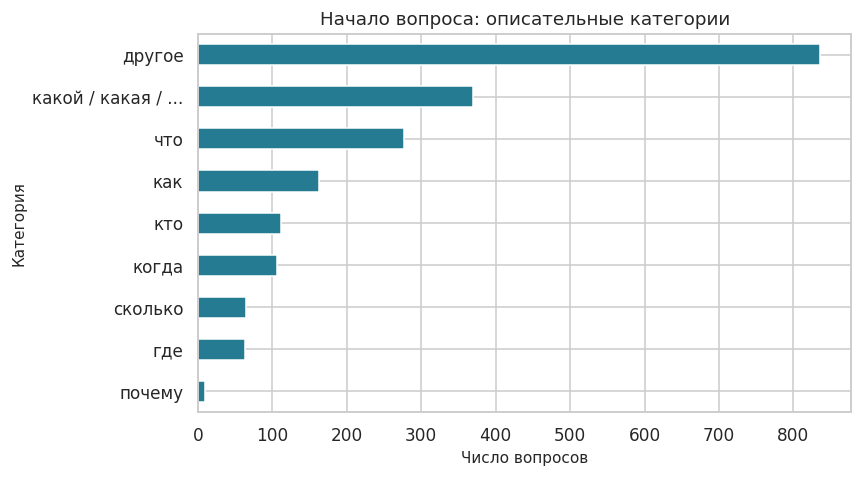

In [30]:
long_questions = df[(df['context_words'] > 150) & (df['question_words'] > 10)]
print('Длинный контекст и длинный вопрос:', len(long_questions))
display(long_questions['question_type'].value_counts())
type_counts = df['question_type'].value_counts()
type_table = pd.DataFrame({
    'Количество': type_counts,
    'Доля, %': (type_counts / len(df) * 100).round(2)
})
display(type_table)
type_counts.sort_values().plot.barh(figsize=(8, 4.5), color='#247b92')
plt.title('Начало вопроса: описательные категории')
plt.xlabel('Число вопросов')
plt.ylabel('Категория')
plt.tight_layout()
plt.show()

### 5. Выбросы по правилу IQR

`IQR = Q3 - Q1`, нижняя граница `Q1 - 1.5 × IQR`, верхняя `Q3 + 1.5 × IQR`.
Правило применяем к каждой числовой характеристике. В основной таблице единица наблюдения - вопрос,
поэтому отдельно считаем границы длины на таблице уникальных контекстов.
Большая длина сама по себе не ошибка. Длинные корректные тексты и ответы сохраняем;
IQR служит поводом для просмотра, а не для автоматического удаления.

In [31]:
outlier_rows = []
for column in numeric_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[column] < lower) | (df[column] > upper)
    outlier_rows.append({
        'Признак': column, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'Нижняя': lower, 'Верхняя': upper,
        'Выбросов': mask.sum(), 'Доля, %': mask.mean() * 100
    })
outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table.round(2))

q1_doc = documents['context_words'].quantile(0.25)
q3_doc = documents['context_words'].quantile(0.75)
iqr_doc = q3_doc - q1_doc
lower_doc = q1_doc - 1.5 * iqr_doc
upper_doc = q3_doc + 1.5 * iqr_doc
doc_outliers = documents[
    (documents['context_words'] < lower_doc) |
    (documents['context_words'] > upper_doc)
]
print(f'Для уникальных контекстов: Q1={q1_doc}, Q3={q3_doc}, IQR={iqr_doc}')
print(f'Границы: [{lower_doc:.1f}; {upper_doc:.1f}] слов')
print('Контекстов за границами:', len(doc_outliers))
display(doc_outliers[['id', 'context_words', 'context']].head(5))
print('Самый длинный контекст:')
print(documents.loc[documents['context_words'].idxmax(), 'context'])

,Признак,Q1,Q3,IQR,Нижняя,Верхняя,Выбросов,"Доля, %"
0,context_chars,581.00,874.50,293.50,140.75,1314.75,52,2.60
1,context_words,77.00,118.00,41.00,15.50,179.50,59,2.95
2,question_chars,44.00,76.00,32.00,-4.00,124.00,93,4.65
3,question_words,6.00,10.00,4.00,0.00,16.00,91,4.55
4,answer_chars,11.00,34.00,23.00,-23.50,68.50,77,3.85
5,answer_words,2.00,5.00,3.00,-2.50,9.50,52,2.60
6,mean_word_length,6.01,6.87,0.86,4.71,8.17,32,1.60


Для уникальных контекстов: Q1=77.0, Q3=118.0, IQR=41.0
Границы: [15.5; 179.5] слов
Контекстов за границами: 53


,id,context_words,context
38,57176,208,Риск и угроза. В сценарном анализе риск отличают от угрозы . Угроза — э...
60,26935,265,"Комплекс различного рода мероприятий, направленных на предупреждение ка..."
102,43277,238,У основателя австрийской экономической школы Карла Менгера учению о тов...
106,2887,186,"В Швеции Карла Линнея обычно называют Carl von Linné — по имени, которо..."
139,82072,294,По мере накопления данных об инфекционных заболеваниях различных органи...


Самый длинный контекст:
В Германии, после Торвальдсена, в числе скульпторов, державшихся его идеалистического направления, особенно достоин внимание Л. Шванталер, для деятельности которого при баварском короле Людвиге I было открыто широкое поле деятельности по украшению Мюнхена (колоссальная статуи Баварии, скульптурные фризы во дворцах короля и герцога Максимилиана, рельефы и статуи, украшающие глиптотеку, и прочее). Этому художнику обязаны своим образованием многие ученики, между прочим, М. Видиман (монумент Шиллеру в Мюнхене и другие), Л. Шаллер (монумент Гердеру в Веймаре, рельефы в Мюнхенской пинакотеке на сюжеты из жизни Я. ван Эйка, А. Дюрера и Гольбейна, аллегорические статуи четырёх звезд и т. д.), Ф. Бругген (статуи Глюка, курфюрста Максимилиана Эммануила и Гертнера в Мюнхене, группы: Хирон учит Ахилла , Меркурий и Калипсо и пр.), К. Цумбуш (монум. Максимилиану II в Мюнхене, лучший из всех украшающих этот город; монумент Марии-Терезии в Вене и прочие) и М. Вагмюллер ( Девушк

### 6. Гистограммы распределений

Первые графики показывают длины контекстов без повторного учёта одинаковых текстов.
Длины вопросов и ответов считаются по всем строкам: каждая строка содержит отдельный вопрос.
Для каждого графика подписана единица измерения. Полный диапазон сохраняется.

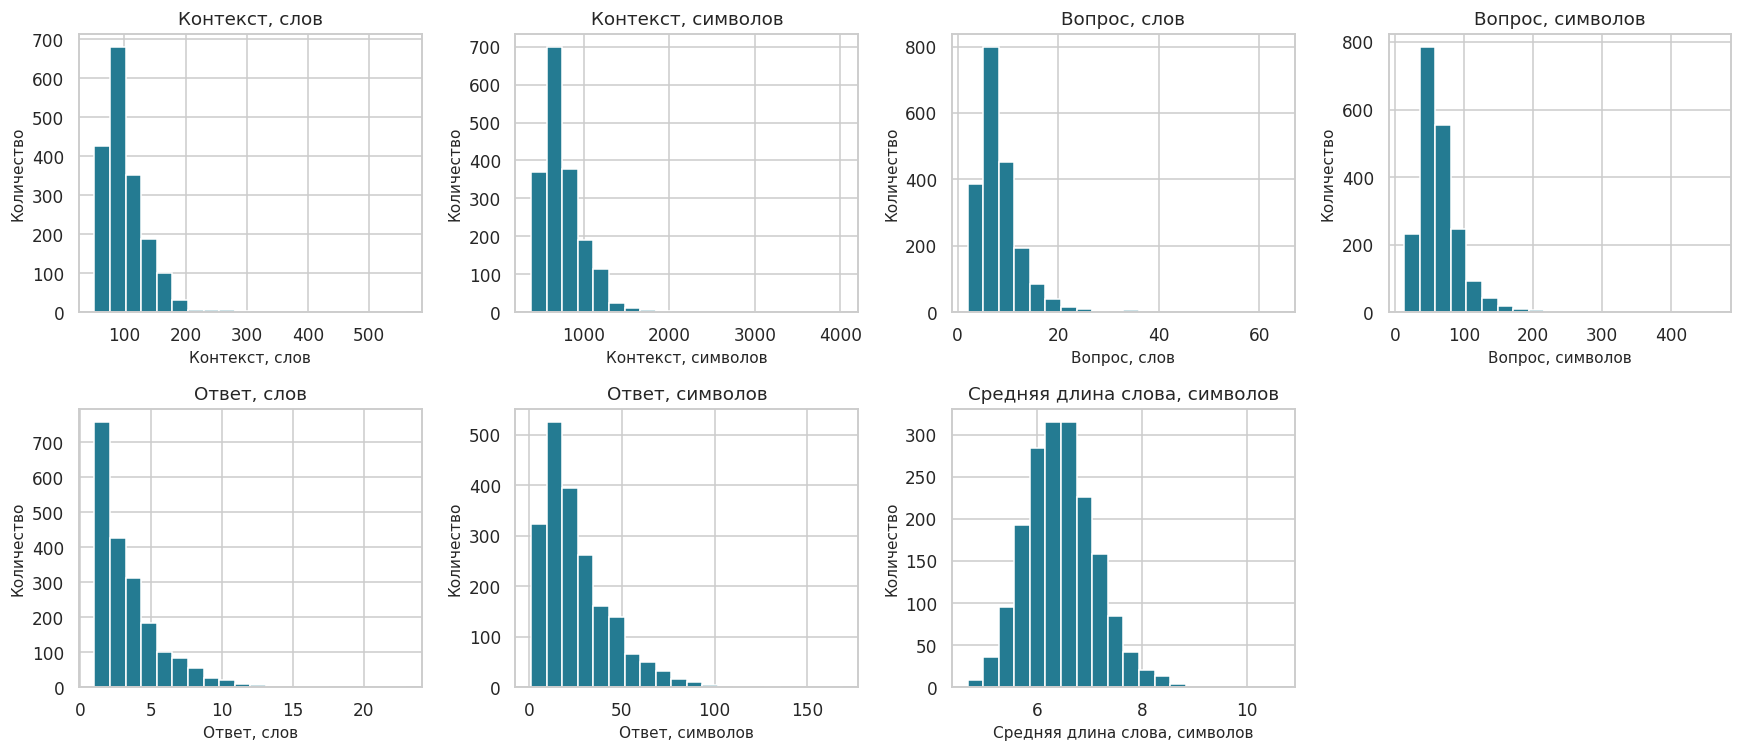

In [32]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
hist_specs = [
    ('context_words', 'Контекст, слов', documents),
    ('context_chars', 'Контекст, символов', documents),
    ('question_words', 'Вопрос, слов', df),
    ('question_chars', 'Вопрос, символов', df),
    ('answer_words', 'Ответ, слов', df),
    ('answer_chars', 'Ответ, символов', df),
    ('mean_word_length', 'Средняя длина слова, символов', documents)
]
for ax, (column, label, table) in zip(axes.flat, hist_specs):
    table[column].hist(bins=20, ax=ax, color='#247b92', edgecolor='white')
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel('Количество')
axes[1, 3].axis('off')
plt.tight_layout()
plt.show()

### 7. Scatter: длина вопроса и ответа

Цвет показывает категорию начала вопроса. Совпадающие координаты накладываются,
поэтому используем прозрачность. Наличие облака точек не означает причинную зависимость.

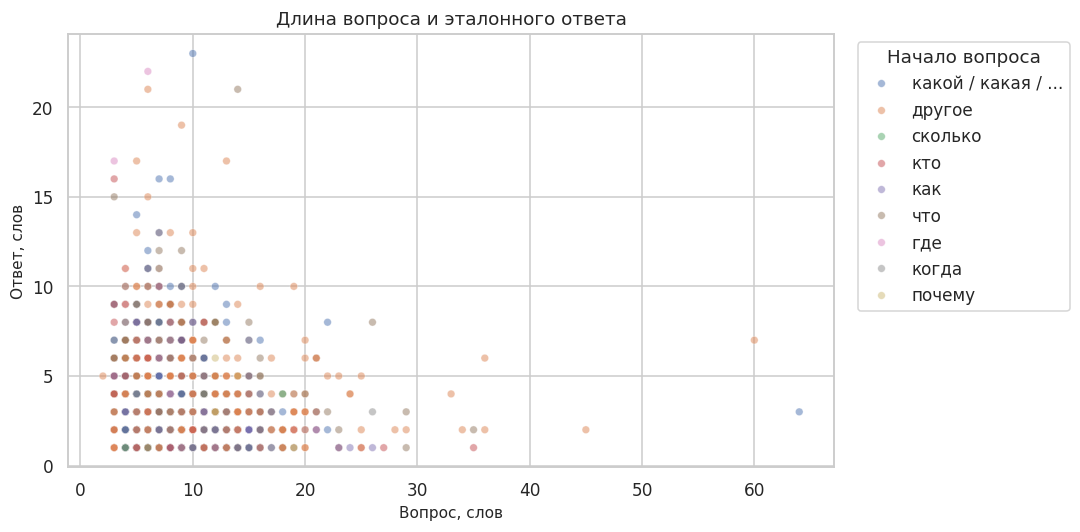

In [33]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='question_words', y='answer_words',
                hue='question_type', alpha=0.5, s=25)
plt.title('Длина вопроса и эталонного ответа')
plt.xlabel('Вопрос, слов')
plt.ylabel('Ответ, слов')
plt.legend(title='Начало вопроса', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 8. Pandas → NumPy

Три признака доступны до получения ответа: длина контекста, длина вопроса, средняя длина слова
в контексте. Целевая переменная учебной регрессии - длина эталонного ответа в словах.
Сам ответ, его длина в символах и позиция в тексте не входят в `X`.

In [34]:
feature_columns = ['context_words', 'question_words', 'mean_word_length']
X_array = df[feature_columns].to_numpy(dtype=float)
y_array = df['answer_words'].to_numpy(dtype=float)
print(X_array.shape, y_array.shape, X_array.dtype)

(2000, 3) (2000,) float64


### 9. Векторизация и нормализация

Учебная проверка broadcasting, как в первом ноутбуке:
`(X - X.mean(0)) / X.std(0)`. `X_norm` нужен только для демонстрации.
Модели ниже используют исходные признаки и отдельный `StandardScaler`, обучаемый на train.

In [35]:
X_norm = (X_array - X_array.mean(0)) / X_array.std(0)
print('Средние:', X_norm.mean(0).round(6))
print('Стандартные отклонения:', X_norm.std(0).round(6))

Средние: [-0. -0. -0.]
Стандартные отклонения: [1. 1. 1.]


### 10. Groupby и выводы по группам

Считаем число примеров, среднюю и медианную длину ответа по категории начала вопроса.
Маленькие группы нельзя считать устойчивой характеристикой всех вопросов такого типа.
Отдельно проверяем, отличается ли длина ответов в строках с проблемными позициями.

,count,mean,median
question_type,,,
почему,10,5.00,5.0
когда,106,3.96,4.0
что,277,3.88,4.0
где,63,3.86,3.0
другое,836,3.74,3.0
какой / какая / ...,370,3.52,3.0
кто,111,2.99,2.0
как,162,2.91,2.0
сколько,65,2.55,2.0


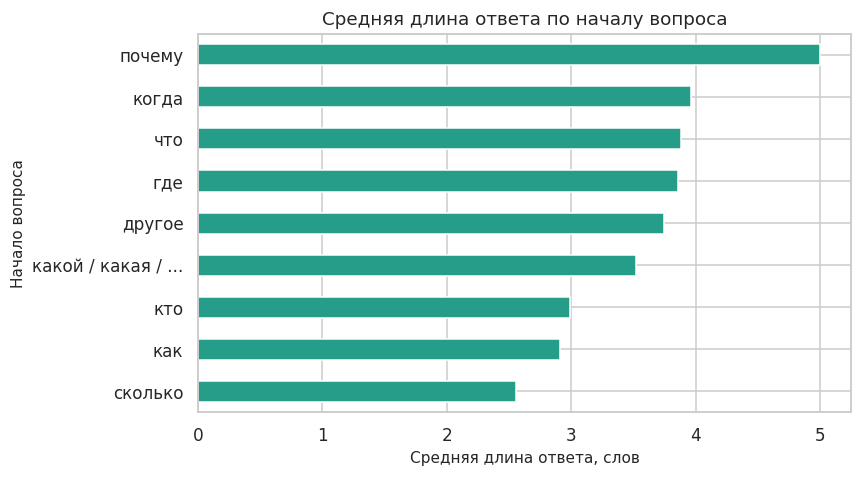

answer_words              question_words             
                   count  mean median          count  mean median
exact_match                                                      
False                461  4.01    3.0            461  8.59    8.0
True                1539  3.47    3.0           1539  8.78    8.0

In [36]:
group_table = df.groupby('question_type')['answer_words'].agg(['count', 'mean', 'median'])
group_table = group_table.sort_values('mean', ascending=False)
display(group_table.round(2))
group_table['mean'].sort_values().plot.barh(figsize=(8, 4.5), color='#259d89')
plt.title('Средняя длина ответа по началу вопроса')
plt.xlabel('Средняя длина ответа, слов')
plt.ylabel('Начало вопроса')
plt.tight_layout()
plt.show()
display(df.groupby('exact_match')[['answer_words', 'question_words']].agg(['count', 'mean', 'median']).round(2))

### 11. Простая статистика слов и предложений

Для этой части берём уникальные контексты: иначе текст с несколькими вопросами
повлияет на частоты несколько раз. Словоформы приводим к нижнему регистру и удаляем
только краевую пунктуацию. Лемматизация не выполняется, поэтому «текст» и «текста» - разные элементы словаря.

Предложения **приближённо** разделяем по точке, `!` и `?`.
Сокращения, инициалы и десятичные дроби дают лишние границы; результат называется
«сегменты по пунктуации» и не выдаётся за точный лингвистический разбор.

In [37]:
words = []
sentence_rows = []
for text in documents['context']:
    for word in text.lower().split():
        word = word.strip(punctuation)
        if len(word) > 0:
            words.append(word)
    for sentence in text.replace('!', '.').replace('?', '.').split('.'):
        sentence = sentence.strip()
        if len(sentence) > 0:
            sentence_rows.append({
                'words': len(sentence.split()), 'chars': len(sentence)
            })

word_series = pd.Series(words)
word_lengths = word_series.str.len()
sentences = pd.DataFrame(sentence_rows)
print('Уникальных контекстов:', len(documents))
print('Всего слов после удаления краевой пунктуации:', len(words))
print('Размер словаря словоформ:', word_series.nunique())
print(f'Средняя длина слова: {word_lengths.mean():.2f} символа')
print(f'Медиана длины слова: {word_lengths.median():.2f} символа')
print('Статистика сегментов по пунктуации:')
display(sentences.describe().round(2).T)

# Небольшой фиксированный список служебных слов; он не исчерпывающий.
stop_words = 'и в во на с со к ко у о об а но что это как по из за для от до не ни или же то так при его ее их он она они мы вы я был была были быть который которая которые также все уже'.split()
content_words = word_series[~word_series.isin(stop_words)]
top_words = content_words.value_counts().head(15)
display(top_words.to_frame('Частота'))

Уникальных контекстов: 1802
Всего слов после удаления краевой пунктуации: 180481
Размер словаря словоформ: 49631
Средняя длина слова: 6.40 символа
Медиана длины слова: 6.00 символа
Статистика сегментов по пунктуации:


,count,mean,std,min,25%,50%,75%,max
words,10876.0,16.87,11.55,1.0,9.0,15.0,22.0,192.0
chars,10876.0,124.38,88.30,1.0,68.0,112.0,165.0,1793.0


,Частота
году,622
года,532
время,363
было,322
более,320
только,310
после,309
является,275
однако,266
её,238


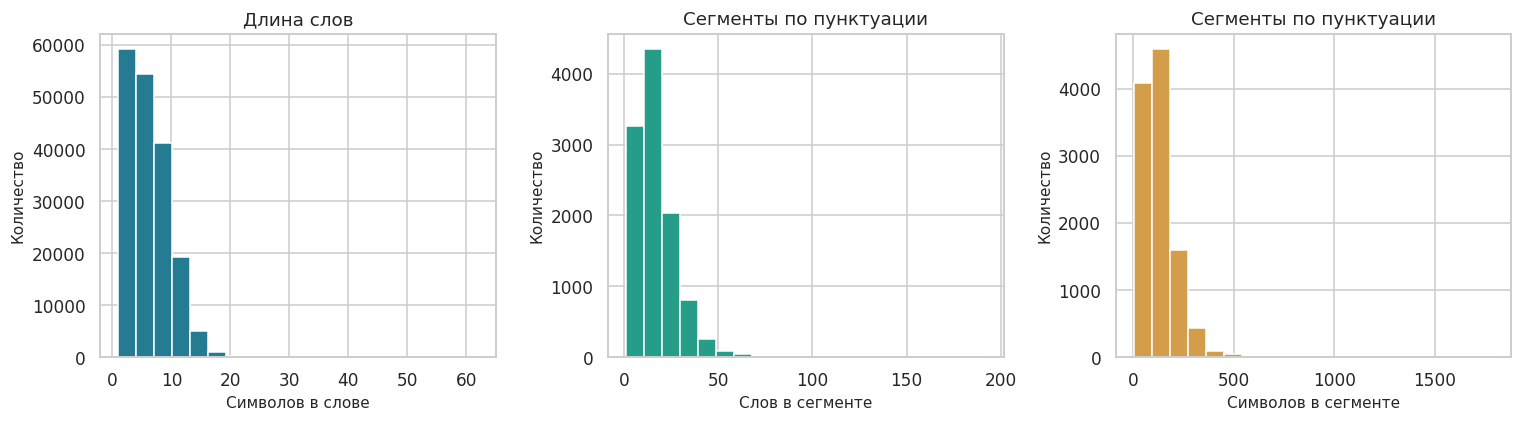

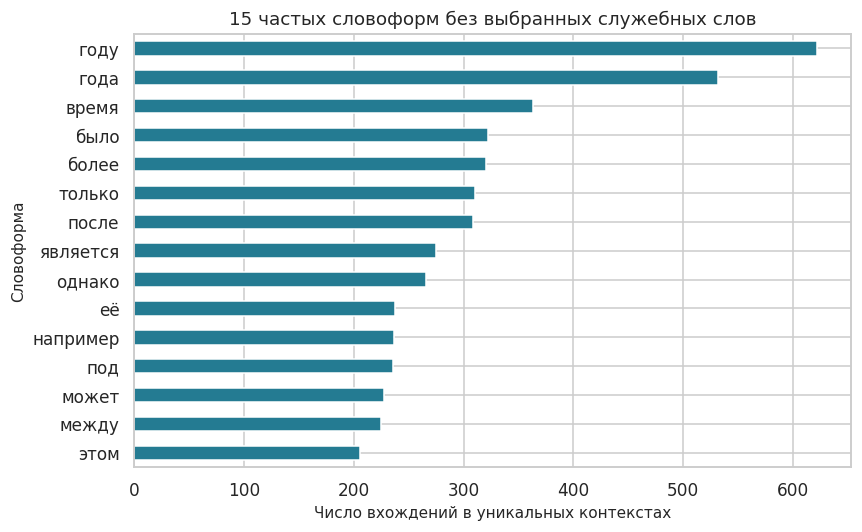

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
word_lengths.hist(bins=20, ax=axes[0], color='#247b92', edgecolor='white')
axes[0].set_title('Длина слов')
axes[0].set_xlabel('Символов в слове')
sentences['words'].hist(bins=20, ax=axes[1], color='#259d89', edgecolor='white')
axes[1].set_title('Сегменты по пунктуации')
axes[1].set_xlabel('Слов в сегменте')
sentences['chars'].hist(bins=20, ax=axes[2], color='#d49d49', edgecolor='white')
axes[2].set_title('Сегменты по пунктуации')
axes[2].set_xlabel('Символов в сегменте')
for ax in axes:
    ax.set_ylabel('Количество')
plt.tight_layout()
plt.show()

top_words.sort_values().plot.barh(figsize=(8, 5), color='#247b92')
plt.title('15 частых словоформ без выбранных служебных слов')
plt.xlabel('Число вхождений в уникальных контекстах')
plt.ylabel('Словоформа')
plt.tight_layout()
plt.show()

### 12. Pairplot и корреляция Пирсона

Сначала исследуем попарные связи трёх выбранных признаков и `answer_words`.
Корреляция Пирсона показывает линейную связь.

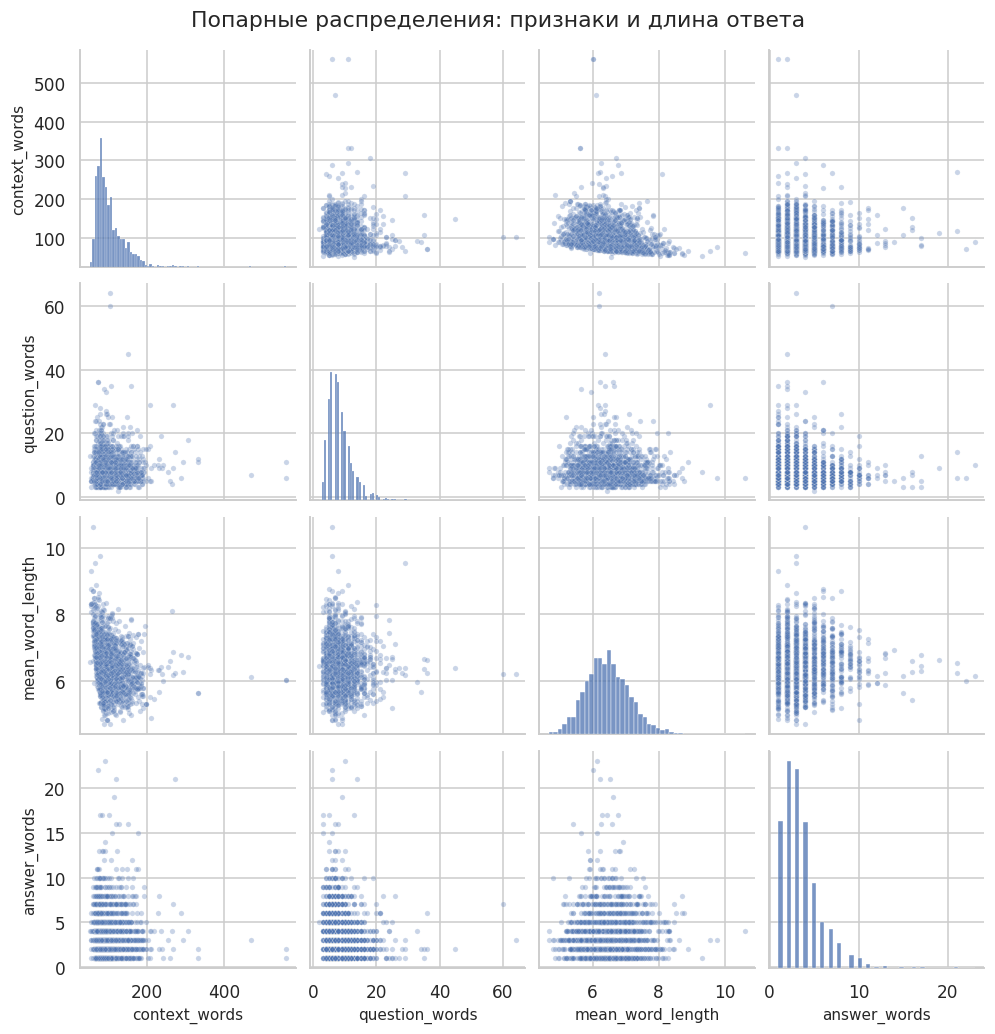

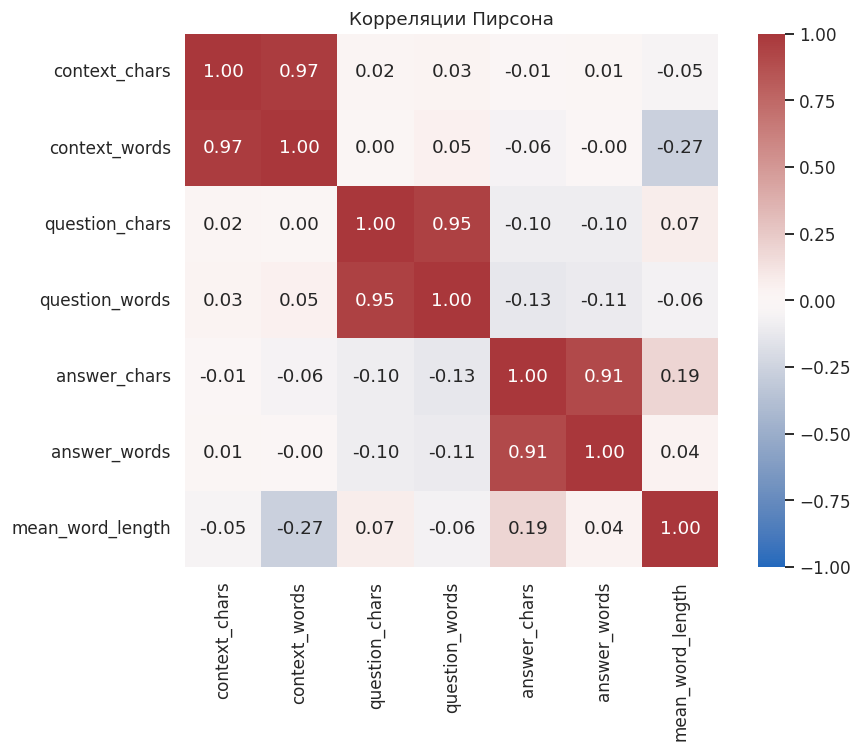

Связь доступных признаков с длиной ответа:


context_words      -0.002
question_words     -0.112
mean_word_length    0.044
Name: answer_words, dtype: float64

In [39]:
pair_columns = feature_columns + ['answer_words']
sns.pairplot(df[pair_columns], height=2.3, diag_kind='hist',
             plot_kws={'alpha': 0.3, 's': 12})
plt.suptitle('Попарные распределения: признаки и длина ответа', y=1.02)
plt.show()

correlations = df[numeric_columns].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='vlag',
            vmin=-1, vmax=1, center=0, square=True)
plt.title('Корреляции Пирсона')
plt.tight_layout()
plt.show()
print('Связь доступных признаков с длиной ответа:')
display(correlations.loc[feature_columns, 'answer_words'].round(3))

### Выводы по основному EDA

**1. Объём и единица наблюдения.** В выборке 2,000 вопросов и 1,802 уникальных
контекста. Повторных вхождений контекста 198; это не дубли вопроса.
Полных дублей, повторных id и повторов тройки «контекст - вопрос - ответ» не обнаружено.
Длины вопросов и ответов считаются по строкам, словарь и частоты слов - по уникальным текстам.
Выборка случайная по вопросам, поэтому тексты с большим числом вопросов имеют больше шансов попасть
в неё. Даже после удаления повторов она не становится равномерной выборкой всех документов источника.

**2. Пропуски и позиции ответа.** В исходных семи полях нет `NaN` и пустых текстов.
Однако 176 значений `answer_start` равны -1 (8.8% строк).
Отрицательная позиция недопустима как индекс начала ответа в принятом формате.
После её замены на `NaN` доля пропусков в этом поле равна 8.8%, а по семи исходным полям в целом
`176 / (2000 × 7) × 100 = 1.26%`.
Средним или нулём позиция не заполнена. Все 176 строк с -1 одновременно не содержат точного
текста ответа: это поддерживает гипотезу, что -1 отмечает невозможность найти буквальное совпадение,
но не доказывает внутренний алгоритм разметки источника.

**3. Неоднородность разметки.** Строгая проверка позиции успешна для 1539 строк
(76.95%); для 461 строки (23.05%) она не проходит.
В 363 случаях точная строка ответа вообще отсутствует в контексте;
ещё в 98 случаях она есть, но не по указанному началу.
После изменения регистра и удаления краевой пунктуации непустой ответ находится во всех 2 000 контекстах.
Это указывает на важность различий оформления и смещений, но не подтверждает смысловую правильность
каждой пары. Сохраняем исходный текст и флаг проверки, а спорные позиции не используем как эталон.
В вопросе id=6495 видны опечатка «Славянска» и повтор «перешла перешла»; автоматическая коррекция
не выполнялась. Полного ручного поиска всех опечаток не проводили.

**4. Поля без полезной вариативности.** Во всех строках `title = SberChallenge`, а `n_answers = 1`.
Первое поле не позволяет определять статью или тематику; второе показывает наличие одного
предоставленного эталона на каждый вопрос, а не единственность возможной правильной формулировки.
Эти поля и идентификаторы не включены в регрессию.

**5. Длины и распределения.** По уникальным контекстам средняя длина равна
101.77 слова, медиана - 91, максимум - 561.
Среднее выше медианы и на гистограмме есть правый хвост: небольшая группа длинных текстов
повышает среднюю длину. В таблице по вопросам среднее немного иное - 102.12 слова,
поскольку повторяющиеся контексты там учитываются несколько раз.
Для контекста по строкам медиана длины в символах - 687, максимум - 4 027.
У вопроса средняя длина 8.74 слова, медиана 8,
максимум 64; в символах медиана 58 и максимум 465. Большинство вопросов короткие, но есть длинные формулировки.
У ответа средняя длина 3.59 слова, медиана 3,
максимум 23; в символах медиана 20 и максимум 169.
Таким образом, текущая QA-выборка ориентирована преимущественно на короткие фактические ответы,
а не на развёрнутые резюме. Для длины слова в контексте медиана среднего по строкам - 6.43 символа;
этот признак меняется заметно меньше, чем общая длина текста.

**6. Выбросы.** Для уникальных контекстов `Q1 = 77`, `Q3 = 118`,
`IQR = 41` слова, границы равны
`[15.5; 179.5]`. За ними находится 53 контекста
(2.94%). На таблице вопросов это 59 строк, что объясняется повторами текстов.
У длины ответа верхняя граница 9.5 слова; за ней 52 ответа (2.6%). Большая длина не делает
текст ошибочным, поэтому наблюдения сохраняем. В последующих испытаниях нужно отдельно
проверять короткие и длинные документы, иначе среднее качество скроет проблемы редких длинных случаев.

**7. Категории вопросов.** «Другое» содержит 836 строк (41.8%): вопросы с предлогами и другими
началами не распознаются примитивным правилом первого слова. Из распознанных категорий
наиболее часты «какой / какая / ...» - 370 (18.5%) и «что» - 277 (13.85%).
Вопросов «почему» всего 10 (0.5%); их средний ответ 5.00 слова нельзя считать надёжным ориентиром
для всех объяснительных вопросов. Для «сколько» средняя длина 2.55 слова (65 примеров),
для «кто» - 2.99 (111 примеров). При ручной проверке будущего сервиса стоит включать разные
формулировки, в том числе редкие, и всегда указывать размер каждой группы.

**8. Слова и предложения.** После удаления краевой пунктуации получено 180,481
словоупотребление и 49,631 разных строк-словоформ, включая числа и иностранные написания.
Средняя длина слова 6.40 символа, медиана 6.
Это среднее по всем словам; оно отличается от среднего по средним значениям контекстов.
У приближённых сегментов по пунктуации средняя длина 16.87 слова
(124.38 символа), медиана 15 слов.
Из-за инициалов и сокращений это только грубая оценка длины предложения.
В частотном списке лидируют «году» (622) и «года» (532); это совместимо с частыми упоминаниями
дат, но само по себе не доказывает тематику корпуса. Короткий список стоп-слов оставляет часть
общих слов, а разные формы одного слова учитываются раздельно. Тематической классификации здесь нет.

**9. Связи между признаками.** Корреляция длины ответа с длиной контекста равна
-0.002, с длиной вопроса -0.112,
со средней длиной слова 0.044. Сильной линейной связи нет.
В scatter и pairplot виден большой разброс ответов при одинаковых длинах входного текста.
Корреляции длин в словах и символах высоки: примерно 0.97 для контекстов, 0.95 для вопросов
и 0.91 для ответов. Это ожидаемая связь двух измерений размера одного текста.
`answer_chars` не используется для прогноза `answer_words`: это информация о самом ответе,
которая недоступна до его получения.
